In [ ]:
# ============================================================
# CELL 1: MOUNT GOOGLE DRIVE
# ============================================================

from pathlib import Path
from google.colab import drive

if Path("/content/drive/MyDrive").exists():
    print("Google Drive is already mounted:")
    print("/content/drive/MyDrive")
else:
    drive.mount("/content/drive")

print("\nChecking required project folders:")

paths_to_check = [
    Path("/content/drive/MyDrive/RARE26"),
    Path("/content/drive/MyDrive/RARE26_GastroNet_Weights"),
    Path(
        "/content/drive/MyDrive/RARE26/"
        "dataset/RARE25-train-data.zip"
    ),
]

for path in paths_to_check:
    print(f"{path}: {path.exists()}")

Mounted at /content/drive

Checking required project folders:
/content/drive/MyDrive/RARE26: True
/content/drive/MyDrive/RARE26_GastroNet_Weights: True
/content/drive/MyDrive/RARE26/dataset/RARE25-train-data.zip: True


In [ ]:
# ============================================================
# RARE26 GastroNet Extension — Cell 3B
# Restore exactly 3,088 locked images from the original ZIP
# Verify paths, readability, hashes, counts and split isolation
# ============================================================

from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
from IPython.display import display

import hashlib
import json
import shutil
import zipfile

import pandas as pd
from PIL import Image
from tqdm.auto import tqdm


# ------------------------------------------------------------
# 1. Canonical paths
# ------------------------------------------------------------

RARE26_ROOT = Path(
    "/content/drive/MyDrive/RARE26"
)

GASTRONET_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

ARCHIVE_PATH = (
    RARE26_ROOT
    / "dataset"
    / "RARE25-train-data.zip"
)

SPLIT_DIR = (
    RARE26_ROOT
    / "splits"
)

SPLIT_PATHS = {
    "train": (
        SPLIT_DIR
        / "train_colab.csv"
    ),

    "validation": (
        SPLIT_DIR
        / "validation_colab.csv"
    ),

    "test": (
        SPLIT_DIR
        / "test_colab.csv"
    ),
}

# Temporary Colab storage.
# Ye Drive par duplicate dataset create nahi karta.
RUNTIME_ROOT = Path(
    "/content/RARE26_data"
)

INVENTORY_DIR = (
    GASTRONET_ROOT
    / "inventory"
)

RESULTS_DIR = (
    GASTRONET_ROOT
    / "results"
)

CONFIG_DIR = (
    GASTRONET_ROOT
    / "configs"
)

RUNTIME_SPLIT_DIR = (
    CONFIG_DIR
    / "runtime_splits"
)

for directory in [
    INVENTORY_DIR,
    RESULTS_DIR,
    CONFIG_DIR,
    RUNTIME_SPLIT_DIR,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ------------------------------------------------------------
# 2. Required file checks
# ------------------------------------------------------------

print("=" * 80)
print("CELL 3B: RESTORE AND VERIFY LOCKED RARE26 DATASET")
print("=" * 80)

print("\nRARE26 root:")
print(RARE26_ROOT)

print("\nDataset ZIP:")
print(ARCHIVE_PATH)

print("\nTemporary runtime folder:")
print(RUNTIME_ROOT)

if not RARE26_ROOT.exists():

    raise FileNotFoundError(
        "RARE26 project folder nahi mili:\n"
        f"{RARE26_ROOT}\n\n"
        "Confirm karo ke correct Google account mounted hai."
    )

if not GASTRONET_ROOT.exists():

    raise FileNotFoundError(
        "GastroNet project folder nahi mili:\n"
        f"{GASTRONET_ROOT}"
    )

if not ARCHIVE_PATH.exists():

    raise FileNotFoundError(
        "Original dataset ZIP nahi mili:\n"
        f"{ARCHIVE_PATH}"
    )

for split_name, split_path in (
    SPLIT_PATHS.items()
):

    if not split_path.exists():

        raise FileNotFoundError(
            f"{split_name} split CSV nahi mili:\n"
            f"{split_path}"
        )

print("\nAll required source files found: True")


# ------------------------------------------------------------
# 3. Load locked split CSV files
# ------------------------------------------------------------

split_frames = []

for split_name, split_path in (
    SPLIT_PATHS.items()
):

    dataframe = pd.read_csv(
        split_path,
        low_memory=False,
    ).copy()

    dataframe[
        "runtime_split"
    ] = split_name

    if (
        "relative_path"
        not in dataframe.columns
    ):

        raise RuntimeError(
            "'relative_path' column missing hai:\n"
            f"{split_path}"
        )

    required_columns = {
        "relative_path",
        "label",
        "center",
        "class",
        "sha256",
        "colab_path",
    }

    missing_columns = (
        required_columns
        - set(dataframe.columns)
    )

    if missing_columns:

        raise RuntimeError(
            f"{split_name} split mein columns missing hain:\n"
            f"{sorted(missing_columns)}"
        )

    dataframe[
        "label"
    ] = dataframe[
        "label"
    ].astype(int)

    dataframe[
        "normalized_relative_path"
    ] = (
        dataframe[
            "relative_path"
        ]
        .astype(str)
        .str.replace(
            "\\",
            "/",
            regex=False,
        )
        .str.lstrip("./")
    )

    split_frames.append(
        dataframe
    )


all_records = pd.concat(
    split_frames,
    ignore_index=True,
)


print("\nLocked split counts:")

print(
    all_records[
        "runtime_split"
    ]
    .value_counts()
    .reindex(
        [
            "train",
            "validation",
            "test",
        ]
    )
)


# ------------------------------------------------------------
# 4. Verify fixed split counts
# ------------------------------------------------------------

expected_counts = {
    "train": {
        "total": 2159,
        "normal": 2050,
        "positive": 109,
    },

    "validation": {
        "total": 461,
        "normal": 438,
        "positive": 23,
    },

    "test": {
        "total": 468,
        "normal": 442,
        "positive": 26,
    },
}

metadata_summary_rows = []

for split_name in [
    "train",
    "validation",
    "test",
]:

    subset = all_records[
        all_records[
            "runtime_split"
        ]
        == split_name
    ]

    actual_total = int(
        len(subset)
    )

    actual_normal = int(
        (
            subset[
                "label"
            ]
            == 0
        ).sum()
    )

    actual_positive = int(
        (
            subset[
                "label"
            ]
            == 1
        ).sum()
    )

    expected = expected_counts[
        split_name
    ]

    count_match = bool(
        actual_total
        == expected["total"]

        and actual_normal
        == expected["normal"]

        and actual_positive
        == expected["positive"]
    )

    metadata_summary_rows.append(
        {
            "split": split_name,

            "expected_total": (
                expected["total"]
            ),

            "actual_total": (
                actual_total
            ),

            "expected_normal": (
                expected["normal"]
            ),

            "actual_normal": (
                actual_normal
            ),

            "expected_positive": (
                expected["positive"]
            ),

            "actual_positive": (
                actual_positive
            ),

            "count_match": (
                count_match
            ),
        }
    )


metadata_summary_df = pd.DataFrame(
    metadata_summary_rows
)


duplicate_relative_paths = (
    all_records
    .groupby(
        "normalized_relative_path"
    )
    .size()
    .reset_index(
        name="count"
    )
)

duplicate_relative_paths = (
    duplicate_relative_paths[
        duplicate_relative_paths[
            "count"
        ]
        > 1
    ]
    .copy()
)


unique_relative_paths = (
    all_records[
        "normalized_relative_path"
    ]
    .drop_duplicates()
    .tolist()
)


print(
    f"\nLocked records: "
    f"{len(all_records)}"
)

print(
    f"Unique image paths: "
    f"{len(unique_relative_paths)}"
)

print(
    "Duplicate paths across splits: "
    f"{len(duplicate_relative_paths)}"
)


if not metadata_summary_df[
    "count_match"
].all():

    display(
        metadata_summary_df
    )

    raise RuntimeError(
        "Locked split counts completed Phase 1/Phase 2 "
        "record se match nahi karte."
    )


if len(all_records) != 3088:

    raise RuntimeError(
        "Expected exactly 3,088 locked records, "
        f"but found {len(all_records)}."
    )


if len(unique_relative_paths) != 3088:

    raise RuntimeError(
        "Locked split CSV files mein exactly "
        "3,088 unique image paths nahi hain."
    )


if len(
    duplicate_relative_paths
) > 0:

    raise RuntimeError(
        "Koi image path ek se zyada split mein maujood hai."
    )

print("\nLocked split counts verified: True")


# ------------------------------------------------------------
# 5. Verify centre/class metadata from paths
# ------------------------------------------------------------

def path_metadata(
    relative_path,
):

    parts = PurePosixPath(
        relative_path
    ).parts

    if len(parts) < 3:

        return (
            None,
            None,
        )

    return (
        parts[-3],
        parts[-2],
    )


path_centres = []
path_classes = []

for relative_path in all_records[
    "normalized_relative_path"
]:

    (
        path_centre,
        path_class,
    ) = path_metadata(
        relative_path
    )

    path_centres.append(
        path_centre
    )

    path_classes.append(
        path_class
    )


all_records[
    "path_centre"
] = path_centres

all_records[
    "path_class"
] = path_classes


all_records[
    "centre_path_match"
] = (
    all_records[
        "center"
    ]
    .astype(str)
    .str.lower()
    ==
    all_records[
        "path_centre"
    ]
    .astype(str)
    .str.lower()
)


all_records[
    "class_path_match"
] = (
    all_records[
        "class"
    ]
    .astype(str)
    .str.lower()
    ==
    all_records[
        "path_class"
    ]
    .astype(str)
    .str.lower()
)


centre_mismatch_count = int(
    (
        ~all_records[
            "centre_path_match"
        ]
    ).sum()
)

class_mismatch_count = int(
    (
        ~all_records[
            "class_path_match"
        ]
    ).sum()
)


print(
    f"\nCentre/path mismatches: "
    f"{centre_mismatch_count}"
)

print(
    f"Class/path mismatches: "
    f"{class_mismatch_count}"
)


if (
    centre_mismatch_count > 0
    or class_mismatch_count > 0
):

    raise RuntimeError(
        "CSV centre/class metadata image paths se match nahi karta."
    )


# ------------------------------------------------------------
# 6. Inspect ZIP and map locked paths
# ------------------------------------------------------------

def normalize_archive_name(
    name,
):

    return (
        str(name)
        .replace(
            "\\",
            "/",
        )
        .lstrip("./")
    )


def last_three_components(
    path_text,
):

    parts = PurePosixPath(
        path_text
    ).parts

    if len(parts) < 3:

        return None

    return "/".join(
        parts[-3:]
    )


zip_mapping_rows = []

resolved_member_map = {}

missing_archive_paths = []

ambiguous_archive_paths = []


print("\nReading dataset ZIP inventory...")


with zipfile.ZipFile(
    ARCHIVE_PATH,
    "r",
) as zip_file:

    file_members = [
        member

        for member
        in zip_file.infolist()

        if not member.is_dir()
    ]

    suffix_index = {}

    for member in file_members:

        normalized_member = (
            normalize_archive_name(
                member.filename
            )
        )

        suffix_key = (
            last_three_components(
                normalized_member
            )
        )

        if suffix_key is None:

            continue

        suffix_index.setdefault(
            suffix_key,
            [],
        ).append(
            member
        )


    print(
        f"Files inside ZIP: "
        f"{len(file_members)}"
    )


    for relative_path in (
        unique_relative_paths
    ):

        key = (
            last_three_components(
                relative_path
            )
        )

        matches = (
            suffix_index.get(
                key,
                [],
            )
        )

        if len(matches) == 1:

            resolved_member_map[
                relative_path
            ] = matches[0]

            zip_mapping_rows.append(
                {
                    "relative_path": (
                        relative_path
                    ),

                    "archive_member": (
                        matches[0].filename
                    ),

                    "archive_size_bytes": (
                        matches[0].file_size
                    ),

                    "mapping_status": (
                        "unique_match"
                    ),
                }
            )

        elif len(matches) == 0:

            missing_archive_paths.append(
                relative_path
            )

            zip_mapping_rows.append(
                {
                    "relative_path": (
                        relative_path
                    ),

                    "archive_member": None,

                    "archive_size_bytes": None,

                    "mapping_status": (
                        "missing"
                    ),
                }
            )

        else:

            ambiguous_archive_paths.append(
                {
                    "relative_path": (
                        relative_path
                    ),

                    "candidate_members": [
                        member.filename

                        for member
                        in matches
                    ],
                }
            )

            zip_mapping_rows.append(
                {
                    "relative_path": (
                        relative_path
                    ),

                    "archive_member": (
                        " | ".join(
                            member.filename

                            for member
                            in matches
                        )
                    ),

                    "archive_size_bytes": None,

                    "mapping_status": (
                        "ambiguous"
                    ),
                }
            )


zip_mapping_df = pd.DataFrame(
    zip_mapping_rows
)


print(
    f"\nUnique ZIP mappings: "
    f"{len(resolved_member_map)}/3088"
)

print(
    f"Missing paths in ZIP: "
    f"{len(missing_archive_paths)}"
)

print(
    f"Ambiguous ZIP mappings: "
    f"{len(ambiguous_archive_paths)}"
)


zip_mapping_path = (
    INVENTORY_DIR
    / "cell3b_zip_to_locked_split_mapping.csv"
)

zip_mapping_df.to_csv(
    zip_mapping_path,
    index=False,
)


if (
    missing_archive_paths
    or ambiguous_archive_paths
):

    issue_path = (
        INVENTORY_DIR
        / "cell3b_zip_mapping_issues.json"
    )

    issue_record = {
        "missing_archive_paths": (
            missing_archive_paths
        ),

        "ambiguous_archive_paths": (
            ambiguous_archive_paths
        ),
    }

    issue_path.write_text(
        json.dumps(
            issue_record,
            indent=2,
            ensure_ascii=False,
        ),
        encoding="utf-8",
    )

    raise RuntimeError(
        "ZIP ko all 3,088 locked image paths se "
        "uniquely map nahi kiya ja saka."
    )


# ------------------------------------------------------------
# 7. Restore exactly 3,088 images
# ------------------------------------------------------------

RUNTIME_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

extracted_count = 0

reused_count = 0

invalid_replaced_count = 0


print(
    "\nRestoring 3,088 images to temporary Colab storage..."
)


with zipfile.ZipFile(
    ARCHIVE_PATH,
    "r",
) as zip_file:

    for relative_path in tqdm(
        unique_relative_paths,
        total=len(
            unique_relative_paths
        ),
        desc="Restoring images",
    ):

        member = (
            resolved_member_map[
                relative_path
            ]
        )

        target_path = (
            RUNTIME_ROOT
            / Path(
                relative_path
            )
        )

        target_path.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        reuse_existing_file = False

        if (
            target_path.exists()
            and target_path.is_file()
            and target_path.stat().st_size
            == member.file_size
        ):

            try:

                with Image.open(
                    target_path
                ) as image:

                    image.verify()

                reuse_existing_file = True

            except Exception:

                reuse_existing_file = False

                invalid_replaced_count += 1


        if reuse_existing_file:

            reused_count += 1

            continue


        with zip_file.open(
            member,
            "r",
        ) as source_file:

            with target_path.open(
                "wb"
            ) as target_file:

                shutil.copyfileobj(
                    source_file,
                    target_file,
                    length=(
                        8
                        * 1024
                        * 1024
                    ),
                )


        extracted_count += 1


print(
    f"\nNewly extracted: "
    f"{extracted_count}"
)

print(
    f"Existing verified images reused: "
    f"{reused_count}"
)

print(
    f"Invalid images replaced: "
    f"{invalid_replaced_count}"
)


# ------------------------------------------------------------
# 8. SHA-256 function
# ------------------------------------------------------------

def calculate_sha256(
    file_path,
    chunk_size=(
        8
        * 1024
        * 1024
    ),
):

    digest = hashlib.sha256()

    with file_path.open(
        "rb"
    ) as file_handle:

        while True:

            chunk = file_handle.read(
                chunk_size
            )

            if not chunk:

                break

            digest.update(
                chunk
            )

    return digest.hexdigest()


# ------------------------------------------------------------
# 9. Verify readability, paths and hashes
# ------------------------------------------------------------

audit_rows = []


print(
    "\nVerifying readability and SHA-256..."
)


for _, row in tqdm(
    all_records.iterrows(),
    total=len(
        all_records
    ),
    desc="Verifying images",
):

    relative_path = row[
        "normalized_relative_path"
    ]

    runtime_path = (
        RUNTIME_ROOT
        / Path(
            relative_path
        )
    )

    file_exists = bool(
        runtime_path.exists()
        and runtime_path.is_file()
    )

    image_readable = False

    image_mode = None

    image_width = None

    image_height = None

    actual_sha256 = None

    expected_sha256 = (
        str(
            row["sha256"]
        )
        .strip()
        .lower()
    )


    if file_exists:

        try:

            with Image.open(
                runtime_path
            ) as image:

                image.verify()


            with Image.open(
                runtime_path
            ) as image:

                image_mode = (
                    image.mode
                )

                image_width = (
                    image.width
                )

                image_height = (
                    image.height
                )


            image_readable = True

        except Exception:

            image_readable = False


        if image_readable:

            actual_sha256 = (
                calculate_sha256(
                    runtime_path
                )
            )


    sha256_match = bool(
        actual_sha256
        == expected_sha256

        if actual_sha256
        is not None

        else False
    )


    expected_colab_path = str(
        RUNTIME_ROOT
        / Path(
            relative_path
        )
    )


    csv_colab_path_match = bool(
        str(
            row[
                "colab_path"
            ]
        )
        == expected_colab_path
    )


    audit_rows.append(
        {
            "split": (
                row[
                    "runtime_split"
                ]
            ),

            "relative_path": (
                relative_path
            ),

            "runtime_path": str(
                runtime_path
            ),

            "file_exists": (
                file_exists
            ),

            "image_readable": (
                image_readable
            ),

            "image_mode": (
                image_mode
            ),

            "image_width": (
                image_width
            ),

            "image_height": (
                image_height
            ),

            "expected_sha256": (
                expected_sha256
            ),

            "actual_sha256": (
                actual_sha256
            ),

            "sha256_match": (
                sha256_match
            ),

            "label": int(
                row[
                    "label"
                ]
            ),

            "center": (
                row[
                    "center"
                ]
            ),

            "class": (
                row[
                    "class"
                ]
            ),

            "csv_colab_path": (
                row[
                    "colab_path"
                ]
            ),

            "csv_colab_path_match": (
                csv_colab_path_match
            ),
        }
    )


audit_df = pd.DataFrame(
    audit_rows
)


# ------------------------------------------------------------
# 10. Final split summaries
# ------------------------------------------------------------

summary_rows = []

for split_name in [
    "train",
    "validation",
    "test",
]:

    subset = audit_df[
        audit_df[
            "split"
        ]
        == split_name
    ]

    expected = expected_counts[
        split_name
    ]

    actual_total = int(
        len(subset)
    )

    actual_normal = int(
        (
            subset[
                "label"
            ]
            == 0
        ).sum()
    )

    actual_positive = int(
        (
            subset[
                "label"
            ]
            == 1
        ).sum()
    )

    summary_rows.append(
        {
            "split": (
                split_name
            ),

            "expected_total": (
                expected[
                    "total"
                ]
            ),

            "actual_total": (
                actual_total
            ),

            "normal_count": (
                actual_normal
            ),

            "positive_count": (
                actual_positive
            ),

            "files_resolved": int(
                subset[
                    "file_exists"
                ].sum()
            ),

            "files_readable": int(
                subset[
                    "image_readable"
                ].sum()
            ),

            "hashes_matching": int(
                subset[
                    "sha256_match"
                ].sum()
            ),

            "all_files_resolved": bool(
                subset[
                    "file_exists"
                ].all()
            ),

            "all_files_readable": bool(
                subset[
                    "image_readable"
                ].all()
            ),

            "all_hashes_match": bool(
                subset[
                    "sha256_match"
                ].all()
            ),

            "all_colab_paths_match": bool(
                subset[
                    "csv_colab_path_match"
                ].all()
            ),

            "count_match": bool(
                actual_total
                == expected[
                    "total"
                ]

                and actual_normal
                == expected[
                    "normal"
                ]

                and actual_positive
                == expected[
                    "positive"
                ]
            ),
        }
    )


summary_df = pd.DataFrame(
    summary_rows
)


centre_summary_df = (
    audit_df
    .groupby(
        [
            "split",
            "center",
            "label",
        ],
        dropna=False,
    )
    .size()
    .reset_index(
        name="count"
    )
)


hash_mismatch_df = audit_df[
    ~audit_df[
        "sha256_match"
    ]
].copy()


unreadable_df = audit_df[
    ~audit_df[
        "image_readable"
    ]
].copy()


missing_runtime_df = audit_df[
    ~audit_df[
        "file_exists"
    ]
].copy()


# ------------------------------------------------------------
# 11. Save canonical verification records
# ------------------------------------------------------------

canonical_audit_path = (
    INVENTORY_DIR
    / "cell3_locked_dataset_row_audit.csv"
)

canonical_summary_path = (
    RESULTS_DIR
    / "cell3_locked_split_summary.csv"
)

canonical_centre_path = (
    RESULTS_DIR
    / "cell3_locked_split_centre_summary.csv"
)

verification_json_path = (
    RESULTS_DIR
    / "cell3_locked_dataset_verification.json"
)

hash_mismatch_path = (
    INVENTORY_DIR
    / "cell3b_sha256_mismatches.csv"
)

unreadable_path = (
    INVENTORY_DIR
    / "cell3b_unreadable_images.csv"
)

missing_runtime_path = (
    INVENTORY_DIR
    / "cell3b_missing_runtime_images.csv"
)


audit_df.to_csv(
    canonical_audit_path,
    index=False,
)

summary_df.to_csv(
    canonical_summary_path,
    index=False,
)

centre_summary_df.to_csv(
    canonical_centre_path,
    index=False,
)

hash_mismatch_df.to_csv(
    hash_mismatch_path,
    index=False,
)

unreadable_df.to_csv(
    unreadable_path,
    index=False,
)

missing_runtime_df.to_csv(
    missing_runtime_path,
    index=False,
)


# ------------------------------------------------------------
# 12. Save verified runtime split CSV files
# ------------------------------------------------------------

runtime_split_output_paths = {}


for split_name, split_path in (
    SPLIT_PATHS.items()
):

    runtime_split_df = pd.read_csv(
        split_path,
        low_memory=False,
    ).copy()

    runtime_split_df[
        "relative_path"
    ] = (
        runtime_split_df[
            "relative_path"
        ]
        .astype(str)
        .str.replace(
            "\\",
            "/",
            regex=False,
        )
        .str.lstrip("./")
    )


    runtime_split_df[
        "runtime_path"
    ] = (
        runtime_split_df[
            "relative_path"
        ]
        .apply(
            lambda value: str(
                RUNTIME_ROOT
                / Path(
                    value
                )
            )
        )
    )


    runtime_split_df[
        "runtime_file_exists"
    ] = (
        runtime_split_df[
            "runtime_path"
        ]
        .apply(
            lambda value: (
                Path(
                    value
                ).exists()
            )
        )
    )


    runtime_split_output = (
        RUNTIME_SPLIT_DIR
        / (
            f"{split_name}"
            "_runtime_verified.csv"
        )
    )


    runtime_split_df.to_csv(
        runtime_split_output,
        index=False,
    )


    runtime_split_output_paths[
        split_name
    ] = runtime_split_output


# ------------------------------------------------------------
# 13. Determine final status
# ------------------------------------------------------------

all_checks_passed = bool(
    len(audit_df) == 3088

    and summary_df[
        "count_match"
    ].all()

    and summary_df[
        "all_files_resolved"
    ].all()

    and summary_df[
        "all_files_readable"
    ].all()

    and summary_df[
        "all_hashes_match"
    ].all()

    and summary_df[
        "all_colab_paths_match"
    ].all()

    and len(
        hash_mismatch_df
    ) == 0

    and len(
        unreadable_df
    ) == 0

    and len(
        missing_runtime_df
    ) == 0

    and len(
        duplicate_relative_paths
    ) == 0

    and centre_mismatch_count == 0

    and class_mismatch_count == 0
)


if all_checks_passed:

    final_status = (
        "LOCKED_DATASET_AND_SPLITS_VERIFIED"
    )

else:

    final_status = (
        "DATASET_OR_SPLIT_VERIFICATION_NEEDS_REVIEW"
    )


verification_record = {
    "created_utc": (
        datetime.now(
            timezone.utc
        ).isoformat()
    ),

    "archive_path": str(
        ARCHIVE_PATH
    ),

    "archive_size_bytes": int(
        ARCHIVE_PATH.stat().st_size
    ),

    "runtime_root": str(
        RUNTIME_ROOT
    ),

    "locked_record_count": int(
        len(audit_df)
    ),

    "unique_relative_path_count": int(
        len(
            unique_relative_paths
        )
    ),

    "archive_file_count": int(
        len(file_members)
    ),

    "archive_unique_locked_matches": int(
        len(
            resolved_member_map
        )
    ),

    "newly_extracted_count": int(
        extracted_count
    ),

    "reused_temporary_file_count": int(
        reused_count
    ),

    "resolved_file_count": int(
        audit_df[
            "file_exists"
        ].sum()
    ),

    "readable_file_count": int(
        audit_df[
            "image_readable"
        ].sum()
    ),

    "sha256_match_count": int(
        audit_df[
            "sha256_match"
        ].sum()
    ),

    "csv_colab_path_match_count": int(
        audit_df[
            "csv_colab_path_match"
        ].sum()
    ),

    "centre_path_mismatch_count": int(
        centre_mismatch_count
    ),

    "class_path_mismatch_count": int(
        class_mismatch_count
    ),

    "cross_split_duplicate_path_count": int(
        len(
            duplicate_relative_paths
        )
    ),

    "runtime_split_paths": {
        split_name: str(
            split_path
        )

        for split_name, split_path
        in runtime_split_output_paths.items()
    },

    "held_out_test_loaded": False,

    "held_out_test_evaluated": False,

    "model_training_performed": False,

    "model_inference_performed": False,

    "final_status": (
        final_status
    ),
}


verification_json_path.write_text(
    json.dumps(
        verification_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ------------------------------------------------------------
# 14. Final display
# ------------------------------------------------------------

print("\nVerified split summary:")

display(
    summary_df
)


print("\nPer-centre summary:")

display(
    centre_summary_df
)


print("\n" + "=" * 80)

print(
    "FINAL CELL 3B RESTORATION REPORT"
)

print("=" * 80)


print(
    f"Locked records: "
    f"{len(audit_df)}/3088"
)

print(
    f"Unique paths: "
    f"{len(unique_relative_paths)}/3088"
)

print(
    f"ZIP mappings: "
    f"{len(resolved_member_map)}/3088"
)

print(
    f"Runtime image files: "
    f"{int(audit_df['file_exists'].sum())}/3088"
)

print(
    f"Readable images: "
    f"{int(audit_df['image_readable'].sum())}/3088"
)

print(
    f"SHA-256 matches: "
    f"{int(audit_df['sha256_match'].sum())}/3088"
)

print(
    f"Missing images: "
    f"{len(missing_runtime_df)}"
)

print(
    f"Unreadable images: "
    f"{len(unreadable_df)}"
)

print(
    f"Hash mismatches: "
    f"{len(hash_mismatch_df)}"
)

print(
    f"Duplicate split paths: "
    f"{len(duplicate_relative_paths)}"
)


print("\nRuntime split files:")

for split_name in [
    "train",
    "validation",
    "test",
]:

    print(
        f"{split_name}: "
        f"{runtime_split_output_paths[split_name]}"
    )


print("\nModel training performed: False")

print(
    "Model inference performed: False"
)

print(
    "Held-out test evaluated: False"
)


print(
    f"\nSTATUS: "
    f"{final_status}"
)

CELL 3B: RESTORE AND VERIFY LOCKED RARE26 DATASET

RARE26 root:
/content/drive/MyDrive/RARE26

Dataset ZIP:
/content/drive/MyDrive/RARE26/dataset/RARE25-train-data.zip

Temporary runtime folder:
/content/RARE26_data

All required source files found: True

Locked split counts:
runtime_split
train         2159
validation     461
test           468
Name: count, dtype: int64

Locked records: 3088
Unique image paths: 3088
Duplicate paths across splits: 0

Locked split counts verified: True

Centre/path mismatches: 0
Class/path mismatches: 0

Reading dataset ZIP inventory...
Files inside ZIP: 3095

Unique ZIP mappings: 3088/3088
Missing paths in ZIP: 0
Ambiguous ZIP mappings: 0

Restoring 3,088 images to temporary Colab storage...


Restoring images:   0%|          | 0/3088 [00:00<?, ?it/s]


Newly extracted: 3088
Existing verified images reused: 0
Invalid images replaced: 0

Verifying readability and SHA-256...


Verifying images:   0%|          | 0/3088 [00:00<?, ?it/s]


Verified split summary:


,split,expected_total,actual_total,normal_count,positive_count,files_resolved,files_readable,hashes_matching,all_files_resolved,all_files_readable,all_hashes_match,all_colab_paths_match,count_match
0,train,2159,2159,2050,109,2159,2159,2159,True,True,True,True,True
1,validation,461,461,438,23,461,461,461,True,True,True,True,True
2,test,468,468,442,26,468,468,468,True,True,True,True,True



Per-centre summary:


,split,center,label,count
0,test,center_1,0,334
1,test,center_1,1,10
2,test,center_2,0,108
3,test,center_2,1,16
4,train,center_1,0,1552
5,train,center_1,1,42
6,train,center_2,0,498
7,train,center_2,1,67
8,validation,center_1,0,332
9,validation,center_1,1,9



FINAL CELL 3B RESTORATION REPORT
Locked records: 3088/3088
Unique paths: 3088/3088
ZIP mappings: 3088/3088
Runtime image files: 3088/3088
Readable images: 3088/3088
SHA-256 matches: 3088/3088
Missing images: 0
Unreadable images: 0
Hash mismatches: 0
Duplicate split paths: 0

Runtime split files:
train: /content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/train_runtime_verified.csv
validation: /content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/validation_runtime_verified.csv
test: /content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/test_runtime_verified.csv

Model training performed: False
Model inference performed: False
Held-out test evaluated: False

STATUS: LOCKED_DATASET_AND_SPLITS_VERIFIED


CELL 13B: EXPERIMENT 02 SWSL + DINO — FOLD 1

Experiment 02 checkpoint:
/content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints/RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth

Fold files:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/cross_validation/fold_1/fold_1_train_runtime.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/cross_validation/fold_1/fold_1_validation_runtime.csv

Compute device:
cuda
Tesla T4

Checkpoint size: 89.985 MB

Held-out test CSV loaded: False
Held-out test evaluated: False
Held-out test used for any decision: False

Fold 1 data verified:
Train: 1746 (normal=1658, NEO=88)
Validation: 874 (normal=830, NEO=44)
Train/validation overlap: 0

Data loaders:
Train batches: 55
Validation batches: 28

Second pretrained SWSL + GastroNet-DINO backbone loaded:
Missing parameters: ['fc.weight', 'fc.bias']
Unexpected parameters: []
New classification head: Linear(2048, 1)

Locked Experiment 02 protocol:
Positive weight: 18.840909
Stage 1: c

Training:   0%|          | 0/55 [00:00<?, ?it/s]

Validation:   0%|          | 0/28 [00:00<?, ?it/s]

Stage 1 | Epoch 1/3 | Train loss 1.027017 | Val loss 1.098366 | AUPRC 0.709853 | AUROC 0.948165


Training:   0%|          | 0/55 [00:00<?, ?it/s]

...

Stage 2 | Epoch 6/7 | Global 9 | Train loss 0.093013 | Val loss 1.160953 | AUPRC 0.900612 | AUROC 0.979765


Training:   0%|          | 0/55 [00:00<?, ?it/s]

Validation:   0%|          | 0/28 [00:00<?, ?it/s]

Stage 2 | Epoch 7/7 | Global 10 | Train loss 0.061440 | Val loss 1.153892 | AUPRC 0.903288 | AUROC 0.981202

Early stopping activated after 3 consecutive Stage-2 epochs without AUPRC improvement.

Best Experiment 02 Fold-1 checkpoint:
Stage: stage_2
Stage epoch: 4
Global epoch: 7
Validation AUPRC: 0.911107
Validation AUROC: 0.985830


Validation:   0%|          | 0/28 [00:00<?, ?it/s]

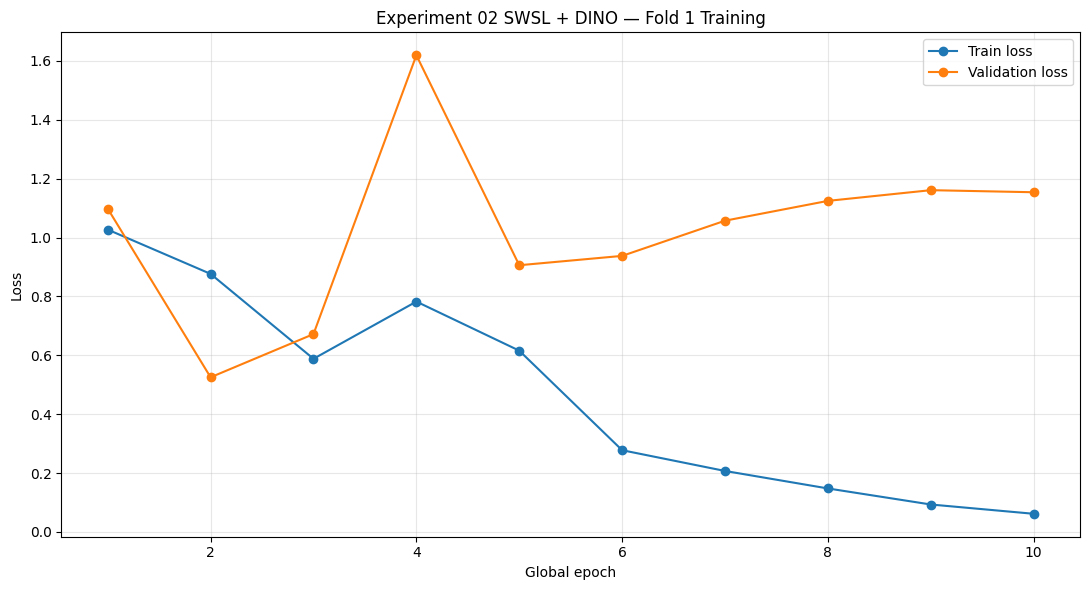

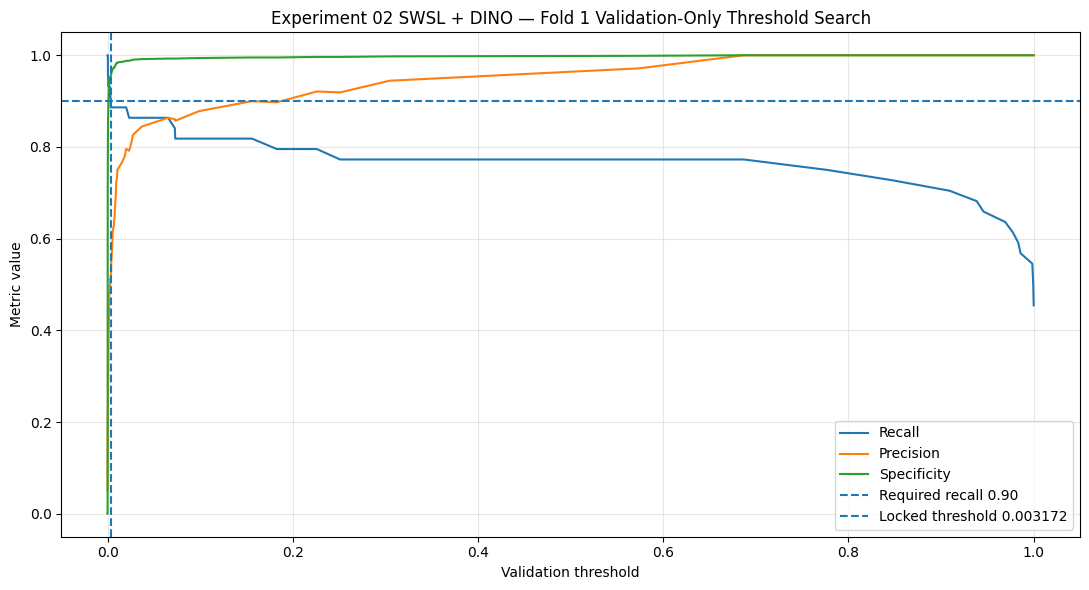


Experiment 02 Fold 1 training history:


,fold,stage,stage_epoch,global_epoch,train_loss,validation_loss,validation_auprc,validation_auroc,learning_rate_backbone,learning_rate_head
0,1,stage_1,1,1,1.027017,1.098366,0.709853,0.948165,0.000000e+00,0.001000
1,1,stage_1,2,2,0.876508,0.525219,0.759897,0.967087,0.000000e+00,0.000750
2,1,stage_1,3,3,0.588013,0.671933,0.780750,0.971208,0.000000e+00,0.000250
3,1,stage_2,1,4,0.782423,1.619300,0.835266,0.981435,1.000000e-05,0.000100
4,1,stage_2,2,5,0.615667,0.905931,0.901531,0.988335,9.504844e-06,0.000095
5,1,stage_2,3,6,0.277457,0.937669,0.910872,0.988828,8.117449e-06,0.000081
6,1,stage_2,4,7,0.206943,1.057237,0.911107,0.985830,6.112605e-06,0.000061
7,1,stage_2,5,8,0.147541,1.124576,0.902585,0.981531,3.887395e-06,0.000039
8,1,stage_2,6,9,0.093013,1.160953,0.900612,0.979765,1.882551e-06,0.000019
9,1,stage_2,7,10,0.061440,1.153892,0.903288,0.981202,4.951557e-07,0.000005



Experiment 02 Fold 1 locked metrics:


,experiment_id,experiment_name,source_checkpoint,fold,best_stage,best_stage_epoch,best_global_epoch,selection_mode,threshold,recall,...,balanced_accuracy,f1,tp,tn,fp,fn,auprc,auroc,held_out_test_loaded,held_out_test_evaluated
0,exp02_swsl_dino_fold_1,experiment_02_swsl_gastronet5m_dinov1,RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth,1,stage_2,4,7,overall_recall_0.90_and_minimum_centre_recall_...,0.003172,0.909091,...,0.931654,0.655738,40,792,38,4,0.911107,0.98583,False,False



Experiment 02 Fold 1 per-centre metrics:


,experiment_id,experiment_name,fold,center,sample_count,normal_count,positive_count,threshold,recall,precision,...,npv,accuracy,balanced_accuracy,f1,tp,tn,fp,fn,auprc,auroc
0,exp02_swsl_dino_fold_1,experiment_02_swsl_gastronet5m_dinov1,1,center_1,645,628,17,0.003172,0.882353,0.483871,...,0.996743,0.972093,0.928438,0.625000,15,612,16,2,0.894153,0.993069
1,exp02_swsl_dino_fold_1,experiment_02_swsl_gastronet5m_dinov1,1,center_2,229,202,27,0.003172,0.925926,0.531915,...,0.989011,0.895197,0.908508,0.675676,25,180,22,2,0.925778,0.969380



FINAL CELL 13B EXPERIMENT 02 FOLD 1 REPORT
Source checkpoint: RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth
Best stage: stage_2
Best stage epoch: 4
Best global epoch: 7
Validation AUPRC: 0.911107
Validation AUROC: 0.985830
Locked threshold: 0.003171920776
Validation recall: 0.909091
Validation PPV: 0.512821
Validation specificity: 0.954217
TP: 40
FP: 38
FN: 4
TN: 792

Held-out test loaded: False
Held-out test evaluated: False
Held-out test used for model selection: False
Held-out test used for threshold selection: False

STATUS: EXP02_SWSL_DINO_FOLD_1_TRAINING_AND_THRESHOLD_LOCK_COMPLETE

Saved records:
/content/drive/MyDrive/RARE26_GastroNet_Weights/models/cross_validation/experiment_02_swsl_gastronet5m_dinov1/fold_1/exp02_swsl_dino_fold_1_best.pth
/content/drive/MyDrive/RARE26_GastroNet_Weights/logs/cross_validation/experiment_02_swsl_gastronet5m_dinov1/fold_1/exp02_swsl_dino_fold_1_training_history.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/cross_validation

In [ ]:
# ============================================================
# RARE26 GASTRONET EXTENSION — CELL 13B
# EXPERIMENT 02: SWSL + GASTRONET-5M DINOv1
# CROSS-VALIDATION FOLD 1
#
# Candidate checkpoint:
# RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth
#
# Held-out test is NOT loaded or evaluated.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display

import gc
import json
import os
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)


# ============================================================
# 1. FIXED EXPERIMENT CONFIGURATION
# ============================================================

FOLD_NUMBER = 1
SEED = 42

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

SOURCE_CHECKPOINT_NAME = (
    "RN50_Billion-Scale-SWSL%2B"
    "GastroNet-5M_DINOv1.pth"
)

SOURCE_CHECKPOINT_PATH = (
    PROJECT_ROOT
    / "source_checkpoints"
    / SOURCE_CHECKPOINT_NAME
)

EXPERIMENT_NAME = (
    "experiment_02_swsl_gastronet5m_dinov1"
)

EXPERIMENT_ID = (
    "exp02_swsl_dino_fold_1"
)

FINAL_STATUS = (
    "EXP02_SWSL_DINO_FOLD_1_"
    "TRAINING_AND_THRESHOLD_LOCK_COMPLETE"
)


# ============================================================
# 2. INPUT SPLIT FILES
# ============================================================

FOLD_SPLIT_DIR = (
    PROJECT_ROOT
    / "configs"
    / "cross_validation"
    / "fold_1"
)

TRAIN_CSV = (
    FOLD_SPLIT_DIR
    / "fold_1_train_runtime.csv"
)

VALIDATION_CSV = (
    FOLD_SPLIT_DIR
    / "fold_1_validation_runtime.csv"
)


# ============================================================
# 3. SEPARATE EXPERIMENT-02 OUTPUT DIRECTORIES
# ============================================================

MODEL_DIR = (
    PROJECT_ROOT
    / "models"
    / "cross_validation"
    / EXPERIMENT_NAME
    / "fold_1"
)

LOG_DIR = (
    PROJECT_ROOT
    / "logs"
    / "cross_validation"
    / EXPERIMENT_NAME
    / "fold_1"
)

PREDICTION_DIR = (
    PROJECT_ROOT
    / "predictions"
    / "cross_validation"
    / EXPERIMENT_NAME
    / "fold_1"
)

RESULT_DIR = (
    PROJECT_ROOT
    / "results"
    / "cross_validation"
    / EXPERIMENT_NAME
    / "fold_1"
)

THRESHOLD_DIR = (
    PROJECT_ROOT
    / "thresholds"
    / "cross_validation"
    / EXPERIMENT_NAME
    / "fold_1"
)

CENTRE_DIR = (
    PROJECT_ROOT
    / "centre_analysis"
    / "cross_validation"
    / EXPERIMENT_NAME
    / "fold_1"
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "figures"
    / "cross_validation"
    / EXPERIMENT_NAME
    / "fold_1"
)

for directory in [
    MODEL_DIR,
    LOG_DIR,
    PREDICTION_DIR,
    RESULT_DIR,
    THRESHOLD_DIR,
    CENTRE_DIR,
    FIGURE_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 4. OUTPUT FILE PATHS
# ============================================================

BEST_CHECKPOINT_PATH = (
    MODEL_DIR
    / f"{EXPERIMENT_ID}_best.pth"
)

LATEST_CHECKPOINT_PATH = (
    MODEL_DIR
    / f"{EXPERIMENT_ID}_latest.pth"
)

HISTORY_PATH = (
    LOG_DIR
    / f"{EXPERIMENT_ID}_training_history.csv"
)

RAW_PREDICTIONS_PATH = (
    PREDICTION_DIR
    / f"{EXPERIMENT_ID}_validation_predictions.csv"
)

LOCKED_PREDICTIONS_PATH = (
    PREDICTION_DIR
    / (
        f"{EXPERIMENT_ID}_validation_predictions_"
        "locked_threshold.csv"
    )
)

METRICS_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_validation_metrics.csv"
)

THRESHOLD_SEARCH_PATH = (
    THRESHOLD_DIR
    / f"{EXPERIMENT_ID}_validation_threshold_search.csv"
)

THRESHOLD_OPERATING_POINT_PATH = (
    THRESHOLD_DIR
    / f"{EXPERIMENT_ID}_validation_operating_point.csv"
)

THRESHOLD_LOCK_PATH = (
    THRESHOLD_DIR
    / f"{EXPERIMENT_ID}_threshold_lock.json"
)

CENTRE_METRICS_PATH = (
    CENTRE_DIR
    / f"{EXPERIMENT_ID}_validation_per_centre_metrics.csv"
)

TRAINING_FIGURE_PATH = (
    FIGURE_DIR
    / f"{EXPERIMENT_ID}_training_curves.png"
)

THRESHOLD_FIGURE_PATH = (
    FIGURE_DIR
    / f"{EXPERIMENT_ID}_threshold_analysis.png"
)

CONFIG_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_configuration.json"
)

STATUS_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_status.json"
)

SUMMARY_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_summary.txt"
)


# ============================================================
# 5. INITIAL SAFETY CHECKS
# ============================================================

print("=" * 88)
print("CELL 13B: EXPERIMENT 02 SWSL + DINO — FOLD 1")
print("=" * 88)

print("\nExperiment 02 checkpoint:")
print(SOURCE_CHECKPOINT_PATH)

print("\nFold files:")
print(TRAIN_CSV)
print(VALIDATION_CSV)

if STATUS_PATH.exists():
    try:
        existing_status = json.loads(
            STATUS_PATH.read_text(
                encoding="utf-8"
            )
        )

        if existing_status.get("status") == FINAL_STATUS:
            raise FileExistsError(
                "Experiment 02 Fold 1 pehle hi complete hai.\n"
                f"Status file:\n{STATUS_PATH}"
            )

    except json.JSONDecodeError:
        pass

required_files = [
    SOURCE_CHECKPOINT_PATH,
    TRAIN_CSV,
    VALIDATION_CSV,
]

for required_file in required_files:

    if not required_file.exists():
        raise FileNotFoundError(
            f"Required file nahi mili:\n"
            f"{required_file}\n\n"
            "New notebook mein pehle Drive mount aur "
            "Cell 3B successfully run karo."
        )

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU active nahi hai.\n"
        "Colab mein Runtime → Change runtime type → T4 GPU select karo."
    )

device = torch.device("cuda")

gc.collect()
torch.cuda.empty_cache()

print("\nCompute device:")
print(device)
print(torch.cuda.get_device_name(0))

print(
    f"\nCheckpoint size: "
    f"{SOURCE_CHECKPOINT_PATH.stat().st_size / (1024 ** 2):.3f} MB"
)

print("\nHeld-out test CSV loaded: False")
print("Held-out test evaluated: False")
print("Held-out test used for any decision: False")


# ============================================================
# 6. REPRODUCIBILITY
# ============================================================

def set_all_seeds(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_all_seeds(SEED)

torch.set_float32_matmul_precision(
    "high"
)


# ============================================================
# 7. LOAD AND VERIFY FOLD-1 DATA
# ============================================================

train_df = pd.read_csv(
    TRAIN_CSV,
    low_memory=False,
).copy()

validation_df = pd.read_csv(
    VALIDATION_CSV,
    low_memory=False,
).copy()

required_columns = {
    "relative_path",
    "runtime_path",
    "label",
    "center",
    "class",
    "sha256",
    "cv_case_id",
    "cv_fold",
    "cv_role",
}

for dataframe_name, dataframe in [
    ("Fold 1 train", train_df),
    ("Fold 1 validation", validation_df),
]:

    missing_columns = (
        required_columns
        - set(dataframe.columns)
    )

    if missing_columns:
        raise RuntimeError(
            f"{dataframe_name} mein columns missing hain:\n"
            f"{sorted(missing_columns)}"
        )

train_df["label"] = (
    train_df["label"].astype(int)
)

validation_df["label"] = (
    validation_df["label"].astype(int)
)

train_df["cv_fold"] = (
    train_df["cv_fold"].astype(int)
)

validation_df["cv_fold"] = (
    validation_df["cv_fold"].astype(int)
)

if set(train_df["cv_fold"].unique()) != {1}:
    raise RuntimeError(
        "Training CSV Fold 1 ki nahi hai."
    )

if set(validation_df["cv_fold"].unique()) != {1}:
    raise RuntimeError(
        "Validation CSV Fold 1 ki nahi hai."
    )

if len(train_df) != 1746:
    raise RuntimeError(
        f"Fold 1 train expected 1746 records, "
        f"actual {len(train_df)}."
    )

if len(validation_df) != 874:
    raise RuntimeError(
        f"Fold 1 validation expected 874 records, "
        f"actual {len(validation_df)}."
    )

train_normal = int(
    (train_df["label"] == 0).sum()
)

train_positive = int(
    (train_df["label"] == 1).sum()
)

validation_normal = int(
    (validation_df["label"] == 0).sum()
)

validation_positive = int(
    (validation_df["label"] == 1).sum()
)

if (
    train_normal != 1658
    or train_positive != 88
):
    raise RuntimeError(
        "Fold 1 training class counts incorrect hain."
    )

if (
    validation_normal != 830
    or validation_positive != 44
):
    raise RuntimeError(
        "Fold 1 validation class counts incorrect hain."
    )

train_case_ids = set(
    train_df["cv_case_id"]
)

validation_case_ids = set(
    validation_df["cv_case_id"]
)

overlap_count = len(
    train_case_ids
    & validation_case_ids
)

if overlap_count != 0:
    raise RuntimeError(
        f"Train/validation overlap: {overlap_count}"
    )

for dataframe_name, dataframe in [
    ("Fold 1 train", train_df),
    ("Fold 1 validation", validation_df),
]:

    missing_image_count = int(
        (
            ~dataframe[
                "runtime_path"
            ].apply(
                lambda value: (
                    Path(str(value)).exists()
                    and Path(str(value)).is_file()
                )
            )
        ).sum()
    )

    if missing_image_count > 0:
        raise FileNotFoundError(
            f"{dataframe_name} mein "
            f"{missing_image_count} runtime images missing hain.\n"
            "Cell 3B dobara run karo."
        )

print("\nFold 1 data verified:")

print(
    f"Train: {len(train_df)} "
    f"(normal={train_normal}, NEO={train_positive})"
)

print(
    f"Validation: {len(validation_df)} "
    f"(normal={validation_normal}, NEO={validation_positive})"
)

print(
    f"Train/validation overlap: {overlap_count}"
)


# ============================================================
# 8. IMAGE TRANSFORMS
# ============================================================

IMAGE_SIZE = 224
RESIZE_SIZE = 256

IMAGENET_MEAN = (
    0.485,
    0.456,
    0.406,
)

IMAGENET_STD = (
    0.229,
    0.224,
    0.225,
)

ROTATION_FILL = tuple(
    int(value * 255)
    for value in IMAGENET_MEAN
)

train_transform = transforms.Compose(
    [
        transforms.Resize(
            RESIZE_SIZE
        ),

        transforms.RandomResizedCrop(
            IMAGE_SIZE,
            scale=(0.85, 1.00),
            ratio=(0.90, 1.10),
        ),

        transforms.RandomHorizontalFlip(
            p=0.5
        ),

        transforms.RandomRotation(
            degrees=8,
            fill=ROTATION_FILL,
        ),

        transforms.ColorJitter(
            brightness=0.10,
            contrast=0.10,
            saturation=0.05,
            hue=0.02,
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)

validation_transform = transforms.Compose(
    [
        transforms.Resize(
            RESIZE_SIZE
        ),

        transforms.CenterCrop(
            IMAGE_SIZE
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)


# ============================================================
# 9. DATASET CLASS
# ============================================================

class RARE26ExperimentDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform,
    ):

        self.dataframe = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.transform = transform

    def __len__(self):

        return len(
            self.dataframe
        )

    def __getitem__(
        self,
        index,
    ):

        row = self.dataframe.iloc[
            index
        ]

        image_path = Path(
            str(row["runtime_path"])
        )

        with Image.open(
            image_path
        ) as image:

            image = image.convert(
                "RGB"
            )

        image = self.transform(
            image
        )

        return {
            "image": image,

            "label": torch.tensor(
                int(row["label"]),
                dtype=torch.float32,
            ),

            "dataset_index": int(
                index
            ),

            "relative_path": str(
                row["relative_path"]
            ),

            "runtime_path": str(
                row["runtime_path"]
            ),

            "center": str(
                row["center"]
            ),

            "class_name": str(
                row["class"]
            ),

            "sha256": str(
                row["sha256"]
            ),

            "cv_case_id": str(
                row["cv_case_id"]
            ),
        }


train_dataset = RARE26ExperimentDataset(
    train_df,
    train_transform,
)

validation_dataset = RARE26ExperimentDataset(
    validation_df,
    validation_transform,
)


# ============================================================
# 10. DATA LOADERS
# ============================================================

BATCH_SIZE = 32
NUM_WORKERS = 2

def seed_worker(worker_id):

    worker_seed = (
        torch.initial_seed()
        % (2 ** 32)
    )

    np.random.seed(
        worker_seed
    )

    random.seed(
        worker_seed
    )


loader_generator = torch.Generator()

loader_generator.manual_seed(
    SEED
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False,
    worker_init_fn=seed_worker,
    generator=loader_generator,
    persistent_workers=True,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False,
    worker_init_fn=seed_worker,
    persistent_workers=True,
)

print("\nData loaders:")

print(
    f"Train batches: "
    f"{len(train_loader)}"
)

print(
    f"Validation batches: "
    f"{len(validation_loader)}"
)


# ============================================================
# 11. CHECKPOINT HELPER FUNCTIONS
# ============================================================

def extract_state_dict(
    checkpoint_object,
):

    if isinstance(
        checkpoint_object,
        dict,
    ):

        for possible_key in [
            "state_dict",
            "model_state_dict",
            "model",
            "encoder",
            "backbone",
        ]:

            if (
                possible_key
                in checkpoint_object
                and isinstance(
                    checkpoint_object[
                        possible_key
                    ],
                    dict,
                )
            ):

                return checkpoint_object[
                    possible_key
                ]

        if all(
            torch.is_tensor(value)
            for value
            in checkpoint_object.values()
        ):

            return checkpoint_object

    raise RuntimeError(
        "Checkpoint ke andar model state dictionary identify nahi hui."
    )


def remove_uniform_prefix(
    state_dictionary,
    prefix,
):

    keys = list(
        state_dictionary.keys()
    )

    if (
        keys
        and all(
            key.startswith(prefix)
            for key in keys
        )
    ):

        return {
            key[len(prefix):]: value
            for key, value
            in state_dictionary.items()
        }

    return state_dictionary


# ============================================================
# 12. LOAD SECOND PRETRAINED RESNET-50
# ============================================================

checkpoint_object = torch.load(
    SOURCE_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

pretrained_state = extract_state_dict(
    checkpoint_object
)

for prefix in [
    "module.",
    "model.",
    "backbone.",
    "encoder.",
]:

    pretrained_state = remove_uniform_prefix(
        pretrained_state,
        prefix,
    )

model = models.resnet50(
    weights=None
)

load_result = model.load_state_dict(
    pretrained_state,
    strict=False,
)

expected_missing_keys = {
    "fc.weight",
    "fc.bias",
}

if set(
    load_result.missing_keys
) != expected_missing_keys:

    raise RuntimeError(
        "Unexpected missing model parameters:\n"
        f"{load_result.missing_keys}"
    )

if load_result.unexpected_keys:

    raise RuntimeError(
        "Unexpected checkpoint parameters:\n"
        f"{load_result.unexpected_keys}"
    )

classification_features = (
    model.fc.in_features
)

model.fc = nn.Linear(
    classification_features,
    1,
)

model = model.to(
    device
)

print(
    "\nSecond pretrained SWSL + GastroNet-DINO "
    "backbone loaded:"
)

print(
    f"Missing parameters: "
    f"{load_result.missing_keys}"
)

print(
    f"Unexpected parameters: "
    f"{load_result.unexpected_keys}"
)

print(
    f"New classification head: "
    f"Linear({classification_features}, 1)"
)


# ============================================================
# 13. LOCKED TRAINING PROTOCOL
# ============================================================

POS_WEIGHT = (
    train_normal
    / train_positive
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [POS_WEIGHT],
        dtype=torch.float32,
        device=device,
    )
)

STAGE_1_EPOCHS = 3
STAGE_1_LR = 1e-3

STAGE_2_MAX_EPOCHS = 7
STAGE_2_BACKBONE_LR = 1e-5
STAGE_2_HEAD_LR = 1e-4

WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 3
GRADIENT_CLIP_NORM = 1.0

AMP_ENABLED = True

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=AMP_ENABLED,
)

print("\nLocked Experiment 02 protocol:")

print(
    f"Positive weight: "
    f"{POS_WEIGHT:.6f}"
)

print(
    "Stage 1: classification head only, 3 epochs"
)

print(
    "Stage 2: layer4 + classification head, maximum 7 epochs"
)

print(
    "Checkpoint selection: Fold-1 validation AUPRC"
)

print(
    "Threshold selection: Fold-1 validation predictions only"
)


# ============================================================
# 14. METRIC FUNCTION
# ============================================================

def calculate_binary_metrics(
    labels,
    probabilities,
    threshold,
):

    labels = np.asarray(
        labels,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    predictions = (
        probabilities
        >= threshold
    ).astype(int)

    tp = int(
        (
            (labels == 1)
            & (predictions == 1)
        ).sum()
    )

    tn = int(
        (
            (labels == 0)
            & (predictions == 0)
        ).sum()
    )

    fp = int(
        (
            (labels == 0)
            & (predictions == 1)
        ).sum()
    )

    fn = int(
        (
            (labels == 1)
            & (predictions == 0)
        ).sum()
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0.0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    npv = (
        tn / (tn + fn)
        if (tn + fn) > 0
        else np.nan
    )

    accuracy = (
        (tp + tn)
        / len(labels)
    )

    balanced_accuracy = (
        recall + specificity
    ) / 2

    f1 = (
        2 * precision * recall
        / (precision + recall)
        if (precision + recall) > 0
        else 0.0
    )

    return {
        "threshold": float(
            threshold
        ),

        "recall": float(
            recall
        ),

        "precision": float(
            precision
        ),

        "specificity": float(
            specificity
        ),

        "npv": float(
            npv
        ),

        "accuracy": float(
            accuracy
        ),

        "balanced_accuracy": float(
            balanced_accuracy
        ),

        "f1": float(
            f1
        ),

        "tp": tp,
        "tn": tn,
        "fp": fp,
        "fn": fn,
    }


# ============================================================
# 15. TRAINING FUNCTION
# ============================================================

def train_one_epoch(
    optimizer,
):

    model.train()

    total_loss = 0.0
    total_samples = 0

    progress_bar = tqdm(
        train_loader,
        leave=False,
        desc="Training",
    )

    for batch in progress_bar:

        images = batch["image"].to(
            device,
            non_blocking=True,
        )

        labels = batch["label"].to(
            device,
            non_blocking=True,
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=AMP_ENABLED,
        ):

            logits = model(
                images
            ).squeeze(1)

            loss = criterion(
                logits,
                labels,
            )

        scaler.scale(
            loss
        ).backward()

        scaler.unscale_(
            optimizer
        )

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRADIENT_CLIP_NORM,
        )

        scaler.step(
            optimizer
        )

        scaler.update()

        batch_size = images.size(
            0
        )

        total_loss += (
            float(loss.item())
            * batch_size
        )

        total_samples += (
            batch_size
        )

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    return (
        total_loss
        / total_samples
    )


# ============================================================
# 16. VALIDATION FUNCTION
# ============================================================

@torch.no_grad()
def evaluate_validation(
    collect_records=False,
):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_labels = []
    all_probabilities = []
    all_logits = []

    records = []

    for batch in tqdm(
        validation_loader,
        leave=False,
        desc="Validation",
    ):

        images = batch["image"].to(
            device,
            non_blocking=True,
        )

        labels = batch["label"].to(
            device,
            non_blocking=True,
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=AMP_ENABLED,
        ):

            logits = model(
                images
            ).squeeze(1)

            loss = criterion(
                logits,
                labels,
            )

        probabilities = torch.sigmoid(
            logits
        )

        labels_numpy = (
            labels.detach()
            .cpu()
            .numpy()
            .astype(int)
        )

        probabilities_numpy = (
            probabilities.detach()
            .cpu()
            .float()
            .numpy()
        )

        logits_numpy = (
            logits.detach()
            .cpu()
            .float()
            .numpy()
        )

        batch_size = images.size(
            0
        )

        total_loss += (
            float(loss.item())
            * batch_size
        )

        total_samples += (
            batch_size
        )

        all_labels.extend(
            labels_numpy.tolist()
        )

        all_probabilities.extend(
            probabilities_numpy.tolist()
        )

        all_logits.extend(
            logits_numpy.tolist()
        )

        if collect_records:

            for item_index in range(
                batch_size
            ):

                records.append(
                    {
                        "dataset_index": int(
                            batch[
                                "dataset_index"
                            ][item_index]
                        ),

                        "relative_path": (
                            batch[
                                "relative_path"
                            ][item_index]
                        ),

                        "runtime_path": (
                            batch[
                                "runtime_path"
                            ][item_index]
                        ),

                        "center": (
                            batch[
                                "center"
                            ][item_index]
                        ),

                        "class_name": (
                            batch[
                                "class_name"
                            ][item_index]
                        ),

                        "sha256": (
                            batch[
                                "sha256"
                            ][item_index]
                        ),

                        "cv_case_id": (
                            batch[
                                "cv_case_id"
                            ][item_index]
                        ),

                        "label": int(
                            labels_numpy[
                                item_index
                            ]
                        ),

                        "logit": float(
                            logits_numpy[
                                item_index
                            ]
                        ),

                        "probability": float(
                            probabilities_numpy[
                                item_index
                            ]
                        ),
                    }
                )

    labels_array = np.asarray(
        all_labels,
        dtype=int,
    )

    probabilities_array = np.asarray(
        all_probabilities,
        dtype=float,
    )

    return {
        "loss": (
            total_loss
            / total_samples
        ),

        "auprc": float(
            average_precision_score(
                labels_array,
                probabilities_array,
            )
        ),

        "auroc": float(
            roc_auc_score(
                labels_array,
                probabilities_array,
            )
        ),

        "labels": labels_array,

        "probabilities": (
            probabilities_array
        ),

        "logits": np.asarray(
            all_logits,
            dtype=float,
        ),

        "records": records,
    }


# ============================================================
# 17. CHECKPOINT SAVE FUNCTION
# ============================================================

def save_checkpoint(
    destination_path,
    stage_name,
    stage_epoch,
    global_epoch,
    validation_result,
    optimizer,
    scheduler,
):

    temporary_path = Path(
        str(destination_path)
        + ".tmp"
    )

    checkpoint_record = {
        "experiment_id": (
            EXPERIMENT_ID
        ),

        "experiment_name": (
            EXPERIMENT_NAME
        ),

        "fold": FOLD_NUMBER,

        "stage": stage_name,

        "stage_epoch": int(
            stage_epoch
        ),

        "global_epoch": int(
            global_epoch
        ),

        "model_state_dict": (
            model.state_dict()
        ),

        "optimizer_state_dict": (
            optimizer.state_dict()
        ),

        "scheduler_state_dict": (
            scheduler.state_dict()
        ),

        "validation_metrics": {
            "validation_loss": float(
                validation_result[
                    "loss"
                ]
            ),

            "validation_auprc": float(
                validation_result[
                    "auprc"
                ]
            ),

            "validation_auroc": float(
                validation_result[
                    "auroc"
                ]
            ),
        },

        "source_pretrained_checkpoint": str(
            SOURCE_CHECKPOINT_PATH
        ),

        "held_out_test_loaded": False,

        "held_out_test_evaluated": False,
    }

    torch.save(
        checkpoint_record,
        temporary_path,
    )

    os.replace(
        temporary_path,
        destination_path,
    )


# ============================================================
# 18. TRAINING LOOP
# ============================================================

training_history = []

global_epoch = 0

best_global_auprc = (
    -np.inf
)

training_start_time = (
    time.time()
)


# ------------------------------------------------------------
# STAGE 1: CLASSIFICATION HEAD ONLY
# ------------------------------------------------------------

for parameter in model.parameters():

    parameter.requires_grad = False

for parameter in model.fc.parameters():

    parameter.requires_grad = True

optimizer_stage_1 = torch.optim.AdamW(
    model.fc.parameters(),
    lr=STAGE_1_LR,
    weight_decay=WEIGHT_DECAY,
)

scheduler_stage_1 = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer_stage_1,
        T_max=STAGE_1_EPOCHS,
    )
)

print("\n" + "-" * 88)
print("STAGE 1: CLASSIFICATION HEAD ONLY")
print("-" * 88)

for stage_epoch in range(
    1,
    STAGE_1_EPOCHS + 1,
):

    global_epoch += 1

    train_loss = train_one_epoch(
        optimizer_stage_1
    )

    validation_result = (
        evaluate_validation()
    )

    training_history.append(
        {
            "fold": FOLD_NUMBER,

            "stage": (
                "stage_1"
            ),

            "stage_epoch": (
                stage_epoch
            ),

            "global_epoch": (
                global_epoch
            ),

            "train_loss": (
                train_loss
            ),

            "validation_loss": (
                validation_result[
                    "loss"
                ]
            ),

            "validation_auprc": (
                validation_result[
                    "auprc"
                ]
            ),

            "validation_auroc": (
                validation_result[
                    "auroc"
                ]
            ),

            "learning_rate_backbone": (
                0.0
            ),

            "learning_rate_head": (
                optimizer_stage_1
                .param_groups[0]["lr"]
            ),
        }
    )

    print(
        f"Stage 1 | Epoch {stage_epoch}/3 | "
        f"Train loss {train_loss:.6f} | "
        f"Val loss {validation_result['loss']:.6f} | "
        f"AUPRC {validation_result['auprc']:.6f} | "
        f"AUROC {validation_result['auroc']:.6f}"
    )

    save_checkpoint(
        LATEST_CHECKPOINT_PATH,
        "stage_1",
        stage_epoch,
        global_epoch,
        validation_result,
        optimizer_stage_1,
        scheduler_stage_1,
    )

    if (
        validation_result["auprc"]
        > best_global_auprc
    ):

        best_global_auprc = (
            validation_result[
                "auprc"
            ]
        )

        save_checkpoint(
            BEST_CHECKPOINT_PATH,
            "stage_1",
            stage_epoch,
            global_epoch,
            validation_result,
            optimizer_stage_1,
            scheduler_stage_1,
        )

    scheduler_stage_1.step()


# ------------------------------------------------------------
# STAGE 2: LAYER4 + CLASSIFICATION HEAD
# ------------------------------------------------------------

for parameter in model.parameters():

    parameter.requires_grad = False

for parameter in model.layer4.parameters():

    parameter.requires_grad = True

for parameter in model.fc.parameters():

    parameter.requires_grad = True

optimizer_stage_2 = torch.optim.AdamW(
    [
        {
            "params": (
                model.layer4.parameters()
            ),

            "lr": (
                STAGE_2_BACKBONE_LR
            ),
        },

        {
            "params": (
                model.fc.parameters()
            ),

            "lr": (
                STAGE_2_HEAD_LR
            ),
        },
    ],

    weight_decay=(
        WEIGHT_DECAY
    ),
)

scheduler_stage_2 = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer_stage_2,
        T_max=STAGE_2_MAX_EPOCHS,
    )
)

stage_2_best_auprc = (
    -np.inf
)

stage_2_no_improvement = (
    0
)

print("\n" + "-" * 88)
print("STAGE 2: LAYER4 AND CLASSIFICATION HEAD")
print("-" * 88)

for stage_epoch in range(
    1,
    STAGE_2_MAX_EPOCHS + 1,
):

    global_epoch += 1

    train_loss = train_one_epoch(
        optimizer_stage_2
    )

    validation_result = (
        evaluate_validation()
    )

    training_history.append(
        {
            "fold": FOLD_NUMBER,

            "stage": (
                "stage_2"
            ),

            "stage_epoch": (
                stage_epoch
            ),

            "global_epoch": (
                global_epoch
            ),

            "train_loss": (
                train_loss
            ),

            "validation_loss": (
                validation_result[
                    "loss"
                ]
            ),

            "validation_auprc": (
                validation_result[
                    "auprc"
                ]
            ),

            "validation_auroc": (
                validation_result[
                    "auroc"
                ]
            ),

            "learning_rate_backbone": (
                optimizer_stage_2
                .param_groups[0]["lr"]
            ),

            "learning_rate_head": (
                optimizer_stage_2
                .param_groups[1]["lr"]
            ),
        }
    )

    print(
        f"Stage 2 | Epoch {stage_epoch}/7 | "
        f"Global {global_epoch} | "
        f"Train loss {train_loss:.6f} | "
        f"Val loss {validation_result['loss']:.6f} | "
        f"AUPRC {validation_result['auprc']:.6f} | "
        f"AUROC {validation_result['auroc']:.6f}"
    )

    save_checkpoint(
        LATEST_CHECKPOINT_PATH,
        "stage_2",
        stage_epoch,
        global_epoch,
        validation_result,
        optimizer_stage_2,
        scheduler_stage_2,
    )

    if (
        validation_result["auprc"]
        > best_global_auprc
    ):

        best_global_auprc = (
            validation_result[
                "auprc"
            ]
        )

        save_checkpoint(
            BEST_CHECKPOINT_PATH,
            "stage_2",
            stage_epoch,
            global_epoch,
            validation_result,
            optimizer_stage_2,
            scheduler_stage_2,
        )

    if (
        validation_result["auprc"]
        > stage_2_best_auprc
    ):

        stage_2_best_auprc = (
            validation_result[
                "auprc"
            ]
        )

        stage_2_no_improvement = (
            0
        )

    else:

        stage_2_no_improvement += 1

    scheduler_stage_2.step()

    if (
        stage_2_no_improvement
        >= EARLY_STOPPING_PATIENCE
    ):

        print(
            "\nEarly stopping activated after "
            f"{EARLY_STOPPING_PATIENCE} consecutive "
            "Stage-2 epochs without AUPRC improvement."
        )

        break


training_duration_seconds = (
    time.time()
    - training_start_time
)

training_history_df = pd.DataFrame(
    training_history
)

training_history_df.to_csv(
    HISTORY_PATH,
    index=False,
)


# ============================================================
# 19. LOAD BEST CHECKPOINT
# ============================================================

if not BEST_CHECKPOINT_PATH.exists():

    raise RuntimeError(
        "Best Experiment 02 Fold-1 checkpoint save nahi hua."
    )

best_checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False,
)

model.load_state_dict(
    best_checkpoint[
        "model_state_dict"
    ]
)

model.eval()

print("\nBest Experiment 02 Fold-1 checkpoint:")

print(
    f"Stage: "
    f"{best_checkpoint['stage']}"
)

print(
    f"Stage epoch: "
    f"{best_checkpoint['stage_epoch']}"
)

print(
    f"Global epoch: "
    f"{best_checkpoint['global_epoch']}"
)

print(
    "Validation AUPRC: "
    f"{best_checkpoint['validation_metrics']['validation_auprc']:.6f}"
)

print(
    "Validation AUROC: "
    f"{best_checkpoint['validation_metrics']['validation_auroc']:.6f}"
)


# ============================================================
# 20. FINAL VALIDATION PREDICTIONS
# ============================================================

final_validation_result = (
    evaluate_validation(
        collect_records=True
    )
)

predictions_df = (
    pd.DataFrame(
        final_validation_result[
            "records"
        ]
    )
    .sort_values(
        "dataset_index"
    )
    .reset_index(
        drop=True
    )
)

if len(predictions_df) != 874:

    raise RuntimeError(
        "Experiment 02 Fold 1 must produce "
        "exactly 874 validation predictions."
    )

predictions_df[
    "experiment_id"
] = EXPERIMENT_ID

predictions_df[
    "experiment_name"
] = EXPERIMENT_NAME

predictions_df[
    "fold"
] = FOLD_NUMBER

predictions_df[
    "source_checkpoint"
] = SOURCE_CHECKPOINT_NAME

predictions_df.to_csv(
    RAW_PREDICTIONS_PATH,
    index=False,
)


# ============================================================
# 21. VALIDATION-ONLY THRESHOLD SEARCH
# ============================================================

labels = predictions_df[
    "label"
].to_numpy(
    dtype=int
)

probabilities = predictions_df[
    "probability"
].to_numpy(
    dtype=float
)

candidate_thresholds = np.unique(
    np.concatenate(
        [
            np.array([0.0]),
            probabilities,
            np.array([1.0]),
        ]
    )
)

threshold_rows = []

for threshold in candidate_thresholds:

    overall_metrics = (
        calculate_binary_metrics(
            labels,
            probabilities,
            threshold,
        )
    )

    centre_recalls = {}

    for centre_name, centre_group in (
        predictions_df.groupby(
            "center"
        )
    ):

        centre_metrics = (
            calculate_binary_metrics(
                centre_group[
                    "label"
                ].to_numpy(
                    dtype=int
                ),

                centre_group[
                    "probability"
                ].to_numpy(
                    dtype=float
                ),

                threshold,
            )
        )

        centre_recalls[
            centre_name
        ] = centre_metrics[
            "recall"
        ]

    minimum_centre_recall = float(
        min(
            centre_recalls.values()
        )
    )

    threshold_rows.append(
        {
            **overall_metrics,

            "center_1_recall": float(
                centre_recalls[
                    "center_1"
                ]
            ),

            "center_2_recall": float(
                centre_recalls[
                    "center_2"
                ]
            ),

            "minimum_centre_recall": (
                minimum_centre_recall
            ),

            "overall_recall_requirement_met": bool(
                overall_metrics[
                    "recall"
                ]
                >= 0.90
            ),

            "centre_recall_requirement_met": bool(
                minimum_centre_recall
                >= 0.80
            ),

            "strict_eligible": bool(
                overall_metrics[
                    "recall"
                ]
                >= 0.90

                and minimum_centre_recall
                >= 0.80
            ),
        }
    )

threshold_search_df = pd.DataFrame(
    threshold_rows
)

strict_eligible_df = (
    threshold_search_df[
        threshold_search_df[
            "strict_eligible"
        ]
    ].copy()
)

if not strict_eligible_df.empty:

    selection_mode = (
        "overall_recall_0.90_and_"
        "minimum_centre_recall_0.80"
    )

    eligible_df = (
        strict_eligible_df
    )

else:

    selection_mode = (
        "fallback_overall_recall_0.90"
    )

    eligible_df = (
        threshold_search_df[
            threshold_search_df[
                "overall_recall_requirement_met"
            ]
        ].copy()
    )

if eligible_df.empty:

    selection_mode = (
        "fallback_highest_recall"
    )

    maximum_recall = (
        threshold_search_df[
            "recall"
        ].max()
    )

    eligible_df = (
        threshold_search_df[
            threshold_search_df[
                "recall"
            ]
            == maximum_recall
        ].copy()
    )

selected_row = (
    eligible_df.sort_values(
        by=[
            "precision",
            "minimum_centre_recall",
            "specificity",
            "threshold",
        ],

        ascending=[
            False,
            False,
            False,
            False,
        ],
    )
    .iloc[0]
)

LOCKED_THRESHOLD = float(
    selected_row[
        "threshold"
    ]
)

threshold_search_df.to_csv(
    THRESHOLD_SEARCH_PATH,
    index=False,
)

pd.DataFrame(
    [
        selected_row.to_dict()
    ]
).to_csv(
    THRESHOLD_OPERATING_POINT_PATH,
    index=False,
)


# ============================================================
# 22. APPLY LOCKED THRESHOLD
# ============================================================

predictions_df[
    "locked_threshold"
] = LOCKED_THRESHOLD

predictions_df[
    "prediction"
] = (
    predictions_df[
        "probability"
    ]
    >= LOCKED_THRESHOLD
).astype(int)

predictions_df[
    "prediction_correct"
] = (
    predictions_df[
        "prediction"
    ]
    ==
    predictions_df[
        "label"
    ]
)

predictions_df[
    "error_type"
] = np.select(
    [
        (
            (predictions_df["label"] == 1)
            &
            (predictions_df["prediction"] == 1)
        ),

        (
            (predictions_df["label"] == 0)
            &
            (predictions_df["prediction"] == 0)
        ),

        (
            (predictions_df["label"] == 0)
            &
            (predictions_df["prediction"] == 1)
        ),
    ],

    [
        "TP",
        "TN",
        "FP",
    ],

    default="FN",
)

predictions_df.to_csv(
    LOCKED_PREDICTIONS_PATH,
    index=False,
)


# ============================================================
# 23. FINAL OVERALL METRICS
# ============================================================

overall_metrics = (
    calculate_binary_metrics(
        labels,
        probabilities,
        LOCKED_THRESHOLD,
    )
)

overall_metrics[
    "auprc"
] = float(
    average_precision_score(
        labels,
        probabilities,
    )
)

overall_metrics[
    "auroc"
] = float(
    roc_auc_score(
        labels,
        probabilities,
    )
)

metrics_df = pd.DataFrame(
    [
        {
            "experiment_id": (
                EXPERIMENT_ID
            ),

            "experiment_name": (
                EXPERIMENT_NAME
            ),

            "source_checkpoint": (
                SOURCE_CHECKPOINT_NAME
            ),

            "fold": (
                FOLD_NUMBER
            ),

            "best_stage": (
                best_checkpoint[
                    "stage"
                ]
            ),

            "best_stage_epoch": int(
                best_checkpoint[
                    "stage_epoch"
                ]
            ),

            "best_global_epoch": int(
                best_checkpoint[
                    "global_epoch"
                ]
            ),

            "selection_mode": (
                selection_mode
            ),

            **overall_metrics,

            "held_out_test_loaded": False,

            "held_out_test_evaluated": False,
        }
    ]
)

metrics_df.to_csv(
    METRICS_PATH,
    index=False,
)


# ============================================================
# 24. PER-CENTRE METRICS
# ============================================================

centre_metric_rows = []

for centre_name, centre_group in (
    predictions_df.groupby(
        "center"
    )
):

    centre_labels = (
        centre_group[
            "label"
        ].to_numpy(
            dtype=int
        )
    )

    centre_probabilities = (
        centre_group[
            "probability"
        ].to_numpy(
            dtype=float
        )
    )

    centre_metrics = (
        calculate_binary_metrics(
            centre_labels,
            centre_probabilities,
            LOCKED_THRESHOLD,
        )
    )

    centre_metrics[
        "auprc"
    ] = float(
        average_precision_score(
            centre_labels,
            centre_probabilities,
        )
    )

    centre_metrics[
        "auroc"
    ] = float(
        roc_auc_score(
            centre_labels,
            centre_probabilities,
        )
    )

    centre_metric_rows.append(
        {
            "experiment_id": (
                EXPERIMENT_ID
            ),

            "experiment_name": (
                EXPERIMENT_NAME
            ),

            "fold": (
                FOLD_NUMBER
            ),

            "center": (
                centre_name
            ),

            "sample_count": int(
                len(centre_group)
            ),

            "normal_count": int(
                (centre_labels == 0).sum()
            ),

            "positive_count": int(
                (centre_labels == 1).sum()
            ),

            **centre_metrics,
        }
    )

centre_metrics_df = pd.DataFrame(
    centre_metric_rows
)

centre_metrics_df.to_csv(
    CENTRE_METRICS_PATH,
    index=False,
)


# ============================================================
# 25. SAVE THRESHOLD LOCK
# ============================================================

threshold_lock_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": (
        "EXP02_SWSL_DINO_FOLD_1_"
        "VALIDATION_THRESHOLD_LOCKED"
    ),

    "experiment_id": (
        EXPERIMENT_ID
    ),

    "experiment_name": (
        EXPERIMENT_NAME
    ),

    "source_checkpoint": (
        SOURCE_CHECKPOINT_NAME
    ),

    "fold": (
        FOLD_NUMBER
    ),

    "selected_threshold": float(
        LOCKED_THRESHOLD
    ),

    "selection_mode": (
        selection_mode
    ),

    "validation_auprc": float(
        overall_metrics[
            "auprc"
        ]
    ),

    "validation_auroc": float(
        overall_metrics[
            "auroc"
        ]
    ),

    "validation_recall": float(
        overall_metrics[
            "recall"
        ]
    ),

    "validation_precision": float(
        overall_metrics[
            "precision"
        ]
    ),

    "validation_specificity": float(
        overall_metrics[
            "specificity"
        ]
    ),

    "validation_tp": int(
        overall_metrics[
            "tp"
        ]
    ),

    "validation_tn": int(
        overall_metrics[
            "tn"
        ]
    ),

    "validation_fp": int(
        overall_metrics[
            "fp"
        ]
    ),

    "validation_fn": int(
        overall_metrics[
            "fn"
        ]
    ),

    "threshold_selected_from": (
        "experiment_02_fold_1_validation_only"
    ),

    "held_out_test_loaded": False,

    "held_out_test_evaluated": False,

    "held_out_test_used_for_threshold": False,
}

THRESHOLD_LOCK_PATH.write_text(
    json.dumps(
        threshold_lock_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ============================================================
# 26. SAVE CONFIGURATION AND STATUS
# ============================================================

configuration_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "experiment_id": (
        EXPERIMENT_ID
    ),

    "experiment_name": (
        EXPERIMENT_NAME
    ),

    "fold": (
        FOLD_NUMBER
    ),

    "random_seed": (
        SEED
    ),

    "source_pretrained_checkpoint": str(
        SOURCE_CHECKPOINT_PATH
    ),

    "train_csv": str(
        TRAIN_CSV
    ),

    "validation_csv": str(
        VALIDATION_CSV
    ),

    "train_sample_count": int(
        len(train_df)
    ),

    "validation_sample_count": int(
        len(validation_df)
    ),

    "image_size": (
        IMAGE_SIZE
    ),

    "resize_size": (
        RESIZE_SIZE
    ),

    "batch_size": (
        BATCH_SIZE
    ),

    "positive_weight": float(
        POS_WEIGHT
    ),

    "stage_1_epochs": (
        STAGE_1_EPOCHS
    ),

    "stage_1_learning_rate": (
        STAGE_1_LR
    ),

    "stage_2_max_epochs": (
        STAGE_2_MAX_EPOCHS
    ),

    "stage_2_backbone_learning_rate": (
        STAGE_2_BACKBONE_LR
    ),

    "stage_2_head_learning_rate": (
        STAGE_2_HEAD_LR
    ),

    "weight_decay": (
        WEIGHT_DECAY
    ),

    "early_stopping_patience": (
        EARLY_STOPPING_PATIENCE
    ),

    "checkpoint_selection_metric": (
        "fold_1_validation_auprc"
    ),

    "threshold_selection_source": (
        "fold_1_validation_predictions_only"
    ),

    "held_out_test_loaded": False,

    "held_out_test_evaluated": False,
}

CONFIG_PATH.write_text(
    json.dumps(
        configuration_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": (
        FINAL_STATUS
    ),

    "experiment_id": (
        EXPERIMENT_ID
    ),

    "experiment_name": (
        EXPERIMENT_NAME
    ),

    "source_checkpoint": (
        SOURCE_CHECKPOINT_NAME
    ),

    "fold": (
        FOLD_NUMBER
    ),

    "best_checkpoint_path": str(
        BEST_CHECKPOINT_PATH
    ),

    "best_stage": (
        best_checkpoint[
            "stage"
        ]
    ),

    "best_stage_epoch": int(
        best_checkpoint[
            "stage_epoch"
        ]
    ),

    "best_global_epoch": int(
        best_checkpoint[
            "global_epoch"
        ]
    ),

    "validation_auprc": float(
        overall_metrics[
            "auprc"
        ]
    ),

    "validation_auroc": float(
        overall_metrics[
            "auroc"
        ]
    ),

    "locked_threshold": float(
        LOCKED_THRESHOLD
    ),

    "training_duration_seconds": float(
        training_duration_seconds
    ),

    "held_out_test_loaded": False,

    "held_out_test_evaluated": False,

    "held_out_test_used_for_model_selection": False,

    "held_out_test_used_for_threshold_selection": False,
}

STATUS_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ============================================================
# 27. TRAINING CURVE FIGURE
# ============================================================

figure = plt.figure(
    figsize=(11, 6)
)

plt.plot(
    training_history_df[
        "global_epoch"
    ],

    training_history_df[
        "train_loss"
    ],

    marker="o",

    label="Train loss",
)

plt.plot(
    training_history_df[
        "global_epoch"
    ],

    training_history_df[
        "validation_loss"
    ],

    marker="o",

    label="Validation loss",
)

plt.xlabel(
    "Global epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Experiment 02 SWSL + DINO — Fold 1 Training"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

figure.savefig(
    TRAINING_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

plt.close(
    figure
)


# ============================================================
# 28. THRESHOLD ANALYSIS FIGURE
# ============================================================

figure = plt.figure(
    figsize=(11, 6)
)

plt.plot(
    threshold_search_df[
        "threshold"
    ],

    threshold_search_df[
        "recall"
    ],

    label="Recall",
)

plt.plot(
    threshold_search_df[
        "threshold"
    ],

    threshold_search_df[
        "precision"
    ],

    label="Precision",
)

plt.plot(
    threshold_search_df[
        "threshold"
    ],

    threshold_search_df[
        "specificity"
    ],

    label="Specificity",
)

plt.axhline(
    0.90,
    linestyle="--",
    label="Required recall 0.90",
)

plt.axvline(
    LOCKED_THRESHOLD,
    linestyle="--",
    label=(
        f"Locked threshold "
        f"{LOCKED_THRESHOLD:.6f}"
    ),
)

plt.xlabel(
    "Validation threshold"
)

plt.ylabel(
    "Metric value"
)

plt.title(
    "Experiment 02 SWSL + DINO — "
    "Fold 1 Validation-Only Threshold Search"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

figure.savefig(
    THRESHOLD_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

plt.close(
    figure
)


# ============================================================
# 29. SAVE READABLE SUMMARY
# ============================================================

summary_lines = [
    "RARE26 GastroNet Experiment 02",
    "SWSL + GastroNet-5M DINOv1 — Fold 1",
    "=" * 72,
    "",
    (
        f"Checkpoint: "
        f"{SOURCE_CHECKPOINT_NAME}"
    ),
    "",
    (
        f"Train images: "
        f"{len(train_df)}"
    ),
    (
        f"Validation images: "
        f"{len(validation_df)}"
    ),
    "",
    (
        f"Best stage: "
        f"{best_checkpoint['stage']}"
    ),
    (
        f"Best stage epoch: "
        f"{best_checkpoint['stage_epoch']}"
    ),
    (
        f"Best global epoch: "
        f"{best_checkpoint['global_epoch']}"
    ),
    "",
    (
        f"Validation AUPRC: "
        f"{overall_metrics['auprc']:.6f}"
    ),
    (
        f"Validation AUROC: "
        f"{overall_metrics['auroc']:.6f}"
    ),
    "",
    (
        f"Locked threshold: "
        f"{LOCKED_THRESHOLD:.12f}"
    ),
    (
        f"Recall: "
        f"{overall_metrics['recall']:.6f}"
    ),
    (
        f"PPV: "
        f"{overall_metrics['precision']:.6f}"
    ),
    (
        f"Specificity: "
        f"{overall_metrics['specificity']:.6f}"
    ),
    (
        f"TP / FP / FN / TN: "
        f"{overall_metrics['tp']} / "
        f"{overall_metrics['fp']} / "
        f"{overall_metrics['fn']} / "
        f"{overall_metrics['tn']}"
    ),
    "",
    "Held-out test loaded: No",
    "Held-out test evaluated: No",
    "",
    f"Status: {FINAL_STATUS}",
]

SUMMARY_PATH.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ============================================================
# 30. FINAL REPORT
# ============================================================

print(
    "\nExperiment 02 Fold 1 training history:"
)

display(
    training_history_df
)

print(
    "\nExperiment 02 Fold 1 locked metrics:"
)

display(
    metrics_df
)

print(
    "\nExperiment 02 Fold 1 per-centre metrics:"
)

display(
    centre_metrics_df
)

print("\n" + "=" * 88)
print("FINAL CELL 13B EXPERIMENT 02 FOLD 1 REPORT")
print("=" * 88)

print(
    f"Source checkpoint: "
    f"{SOURCE_CHECKPOINT_NAME}"
)

print(
    f"Best stage: "
    f"{best_checkpoint['stage']}"
)

print(
    f"Best stage epoch: "
    f"{best_checkpoint['stage_epoch']}"
)

print(
    f"Best global epoch: "
    f"{best_checkpoint['global_epoch']}"
)

print(
    f"Validation AUPRC: "
    f"{overall_metrics['auprc']:.6f}"
)

print(
    f"Validation AUROC: "
    f"{overall_metrics['auroc']:.6f}"
)

print(
    f"Locked threshold: "
    f"{LOCKED_THRESHOLD:.12f}"
)

print(
    f"Validation recall: "
    f"{overall_metrics['recall']:.6f}"
)

print(
    f"Validation PPV: "
    f"{overall_metrics['precision']:.6f}"
)

print(
    f"Validation specificity: "
    f"{overall_metrics['specificity']:.6f}"
)

print(
    f"TP: "
    f"{overall_metrics['tp']}"
)

print(
    f"FP: "
    f"{overall_metrics['fp']}"
)

print(
    f"FN: "
    f"{overall_metrics['fn']}"
)

print(
    f"TN: "
    f"{overall_metrics['tn']}"
)

print("\nHeld-out test loaded: False")
print("Held-out test evaluated: False")

print(
    "Held-out test used for model selection: False"
)

print(
    "Held-out test used for threshold selection: False"
)

print(
    f"\nSTATUS: "
    f"{FINAL_STATUS}"
)

print("\nSaved records:")

print(BEST_CHECKPOINT_PATH)
print(HISTORY_PATH)
print(RAW_PREDICTIONS_PATH)
print(LOCKED_PREDICTIONS_PATH)
print(METRICS_PATH)
print(THRESHOLD_SEARCH_PATH)
print(THRESHOLD_OPERATING_POINT_PATH)
print(THRESHOLD_LOCK_PATH)
print(CENTRE_METRICS_PATH)
print(TRAINING_FIGURE_PATH)
print(THRESHOLD_FIGURE_PATH)
print(CONFIG_PATH)
print(STATUS_PATH)
print(SUMMARY_PATH)

gc.collect()
torch.cuda.empty_cache()

CELL 13C: EXPERIMENT 02 SWSL + DINO — FOLD 2

Experiment 02 checkpoint:
/content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints/RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth

Fold 2 files:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/cross_validation/fold_2/fold_2_train_runtime.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/cross_validation/fold_2/fold_2_validation_runtime.csv

Compute device:
cuda
Tesla T4

Checkpoint size: 89.985 MB

Held-out test CSV loaded: False
Held-out test evaluated: False
Held-out test used for any decision: False

Fold 2 data verified:
Train: 1747 (normal=1659, NEO=88)
Validation: 873 (normal=829, NEO=44)
Train/validation overlap: 0

Data loaders:
Train batches: 55
Validation batches: 28

Second pretrained SWSL + GastroNet-DINO backbone loaded:
Missing parameters: ['fc.weight', 'fc.bias']
Unexpected parameters: []
New classification head: Linear(2048, 1)

Locked Experiment 02 Fold 2 protocol:
Positive weight: 18.852273
S

Training:   0%|          | 0/55 [00:00<?, ?it/s]

Validation:   0%|          | 0/28 [00:00<?, ?it/s]

Stage 1 | Epoch 1/3 | Train loss 1.117043 | Val loss 0.743113 | AUPRC 0.626387 | AUROC 0.917672


Training:   0%|          | 0/55 [00:00<?, ?it/s]

...

Stage 2 | Epoch 6/7 | Global 9 | Train loss 0.130453 | Val loss 1.503914 | AUPRC 0.896632 | AUROC 0.973860


Training:   0%|          | 0/55 [00:00<?, ?it/s]

Validation:   0%|          | 0/28 [00:00<?, ?it/s]

Stage 2 | Epoch 7/7 | Global 10 | Train loss 0.068046 | Val loss 1.529855 | AUPRC 0.898275 | AUROC 0.973476

Best Experiment 02 Fold-2 checkpoint:
Stage: stage_2
Stage epoch: 5
Global epoch: 8
Validation AUPRC: 0.899497
Validation AUROC: 0.972407


Validation:   0%|          | 0/28 [00:00<?, ?it/s]

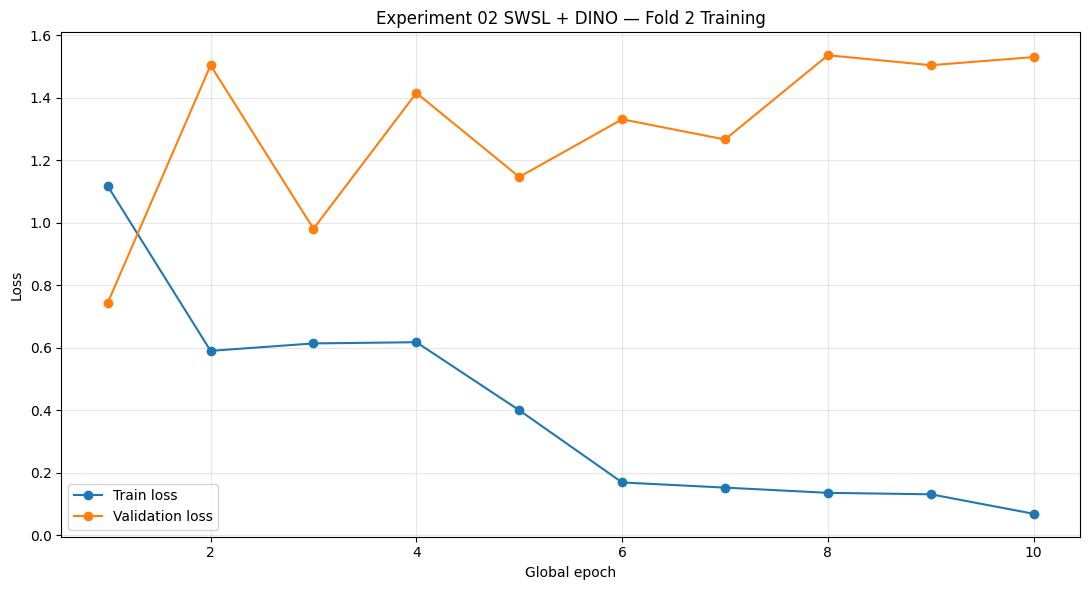

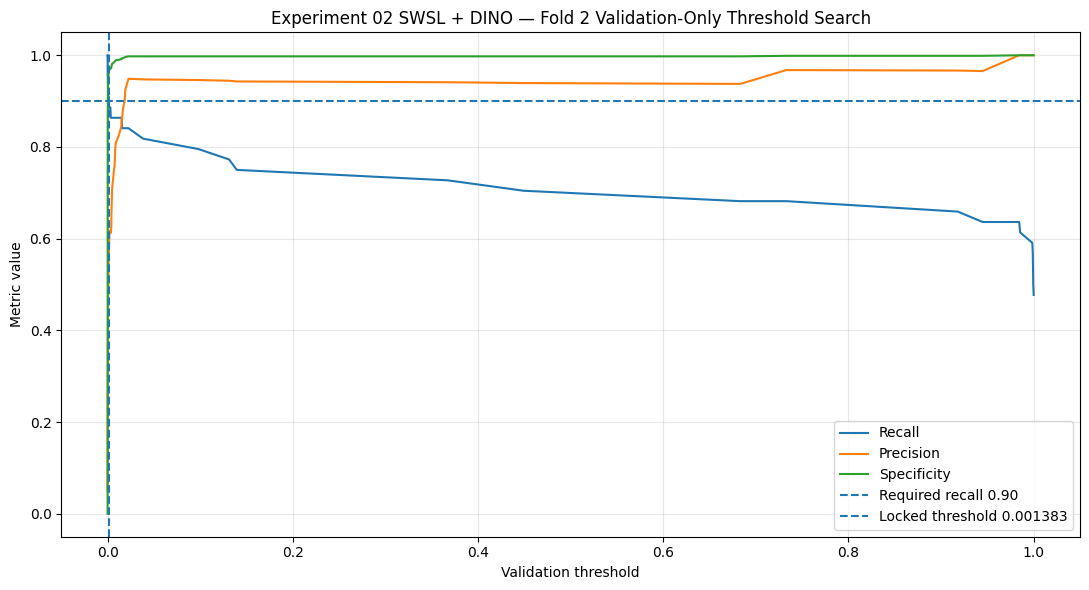


Experiment 02 Fold 2 training history:


,fold,stage,stage_epoch,global_epoch,train_loss,validation_loss,validation_auprc,validation_auroc,learning_rate_backbone,learning_rate_head
0,2,stage_1,1,1,1.117043,0.743113,0.626387,0.917672,0.000000e+00,0.001000
1,2,stage_1,2,2,0.589542,1.503472,0.726386,0.940783,0.000000e+00,0.000750
2,2,stage_1,3,3,0.613380,0.980299,0.737178,0.943949,0.000000e+00,0.000250
3,2,stage_2,1,4,0.617241,1.415029,0.819262,0.956410,1.000000e-05,0.000100
4,2,stage_2,2,5,0.399445,1.146129,0.871622,0.971735,9.504844e-06,0.000095
5,2,stage_2,3,6,0.168358,1.330647,0.887936,0.968637,8.117449e-06,0.000081
6,2,stage_2,4,7,0.151860,1.266096,0.894476,0.972708,6.112605e-06,0.000061
7,2,stage_2,5,8,0.135095,1.535685,0.899497,0.972407,3.887395e-06,0.000039
8,2,stage_2,6,9,0.130453,1.503914,0.896632,0.973860,1.882551e-06,0.000019
9,2,stage_2,7,10,0.068046,1.529855,0.898275,0.973476,4.951557e-07,0.000005



Experiment 02 Fold 2 locked metrics:


,experiment_id,experiment_name,source_checkpoint,fold,best_stage,best_stage_epoch,best_global_epoch,selection_mode,threshold,recall,...,balanced_accuracy,f1,tp,tn,fp,fn,auprc,auroc,held_out_test_loaded,held_out_test_evaluated
0,exp02_swsl_dino_fold_2,experiment_02_swsl_gastronet5m_dinov1,RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth,2,stage_2,5,8,overall_recall_0.90_and_minimum_centre_recall_...,0.001383,0.909091,...,0.937055,0.707965,40,800,29,4,0.899497,0.972407,False,False



Experiment 02 Fold 2 per-centre metrics:


,experiment_id,experiment_name,fold,center,sample_count,normal_count,positive_count,threshold,recall,precision,...,npv,accuracy,balanced_accuracy,f1,tp,tn,fp,fn,auprc,auroc
0,exp02_swsl_dino_fold_2,experiment_02_swsl_gastronet5m_dinov1,2,center_1,645,628,17,0.001383,0.882353,0.500000,...,0.996748,0.973643,0.929234,0.638298,15,613,15,2,0.806607,0.949279
1,exp02_swsl_dino_fold_2,experiment_02_swsl_gastronet5m_dinov1,2,center_2,228,201,27,0.001383,0.925926,0.641026,...,0.989418,0.929825,0.928137,0.757576,25,187,14,2,0.947976,0.984338



FINAL CELL 13C EXPERIMENT 02 FOLD 2 REPORT
Source checkpoint: RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth
Best stage: stage_2
Best stage epoch: 5
Best global epoch: 8
Validation AUPRC: 0.899497
Validation AUROC: 0.972407
Locked threshold: 0.001382827759
Validation recall: 0.909091
Validation PPV: 0.579710
Validation specificity: 0.965018
TP: 40
FP: 29
FN: 4
TN: 800

Held-out test loaded: False
Held-out test evaluated: False
Held-out test used for model selection: False
Held-out test used for threshold selection: False

STATUS: EXP02_SWSL_DINO_FOLD_2_TRAINING_AND_THRESHOLD_LOCK_COMPLETE

Saved records:
/content/drive/MyDrive/RARE26_GastroNet_Weights/models/cross_validation/experiment_02_swsl_gastronet5m_dinov1/fold_2/exp02_swsl_dino_fold_2_best.pth
/content/drive/MyDrive/RARE26_GastroNet_Weights/logs/cross_validation/experiment_02_swsl_gastronet5m_dinov1/fold_2/exp02_swsl_dino_fold_2_training_history.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/cross_validation

In [ ]:
# ============================================================
# RARE26 GASTRONET EXTENSION — CELL 13C
# EXPERIMENT 02: SWSL + GASTRONET-5M DINOv1
# CROSS-VALIDATION FOLD 2
#
# Second pretrained checkpoint:
# RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth
#
# Uses only Fold-2 train and validation data.
# Held-out test is NOT loaded or evaluated.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display

import gc
import json
import os
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)


# ============================================================
# 1. FIXED EXPERIMENT CONFIGURATION
# ============================================================

FOLD_NUMBER = 2
SEED = 42

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

SOURCE_CHECKPOINT_NAME = (
    "RN50_Billion-Scale-SWSL%2B"
    "GastroNet-5M_DINOv1.pth"
)

SOURCE_CHECKPOINT_PATH = (
    PROJECT_ROOT
    / "source_checkpoints"
    / SOURCE_CHECKPOINT_NAME
)

EXPERIMENT_NAME = (
    "experiment_02_swsl_gastronet5m_dinov1"
)

EXPERIMENT_ID = (
    "exp02_swsl_dino_fold_2"
)

FINAL_STATUS = (
    "EXP02_SWSL_DINO_FOLD_2_"
    "TRAINING_AND_THRESHOLD_LOCK_COMPLETE"
)


# ============================================================
# 2. FOLD-2 INPUT FILES
# ============================================================

FOLD_SPLIT_DIR = (
    PROJECT_ROOT
    / "configs"
    / "cross_validation"
    / "fold_2"
)

TRAIN_CSV = (
    FOLD_SPLIT_DIR
    / "fold_2_train_runtime.csv"
)

VALIDATION_CSV = (
    FOLD_SPLIT_DIR
    / "fold_2_validation_runtime.csv"
)


# ============================================================
# 3. SEPARATE EXPERIMENT-02 FOLD-2 OUTPUT DIRECTORIES
# ============================================================

MODEL_DIR = (
    PROJECT_ROOT
    / "models"
    / "cross_validation"
    / EXPERIMENT_NAME
    / "fold_2"
)

LOG_DIR = (
    PROJECT_ROOT
    / "logs"
    / "cross_validation"
    / EXPERIMENT_NAME
    / "fold_2"
)

PREDICTION_DIR = (
    PROJECT_ROOT
    / "predictions"
    / "cross_validation"
    / EXPERIMENT_NAME
    / "fold_2"
)

RESULT_DIR = (
    PROJECT_ROOT
    / "results"
    / "cross_validation"
    / EXPERIMENT_NAME
    / "fold_2"
)

THRESHOLD_DIR = (
    PROJECT_ROOT
    / "thresholds"
    / "cross_validation"
    / EXPERIMENT_NAME
    / "fold_2"
)

CENTRE_DIR = (
    PROJECT_ROOT
    / "centre_analysis"
    / "cross_validation"
    / EXPERIMENT_NAME
    / "fold_2"
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "figures"
    / "cross_validation"
    / EXPERIMENT_NAME
    / "fold_2"
)

for directory in [
    MODEL_DIR,
    LOG_DIR,
    PREDICTION_DIR,
    RESULT_DIR,
    THRESHOLD_DIR,
    CENTRE_DIR,
    FIGURE_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 4. OUTPUT FILE PATHS
# ============================================================

BEST_CHECKPOINT_PATH = (
    MODEL_DIR
    / f"{EXPERIMENT_ID}_best.pth"
)

LATEST_CHECKPOINT_PATH = (
    MODEL_DIR
    / f"{EXPERIMENT_ID}_latest.pth"
)

HISTORY_PATH = (
    LOG_DIR
    / f"{EXPERIMENT_ID}_training_history.csv"
)

RAW_PREDICTIONS_PATH = (
    PREDICTION_DIR
    / f"{EXPERIMENT_ID}_validation_predictions.csv"
)

LOCKED_PREDICTIONS_PATH = (
    PREDICTION_DIR
    / (
        f"{EXPERIMENT_ID}_validation_predictions_"
        "locked_threshold.csv"
    )
)

METRICS_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_validation_metrics.csv"
)

THRESHOLD_SEARCH_PATH = (
    THRESHOLD_DIR
    / f"{EXPERIMENT_ID}_validation_threshold_search.csv"
)

THRESHOLD_OPERATING_POINT_PATH = (
    THRESHOLD_DIR
    / f"{EXPERIMENT_ID}_validation_operating_point.csv"
)

THRESHOLD_LOCK_PATH = (
    THRESHOLD_DIR
    / f"{EXPERIMENT_ID}_threshold_lock.json"
)

CENTRE_METRICS_PATH = (
    CENTRE_DIR
    / f"{EXPERIMENT_ID}_validation_per_centre_metrics.csv"
)

TRAINING_FIGURE_PATH = (
    FIGURE_DIR
    / f"{EXPERIMENT_ID}_training_curves.png"
)

THRESHOLD_FIGURE_PATH = (
    FIGURE_DIR
    / f"{EXPERIMENT_ID}_threshold_analysis.png"
)

CONFIG_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_configuration.json"
)

STATUS_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_status.json"
)

SUMMARY_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_summary.txt"
)


# ============================================================
# 5. INITIAL SAFETY CHECKS
# ============================================================

print("=" * 88)
print("CELL 13C: EXPERIMENT 02 SWSL + DINO — FOLD 2")
print("=" * 88)

print("\nExperiment 02 checkpoint:")
print(SOURCE_CHECKPOINT_PATH)

print("\nFold 2 files:")
print(TRAIN_CSV)
print(VALIDATION_CSV)

if STATUS_PATH.exists():

    try:
        existing_status = json.loads(
            STATUS_PATH.read_text(
                encoding="utf-8"
            )
        )

        if existing_status.get("status") == FINAL_STATUS:

            raise FileExistsError(
                "Experiment 02 Fold 2 pehle hi complete hai.\n"
                f"Status file:\n{STATUS_PATH}"
            )

    except json.JSONDecodeError:
        pass


for required_file in [
    SOURCE_CHECKPOINT_PATH,
    TRAIN_CSV,
    VALIDATION_CSV,
]:

    if not required_file.exists():

        raise FileNotFoundError(
            f"Required file nahi mili:\n"
            f"{required_file}\n\n"
            "Drive mount, Cell 3B aur Cell 11A check karo."
        )


if not torch.cuda.is_available():

    raise RuntimeError(
        "GPU active nahi hai.\n"
        "Runtime → Change runtime type → T4 GPU select karo."
    )


device = torch.device("cuda")

gc.collect()
torch.cuda.empty_cache()

print("\nCompute device:")
print(device)
print(torch.cuda.get_device_name(0))

print(
    f"\nCheckpoint size: "
    f"{SOURCE_CHECKPOINT_PATH.stat().st_size / (1024 ** 2):.3f} MB"
)

print("\nHeld-out test CSV loaded: False")
print("Held-out test evaluated: False")
print("Held-out test used for any decision: False")


# ============================================================
# 6. REPRODUCIBILITY
# ============================================================

def set_all_seeds(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_all_seeds(SEED)

torch.set_float32_matmul_precision(
    "high"
)


# ============================================================
# 7. LOAD AND VERIFY FOLD-2 DATA
# ============================================================

train_df = pd.read_csv(
    TRAIN_CSV,
    low_memory=False,
).copy()

validation_df = pd.read_csv(
    VALIDATION_CSV,
    low_memory=False,
).copy()


required_columns = {
    "relative_path",
    "runtime_path",
    "label",
    "center",
    "class",
    "sha256",
    "cv_case_id",
    "cv_fold",
    "cv_role",
}


for dataframe_name, dataframe in [
    ("Fold 2 train", train_df),
    ("Fold 2 validation", validation_df),
]:

    missing_columns = (
        required_columns
        - set(dataframe.columns)
    )

    if missing_columns:

        raise RuntimeError(
            f"{dataframe_name} mein columns missing hain:\n"
            f"{sorted(missing_columns)}"
        )


train_df["label"] = (
    train_df["label"].astype(int)
)

validation_df["label"] = (
    validation_df["label"].astype(int)
)

train_df["cv_fold"] = (
    train_df["cv_fold"].astype(int)
)

validation_df["cv_fold"] = (
    validation_df["cv_fold"].astype(int)
)


if set(train_df["cv_fold"].unique()) != {2}:

    raise RuntimeError(
        "Training CSV Fold 2 ki nahi hai."
    )


if set(validation_df["cv_fold"].unique()) != {2}:

    raise RuntimeError(
        "Validation CSV Fold 2 ki nahi hai."
    )


if len(train_df) != 1747:

    raise RuntimeError(
        f"Fold 2 train expected 1747 records, "
        f"actual {len(train_df)}."
    )


if len(validation_df) != 873:

    raise RuntimeError(
        f"Fold 2 validation expected 873 records, "
        f"actual {len(validation_df)}."
    )


train_normal = int(
    (train_df["label"] == 0).sum()
)

train_positive = int(
    (train_df["label"] == 1).sum()
)

validation_normal = int(
    (validation_df["label"] == 0).sum()
)

validation_positive = int(
    (validation_df["label"] == 1).sum()
)


if (
    train_normal != 1659
    or train_positive != 88
):

    raise RuntimeError(
        "Fold 2 training class counts incorrect hain."
    )


if (
    validation_normal != 829
    or validation_positive != 44
):

    raise RuntimeError(
        "Fold 2 validation class counts incorrect hain."
    )


train_case_ids = set(
    train_df["cv_case_id"]
)

validation_case_ids = set(
    validation_df["cv_case_id"]
)

overlap_count = len(
    train_case_ids
    & validation_case_ids
)


if overlap_count != 0:

    raise RuntimeError(
        f"Fold 2 train/validation overlap: {overlap_count}"
    )


for dataframe_name, dataframe in [
    ("Fold 2 train", train_df),
    ("Fold 2 validation", validation_df),
]:

    missing_image_count = int(
        (
            ~dataframe[
                "runtime_path"
            ].apply(
                lambda value: (
                    Path(str(value)).exists()
                    and Path(str(value)).is_file()
                )
            )
        ).sum()
    )

    if missing_image_count > 0:

        raise FileNotFoundError(
            f"{dataframe_name} mein "
            f"{missing_image_count} runtime images missing hain.\n"
            "Cell 3B dobara run karo."
        )


print("\nFold 2 data verified:")

print(
    f"Train: {len(train_df)} "
    f"(normal={train_normal}, NEO={train_positive})"
)

print(
    f"Validation: {len(validation_df)} "
    f"(normal={validation_normal}, NEO={validation_positive})"
)

print(
    f"Train/validation overlap: {overlap_count}"
)


# ============================================================
# 8. IMAGE TRANSFORMS
# ============================================================

IMAGE_SIZE = 224
RESIZE_SIZE = 256

IMAGENET_MEAN = (
    0.485,
    0.456,
    0.406,
)

IMAGENET_STD = (
    0.229,
    0.224,
    0.225,
)

ROTATION_FILL = tuple(
    int(value * 255)
    for value in IMAGENET_MEAN
)


train_transform = transforms.Compose(
    [
        transforms.Resize(
            RESIZE_SIZE
        ),

        transforms.RandomResizedCrop(
            IMAGE_SIZE,
            scale=(0.85, 1.00),
            ratio=(0.90, 1.10),
        ),

        transforms.RandomHorizontalFlip(
            p=0.5
        ),

        transforms.RandomRotation(
            degrees=8,
            fill=ROTATION_FILL,
        ),

        transforms.ColorJitter(
            brightness=0.10,
            contrast=0.10,
            saturation=0.05,
            hue=0.02,
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)


validation_transform = transforms.Compose(
    [
        transforms.Resize(
            RESIZE_SIZE
        ),

        transforms.CenterCrop(
            IMAGE_SIZE
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)


# ============================================================
# 9. DATASET CLASS
# ============================================================

class RARE26ExperimentDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform,
    ):

        self.dataframe = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.transform = transform


    def __len__(self):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        index,
    ):

        row = self.dataframe.iloc[
            index
        ]

        image_path = Path(
            str(row["runtime_path"])
        )

        with Image.open(
            image_path
        ) as image:

            image = image.convert(
                "RGB"
            )

        image = self.transform(
            image
        )

        return {
            "image": image,

            "label": torch.tensor(
                int(row["label"]),
                dtype=torch.float32,
            ),

            "dataset_index": int(
                index
            ),

            "relative_path": str(
                row["relative_path"]
            ),

            "runtime_path": str(
                row["runtime_path"]
            ),

            "center": str(
                row["center"]
            ),

            "class_name": str(
                row["class"]
            ),

            "sha256": str(
                row["sha256"]
            ),

            "cv_case_id": str(
                row["cv_case_id"]
            ),
        }


train_dataset = RARE26ExperimentDataset(
    train_df,
    train_transform,
)

validation_dataset = RARE26ExperimentDataset(
    validation_df,
    validation_transform,
)


# ============================================================
# 10. DATA LOADERS
# ============================================================

BATCH_SIZE = 32
NUM_WORKERS = 2


def seed_worker(worker_id):

    worker_seed = (
        torch.initial_seed()
        % (2 ** 32)
    )

    np.random.seed(
        worker_seed
    )

    random.seed(
        worker_seed
    )


loader_generator = torch.Generator()

loader_generator.manual_seed(
    SEED
)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False,
    worker_init_fn=seed_worker,
    generator=loader_generator,
    persistent_workers=True,
)


validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False,
    worker_init_fn=seed_worker,
    persistent_workers=True,
)


print("\nData loaders:")

print(
    f"Train batches: "
    f"{len(train_loader)}"
)

print(
    f"Validation batches: "
    f"{len(validation_loader)}"
)


# ============================================================
# 11. CHECKPOINT HELPER FUNCTIONS
# ============================================================

def extract_state_dict(
    checkpoint_object,
):

    if isinstance(
        checkpoint_object,
        dict,
    ):

        for possible_key in [
            "state_dict",
            "model_state_dict",
            "model",
            "encoder",
            "backbone",
        ]:

            if (
                possible_key in checkpoint_object
                and isinstance(
                    checkpoint_object[
                        possible_key
                    ],
                    dict,
                )
            ):

                return checkpoint_object[
                    possible_key
                ]


        if all(
            torch.is_tensor(value)
            for value
            in checkpoint_object.values()
        ):

            return checkpoint_object


    raise RuntimeError(
        "Checkpoint ke andar model state dictionary identify nahi hui."
    )


def remove_uniform_prefix(
    state_dictionary,
    prefix,
):

    keys = list(
        state_dictionary.keys()
    )

    if (
        keys
        and all(
            key.startswith(prefix)
            for key in keys
        )
    ):

        return {
            key[len(prefix):]: value
            for key, value
            in state_dictionary.items()
        }

    return state_dictionary


# ============================================================
# 12. LOAD SECOND PRETRAINED RESNET-50
# ============================================================

checkpoint_object = torch.load(
    SOURCE_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

pretrained_state = extract_state_dict(
    checkpoint_object
)


for prefix in [
    "module.",
    "model.",
    "backbone.",
    "encoder.",
]:

    pretrained_state = remove_uniform_prefix(
        pretrained_state,
        prefix,
    )


model = models.resnet50(
    weights=None
)

load_result = model.load_state_dict(
    pretrained_state,
    strict=False,
)

expected_missing_keys = {
    "fc.weight",
    "fc.bias",
}


if set(
    load_result.missing_keys
) != expected_missing_keys:

    raise RuntimeError(
        "Unexpected missing model parameters:\n"
        f"{load_result.missing_keys}"
    )


if load_result.unexpected_keys:

    raise RuntimeError(
        "Unexpected checkpoint parameters:\n"
        f"{load_result.unexpected_keys}"
    )


classification_features = (
    model.fc.in_features
)

model.fc = nn.Linear(
    classification_features,
    1,
)

model = model.to(
    device
)


print(
    "\nSecond pretrained SWSL + GastroNet-DINO "
    "backbone loaded:"
)

print(
    f"Missing parameters: "
    f"{load_result.missing_keys}"
)

print(
    f"Unexpected parameters: "
    f"{load_result.unexpected_keys}"
)

print(
    f"New classification head: "
    f"Linear({classification_features}, 1)"
)


del checkpoint_object
del pretrained_state

gc.collect()


# ============================================================
# 13. LOCKED TRAINING PROTOCOL
# ============================================================

POS_WEIGHT = (
    train_normal
    / train_positive
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [POS_WEIGHT],
        dtype=torch.float32,
        device=device,
    )
)


STAGE_1_EPOCHS = 3
STAGE_1_LR = 1e-3

STAGE_2_MAX_EPOCHS = 7
STAGE_2_BACKBONE_LR = 1e-5
STAGE_2_HEAD_LR = 1e-4

WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 3
GRADIENT_CLIP_NORM = 1.0

AMP_ENABLED = True


scaler = torch.amp.GradScaler(
    "cuda",
    enabled=AMP_ENABLED,
)


print("\nLocked Experiment 02 Fold 2 protocol:")

print(
    f"Positive weight: "
    f"{POS_WEIGHT:.6f}"
)

print(
    "Stage 1: classification head only, 3 epochs"
)

print(
    "Stage 2: layer4 + classification head, maximum 7 epochs"
)

print(
    "Checkpoint selection: Fold-2 validation AUPRC"
)

print(
    "Threshold selection: Fold-2 validation predictions only"
)


# ============================================================
# 14. METRIC FUNCTION
# ============================================================

def calculate_binary_metrics(
    labels,
    probabilities,
    threshold,
):

    labels = np.asarray(
        labels,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    predictions = (
        probabilities
        >= threshold
    ).astype(int)


    tp = int(
        (
            (labels == 1)
            & (predictions == 1)
        ).sum()
    )

    tn = int(
        (
            (labels == 0)
            & (predictions == 0)
        ).sum()
    )

    fp = int(
        (
            (labels == 0)
            & (predictions == 1)
        ).sum()
    )

    fn = int(
        (
            (labels == 1)
            & (predictions == 0)
        ).sum()
    )


    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0.0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    npv = (
        tn / (tn + fn)
        if (tn + fn) > 0
        else np.nan
    )

    accuracy = (
        (tp + tn)
        / len(labels)
    )

    balanced_accuracy = (
        recall + specificity
    ) / 2

    f1 = (
        2 * precision * recall
        / (precision + recall)
        if (precision + recall) > 0
        else 0.0
    )


    return {
        "threshold": float(
            threshold
        ),

        "recall": float(
            recall
        ),

        "precision": float(
            precision
        ),

        "specificity": float(
            specificity
        ),

        "npv": float(
            npv
        ),

        "accuracy": float(
            accuracy
        ),

        "balanced_accuracy": float(
            balanced_accuracy
        ),

        "f1": float(
            f1
        ),

        "tp": tp,
        "tn": tn,
        "fp": fp,
        "fn": fn,
    }


# ============================================================
# 15. TRAINING FUNCTION
# ============================================================

def train_one_epoch(
    optimizer,
):

    model.train()

    total_loss = 0.0
    total_samples = 0

    progress_bar = tqdm(
        train_loader,
        leave=False,
        desc="Training",
    )


    for batch in progress_bar:

        images = batch["image"].to(
            device,
            non_blocking=True,
        )

        labels = batch["label"].to(
            device,
            non_blocking=True,
        )

        optimizer.zero_grad(
            set_to_none=True
        )


        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=AMP_ENABLED,
        ):

            logits = model(
                images
            ).squeeze(1)

            loss = criterion(
                logits,
                labels,
            )


        scaler.scale(
            loss
        ).backward()

        scaler.unscale_(
            optimizer
        )

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRADIENT_CLIP_NORM,
        )

        scaler.step(
            optimizer
        )

        scaler.update()


        batch_size = images.size(
            0
        )

        total_loss += (
            float(loss.item())
            * batch_size
        )

        total_samples += (
            batch_size
        )

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )


    return (
        total_loss
        / total_samples
    )


# ============================================================
# 16. VALIDATION FUNCTION
# ============================================================

@torch.no_grad()
def evaluate_validation(
    collect_records=False,
):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_labels = []
    all_probabilities = []
    all_logits = []

    records = []


    for batch in tqdm(
        validation_loader,
        leave=False,
        desc="Validation",
    ):

        images = batch["image"].to(
            device,
            non_blocking=True,
        )

        labels = batch["label"].to(
            device,
            non_blocking=True,
        )


        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=AMP_ENABLED,
        ):

            logits = model(
                images
            ).squeeze(1)

            loss = criterion(
                logits,
                labels,
            )


        probabilities = torch.sigmoid(
            logits
        )


        labels_numpy = (
            labels.detach()
            .cpu()
            .numpy()
            .astype(int)
        )

        probabilities_numpy = (
            probabilities.detach()
            .cpu()
            .float()
            .numpy()
        )

        logits_numpy = (
            logits.detach()
            .cpu()
            .float()
            .numpy()
        )


        batch_size = images.size(
            0
        )

        total_loss += (
            float(loss.item())
            * batch_size
        )

        total_samples += (
            batch_size
        )


        all_labels.extend(
            labels_numpy.tolist()
        )

        all_probabilities.extend(
            probabilities_numpy.tolist()
        )

        all_logits.extend(
            logits_numpy.tolist()
        )


        if collect_records:

            for item_index in range(
                batch_size
            ):

                records.append(
                    {
                        "dataset_index": int(
                            batch[
                                "dataset_index"
                            ][item_index]
                        ),

                        "relative_path": (
                            batch[
                                "relative_path"
                            ][item_index]
                        ),

                        "runtime_path": (
                            batch[
                                "runtime_path"
                            ][item_index]
                        ),

                        "center": (
                            batch[
                                "center"
                            ][item_index]
                        ),

                        "class_name": (
                            batch[
                                "class_name"
                            ][item_index]
                        ),

                        "sha256": (
                            batch[
                                "sha256"
                            ][item_index]
                        ),

                        "cv_case_id": (
                            batch[
                                "cv_case_id"
                            ][item_index]
                        ),

                        "label": int(
                            labels_numpy[
                                item_index
                            ]
                        ),

                        "logit": float(
                            logits_numpy[
                                item_index
                            ]
                        ),

                        "probability": float(
                            probabilities_numpy[
                                item_index
                            ]
                        ),
                    }
                )


    labels_array = np.asarray(
        all_labels,
        dtype=int,
    )

    probabilities_array = np.asarray(
        all_probabilities,
        dtype=float,
    )


    return {
        "loss": (
            total_loss
            / total_samples
        ),

        "auprc": float(
            average_precision_score(
                labels_array,
                probabilities_array,
            )
        ),

        "auroc": float(
            roc_auc_score(
                labels_array,
                probabilities_array,
            )
        ),

        "labels": labels_array,

        "probabilities": (
            probabilities_array
        ),

        "logits": np.asarray(
            all_logits,
            dtype=float,
        ),

        "records": records,
    }


# ============================================================
# 17. CHECKPOINT SAVE FUNCTION
# ============================================================

def save_checkpoint(
    destination_path,
    stage_name,
    stage_epoch,
    global_epoch,
    validation_result,
    optimizer,
    scheduler,
):

    temporary_path = Path(
        str(destination_path)
        + ".tmp"
    )


    checkpoint_record = {
        "experiment_id": (
            EXPERIMENT_ID
        ),

        "experiment_name": (
            EXPERIMENT_NAME
        ),

        "fold": (
            FOLD_NUMBER
        ),

        "stage": (
            stage_name
        ),

        "stage_epoch": int(
            stage_epoch
        ),

        "global_epoch": int(
            global_epoch
        ),

        "model_state_dict": (
            model.state_dict()
        ),

        "optimizer_state_dict": (
            optimizer.state_dict()
        ),

        "scheduler_state_dict": (
            scheduler.state_dict()
        ),

        "validation_metrics": {
            "validation_loss": float(
                validation_result[
                    "loss"
                ]
            ),

            "validation_auprc": float(
                validation_result[
                    "auprc"
                ]
            ),

            "validation_auroc": float(
                validation_result[
                    "auroc"
                ]
            ),
        },

        "source_pretrained_checkpoint": str(
            SOURCE_CHECKPOINT_PATH
        ),

        "held_out_test_loaded": False,

        "held_out_test_evaluated": False,
    }


    torch.save(
        checkpoint_record,
        temporary_path,
    )

    os.replace(
        temporary_path,
        destination_path,
    )


# ============================================================
# 18. TRAINING LOOP
# ============================================================

training_history = []

global_epoch = 0

best_global_auprc = (
    -np.inf
)

training_start_time = (
    time.time()
)


# ------------------------------------------------------------
# STAGE 1: CLASSIFICATION HEAD ONLY
# ------------------------------------------------------------

for parameter in model.parameters():

    parameter.requires_grad = False


for parameter in model.fc.parameters():

    parameter.requires_grad = True


optimizer_stage_1 = torch.optim.AdamW(
    model.fc.parameters(),
    lr=STAGE_1_LR,
    weight_decay=WEIGHT_DECAY,
)


scheduler_stage_1 = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer_stage_1,
        T_max=STAGE_1_EPOCHS,
    )
)


print("\n" + "-" * 88)
print("STAGE 1: CLASSIFICATION HEAD ONLY")
print("-" * 88)


for stage_epoch in range(
    1,
    STAGE_1_EPOCHS + 1,
):

    global_epoch += 1

    train_loss = train_one_epoch(
        optimizer_stage_1
    )

    validation_result = (
        evaluate_validation()
    )


    training_history.append(
        {
            "fold": (
                FOLD_NUMBER
            ),

            "stage": (
                "stage_1"
            ),

            "stage_epoch": (
                stage_epoch
            ),

            "global_epoch": (
                global_epoch
            ),

            "train_loss": (
                train_loss
            ),

            "validation_loss": (
                validation_result[
                    "loss"
                ]
            ),

            "validation_auprc": (
                validation_result[
                    "auprc"
                ]
            ),

            "validation_auroc": (
                validation_result[
                    "auroc"
                ]
            ),

            "learning_rate_backbone": (
                0.0
            ),

            "learning_rate_head": (
                optimizer_stage_1
                .param_groups[0]["lr"]
            ),
        }
    )


    print(
        f"Stage 1 | Epoch {stage_epoch}/3 | "
        f"Train loss {train_loss:.6f} | "
        f"Val loss {validation_result['loss']:.6f} | "
        f"AUPRC {validation_result['auprc']:.6f} | "
        f"AUROC {validation_result['auroc']:.6f}"
    )


    save_checkpoint(
        LATEST_CHECKPOINT_PATH,
        "stage_1",
        stage_epoch,
        global_epoch,
        validation_result,
        optimizer_stage_1,
        scheduler_stage_1,
    )


    if (
        validation_result["auprc"]
        > best_global_auprc
    ):

        best_global_auprc = (
            validation_result[
                "auprc"
            ]
        )

        save_checkpoint(
            BEST_CHECKPOINT_PATH,
            "stage_1",
            stage_epoch,
            global_epoch,
            validation_result,
            optimizer_stage_1,
            scheduler_stage_1,
        )


    scheduler_stage_1.step()


# ------------------------------------------------------------
# STAGE 2: LAYER4 + CLASSIFICATION HEAD
# ------------------------------------------------------------

for parameter in model.parameters():

    parameter.requires_grad = False


for parameter in model.layer4.parameters():

    parameter.requires_grad = True


for parameter in model.fc.parameters():

    parameter.requires_grad = True


optimizer_stage_2 = torch.optim.AdamW(
    [
        {
            "params": (
                model.layer4.parameters()
            ),

            "lr": (
                STAGE_2_BACKBONE_LR
            ),
        },

        {
            "params": (
                model.fc.parameters()
            ),

            "lr": (
                STAGE_2_HEAD_LR
            ),
        },
    ],

    weight_decay=(
        WEIGHT_DECAY
    ),
)


scheduler_stage_2 = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer_stage_2,
        T_max=STAGE_2_MAX_EPOCHS,
    )
)


stage_2_best_auprc = (
    -np.inf
)

stage_2_no_improvement = (
    0
)


print("\n" + "-" * 88)
print("STAGE 2: LAYER4 AND CLASSIFICATION HEAD")
print("-" * 88)


for stage_epoch in range(
    1,
    STAGE_2_MAX_EPOCHS + 1,
):

    global_epoch += 1

    train_loss = train_one_epoch(
        optimizer_stage_2
    )

    validation_result = (
        evaluate_validation()
    )


    training_history.append(
        {
            "fold": (
                FOLD_NUMBER
            ),

            "stage": (
                "stage_2"
            ),

            "stage_epoch": (
                stage_epoch
            ),

            "global_epoch": (
                global_epoch
            ),

            "train_loss": (
                train_loss
            ),

            "validation_loss": (
                validation_result[
                    "loss"
                ]
            ),

            "validation_auprc": (
                validation_result[
                    "auprc"
                ]
            ),

            "validation_auroc": (
                validation_result[
                    "auroc"
                ]
            ),

            "learning_rate_backbone": (
                optimizer_stage_2
                .param_groups[0]["lr"]
            ),

            "learning_rate_head": (
                optimizer_stage_2
                .param_groups[1]["lr"]
            ),
        }
    )


    print(
        f"Stage 2 | Epoch {stage_epoch}/7 | "
        f"Global {global_epoch} | "
        f"Train loss {train_loss:.6f} | "
        f"Val loss {validation_result['loss']:.6f} | "
        f"AUPRC {validation_result['auprc']:.6f} | "
        f"AUROC {validation_result['auroc']:.6f}"
    )


    save_checkpoint(
        LATEST_CHECKPOINT_PATH,
        "stage_2",
        stage_epoch,
        global_epoch,
        validation_result,
        optimizer_stage_2,
        scheduler_stage_2,
    )


    if (
        validation_result["auprc"]
        > best_global_auprc
    ):

        best_global_auprc = (
            validation_result[
                "auprc"
            ]
        )

        save_checkpoint(
            BEST_CHECKPOINT_PATH,
            "stage_2",
            stage_epoch,
            global_epoch,
            validation_result,
            optimizer_stage_2,
            scheduler_stage_2,
        )


    if (
        validation_result["auprc"]
        > stage_2_best_auprc
    ):

        stage_2_best_auprc = (
            validation_result[
                "auprc"
            ]
        )

        stage_2_no_improvement = (
            0
        )

    else:

        stage_2_no_improvement += 1


    scheduler_stage_2.step()


    if (
        stage_2_no_improvement
        >= EARLY_STOPPING_PATIENCE
    ):

        print(
            "\nEarly stopping activated after "
            f"{EARLY_STOPPING_PATIENCE} consecutive "
            "Stage-2 epochs without AUPRC improvement."
        )

        break


training_duration_seconds = (
    time.time()
    - training_start_time
)


training_history_df = pd.DataFrame(
    training_history
)

training_history_df.to_csv(
    HISTORY_PATH,
    index=False,
)


# ============================================================
# 19. LOAD BEST FOLD-2 CHECKPOINT
# ============================================================

if not BEST_CHECKPOINT_PATH.exists():

    raise RuntimeError(
        "Best Experiment 02 Fold-2 checkpoint save nahi hua."
    )


best_checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False,
)


model.load_state_dict(
    best_checkpoint[
        "model_state_dict"
    ]
)

model.eval()


print("\nBest Experiment 02 Fold-2 checkpoint:")

print(
    f"Stage: "
    f"{best_checkpoint['stage']}"
)

print(
    f"Stage epoch: "
    f"{best_checkpoint['stage_epoch']}"
)

print(
    f"Global epoch: "
    f"{best_checkpoint['global_epoch']}"
)

print(
    "Validation AUPRC: "
    f"{best_checkpoint['validation_metrics']['validation_auprc']:.6f}"
)

print(
    "Validation AUROC: "
    f"{best_checkpoint['validation_metrics']['validation_auroc']:.6f}"
)


# ============================================================
# 20. FINAL VALIDATION PREDICTIONS
# ============================================================

final_validation_result = (
    evaluate_validation(
        collect_records=True
    )
)


predictions_df = (
    pd.DataFrame(
        final_validation_result[
            "records"
        ]
    )
    .sort_values(
        "dataset_index"
    )
    .reset_index(
        drop=True
    )
)


if len(predictions_df) != 873:

    raise RuntimeError(
        "Experiment 02 Fold 2 must produce "
        "exactly 873 validation predictions."
    )


predictions_df[
    "experiment_id"
] = EXPERIMENT_ID

predictions_df[
    "experiment_name"
] = EXPERIMENT_NAME

predictions_df[
    "fold"
] = FOLD_NUMBER

predictions_df[
    "source_checkpoint"
] = SOURCE_CHECKPOINT_NAME


predictions_df.to_csv(
    RAW_PREDICTIONS_PATH,
    index=False,
)


# ============================================================
# 21. VALIDATION-ONLY THRESHOLD SEARCH
# ============================================================

labels = predictions_df[
    "label"
].to_numpy(
    dtype=int
)

probabilities = predictions_df[
    "probability"
].to_numpy(
    dtype=float
)


candidate_thresholds = np.unique(
    np.concatenate(
        [
            np.array([0.0]),
            probabilities,
            np.array([1.0]),
        ]
    )
)


threshold_rows = []


for threshold in candidate_thresholds:

    overall_metrics = (
        calculate_binary_metrics(
            labels,
            probabilities,
            threshold,
        )
    )

    centre_recalls = {}


    for centre_name, centre_group in (
        predictions_df.groupby(
            "center"
        )
    ):

        centre_metrics = (
            calculate_binary_metrics(
                centre_group[
                    "label"
                ].to_numpy(
                    dtype=int
                ),

                centre_group[
                    "probability"
                ].to_numpy(
                    dtype=float
                ),

                threshold,
            )
        )

        centre_recalls[
            centre_name
        ] = centre_metrics[
            "recall"
        ]


    minimum_centre_recall = float(
        min(
            centre_recalls.values()
        )
    )


    threshold_rows.append(
        {
            **overall_metrics,

            "center_1_recall": float(
                centre_recalls[
                    "center_1"
                ]
            ),

            "center_2_recall": float(
                centre_recalls[
                    "center_2"
                ]
            ),

            "minimum_centre_recall": (
                minimum_centre_recall
            ),

            "overall_recall_requirement_met": bool(
                overall_metrics[
                    "recall"
                ]
                >= 0.90
            ),

            "centre_recall_requirement_met": bool(
                minimum_centre_recall
                >= 0.80
            ),

            "strict_eligible": bool(
                overall_metrics[
                    "recall"
                ]
                >= 0.90

                and minimum_centre_recall
                >= 0.80
            ),
        }
    )


threshold_search_df = pd.DataFrame(
    threshold_rows
)


strict_eligible_df = (
    threshold_search_df[
        threshold_search_df[
            "strict_eligible"
        ]
    ].copy()
)


if not strict_eligible_df.empty:

    selection_mode = (
        "overall_recall_0.90_and_"
        "minimum_centre_recall_0.80"
    )

    eligible_df = (
        strict_eligible_df
    )

else:

    selection_mode = (
        "fallback_overall_recall_0.90"
    )

    eligible_df = (
        threshold_search_df[
            threshold_search_df[
                "overall_recall_requirement_met"
            ]
        ].copy()
    )


if eligible_df.empty:

    selection_mode = (
        "fallback_highest_recall"
    )

    maximum_recall = (
        threshold_search_df[
            "recall"
        ].max()
    )

    eligible_df = (
        threshold_search_df[
            threshold_search_df[
                "recall"
            ]
            == maximum_recall
        ].copy()
    )


selected_row = (
    eligible_df.sort_values(
        by=[
            "precision",
            "minimum_centre_recall",
            "specificity",
            "threshold",
        ],

        ascending=[
            False,
            False,
            False,
            False,
        ],
    )
    .iloc[0]
)


LOCKED_THRESHOLD = float(
    selected_row[
        "threshold"
    ]
)


threshold_search_df.to_csv(
    THRESHOLD_SEARCH_PATH,
    index=False,
)


pd.DataFrame(
    [
        selected_row.to_dict()
    ]
).to_csv(
    THRESHOLD_OPERATING_POINT_PATH,
    index=False,
)


# ============================================================
# 22. APPLY LOCKED THRESHOLD
# ============================================================

predictions_df[
    "locked_threshold"
] = LOCKED_THRESHOLD


predictions_df[
    "prediction"
] = (
    predictions_df[
        "probability"
    ]
    >= LOCKED_THRESHOLD
).astype(int)


predictions_df[
    "prediction_correct"
] = (
    predictions_df[
        "prediction"
    ]
    ==
    predictions_df[
        "label"
    ]
)


predictions_df[
    "error_type"
] = np.select(
    [
        (
            (predictions_df["label"] == 1)
            &
            (predictions_df["prediction"] == 1)
        ),

        (
            (predictions_df["label"] == 0)
            &
            (predictions_df["prediction"] == 0)
        ),

        (
            (predictions_df["label"] == 0)
            &
            (predictions_df["prediction"] == 1)
        ),
    ],

    [
        "TP",
        "TN",
        "FP",
    ],

    default="FN",
)


predictions_df.to_csv(
    LOCKED_PREDICTIONS_PATH,
    index=False,
)


# ============================================================
# 23. FINAL OVERALL METRICS
# ============================================================

overall_metrics = (
    calculate_binary_metrics(
        labels,
        probabilities,
        LOCKED_THRESHOLD,
    )
)


overall_metrics[
    "auprc"
] = float(
    average_precision_score(
        labels,
        probabilities,
    )
)


overall_metrics[
    "auroc"
] = float(
    roc_auc_score(
        labels,
        probabilities,
    )
)


metrics_df = pd.DataFrame(
    [
        {
            "experiment_id": (
                EXPERIMENT_ID
            ),

            "experiment_name": (
                EXPERIMENT_NAME
            ),

            "source_checkpoint": (
                SOURCE_CHECKPOINT_NAME
            ),

            "fold": (
                FOLD_NUMBER
            ),

            "best_stage": (
                best_checkpoint[
                    "stage"
                ]
            ),

            "best_stage_epoch": int(
                best_checkpoint[
                    "stage_epoch"
                ]
            ),

            "best_global_epoch": int(
                best_checkpoint[
                    "global_epoch"
                ]
            ),

            "selection_mode": (
                selection_mode
            ),

            **overall_metrics,

            "held_out_test_loaded": False,

            "held_out_test_evaluated": False,
        }
    ]
)


metrics_df.to_csv(
    METRICS_PATH,
    index=False,
)


# ============================================================
# 24. PER-CENTRE METRICS
# ============================================================

centre_metric_rows = []


for centre_name, centre_group in (
    predictions_df.groupby(
        "center"
    )
):

    centre_labels = (
        centre_group[
            "label"
        ].to_numpy(
            dtype=int
        )
    )

    centre_probabilities = (
        centre_group[
            "probability"
        ].to_numpy(
            dtype=float
        )
    )


    centre_metrics = (
        calculate_binary_metrics(
            centre_labels,
            centre_probabilities,
            LOCKED_THRESHOLD,
        )
    )


    centre_metrics[
        "auprc"
    ] = float(
        average_precision_score(
            centre_labels,
            centre_probabilities,
        )
    )


    centre_metrics[
        "auroc"
    ] = float(
        roc_auc_score(
            centre_labels,
            centre_probabilities,
        )
    )


    centre_metric_rows.append(
        {
            "experiment_id": (
                EXPERIMENT_ID
            ),

            "experiment_name": (
                EXPERIMENT_NAME
            ),

            "fold": (
                FOLD_NUMBER
            ),

            "center": (
                centre_name
            ),

            "sample_count": int(
                len(centre_group)
            ),

            "normal_count": int(
                (centre_labels == 0).sum()
            ),

            "positive_count": int(
                (centre_labels == 1).sum()
            ),

            **centre_metrics,
        }
    )


centre_metrics_df = pd.DataFrame(
    centre_metric_rows
)


centre_metrics_df.to_csv(
    CENTRE_METRICS_PATH,
    index=False,
)


# ============================================================
# 25. SAVE THRESHOLD LOCK
# ============================================================

threshold_lock_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": (
        "EXP02_SWSL_DINO_FOLD_2_"
        "VALIDATION_THRESHOLD_LOCKED"
    ),

    "experiment_id": (
        EXPERIMENT_ID
    ),

    "experiment_name": (
        EXPERIMENT_NAME
    ),

    "source_checkpoint": (
        SOURCE_CHECKPOINT_NAME
    ),

    "fold": (
        FOLD_NUMBER
    ),

    "selected_threshold": float(
        LOCKED_THRESHOLD
    ),

    "selection_mode": (
        selection_mode
    ),

    "validation_sample_count": int(
        len(predictions_df)
    ),

    "validation_normal_count": int(
        validation_normal
    ),

    "validation_positive_count": int(
        validation_positive
    ),

    "validation_auprc": float(
        overall_metrics[
            "auprc"
        ]
    ),

    "validation_auroc": float(
        overall_metrics[
            "auroc"
        ]
    ),

    "validation_recall": float(
        overall_metrics[
            "recall"
        ]
    ),

    "validation_precision": float(
        overall_metrics[
            "precision"
        ]
    ),

    "validation_specificity": float(
        overall_metrics[
            "specificity"
        ]
    ),

    "validation_tp": int(
        overall_metrics[
            "tp"
        ]
    ),

    "validation_tn": int(
        overall_metrics[
            "tn"
        ]
    ),

    "validation_fp": int(
        overall_metrics[
            "fp"
        ]
    ),

    "validation_fn": int(
        overall_metrics[
            "fn"
        ]
    ),

    "threshold_selected_from": (
        "experiment_02_fold_2_validation_only"
    ),

    "held_out_test_loaded": False,

    "held_out_test_evaluated": False,

    "held_out_test_used_for_threshold": False,
}


THRESHOLD_LOCK_PATH.write_text(
    json.dumps(
        threshold_lock_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ============================================================
# 26. SAVE CONFIGURATION AND STATUS
# ============================================================

configuration_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "experiment_id": (
        EXPERIMENT_ID
    ),

    "experiment_name": (
        EXPERIMENT_NAME
    ),

    "fold": (
        FOLD_NUMBER
    ),

    "random_seed": (
        SEED
    ),

    "source_pretrained_checkpoint": str(
        SOURCE_CHECKPOINT_PATH
    ),

    "train_csv": str(
        TRAIN_CSV
    ),

    "validation_csv": str(
        VALIDATION_CSV
    ),

    "train_sample_count": int(
        len(train_df)
    ),

    "validation_sample_count": int(
        len(validation_df)
    ),

    "image_size": (
        IMAGE_SIZE
    ),

    "resize_size": (
        RESIZE_SIZE
    ),

    "batch_size": (
        BATCH_SIZE
    ),

    "positive_weight": float(
        POS_WEIGHT
    ),

    "stage_1_epochs": (
        STAGE_1_EPOCHS
    ),

    "stage_1_learning_rate": (
        STAGE_1_LR
    ),

    "stage_2_max_epochs": (
        STAGE_2_MAX_EPOCHS
    ),

    "stage_2_backbone_learning_rate": (
        STAGE_2_BACKBONE_LR
    ),

    "stage_2_head_learning_rate": (
        STAGE_2_HEAD_LR
    ),

    "weight_decay": (
        WEIGHT_DECAY
    ),

    "early_stopping_patience": (
        EARLY_STOPPING_PATIENCE
    ),

    "checkpoint_selection_metric": (
        "fold_2_validation_auprc"
    ),

    "threshold_selection_source": (
        "fold_2_validation_predictions_only"
    ),

    "held_out_test_loaded": False,

    "held_out_test_evaluated": False,
}


CONFIG_PATH.write_text(
    json.dumps(
        configuration_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": (
        FINAL_STATUS
    ),

    "experiment_id": (
        EXPERIMENT_ID
    ),

    "experiment_name": (
        EXPERIMENT_NAME
    ),

    "source_checkpoint": (
        SOURCE_CHECKPOINT_NAME
    ),

    "fold": (
        FOLD_NUMBER
    ),

    "best_checkpoint_path": str(
        BEST_CHECKPOINT_PATH
    ),

    "best_stage": (
        best_checkpoint[
            "stage"
        ]
    ),

    "best_stage_epoch": int(
        best_checkpoint[
            "stage_epoch"
        ]
    ),

    "best_global_epoch": int(
        best_checkpoint[
            "global_epoch"
        ]
    ),

    "validation_auprc": float(
        overall_metrics[
            "auprc"
        ]
    ),

    "validation_auroc": float(
        overall_metrics[
            "auroc"
        ]
    ),

    "locked_threshold": float(
        LOCKED_THRESHOLD
    ),

    "training_duration_seconds": float(
        training_duration_seconds
    ),

    "held_out_test_loaded": False,

    "held_out_test_evaluated": False,

    "held_out_test_used_for_model_selection": False,

    "held_out_test_used_for_threshold_selection": False,
}


STATUS_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ============================================================
# 27. TRAINING CURVE FIGURE
# ============================================================

figure = plt.figure(
    figsize=(11, 6)
)


plt.plot(
    training_history_df[
        "global_epoch"
    ],

    training_history_df[
        "train_loss"
    ],

    marker="o",

    label="Train loss",
)


plt.plot(
    training_history_df[
        "global_epoch"
    ],

    training_history_df[
        "validation_loss"
    ],

    marker="o",

    label="Validation loss",
)


plt.xlabel(
    "Global epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Experiment 02 SWSL + DINO — Fold 2 Training"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()


figure.savefig(
    TRAINING_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)


plt.show()

plt.close(
    figure
)


# ============================================================
# 28. THRESHOLD ANALYSIS FIGURE
# ============================================================

figure = plt.figure(
    figsize=(11, 6)
)


plt.plot(
    threshold_search_df[
        "threshold"
    ],

    threshold_search_df[
        "recall"
    ],

    label="Recall",
)


plt.plot(
    threshold_search_df[
        "threshold"
    ],

    threshold_search_df[
        "precision"
    ],

    label="Precision",
)


plt.plot(
    threshold_search_df[
        "threshold"
    ],

    threshold_search_df[
        "specificity"
    ],

    label="Specificity",
)


plt.axhline(
    0.90,
    linestyle="--",
    label="Required recall 0.90",
)


plt.axvline(
    LOCKED_THRESHOLD,
    linestyle="--",
    label=(
        f"Locked threshold "
        f"{LOCKED_THRESHOLD:.6f}"
    ),
)


plt.xlabel(
    "Validation threshold"
)

plt.ylabel(
    "Metric value"
)

plt.title(
    "Experiment 02 SWSL + DINO — "
    "Fold 2 Validation-Only Threshold Search"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()


figure.savefig(
    THRESHOLD_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)


plt.show()

plt.close(
    figure
)


# ============================================================
# 29. SAVE READABLE SUMMARY
# ============================================================

summary_lines = [
    "RARE26 GastroNet Experiment 02",
    "SWSL + GastroNet-5M DINOv1 — Fold 2",
    "=" * 72,
    "",
    (
        f"Checkpoint: "
        f"{SOURCE_CHECKPOINT_NAME}"
    ),
    "",
    (
        f"Train images: "
        f"{len(train_df)}"
    ),
    (
        f"Validation images: "
        f"{len(validation_df)}"
    ),
    "",
    (
        f"Best stage: "
        f"{best_checkpoint['stage']}"
    ),
    (
        f"Best stage epoch: "
        f"{best_checkpoint['stage_epoch']}"
    ),
    (
        f"Best global epoch: "
        f"{best_checkpoint['global_epoch']}"
    ),
    "",
    (
        f"Validation AUPRC: "
        f"{overall_metrics['auprc']:.6f}"
    ),
    (
        f"Validation AUROC: "
        f"{overall_metrics['auroc']:.6f}"
    ),
    "",
    (
        f"Locked threshold: "
        f"{LOCKED_THRESHOLD:.12f}"
    ),
    (
        f"Recall: "
        f"{overall_metrics['recall']:.6f}"
    ),
    (
        f"PPV: "
        f"{overall_metrics['precision']:.6f}"
    ),
    (
        f"Specificity: "
        f"{overall_metrics['specificity']:.6f}"
    ),
    (
        f"TP / FP / FN / TN: "
        f"{overall_metrics['tp']} / "
        f"{overall_metrics['fp']} / "
        f"{overall_metrics['fn']} / "
        f"{overall_metrics['tn']}"
    ),
    "",
    "Held-out test loaded: No",
    "Held-out test evaluated: No",
    "",
    f"Status: {FINAL_STATUS}",
]


SUMMARY_PATH.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ============================================================
# 30. FINAL REPORT
# ============================================================

print(
    "\nExperiment 02 Fold 2 training history:"
)

display(
    training_history_df
)


print(
    "\nExperiment 02 Fold 2 locked metrics:"
)

display(
    metrics_df
)


print(
    "\nExperiment 02 Fold 2 per-centre metrics:"
)

display(
    centre_metrics_df
)


print("\n" + "=" * 88)
print("FINAL CELL 13C EXPERIMENT 02 FOLD 2 REPORT")
print("=" * 88)


print(
    f"Source checkpoint: "
    f"{SOURCE_CHECKPOINT_NAME}"
)

print(
    f"Best stage: "
    f"{best_checkpoint['stage']}"
)

print(
    f"Best stage epoch: "
    f"{best_checkpoint['stage_epoch']}"
)

print(
    f"Best global epoch: "
    f"{best_checkpoint['global_epoch']}"
)

print(
    f"Validation AUPRC: "
    f"{overall_metrics['auprc']:.6f}"
)

print(
    f"Validation AUROC: "
    f"{overall_metrics['auroc']:.6f}"
)

print(
    f"Locked threshold: "
    f"{LOCKED_THRESHOLD:.12f}"
)

print(
    f"Validation recall: "
    f"{overall_metrics['recall']:.6f}"
)

print(
    f"Validation PPV: "
    f"{overall_metrics['precision']:.6f}"
)

print(
    f"Validation specificity: "
    f"{overall_metrics['specificity']:.6f}"
)

print(
    f"TP: "
    f"{overall_metrics['tp']}"
)

print(
    f"FP: "
    f"{overall_metrics['fp']}"
)

print(
    f"FN: "
    f"{overall_metrics['fn']}"
)

print(
    f"TN: "
    f"{overall_metrics['tn']}"
)


print("\nHeld-out test loaded: False")
print("Held-out test evaluated: False")

print(
    "Held-out test used for model selection: False"
)

print(
    "Held-out test used for threshold selection: False"
)


print(
    f"\nSTATUS: "
    f"{FINAL_STATUS}"
)


print("\nSaved records:")

print(BEST_CHECKPOINT_PATH)
print(HISTORY_PATH)
print(RAW_PREDICTIONS_PATH)
print(LOCKED_PREDICTIONS_PATH)
print(METRICS_PATH)
print(THRESHOLD_SEARCH_PATH)
print(THRESHOLD_OPERATING_POINT_PATH)
print(THRESHOLD_LOCK_PATH)
print(CENTRE_METRICS_PATH)
print(TRAINING_FIGURE_PATH)
print(THRESHOLD_FIGURE_PATH)
print(CONFIG_PATH)
print(STATUS_PATH)
print(SUMMARY_PATH)


gc.collect()
torch.cuda.empty_cache()

CELL 13D: EXPERIMENT 02 SWSL + DINO — FOLD 3

Experiment 02 checkpoint:
/content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints/RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth

Fold 3 files:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/cross_validation/fold_3/fold_3_train_runtime.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/cross_validation/fold_3/fold_3_validation_runtime.csv

Compute device:
cuda
Tesla T4

Checkpoint size: 89.985 MB

Held-out test CSV loaded: False
Held-out test evaluated: False
Held-out test used for any decision: False

Fold 3 data verified:
Train: 1747 (normal=1659, NEO=88)
Validation: 873 (normal=829, NEO=44)
Train/validation overlap: 0

Data loaders:
Train batches: 55
Validation batches: 28

Second pretrained SWSL + GastroNet-DINO backbone loaded:
Missing parameters: ['fc.weight', 'fc.bias']
Unexpected parameters: []
New classification head: Linear(2048, 1)

Locked Experiment 02 Fold 3 protocol:
Positive weight: 18.852273
S

Training:   0%|          | 0/55 [00:00<?, ?it/s]

Validation:   0%|          | 0/28 [00:00<?, ?it/s]

Stage 1 | Epoch 1/3 | Train loss 1.094179 | Val loss 0.914159 | AUPRC 0.638559 | AUROC 0.882635


Training:   0%|          | 0/55 [00:00<?, ?it/s]

...

Stage 2 | Epoch 6/7 | Global 9 | Train loss 0.043708 | Val loss 1.556079 | AUPRC 0.893926 | AUROC 0.963030


Training:   0%|          | 0/55 [00:00<?, ?it/s]

Validation:   0%|          | 0/28 [00:00<?, ?it/s]

Stage 2 | Epoch 7/7 | Global 10 | Train loss 0.036978 | Val loss 1.631926 | AUPRC 0.895117 | AUROC 0.963373

Best Experiment 02 Fold-3 checkpoint:
Stage: stage_2
Stage epoch: 7
Global epoch: 10
Validation AUPRC: 0.895117
Validation AUROC: 0.963373


Validation:   0%|          | 0/28 [00:00<?, ?it/s]

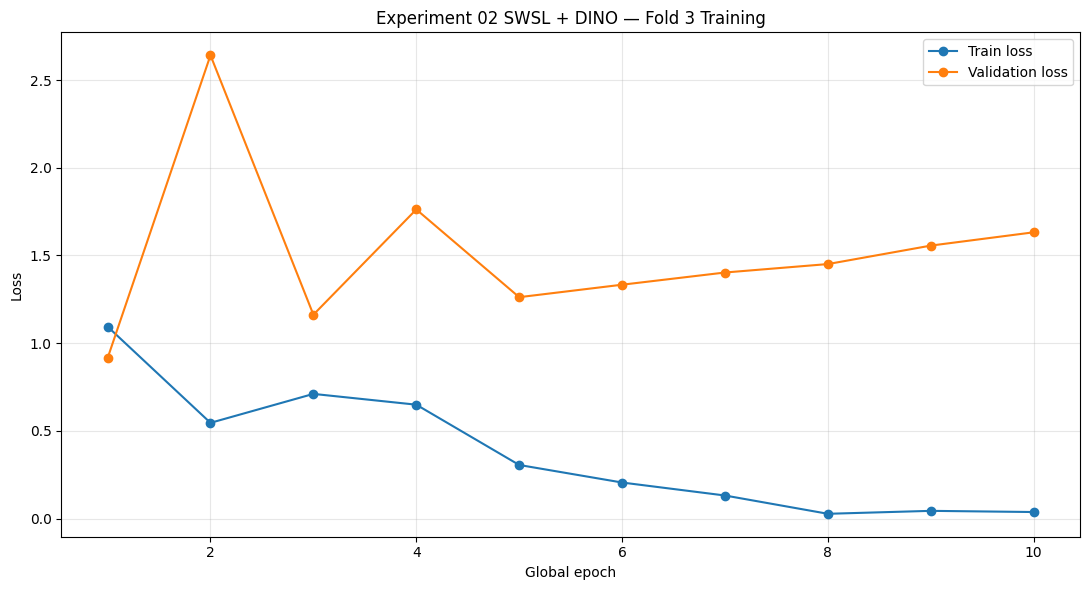

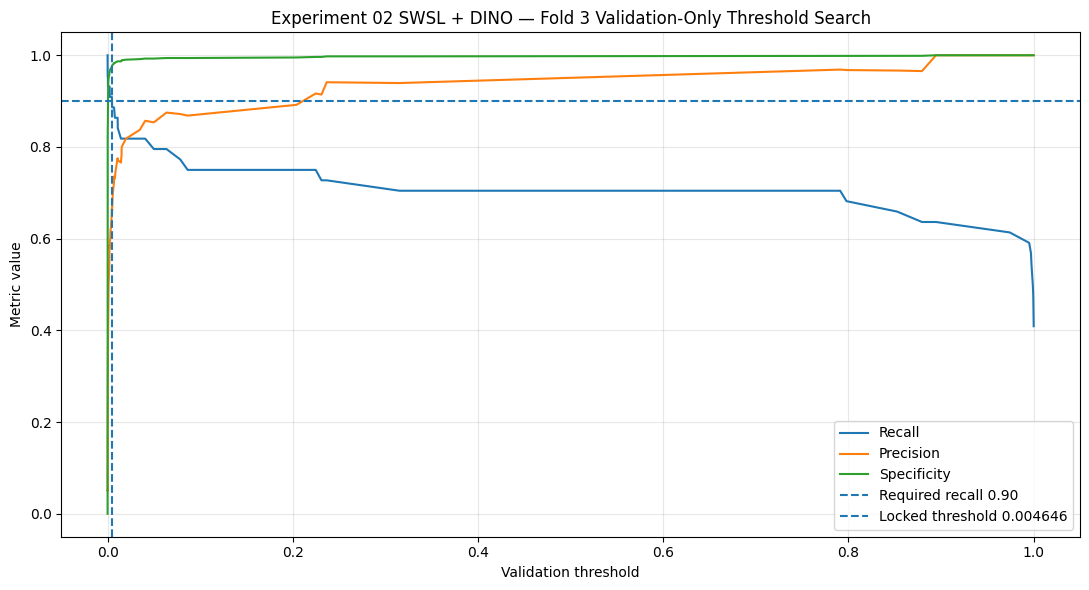


Experiment 02 Fold 3 training history:


,fold,stage,stage_epoch,global_epoch,train_loss,validation_loss,validation_auprc,validation_auroc,learning_rate_backbone,learning_rate_head
0,3,stage_1,1,1,1.094179,0.914159,0.638559,0.882635,0.000000e+00,0.001000
1,3,stage_1,2,2,0.545517,2.641369,0.688668,0.893300,0.000000e+00,0.000750
2,3,stage_1,3,3,0.710533,1.162114,0.731181,0.907926,0.000000e+00,0.000250
3,3,stage_2,1,4,0.649032,1.762261,0.773978,0.930749,1.000000e-05,0.000100
4,3,stage_2,2,5,0.305286,1.262006,0.856697,0.956369,9.504844e-06,0.000095
5,3,stage_2,3,6,0.205224,1.333127,0.882073,0.960563,8.117449e-06,0.000081
6,3,stage_2,4,7,0.131203,1.402658,0.894066,0.962455,6.112605e-06,0.000061
7,3,stage_2,5,8,0.026918,1.450812,0.892246,0.963524,3.887395e-06,0.000039
8,3,stage_2,6,9,0.043708,1.556079,0.893926,0.963030,1.882551e-06,0.000019
9,3,stage_2,7,10,0.036978,1.631926,0.895117,0.963373,4.951557e-07,0.000005



Experiment 02 Fold 3 locked metrics:


,experiment_id,experiment_name,source_checkpoint,fold,best_stage,best_stage_epoch,best_global_epoch,selection_mode,threshold,recall,...,balanced_accuracy,f1,tp,tn,fp,fn,auprc,auroc,held_out_test_loaded,held_out_test_evaluated
0,exp02_swsl_dino_fold_3,experiment_02_swsl_gastronet5m_dinov1,RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth,3,stage_2,7,10,overall_recall_0.90_and_minimum_centre_recall_...,0.004646,0.909091,...,0.942483,0.769231,40,809,20,4,0.895117,0.963373,False,False



Experiment 02 Fold 3 per-centre metrics:


,experiment_id,experiment_name,fold,center,sample_count,normal_count,positive_count,threshold,recall,precision,...,npv,accuracy,balanced_accuracy,f1,tp,tn,fp,fn,auprc,auroc
0,exp02_swsl_dino_fold_3,experiment_02_swsl_gastronet5m_dinov1,3,center_1,645,628,17,0.004646,0.823529,0.608696,...,0.995177,0.981395,0.904599,0.7000,14,619,9,3,0.787458,0.917806
1,exp02_swsl_dino_fold_3,experiment_02_swsl_gastronet5m_dinov1,3,center_2,228,201,27,0.004646,0.962963,0.702703,...,0.994764,0.947368,0.954118,0.8125,26,190,11,1,0.959863,0.993367



FINAL CELL 13D EXPERIMENT 02 FOLD 3 REPORT
Source checkpoint: RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth
Best stage: stage_2
Best stage epoch: 7
Best global epoch: 10
Validation AUPRC: 0.895117
Validation AUROC: 0.963373
Locked threshold: 0.004646301270
Validation recall: 0.909091
Validation PPV: 0.666667
Validation specificity: 0.975875
TP: 40
FP: 20
FN: 4
TN: 809

Held-out test loaded: False
Held-out test evaluated: False
Held-out test used for model selection: False
Held-out test used for threshold selection: False

STATUS: EXP02_SWSL_DINO_FOLD_3_TRAINING_AND_THRESHOLD_LOCK_COMPLETE

Saved records:
/content/drive/MyDrive/RARE26_GastroNet_Weights/models/cross_validation/experiment_02_swsl_gastronet5m_dinov1/fold_3/exp02_swsl_dino_fold_3_best.pth
/content/drive/MyDrive/RARE26_GastroNet_Weights/logs/cross_validation/experiment_02_swsl_gastronet5m_dinov1/fold_3/exp02_swsl_dino_fold_3_training_history.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/cross_validatio

In [ ]:
# ============================================================
# RARE26 GASTRONET EXTENSION — CELL 13D
# EXPERIMENT 02: SWSL + GASTRONET-5M DINOv1
# CROSS-VALIDATION FOLD 3
#
# Second pretrained checkpoint:
# RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth
#
# Uses only Fold-3 train and validation data.
# Held-out test is NOT loaded or evaluated.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display

import gc
import json
import os
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)


# ============================================================
# 1. FREE PREVIOUS FOLD OBJECTS FROM MEMORY
# ============================================================

objects_to_remove = [
    "model",
    "train_loader",
    "validation_loader",
    "train_dataset",
    "validation_dataset",
    "optimizer_stage_1",
    "optimizer_stage_2",
    "scheduler_stage_1",
    "scheduler_stage_2",
    "criterion",
    "scaler",
]

for object_name in objects_to_remove:
    if object_name in globals():
        del globals()[object_name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ============================================================
# 2. FIXED EXPERIMENT CONFIGURATION
# ============================================================

FOLD_NUMBER = 3
SEED = 42

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

SOURCE_CHECKPOINT_NAME = (
    "RN50_Billion-Scale-SWSL%2B"
    "GastroNet-5M_DINOv1.pth"
)

SOURCE_CHECKPOINT_PATH = (
    PROJECT_ROOT
    / "source_checkpoints"
    / SOURCE_CHECKPOINT_NAME
)

EXPERIMENT_NAME = (
    "experiment_02_swsl_gastronet5m_dinov1"
)

EXPERIMENT_ID = (
    "exp02_swsl_dino_fold_3"
)

FINAL_STATUS = (
    "EXP02_SWSL_DINO_FOLD_3_"
    "TRAINING_AND_THRESHOLD_LOCK_COMPLETE"
)


# ============================================================
# 3. FOLD-3 INPUT FILES
# ============================================================

FOLD_SPLIT_DIR = (
    PROJECT_ROOT
    / "configs"
    / "cross_validation"
    / "fold_3"
)

TRAIN_CSV = (
    FOLD_SPLIT_DIR
    / "fold_3_train_runtime.csv"
)

VALIDATION_CSV = (
    FOLD_SPLIT_DIR
    / "fold_3_validation_runtime.csv"
)


# ============================================================
# 4. SEPARATE EXPERIMENT-02 FOLD-3 OUTPUT DIRECTORIES
# ============================================================

MODEL_DIR = (
    PROJECT_ROOT
    / "models"
    / "cross_validation"
    / EXPERIMENT_NAME
    / "fold_3"
)

LOG_DIR = (
    PROJECT_ROOT
    / "logs"
    / "cross_validation"
    / EXPERIMENT_NAME
    / "fold_3"
)

PREDICTION_DIR = (
    PROJECT_ROOT
    / "predictions"
    / "cross_validation"
    / EXPERIMENT_NAME
    / "fold_3"
)

RESULT_DIR = (
    PROJECT_ROOT
    / "results"
    / "cross_validation"
    / EXPERIMENT_NAME
    / "fold_3"
)

THRESHOLD_DIR = (
    PROJECT_ROOT
    / "thresholds"
    / "cross_validation"
    / EXPERIMENT_NAME
    / "fold_3"
)

CENTRE_DIR = (
    PROJECT_ROOT
    / "centre_analysis"
    / "cross_validation"
    / EXPERIMENT_NAME
    / "fold_3"
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "figures"
    / "cross_validation"
    / EXPERIMENT_NAME
    / "fold_3"
)

for directory in [
    MODEL_DIR,
    LOG_DIR,
    PREDICTION_DIR,
    RESULT_DIR,
    THRESHOLD_DIR,
    CENTRE_DIR,
    FIGURE_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 5. OUTPUT FILE PATHS
# ============================================================

BEST_CHECKPOINT_PATH = (
    MODEL_DIR
    / f"{EXPERIMENT_ID}_best.pth"
)

LATEST_CHECKPOINT_PATH = (
    MODEL_DIR
    / f"{EXPERIMENT_ID}_latest.pth"
)

HISTORY_PATH = (
    LOG_DIR
    / f"{EXPERIMENT_ID}_training_history.csv"
)

RAW_PREDICTIONS_PATH = (
    PREDICTION_DIR
    / f"{EXPERIMENT_ID}_validation_predictions.csv"
)

LOCKED_PREDICTIONS_PATH = (
    PREDICTION_DIR
    / (
        f"{EXPERIMENT_ID}_validation_predictions_"
        "locked_threshold.csv"
    )
)

METRICS_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_validation_metrics.csv"
)

THRESHOLD_SEARCH_PATH = (
    THRESHOLD_DIR
    / f"{EXPERIMENT_ID}_validation_threshold_search.csv"
)

THRESHOLD_OPERATING_POINT_PATH = (
    THRESHOLD_DIR
    / f"{EXPERIMENT_ID}_validation_operating_point.csv"
)

THRESHOLD_LOCK_PATH = (
    THRESHOLD_DIR
    / f"{EXPERIMENT_ID}_threshold_lock.json"
)

CENTRE_METRICS_PATH = (
    CENTRE_DIR
    / f"{EXPERIMENT_ID}_validation_per_centre_metrics.csv"
)

TRAINING_FIGURE_PATH = (
    FIGURE_DIR
    / f"{EXPERIMENT_ID}_training_curves.png"
)

THRESHOLD_FIGURE_PATH = (
    FIGURE_DIR
    / f"{EXPERIMENT_ID}_threshold_analysis.png"
)

CONFIG_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_configuration.json"
)

STATUS_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_status.json"
)

SUMMARY_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_summary.txt"
)


# ============================================================
# 6. INITIAL SAFETY CHECKS
# ============================================================

print("=" * 88)
print("CELL 13D: EXPERIMENT 02 SWSL + DINO — FOLD 3")
print("=" * 88)

print("\nExperiment 02 checkpoint:")
print(SOURCE_CHECKPOINT_PATH)

print("\nFold 3 files:")
print(TRAIN_CSV)
print(VALIDATION_CSV)

if STATUS_PATH.exists():

    try:
        existing_status = json.loads(
            STATUS_PATH.read_text(
                encoding="utf-8"
            )
        )

        if existing_status.get("status") == FINAL_STATUS:

            raise FileExistsError(
                "Experiment 02 Fold 3 pehle hi complete hai.\n"
                f"Status file:\n{STATUS_PATH}"
            )

    except json.JSONDecodeError:
        pass


for required_file in [
    SOURCE_CHECKPOINT_PATH,
    TRAIN_CSV,
    VALIDATION_CSV,
]:

    if not required_file.exists():

        raise FileNotFoundError(
            f"Required file nahi mili:\n"
            f"{required_file}\n\n"
            "Drive mount, Cell 3B aur Cell 11A check karo."
        )


if not torch.cuda.is_available():

    raise RuntimeError(
        "GPU active nahi hai.\n"
        "Runtime → Change runtime type → T4 GPU select karo."
    )


device = torch.device("cuda")

gc.collect()
torch.cuda.empty_cache()

print("\nCompute device:")
print(device)
print(torch.cuda.get_device_name(0))

print(
    f"\nCheckpoint size: "
    f"{SOURCE_CHECKPOINT_PATH.stat().st_size / (1024 ** 2):.3f} MB"
)

print("\nHeld-out test CSV loaded: False")
print("Held-out test evaluated: False")
print("Held-out test used for any decision: False")


# ============================================================
# 7. REPRODUCIBILITY
# ============================================================

def set_all_seeds(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_all_seeds(SEED)

torch.set_float32_matmul_precision(
    "high"
)


# ============================================================
# 8. LOAD AND VERIFY FOLD-3 DATA
# ============================================================

train_df = pd.read_csv(
    TRAIN_CSV,
    low_memory=False,
).copy()

validation_df = pd.read_csv(
    VALIDATION_CSV,
    low_memory=False,
).copy()


required_columns = {
    "relative_path",
    "runtime_path",
    "label",
    "center",
    "class",
    "sha256",
    "cv_case_id",
    "cv_fold",
    "cv_role",
}


for dataframe_name, dataframe in [
    ("Fold 3 train", train_df),
    ("Fold 3 validation", validation_df),
]:

    missing_columns = (
        required_columns
        - set(dataframe.columns)
    )

    if missing_columns:

        raise RuntimeError(
            f"{dataframe_name} mein columns missing hain:\n"
            f"{sorted(missing_columns)}"
        )


train_df["label"] = (
    train_df["label"].astype(int)
)

validation_df["label"] = (
    validation_df["label"].astype(int)
)

train_df["cv_fold"] = (
    train_df["cv_fold"].astype(int)
)

validation_df["cv_fold"] = (
    validation_df["cv_fold"].astype(int)
)


if set(train_df["cv_fold"].unique()) != {3}:

    raise RuntimeError(
        "Training CSV Fold 3 ki nahi hai."
    )


if set(validation_df["cv_fold"].unique()) != {3}:

    raise RuntimeError(
        "Validation CSV Fold 3 ki nahi hai."
    )


if len(train_df) != 1747:

    raise RuntimeError(
        f"Fold 3 train expected 1747 records, "
        f"actual {len(train_df)}."
    )


if len(validation_df) != 873:

    raise RuntimeError(
        f"Fold 3 validation expected 873 records, "
        f"actual {len(validation_df)}."
    )


train_normal = int(
    (train_df["label"] == 0).sum()
)

train_positive = int(
    (train_df["label"] == 1).sum()
)

validation_normal = int(
    (validation_df["label"] == 0).sum()
)

validation_positive = int(
    (validation_df["label"] == 1).sum()
)


if (
    train_normal != 1659
    or train_positive != 88
):

    raise RuntimeError(
        "Fold 3 training class counts incorrect hain."
    )


if (
    validation_normal != 829
    or validation_positive != 44
):

    raise RuntimeError(
        "Fold 3 validation class counts incorrect hain."
    )


train_case_ids = set(
    train_df["cv_case_id"]
)

validation_case_ids = set(
    validation_df["cv_case_id"]
)

overlap_count = len(
    train_case_ids
    & validation_case_ids
)


if overlap_count != 0:

    raise RuntimeError(
        f"Fold 3 train/validation overlap: {overlap_count}"
    )


for dataframe_name, dataframe in [
    ("Fold 3 train", train_df),
    ("Fold 3 validation", validation_df),
]:

    missing_image_count = int(
        (
            ~dataframe[
                "runtime_path"
            ].apply(
                lambda value: (
                    Path(str(value)).exists()
                    and Path(str(value)).is_file()
                )
            )
        ).sum()
    )

    if missing_image_count > 0:

        raise FileNotFoundError(
            f"{dataframe_name} mein "
            f"{missing_image_count} runtime images missing hain.\n"
            "Cell 3B dobara run karo."
        )


print("\nFold 3 data verified:")

print(
    f"Train: {len(train_df)} "
    f"(normal={train_normal}, NEO={train_positive})"
)

print(
    f"Validation: {len(validation_df)} "
    f"(normal={validation_normal}, NEO={validation_positive})"
)

print(
    f"Train/validation overlap: {overlap_count}"
)


# ============================================================
# 9. IMAGE TRANSFORMS
# ============================================================

IMAGE_SIZE = 224
RESIZE_SIZE = 256

IMAGENET_MEAN = (
    0.485,
    0.456,
    0.406,
)

IMAGENET_STD = (
    0.229,
    0.224,
    0.225,
)

ROTATION_FILL = tuple(
    int(value * 255)
    for value in IMAGENET_MEAN
)


train_transform = transforms.Compose(
    [
        transforms.Resize(
            RESIZE_SIZE
        ),

        transforms.RandomResizedCrop(
            IMAGE_SIZE,
            scale=(0.85, 1.00),
            ratio=(0.90, 1.10),
        ),

        transforms.RandomHorizontalFlip(
            p=0.5
        ),

        transforms.RandomRotation(
            degrees=8,
            fill=ROTATION_FILL,
        ),

        transforms.ColorJitter(
            brightness=0.10,
            contrast=0.10,
            saturation=0.05,
            hue=0.02,
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)


validation_transform = transforms.Compose(
    [
        transforms.Resize(
            RESIZE_SIZE
        ),

        transforms.CenterCrop(
            IMAGE_SIZE
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)


# ============================================================
# 10. DATASET CLASS
# ============================================================

class RARE26ExperimentDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform,
    ):

        self.dataframe = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.transform = transform


    def __len__(self):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        index,
    ):

        row = self.dataframe.iloc[
            index
        ]

        image_path = Path(
            str(row["runtime_path"])
        )

        with Image.open(
            image_path
        ) as image:

            image = image.convert(
                "RGB"
            )

        image = self.transform(
            image
        )

        return {
            "image": image,

            "label": torch.tensor(
                int(row["label"]),
                dtype=torch.float32,
            ),

            "dataset_index": int(
                index
            ),

            "relative_path": str(
                row["relative_path"]
            ),

            "runtime_path": str(
                row["runtime_path"]
            ),

            "center": str(
                row["center"]
            ),

            "class_name": str(
                row["class"]
            ),

            "sha256": str(
                row["sha256"]
            ),

            "cv_case_id": str(
                row["cv_case_id"]
            ),
        }


train_dataset = RARE26ExperimentDataset(
    train_df,
    train_transform,
)

validation_dataset = RARE26ExperimentDataset(
    validation_df,
    validation_transform,
)


# ============================================================
# 11. DATA LOADERS
# ============================================================

BATCH_SIZE = 32
NUM_WORKERS = 2


def seed_worker(worker_id):

    worker_seed = (
        torch.initial_seed()
        % (2 ** 32)
    )

    np.random.seed(
        worker_seed
    )

    random.seed(
        worker_seed
    )


loader_generator = torch.Generator()

loader_generator.manual_seed(
    SEED
)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False,
    worker_init_fn=seed_worker,
    generator=loader_generator,
    persistent_workers=(
        NUM_WORKERS > 0
    ),
)


validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False,
    worker_init_fn=seed_worker,
    persistent_workers=(
        NUM_WORKERS > 0
    ),
)


print("\nData loaders:")

print(
    f"Train batches: "
    f"{len(train_loader)}"
)

print(
    f"Validation batches: "
    f"{len(validation_loader)}"
)


# ============================================================
# 12. CHECKPOINT HELPER FUNCTIONS
# ============================================================

def extract_state_dict(
    checkpoint_object,
):

    if isinstance(
        checkpoint_object,
        dict,
    ):

        for possible_key in [
            "state_dict",
            "model_state_dict",
            "model",
            "encoder",
            "backbone",
        ]:

            if (
                possible_key in checkpoint_object
                and isinstance(
                    checkpoint_object[
                        possible_key
                    ],
                    dict,
                )
            ):

                return checkpoint_object[
                    possible_key
                ]


        if all(
            torch.is_tensor(value)
            for value
            in checkpoint_object.values()
        ):

            return checkpoint_object


    raise RuntimeError(
        "Checkpoint ke andar model state dictionary identify nahi hui."
    )


def remove_uniform_prefix(
    state_dictionary,
    prefix,
):

    keys = list(
        state_dictionary.keys()
    )

    if (
        keys
        and all(
            key.startswith(prefix)
            for key in keys
        )
    ):

        return {
            key[len(prefix):]: value
            for key, value
            in state_dictionary.items()
        }

    return state_dictionary


# ============================================================
# 13. LOAD SECOND PRETRAINED RESNET-50
# ============================================================

checkpoint_object = torch.load(
    SOURCE_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

pretrained_state = extract_state_dict(
    checkpoint_object
)


for prefix in [
    "module.",
    "model.",
    "backbone.",
    "encoder.",
]:

    pretrained_state = remove_uniform_prefix(
        pretrained_state,
        prefix,
    )


model = models.resnet50(
    weights=None
)

load_result = model.load_state_dict(
    pretrained_state,
    strict=False,
)

expected_missing_keys = {
    "fc.weight",
    "fc.bias",
}


if set(
    load_result.missing_keys
) != expected_missing_keys:

    raise RuntimeError(
        "Unexpected missing model parameters:\n"
        f"{load_result.missing_keys}"
    )


if load_result.unexpected_keys:

    raise RuntimeError(
        "Unexpected checkpoint parameters:\n"
        f"{load_result.unexpected_keys}"
    )


classification_features = (
    model.fc.in_features
)

model.fc = nn.Linear(
    classification_features,
    1,
)

model = model.to(
    device
)


print(
    "\nSecond pretrained SWSL + GastroNet-DINO "
    "backbone loaded:"
)

print(
    f"Missing parameters: "
    f"{load_result.missing_keys}"
)

print(
    f"Unexpected parameters: "
    f"{load_result.unexpected_keys}"
)

print(
    f"New classification head: "
    f"Linear({classification_features}, 1)"
)


del checkpoint_object
del pretrained_state

gc.collect()


# ============================================================
# 14. LOCKED TRAINING PROTOCOL
# ============================================================

POS_WEIGHT = (
    train_normal
    / train_positive
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [POS_WEIGHT],
        dtype=torch.float32,
        device=device,
    )
)


STAGE_1_EPOCHS = 3
STAGE_1_LR = 1e-3

STAGE_2_MAX_EPOCHS = 7
STAGE_2_BACKBONE_LR = 1e-5
STAGE_2_HEAD_LR = 1e-4

WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 3
GRADIENT_CLIP_NORM = 1.0

AMP_ENABLED = True


try:

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=AMP_ENABLED,
    )

except Exception:

    scaler = torch.cuda.amp.GradScaler(
        enabled=AMP_ENABLED,
    )


print("\nLocked Experiment 02 Fold 3 protocol:")

print(
    f"Positive weight: "
    f"{POS_WEIGHT:.6f}"
)

print(
    "Stage 1: classification head only, 3 epochs"
)

print(
    "Stage 2: layer4 + classification head, maximum 7 epochs"
)

print(
    "Checkpoint selection: Fold-3 validation AUPRC"
)

print(
    "Threshold selection: Fold-3 validation predictions only"
)


# ============================================================
# 15. METRIC FUNCTION
# ============================================================

def calculate_binary_metrics(
    labels,
    probabilities,
    threshold,
):

    labels = np.asarray(
        labels,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    predictions = (
        probabilities
        >= threshold
    ).astype(int)


    tp = int(
        (
            (labels == 1)
            & (predictions == 1)
        ).sum()
    )

    tn = int(
        (
            (labels == 0)
            & (predictions == 0)
        ).sum()
    )

    fp = int(
        (
            (labels == 0)
            & (predictions == 1)
        ).sum()
    )

    fn = int(
        (
            (labels == 1)
            & (predictions == 0)
        ).sum()
    )


    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0.0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    npv = (
        tn / (tn + fn)
        if (tn + fn) > 0
        else np.nan
    )

    accuracy = (
        (tp + tn)
        / len(labels)
    )

    balanced_accuracy = (
        recall + specificity
    ) / 2

    f1 = (
        2 * precision * recall
        / (precision + recall)
        if (precision + recall) > 0
        else 0.0
    )


    return {
        "threshold": float(
            threshold
        ),

        "recall": float(
            recall
        ),

        "precision": float(
            precision
        ),

        "specificity": float(
            specificity
        ),

        "npv": float(
            npv
        ),

        "accuracy": float(
            accuracy
        ),

        "balanced_accuracy": float(
            balanced_accuracy
        ),

        "f1": float(
            f1
        ),

        "tp": tp,
        "tn": tn,
        "fp": fp,
        "fn": fn,
    }


# ============================================================
# 16. TRAINING FUNCTION
# ============================================================

def train_one_epoch(
    optimizer,
):

    model.train()

    total_loss = 0.0
    total_samples = 0

    progress_bar = tqdm(
        train_loader,
        leave=False,
        desc="Training",
    )


    for batch in progress_bar:

        images = batch["image"].to(
            device,
            non_blocking=True,
        )

        labels = batch["label"].to(
            device,
            non_blocking=True,
        )

        optimizer.zero_grad(
            set_to_none=True
        )


        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=AMP_ENABLED,
        ):

            logits = model(
                images
            ).squeeze(1)

            loss = criterion(
                logits,
                labels,
            )


        scaler.scale(
            loss
        ).backward()

        scaler.unscale_(
            optimizer
        )

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRADIENT_CLIP_NORM,
        )

        scaler.step(
            optimizer
        )

        scaler.update()


        batch_size = images.size(
            0
        )

        total_loss += (
            float(loss.item())
            * batch_size
        )

        total_samples += (
            batch_size
        )

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )


    return (
        total_loss
        / total_samples
    )


# ============================================================
# 17. VALIDATION FUNCTION
# ============================================================

@torch.no_grad()
def evaluate_validation(
    collect_records=False,
):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_labels = []
    all_probabilities = []
    all_logits = []

    records = []


    for batch in tqdm(
        validation_loader,
        leave=False,
        desc="Validation",
    ):

        images = batch["image"].to(
            device,
            non_blocking=True,
        )

        labels = batch["label"].to(
            device,
            non_blocking=True,
        )


        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=AMP_ENABLED,
        ):

            logits = model(
                images
            ).squeeze(1)

            loss = criterion(
                logits,
                labels,
            )


        probabilities = torch.sigmoid(
            logits
        )


        labels_numpy = (
            labels.detach()
            .cpu()
            .numpy()
            .astype(int)
        )

        probabilities_numpy = (
            probabilities.detach()
            .cpu()
            .float()
            .numpy()
        )

        logits_numpy = (
            logits.detach()
            .cpu()
            .float()
            .numpy()
        )


        batch_size = images.size(
            0
        )

        total_loss += (
            float(loss.item())
            * batch_size
        )

        total_samples += (
            batch_size
        )


        all_labels.extend(
            labels_numpy.tolist()
        )

        all_probabilities.extend(
            probabilities_numpy.tolist()
        )

        all_logits.extend(
            logits_numpy.tolist()
        )


        if collect_records:

            for item_index in range(
                batch_size
            ):

                records.append(
                    {
                        "dataset_index": int(
                            batch[
                                "dataset_index"
                            ][item_index]
                        ),

                        "relative_path": (
                            batch[
                                "relative_path"
                            ][item_index]
                        ),

                        "runtime_path": (
                            batch[
                                "runtime_path"
                            ][item_index]
                        ),

                        "center": (
                            batch[
                                "center"
                            ][item_index]
                        ),

                        "class_name": (
                            batch[
                                "class_name"
                            ][item_index]
                        ),

                        "sha256": (
                            batch[
                                "sha256"
                            ][item_index]
                        ),

                        "cv_case_id": (
                            batch[
                                "cv_case_id"
                            ][item_index]
                        ),

                        "label": int(
                            labels_numpy[
                                item_index
                            ]
                        ),

                        "logit": float(
                            logits_numpy[
                                item_index
                            ]
                        ),

                        "probability": float(
                            probabilities_numpy[
                                item_index
                            ]
                        ),
                    }
                )


    labels_array = np.asarray(
        all_labels,
        dtype=int,
    )

    probabilities_array = np.asarray(
        all_probabilities,
        dtype=float,
    )


    return {
        "loss": (
            total_loss
            / total_samples
        ),

        "auprc": float(
            average_precision_score(
                labels_array,
                probabilities_array,
            )
        ),

        "auroc": float(
            roc_auc_score(
                labels_array,
                probabilities_array,
            )
        ),

        "labels": labels_array,

        "probabilities": (
            probabilities_array
        ),

        "logits": np.asarray(
            all_logits,
            dtype=float,
        ),

        "records": records,
    }


# ============================================================
# 18. CHECKPOINT SAVE FUNCTION
# ============================================================

def save_checkpoint(
    destination_path,
    stage_name,
    stage_epoch,
    global_epoch,
    validation_result,
    optimizer,
    scheduler,
):

    temporary_path = Path(
        str(destination_path)
        + ".tmp"
    )


    checkpoint_record = {
        "experiment_id": (
            EXPERIMENT_ID
        ),

        "experiment_name": (
            EXPERIMENT_NAME
        ),

        "fold": (
            FOLD_NUMBER
        ),

        "stage": (
            stage_name
        ),

        "stage_epoch": int(
            stage_epoch
        ),

        "global_epoch": int(
            global_epoch
        ),

        "model_state_dict": (
            model.state_dict()
        ),

        "optimizer_state_dict": (
            optimizer.state_dict()
        ),

        "scheduler_state_dict": (
            scheduler.state_dict()
        ),

        "validation_metrics": {
            "validation_loss": float(
                validation_result[
                    "loss"
                ]
            ),

            "validation_auprc": float(
                validation_result[
                    "auprc"
                ]
            ),

            "validation_auroc": float(
                validation_result[
                    "auroc"
                ]
            ),
        },

        "source_pretrained_checkpoint": str(
            SOURCE_CHECKPOINT_PATH
        ),

        "held_out_test_loaded": False,

        "held_out_test_evaluated": False,
    }


    torch.save(
        checkpoint_record,
        temporary_path,
    )

    os.replace(
        temporary_path,
        destination_path,
    )


# ============================================================
# 19. TRAINING LOOP
# ============================================================

training_history = []

global_epoch = 0

best_global_auprc = (
    -np.inf
)

training_start_time = (
    time.time()
)


# ------------------------------------------------------------
# STAGE 1: CLASSIFICATION HEAD ONLY
# ------------------------------------------------------------

for parameter in model.parameters():

    parameter.requires_grad = False


for parameter in model.fc.parameters():

    parameter.requires_grad = True


optimizer_stage_1 = torch.optim.AdamW(
    model.fc.parameters(),
    lr=STAGE_1_LR,
    weight_decay=WEIGHT_DECAY,
)


scheduler_stage_1 = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer_stage_1,
        T_max=STAGE_1_EPOCHS,
    )
)


print("\n" + "-" * 88)
print("STAGE 1: CLASSIFICATION HEAD ONLY")
print("-" * 88)


for stage_epoch in range(
    1,
    STAGE_1_EPOCHS + 1,
):

    global_epoch += 1

    train_loss = train_one_epoch(
        optimizer_stage_1
    )

    validation_result = (
        evaluate_validation()
    )


    training_history.append(
        {
            "fold": (
                FOLD_NUMBER
            ),

            "stage": (
                "stage_1"
            ),

            "stage_epoch": (
                stage_epoch
            ),

            "global_epoch": (
                global_epoch
            ),

            "train_loss": (
                train_loss
            ),

            "validation_loss": (
                validation_result[
                    "loss"
                ]
            ),

            "validation_auprc": (
                validation_result[
                    "auprc"
                ]
            ),

            "validation_auroc": (
                validation_result[
                    "auroc"
                ]
            ),

            "learning_rate_backbone": (
                0.0
            ),

            "learning_rate_head": (
                optimizer_stage_1
                .param_groups[0]["lr"]
            ),
        }
    )


    print(
        f"Stage 1 | Epoch {stage_epoch}/3 | "
        f"Train loss {train_loss:.6f} | "
        f"Val loss {validation_result['loss']:.6f} | "
        f"AUPRC {validation_result['auprc']:.6f} | "
        f"AUROC {validation_result['auroc']:.6f}"
    )


    save_checkpoint(
        LATEST_CHECKPOINT_PATH,
        "stage_1",
        stage_epoch,
        global_epoch,
        validation_result,
        optimizer_stage_1,
        scheduler_stage_1,
    )


    if (
        validation_result["auprc"]
        > best_global_auprc
    ):

        best_global_auprc = (
            validation_result[
                "auprc"
            ]
        )

        save_checkpoint(
            BEST_CHECKPOINT_PATH,
            "stage_1",
            stage_epoch,
            global_epoch,
            validation_result,
            optimizer_stage_1,
            scheduler_stage_1,
        )


    scheduler_stage_1.step()


# ------------------------------------------------------------
# STAGE 2: LAYER4 + CLASSIFICATION HEAD
# ------------------------------------------------------------

for parameter in model.parameters():

    parameter.requires_grad = False


for parameter in model.layer4.parameters():

    parameter.requires_grad = True


for parameter in model.fc.parameters():

    parameter.requires_grad = True


optimizer_stage_2 = torch.optim.AdamW(
    [
        {
            "params": (
                model.layer4.parameters()
            ),

            "lr": (
                STAGE_2_BACKBONE_LR
            ),
        },

        {
            "params": (
                model.fc.parameters()
            ),

            "lr": (
                STAGE_2_HEAD_LR
            ),
        },
    ],

    weight_decay=(
        WEIGHT_DECAY
    ),
)


scheduler_stage_2 = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer_stage_2,
        T_max=STAGE_2_MAX_EPOCHS,
    )
)


stage_2_best_auprc = (
    -np.inf
)

stage_2_no_improvement = (
    0
)


print("\n" + "-" * 88)
print("STAGE 2: LAYER4 AND CLASSIFICATION HEAD")
print("-" * 88)


for stage_epoch in range(
    1,
    STAGE_2_MAX_EPOCHS + 1,
):

    global_epoch += 1

    train_loss = train_one_epoch(
        optimizer_stage_2
    )

    validation_result = (
        evaluate_validation()
    )


    training_history.append(
        {
            "fold": (
                FOLD_NUMBER
            ),

            "stage": (
                "stage_2"
            ),

            "stage_epoch": (
                stage_epoch
            ),

            "global_epoch": (
                global_epoch
            ),

            "train_loss": (
                train_loss
            ),

            "validation_loss": (
                validation_result[
                    "loss"
                ]
            ),

            "validation_auprc": (
                validation_result[
                    "auprc"
                ]
            ),

            "validation_auroc": (
                validation_result[
                    "auroc"
                ]
            ),

            "learning_rate_backbone": (
                optimizer_stage_2
                .param_groups[0]["lr"]
            ),

            "learning_rate_head": (
                optimizer_stage_2
                .param_groups[1]["lr"]
            ),
        }
    )


    print(
        f"Stage 2 | Epoch {stage_epoch}/7 | "
        f"Global {global_epoch} | "
        f"Train loss {train_loss:.6f} | "
        f"Val loss {validation_result['loss']:.6f} | "
        f"AUPRC {validation_result['auprc']:.6f} | "
        f"AUROC {validation_result['auroc']:.6f}"
    )


    save_checkpoint(
        LATEST_CHECKPOINT_PATH,
        "stage_2",
        stage_epoch,
        global_epoch,
        validation_result,
        optimizer_stage_2,
        scheduler_stage_2,
    )


    if (
        validation_result["auprc"]
        > best_global_auprc
    ):

        best_global_auprc = (
            validation_result[
                "auprc"
            ]
        )

        save_checkpoint(
            BEST_CHECKPOINT_PATH,
            "stage_2",
            stage_epoch,
            global_epoch,
            validation_result,
            optimizer_stage_2,
            scheduler_stage_2,
        )


    if (
        validation_result["auprc"]
        > stage_2_best_auprc
    ):

        stage_2_best_auprc = (
            validation_result[
                "auprc"
            ]
        )

        stage_2_no_improvement = (
            0
        )

    else:

        stage_2_no_improvement += 1


    scheduler_stage_2.step()


    if (
        stage_2_no_improvement
        >= EARLY_STOPPING_PATIENCE
    ):

        print(
            "\nEarly stopping activated after "
            f"{EARLY_STOPPING_PATIENCE} consecutive "
            "Stage-2 epochs without AUPRC improvement."
        )

        break


training_duration_seconds = (
    time.time()
    - training_start_time
)


training_history_df = pd.DataFrame(
    training_history
)

training_history_df.to_csv(
    HISTORY_PATH,
    index=False,
)


# ============================================================
# 20. LOAD BEST FOLD-3 CHECKPOINT
# ============================================================

if not BEST_CHECKPOINT_PATH.exists():

    raise RuntimeError(
        "Best Experiment 02 Fold-3 checkpoint save nahi hua."
    )


best_checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False,
)


model.load_state_dict(
    best_checkpoint[
        "model_state_dict"
    ]
)

model.eval()


print("\nBest Experiment 02 Fold-3 checkpoint:")

print(
    f"Stage: "
    f"{best_checkpoint['stage']}"
)

print(
    f"Stage epoch: "
    f"{best_checkpoint['stage_epoch']}"
)

print(
    f"Global epoch: "
    f"{best_checkpoint['global_epoch']}"
)

print(
    "Validation AUPRC: "
    f"{best_checkpoint['validation_metrics']['validation_auprc']:.6f}"
)

print(
    "Validation AUROC: "
    f"{best_checkpoint['validation_metrics']['validation_auroc']:.6f}"
)


# ============================================================
# 21. FINAL VALIDATION PREDICTIONS
# ============================================================

final_validation_result = (
    evaluate_validation(
        collect_records=True
    )
)


predictions_df = (
    pd.DataFrame(
        final_validation_result[
            "records"
        ]
    )
    .sort_values(
        "dataset_index"
    )
    .reset_index(
        drop=True
    )
)


if len(predictions_df) != 873:

    raise RuntimeError(
        "Experiment 02 Fold 3 must produce "
        "exactly 873 validation predictions."
    )


if predictions_df["cv_case_id"].duplicated().any():

    raise RuntimeError(
        "Duplicate Fold-3 validation case IDs detected."
    )


predictions_df[
    "experiment_id"
] = EXPERIMENT_ID

predictions_df[
    "experiment_name"
] = EXPERIMENT_NAME

predictions_df[
    "fold"
] = FOLD_NUMBER

predictions_df[
    "source_checkpoint"
] = SOURCE_CHECKPOINT_NAME


predictions_df.to_csv(
    RAW_PREDICTIONS_PATH,
    index=False,
)


# ============================================================
# 22. VALIDATION-ONLY THRESHOLD SEARCH
# ============================================================

labels = predictions_df[
    "label"
].to_numpy(
    dtype=int
)

probabilities = predictions_df[
    "probability"
].to_numpy(
    dtype=float
)


candidate_thresholds = np.unique(
    np.concatenate(
        [
            np.array([0.0]),
            probabilities,
            np.array([1.0]),
        ]
    )
)


threshold_rows = []


for threshold in candidate_thresholds:

    overall_metrics = (
        calculate_binary_metrics(
            labels,
            probabilities,
            threshold,
        )
    )

    centre_recalls = {}


    for centre_name, centre_group in (
        predictions_df.groupby(
            "center"
        )
    ):

        centre_metrics = (
            calculate_binary_metrics(
                centre_group[
                    "label"
                ].to_numpy(
                    dtype=int
                ),

                centre_group[
                    "probability"
                ].to_numpy(
                    dtype=float
                ),

                threshold,
            )
        )

        centre_recalls[
            centre_name
        ] = centre_metrics[
            "recall"
        ]


    if set(centre_recalls.keys()) != {
        "center_1",
        "center_2",
    }:

        raise RuntimeError(
            "Expected center_1 and center_2 in Fold 3 validation."
        )


    minimum_centre_recall = float(
        min(
            centre_recalls.values()
        )
    )


    threshold_rows.append(
        {
            **overall_metrics,

            "center_1_recall": float(
                centre_recalls[
                    "center_1"
                ]
            ),

            "center_2_recall": float(
                centre_recalls[
                    "center_2"
                ]
            ),

            "minimum_centre_recall": (
                minimum_centre_recall
            ),

            "overall_recall_requirement_met": bool(
                overall_metrics[
                    "recall"
                ]
                >= 0.90
            ),

            "centre_recall_requirement_met": bool(
                minimum_centre_recall
                >= 0.80
            ),

            "strict_eligible": bool(
                overall_metrics[
                    "recall"
                ]
                >= 0.90

                and minimum_centre_recall
                >= 0.80
            ),
        }
    )


threshold_search_df = pd.DataFrame(
    threshold_rows
)


strict_eligible_df = (
    threshold_search_df[
        threshold_search_df[
            "strict_eligible"
        ]
    ].copy()
)


if not strict_eligible_df.empty:

    selection_mode = (
        "overall_recall_0.90_and_"
        "minimum_centre_recall_0.80"
    )

    eligible_df = (
        strict_eligible_df
    )

else:

    selection_mode = (
        "fallback_overall_recall_0.90"
    )

    eligible_df = (
        threshold_search_df[
            threshold_search_df[
                "overall_recall_requirement_met"
            ]
        ].copy()
    )


if eligible_df.empty:

    selection_mode = (
        "fallback_highest_recall"
    )

    maximum_recall = (
        threshold_search_df[
            "recall"
        ].max()
    )

    eligible_df = (
        threshold_search_df[
            threshold_search_df[
                "recall"
            ]
            == maximum_recall
        ].copy()
    )


selected_row = (
    eligible_df.sort_values(
        by=[
            "precision",
            "minimum_centre_recall",
            "specificity",
            "threshold",
        ],

        ascending=[
            False,
            False,
            False,
            False,
        ],
    )
    .iloc[0]
)


LOCKED_THRESHOLD = float(
    selected_row[
        "threshold"
    ]
)


threshold_search_df.to_csv(
    THRESHOLD_SEARCH_PATH,
    index=False,
)


pd.DataFrame(
    [
        selected_row.to_dict()
    ]
).to_csv(
    THRESHOLD_OPERATING_POINT_PATH,
    index=False,
)


# ============================================================
# 23. APPLY LOCKED THRESHOLD
# ============================================================

predictions_df[
    "locked_threshold"
] = LOCKED_THRESHOLD


predictions_df[
    "prediction"
] = (
    predictions_df[
        "probability"
    ]
    >= LOCKED_THRESHOLD
).astype(int)


predictions_df[
    "prediction_correct"
] = (
    predictions_df[
        "prediction"
    ]
    ==
    predictions_df[
        "label"
    ]
)


predictions_df[
    "error_type"
] = np.select(
    [
        (
            (predictions_df["label"] == 1)
            &
            (predictions_df["prediction"] == 1)
        ),

        (
            (predictions_df["label"] == 0)
            &
            (predictions_df["prediction"] == 0)
        ),

        (
            (predictions_df["label"] == 0)
            &
            (predictions_df["prediction"] == 1)
        ),
    ],

    [
        "TP",
        "TN",
        "FP",
    ],

    default="FN",
)


predictions_df.to_csv(
    LOCKED_PREDICTIONS_PATH,
    index=False,
)


# ============================================================
# 24. FINAL OVERALL METRICS
# ============================================================

overall_metrics = (
    calculate_binary_metrics(
        labels,
        probabilities,
        LOCKED_THRESHOLD,
    )
)


overall_metrics[
    "auprc"
] = float(
    average_precision_score(
        labels,
        probabilities,
    )
)


overall_metrics[
    "auroc"
] = float(
    roc_auc_score(
        labels,
        probabilities,
    )
)


metrics_df = pd.DataFrame(
    [
        {
            "experiment_id": (
                EXPERIMENT_ID
            ),

            "experiment_name": (
                EXPERIMENT_NAME
            ),

            "source_checkpoint": (
                SOURCE_CHECKPOINT_NAME
            ),

            "fold": (
                FOLD_NUMBER
            ),

            "best_stage": (
                best_checkpoint[
                    "stage"
                ]
            ),

            "best_stage_epoch": int(
                best_checkpoint[
                    "stage_epoch"
                ]
            ),

            "best_global_epoch": int(
                best_checkpoint[
                    "global_epoch"
                ]
            ),

            "selection_mode": (
                selection_mode
            ),

            **overall_metrics,

            "held_out_test_loaded": False,

            "held_out_test_evaluated": False,
        }
    ]
)


metrics_df.to_csv(
    METRICS_PATH,
    index=False,
)


# ============================================================
# 25. PER-CENTRE METRICS
# ============================================================

centre_metric_rows = []


for centre_name, centre_group in (
    predictions_df.groupby(
        "center"
    )
):

    centre_labels = (
        centre_group[
            "label"
        ].to_numpy(
            dtype=int
        )
    )

    centre_probabilities = (
        centre_group[
            "probability"
        ].to_numpy(
            dtype=float
        )
    )


    centre_metrics = (
        calculate_binary_metrics(
            centre_labels,
            centre_probabilities,
            LOCKED_THRESHOLD,
        )
    )


    centre_metrics[
        "auprc"
    ] = float(
        average_precision_score(
            centre_labels,
            centre_probabilities,
        )
    )


    centre_metrics[
        "auroc"
    ] = float(
        roc_auc_score(
            centre_labels,
            centre_probabilities,
        )
    )


    centre_metric_rows.append(
        {
            "experiment_id": (
                EXPERIMENT_ID
            ),

            "experiment_name": (
                EXPERIMENT_NAME
            ),

            "fold": (
                FOLD_NUMBER
            ),

            "center": (
                centre_name
            ),

            "sample_count": int(
                len(centre_group)
            ),

            "normal_count": int(
                (centre_labels == 0).sum()
            ),

            "positive_count": int(
                (centre_labels == 1).sum()
            ),

            **centre_metrics,
        }
    )


centre_metrics_df = pd.DataFrame(
    centre_metric_rows
)


centre_metrics_df.to_csv(
    CENTRE_METRICS_PATH,
    index=False,
)


# ============================================================
# 26. SAVE THRESHOLD LOCK
# ============================================================

threshold_lock_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": (
        "EXP02_SWSL_DINO_FOLD_3_"
        "VALIDATION_THRESHOLD_LOCKED"
    ),

    "experiment_id": (
        EXPERIMENT_ID
    ),

    "experiment_name": (
        EXPERIMENT_NAME
    ),

    "source_checkpoint": (
        SOURCE_CHECKPOINT_NAME
    ),

    "fold": (
        FOLD_NUMBER
    ),

    "selected_threshold": float(
        LOCKED_THRESHOLD
    ),

    "selection_mode": (
        selection_mode
    ),

    "validation_sample_count": int(
        len(predictions_df)
    ),

    "validation_normal_count": int(
        validation_normal
    ),

    "validation_positive_count": int(
        validation_positive
    ),

    "validation_auprc": float(
        overall_metrics[
            "auprc"
        ]
    ),

    "validation_auroc": float(
        overall_metrics[
            "auroc"
        ]
    ),

    "validation_recall": float(
        overall_metrics[
            "recall"
        ]
    ),

    "validation_precision": float(
        overall_metrics[
            "precision"
        ]
    ),

    "validation_specificity": float(
        overall_metrics[
            "specificity"
        ]
    ),

    "validation_tp": int(
        overall_metrics[
            "tp"
        ]
    ),

    "validation_tn": int(
        overall_metrics[
            "tn"
        ]
    ),

    "validation_fp": int(
        overall_metrics[
            "fp"
        ]
    ),

    "validation_fn": int(
        overall_metrics[
            "fn"
        ]
    ),

    "threshold_selected_from": (
        "experiment_02_fold_3_validation_only"
    ),

    "held_out_test_loaded": False,

    "held_out_test_evaluated": False,

    "held_out_test_used_for_threshold": False,
}


THRESHOLD_LOCK_PATH.write_text(
    json.dumps(
        threshold_lock_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ============================================================
# 27. SAVE CONFIGURATION AND STATUS
# ============================================================

configuration_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "experiment_id": (
        EXPERIMENT_ID
    ),

    "experiment_name": (
        EXPERIMENT_NAME
    ),

    "fold": (
        FOLD_NUMBER
    ),

    "random_seed": (
        SEED
    ),

    "source_pretrained_checkpoint": str(
        SOURCE_CHECKPOINT_PATH
    ),

    "train_csv": str(
        TRAIN_CSV
    ),

    "validation_csv": str(
        VALIDATION_CSV
    ),

    "train_sample_count": int(
        len(train_df)
    ),

    "validation_sample_count": int(
        len(validation_df)
    ),

    "image_size": (
        IMAGE_SIZE
    ),

    "resize_size": (
        RESIZE_SIZE
    ),

    "batch_size": (
        BATCH_SIZE
    ),

    "positive_weight": float(
        POS_WEIGHT
    ),

    "stage_1_epochs": (
        STAGE_1_EPOCHS
    ),

    "stage_1_learning_rate": (
        STAGE_1_LR
    ),

    "stage_2_max_epochs": (
        STAGE_2_MAX_EPOCHS
    ),

    "stage_2_backbone_learning_rate": (
        STAGE_2_BACKBONE_LR
    ),

    "stage_2_head_learning_rate": (
        STAGE_2_HEAD_LR
    ),

    "weight_decay": (
        WEIGHT_DECAY
    ),

    "early_stopping_patience": (
        EARLY_STOPPING_PATIENCE
    ),

    "checkpoint_selection_metric": (
        "fold_3_validation_auprc"
    ),

    "threshold_selection_source": (
        "fold_3_validation_predictions_only"
    ),

    "held_out_test_loaded": False,

    "held_out_test_evaluated": False,
}


CONFIG_PATH.write_text(
    json.dumps(
        configuration_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": (
        FINAL_STATUS
    ),

    "experiment_id": (
        EXPERIMENT_ID
    ),

    "experiment_name": (
        EXPERIMENT_NAME
    ),

    "source_checkpoint": (
        SOURCE_CHECKPOINT_NAME
    ),

    "fold": (
        FOLD_NUMBER
    ),

    "best_checkpoint_path": str(
        BEST_CHECKPOINT_PATH
    ),

    "best_stage": (
        best_checkpoint[
            "stage"
        ]
    ),

    "best_stage_epoch": int(
        best_checkpoint[
            "stage_epoch"
        ]
    ),

    "best_global_epoch": int(
        best_checkpoint[
            "global_epoch"
        ]
    ),

    "validation_auprc": float(
        overall_metrics[
            "auprc"
        ]
    ),

    "validation_auroc": float(
        overall_metrics[
            "auroc"
        ]
    ),

    "locked_threshold": float(
        LOCKED_THRESHOLD
    ),

    "training_duration_seconds": float(
        training_duration_seconds
    ),

    "held_out_test_loaded": False,

    "held_out_test_evaluated": False,

    "held_out_test_used_for_model_selection": False,

    "held_out_test_used_for_threshold_selection": False,
}


STATUS_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ============================================================
# 28. TRAINING CURVE FIGURE
# ============================================================

figure = plt.figure(
    figsize=(11, 6)
)


plt.plot(
    training_history_df[
        "global_epoch"
    ],

    training_history_df[
        "train_loss"
    ],

    marker="o",

    label="Train loss",
)


plt.plot(
    training_history_df[
        "global_epoch"
    ],

    training_history_df[
        "validation_loss"
    ],

    marker="o",

    label="Validation loss",
)


plt.xlabel(
    "Global epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Experiment 02 SWSL + DINO — Fold 3 Training"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()


figure.savefig(
    TRAINING_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)


plt.show()

plt.close(
    figure
)


# ============================================================
# 29. THRESHOLD ANALYSIS FIGURE
# ============================================================

figure = plt.figure(
    figsize=(11, 6)
)


plt.plot(
    threshold_search_df[
        "threshold"
    ],

    threshold_search_df[
        "recall"
    ],

    label="Recall",
)


plt.plot(
    threshold_search_df[
        "threshold"
    ],

    threshold_search_df[
        "precision"
    ],

    label="Precision",
)


plt.plot(
    threshold_search_df[
        "threshold"
    ],

    threshold_search_df[
        "specificity"
    ],

    label="Specificity",
)


plt.axhline(
    0.90,
    linestyle="--",
    label="Required recall 0.90",
)


plt.axvline(
    LOCKED_THRESHOLD,
    linestyle="--",
    label=(
        f"Locked threshold "
        f"{LOCKED_THRESHOLD:.6f}"
    ),
)


plt.xlabel(
    "Validation threshold"
)

plt.ylabel(
    "Metric value"
)

plt.title(
    "Experiment 02 SWSL + DINO — "
    "Fold 3 Validation-Only Threshold Search"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()


figure.savefig(
    THRESHOLD_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)


plt.show()

plt.close(
    figure
)


# ============================================================
# 30. SAVE READABLE SUMMARY
# ============================================================

summary_lines = [
    "RARE26 GastroNet Experiment 02",
    "SWSL + GastroNet-5M DINOv1 — Fold 3",
    "=" * 72,
    "",
    (
        f"Checkpoint: "
        f"{SOURCE_CHECKPOINT_NAME}"
    ),
    "",
    (
        f"Train images: "
        f"{len(train_df)}"
    ),
    (
        f"Validation images: "
        f"{len(validation_df)}"
    ),
    "",
    (
        f"Best stage: "
        f"{best_checkpoint['stage']}"
    ),
    (
        f"Best stage epoch: "
        f"{best_checkpoint['stage_epoch']}"
    ),
    (
        f"Best global epoch: "
        f"{best_checkpoint['global_epoch']}"
    ),
    "",
    (
        f"Validation AUPRC: "
        f"{overall_metrics['auprc']:.6f}"
    ),
    (
        f"Validation AUROC: "
        f"{overall_metrics['auroc']:.6f}"
    ),
    "",
    (
        f"Locked threshold: "
        f"{LOCKED_THRESHOLD:.12f}"
    ),
    (
        f"Recall: "
        f"{overall_metrics['recall']:.6f}"
    ),
    (
        f"PPV: "
        f"{overall_metrics['precision']:.6f}"
    ),
    (
        f"Specificity: "
        f"{overall_metrics['specificity']:.6f}"
    ),
    (
        f"TP / FP / FN / TN: "
        f"{overall_metrics['tp']} / "
        f"{overall_metrics['fp']} / "
        f"{overall_metrics['fn']} / "
        f"{overall_metrics['tn']}"
    ),
    "",
    "Held-out test loaded: No",
    "Held-out test evaluated: No",
    "",
    f"Status: {FINAL_STATUS}",
]


SUMMARY_PATH.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ============================================================
# 31. FINAL REPORT
# ============================================================

print(
    "\nExperiment 02 Fold 3 training history:"
)

display(
    training_history_df
)


print(
    "\nExperiment 02 Fold 3 locked metrics:"
)

display(
    metrics_df
)


print(
    "\nExperiment 02 Fold 3 per-centre metrics:"
)

display(
    centre_metrics_df
)


print("\n" + "=" * 88)
print("FINAL CELL 13D EXPERIMENT 02 FOLD 3 REPORT")
print("=" * 88)


print(
    f"Source checkpoint: "
    f"{SOURCE_CHECKPOINT_NAME}"
)

print(
    f"Best stage: "
    f"{best_checkpoint['stage']}"
)

print(
    f"Best stage epoch: "
    f"{best_checkpoint['stage_epoch']}"
)

print(
    f"Best global epoch: "
    f"{best_checkpoint['global_epoch']}"
)

print(
    f"Validation AUPRC: "
    f"{overall_metrics['auprc']:.6f}"
)

print(
    f"Validation AUROC: "
    f"{overall_metrics['auroc']:.6f}"
)

print(
    f"Locked threshold: "
    f"{LOCKED_THRESHOLD:.12f}"
)

print(
    f"Validation recall: "
    f"{overall_metrics['recall']:.6f}"
)

print(
    f"Validation PPV: "
    f"{overall_metrics['precision']:.6f}"
)

print(
    f"Validation specificity: "
    f"{overall_metrics['specificity']:.6f}"
)

print(
    f"TP: "
    f"{overall_metrics['tp']}"
)

print(
    f"FP: "
    f"{overall_metrics['fp']}"
)

print(
    f"FN: "
    f"{overall_metrics['fn']}"
)

print(
    f"TN: "
    f"{overall_metrics['tn']}"
)


print("\nHeld-out test loaded: False")
print("Held-out test evaluated: False")

print(
    "Held-out test used for model selection: False"
)

print(
    "Held-out test used for threshold selection: False"
)


print(
    f"\nSTATUS: "
    f"{FINAL_STATUS}"
)


print("\nSaved records:")

print(BEST_CHECKPOINT_PATH)
print(HISTORY_PATH)
print(RAW_PREDICTIONS_PATH)
print(LOCKED_PREDICTIONS_PATH)
print(METRICS_PATH)
print(THRESHOLD_SEARCH_PATH)
print(THRESHOLD_OPERATING_POINT_PATH)
print(THRESHOLD_LOCK_PATH)
print(CENTRE_METRICS_PATH)
print(TRAINING_FIGURE_PATH)
print(THRESHOLD_FIGURE_PATH)
print(CONFIG_PATH)
print(STATUS_PATH)
print(SUMMARY_PATH)


gc.collect()
torch.cuda.empty_cache()

CELL 13E: EXPERIMENT 02 THREE-FOLD AGGREGATE AND EXPERIMENT 01 COMPARISON

Experiment 01:
Experiment 01 GastroNet-5M DINOv1

Experiment 02:
Experiment 02 SWSL + GastroNet-5M DINOv1

Held-out test CSV loaded: False
Held-out test predictions loaded: False
Held-out test evaluated: False
New model training performed: False
New image inference performed: False
New threshold search performed: False

All Experiment 02 Fold 1–3 completion status files verified: True

Fold 1 paired verification passed:
Matched cases: 874
Experiment 01 threshold: 0.006217956543
Experiment 02 threshold: 0.003171920776

Fold 2 paired verification passed:
Matched cases: 873
Experiment 01 threshold: 0.024795532227
Experiment 02 threshold: 0.001382827759

Fold 3 paired verification passed:
Matched cases: 873
Experiment 01 threshold: 0.001147270203
Experiment 02 threshold: 0.004646301270

Complete OOF verification:
Experiment 01 records: 2620/2620
Experiment 02 records: 2620/2620
Unique cases: 2620/2620
Duplicate case

,model_key,model_name,fold,threshold,sample_count,normal_count,positive_count,recall,precision,specificity,npv,accuracy,balanced_accuracy,f1,auroc,auprc,tp,tn,fp,fn
0,experiment_01,Experiment 01 GastroNet-5M DINOv1,1,0.006218,874,830,44,0.909091,0.454545,0.942169,0.994911,0.940503,0.925630,0.606061,0.984132,0.887400,40,782,48,4
1,experiment_01,Experiment 01 GastroNet-5M DINOv1,2,0.024796,873,829,44,0.909091,0.727273,0.981906,0.995110,0.978236,0.945498,0.808081,0.979973,0.902969,40,814,15,4
2,experiment_01,Experiment 01 GastroNet-5M DINOv1,3,0.001147,873,829,44,0.931818,0.248485,0.850422,0.995763,0.854525,0.891120,0.392344,0.948829,0.869713,41,705,124,3
3,experiment_02,Experiment 02 SWSL + GastroNet-5M DINOv1,1,0.003172,874,830,44,0.909091,0.512821,0.954217,0.994975,0.951945,0.931654,0.655738,0.985830,0.911107,40,792,38,4
4,experiment_02,Experiment 02 SWSL + GastroNet-5M DINOv1,2,0.001383,873,829,44,0.909091,0.579710,0.965018,0.995025,0.962199,0.937055,0.707965,0.972407,0.899497,40,800,29,4
5,experiment_02,Experiment 02 SWSL + GastroNet-5M DINOv1,3,0.004646,873,829,44,0.909091,0.666667,0.975875,0.995080,0.972509,0.942483,0.769231,0.963373,0.895117,40,809,20,4



Pooled OOF operating metrics:


,model_key,model_name,evaluation_type,threshold_type,sample_count,normal_count,positive_count,recall,precision,specificity,...,f1,auroc,auprc,tp,tn,fp,fn,important_probability_note,held_out_test_loaded,held_out_test_evaluated
0,experiment_01,Experiment 01 GastroNet-5M DINOv1,pooled_out_of_fold,fold_specific_locked_thresholds,2620,2488,132,0.916667,0.392857,0.924839,...,0.550000,0.970680,0.884831,121,2301,187,11,Pooled AUROC and AUPRC are descriptive because...,False,False
1,experiment_02,Experiment 02 SWSL + GastroNet-5M DINOv1,pooled_out_of_fold,fold_specific_locked_thresholds,2620,2488,132,0.909091,0.579710,0.965032,...,0.707965,0.972608,0.900384,120,2401,87,12,Pooled AUROC and AUPRC are descriptive because...,False,False



Pooled OOF per-centre metrics:


...

,metric,experiment_1_value,experiment_2_value,experiment_2_minus_experiment_1
0,recall,0.916667,0.909091,-0.007576
1,precision,0.392857,0.579710,0.186853
2,specificity,0.924839,0.965032,0.040193
3,npv,0.995242,0.995027,-0.000215
4,accuracy,0.924427,0.962214,0.037786
5,balanced_accuracy,0.920753,0.937062,0.016309
6,f1,0.550000,0.707965,0.157965
7,auroc,0.970680,0.972608,0.001927
8,auprc,0.884831,0.900384,0.015553
9,tp,121.000000,120.000000,-1.000000



Error-overlap comparison:


,measure,count
0,experiment_1_total_errors,198
1,experiment_2_total_errors,99
2,common_errors,52
3,experiment_1_errors_fixed_by_experiment_2,146
4,new_experiment_2_errors,47
5,experiment_1_false_positives,187
6,experiment_2_false_positives,87
7,false_positive_reduction,100
8,experiment_1_false_negatives,11
9,experiment_2_false_negatives,12



Running paired stratified bootstrap...

Paired bootstrap confidence intervals:


,measure,observed_change,bootstrap_mean,bootstrap_median,ci_2_5_percent,ci_97_5_percent,proportion_above_zero,proportion_at_or_above_zero,interpretation
0,recall_gain,-0.007576,-0.006667,-0.007576,-0.053030,0.037879,0.317,0.440,CI_includes_zero
1,ppv_gain,0.186853,0.186916,0.185130,0.138916,0.239616,1.000,1.000,CI_above_zero
2,specificity_gain,0.040193,0.040184,0.040193,0.030537,0.050241,1.000,1.000,CI_above_zero
3,balanced_accuracy_gain,0.016309,0.016759,0.016510,-0.005650,0.039810,0.922,0.922,CI_includes_zero
4,macro_auroc_gain,0.002892,0.003022,0.002741,-0.006139,0.013927,0.735,0.735,CI_includes_zero
5,macro_auprc_gain,0.015213,0.015072,0.014861,-0.006660,0.036975,0.901,0.901,CI_includes_zero
6,fp_reduction,100.000000,99.979000,100.000000,75.975000,125.000000,1.000,1.000,CI_above_zero
7,fn_reduction,-1.000000,-0.880000,-1.000000,-7.000000,5.000000,0.317,0.440,CI_includes_zero


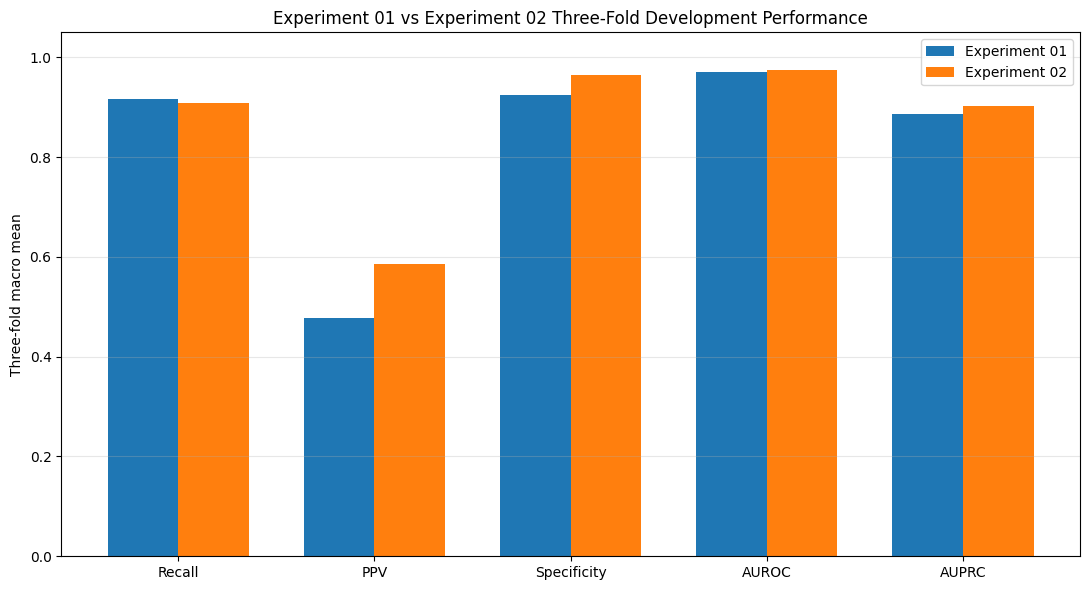

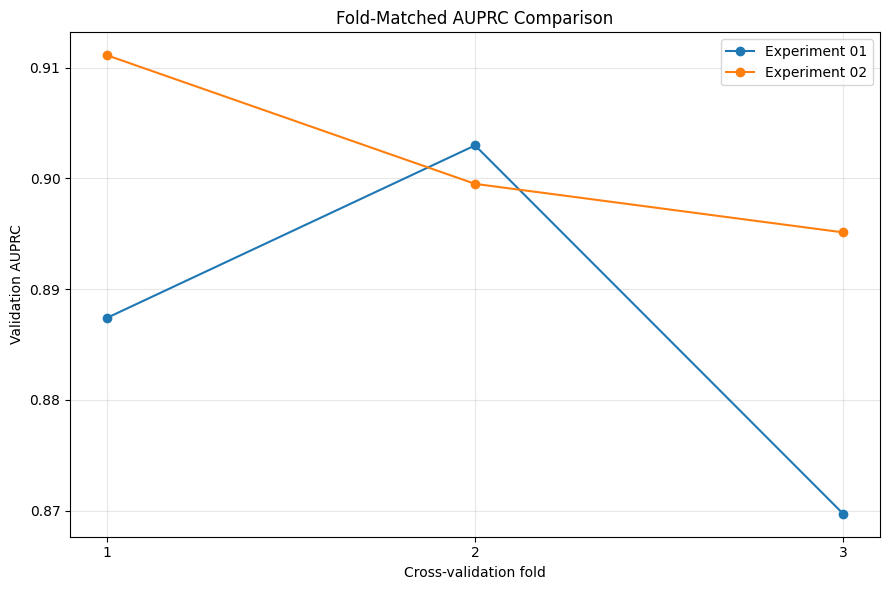

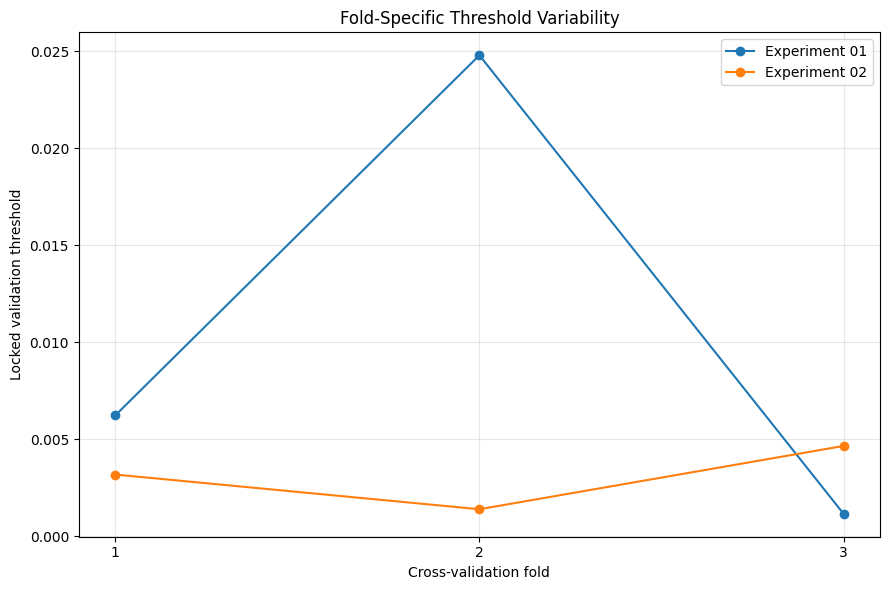

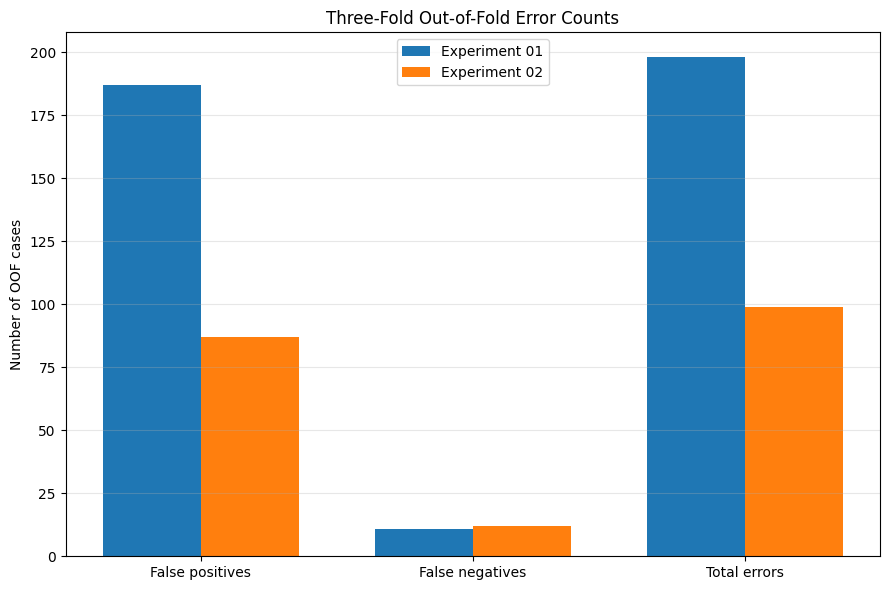

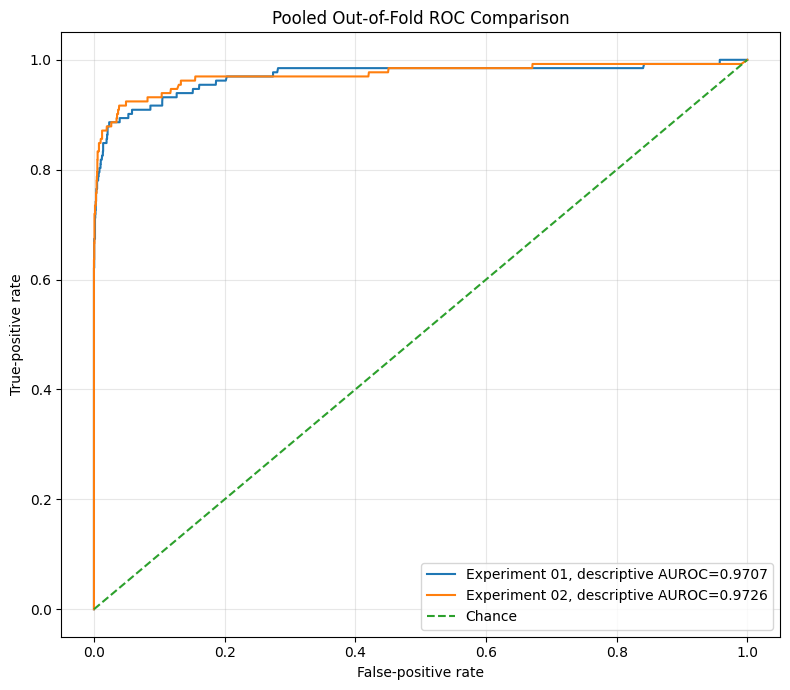

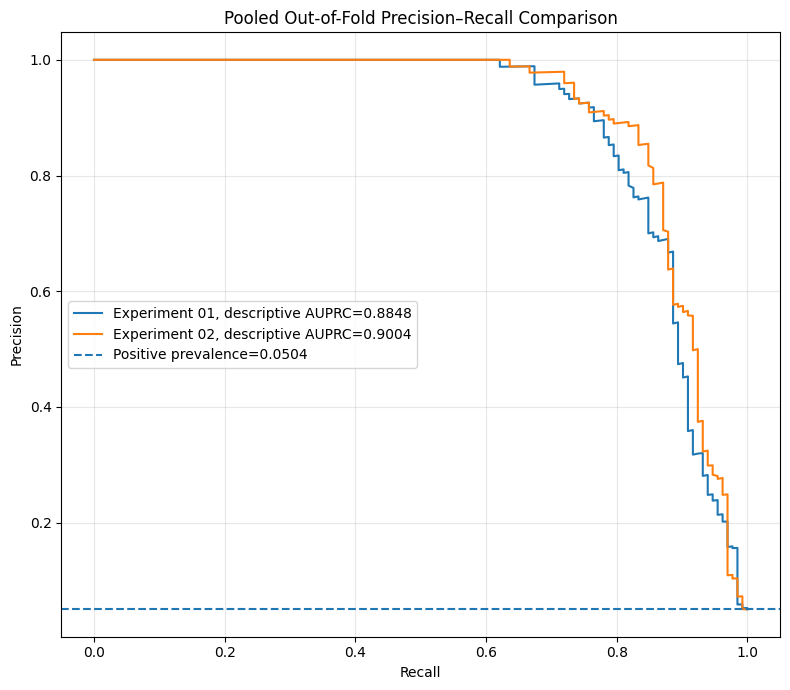

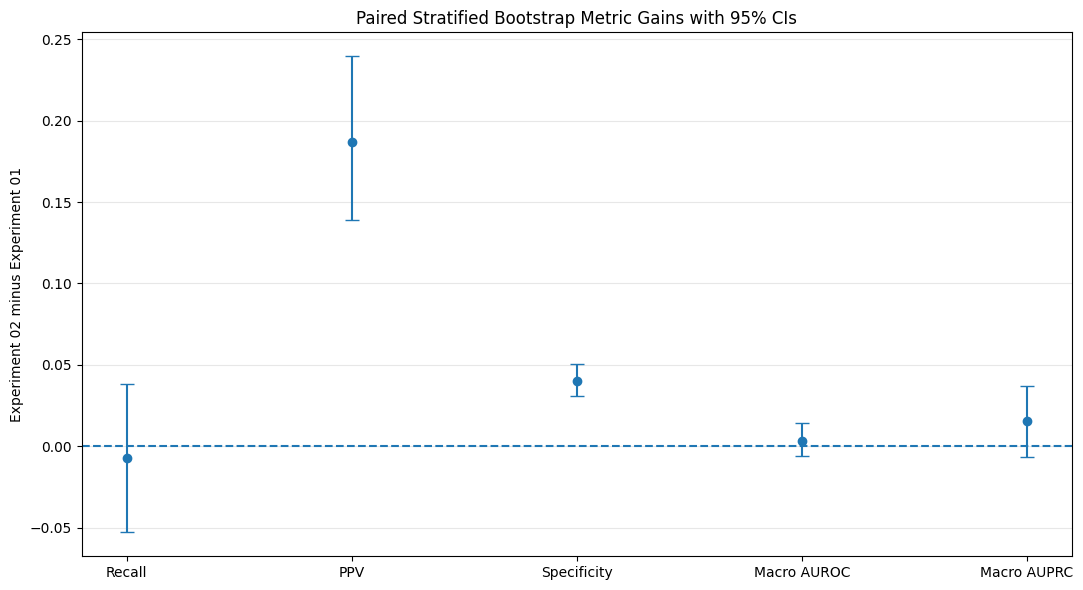


FINAL CELL 13E AGGREGATE COMPARISON REPORT

Complete OOF records:
Experiment 01: 2620/2620
Experiment 02: 2620/2620
Paired cases: 2620/2620

Macro three-fold performance:
Experiment 01 mean AUPRC: 0.886694
Experiment 02 mean AUPRC: 0.901907
AUPRC change: +0.015213

Experiment 01 mean AUROC: 0.970978
Experiment 02 mean AUROC: 0.973870
AUROC change: +0.002892

Experiment 01 mean recall: 0.916667
Experiment 02 mean recall: 0.909091
Recall change: -0.007576

Experiment 01 mean PPV: 0.476768
Experiment 02 mean PPV: 0.586399
PPV change: +0.109631

Experiment 01 mean specificity: 0.924832
Experiment 02 mean specificity: 0.965037
Specificity change: +0.040204

Threshold ranges:
Experiment 01: 0.023648262024
Experiment 02: 0.003263473511

Paired OOF errors:
Experiment 01 total errors: 198
Experiment 02 total errors: 99
Errors fixed by Experiment 02: 146
New Experiment 02 errors: 47
False-positive reduction: 100
False-negative reduction: -1

Development-only decision:
EXPERIMENT_02_DEVELOPMENT_

13623

In [ ]:
# ============================================================
# RARE26 GASTRONET EXTENSION — CELL 13E
#
# EXPERIMENT 02 THREE-FOLD AGGREGATE ANALYSIS
# AND FAIR DEVELOPMENT-ONLY COMPARISON AGAINST EXPERIMENT 01
#
# Experiment 01:
# RN50_GastroNet-5M_DINOv1.pth
#
# Experiment 02:
# RN50_Billion-Scale-SWSL+
# GastroNet-5M_DINOv1.pth
#
# IMPORTANT:
# - Uses only three-fold out-of-fold validation predictions.
# - Does not load held-out test CSV.
# - Does not load held-out test predictions.
# - Does not train models.
# - Does not perform new image inference.
# - Does not perform threshold search.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display

import json
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
)


# ============================================================
# 1. FIXED CONFIGURATION
# ============================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

RANDOM_SEED = 42
BOOTSTRAP_ITERATIONS = 1000

EXPERIMENT_1_NAME = (
    "experiment_01_gastronet5m_dinov1"
)

EXPERIMENT_2_NAME = (
    "experiment_02_swsl_gastronet5m_dinov1"
)

EXPERIMENT_1_DISPLAY = (
    "Experiment 01 GastroNet-5M DINOv1"
)

EXPERIMENT_2_DISPLAY = (
    "Experiment 02 SWSL + GastroNet-5M DINOv1"
)

FINAL_STATUS = (
    "EXP02_THREE_FOLD_AGGREGATE_AND_"
    "EXP01_COMPARISON_COMPLETE"
)


# ============================================================
# 2. INPUT PREDICTION FILES
# ============================================================

EXPERIMENT_1_PREDICTION_PATHS = {
    1: (
        PROJECT_ROOT
        / "predictions"
        / "cross_validation"
        / "fold_1"
        / (
            "cv_fold_1_rn50_gastronet5m_dinov1_"
            "validation_predictions_locked_threshold.csv"
        )
    ),

    2: (
        PROJECT_ROOT
        / "predictions"
        / "cross_validation"
        / "fold_2"
        / (
            "cv_fold_2_rn50_gastronet5m_dinov1_"
            "validation_predictions_locked_threshold.csv"
        )
    ),

    3: (
        PROJECT_ROOT
        / "predictions"
        / "cross_validation"
        / "fold_3"
        / (
            "cv_fold_3_rn50_gastronet5m_dinov1_"
            "validation_predictions_locked_threshold.csv"
        )
    ),
}


EXPERIMENT_2_PREDICTION_PATHS = {
    1: (
        PROJECT_ROOT
        / "predictions"
        / "cross_validation"
        / EXPERIMENT_2_NAME
        / "fold_1"
        / (
            "exp02_swsl_dino_fold_1_"
            "validation_predictions_locked_threshold.csv"
        )
    ),

    2: (
        PROJECT_ROOT
        / "predictions"
        / "cross_validation"
        / EXPERIMENT_2_NAME
        / "fold_2"
        / (
            "exp02_swsl_dino_fold_2_"
            "validation_predictions_locked_threshold.csv"
        )
    ),

    3: (
        PROJECT_ROOT
        / "predictions"
        / "cross_validation"
        / EXPERIMENT_2_NAME
        / "fold_3"
        / (
            "exp02_swsl_dino_fold_3_"
            "validation_predictions_locked_threshold.csv"
        )
    ),
}


EXPERIMENT_2_STATUS_PATHS = {
    fold: (
        PROJECT_ROOT
        / "results"
        / "cross_validation"
        / EXPERIMENT_2_NAME
        / f"fold_{fold}"
        / f"exp02_swsl_dino_fold_{fold}_status.json"
    )

    for fold in [1, 2, 3]
}


# ============================================================
# 3. OUTPUT DIRECTORIES
# ============================================================

EXP02_AGGREGATE_PREDICTION_DIR = (
    PROJECT_ROOT
    / "predictions"
    / "cross_validation"
    / EXPERIMENT_2_NAME
    / "aggregate"
)

EXP02_AGGREGATE_RESULT_DIR = (
    PROJECT_ROOT
    / "results"
    / "cross_validation"
    / EXPERIMENT_2_NAME
    / "aggregate"
)

EXP02_AGGREGATE_CENTRE_DIR = (
    PROJECT_ROOT
    / "centre_analysis"
    / "cross_validation"
    / EXPERIMENT_2_NAME
    / "aggregate"
)

EXP02_AGGREGATE_THRESHOLD_DIR = (
    PROJECT_ROOT
    / "thresholds"
    / "cross_validation"
    / EXPERIMENT_2_NAME
    / "aggregate"
)

COMPARISON_RESULT_DIR = (
    PROJECT_ROOT
    / "results"
    / "cross_validation"
    / "controlled_comparisons"
    / "experiment_01_vs_experiment_02"
)

COMPARISON_PREDICTION_DIR = (
    PROJECT_ROOT
    / "predictions"
    / "cross_validation"
    / "controlled_comparisons"
    / "experiment_01_vs_experiment_02"
)

COMPARISON_CENTRE_DIR = (
    PROJECT_ROOT
    / "centre_analysis"
    / "cross_validation"
    / "controlled_comparisons"
    / "experiment_01_vs_experiment_02"
)

COMPARISON_FIGURE_DIR = (
    PROJECT_ROOT
    / "figures"
    / "cross_validation"
    / "controlled_comparisons"
    / "experiment_01_vs_experiment_02"
)


for directory in [
    EXP02_AGGREGATE_PREDICTION_DIR,
    EXP02_AGGREGATE_RESULT_DIR,
    EXP02_AGGREGATE_CENTRE_DIR,
    EXP02_AGGREGATE_THRESHOLD_DIR,
    COMPARISON_RESULT_DIR,
    COMPARISON_PREDICTION_DIR,
    COMPARISON_CENTRE_DIR,
    COMPARISON_FIGURE_DIR,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 4. OUTPUT FILE PATHS
# ============================================================

EXP02_OOF_PREDICTIONS_PATH = (
    EXP02_AGGREGATE_PREDICTION_DIR
    / "cell13e_exp02_three_fold_oof_predictions.csv"
)

EXP02_FOLD_METRICS_PATH = (
    EXP02_AGGREGATE_RESULT_DIR
    / "cell13e_exp02_metrics_by_fold.csv"
)

EXP02_MACRO_SUMMARY_PATH = (
    EXP02_AGGREGATE_RESULT_DIR
    / "cell13e_exp02_macro_summary.csv"
)

EXP02_POOLED_METRICS_PATH = (
    EXP02_AGGREGATE_RESULT_DIR
    / "cell13e_exp02_pooled_oof_metrics.csv"
)

EXP02_POOLED_CENTRE_PATH = (
    EXP02_AGGREGATE_CENTRE_DIR
    / "cell13e_exp02_pooled_oof_per_centre.csv"
)

EXP02_FOLD_CENTRE_PATH = (
    EXP02_AGGREGATE_CENTRE_DIR
    / "cell13e_exp02_per_fold_per_centre_metrics.csv"
)

EXP02_THRESHOLD_PATH = (
    EXP02_AGGREGATE_THRESHOLD_DIR
    / "cell13e_exp02_three_fold_thresholds.csv"
)

EXP02_THRESHOLD_SUMMARY_PATH = (
    EXP02_AGGREGATE_THRESHOLD_DIR
    / "cell13e_exp02_threshold_summary.csv"
)

COMPARISON_CASE_PATH = (
    COMPARISON_PREDICTION_DIR
    / "cell13e_exp01_vs_exp02_paired_oof_cases.csv"
)

COMPARISON_FOLD_METRICS_PATH = (
    COMPARISON_RESULT_DIR
    / "cell13e_exp01_vs_exp02_fold_metric_comparison.csv"
)

COMPARISON_MACRO_PATH = (
    COMPARISON_RESULT_DIR
    / "cell13e_exp01_vs_exp02_macro_comparison.csv"
)

COMPARISON_POOLED_PATH = (
    COMPARISON_RESULT_DIR
    / "cell13e_exp01_vs_exp02_pooled_comparison.csv"
)

COMPARISON_CENTRE_PATH = (
    COMPARISON_CENTRE_DIR
    / "cell13e_exp01_vs_exp02_per_centre_comparison.csv"
)

ERROR_OVERLAP_PATH = (
    COMPARISON_RESULT_DIR
    / "cell13e_exp01_vs_exp02_error_overlap.csv"
)

ERROR_FIXED_PATH = (
    COMPARISON_PREDICTION_DIR
    / "cell13e_exp01_errors_fixed_by_exp02.csv"
)

NEW_ERRORS_PATH = (
    COMPARISON_PREDICTION_DIR
    / "cell13e_new_exp02_errors.csv"
)

COMMON_ERRORS_PATH = (
    COMPARISON_PREDICTION_DIR
    / "cell13e_common_exp01_exp02_errors.csv"
)

BOOTSTRAP_SAMPLES_PATH = (
    COMPARISON_RESULT_DIR
    / "cell13e_exp01_vs_exp02_paired_bootstrap_samples.csv"
)

BOOTSTRAP_SUMMARY_PATH = (
    COMPARISON_RESULT_DIR
    / "cell13e_exp01_vs_exp02_paired_bootstrap_summary.csv"
)

DECISION_PATH = (
    COMPARISON_RESULT_DIR
    / "cell13e_development_model_decision.json"
)

STATUS_PATH = (
    COMPARISON_RESULT_DIR
    / "cell13e_status.json"
)

SUMMARY_PATH = (
    COMPARISON_RESULT_DIR
    / "cell13e_aggregate_comparison_summary.txt"
)

MACRO_FIGURE_PATH = (
    COMPARISON_FIGURE_DIR
    / "cell13e_macro_metric_comparison.png"
)

FOLD_AUPRC_FIGURE_PATH = (
    COMPARISON_FIGURE_DIR
    / "cell13e_fold_auprc_comparison.png"
)

THRESHOLD_FIGURE_PATH = (
    COMPARISON_FIGURE_DIR
    / "cell13e_threshold_variability.png"
)

ERROR_FIGURE_PATH = (
    COMPARISON_FIGURE_DIR
    / "cell13e_pooled_error_count_comparison.png"
)

ROC_FIGURE_PATH = (
    COMPARISON_FIGURE_DIR
    / "cell13e_pooled_oof_roc_comparison.png"
)

PR_FIGURE_PATH = (
    COMPARISON_FIGURE_DIR
    / "cell13e_pooled_oof_pr_comparison.png"
)

BOOTSTRAP_FIGURE_PATH = (
    COMPARISON_FIGURE_DIR
    / "cell13e_bootstrap_metric_gain_ci.png"
)


# ============================================================
# 5. INITIAL REPORT
# ============================================================

print("=" * 92)
print(
    "CELL 13E: EXPERIMENT 02 THREE-FOLD AGGREGATE "
    "AND EXPERIMENT 01 COMPARISON"
)
print("=" * 92)

print("\nExperiment 01:")
print(EXPERIMENT_1_DISPLAY)

print("\nExperiment 02:")
print(EXPERIMENT_2_DISPLAY)

print("\nHeld-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("New model training performed: False")
print("New image inference performed: False")
print("New threshold search performed: False")


# ============================================================
# 6. VERIFY REQUIRED FILES
# ============================================================

required_files = []

required_files.extend(
    EXPERIMENT_1_PREDICTION_PATHS.values()
)

required_files.extend(
    EXPERIMENT_2_PREDICTION_PATHS.values()
)

required_files.extend(
    EXPERIMENT_2_STATUS_PATHS.values()
)


missing_files = [
    path

    for path in required_files

    if not path.exists()
]


if missing_files:

    print("\nMissing required files:")

    for missing_file in missing_files:
        print(missing_file)

    raise FileNotFoundError(
        "\nCell 13E cannot run because required "
        "fold prediction or status files are missing."
    )


for fold, status_path in (
    EXPERIMENT_2_STATUS_PATHS.items()
):

    status_record = json.loads(
        status_path.read_text(
            encoding="utf-8"
        )
    )

    expected_status = (
        f"EXP02_SWSL_DINO_FOLD_{fold}_"
        "TRAINING_AND_THRESHOLD_LOCK_COMPLETE"
    )

    if (
        status_record.get("status")
        != expected_status
    ):

        raise RuntimeError(
            f"Experiment 02 Fold {fold} status "
            "complete nahi hai.\n"
            f"Status file:\n{status_path}\n"
            f"Actual status: "
            f"{status_record.get('status')}"
        )

    if bool(
        status_record.get(
            "held_out_test_loaded",
            False,
        )
    ):

        raise RuntimeError(
            f"Fold {fold} status incorrectly reports "
            "held-out test loading."
        )

    if bool(
        status_record.get(
            "held_out_test_evaluated",
            False,
        )
    ):

        raise RuntimeError(
            f"Fold {fold} status incorrectly reports "
            "held-out test evaluation."
        )


print(
    "\nAll Experiment 02 Fold 1–3 completion "
    "status files verified: True"
)


# ============================================================
# 7. HELPER FUNCTIONS
# ============================================================

def first_existing_column(
    dataframe,
    candidates,
    description,
):

    for column in candidates:

        if column in dataframe.columns:
            return column

    raise RuntimeError(
        f"Could not identify {description} column.\n"
        f"Available columns:\n"
        f"{list(dataframe.columns)}"
    )


def safe_divide(
    numerator,
    denominator,
    default=0.0,
):

    if denominator == 0:
        return float(default)

    return float(
        numerator / denominator
    )


def calculate_metrics_from_predictions(
    labels,
    probabilities,
    predictions,
):

    labels = np.asarray(
        labels,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    predictions = np.asarray(
        predictions,
        dtype=int,
    )


    tp = int(
        (
            (labels == 1)
            & (predictions == 1)
        ).sum()
    )

    tn = int(
        (
            (labels == 0)
            & (predictions == 0)
        ).sum()
    )

    fp = int(
        (
            (labels == 0)
            & (predictions == 1)
        ).sum()
    )

    fn = int(
        (
            (labels == 1)
            & (predictions == 0)
        ).sum()
    )


    recall = safe_divide(
        tp,
        tp + fn,
    )

    precision = safe_divide(
        tp,
        tp + fp,
    )

    specificity = safe_divide(
        tn,
        tn + fp,
    )

    npv = safe_divide(
        tn,
        tn + fn,
    )

    accuracy = safe_divide(
        tp + tn,
        len(labels),
    )

    balanced_accuracy = (
        recall + specificity
    ) / 2.0

    f1 = safe_divide(
        2.0 * precision * recall,
        precision + recall,
    )


    if len(
        np.unique(labels)
    ) == 2:

        auroc = float(
            roc_auc_score(
                labels,
                probabilities,
            )
        )

        auprc = float(
            average_precision_score(
                labels,
                probabilities,
            )
        )

    else:

        auroc = np.nan
        auprc = np.nan


    return {
        "sample_count": int(
            len(labels)
        ),

        "normal_count": int(
            (labels == 0).sum()
        ),

        "positive_count": int(
            (labels == 1).sum()
        ),

        "recall": float(
            recall
        ),

        "precision": float(
            precision
        ),

        "specificity": float(
            specificity
        ),

        "npv": float(
            npv
        ),

        "accuracy": float(
            accuracy
        ),

        "balanced_accuracy": float(
            balanced_accuracy
        ),

        "f1": float(
            f1
        ),

        "auroc": float(
            auroc
        ),

        "auprc": float(
            auprc
        ),

        "tp": int(
            tp
        ),

        "tn": int(
            tn
        ),

        "fp": int(
            fp
        ),

        "fn": int(
            fn
        ),
    }


def load_and_standardize_predictions(
    path,
    model_key,
    model_display_name,
    fold,
):

    dataframe = pd.read_csv(
        path,
        low_memory=False,
    ).copy()


    case_column = first_existing_column(
        dataframe,
        [
            "cv_case_id",
            "sha256",
            "relative_path",
        ],
        "case identity",
    )

    label_column = first_existing_column(
        dataframe,
        [
            "label",
            "target",
            "true_label",
        ],
        "label",
    )

    center_column = first_existing_column(
        dataframe,
        [
            "center",
            "centre",
        ],
        "center",
    )

    probability_column = first_existing_column(
        dataframe,
        [
            "probability",
            "neoplasia_probability",
            "prediction_probability",
        ],
        "probability",
    )

    prediction_column = first_existing_column(
        dataframe,
        [
            "prediction",
            "locked_prediction",
            "predicted_label",
        ],
        "prediction",
    )

    threshold_column = first_existing_column(
        dataframe,
        [
            "locked_threshold",
            "threshold",
        ],
        "locked threshold",
    )


    relative_path_column = None

    if "relative_path" in dataframe.columns:
        relative_path_column = "relative_path"


    standardized = pd.DataFrame(
        {
            "fold": int(
                fold
            ),

            "model_key": (
                model_key
            ),

            "model_name": (
                model_display_name
            ),

            "cv_case_id": (
                dataframe[
                    case_column
                ]
                .astype(str)
            ),

            "label": (
                dataframe[
                    label_column
                ]
                .astype(int)
            ),

            "center": (
                dataframe[
                    center_column
                ]
                .astype(str)
            ),

            "probability": (
                dataframe[
                    probability_column
                ]
                .astype(float)
            ),

            "prediction": (
                dataframe[
                    prediction_column
                ]
                .astype(int)
            ),

            "locked_threshold": (
                dataframe[
                    threshold_column
                ]
                .astype(float)
            ),

            "relative_path": (
                dataframe[
                    relative_path_column
                ].astype(str)

                if relative_path_column is not None

                else dataframe[
                    case_column
                ].astype(str)
            ),

            "source_prediction_file": str(
                path
            ),
        }
    )


    expected_counts = {
        1: {
            "total": 874,
            "normal": 830,
            "positive": 44,
        },

        2: {
            "total": 873,
            "normal": 829,
            "positive": 44,
        },

        3: {
            "total": 873,
            "normal": 829,
            "positive": 44,
        },
    }


    expected = expected_counts[
        fold
    ]


    actual_total = int(
        len(standardized)
    )

    actual_normal = int(
        (
            standardized[
                "label"
            ]
            == 0
        ).sum()
    )

    actual_positive = int(
        (
            standardized[
                "label"
            ]
            == 1
        ).sum()
    )


    if (
        actual_total
        != expected["total"]

        or actual_normal
        != expected["normal"]

        or actual_positive
        != expected["positive"]
    ):

        raise RuntimeError(
            f"{model_display_name}, Fold {fold} "
            "counts incorrect hain.\n"
            f"Actual total={actual_total}, "
            f"normal={actual_normal}, "
            f"positive={actual_positive}"
        )


    if standardized[
        "cv_case_id"
    ].duplicated().any():

        duplicate_count = int(
            standardized[
                "cv_case_id"
            ].duplicated().sum()
        )

        raise RuntimeError(
            f"{model_display_name}, Fold {fold} "
            f"contains {duplicate_count} duplicate cases."
        )


    unique_thresholds = np.unique(
        standardized[
            "locked_threshold"
        ].to_numpy(
            dtype=float
        )
    )


    if len(
        unique_thresholds
    ) != 1:

        raise RuntimeError(
            f"{model_display_name}, Fold {fold} "
            "does not contain one unique locked threshold."
        )


    recomputed_predictions = (
        standardized[
            "probability"
        ].to_numpy(
            dtype=float
        )
        >= float(
            unique_thresholds[0]
        )
    ).astype(int)


    disagreement_count = int(
        (
            recomputed_predictions
            != standardized[
                "prediction"
            ].to_numpy(
                dtype=int
            )
        ).sum()
    )


    if disagreement_count != 0:

        raise RuntimeError(
            f"{model_display_name}, Fold {fold} "
            f"has {disagreement_count} stored prediction "
            "disagreements with its locked threshold."
        )


    if not np.isfinite(
        standardized[
            "probability"
        ]
    ).all():

        raise RuntimeError(
            f"{model_display_name}, Fold {fold} "
            "contains non-finite probabilities."
        )


    if (
        (
            standardized[
                "probability"
            ]
            < 0.0
        ).any()

        or (
            standardized[
                "probability"
            ]
            > 1.0
        ).any()
    ):

        raise RuntimeError(
            f"{model_display_name}, Fold {fold} "
            "contains probabilities outside [0, 1]."
        )


    return standardized


def calculate_fold_metrics(
    standardized_predictions,
):

    metric_rows = []


    for (
        model_key,
        model_name,
        fold
    ), group in standardized_predictions.groupby(
        [
            "model_key",
            "model_name",
            "fold",
        ]
    ):

        metrics = calculate_metrics_from_predictions(
            group[
                "label"
            ].to_numpy(
                dtype=int
            ),

            group[
                "probability"
            ].to_numpy(
                dtype=float
            ),

            group[
                "prediction"
            ].to_numpy(
                dtype=int
            ),
        )


        threshold = float(
            group[
                "locked_threshold"
            ].iloc[0]
        )


        metric_rows.append(
            {
                "model_key": (
                    model_key
                ),

                "model_name": (
                    model_name
                ),

                "fold": int(
                    fold
                ),

                "threshold": (
                    threshold
                ),

                **metrics,
            }
        )


    return pd.DataFrame(
        metric_rows
    ).sort_values(
        [
            "model_key",
            "fold",
        ]
    ).reset_index(
        drop=True
    )


def calculate_per_centre_metrics(
    standardized_predictions,
):

    metric_rows = []


    for (
        model_key,
        model_name,
        fold,
        center
    ), group in standardized_predictions.groupby(
        [
            "model_key",
            "model_name",
            "fold",
            "center",
        ]
    ):

        metrics = calculate_metrics_from_predictions(
            group[
                "label"
            ].to_numpy(
                dtype=int
            ),

            group[
                "probability"
            ].to_numpy(
                dtype=float
            ),

            group[
                "prediction"
            ].to_numpy(
                dtype=int
            ),
        )


        metric_rows.append(
            {
                "model_key": (
                    model_key
                ),

                "model_name": (
                    model_name
                ),

                "fold": int(
                    fold
                ),

                "center": (
                    center
                ),

                "threshold": float(
                    group[
                        "locked_threshold"
                    ].iloc[0]
                ),

                **metrics,
            }
        )


    return pd.DataFrame(
        metric_rows
    ).sort_values(
        [
            "model_key",
            "fold",
            "center",
        ]
    ).reset_index(
        drop=True
    )


# ============================================================
# 8. LOAD ALL FOLD PREDICTIONS
# ============================================================

experiment_1_fold_frames = []
experiment_2_fold_frames = []


for fold in [1, 2, 3]:

    experiment_1_fold = (
        load_and_standardize_predictions(
            EXPERIMENT_1_PREDICTION_PATHS[
                fold
            ],

            "experiment_01",

            EXPERIMENT_1_DISPLAY,

            fold,
        )
    )


    experiment_2_fold = (
        load_and_standardize_predictions(
            EXPERIMENT_2_PREDICTION_PATHS[
                fold
            ],

            "experiment_02",

            EXPERIMENT_2_DISPLAY,

            fold,
        )
    )


    experiment_1_case_set = set(
        experiment_1_fold[
            "cv_case_id"
        ]
    )

    experiment_2_case_set = set(
        experiment_2_fold[
            "cv_case_id"
        ]
    )


    if (
        experiment_1_case_set
        != experiment_2_case_set
    ):

        only_exp1 = len(
            experiment_1_case_set
            - experiment_2_case_set
        )

        only_exp2 = len(
            experiment_2_case_set
            - experiment_1_case_set
        )

        raise RuntimeError(
            f"Fold {fold} case identity mismatch.\n"
            f"Only Experiment 01: {only_exp1}\n"
            f"Only Experiment 02: {only_exp2}"
        )


    fold_pair_check = experiment_1_fold.merge(
        experiment_2_fold,

        on=[
            "fold",
            "cv_case_id",
        ],

        suffixes=(
            "_exp1",
            "_exp2",
        ),

        validate="one_to_one",
    )


    label_disagreements = int(
        (
            fold_pair_check[
                "label_exp1"
            ]
            != fold_pair_check[
                "label_exp2"
            ]
        ).sum()
    )


    center_disagreements = int(
        (
            fold_pair_check[
                "center_exp1"
            ]
            != fold_pair_check[
                "center_exp2"
            ]
        ).sum()
    )


    if label_disagreements != 0:

        raise RuntimeError(
            f"Fold {fold} contains "
            f"{label_disagreements} label disagreements."
        )


    if center_disagreements != 0:

        raise RuntimeError(
            f"Fold {fold} contains "
            f"{center_disagreements} centre disagreements."
        )


    print(
        f"\nFold {fold} paired verification passed:"
    )

    print(
        f"Matched cases: "
        f"{len(fold_pair_check)}"
    )

    print(
        f"Experiment 01 threshold: "
        f"{experiment_1_fold['locked_threshold'].iloc[0]:.12f}"
    )

    print(
        f"Experiment 02 threshold: "
        f"{experiment_2_fold['locked_threshold'].iloc[0]:.12f}"
    )


    experiment_1_fold_frames.append(
        experiment_1_fold
    )

    experiment_2_fold_frames.append(
        experiment_2_fold
    )


experiment_1_oof_df = pd.concat(
    experiment_1_fold_frames,
    ignore_index=True,
)

experiment_2_oof_df = pd.concat(
    experiment_2_fold_frames,
    ignore_index=True,
)


# ============================================================
# 9. VERIFY COMPLETE OOF SETS
# ============================================================

for model_name, dataframe in [
    (
        EXPERIMENT_1_DISPLAY,
        experiment_1_oof_df,
    ),

    (
        EXPERIMENT_2_DISPLAY,
        experiment_2_oof_df,
    ),
]:

    if len(dataframe) != 2620:

        raise RuntimeError(
            f"{model_name} OOF record count "
            f"is {len(dataframe)}, expected 2620."
        )


    if (
        dataframe[
            "cv_case_id"
        ].nunique()
        != 2620
    ):

        raise RuntimeError(
            f"{model_name} does not contain "
            "2,620 unique OOF cases."
        )


    if int(
        (
            dataframe[
                "label"
            ]
            == 0
        ).sum()
    ) != 2488:

        raise RuntimeError(
            f"{model_name} normal count is incorrect."
        )


    if int(
        (
            dataframe[
                "label"
            ]
            == 1
        ).sum()
    ) != 132:

        raise RuntimeError(
            f"{model_name} neoplasia count is incorrect."
        )


experiment_2_oof_df.to_csv(
    EXP02_OOF_PREDICTIONS_PATH,
    index=False,
)


print("\nComplete OOF verification:")

print(
    f"Experiment 01 records: "
    f"{len(experiment_1_oof_df)}/2620"
)

print(
    f"Experiment 02 records: "
    f"{len(experiment_2_oof_df)}/2620"
)

print(
    f"Unique cases: "
    f"{experiment_2_oof_df['cv_case_id'].nunique()}/2620"
)

print(
    "Duplicate cases: "
    f"{int(experiment_2_oof_df['cv_case_id'].duplicated().sum())}"
)

print(
    "Normal cases: "
    f"{int((experiment_2_oof_df['label'] == 0).sum())}/2488"
)

print(
    "Neoplasia cases: "
    f"{int((experiment_2_oof_df['label'] == 1).sum())}/132"
)


# ============================================================
# 10. CALCULATE FOLD METRICS
# ============================================================

all_oof_predictions_df = pd.concat(
    [
        experiment_1_oof_df,
        experiment_2_oof_df,
    ],
    ignore_index=True,
)


fold_metrics_df = calculate_fold_metrics(
    all_oof_predictions_df
)


experiment_2_fold_metrics_df = (
    fold_metrics_df[
        fold_metrics_df[
            "model_key"
        ]
        == "experiment_02"
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


experiment_2_fold_metrics_df.to_csv(
    EXP02_FOLD_METRICS_PATH,
    index=False,
)


print("\nFold-by-fold metrics:")

display(
    fold_metrics_df
)


# ============================================================
# 11. MACRO MEAN AND VARIABILITY
# ============================================================

macro_metrics = [
    "recall",
    "precision",
    "specificity",
    "npv",
    "accuracy",
    "balanced_accuracy",
    "f1",
    "auroc",
    "auprc",
]


macro_rows = []


for (
    model_key,
    model_name
), model_group in fold_metrics_df.groupby(
    [
        "model_key",
        "model_name",
    ]
):

    for metric in macro_metrics:

        values = model_group[
            metric
        ].to_numpy(
            dtype=float
        )


        macro_rows.append(
            {
                "model_key": (
                    model_key
                ),

                "model_name": (
                    model_name
                ),

                "metric": (
                    metric
                ),

                "fold_1": float(
                    model_group.loc[
                        model_group[
                            "fold"
                        ]
                        == 1,
                        metric,
                    ].iloc[0]
                ),

                "fold_2": float(
                    model_group.loc[
                        model_group[
                            "fold"
                        ]
                        == 2,
                        metric,
                    ].iloc[0]
                ),

                "fold_3": float(
                    model_group.loc[
                        model_group[
                            "fold"
                        ]
                        == 3,
                        metric,
                    ].iloc[0]
                ),

                "mean": float(
                    np.mean(
                        values
                    )
                ),

                "standard_deviation": float(
                    np.std(
                        values,
                        ddof=1,
                    )
                ),

                "minimum": float(
                    np.min(
                        values
                    )
                ),

                "maximum": float(
                    np.max(
                        values
                    )
                ),

                "range": float(
                    np.max(
                        values
                    )
                    - np.min(
                        values
                    )
                ),
            }
        )


macro_summary_df = pd.DataFrame(
    macro_rows
)


experiment_2_macro_summary_df = (
    macro_summary_df[
        macro_summary_df[
            "model_key"
        ]
        == "experiment_02"
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


experiment_2_macro_summary_df.to_csv(
    EXP02_MACRO_SUMMARY_PATH,
    index=False,
)


# ============================================================
# 12. POOLED OOF OPERATING METRICS
# ============================================================

pooled_metric_rows = []


for model_key, model_name, dataframe in [
    (
        "experiment_01",
        EXPERIMENT_1_DISPLAY,
        experiment_1_oof_df,
    ),

    (
        "experiment_02",
        EXPERIMENT_2_DISPLAY,
        experiment_2_oof_df,
    ),
]:

    metrics = calculate_metrics_from_predictions(
        dataframe[
            "label"
        ].to_numpy(
            dtype=int
        ),

        dataframe[
            "probability"
        ].to_numpy(
            dtype=float
        ),

        dataframe[
            "prediction"
        ].to_numpy(
            dtype=int
        ),
    )


    pooled_metric_rows.append(
        {
            "model_key": (
                model_key
            ),

            "model_name": (
                model_name
            ),

            "evaluation_type": (
                "pooled_out_of_fold"
            ),

            "threshold_type": (
                "fold_specific_locked_thresholds"
            ),

            **metrics,

            "important_probability_note": (
                "Pooled AUROC and AUPRC are descriptive "
                "because probabilities originate from "
                "three separately trained fold models. "
                "Macro fold means are the primary ranking "
                "comparison."
            ),

            "held_out_test_loaded": False,

            "held_out_test_evaluated": False,
        }
    )


pooled_metrics_df = pd.DataFrame(
    pooled_metric_rows
)


experiment_2_pooled_metrics_df = (
    pooled_metrics_df[
        pooled_metrics_df[
            "model_key"
        ]
        == "experiment_02"
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


experiment_2_pooled_metrics_df.to_csv(
    EXP02_POOLED_METRICS_PATH,
    index=False,
)


print("\nPooled OOF operating metrics:")

display(
    pooled_metrics_df
)


# ============================================================
# 13. PER-CENTRE METRICS
# ============================================================

per_fold_centre_df = calculate_per_centre_metrics(
    all_oof_predictions_df
)


experiment_2_per_fold_centre_df = (
    per_fold_centre_df[
        per_fold_centre_df[
            "model_key"
        ]
        == "experiment_02"
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


experiment_2_per_fold_centre_df.to_csv(
    EXP02_FOLD_CENTRE_PATH,
    index=False,
)


pooled_centre_rows = []


for (
    model_key,
    model_name,
    center
), group in all_oof_predictions_df.groupby(
    [
        "model_key",
        "model_name",
        "center",
    ]
):

    metrics = calculate_metrics_from_predictions(
        group[
            "label"
        ].to_numpy(
            dtype=int
        ),

        group[
            "probability"
        ].to_numpy(
            dtype=float
        ),

        group[
            "prediction"
        ].to_numpy(
            dtype=int
        ),
    )


    pooled_centre_rows.append(
        {
            "model_key": (
                model_key
            ),

            "model_name": (
                model_name
            ),

            "center": (
                center
            ),

            "threshold_type": (
                "fold_specific_locked_thresholds"
            ),

            **metrics,
        }
    )


pooled_centre_df = pd.DataFrame(
    pooled_centre_rows
).sort_values(
    [
        "center",
        "model_key",
    ]
).reset_index(
    drop=True
)


experiment_2_pooled_centre_df = (
    pooled_centre_df[
        pooled_centre_df[
            "model_key"
        ]
        == "experiment_02"
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


experiment_2_pooled_centre_df.to_csv(
    EXP02_POOLED_CENTRE_PATH,
    index=False,
)


print("\nPooled OOF per-centre metrics:")

display(
    pooled_centre_df
)


# ============================================================
# 14. THRESHOLD VARIABILITY
# ============================================================

threshold_df = (
    fold_metrics_df[
        [
            "model_key",
            "model_name",
            "fold",
            "threshold",
        ]
    ]
    .copy()
    .sort_values(
        [
            "model_key",
            "fold",
        ]
    )
    .reset_index(
        drop=True
    )
)


threshold_summary_rows = []


for (
    model_key,
    model_name
), group in threshold_df.groupby(
    [
        "model_key",
        "model_name",
    ]
):

    thresholds = group[
        "threshold"
    ].to_numpy(
        dtype=float
    )


    minimum_threshold = float(
        np.min(
            thresholds
        )
    )

    maximum_threshold = float(
        np.max(
            thresholds
        )
    )


    threshold_summary_rows.append(
        {
            "model_key": (
                model_key
            ),

            "model_name": (
                model_name
            ),

            "fold_count": int(
                len(
                    thresholds
                )
            ),

            "mean_threshold": float(
                np.mean(
                    thresholds
                )
            ),

            "standard_deviation": float(
                np.std(
                    thresholds,
                    ddof=1,
                )
            ),

            "median_threshold": float(
                np.median(
                    thresholds
                )
            ),

            "minimum_threshold": (
                minimum_threshold
            ),

            "maximum_threshold": (
                maximum_threshold
            ),

            "threshold_range": float(
                maximum_threshold
                - minimum_threshold
            ),

            "maximum_to_minimum_ratio": (
                safe_divide(
                    maximum_threshold,
                    minimum_threshold,
                    default=np.inf,
                )
            ),
        }
    )


threshold_summary_df = pd.DataFrame(
    threshold_summary_rows
)


experiment_2_threshold_df = (
    threshold_df[
        threshold_df[
            "model_key"
        ]
        == "experiment_02"
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


experiment_2_threshold_summary_df = (
    threshold_summary_df[
        threshold_summary_df[
            "model_key"
        ]
        == "experiment_02"
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


experiment_2_threshold_df.to_csv(
    EXP02_THRESHOLD_PATH,
    index=False,
)


experiment_2_threshold_summary_df.to_csv(
    EXP02_THRESHOLD_SUMMARY_PATH,
    index=False,
)


print("\nThresholds:")

display(
    threshold_df
)


print("\nThreshold stability summary:")

display(
    threshold_summary_df
)


# ============================================================
# 15. CREATE PAIRED CASE-LEVEL COMPARISON
# ============================================================

paired_df = experiment_1_oof_df.merge(
    experiment_2_oof_df,

    on=[
        "fold",
        "cv_case_id",
    ],

    suffixes=(
        "_exp1",
        "_exp2",
    ),

    validate="one_to_one",
)


if len(
    paired_df
) != 2620:

    raise RuntimeError(
        "Paired comparison must contain exactly 2,620 cases."
    )


if int(
    (
        paired_df[
            "label_exp1"
        ]
        != paired_df[
            "label_exp2"
        ]
    ).sum()
) != 0:

    raise RuntimeError(
        "Paired labels do not match."
    )


if int(
    (
        paired_df[
            "center_exp1"
        ]
        != paired_df[
            "center_exp2"
        ]
    ).sum()
) != 0:

    raise RuntimeError(
        "Paired centres do not match."
    )


paired_df[
    "label"
] = paired_df[
    "label_exp1"
].astype(int)

paired_df[
    "center"
] = paired_df[
    "center_exp1"
].astype(str)


paired_df[
    "experiment_1_correct"
] = (
    paired_df[
        "prediction_exp1"
    ]
    ==
    paired_df[
        "label"
    ]
)


paired_df[
    "experiment_2_correct"
] = (
    paired_df[
        "prediction_exp2"
    ]
    ==
    paired_df[
        "label"
    ]
)


paired_df[
    "experiment_1_error"
] = (
    ~paired_df[
        "experiment_1_correct"
    ]
)


paired_df[
    "experiment_2_error"
] = (
    ~paired_df[
        "experiment_2_correct"
    ]
)


paired_df[
    "experiment_1_error_type"
] = np.select(
    [
        (
            (paired_df["label"] == 0)
            &
            (paired_df["prediction_exp1"] == 1)
        ),

        (
            (paired_df["label"] == 1)
            &
            (paired_df["prediction_exp1"] == 0)
        ),
    ],

    [
        "FP",
        "FN",
    ],

    default="correct",
)


paired_df[
    "experiment_2_error_type"
] = np.select(
    [
        (
            (paired_df["label"] == 0)
            &
            (paired_df["prediction_exp2"] == 1)
        ),

        (
            (paired_df["label"] == 1)
            &
            (paired_df["prediction_exp2"] == 0)
        ),
    ],

    [
        "FP",
        "FN",
    ],

    default="correct",
)


paired_df[
    "comparison_outcome"
] = np.select(
    [
        (
            paired_df[
                "experiment_1_error"
            ]
            &
            ~paired_df[
                "experiment_2_error"
            ]
        ),

        (
            ~paired_df[
                "experiment_1_error"
            ]
            &
            paired_df[
                "experiment_2_error"
            ]
        ),

        (
            paired_df[
                "experiment_1_error"
            ]
            &
            paired_df[
                "experiment_2_error"
            ]
        ),
    ],

    [
        "experiment_1_error_fixed_by_experiment_2",
        "new_experiment_2_error",
        "common_error",
    ],

    default="both_correct",
)


paired_df.to_csv(
    COMPARISON_CASE_PATH,
    index=False,
)


# ============================================================
# 16. FOLD-MATCHED METRIC COMPARISON
# ============================================================

comparison_metrics = [
    "recall",
    "precision",
    "specificity",
    "npv",
    "accuracy",
    "balanced_accuracy",
    "f1",
    "auroc",
    "auprc",
    "tp",
    "tn",
    "fp",
    "fn",
]


fold_comparison_rows = []


for fold in [1, 2, 3]:

    exp1_row = fold_metrics_df[
        (
            fold_metrics_df[
                "model_key"
            ]
            == "experiment_01"
        )
        &
        (
            fold_metrics_df[
                "fold"
            ]
            == fold
        )
    ].iloc[0]


    exp2_row = fold_metrics_df[
        (
            fold_metrics_df[
                "model_key"
            ]
            == "experiment_02"
        )
        &
        (
            fold_metrics_df[
                "fold"
            ]
            == fold
        )
    ].iloc[0]


    for metric in comparison_metrics:

        experiment_1_value = float(
            exp1_row[
                metric
            ]
        )

        experiment_2_value = float(
            exp2_row[
                metric
            ]
        )


        fold_comparison_rows.append(
            {
                "fold": (
                    fold
                ),

                "metric": (
                    metric
                ),

                "experiment_1_value": (
                    experiment_1_value
                ),

                "experiment_2_value": (
                    experiment_2_value
                ),

                "experiment_2_minus_experiment_1": float(
                    experiment_2_value
                    - experiment_1_value
                ),
            }
        )


fold_comparison_df = pd.DataFrame(
    fold_comparison_rows
)


fold_comparison_df.to_csv(
    COMPARISON_FOLD_METRICS_PATH,
    index=False,
)


# ============================================================
# 17. MACRO COMPARISON
# ============================================================

macro_comparison_rows = []


for metric in macro_metrics:

    exp1_row = macro_summary_df[
        (
            macro_summary_df[
                "model_key"
            ]
            == "experiment_01"
        )
        &
        (
            macro_summary_df[
                "metric"
            ]
            == metric
        )
    ].iloc[0]


    exp2_row = macro_summary_df[
        (
            macro_summary_df[
                "model_key"
            ]
            == "experiment_02"
        )
        &
        (
            macro_summary_df[
                "metric"
            ]
            == metric
        )
    ].iloc[0]


    macro_comparison_rows.append(
        {
            "metric": (
                metric
            ),

            "experiment_1_mean": float(
                exp1_row[
                    "mean"
                ]
            ),

            "experiment_1_standard_deviation": float(
                exp1_row[
                    "standard_deviation"
                ]
            ),

            "experiment_2_mean": float(
                exp2_row[
                    "mean"
                ]
            ),

            "experiment_2_standard_deviation": float(
                exp2_row[
                    "standard_deviation"
                ]
            ),

            "experiment_2_minus_experiment_1": float(
                exp2_row[
                    "mean"
                ]
                - exp1_row[
                    "mean"
                ]
            ),

            "experiment_1_range": float(
                exp1_row[
                    "range"
                ]
            ),

            "experiment_2_range": float(
                exp2_row[
                    "range"
                ]
            ),
        }
    )


macro_comparison_df = pd.DataFrame(
    macro_comparison_rows
)


macro_comparison_df.to_csv(
    COMPARISON_MACRO_PATH,
    index=False,
)


print("\nMacro three-fold comparison:")

display(
    macro_comparison_df
)


# ============================================================
# 18. POOLED COMPARISON
# ============================================================

pooled_comparison_rows = []


exp1_pooled_row = pooled_metrics_df[
    pooled_metrics_df[
        "model_key"
    ]
    == "experiment_01"
].iloc[0]


exp2_pooled_row = pooled_metrics_df[
    pooled_metrics_df[
        "model_key"
    ]
    == "experiment_02"
].iloc[0]


for metric in [
    "recall",
    "precision",
    "specificity",
    "npv",
    "accuracy",
    "balanced_accuracy",
    "f1",
    "auroc",
    "auprc",
    "tp",
    "tn",
    "fp",
    "fn",
]:

    exp1_value = float(
        exp1_pooled_row[
            metric
        ]
    )

    exp2_value = float(
        exp2_pooled_row[
            metric
        ]
    )


    pooled_comparison_rows.append(
        {
            "metric": (
                metric
            ),

            "experiment_1_value": (
                exp1_value
            ),

            "experiment_2_value": (
                exp2_value
            ),

            "experiment_2_minus_experiment_1": float(
                exp2_value
                - exp1_value
            ),
        }
    )


pooled_comparison_df = pd.DataFrame(
    pooled_comparison_rows
)


pooled_comparison_df.to_csv(
    COMPARISON_POOLED_PATH,
    index=False,
)


print("\nPooled OOF comparison:")

display(
    pooled_comparison_df
)


# ============================================================
# 19. PER-CENTRE COMPARISON
# ============================================================

centre_comparison_rows = []


for center in sorted(
    pooled_centre_df[
        "center"
    ].unique()
):

    exp1_row = pooled_centre_df[
        (
            pooled_centre_df[
                "model_key"
            ]
            == "experiment_01"
        )
        &
        (
            pooled_centre_df[
                "center"
            ]
            == center
        )
    ].iloc[0]


    exp2_row = pooled_centre_df[
        (
            pooled_centre_df[
                "model_key"
            ]
            == "experiment_02"
        )
        &
        (
            pooled_centre_df[
                "center"
            ]
            == center
        )
    ].iloc[0]


    for metric in [
        "recall",
        "precision",
        "specificity",
        "auroc",
        "auprc",
        "tp",
        "tn",
        "fp",
        "fn",
    ]:

        exp1_value = float(
            exp1_row[
                metric
            ]
        )

        exp2_value = float(
            exp2_row[
                metric
            ]
        )


        centre_comparison_rows.append(
            {
                "center": (
                    center
                ),

                "metric": (
                    metric
                ),

                "experiment_1_value": (
                    exp1_value
                ),

                "experiment_2_value": (
                    exp2_value
                ),

                "experiment_2_minus_experiment_1": float(
                    exp2_value
                    - exp1_value
                ),
            }
        )


centre_comparison_df = pd.DataFrame(
    centre_comparison_rows
)


centre_comparison_df.to_csv(
    COMPARISON_CENTRE_PATH,
    index=False,
)


# ============================================================
# 20. ERROR OVERLAP
# ============================================================

experiment_1_error_count = int(
    paired_df[
        "experiment_1_error"
    ].sum()
)

experiment_2_error_count = int(
    paired_df[
        "experiment_2_error"
    ].sum()
)

common_error_count = int(
    (
        paired_df[
            "experiment_1_error"
        ]
        &
        paired_df[
            "experiment_2_error"
        ]
    ).sum()
)

fixed_error_count = int(
    (
        paired_df[
            "experiment_1_error"
        ]
        &
        ~paired_df[
            "experiment_2_error"
        ]
    ).sum()
)

new_error_count = int(
    (
        ~paired_df[
            "experiment_1_error"
        ]
        &
        paired_df[
            "experiment_2_error"
        ]
    ).sum()
)


experiment_1_fp = int(
    (
        paired_df[
            "experiment_1_error_type"
        ]
        == "FP"
    ).sum()
)

experiment_2_fp = int(
    (
        paired_df[
            "experiment_2_error_type"
        ]
        == "FP"
    ).sum()
)

experiment_1_fn = int(
    (
        paired_df[
            "experiment_1_error_type"
        ]
        == "FN"
    ).sum()
)

experiment_2_fn = int(
    (
        paired_df[
            "experiment_2_error_type"
        ]
        == "FN"
    ).sum()
)


common_fp = int(
    (
        (
            paired_df[
                "experiment_1_error_type"
            ]
            == "FP"
        )
        &
        (
            paired_df[
                "experiment_2_error_type"
            ]
            == "FP"
        )
    ).sum()
)


common_fn = int(
    (
        (
            paired_df[
                "experiment_1_error_type"
            ]
            == "FN"
        )
        &
        (
            paired_df[
                "experiment_2_error_type"
            ]
            == "FN"
        )
    ).sum()
)


error_overlap_df = pd.DataFrame(
    [
        {
            "measure": (
                "experiment_1_total_errors"
            ),
            "count": (
                experiment_1_error_count
            ),
        },

        {
            "measure": (
                "experiment_2_total_errors"
            ),
            "count": (
                experiment_2_error_count
            ),
        },

        {
            "measure": (
                "common_errors"
            ),
            "count": (
                common_error_count
            ),
        },

        {
            "measure": (
                "experiment_1_errors_fixed_by_experiment_2"
            ),
            "count": (
                fixed_error_count
            ),
        },

        {
            "measure": (
                "new_experiment_2_errors"
            ),
            "count": (
                new_error_count
            ),
        },

        {
            "measure": (
                "experiment_1_false_positives"
            ),
            "count": (
                experiment_1_fp
            ),
        },

        {
            "measure": (
                "experiment_2_false_positives"
            ),
            "count": (
                experiment_2_fp
            ),
        },

        {
            "measure": (
                "false_positive_reduction"
            ),
            "count": (
                experiment_1_fp
                - experiment_2_fp
            ),
        },

        {
            "measure": (
                "experiment_1_false_negatives"
            ),
            "count": (
                experiment_1_fn
            ),
        },

        {
            "measure": (
                "experiment_2_false_negatives"
            ),
            "count": (
                experiment_2_fn
            ),
        },

        {
            "measure": (
                "false_negative_reduction"
            ),
            "count": (
                experiment_1_fn
                - experiment_2_fn
            ),
        },

        {
            "measure": (
                "common_false_positives"
            ),
            "count": (
                common_fp
            ),
        },

        {
            "measure": (
                "common_false_negatives"
            ),
            "count": (
                common_fn
            ),
        },
    ]
)


error_overlap_df.to_csv(
    ERROR_OVERLAP_PATH,
    index=False,
)


paired_df[
    paired_df[
        "comparison_outcome"
    ]
    == "experiment_1_error_fixed_by_experiment_2"
].to_csv(
    ERROR_FIXED_PATH,
    index=False,
)


paired_df[
    paired_df[
        "comparison_outcome"
    ]
    == "new_experiment_2_error"
].to_csv(
    NEW_ERRORS_PATH,
    index=False,
)


paired_df[
    paired_df[
        "comparison_outcome"
    ]
    == "common_error"
].to_csv(
    COMMON_ERRORS_PATH,
    index=False,
)


print("\nError-overlap comparison:")

display(
    error_overlap_df
)


# ============================================================
# 21. PAIRED STRATIFIED BOOTSTRAP
#
# Sampling strata:
# fold + center + label
#
# Ranking metrics:
# Macro mean of fold-specific AUROC and AUPRC.
#
# Operating metrics:
# Pooled predictions using each fold's locked threshold.
# ============================================================

print(
    "\nRunning paired stratified bootstrap..."
)

rng = np.random.default_rng(
    RANDOM_SEED
)


stratum_indices = {
    stratum: group.index.to_numpy(
        dtype=int
    )

    for stratum, group
    in paired_df.groupby(
        [
            "fold",
            "center",
            "label",
        ]
    )
}


def bootstrap_metric_set(
    sampled_dataframe,
    experiment_suffix,
):

    labels_array = sampled_dataframe[
        "label"
    ].to_numpy(
        dtype=int
    )

    probability_array = sampled_dataframe[
        f"probability_{experiment_suffix}"
    ].to_numpy(
        dtype=float
    )

    prediction_array = sampled_dataframe[
        f"prediction_{experiment_suffix}"
    ].to_numpy(
        dtype=int
    )


    operating_metrics = (
        calculate_metrics_from_predictions(
            labels_array,
            probability_array,
            prediction_array,
        )
    )


    fold_aurocs = []
    fold_auprcs = []


    for fold in [1, 2, 3]:

        fold_subset = sampled_dataframe[
            sampled_dataframe[
                "fold"
            ]
            == fold
        ]


        fold_labels = fold_subset[
            "label"
        ].to_numpy(
            dtype=int
        )

        fold_probabilities = fold_subset[
            f"probability_{experiment_suffix}"
        ].to_numpy(
            dtype=float
        )


        fold_aurocs.append(
            roc_auc_score(
                fold_labels,
                fold_probabilities,
            )
        )


        fold_auprcs.append(
            average_precision_score(
                fold_labels,
                fold_probabilities,
            )
        )


    operating_metrics[
        "macro_auroc"
    ] = float(
        np.mean(
            fold_aurocs
        )
    )


    operating_metrics[
        "macro_auprc"
    ] = float(
        np.mean(
            fold_auprcs
        )
    )


    return operating_metrics


bootstrap_rows = []


for iteration in range(
    1,
    BOOTSTRAP_ITERATIONS + 1,
):

    sampled_index_blocks = []


    for indices in (
        stratum_indices.values()
    ):

        sampled_indices = rng.choice(
            indices,
            size=len(indices),
            replace=True,
        )

        sampled_index_blocks.append(
            sampled_indices
        )


    sampled_indices = np.concatenate(
        sampled_index_blocks
    )


    sampled_df = paired_df.loc[
        sampled_indices
    ].copy()


    experiment_1_metrics = (
        bootstrap_metric_set(
            sampled_df,
            "exp1",
        )
    )


    experiment_2_metrics = (
        bootstrap_metric_set(
            sampled_df,
            "exp2",
        )
    )


    bootstrap_rows.append(
        {
            "iteration": (
                iteration
            ),

            "recall_gain": float(
                experiment_2_metrics[
                    "recall"
                ]
                - experiment_1_metrics[
                    "recall"
                ]
            ),

            "ppv_gain": float(
                experiment_2_metrics[
                    "precision"
                ]
                - experiment_1_metrics[
                    "precision"
                ]
            ),

            "specificity_gain": float(
                experiment_2_metrics[
                    "specificity"
                ]
                - experiment_1_metrics[
                    "specificity"
                ]
            ),

            "balanced_accuracy_gain": float(
                experiment_2_metrics[
                    "balanced_accuracy"
                ]
                - experiment_1_metrics[
                    "balanced_accuracy"
                ]
            ),

            "macro_auroc_gain": float(
                experiment_2_metrics[
                    "macro_auroc"
                ]
                - experiment_1_metrics[
                    "macro_auroc"
                ]
            ),

            "macro_auprc_gain": float(
                experiment_2_metrics[
                    "macro_auprc"
                ]
                - experiment_1_metrics[
                    "macro_auprc"
                ]
            ),

            "fp_reduction": float(
                experiment_1_metrics[
                    "fp"
                ]
                - experiment_2_metrics[
                    "fp"
                ]
            ),

            "fn_reduction": float(
                experiment_1_metrics[
                    "fn"
                ]
                - experiment_2_metrics[
                    "fn"
                ]
            ),
        }
    )


bootstrap_samples_df = pd.DataFrame(
    bootstrap_rows
)


bootstrap_samples_df.to_csv(
    BOOTSTRAP_SAMPLES_PATH,
    index=False,
)


# ============================================================
# 22. OBSERVED GAINS FOR BOOTSTRAP REPORT
# ============================================================

def macro_mean_value(
    model_key,
    metric,
):

    return float(
        macro_summary_df[
            (
                macro_summary_df[
                    "model_key"
                ]
                == model_key
            )
            &
            (
                macro_summary_df[
                    "metric"
                ]
                == metric
            )
        ][
            "mean"
        ].iloc[0]
    )


observed_gain_map = {
    "recall_gain": float(
        exp2_pooled_row[
            "recall"
        ]
        - exp1_pooled_row[
            "recall"
        ]
    ),

    "ppv_gain": float(
        exp2_pooled_row[
            "precision"
        ]
        - exp1_pooled_row[
            "precision"
        ]
    ),

    "specificity_gain": float(
        exp2_pooled_row[
            "specificity"
        ]
        - exp1_pooled_row[
            "specificity"
        ]
    ),

    "balanced_accuracy_gain": float(
        exp2_pooled_row[
            "balanced_accuracy"
        ]
        - exp1_pooled_row[
            "balanced_accuracy"
        ]
    ),

    "macro_auroc_gain": float(
        macro_mean_value(
            "experiment_02",
            "auroc",
        )
        - macro_mean_value(
            "experiment_01",
            "auroc",
        )
    ),

    "macro_auprc_gain": float(
        macro_mean_value(
            "experiment_02",
            "auprc",
        )
        - macro_mean_value(
            "experiment_01",
            "auprc",
        )
    ),

    "fp_reduction": float(
        experiment_1_fp
        - experiment_2_fp
    ),

    "fn_reduction": float(
        experiment_1_fn
        - experiment_2_fn
    ),
}


bootstrap_summary_rows = []


for metric in [
    "recall_gain",
    "ppv_gain",
    "specificity_gain",
    "balanced_accuracy_gain",
    "macro_auroc_gain",
    "macro_auprc_gain",
    "fp_reduction",
    "fn_reduction",
]:

    values = bootstrap_samples_df[
        metric
    ].to_numpy(
        dtype=float
    )


    lower_ci = float(
        np.percentile(
            values,
            2.5,
        )
    )

    upper_ci = float(
        np.percentile(
            values,
            97.5,
        )
    )


    if lower_ci > 0:

        interpretation = (
            "CI_above_zero"
        )

    elif upper_ci < 0:

        interpretation = (
            "CI_below_zero"
        )

    else:

        interpretation = (
            "CI_includes_zero"
        )


    bootstrap_summary_rows.append(
        {
            "measure": (
                metric
            ),

            "observed_change": float(
                observed_gain_map[
                    metric
                ]
            ),

            "bootstrap_mean": float(
                np.mean(
                    values
                )
            ),

            "bootstrap_median": float(
                np.median(
                    values
                )
            ),

            "ci_2_5_percent": (
                lower_ci
            ),

            "ci_97_5_percent": (
                upper_ci
            ),

            "proportion_above_zero": float(
                (
                    values > 0
                ).mean()
            ),

            "proportion_at_or_above_zero": float(
                (
                    values >= 0
                ).mean()
            ),

            "interpretation": (
                interpretation
            ),
        }
    )


bootstrap_summary_df = pd.DataFrame(
    bootstrap_summary_rows
)


bootstrap_summary_df.to_csv(
    BOOTSTRAP_SUMMARY_PATH,
    index=False,
)


print("\nPaired bootstrap confidence intervals:")

display(
    bootstrap_summary_df
)


# ============================================================
# 23. DEVELOPMENT-ONLY MODEL DECISION
# ============================================================

experiment_1_macro_auprc = macro_mean_value(
    "experiment_01",
    "auprc",
)

experiment_2_macro_auprc = macro_mean_value(
    "experiment_02",
    "auprc",
)

experiment_1_macro_auroc = macro_mean_value(
    "experiment_01",
    "auroc",
)

experiment_2_macro_auroc = macro_mean_value(
    "experiment_02",
    "auroc",
)

experiment_1_macro_recall = macro_mean_value(
    "experiment_01",
    "recall",
)

experiment_2_macro_recall = macro_mean_value(
    "experiment_02",
    "recall",
)

experiment_1_macro_precision = macro_mean_value(
    "experiment_01",
    "precision",
)

experiment_2_macro_precision = macro_mean_value(
    "experiment_02",
    "precision",
)

experiment_1_macro_specificity = macro_mean_value(
    "experiment_01",
    "specificity",
)

experiment_2_macro_specificity = macro_mean_value(
    "experiment_02",
    "specificity",
)


experiment_1_threshold_range = float(
    threshold_summary_df[
        threshold_summary_df[
            "model_key"
        ]
        == "experiment_01"
    ][
        "threshold_range"
    ].iloc[0]
)

experiment_2_threshold_range = float(
    threshold_summary_df[
        threshold_summary_df[
            "model_key"
        ]
        == "experiment_02"
    ][
        "threshold_range"
    ].iloc[0]
)


auprc_bootstrap_row = (
    bootstrap_summary_df[
        bootstrap_summary_df[
            "measure"
        ]
        == "macro_auprc_gain"
    ].iloc[0]
)


if (
    experiment_2_macro_auprc
    > experiment_1_macro_auprc

    and experiment_2_macro_auroc
    >= experiment_1_macro_auroc

    and experiment_2_macro_recall
    >= 0.90
):

    development_decision = (
        "EXPERIMENT_02_DEVELOPMENT_LEAD"
    )

    recommended_checkpoint = (
        "RN50_Billion-Scale-SWSL%2B"
        "GastroNet-5M_DINOv1.pth"
    )

    decision_reason = (
        "Experiment 02 achieved higher mean three-fold "
        "AUPRC, non-inferior or higher mean AUROC, and "
        "maintained the required mean recall of at least "
        "0.90. It is therefore the development-only lead "
        "candidate. This is not an official hidden-test result."
    )

elif (
    experiment_1_macro_auprc
    > experiment_2_macro_auprc

    and experiment_1_macro_recall
    >= 0.90
):

    development_decision = (
        "EXPERIMENT_01_REMAINS_DEVELOPMENT_LEAD"
    )

    recommended_checkpoint = (
        "RN50_GastroNet-5M_DINOv1.pth"
    )

    decision_reason = (
        "Experiment 01 retained the stronger mean "
        "three-fold AUPRC while maintaining the required "
        "recall. Experiment 02 is not selected."
    )

else:

    development_decision = (
        "NO_CLEAR_DEVELOPMENT_WINNER"
    )

    recommended_checkpoint = (
        "NONE_LOCKED"
    )

    decision_reason = (
        "The two experiments produced mixed development "
        "evidence. No new model should be selected from "
        "held-out test inspection."
    )


decision_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "decision": (
        development_decision
    ),

    "recommended_checkpoint_for_next_stage": (
        recommended_checkpoint
    ),

    "decision_reason": (
        decision_reason
    ),

    "primary_selection_metric": (
        "mean_three_fold_validation_auprc"
    ),

    "experiment_1_macro_auprc": (
        experiment_1_macro_auprc
    ),

    "experiment_2_macro_auprc": (
        experiment_2_macro_auprc
    ),

    "macro_auprc_gain": float(
        experiment_2_macro_auprc
        - experiment_1_macro_auprc
    ),

    "macro_auprc_gain_bootstrap_ci": {
        "lower_95_percent": float(
            auprc_bootstrap_row[
                "ci_2_5_percent"
            ]
        ),

        "upper_95_percent": float(
            auprc_bootstrap_row[
                "ci_97_5_percent"
            ]
        ),

        "interpretation": (
            auprc_bootstrap_row[
                "interpretation"
            ]
        ),
    },

    "experiment_1_macro_auroc": (
        experiment_1_macro_auroc
    ),

    "experiment_2_macro_auroc": (
        experiment_2_macro_auroc
    ),

    "experiment_1_macro_recall": (
        experiment_1_macro_recall
    ),

    "experiment_2_macro_recall": (
        experiment_2_macro_recall
    ),

    "experiment_1_macro_precision": (
        experiment_1_macro_precision
    ),

    "experiment_2_macro_precision": (
        experiment_2_macro_precision
    ),

    "experiment_1_macro_specificity": (
        experiment_1_macro_specificity
    ),

    "experiment_2_macro_specificity": (
        experiment_2_macro_specificity
    ),

    "experiment_1_threshold_range": (
        experiment_1_threshold_range
    ),

    "experiment_2_threshold_range": (
        experiment_2_threshold_range
    ),

    "held_out_test_loaded": False,

    "held_out_test_predictions_loaded": False,

    "held_out_test_evaluated": False,

    "held_out_test_used_for_decision": False,

    "official_hidden_test_score_available": False,
}


DECISION_PATH.write_text(
    json.dumps(
        decision_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ============================================================
# 24. SAVE COMPARISON STATUS
# ============================================================

status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": (
        FINAL_STATUS
    ),

    "experiment_1": (
        EXPERIMENT_1_DISPLAY
    ),

    "experiment_2": (
        EXPERIMENT_2_DISPLAY
    ),

    "paired_oof_case_count": int(
        len(
            paired_df
        )
    ),

    "unique_oof_case_count": int(
        paired_df[
            "cv_case_id"
        ].nunique()
    ),

    "bootstrap_iterations": int(
        BOOTSTRAP_ITERATIONS
    ),

    "development_decision": (
        development_decision
    ),

    "held_out_test_csv_loaded": False,

    "held_out_test_predictions_loaded": False,

    "held_out_test_evaluated": False,

    "held_out_test_used_for_model_selection": False,

    "new_model_training_performed": False,

    "new_image_inference_performed": False,

    "new_threshold_search_performed": False,
}


STATUS_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ============================================================
# 25. FIGURE — MACRO METRIC COMPARISON
# ============================================================

figure_metrics = [
    "recall",
    "precision",
    "specificity",
    "auroc",
    "auprc",
]


exp1_macro_values = [
    macro_mean_value(
        "experiment_01",
        metric,
    )

    for metric in figure_metrics
]


exp2_macro_values = [
    macro_mean_value(
        "experiment_02",
        metric,
    )

    for metric in figure_metrics
]


x_positions = np.arange(
    len(
        figure_metrics
    )
)

bar_width = 0.36


figure = plt.figure(
    figsize=(11, 6)
)


plt.bar(
    x_positions
    - bar_width / 2,

    exp1_macro_values,

    width=bar_width,

    label="Experiment 01",
)


plt.bar(
    x_positions
    + bar_width / 2,

    exp2_macro_values,

    width=bar_width,

    label="Experiment 02",
)


plt.xticks(
    x_positions,
    [
        "Recall",
        "PPV",
        "Specificity",
        "AUROC",
        "AUPRC",
    ],
)

plt.ylim(
    0.0,
    1.05,
)

plt.ylabel(
    "Three-fold macro mean"
)

plt.title(
    "Experiment 01 vs Experiment 02 "
    "Three-Fold Development Performance"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.legend()

plt.tight_layout()


figure.savefig(
    MACRO_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)


plt.show()

plt.close(
    figure
)


# ============================================================
# 26. FIGURE — FOLD AUPRC
# ============================================================

exp1_auprc_by_fold = (
    fold_metrics_df[
        fold_metrics_df[
            "model_key"
        ]
        == "experiment_01"
    ]
    .sort_values(
        "fold"
    )
)


exp2_auprc_by_fold = (
    fold_metrics_df[
        fold_metrics_df[
            "model_key"
        ]
        == "experiment_02"
    ]
    .sort_values(
        "fold"
    )
)


figure = plt.figure(
    figsize=(9, 6)
)


plt.plot(
    exp1_auprc_by_fold[
        "fold"
    ],

    exp1_auprc_by_fold[
        "auprc"
    ],

    marker="o",

    label="Experiment 01",
)


plt.plot(
    exp2_auprc_by_fold[
        "fold"
    ],

    exp2_auprc_by_fold[
        "auprc"
    ],

    marker="o",

    label="Experiment 02",
)


plt.xticks(
    [
        1,
        2,
        3,
    ]
)

plt.xlabel(
    "Cross-validation fold"
)

plt.ylabel(
    "Validation AUPRC"
)

plt.title(
    "Fold-Matched AUPRC Comparison"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()


figure.savefig(
    FOLD_AUPRC_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)


plt.show()

plt.close(
    figure
)


# ============================================================
# 27. FIGURE — THRESHOLD VARIABILITY
# ============================================================

figure = plt.figure(
    figsize=(9, 6)
)


for model_key, label in [
    (
        "experiment_01",
        "Experiment 01",
    ),

    (
        "experiment_02",
        "Experiment 02",
    ),
]:

    subset = threshold_df[
        threshold_df[
            "model_key"
        ]
        == model_key
    ].sort_values(
        "fold"
    )


    plt.plot(
        subset[
            "fold"
        ],

        subset[
            "threshold"
        ],

        marker="o",

        label=label,
    )


plt.xticks(
    [
        1,
        2,
        3,
    ]
)

plt.xlabel(
    "Cross-validation fold"
)

plt.ylabel(
    "Locked validation threshold"
)

plt.title(
    "Fold-Specific Threshold Variability"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()


figure.savefig(
    THRESHOLD_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)


plt.show()

plt.close(
    figure
)


# ============================================================
# 28. FIGURE — POOLED ERROR COUNTS
# ============================================================

error_labels = [
    "False positives",
    "False negatives",
    "Total errors",
]


exp1_error_values = [
    experiment_1_fp,
    experiment_1_fn,
    experiment_1_error_count,
]


exp2_error_values = [
    experiment_2_fp,
    experiment_2_fn,
    experiment_2_error_count,
]


x_positions = np.arange(
    len(
        error_labels
    )
)


figure = plt.figure(
    figsize=(9, 6)
)


plt.bar(
    x_positions
    - bar_width / 2,

    exp1_error_values,

    width=bar_width,

    label="Experiment 01",
)


plt.bar(
    x_positions
    + bar_width / 2,

    exp2_error_values,

    width=bar_width,

    label="Experiment 02",
)


plt.xticks(
    x_positions,
    error_labels,
)

plt.ylabel(
    "Number of OOF cases"
)

plt.title(
    "Three-Fold Out-of-Fold Error Counts"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.legend()

plt.tight_layout()


figure.savefig(
    ERROR_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)


plt.show()

plt.close(
    figure
)


# ============================================================
# 29. FIGURE — POOLED OOF ROC
# ============================================================

figure = plt.figure(
    figsize=(8, 7)
)


for dataframe, label in [
    (
        experiment_1_oof_df,
        "Experiment 01",
    ),

    (
        experiment_2_oof_df,
        "Experiment 02",
    ),
]:

    false_positive_rate, true_positive_rate, _ = (
        roc_curve(
            dataframe[
                "label"
            ].to_numpy(
                dtype=int
            ),

            dataframe[
                "probability"
            ].to_numpy(
                dtype=float
            ),
        )
    )


    pooled_auroc = roc_auc_score(
        dataframe[
            "label"
        ].to_numpy(
            dtype=int
        ),

        dataframe[
            "probability"
        ].to_numpy(
            dtype=float
        ),
    )


    plt.plot(
        false_positive_rate,
        true_positive_rate,
        label=(
            f"{label}, "
            f"descriptive AUROC={pooled_auroc:.4f}"
        ),
    )


plt.plot(
    [
        0,
        1,
    ],

    [
        0,
        1,
    ],

    linestyle="--",

    label="Chance",
)


plt.xlabel(
    "False-positive rate"
)

plt.ylabel(
    "True-positive rate"
)

plt.title(
    "Pooled Out-of-Fold ROC Comparison"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()


figure.savefig(
    ROC_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)


plt.show()

plt.close(
    figure
)


# ============================================================
# 30. FIGURE — POOLED OOF PR
# ============================================================

figure = plt.figure(
    figsize=(8, 7)
)


for dataframe, label in [
    (
        experiment_1_oof_df,
        "Experiment 01",
    ),

    (
        experiment_2_oof_df,
        "Experiment 02",
    ),
]:

    precision_curve, recall_curve, _ = (
        precision_recall_curve(
            dataframe[
                "label"
            ].to_numpy(
                dtype=int
            ),

            dataframe[
                "probability"
            ].to_numpy(
                dtype=float
            ),
        )
    )


    pooled_auprc = average_precision_score(
        dataframe[
            "label"
        ].to_numpy(
            dtype=int
        ),

        dataframe[
            "probability"
        ].to_numpy(
            dtype=float
        ),
    )


    plt.plot(
        recall_curve,
        precision_curve,
        label=(
            f"{label}, "
            f"descriptive AUPRC={pooled_auprc:.4f}"
        ),
    )


positive_prevalence = (
    paired_df[
        "label"
    ].mean()
)


plt.axhline(
    positive_prevalence,
    linestyle="--",
    label=(
        f"Positive prevalence="
        f"{positive_prevalence:.4f}"
    ),
)


plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "Pooled Out-of-Fold Precision–Recall Comparison"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()


figure.savefig(
    PR_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)


plt.show()

plt.close(
    figure
)


# ============================================================
# 31. FIGURE — BOOTSTRAP CONFIDENCE INTERVALS
# ============================================================

bootstrap_plot_measures = [
    "recall_gain",
    "ppv_gain",
    "specificity_gain",
    "macro_auroc_gain",
    "macro_auprc_gain",
]


bootstrap_plot_df = (
    bootstrap_summary_df[
        bootstrap_summary_df[
            "measure"
        ].isin(
            bootstrap_plot_measures
        )
    ]
    .set_index(
        "measure"
    )
    .loc[
        bootstrap_plot_measures
    ]
    .reset_index()
)


plot_labels = [
    "Recall",
    "PPV",
    "Specificity",
    "Macro AUROC",
    "Macro AUPRC",
]


observed_values = (
    bootstrap_plot_df[
        "observed_change"
    ].to_numpy(
        dtype=float
    )
)


lower_errors = (
    observed_values
    - bootstrap_plot_df[
        "ci_2_5_percent"
    ].to_numpy(
        dtype=float
    )
)


upper_errors = (
    bootstrap_plot_df[
        "ci_97_5_percent"
    ].to_numpy(
        dtype=float
    )
    - observed_values
)


figure = plt.figure(
    figsize=(11, 6)
)


plt.errorbar(
    np.arange(
        len(
            plot_labels
        )
    ),

    observed_values,

    yerr=np.vstack(
        [
            lower_errors,
            upper_errors,
        ]
    ),

    fmt="o",

    capsize=5,
)


plt.axhline(
    0.0,
    linestyle="--",
)


plt.xticks(
    np.arange(
        len(
            plot_labels
        )
    ),

    plot_labels,
)


plt.ylabel(
    "Experiment 02 minus Experiment 01"
)

plt.title(
    "Paired Stratified Bootstrap Metric Gains with 95% CIs"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.tight_layout()


figure.savefig(
    BOOTSTRAP_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)


plt.show()

plt.close(
    figure
)


# ============================================================
# 32. READABLE SUMMARY
# ============================================================

macro_auprc_gain = (
    experiment_2_macro_auprc
    - experiment_1_macro_auprc
)

macro_auroc_gain = (
    experiment_2_macro_auroc
    - experiment_1_macro_auroc
)

macro_recall_gain = (
    experiment_2_macro_recall
    - experiment_1_macro_recall
)

macro_precision_gain = (
    experiment_2_macro_precision
    - experiment_1_macro_precision
)

macro_specificity_gain = (
    experiment_2_macro_specificity
    - experiment_1_macro_specificity
)


summary_lines = [
    "RARE26 GastroNet Controlled Pretraining Comparison",
    "Experiment 01 versus Experiment 02",
    "=" * 76,
    "",
    "Development data:",
    "Three-fold out-of-fold validation only",
    "Cases: 2,620",
    "Normal: 2,488",
    "Neoplasia: 132",
    "",
    "Experiment 01:",
    EXPERIMENT_1_DISPLAY,
    "",
    "Experiment 02:",
    EXPERIMENT_2_DISPLAY,
    "",
    "Macro three-fold results:",
    (
        f"Experiment 01 mean AUPRC: "
        f"{experiment_1_macro_auprc:.6f}"
    ),
    (
        f"Experiment 02 mean AUPRC: "
        f"{experiment_2_macro_auprc:.6f}"
    ),
    (
        f"AUPRC gain: "
        f"{macro_auprc_gain:+.6f}"
    ),
    "",
    (
        f"Experiment 01 mean AUROC: "
        f"{experiment_1_macro_auroc:.6f}"
    ),
    (
        f"Experiment 02 mean AUROC: "
        f"{experiment_2_macro_auroc:.6f}"
    ),
    (
        f"AUROC gain: "
        f"{macro_auroc_gain:+.6f}"
    ),
    "",
    (
        f"Experiment 01 mean recall: "
        f"{experiment_1_macro_recall:.6f}"
    ),
    (
        f"Experiment 02 mean recall: "
        f"{experiment_2_macro_recall:.6f}"
    ),
    (
        f"Recall change: "
        f"{macro_recall_gain:+.6f}"
    ),
    "",
    (
        f"Experiment 01 mean PPV: "
        f"{experiment_1_macro_precision:.6f}"
    ),
    (
        f"Experiment 02 mean PPV: "
        f"{experiment_2_macro_precision:.6f}"
    ),
    (
        f"PPV change: "
        f"{macro_precision_gain:+.6f}"
    ),
    "",
    (
        f"Experiment 01 mean specificity: "
        f"{experiment_1_macro_specificity:.6f}"
    ),
    (
        f"Experiment 02 mean specificity: "
        f"{experiment_2_macro_specificity:.6f}"
    ),
    (
        f"Specificity change: "
        f"{macro_specificity_gain:+.6f}"
    ),
    "",
    "Threshold stability:",
    (
        f"Experiment 01 threshold range: "
        f"{experiment_1_threshold_range:.12f}"
    ),
    (
        f"Experiment 02 threshold range: "
        f"{experiment_2_threshold_range:.12f}"
    ),
    "",
    "OOF error comparison:",
    (
        f"Experiment 01 total errors: "
        f"{experiment_1_error_count}"
    ),
    (
        f"Experiment 02 total errors: "
        f"{experiment_2_error_count}"
    ),
    (
        f"Experiment 01 errors fixed by Experiment 02: "
        f"{fixed_error_count}"
    ),
    (
        f"New Experiment 02 errors: "
        f"{new_error_count}"
    ),
    (
        f"False-positive reduction: "
        f"{experiment_1_fp - experiment_2_fp}"
    ),
    (
        f"False-negative reduction: "
        f"{experiment_1_fn - experiment_2_fn}"
    ),
    "",
    (
        f"Development decision: "
        f"{development_decision}"
    ),
    (
        f"Recommended checkpoint: "
        f"{recommended_checkpoint}"
    ),
    "",
    decision_reason,
    "",
    "Held-out test CSV loaded: No",
    "Held-out test predictions loaded: No",
    "Held-out test evaluated: No",
    "Held-out test used for decision: No",
    "",
    f"Status: {FINAL_STATUS}",
]


SUMMARY_PATH.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ============================================================
# 33. FINAL REPORT
# ============================================================

print("\n" + "=" * 92)
print("FINAL CELL 13E AGGREGATE COMPARISON REPORT")
print("=" * 92)

print("\nComplete OOF records:")
print(
    f"Experiment 01: "
    f"{len(experiment_1_oof_df)}/2620"
)
print(
    f"Experiment 02: "
    f"{len(experiment_2_oof_df)}/2620"
)
print(
    f"Paired cases: "
    f"{len(paired_df)}/2620"
)

print("\nMacro three-fold performance:")

print(
    f"Experiment 01 mean AUPRC: "
    f"{experiment_1_macro_auprc:.6f}"
)

print(
    f"Experiment 02 mean AUPRC: "
    f"{experiment_2_macro_auprc:.6f}"
)

print(
    f"AUPRC change: "
    f"{macro_auprc_gain:+.6f}"
)

print(
    f"\nExperiment 01 mean AUROC: "
    f"{experiment_1_macro_auroc:.6f}"
)

print(
    f"Experiment 02 mean AUROC: "
    f"{experiment_2_macro_auroc:.6f}"
)

print(
    f"AUROC change: "
    f"{macro_auroc_gain:+.6f}"
)

print(
    f"\nExperiment 01 mean recall: "
    f"{experiment_1_macro_recall:.6f}"
)

print(
    f"Experiment 02 mean recall: "
    f"{experiment_2_macro_recall:.6f}"
)

print(
    f"Recall change: "
    f"{macro_recall_gain:+.6f}"
)

print(
    f"\nExperiment 01 mean PPV: "
    f"{experiment_1_macro_precision:.6f}"
)

print(
    f"Experiment 02 mean PPV: "
    f"{experiment_2_macro_precision:.6f}"
)

print(
    f"PPV change: "
    f"{macro_precision_gain:+.6f}"
)

print(
    f"\nExperiment 01 mean specificity: "
    f"{experiment_1_macro_specificity:.6f}"
)

print(
    f"Experiment 02 mean specificity: "
    f"{experiment_2_macro_specificity:.6f}"
)

print(
    f"Specificity change: "
    f"{macro_specificity_gain:+.6f}"
)

print("\nThreshold ranges:")

print(
    f"Experiment 01: "
    f"{experiment_1_threshold_range:.12f}"
)

print(
    f"Experiment 02: "
    f"{experiment_2_threshold_range:.12f}"
)

print("\nPaired OOF errors:")

print(
    f"Experiment 01 total errors: "
    f"{experiment_1_error_count}"
)

print(
    f"Experiment 02 total errors: "
    f"{experiment_2_error_count}"
)

print(
    f"Errors fixed by Experiment 02: "
    f"{fixed_error_count}"
)

print(
    f"New Experiment 02 errors: "
    f"{new_error_count}"
)

print(
    f"False-positive reduction: "
    f"{experiment_1_fp - experiment_2_fp}"
)

print(
    f"False-negative reduction: "
    f"{experiment_1_fn - experiment_2_fn}"
)

print("\nDevelopment-only decision:")

print(
    development_decision
)

print(
    f"Recommended checkpoint: "
    f"{recommended_checkpoint}"
)

print(
    f"\nReason:\n"
    f"{decision_reason}"
)

print(
    "\nHeld-out test CSV loaded: False"
)

print(
    "Held-out test predictions loaded: False"
)

print(
    "Held-out test evaluated: False"
)

print(
    "Held-out test used for decision: False"
)

print(
    "New model training performed: False"
)

print(
    "New image inference performed: False"
)

print(
    "New threshold search performed: False"
)

print(
    f"\nSTATUS: "
    f"{FINAL_STATUS}"
)


print("\nSaved records:")

for saved_path in [
    EXP02_OOF_PREDICTIONS_PATH,
    EXP02_FOLD_METRICS_PATH,
    EXP02_MACRO_SUMMARY_PATH,
    EXP02_POOLED_METRICS_PATH,
    EXP02_POOLED_CENTRE_PATH,
    EXP02_FOLD_CENTRE_PATH,
    EXP02_THRESHOLD_PATH,
    EXP02_THRESHOLD_SUMMARY_PATH,
    COMPARISON_CASE_PATH,
    COMPARISON_FOLD_METRICS_PATH,
    COMPARISON_MACRO_PATH,
    COMPARISON_POOLED_PATH,
    COMPARISON_CENTRE_PATH,
    ERROR_OVERLAP_PATH,
    ERROR_FIXED_PATH,
    NEW_ERRORS_PATH,
    COMMON_ERRORS_PATH,
    BOOTSTRAP_SAMPLES_PATH,
    BOOTSTRAP_SUMMARY_PATH,
    DECISION_PATH,
    STATUS_PATH,
    SUMMARY_PATH,
    MACRO_FIGURE_PATH,
    FOLD_AUPRC_FIGURE_PATH,
    THRESHOLD_FIGURE_PATH,
    ERROR_FIGURE_PATH,
    ROC_FIGURE_PATH,
    PR_FIGURE_PATH,
    BOOTSTRAP_FIGURE_PATH,
]:

    print(
        saved_path
    )


gc.collect()

CELL 14A: EXPERIMENT 02 FINAL ORIGINAL-SPLIT TRAINING AND VALIDATION THRESHOLD LOCK

Training split:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/train_runtime_verified.csv

Validation split:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/validation_runtime_verified.csv

Pretrained checkpoint:
/content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints/RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth

Held-out test CSV loaded: False
Held-out test predictions loaded: False
Held-out test evaluated: False
Held-out test used for any decision: False

Cell 13E development decision verified:
EXPERIMENT_02_DEVELOPMENT_LEAD

Compute device:
cuda
Tesla T4

Original locked split verification:
Train: 2159 (normal=2050, NEO=109)
Validation: 461 (normal=438, NEO=23)
Train/validation overlap: 0
Missing training images: 0
Missing validation images: 0

Data loaders:
Training batches: 68
Validation batches: 15

Experiment 02 SWSL + DINO backbone 

Training:   0%|          | 0/68 [00:00<?, ?it/s]

Validation:   0%|          | 0/15 [00:00<?, ?it/s]

Stage 1 | Epoch 1/3 | Global 1 | Train loss 1.543138 | Val loss 0.675858 | AUPRC 0.731740 | AUROC 0.935477


Training:   0%|          | 0/68 [00:00<?, ?it/s]

...

Training:   0%|          | 0/68 [00:00<?, ?it/s]

Validation:   0%|          | 0/15 [00:00<?, ?it/s]

Stage 2 | Epoch 7/7 | Global 10 | Train loss 0.074379 | Val loss 1.711051 | AUPRC 0.886214 | AUROC 0.957117

Early stopping activated after 3 consecutive Stage-2 epochs without validation AUPRC improvement.


Validation:   0%|          | 0/15 [00:00<?, ?it/s]


Best Experiment 02 original-split checkpoint:
Stage: stage_2
Stage epoch: 4
Global epoch: 7
Validation AUPRC: 0.890313
Validation AUROC: 0.960393


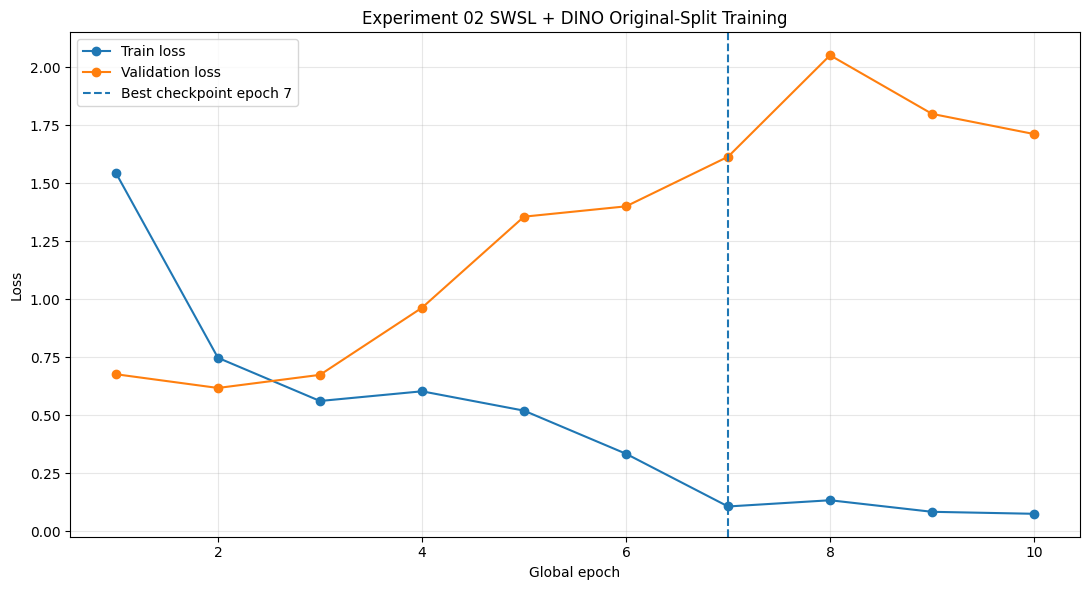

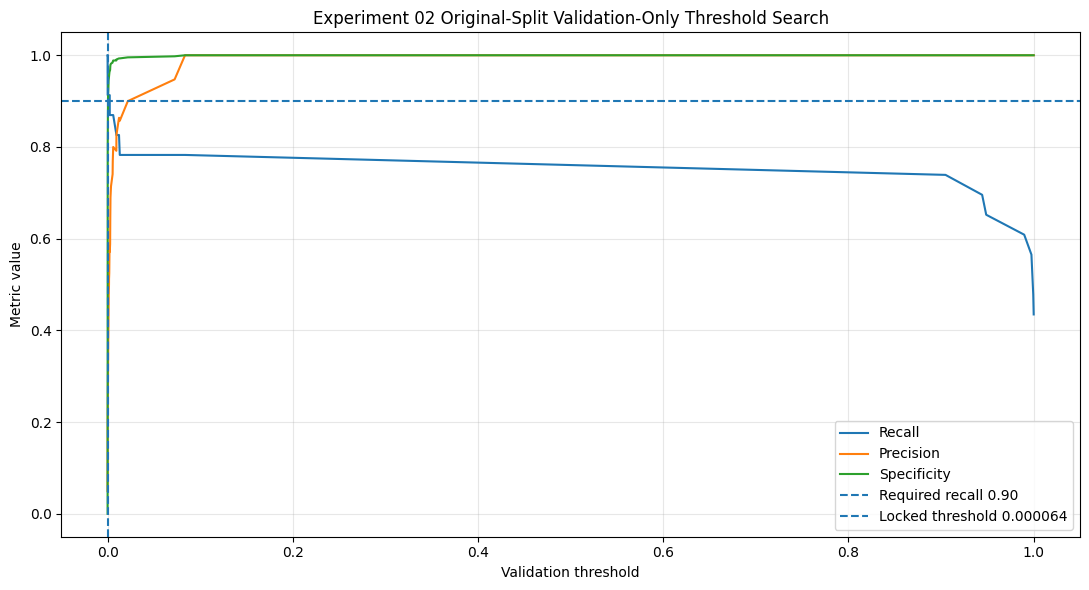


FINAL CELL 14A EXPERIMENT 02 REPORT
Source checkpoint: RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth
Best stage: stage_2
Best stage epoch: 4
Best global epoch: 7
Validation AUPRC: 0.890313
Validation AUROC: 0.960393
Locked threshold: 0.000064015388
Validation recall: 0.956522
Validation PPV: 0.144737
Validation specificity: 0.703196
Minimum centre recall: 0.888889
TP: 22
FP: 130
FN: 1
TN: 308

Held-out test CSV loaded: False
Held-out test predictions loaded: False
Held-out test evaluated: False
Held-out test used for checkpoint selection: False
Held-out test used for threshold selection: False

STATUS: EXP02_ORIGINAL_SPLIT_TRAINING_AND_VALIDATION_THRESHOLD_LOCK_COMPLETE

Saved records:
/content/drive/MyDrive/RARE26_GastroNet_Weights/models/original_split/experiment_02_swsl_gastronet5m_dinov1/exp02_swsl_dino_original_split_best.pth
/content/drive/MyDrive/RARE26_GastroNet_Weights/models/original_split/experiment_02_swsl_gastronet5m_dinov1/exp02_swsl_dino_original_split_latest.pth
/c

In [ ]:
# ============================================================
# RARE26 GASTRONET EXTENSION — CELL 14A
#
# EXPERIMENT 02 FINAL ORIGINAL-SPLIT TRAINING
# AND VALIDATION-ONLY THRESHOLD LOCK
#
# Pretrained checkpoint:
# RN50_Billion-Scale-SWSL + GastroNet-5M DINOv1
#
# IMPORTANT:
# - Training uses original locked train split only.
# - Checkpoint selection uses original validation split only.
# - Threshold selection uses validation predictions only.
# - Held-out test is NOT loaded or evaluated.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display

import copy
import gc
import json
import math
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
)

from tqdm.auto import tqdm


warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = True


# ============================================================
# 1. FIXED CONFIGURATION
# ============================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

TRAIN_CSV_PATH = (
    PROJECT_ROOT
    / "configs"
    / "runtime_splits"
    / "train_runtime_verified.csv"
)

VALIDATION_CSV_PATH = (
    PROJECT_ROOT
    / "configs"
    / "runtime_splits"
    / "validation_runtime_verified.csv"
)

SOURCE_CHECKPOINT_PATH = (
    PROJECT_ROOT
    / "source_checkpoints"
    / "RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth"
)

CELL13E_DECISION_PATH = (
    PROJECT_ROOT
    / "results"
    / "cross_validation"
    / "controlled_comparisons"
    / "experiment_01_vs_experiment_02"
    / "cell13e_development_model_decision.json"
)

CELL13E_STATUS_PATH = (
    PROJECT_ROOT
    / "results"
    / "cross_validation"
    / "controlled_comparisons"
    / "experiment_01_vs_experiment_02"
    / "cell13e_status.json"
)


EXPERIMENT_NAME = (
    "experiment_02_swsl_gastronet5m_dinov1"
)

EXPERIMENT_ID = (
    "exp02_swsl_dino_original_split"
)

FINAL_STATUS = (
    "EXP02_ORIGINAL_SPLIT_TRAINING_AND_"
    "VALIDATION_THRESHOLD_LOCK_COMPLETE"
)


RANDOM_SEED = 42

IMAGE_SIZE = 224
RESIZE_SIZE = 256

BATCH_SIZE = 32
NUM_WORKERS = 2

STAGE_1_EPOCHS = 3
STAGE_2_MAX_EPOCHS = 7
STAGE_2_EARLY_STOPPING_PATIENCE = 3

STAGE_1_HEAD_LR = 1e-3

STAGE_2_BACKBONE_LR = 1e-5
STAGE_2_HEAD_LR = 1e-4

WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0

REQUIRED_OVERALL_RECALL = 0.90
REQUIRED_MINIMUM_CENTRE_RECALL = 0.80


# ============================================================
# 2. OUTPUT DIRECTORIES
# ============================================================

MODEL_DIR = (
    PROJECT_ROOT
    / "models"
    / "original_split"
    / EXPERIMENT_NAME
)

LOG_DIR = (
    PROJECT_ROOT
    / "logs"
    / "original_split"
    / EXPERIMENT_NAME
)

PREDICTION_DIR = (
    PROJECT_ROOT
    / "predictions"
    / "original_split"
    / EXPERIMENT_NAME
)

RESULT_DIR = (
    PROJECT_ROOT
    / "results"
    / "original_split"
    / EXPERIMENT_NAME
)

THRESHOLD_DIR = (
    PROJECT_ROOT
    / "thresholds"
    / "original_split"
    / EXPERIMENT_NAME
)

CENTRE_DIR = (
    PROJECT_ROOT
    / "centre_analysis"
    / "original_split"
    / EXPERIMENT_NAME
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "figures"
    / "original_split"
    / EXPERIMENT_NAME
)

CONFIG_DIR = (
    PROJECT_ROOT
    / "configs"
    / "original_split"
    / EXPERIMENT_NAME
)


for directory in [
    MODEL_DIR,
    LOG_DIR,
    PREDICTION_DIR,
    RESULT_DIR,
    THRESHOLD_DIR,
    CENTRE_DIR,
    FIGURE_DIR,
    CONFIG_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 3. OUTPUT FILE PATHS
# ============================================================

BEST_MODEL_PATH = (
    MODEL_DIR
    / f"{EXPERIMENT_ID}_best.pth"
)

LATEST_MODEL_PATH = (
    MODEL_DIR
    / f"{EXPERIMENT_ID}_latest.pth"
)

TRAINING_HISTORY_PATH = (
    LOG_DIR
    / f"{EXPERIMENT_ID}_training_history.csv"
)

VALIDATION_PREDICTIONS_PATH = (
    PREDICTION_DIR
    / f"{EXPERIMENT_ID}_validation_predictions.csv"
)

LOCKED_VALIDATION_PREDICTIONS_PATH = (
    PREDICTION_DIR
    / (
        f"{EXPERIMENT_ID}_validation_predictions_"
        "locked_threshold.csv"
    )
)

VALIDATION_METRICS_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_validation_metrics.csv"
)

THRESHOLD_SEARCH_PATH = (
    THRESHOLD_DIR
    / f"{EXPERIMENT_ID}_validation_threshold_search.csv"
)

THRESHOLD_OPERATING_POINT_PATH = (
    THRESHOLD_DIR
    / f"{EXPERIMENT_ID}_validation_operating_point.csv"
)

THRESHOLD_LOCK_PATH = (
    THRESHOLD_DIR
    / f"{EXPERIMENT_ID}_threshold_lock.json"
)

CENTRE_METRICS_PATH = (
    CENTRE_DIR
    / f"{EXPERIMENT_ID}_validation_per_centre_metrics.csv"
)

TRAINING_FIGURE_PATH = (
    FIGURE_DIR
    / f"{EXPERIMENT_ID}_training_curves.png"
)

THRESHOLD_FIGURE_PATH = (
    FIGURE_DIR
    / f"{EXPERIMENT_ID}_validation_threshold_analysis.png"
)

CONFIG_PATH = (
    CONFIG_DIR
    / f"{EXPERIMENT_ID}_configuration.json"
)

STATUS_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_status.json"
)

SUMMARY_PATH = (
    RESULT_DIR
    / f"{EXPERIMENT_ID}_summary.txt"
)


# ============================================================
# 4. REPRODUCIBILITY
# ============================================================

def set_reproducibility(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True


set_reproducibility(
    RANDOM_SEED
)


# ============================================================
# 5. INITIAL REPORT
# ============================================================

print("=" * 92)
print(
    "CELL 14A: EXPERIMENT 02 FINAL ORIGINAL-SPLIT "
    "TRAINING AND VALIDATION THRESHOLD LOCK"
)
print("=" * 92)

print("\nTraining split:")
print(TRAIN_CSV_PATH)

print("\nValidation split:")
print(VALIDATION_CSV_PATH)

print("\nPretrained checkpoint:")
print(SOURCE_CHECKPOINT_PATH)

print("\nHeld-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("Held-out test used for any decision: False")


# ============================================================
# 6. VERIFY REQUIRED FILES
# ============================================================

required_files = [
    TRAIN_CSV_PATH,
    VALIDATION_CSV_PATH,
    SOURCE_CHECKPOINT_PATH,
    CELL13E_DECISION_PATH,
    CELL13E_STATUS_PATH,
]

missing_files = [
    path
    for path in required_files
    if not path.exists()
]

if missing_files:

    print("\nMissing required files:")

    for path in missing_files:
        print(path)

    raise FileNotFoundError(
        "\nCell 14A cannot run because one or more "
        "required verified files are missing."
    )


cell13e_status = json.loads(
    CELL13E_STATUS_PATH.read_text(
        encoding="utf-8"
    )
)

expected_cell13e_status = (
    "EXP02_THREE_FOLD_AGGREGATE_AND_"
    "EXP01_COMPARISON_COMPLETE"
)

if (
    cell13e_status.get("status")
    != expected_cell13e_status
):

    raise RuntimeError(
        "Cell 13E completion status is not valid.\n"
        f"Actual status: {cell13e_status.get('status')}"
    )


cell13e_decision = json.loads(
    CELL13E_DECISION_PATH.read_text(
        encoding="utf-8"
    )
)

if (
    cell13e_decision.get("decision")
    != "EXPERIMENT_02_DEVELOPMENT_LEAD"
):

    raise RuntimeError(
        "Experiment 02 was not locked as the "
        "development lead in Cell 13E.\n"
        f"Decision: {cell13e_decision.get('decision')}"
    )


print(
    "\nCell 13E development decision verified:"
)

print(
    cell13e_decision.get("decision")
)


# ============================================================
# 7. COMPUTE DEVICE
# ============================================================

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

AMP_ENABLED = (
    DEVICE.type == "cuda"
)


print("\nCompute device:")
print(DEVICE)

if DEVICE.type == "cuda":
    print(
        torch.cuda.get_device_name(0)
    )


# ============================================================
# 8. COLUMN HELPERS
# ============================================================

def first_existing_column(
    dataframe,
    candidates,
    description,
):

    for column in candidates:

        if column in dataframe.columns:
            return column

    raise RuntimeError(
        f"Could not identify {description} column.\n"
        f"Available columns:\n"
        f"{list(dataframe.columns)}"
    )


def standardize_split_dataframe(
    dataframe,
    split_name,
):

    dataframe = dataframe.copy()


    path_column = first_existing_column(
        dataframe,
        [
            "runtime_path",
            "image_path",
            "filepath",
            "file_path",
            "path",
        ],
        "runtime image path",
    )

    label_column = first_existing_column(
        dataframe,
        [
            "label",
            "target",
            "class_label",
        ],
        "label",
    )

    center_column = first_existing_column(
        dataframe,
        [
            "center",
            "centre",
        ],
        "center",
    )

    relative_path_column = first_existing_column(
        dataframe,
        [
            "relative_path",
            "original_relative_path",
            "image_relative_path",
        ],
        "relative path",
    )


    sha_column = None

    for candidate in [
        "sha256",
        "image_sha256",
        "file_sha256",
    ]:

        if candidate in dataframe.columns:
            sha_column = candidate
            break


    standardized = pd.DataFrame(
        {
            "runtime_path": (
                dataframe[
                    path_column
                ].astype(str)
            ),

            "relative_path": (
                dataframe[
                    relative_path_column
                ].astype(str)
            ),

            "label": (
                dataframe[
                    label_column
                ].astype(int)
            ),

            "center": (
                dataframe[
                    center_column
                ].astype(str)
            ),

            "split": (
                split_name
            ),
        }
    )


    if sha_column is not None:

        standardized[
            "sha256"
        ] = dataframe[
            sha_column
        ].astype(str)

    else:

        standardized[
            "sha256"
        ] = standardized[
            "relative_path"
        ].astype(str)


    return standardized


# ============================================================
# 9. LOAD AND VERIFY ORIGINAL SPLITS
# ============================================================

train_df = standardize_split_dataframe(
    pd.read_csv(
        TRAIN_CSV_PATH,
        low_memory=False,
    ),
    "train",
)

validation_df = standardize_split_dataframe(
    pd.read_csv(
        VALIDATION_CSV_PATH,
        low_memory=False,
    ),
    "validation",
)


expected_train = {
    "total": 2159,
    "normal": 2050,
    "positive": 109,
}

expected_validation = {
    "total": 461,
    "normal": 438,
    "positive": 23,
}


def verify_split_counts(
    dataframe,
    expected,
    split_name,
):

    actual_total = int(
        len(dataframe)
    )

    actual_normal = int(
        (
            dataframe["label"] == 0
        ).sum()
    )

    actual_positive = int(
        (
            dataframe["label"] == 1
        ).sum()
    )


    if (
        actual_total != expected["total"]
        or actual_normal != expected["normal"]
        or actual_positive != expected["positive"]
    ):

        raise RuntimeError(
            f"{split_name} split count mismatch.\n"
            f"Actual total={actual_total}, "
            f"normal={actual_normal}, "
            f"positive={actual_positive}"
        )


verify_split_counts(
    train_df,
    expected_train,
    "Train",
)

verify_split_counts(
    validation_df,
    expected_validation,
    "Validation",
)


train_case_ids = set(
    train_df["sha256"]
)

validation_case_ids = set(
    validation_df["sha256"]
)

overlap_count = len(
    train_case_ids
    & validation_case_ids
)

if overlap_count != 0:

    raise RuntimeError(
        f"Train/validation overlap detected: "
        f"{overlap_count} cases."
    )


missing_train_images = [
    path
    for path in train_df["runtime_path"]
    if not Path(path).exists()
]

missing_validation_images = [
    path
    for path in validation_df["runtime_path"]
    if not Path(path).exists()
]


if missing_train_images:

    raise FileNotFoundError(
        f"{len(missing_train_images)} training images "
        "are missing from runtime storage.\n"
        "Run Cell 3B again."
    )


if missing_validation_images:

    raise FileNotFoundError(
        f"{len(missing_validation_images)} validation images "
        "are missing from runtime storage.\n"
        "Run Cell 3B again."
    )


print("\nOriginal locked split verification:")

print(
    f"Train: {len(train_df)} "
    f"(normal={(train_df['label'] == 0).sum()}, "
    f"NEO={(train_df['label'] == 1).sum()})"
)

print(
    f"Validation: {len(validation_df)} "
    f"(normal={(validation_df['label'] == 0).sum()}, "
    f"NEO={(validation_df['label'] == 1).sum()})"
)

print(
    f"Train/validation overlap: "
    f"{overlap_count}"
)

print(
    "Missing training images: "
    f"{len(missing_train_images)}"
)

print(
    "Missing validation images: "
    f"{len(missing_validation_images)}"
)


# ============================================================
# 10. IMAGE TRANSFORMS
# ============================================================

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406,
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225,
]


train_transform = transforms.Compose(
    [
        transforms.Resize(
            RESIZE_SIZE
        ),

        transforms.RandomResizedCrop(
            IMAGE_SIZE,
            scale=(
                0.85,
                1.0,
            ),
            ratio=(
                0.90,
                1.10,
            ),
        ),

        transforms.RandomHorizontalFlip(
            p=0.5
        ),

        transforms.RandomRotation(
            degrees=8,
            fill=tuple(
                int(
                    value * 255
                )
                for value in IMAGENET_MEAN
            ),
        ),

        transforms.ColorJitter(
            brightness=0.10,
            contrast=0.10,
            saturation=0.05,
            hue=0.02,
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)


validation_transform = transforms.Compose(
    [
        transforms.Resize(
            RESIZE_SIZE
        ),

        transforms.CenterCrop(
            IMAGE_SIZE
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)


# ============================================================
# 11. DATASET CLASS
# ============================================================

class RARE26ImageDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform,
    ):

        self.dataframe = (
            dataframe
            .reset_index(
                drop=True
            )
            .copy()
        )

        self.transform = transform


    def __len__(self):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        index,
    ):

        row = self.dataframe.iloc[
            index
        ]

        image_path = Path(
            row["runtime_path"]
        )


        try:

            with Image.open(
                image_path
            ) as image:

                image = image.convert(
                    "RGB"
                )

                image_tensor = (
                    self.transform(
                        image
                    )
                )

        except Exception as error:

            raise RuntimeError(
                f"Failed to load image:\n"
                f"{image_path}\n"
                f"Error: {error}"
            )


        label_tensor = torch.tensor(
            float(
                row["label"]
            ),
            dtype=torch.float32,
        )


        return {
            "image": image_tensor,
            "label": label_tensor,
            "relative_path": str(
                row["relative_path"]
            ),
            "runtime_path": str(
                row["runtime_path"]
            ),
            "sha256": str(
                row["sha256"]
            ),
            "center": str(
                row["center"]
            ),
        }


train_dataset = RARE26ImageDataset(
    train_df,
    train_transform,
)

validation_dataset = RARE26ImageDataset(
    validation_df,
    validation_transform,
)


loader_generator = torch.Generator()
loader_generator.manual_seed(
    RANDOM_SEED
)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=AMP_ENABLED,
    drop_last=False,
    persistent_workers=(
        NUM_WORKERS > 0
    ),
    generator=loader_generator,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=AMP_ENABLED,
    drop_last=False,
    persistent_workers=(
        NUM_WORKERS > 0
    ),
)


print("\nData loaders:")

print(
    f"Training batches: "
    f"{len(train_loader)}"
)

print(
    f"Validation batches: "
    f"{len(validation_loader)}"
)


# ============================================================
# 12. CHECKPOINT CLEANING HELPER
# ============================================================

def extract_state_dict(
    checkpoint_object,
):

    if isinstance(
        checkpoint_object,
        dict,
    ):

        for key in [
            "state_dict",
            "model_state_dict",
            "model",
            "network",
            "teacher",
            "student",
        ]:

            if (
                key in checkpoint_object
                and isinstance(
                    checkpoint_object[key],
                    dict,
                )
            ):

                return checkpoint_object[
                    key
                ]


    return checkpoint_object


def clean_checkpoint_keys(
    state_dict,
):

    cleaned_state_dict = {}


    removable_prefixes = [
        "module.",
        "model.",
        "backbone.",
        "encoder.",
        "student.",
        "teacher.",
    ]


    for original_key, value in state_dict.items():

        key = str(
            original_key
        )


        prefix_removed = True

        while prefix_removed:

            prefix_removed = False

            for prefix in removable_prefixes:

                if key.startswith(
                    prefix
                ):

                    key = key[
                        len(prefix):
                    ]

                    prefix_removed = True


        cleaned_state_dict[
            key
        ] = value


    return cleaned_state_dict


# ============================================================
# 13. BUILD MODEL AND LOAD SWSL + DINO BACKBONE
# ============================================================

model = models.resnet50(
    weights=None
)

model.fc = nn.Linear(
    model.fc.in_features,
    1,
)


raw_checkpoint = torch.load(
    SOURCE_CHECKPOINT_PATH,
    map_location="cpu",
)

source_state_dict = extract_state_dict(
    raw_checkpoint
)

source_state_dict = clean_checkpoint_keys(
    source_state_dict
)


model_state_template = model.state_dict()

compatible_state_dict = {}

shape_mismatches = []


for key, value in source_state_dict.items():

    if key not in model_state_template:
        continue

    if (
        tuple(value.shape)
        != tuple(
            model_state_template[key].shape
        )
    ):

        shape_mismatches.append(
            {
                "key": key,
                "checkpoint_shape": tuple(
                    value.shape
                ),
                "model_shape": tuple(
                    model_state_template[
                        key
                    ].shape
                ),
            }
        )

        continue


    compatible_state_dict[
        key
    ] = value


missing_keys, unexpected_keys = (
    model.load_state_dict(
        compatible_state_dict,
        strict=False,
    )
)


allowed_missing_keys = {
    "fc.weight",
    "fc.bias",
}

unexpected_missing = set(
    missing_keys
) - allowed_missing_keys


if unexpected_missing:

    raise RuntimeError(
        "Unexpected missing pretrained backbone "
        f"parameters:\n{sorted(unexpected_missing)}"
    )


if unexpected_keys:

    raise RuntimeError(
        "Unexpected checkpoint parameters after cleaning:\n"
        f"{unexpected_keys}"
    )


if shape_mismatches:

    raise RuntimeError(
        "Checkpoint shape mismatches detected:\n"
        f"{shape_mismatches[:10]}"
    )


matched_backbone_count = len(
    [
        key
        for key in compatible_state_dict
        if not key.startswith("fc.")
    ]
)


if matched_backbone_count != 318:

    raise RuntimeError(
        "Expected 318 compatible ResNet-50 backbone "
        f"tensors, found {matched_backbone_count}."
    )


model = model.to(
    DEVICE
)


print(
    "\nExperiment 02 SWSL + DINO backbone loaded:"
)

print(
    f"Matched backbone tensors: "
    f"{matched_backbone_count}/318"
)

print(
    f"Missing parameters: "
    f"{missing_keys}"
)

print(
    f"Unexpected parameters: "
    f"{unexpected_keys}"
)

print(
    "New classification head: "
    "Linear(2048, 1)"
)


# ============================================================
# 14. LOSS FUNCTION
# ============================================================

train_normal_count = int(
    (
        train_df["label"] == 0
    ).sum()
)

train_positive_count = int(
    (
        train_df["label"] == 1
    ).sum()
)

positive_weight_value = (
    train_normal_count
    / train_positive_count
)

positive_weight_tensor = torch.tensor(
    [
        positive_weight_value
    ],
    dtype=torch.float32,
    device=DEVICE,
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=positive_weight_tensor
)


print("\nLocked training protocol:")

print(
    f"Positive weight: "
    f"{positive_weight_value:.6f}"
)

print(
    f"Stage 1: classification head only, "
    f"{STAGE_1_EPOCHS} epochs"
)

print(
    f"Stage 2: layer4 + classification head, "
    f"maximum {STAGE_2_MAX_EPOCHS} epochs"
)

print(
    "Checkpoint selection: validation AUPRC"
)

print(
    "Threshold selection: validation predictions only"
)


# ============================================================
# 15. AMP SCALER
# ============================================================

try:

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=AMP_ENABLED,
    )

except Exception:

    scaler = torch.cuda.amp.GradScaler(
        enabled=AMP_ENABLED
    )


def autocast_context():

    try:

        return torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=AMP_ENABLED,
        )

    except Exception:

        return torch.cuda.amp.autocast(
            enabled=AMP_ENABLED
        )


# ============================================================
# 16. TRAINING AND VALIDATION HELPERS
# ============================================================

def train_one_epoch(
    model,
    data_loader,
    optimizer,
):

    model.train()

    running_loss = 0.0
    sample_count = 0


    progress_bar = tqdm(
        data_loader,
        desc="Training",
        leave=False,
    )


    for batch in progress_bar:

        images = batch[
            "image"
        ].to(
            DEVICE,
            non_blocking=True,
        )

        labels = batch[
            "label"
        ].to(
            DEVICE,
            non_blocking=True,
        ).view(
            -1,
            1,
        )


        optimizer.zero_grad(
            set_to_none=True
        )


        with autocast_context():

            logits = model(
                images
            )

            loss = criterion(
                logits,
                labels,
            )


        scaler.scale(
            loss
        ).backward()


        scaler.unscale_(
            optimizer
        )


        torch.nn.utils.clip_grad_norm_(
            [
                parameter
                for parameter in model.parameters()
                if parameter.requires_grad
            ],
            max_norm=GRADIENT_CLIP_NORM,
        )


        scaler.step(
            optimizer
        )

        scaler.update()


        batch_size = int(
            labels.shape[0]
        )

        running_loss += (
            float(
                loss.item()
            )
            * batch_size
        )

        sample_count += batch_size


        progress_bar.set_postfix(
            loss=(
                running_loss
                / max(
                    sample_count,
                    1,
                )
            )
        )


    return float(
        running_loss
        / max(
            sample_count,
            1,
        )
    )


@torch.no_grad()
def evaluate_model(
    model,
    data_loader,
):

    model.eval()

    running_loss = 0.0
    sample_count = 0

    all_logits = []
    all_probabilities = []
    all_labels = []

    all_relative_paths = []
    all_runtime_paths = []
    all_sha256 = []
    all_centres = []


    progress_bar = tqdm(
        data_loader,
        desc="Validation",
        leave=False,
    )


    for batch in progress_bar:

        images = batch[
            "image"
        ].to(
            DEVICE,
            non_blocking=True,
        )

        labels = batch[
            "label"
        ].to(
            DEVICE,
            non_blocking=True,
        ).view(
            -1,
            1,
        )


        with autocast_context():

            logits = model(
                images
            )

            loss = criterion(
                logits,
                labels,
            )


        probabilities = torch.sigmoid(
            logits
        )


        batch_size = int(
            labels.shape[0]
        )

        running_loss += (
            float(
                loss.item()
            )
            * batch_size
        )

        sample_count += batch_size


        all_logits.extend(
            logits.detach()
            .float()
            .cpu()
            .numpy()
            .reshape(-1)
            .tolist()
        )

        all_probabilities.extend(
            probabilities.detach()
            .float()
            .cpu()
            .numpy()
            .reshape(-1)
            .tolist()
        )

        all_labels.extend(
            labels.detach()
            .float()
            .cpu()
            .numpy()
            .reshape(-1)
            .astype(int)
            .tolist()
        )

        all_relative_paths.extend(
            list(
                batch[
                    "relative_path"
                ]
            )
        )

        all_runtime_paths.extend(
            list(
                batch[
                    "runtime_path"
                ]
            )
        )

        all_sha256.extend(
            list(
                batch[
                    "sha256"
                ]
            )
        )

        all_centres.extend(
            list(
                batch[
                    "center"
                ]
            )
        )


    labels_array = np.asarray(
        all_labels,
        dtype=int,
    )

    probability_array = np.asarray(
        all_probabilities,
        dtype=float,
    )


    validation_auprc = float(
        average_precision_score(
            labels_array,
            probability_array,
        )
    )

    validation_auroc = float(
        roc_auc_score(
            labels_array,
            probability_array,
        )
    )


    default_predictions = (
        probability_array >= 0.5
    ).astype(int)


    tn, fp, fn, tp = confusion_matrix(
        labels_array,
        default_predictions,
        labels=[
            0,
            1,
        ],
    ).ravel()


    default_recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0.0
    )

    default_precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0.0
    )

    default_specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )


    prediction_dataframe = pd.DataFrame(
        {
            "experiment_id": (
                EXPERIMENT_ID
            ),

            "relative_path": (
                all_relative_paths
            ),

            "runtime_path": (
                all_runtime_paths
            ),

            "sha256": (
                all_sha256
            ),

            "center": (
                all_centres
            ),

            "label": (
                labels_array
            ),

            "logit": np.asarray(
                all_logits,
                dtype=float,
            ),

            "probability": (
                probability_array
            ),
        }
    )


    return {
        "validation_loss": float(
            running_loss
            / max(
                sample_count,
                1,
            )
        ),

        "validation_auprc": (
            validation_auprc
        ),

        "validation_auroc": (
            validation_auroc
        ),

        "default_recall": float(
            default_recall
        ),

        "default_precision": float(
            default_precision
        ),

        "default_specificity": float(
            default_specificity
        ),

        "predictions": (
            prediction_dataframe
        ),
    }


# ============================================================
# 17. BEST CHECKPOINT TRACKING
# ============================================================

training_history = []

best_validation_auprc = -np.inf
best_validation_auroc = -np.inf

best_stage = None
best_stage_epoch = None
best_global_epoch = None

best_prediction_dataframe = None

global_epoch = 0


def save_best_checkpoint(
    model,
    stage_name,
    stage_epoch,
    global_epoch_number,
    evaluation_result,
):

    checkpoint_record = {
        "experiment_id": (
            EXPERIMENT_ID
        ),

        "experiment_name": (
            EXPERIMENT_NAME
        ),

        "source_checkpoint": (
            SOURCE_CHECKPOINT_PATH.name
        ),

        "model_architecture": (
            "torchvision_resnet50_binary_classifier"
        ),

        "model_state_dict": copy.deepcopy(
            model.state_dict()
        ),

        "best_stage": (
            stage_name
        ),

        "best_stage_epoch": int(
            stage_epoch
        ),

        "best_global_epoch": int(
            global_epoch_number
        ),

        "validation_auprc": float(
            evaluation_result[
                "validation_auprc"
            ]
        ),

        "validation_auroc": float(
            evaluation_result[
                "validation_auroc"
            ]
        ),

        "training_split": str(
            TRAIN_CSV_PATH
        ),

        "validation_split": str(
            VALIDATION_CSV_PATH
        ),

        "held_out_test_loaded": False,

        "held_out_test_evaluated": False,

        "created_utc": datetime.now(
            timezone.utc
        ).isoformat(),
    }


    torch.save(
        checkpoint_record,
        BEST_MODEL_PATH,
    )


# ============================================================
# 18. STAGE 1 — CLASSIFICATION HEAD ONLY
# ============================================================

for parameter in model.parameters():
    parameter.requires_grad = False

for parameter in model.fc.parameters():
    parameter.requires_grad = True


stage_1_optimizer = torch.optim.AdamW(
    model.fc.parameters(),
    lr=STAGE_1_HEAD_LR,
    weight_decay=WEIGHT_DECAY,
)

stage_1_scheduler = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        stage_1_optimizer,
        T_max=STAGE_1_EPOCHS,
    )
)


print("\n" + "-" * 92)
print("STAGE 1: CLASSIFICATION HEAD ONLY")
print("-" * 92)


for stage_epoch in range(
    1,
    STAGE_1_EPOCHS + 1,
):

    global_epoch += 1


    train_loss = train_one_epoch(
        model,
        train_loader,
        stage_1_optimizer,
    )


    evaluation_result = evaluate_model(
        model,
        validation_loader,
    )


    current_head_lr = float(
        stage_1_optimizer.param_groups[
            0
        ]["lr"]
    )


    training_history.append(
        {
            "stage": (
                "stage_1"
            ),

            "stage_epoch": int(
                stage_epoch
            ),

            "global_epoch": int(
                global_epoch
            ),

            "train_loss": float(
                train_loss
            ),

            "validation_loss": float(
                evaluation_result[
                    "validation_loss"
                ]
            ),

            "validation_auprc": float(
                evaluation_result[
                    "validation_auprc"
                ]
            ),

            "validation_auroc": float(
                evaluation_result[
                    "validation_auroc"
                ]
            ),

            "default_recall": float(
                evaluation_result[
                    "default_recall"
                ]
            ),

            "default_precision": float(
                evaluation_result[
                    "default_precision"
                ]
            ),

            "default_specificity": float(
                evaluation_result[
                    "default_specificity"
                ]
            ),

            "learning_rate_backbone": 0.0,

            "learning_rate_head": (
                current_head_lr
            ),
        }
    )


    print(
        f"Stage 1 | Epoch "
        f"{stage_epoch}/{STAGE_1_EPOCHS} | "
        f"Global {global_epoch} | "
        f"Train loss {train_loss:.6f} | "
        f"Val loss "
        f"{evaluation_result['validation_loss']:.6f} | "
        f"AUPRC "
        f"{evaluation_result['validation_auprc']:.6f} | "
        f"AUROC "
        f"{evaluation_result['validation_auroc']:.6f}"
    )


    if (
        evaluation_result[
            "validation_auprc"
        ]
        > best_validation_auprc
    ):

        best_validation_auprc = float(
            evaluation_result[
                "validation_auprc"
            ]
        )

        best_validation_auroc = float(
            evaluation_result[
                "validation_auroc"
            ]
        )

        best_stage = "stage_1"
        best_stage_epoch = int(
            stage_epoch
        )
        best_global_epoch = int(
            global_epoch
        )

        best_prediction_dataframe = (
            evaluation_result[
                "predictions"
            ].copy()
        )


        save_best_checkpoint(
            model,
            best_stage,
            best_stage_epoch,
            best_global_epoch,
            evaluation_result,
        )


    stage_1_scheduler.step()


# ============================================================
# 19. STAGE 2 — LAYER4 + HEAD
# ============================================================

for parameter in model.parameters():
    parameter.requires_grad = False

for parameter in model.layer4.parameters():
    parameter.requires_grad = True

for parameter in model.fc.parameters():
    parameter.requires_grad = True


stage_2_optimizer = torch.optim.AdamW(
    [
        {
            "params": (
                model.layer4.parameters()
            ),
            "lr": STAGE_2_BACKBONE_LR,
        },

        {
            "params": (
                model.fc.parameters()
            ),
            "lr": STAGE_2_HEAD_LR,
        },
    ],

    weight_decay=WEIGHT_DECAY,
)


stage_2_scheduler = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        stage_2_optimizer,
        T_max=STAGE_2_MAX_EPOCHS,
    )
)


stage_2_epochs_without_improvement = 0


print("\n" + "-" * 92)
print("STAGE 2: LAYER4 AND CLASSIFICATION HEAD")
print("-" * 92)


for stage_epoch in range(
    1,
    STAGE_2_MAX_EPOCHS + 1,
):

    global_epoch += 1


    train_loss = train_one_epoch(
        model,
        train_loader,
        stage_2_optimizer,
    )


    evaluation_result = evaluate_model(
        model,
        validation_loader,
    )


    current_backbone_lr = float(
        stage_2_optimizer.param_groups[
            0
        ]["lr"]
    )

    current_head_lr = float(
        stage_2_optimizer.param_groups[
            1
        ]["lr"]
    )


    training_history.append(
        {
            "stage": (
                "stage_2"
            ),

            "stage_epoch": int(
                stage_epoch
            ),

            "global_epoch": int(
                global_epoch
            ),

            "train_loss": float(
                train_loss
            ),

            "validation_loss": float(
                evaluation_result[
                    "validation_loss"
                ]
            ),

            "validation_auprc": float(
                evaluation_result[
                    "validation_auprc"
                ]
            ),

            "validation_auroc": float(
                evaluation_result[
                    "validation_auroc"
                ]
            ),

            "default_recall": float(
                evaluation_result[
                    "default_recall"
                ]
            ),

            "default_precision": float(
                evaluation_result[
                    "default_precision"
                ]
            ),

            "default_specificity": float(
                evaluation_result[
                    "default_specificity"
                ]
            ),

            "learning_rate_backbone": (
                current_backbone_lr
            ),

            "learning_rate_head": (
                current_head_lr
            ),
        }
    )


    print(
        f"Stage 2 | Epoch "
        f"{stage_epoch}/{STAGE_2_MAX_EPOCHS} | "
        f"Global {global_epoch} | "
        f"Train loss {train_loss:.6f} | "
        f"Val loss "
        f"{evaluation_result['validation_loss']:.6f} | "
        f"AUPRC "
        f"{evaluation_result['validation_auprc']:.6f} | "
        f"AUROC "
        f"{evaluation_result['validation_auroc']:.6f}"
    )


    if (
        evaluation_result[
            "validation_auprc"
        ]
        > best_validation_auprc
    ):

        best_validation_auprc = float(
            evaluation_result[
                "validation_auprc"
            ]
        )

        best_validation_auroc = float(
            evaluation_result[
                "validation_auroc"
            ]
        )

        best_stage = "stage_2"

        best_stage_epoch = int(
            stage_epoch
        )

        best_global_epoch = int(
            global_epoch
        )

        best_prediction_dataframe = (
            evaluation_result[
                "predictions"
            ].copy()
        )


        save_best_checkpoint(
            model,
            best_stage,
            best_stage_epoch,
            best_global_epoch,
            evaluation_result,
        )


        stage_2_epochs_without_improvement = 0

    else:

        stage_2_epochs_without_improvement += 1


    latest_checkpoint_record = {
        "experiment_id": (
            EXPERIMENT_ID
        ),

        "model_state_dict": (
            model.state_dict()
        ),

        "stage": (
            "stage_2"
        ),

        "stage_epoch": int(
            stage_epoch
        ),

        "global_epoch": int(
            global_epoch
        ),

        "validation_auprc": float(
            evaluation_result[
                "validation_auprc"
            ]
        ),

        "validation_auroc": float(
            evaluation_result[
                "validation_auroc"
            ]
        ),

        "held_out_test_loaded": False,

        "held_out_test_evaluated": False,
    }


    torch.save(
        latest_checkpoint_record,
        LATEST_MODEL_PATH,
    )


    stage_2_scheduler.step()


    if (
        stage_2_epochs_without_improvement
        >= STAGE_2_EARLY_STOPPING_PATIENCE
    ):

        print(
            "\nEarly stopping activated after "
            f"{STAGE_2_EARLY_STOPPING_PATIENCE} "
            "consecutive Stage-2 epochs without "
            "validation AUPRC improvement."
        )

        break


# ============================================================
# 20. RESTORE BEST VALIDATION CHECKPOINT
# ============================================================

if not BEST_MODEL_PATH.exists():

    raise FileNotFoundError(
        "Best validation checkpoint was not saved."
    )


best_checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
)

model.load_state_dict(
    best_checkpoint[
        "model_state_dict"
    ]
)

model.eval()


final_best_evaluation = evaluate_model(
    model,
    validation_loader,
)


best_prediction_dataframe = (
    final_best_evaluation[
        "predictions"
    ].copy()
)


if (
    abs(
        final_best_evaluation[
            "validation_auprc"
        ]
        - best_validation_auprc
    )
    > 1e-6
):

    raise RuntimeError(
        "Restored best checkpoint AUPRC does not "
        "match the saved best validation AUPRC."
    )


best_prediction_dataframe.to_csv(
    VALIDATION_PREDICTIONS_PATH,
    index=False,
)


training_history_df = pd.DataFrame(
    training_history
)

training_history_df.to_csv(
    TRAINING_HISTORY_PATH,
    index=False,
)


print(
    "\nBest Experiment 02 original-split checkpoint:"
)

print(
    f"Stage: {best_stage}"
)

print(
    f"Stage epoch: {best_stage_epoch}"
)

print(
    f"Global epoch: {best_global_epoch}"
)

print(
    f"Validation AUPRC: "
    f"{best_validation_auprc:.6f}"
)

print(
    f"Validation AUROC: "
    f"{best_validation_auroc:.6f}"
)


# ============================================================
# 21. METRIC HELPER
# ============================================================

def safe_divide(
    numerator,
    denominator,
):

    if denominator == 0:
        return 0.0

    return float(
        numerator / denominator
    )


def calculate_operating_metrics(
    labels,
    probabilities,
    threshold,
):

    labels = np.asarray(
        labels,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    predictions = (
        probabilities >= threshold
    ).astype(int)


    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[
            0,
            1,
        ],
    ).ravel()


    recall = safe_divide(
        tp,
        tp + fn,
    )

    precision = safe_divide(
        tp,
        tp + fp,
    )

    specificity = safe_divide(
        tn,
        tn + fp,
    )

    npv = safe_divide(
        tn,
        tn + fn,
    )

    accuracy = safe_divide(
        tp + tn,
        len(labels),
    )

    balanced_accuracy = (
        recall + specificity
    ) / 2.0

    f1 = safe_divide(
        2.0 * precision * recall,
        precision + recall,
    )


    return {
        "threshold": float(
            threshold
        ),

        "recall": float(
            recall
        ),

        "precision": float(
            precision
        ),

        "specificity": float(
            specificity
        ),

        "npv": float(
            npv
        ),

        "accuracy": float(
            accuracy
        ),

        "balanced_accuracy": float(
            balanced_accuracy
        ),

        "f1": float(
            f1
        ),

        "tp": int(
            tp
        ),

        "tn": int(
            tn
        ),

        "fp": int(
            fp
        ),

        "fn": int(
            fn
        ),
    }


# ============================================================
# 22. VALIDATION-ONLY THRESHOLD SEARCH
# ============================================================

validation_labels = best_prediction_dataframe[
    "label"
].to_numpy(
    dtype=int
)

validation_probabilities = (
    best_prediction_dataframe[
        "probability"
    ].to_numpy(
        dtype=float
    )
)

validation_centres = best_prediction_dataframe[
    "center"
].astype(str).to_numpy()


candidate_thresholds = np.unique(
    np.concatenate(
        [
            np.asarray(
                [
                    0.0,
                    1.0,
                ],
                dtype=float,
            ),

            validation_probabilities,
        ]
    )
)


candidate_thresholds = np.sort(
    candidate_thresholds
)


threshold_rows = []


for threshold in candidate_thresholds:

    overall_metrics = (
        calculate_operating_metrics(
            validation_labels,
            validation_probabilities,
            float(
                threshold
            ),
        )
    )


    centre_recalls = {}


    for center in sorted(
        np.unique(
            validation_centres
        )
    ):

        center_mask = (
            validation_centres
            == center
        )


        centre_metrics = (
            calculate_operating_metrics(
                validation_labels[
                    center_mask
                ],

                validation_probabilities[
                    center_mask
                ],

                float(
                    threshold
                ),
            )
        )


        centre_recalls[
            center
        ] = float(
            centre_metrics[
                "recall"
            ]
        )


    minimum_centre_recall = float(
        min(
            centre_recalls.values()
        )
    )


    threshold_row = {
        **overall_metrics,

        "minimum_centre_recall": (
            minimum_centre_recall
        ),

        "strict_eligible": bool(
            overall_metrics[
                "recall"
            ]
            >= REQUIRED_OVERALL_RECALL

            and minimum_centre_recall
            >= REQUIRED_MINIMUM_CENTRE_RECALL
        ),

        "overall_recall_eligible": bool(
            overall_metrics[
                "recall"
            ]
            >= REQUIRED_OVERALL_RECALL
        ),
    }


    for center, recall_value in (
        centre_recalls.items()
    ):

        threshold_row[
            f"{center}_recall"
        ] = recall_value


    threshold_rows.append(
        threshold_row
    )


threshold_search_df = pd.DataFrame(
    threshold_rows
)


strict_eligible_df = (
    threshold_search_df[
        threshold_search_df[
            "strict_eligible"
        ]
    ].copy()
)


if len(
    strict_eligible_df
) > 0:

    selection_mode = (
        "overall_recall_0.90_and_"
        "minimum_centre_recall_0.80"
    )

    eligible_df = (
        strict_eligible_df
    )

else:

    selection_mode = (
        "fallback_overall_recall_0.90"
    )

    eligible_df = (
        threshold_search_df[
            threshold_search_df[
                "overall_recall_eligible"
            ]
        ].copy()
    )


if len(
    eligible_df
) == 0:

    raise RuntimeError(
        "No validation threshold achieved the "
        "required overall recall."
    )


eligible_df = eligible_df.sort_values(
    by=[
        "precision",
        "minimum_centre_recall",
        "specificity",
        "threshold",
    ],

    ascending=[
        False,
        False,
        False,
        False,
    ],
)


selected_row = eligible_df.iloc[
    0
].copy()


selected_threshold = float(
    selected_row[
        "threshold"
    ]
)


threshold_search_df.to_csv(
    THRESHOLD_SEARCH_PATH,
    index=False,
)


# ============================================================
# 23. LOCK VALIDATION PREDICTIONS
# ============================================================

locked_validation_df = (
    best_prediction_dataframe.copy()
)

locked_validation_df[
    "locked_threshold"
] = selected_threshold

locked_validation_df[
    "prediction"
] = (
    locked_validation_df[
        "probability"
    ].to_numpy(
        dtype=float
    )
    >= selected_threshold
).astype(int)


locked_validation_df[
    "correct"
] = (
    locked_validation_df[
        "prediction"
    ]
    == locked_validation_df[
        "label"
    ]
)


locked_validation_df[
    "error_type"
] = np.select(
    [
        (
            (
                locked_validation_df[
                    "label"
                ]
                == 0
            )
            &
            (
                locked_validation_df[
                    "prediction"
                ]
                == 1
            )
        ),

        (
            (
                locked_validation_df[
                    "label"
                ]
                == 1
            )
            &
            (
                locked_validation_df[
                    "prediction"
                ]
                == 0
            )
        ),
    ],

    [
        "FP",
        "FN",
    ],

    default="correct",
)


locked_validation_df.to_csv(
    LOCKED_VALIDATION_PREDICTIONS_PATH,
    index=False,
)


# ============================================================
# 24. OVERALL LOCKED VALIDATION METRICS
# ============================================================

selected_metrics = (
    calculate_operating_metrics(
        validation_labels,
        validation_probabilities,
        selected_threshold,
    )
)


selected_metrics_row = {
    "experiment_id": (
        EXPERIMENT_ID
    ),

    "experiment_name": (
        EXPERIMENT_NAME
    ),

    "source_checkpoint": (
        SOURCE_CHECKPOINT_PATH.name
    ),

    "best_stage": (
        best_stage
    ),

    "best_stage_epoch": int(
        best_stage_epoch
    ),

    "best_global_epoch": int(
        best_global_epoch
    ),

    "selection_mode": (
        selection_mode
    ),

    **selected_metrics,

    "auprc": float(
        best_validation_auprc
    ),

    "auroc": float(
        best_validation_auroc
    ),

    "held_out_test_loaded": False,

    "held_out_test_evaluated": False,
}


validation_metrics_df = pd.DataFrame(
    [
        selected_metrics_row
    ]
)


validation_metrics_df.to_csv(
    VALIDATION_METRICS_PATH,
    index=False,
)


pd.DataFrame(
    [
        selected_metrics_row
    ]
).to_csv(
    THRESHOLD_OPERATING_POINT_PATH,
    index=False,
)


# ============================================================
# 25. PER-CENTRE LOCKED VALIDATION METRICS
# ============================================================

centre_metric_rows = []


for center in sorted(
    locked_validation_df[
        "center"
    ].unique()
):

    centre_subset = locked_validation_df[
        locked_validation_df[
            "center"
        ]
        == center
    ].copy()


    centre_metrics = (
        calculate_operating_metrics(
            centre_subset[
                "label"
            ].to_numpy(
                dtype=int
            ),

            centre_subset[
                "probability"
            ].to_numpy(
                dtype=float
            ),

            selected_threshold,
        )
    )


    centre_auprc = float(
        average_precision_score(
            centre_subset[
                "label"
            ].to_numpy(
                dtype=int
            ),

            centre_subset[
                "probability"
            ].to_numpy(
                dtype=float
            ),
        )
    )


    centre_auroc = float(
        roc_auc_score(
            centre_subset[
                "label"
            ].to_numpy(
                dtype=int
            ),

            centre_subset[
                "probability"
            ].to_numpy(
                dtype=float
            ),
        )
    )


    centre_metric_rows.append(
        {
            "experiment_id": (
                EXPERIMENT_ID
            ),

            "experiment_name": (
                EXPERIMENT_NAME
            ),

            "center": (
                center
            ),

            "sample_count": int(
                len(
                    centre_subset
                )
            ),

            "normal_count": int(
                (
                    centre_subset[
                        "label"
                    ]
                    == 0
                ).sum()
            ),

            "positive_count": int(
                (
                    centre_subset[
                        "label"
                    ]
                    == 1
                ).sum()
            ),

            **centre_metrics,

            "auprc": (
                centre_auprc
            ),

            "auroc": (
                centre_auroc
            ),
        }
    )


centre_metrics_df = pd.DataFrame(
    centre_metric_rows
)


centre_metrics_df.to_csv(
    CENTRE_METRICS_PATH,
    index=False,
)


minimum_centre_recall = float(
    centre_metrics_df[
        "recall"
    ].min()
)


# ============================================================
# 26. THRESHOLD LOCK JSON
# ============================================================

threshold_lock_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": (
        "VALIDATION_THRESHOLD_LOCKED"
    ),

    "experiment_id": (
        EXPERIMENT_ID
    ),

    "experiment_name": (
        EXPERIMENT_NAME
    ),

    "source_checkpoint": (
        SOURCE_CHECKPOINT_PATH.name
    ),

    "checkpoint_path": str(
        BEST_MODEL_PATH
    ),

    "threshold": (
        selected_threshold
    ),

    "threshold_source": (
        "original_locked_validation_predictions_only"
    ),

    "selection_mode": (
        selection_mode
    ),

    "required_overall_recall": (
        REQUIRED_OVERALL_RECALL
    ),

    "required_minimum_centre_recall": (
        REQUIRED_MINIMUM_CENTRE_RECALL
    ),

    "validation_recall": float(
        selected_metrics[
            "recall"
        ]
    ),

    "validation_precision": float(
        selected_metrics[
            "precision"
        ]
    ),

    "validation_specificity": float(
        selected_metrics[
            "specificity"
        ]
    ),

    "minimum_centre_recall": (
        minimum_centre_recall
    ),

    "validation_auprc": float(
        best_validation_auprc
    ),

    "validation_auroc": float(
        best_validation_auroc
    ),

    "best_stage": (
        best_stage
    ),

    "best_stage_epoch": int(
        best_stage_epoch
    ),

    "best_global_epoch": int(
        best_global_epoch
    ),

    "test_threshold_search_performed": False,

    "held_out_test_loaded": False,

    "held_out_test_predictions_loaded": False,

    "held_out_test_evaluated": False,

    "held_out_test_used_for_checkpoint_selection": False,

    "held_out_test_used_for_threshold_selection": False,
}


THRESHOLD_LOCK_PATH.write_text(
    json.dumps(
        threshold_lock_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ============================================================
# 27. SAVE CONFIGURATION
# ============================================================

configuration_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "experiment_id": (
        EXPERIMENT_ID
    ),

    "experiment_name": (
        EXPERIMENT_NAME
    ),

    "source_checkpoint": str(
        SOURCE_CHECKPOINT_PATH
    ),

    "train_csv": str(
        TRAIN_CSV_PATH
    ),

    "validation_csv": str(
        VALIDATION_CSV_PATH
    ),

    "train_count": int(
        len(
            train_df
        )
    ),

    "validation_count": int(
        len(
            validation_df
        )
    ),

    "image_size": (
        IMAGE_SIZE
    ),

    "resize_size": (
        RESIZE_SIZE
    ),

    "batch_size": (
        BATCH_SIZE
    ),

    "stage_1_epochs": (
        STAGE_1_EPOCHS
    ),

    "stage_2_max_epochs": (
        STAGE_2_MAX_EPOCHS
    ),

    "stage_2_early_stopping_patience": (
        STAGE_2_EARLY_STOPPING_PATIENCE
    ),

    "stage_1_head_learning_rate": (
        STAGE_1_HEAD_LR
    ),

    "stage_2_backbone_learning_rate": (
        STAGE_2_BACKBONE_LR
    ),

    "stage_2_head_learning_rate": (
        STAGE_2_HEAD_LR
    ),

    "weight_decay": (
        WEIGHT_DECAY
    ),

    "positive_weight": (
        positive_weight_value
    ),

    "checkpoint_selection_metric": (
        "validation_auprc"
    ),

    "threshold_selection_source": (
        "validation_only"
    ),

    "random_seed": (
        RANDOM_SEED
    ),

    "held_out_test_loaded": False,

    "held_out_test_evaluated": False,
}


CONFIG_PATH.write_text(
    json.dumps(
        configuration_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ============================================================
# 28. TRAINING FIGURE
# ============================================================

figure = plt.figure(
    figsize=(11, 6)
)


plt.plot(
    training_history_df[
        "global_epoch"
    ],

    training_history_df[
        "train_loss"
    ],

    marker="o",

    label="Train loss",
)


plt.plot(
    training_history_df[
        "global_epoch"
    ],

    training_history_df[
        "validation_loss"
    ],

    marker="o",

    label="Validation loss",
)


plt.axvline(
    best_global_epoch,
    linestyle="--",
    label=(
        f"Best checkpoint epoch "
        f"{best_global_epoch}"
    ),
)


plt.xlabel(
    "Global epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Experiment 02 SWSL + DINO "
    "Original-Split Training"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()


figure.savefig(
    TRAINING_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)


plt.show()
plt.close(figure)


# ============================================================
# 29. THRESHOLD FIGURE
# ============================================================

plot_threshold_df = (
    threshold_search_df
    .sort_values(
        "threshold"
    )
    .copy()
)


figure = plt.figure(
    figsize=(11, 6)
)


plt.plot(
    plot_threshold_df[
        "threshold"
    ],

    plot_threshold_df[
        "recall"
    ],

    label="Recall",
)


plt.plot(
    plot_threshold_df[
        "threshold"
    ],

    plot_threshold_df[
        "precision"
    ],

    label="Precision",
)


plt.plot(
    plot_threshold_df[
        "threshold"
    ],

    plot_threshold_df[
        "specificity"
    ],

    label="Specificity",
)


plt.axhline(
    REQUIRED_OVERALL_RECALL,
    linestyle="--",
    label="Required recall 0.90",
)


plt.axvline(
    selected_threshold,
    linestyle="--",
    label=(
        f"Locked threshold "
        f"{selected_threshold:.6f}"
    ),
)


plt.xlabel(
    "Validation threshold"
)

plt.ylabel(
    "Metric value"
)

plt.title(
    "Experiment 02 Original-Split "
    "Validation-Only Threshold Search"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()


figure.savefig(
    THRESHOLD_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)


plt.show()
plt.close(figure)


# ============================================================
# 30. STATUS AND SUMMARY
# ============================================================

status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": (
        FINAL_STATUS
    ),

    "experiment_id": (
        EXPERIMENT_ID
    ),

    "source_checkpoint": (
        SOURCE_CHECKPOINT_PATH.name
    ),

    "best_checkpoint": str(
        BEST_MODEL_PATH
    ),

    "best_stage": (
        best_stage
    ),

    "best_stage_epoch": int(
        best_stage_epoch
    ),

    "best_global_epoch": int(
        best_global_epoch
    ),

    "validation_auprc": float(
        best_validation_auprc
    ),

    "validation_auroc": float(
        best_validation_auroc
    ),

    "locked_validation_threshold": (
        selected_threshold
    ),

    "validation_recall": float(
        selected_metrics[
            "recall"
        ]
    ),

    "validation_precision": float(
        selected_metrics[
            "precision"
        ]
    ),

    "validation_specificity": float(
        selected_metrics[
            "specificity"
        ]
    ),

    "minimum_centre_recall": (
        minimum_centre_recall
    ),

    "held_out_test_csv_loaded": False,

    "held_out_test_predictions_loaded": False,

    "held_out_test_evaluated": False,

    "held_out_test_used_for_checkpoint_selection": False,

    "held_out_test_used_for_threshold_selection": False,
}


STATUS_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


summary_lines = [
    "RARE26 GastroNet Experiment 02",
    "Original Locked Train/Validation Split",
    "=" * 72,
    "",
    (
        f"Source checkpoint: "
        f"{SOURCE_CHECKPOINT_PATH.name}"
    ),
    "",
    (
        f"Best stage: "
        f"{best_stage}"
    ),
    (
        f"Best stage epoch: "
        f"{best_stage_epoch}"
    ),
    (
        f"Best global epoch: "
        f"{best_global_epoch}"
    ),
    "",
    (
        f"Validation AUPRC: "
        f"{best_validation_auprc:.6f}"
    ),
    (
        f"Validation AUROC: "
        f"{best_validation_auroc:.6f}"
    ),
    "",
    (
        f"Locked validation threshold: "
        f"{selected_threshold:.12f}"
    ),
    (
        f"Validation recall: "
        f"{selected_metrics['recall']:.6f}"
    ),
    (
        f"Validation PPV: "
        f"{selected_metrics['precision']:.6f}"
    ),
    (
        f"Validation specificity: "
        f"{selected_metrics['specificity']:.6f}"
    ),
    (
        f"Minimum centre recall: "
        f"{minimum_centre_recall:.6f}"
    ),
    "",
    (
        f"TP: "
        f"{selected_metrics['tp']}"
    ),
    (
        f"TN: "
        f"{selected_metrics['tn']}"
    ),
    (
        f"FP: "
        f"{selected_metrics['fp']}"
    ),
    (
        f"FN: "
        f"{selected_metrics['fn']}"
    ),
    "",
    "Held-out test CSV loaded: No",
    "Held-out test predictions loaded: No",
    "Held-out test evaluated: No",
    "Held-out test used for checkpoint selection: No",
    "Held-out test used for threshold selection: No",
    "",
    f"STATUS: {FINAL_STATUS}",
]


SUMMARY_PATH.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ============================================================
# 31. FINAL REPORT
# ============================================================

print("\n" + "=" * 92)
print("FINAL CELL 14A EXPERIMENT 02 REPORT")
print("=" * 92)

print(
    f"Source checkpoint: "
    f"{SOURCE_CHECKPOINT_PATH.name}"
)

print(
    f"Best stage: "
    f"{best_stage}"
)

print(
    f"Best stage epoch: "
    f"{best_stage_epoch}"
)

print(
    f"Best global epoch: "
    f"{best_global_epoch}"
)

print(
    f"Validation AUPRC: "
    f"{best_validation_auprc:.6f}"
)

print(
    f"Validation AUROC: "
    f"{best_validation_auroc:.6f}"
)

print(
    f"Locked threshold: "
    f"{selected_threshold:.12f}"
)

print(
    f"Validation recall: "
    f"{selected_metrics['recall']:.6f}"
)

print(
    f"Validation PPV: "
    f"{selected_metrics['precision']:.6f}"
)

print(
    f"Validation specificity: "
    f"{selected_metrics['specificity']:.6f}"
)

print(
    f"Minimum centre recall: "
    f"{minimum_centre_recall:.6f}"
)

print(
    f"TP: {selected_metrics['tp']}"
)

print(
    f"FP: {selected_metrics['fp']}"
)

print(
    f"FN: {selected_metrics['fn']}"
)

print(
    f"TN: {selected_metrics['tn']}"
)

print(
    "\nHeld-out test CSV loaded: False"
)

print(
    "Held-out test predictions loaded: False"
)

print(
    "Held-out test evaluated: False"
)

print(
    "Held-out test used for checkpoint selection: False"
)

print(
    "Held-out test used for threshold selection: False"
)

print(
    f"\nSTATUS: {FINAL_STATUS}"
)


print("\nSaved records:")

for saved_path in [
    BEST_MODEL_PATH,
    LATEST_MODEL_PATH,
    TRAINING_HISTORY_PATH,
    VALIDATION_PREDICTIONS_PATH,
    LOCKED_VALIDATION_PREDICTIONS_PATH,
    VALIDATION_METRICS_PATH,
    THRESHOLD_SEARCH_PATH,
    THRESHOLD_OPERATING_POINT_PATH,
    THRESHOLD_LOCK_PATH,
    CENTRE_METRICS_PATH,
    TRAINING_FIGURE_PATH,
    THRESHOLD_FIGURE_PATH,
    CONFIG_PATH,
    STATUS_PATH,
    SUMMARY_PATH,
]:

    print(saved_path)


gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

In [ ]:
# ============================================================
# RARE26 GASTRONET EXTENSION — CELL 14B
#
# EXPERIMENT 01 VS EXPERIMENT 02
# ORIGINAL VALIDATION PAIRED COMPARISON
#
# IMPORTANT:
# - Uses saved original-validation predictions only.
# - No training is performed.
# - No new model inference is performed.
# - No threshold search is performed.
# - Held-out test is NOT loaded or evaluated.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display

import json
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    average_precision_score,
    roc_auc_score,
    log_loss,
)

warnings.filterwarnings("ignore")


# ============================================================
# 1. FIXED PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

EXPERIMENT_01_NAME = (
    "Experiment 01 GastroNet-5M DINOv1"
)

EXPERIMENT_02_NAME = (
    "Experiment 02 SWSL + GastroNet-5M DINOv1"
)


# Experiment 01 original validation predictions
EXP01_PREDICTION_PATH = (
    PROJECT_ROOT
    / "predictions"
    / (
        "exp01_rn50_gastronet5m_dinov1_"
        "validation_predictions_locked_threshold.csv"
    )
)

EXP01_THRESHOLD_PATH = (
    PROJECT_ROOT
    / "thresholds"
    / (
        "exp01_rn50_gastronet5m_dinov1_"
        "threshold_lock.json"
    )
)


# Experiment 02 original validation predictions
EXP02_PREDICTION_PATH = (
    PROJECT_ROOT
    / "predictions"
    / "original_split"
    / "experiment_02_swsl_gastronet5m_dinov1"
    / (
        "exp02_swsl_dino_original_split_"
        "validation_predictions_locked_threshold.csv"
    )
)

EXP02_THRESHOLD_PATH = (
    PROJECT_ROOT
    / "thresholds"
    / "original_split"
    / "experiment_02_swsl_gastronet5m_dinov1"
    / (
        "exp02_swsl_dino_original_split_"
        "threshold_lock.json"
    )
)

EXP02_STATUS_PATH = (
    PROJECT_ROOT
    / "results"
    / "original_split"
    / "experiment_02_swsl_gastronet5m_dinov1"
    / (
        "exp02_swsl_dino_original_split_"
        "status.json"
    )
)


# Development cross-validation decision from Cell 13E
CELL13E_DECISION_PATH = (
    PROJECT_ROOT
    / "results"
    / "cross_validation"
    / "controlled_comparisons"
    / "experiment_01_vs_experiment_02"
    / "cell13e_development_model_decision.json"
)

EXP02_CV_THRESHOLD_PATH = (
    PROJECT_ROOT
    / "thresholds"
    / "cross_validation"
    / "experiment_02_swsl_gastronet5m_dinov1"
    / "aggregate"
    / "cell13e_exp02_three_fold_thresholds.csv"
)


# ============================================================
# 2. OUTPUT DIRECTORIES
# ============================================================

COMPARISON_NAME = (
    "experiment_01_vs_experiment_02_original_validation"
)

RESULT_DIR = (
    PROJECT_ROOT
    / "results"
    / "original_split"
    / "controlled_comparisons"
    / COMPARISON_NAME
)

PREDICTION_DIR = (
    PROJECT_ROOT
    / "predictions"
    / "original_split"
    / "controlled_comparisons"
    / COMPARISON_NAME
)

CENTRE_DIR = (
    PROJECT_ROOT
    / "centre_analysis"
    / "original_split"
    / "controlled_comparisons"
    / COMPARISON_NAME
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "figures"
    / "original_split"
    / "controlled_comparisons"
    / COMPARISON_NAME
)

for directory in [
    RESULT_DIR,
    PREDICTION_DIR,
    CENTRE_DIR,
    FIGURE_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 3. OUTPUT FILE PATHS
# ============================================================

PAIRED_CASES_PATH = (
    PREDICTION_DIR
    / "cell14b_exp01_vs_exp02_paired_validation_cases.csv"
)

METRIC_COMPARISON_PATH = (
    RESULT_DIR
    / "cell14b_exp01_vs_exp02_metric_comparison.csv"
)

CENTRE_COMPARISON_PATH = (
    CENTRE_DIR
    / "cell14b_exp01_vs_exp02_per_centre_comparison.csv"
)

ERROR_OVERLAP_PATH = (
    RESULT_DIR
    / "cell14b_exp01_vs_exp02_error_overlap_summary.csv"
)

EXP01_ERRORS_FIXED_PATH = (
    PREDICTION_DIR
    / "cell14b_exp01_errors_fixed_by_exp02.csv"
)

NEW_EXP02_ERRORS_PATH = (
    PREDICTION_DIR
    / "cell14b_new_exp02_errors.csv"
)

COMMON_ERRORS_PATH = (
    PREDICTION_DIR
    / "cell14b_common_errors.csv"
)

EXP02_FALSE_POSITIVES_PATH = (
    PREDICTION_DIR
    / "cell14b_exp02_false_positives.csv"
)

BOOTSTRAP_SAMPLES_PATH = (
    RESULT_DIR
    / "cell14b_paired_bootstrap_samples.csv"
)

BOOTSTRAP_SUMMARY_PATH = (
    RESULT_DIR
    / "cell14b_paired_bootstrap_summary.csv"
)

MCNEMAR_PATH = (
    RESULT_DIR
    / "cell14b_mcnemar_exact_test.csv"
)

THRESHOLD_STABILITY_PATH = (
    RESULT_DIR
    / "cell14b_threshold_stability_comparison.csv"
)

DECISION_PATH = (
    RESULT_DIR
    / "cell14b_original_validation_decision.json"
)

STATUS_PATH = (
    RESULT_DIR
    / "cell14b_status.json"
)

SUMMARY_PATH = (
    RESULT_DIR
    / "cell14b_original_validation_comparison_summary.txt"
)

METRIC_FIGURE_PATH = (
    FIGURE_DIR
    / "cell14b_metric_comparison.png"
)

ERROR_FIGURE_PATH = (
    FIGURE_DIR
    / "cell14b_error_count_comparison.png"
)

OVERLAP_FIGURE_PATH = (
    FIGURE_DIR
    / "cell14b_error_overlap.png"
)

PROBABILITY_FIGURE_PATH = (
    FIGURE_DIR
    / "cell14b_probability_distribution.png"
)

BOOTSTRAP_FIGURE_PATH = (
    FIGURE_DIR
    / "cell14b_bootstrap_metric_difference_ci.png"
)


# ============================================================
# 4. CONFIGURATION
# ============================================================

BOOTSTRAP_ITERATIONS = 2000
RANDOM_SEED = 42

EXPECTED_VALIDATION_TOTAL = 461
EXPECTED_NORMAL_COUNT = 438
EXPECTED_POSITIVE_COUNT = 23

EXPECTED_EXP02_STATUS = (
    "EXP02_ORIGINAL_SPLIT_TRAINING_AND_"
    "VALIDATION_THRESHOLD_LOCK_COMPLETE"
)


# ============================================================
# 5. INITIAL REPORT
# ============================================================

print("=" * 96)
print(
    "CELL 14B: EXPERIMENT 01 VS EXPERIMENT 02 "
    "ORIGINAL VALIDATION PAIRED COMPARISON"
)
print("=" * 96)

print("\nExperiment 01 predictions:")
print(EXP01_PREDICTION_PATH)

print("\nExperiment 02 predictions:")
print(EXP02_PREDICTION_PATH)

print("\nHeld-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("New training performed: False")
print("New image inference performed: False")
print("New threshold search performed: False")


# ============================================================
# 6. VERIFY REQUIRED FILES
# ============================================================

required_files = [
    EXP01_PREDICTION_PATH,
    EXP01_THRESHOLD_PATH,
    EXP02_PREDICTION_PATH,
    EXP02_THRESHOLD_PATH,
    EXP02_STATUS_PATH,
    CELL13E_DECISION_PATH,
    EXP02_CV_THRESHOLD_PATH,
]

missing_files = [
    path
    for path in required_files
    if not path.exists()
]

if missing_files:

    print("\nMissing required files:")

    for path in missing_files:
        print(path)

    raise FileNotFoundError(
        "\nCell 14B cannot run because required saved "
        "validation records are missing."
    )


exp02_status = json.loads(
    EXP02_STATUS_PATH.read_text(
        encoding="utf-8"
    )
)

if exp02_status.get("status") != EXPECTED_EXP02_STATUS:

    raise RuntimeError(
        "Cell 14A completion status is invalid.\n"
        f"Actual status: {exp02_status.get('status')}"
    )


cell13e_decision = json.loads(
    CELL13E_DECISION_PATH.read_text(
        encoding="utf-8"
    )
)

development_decision = cell13e_decision.get(
    "decision",
    "UNKNOWN",
)

print("\nCell 13E development decision:")
print(development_decision)

print("\nCell 14A completion status verified:")
print(exp02_status.get("status"))


# ============================================================
# 7. LOAD LOCKED THRESHOLDS
# ============================================================

exp01_threshold_record = json.loads(
    EXP01_THRESHOLD_PATH.read_text(
        encoding="utf-8"
    )
)

exp02_threshold_record = json.loads(
    EXP02_THRESHOLD_PATH.read_text(
        encoding="utf-8"
    )
)


exp01_threshold = float(
    exp01_threshold_record["threshold"]
)

exp02_threshold = float(
    exp02_threshold_record["threshold"]
)


print("\nLocked thresholds:")

print(
    f"Experiment 01: "
    f"{exp01_threshold:.12f}"
)

print(
    f"Experiment 02: "
    f"{exp02_threshold:.12f}"
)


# ============================================================
# 8. COLUMN IDENTIFICATION HELPERS
# ============================================================

def first_existing_column(
    dataframe,
    candidates,
    description,
    required=True,
):

    for column in candidates:

        if column in dataframe.columns:
            return column

    if required:

        raise RuntimeError(
            f"Could not identify {description} column.\n"
            f"Available columns:\n"
            f"{list(dataframe.columns)}"
        )

    return None


def standardize_prediction_dataframe(
    dataframe,
    model_key,
    locked_threshold,
):

    dataframe = dataframe.copy()


    label_column = first_existing_column(
        dataframe,
        [
            "label",
            "target",
            "class_label",
            "ground_truth",
        ],
        "label",
    )

    center_column = first_existing_column(
        dataframe,
        [
            "center",
            "centre",
        ],
        "center",
    )

    probability_column = first_existing_column(
        dataframe,
        [
            "probability",
            "neoplasia_probability",
            "positive_probability",
            "predicted_probability",
            "score",
        ],
        "probability",
    )

    prediction_column = first_existing_column(
        dataframe,
        [
            "prediction",
            "locked_prediction",
            "predicted_label",
            "class_prediction",
        ],
        "stored prediction",
        required=False,
    )

    relative_path_column = first_existing_column(
        dataframe,
        [
            "relative_path",
            "original_relative_path",
            "image_relative_path",
            "image_path",
            "file_path",
            "runtime_path",
        ],
        "relative path",
    )

    sha_column = first_existing_column(
        dataframe,
        [
            "sha256",
            "image_sha256",
            "file_sha256",
        ],
        "SHA-256",
        required=False,
    )


    standardized = pd.DataFrame()

    standardized["relative_path"] = (
        dataframe[
            relative_path_column
        ].astype(str)
    )

    standardized["label"] = (
        dataframe[
            label_column
        ].astype(int)
    )

    standardized["center"] = (
        dataframe[
            center_column
        ].astype(str)
    )

    standardized["probability"] = (
        dataframe[
            probability_column
        ].astype(float)
    )


    if sha_column is not None:

        standardized["sha256"] = (
            dataframe[
                sha_column
            ].astype(str)
        )

        standardized["case_id"] = (
            standardized["sha256"]
        )

        identity_source = "sha256"

    else:

        standardized["sha256"] = ""

        standardized["case_id"] = (
            standardized[
                "relative_path"
            ]
            .str.replace(
                "\\",
                "/",
                regex=False,
            )
            .str.strip()
        )

        identity_source = "relative_path"


    standardized["reconstructed_prediction"] = (
        standardized[
            "probability"
        ].to_numpy(
            dtype=float
        )
        >= locked_threshold
    ).astype(int)


    if prediction_column is not None:

        standardized["stored_prediction"] = (
            dataframe[
                prediction_column
            ].astype(int)
        )

        disagreement_count = int(
            (
                standardized[
                    "stored_prediction"
                ]
                != standardized[
                    "reconstructed_prediction"
                ]
            ).sum()
        )

        if disagreement_count != 0:

            raise RuntimeError(
                f"{model_key}: stored predictions disagree "
                f"with the locked threshold for "
                f"{disagreement_count} records."
            )

    else:

        standardized["stored_prediction"] = (
            standardized[
                "reconstructed_prediction"
            ]
        )

        disagreement_count = 0


    standardized["prediction"] = (
        standardized[
            "reconstructed_prediction"
        ]
    )

    standardized["correct"] = (
        standardized["prediction"]
        == standardized["label"]
    )


    standardized["error_type"] = np.select(
        [
            (
                (standardized["label"] == 0)
                &
                (standardized["prediction"] == 1)
            ),

            (
                (standardized["label"] == 1)
                &
                (standardized["prediction"] == 0)
            ),
        ],
        [
            "FP",
            "FN",
        ],
        default="correct",
    )


    return (
        standardized,
        identity_source,
        disagreement_count,
    )


# ============================================================
# 9. LOAD AND STANDARDIZE BOTH EXPERIMENTS
# ============================================================

exp01_raw_df = pd.read_csv(
    EXP01_PREDICTION_PATH,
    low_memory=False,
)

exp02_raw_df = pd.read_csv(
    EXP02_PREDICTION_PATH,
    low_memory=False,
)


exp01_df, exp01_identity_source, exp01_disagreements = (
    standardize_prediction_dataframe(
        exp01_raw_df,
        "Experiment 01",
        exp01_threshold,
    )
)

exp02_df, exp02_identity_source, exp02_disagreements = (
    standardize_prediction_dataframe(
        exp02_raw_df,
        "Experiment 02",
        exp02_threshold,
    )
)


print("\nRaw file dimensions:")

print(
    f"Experiment 01: "
    f"{exp01_raw_df.shape}"
)

print(
    f"Experiment 02: "
    f"{exp02_raw_df.shape}"
)

print("\nIdentity sources:")

print(
    f"Experiment 01: "
    f"{exp01_identity_source}"
)

print(
    f"Experiment 02: "
    f"{exp02_identity_source}"
)

print("\nStored-vs-locked prediction disagreements:")

print(
    f"Experiment 01: "
    f"{exp01_disagreements}"
)

print(
    f"Experiment 02: "
    f"{exp02_disagreements}"
)


# ============================================================
# 10. VERIFY DATASET COUNTS AND DUPLICATES
# ============================================================

def verify_validation_dataframe(
    dataframe,
    model_name,
):

    total_count = int(
        len(dataframe)
    )

    normal_count = int(
        (
            dataframe["label"] == 0
        ).sum()
    )

    positive_count = int(
        (
            dataframe["label"] == 1
        ).sum()
    )

    duplicate_count = int(
        dataframe[
            "case_id"
        ].duplicated().sum()
    )


    if total_count != EXPECTED_VALIDATION_TOTAL:

        raise RuntimeError(
            f"{model_name}: expected "
            f"{EXPECTED_VALIDATION_TOTAL} validation records, "
            f"found {total_count}."
        )


    if normal_count != EXPECTED_NORMAL_COUNT:

        raise RuntimeError(
            f"{model_name}: expected "
            f"{EXPECTED_NORMAL_COUNT} normal records, "
            f"found {normal_count}."
        )


    if positive_count != EXPECTED_POSITIVE_COUNT:

        raise RuntimeError(
            f"{model_name}: expected "
            f"{EXPECTED_POSITIVE_COUNT} positive records, "
            f"found {positive_count}."
        )


    if duplicate_count != 0:

        raise RuntimeError(
            f"{model_name}: duplicate case identities "
            f"detected: {duplicate_count}"
        )


verify_validation_dataframe(
    exp01_df,
    EXPERIMENT_01_NAME,
)

verify_validation_dataframe(
    exp02_df,
    EXPERIMENT_02_NAME,
)


# ============================================================
# 11. CREATE PAIRED CASE TABLE
# ============================================================

exp01_renamed = exp01_df.rename(
    columns={
        "relative_path": "relative_path_exp01",
        "sha256": "sha256_exp01",
        "label": "label_exp01",
        "center": "center_exp01",
        "probability": "probability_exp01",
        "prediction": "prediction_exp01",
        "correct": "correct_exp01",
        "error_type": "error_type_exp01",
    }
)

exp02_renamed = exp02_df.rename(
    columns={
        "relative_path": "relative_path_exp02",
        "sha256": "sha256_exp02",
        "label": "label_exp02",
        "center": "center_exp02",
        "probability": "probability_exp02",
        "prediction": "prediction_exp02",
        "correct": "correct_exp02",
        "error_type": "error_type_exp02",
    }
)


paired_df = exp01_renamed.merge(
    exp02_renamed,
    on="case_id",
    how="inner",
    validate="one_to_one",
)


if len(paired_df) != EXPECTED_VALIDATION_TOTAL:

    raise RuntimeError(
        "The two experiments could not be paired on all "
        f"validation cases. Matched: {len(paired_df)}"
    )


label_mismatch_count = int(
    (
        paired_df["label_exp01"]
        != paired_df["label_exp02"]
    ).sum()
)

center_mismatch_count = int(
    (
        paired_df["center_exp01"]
        != paired_df["center_exp02"]
    ).sum()
)


if label_mismatch_count != 0:

    raise RuntimeError(
        f"Label mismatches detected: "
        f"{label_mismatch_count}"
    )


if center_mismatch_count != 0:

    raise RuntimeError(
        f"Centre mismatches detected: "
        f"{center_mismatch_count}"
    )


paired_df["label"] = (
    paired_df["label_exp01"]
)

paired_df["center"] = (
    paired_df["center_exp01"]
)

paired_df["relative_path"] = (
    paired_df["relative_path_exp01"]
)


paired_df["exp01_wrong_exp02_correct"] = (
    (~paired_df["correct_exp01"])
    &
    paired_df["correct_exp02"]
)

paired_df["exp01_correct_exp02_wrong"] = (
    paired_df["correct_exp01"]
    &
    (~paired_df["correct_exp02"])
)

paired_df["common_error"] = (
    (~paired_df["correct_exp01"])
    &
    (~paired_df["correct_exp02"])
)

paired_df["both_correct"] = (
    paired_df["correct_exp01"]
    &
    paired_df["correct_exp02"]
)


paired_df.to_csv(
    PAIRED_CASES_PATH,
    index=False,
)


print("\nPaired validation verification:")

print(
    f"Matched cases: "
    f"{len(paired_df)}/{EXPECTED_VALIDATION_TOTAL}"
)

print(
    f"Label mismatches: "
    f"{label_mismatch_count}"
)

print(
    f"Centre mismatches: "
    f"{center_mismatch_count}"
)


# ============================================================
# 12. METRIC HELPERS
# ============================================================

def safe_divide(
    numerator,
    denominator,
):

    if denominator == 0:
        return 0.0

    return float(
        numerator / denominator
    )


def expected_calibration_error(
    labels,
    probabilities,
    bin_count=10,
):

    labels = np.asarray(
        labels,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    bin_boundaries = np.linspace(
        0.0,
        1.0,
        bin_count + 1,
    )

    ece = 0.0


    for bin_index in range(
        bin_count
    ):

        lower = bin_boundaries[
            bin_index
        ]

        upper = bin_boundaries[
            bin_index + 1
        ]


        if bin_index == bin_count - 1:

            mask = (
                (probabilities >= lower)
                &
                (probabilities <= upper)
            )

        else:

            mask = (
                (probabilities >= lower)
                &
                (probabilities < upper)
            )


        if not np.any(mask):
            continue


        bin_accuracy = float(
            labels[mask].mean()
        )

        bin_confidence = float(
            probabilities[mask].mean()
        )

        bin_weight = float(
            mask.mean()
        )

        ece += (
            abs(
                bin_accuracy
                - bin_confidence
            )
            * bin_weight
        )


    return float(ece)


def calculate_metrics(
    labels,
    probabilities,
    predictions,
):

    labels = np.asarray(
        labels,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    predictions = np.asarray(
        predictions,
        dtype=int,
    )


    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[
            0,
            1,
        ],
    ).ravel()


    recall = safe_divide(
        tp,
        tp + fn,
    )

    precision = safe_divide(
        tp,
        tp + fp,
    )

    specificity = safe_divide(
        tn,
        tn + fp,
    )

    npv = safe_divide(
        tn,
        tn + fn,
    )

    accuracy = safe_divide(
        tp + tn,
        len(labels),
    )

    balanced_accuracy = (
        recall + specificity
    ) / 2.0

    f1 = safe_divide(
        2.0 * recall * precision,
        recall + precision,
    )


    clipped_probabilities = np.clip(
        probabilities,
        1e-7,
        1.0 - 1e-7,
    )


    return {
        "sample_count": int(
            len(labels)
        ),

        "normal_count": int(
            (labels == 0).sum()
        ),

        "positive_count": int(
            (labels == 1).sum()
        ),

        "recall": float(
            recall
        ),

        "precision": float(
            precision
        ),

        "specificity": float(
            specificity
        ),

        "npv": float(
            npv
        ),

        "accuracy": float(
            accuracy
        ),

        "balanced_accuracy": float(
            balanced_accuracy
        ),

        "f1": float(
            f1
        ),

        "auroc": float(
            roc_auc_score(
                labels,
                probabilities,
            )
        ),

        "auprc": float(
            average_precision_score(
                labels,
                probabilities,
            )
        ),

        "brier_score": float(
            np.mean(
                (
                    probabilities
                    - labels
                ) ** 2
            )
        ),

        "log_loss": float(
            log_loss(
                labels,
                clipped_probabilities,
                labels=[
                    0,
                    1,
                ],
            )
        ),

        "ece_10_bins": (
            expected_calibration_error(
                labels,
                probabilities,
                bin_count=10,
            )
        ),

        "tp": int(tp),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
    }


# ============================================================
# 13. CALCULATE OVERALL METRICS
# ============================================================

labels = paired_df[
    "label"
].to_numpy(
    dtype=int
)

exp01_probabilities = paired_df[
    "probability_exp01"
].to_numpy(
    dtype=float
)

exp02_probabilities = paired_df[
    "probability_exp02"
].to_numpy(
    dtype=float
)

exp01_predictions = paired_df[
    "prediction_exp01"
].to_numpy(
    dtype=int
)

exp02_predictions = paired_df[
    "prediction_exp02"
].to_numpy(
    dtype=int
)


exp01_metrics = calculate_metrics(
    labels,
    exp01_probabilities,
    exp01_predictions,
)

exp02_metrics = calculate_metrics(
    labels,
    exp02_probabilities,
    exp02_predictions,
)


metric_names = [
    "recall",
    "precision",
    "specificity",
    "npv",
    "accuracy",
    "balanced_accuracy",
    "f1",
    "auroc",
    "auprc",
    "brier_score",
    "log_loss",
    "ece_10_bins",
    "tp",
    "tn",
    "fp",
    "fn",
]


metric_rows = []


for metric_name in metric_names:

    experiment_01_value = float(
        exp01_metrics[
            metric_name
        ]
    )

    experiment_02_value = float(
        exp02_metrics[
            metric_name
        ]
    )


    if metric_name in [
        "brier_score",
        "log_loss",
        "ece_10_bins",
        "fp",
        "fn",
    ]:

        favourable_change = (
            experiment_01_value
            - experiment_02_value
        )

    else:

        favourable_change = (
            experiment_02_value
            - experiment_01_value
        )


    metric_rows.append(
        {
            "metric": metric_name,

            "experiment_01": (
                experiment_01_value
            ),

            "experiment_02": (
                experiment_02_value
            ),

            "experiment_02_minus_experiment_01": (
                experiment_02_value
                - experiment_01_value
            ),

            "positive_value_favours_experiment_02": (
                favourable_change
            ),
        }
    )


metric_comparison_df = pd.DataFrame(
    metric_rows
)

metric_comparison_df.to_csv(
    METRIC_COMPARISON_PATH,
    index=False,
)


print("\nOverall original-validation metric comparison:")

display(
    metric_comparison_df
)


# ============================================================
# 14. PER-CENTRE COMPARISON
# ============================================================

centre_rows = []


for center in sorted(
    paired_df[
        "center"
    ].unique()
):

    center_mask = (
        paired_df[
            "center"
        ]
        == center
    )


    center_labels = paired_df.loc[
        center_mask,
        "label",
    ].to_numpy(
        dtype=int
    )


    center_exp01_metrics = calculate_metrics(
        center_labels,

        paired_df.loc[
            center_mask,
            "probability_exp01",
        ].to_numpy(
            dtype=float
        ),

        paired_df.loc[
            center_mask,
            "prediction_exp01",
        ].to_numpy(
            dtype=int
        ),
    )


    center_exp02_metrics = calculate_metrics(
        center_labels,

        paired_df.loc[
            center_mask,
            "probability_exp02",
        ].to_numpy(
            dtype=float
        ),

        paired_df.loc[
            center_mask,
            "prediction_exp02",
        ].to_numpy(
            dtype=int
        ),
    )


    for model_key, model_name, metrics in [
        (
            "experiment_01",
            EXPERIMENT_01_NAME,
            center_exp01_metrics,
        ),
        (
            "experiment_02",
            EXPERIMENT_02_NAME,
            center_exp02_metrics,
        ),
    ]:

        centre_rows.append(
            {
                "center": center,
                "model_key": model_key,
                "model_name": model_name,
                **metrics,
            }
        )


centre_comparison_df = pd.DataFrame(
    centre_rows
)

centre_comparison_df.to_csv(
    CENTRE_COMPARISON_PATH,
    index=False,
)


print("\nPer-centre original-validation comparison:")

display(
    centre_comparison_df
)


# ============================================================
# 15. ERROR-OVERLAP ANALYSIS
# ============================================================

exp01_error_mask = (
    ~paired_df[
        "correct_exp01"
    ]
)

exp02_error_mask = (
    ~paired_df[
        "correct_exp02"
    ]
)

common_error_mask = (
    exp01_error_mask
    &
    exp02_error_mask
)

exp01_fixed_mask = (
    exp01_error_mask
    &
    paired_df[
        "correct_exp02"
    ]
)

new_exp02_error_mask = (
    paired_df[
        "correct_exp01"
    ]
    &
    exp02_error_mask
)


common_fp_mask = (
    (
        paired_df[
            "error_type_exp01"
        ]
        == "FP"
    )
    &
    (
        paired_df[
            "error_type_exp02"
        ]
        == "FP"
    )
)

common_fn_mask = (
    (
        paired_df[
            "error_type_exp01"
        ]
        == "FN"
    )
    &
    (
        paired_df[
            "error_type_exp02"
        ]
        == "FN"
    )
)


error_overlap_rows = [
    {
        "measure": "experiment_01_total_errors",
        "count": int(
            exp01_error_mask.sum()
        ),
    },
    {
        "measure": "experiment_02_total_errors",
        "count": int(
            exp02_error_mask.sum()
        ),
    },
    {
        "measure": "common_errors",
        "count": int(
            common_error_mask.sum()
        ),
    },
    {
        "measure": "experiment_01_errors_fixed_by_experiment_02",
        "count": int(
            exp01_fixed_mask.sum()
        ),
    },
    {
        "measure": "new_experiment_02_errors",
        "count": int(
            new_exp02_error_mask.sum()
        ),
    },
    {
        "measure": "experiment_01_false_positives",
        "count": int(
            exp01_metrics["fp"]
        ),
    },
    {
        "measure": "experiment_02_false_positives",
        "count": int(
            exp02_metrics["fp"]
        ),
    },
    {
        "measure": "false_positive_reduction",
        "count": int(
            exp01_metrics["fp"]
            - exp02_metrics["fp"]
        ),
    },
    {
        "measure": "experiment_01_false_negatives",
        "count": int(
            exp01_metrics["fn"]
        ),
    },
    {
        "measure": "experiment_02_false_negatives",
        "count": int(
            exp02_metrics["fn"]
        ),
    },
    {
        "measure": "false_negative_reduction",
        "count": int(
            exp01_metrics["fn"]
            - exp02_metrics["fn"]
        ),
    },
    {
        "measure": "common_false_positives",
        "count": int(
            common_fp_mask.sum()
        ),
    },
    {
        "measure": "common_false_negatives",
        "count": int(
            common_fn_mask.sum()
        ),
    },
]


error_overlap_df = pd.DataFrame(
    error_overlap_rows
)

error_overlap_df.to_csv(
    ERROR_OVERLAP_PATH,
    index=False,
)


paired_df.loc[
    exp01_fixed_mask
].to_csv(
    EXP01_ERRORS_FIXED_PATH,
    index=False,
)

paired_df.loc[
    new_exp02_error_mask
].to_csv(
    NEW_EXP02_ERRORS_PATH,
    index=False,
)

paired_df.loc[
    common_error_mask
].to_csv(
    COMMON_ERRORS_PATH,
    index=False,
)

paired_df.loc[
    paired_df[
        "error_type_exp02"
    ]
    == "FP"
].to_csv(
    EXP02_FALSE_POSITIVES_PATH,
    index=False,
)


print("\nError-overlap summary:")

display(
    error_overlap_df
)


# ============================================================
# 16. EXACT MCNEMAR PAIRED ERROR TEST
# ============================================================

exp01_wrong_exp02_correct = int(
    (
        (~paired_df["correct_exp01"])
        &
        paired_df["correct_exp02"]
    ).sum()
)

exp01_correct_exp02_wrong = int(
    (
        paired_df["correct_exp01"]
        &
        (~paired_df["correct_exp02"])
    ).sum()
)

discordant_total = (
    exp01_wrong_exp02_correct
    + exp01_correct_exp02_wrong
)


def exact_two_sided_binomial_p_value(
    successes,
    trials,
):

    if trials == 0:
        return 1.0


    smaller_side = min(
        successes,
        trials - successes,
    )


    lower_tail = sum(
        math.comb(
            trials,
            k,
        )
        for k in range(
            smaller_side + 1
        )
    ) / (
        2 ** trials
    )


    return float(
        min(
            1.0,
            2.0 * lower_tail,
        )
    )


mcnemar_p_value = (
    exact_two_sided_binomial_p_value(
        exp01_wrong_exp02_correct,
        discordant_total,
    )
)


mcnemar_df = pd.DataFrame(
    [
        {
            "exp01_wrong_exp02_correct": (
                exp01_wrong_exp02_correct
            ),

            "exp01_correct_exp02_wrong": (
                exp01_correct_exp02_wrong
            ),

            "discordant_case_count": (
                discordant_total
            ),

            "exact_two_sided_p_value": (
                mcnemar_p_value
            ),

            "interpretation": (
                "paired_error_difference_detected"
                if mcnemar_p_value < 0.05
                else "no_clear_paired_error_difference"
            ),

            "important_note": (
                "Both operating thresholds were selected "
                "using this validation set, so this test is "
                "descriptive and not independent confirmation."
            ),
        }
    ]
)

mcnemar_df.to_csv(
    MCNEMAR_PATH,
    index=False,
)


print("\nExact McNemar paired-error comparison:")

display(
    mcnemar_df
)


# ============================================================
# 17. PAIRED STRATIFIED BOOTSTRAP
# ============================================================

rng = np.random.default_rng(
    RANDOM_SEED
)


stratum_indices = []

for (
    center_value,
    label_value
), stratum_df in paired_df.groupby(
    [
        "center",
        "label",
    ],
    sort=True,
):

    stratum_indices.append(
        stratum_df.index.to_numpy(
            dtype=int
        )
    )


bootstrap_rows = []


print(
    f"\nRunning paired centre/class-stratified "
    f"bootstrap: {BOOTSTRAP_ITERATIONS} iterations..."
)


for bootstrap_iteration in range(
    1,
    BOOTSTRAP_ITERATIONS + 1,
):

    sampled_indices = np.concatenate(
        [
            rng.choice(
                indices,
                size=len(indices),
                replace=True,
            )
            for indices in stratum_indices
        ]
    )


    sampled_labels = paired_df.loc[
        sampled_indices,
        "label",
    ].to_numpy(
        dtype=int
    )


    sampled_exp01_probabilities = paired_df.loc[
        sampled_indices,
        "probability_exp01",
    ].to_numpy(
        dtype=float
    )

    sampled_exp02_probabilities = paired_df.loc[
        sampled_indices,
        "probability_exp02",
    ].to_numpy(
        dtype=float
    )


    sampled_exp01_predictions = paired_df.loc[
        sampled_indices,
        "prediction_exp01",
    ].to_numpy(
        dtype=int
    )

    sampled_exp02_predictions = paired_df.loc[
        sampled_indices,
        "prediction_exp02",
    ].to_numpy(
        dtype=int
    )


    sampled_exp01_metrics = calculate_metrics(
        sampled_labels,
        sampled_exp01_probabilities,
        sampled_exp01_predictions,
    )

    sampled_exp02_metrics = calculate_metrics(
        sampled_labels,
        sampled_exp02_probabilities,
        sampled_exp02_predictions,
    )


    bootstrap_rows.append(
        {
            "iteration": (
                bootstrap_iteration
            ),

            "recall_gain": (
                sampled_exp02_metrics["recall"]
                - sampled_exp01_metrics["recall"]
            ),

            "ppv_gain": (
                sampled_exp02_metrics["precision"]
                - sampled_exp01_metrics["precision"]
            ),

            "specificity_gain": (
                sampled_exp02_metrics["specificity"]
                - sampled_exp01_metrics["specificity"]
            ),

            "balanced_accuracy_gain": (
                sampled_exp02_metrics["balanced_accuracy"]
                - sampled_exp01_metrics["balanced_accuracy"]
            ),

            "f1_gain": (
                sampled_exp02_metrics["f1"]
                - sampled_exp01_metrics["f1"]
            ),

            "auroc_gain": (
                sampled_exp02_metrics["auroc"]
                - sampled_exp01_metrics["auroc"]
            ),

            "auprc_gain": (
                sampled_exp02_metrics["auprc"]
                - sampled_exp01_metrics["auprc"]
            ),

            "fp_reduction": (
                sampled_exp01_metrics["fp"]
                - sampled_exp02_metrics["fp"]
            ),

            "fn_reduction": (
                sampled_exp01_metrics["fn"]
                - sampled_exp02_metrics["fn"]
            ),

            "brier_improvement": (
                sampled_exp01_metrics["brier_score"]
                - sampled_exp02_metrics["brier_score"]
            ),

            "ece_improvement": (
                sampled_exp01_metrics["ece_10_bins"]
                - sampled_exp02_metrics["ece_10_bins"]
            ),
        }
    )


bootstrap_df = pd.DataFrame(
    bootstrap_rows
)

bootstrap_df.to_csv(
    BOOTSTRAP_SAMPLES_PATH,
    index=False,
)


observed_changes = {
    "recall_gain": (
        exp02_metrics["recall"]
        - exp01_metrics["recall"]
    ),

    "ppv_gain": (
        exp02_metrics["precision"]
        - exp01_metrics["precision"]
    ),

    "specificity_gain": (
        exp02_metrics["specificity"]
        - exp01_metrics["specificity"]
    ),

    "balanced_accuracy_gain": (
        exp02_metrics["balanced_accuracy"]
        - exp01_metrics["balanced_accuracy"]
    ),

    "f1_gain": (
        exp02_metrics["f1"]
        - exp01_metrics["f1"]
    ),

    "auroc_gain": (
        exp02_metrics["auroc"]
        - exp01_metrics["auroc"]
    ),

    "auprc_gain": (
        exp02_metrics["auprc"]
        - exp01_metrics["auprc"]
    ),

    "fp_reduction": (
        exp01_metrics["fp"]
        - exp02_metrics["fp"]
    ),

    "fn_reduction": (
        exp01_metrics["fn"]
        - exp02_metrics["fn"]
    ),

    "brier_improvement": (
        exp01_metrics["brier_score"]
        - exp02_metrics["brier_score"]
    ),

    "ece_improvement": (
        exp01_metrics["ece_10_bins"]
        - exp02_metrics["ece_10_bins"]
    ),
}


bootstrap_summary_rows = []


for measure_name, observed_value in (
    observed_changes.items()
):

    values = bootstrap_df[
        measure_name
    ].to_numpy(
        dtype=float
    )


    lower_ci = float(
        np.percentile(
            values,
            2.5,
        )
    )

    upper_ci = float(
        np.percentile(
            values,
            97.5,
        )
    )


    if lower_ci > 0:

        interpretation = (
            "CI_above_zero"
        )

    elif upper_ci < 0:

        interpretation = (
            "CI_below_zero"
        )

    else:

        interpretation = (
            "CI_includes_zero"
        )


    bootstrap_summary_rows.append(
        {
            "measure": measure_name,

            "observed_change": float(
                observed_value
            ),

            "bootstrap_mean": float(
                np.mean(values)
            ),

            "bootstrap_median": float(
                np.median(values)
            ),

            "ci_2_5_percent": (
                lower_ci
            ),

            "ci_97_5_percent": (
                upper_ci
            ),

            "proportion_above_zero": float(
                np.mean(
                    values > 0
                )
            ),

            "proportion_at_or_above_zero": float(
                np.mean(
                    values >= 0
                )
            ),

            "interpretation": (
                interpretation
            ),
        }
    )


bootstrap_summary_df = pd.DataFrame(
    bootstrap_summary_rows
)

bootstrap_summary_df.to_csv(
    BOOTSTRAP_SUMMARY_PATH,
    index=False,
)


print("\nPaired bootstrap confidence intervals:")

display(
    bootstrap_summary_df
)


# ============================================================
# 18. THRESHOLD-STABILITY COMPARISON
# ============================================================

exp02_cv_threshold_df = pd.read_csv(
    EXP02_CV_THRESHOLD_PATH,
    low_memory=False,
)

cv_threshold_column = first_existing_column(
    exp02_cv_threshold_df,
    [
        "threshold",
        "locked_threshold",
    ],
    "cross-validation threshold",
)


exp02_cv_thresholds = (
    exp02_cv_threshold_df[
        cv_threshold_column
    ].astype(float).to_numpy()
)

exp02_cv_threshold_median = float(
    np.median(
        exp02_cv_thresholds
    )
)

exp02_cv_threshold_minimum = float(
    np.min(
        exp02_cv_thresholds
    )
)

exp02_cv_threshold_maximum = float(
    np.max(
        exp02_cv_thresholds
    )
)


if exp02_threshold > 0:

    cv_median_to_original_ratio = float(
        exp02_cv_threshold_median
        / exp02_threshold
    )

else:

    cv_median_to_original_ratio = float(
        "inf"
    )


all_exp02_thresholds = np.append(
    exp02_cv_thresholds,
    exp02_threshold,
)


threshold_stability_df = pd.DataFrame(
    [
        {
            "measure": (
                "experiment_01_original_threshold"
            ),

            "value": (
                exp01_threshold
            ),
        },

        {
            "measure": (
                "experiment_02_cv_threshold_minimum"
            ),

            "value": (
                exp02_cv_threshold_minimum
            ),
        },

        {
            "measure": (
                "experiment_02_cv_threshold_median"
            ),

            "value": (
                exp02_cv_threshold_median
            ),
        },

        {
            "measure": (
                "experiment_02_cv_threshold_maximum"
            ),

            "value": (
                exp02_cv_threshold_maximum
            ),
        },

        {
            "measure": (
                "experiment_02_original_threshold"
            ),

            "value": (
                exp02_threshold
            ),
        },

        {
            "measure": (
                "experiment_02_cv_median_to_original_ratio"
            ),

            "value": (
                cv_median_to_original_ratio
            ),
        },

        {
            "measure": (
                "experiment_02_all_threshold_range"
            ),

            "value": float(
                np.max(
                    all_exp02_thresholds
                )
                - np.min(
                    all_exp02_thresholds
                )
            ),
        },
    ]
)

threshold_stability_df.to_csv(
    THRESHOLD_STABILITY_PATH,
    index=False,
)


print("\nThreshold stability assessment:")

display(
    threshold_stability_df
)


# ============================================================
# 19. DEVELOPMENT-ONLY DECISION LOGIC
# ============================================================

auprc_change = float(
    exp02_metrics["auprc"]
    - exp01_metrics["auprc"]
)

auroc_change = float(
    exp02_metrics["auroc"]
    - exp01_metrics["auroc"]
)

recall_change = float(
    exp02_metrics["recall"]
    - exp01_metrics["recall"]
)

ppv_change = float(
    exp02_metrics["precision"]
    - exp01_metrics["precision"]
)

specificity_change = float(
    exp02_metrics["specificity"]
    - exp01_metrics["specificity"]
)

fp_reduction = int(
    exp01_metrics["fp"]
    - exp02_metrics["fp"]
)

fn_reduction = int(
    exp01_metrics["fn"]
    - exp02_metrics["fn"]
)


material_ranking_drop = bool(
    auprc_change < -0.02
    or auroc_change < -0.02
)

material_operating_drop = bool(
    ppv_change < -0.10
    or specificity_change < -0.05
    or fp_reduction < -25
)

large_threshold_shift = bool(
    cv_median_to_original_ratio > 10.0
)


if (
    auprc_change >= -0.01
    and auroc_change >= -0.01
    and recall_change >= -0.02
    and ppv_change >= -0.05
    and specificity_change >= -0.03
):

    decision = (
        "EXP02_ORIGINAL_VALIDATION_CONFIRMED"
    )

    recommended_action = (
        "Experiment 02 remains the development lead. "
        "Prepare its fully locked evaluation protocol "
        "without additional tuning."
    )

elif (
    development_decision
    == "EXPERIMENT_02_DEVELOPMENT_LEAD"
    and (
        material_ranking_drop
        or material_operating_drop
        or large_threshold_shift
    )
):

    decision = (
        "EXP02_REQUIRES_SEED_STABILITY_CHECK"
    )

    recommended_action = (
        "Do not evaluate Experiment 02 on the held-out "
        "test yet. Train the identical original-split "
        "protocol with two additional fixed random seeds. "
        "Use only original validation and the predeclared "
        "criteria to determine whether the weak result is "
        "seed-related or systematic."
    )

else:

    decision = (
        "EXP02_NOT_SUPPORTED_ON_ORIGINAL_VALIDATION"
    )

    recommended_action = (
        "Experiment 02 is not supported as the final "
        "candidate on the original validation split. "
        "Retain Experiment 01 unless a predeclared "
        "stability analysis provides contrary evidence."
    )


decision_reason = (
    f"Experiment 02 original-validation changes: "
    f"AUPRC {auprc_change:+.6f}, "
    f"AUROC {auroc_change:+.6f}, "
    f"recall {recall_change:+.6f}, "
    f"PPV {ppv_change:+.6f}, "
    f"specificity {specificity_change:+.6f}, "
    f"false-positive reduction {fp_reduction:+d}, "
    f"false-negative reduction {fn_reduction:+d}. "
    f"The Experiment 02 cross-validation median threshold "
    f"was {exp02_cv_threshold_median:.12f}, while the "
    f"original-split threshold was "
    f"{exp02_threshold:.12f}, giving a ratio of "
    f"{cv_median_to_original_ratio:.2f}."
)


decision_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "decision": decision,

    "recommended_action": (
        recommended_action
    ),

    "reason": (
        decision_reason
    ),

    "development_cross_validation_decision": (
        development_decision
    ),

    "experiment_01_threshold": (
        exp01_threshold
    ),

    "experiment_02_threshold": (
        exp02_threshold
    ),

    "experiment_02_cv_threshold_median": (
        exp02_cv_threshold_median
    ),

    "experiment_02_cv_median_to_original_ratio": (
        cv_median_to_original_ratio
    ),

    "experiment_02_minus_experiment_01": {
        "auprc": auprc_change,
        "auroc": auroc_change,
        "recall": recall_change,
        "ppv": ppv_change,
        "specificity": specificity_change,
    },

    "false_positive_reduction": (
        fp_reduction
    ),

    "false_negative_reduction": (
        fn_reduction
    ),

    "material_ranking_drop": (
        material_ranking_drop
    ),

    "material_operating_drop": (
        material_operating_drop
    ),

    "large_threshold_shift": (
        large_threshold_shift
    ),

    "recommended_additional_seeds": [
        7,
        2026,
    ],

    "held_out_test_csv_loaded": False,

    "held_out_test_predictions_loaded": False,

    "held_out_test_evaluated": False,

    "held_out_test_used_for_decision": False,

    "new_training_performed": False,

    "new_inference_performed": False,

    "new_threshold_search_performed": False,
}


DECISION_PATH.write_text(
    json.dumps(
        decision_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ============================================================
# 20. FIGURE — METRIC COMPARISON
# ============================================================

metric_figure_names = [
    "Recall",
    "PPV",
    "Specificity",
    "AUROC",
    "AUPRC",
]

exp01_figure_values = [
    exp01_metrics["recall"],
    exp01_metrics["precision"],
    exp01_metrics["specificity"],
    exp01_metrics["auroc"],
    exp01_metrics["auprc"],
]

exp02_figure_values = [
    exp02_metrics["recall"],
    exp02_metrics["precision"],
    exp02_metrics["specificity"],
    exp02_metrics["auroc"],
    exp02_metrics["auprc"],
]


x_positions = np.arange(
    len(
        metric_figure_names
    )
)

bar_width = 0.36


figure = plt.figure(
    figsize=(11, 6)
)

plt.bar(
    x_positions - bar_width / 2,
    exp01_figure_values,
    width=bar_width,
    label="Experiment 01",
)

plt.bar(
    x_positions + bar_width / 2,
    exp02_figure_values,
    width=bar_width,
    label="Experiment 02",
)

plt.xticks(
    x_positions,
    metric_figure_names,
)

plt.ylim(
    0.0,
    1.05,
)

plt.ylabel(
    "Metric value"
)

plt.title(
    "Experiment 01 vs Experiment 02 "
    "Original Validation Performance"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.legend()

plt.tight_layout()

figure.savefig(
    METRIC_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)


# ============================================================
# 21. FIGURE — ERROR COUNTS
# ============================================================

error_names = [
    "False positives",
    "False negatives",
    "Total errors",
]

exp01_error_values = [
    exp01_metrics["fp"],
    exp01_metrics["fn"],
    exp01_metrics["fp"]
    + exp01_metrics["fn"],
]

exp02_error_values = [
    exp02_metrics["fp"],
    exp02_metrics["fn"],
    exp02_metrics["fp"]
    + exp02_metrics["fn"],
]


x_positions = np.arange(
    len(
        error_names
    )
)


figure = plt.figure(
    figsize=(9, 6)
)

plt.bar(
    x_positions - bar_width / 2,
    exp01_error_values,
    width=bar_width,
    label="Experiment 01",
)

plt.bar(
    x_positions + bar_width / 2,
    exp02_error_values,
    width=bar_width,
    label="Experiment 02",
)

plt.xticks(
    x_positions,
    error_names,
)

plt.ylabel(
    "Number of validation cases"
)

plt.title(
    "Original Validation Error Counts"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.legend()

plt.tight_layout()

figure.savefig(
    ERROR_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)


# ============================================================
# 22. FIGURE — ERROR OVERLAP
# ============================================================

overlap_names = [
    "Exp01 errors\nfixed by Exp02",
    "New Exp02\nerrors",
    "Common\nerrors",
]

overlap_values = [
    int(
        exp01_fixed_mask.sum()
    ),
    int(
        new_exp02_error_mask.sum()
    ),
    int(
        common_error_mask.sum()
    ),
]


figure = plt.figure(
    figsize=(9, 6)
)

plt.bar(
    overlap_names,
    overlap_values,
)

plt.ylabel(
    "Number of validation cases"
)

plt.title(
    "Experiment 01 and Experiment 02 Error Overlap"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.tight_layout()

figure.savefig(
    OVERLAP_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)


# ============================================================
# 23. FIGURE — PROBABILITY DISTRIBUTIONS
# ============================================================

figure = plt.figure(
    figsize=(11, 6)
)

plt.hist(
    exp01_probabilities[
        labels == 0
    ],
    bins=30,
    alpha=0.45,
    label="Exp01 normal",
)

plt.hist(
    exp01_probabilities[
        labels == 1
    ],
    bins=20,
    alpha=0.45,
    label="Exp01 NEO",
)

plt.hist(
    exp02_probabilities[
        labels == 0
    ],
    bins=30,
    alpha=0.45,
    label="Exp02 normal",
)

plt.hist(
    exp02_probabilities[
        labels == 1
    ],
    bins=20,
    alpha=0.45,
    label="Exp02 NEO",
)

plt.axvline(
    exp01_threshold,
    linestyle="--",
    label=(
        f"Exp01 threshold "
        f"{exp01_threshold:.6f}"
    ),
)

plt.axvline(
    exp02_threshold,
    linestyle=":",
    label=(
        f"Exp02 threshold "
        f"{exp02_threshold:.6f}"
    ),
)

plt.xlabel(
    "Predicted neoplasia probability"
)

plt.ylabel(
    "Number of validation cases"
)

plt.title(
    "Original Validation Probability Distributions"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.legend()

plt.tight_layout()

figure.savefig(
    PROBABILITY_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)


# ============================================================
# 24. FIGURE — BOOTSTRAP CONFIDENCE INTERVALS
# ============================================================

bootstrap_plot_measures = [
    "recall_gain",
    "ppv_gain",
    "specificity_gain",
    "auroc_gain",
    "auprc_gain",
]

bootstrap_plot_df = (
    bootstrap_summary_df[
        bootstrap_summary_df[
            "measure"
        ].isin(
            bootstrap_plot_measures
        )
    ]
    .set_index(
        "measure"
    )
    .loc[
        bootstrap_plot_measures
    ]
    .reset_index()
)


plot_values = bootstrap_plot_df[
    "observed_change"
].to_numpy(
    dtype=float
)

lower_errors = (
    plot_values
    - bootstrap_plot_df[
        "ci_2_5_percent"
    ].to_numpy(
        dtype=float
    )
)

upper_errors = (
    bootstrap_plot_df[
        "ci_97_5_percent"
    ].to_numpy(
        dtype=float
    )
    - plot_values
)


figure = plt.figure(
    figsize=(10, 6)
)

plt.errorbar(
    np.arange(
        len(
            bootstrap_plot_df
        )
    ),
    plot_values,
    yerr=[
        lower_errors,
        upper_errors,
    ],
    fmt="o",
    capsize=5,
)

plt.axhline(
    0.0,
    linestyle="--",
)

plt.xticks(
    np.arange(
        len(
            bootstrap_plot_df
        )
    ),
    [
        "Recall",
        "PPV",
        "Specificity",
        "AUROC",
        "AUPRC",
    ],
)

plt.ylabel(
    "Experiment 02 minus Experiment 01"
)

plt.title(
    "Paired Bootstrap Metric Differences with 95% CIs"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.tight_layout()

figure.savefig(
    BOOTSTRAP_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)


# ============================================================
# 25. SAVE STATUS AND SUMMARY
# ============================================================

FINAL_STATUS = (
    "EXP01_VS_EXP02_ORIGINAL_VALIDATION_"
    "PAIRED_COMPARISON_COMPLETE"
)


status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": FINAL_STATUS,

    "decision": decision,

    "paired_validation_cases": int(
        len(
            paired_df
        )
    ),

    "experiment_01_threshold": (
        exp01_threshold
    ),

    "experiment_02_threshold": (
        exp02_threshold
    ),

    "experiment_01_auprc": float(
        exp01_metrics["auprc"]
    ),

    "experiment_02_auprc": float(
        exp02_metrics["auprc"]
    ),

    "experiment_01_auroc": float(
        exp01_metrics["auroc"]
    ),

    "experiment_02_auroc": float(
        exp02_metrics["auroc"]
    ),

    "experiment_01_fp": int(
        exp01_metrics["fp"]
    ),

    "experiment_02_fp": int(
        exp02_metrics["fp"]
    ),

    "experiment_01_fn": int(
        exp01_metrics["fn"]
    ),

    "experiment_02_fn": int(
        exp02_metrics["fn"]
    ),

    "held_out_test_csv_loaded": False,

    "held_out_test_predictions_loaded": False,

    "held_out_test_evaluated": False,

    "held_out_test_used_for_decision": False,

    "new_training_performed": False,

    "new_inference_performed": False,

    "new_threshold_search_performed": False,
}


STATUS_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


summary_lines = [
    (
        "RARE26 GastroNet Original Validation "
        "Paired Comparison"
    ),
    "=" * 80,
    "",
    (
        f"Experiment 01: "
        f"{EXPERIMENT_01_NAME}"
    ),
    (
        f"Experiment 02: "
        f"{EXPERIMENT_02_NAME}"
    ),
    "",
    (
        f"Paired validation cases: "
        f"{len(paired_df)}/"
        f"{EXPECTED_VALIDATION_TOTAL}"
    ),
    "",
    "Experiment 01:",
    (
        f"AUPRC: "
        f"{exp01_metrics['auprc']:.6f}"
    ),
    (
        f"AUROC: "
        f"{exp01_metrics['auroc']:.6f}"
    ),
    (
        f"Recall: "
        f"{exp01_metrics['recall']:.6f}"
    ),
    (
        f"PPV: "
        f"{exp01_metrics['precision']:.6f}"
    ),
    (
        f"Specificity: "
        f"{exp01_metrics['specificity']:.6f}"
    ),
    (
        f"FP: {exp01_metrics['fp']}"
    ),
    (
        f"FN: {exp01_metrics['fn']}"
    ),
    "",
    "Experiment 02:",
    (
        f"AUPRC: "
        f"{exp02_metrics['auprc']:.6f}"
    ),
    (
        f"AUROC: "
        f"{exp02_metrics['auroc']:.6f}"
    ),
    (
        f"Recall: "
        f"{exp02_metrics['recall']:.6f}"
    ),
    (
        f"PPV: "
        f"{exp02_metrics['precision']:.6f}"
    ),
    (
        f"Specificity: "
        f"{exp02_metrics['specificity']:.6f}"
    ),
    (
        f"FP: {exp02_metrics['fp']}"
    ),
    (
        f"FN: {exp02_metrics['fn']}"
    ),
    "",
    (
        f"AUPRC change: "
        f"{auprc_change:+.6f}"
    ),
    (
        f"AUROC change: "
        f"{auroc_change:+.6f}"
    ),
    (
        f"Recall change: "
        f"{recall_change:+.6f}"
    ),
    (
        f"PPV change: "
        f"{ppv_change:+.6f}"
    ),
    (
        f"Specificity change: "
        f"{specificity_change:+.6f}"
    ),
    (
        f"False-positive reduction: "
        f"{fp_reduction:+d}"
    ),
    (
        f"False-negative reduction: "
        f"{fn_reduction:+d}"
    ),
    "",
    (
        f"Experiment 02 CV median threshold: "
        f"{exp02_cv_threshold_median:.12f}"
    ),
    (
        f"Experiment 02 original threshold: "
        f"{exp02_threshold:.12f}"
    ),
    (
        f"CV median/original threshold ratio: "
        f"{cv_median_to_original_ratio:.2f}"
    ),
    "",
    (
        f"Development-only decision: "
        f"{decision}"
    ),
    "",
    (
        f"Recommended action: "
        f"{recommended_action}"
    ),
    "",
    "Held-out test CSV loaded: No",
    "Held-out test predictions loaded: No",
    "Held-out test evaluated: No",
    "Held-out test used for decision: No",
    "New training performed: No",
    "New model inference performed: No",
    "New threshold search performed: No",
    "",
    f"STATUS: {FINAL_STATUS}",
]


SUMMARY_PATH.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ============================================================
# 26. FINAL REPORT
# ============================================================

print("\n" + "=" * 96)
print("FINAL CELL 14B ORIGINAL VALIDATION COMPARISON REPORT")
print("=" * 96)

print(
    f"Paired validation cases: "
    f"{len(paired_df)}/"
    f"{EXPECTED_VALIDATION_TOTAL}"
)

print("\nExperiment 01:")

print(
    f"AUPRC: "
    f"{exp01_metrics['auprc']:.6f}"
)

print(
    f"AUROC: "
    f"{exp01_metrics['auroc']:.6f}"
)

print(
    f"Recall: "
    f"{exp01_metrics['recall']:.6f}"
)

print(
    f"PPV: "
    f"{exp01_metrics['precision']:.6f}"
)

print(
    f"Specificity: "
    f"{exp01_metrics['specificity']:.6f}"
)

print(
    f"FP: {exp01_metrics['fp']}"
)

print(
    f"FN: {exp01_metrics['fn']}"
)


print("\nExperiment 02:")

print(
    f"AUPRC: "
    f"{exp02_metrics['auprc']:.6f}"
)

print(
    f"AUROC: "
    f"{exp02_metrics['auroc']:.6f}"
)

print(
    f"Recall: "
    f"{exp02_metrics['recall']:.6f}"
)

print(
    f"PPV: "
    f"{exp02_metrics['precision']:.6f}"
)

print(
    f"Specificity: "
    f"{exp02_metrics['specificity']:.6f}"
)

print(
    f"FP: {exp02_metrics['fp']}"
)

print(
    f"FN: {exp02_metrics['fn']}"
)


print("\nExperiment 02 minus Experiment 01:")

print(
    f"AUPRC change: "
    f"{auprc_change:+.6f}"
)

print(
    f"AUROC change: "
    f"{auroc_change:+.6f}"
)

print(
    f"Recall change: "
    f"{recall_change:+.6f}"
)

print(
    f"PPV change: "
    f"{ppv_change:+.6f}"
)

print(
    f"Specificity change: "
    f"{specificity_change:+.6f}"
)

print(
    f"False-positive reduction: "
    f"{fp_reduction:+d}"
)

print(
    f"False-negative reduction: "
    f"{fn_reduction:+d}"
)


print("\nThreshold stability:")

print(
    f"Experiment 02 CV median threshold: "
    f"{exp02_cv_threshold_median:.12f}"
)

print(
    f"Experiment 02 original threshold: "
    f"{exp02_threshold:.12f}"
)

print(
    f"CV median/original ratio: "
    f"{cv_median_to_original_ratio:.2f}"
)


print("\nDevelopment-only decision:")

print(
    decision
)

print("\nRecommended action:")

print(
    recommended_action
)


print("\nHeld-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("Held-out test used for decision: False")
print("New training performed: False")
print("New model inference performed: False")
print("New threshold search performed: False")

print(
    f"\nSTATUS: {FINAL_STATUS}"
)


print("\nSaved records:")

for saved_path in [
    PAIRED_CASES_PATH,
    METRIC_COMPARISON_PATH,
    CENTRE_COMPARISON_PATH,
    ERROR_OVERLAP_PATH,
    EXP01_ERRORS_FIXED_PATH,
    NEW_EXP02_ERRORS_PATH,
    COMMON_ERRORS_PATH,
    EXP02_FALSE_POSITIVES_PATH,
    BOOTSTRAP_SAMPLES_PATH,
    BOOTSTRAP_SUMMARY_PATH,
    MCNEMAR_PATH,
    THRESHOLD_STABILITY_PATH,
    DECISION_PATH,
    STATUS_PATH,
    SUMMARY_PATH,
    METRIC_FIGURE_PATH,
    ERROR_FIGURE_PATH,
    OVERLAP_FIGURE_PATH,
    PROBABILITY_FIGURE_PATH,
    BOOTSTRAP_FIGURE_PATH,
]:

    print(saved_path)

CELL 14B: EXPERIMENT 01 VS EXPERIMENT 02 ORIGINAL VALIDATION PAIRED COMPARISON

Experiment 01 predictions:
/content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/exp01_rn50_gastronet5m_dinov1_validation_predictions_locked_threshold.csv

Experiment 02 predictions:
/content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/original_split/experiment_02_swsl_gastronet5m_dinov1/exp02_swsl_dino_original_split_validation_predictions_locked_threshold.csv

Held-out test CSV loaded: False
Held-out test predictions loaded: False
Held-out test evaluated: False
New training performed: False
New image inference performed: False
New threshold search performed: False

Cell 13E development decision:
EXPERIMENT_02_DEVELOPMENT_LEAD

Cell 14A completion status verified:
EXP02_ORIGINAL_SPLIT_TRAINING_AND_VALIDATION_THRESHOLD_LOCK_COMPLETE


KeyError: 'threshold'

In [ ]:
# ============================================================
# RARE26 GASTRONET EXTENSION — CELL 14B
#
# EXPERIMENT 01 VS EXPERIMENT 02
# ORIGINAL VALIDATION PAIRED COMPARISON
#
# IMPORTANT:
# - Uses saved original-validation predictions only.
# - No training.
# - No new model inference.
# - No new threshold search.
# - Held-out test is NOT loaded or evaluated.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display

import json
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    average_precision_score,
    roc_auc_score,
    log_loss,
)

warnings.filterwarnings("ignore")


# ============================================================
# 1. PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

EXPERIMENT_01_NAME = (
    "Experiment 01 GastroNet-5M DINOv1"
)

EXPERIMENT_02_NAME = (
    "Experiment 02 SWSL + GastroNet-5M DINOv1"
)


# Experiment 01 original validation records
EXP01_PREDICTION_PATH = (
    PROJECT_ROOT
    / "predictions"
    / (
        "exp01_rn50_gastronet5m_dinov1_"
        "validation_predictions_locked_threshold.csv"
    )
)

EXP01_THRESHOLD_PATH = (
    PROJECT_ROOT
    / "thresholds"
    / (
        "exp01_rn50_gastronet5m_dinov1_"
        "threshold_lock.json"
    )
)


# Experiment 02 original validation records
EXP02_PREDICTION_PATH = (
    PROJECT_ROOT
    / "predictions"
    / "original_split"
    / "experiment_02_swsl_gastronet5m_dinov1"
    / (
        "exp02_swsl_dino_original_split_"
        "validation_predictions_locked_threshold.csv"
    )
)

EXP02_THRESHOLD_PATH = (
    PROJECT_ROOT
    / "thresholds"
    / "original_split"
    / "experiment_02_swsl_gastronet5m_dinov1"
    / (
        "exp02_swsl_dino_original_split_"
        "threshold_lock.json"
    )
)

EXP02_STATUS_PATH = (
    PROJECT_ROOT
    / "results"
    / "original_split"
    / "experiment_02_swsl_gastronet5m_dinov1"
    / (
        "exp02_swsl_dino_original_split_"
        "status.json"
    )
)


# Cell 13E development comparison records
CELL13E_DECISION_PATH = (
    PROJECT_ROOT
    / "results"
    / "cross_validation"
    / "controlled_comparisons"
    / "experiment_01_vs_experiment_02"
    / "cell13e_development_model_decision.json"
)

EXP02_CV_THRESHOLD_PATH = (
    PROJECT_ROOT
    / "thresholds"
    / "cross_validation"
    / "experiment_02_swsl_gastronet5m_dinov1"
    / "aggregate"
    / "cell13e_exp02_three_fold_thresholds.csv"
)


# ============================================================
# 2. OUTPUT DIRECTORIES
# ============================================================

COMPARISON_NAME = (
    "experiment_01_vs_experiment_02_original_validation"
)

RESULT_DIR = (
    PROJECT_ROOT
    / "results"
    / "original_split"
    / "controlled_comparisons"
    / COMPARISON_NAME
)

PREDICTION_DIR = (
    PROJECT_ROOT
    / "predictions"
    / "original_split"
    / "controlled_comparisons"
    / COMPARISON_NAME
)

CENTRE_DIR = (
    PROJECT_ROOT
    / "centre_analysis"
    / "original_split"
    / "controlled_comparisons"
    / COMPARISON_NAME
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "figures"
    / "original_split"
    / "controlled_comparisons"
    / COMPARISON_NAME
)


for directory in [
    RESULT_DIR,
    PREDICTION_DIR,
    CENTRE_DIR,
    FIGURE_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 3. OUTPUT FILES
# ============================================================

PAIRED_CASES_PATH = (
    PREDICTION_DIR
    / "cell14b_exp01_vs_exp02_paired_validation_cases.csv"
)

METRIC_COMPARISON_PATH = (
    RESULT_DIR
    / "cell14b_exp01_vs_exp02_metric_comparison.csv"
)

CENTRE_COMPARISON_PATH = (
    CENTRE_DIR
    / "cell14b_exp01_vs_exp02_per_centre_comparison.csv"
)

ERROR_OVERLAP_PATH = (
    RESULT_DIR
    / "cell14b_exp01_vs_exp02_error_overlap_summary.csv"
)

EXP01_ERRORS_FIXED_PATH = (
    PREDICTION_DIR
    / "cell14b_exp01_errors_fixed_by_exp02.csv"
)

NEW_EXP02_ERRORS_PATH = (
    PREDICTION_DIR
    / "cell14b_new_exp02_errors.csv"
)

COMMON_ERRORS_PATH = (
    PREDICTION_DIR
    / "cell14b_common_errors.csv"
)

EXP02_FALSE_POSITIVES_PATH = (
    PREDICTION_DIR
    / "cell14b_exp02_false_positives.csv"
)

BOOTSTRAP_SAMPLES_PATH = (
    RESULT_DIR
    / "cell14b_paired_bootstrap_samples.csv"
)

BOOTSTRAP_SUMMARY_PATH = (
    RESULT_DIR
    / "cell14b_paired_bootstrap_summary.csv"
)

MCNEMAR_PATH = (
    RESULT_DIR
    / "cell14b_mcnemar_exact_test.csv"
)

THRESHOLD_STABILITY_PATH = (
    RESULT_DIR
    / "cell14b_threshold_stability_comparison.csv"
)

DECISION_PATH = (
    RESULT_DIR
    / "cell14b_original_validation_decision.json"
)

STATUS_PATH = (
    RESULT_DIR
    / "cell14b_status.json"
)

SUMMARY_PATH = (
    RESULT_DIR
    / "cell14b_original_validation_comparison_summary.txt"
)

METRIC_FIGURE_PATH = (
    FIGURE_DIR
    / "cell14b_metric_comparison.png"
)

ERROR_FIGURE_PATH = (
    FIGURE_DIR
    / "cell14b_error_count_comparison.png"
)

OVERLAP_FIGURE_PATH = (
    FIGURE_DIR
    / "cell14b_error_overlap.png"
)

PROBABILITY_FIGURE_PATH = (
    FIGURE_DIR
    / "cell14b_probability_distribution.png"
)

BOOTSTRAP_FIGURE_PATH = (
    FIGURE_DIR
    / "cell14b_bootstrap_metric_difference_ci.png"
)


# ============================================================
# 4. CONFIGURATION
# ============================================================

BOOTSTRAP_ITERATIONS = 2000
RANDOM_SEED = 42

EXPECTED_VALIDATION_TOTAL = 461
EXPECTED_NORMAL_COUNT = 438
EXPECTED_POSITIVE_COUNT = 23

EXPECTED_EXP02_STATUS = (
    "EXP02_ORIGINAL_SPLIT_TRAINING_AND_"
    "VALIDATION_THRESHOLD_LOCK_COMPLETE"
)

FINAL_STATUS = (
    "EXP01_VS_EXP02_ORIGINAL_VALIDATION_"
    "PAIRED_COMPARISON_COMPLETE"
)


# ============================================================
# 5. INITIAL REPORT
# ============================================================

print("=" * 96)
print(
    "CELL 14B: EXPERIMENT 01 VS EXPERIMENT 02 "
    "ORIGINAL VALIDATION PAIRED COMPARISON"
)
print("=" * 96)

print("\nExperiment 01 predictions:")
print(EXP01_PREDICTION_PATH)

print("\nExperiment 02 predictions:")
print(EXP02_PREDICTION_PATH)

print("\nHeld-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("New training performed: False")
print("New image inference performed: False")
print("New threshold search performed: False")


# ============================================================
# 6. VERIFY REQUIRED FILES
# ============================================================

required_files = [
    EXP01_PREDICTION_PATH,
    EXP01_THRESHOLD_PATH,
    EXP02_PREDICTION_PATH,
    EXP02_THRESHOLD_PATH,
    EXP02_STATUS_PATH,
    CELL13E_DECISION_PATH,
    EXP02_CV_THRESHOLD_PATH,
]

missing_files = [
    path
    for path in required_files
    if not path.exists()
]

if missing_files:

    print("\nMissing required files:")

    for path in missing_files:
        print(path)

    raise FileNotFoundError(
        "\nCell 14B cannot run because one or more "
        "required saved records are missing."
    )


exp02_status_record = json.loads(
    EXP02_STATUS_PATH.read_text(
        encoding="utf-8"
    )
)

actual_exp02_status = exp02_status_record.get(
    "status"
)

if actual_exp02_status != EXPECTED_EXP02_STATUS:

    raise RuntimeError(
        "Cell 14A status verification failed.\n"
        f"Actual status: {actual_exp02_status}\n"
        f"Expected status: {EXPECTED_EXP02_STATUS}"
    )


cell13e_decision_record = json.loads(
    CELL13E_DECISION_PATH.read_text(
        encoding="utf-8"
    )
)

development_decision = (
    cell13e_decision_record.get(
        "decision",
        "UNKNOWN",
    )
)


print("\nCell 13E development decision:")
print(development_decision)

print("\nCell 14A completion status verified:")
print(actual_exp02_status)


# ============================================================
# 7. COLUMN HELPERS
# ============================================================

def first_existing_column(
    dataframe,
    candidates,
    description,
    required=True,
):

    for column in candidates:

        if column in dataframe.columns:
            return column

    if required:

        raise RuntimeError(
            f"Could not identify {description} column.\n"
            f"Available columns:\n"
            f"{list(dataframe.columns)}"
        )

    return None


# ============================================================
# 8. LOAD RAW PREDICTION FILES
# ============================================================

exp01_raw_df = pd.read_csv(
    EXP01_PREDICTION_PATH,
    low_memory=False,
)

exp02_raw_df = pd.read_csv(
    EXP02_PREDICTION_PATH,
    low_memory=False,
)


print("\nRaw prediction file dimensions:")

print(
    f"Experiment 01: "
    f"{exp01_raw_df.shape}"
)

print(
    f"Experiment 02: "
    f"{exp02_raw_df.shape}"
)


# ============================================================
# 9. ROBUST LOCKED-THRESHOLD EXTRACTION
# ============================================================

THRESHOLD_KEY_PRIORITY = {
    "selected_validation_threshold": 1,
    "selected_threshold": 2,
    "locked_validation_threshold": 3,
    "locked_threshold": 4,
    "validation_threshold": 5,
    "operating_threshold": 6,
    "threshold": 7,
}


def collect_json_threshold_candidates(
    value,
    prefix="",
):

    candidates = []


    if isinstance(
        value,
        dict,
    ):

        for key, child_value in value.items():

            child_prefix = (
                f"{prefix}.{key}"
                if prefix
                else str(key)
            )

            key_lower = str(
                key
            ).lower()


            if isinstance(
                child_value,
                (
                    int,
                    float,
                    np.integer,
                    np.floating,
                ),
            ):

                if (
                    "threshold" in key_lower
                    and not any(
                        excluded_word in key_lower
                        for excluded_word in [
                            "required",
                            "minimum",
                            "maximum",
                            "range",
                            "ratio",
                            "count",
                            "eligible",
                        ]
                    )
                ):

                    numeric_value = float(
                        child_value
                    )

                    if (
                        np.isfinite(
                            numeric_value
                        )
                        and 0.0
                        <= numeric_value
                        <= 1.0
                    ):

                        candidates.append(
                            {
                                "value": (
                                    numeric_value
                                ),

                                "source": (
                                    f"JSON:{child_prefix}"
                                ),

                                "key": (
                                    key_lower
                                ),

                                "priority": (
                                    THRESHOLD_KEY_PRIORITY.get(
                                        key_lower,
                                        50,
                                    )
                                ),
                            }
                        )


            candidates.extend(
                collect_json_threshold_candidates(
                    child_value,
                    child_prefix,
                )
            )


    elif isinstance(
        value,
        list,
    ):

        for index, child_value in enumerate(
            value
        ):

            candidates.extend(
                collect_json_threshold_candidates(
                    child_value,
                    f"{prefix}[{index}]",
                )
            )


    return candidates


def collect_csv_threshold_candidates(
    dataframe,
):

    candidates = []


    for column in dataframe.columns:

        column_lower = str(
            column
        ).lower()


        if (
            "threshold" not in column_lower
            or any(
                excluded_word in column_lower
                for excluded_word in [
                    "required",
                    "minimum",
                    "maximum",
                    "range",
                    "ratio",
                    "eligible",
                ]
            )
        ):

            continue


        numeric_values = pd.to_numeric(
            dataframe[column],
            errors="coerce",
        ).dropna()


        unique_values = np.unique(
            numeric_values.to_numpy(
                dtype=float
            )
        )


        valid_values = [
            float(value)
            for value in unique_values
            if (
                np.isfinite(value)
                and 0.0 <= value <= 1.0
            )
        ]


        if len(valid_values) == 1:

            key_lower = column_lower


            candidates.append(
                {
                    "value": (
                        valid_values[0]
                    ),

                    "source": (
                        f"CSV:{column}"
                    ),

                    "key": (
                        key_lower
                    ),

                    "priority": (
                        THRESHOLD_KEY_PRIORITY.get(
                            key_lower,
                            20,
                        )
                        - 10
                    ),
                }
            )


    return candidates


def identify_probability_column(
    dataframe,
):

    return first_existing_column(
        dataframe,
        [
            "probability",
            "neoplasia_probability",
            "positive_probability",
            "predicted_probability",
            "score",
        ],
        "probability",
    )


def identify_prediction_column(
    dataframe,
):

    return first_existing_column(
        dataframe,
        [
            "prediction",
            "locked_prediction",
            "predicted_label",
            "class_prediction",
        ],
        "stored prediction",
        required=False,
    )


def load_verified_locked_threshold(
    json_path,
    prediction_dataframe,
    experiment_label,
):

    json_record = json.loads(
        json_path.read_text(
            encoding="utf-8"
        )
    )


    candidate_records = []


    candidate_records.extend(
        collect_csv_threshold_candidates(
            prediction_dataframe
        )
    )

    candidate_records.extend(
        collect_json_threshold_candidates(
            json_record
        )
    )


    if not candidate_records:

        raise KeyError(
            f"No threshold candidate was found for "
            f"{experiment_label}.\n"
            f"JSON file:\n{json_path}\n"
            f"CSV columns:\n"
            f"{list(prediction_dataframe.columns)}\n"
            f"JSON keys:\n"
            f"{list(json_record.keys())}"
        )


    probability_column = identify_probability_column(
        prediction_dataframe
    )

    prediction_column = identify_prediction_column(
        prediction_dataframe
    )


    probabilities = pd.to_numeric(
        prediction_dataframe[
            probability_column
        ],
        errors="raise",
    ).to_numpy(
        dtype=float
    )


    verified_candidates = []


    for candidate in candidate_records:

        threshold_value = float(
            candidate["value"]
        )


        reconstructed_predictions = (
            probabilities
            >= threshold_value
        ).astype(int)


        if prediction_column is not None:

            stored_predictions = pd.to_numeric(
                prediction_dataframe[
                    prediction_column
                ],
                errors="raise",
            ).to_numpy(
                dtype=int
            )

            disagreement_count = int(
                (
                    reconstructed_predictions
                    != stored_predictions
                ).sum()
            )

        else:

            disagreement_count = 0


        candidate = candidate.copy()

        candidate[
            "prediction_disagreements"
        ] = disagreement_count

        verified_candidates.append(
            candidate
        )


    zero_disagreement_candidates = [
        candidate
        for candidate in verified_candidates
        if candidate[
            "prediction_disagreements"
        ] == 0
    ]


    if prediction_column is not None:

        if not zero_disagreement_candidates:

            diagnostic_df = pd.DataFrame(
                verified_candidates
            )

            print(
                f"\nThreshold candidates for "
                f"{experiment_label}:"
            )

            display(
                diagnostic_df
            )

            raise RuntimeError(
                f"No saved threshold candidate reproduces "
                f"the stored predictions for "
                f"{experiment_label}."
            )

        usable_candidates = (
            zero_disagreement_candidates
        )

    else:

        usable_candidates = (
            verified_candidates
        )


    usable_candidates = sorted(
        usable_candidates,
        key=lambda record: (
            record["priority"],
            record["source"],
        ),
    )


    selected_candidate = (
        usable_candidates[0]
    )


    selected_threshold = float(
        selected_candidate[
            "value"
        ]
    )


    return {
        "threshold": (
            selected_threshold
        ),

        "source": (
            selected_candidate[
                "source"
            ]
        ),

        "candidate_count": int(
            len(
                candidate_records
            )
        ),

        "verified_candidate_count": int(
            len(
                zero_disagreement_candidates
            )
        ),

        "json_record": (
            json_record
        ),
    }


exp01_threshold_info = (
    load_verified_locked_threshold(
        EXP01_THRESHOLD_PATH,
        exp01_raw_df,
        "Experiment 01",
    )
)

exp02_threshold_info = (
    load_verified_locked_threshold(
        EXP02_THRESHOLD_PATH,
        exp02_raw_df,
        "Experiment 02",
    )
)


exp01_threshold = float(
    exp01_threshold_info[
        "threshold"
    ]
)

exp02_threshold = float(
    exp02_threshold_info[
        "threshold"
    ]
)


print("\nLocked thresholds verified:")

print(
    f"Experiment 01: "
    f"{exp01_threshold:.12f}"
)

print(
    f"Threshold source: "
    f"{exp01_threshold_info['source']}"
)

print(
    f"Experiment 02: "
    f"{exp02_threshold:.12f}"
)

print(
    f"Threshold source: "
    f"{exp02_threshold_info['source']}"
)


# Known lock safety checks
if not np.isclose(
    exp01_threshold,
    0.004699707031,
    rtol=0.0,
    atol=1e-8,
):

    raise RuntimeError(
        "Experiment 01 threshold does not match "
        "the previously documented lock.\n"
        f"Loaded: {exp01_threshold:.12f}\n"
        "Expected approximately: 0.004699707031"
    )


if not np.isclose(
    exp02_threshold,
    0.000064015388,
    rtol=0.0,
    atol=1e-8,
):

    raise RuntimeError(
        "Experiment 02 threshold does not match "
        "the Cell 14A documented lock.\n"
        f"Loaded: {exp02_threshold:.12f}\n"
        "Expected approximately: 0.000064015388"
    )


print(
    "\nBoth documented locked thresholds "
    "were reproduced successfully."
)


# ============================================================
# 10. STANDARDIZE PREDICTION TABLES
# ============================================================

def standardize_prediction_dataframe(
    dataframe,
    model_key,
    locked_threshold,
):

    dataframe = dataframe.copy()


    label_column = first_existing_column(
        dataframe,
        [
            "label",
            "target",
            "class_label",
            "ground_truth",
        ],
        "label",
    )

    center_column = first_existing_column(
        dataframe,
        [
            "center",
            "centre",
        ],
        "centre",
    )

    probability_column = identify_probability_column(
        dataframe
    )

    prediction_column = identify_prediction_column(
        dataframe
    )

    relative_path_column = first_existing_column(
        dataframe,
        [
            "relative_path",
            "original_relative_path",
            "image_relative_path",
            "image_path",
            "file_path",
            "runtime_path",
        ],
        "relative path",
    )

    sha_column = first_existing_column(
        dataframe,
        [
            "sha256",
            "image_sha256",
            "file_sha256",
        ],
        "SHA-256",
        required=False,
    )


    standardized = pd.DataFrame(
        {
            "relative_path": (
                dataframe[
                    relative_path_column
                ].astype(str)
            ),

            "label": pd.to_numeric(
                dataframe[
                    label_column
                ],
                errors="raise",
            ).astype(int),

            "center": (
                dataframe[
                    center_column
                ].astype(str)
            ),

            "probability": pd.to_numeric(
                dataframe[
                    probability_column
                ],
                errors="raise",
            ).astype(float),
        }
    )


    if sha_column is not None:

        standardized[
            "sha256"
        ] = dataframe[
            sha_column
        ].astype(str)

        standardized[
            "case_id"
        ] = standardized[
            "sha256"
        ]

        identity_source = "sha256"

    else:

        standardized[
            "sha256"
        ] = ""

        standardized[
            "case_id"
        ] = (
            standardized[
                "relative_path"
            ]
            .str.replace(
                "\\",
                "/",
                regex=False,
            )
            .str.strip()
        )

        identity_source = (
            "relative_path"
        )


    standardized[
        "prediction"
    ] = (
        standardized[
            "probability"
        ].to_numpy(
            dtype=float
        )
        >= locked_threshold
    ).astype(int)


    if prediction_column is not None:

        stored_predictions = pd.to_numeric(
            dataframe[
                prediction_column
            ],
            errors="raise",
        ).to_numpy(
            dtype=int
        )

        disagreement_count = int(
            (
                stored_predictions
                != standardized[
                    "prediction"
                ].to_numpy(
                    dtype=int
                )
            ).sum()
        )

        if disagreement_count != 0:

            raise RuntimeError(
                f"{model_key}: locked threshold produced "
                f"{disagreement_count} disagreements with "
                "the stored predictions."
            )

    else:

        disagreement_count = 0


    standardized[
        "correct"
    ] = (
        standardized[
            "prediction"
        ]
        == standardized[
            "label"
        ]
    )


    standardized[
        "error_type"
    ] = np.select(
        [
            (
                (
                    standardized[
                        "label"
                    ]
                    == 0
                )
                &
                (
                    standardized[
                        "prediction"
                    ]
                    == 1
                )
            ),

            (
                (
                    standardized[
                        "label"
                    ]
                    == 1
                )
                &
                (
                    standardized[
                        "prediction"
                    ]
                    == 0
                )
            ),
        ],

        [
            "FP",
            "FN",
        ],

        default="correct",
    )


    return (
        standardized,
        identity_source,
        disagreement_count,
    )


exp01_df, exp01_identity_source, exp01_disagreements = (
    standardize_prediction_dataframe(
        exp01_raw_df,
        "Experiment 01",
        exp01_threshold,
    )
)

exp02_df, exp02_identity_source, exp02_disagreements = (
    standardize_prediction_dataframe(
        exp02_raw_df,
        "Experiment 02",
        exp02_threshold,
    )
)


print("\nIdentity sources:")

print(
    f"Experiment 01: "
    f"{exp01_identity_source}"
)

print(
    f"Experiment 02: "
    f"{exp02_identity_source}"
)

print("\nStored prediction disagreements:")

print(
    f"Experiment 01: "
    f"{exp01_disagreements}"
)

print(
    f"Experiment 02: "
    f"{exp02_disagreements}"
)


# ============================================================
# 11. VERIFY VALIDATION RECORDS
# ============================================================

def verify_validation_dataframe(
    dataframe,
    model_name,
):

    actual_total = int(
        len(
            dataframe
        )
    )

    actual_normal = int(
        (
            dataframe[
                "label"
            ]
            == 0
        ).sum()
    )

    actual_positive = int(
        (
            dataframe[
                "label"
            ]
            == 1
        ).sum()
    )

    duplicate_cases = int(
        dataframe[
            "case_id"
        ].duplicated().sum()
    )


    if actual_total != EXPECTED_VALIDATION_TOTAL:

        raise RuntimeError(
            f"{model_name}: expected "
            f"{EXPECTED_VALIDATION_TOTAL} records, "
            f"found {actual_total}."
        )


    if actual_normal != EXPECTED_NORMAL_COUNT:

        raise RuntimeError(
            f"{model_name}: expected "
            f"{EXPECTED_NORMAL_COUNT} normal cases, "
            f"found {actual_normal}."
        )


    if actual_positive != EXPECTED_POSITIVE_COUNT:

        raise RuntimeError(
            f"{model_name}: expected "
            f"{EXPECTED_POSITIVE_COUNT} positive cases, "
            f"found {actual_positive}."
        )


    if duplicate_cases != 0:

        raise RuntimeError(
            f"{model_name}: duplicate case identities "
            f"detected: {duplicate_cases}"
        )


verify_validation_dataframe(
    exp01_df,
    EXPERIMENT_01_NAME,
)

verify_validation_dataframe(
    exp02_df,
    EXPERIMENT_02_NAME,
)


# ============================================================
# 12. CREATE CASE-BY-CASE PAIRED TABLE
# ============================================================

exp01_pair_df = exp01_df.rename(
    columns={
        "relative_path": (
            "relative_path_exp01"
        ),
        "sha256": (
            "sha256_exp01"
        ),
        "label": (
            "label_exp01"
        ),
        "center": (
            "center_exp01"
        ),
        "probability": (
            "probability_exp01"
        ),
        "prediction": (
            "prediction_exp01"
        ),
        "correct": (
            "correct_exp01"
        ),
        "error_type": (
            "error_type_exp01"
        ),
    }
)

exp02_pair_df = exp02_df.rename(
    columns={
        "relative_path": (
            "relative_path_exp02"
        ),
        "sha256": (
            "sha256_exp02"
        ),
        "label": (
            "label_exp02"
        ),
        "center": (
            "center_exp02"
        ),
        "probability": (
            "probability_exp02"
        ),
        "prediction": (
            "prediction_exp02"
        ),
        "correct": (
            "correct_exp02"
        ),
        "error_type": (
            "error_type_exp02"
        ),
    }
)


paired_df = exp01_pair_df.merge(
    exp02_pair_df,
    on="case_id",
    how="inner",
    validate="one_to_one",
)


if len(
    paired_df
) != EXPECTED_VALIDATION_TOTAL:

    raise RuntimeError(
        "The two prediction files were not matched "
        "on every validation case.\n"
        f"Matched records: {len(paired_df)}"
    )


label_mismatch_count = int(
    (
        paired_df[
            "label_exp01"
        ]
        != paired_df[
            "label_exp02"
        ]
    ).sum()
)

center_mismatch_count = int(
    (
        paired_df[
            "center_exp01"
        ]
        != paired_df[
            "center_exp02"
        ]
    ).sum()
)


if label_mismatch_count != 0:

    raise RuntimeError(
        f"Label mismatches: "
        f"{label_mismatch_count}"
    )


if center_mismatch_count != 0:

    raise RuntimeError(
        f"Centre mismatches: "
        f"{center_mismatch_count}"
    )


paired_df[
    "label"
] = paired_df[
    "label_exp01"
]

paired_df[
    "center"
] = paired_df[
    "center_exp01"
]

paired_df[
    "relative_path"
] = paired_df[
    "relative_path_exp01"
]


paired_df[
    "exp01_wrong_exp02_correct"
] = (
    (~paired_df[
        "correct_exp01"
    ])
    &
    paired_df[
        "correct_exp02"
    ]
)

paired_df[
    "exp01_correct_exp02_wrong"
] = (
    paired_df[
        "correct_exp01"
    ]
    &
    (~paired_df[
        "correct_exp02"
    ])
)

paired_df[
    "common_error"
] = (
    (~paired_df[
        "correct_exp01"
    ])
    &
    (~paired_df[
        "correct_exp02"
    ])
)

paired_df[
    "both_correct"
] = (
    paired_df[
        "correct_exp01"
    ]
    &
    paired_df[
        "correct_exp02"
    ]
)


paired_df.to_csv(
    PAIRED_CASES_PATH,
    index=False,
)


print("\nPaired validation verification:")

print(
    f"Matched cases: "
    f"{len(paired_df)}/"
    f"{EXPECTED_VALIDATION_TOTAL}"
)

print(
    f"Label mismatches: "
    f"{label_mismatch_count}"
)

print(
    f"Centre mismatches: "
    f"{center_mismatch_count}"
)


# ============================================================
# 13. METRIC HELPERS
# ============================================================

def safe_divide(
    numerator,
    denominator,
):

    if denominator == 0:
        return 0.0

    return float(
        numerator
        / denominator
    )


def expected_calibration_error(
    labels,
    probabilities,
    bin_count=10,
):

    labels = np.asarray(
        labels,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    boundaries = np.linspace(
        0.0,
        1.0,
        bin_count + 1,
    )

    ece = 0.0


    for index in range(
        bin_count
    ):

        lower = boundaries[
            index
        ]

        upper = boundaries[
            index + 1
        ]


        if index == bin_count - 1:

            mask = (
                (
                    probabilities
                    >= lower
                )
                &
                (
                    probabilities
                    <= upper
                )
            )

        else:

            mask = (
                (
                    probabilities
                    >= lower
                )
                &
                (
                    probabilities
                    < upper
                )
            )


        if not np.any(
            mask
        ):
            continue


        observed_rate = float(
            labels[
                mask
            ].mean()
        )

        mean_probability = float(
            probabilities[
                mask
            ].mean()
        )

        bin_weight = float(
            mask.mean()
        )


        ece += (
            abs(
                observed_rate
                - mean_probability
            )
            * bin_weight
        )


    return float(
        ece
    )


def calculate_metrics(
    labels,
    probabilities,
    predictions,
):

    labels = np.asarray(
        labels,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    predictions = np.asarray(
        predictions,
        dtype=int,
    )


    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[
            0,
            1,
        ],
    ).ravel()


    recall = safe_divide(
        tp,
        tp + fn,
    )

    precision = safe_divide(
        tp,
        tp + fp,
    )

    specificity = safe_divide(
        tn,
        tn + fp,
    )

    npv = safe_divide(
        tn,
        tn + fn,
    )

    accuracy = safe_divide(
        tp + tn,
        len(
            labels
        ),
    )

    balanced_accuracy = (
        recall + specificity
    ) / 2.0

    f1 = safe_divide(
        2.0
        * precision
        * recall,
        precision + recall,
    )


    clipped_probabilities = np.clip(
        probabilities,
        1e-7,
        1.0 - 1e-7,
    )


    return {
        "sample_count": int(
            len(
                labels
            )
        ),

        "normal_count": int(
            (
                labels == 0
            ).sum()
        ),

        "positive_count": int(
            (
                labels == 1
            ).sum()
        ),

        "recall": float(
            recall
        ),

        "precision": float(
            precision
        ),

        "specificity": float(
            specificity
        ),

        "npv": float(
            npv
        ),

        "accuracy": float(
            accuracy
        ),

        "balanced_accuracy": float(
            balanced_accuracy
        ),

        "f1": float(
            f1
        ),

        "auroc": float(
            roc_auc_score(
                labels,
                probabilities,
            )
        ),

        "auprc": float(
            average_precision_score(
                labels,
                probabilities,
            )
        ),

        "brier_score": float(
            np.mean(
                (
                    probabilities
                    - labels
                )
                ** 2
            )
        ),

        "log_loss": float(
            log_loss(
                labels,
                clipped_probabilities,
                labels=[
                    0,
                    1,
                ],
            )
        ),

        "ece_10_bins": float(
            expected_calibration_error(
                labels,
                probabilities,
                bin_count=10,
            )
        ),

        "tp": int(
            tp
        ),

        "tn": int(
            tn
        ),

        "fp": int(
            fp
        ),

        "fn": int(
            fn
        ),
    }


# ============================================================
# 14. OVERALL METRICS
# ============================================================

labels = paired_df[
    "label"
].to_numpy(
    dtype=int
)

exp01_probabilities = paired_df[
    "probability_exp01"
].to_numpy(
    dtype=float
)

exp02_probabilities = paired_df[
    "probability_exp02"
].to_numpy(
    dtype=float
)

exp01_predictions = paired_df[
    "prediction_exp01"
].to_numpy(
    dtype=int
)

exp02_predictions = paired_df[
    "prediction_exp02"
].to_numpy(
    dtype=int
)


exp01_metrics = calculate_metrics(
    labels,
    exp01_probabilities,
    exp01_predictions,
)

exp02_metrics = calculate_metrics(
    labels,
    exp02_probabilities,
    exp02_predictions,
)


metric_names = [
    "recall",
    "precision",
    "specificity",
    "npv",
    "accuracy",
    "balanced_accuracy",
    "f1",
    "auroc",
    "auprc",
    "brier_score",
    "log_loss",
    "ece_10_bins",
    "tp",
    "tn",
    "fp",
    "fn",
]


metric_rows = []


for metric_name in metric_names:

    exp01_value = float(
        exp01_metrics[
            metric_name
        ]
    )

    exp02_value = float(
        exp02_metrics[
            metric_name
        ]
    )


    if metric_name in [
        "brier_score",
        "log_loss",
        "ece_10_bins",
        "fp",
        "fn",
    ]:

        favourable_change = (
            exp01_value
            - exp02_value
        )

    else:

        favourable_change = (
            exp02_value
            - exp01_value
        )


    metric_rows.append(
        {
            "metric": (
                metric_name
            ),

            "experiment_01": (
                exp01_value
            ),

            "experiment_02": (
                exp02_value
            ),

            "experiment_02_minus_experiment_01": (
                exp02_value
                - exp01_value
            ),

            "positive_value_favours_experiment_02": (
                favourable_change
            ),
        }
    )


metric_comparison_df = pd.DataFrame(
    metric_rows
)

metric_comparison_df.to_csv(
    METRIC_COMPARISON_PATH,
    index=False,
)


print(
    "\nOverall original-validation "
    "metric comparison:"
)

display(
    metric_comparison_df
)


# ============================================================
# 15. PER-CENTRE COMPARISON
# ============================================================

centre_rows = []


for center in sorted(
    paired_df[
        "center"
    ].unique()
):

    center_mask = (
        paired_df[
            "center"
        ]
        == center
    )


    center_labels = paired_df.loc[
        center_mask,
        "label",
    ].to_numpy(
        dtype=int
    )


    center_exp01_metrics = calculate_metrics(
        center_labels,

        paired_df.loc[
            center_mask,
            "probability_exp01",
        ].to_numpy(
            dtype=float
        ),

        paired_df.loc[
            center_mask,
            "prediction_exp01",
        ].to_numpy(
            dtype=int
        ),
    )


    center_exp02_metrics = calculate_metrics(
        center_labels,

        paired_df.loc[
            center_mask,
            "probability_exp02",
        ].to_numpy(
            dtype=float
        ),

        paired_df.loc[
            center_mask,
            "prediction_exp02",
        ].to_numpy(
            dtype=int
        ),
    )


    for model_key, model_name, metrics in [
        (
            "experiment_01",
            EXPERIMENT_01_NAME,
            center_exp01_metrics,
        ),

        (
            "experiment_02",
            EXPERIMENT_02_NAME,
            center_exp02_metrics,
        ),
    ]:

        centre_rows.append(
            {
                "center": (
                    center
                ),

                "model_key": (
                    model_key
                ),

                "model_name": (
                    model_name
                ),

                **metrics,
            }
        )


centre_comparison_df = pd.DataFrame(
    centre_rows
)

centre_comparison_df.to_csv(
    CENTRE_COMPARISON_PATH,
    index=False,
)


print(
    "\nPer-centre original-validation comparison:"
)

display(
    centre_comparison_df
)


# ============================================================
# 16. ERROR OVERLAP
# ============================================================

exp01_error_mask = (
    ~paired_df[
        "correct_exp01"
    ]
)

exp02_error_mask = (
    ~paired_df[
        "correct_exp02"
    ]
)

common_error_mask = (
    exp01_error_mask
    &
    exp02_error_mask
)

exp01_fixed_mask = (
    exp01_error_mask
    &
    paired_df[
        "correct_exp02"
    ]
)

new_exp02_error_mask = (
    paired_df[
        "correct_exp01"
    ]
    &
    exp02_error_mask
)


common_fp_mask = (
    (
        paired_df[
            "error_type_exp01"
        ]
        == "FP"
    )
    &
    (
        paired_df[
            "error_type_exp02"
        ]
        == "FP"
    )
)

common_fn_mask = (
    (
        paired_df[
            "error_type_exp01"
        ]
        == "FN"
    )
    &
    (
        paired_df[
            "error_type_exp02"
        ]
        == "FN"
    )
)


error_overlap_df = pd.DataFrame(
    [
        {
            "measure": (
                "experiment_01_total_errors"
            ),
            "count": int(
                exp01_error_mask.sum()
            ),
        },

        {
            "measure": (
                "experiment_02_total_errors"
            ),
            "count": int(
                exp02_error_mask.sum()
            ),
        },

        {
            "measure": (
                "common_errors"
            ),
            "count": int(
                common_error_mask.sum()
            ),
        },

        {
            "measure": (
                "experiment_01_errors_fixed_by_experiment_02"
            ),
            "count": int(
                exp01_fixed_mask.sum()
            ),
        },

        {
            "measure": (
                "new_experiment_02_errors"
            ),
            "count": int(
                new_exp02_error_mask.sum()
            ),
        },

        {
            "measure": (
                "experiment_01_false_positives"
            ),
            "count": int(
                exp01_metrics[
                    "fp"
                ]
            ),
        },

        {
            "measure": (
                "experiment_02_false_positives"
            ),
            "count": int(
                exp02_metrics[
                    "fp"
                ]
            ),
        },

        {
            "measure": (
                "false_positive_reduction"
            ),
            "count": int(
                exp01_metrics[
                    "fp"
                ]
                - exp02_metrics[
                    "fp"
                ]
            ),
        },

        {
            "measure": (
                "experiment_01_false_negatives"
            ),
            "count": int(
                exp01_metrics[
                    "fn"
                ]
            ),
        },

        {
            "measure": (
                "experiment_02_false_negatives"
            ),
            "count": int(
                exp02_metrics[
                    "fn"
                ]
            ),
        },

        {
            "measure": (
                "false_negative_reduction"
            ),
            "count": int(
                exp01_metrics[
                    "fn"
                ]
                - exp02_metrics[
                    "fn"
                ]
            ),
        },

        {
            "measure": (
                "common_false_positives"
            ),
            "count": int(
                common_fp_mask.sum()
            ),
        },

        {
            "measure": (
                "common_false_negatives"
            ),
            "count": int(
                common_fn_mask.sum()
            ),
        },
    ]
)


error_overlap_df.to_csv(
    ERROR_OVERLAP_PATH,
    index=False,
)


paired_df.loc[
    exp01_fixed_mask
].to_csv(
    EXP01_ERRORS_FIXED_PATH,
    index=False,
)

paired_df.loc[
    new_exp02_error_mask
].to_csv(
    NEW_EXP02_ERRORS_PATH,
    index=False,
)

paired_df.loc[
    common_error_mask
].to_csv(
    COMMON_ERRORS_PATH,
    index=False,
)

paired_df.loc[
    paired_df[
        "error_type_exp02"
    ]
    == "FP"
].to_csv(
    EXP02_FALSE_POSITIVES_PATH,
    index=False,
)


print("\nError-overlap summary:")

display(
    error_overlap_df
)


# ============================================================
# 17. EXACT MCNEMAR PAIRED-ERROR TEST
# ============================================================

exp01_wrong_exp02_correct = int(
    (
        (
            ~paired_df[
                "correct_exp01"
            ]
        )
        &
        paired_df[
            "correct_exp02"
        ]
    ).sum()
)

exp01_correct_exp02_wrong = int(
    (
        paired_df[
            "correct_exp01"
        ]
        &
        (
            ~paired_df[
                "correct_exp02"
            ]
        )
    ).sum()
)

discordant_total = int(
    exp01_wrong_exp02_correct
    + exp01_correct_exp02_wrong
)


def exact_two_sided_binomial_p_value(
    successes,
    trials,
):

    if trials == 0:
        return 1.0


    smaller_side = min(
        successes,
        trials - successes,
    )


    lower_tail = sum(
        math.comb(
            trials,
            k,
        )
        for k in range(
            smaller_side + 1
        )
    ) / (
        2 ** trials
    )


    return float(
        min(
            1.0,
            2.0 * lower_tail,
        )
    )


mcnemar_p_value = (
    exact_two_sided_binomial_p_value(
        exp01_wrong_exp02_correct,
        discordant_total,
    )
)


mcnemar_df = pd.DataFrame(
    [
        {
            "exp01_wrong_exp02_correct": (
                exp01_wrong_exp02_correct
            ),

            "exp01_correct_exp02_wrong": (
                exp01_correct_exp02_wrong
            ),

            "discordant_case_count": (
                discordant_total
            ),

            "exact_two_sided_p_value": (
                mcnemar_p_value
            ),

            "interpretation": (
                "paired_error_difference_detected"
                if mcnemar_p_value < 0.05
                else "no_clear_paired_error_difference"
            ),

            "important_note": (
                "Both thresholds were selected using "
                "this validation split, so the result "
                "is descriptive rather than independent "
                "confirmation."
            ),
        }
    ]
)

mcnemar_df.to_csv(
    MCNEMAR_PATH,
    index=False,
)


print("\nExact McNemar comparison:")

display(
    mcnemar_df
)


# ============================================================
# 18. PAIRED CENTRE/CLASS-STRATIFIED BOOTSTRAP
# ============================================================

rng = np.random.default_rng(
    RANDOM_SEED
)


stratum_indices = []


for (
    center_value,
    label_value
), stratum_df in paired_df.groupby(
    [
        "center",
        "label",
    ],
    sort=True,
):

    stratum_indices.append(
        stratum_df.index.to_numpy(
            dtype=int
        )
    )


bootstrap_rows = []


print(
    f"\nRunning paired centre/class-stratified "
    f"bootstrap: {BOOTSTRAP_ITERATIONS} iterations..."
)


for iteration in range(
    1,
    BOOTSTRAP_ITERATIONS + 1,
):

    sampled_indices = np.concatenate(
        [
            rng.choice(
                indices,
                size=len(
                    indices
                ),
                replace=True,
            )
            for indices in stratum_indices
        ]
    )


    sampled_labels = paired_df.loc[
        sampled_indices,
        "label",
    ].to_numpy(
        dtype=int
    )


    sampled_exp01_probabilities = paired_df.loc[
        sampled_indices,
        "probability_exp01",
    ].to_numpy(
        dtype=float
    )

    sampled_exp02_probabilities = paired_df.loc[
        sampled_indices,
        "probability_exp02",
    ].to_numpy(
        dtype=float
    )


    sampled_exp01_predictions = paired_df.loc[
        sampled_indices,
        "prediction_exp01",
    ].to_numpy(
        dtype=int
    )

    sampled_exp02_predictions = paired_df.loc[
        sampled_indices,
        "prediction_exp02",
    ].to_numpy(
        dtype=int
    )


    sampled_exp01_metrics = calculate_metrics(
        sampled_labels,
        sampled_exp01_probabilities,
        sampled_exp01_predictions,
    )

    sampled_exp02_metrics = calculate_metrics(
        sampled_labels,
        sampled_exp02_probabilities,
        sampled_exp02_predictions,
    )


    bootstrap_rows.append(
        {
            "iteration": int(
                iteration
            ),

            "recall_gain": (
                sampled_exp02_metrics[
                    "recall"
                ]
                - sampled_exp01_metrics[
                    "recall"
                ]
            ),

            "ppv_gain": (
                sampled_exp02_metrics[
                    "precision"
                ]
                - sampled_exp01_metrics[
                    "precision"
                ]
            ),

            "specificity_gain": (
                sampled_exp02_metrics[
                    "specificity"
                ]
                - sampled_exp01_metrics[
                    "specificity"
                ]
            ),

            "balanced_accuracy_gain": (
                sampled_exp02_metrics[
                    "balanced_accuracy"
                ]
                - sampled_exp01_metrics[
                    "balanced_accuracy"
                ]
            ),

            "f1_gain": (
                sampled_exp02_metrics[
                    "f1"
                ]
                - sampled_exp01_metrics[
                    "f1"
                ]
            ),

            "auroc_gain": (
                sampled_exp02_metrics[
                    "auroc"
                ]
                - sampled_exp01_metrics[
                    "auroc"
                ]
            ),

            "auprc_gain": (
                sampled_exp02_metrics[
                    "auprc"
                ]
                - sampled_exp01_metrics[
                    "auprc"
                ]
            ),

            "fp_reduction": (
                sampled_exp01_metrics[
                    "fp"
                ]
                - sampled_exp02_metrics[
                    "fp"
                ]
            ),

            "fn_reduction": (
                sampled_exp01_metrics[
                    "fn"
                ]
                - sampled_exp02_metrics[
                    "fn"
                ]
            ),

            "brier_improvement": (
                sampled_exp01_metrics[
                    "brier_score"
                ]
                - sampled_exp02_metrics[
                    "brier_score"
                ]
            ),

            "ece_improvement": (
                sampled_exp01_metrics[
                    "ece_10_bins"
                ]
                - sampled_exp02_metrics[
                    "ece_10_bins"
                ]
            ),
        }
    )


bootstrap_df = pd.DataFrame(
    bootstrap_rows
)

bootstrap_df.to_csv(
    BOOTSTRAP_SAMPLES_PATH,
    index=False,
)


observed_changes = {
    "recall_gain": (
        exp02_metrics[
            "recall"
        ]
        - exp01_metrics[
            "recall"
        ]
    ),

    "ppv_gain": (
        exp02_metrics[
            "precision"
        ]
        - exp01_metrics[
            "precision"
        ]
    ),

    "specificity_gain": (
        exp02_metrics[
            "specificity"
        ]
        - exp01_metrics[
            "specificity"
        ]
    ),

    "balanced_accuracy_gain": (
        exp02_metrics[
            "balanced_accuracy"
        ]
        - exp01_metrics[
            "balanced_accuracy"
        ]
    ),

    "f1_gain": (
        exp02_metrics[
            "f1"
        ]
        - exp01_metrics[
            "f1"
        ]
    ),

    "auroc_gain": (
        exp02_metrics[
            "auroc"
        ]
        - exp01_metrics[
            "auroc"
        ]
    ),

    "auprc_gain": (
        exp02_metrics[
            "auprc"
        ]
        - exp01_metrics[
            "auprc"
        ]
    ),

    "fp_reduction": (
        exp01_metrics[
            "fp"
        ]
        - exp02_metrics[
            "fp"
        ]
    ),

    "fn_reduction": (
        exp01_metrics[
            "fn"
        ]
        - exp02_metrics[
            "fn"
        ]
    ),

    "brier_improvement": (
        exp01_metrics[
            "brier_score"
        ]
        - exp02_metrics[
            "brier_score"
        ]
    ),

    "ece_improvement": (
        exp01_metrics[
            "ece_10_bins"
        ]
        - exp02_metrics[
            "ece_10_bins"
        ]
    ),
}


bootstrap_summary_rows = []


for measure_name, observed_value in (
    observed_changes.items()
):

    values = bootstrap_df[
        measure_name
    ].to_numpy(
        dtype=float
    )


    lower_ci = float(
        np.percentile(
            values,
            2.5,
        )
    )

    upper_ci = float(
        np.percentile(
            values,
            97.5,
        )
    )


    if lower_ci > 0:

        interpretation = (
            "CI_above_zero"
        )

    elif upper_ci < 0:

        interpretation = (
            "CI_below_zero"
        )

    else:

        interpretation = (
            "CI_includes_zero"
        )


    bootstrap_summary_rows.append(
        {
            "measure": (
                measure_name
            ),

            "observed_change": float(
                observed_value
            ),

            "bootstrap_mean": float(
                values.mean()
            ),

            "bootstrap_median": float(
                np.median(
                    values
                )
            ),

            "ci_2_5_percent": (
                lower_ci
            ),

            "ci_97_5_percent": (
                upper_ci
            ),

            "proportion_above_zero": float(
                np.mean(
                    values > 0
                )
            ),

            "proportion_at_or_above_zero": float(
                np.mean(
                    values >= 0
                )
            ),

            "interpretation": (
                interpretation
            ),
        }
    )


bootstrap_summary_df = pd.DataFrame(
    bootstrap_summary_rows
)

bootstrap_summary_df.to_csv(
    BOOTSTRAP_SUMMARY_PATH,
    index=False,
)


print("\nPaired bootstrap confidence intervals:")

display(
    bootstrap_summary_df
)


# ============================================================
# 19. THRESHOLD-STABILITY ANALYSIS
# ============================================================

exp02_cv_threshold_df = pd.read_csv(
    EXP02_CV_THRESHOLD_PATH,
    low_memory=False,
)

cv_threshold_column = first_existing_column(
    exp02_cv_threshold_df,
    [
        "threshold",
        "locked_threshold",
    ],
    "cross-validation threshold",
)


exp02_cv_thresholds = pd.to_numeric(
    exp02_cv_threshold_df[
        cv_threshold_column
    ],
    errors="raise",
).to_numpy(
    dtype=float
)


exp02_cv_threshold_minimum = float(
    np.min(
        exp02_cv_thresholds
    )
)

exp02_cv_threshold_median = float(
    np.median(
        exp02_cv_thresholds
    )
)

exp02_cv_threshold_maximum = float(
    np.max(
        exp02_cv_thresholds
    )
)


cv_median_to_original_ratio = float(
    exp02_cv_threshold_median
    / exp02_threshold
)


all_exp02_thresholds = np.append(
    exp02_cv_thresholds,
    exp02_threshold,
)


threshold_stability_df = pd.DataFrame(
    [
        {
            "measure": (
                "experiment_01_original_threshold"
            ),
            "value": (
                exp01_threshold
            ),
        },

        {
            "measure": (
                "experiment_02_cv_threshold_minimum"
            ),
            "value": (
                exp02_cv_threshold_minimum
            ),
        },

        {
            "measure": (
                "experiment_02_cv_threshold_median"
            ),
            "value": (
                exp02_cv_threshold_median
            ),
        },

        {
            "measure": (
                "experiment_02_cv_threshold_maximum"
            ),
            "value": (
                exp02_cv_threshold_maximum
            ),
        },

        {
            "measure": (
                "experiment_02_original_threshold"
            ),
            "value": (
                exp02_threshold
            ),
        },

        {
            "measure": (
                "experiment_02_cv_median_to_original_ratio"
            ),
            "value": (
                cv_median_to_original_ratio
            ),
        },

        {
            "measure": (
                "experiment_02_all_threshold_range"
            ),
            "value": float(
                np.max(
                    all_exp02_thresholds
                )
                - np.min(
                    all_exp02_thresholds
                )
            ),
        },
    ]
)

threshold_stability_df.to_csv(
    THRESHOLD_STABILITY_PATH,
    index=False,
)


print("\nThreshold-stability assessment:")

display(
    threshold_stability_df
)


# ============================================================
# 20. DEVELOPMENT-ONLY DECISION
# ============================================================

auprc_change = float(
    exp02_metrics[
        "auprc"
    ]
    - exp01_metrics[
        "auprc"
    ]
)

auroc_change = float(
    exp02_metrics[
        "auroc"
    ]
    - exp01_metrics[
        "auroc"
    ]
)

recall_change = float(
    exp02_metrics[
        "recall"
    ]
    - exp01_metrics[
        "recall"
    ]
)

ppv_change = float(
    exp02_metrics[
        "precision"
    ]
    - exp01_metrics[
        "precision"
    ]
)

specificity_change = float(
    exp02_metrics[
        "specificity"
    ]
    - exp01_metrics[
        "specificity"
    ]
)

fp_reduction = int(
    exp01_metrics[
        "fp"
    ]
    - exp02_metrics[
        "fp"
    ]
)

fn_reduction = int(
    exp01_metrics[
        "fn"
    ]
    - exp02_metrics[
        "fn"
    ]
)


material_ranking_drop = bool(
    auprc_change < -0.02
    or auroc_change < -0.02
)

material_operating_drop = bool(
    ppv_change < -0.10
    or specificity_change < -0.05
    or fp_reduction < -25
)

large_threshold_shift = bool(
    cv_median_to_original_ratio > 10.0
)


if (
    auprc_change >= -0.01
    and auroc_change >= -0.01
    and recall_change >= -0.02
    and ppv_change >= -0.05
    and specificity_change >= -0.03
):

    decision = (
        "EXP02_ORIGINAL_VALIDATION_CONFIRMED"
    )

    recommended_action = (
        "Experiment 02 remains the development lead. "
        "Prepare its locked final evaluation without "
        "additional tuning."
    )

elif (
    development_decision
    == "EXPERIMENT_02_DEVELOPMENT_LEAD"
    and (
        material_ranking_drop
        or material_operating_drop
        or large_threshold_shift
    )
):

    decision = (
        "EXP02_REQUIRES_SEED_STABILITY_CHECK"
    )

    recommended_action = (
        "Do not evaluate Experiment 02 on the held-out "
        "test yet. Repeat the identical original-split "
        "training protocol using two additional fixed "
        "random seeds. Use validation-only evidence to "
        "determine whether the instability is caused by "
        "the training seed or is systematic."
    )

else:

    decision = (
        "EXP02_NOT_SUPPORTED_ON_ORIGINAL_VALIDATION"
    )

    recommended_action = (
        "Experiment 02 is not supported as the final "
        "candidate on the original validation split. "
        "Retain Experiment 01 unless a predeclared "
        "seed-stability analysis shows otherwise."
    )


decision_reason = (
    f"Experiment 02 original-validation changes: "
    f"AUPRC {auprc_change:+.6f}, "
    f"AUROC {auroc_change:+.6f}, "
    f"recall {recall_change:+.6f}, "
    f"PPV {ppv_change:+.6f}, "
    f"specificity {specificity_change:+.6f}, "
    f"false-positive reduction {fp_reduction:+d}, "
    f"false-negative reduction {fn_reduction:+d}. "
    f"Experiment 02 CV median threshold was "
    f"{exp02_cv_threshold_median:.12f}; "
    f"its original-split threshold was "
    f"{exp02_threshold:.12f}; "
    f"ratio={cv_median_to_original_ratio:.2f}."
)


decision_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "decision": (
        decision
    ),

    "recommended_action": (
        recommended_action
    ),

    "reason": (
        decision_reason
    ),

    "development_cross_validation_decision": (
        development_decision
    ),

    "experiment_01_threshold": (
        exp01_threshold
    ),

    "experiment_02_threshold": (
        exp02_threshold
    ),

    "experiment_01_threshold_source": (
        exp01_threshold_info[
            "source"
        ]
    ),

    "experiment_02_threshold_source": (
        exp02_threshold_info[
            "source"
        ]
    ),

    "experiment_02_cv_threshold_median": (
        exp02_cv_threshold_median
    ),

    "experiment_02_cv_median_to_original_ratio": (
        cv_median_to_original_ratio
    ),

    "experiment_02_minus_experiment_01": {
        "auprc": (
            auprc_change
        ),
        "auroc": (
            auroc_change
        ),
        "recall": (
            recall_change
        ),
        "ppv": (
            ppv_change
        ),
        "specificity": (
            specificity_change
        ),
    },

    "false_positive_reduction": (
        fp_reduction
    ),

    "false_negative_reduction": (
        fn_reduction
    ),

    "material_ranking_drop": (
        material_ranking_drop
    ),

    "material_operating_drop": (
        material_operating_drop
    ),

    "large_threshold_shift": (
        large_threshold_shift
    ),

    "recommended_additional_seeds": [
        7,
        2026,
    ],

    "held_out_test_csv_loaded": False,

    "held_out_test_predictions_loaded": False,

    "held_out_test_evaluated": False,

    "held_out_test_used_for_decision": False,

    "new_training_performed": False,

    "new_inference_performed": False,

    "new_threshold_search_performed": False,
}


DECISION_PATH.write_text(
    json.dumps(
        decision_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ============================================================
# 21. FIGURE — METRIC COMPARISON
# ============================================================

metric_labels = [
    "Recall",
    "PPV",
    "Specificity",
    "AUROC",
    "AUPRC",
]

exp01_metric_values = [
    exp01_metrics[
        "recall"
    ],
    exp01_metrics[
        "precision"
    ],
    exp01_metrics[
        "specificity"
    ],
    exp01_metrics[
        "auroc"
    ],
    exp01_metrics[
        "auprc"
    ],
]

exp02_metric_values = [
    exp02_metrics[
        "recall"
    ],
    exp02_metrics[
        "precision"
    ],
    exp02_metrics[
        "specificity"
    ],
    exp02_metrics[
        "auroc"
    ],
    exp02_metrics[
        "auprc"
    ],
]


x_positions = np.arange(
    len(
        metric_labels
    )
)

bar_width = 0.36


figure = plt.figure(
    figsize=(
        11,
        6,
    )
)

plt.bar(
    x_positions
    - bar_width / 2,
    exp01_metric_values,
    width=bar_width,
    label="Experiment 01",
)

plt.bar(
    x_positions
    + bar_width / 2,
    exp02_metric_values,
    width=bar_width,
    label="Experiment 02",
)

plt.xticks(
    x_positions,
    metric_labels,
)

plt.ylim(
    0.0,
    1.05,
)

plt.ylabel(
    "Metric value"
)

plt.title(
    "Experiment 01 vs Experiment 02 "
    "Original Validation Performance"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.legend()

plt.tight_layout()

figure.savefig(
    METRIC_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(
    figure
)


# ============================================================
# 22. FIGURE — ERROR COUNTS
# ============================================================

error_labels = [
    "False positives",
    "False negatives",
    "Total errors",
]

exp01_error_values = [
    exp01_metrics[
        "fp"
    ],
    exp01_metrics[
        "fn"
    ],
    exp01_metrics[
        "fp"
    ]
    + exp01_metrics[
        "fn"
    ],
]

exp02_error_values = [
    exp02_metrics[
        "fp"
    ],
    exp02_metrics[
        "fn"
    ],
    exp02_metrics[
        "fp"
    ]
    + exp02_metrics[
        "fn"
    ],
]


x_positions = np.arange(
    len(
        error_labels
    )
)


figure = plt.figure(
    figsize=(
        9,
        6,
    )
)

plt.bar(
    x_positions
    - bar_width / 2,
    exp01_error_values,
    width=bar_width,
    label="Experiment 01",
)

plt.bar(
    x_positions
    + bar_width / 2,
    exp02_error_values,
    width=bar_width,
    label="Experiment 02",
)

plt.xticks(
    x_positions,
    error_labels,
)

plt.ylabel(
    "Number of validation cases"
)

plt.title(
    "Original Validation Error Counts"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.legend()

plt.tight_layout()

figure.savefig(
    ERROR_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(
    figure
)


# ============================================================
# 23. FIGURE — ERROR OVERLAP
# ============================================================

overlap_labels = [
    "Exp01 errors\nfixed by Exp02",
    "New Exp02\nerrors",
    "Common\nerrors",
]

overlap_values = [
    int(
        exp01_fixed_mask.sum()
    ),
    int(
        new_exp02_error_mask.sum()
    ),
    int(
        common_error_mask.sum()
    ),
]


figure = plt.figure(
    figsize=(
        9,
        6,
    )
)

plt.bar(
    overlap_labels,
    overlap_values,
)

plt.ylabel(
    "Number of validation cases"
)

plt.title(
    "Experiment 01 and Experiment 02 Error Overlap"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.tight_layout()

figure.savefig(
    OVERLAP_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(
    figure
)


# ============================================================
# 24. FIGURE — PROBABILITY DISTRIBUTIONS
# ============================================================

figure = plt.figure(
    figsize=(
        11,
        6,
    )
)

plt.hist(
    exp01_probabilities[
        labels == 0
    ],
    bins=30,
    alpha=0.45,
    label="Exp01 normal",
)

plt.hist(
    exp01_probabilities[
        labels == 1
    ],
    bins=20,
    alpha=0.45,
    label="Exp01 NEO",
)

plt.hist(
    exp02_probabilities[
        labels == 0
    ],
    bins=30,
    alpha=0.45,
    label="Exp02 normal",
)

plt.hist(
    exp02_probabilities[
        labels == 1
    ],
    bins=20,
    alpha=0.45,
    label="Exp02 NEO",
)

plt.axvline(
    exp01_threshold,
    linestyle="--",
    label=(
        f"Exp01 threshold "
        f"{exp01_threshold:.6f}"
    ),
)

plt.axvline(
    exp02_threshold,
    linestyle=":",
    label=(
        f"Exp02 threshold "
        f"{exp02_threshold:.6f}"
    ),
)

plt.xlabel(
    "Predicted neoplasia probability"
)

plt.ylabel(
    "Number of validation cases"
)

plt.title(
    "Original Validation Probability Distributions"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.legend()

plt.tight_layout()

figure.savefig(
    PROBABILITY_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(
    figure
)


# ============================================================
# 25. FIGURE — BOOTSTRAP CONFIDENCE INTERVALS
# ============================================================

bootstrap_plot_measures = [
    "recall_gain",
    "ppv_gain",
    "specificity_gain",
    "auroc_gain",
    "auprc_gain",
]


bootstrap_plot_df = (
    bootstrap_summary_df[
        bootstrap_summary_df[
            "measure"
        ].isin(
            bootstrap_plot_measures
        )
    ]
    .set_index(
        "measure"
    )
    .loc[
        bootstrap_plot_measures
    ]
    .reset_index()
)


plot_values = bootstrap_plot_df[
    "observed_change"
].to_numpy(
    dtype=float
)

lower_errors = (
    plot_values
    - bootstrap_plot_df[
        "ci_2_5_percent"
    ].to_numpy(
        dtype=float
    )
)

upper_errors = (
    bootstrap_plot_df[
        "ci_97_5_percent"
    ].to_numpy(
        dtype=float
    )
    - plot_values
)


figure = plt.figure(
    figsize=(
        10,
        6,
    )
)

plt.errorbar(
    np.arange(
        len(
            bootstrap_plot_df
        )
    ),
    plot_values,
    yerr=[
        lower_errors,
        upper_errors,
    ],
    fmt="o",
    capsize=5,
)

plt.axhline(
    0.0,
    linestyle="--",
)

plt.xticks(
    np.arange(
        len(
            bootstrap_plot_df
        )
    ),
    [
        "Recall",
        "PPV",
        "Specificity",
        "AUROC",
        "AUPRC",
    ],
)

plt.ylabel(
    "Experiment 02 minus Experiment 01"
)

plt.title(
    "Paired Bootstrap Metric Differences with 95% CIs"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.tight_layout()

figure.savefig(
    BOOTSTRAP_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(
    figure
)


# ============================================================
# 26. SAVE STATUS AND TEXT SUMMARY
# ============================================================

status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": (
        FINAL_STATUS
    ),

    "decision": (
        decision
    ),

    "paired_validation_cases": int(
        len(
            paired_df
        )
    ),

    "experiment_01_threshold": (
        exp01_threshold
    ),

    "experiment_02_threshold": (
        exp02_threshold
    ),

    "experiment_01_auprc": float(
        exp01_metrics[
            "auprc"
        ]
    ),

    "experiment_02_auprc": float(
        exp02_metrics[
            "auprc"
        ]
    ),

    "experiment_01_auroc": float(
        exp01_metrics[
            "auroc"
        ]
    ),

    "experiment_02_auroc": float(
        exp02_metrics[
            "auroc"
        ]
    ),

    "experiment_01_fp": int(
        exp01_metrics[
            "fp"
        ]
    ),

    "experiment_02_fp": int(
        exp02_metrics[
            "fp"
        ]
    ),

    "experiment_01_fn": int(
        exp01_metrics[
            "fn"
        ]
    ),

    "experiment_02_fn": int(
        exp02_metrics[
            "fn"
        ]
    ),

    "held_out_test_csv_loaded": False,

    "held_out_test_predictions_loaded": False,

    "held_out_test_evaluated": False,

    "held_out_test_used_for_decision": False,

    "new_training_performed": False,

    "new_inference_performed": False,

    "new_threshold_search_performed": False,
}


STATUS_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


summary_lines = [
    (
        "RARE26 GastroNet Original Validation "
        "Paired Comparison"
    ),

    "=" * 80,

    "",

    (
        f"Experiment 01: "
        f"{EXPERIMENT_01_NAME}"
    ),

    (
        f"Experiment 02: "
        f"{EXPERIMENT_02_NAME}"
    ),

    "",

    (
        f"Paired validation cases: "
        f"{len(paired_df)}/"
        f"{EXPECTED_VALIDATION_TOTAL}"
    ),

    "",

    "Experiment 01:",

    (
        f"Threshold: "
        f"{exp01_threshold:.12f}"
    ),

    (
        f"AUPRC: "
        f"{exp01_metrics['auprc']:.6f}"
    ),

    (
        f"AUROC: "
        f"{exp01_metrics['auroc']:.6f}"
    ),

    (
        f"Recall: "
        f"{exp01_metrics['recall']:.6f}"
    ),

    (
        f"PPV: "
        f"{exp01_metrics['precision']:.6f}"
    ),

    (
        f"Specificity: "
        f"{exp01_metrics['specificity']:.6f}"
    ),

    (
        f"FP: "
        f"{exp01_metrics['fp']}"
    ),

    (
        f"FN: "
        f"{exp01_metrics['fn']}"
    ),

    "",

    "Experiment 02:",

    (
        f"Threshold: "
        f"{exp02_threshold:.12f}"
    ),

    (
        f"AUPRC: "
        f"{exp02_metrics['auprc']:.6f}"
    ),

    (
        f"AUROC: "
        f"{exp02_metrics['auroc']:.6f}"
    ),

    (
        f"Recall: "
        f"{exp02_metrics['recall']:.6f}"
    ),

    (
        f"PPV: "
        f"{exp02_metrics['precision']:.6f}"
    ),

    (
        f"Specificity: "
        f"{exp02_metrics['specificity']:.6f}"
    ),

    (
        f"FP: "
        f"{exp02_metrics['fp']}"
    ),

    (
        f"FN: "
        f"{exp02_metrics['fn']}"
    ),

    "",

    (
        f"AUPRC change: "
        f"{auprc_change:+.6f}"
    ),

    (
        f"AUROC change: "
        f"{auroc_change:+.6f}"
    ),

    (
        f"Recall change: "
        f"{recall_change:+.6f}"
    ),

    (
        f"PPV change: "
        f"{ppv_change:+.6f}"
    ),

    (
        f"Specificity change: "
        f"{specificity_change:+.6f}"
    ),

    (
        f"False-positive reduction: "
        f"{fp_reduction:+d}"
    ),

    (
        f"False-negative reduction: "
        f"{fn_reduction:+d}"
    ),

    "",

    (
        f"Experiment 02 CV median threshold: "
        f"{exp02_cv_threshold_median:.12f}"
    ),

    (
        f"Experiment 02 original threshold: "
        f"{exp02_threshold:.12f}"
    ),

    (
        f"CV median/original threshold ratio: "
        f"{cv_median_to_original_ratio:.2f}"
    ),

    "",

    (
        f"Development-only decision: "
        f"{decision}"
    ),

    "",

    (
        f"Recommended action: "
        f"{recommended_action}"
    ),

    "",

    "Held-out test CSV loaded: No",
    "Held-out test predictions loaded: No",
    "Held-out test evaluated: No",
    "Held-out test used for decision: No",
    "New training performed: No",
    "New model inference performed: No",
    "New threshold search performed: No",

    "",

    (
        f"STATUS: "
        f"{FINAL_STATUS}"
    ),
]


SUMMARY_PATH.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ============================================================
# 27. FINAL REPORT
# ============================================================

print("\n" + "=" * 96)
print(
    "FINAL CELL 14B ORIGINAL VALIDATION "
    "COMPARISON REPORT"
)
print("=" * 96)

print(
    f"Paired validation cases: "
    f"{len(paired_df)}/"
    f"{EXPECTED_VALIDATION_TOTAL}"
)


print("\nExperiment 01:")

print(
    f"Locked threshold: "
    f"{exp01_threshold:.12f}"
)

print(
    f"AUPRC: "
    f"{exp01_metrics['auprc']:.6f}"
)

print(
    f"AUROC: "
    f"{exp01_metrics['auroc']:.6f}"
)

print(
    f"Recall: "
    f"{exp01_metrics['recall']:.6f}"
)

print(
    f"PPV: "
    f"{exp01_metrics['precision']:.6f}"
)

print(
    f"Specificity: "
    f"{exp01_metrics['specificity']:.6f}"
)

print(
    f"TP: "
    f"{exp01_metrics['tp']}"
)

print(
    f"TN: "
    f"{exp01_metrics['tn']}"
)

print(
    f"FP: "
    f"{exp01_metrics['fp']}"
)

print(
    f"FN: "
    f"{exp01_metrics['fn']}"
)


print("\nExperiment 02:")

print(
    f"Locked threshold: "
    f"{exp02_threshold:.12f}"
)

print(
    f"AUPRC: "
    f"{exp02_metrics['auprc']:.6f}"
)

print(
    f"AUROC: "
    f"{exp02_metrics['auroc']:.6f}"
)

print(
    f"Recall: "
    f"{exp02_metrics['recall']:.6f}"
)

print(
    f"PPV: "
    f"{exp02_metrics['precision']:.6f}"
)

print(
    f"Specificity: "
    f"{exp02_metrics['specificity']:.6f}"
)

print(
    f"TP: "
    f"{exp02_metrics['tp']}"
)

print(
    f"TN: "
    f"{exp02_metrics['tn']}"
)

print(
    f"FP: "
    f"{exp02_metrics['fp']}"
)

print(
    f"FN: "
    f"{exp02_metrics['fn']}"
)


print(
    "\nExperiment 02 minus Experiment 01:"
)

print(
    f"AUPRC change: "
    f"{auprc_change:+.6f}"
)

print(
    f"AUROC change: "
    f"{auroc_change:+.6f}"
)

print(
    f"Recall change: "
    f"{recall_change:+.6f}"
)

print(
    f"PPV change: "
    f"{ppv_change:+.6f}"
)

print(
    f"Specificity change: "
    f"{specificity_change:+.6f}"
)

print(
    f"False-positive reduction: "
    f"{fp_reduction:+d}"
)

print(
    f"False-negative reduction: "
    f"{fn_reduction:+d}"
)


print("\nThreshold stability:")

print(
    f"Experiment 02 CV minimum: "
    f"{exp02_cv_threshold_minimum:.12f}"
)

print(
    f"Experiment 02 CV median: "
    f"{exp02_cv_threshold_median:.12f}"
)

print(
    f"Experiment 02 CV maximum: "
    f"{exp02_cv_threshold_maximum:.12f}"
)

print(
    f"Experiment 02 original threshold: "
    f"{exp02_threshold:.12f}"
)

print(
    f"CV median/original ratio: "
    f"{cv_median_to_original_ratio:.2f}"
)


print("\nDevelopment-only decision:")

print(
    decision
)

print("\nRecommended action:")

print(
    recommended_action
)


print("\nHeld-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("Held-out test used for decision: False")
print("New training performed: False")
print("New model inference performed: False")
print("New threshold search performed: False")

print(
    f"\nSTATUS: "
    f"{FINAL_STATUS}"
)


print("\nSaved records:")

for saved_path in [
    PAIRED_CASES_PATH,
    METRIC_COMPARISON_PATH,
    CENTRE_COMPARISON_PATH,
    ERROR_OVERLAP_PATH,
    EXP01_ERRORS_FIXED_PATH,
    NEW_EXP02_ERRORS_PATH,
    COMMON_ERRORS_PATH,
    EXP02_FALSE_POSITIVES_PATH,
    BOOTSTRAP_SAMPLES_PATH,
    BOOTSTRAP_SUMMARY_PATH,
    MCNEMAR_PATH,
    THRESHOLD_STABILITY_PATH,
    DECISION_PATH,
    STATUS_PATH,
    SUMMARY_PATH,
    METRIC_FIGURE_PATH,
    ERROR_FIGURE_PATH,
    OVERLAP_FIGURE_PATH,
    PROBABILITY_FIGURE_PATH,
    BOOTSTRAP_FIGURE_PATH,
]:

    print(
        saved_path
    )

CELL 14B: EXPERIMENT 01 VS EXPERIMENT 02 ORIGINAL VALIDATION PAIRED COMPARISON

Experiment 01 predictions:
/content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/exp01_rn50_gastronet5m_dinov1_validation_predictions_locked_threshold.csv

Experiment 02 predictions:
/content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/original_split/experiment_02_swsl_gastronet5m_dinov1/exp02_swsl_dino_original_split_validation_predictions_locked_threshold.csv

Held-out test CSV loaded: False
Held-out test predictions loaded: False
Held-out test evaluated: False
New training performed: False
New image inference performed: False
New threshold search performed: False

Cell 13E development decision:
EXPERIMENT_02_DEVELOPMENT_LEAD

Cell 14A completion status verified:
EXP02_ORIGINAL_SPLIT_TRAINING_AND_VALIDATION_THRESHOLD_LOCK_COMPLETE

Raw prediction file dimensions:
Experiment 01: (461, 14)
Experiment 02: (461, 12)

Locked thresholds verified:
Experiment 01: 0.004699707031
Threshold source: CSV:

RuntimeError: The two prediction files were not matched on every validation case.
Matched records: 0

CELL 14B: EXPERIMENT 01 VS EXPERIMENT 02 ORIGINAL VALIDATION PAIRED COMPARISON

Validation identity manifest:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/validation_runtime_verified.csv

Experiment 01 predictions:
/content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/exp01_rn50_gastronet5m_dinov1_validation_predictions_locked_threshold.csv

Experiment 02 predictions:
/content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/original_split/experiment_02_swsl_gastronet5m_dinov1/exp02_swsl_dino_original_split_validation_predictions_locked_threshold.csv

Held-out test CSV loaded: False
Held-out test predictions loaded: False
Held-out test evaluated: False
New training performed: False
New model inference performed: False
New threshold search performed: False

Locked validation manifest verified:
Total:      461
Normal:     438
Neoplasia: 23

Unique manifest path identity keys: 1383

Raw prediction file dimensions:
Experiment 01: (461, 14)
Experiment 02: (

,metric,experiment_01,experiment_02,experiment_02_minus_experiment_01
0,recall,0.956522,0.956522,0.000000
1,precision,0.594595,0.144737,-0.449858
2,specificity,0.965753,0.703196,-0.262557
3,npv,0.997642,0.996764,-0.000878
4,accuracy,0.965293,0.715835,-0.249458
5,balanced_accuracy,0.961138,0.829859,-0.131279
6,f1,0.733333,0.251429,-0.481905
7,auroc,0.995235,0.960393,-0.034842
8,auprc,0.941969,0.890313,-0.051656
9,tp,22.000000,22.000000,0.000000



Per-centre comparison:


,center,model,sample_count,normal_count,positive_count,recall,precision,specificity,npv,accuracy,balanced_accuracy,f1,auroc,auprc,tp,tn,fp,fn
0,center_1,experiment_01,341,332,9,0.888889,0.615385,0.984940,0.996951,0.982405,0.936914,0.727273,0.993307,0.831339,8,327,5,1
1,center_1,experiment_02,341,332,9,0.888889,0.087912,0.750000,0.996000,0.753666,0.819444,0.160000,0.912651,0.700603,8,249,83,1
2,center_2,experiment_01,120,106,14,1.000000,0.583333,0.905660,1.000000,0.916667,0.952830,0.736842,1.000000,1.000000,14,96,10,0
3,center_2,experiment_02,120,106,14,1.000000,0.229508,0.556604,1.000000,0.608333,0.778302,0.373333,0.998652,0.991071,14,59,47,0



Error-overlap summary:


,measure,count
0,experiment_01_total_errors,16
1,experiment_02_total_errors,131
2,common_errors,15
3,experiment_01_errors_fixed_by_experiment_02,1
4,new_experiment_02_errors,116
5,false_positive_reduction,-115
6,false_negative_reduction,0



Exact paired McNemar analysis:


,exp01_wrong_exp02_correct,exp01_correct_exp02_wrong,discordant_total,exact_two_sided_p_value,interpretation,important_note
0,1,116,117,1.420373e-33,paired_error_difference_detected,"This is a development-validation comparison, n..."



Running paired stratified bootstrap: 1000 iterations...

Paired bootstrap confidence intervals:


,measure,observed_change,bootstrap_mean,bootstrap_median,ci_2_5_percent,ci_97_5_percent,proportion_above_zero,interpretation
0,recall_gain,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,CI_includes_zero
1,ppv_gain,-0.449858,-0.453862,-0.450804,-0.582293,-0.353499,0.000,CI_below_zero
2,specificity_gain,-0.262557,-0.261297,-0.260274,-0.303653,-0.221461,0.000,CI_below_zero
3,balanced_accuracy_gain,-0.131279,-0.130648,-0.130137,-0.151826,-0.110731,0.000,CI_below_zero
4,auroc_gain,-0.034842,-0.036692,-0.034793,-0.085485,-0.000891,0.007,CI_below_zero
5,auprc_gain,-0.051656,-0.052513,-0.050852,-0.111523,-0.004613,0.015,CI_below_zero
6,fp_reduction,-115.000000,-114.448000,-114.000000,-133.000000,-97.000000,0.000,CI_below_zero
7,fn_reduction,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,CI_includes_zero


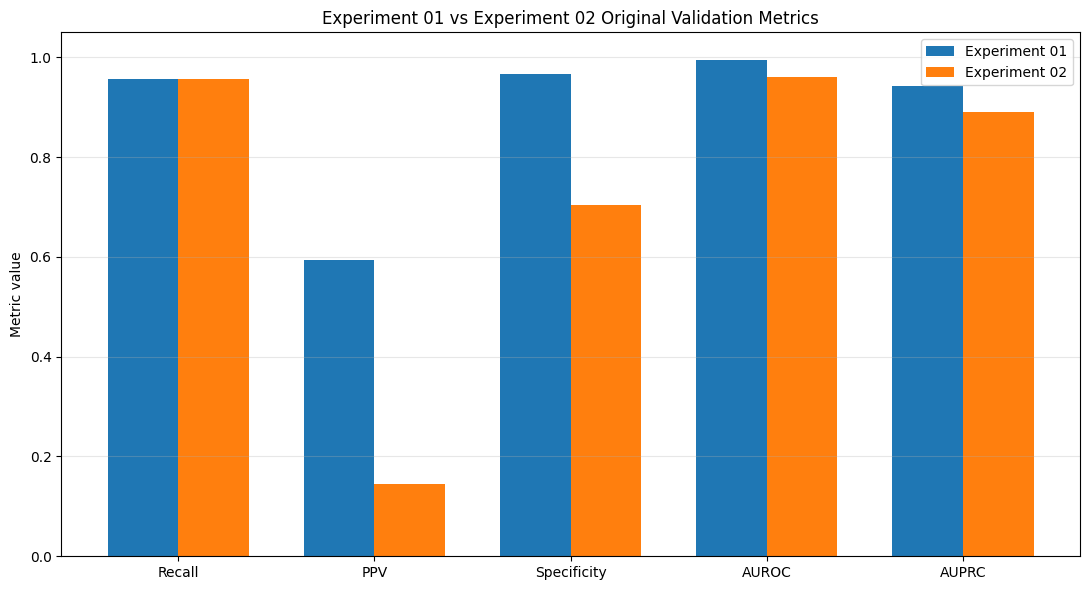

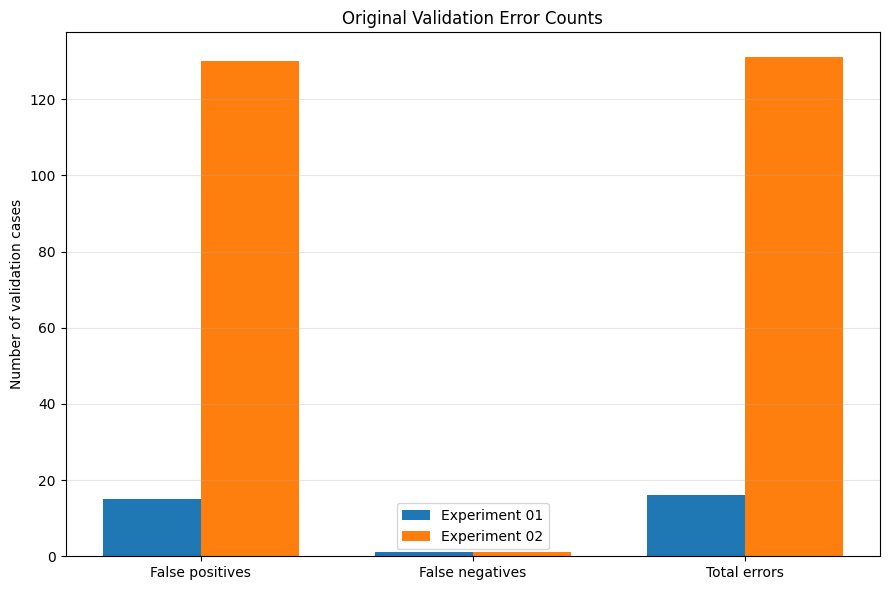

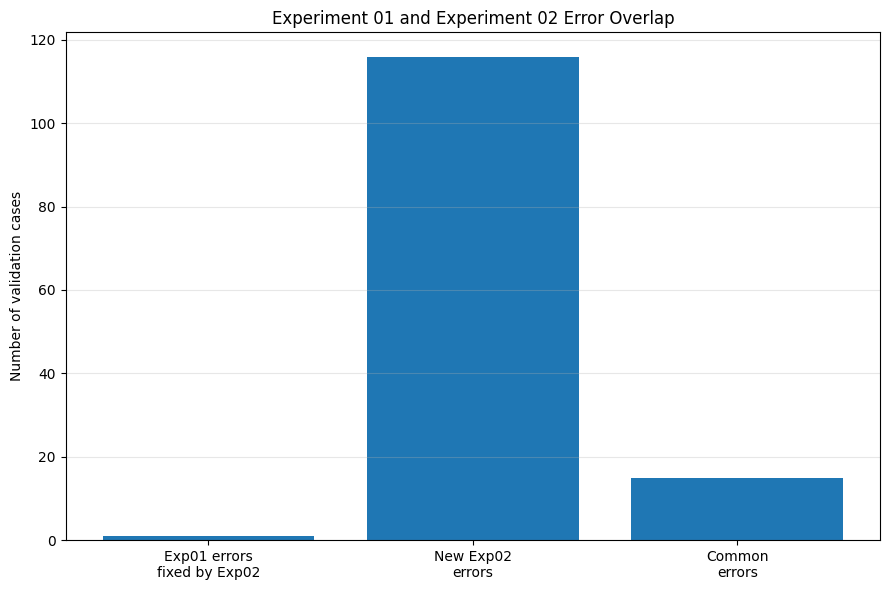

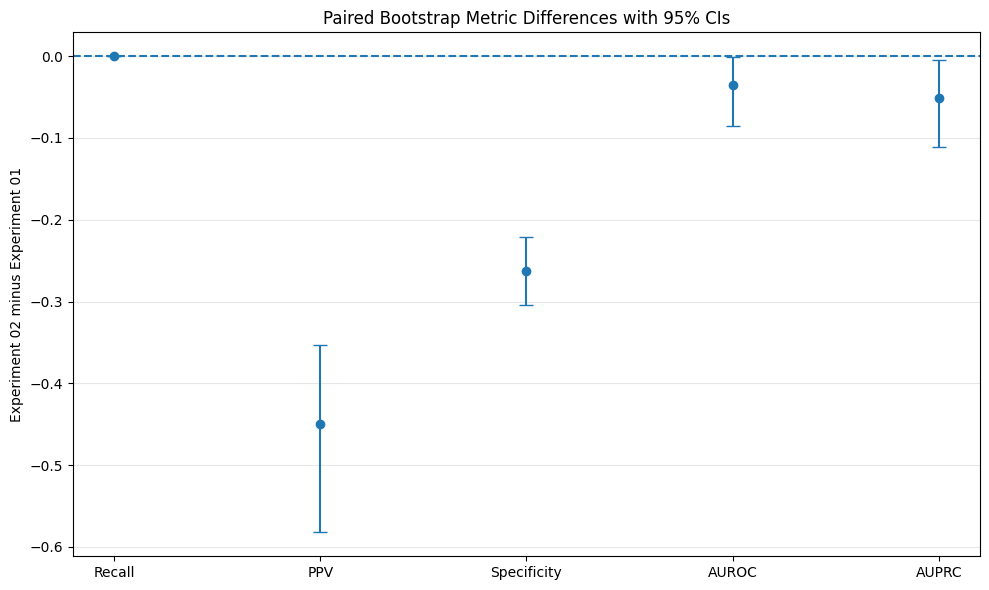


FINAL CELL 14B ORIGINAL VALIDATION PAIRED COMPARISON REPORT
Matched validation cases: 461/461
Identity matching method: locked validation manifest SHA-256

Experiment 01:
Locked threshold: 0.004699707031
Recall: 0.956522
PPV: 0.594595
Specificity: 0.965753
AUROC: 0.995235
AUPRC: 0.941969
TP: 22 | TN: 423 | FP: 15 | FN: 1

Experiment 02:
Locked threshold: 0.000064015388
Recall: 0.956522
PPV: 0.144737
Specificity: 0.703196
AUROC: 0.960393
AUPRC: 0.890313
TP: 22 | TN: 308 | FP: 130 | FN: 1

Experiment 02 minus Experiment 01:
AUPRC change: -0.051656
AUROC change: -0.034842
Recall change: +0.000000
PPV change: -0.449858
Specificity change: -0.262557
False-positive reduction: -115
False-negative reduction: +0

Development-only decision:
EXP02_ORIGINAL_VALIDATION_INSTABILITY_DETECTED

Recommended action:
Do not use the held-out test for another model-selection decision. The original-split result should be treated as unstable and investigated using development-only seed stability or calibrati

In [ ]:
# ======================================================================================
# CELL 14B — CORRECTED COMPLETE VERSION
#
# EXPERIMENT 01 VS EXPERIMENT 02
# ORIGINAL VALIDATION PAIRED COMPARISON
#
# Identity correction:
# Both prediction files are matched through the locked validation manifest.
#
# IMPORTANT:
# - No model training
# - No new inference
# - No threshold search
# - Held-out test is not loaded
# ======================================================================================

from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display

import json
import math
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    average_precision_score,
    roc_auc_score,
)

warnings.filterwarnings("ignore")


# ======================================================================================
# 1. PROJECT PATHS
# ======================================================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

VALIDATION_MANIFEST_PATH = (
    PROJECT_ROOT
    / "configs"
    / "runtime_splits"
    / "validation_runtime_verified.csv"
)

EXP01_PREDICTION_PATH = (
    PROJECT_ROOT
    / "predictions"
    / (
        "exp01_rn50_gastronet5m_dinov1_"
        "validation_predictions_locked_threshold.csv"
    )
)

EXP01_THRESHOLD_PATH = (
    PROJECT_ROOT
    / "thresholds"
    / (
        "exp01_rn50_gastronet5m_dinov1_"
        "threshold_lock.json"
    )
)

EXP02_PREDICTION_PATH = (
    PROJECT_ROOT
    / "predictions"
    / "original_split"
    / "experiment_02_swsl_gastronet5m_dinov1"
    / (
        "exp02_swsl_dino_original_split_"
        "validation_predictions_locked_threshold.csv"
    )
)

EXP02_THRESHOLD_PATH = (
    PROJECT_ROOT
    / "thresholds"
    / "original_split"
    / "experiment_02_swsl_gastronet5m_dinov1"
    / (
        "exp02_swsl_dino_original_split_"
        "threshold_lock.json"
    )
)

EXP02_STATUS_PATH = (
    PROJECT_ROOT
    / "results"
    / "original_split"
    / "experiment_02_swsl_gastronet5m_dinov1"
    / (
        "exp02_swsl_dino_original_split_"
        "status.json"
    )
)

CELL13E_DECISION_PATH = (
    PROJECT_ROOT
    / "results"
    / "cross_validation"
    / "controlled_comparisons"
    / "experiment_01_vs_experiment_02"
    / "cell13e_development_model_decision.json"
)


# ======================================================================================
# 2. OUTPUT PATHS
# ======================================================================================

COMPARISON_NAME = (
    "experiment_01_vs_experiment_02_original_validation"
)

RESULT_DIR = (
    PROJECT_ROOT
    / "results"
    / "original_split"
    / "controlled_comparisons"
    / COMPARISON_NAME
)

PREDICTION_DIR = (
    PROJECT_ROOT
    / "predictions"
    / "original_split"
    / "controlled_comparisons"
    / COMPARISON_NAME
)

CENTRE_DIR = (
    PROJECT_ROOT
    / "centre_analysis"
    / "original_split"
    / "controlled_comparisons"
    / COMPARISON_NAME
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "figures"
    / "original_split"
    / "controlled_comparisons"
    / COMPARISON_NAME
)

for directory in [
    RESULT_DIR,
    PREDICTION_DIR,
    CENTRE_DIR,
    FIGURE_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


PAIRED_CASES_PATH = (
    PREDICTION_DIR
    / "cell14b_exp01_vs_exp02_paired_validation_cases.csv"
)

METRIC_COMPARISON_PATH = (
    RESULT_DIR
    / "cell14b_exp01_vs_exp02_metric_comparison.csv"
)

CENTRE_COMPARISON_PATH = (
    CENTRE_DIR
    / "cell14b_exp01_vs_exp02_per_centre_comparison.csv"
)

ERROR_OVERLAP_PATH = (
    RESULT_DIR
    / "cell14b_exp01_vs_exp02_error_overlap_summary.csv"
)

EXP01_FIXED_PATH = (
    PREDICTION_DIR
    / "cell14b_exp01_errors_fixed_by_exp02.csv"
)

EXP02_NEW_ERRORS_PATH = (
    PREDICTION_DIR
    / "cell14b_new_exp02_errors.csv"
)

COMMON_ERRORS_PATH = (
    PREDICTION_DIR
    / "cell14b_common_errors.csv"
)

BOOTSTRAP_SAMPLES_PATH = (
    RESULT_DIR
    / "cell14b_paired_bootstrap_samples.csv"
)

BOOTSTRAP_SUMMARY_PATH = (
    RESULT_DIR
    / "cell14b_paired_bootstrap_summary.csv"
)

MCNEMAR_PATH = (
    RESULT_DIR
    / "cell14b_exact_mcnemar_test.csv"
)

DECISION_PATH = (
    RESULT_DIR
    / "cell14b_original_validation_decision.json"
)

STATUS_PATH = (
    RESULT_DIR
    / "cell14b_status.json"
)

SUMMARY_PATH = (
    RESULT_DIR
    / "cell14b_original_validation_comparison_summary.txt"
)

METRIC_FIGURE_PATH = (
    FIGURE_DIR
    / "cell14b_original_validation_metric_comparison.png"
)

ERROR_FIGURE_PATH = (
    FIGURE_DIR
    / "cell14b_original_validation_error_comparison.png"
)

OVERLAP_FIGURE_PATH = (
    FIGURE_DIR
    / "cell14b_original_validation_error_overlap.png"
)

BOOTSTRAP_FIGURE_PATH = (
    FIGURE_DIR
    / "cell14b_original_validation_bootstrap_ci.png"
)


# ======================================================================================
# 3. LOCKED EXPECTATIONS
# ======================================================================================

EXPECTED_TOTAL = 461
EXPECTED_NORMAL = 438
EXPECTED_POSITIVE = 23

EXPECTED_EXP01_THRESHOLD = 0.004699707031
EXPECTED_EXP02_THRESHOLD = 0.000064015388

BOOTSTRAP_ITERATIONS = 1000
RANDOM_SEED = 42

FINAL_STATUS = (
    "EXP01_VS_EXP02_ORIGINAL_VALIDATION_"
    "PAIRED_COMPARISON_COMPLETE"
)


# ======================================================================================
# 4. INITIAL REPORT
# ======================================================================================

print("=" * 100)

print(
    "CELL 14B: EXPERIMENT 01 VS EXPERIMENT 02 "
    "ORIGINAL VALIDATION PAIRED COMPARISON"
)

print("=" * 100)

print("\nValidation identity manifest:")
print(VALIDATION_MANIFEST_PATH)

print("\nExperiment 01 predictions:")
print(EXP01_PREDICTION_PATH)

print("\nExperiment 02 predictions:")
print(EXP02_PREDICTION_PATH)

print("\nHeld-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("New training performed: False")
print("New model inference performed: False")
print("New threshold search performed: False")


# ======================================================================================
# 5. REQUIRED FILE VERIFICATION
# ======================================================================================

required_files = [
    VALIDATION_MANIFEST_PATH,
    EXP01_PREDICTION_PATH,
    EXP01_THRESHOLD_PATH,
    EXP02_PREDICTION_PATH,
    EXP02_THRESHOLD_PATH,
    EXP02_STATUS_PATH,
    CELL13E_DECISION_PATH,
]

missing_files = [
    path
    for path in required_files
    if not path.exists()
]

if missing_files:

    print("\nMissing required files:")

    for path in missing_files:
        print(path)

    raise FileNotFoundError(
        "Required Cell 14B input files were not found."
    )


# ======================================================================================
# 6. GENERAL COLUMN DETECTION
# ======================================================================================

def find_column(
    dataframe,
    candidates,
    description,
    required=True,
):

    for candidate in candidates:

        if candidate in dataframe.columns:
            return candidate

    lower_column_map = {
        str(column).lower(): column
        for column in dataframe.columns
    }

    for candidate in candidates:

        if candidate.lower() in lower_column_map:
            return lower_column_map[
                candidate.lower()
            ]

    if required:

        raise KeyError(
            f"Could not find {description} column.\n"
            f"Available columns:\n"
            f"{list(dataframe.columns)}"
        )

    return None


PATH_CANDIDATES = [
    "relative_path",
    "original_relative_path",
    "image_relative_path",
    "runtime_path",
    "image_path",
    "file_path",
    "filepath",
    "path",
    "filename",
]

SHA_CANDIDATES = [
    "sha256",
    "image_sha256",
    "file_sha256",
    "sha_256",
]

LABEL_CANDIDATES = [
    "label",
    "target",
    "ground_truth",
    "class_label",
    "y_true",
]

CENTER_CANDIDATES = [
    "center",
    "centre",
    "site",
]

PROBABILITY_CANDIDATES = [
    "neoplasia_probability",
    "probability",
    "positive_probability",
    "predicted_probability",
    "validation_probability",
    "score",
]

PREDICTION_CANDIDATES = [
    "locked_prediction",
    "prediction",
    "predicted_label",
    "class_prediction",
    "y_pred",
]

THRESHOLD_CANDIDATES = [
    "locked_threshold",
    "selected_validation_threshold",
    "selected_threshold",
    "validation_threshold",
    "threshold",
]


# ======================================================================================
# 7. PATH NORMALIZATION
# ======================================================================================

def normalize_path(
    value,
):

    text = str(
        value
    ).strip()

    text = text.replace(
        "\\",
        "/",
    )

    text = re.sub(
        r"/+",
        "/",
        text,
    )

    text = text.replace(
        "/./",
        "/",
    )

    while text.startswith(
        "./"
    ):
        text = text[2:]

    return text.strip(
        "/"
    ).lower()


def create_path_variants(
    value,
):

    normalized = normalize_path(
        value
    )

    components = [
        component
        for component in normalized.split(
            "/"
        )
        if component
    ]

    variants = set()

    if normalized:
        variants.add(
            normalized
        )

    for component_count in [
        2,
        3,
        4,
        5,
    ]:

        if len(
            components
        ) >= component_count:

            variants.add(
                "/".join(
                    components[
                        -component_count:
                    ]
                )
            )

    if components:
        variants.add(
            components[-1]
        )

    for marker in [
        "center_1",
        "center_2",
        "centre_1",
        "centre_2",
    ]:

        if marker in components:

            marker_index = components.index(
                marker
            )

            variants.add(
                "/".join(
                    components[
                        marker_index:
                    ]
                )
            )

    return variants


# ======================================================================================
# 8. LOAD LOCKED VALIDATION MANIFEST
# ======================================================================================

manifest_df = pd.read_csv(
    VALIDATION_MANIFEST_PATH,
    low_memory=False,
)

manifest_path_column = find_column(
    manifest_df,
    PATH_CANDIDATES,
    "validation manifest path",
)

manifest_sha_column = find_column(
    manifest_df,
    SHA_CANDIDATES,
    "validation manifest SHA-256",
)

manifest_label_column = find_column(
    manifest_df,
    LABEL_CANDIDATES,
    "validation manifest label",
)

manifest_center_column = find_column(
    manifest_df,
    CENTER_CANDIDATES,
    "validation manifest centre",
)


manifest_df[
    "manifest_sha256"
] = (
    manifest_df[
        manifest_sha_column
    ]
    .astype(str)
    .str.strip()
    .str.lower()
)

manifest_df[
    "manifest_relative_path"
] = manifest_df[
    manifest_path_column
].astype(str)

manifest_df[
    "manifest_label"
] = pd.to_numeric(
    manifest_df[
        manifest_label_column
    ],
    errors="raise",
).astype(int)

manifest_df[
    "manifest_center"
] = manifest_df[
    manifest_center_column
].astype(str)


if len(
    manifest_df
) != EXPECTED_TOTAL:

    raise RuntimeError(
        "Validation manifest count is incorrect.\n"
        f"Expected: {EXPECTED_TOTAL}\n"
        f"Found: {len(manifest_df)}"
    )


if manifest_df[
    "manifest_sha256"
].duplicated().any():

    duplicate_count = int(
        manifest_df[
            "manifest_sha256"
        ].duplicated().sum()
    )

    raise RuntimeError(
        f"Duplicate validation SHA-256 values: "
        f"{duplicate_count}"
    )


manifest_normal_count = int(
    (
        manifest_df[
            "manifest_label"
        ]
        == 0
    ).sum()
)

manifest_positive_count = int(
    (
        manifest_df[
            "manifest_label"
        ]
        == 1
    ).sum()
)


if manifest_normal_count != EXPECTED_NORMAL:

    raise RuntimeError(
        f"Expected {EXPECTED_NORMAL} normal cases, "
        f"found {manifest_normal_count}."
    )


if manifest_positive_count != EXPECTED_POSITIVE:

    raise RuntimeError(
        f"Expected {EXPECTED_POSITIVE} positive cases, "
        f"found {manifest_positive_count}."
    )


print("\nLocked validation manifest verified:")

print(
    f"Total:      "
    f"{len(manifest_df)}"
)

print(
    f"Normal:     "
    f"{manifest_normal_count}"
)

print(
    f"Neoplasia: "
    f"{manifest_positive_count}"
)


# ======================================================================================
# 9. CREATE UNIQUE PATH-TO-SHA LOOKUP
# ======================================================================================

path_to_sha_candidates = {}


for _, manifest_row in manifest_df.iterrows():

    manifest_sha = str(
        manifest_row[
            "manifest_sha256"
        ]
    )

    path_variants = create_path_variants(
        manifest_row[
            "manifest_relative_path"
        ]
    )

    for path_variant in path_variants:

        path_to_sha_candidates.setdefault(
            path_variant,
            set(),
        ).add(
            manifest_sha
        )


unique_path_to_sha = {
    path_variant: next(
        iter(
            sha_values
        )
    )
    for path_variant, sha_values
    in path_to_sha_candidates.items()
    if len(
        sha_values
    ) == 1
}


print(
    "\nUnique manifest path identity keys: "
    f"{len(unique_path_to_sha)}"
)


# ======================================================================================
# 10. LOAD PREDICTION FILES
# ======================================================================================

exp01_raw_df = pd.read_csv(
    EXP01_PREDICTION_PATH,
    low_memory=False,
)

exp02_raw_df = pd.read_csv(
    EXP02_PREDICTION_PATH,
    low_memory=False,
)


print("\nRaw prediction file dimensions:")

print(
    f"Experiment 01: "
    f"{exp01_raw_df.shape}"
)

print(
    f"Experiment 02: "
    f"{exp02_raw_df.shape}"
)


# ======================================================================================
# 11. LOCKED THRESHOLD EXTRACTION
# ======================================================================================

def recursively_find_thresholds(
    value,
    location="root",
):

    results = []

    if isinstance(
        value,
        dict,
    ):

        for key, child_value in value.items():

            child_location = (
                f"{location}.{key}"
            )

            key_lower = str(
                key
            ).lower()

            if (
                "threshold" in key_lower
                and isinstance(
                    child_value,
                    (
                        int,
                        float,
                        np.integer,
                        np.floating,
                    ),
                )
            ):

                numeric_value = float(
                    child_value
                )

                if (
                    np.isfinite(
                        numeric_value
                    )
                    and 0.0
                    <= numeric_value
                    <= 1.0
                ):

                    results.append(
                        (
                            child_location,
                            numeric_value,
                        )
                    )

            results.extend(
                recursively_find_thresholds(
                    child_value,
                    child_location,
                )
            )

    elif isinstance(
        value,
        list,
    ):

        for index, child_value in enumerate(
            value
        ):

            results.extend(
                recursively_find_thresholds(
                    child_value,
                    f"{location}[{index}]",
                )
            )

    return results


def load_locked_threshold(
    prediction_df,
    threshold_json_path,
    expected_threshold,
    experiment_name,
):

    for column in THRESHOLD_CANDIDATES:

        if column in prediction_df.columns:

            values = pd.to_numeric(
                prediction_df[
                    column
                ],
                errors="coerce",
            ).dropna().unique()

            valid_values = [
                float(
                    value
                )
                for value in values
                if (
                    np.isfinite(
                        value
                    )
                    and 0.0
                    <= float(
                        value
                    )
                    <= 1.0
                )
            ]

            if len(
                valid_values
            ) == 1:

                selected_threshold = (
                    valid_values[0]
                )

                if np.isclose(
                    selected_threshold,
                    expected_threshold,
                    rtol=0.0,
                    atol=1e-8,
                ):

                    return (
                        selected_threshold,
                        f"CSV:{column}",
                    )


    threshold_json = json.loads(
        threshold_json_path.read_text(
            encoding="utf-8"
        )
    )

    json_candidates = recursively_find_thresholds(
        threshold_json
    )


    for source, candidate_value in json_candidates:

        if np.isclose(
            candidate_value,
            expected_threshold,
            rtol=0.0,
            atol=1e-8,
        ):

            return (
                candidate_value,
                f"JSON:{source}",
            )


    raise RuntimeError(
        f"Could not reproduce the documented locked "
        f"threshold for {experiment_name}.\n"
        f"Expected approximately: "
        f"{expected_threshold:.12f}"
    )


exp01_threshold, exp01_threshold_source = (
    load_locked_threshold(
        exp01_raw_df,
        EXP01_THRESHOLD_PATH,
        EXPECTED_EXP01_THRESHOLD,
        "Experiment 01",
    )
)

exp02_threshold, exp02_threshold_source = (
    load_locked_threshold(
        exp02_raw_df,
        EXP02_THRESHOLD_PATH,
        EXPECTED_EXP02_THRESHOLD,
        "Experiment 02",
    )
)


print("\nLocked thresholds verified:")

print(
    f"Experiment 01: "
    f"{exp01_threshold:.12f}"
)

print(
    f"Threshold source: "
    f"{exp01_threshold_source}"
)

print(
    f"Experiment 02: "
    f"{exp02_threshold:.12f}"
)

print(
    f"Threshold source: "
    f"{exp02_threshold_source}"
)


# ======================================================================================
# 12. RESOLVE EACH PREDICTION RECORD TO MANIFEST SHA-256
# ======================================================================================

def is_valid_sha256(
    value,
):

    text = str(
        value
    ).strip().lower()

    return bool(
        re.fullmatch(
            r"[0-9a-f]{64}",
            text,
        )
    )


def resolve_sha_from_path(
    path_value,
):

    path_variants = create_path_variants(
        path_value
    )

    matched_sha_values = {
        unique_path_to_sha[
            path_variant
        ]
        for path_variant in path_variants
        if path_variant in unique_path_to_sha
    }

    if len(
        matched_sha_values
    ) == 1:

        return next(
            iter(
                matched_sha_values
            )
        )

    return None


def standardize_prediction_file(
    dataframe,
    experiment_key,
    locked_threshold,
):

    dataframe = dataframe.copy()


    path_column = find_column(
        dataframe,
        PATH_CANDIDATES,
        f"{experiment_key} path",
    )

    sha_column = find_column(
        dataframe,
        SHA_CANDIDATES,
        f"{experiment_key} SHA-256",
        required=False,
    )

    label_column = find_column(
        dataframe,
        LABEL_CANDIDATES,
        f"{experiment_key} label",
    )

    center_column = find_column(
        dataframe,
        CENTER_CANDIDATES,
        f"{experiment_key} centre",
    )

    probability_column = find_column(
        dataframe,
        PROBABILITY_CANDIDATES,
        f"{experiment_key} probability",
    )

    prediction_column = find_column(
        dataframe,
        PREDICTION_CANDIDATES,
        f"{experiment_key} prediction",
        required=False,
    )


    resolved_sha_values = []

    identity_sources = []


    for row_index, row in dataframe.iterrows():

        resolved_sha = None

        identity_source = None


        if sha_column is not None:

            raw_sha = row[
                sha_column
            ]

            if is_valid_sha256(
                raw_sha
            ):

                candidate_sha = str(
                    raw_sha
                ).strip().lower()

                if candidate_sha in set(
                    manifest_df[
                        "manifest_sha256"
                    ]
                ):

                    resolved_sha = (
                        candidate_sha
                    )

                    identity_source = (
                        "prediction_file_sha256"
                    )


        if resolved_sha is None:

            resolved_sha = resolve_sha_from_path(
                row[
                    path_column
                ]
            )

            if resolved_sha is not None:

                identity_source = (
                    "manifest_path_mapping"
                )


        resolved_sha_values.append(
            resolved_sha
        )

        identity_sources.append(
            identity_source
        )


    standardized_df = pd.DataFrame(
        {
            "case_sha256": (
                resolved_sha_values
            ),

            "identity_source": (
                identity_sources
            ),

            "relative_path": (
                dataframe[
                    path_column
                ].astype(str)
            ),

            "label": pd.to_numeric(
                dataframe[
                    label_column
                ],
                errors="raise",
            ).astype(int),

            "center": (
                dataframe[
                    center_column
                ].astype(str)
            ),

            "probability": pd.to_numeric(
                dataframe[
                    probability_column
                ],
                errors="raise",
            ).astype(float),
        }
    )


    missing_identity_count = int(
        standardized_df[
            "case_sha256"
        ].isna().sum()
    )


    if missing_identity_count != 0:

        failed_rows = standardized_df[
            standardized_df[
                "case_sha256"
            ].isna()
        ][
            [
                "relative_path",
                "label",
                "center",
            ]
        ].head(
            20
        )

        print(
            f"\nUnresolved {experiment_key} records:"
        )

        display(
            failed_rows
        )

        raise RuntimeError(
            f"{experiment_key}: "
            f"{missing_identity_count} validation cases "
            "could not be connected to the locked "
            "validation manifest."
        )


    duplicate_count = int(
        standardized_df[
            "case_sha256"
        ].duplicated().sum()
    )


    if duplicate_count != 0:

        raise RuntimeError(
            f"{experiment_key}: duplicate resolved "
            f"validation identities: {duplicate_count}"
        )


    standardized_df[
        "prediction"
    ] = (
        standardized_df[
            "probability"
        ].to_numpy(
            dtype=float
        )
        >= locked_threshold
    ).astype(int)


    if prediction_column is not None:

        stored_predictions = pd.to_numeric(
            dataframe[
                prediction_column
            ],
            errors="raise",
        ).to_numpy(
            dtype=int
        )

        disagreement_count = int(
            (
                stored_predictions
                != standardized_df[
                    "prediction"
                ].to_numpy(
                    dtype=int
                )
            ).sum()
        )

    else:

        disagreement_count = 0


    if disagreement_count != 0:

        raise RuntimeError(
            f"{experiment_key}: locked threshold "
            f"produced {disagreement_count} prediction "
            "disagreements."
        )


    standardized_df[
        "correct"
    ] = (
        standardized_df[
            "prediction"
        ]
        == standardized_df[
            "label"
        ]
    )


    standardized_df[
        "error_type"
    ] = np.select(
        [
            (
                (
                    standardized_df[
                        "label"
                    ]
                    == 0
                )
                &
                (
                    standardized_df[
                        "prediction"
                    ]
                    == 1
                )
            ),

            (
                (
                    standardized_df[
                        "label"
                    ]
                    == 1
                )
                &
                (
                    standardized_df[
                        "prediction"
                    ]
                    == 0
                )
            ),
        ],
        [
            "FP",
            "FN",
        ],
        default="correct",
    )


    return (
        standardized_df,
        disagreement_count,
    )


exp01_df, exp01_disagreements = (
    standardize_prediction_file(
        exp01_raw_df,
        "Experiment 01",
        exp01_threshold,
    )
)

exp02_df, exp02_disagreements = (
    standardize_prediction_file(
        exp02_raw_df,
        "Experiment 02",
        exp02_threshold,
    )
)


print("\nManifest identity resolution:")

print(
    "Experiment 01:"
)

print(
    exp01_df[
        "identity_source"
    ].value_counts(
        dropna=False
    )
)

print(
    "\nExperiment 02:"
)

print(
    exp02_df[
        "identity_source"
    ].value_counts(
        dropna=False
    )
)

print("\nStored prediction disagreements:")

print(
    f"Experiment 01: "
    f"{exp01_disagreements}"
)

print(
    f"Experiment 02: "
    f"{exp02_disagreements}"
)


# ======================================================================================
# 13. JOIN BOTH EXPERIMENTS THROUGH COMMON SHA-256
# ======================================================================================

exp01_pair_df = exp01_df.rename(
    columns={
        "relative_path": (
            "relative_path_exp01"
        ),

        "identity_source": (
            "identity_source_exp01"
        ),

        "label": (
            "label_exp01"
        ),

        "center": (
            "center_exp01"
        ),

        "probability": (
            "probability_exp01"
        ),

        "prediction": (
            "prediction_exp01"
        ),

        "correct": (
            "correct_exp01"
        ),

        "error_type": (
            "error_type_exp01"
        ),
    }
)

exp02_pair_df = exp02_df.rename(
    columns={
        "relative_path": (
            "relative_path_exp02"
        ),

        "identity_source": (
            "identity_source_exp02"
        ),

        "label": (
            "label_exp02"
        ),

        "center": (
            "center_exp02"
        ),

        "probability": (
            "probability_exp02"
        ),

        "prediction": (
            "prediction_exp02"
        ),

        "correct": (
            "correct_exp02"
        ),

        "error_type": (
            "error_type_exp02"
        ),
    }
)


paired_df = exp01_pair_df.merge(
    exp02_pair_df,
    on="case_sha256",
    how="inner",
    validate="one_to_one",
)


if len(
    paired_df
) != EXPECTED_TOTAL:

    exp01_only_count = int(
        (
            ~exp01_df[
                "case_sha256"
            ].isin(
                exp02_df[
                    "case_sha256"
                ]
            )
        ).sum()
    )

    exp02_only_count = int(
        (
            ~exp02_df[
                "case_sha256"
            ].isin(
                exp01_df[
                    "case_sha256"
                ]
            )
        ).sum()
    )

    raise RuntimeError(
        "The two experiments were not matched on all "
        "validation cases.\n"
        f"Matched records: {len(paired_df)}\n"
        f"Experiment 01 unmatched: {exp01_only_count}\n"
        f"Experiment 02 unmatched: {exp02_only_count}"
    )


label_mismatches = int(
    (
        paired_df[
            "label_exp01"
        ]
        != paired_df[
            "label_exp02"
        ]
    ).sum()
)

center_mismatches = int(
    (
        paired_df[
            "center_exp01"
        ]
        != paired_df[
            "center_exp02"
        ]
    ).sum()
)


if label_mismatches != 0:

    raise RuntimeError(
        f"Label mismatches after SHA matching: "
        f"{label_mismatches}"
    )


if center_mismatches != 0:

    raise RuntimeError(
        f"Centre mismatches after SHA matching: "
        f"{center_mismatches}"
    )


paired_df[
    "label"
] = paired_df[
    "label_exp01"
]

paired_df[
    "center"
] = paired_df[
    "center_exp01"
]

paired_df[
    "relative_path"
] = paired_df[
    "relative_path_exp01"
]


paired_df[
    "exp01_wrong_exp02_correct"
] = (
    (
        ~paired_df[
            "correct_exp01"
        ]
    )
    &
    paired_df[
        "correct_exp02"
    ]
)

paired_df[
    "exp01_correct_exp02_wrong"
] = (
    paired_df[
        "correct_exp01"
    ]
    &
    (
        ~paired_df[
            "correct_exp02"
        ]
    )
)

paired_df[
    "common_error"
] = (
    (
        ~paired_df[
            "correct_exp01"
        ]
    )
    &
    (
        ~paired_df[
            "correct_exp02"
        ]
    )
)


paired_df.to_csv(
    PAIRED_CASES_PATH,
    index=False,
)


print("\nPaired validation verification:")

print(
    f"Matched cases: "
    f"{len(paired_df)}/{EXPECTED_TOTAL}"
)

print(
    f"Label mismatches: "
    f"{label_mismatches}"
)

print(
    f"Centre mismatches: "
    f"{center_mismatches}"
)


# ======================================================================================
# 14. METRIC FUNCTIONS
# ======================================================================================

def safe_divide(
    numerator,
    denominator,
):

    if denominator == 0:
        return 0.0

    return float(
        numerator
        / denominator
    )


def calculate_metrics(
    labels,
    probabilities,
    predictions,
):

    labels = np.asarray(
        labels,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    predictions = np.asarray(
        predictions,
        dtype=int,
    )


    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[
            0,
            1,
        ],
    ).ravel()


    recall = safe_divide(
        tp,
        tp + fn,
    )

    precision = safe_divide(
        tp,
        tp + fp,
    )

    specificity = safe_divide(
        tn,
        tn + fp,
    )

    npv = safe_divide(
        tn,
        tn + fn,
    )

    accuracy = safe_divide(
        tp + tn,
        len(
            labels
        ),
    )

    balanced_accuracy = (
        recall
        + specificity
    ) / 2.0

    f1 = safe_divide(
        2
        * precision
        * recall,
        precision
        + recall,
    )


    return {
        "sample_count": int(
            len(
                labels
            )
        ),

        "normal_count": int(
            (
                labels == 0
            ).sum()
        ),

        "positive_count": int(
            (
                labels == 1
            ).sum()
        ),

        "recall": float(
            recall
        ),

        "precision": float(
            precision
        ),

        "specificity": float(
            specificity
        ),

        "npv": float(
            npv
        ),

        "accuracy": float(
            accuracy
        ),

        "balanced_accuracy": float(
            balanced_accuracy
        ),

        "f1": float(
            f1
        ),

        "auroc": float(
            roc_auc_score(
                labels,
                probabilities,
            )
        ),

        "auprc": float(
            average_precision_score(
                labels,
                probabilities,
            )
        ),

        "tp": int(
            tp
        ),

        "tn": int(
            tn
        ),

        "fp": int(
            fp
        ),

        "fn": int(
            fn
        ),
    }


# ======================================================================================
# 15. OVERALL METRICS
# ======================================================================================

labels = paired_df[
    "label"
].to_numpy(
    dtype=int
)

exp01_probabilities = paired_df[
    "probability_exp01"
].to_numpy(
    dtype=float
)

exp02_probabilities = paired_df[
    "probability_exp02"
].to_numpy(
    dtype=float
)

exp01_predictions = paired_df[
    "prediction_exp01"
].to_numpy(
    dtype=int
)

exp02_predictions = paired_df[
    "prediction_exp02"
].to_numpy(
    dtype=int
)


exp01_metrics = calculate_metrics(
    labels,
    exp01_probabilities,
    exp01_predictions,
)

exp02_metrics = calculate_metrics(
    labels,
    exp02_probabilities,
    exp02_predictions,
)


comparison_metrics = [
    "recall",
    "precision",
    "specificity",
    "npv",
    "accuracy",
    "balanced_accuracy",
    "f1",
    "auroc",
    "auprc",
    "tp",
    "tn",
    "fp",
    "fn",
]


metric_rows = []


for metric_name in comparison_metrics:

    exp01_value = float(
        exp01_metrics[
            metric_name
        ]
    )

    exp02_value = float(
        exp02_metrics[
            metric_name
        ]
    )


    metric_rows.append(
        {
            "metric": (
                metric_name
            ),

            "experiment_01": (
                exp01_value
            ),

            "experiment_02": (
                exp02_value
            ),

            "experiment_02_minus_experiment_01": (
                exp02_value
                - exp01_value
            ),
        }
    )


metric_comparison_df = pd.DataFrame(
    metric_rows
)

metric_comparison_df.to_csv(
    METRIC_COMPARISON_PATH,
    index=False,
)


print(
    "\nOverall original-validation metric comparison:"
)

display(
    metric_comparison_df
)


# ======================================================================================
# 16. PER-CENTRE METRICS
# ======================================================================================

centre_rows = []


for center_value in sorted(
    paired_df[
        "center"
    ].unique()
):

    center_mask = (
        paired_df[
            "center"
        ]
        == center_value
    )

    center_labels = paired_df.loc[
        center_mask,
        "label",
    ].to_numpy(
        dtype=int
    )


    center_exp01_metrics = calculate_metrics(
        center_labels,

        paired_df.loc[
            center_mask,
            "probability_exp01",
        ].to_numpy(
            dtype=float
        ),

        paired_df.loc[
            center_mask,
            "prediction_exp01",
        ].to_numpy(
            dtype=int
        ),
    )


    center_exp02_metrics = calculate_metrics(
        center_labels,

        paired_df.loc[
            center_mask,
            "probability_exp02",
        ].to_numpy(
            dtype=float
        ),

        paired_df.loc[
            center_mask,
            "prediction_exp02",
        ].to_numpy(
            dtype=int
        ),
    )


    centre_rows.append(
        {
            "center": (
                center_value
            ),

            "model": (
                "experiment_01"
            ),

            **center_exp01_metrics,
        }
    )

    centre_rows.append(
        {
            "center": (
                center_value
            ),

            "model": (
                "experiment_02"
            ),

            **center_exp02_metrics,
        }
    )


centre_comparison_df = pd.DataFrame(
    centre_rows
)

centre_comparison_df.to_csv(
    CENTRE_COMPARISON_PATH,
    index=False,
)


print("\nPer-centre comparison:")

display(
    centre_comparison_df
)


# ======================================================================================
# 17. ERROR OVERLAP
# ======================================================================================

exp01_error_mask = (
    ~paired_df[
        "correct_exp01"
    ]
)

exp02_error_mask = (
    ~paired_df[
        "correct_exp02"
    ]
)

exp01_fixed_mask = (
    exp01_error_mask
    &
    paired_df[
        "correct_exp02"
    ]
)

exp02_new_error_mask = (
    paired_df[
        "correct_exp01"
    ]
    &
    exp02_error_mask
)

common_error_mask = (
    exp01_error_mask
    &
    exp02_error_mask
)


error_overlap_df = pd.DataFrame(
    [
        {
            "measure": (
                "experiment_01_total_errors"
            ),

            "count": int(
                exp01_error_mask.sum()
            ),
        },

        {
            "measure": (
                "experiment_02_total_errors"
            ),

            "count": int(
                exp02_error_mask.sum()
            ),
        },

        {
            "measure": (
                "common_errors"
            ),

            "count": int(
                common_error_mask.sum()
            ),
        },

        {
            "measure": (
                "experiment_01_errors_fixed_by_experiment_02"
            ),

            "count": int(
                exp01_fixed_mask.sum()
            ),
        },

        {
            "measure": (
                "new_experiment_02_errors"
            ),

            "count": int(
                exp02_new_error_mask.sum()
            ),
        },

        {
            "measure": (
                "false_positive_reduction"
            ),

            "count": int(
                exp01_metrics[
                    "fp"
                ]
                - exp02_metrics[
                    "fp"
                ]
            ),
        },

        {
            "measure": (
                "false_negative_reduction"
            ),

            "count": int(
                exp01_metrics[
                    "fn"
                ]
                - exp02_metrics[
                    "fn"
                ]
            ),
        },
    ]
)


error_overlap_df.to_csv(
    ERROR_OVERLAP_PATH,
    index=False,
)

paired_df.loc[
    exp01_fixed_mask
].to_csv(
    EXP01_FIXED_PATH,
    index=False,
)

paired_df.loc[
    exp02_new_error_mask
].to_csv(
    EXP02_NEW_ERRORS_PATH,
    index=False,
)

paired_df.loc[
    common_error_mask
].to_csv(
    COMMON_ERRORS_PATH,
    index=False,
)


print("\nError-overlap summary:")

display(
    error_overlap_df
)


# ======================================================================================
# 18. EXACT MCNEMAR TEST
# ======================================================================================

exp01_wrong_exp02_correct = int(
    exp01_fixed_mask.sum()
)

exp01_correct_exp02_wrong = int(
    exp02_new_error_mask.sum()
)

discordant_total = int(
    exp01_wrong_exp02_correct
    + exp01_correct_exp02_wrong
)


def exact_binomial_two_sided(
    successes,
    trials,
):

    if trials == 0:
        return 1.0

    smaller_side = min(
        successes,
        trials - successes,
    )

    lower_tail_probability = sum(
        math.comb(
            trials,
            value,
        )
        for value in range(
            smaller_side + 1
        )
    ) / (
        2 ** trials
    )

    return float(
        min(
            1.0,
            2.0
            * lower_tail_probability,
        )
    )


mcnemar_p_value = exact_binomial_two_sided(
    exp01_wrong_exp02_correct,
    discordant_total,
)


mcnemar_df = pd.DataFrame(
    [
        {
            "exp01_wrong_exp02_correct": (
                exp01_wrong_exp02_correct
            ),

            "exp01_correct_exp02_wrong": (
                exp01_correct_exp02_wrong
            ),

            "discordant_total": (
                discordant_total
            ),

            "exact_two_sided_p_value": (
                mcnemar_p_value
            ),

            "interpretation": (
                "paired_error_difference_detected"
                if mcnemar_p_value < 0.05
                else "no_clear_paired_error_difference"
            ),

            "important_note": (
                "This is a development-validation "
                "comparison, not an independent test result."
            ),
        }
    ]
)

mcnemar_df.to_csv(
    MCNEMAR_PATH,
    index=False,
)


print("\nExact paired McNemar analysis:")

display(
    mcnemar_df
)


# ======================================================================================
# 19. PAIRED CENTRE/CLASS-STRATIFIED BOOTSTRAP
# ======================================================================================

rng = np.random.default_rng(
    RANDOM_SEED
)

stratum_indices = []


for (
    center_value,
    label_value
), stratum_df in paired_df.groupby(
    [
        "center",
        "label",
    ],
    sort=True,
):

    stratum_indices.append(
        stratum_df.index.to_numpy(
            dtype=int
        )
    )


bootstrap_rows = []


print(
    f"\nRunning paired stratified bootstrap: "
    f"{BOOTSTRAP_ITERATIONS} iterations..."
)


for iteration in range(
    1,
    BOOTSTRAP_ITERATIONS + 1,
):

    sampled_indices = np.concatenate(
        [
            rng.choice(
                indices,
                size=len(
                    indices
                ),
                replace=True,
            )
            for indices in stratum_indices
        ]
    )


    sampled_labels = paired_df.loc[
        sampled_indices,
        "label",
    ].to_numpy(
        dtype=int
    )


    sampled_exp01_metrics = calculate_metrics(
        sampled_labels,

        paired_df.loc[
            sampled_indices,
            "probability_exp01",
        ].to_numpy(
            dtype=float
        ),

        paired_df.loc[
            sampled_indices,
            "prediction_exp01",
        ].to_numpy(
            dtype=int
        ),
    )


    sampled_exp02_metrics = calculate_metrics(
        sampled_labels,

        paired_df.loc[
            sampled_indices,
            "probability_exp02",
        ].to_numpy(
            dtype=float
        ),

        paired_df.loc[
            sampled_indices,
            "prediction_exp02",
        ].to_numpy(
            dtype=int
        ),
    )


    bootstrap_rows.append(
        {
            "iteration": (
                iteration
            ),

            "recall_gain": (
                sampled_exp02_metrics[
                    "recall"
                ]
                - sampled_exp01_metrics[
                    "recall"
                ]
            ),

            "ppv_gain": (
                sampled_exp02_metrics[
                    "precision"
                ]
                - sampled_exp01_metrics[
                    "precision"
                ]
            ),

            "specificity_gain": (
                sampled_exp02_metrics[
                    "specificity"
                ]
                - sampled_exp01_metrics[
                    "specificity"
                ]
            ),

            "balanced_accuracy_gain": (
                sampled_exp02_metrics[
                    "balanced_accuracy"
                ]
                - sampled_exp01_metrics[
                    "balanced_accuracy"
                ]
            ),

            "auroc_gain": (
                sampled_exp02_metrics[
                    "auroc"
                ]
                - sampled_exp01_metrics[
                    "auroc"
                ]
            ),

            "auprc_gain": (
                sampled_exp02_metrics[
                    "auprc"
                ]
                - sampled_exp01_metrics[
                    "auprc"
                ]
            ),

            "fp_reduction": (
                sampled_exp01_metrics[
                    "fp"
                ]
                - sampled_exp02_metrics[
                    "fp"
                ]
            ),

            "fn_reduction": (
                sampled_exp01_metrics[
                    "fn"
                ]
                - sampled_exp02_metrics[
                    "fn"
                ]
            ),
        }
    )


bootstrap_df = pd.DataFrame(
    bootstrap_rows
)

bootstrap_df.to_csv(
    BOOTSTRAP_SAMPLES_PATH,
    index=False,
)


observed_changes = {
    "recall_gain": (
        exp02_metrics[
            "recall"
        ]
        - exp01_metrics[
            "recall"
        ]
    ),

    "ppv_gain": (
        exp02_metrics[
            "precision"
        ]
        - exp01_metrics[
            "precision"
        ]
    ),

    "specificity_gain": (
        exp02_metrics[
            "specificity"
        ]
        - exp01_metrics[
            "specificity"
        ]
    ),

    "balanced_accuracy_gain": (
        exp02_metrics[
            "balanced_accuracy"
        ]
        - exp01_metrics[
            "balanced_accuracy"
        ]
    ),

    "auroc_gain": (
        exp02_metrics[
            "auroc"
        ]
        - exp01_metrics[
            "auroc"
        ]
    ),

    "auprc_gain": (
        exp02_metrics[
            "auprc"
        ]
        - exp01_metrics[
            "auprc"
        ]
    ),

    "fp_reduction": (
        exp01_metrics[
            "fp"
        ]
        - exp02_metrics[
            "fp"
        ]
    ),

    "fn_reduction": (
        exp01_metrics[
            "fn"
        ]
        - exp02_metrics[
            "fn"
        ]
    ),
}


bootstrap_summary_rows = []


for measure_name, observed_value in (
    observed_changes.items()
):

    bootstrap_values = bootstrap_df[
        measure_name
    ].to_numpy(
        dtype=float
    )

    lower_ci = float(
        np.percentile(
            bootstrap_values,
            2.5,
        )
    )

    upper_ci = float(
        np.percentile(
            bootstrap_values,
            97.5,
        )
    )


    if lower_ci > 0:

        interpretation = (
            "CI_above_zero"
        )

    elif upper_ci < 0:

        interpretation = (
            "CI_below_zero"
        )

    else:

        interpretation = (
            "CI_includes_zero"
        )


    bootstrap_summary_rows.append(
        {
            "measure": (
                measure_name
            ),

            "observed_change": float(
                observed_value
            ),

            "bootstrap_mean": float(
                bootstrap_values.mean()
            ),

            "bootstrap_median": float(
                np.median(
                    bootstrap_values
                )
            ),

            "ci_2_5_percent": (
                lower_ci
            ),

            "ci_97_5_percent": (
                upper_ci
            ),

            "proportion_above_zero": float(
                np.mean(
                    bootstrap_values > 0
                )
            ),

            "interpretation": (
                interpretation
            ),
        }
    )


bootstrap_summary_df = pd.DataFrame(
    bootstrap_summary_rows
)

bootstrap_summary_df.to_csv(
    BOOTSTRAP_SUMMARY_PATH,
    index=False,
)


print("\nPaired bootstrap confidence intervals:")

display(
    bootstrap_summary_df
)


# ======================================================================================
# 20. DEVELOPMENT-ONLY DECISION
# ======================================================================================

auprc_change = float(
    exp02_metrics[
        "auprc"
    ]
    - exp01_metrics[
        "auprc"
    ]
)

auroc_change = float(
    exp02_metrics[
        "auroc"
    ]
    - exp01_metrics[
        "auroc"
    ]
)

recall_change = float(
    exp02_metrics[
        "recall"
    ]
    - exp01_metrics[
        "recall"
    ]
)

ppv_change = float(
    exp02_metrics[
        "precision"
    ]
    - exp01_metrics[
        "precision"
    ]
)

specificity_change = float(
    exp02_metrics[
        "specificity"
    ]
    - exp01_metrics[
        "specificity"
    ]
)

fp_reduction = int(
    exp01_metrics[
        "fp"
    ]
    - exp02_metrics[
        "fp"
    ]
)

fn_reduction = int(
    exp01_metrics[
        "fn"
    ]
    - exp02_metrics[
        "fn"
    ]
)


if (
    exp02_metrics[
        "recall"
    ]
    >= 0.90
    and auprc_change >= -0.01
    and auroc_change >= -0.01
    and ppv_change >= -0.05
    and specificity_change >= -0.03
):

    decision = (
        "EXP02_ORIGINAL_VALIDATION_CONFIRMED"
    )

    recommended_action = (
        "Experiment 02 remains supported as the "
        "development lead candidate."
    )

else:

    decision = (
        "EXP02_ORIGINAL_VALIDATION_INSTABILITY_DETECTED"
    )

    recommended_action = (
        "Do not use the held-out test for another "
        "model-selection decision. The original-split "
        "result should be treated as unstable and "
        "investigated using development-only seed "
        "stability or calibration analysis."
    )


decision_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "decision": (
        decision
    ),

    "recommended_action": (
        recommended_action
    ),

    "experiment_01_threshold": (
        exp01_threshold
    ),

    "experiment_02_threshold": (
        exp02_threshold
    ),

    "experiment_02_minus_experiment_01": {
        "auprc": (
            auprc_change
        ),

        "auroc": (
            auroc_change
        ),

        "recall": (
            recall_change
        ),

        "ppv": (
            ppv_change
        ),

        "specificity": (
            specificity_change
        ),
    },

    "false_positive_reduction": (
        fp_reduction
    ),

    "false_negative_reduction": (
        fn_reduction
    ),

    "held_out_test_csv_loaded": False,

    "held_out_test_predictions_loaded": False,

    "held_out_test_evaluated": False,

    "held_out_test_used_for_decision": False,

    "new_training_performed": False,

    "new_inference_performed": False,

    "new_threshold_search_performed": False,
}


DECISION_PATH.write_text(
    json.dumps(
        decision_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ======================================================================================
# 21. FIGURES
# ======================================================================================

metric_names = [
    "Recall",
    "PPV",
    "Specificity",
    "AUROC",
    "AUPRC",
]

exp01_metric_values = [
    exp01_metrics[
        "recall"
    ],

    exp01_metrics[
        "precision"
    ],

    exp01_metrics[
        "specificity"
    ],

    exp01_metrics[
        "auroc"
    ],

    exp01_metrics[
        "auprc"
    ],
]

exp02_metric_values = [
    exp02_metrics[
        "recall"
    ],

    exp02_metrics[
        "precision"
    ],

    exp02_metrics[
        "specificity"
    ],

    exp02_metrics[
        "auroc"
    ],

    exp02_metrics[
        "auprc"
    ],
]


x_positions = np.arange(
    len(
        metric_names
    )
)

bar_width = 0.36


figure = plt.figure(
    figsize=(
        11,
        6,
    )
)

plt.bar(
    x_positions
    - bar_width / 2,
    exp01_metric_values,
    width=bar_width,
    label="Experiment 01",
)

plt.bar(
    x_positions
    + bar_width / 2,
    exp02_metric_values,
    width=bar_width,
    label="Experiment 02",
)

plt.xticks(
    x_positions,
    metric_names,
)

plt.ylim(
    0,
    1.05,
)

plt.ylabel(
    "Metric value"
)

plt.title(
    "Experiment 01 vs Experiment 02 "
    "Original Validation Metrics"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.legend()

plt.tight_layout()

figure.savefig(
    METRIC_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(
    figure
)


error_names = [
    "False positives",
    "False negatives",
    "Total errors",
]

exp01_error_values = [
    exp01_metrics[
        "fp"
    ],

    exp01_metrics[
        "fn"
    ],

    exp01_metrics[
        "fp"
    ]
    + exp01_metrics[
        "fn"
    ],
]

exp02_error_values = [
    exp02_metrics[
        "fp"
    ],

    exp02_metrics[
        "fn"
    ],

    exp02_metrics[
        "fp"
    ]
    + exp02_metrics[
        "fn"
    ],
]


x_positions = np.arange(
    len(
        error_names
    )
)


figure = plt.figure(
    figsize=(
        9,
        6,
    )
)

plt.bar(
    x_positions
    - bar_width / 2,
    exp01_error_values,
    width=bar_width,
    label="Experiment 01",
)

plt.bar(
    x_positions
    + bar_width / 2,
    exp02_error_values,
    width=bar_width,
    label="Experiment 02",
)

plt.xticks(
    x_positions,
    error_names,
)

plt.ylabel(
    "Number of validation cases"
)

plt.title(
    "Original Validation Error Counts"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.legend()

plt.tight_layout()

figure.savefig(
    ERROR_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(
    figure
)


overlap_names = [
    "Exp01 errors\nfixed by Exp02",
    "New Exp02\nerrors",
    "Common\nerrors",
]

overlap_values = [
    int(
        exp01_fixed_mask.sum()
    ),

    int(
        exp02_new_error_mask.sum()
    ),

    int(
        common_error_mask.sum()
    ),
]


figure = plt.figure(
    figsize=(
        9,
        6,
    )
)

plt.bar(
    overlap_names,
    overlap_values,
)

plt.ylabel(
    "Number of validation cases"
)

plt.title(
    "Experiment 01 and Experiment 02 Error Overlap"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.tight_layout()

figure.savefig(
    OVERLAP_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(
    figure
)


bootstrap_plot_measures = [
    "recall_gain",
    "ppv_gain",
    "specificity_gain",
    "auroc_gain",
    "auprc_gain",
]

bootstrap_plot_df = (
    bootstrap_summary_df[
        bootstrap_summary_df[
            "measure"
        ].isin(
            bootstrap_plot_measures
        )
    ]
    .set_index(
        "measure"
    )
    .loc[
        bootstrap_plot_measures
    ]
    .reset_index()
)

plot_values = bootstrap_plot_df[
    "observed_change"
].to_numpy(
    dtype=float
)

lower_errors = (
    plot_values
    - bootstrap_plot_df[
        "ci_2_5_percent"
    ].to_numpy(
        dtype=float
    )
)

upper_errors = (
    bootstrap_plot_df[
        "ci_97_5_percent"
    ].to_numpy(
        dtype=float
    )
    - plot_values
)


figure = plt.figure(
    figsize=(
        10,
        6,
    )
)

plt.errorbar(
    np.arange(
        len(
            bootstrap_plot_df
        )
    ),
    plot_values,
    yerr=[
        lower_errors,
        upper_errors,
    ],
    fmt="o",
    capsize=5,
)

plt.axhline(
    0,
    linestyle="--",
)

plt.xticks(
    np.arange(
        len(
            bootstrap_plot_df
        )
    ),
    [
        "Recall",
        "PPV",
        "Specificity",
        "AUROC",
        "AUPRC",
    ],
)

plt.ylabel(
    "Experiment 02 minus Experiment 01"
)

plt.title(
    "Paired Bootstrap Metric Differences with 95% CIs"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.tight_layout()

figure.savefig(
    BOOTSTRAP_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(
    figure
)


# ======================================================================================
# 22. SAVE STATUS AND SUMMARY
# ======================================================================================

status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": (
        FINAL_STATUS
    ),

    "matched_validation_cases": int(
        len(
            paired_df
        )
    ),

    "identity_matching_method": (
        "locked_validation_manifest_sha256"
    ),

    "decision": (
        decision
    ),

    "held_out_test_csv_loaded": False,

    "held_out_test_predictions_loaded": False,

    "held_out_test_evaluated": False,

    "held_out_test_used_for_decision": False,

    "new_training_performed": False,

    "new_inference_performed": False,

    "new_threshold_search_performed": False,
}


STATUS_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


summary_lines = [
    (
        "CELL 14B — Experiment 01 vs Experiment 02 "
        "Original Validation Paired Comparison"
    ),

    "=" * 90,

    "",

    (
        f"Matched validation cases: "
        f"{len(paired_df)}/{EXPECTED_TOTAL}"
    ),

    (
        "Identity matching method: "
        "locked validation manifest SHA-256"
    ),

    "",

    "Experiment 01:",

    (
        f"Threshold: "
        f"{exp01_threshold:.12f}"
    ),

    (
        f"Recall: "
        f"{exp01_metrics['recall']:.6f}"
    ),

    (
        f"PPV: "
        f"{exp01_metrics['precision']:.6f}"
    ),

    (
        f"Specificity: "
        f"{exp01_metrics['specificity']:.6f}"
    ),

    (
        f"AUROC: "
        f"{exp01_metrics['auroc']:.6f}"
    ),

    (
        f"AUPRC: "
        f"{exp01_metrics['auprc']:.6f}"
    ),

    (
        f"TP/TN/FP/FN: "
        f"{exp01_metrics['tp']}/"
        f"{exp01_metrics['tn']}/"
        f"{exp01_metrics['fp']}/"
        f"{exp01_metrics['fn']}"
    ),

    "",

    "Experiment 02:",

    (
        f"Threshold: "
        f"{exp02_threshold:.12f}"
    ),

    (
        f"Recall: "
        f"{exp02_metrics['recall']:.6f}"
    ),

    (
        f"PPV: "
        f"{exp02_metrics['precision']:.6f}"
    ),

    (
        f"Specificity: "
        f"{exp02_metrics['specificity']:.6f}"
    ),

    (
        f"AUROC: "
        f"{exp02_metrics['auroc']:.6f}"
    ),

    (
        f"AUPRC: "
        f"{exp02_metrics['auprc']:.6f}"
    ),

    (
        f"TP/TN/FP/FN: "
        f"{exp02_metrics['tp']}/"
        f"{exp02_metrics['tn']}/"
        f"{exp02_metrics['fp']}/"
        f"{exp02_metrics['fn']}"
    ),

    "",

    (
        f"AUPRC change: "
        f"{auprc_change:+.6f}"
    ),

    (
        f"AUROC change: "
        f"{auroc_change:+.6f}"
    ),

    (
        f"Recall change: "
        f"{recall_change:+.6f}"
    ),

    (
        f"PPV change: "
        f"{ppv_change:+.6f}"
    ),

    (
        f"Specificity change: "
        f"{specificity_change:+.6f}"
    ),

    (
        f"False-positive reduction: "
        f"{fp_reduction:+d}"
    ),

    (
        f"False-negative reduction: "
        f"{fn_reduction:+d}"
    ),

    "",

    (
        f"Development-only decision: "
        f"{decision}"
    ),

    (
        f"Recommended action: "
        f"{recommended_action}"
    ),

    "",

    "Held-out test loaded: False",
    "Held-out test evaluated: False",
    "New training performed: False",
    "New inference performed: False",
    "New threshold search performed: False",

    "",

    (
        f"STATUS: "
        f"{FINAL_STATUS}"
    ),
]


SUMMARY_PATH.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ======================================================================================
# 23. FINAL REPORT
# ======================================================================================

print("\n" + "=" * 100)

print(
    "FINAL CELL 14B ORIGINAL VALIDATION "
    "PAIRED COMPARISON REPORT"
)

print("=" * 100)

print(
    f"Matched validation cases: "
    f"{len(paired_df)}/{EXPECTED_TOTAL}"
)

print(
    "Identity matching method: "
    "locked validation manifest SHA-256"
)


print("\nExperiment 01:")

print(
    f"Locked threshold: "
    f"{exp01_threshold:.12f}"
)

print(
    f"Recall: "
    f"{exp01_metrics['recall']:.6f}"
)

print(
    f"PPV: "
    f"{exp01_metrics['precision']:.6f}"
)

print(
    f"Specificity: "
    f"{exp01_metrics['specificity']:.6f}"
)

print(
    f"AUROC: "
    f"{exp01_metrics['auroc']:.6f}"
)

print(
    f"AUPRC: "
    f"{exp01_metrics['auprc']:.6f}"
)

print(
    f"TP: {exp01_metrics['tp']} | "
    f"TN: {exp01_metrics['tn']} | "
    f"FP: {exp01_metrics['fp']} | "
    f"FN: {exp01_metrics['fn']}"
)


print("\nExperiment 02:")

print(
    f"Locked threshold: "
    f"{exp02_threshold:.12f}"
)

print(
    f"Recall: "
    f"{exp02_metrics['recall']:.6f}"
)

print(
    f"PPV: "
    f"{exp02_metrics['precision']:.6f}"
)

print(
    f"Specificity: "
    f"{exp02_metrics['specificity']:.6f}"
)

print(
    f"AUROC: "
    f"{exp02_metrics['auroc']:.6f}"
)

print(
    f"AUPRC: "
    f"{exp02_metrics['auprc']:.6f}"
)

print(
    f"TP: {exp02_metrics['tp']} | "
    f"TN: {exp02_metrics['tn']} | "
    f"FP: {exp02_metrics['fp']} | "
    f"FN: {exp02_metrics['fn']}"
)


print(
    "\nExperiment 02 minus Experiment 01:"
)

print(
    f"AUPRC change: "
    f"{auprc_change:+.6f}"
)

print(
    f"AUROC change: "
    f"{auroc_change:+.6f}"
)

print(
    f"Recall change: "
    f"{recall_change:+.6f}"
)

print(
    f"PPV change: "
    f"{ppv_change:+.6f}"
)

print(
    f"Specificity change: "
    f"{specificity_change:+.6f}"
)

print(
    f"False-positive reduction: "
    f"{fp_reduction:+d}"
)

print(
    f"False-negative reduction: "
    f"{fn_reduction:+d}"
)


print("\nDevelopment-only decision:")

print(
    decision
)

print("\nRecommended action:")

print(
    recommended_action
)


print("\nHeld-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("Held-out test used for decision: False")
print("New training performed: False")
print("New model inference performed: False")
print("New threshold search performed: False")

print(
    f"\nSTATUS: "
    f"{FINAL_STATUS}"
)


print("\nSaved records:")

for saved_path in [
    PAIRED_CASES_PATH,
    METRIC_COMPARISON_PATH,
    CENTRE_COMPARISON_PATH,
    ERROR_OVERLAP_PATH,
    EXP01_FIXED_PATH,
    EXP02_NEW_ERRORS_PATH,
    COMMON_ERRORS_PATH,
    BOOTSTRAP_SAMPLES_PATH,
    BOOTSTRAP_SUMMARY_PATH,
    MCNEMAR_PATH,
    DECISION_PATH,
    STATUS_PATH,
    SUMMARY_PATH,
    METRIC_FIGURE_PATH,
    ERROR_FIGURE_PATH,
    OVERLAP_FIGURE_PATH,
    BOOTSTRAP_FIGURE_PATH,
]:

    print(
        saved_path
    )

In [ ]:
# ==========================================================================================
# CELL 14C
# EXPERIMENT 02 — ORIGINAL-SPLIT MULTI-SEED STABILITY ANALYSIS
#
# Purpose:
# - Train Experiment 02 independently using three pre-declared random seeds
# - Use exactly the same train/validation split and training protocol
# - Select each checkpoint using validation AUPRC only
# - Select each threshold using that seed's validation predictions only
# - Measure ranking, operating-point and threshold stability
#
# IMPORTANT:
# - No held-out test file is loaded
# - No held-out test inference is performed
# - No best seed is selected
# - Completed seed runs are automatically resumed/skipped
# ==========================================================================================

from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display

import os
import gc
import json
import math
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.metrics import (
    confusion_matrix,
    average_precision_score,
    roc_auc_score,
)

from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

ImageFile.LOAD_TRUNCATED_IMAGES = True


# ==========================================================================================
# 1. FIXED EXPERIMENT CONFIGURATION
# ==========================================================================================

EXPERIMENT_ID = "experiment_02_swsl_gastronet5m_dinov1"

EXPERIMENT_NAME = (
    "Experiment 02 SWSL + GastroNet-5M DINOv1"
)

SOURCE_CHECKPOINT_FILENAME = (
    "RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth"
)

# These seeds are declared before examining their results.
STABILITY_SEEDS = [
    42,
    2026,
    3407,
]

# False means completed seed folders will be reused.
FORCE_RERUN = False

IMAGE_SIZE = 224
RESIZE_SIZE = 256

BATCH_SIZE = 32
NUM_WORKERS = 2

STAGE_1_EPOCHS = 3
STAGE_2_MAX_EPOCHS = 7
STAGE_2_PATIENCE = 3

STAGE_1_HEAD_LR = 1e-3
STAGE_2_BACKBONE_LR = 1e-5
STAGE_2_HEAD_LR = 1e-4

WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0

REQUIRED_OVERALL_RECALL = 0.90
REQUIRED_MINIMUM_CENTRE_RECALL = 0.80

EXPECTED_TRAIN_TOTAL = 2159
EXPECTED_TRAIN_NORMAL = 2050
EXPECTED_TRAIN_POSITIVE = 109

EXPECTED_VALIDATION_TOTAL = 461
EXPECTED_VALIDATION_NORMAL = 438
EXPECTED_VALIDATION_POSITIVE = 23

FINAL_STATUS = (
    "EXP02_ORIGINAL_SPLIT_MULTI_SEED_STABILITY_COMPLETE"
)


# ==========================================================================================
# 2. GOOGLE DRIVE AND PROJECT PATHS
# ==========================================================================================

MYDRIVE_ROOT = Path(
    "/content/drive/MyDrive"
)

if not MYDRIVE_ROOT.exists():

    from google.colab import drive

    drive.mount(
        "/content/drive"
    )


if not MYDRIVE_ROOT.exists():

    raise RuntimeError(
        "Google Drive MyDrive is not available.\n"
        "Mount the correct Google Drive account first."
    )


PROJECT_ROOT = (
    MYDRIVE_ROOT
    / "RARE26_GastroNet_Weights"
)

TRAIN_CSV_PATH = (
    PROJECT_ROOT
    / "configs"
    / "runtime_splits"
    / "train_runtime_verified.csv"
)

VALIDATION_CSV_PATH = (
    PROJECT_ROOT
    / "configs"
    / "runtime_splits"
    / "validation_runtime_verified.csv"
)

SOURCE_CHECKPOINT_PATH = (
    PROJECT_ROOT
    / "source_checkpoints"
    / SOURCE_CHECKPOINT_FILENAME
)

CELL14B_DECISION_PATH = (
    PROJECT_ROOT
    / "results"
    / "original_split"
    / "controlled_comparisons"
    / "experiment_01_vs_experiment_02_original_validation"
    / "cell14b_original_validation_decision.json"
)


STABILITY_ROOT = (
    PROJECT_ROOT
    / "stability"
    / "original_split"
    / EXPERIMENT_ID
)

MODEL_ROOT = (
    PROJECT_ROOT
    / "models"
    / "stability"
    / "original_split"
    / EXPERIMENT_ID
)

LOG_ROOT = (
    PROJECT_ROOT
    / "logs"
    / "stability"
    / "original_split"
    / EXPERIMENT_ID
)

PREDICTION_ROOT = (
    PROJECT_ROOT
    / "predictions"
    / "stability"
    / "original_split"
    / EXPERIMENT_ID
)

RESULT_ROOT = (
    PROJECT_ROOT
    / "results"
    / "stability"
    / "original_split"
    / EXPERIMENT_ID
)

THRESHOLD_ROOT = (
    PROJECT_ROOT
    / "thresholds"
    / "stability"
    / "original_split"
    / EXPERIMENT_ID
)

CENTRE_ROOT = (
    PROJECT_ROOT
    / "centre_analysis"
    / "stability"
    / "original_split"
    / EXPERIMENT_ID
)

FIGURE_ROOT = (
    PROJECT_ROOT
    / "figures"
    / "stability"
    / "original_split"
    / EXPERIMENT_ID
)


for folder_path in [
    STABILITY_ROOT,
    MODEL_ROOT,
    LOG_ROOT,
    PREDICTION_ROOT,
    RESULT_ROOT,
    THRESHOLD_ROOT,
    CENTRE_ROOT,
    FIGURE_ROOT,
]:

    folder_path.mkdir(
        parents=True,
        exist_ok=True,
    )


AGGREGATE_RESULT_DIR = (
    RESULT_ROOT
    / "aggregate"
)

AGGREGATE_PREDICTION_DIR = (
    PREDICTION_ROOT
    / "aggregate"
)

AGGREGATE_CENTRE_DIR = (
    CENTRE_ROOT
    / "aggregate"
)

AGGREGATE_THRESHOLD_DIR = (
    THRESHOLD_ROOT
    / "aggregate"
)

AGGREGATE_FIGURE_DIR = (
    FIGURE_ROOT
    / "aggregate"
)


for folder_path in [
    AGGREGATE_RESULT_DIR,
    AGGREGATE_PREDICTION_DIR,
    AGGREGATE_CENTRE_DIR,
    AGGREGATE_THRESHOLD_DIR,
    AGGREGATE_FIGURE_DIR,
]:

    folder_path.mkdir(
        parents=True,
        exist_ok=True,
    )


# ==========================================================================================
# 3. INITIAL REPORT
# ==========================================================================================

print("=" * 104)

print(
    "CELL 14C: EXPERIMENT 02 ORIGINAL-SPLIT "
    "MULTI-SEED STABILITY ANALYSIS"
)

print("=" * 104)

print("\nExperiment:")
print(EXPERIMENT_NAME)

print("\nPretrained checkpoint:")
print(SOURCE_CHECKPOINT_PATH)

print("\nFixed stability seeds:")
print(STABILITY_SEEDS)

print("\nTraining split:")
print(TRAIN_CSV_PATH)

print("\nValidation split:")
print(VALIDATION_CSV_PATH)

print("\nHeld-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("Held-out test used for any decision: False")
print("Best seed selection allowed: False")


# ==========================================================================================
# 4. REQUIRED FILE CHECK
# ==========================================================================================

required_files = [
    TRAIN_CSV_PATH,
    VALIDATION_CSV_PATH,
    SOURCE_CHECKPOINT_PATH,
    CELL14B_DECISION_PATH,
]

missing_files = [
    path
    for path in required_files
    if not path.exists()
]

if missing_files:

    print("\nMissing required files:")

    for missing_path in missing_files:
        print(missing_path)

    raise FileNotFoundError(
        "One or more required Cell 14C source files "
        "were not found."
    )


cell14b_decision = json.loads(
    CELL14B_DECISION_PATH.read_text(
        encoding="utf-8"
    )
)

print("\nCell 14B decision verified:")

print(
    cell14b_decision.get(
        "decision",
        "decision_not_found",
    )
)


# ==========================================================================================
# 5. COLUMN DETECTION
# ==========================================================================================

def find_column(
    dataframe,
    candidates,
    description,
):

    for candidate in candidates:

        if candidate in dataframe.columns:
            return candidate

    lowercase_map = {
        str(column).lower(): column
        for column in dataframe.columns
    }

    for candidate in candidates:

        if candidate.lower() in lowercase_map:

            return lowercase_map[
                candidate.lower()
            ]

    raise KeyError(
        f"Could not find {description} column.\n"
        f"Available columns:\n"
        f"{list(dataframe.columns)}"
    )


PATH_CANDIDATES = [
    "runtime_path",
    "image_path",
    "filepath",
    "file_path",
    "path",
]

LABEL_CANDIDATES = [
    "label",
    "target",
    "ground_truth",
    "class_label",
    "y_true",
]

CENTER_CANDIDATES = [
    "center",
    "centre",
    "site",
]

SHA_CANDIDATES = [
    "sha256",
    "image_sha256",
    "file_sha256",
]

RELATIVE_PATH_CANDIDATES = [
    "relative_path",
    "original_relative_path",
    "image_relative_path",
]


# ==========================================================================================
# 6. LOAD AND VERIFY LOCKED ORIGINAL SPLITS
# ==========================================================================================

train_df = pd.read_csv(
    TRAIN_CSV_PATH,
    low_memory=False,
)

validation_df = pd.read_csv(
    VALIDATION_CSV_PATH,
    low_memory=False,
)


train_path_column = find_column(
    train_df,
    PATH_CANDIDATES,
    "training runtime path",
)

validation_path_column = find_column(
    validation_df,
    PATH_CANDIDATES,
    "validation runtime path",
)

train_label_column = find_column(
    train_df,
    LABEL_CANDIDATES,
    "training label",
)

validation_label_column = find_column(
    validation_df,
    LABEL_CANDIDATES,
    "validation label",
)

train_center_column = find_column(
    train_df,
    CENTER_CANDIDATES,
    "training centre",
)

validation_center_column = find_column(
    validation_df,
    CENTER_CANDIDATES,
    "validation centre",
)

validation_sha_column = find_column(
    validation_df,
    SHA_CANDIDATES,
    "validation SHA-256",
)

validation_relative_path_column = find_column(
    validation_df,
    RELATIVE_PATH_CANDIDATES,
    "validation relative path",
)


train_df[
    train_label_column
] = pd.to_numeric(
    train_df[
        train_label_column
    ],
    errors="raise",
).astype(int)

validation_df[
    validation_label_column
] = pd.to_numeric(
    validation_df[
        validation_label_column
    ],
    errors="raise",
).astype(int)


train_total = len(
    train_df
)

validation_total = len(
    validation_df
)

train_normal = int(
    (
        train_df[
            train_label_column
        ]
        == 0
    ).sum()
)

train_positive = int(
    (
        train_df[
            train_label_column
        ]
        == 1
    ).sum()
)

validation_normal = int(
    (
        validation_df[
            validation_label_column
        ]
        == 0
    ).sum()
)

validation_positive = int(
    (
        validation_df[
            validation_label_column
        ]
        == 1
    ).sum()
)


expected_counts = {
    "train_total": (
        train_total,
        EXPECTED_TRAIN_TOTAL,
    ),

    "train_normal": (
        train_normal,
        EXPECTED_TRAIN_NORMAL,
    ),

    "train_positive": (
        train_positive,
        EXPECTED_TRAIN_POSITIVE,
    ),

    "validation_total": (
        validation_total,
        EXPECTED_VALIDATION_TOTAL,
    ),

    "validation_normal": (
        validation_normal,
        EXPECTED_VALIDATION_NORMAL,
    ),

    "validation_positive": (
        validation_positive,
        EXPECTED_VALIDATION_POSITIVE,
    ),
}


for count_name, (
    actual_count,
    expected_count,
) in expected_counts.items():

    if actual_count != expected_count:

        raise RuntimeError(
            f"Locked split count mismatch for {count_name}.\n"
            f"Expected: {expected_count}\n"
            f"Found: {actual_count}"
        )


missing_train_images = [
    path
    for path in train_df[
        train_path_column
    ].astype(str)
    if not Path(
        path
    ).exists()
]

missing_validation_images = [
    path
    for path in validation_df[
        validation_path_column
    ].astype(str)
    if not Path(
        path
    ).exists()
]


if missing_train_images:

    raise FileNotFoundError(
        f"{len(missing_train_images)} training images "
        "are missing from temporary Colab storage.\n"
        "Run Cell 3B again before Cell 14C."
    )


if missing_validation_images:

    raise FileNotFoundError(
        f"{len(missing_validation_images)} validation "
        "images are missing from temporary Colab storage.\n"
        "Run Cell 3B again before Cell 14C."
    )


train_identity_values = set(
    train_df[
        train_path_column
    ].astype(str)
)

validation_identity_values = set(
    validation_df[
        validation_path_column
    ].astype(str)
)

split_overlap = len(
    train_identity_values.intersection(
        validation_identity_values
    )
)


if split_overlap != 0:

    raise RuntimeError(
        f"Train/validation overlap detected: "
        f"{split_overlap}"
    )


print("\nLocked original split verified:")

print(
    f"Train: {train_total} "
    f"(normal={train_normal}, NEO={train_positive})"
)

print(
    f"Validation: {validation_total} "
    f"(normal={validation_normal}, "
    f"NEO={validation_positive})"
)

print(
    f"Train/validation overlap: "
    f"{split_overlap}"
)

print(
    f"Missing training images: "
    f"{len(missing_train_images)}"
)

print(
    f"Missing validation images: "
    f"{len(missing_validation_images)}"
)


# ==========================================================================================
# 7. DEVICE
# ==========================================================================================

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

USE_AMP = (
    DEVICE.type == "cuda"
)


print("\nCompute device:")
print(DEVICE)

if torch.cuda.is_available():

    print(
        torch.cuda.get_device_name(
            0
        )
    )


# ==========================================================================================
# 8. REPRODUCIBILITY FUNCTIONS
# ==========================================================================================

def set_complete_seed(
    seed,
):

    os.environ[
        "PYTHONHASHSEED"
    ] = str(
        seed
    )

    random.seed(
        seed
    )

    np.random.seed(
        seed
    )

    torch.manual_seed(
        seed
    )

    if torch.cuda.is_available():

        torch.cuda.manual_seed(
            seed
        )

        torch.cuda.manual_seed_all(
            seed
        )

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    try:

        torch.use_deterministic_algorithms(
            True,
            warn_only=True,
        )

    except Exception:

        pass


def seed_worker(
    worker_id,
):

    worker_seed = (
        torch.initial_seed()
        % (2 ** 32)
    )

    np.random.seed(
        worker_seed
    )

    random.seed(
        worker_seed
    )


# ==========================================================================================
# 9. IMAGE TRANSFORMS
# ==========================================================================================

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406,
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225,
]

ROTATION_FILL = tuple(
    int(
        value * 255
    )
    for value in IMAGENET_MEAN
)


train_transform = transforms.Compose(
    [
        transforms.Resize(
            RESIZE_SIZE
        ),

        transforms.RandomResizedCrop(
            IMAGE_SIZE,
            scale=(
                0.85,
                1.00,
            ),
            ratio=(
                0.90,
                1.10,
            ),
        ),

        transforms.RandomHorizontalFlip(
            p=0.5
        ),

        transforms.RandomRotation(
            degrees=8,
            fill=ROTATION_FILL,
        ),

        transforms.ColorJitter(
            brightness=0.10,
            contrast=0.10,
            saturation=0.05,
            hue=0.02,
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)


validation_transform = transforms.Compose(
    [
        transforms.Resize(
            RESIZE_SIZE
        ),

        transforms.CenterCrop(
            IMAGE_SIZE
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)


# ==========================================================================================
# 10. DATASET CLASS
# ==========================================================================================

class RARE26Dataset(
    Dataset
):

    def __init__(
        self,
        dataframe,
        path_column,
        label_column,
        transform,
    ):

        self.dataframe = dataframe.reset_index(
            drop=True
        ).copy()

        self.path_column = path_column
        self.label_column = label_column
        self.transform = transform


    def __len__(
        self,
    ):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        index,
    ):

        row = self.dataframe.iloc[
            index
        ]

        image_path = str(
            row[
                self.path_column
            ]
        )

        label = float(
            row[
                self.label_column
            ]
        )

        with Image.open(
            image_path
        ) as opened_image:

            image = opened_image.convert(
                "RGB"
            )

        image = self.transform(
            image
        )

        return (
            image,
            torch.tensor(
                label,
                dtype=torch.float32,
            ),
            index,
        )


# ==========================================================================================
# 11. CHECKPOINT LOADING
# ==========================================================================================

def torch_load_complete(
    path,
):

    try:

        return torch.load(
            path,
            map_location="cpu",
            weights_only=False,
        )

    except TypeError:

        return torch.load(
            path,
            map_location="cpu",
        )


def extract_tensor_state_dict(
    checkpoint_object,
):

    if isinstance(
        checkpoint_object,
        dict,
    ):

        candidate_keys = [
            "state_dict",
            "model_state_dict",
            "model",
            "student",
            "teacher",
            "backbone",
            "encoder",
        ]

        for candidate_key in candidate_keys:

            if (
                candidate_key
                in checkpoint_object
                and isinstance(
                    checkpoint_object[
                        candidate_key
                    ],
                    dict,
                )
            ):

                nested_state = (
                    checkpoint_object[
                        candidate_key
                    ]
                )

                tensor_count = sum(
                    torch.is_tensor(
                        value
                    )
                    for value in nested_state.values()
                )

                if tensor_count > 0:

                    return nested_state


        tensor_entries = {
            key: value
            for key, value
            in checkpoint_object.items()
            if torch.is_tensor(
                value
            )
        }

        if tensor_entries:

            return tensor_entries


    raise RuntimeError(
        "Could not extract tensor state dictionary "
        "from the source checkpoint."
    )


def strip_checkpoint_prefixes(
    key,
):

    cleaned_key = str(
        key
    )

    prefixes = [
        "module.",
        "model.",
        "backbone.",
        "encoder.",
        "student.",
        "teacher.",
        "network.",
        "base_encoder.",
    ]

    prefix_removed = True

    while prefix_removed:

        prefix_removed = False

        for prefix in prefixes:

            if cleaned_key.startswith(
                prefix
            ):

                cleaned_key = cleaned_key[
                    len(
                        prefix
                    ):
                ]

                prefix_removed = True

    return cleaned_key


SOURCE_CHECKPOINT_OBJECT = torch_load_complete(
    SOURCE_CHECKPOINT_PATH
)

SOURCE_STATE_DICT = extract_tensor_state_dict(
    SOURCE_CHECKPOINT_OBJECT
)


def build_experiment_02_model():

    model = models.resnet50(
        weights=None
    )

    feature_count = model.fc.in_features

    model.fc = nn.Linear(
        feature_count,
        1,
    )

    model_state = model.state_dict()

    expected_backbone_keys = {
        key
        for key in model_state.keys()
        if not key.startswith(
            "fc."
        )
    }

    compatible_state = {}

    shape_mismatch_keys = []


    for raw_key, tensor_value in (
        SOURCE_STATE_DICT.items()
    ):

        if not torch.is_tensor(
            tensor_value
        ):

            continue

        cleaned_key = strip_checkpoint_prefixes(
            raw_key
        )

        if cleaned_key not in expected_backbone_keys:

            continue

        if tuple(
            tensor_value.shape
        ) != tuple(
            model_state[
                cleaned_key
            ].shape
        ):

            shape_mismatch_keys.append(
                cleaned_key
            )

            continue

        compatible_state[
            cleaned_key
        ] = tensor_value


    if shape_mismatch_keys:

        raise RuntimeError(
            "Shape mismatches were found while loading "
            "the SWSL + GastroNet-DINO backbone:\n"
            f"{shape_mismatch_keys[:20]}"
        )


    matched_count = len(
        compatible_state
    )

    expected_count = len(
        expected_backbone_keys
    )


    if matched_count != expected_count:

        missing_backbone_keys = sorted(
            expected_backbone_keys.difference(
                compatible_state.keys()
            )
        )

        raise RuntimeError(
            "The pretrained backbone did not match the "
            "complete torchvision ResNet-50 backbone.\n"
            f"Matched: {matched_count}/{expected_count}\n"
            f"Missing examples: "
            f"{missing_backbone_keys[:20]}"
        )


    load_result = model.load_state_dict(
        compatible_state,
        strict=False,
    )


    unexpected_parameters = list(
        load_result.unexpected_keys
    )

    missing_parameters = list(
        load_result.missing_keys
    )


    if unexpected_parameters:

        raise RuntimeError(
            "Unexpected parameters appeared while "
            "loading the pretrained backbone:\n"
            f"{unexpected_parameters}"
        )


    if set(
        missing_parameters
    ) != {
        "fc.weight",
        "fc.bias",
    }:

        raise RuntimeError(
            "Unexpected missing parameters appeared:\n"
            f"{missing_parameters}"
        )


    return (
        model,
        matched_count,
        expected_count,
        missing_parameters,
        unexpected_parameters,
    )


# Verify compatibility before starting the seed loop.

verification_model, matched_count, expected_count, missing_parameters, unexpected_parameters = (
    build_experiment_02_model()
)

print("\nPretrained backbone compatibility:")

print(
    f"Matched tensors: "
    f"{matched_count}/{expected_count}"
)

print(
    f"Missing parameters: "
    f"{missing_parameters}"
)

print(
    f"Unexpected parameters: "
    f"{unexpected_parameters}"
)

del verification_model

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()


# ==========================================================================================
# 12. METRIC FUNCTIONS
# ==========================================================================================

def safe_divide(
    numerator,
    denominator,
):

    if denominator == 0:
        return 0.0

    return float(
        numerator
        / denominator
    )


def calculate_metrics(
    labels,
    probabilities,
    predictions,
):

    labels = np.asarray(
        labels,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    predictions = np.asarray(
        predictions,
        dtype=int,
    )


    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[
            0,
            1,
        ],
    ).ravel()


    recall = safe_divide(
        tp,
        tp + fn,
    )

    precision = safe_divide(
        tp,
        tp + fp,
    )

    specificity = safe_divide(
        tn,
        tn + fp,
    )

    npv = safe_divide(
        tn,
        tn + fn,
    )

    accuracy = safe_divide(
        tp + tn,
        len(
            labels
        ),
    )

    balanced_accuracy = (
        recall
        + specificity
    ) / 2.0

    f1 = safe_divide(
        2
        * precision
        * recall,
        precision
        + recall,
    )


    if len(
        np.unique(
            labels
        )
    ) == 2:

        auroc = float(
            roc_auc_score(
                labels,
                probabilities,
            )
        )

        auprc = float(
            average_precision_score(
                labels,
                probabilities,
            )
        )

    else:

        auroc = np.nan
        auprc = np.nan


    return {
        "sample_count": int(
            len(
                labels
            )
        ),

        "normal_count": int(
            (
                labels == 0
            ).sum()
        ),

        "positive_count": int(
            (
                labels == 1
            ).sum()
        ),

        "recall": float(
            recall
        ),

        "precision": float(
            precision
        ),

        "specificity": float(
            specificity
        ),

        "npv": float(
            npv
        ),

        "accuracy": float(
            accuracy
        ),

        "balanced_accuracy": float(
            balanced_accuracy
        ),

        "f1": float(
            f1
        ),

        "auroc": float(
            auroc
        ),

        "auprc": float(
            auprc
        ),

        "tp": int(
            tp
        ),

        "tn": int(
            tn
        ),

        "fp": int(
            fp
        ),

        "fn": int(
            fn
        ),
    }


# ==========================================================================================
# 13. TRAINING AND INFERENCE FUNCTIONS
# ==========================================================================================

def create_grad_scaler():

    try:

        return torch.amp.GradScaler(
            "cuda",
            enabled=USE_AMP,
        )

    except Exception:

        return torch.cuda.amp.GradScaler(
            enabled=USE_AMP
        )


def autocast_context():

    try:

        return torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=USE_AMP,
        )

    except Exception:

        return torch.cuda.amp.autocast(
            enabled=USE_AMP
        )


def train_one_epoch(
    model,
    data_loader,
    criterion,
    optimizer,
    scaler,
):

    model.train()

    running_loss = 0.0
    processed_count = 0


    for images, labels, _ in data_loader:

        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True,
        )

        optimizer.zero_grad(
            set_to_none=True
        )


        with autocast_context():

            logits = model(
                images
            ).squeeze(
                1
            )

            loss = criterion(
                logits,
                labels,
            )


        scaler.scale(
            loss
        ).backward()

        scaler.unscale_(
            optimizer
        )

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRADIENT_CLIP_NORM,
        )

        scaler.step(
            optimizer
        )

        scaler.update()


        current_batch_size = images.size(
            0
        )

        running_loss += (
            float(
                loss.detach().cpu()
            )
            * current_batch_size
        )

        processed_count += (
            current_batch_size
        )


    return safe_divide(
        running_loss,
        processed_count,
    )


@torch.no_grad()
def run_validation(
    model,
    data_loader,
    criterion,
):

    model.eval()

    all_logits = []
    all_labels = []
    all_indices = []

    running_loss = 0.0
    processed_count = 0


    for images, labels, indices in data_loader:

        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        labels_device = labels.to(
            DEVICE,
            non_blocking=True,
        )


        with autocast_context():

            logits = model(
                images
            ).squeeze(
                1
            )

            loss = criterion(
                logits,
                labels_device,
            )


        current_batch_size = images.size(
            0
        )

        running_loss += (
            float(
                loss.detach().cpu()
            )
            * current_batch_size
        )

        processed_count += (
            current_batch_size
        )

        all_logits.append(
            logits.detach().float().cpu().numpy()
        )

        all_labels.append(
            labels.numpy()
        )

        all_indices.append(
            indices.numpy()
        )


    logits = np.concatenate(
        all_logits
    ).astype(
        np.float64
    )

    labels = np.concatenate(
        all_labels
    ).astype(
        int
    )

    indices = np.concatenate(
        all_indices
    ).astype(
        int
    )

    probabilities = (
        1.0
        / (
            1.0
            + np.exp(
                -np.clip(
                    logits,
                    -50,
                    50,
                )
            )
        )
    )


    return {
        "validation_loss": safe_divide(
            running_loss,
            processed_count,
        ),

        "logits": logits,

        "probabilities": probabilities,

        "labels": labels,

        "indices": indices,
    }


def save_checkpoint(
    model,
    checkpoint_path,
    metadata,
):

    cpu_state_dict = {
        key: value.detach().cpu()
        for key, value
        in model.state_dict().items()
    }

    checkpoint_record = {
        "model_state_dict": cpu_state_dict,
        **metadata,
    }

    torch.save(
        checkpoint_record,
        checkpoint_path,
    )


# ==========================================================================================
# 14. VALIDATION-ONLY THRESHOLD SEARCH
# ==========================================================================================

def search_validation_threshold(
    prediction_dataframe,
):

    labels = prediction_dataframe[
        "label"
    ].to_numpy(
        dtype=int
    )

    probabilities = prediction_dataframe[
        "probability"
    ].to_numpy(
        dtype=float
    )

    centers = prediction_dataframe[
        "center"
    ].astype(str).to_numpy()


    candidate_thresholds = np.unique(
        np.concatenate(
            [
                np.array(
                    [
                        0.0,
                        1.0,
                    ],
                    dtype=float,
                ),

                probabilities,
            ]
        )
    )


    threshold_rows = []


    for threshold in candidate_thresholds:

        predictions = (
            probabilities
            >= threshold
        ).astype(
            int
        )

        overall_metrics = calculate_metrics(
            labels,
            probabilities,
            predictions,
        )

        centre_recall_values = {}


        for center_value in sorted(
            np.unique(
                centers
            )
        ):

            center_mask = (
                centers
                == center_value
            )

            center_metrics = calculate_metrics(
                labels[
                    center_mask
                ],

                probabilities[
                    center_mask
                ],

                predictions[
                    center_mask
                ],
            )

            centre_recall_values[
                center_value
            ] = center_metrics[
                "recall"
            ]


        minimum_centre_recall = min(
            centre_recall_values.values()
        )


        threshold_rows.append(
            {
                "threshold": float(
                    threshold
                ),

                "recall": overall_metrics[
                    "recall"
                ],

                "precision": overall_metrics[
                    "precision"
                ],

                "specificity": overall_metrics[
                    "specificity"
                ],

                "npv": overall_metrics[
                    "npv"
                ],

                "accuracy": overall_metrics[
                    "accuracy"
                ],

                "balanced_accuracy": overall_metrics[
                    "balanced_accuracy"
                ],

                "f1": overall_metrics[
                    "f1"
                ],

                "tp": overall_metrics[
                    "tp"
                ],

                "tn": overall_metrics[
                    "tn"
                ],

                "fp": overall_metrics[
                    "fp"
                ],

                "fn": overall_metrics[
                    "fn"
                ],

                "minimum_centre_recall": float(
                    minimum_centre_recall
                ),

                **{
                    f"{center_value}_recall": (
                        centre_recall_values[
                            center_value
                        ]
                    )
                    for center_value
                    in centre_recall_values
                },
            }
        )


    threshold_search_df = pd.DataFrame(
        threshold_rows
    )


    strict_eligible_df = threshold_search_df[
        (
            threshold_search_df[
                "recall"
            ]
            >= REQUIRED_OVERALL_RECALL
        )
        &
        (
            threshold_search_df[
                "minimum_centre_recall"
            ]
            >= REQUIRED_MINIMUM_CENTRE_RECALL
        )
    ].copy()


    if len(
        strict_eligible_df
    ) > 0:

        eligible_df = strict_eligible_df

        selection_mode = (
            "overall_recall_0.90_and_"
            "minimum_centre_recall_0.80"
        )

    else:

        overall_eligible_df = threshold_search_df[
            threshold_search_df[
                "recall"
            ]
            >= REQUIRED_OVERALL_RECALL
        ].copy()


        if len(
            overall_eligible_df
        ) > 0:

            eligible_df = overall_eligible_df

            selection_mode = (
                "fallback_overall_recall_0.90"
            )

        else:

            eligible_df = threshold_search_df.copy()

            selection_mode = (
                "fallback_highest_recall"
            )


    selected_row = (
        eligible_df.sort_values(
            by=[
                "precision",
                "minimum_centre_recall",
                "specificity",
                "threshold",
            ],
            ascending=[
                False,
                False,
                False,
                False,
            ],
        )
        .iloc[
            0
        ]
        .copy()
    )


    return (
        threshold_search_df,
        selected_row,
        selection_mode,
        len(
            strict_eligible_df
        ),
    )


# ==========================================================================================
# 15. PER-SEED TRAINING FUNCTION
# ==========================================================================================

def run_seed_experiment(
    seed,
):

    seed_name = (
        f"seed_{seed}"
    )

    seed_model_dir = (
        MODEL_ROOT
        / seed_name
    )

    seed_log_dir = (
        LOG_ROOT
        / seed_name
    )

    seed_prediction_dir = (
        PREDICTION_ROOT
        / seed_name
    )

    seed_result_dir = (
        RESULT_ROOT
        / seed_name
    )

    seed_threshold_dir = (
        THRESHOLD_ROOT
        / seed_name
    )

    seed_centre_dir = (
        CENTRE_ROOT
        / seed_name
    )

    seed_figure_dir = (
        FIGURE_ROOT
        / seed_name
    )


    for folder_path in [
        seed_model_dir,
        seed_log_dir,
        seed_prediction_dir,
        seed_result_dir,
        seed_threshold_dir,
        seed_centre_dir,
        seed_figure_dir,
    ]:

        folder_path.mkdir(
            parents=True,
            exist_ok=True,
        )


    best_checkpoint_path = (
        seed_model_dir
        / (
            f"exp02_original_split_{seed_name}_best.pth"
        )
    )

    training_history_path = (
        seed_log_dir
        / (
            f"exp02_original_split_{seed_name}_"
            "training_history.csv"
        )
    )

    raw_prediction_path = (
        seed_prediction_dir
        / (
            f"exp02_original_split_{seed_name}_"
            "validation_predictions.csv"
        )
    )

    locked_prediction_path = (
        seed_prediction_dir
        / (
            f"exp02_original_split_{seed_name}_"
            "validation_predictions_locked_threshold.csv"
        )
    )

    validation_metrics_path = (
        seed_result_dir
        / (
            f"exp02_original_split_{seed_name}_"
            "validation_metrics.csv"
        )
    )

    threshold_search_path = (
        seed_threshold_dir
        / (
            f"exp02_original_split_{seed_name}_"
            "threshold_search.csv"
        )
    )

    threshold_lock_path = (
        seed_threshold_dir
        / (
            f"exp02_original_split_{seed_name}_"
            "threshold_lock.json"
        )
    )

    centre_metrics_path = (
        seed_centre_dir
        / (
            f"exp02_original_split_{seed_name}_"
            "validation_per_centre_metrics.csv"
        )
    )

    training_figure_path = (
        seed_figure_dir
        / (
            f"exp02_original_split_{seed_name}_"
            "training_curves.png"
        )
    )

    threshold_figure_path = (
        seed_figure_dir
        / (
            f"exp02_original_split_{seed_name}_"
            "threshold_analysis.png"
        )
    )

    status_path = (
        seed_result_dir
        / (
            f"exp02_original_split_{seed_name}_"
            "status.json"
        )
    )

    summary_path = (
        seed_result_dir
        / (
            f"exp02_original_split_{seed_name}_"
            "summary.txt"
        )
    )


    required_completed_outputs = [
        best_checkpoint_path,
        training_history_path,
        locked_prediction_path,
        validation_metrics_path,
        threshold_search_path,
        threshold_lock_path,
        centre_metrics_path,
        status_path,
    ]


    if (
        not FORCE_RERUN
        and status_path.exists()
        and all(
            path.exists()
            for path in required_completed_outputs
        )
    ):

        existing_status = json.loads(
            status_path.read_text(
                encoding="utf-8"
            )
        )

        if existing_status.get(
            "status"
        ) == (
            "EXP02_ORIGINAL_SPLIT_SEED_RUN_COMPLETE"
        ):

            existing_metrics_df = pd.read_csv(
                validation_metrics_path
            )

            existing_metrics = (
                existing_metrics_df.iloc[
                    0
                ].to_dict()
            )

            print(
                f"\nSeed {seed} already complete. "
                "Saved results will be reused."
            )

            return existing_metrics


    print("\n" + "-" * 104)

    print(
        f"STARTING EXPERIMENT 02 SEED {seed}"
    )

    print("-" * 104)


    set_complete_seed(
        seed
    )


    train_dataset = RARE26Dataset(
        train_df,
        train_path_column,
        train_label_column,
        train_transform,
    )

    validation_dataset = RARE26Dataset(
        validation_df,
        validation_path_column,
        validation_label_column,
        validation_transform,
    )


    loader_generator = torch.Generator()

    loader_generator.manual_seed(
        seed
    )


    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=USE_AMP,
        drop_last=False,
        worker_init_fn=seed_worker,
        generator=loader_generator,
        persistent_workers=(
            NUM_WORKERS > 0
        ),
    )


    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=USE_AMP,
        drop_last=False,
        worker_init_fn=seed_worker,
        persistent_workers=(
            NUM_WORKERS > 0
        ),
    )


    model, matched_backbone_count, expected_backbone_count, _, _ = (
        build_experiment_02_model()
    )

    model = model.to(
        DEVICE
    )


    positive_weight = (
        train_normal
        / train_positive
    )

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            [
                positive_weight
            ],
            dtype=torch.float32,
            device=DEVICE,
        )
    )


    training_history = []

    best_validation_auprc = (
        -np.inf
    )

    best_checkpoint_metadata = None

    global_epoch = 0


    # ======================================================================================
    # STAGE 1 — CLASSIFICATION HEAD ONLY
    # ======================================================================================

    for parameter in model.parameters():

        parameter.requires_grad = False

    for parameter in model.fc.parameters():

        parameter.requires_grad = True


    stage_1_optimizer = torch.optim.AdamW(
        model.fc.parameters(),
        lr=STAGE_1_HEAD_LR,
        weight_decay=WEIGHT_DECAY,
    )

    stage_1_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        stage_1_optimizer,
        T_max=STAGE_1_EPOCHS,
    )

    stage_1_scaler = create_grad_scaler()


    print(
        "\nSTAGE 1: CLASSIFICATION HEAD ONLY"
    )


    for stage_epoch in range(
        1,
        STAGE_1_EPOCHS + 1,
    ):

        global_epoch += 1


        train_loss = train_one_epoch(
            model,
            train_loader,
            criterion,
            stage_1_optimizer,
            stage_1_scaler,
        )


        validation_result = run_validation(
            model,
            validation_loader,
            criterion,
        )


        validation_metrics_default = calculate_metrics(
            validation_result[
                "labels"
            ],

            validation_result[
                "probabilities"
            ],

            (
                validation_result[
                    "probabilities"
                ]
                >= 0.5
            ).astype(
                int
            ),
        )


        current_auprc = (
            validation_metrics_default[
                "auprc"
            ]
        )

        current_auroc = (
            validation_metrics_default[
                "auroc"
            ]
        )


        training_history.append(
            {
                "seed": seed,
                "stage": "stage_1",
                "stage_epoch": stage_epoch,
                "global_epoch": global_epoch,
                "train_loss": train_loss,
                "validation_loss": (
                    validation_result[
                        "validation_loss"
                    ]
                ),
                "validation_auprc": current_auprc,
                "validation_auroc": current_auroc,
                "default_recall": (
                    validation_metrics_default[
                        "recall"
                    ]
                ),
                "default_precision": (
                    validation_metrics_default[
                        "precision"
                    ]
                ),
                "default_specificity": (
                    validation_metrics_default[
                        "specificity"
                    ]
                ),
                "learning_rate_backbone": 0.0,
                "learning_rate_head": (
                    stage_1_optimizer.param_groups[
                        0
                    ][
                        "lr"
                    ]
                ),
            }
        )


        print(
            f"Seed {seed} | Stage 1 | "
            f"Epoch {stage_epoch}/{STAGE_1_EPOCHS} | "
            f"Global {global_epoch} | "
            f"Train loss {train_loss:.6f} | "
            f"Val loss "
            f"{validation_result['validation_loss']:.6f} | "
            f"AUPRC {current_auprc:.6f} | "
            f"AUROC {current_auroc:.6f}"
        )


        if current_auprc > best_validation_auprc:

            best_validation_auprc = (
                current_auprc
            )

            best_checkpoint_metadata = {
                "seed": seed,
                "stage": "stage_1",
                "stage_epoch": stage_epoch,
                "global_epoch": global_epoch,
                "validation_auprc": current_auprc,
                "validation_auroc": current_auroc,
                "source_checkpoint": (
                    SOURCE_CHECKPOINT_FILENAME
                ),
                "matched_backbone_tensors": (
                    matched_backbone_count
                ),
                "expected_backbone_tensors": (
                    expected_backbone_count
                ),
            }

            save_checkpoint(
                model,
                best_checkpoint_path,
                best_checkpoint_metadata,
            )


        stage_1_scheduler.step()


    # ======================================================================================
    # STAGE 2 — LAYER4 AND CLASSIFICATION HEAD
    # ======================================================================================

    for parameter in model.parameters():

        parameter.requires_grad = False

    for parameter in model.layer4.parameters():

        parameter.requires_grad = True

    for parameter in model.fc.parameters():

        parameter.requires_grad = True


    stage_2_optimizer = torch.optim.AdamW(
        [
            {
                "params": (
                    model.layer4.parameters()
                ),
                "lr": STAGE_2_BACKBONE_LR,
            },

            {
                "params": (
                    model.fc.parameters()
                ),
                "lr": STAGE_2_HEAD_LR,
            },
        ],
        weight_decay=WEIGHT_DECAY,
    )

    stage_2_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        stage_2_optimizer,
        T_max=STAGE_2_MAX_EPOCHS,
    )

    stage_2_scaler = create_grad_scaler()

    consecutive_non_improvements = 0


    print(
        "\nSTAGE 2: LAYER4 AND CLASSIFICATION HEAD"
    )


    for stage_epoch in range(
        1,
        STAGE_2_MAX_EPOCHS + 1,
    ):

        global_epoch += 1


        train_loss = train_one_epoch(
            model,
            train_loader,
            criterion,
            stage_2_optimizer,
            stage_2_scaler,
        )


        validation_result = run_validation(
            model,
            validation_loader,
            criterion,
        )


        validation_metrics_default = calculate_metrics(
            validation_result[
                "labels"
            ],

            validation_result[
                "probabilities"
            ],

            (
                validation_result[
                    "probabilities"
                ]
                >= 0.5
            ).astype(
                int
            ),
        )


        current_auprc = (
            validation_metrics_default[
                "auprc"
            ]
        )

        current_auroc = (
            validation_metrics_default[
                "auroc"
            ]
        )


        training_history.append(
            {
                "seed": seed,
                "stage": "stage_2",
                "stage_epoch": stage_epoch,
                "global_epoch": global_epoch,
                "train_loss": train_loss,
                "validation_loss": (
                    validation_result[
                        "validation_loss"
                    ]
                ),
                "validation_auprc": current_auprc,
                "validation_auroc": current_auroc,
                "default_recall": (
                    validation_metrics_default[
                        "recall"
                    ]
                ),
                "default_precision": (
                    validation_metrics_default[
                        "precision"
                    ]
                ),
                "default_specificity": (
                    validation_metrics_default[
                        "specificity"
                    ]
                ),
                "learning_rate_backbone": (
                    stage_2_optimizer.param_groups[
                        0
                    ][
                        "lr"
                    ]
                ),
                "learning_rate_head": (
                    stage_2_optimizer.param_groups[
                        1
                    ][
                        "lr"
                    ]
                ),
            }
        )


        print(
            f"Seed {seed} | Stage 2 | "
            f"Epoch {stage_epoch}/{STAGE_2_MAX_EPOCHS} | "
            f"Global {global_epoch} | "
            f"Train loss {train_loss:.6f} | "
            f"Val loss "
            f"{validation_result['validation_loss']:.6f} | "
            f"AUPRC {current_auprc:.6f} | "
            f"AUROC {current_auroc:.6f}"
        )


        if current_auprc > (
            best_validation_auprc
            + 1e-12
        ):

            best_validation_auprc = (
                current_auprc
            )

            consecutive_non_improvements = 0

            best_checkpoint_metadata = {
                "seed": seed,
                "stage": "stage_2",
                "stage_epoch": stage_epoch,
                "global_epoch": global_epoch,
                "validation_auprc": current_auprc,
                "validation_auroc": current_auroc,
                "source_checkpoint": (
                    SOURCE_CHECKPOINT_FILENAME
                ),
                "matched_backbone_tensors": (
                    matched_backbone_count
                ),
                "expected_backbone_tensors": (
                    expected_backbone_count
                ),
            }

            save_checkpoint(
                model,
                best_checkpoint_path,
                best_checkpoint_metadata,
            )

        else:

            consecutive_non_improvements += 1


        stage_2_scheduler.step()


        if (
            consecutive_non_improvements
            >= STAGE_2_PATIENCE
        ):

            print(
                f"Seed {seed}: early stopping activated "
                f"after {STAGE_2_PATIENCE} consecutive "
                "Stage-2 epochs without validation "
                "AUPRC improvement."
            )

            break


    if best_checkpoint_metadata is None:

        raise RuntimeError(
            f"No checkpoint was saved for seed {seed}."
        )


    # ======================================================================================
    # RESTORE BEST VALIDATION-SELECTED CHECKPOINT
    # ======================================================================================

    best_checkpoint = torch_load_complete(
        best_checkpoint_path
    )

    model.load_state_dict(
        best_checkpoint[
            "model_state_dict"
        ],
        strict=True,
    )


    final_validation_result = run_validation(
        model,
        validation_loader,
        criterion,
    )


    validation_indices = (
        final_validation_result[
            "indices"
        ]
    )


    prediction_df = validation_df.iloc[
        validation_indices
    ].reset_index(
        drop=True
    ).copy()


    prediction_df[
        "seed"
    ] = seed

    prediction_df[
        "logit"
    ] = final_validation_result[
        "logits"
    ]

    prediction_df[
        "probability"
    ] = final_validation_result[
        "probabilities"
    ]

    prediction_df[
        "label"
    ] = final_validation_result[
        "labels"
    ]

    prediction_df[
        "center"
    ] = prediction_df[
        validation_center_column
    ].astype(str)

    prediction_df[
        "sha256"
    ] = prediction_df[
        validation_sha_column
    ].astype(str)

    prediction_df[
        "relative_path"
    ] = prediction_df[
        validation_relative_path_column
    ].astype(str)


    prediction_df.to_csv(
        raw_prediction_path,
        index=False,
    )


    # ======================================================================================
    # VALIDATION-ONLY THRESHOLD LOCK
    # ======================================================================================

    (
        threshold_search_df,
        selected_threshold_row,
        selection_mode,
        strict_eligible_count,
    ) = search_validation_threshold(
        prediction_df
    )


    selected_threshold = float(
        selected_threshold_row[
            "threshold"
        ]
    )


    prediction_df[
        "locked_threshold"
    ] = selected_threshold

    prediction_df[
        "locked_prediction"
    ] = (
        prediction_df[
            "probability"
        ].to_numpy(
            dtype=float
        )
        >= selected_threshold
    ).astype(
        int
    )

    prediction_df[
        "correct"
    ] = (
        prediction_df[
            "locked_prediction"
        ]
        == prediction_df[
            "label"
        ]
    )

    prediction_df[
        "error_type"
    ] = np.select(
        [
            (
                (
                    prediction_df[
                        "label"
                    ]
                    == 0
                )
                &
                (
                    prediction_df[
                        "locked_prediction"
                    ]
                    == 1
                )
            ),

            (
                (
                    prediction_df[
                        "label"
                    ]
                    == 1
                )
                &
                (
                    prediction_df[
                        "locked_prediction"
                    ]
                    == 0
                )
            ),
        ],
        [
            "FP",
            "FN",
        ],
        default="correct",
    )


    prediction_df.to_csv(
        locked_prediction_path,
        index=False,
    )

    threshold_search_df.to_csv(
        threshold_search_path,
        index=False,
    )


    overall_metrics = calculate_metrics(
        prediction_df[
            "label"
        ].to_numpy(
            dtype=int
        ),

        prediction_df[
            "probability"
        ].to_numpy(
            dtype=float
        ),

        prediction_df[
            "locked_prediction"
        ].to_numpy(
            dtype=int
        ),
    )


    centre_metric_rows = []


    for center_value in sorted(
        prediction_df[
            "center"
        ].unique()
    ):

        center_subset = prediction_df[
            prediction_df[
                "center"
            ]
            == center_value
        ].copy()

        center_metrics = calculate_metrics(
            center_subset[
                "label"
            ].to_numpy(
                dtype=int
            ),

            center_subset[
                "probability"
            ].to_numpy(
                dtype=float
            ),

            center_subset[
                "locked_prediction"
            ].to_numpy(
                dtype=int
            ),
        )


        centre_metric_rows.append(
            {
                "seed": seed,
                "center": center_value,
                "threshold": selected_threshold,
                **center_metrics,
            }
        )


    centre_metrics_df = pd.DataFrame(
        centre_metric_rows
    )

    centre_metrics_df.to_csv(
        centre_metrics_path,
        index=False,
    )


    minimum_centre_recall = float(
        centre_metrics_df[
            "recall"
        ].min()
    )


    seed_metrics_record = {
        "experiment_id": EXPERIMENT_ID,
        "experiment_name": EXPERIMENT_NAME,
        "source_checkpoint": (
            SOURCE_CHECKPOINT_FILENAME
        ),
        "seed": seed,
        "best_stage": (
            best_checkpoint_metadata[
                "stage"
            ]
        ),
        "best_stage_epoch": (
            best_checkpoint_metadata[
                "stage_epoch"
            ]
        ),
        "best_global_epoch": (
            best_checkpoint_metadata[
                "global_epoch"
            ]
        ),
        "selection_mode": selection_mode,
        "threshold": selected_threshold,
        "minimum_centre_recall": (
            minimum_centre_recall
        ),
        **overall_metrics,
        "strict_eligible_threshold_count": (
            strict_eligible_count
        ),
        "held_out_test_loaded": False,
        "held_out_test_evaluated": False,
        "best_seed_selected": False,
    }


    seed_metrics_df = pd.DataFrame(
        [
            seed_metrics_record
        ]
    )

    seed_metrics_df.to_csv(
        validation_metrics_path,
        index=False,
    )


    threshold_lock_record = {
        "created_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "experiment_id": EXPERIMENT_ID,
        "seed": seed,
        "selected_validation_threshold": (
            selected_threshold
        ),
        "selection_mode": selection_mode,
        "required_overall_recall": (
            REQUIRED_OVERALL_RECALL
        ),
        "required_minimum_centre_recall": (
            REQUIRED_MINIMUM_CENTRE_RECALL
        ),
        "validation_recall": (
            overall_metrics[
                "recall"
            ]
        ),
        "validation_precision": (
            overall_metrics[
                "precision"
            ]
        ),
        "validation_specificity": (
            overall_metrics[
                "specificity"
            ]
        ),
        "minimum_centre_recall": (
            minimum_centre_recall
        ),
        "threshold_selected_from_test": False,
        "held_out_test_loaded": False,
        "held_out_test_evaluated": False,
    }


    threshold_lock_path.write_text(
        json.dumps(
            threshold_lock_record,
            indent=2,
        ),
        encoding="utf-8",
    )


    training_history_df = pd.DataFrame(
        training_history
    )

    training_history_df.to_csv(
        training_history_path,
        index=False,
    )


    # ======================================================================================
    # SEED FIGURES
    # ======================================================================================

    training_figure = plt.figure(
        figsize=(
            11,
            6,
        )
    )

    plt.plot(
        training_history_df[
            "global_epoch"
        ],
        training_history_df[
            "train_loss"
        ],
        marker="o",
        label="Train loss",
    )

    plt.plot(
        training_history_df[
            "global_epoch"
        ],
        training_history_df[
            "validation_loss"
        ],
        marker="o",
        label="Validation loss",
    )

    plt.axvline(
        best_checkpoint_metadata[
            "global_epoch"
        ],
        linestyle="--",
        label=(
            "Best checkpoint epoch "
            f"{best_checkpoint_metadata['global_epoch']}"
        ),
    )

    plt.xlabel(
        "Global epoch"
    )

    plt.ylabel(
        "Loss"
    )

    plt.title(
        f"Experiment 02 Original Split — Seed {seed}"
    )

    plt.grid(
        alpha=0.3
    )

    plt.legend()

    plt.tight_layout()

    training_figure.savefig(
        training_figure_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

    plt.close(
        training_figure
    )


    threshold_figure = plt.figure(
        figsize=(
            11,
            6,
        )
    )

    plt.plot(
        threshold_search_df[
            "threshold"
        ],
        threshold_search_df[
            "recall"
        ],
        label="Recall",
    )

    plt.plot(
        threshold_search_df[
            "threshold"
        ],
        threshold_search_df[
            "precision"
        ],
        label="Precision",
    )

    plt.plot(
        threshold_search_df[
            "threshold"
        ],
        threshold_search_df[
            "specificity"
        ],
        label="Specificity",
    )

    plt.axhline(
        REQUIRED_OVERALL_RECALL,
        linestyle="--",
        label="Required recall 0.90",
    )

    plt.axvline(
        selected_threshold,
        linestyle="--",
        label=(
            "Locked threshold "
            f"{selected_threshold:.8f}"
        ),
    )

    plt.xlabel(
        "Validation threshold"
    )

    plt.ylabel(
        "Metric value"
    )

    plt.title(
        f"Experiment 02 Seed {seed} "
        "Validation-Only Threshold Search"
    )

    plt.grid(
        alpha=0.3
    )

    plt.legend()

    plt.tight_layout()

    threshold_figure.savefig(
        threshold_figure_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

    plt.close(
        threshold_figure
    )


    seed_status_record = {
        "created_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "status": (
            "EXP02_ORIGINAL_SPLIT_SEED_RUN_COMPLETE"
        ),
        "seed": seed,
        "best_checkpoint_selected_from": (
            "validation_auprc_only"
        ),
        "threshold_selected_from": (
            "validation_predictions_only"
        ),
        "held_out_test_csv_loaded": False,
        "held_out_test_predictions_loaded": False,
        "held_out_test_evaluated": False,
        "held_out_test_used_for_decision": False,
        "best_seed_selected": False,
    }


    status_path.write_text(
        json.dumps(
            seed_status_record,
            indent=2,
        ),
        encoding="utf-8",
    )


    summary_lines = [
        (
            f"Experiment 02 Original Split — Seed {seed}"
        ),
        "=" * 90,
        "",
        (
            f"Best stage: "
            f"{best_checkpoint_metadata['stage']}"
        ),
        (
            f"Best global epoch: "
            f"{best_checkpoint_metadata['global_epoch']}"
        ),
        (
            f"Validation AUPRC: "
            f"{overall_metrics['auprc']:.6f}"
        ),
        (
            f"Validation AUROC: "
            f"{overall_metrics['auroc']:.6f}"
        ),
        (
            f"Locked threshold: "
            f"{selected_threshold:.12f}"
        ),
        (
            f"Validation recall: "
            f"{overall_metrics['recall']:.6f}"
        ),
        (
            f"Validation PPV: "
            f"{overall_metrics['precision']:.6f}"
        ),
        (
            f"Validation specificity: "
            f"{overall_metrics['specificity']:.6f}"
        ),
        (
            f"Minimum centre recall: "
            f"{minimum_centre_recall:.6f}"
        ),
        (
            f"TP/TN/FP/FN: "
            f"{overall_metrics['tp']}/"
            f"{overall_metrics['tn']}/"
            f"{overall_metrics['fp']}/"
            f"{overall_metrics['fn']}"
        ),
        "",
        "Held-out test loaded: False",
        "Held-out test evaluated: False",
        "Best seed selected: False",
        "",
        (
            "STATUS: "
            "EXP02_ORIGINAL_SPLIT_SEED_RUN_COMPLETE"
        ),
    ]


    summary_path.write_text(
        "\n".join(
            summary_lines
        ),
        encoding="utf-8",
    )


    print(
        f"\nFINAL SEED {seed} REPORT"
    )

    print(
        f"Best global epoch: "
        f"{best_checkpoint_metadata['global_epoch']}"
    )

    print(
        f"Validation AUPRC: "
        f"{overall_metrics['auprc']:.6f}"
    )

    print(
        f"Validation AUROC: "
        f"{overall_metrics['auroc']:.6f}"
    )

    print(
        f"Locked threshold: "
        f"{selected_threshold:.12f}"
    )

    print(
        f"Recall: "
        f"{overall_metrics['recall']:.6f}"
    )

    print(
        f"PPV: "
        f"{overall_metrics['precision']:.6f}"
    )

    print(
        f"Specificity: "
        f"{overall_metrics['specificity']:.6f}"
    )

    print(
        f"Minimum centre recall: "
        f"{minimum_centre_recall:.6f}"
    )

    print(
        f"TP={overall_metrics['tp']} | "
        f"TN={overall_metrics['tn']} | "
        f"FP={overall_metrics['fp']} | "
        f"FN={overall_metrics['fn']}"
    )

    print(
        "Held-out test evaluated: False"
    )

    print(
        "Best seed selected: False"
    )


    del (
        model,
        train_dataset,
        validation_dataset,
        train_loader,
        validation_loader,
        stage_1_optimizer,
        stage_2_optimizer,
        stage_1_scaler,
        stage_2_scaler,
    )

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    return seed_metrics_record


# ==========================================================================================
# 16. RUN ALL PRE-DECLARED SEEDS
# ==========================================================================================

seed_result_records = []


for stability_seed in STABILITY_SEEDS:

    seed_result = run_seed_experiment(
        stability_seed
    )

    seed_result_records.append(
        seed_result
    )


seed_metrics_df = pd.DataFrame(
    seed_result_records
)

seed_metrics_df = seed_metrics_df.sort_values(
    "seed"
).reset_index(
    drop=True
)


SEED_METRICS_PATH = (
    AGGREGATE_RESULT_DIR
    / "cell14c_exp02_original_split_seed_metrics.csv"
)

seed_metrics_df.to_csv(
    SEED_METRICS_PATH,
    index=False,
)


print("\n" + "=" * 104)

print(
    "EXPERIMENT 02 MULTI-SEED RESULTS"
)

print("=" * 104)

display_columns = [
    "seed",
    "best_stage",
    "best_global_epoch",
    "threshold",
    "recall",
    "precision",
    "specificity",
    "minimum_centre_recall",
    "auroc",
    "auprc",
    "tp",
    "tn",
    "fp",
    "fn",
]

display(
    seed_metrics_df[
        display_columns
    ]
)


# ==========================================================================================
# 17. AGGREGATE STABILITY STATISTICS
# ==========================================================================================

stability_metric_names = [
    "recall",
    "precision",
    "specificity",
    "minimum_centre_recall",
    "npv",
    "accuracy",
    "balanced_accuracy",
    "f1",
    "auroc",
    "auprc",
    "threshold",
    "fp",
    "fn",
]


stability_rows = []


for metric_name in stability_metric_names:

    metric_values = pd.to_numeric(
        seed_metrics_df[
            metric_name
        ],
        errors="raise",
    ).to_numpy(
        dtype=float
    )


    stability_rows.append(
        {
            "metric": metric_name,
            "seed_count": len(
                metric_values
            ),
            "mean": float(
                np.mean(
                    metric_values
                )
            ),
            "standard_deviation": float(
                np.std(
                    metric_values,
                    ddof=1,
                )
            ),
            "median": float(
                np.median(
                    metric_values
                )
            ),
            "minimum": float(
                np.min(
                    metric_values
                )
            ),
            "maximum": float(
                np.max(
                    metric_values
                )
            ),
            "range": float(
                np.max(
                    metric_values
                )
                - np.min(
                    metric_values
                )
            ),
        }
    )


stability_summary_df = pd.DataFrame(
    stability_rows
)


STABILITY_SUMMARY_PATH = (
    AGGREGATE_RESULT_DIR
    / "cell14c_exp02_original_split_stability_summary.csv"
)

stability_summary_df.to_csv(
    STABILITY_SUMMARY_PATH,
    index=False,
)


print("\nMulti-seed mean and variability:")

display(
    stability_summary_df
)


def metric_summary_value(
    metric_name,
    column_name,
):

    matching_rows = stability_summary_df[
        stability_summary_df[
            "metric"
        ]
        == metric_name
    ]

    if len(
        matching_rows
    ) != 1:

        raise RuntimeError(
            f"Aggregate metric row not found: "
            f"{metric_name}"
        )

    return float(
        matching_rows.iloc[
            0
        ][
            column_name
        ]
    )


auprc_mean = metric_summary_value(
    "auprc",
    "mean",
)

auprc_std = metric_summary_value(
    "auprc",
    "standard_deviation",
)

auprc_range = metric_summary_value(
    "auprc",
    "range",
)

auroc_mean = metric_summary_value(
    "auroc",
    "mean",
)

auroc_std = metric_summary_value(
    "auroc",
    "standard_deviation",
)

precision_mean = metric_summary_value(
    "precision",
    "mean",
)

precision_std = metric_summary_value(
    "precision",
    "standard_deviation",
)

specificity_mean = metric_summary_value(
    "specificity",
    "mean",
)

specificity_std = metric_summary_value(
    "specificity",
    "standard_deviation",
)

recall_mean = metric_summary_value(
    "recall",
    "mean",
)

threshold_minimum = metric_summary_value(
    "threshold",
    "minimum",
)

threshold_maximum = metric_summary_value(
    "threshold",
    "maximum",
)

threshold_range = metric_summary_value(
    "threshold",
    "range",
)


if threshold_minimum > 0:

    threshold_ratio = (
        threshold_maximum
        / threshold_minimum
    )

else:

    threshold_ratio = np.inf


all_seeds_recall_compliant = bool(
    (
        seed_metrics_df[
            "recall"
        ]
        >= REQUIRED_OVERALL_RECALL
    ).all()
)

all_seeds_centre_compliant = bool(
    (
        seed_metrics_df[
            "minimum_centre_recall"
        ]
        >= REQUIRED_MINIMUM_CENTRE_RECALL
    ).all()
)


# Pre-declared stability criteria.
ranking_stable = bool(
    (
        auprc_std
        <= 0.020
    )
    and
    (
        auroc_std
        <= 0.015
    )
)

operating_point_stable = bool(
    all_seeds_recall_compliant
    and all_seeds_centre_compliant
    and (
        precision_std
        <= 0.100
    )
    and (
        specificity_std
        <= 0.040
    )
)

threshold_stable = bool(
    np.isfinite(
        threshold_ratio
    )
    and (
        threshold_ratio
        <= 5.0
    )
)


if (
    ranking_stable
    and operating_point_stable
    and threshold_stable
):

    stability_decision = (
        "EXP02_ORIGINAL_SPLIT_SEED_STABLE"
    )

    stability_interpretation = (
        "Experiment 02 showed stable ranking, "
        "operating-point and threshold behaviour "
        "across all pre-declared seeds."
    )

elif (
    ranking_stable
    and operating_point_stable
    and not threshold_stable
):

    stability_decision = (
        "EXP02_RANKING_STABLE_BUT_THRESHOLD_UNSTABLE"
    )

    stability_interpretation = (
        "Experiment 02 ranking and operating metrics "
        "were reasonably stable, but probability "
        "thresholds varied substantially, indicating "
        "calibration instability."
    )

else:

    stability_decision = (
        "EXP02_ORIGINAL_SPLIT_SEED_INSTABILITY_CONFIRMED"
    )

    stability_interpretation = (
        "Experiment 02 did not satisfy the predefined "
        "multi-seed stability criteria. It should not "
        "replace Experiment 01 as the locked lead model "
        "without further development-only evidence."
    )


# ==========================================================================================
# 18. AGGREGATE PER-CENTRE TABLE
# ==========================================================================================

all_centre_frames = []


for seed in STABILITY_SEEDS:

    centre_metrics_path = (
        CENTRE_ROOT
        / f"seed_{seed}"
        / (
            f"exp02_original_split_seed_{seed}_"
            "validation_per_centre_metrics.csv"
        )
    )

    centre_seed_df = pd.read_csv(
        centre_metrics_path
    )

    all_centre_frames.append(
        centre_seed_df
    )


all_centre_metrics_df = pd.concat(
    all_centre_frames,
    ignore_index=True,
)


AGGREGATE_CENTRE_PATH = (
    AGGREGATE_CENTRE_DIR
    / "cell14c_exp02_original_split_all_seed_per_centre_metrics.csv"
)

all_centre_metrics_df.to_csv(
    AGGREGATE_CENTRE_PATH,
    index=False,
)


centre_stability_rows = []


for center_value in sorted(
    all_centre_metrics_df[
        "center"
    ].unique()
):

    center_subset = all_centre_metrics_df[
        all_centre_metrics_df[
            "center"
        ]
        == center_value
    ]


    for metric_name in [
        "recall",
        "precision",
        "specificity",
        "auroc",
        "auprc",
        "fp",
        "fn",
    ]:

        metric_values = center_subset[
            metric_name
        ].to_numpy(
            dtype=float
        )


        centre_stability_rows.append(
            {
                "center": center_value,
                "metric": metric_name,
                "mean": float(
                    np.mean(
                        metric_values
                    )
                ),
                "standard_deviation": float(
                    np.std(
                        metric_values,
                        ddof=1,
                    )
                ),
                "minimum": float(
                    np.min(
                        metric_values
                    )
                ),
                "maximum": float(
                    np.max(
                        metric_values
                    )
                ),
                "range": float(
                    np.max(
                        metric_values
                    )
                    - np.min(
                        metric_values
                    )
                ),
            }
        )


centre_stability_df = pd.DataFrame(
    centre_stability_rows
)


CENTRE_STABILITY_PATH = (
    AGGREGATE_CENTRE_DIR
    / "cell14c_exp02_original_split_per_centre_stability_summary.csv"
)

centre_stability_df.to_csv(
    CENTRE_STABILITY_PATH,
    index=False,
)


print("\nPer-centre multi-seed results:")

display(
    all_centre_metrics_df
)


# ==========================================================================================
# 19. SAVE THRESHOLD STABILITY TABLE
# ==========================================================================================

threshold_stability_df = seed_metrics_df[
    [
        "seed",
        "threshold",
        "recall",
        "precision",
        "specificity",
        "minimum_centre_recall",
        "fp",
        "fn",
    ]
].copy()


THRESHOLD_STABILITY_PATH = (
    AGGREGATE_THRESHOLD_DIR
    / "cell14c_exp02_original_split_threshold_stability.csv"
)

threshold_stability_df.to_csv(
    THRESHOLD_STABILITY_PATH,
    index=False,
)


# ==========================================================================================
# 20. AGGREGATE FIGURES
# ==========================================================================================

metric_figure = plt.figure(
    figsize=(
        11,
        6,
    )
)

for metric_name in [
    "recall",
    "precision",
    "specificity",
    "auroc",
    "auprc",
]:

    plt.plot(
        seed_metrics_df[
            "seed"
        ].astype(str),
        seed_metrics_df[
            metric_name
        ],
        marker="o",
        label=metric_name.upper(),
    )


plt.ylim(
    0,
    1.05,
)

plt.xlabel(
    "Pre-declared random seed"
)

plt.ylabel(
    "Validation metric"
)

plt.title(
    "Experiment 02 Original-Split "
    "Multi-Seed Metric Stability"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()


METRIC_STABILITY_FIGURE_PATH = (
    AGGREGATE_FIGURE_DIR
    / "cell14c_exp02_original_split_metric_stability.png"
)

metric_figure.savefig(
    METRIC_STABILITY_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

plt.close(
    metric_figure
)


error_figure = plt.figure(
    figsize=(
        10,
        6,
    )
)

x_positions = np.arange(
    len(
        seed_metrics_df
    )
)

bar_width = 0.36

plt.bar(
    x_positions
    - bar_width / 2,
    seed_metrics_df[
        "fp"
    ],
    width=bar_width,
    label="False positives",
)

plt.bar(
    x_positions
    + bar_width / 2,
    seed_metrics_df[
        "fn"
    ],
    width=bar_width,
    label="False negatives",
)

plt.xticks(
    x_positions,
    seed_metrics_df[
        "seed"
    ].astype(str),
)

plt.xlabel(
    "Pre-declared random seed"
)

plt.ylabel(
    "Number of validation errors"
)

plt.title(
    "Experiment 02 Original-Split "
    "Multi-Seed Error Counts"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.legend()

plt.tight_layout()


ERROR_STABILITY_FIGURE_PATH = (
    AGGREGATE_FIGURE_DIR
    / "cell14c_exp02_original_split_error_stability.png"
)

error_figure.savefig(
    ERROR_STABILITY_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

plt.close(
    error_figure
)


threshold_figure = plt.figure(
    figsize=(
        9,
        6,
    )
)

plt.bar(
    seed_metrics_df[
        "seed"
    ].astype(str),
    seed_metrics_df[
        "threshold"
    ],
)

plt.xlabel(
    "Pre-declared random seed"
)

plt.ylabel(
    "Locked validation threshold"
)

plt.title(
    "Experiment 02 Original-Split "
    "Threshold Variability"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.tight_layout()


THRESHOLD_STABILITY_FIGURE_PATH = (
    AGGREGATE_FIGURE_DIR
    / "cell14c_exp02_original_split_threshold_stability.png"
)

threshold_figure.savefig(
    THRESHOLD_STABILITY_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

plt.close(
    threshold_figure
)


# ==========================================================================================
# 21. SAVE FINAL DECISION
# ==========================================================================================

decision_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "experiment_id": EXPERIMENT_ID,
    "experiment_name": EXPERIMENT_NAME,
    "source_checkpoint": (
        SOURCE_CHECKPOINT_FILENAME
    ),
    "predeclared_seeds": (
        STABILITY_SEEDS
    ),
    "seed_count": len(
        STABILITY_SEEDS
    ),
    "stability_decision": (
        stability_decision
    ),
    "stability_interpretation": (
        stability_interpretation
    ),
    "ranking_stable": (
        ranking_stable
    ),
    "operating_point_stable": (
        operating_point_stable
    ),
    "threshold_stable": (
        threshold_stable
    ),
    "all_seeds_recall_compliant": (
        all_seeds_recall_compliant
    ),
    "all_seeds_centre_recall_compliant": (
        all_seeds_centre_compliant
    ),
    "aggregate_metrics": {
        "mean_recall": recall_mean,
        "mean_precision": precision_mean,
        "precision_standard_deviation": (
            precision_std
        ),
        "mean_specificity": specificity_mean,
        "specificity_standard_deviation": (
            specificity_std
        ),
        "mean_auroc": auroc_mean,
        "auroc_standard_deviation": (
            auroc_std
        ),
        "mean_auprc": auprc_mean,
        "auprc_standard_deviation": (
            auprc_std
        ),
        "auprc_range": auprc_range,
        "threshold_minimum": (
            threshold_minimum
        ),
        "threshold_maximum": (
            threshold_maximum
        ),
        "threshold_range": (
            threshold_range
        ),
        "maximum_to_minimum_threshold_ratio": (
            threshold_ratio
        ),
    },
    "predefined_stability_criteria": {
        "maximum_auprc_standard_deviation": (
            0.020
        ),
        "maximum_auroc_standard_deviation": (
            0.015
        ),
        "maximum_precision_standard_deviation": (
            0.100
        ),
        "maximum_specificity_standard_deviation": (
            0.040
        ),
        "maximum_threshold_ratio": (
            5.0
        ),
        "required_recall_per_seed": (
            REQUIRED_OVERALL_RECALL
        ),
        "required_minimum_centre_recall_per_seed": (
            REQUIRED_MINIMUM_CENTRE_RECALL
        ),
    },
    "best_seed_selected": False,
    "held_out_test_csv_loaded": False,
    "held_out_test_predictions_loaded": False,
    "held_out_test_evaluated": False,
    "held_out_test_used_for_decision": False,
}


STABILITY_DECISION_PATH = (
    AGGREGATE_RESULT_DIR
    / "cell14c_exp02_original_split_stability_decision.json"
)

STABILITY_DECISION_PATH.write_text(
    json.dumps(
        decision_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "status": FINAL_STATUS,
    "completed_seed_count": len(
        seed_metrics_df
    ),
    "expected_seed_count": len(
        STABILITY_SEEDS
    ),
    "predeclared_seeds": (
        STABILITY_SEEDS
    ),
    "stability_decision": (
        stability_decision
    ),
    "best_seed_selected": False,
    "held_out_test_csv_loaded": False,
    "held_out_test_predictions_loaded": False,
    "held_out_test_evaluated": False,
    "held_out_test_used_for_decision": False,
}


STATUS_PATH = (
    AGGREGATE_RESULT_DIR
    / "cell14c_exp02_original_split_stability_status.json"
)

STATUS_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
    ),
    encoding="utf-8",
)


# ==========================================================================================
# 22. FINAL TEXT SUMMARY
# ==========================================================================================

summary_lines = [
    (
        "CELL 14C — Experiment 02 Original-Split "
        "Multi-Seed Stability Analysis"
    ),
    "=" * 96,
    "",
    (
        f"Pre-declared seeds: "
        f"{STABILITY_SEEDS}"
    ),
    (
        f"Completed seeds: "
        f"{len(seed_metrics_df)}/{len(STABILITY_SEEDS)}"
    ),
    "",
    (
        f"Mean validation AUPRC: "
        f"{auprc_mean:.6f} ± {auprc_std:.6f}"
    ),
    (
        f"Validation AUPRC range: "
        f"{auprc_range:.6f}"
    ),
    (
        f"Mean validation AUROC: "
        f"{auroc_mean:.6f} ± {auroc_std:.6f}"
    ),
    (
        f"Mean recall: "
        f"{recall_mean:.6f}"
    ),
    (
        f"Mean PPV: "
        f"{precision_mean:.6f} ± {precision_std:.6f}"
    ),
    (
        f"Mean specificity: "
        f"{specificity_mean:.6f} ± "
        f"{specificity_std:.6f}"
    ),
    "",
    (
        f"Threshold minimum: "
        f"{threshold_minimum:.12f}"
    ),
    (
        f"Threshold maximum: "
        f"{threshold_maximum:.12f}"
    ),
    (
        f"Threshold range: "
        f"{threshold_range:.12f}"
    ),
    (
        f"Maximum/minimum threshold ratio: "
        f"{threshold_ratio:.6f}"
    ),
    "",
    (
        f"Ranking stable: "
        f"{ranking_stable}"
    ),
    (
        f"Operating point stable: "
        f"{operating_point_stable}"
    ),
    (
        f"Threshold stable: "
        f"{threshold_stable}"
    ),
    "",
    (
        f"Final stability decision: "
        f"{stability_decision}"
    ),
    (
        f"Interpretation: "
        f"{stability_interpretation}"
    ),
    "",
    "Best seed selected: False",
    "Held-out test CSV loaded: False",
    "Held-out test evaluated: False",
    "Held-out test used for decision: False",
    "",
    (
        f"STATUS: "
        f"{FINAL_STATUS}"
    ),
]


SUMMARY_PATH = (
    AGGREGATE_RESULT_DIR
    / "cell14c_exp02_original_split_stability_summary.txt"
)

SUMMARY_PATH.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ==========================================================================================
# 23. FINAL REPORT
# ==========================================================================================

print("\n" + "=" * 104)

print(
    "FINAL CELL 14C EXPERIMENT 02 "
    "MULTI-SEED STABILITY REPORT"
)

print("=" * 104)

print(
    f"Pre-declared seeds completed: "
    f"{len(seed_metrics_df)}/{len(STABILITY_SEEDS)}"
)

print(
    f"Seeds: "
    f"{STABILITY_SEEDS}"
)

print(
    f"\nMean validation AUPRC: "
    f"{auprc_mean:.6f} ± {auprc_std:.6f}"
)

print(
    f"AUPRC range: "
    f"{auprc_range:.6f}"
)

print(
    f"Mean validation AUROC: "
    f"{auroc_mean:.6f} ± {auroc_std:.6f}"
)

print(
    f"Mean validation recall: "
    f"{recall_mean:.6f}"
)

print(
    f"Mean validation PPV: "
    f"{precision_mean:.6f} ± {precision_std:.6f}"
)

print(
    f"Mean validation specificity: "
    f"{specificity_mean:.6f} ± "
    f"{specificity_std:.6f}"
)

print(
    f"\nThreshold minimum: "
    f"{threshold_minimum:.12f}"
)

print(
    f"Threshold maximum: "
    f"{threshold_maximum:.12f}"
)

print(
    f"Threshold range: "
    f"{threshold_range:.12f}"
)

print(
    f"Maximum/minimum threshold ratio: "
    f"{threshold_ratio:.6f}"
)

print(
    f"\nRanking stable: "
    f"{ranking_stable}"
)

print(
    f"Operating-point stable: "
    f"{operating_point_stable}"
)

print(
    f"Threshold stable: "
    f"{threshold_stable}"
)

print("\nFinal development-only stability decision:")

print(
    stability_decision
)

print("\nInterpretation:")

print(
    stability_interpretation
)

print("\nBest seed selected: False")
print("Held-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("Held-out test used for decision: False")

print(
    f"\nSTATUS: "
    f"{FINAL_STATUS}"
)

print("\nSaved aggregate records:")

for saved_path in [
    SEED_METRICS_PATH,
    STABILITY_SUMMARY_PATH,
    AGGREGATE_CENTRE_PATH,
    CENTRE_STABILITY_PATH,
    THRESHOLD_STABILITY_PATH,
    STABILITY_DECISION_PATH,
    STATUS_PATH,
    SUMMARY_PATH,
    METRIC_STABILITY_FIGURE_PATH,
    ERROR_STABILITY_FIGURE_PATH,
    THRESHOLD_STABILITY_FIGURE_PATH,
]:

    print(
        saved_path
    )


gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()

Mounted at /content/drive
CELL 14C: EXPERIMENT 02 ORIGINAL-SPLIT MULTI-SEED STABILITY ANALYSIS

Experiment:
Experiment 02 SWSL + GastroNet-5M DINOv1

Pretrained checkpoint:
/content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints/RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth

Fixed stability seeds:
[42, 2026, 3407]

Training split:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/train_runtime_verified.csv

Validation split:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/validation_runtime_verified.csv

Held-out test CSV loaded: False
Held-out test predictions loaded: False
Held-out test evaluated: False
Held-out test used for any decision: False
Best seed selection allowed: False

Cell 14B decision verified:
EXP02_ORIGINAL_VALIDATION_INSTABILITY_DETECTED


FileNotFoundError: 2159 training images are missing from temporary Colab storage.
Run Cell 3B again before Cell 14C.

In [ ]:
# ==========================================================================================
# CELL 3B
# RESTORE AND VERIFY LOCKED RARE26 DATASET
#
# Creates:
# train_runtime_verified.csv
# validation_runtime_verified.csv
# test_runtime_verified.csv
#
# IMPORTANT:
# - No model training
# - No model inference
# - No held-out test evaluation
# - Images are restored only to temporary Colab storage
# ==========================================================================================

from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
from collections import defaultdict
from IPython.display import display

import os
import io
import gc
import json
import time
import shutil
import hashlib
import zipfile
import warnings

import numpy as np
import pandas as pd

from PIL import Image, ImageFile
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = True


# ==========================================================================================
# 1. GOOGLE DRIVE MOUNT — HANDLES NORMAL AND STALE MOUNTS
# ==========================================================================================

DRIVE_MOUNT = Path("/content/drive")
MYDRIVE_ROOT = DRIVE_MOUNT / "MyDrive"


def ensure_google_drive():

    if MYDRIVE_ROOT.exists():

        print("Google Drive is already mounted at:")
        print(DRIVE_MOUNT)
        return

    from google.colab import drive

    # Occasionally /content/drive contains stale local files that block mounting.
    if DRIVE_MOUNT.exists():

        try:
            existing_items = list(DRIVE_MOUNT.iterdir())
        except Exception:
            existing_items = []

        if existing_items:

            stale_backup = Path(
                f"/content/drive_stale_backup_{int(time.time())}"
            )

            print("A stale /content/drive folder was detected.")

            try:
                shutil.move(
                    str(DRIVE_MOUNT),
                    str(stale_backup),
                )

                print("Stale temporary folder preserved at:")
                print(stale_backup)

            except Exception:

                if DRIVE_MOUNT.is_symlink():
                    DRIVE_MOUNT.unlink()
                else:
                    shutil.rmtree(
                        DRIVE_MOUNT,
                        ignore_errors=True,
                    )

    DRIVE_MOUNT.mkdir(
        parents=True,
        exist_ok=True,
    )

    print("\nA Google authorization window may appear.")

    drive.mount(
        str(DRIVE_MOUNT)
    )

    if not MYDRIVE_ROOT.exists():

        raise RuntimeError(
            "Google Drive was mounted, but MyDrive was not found.\n"
            "Confirm that the correct Google account is connected."
        )


ensure_google_drive()

print("\nGoogle Drive available:")
print(MYDRIVE_ROOT)


# ==========================================================================================
# 2. PROJECT PATHS
# ==========================================================================================

RARE26_ROOT = (
    MYDRIVE_ROOT
    / "RARE26"
)

GASTRONET_ROOT = (
    MYDRIVE_ROOT
    / "RARE26_GastroNet_Weights"
)

DATASET_ZIP_PATH = (
    RARE26_ROOT
    / "dataset"
    / "RARE25-train-data.zip"
)

SPLIT_ROOT = (
    RARE26_ROOT
    / "splits"
)

TRAIN_SOURCE_CSV = (
    SPLIT_ROOT
    / "train_colab.csv"
)

VALIDATION_SOURCE_CSV = (
    SPLIT_ROOT
    / "validation_colab.csv"
)

TEST_SOURCE_CSV = (
    SPLIT_ROOT
    / "test_colab.csv"
)

RUNTIME_ROOT = Path(
    "/content/RARE26_data"
)

RUNTIME_SPLIT_DIR = (
    GASTRONET_ROOT
    / "configs"
    / "runtime_splits"
)

INVENTORY_DIR = (
    GASTRONET_ROOT
    / "inventory"
)

RESULT_DIR = (
    GASTRONET_ROOT
    / "results"
)

for directory in [
    RUNTIME_ROOT,
    RUNTIME_SPLIT_DIR,
    INVENTORY_DIR,
    RESULT_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


print("\n" + "=" * 80)
print("CELL 3B: RESTORE AND VERIFY LOCKED RARE26 DATASET")
print("=" * 80)

print("\nRARE26 root:")
print(RARE26_ROOT)

print("\nDataset ZIP:")
print(DATASET_ZIP_PATH)

print("\nTemporary runtime folder:")
print(RUNTIME_ROOT)


required_files = [
    DATASET_ZIP_PATH,
    TRAIN_SOURCE_CSV,
    VALIDATION_SOURCE_CSV,
    TEST_SOURCE_CSV,
]

missing_required_files = [
    file_path
    for file_path in required_files
    if not file_path.exists()
]

if missing_required_files:

    print("\nMissing required files:")

    for missing_file in missing_required_files:
        print(missing_file)

    raise FileNotFoundError(
        "One or more required RARE26 files were not found.\n"
        "Confirm that the correct Google Drive is mounted."
    )

print("\nAll required source files found: True")


# ==========================================================================================
# 3. LOCKED EXPECTED COUNTS
# ==========================================================================================

EXPECTED_SPLITS = {
    "train": {
        "total": 2159,
        "normal": 2050,
        "positive": 109,
        "center_1_normal": 1552,
        "center_1_positive": 42,
        "center_2_normal": 498,
        "center_2_positive": 67,
    },

    "validation": {
        "total": 461,
        "normal": 438,
        "positive": 23,
        "center_1_normal": 332,
        "center_1_positive": 9,
        "center_2_normal": 106,
        "center_2_positive": 14,
    },

    "test": {
        "total": 468,
        "normal": 442,
        "positive": 26,
        "center_1_normal": 334,
        "center_1_positive": 10,
        "center_2_normal": 108,
        "center_2_positive": 16,
    },
}

EXPECTED_UNIQUE_CASES = 3088
EXPECTED_ZIP_FILES = 3095


# ==========================================================================================
# 4. COLUMN AND VALUE NORMALIZATION
# ==========================================================================================

PATH_COLUMN_CANDIDATES = [
    "relative_path",
    "runtime_path",
    "image_path",
    "filepath",
    "file_path",
    "path",
    "filename",
    "file",
    "image",
]

LABEL_COLUMN_CANDIDATES = [
    "label",
    "target",
    "class",
    "class_label",
    "ground_truth",
    "y_true",
    "diagnosis",
]

CENTER_COLUMN_CANDIDATES = [
    "center",
    "centre",
    "site",
    "hospital",
    "domain",
]

SHA_COLUMN_CANDIDATES = [
    "sha256",
    "image_sha256",
    "file_sha256",
]


def normalize_path_text(value):

    if pd.isna(value):
        return ""

    text = str(value).strip().replace("\\", "/")

    while "//" in text:
        text = text.replace("//", "/")

    if text.startswith("./"):
        text = text[2:]

    return text


def normalize_label(value):

    if pd.isna(value):
        return None

    if isinstance(value, (int, np.integer)):
        if int(value) in [0, 1]:
            return int(value)

    if isinstance(value, (float, np.floating)):
        if float(value) in [0.0, 1.0]:
            return int(value)

    text = str(value).strip().lower()

    positive_values = {
        "1",
        "1.0",
        "true",
        "positive",
        "pos",
        "neo",
        "neoplasia",
        "neoplastic",
        "dysplasia",
        "cancer",
    }

    negative_values = {
        "0",
        "0.0",
        "false",
        "negative",
        "neg",
        "normal",
        "ndbe",
        "non-neoplasia",
        "non_neoplasia",
        "nonneoplasia",
    }

    if text in positive_values:
        return 1

    if text in negative_values:
        return 0

    try:
        numeric_value = int(float(text))

        if numeric_value in [0, 1]:
            return numeric_value

    except Exception:
        pass

    return None


def infer_label_from_text(value):

    text = normalize_path_text(value).lower()

    positive_tokens = [
        "/neo/",
        "_neo_",
        "/neoplasia/",
        "neoplasia",
        "neoplastic",
        "/positive/",
    ]

    negative_tokens = [
        "/ndbe/",
        "_ndbe_",
        "/normal/",
        "/negative/",
        "non_neoplasia",
        "non-neoplasia",
    ]

    for token in positive_tokens:
        if token in text:
            return 1

    for token in negative_tokens:
        if token in text:
            return 0

    return None


def normalize_center(value):

    if pd.isna(value):
        return None

    text = str(value).strip().lower()

    text = (
        text.replace("centre", "center")
        .replace("-", "_")
        .replace(" ", "_")
    )

    center_1_values = {
        "1",
        "1.0",
        "c1",
        "center1",
        "center_1",
        "site1",
        "site_1",
    }

    center_2_values = {
        "2",
        "2.0",
        "c2",
        "center2",
        "center_2",
        "site2",
        "site_2",
    }

    if text in center_1_values:
        return "center_1"

    if text in center_2_values:
        return "center_2"

    if "center_1" in text or "center1" in text:
        return "center_1"

    if "center_2" in text or "center2" in text:
        return "center_2"

    return None


def infer_center_from_text(value):

    text = normalize_path_text(value).lower()

    text = (
        text.replace("centre", "center")
        .replace("-", "_")
        .replace(" ", "_")
    )

    center_1_tokens = [
        "/center_1/",
        "/center1/",
        "/c1/",
        "_center_1_",
    ]

    center_2_tokens = [
        "/center_2/",
        "/center2/",
        "/c2/",
        "_center_2_",
    ]

    for token in center_1_tokens:
        if token in text:
            return "center_1"

    for token in center_2_tokens:
        if token in text:
            return "center_2"

    return None


def detect_existing_columns(dataframe, candidates):

    lowercase_map = {
        str(column).lower(): column
        for column in dataframe.columns
    }

    detected = []

    for candidate in candidates:

        if candidate in dataframe.columns:
            detected.append(candidate)

        elif candidate.lower() in lowercase_map:
            detected.append(
                lowercase_map[candidate.lower()]
            )

    # Preserve order while removing duplicates.
    return list(dict.fromkeys(detected))


# ==========================================================================================
# 5. LOAD ORIGINAL LOCKED SPLIT CSV FILES
# ==========================================================================================

source_split_paths = {
    "train": TRAIN_SOURCE_CSV,
    "validation": VALIDATION_SOURCE_CSV,
    "test": TEST_SOURCE_CSV,
}

source_frames = {}

for split_name, source_csv_path in source_split_paths.items():

    frame = pd.read_csv(
        source_csv_path,
        low_memory=False,
    )

    frame["runtime_split"] = split_name
    frame["source_row_number"] = np.arange(len(frame))

    source_frames[split_name] = frame


# ==========================================================================================
# 6. READ ZIP INVENTORY AND BUILD SUFFIX INDEX
# ==========================================================================================

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp",
}


print("\nReading dataset ZIP inventory...")

with zipfile.ZipFile(
    DATASET_ZIP_PATH,
    mode="r",
) as zip_file:

    all_zip_files = [
        normalize_path_text(zip_info.filename)
        for zip_info in zip_file.infolist()
        if not zip_info.is_dir()
    ]

zip_file_count = len(all_zip_files)

print(f"Files inside ZIP: {zip_file_count}")

if zip_file_count != EXPECTED_ZIP_FILES:

    print(
        "Warning: ZIP file count differs from the historical "
        f"expected value {EXPECTED_ZIP_FILES}."
    )


zip_image_members = [
    member
    for member in all_zip_files
    if Path(member).suffix.lower() in IMAGE_EXTENSIONS
]

zip_member_set = set(zip_image_members)

suffix_index = defaultdict(list)

for member in zip_image_members:

    member_parts = PurePosixPath(member).parts

    for suffix_length in range(
        1,
        len(member_parts) + 1,
    ):

        suffix = "/".join(
            member_parts[-suffix_length:]
        )

        suffix_index[suffix.lower()].append(member)


def resolve_zip_member(candidate_values):

    normalized_candidates = []

    for value in candidate_values:

        normalized_value = normalize_path_text(value)

        if normalized_value:
            normalized_candidates.append(normalized_value)

    normalized_candidates = list(
        dict.fromkeys(normalized_candidates)
    )

    # First try direct exact ZIP member match.
    for candidate in normalized_candidates:

        candidate_without_leading_slash = candidate.lstrip("/")

        if candidate_without_leading_slash in zip_member_set:
            return candidate_without_leading_slash, "exact", []

    # Then use the longest unique path suffix.
    all_unique_matches = []

    for candidate in normalized_candidates:

        candidate_parts = PurePosixPath(
            candidate.lstrip("/")
        ).parts

        for suffix_length in range(
            len(candidate_parts),
            0,
            -1,
        ):

            suffix = "/".join(
                candidate_parts[-suffix_length:]
            ).lower()

            matches = suffix_index.get(
                suffix,
                [],
            )

            if len(matches) == 1:
                return matches[0], f"unique_suffix_{suffix_length}", []

            if len(matches) > 1:
                all_unique_matches.extend(matches)

    ambiguous_matches = sorted(
        set(all_unique_matches)
    )

    return None, "not_resolved", ambiguous_matches


# ==========================================================================================
# 7. STANDARDIZE EACH SPLIT AND MAP EVERY CASE TO THE ZIP
# ==========================================================================================

standardized_frames = []
mapping_records = []

for split_name, source_frame in source_frames.items():

    path_columns = detect_existing_columns(
        source_frame,
        PATH_COLUMN_CANDIDATES,
    )

    label_columns = detect_existing_columns(
        source_frame,
        LABEL_COLUMN_CANDIDATES,
    )

    center_columns = detect_existing_columns(
        source_frame,
        CENTER_COLUMN_CANDIDATES,
    )

    sha_columns = detect_existing_columns(
        source_frame,
        SHA_COLUMN_CANDIDATES,
    )

    if not path_columns:

        raise KeyError(
            f"No path column was detected in {split_name} split.\n"
            f"Available columns: {list(source_frame.columns)}"
        )

    output_rows = []

    for row_index, row in source_frame.iterrows():

        candidate_path_values = [
            row[column]
            for column in path_columns
            if column in row.index
        ]

        zip_member, mapping_method, ambiguous_members = (
            resolve_zip_member(
                candidate_path_values
            )
        )

        selected_source_path = ""

        for candidate_value in candidate_path_values:

            normalized_candidate = normalize_path_text(
                candidate_value
            )

            if normalized_candidate:
                selected_source_path = normalized_candidate
                break

        # Preserve the original relative_path whenever available.
        if "relative_path" in source_frame.columns:

            relative_path = normalize_path_text(
                row["relative_path"]
            )

        else:
            relative_path = selected_source_path

        label = None

        for label_column in label_columns:

            label = normalize_label(
                row[label_column]
            )

            if label is not None:
                break

        if label is None:

            for path_value in candidate_path_values:

                label = infer_label_from_text(
                    path_value
                )

                if label is not None:
                    break

        center = None

        for center_column in center_columns:

            center = normalize_center(
                row[center_column]
            )

            if center is not None:
                break

        if center is None:

            for path_value in candidate_path_values:

                center = infer_center_from_text(
                    path_value
                )

                if center is not None:
                    break

        if label is None:

            raise RuntimeError(
                f"Could not determine label for {split_name} "
                f"row {row_index}.\n"
                f"Path values: {candidate_path_values}"
            )

        if center is None:

            raise RuntimeError(
                f"Could not determine centre for {split_name} "
                f"row {row_index}.\n"
                f"Path values: {candidate_path_values}"
            )

        output_row = row.to_dict()

        output_row.update(
            {
                "runtime_split": split_name,
                "relative_path": relative_path,
                "label": int(label),
                "center": center,
                "zip_member": zip_member,
                "zip_mapping_method": mapping_method,
                "zip_mapping_resolved": zip_member is not None,
                "zip_mapping_ambiguous_count": len(
                    ambiguous_members
                ),
            }
        )

        output_rows.append(output_row)

        mapping_records.append(
            {
                "runtime_split": split_name,
                "source_row_number": int(row_index),
                "relative_path": relative_path,
                "label": int(label),
                "center": center,
                "zip_member": zip_member,
                "mapping_method": mapping_method,
                "resolved": zip_member is not None,
                "ambiguous_count": len(ambiguous_members),
                "ambiguous_examples": " | ".join(
                    ambiguous_members[:5]
                ),
            }
        )

    standardized_frames.append(
        pd.DataFrame(output_rows)
    )


combined_df = pd.concat(
    standardized_frames,
    ignore_index=True,
)

mapping_df = pd.DataFrame(
    mapping_records
)


missing_zip_mappings = mapping_df[
    ~mapping_df["resolved"]
].copy()

ambiguous_zip_mappings = mapping_df[
    mapping_df["ambiguous_count"] > 0
].copy()


print(
    f"\nUnique ZIP mappings: "
    f"{mapping_df['resolved'].sum()}/{len(mapping_df)}"
)

print(
    f"Missing paths in ZIP: "
    f"{len(missing_zip_mappings)}"
)

print(
    f"Ambiguous ZIP mappings: "
    f"{len(ambiguous_zip_mappings)}"
)


if len(missing_zip_mappings) > 0:

    display(
        missing_zip_mappings.head(20)
    )

    raise RuntimeError(
        "Some locked split paths could not be mapped to "
        "the dataset ZIP."
    )


if combined_df["zip_member"].duplicated().any():

    duplicate_member_rows = combined_df[
        combined_df["zip_member"].duplicated(
            keep=False
        )
    ].sort_values("zip_member")

    display(
        duplicate_member_rows[
            [
                "runtime_split",
                "relative_path",
                "zip_member",
                "label",
                "center",
            ]
        ].head(30)
    )

    raise RuntimeError(
        "Duplicate ZIP members were found across the locked splits."
    )


if len(combined_df) != EXPECTED_UNIQUE_CASES:

    raise RuntimeError(
        "Locked record count mismatch.\n"
        f"Expected: {EXPECTED_UNIQUE_CASES}\n"
        f"Found: {len(combined_df)}"
    )


# ==========================================================================================
# 8. VERIFY LOCKED SPLIT COUNTS BEFORE EXTRACTION
# ==========================================================================================

split_count_table = (
    combined_df["runtime_split"]
    .value_counts()
    .reindex(
        [
            "train",
            "validation",
            "test",
        ]
    )
)

print("\nLocked split counts:")
print(split_count_table)

for split_name, expected in EXPECTED_SPLITS.items():

    split_df = combined_df[
        combined_df["runtime_split"] == split_name
    ]

    actual_total = len(split_df)

    actual_normal = int(
        (split_df["label"] == 0).sum()
    )

    actual_positive = int(
        (split_df["label"] == 1).sum()
    )

    actual_center_1_normal = int(
        (
            (split_df["center"] == "center_1")
            & (split_df["label"] == 0)
        ).sum()
    )

    actual_center_1_positive = int(
        (
            (split_df["center"] == "center_1")
            & (split_df["label"] == 1)
        ).sum()
    )

    actual_center_2_normal = int(
        (
            (split_df["center"] == "center_2")
            & (split_df["label"] == 0)
        ).sum()
    )

    actual_center_2_positive = int(
        (
            (split_df["center"] == "center_2")
            & (split_df["label"] == 1)
        ).sum()
    )

    actual_values = {
        "total": actual_total,
        "normal": actual_normal,
        "positive": actual_positive,
        "center_1_normal": actual_center_1_normal,
        "center_1_positive": actual_center_1_positive,
        "center_2_normal": actual_center_2_normal,
        "center_2_positive": actual_center_2_positive,
    }

    for count_name, expected_value in expected.items():

        actual_value = actual_values[count_name]

        if actual_value != expected_value:

            raise RuntimeError(
                f"{split_name} {count_name} count mismatch.\n"
                f"Expected: {expected_value}\n"
                f"Found: {actual_value}"
            )

print("\nLocked split counts verified: True")

print(
    f"\nUnique image paths: "
    f"{combined_df['zip_member'].nunique()}"
)

print(
    "Duplicate paths across splits: "
    f"{combined_df['zip_member'].duplicated().sum()}"
)


# ==========================================================================================
# 9. EXTRACT REFERENCED IMAGES TO TEMPORARY COLAB STORAGE
# ==========================================================================================

def safe_runtime_path(zip_member):

    member_path = PurePosixPath(
        normalize_path_text(zip_member)
    )

    if ".." in member_path.parts:

        raise RuntimeError(
            f"Unsafe ZIP path detected: {zip_member}"
        )

    return RUNTIME_ROOT.joinpath(
        *member_path.parts
    )


def sha256_file(file_path, chunk_size=1024 * 1024):

    digest = hashlib.sha256()

    with open(file_path, "rb") as file_handle:

        while True:

            chunk = file_handle.read(chunk_size)

            if not chunk:
                break

            digest.update(chunk)

    return digest.hexdigest()


print(
    f"\nRestoring {len(combined_df):,} images "
    "to temporary Colab storage..."
)

extraction_records = []

newly_extracted = 0
existing_reused = 0
invalid_replaced = 0

with zipfile.ZipFile(
    DATASET_ZIP_PATH,
    mode="r",
) as zip_file:

    for dataframe_index, row in tqdm(
        combined_df.iterrows(),
        total=len(combined_df),
        desc="Restoring images",
    ):

        zip_member = row["zip_member"]

        destination_path = safe_runtime_path(
            zip_member
        )

        destination_path.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        # Calculate the hash of the image bytes inside ZIP.
        zip_digest = hashlib.sha256()

        with zip_file.open(
            zip_member,
            mode="r",
        ) as source_handle:

            while True:

                chunk = source_handle.read(
                    1024 * 1024
                )

                if not chunk:
                    break

                zip_digest.update(chunk)

        zip_sha256 = zip_digest.hexdigest()

        should_extract = True
        extraction_action = "newly_extracted"

        if destination_path.exists():

            try:
                existing_sha256 = sha256_file(
                    destination_path
                )

                with Image.open(destination_path) as image:
                    image.verify()

                if existing_sha256 == zip_sha256:

                    should_extract = False
                    extraction_action = "existing_verified_reused"
                    existing_reused += 1

                else:

                    invalid_replaced += 1
                    extraction_action = "hash_mismatch_replaced"

            except Exception:

                invalid_replaced += 1
                extraction_action = "invalid_file_replaced"

        if should_extract:

            temporary_path = destination_path.with_suffix(
                destination_path.suffix + ".part"
            )

            if temporary_path.exists():
                temporary_path.unlink()

            with zip_file.open(
                zip_member,
                mode="r",
            ) as source_handle, open(
                temporary_path,
                mode="wb",
            ) as destination_handle:

                shutil.copyfileobj(
                    source_handle,
                    destination_handle,
                    length=1024 * 1024,
                )

            os.replace(
                temporary_path,
                destination_path,
            )

            newly_extracted += 1

        combined_df.at[
            dataframe_index,
            "runtime_path",
        ] = str(destination_path)

        combined_df.at[
            dataframe_index,
            "zip_sha256",
        ] = zip_sha256

        extraction_records.append(
            {
                "runtime_split": row["runtime_split"],
                "relative_path": row["relative_path"],
                "zip_member": zip_member,
                "runtime_path": str(destination_path),
                "zip_sha256": zip_sha256,
                "action": extraction_action,
            }
        )


print(f"\nNewly extracted: {newly_extracted}")
print(f"Existing verified images reused: {existing_reused}")
print(f"Invalid images replaced: {invalid_replaced}")


# ==========================================================================================
# 10. VERIFY READABILITY AND SHA-256
# ==========================================================================================

print("\nVerifying readability and SHA-256...")

verification_records = []

for dataframe_index, row in tqdm(
    combined_df.iterrows(),
    total=len(combined_df),
    desc="Verifying images",
):

    runtime_path = Path(
        row["runtime_path"]
    )

    file_exists = runtime_path.exists()
    readable = False
    actual_sha256 = None
    hash_matches = False
    image_width = None
    image_height = None
    image_mode = None
    verification_error = None

    if file_exists:

        try:

            actual_sha256 = sha256_file(
                runtime_path
            )

            hash_matches = (
                actual_sha256
                == row["zip_sha256"]
            )

            with Image.open(runtime_path) as image:

                image.load()

                image_width = int(image.width)
                image_height = int(image.height)
                image_mode = str(image.mode)

                readable = (
                    image_width > 0
                    and image_height > 0
                )

        except Exception as error:

            verification_error = str(error)

    combined_df.at[
        dataframe_index,
        "sha256",
    ] = actual_sha256

    combined_df.at[
        dataframe_index,
        "file_exists",
    ] = bool(file_exists)

    combined_df.at[
        dataframe_index,
        "file_readable",
    ] = bool(readable)

    combined_df.at[
        dataframe_index,
        "sha256_matches_zip",
    ] = bool(hash_matches)

    combined_df.at[
        dataframe_index,
        "image_width",
    ] = image_width

    combined_df.at[
        dataframe_index,
        "image_height",
    ] = image_height

    combined_df.at[
        dataframe_index,
        "image_mode",
    ] = image_mode

    verification_records.append(
        {
            "runtime_split": row["runtime_split"],
            "relative_path": row["relative_path"],
            "zip_member": row["zip_member"],
            "runtime_path": str(runtime_path),
            "file_exists": bool(file_exists),
            "file_readable": bool(readable),
            "zip_sha256": row["zip_sha256"],
            "actual_sha256": actual_sha256,
            "sha256_matches_zip": bool(hash_matches),
            "image_width": image_width,
            "image_height": image_height,
            "image_mode": image_mode,
            "verification_error": verification_error,
        }
    )


verification_df = pd.DataFrame(
    verification_records
)

missing_images = verification_df[
    ~verification_df["file_exists"]
]

unreadable_images = verification_df[
    ~verification_df["file_readable"]
]

hash_mismatches = verification_df[
    ~verification_df["sha256_matches_zip"]
]


if len(missing_images) > 0:

    raise RuntimeError(
        f"{len(missing_images)} runtime images are missing."
    )

if len(unreadable_images) > 0:

    raise RuntimeError(
        f"{len(unreadable_images)} runtime images are unreadable."
    )

if len(hash_mismatches) > 0:

    raise RuntimeError(
        f"{len(hash_mismatches)} runtime images have SHA-256 mismatches."
    )


# ==========================================================================================
# 11. PATH-BASED CENTRE AND CLASS CONSISTENCY CHECK
# ==========================================================================================

center_path_mismatches = []
class_path_mismatches = []

for _, row in combined_df.iterrows():

    inferred_center = infer_center_from_text(
        row["zip_member"]
    )

    inferred_label = infer_label_from_text(
        row["zip_member"]
    )

    if (
        inferred_center is not None
        and inferred_center != row["center"]
    ):
        center_path_mismatches.append(row)

    if (
        inferred_label is not None
        and inferred_label != int(row["label"])
    ):
        class_path_mismatches.append(row)


print(
    f"\nCentre/path mismatches: "
    f"{len(center_path_mismatches)}"
)

print(
    f"Class/path mismatches: "
    f"{len(class_path_mismatches)}"
)


if center_path_mismatches:

    raise RuntimeError(
        "Centre values disagree with image paths."
    )

if class_path_mismatches:

    raise RuntimeError(
        "Class labels disagree with image paths."
    )


# ==========================================================================================
# 12. FINAL DUPLICATE AND SPLIT INTEGRITY CHECK
# ==========================================================================================

duplicate_runtime_paths = int(
    combined_df["runtime_path"].duplicated().sum()
)

duplicate_sha256 = int(
    combined_df["sha256"].duplicated().sum()
)

if duplicate_runtime_paths != 0:

    raise RuntimeError(
        f"Duplicate runtime paths detected: "
        f"{duplicate_runtime_paths}"
    )

if duplicate_sha256 != 0:

    duplicated_hash_rows = combined_df[
        combined_df["sha256"].duplicated(
            keep=False
        )
    ]

    display(
        duplicated_hash_rows[
            [
                "runtime_split",
                "relative_path",
                "sha256",
                "label",
                "center",
            ]
        ].head(30)
    )

    raise RuntimeError(
        f"Duplicate image hashes detected across locked splits: "
        f"{duplicate_sha256}"
    )


# ==========================================================================================
# 13. SAVE VERIFIED RUNTIME SPLIT CSV FILES
# ==========================================================================================

preferred_columns = [
    "runtime_split",
    "relative_path",
    "runtime_path",
    "zip_member",
    "label",
    "center",
    "sha256",
    "zip_sha256",
    "file_exists",
    "file_readable",
    "sha256_matches_zip",
    "image_width",
    "image_height",
    "image_mode",
    "source_row_number",
]

remaining_columns = [
    column
    for column in combined_df.columns
    if column not in preferred_columns
]

final_column_order = (
    preferred_columns
    + remaining_columns
)

combined_df = combined_df[
    [
        column
        for column in final_column_order
        if column in combined_df.columns
    ]
].copy()


runtime_split_paths = {}

for split_name in [
    "train",
    "validation",
    "test",
]:

    split_runtime_df = combined_df[
        combined_df["runtime_split"] == split_name
    ].copy()

    split_runtime_df = split_runtime_df.reset_index(
        drop=True
    )

    output_path = (
        RUNTIME_SPLIT_DIR
        / f"{split_name}_runtime_verified.csv"
    )

    split_runtime_df.to_csv(
        output_path,
        index=False,
    )

    runtime_split_paths[split_name] = output_path


# ==========================================================================================
# 14. CREATE SUMMARIES
# ==========================================================================================

summary_rows = []

for split_name in [
    "train",
    "validation",
    "test",
]:

    split_df = combined_df[
        combined_df["runtime_split"] == split_name
    ]

    expected = EXPECTED_SPLITS[split_name]

    summary_rows.append(
        {
            "split": split_name,
            "expected_total": expected["total"],
            "actual_total": len(split_df),
            "normal_count": int(
                (split_df["label"] == 0).sum()
            ),
            "positive_count": int(
                (split_df["label"] == 1).sum()
            ),
            "files_resolved": int(
                split_df["runtime_path"].notna().sum()
            ),
            "files_readable": int(
                split_df["file_readable"].sum()
            ),
            "hashes_matching": int(
                split_df["sha256_matches_zip"].sum()
            ),
            "all_files_resolved": bool(
                split_df["runtime_path"].notna().all()
            ),
            "all_files_readable": bool(
                split_df["file_readable"].all()
            ),
            "all_hashes_match": bool(
                split_df["sha256_matches_zip"].all()
            ),
        }
    )


split_summary_df = pd.DataFrame(
    summary_rows
)

per_center_summary_df = (
    combined_df.groupby(
        [
            "runtime_split",
            "center",
            "label",
        ]
    )
    .size()
    .reset_index(
        name="count"
    )
    .sort_values(
        [
            "runtime_split",
            "center",
            "label",
        ]
    )
    .reset_index(
        drop=True
    )
)


print("\nVerified split summary:")
display(split_summary_df)

print("\nPer-centre summary:")
display(per_center_summary_df)


# ==========================================================================================
# 15. SAVE AUDIT RECORDS
# ==========================================================================================

MAPPING_AUDIT_PATH = (
    INVENTORY_DIR
    / "cell3b_locked_zip_mapping_audit.csv"
)

EXTRACTION_AUDIT_PATH = (
    INVENTORY_DIR
    / "cell3b_runtime_extraction_audit.csv"
)

VERIFICATION_AUDIT_PATH = (
    INVENTORY_DIR
    / "cell3b_runtime_image_verification_audit.csv"
)

SPLIT_SUMMARY_PATH = (
    RESULT_DIR
    / "cell3b_locked_dataset_split_summary.csv"
)

CENTER_SUMMARY_PATH = (
    RESULT_DIR
    / "cell3b_locked_dataset_per_centre_summary.csv"
)

STATUS_PATH = (
    RESULT_DIR
    / "cell3b_locked_dataset_status.json"
)

TEXT_SUMMARY_PATH = (
    RESULT_DIR
    / "cell3b_locked_dataset_summary.txt"
)


mapping_df.to_csv(
    MAPPING_AUDIT_PATH,
    index=False,
)

pd.DataFrame(
    extraction_records
).to_csv(
    EXTRACTION_AUDIT_PATH,
    index=False,
)

verification_df.to_csv(
    VERIFICATION_AUDIT_PATH,
    index=False,
)

split_summary_df.to_csv(
    SPLIT_SUMMARY_PATH,
    index=False,
)

per_center_summary_df.to_csv(
    CENTER_SUMMARY_PATH,
    index=False,
)


status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "status": "LOCKED_DATASET_AND_SPLITS_VERIFIED",
    "dataset_zip": str(DATASET_ZIP_PATH),
    "runtime_root": str(RUNTIME_ROOT),
    "locked_record_count": int(len(combined_df)),
    "unique_runtime_paths": int(
        combined_df["runtime_path"].nunique()
    ),
    "unique_sha256": int(
        combined_df["sha256"].nunique()
    ),
    "zip_file_count": int(zip_file_count),
    "missing_zip_mappings": int(
        len(missing_zip_mappings)
    ),
    "missing_runtime_images": int(
        len(missing_images)
    ),
    "unreadable_runtime_images": int(
        len(unreadable_images)
    ),
    "sha256_mismatches": int(
        len(hash_mismatches)
    ),
    "duplicate_runtime_paths": int(
        duplicate_runtime_paths
    ),
    "duplicate_sha256": int(
        duplicate_sha256
    ),
    "runtime_split_files": {
        split_name: str(split_path)
        for split_name, split_path
        in runtime_split_paths.items()
    },
    "model_training_performed": False,
    "model_inference_performed": False,
    "held_out_test_evaluated": False,
}

STATUS_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
    ),
    encoding="utf-8",
)


summary_lines = [
    "CELL 3B — LOCKED RARE26 DATASET RESTORATION",
    "=" * 80,
    "",
    f"Locked records: {len(combined_df)}/{EXPECTED_UNIQUE_CASES}",
    (
        f"Unique paths: "
        f"{combined_df['runtime_path'].nunique()}/"
        f"{EXPECTED_UNIQUE_CASES}"
    ),
    (
        f"ZIP mappings: "
        f"{mapping_df['resolved'].sum()}/"
        f"{EXPECTED_UNIQUE_CASES}"
    ),
    (
        f"Runtime image files: "
        f"{verification_df['file_exists'].sum()}/"
        f"{EXPECTED_UNIQUE_CASES}"
    ),
    (
        f"Readable images: "
        f"{verification_df['file_readable'].sum()}/"
        f"{EXPECTED_UNIQUE_CASES}"
    ),
    (
        f"SHA-256 matches: "
        f"{verification_df['sha256_matches_zip'].sum()}/"
        f"{EXPECTED_UNIQUE_CASES}"
    ),
    f"Missing images: {len(missing_images)}",
    f"Unreadable images: {len(unreadable_images)}",
    f"Hash mismatches: {len(hash_mismatches)}",
    f"Duplicate runtime paths: {duplicate_runtime_paths}",
    f"Duplicate SHA-256 cases: {duplicate_sha256}",
    "",
    "Runtime split files:",
    f"train: {runtime_split_paths['train']}",
    f"validation: {runtime_split_paths['validation']}",
    f"test: {runtime_split_paths['test']}",
    "",
    "Model training performed: False",
    "Model inference performed: False",
    "Held-out test evaluated: False",
    "",
    "STATUS: LOCKED_DATASET_AND_SPLITS_VERIFIED",
]

TEXT_SUMMARY_PATH.write_text(
    "\n".join(summary_lines),
    encoding="utf-8",
)


# ==========================================================================================
# 16. FINAL REPORT
# ==========================================================================================

print("\n" + "=" * 80)
print("FINAL CELL 3B RESTORATION REPORT")
print("=" * 80)

print(
    f"Locked records: "
    f"{len(combined_df)}/{EXPECTED_UNIQUE_CASES}"
)

print(
    f"Unique paths: "
    f"{combined_df['runtime_path'].nunique()}/"
    f"{EXPECTED_UNIQUE_CASES}"
)

print(
    f"ZIP mappings: "
    f"{mapping_df['resolved'].sum()}/"
    f"{EXPECTED_UNIQUE_CASES}"
)

print(
    f"Runtime image files: "
    f"{verification_df['file_exists'].sum()}/"
    f"{EXPECTED_UNIQUE_CASES}"
)

print(
    f"Readable images: "
    f"{verification_df['file_readable'].sum()}/"
    f"{EXPECTED_UNIQUE_CASES}"
)

print(
    f"SHA-256 matches: "
    f"{verification_df['sha256_matches_zip'].sum()}/"
    f"{EXPECTED_UNIQUE_CASES}"
)

print(f"Missing images: {len(missing_images)}")
print(f"Unreadable images: {len(unreadable_images)}")
print(f"Hash mismatches: {len(hash_mismatches)}")

print(
    f"Duplicate split paths: "
    f"{duplicate_runtime_paths}"
)

print("\nRuntime split files:")

print(
    "train:",
    runtime_split_paths["train"],
)

print(
    "validation:",
    runtime_split_paths["validation"],
)

print(
    "test:",
    runtime_split_paths["test"],
)

print("\nModel training performed: False")
print("Model inference performed: False")
print("Held-out test evaluated: False")

print("\nSTATUS: LOCKED_DATASET_AND_SPLITS_VERIFIED")

gc.collect()

Google Drive is already mounted at:
/content/drive

Google Drive available:
/content/drive/MyDrive

CELL 3B: RESTORE AND VERIFY LOCKED RARE26 DATASET

RARE26 root:
/content/drive/MyDrive/RARE26

Dataset ZIP:
/content/drive/MyDrive/RARE26/dataset/RARE25-train-data.zip

Temporary runtime folder:
/content/RARE26_data

All required source files found: True

Reading dataset ZIP inventory...
Files inside ZIP: 3095

Unique ZIP mappings: 3088/3088
Missing paths in ZIP: 0
Ambiguous ZIP mappings: 0

Locked split counts:
runtime_split
train         2159
validation     461
test           468
Name: count, dtype: int64

Locked split counts verified: True

Unique image paths: 3088
Duplicate paths across splits: 0

Restoring 3,088 images to temporary Colab storage...


Restoring images:   0%|          | 0/3088 [00:00<?, ?it/s]


Newly extracted: 3088
Existing verified images reused: 0
Invalid images replaced: 0

Verifying readability and SHA-256...


Verifying images:   0%|          | 0/3088 [00:00<?, ?it/s]


Centre/path mismatches: 0
Class/path mismatches: 0

Verified split summary:


,split,expected_total,actual_total,normal_count,positive_count,files_resolved,files_readable,hashes_matching,all_files_resolved,all_files_readable,all_hashes_match
0,train,2159,2159,2050,109,2159,2159,2159,True,True,True
1,validation,461,461,438,23,461,461,461,True,True,True
2,test,468,468,442,26,468,468,468,True,True,True



Per-centre summary:


,runtime_split,center,label,count
0,test,center_1,0,334
1,test,center_1,1,10
2,test,center_2,0,108
3,test,center_2,1,16
4,train,center_1,0,1552
5,train,center_1,1,42
6,train,center_2,0,498
7,train,center_2,1,67
8,validation,center_1,0,332
9,validation,center_1,1,9



FINAL CELL 3B RESTORATION REPORT
Locked records: 3088/3088
Unique paths: 3088/3088
ZIP mappings: 3088/3088
Runtime image files: 3088/3088
Readable images: 3088/3088
SHA-256 matches: 3088/3088
Missing images: 0
Unreadable images: 0
Hash mismatches: 0
Duplicate split paths: 0

Runtime split files:
train: /content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/train_runtime_verified.csv
validation: /content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/validation_runtime_verified.csv
test: /content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/test_runtime_verified.csv

Model training performed: False
Model inference performed: False
Held-out test evaluated: False

STATUS: LOCKED_DATASET_AND_SPLITS_VERIFIED


133

CELL 14C: EXPERIMENT 02 ORIGINAL-SPLIT MULTI-SEED STABILITY ANALYSIS

Experiment:
Experiment 02 SWSL + GastroNet-5M DINOv1

Pretrained checkpoint:
/content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints/RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth

Fixed stability seeds:
[42, 2026, 3407]

Training split:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/train_runtime_verified.csv

Validation split:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/validation_runtime_verified.csv

Held-out test CSV loaded: False
Held-out test predictions loaded: False
Held-out test evaluated: False
Held-out test used for any decision: False
Best seed selection allowed: False

Cell 14B decision verified:
EXP02_ORIGINAL_VALIDATION_INSTABILITY_DETECTED

Locked original split verified:
Train: 2159 (normal=2050, NEO=109)
Validation: 461 (normal=438, NEO=23)
Train/validation overlap: 0
Missing training images: 0
Missing validation images: 0

Compute de

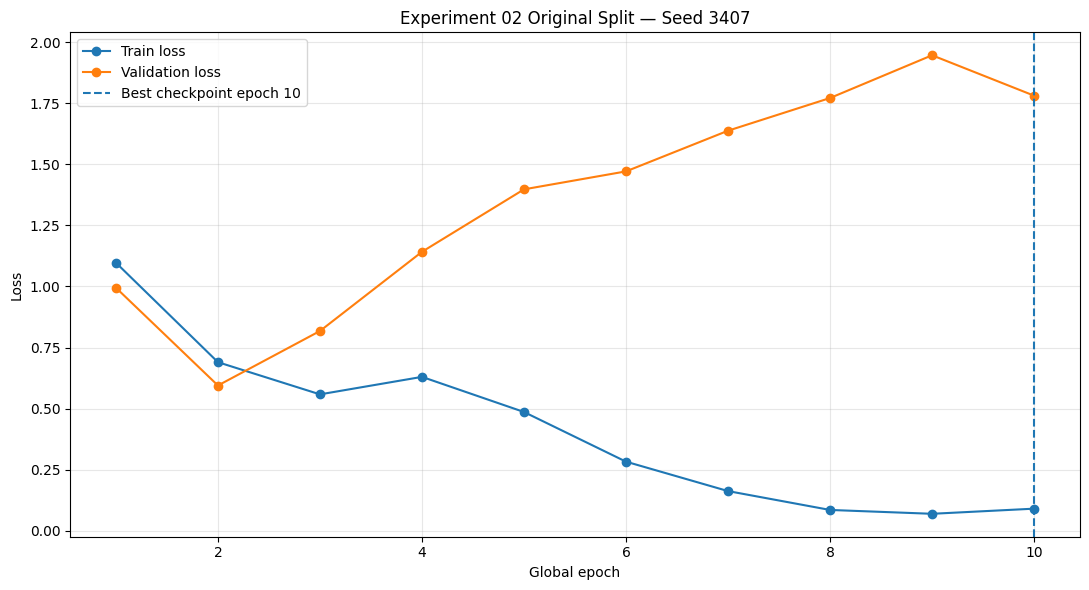

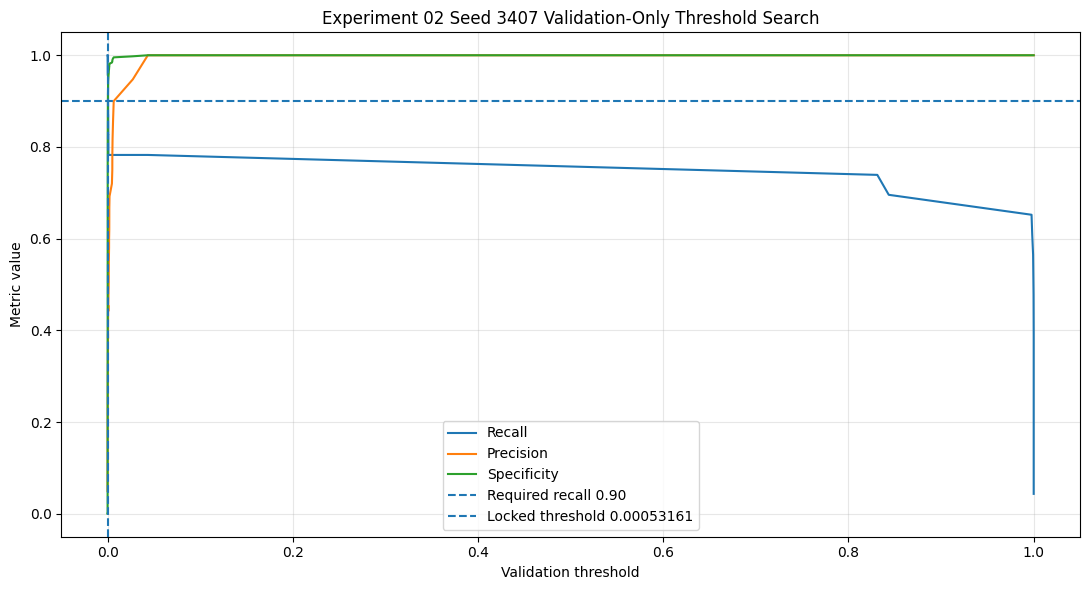


FINAL SEED 3407 REPORT
Best global epoch: 10
Validation AUPRC: 0.864485
Validation AUROC: 0.974390
Locked threshold: 0.000531613278
Recall: 0.913043
PPV: 0.428571
Specificity: 0.936073
Minimum centre recall: 0.888889
TP=21 | TN=410 | FP=28 | FN=2
Held-out test evaluated: False
Best seed selected: False

EXPERIMENT 02 MULTI-SEED RESULTS


,seed,best_stage,best_global_epoch,threshold,recall,precision,specificity,minimum_centre_recall,auroc,auprc,tp,tn,fp,fn
0,42,stage_2,8,0.000442,0.956522,0.333333,0.899543,0.888889,0.976127,0.898128,22,394,44,1
1,2026,stage_2,10,0.000251,0.956522,0.400000,0.924658,0.888889,0.976573,0.893229,22,405,33,1
2,3407,stage_2,10,0.000532,0.913043,0.428571,0.936073,0.888889,0.974390,0.864485,21,410,28,2



Multi-seed mean and variability:


,metric,seed_count,mean,standard_deviation,median,minimum,maximum,range
0,recall,3,0.942029,0.025102,0.956522,0.913043,0.956522,0.043478
1,precision,3,0.387302,0.048872,0.400000,0.333333,0.428571,0.095238
2,specificity,3,0.920091,0.018688,0.924658,0.899543,0.936073,0.036530
3,minimum_centre_recall,3,0.888889,0.000000,0.888889,0.888889,0.888889,0.000000
4,npv,3,0.996717,0.001361,0.997468,0.995146,0.997537,0.002391
5,accuracy,3,0.921186,0.016849,0.926247,0.902386,0.934924,0.032538
6,balanced_accuracy,3,0.931060,0.008434,0.928033,0.924558,0.940590,0.016031
7,f1,3,0.547273,0.046803,0.564103,0.494382,0.583333,0.088951
8,auroc,3,0.975697,0.001154,0.976127,0.974390,0.976573,0.002184
9,auprc,3,0.885281,0.018175,0.893229,0.864485,0.898128,0.033643



Per-centre multi-seed results:


,seed,center,threshold,sample_count,normal_count,positive_count,recall,precision,specificity,npv,accuracy,balanced_accuracy,f1,auroc,auprc,tp,tn,fp,fn
0,42,center_1,0.000442,341,332,9,0.888889,0.285714,0.939759,0.996805,0.938416,0.914324,0.432432,0.954652,0.714670,8,312,20,1
1,42,center_2,0.000442,120,106,14,1.000000,0.368421,0.773585,1.000000,0.800000,0.886792,0.538462,1.000000,1.000000,14,82,24,0
2,2026,center_1,0.000251,341,332,9,0.888889,0.296296,0.942771,0.996815,0.941349,0.915830,0.444444,0.950301,0.695440,8,313,19,1
3,2026,center_2,0.000251,120,106,14,1.000000,0.500000,0.867925,1.000000,0.883333,0.933962,0.666667,0.999326,0.995238,14,92,14,0
4,3407,center_1,0.000532,341,332,9,0.888889,0.380952,0.960843,0.996875,0.958944,0.924866,0.533333,0.957831,0.690486,8,319,13,1
5,3407,center_2,0.000532,120,106,14,0.928571,0.464286,0.858491,0.989130,0.866667,0.893531,0.619048,0.987871,0.959821,13,91,15,1


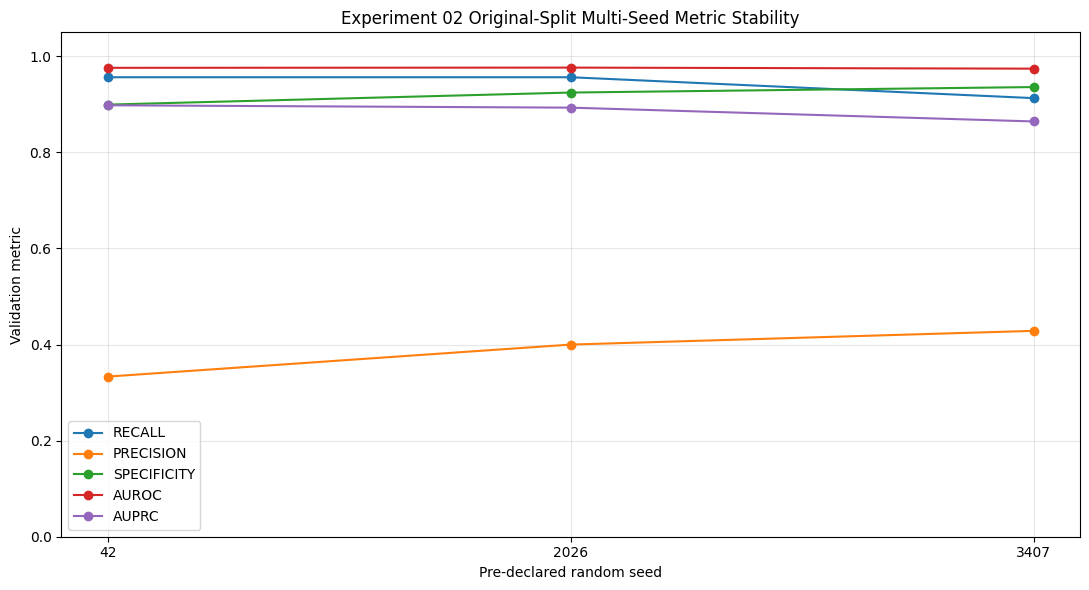

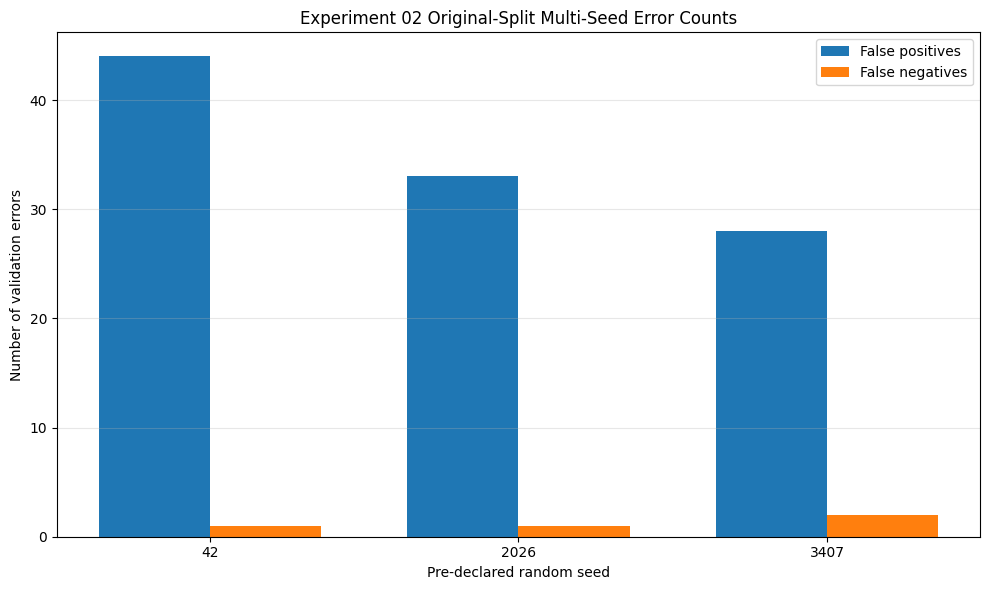

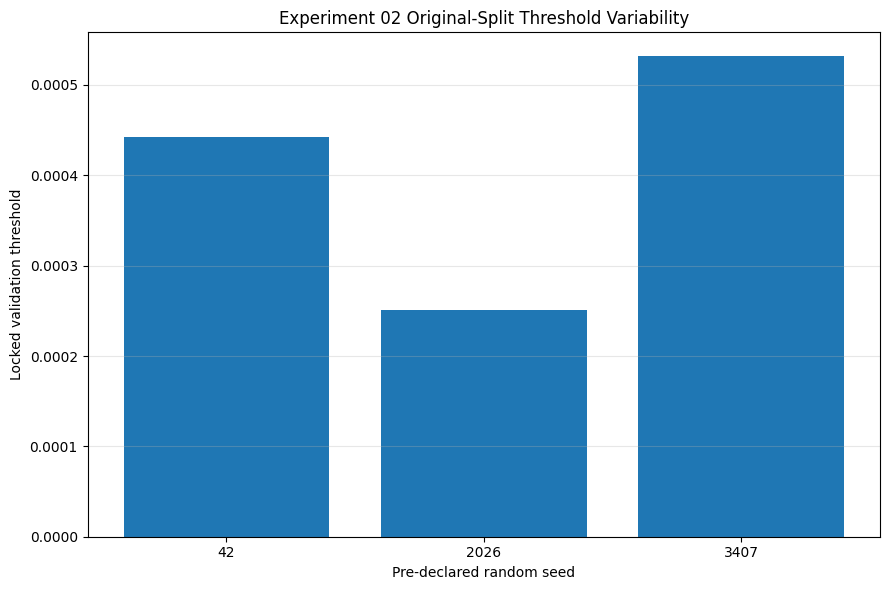


FINAL CELL 14C EXPERIMENT 02 MULTI-SEED STABILITY REPORT
Pre-declared seeds completed: 3/3
Seeds: [42, 2026, 3407]

Mean validation AUPRC: 0.885281 ± 0.018175
AUPRC range: 0.033643
Mean validation AUROC: 0.975697 ± 0.001154
Mean validation recall: 0.942029
Mean validation PPV: 0.387302 ± 0.048872
Mean validation specificity: 0.920091 ± 0.018688

Threshold minimum: 0.000251186788
Threshold maximum: 0.000531613278
Threshold range: 0.000280426489
Maximum/minimum threshold ratio: 2.116406

Ranking stable: True
Operating-point stable: True
Threshold stable: True

Final development-only stability decision:
EXP02_ORIGINAL_SPLIT_SEED_STABLE

Interpretation:
Experiment 02 showed stable ranking, operating-point and threshold behaviour across all pre-declared seeds.

Best seed selected: False
Held-out test CSV loaded: False
Held-out test predictions loaded: False
Held-out test evaluated: False
Held-out test used for decision: False

STATUS: EXP02_ORIGINAL_SPLIT_MULTI_SEED_STABILITY_COMPLETE

Sav

In [ ]:
# ==========================================================================================
# CELL 14C
# EXPERIMENT 02 — ORIGINAL-SPLIT MULTI-SEED STABILITY ANALYSIS
#
# Purpose:
# - Train Experiment 02 independently using three pre-declared random seeds
# - Use exactly the same train/validation split and training protocol
# - Select each checkpoint using validation AUPRC only
# - Select each threshold using that seed's validation predictions only
# - Measure ranking, operating-point and threshold stability
#
# IMPORTANT:
# - No held-out test file is loaded
# - No held-out test inference is performed
# - No best seed is selected
# - Completed seed runs are automatically resumed/skipped
# ==========================================================================================

from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display

import os
import gc
import json
import math
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.metrics import (
    confusion_matrix,
    average_precision_score,
    roc_auc_score,
)

from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

ImageFile.LOAD_TRUNCATED_IMAGES = True


# ==========================================================================================
# 1. FIXED EXPERIMENT CONFIGURATION
# ==========================================================================================

EXPERIMENT_ID = "experiment_02_swsl_gastronet5m_dinov1"

EXPERIMENT_NAME = (
    "Experiment 02 SWSL + GastroNet-5M DINOv1"
)

SOURCE_CHECKPOINT_FILENAME = (
    "RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth"
)

# These seeds are declared before examining their results.
STABILITY_SEEDS = [
    42,
    2026,
    3407,
]

# False means completed seed folders will be reused.
FORCE_RERUN = False

IMAGE_SIZE = 224
RESIZE_SIZE = 256

BATCH_SIZE = 32
NUM_WORKERS = 2

STAGE_1_EPOCHS = 3
STAGE_2_MAX_EPOCHS = 7
STAGE_2_PATIENCE = 3

STAGE_1_HEAD_LR = 1e-3
STAGE_2_BACKBONE_LR = 1e-5
STAGE_2_HEAD_LR = 1e-4

WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0

REQUIRED_OVERALL_RECALL = 0.90
REQUIRED_MINIMUM_CENTRE_RECALL = 0.80

EXPECTED_TRAIN_TOTAL = 2159
EXPECTED_TRAIN_NORMAL = 2050
EXPECTED_TRAIN_POSITIVE = 109

EXPECTED_VALIDATION_TOTAL = 461
EXPECTED_VALIDATION_NORMAL = 438
EXPECTED_VALIDATION_POSITIVE = 23

FINAL_STATUS = (
    "EXP02_ORIGINAL_SPLIT_MULTI_SEED_STABILITY_COMPLETE"
)


# ==========================================================================================
# 2. GOOGLE DRIVE AND PROJECT PATHS
# ==========================================================================================

MYDRIVE_ROOT = Path(
    "/content/drive/MyDrive"
)

if not MYDRIVE_ROOT.exists():

    from google.colab import drive

    drive.mount(
        "/content/drive"
    )


if not MYDRIVE_ROOT.exists():

    raise RuntimeError(
        "Google Drive MyDrive is not available.\n"
        "Mount the correct Google Drive account first."
    )


PROJECT_ROOT = (
    MYDRIVE_ROOT
    / "RARE26_GastroNet_Weights"
)

TRAIN_CSV_PATH = (
    PROJECT_ROOT
    / "configs"
    / "runtime_splits"
    / "train_runtime_verified.csv"
)

VALIDATION_CSV_PATH = (
    PROJECT_ROOT
    / "configs"
    / "runtime_splits"
    / "validation_runtime_verified.csv"
)

SOURCE_CHECKPOINT_PATH = (
    PROJECT_ROOT
    / "source_checkpoints"
    / SOURCE_CHECKPOINT_FILENAME
)

CELL14B_DECISION_PATH = (
    PROJECT_ROOT
    / "results"
    / "original_split"
    / "controlled_comparisons"
    / "experiment_01_vs_experiment_02_original_validation"
    / "cell14b_original_validation_decision.json"
)


STABILITY_ROOT = (
    PROJECT_ROOT
    / "stability"
    / "original_split"
    / EXPERIMENT_ID
)

MODEL_ROOT = (
    PROJECT_ROOT
    / "models"
    / "stability"
    / "original_split"
    / EXPERIMENT_ID
)

LOG_ROOT = (
    PROJECT_ROOT
    / "logs"
    / "stability"
    / "original_split"
    / EXPERIMENT_ID
)

PREDICTION_ROOT = (
    PROJECT_ROOT
    / "predictions"
    / "stability"
    / "original_split"
    / EXPERIMENT_ID
)

RESULT_ROOT = (
    PROJECT_ROOT
    / "results"
    / "stability"
    / "original_split"
    / EXPERIMENT_ID
)

THRESHOLD_ROOT = (
    PROJECT_ROOT
    / "thresholds"
    / "stability"
    / "original_split"
    / EXPERIMENT_ID
)

CENTRE_ROOT = (
    PROJECT_ROOT
    / "centre_analysis"
    / "stability"
    / "original_split"
    / EXPERIMENT_ID
)

FIGURE_ROOT = (
    PROJECT_ROOT
    / "figures"
    / "stability"
    / "original_split"
    / EXPERIMENT_ID
)


for folder_path in [
    STABILITY_ROOT,
    MODEL_ROOT,
    LOG_ROOT,
    PREDICTION_ROOT,
    RESULT_ROOT,
    THRESHOLD_ROOT,
    CENTRE_ROOT,
    FIGURE_ROOT,
]:

    folder_path.mkdir(
        parents=True,
        exist_ok=True,
    )


AGGREGATE_RESULT_DIR = (
    RESULT_ROOT
    / "aggregate"
)

AGGREGATE_PREDICTION_DIR = (
    PREDICTION_ROOT
    / "aggregate"
)

AGGREGATE_CENTRE_DIR = (
    CENTRE_ROOT
    / "aggregate"
)

AGGREGATE_THRESHOLD_DIR = (
    THRESHOLD_ROOT
    / "aggregate"
)

AGGREGATE_FIGURE_DIR = (
    FIGURE_ROOT
    / "aggregate"
)


for folder_path in [
    AGGREGATE_RESULT_DIR,
    AGGREGATE_PREDICTION_DIR,
    AGGREGATE_CENTRE_DIR,
    AGGREGATE_THRESHOLD_DIR,
    AGGREGATE_FIGURE_DIR,
]:

    folder_path.mkdir(
        parents=True,
        exist_ok=True,
    )


# ==========================================================================================
# 3. INITIAL REPORT
# ==========================================================================================

print("=" * 104)

print(
    "CELL 14C: EXPERIMENT 02 ORIGINAL-SPLIT "
    "MULTI-SEED STABILITY ANALYSIS"
)

print("=" * 104)

print("\nExperiment:")
print(EXPERIMENT_NAME)

print("\nPretrained checkpoint:")
print(SOURCE_CHECKPOINT_PATH)

print("\nFixed stability seeds:")
print(STABILITY_SEEDS)

print("\nTraining split:")
print(TRAIN_CSV_PATH)

print("\nValidation split:")
print(VALIDATION_CSV_PATH)

print("\nHeld-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("Held-out test used for any decision: False")
print("Best seed selection allowed: False")


# ==========================================================================================
# 4. REQUIRED FILE CHECK
# ==========================================================================================

required_files = [
    TRAIN_CSV_PATH,
    VALIDATION_CSV_PATH,
    SOURCE_CHECKPOINT_PATH,
    CELL14B_DECISION_PATH,
]

missing_files = [
    path
    for path in required_files
    if not path.exists()
]

if missing_files:

    print("\nMissing required files:")

    for missing_path in missing_files:
        print(missing_path)

    raise FileNotFoundError(
        "One or more required Cell 14C source files "
        "were not found."
    )


cell14b_decision = json.loads(
    CELL14B_DECISION_PATH.read_text(
        encoding="utf-8"
    )
)

print("\nCell 14B decision verified:")

print(
    cell14b_decision.get(
        "decision",
        "decision_not_found",
    )
)


# ==========================================================================================
# 5. COLUMN DETECTION
# ==========================================================================================

def find_column(
    dataframe,
    candidates,
    description,
):

    for candidate in candidates:

        if candidate in dataframe.columns:
            return candidate

    lowercase_map = {
        str(column).lower(): column
        for column in dataframe.columns
    }

    for candidate in candidates:

        if candidate.lower() in lowercase_map:

            return lowercase_map[
                candidate.lower()
            ]

    raise KeyError(
        f"Could not find {description} column.\n"
        f"Available columns:\n"
        f"{list(dataframe.columns)}"
    )


PATH_CANDIDATES = [
    "runtime_path",
    "image_path",
    "filepath",
    "file_path",
    "path",
]

LABEL_CANDIDATES = [
    "label",
    "target",
    "ground_truth",
    "class_label",
    "y_true",
]

CENTER_CANDIDATES = [
    "center",
    "centre",
    "site",
]

SHA_CANDIDATES = [
    "sha256",
    "image_sha256",
    "file_sha256",
]

RELATIVE_PATH_CANDIDATES = [
    "relative_path",
    "original_relative_path",
    "image_relative_path",
]


# ==========================================================================================
# 6. LOAD AND VERIFY LOCKED ORIGINAL SPLITS
# ==========================================================================================

train_df = pd.read_csv(
    TRAIN_CSV_PATH,
    low_memory=False,
)

validation_df = pd.read_csv(
    VALIDATION_CSV_PATH,
    low_memory=False,
)


train_path_column = find_column(
    train_df,
    PATH_CANDIDATES,
    "training runtime path",
)

validation_path_column = find_column(
    validation_df,
    PATH_CANDIDATES,
    "validation runtime path",
)

train_label_column = find_column(
    train_df,
    LABEL_CANDIDATES,
    "training label",
)

validation_label_column = find_column(
    validation_df,
    LABEL_CANDIDATES,
    "validation label",
)

train_center_column = find_column(
    train_df,
    CENTER_CANDIDATES,
    "training centre",
)

validation_center_column = find_column(
    validation_df,
    CENTER_CANDIDATES,
    "validation centre",
)

validation_sha_column = find_column(
    validation_df,
    SHA_CANDIDATES,
    "validation SHA-256",
)

validation_relative_path_column = find_column(
    validation_df,
    RELATIVE_PATH_CANDIDATES,
    "validation relative path",
)


train_df[
    train_label_column
] = pd.to_numeric(
    train_df[
        train_label_column
    ],
    errors="raise",
).astype(int)

validation_df[
    validation_label_column
] = pd.to_numeric(
    validation_df[
        validation_label_column
    ],
    errors="raise",
).astype(int)


train_total = len(
    train_df
)

validation_total = len(
    validation_df
)

train_normal = int(
    (
        train_df[
            train_label_column
        ]
        == 0
    ).sum()
)

train_positive = int(
    (
        train_df[
            train_label_column
        ]
        == 1
    ).sum()
)

validation_normal = int(
    (
        validation_df[
            validation_label_column
        ]
        == 0
    ).sum()
)

validation_positive = int(
    (
        validation_df[
            validation_label_column
        ]
        == 1
    ).sum()
)


expected_counts = {
    "train_total": (
        train_total,
        EXPECTED_TRAIN_TOTAL,
    ),

    "train_normal": (
        train_normal,
        EXPECTED_TRAIN_NORMAL,
    ),

    "train_positive": (
        train_positive,
        EXPECTED_TRAIN_POSITIVE,
    ),

    "validation_total": (
        validation_total,
        EXPECTED_VALIDATION_TOTAL,
    ),

    "validation_normal": (
        validation_normal,
        EXPECTED_VALIDATION_NORMAL,
    ),

    "validation_positive": (
        validation_positive,
        EXPECTED_VALIDATION_POSITIVE,
    ),
}


for count_name, (
    actual_count,
    expected_count,
) in expected_counts.items():

    if actual_count != expected_count:

        raise RuntimeError(
            f"Locked split count mismatch for {count_name}.\n"
            f"Expected: {expected_count}\n"
            f"Found: {actual_count}"
        )


missing_train_images = [
    path
    for path in train_df[
        train_path_column
    ].astype(str)
    if not Path(
        path
    ).exists()
]

missing_validation_images = [
    path
    for path in validation_df[
        validation_path_column
    ].astype(str)
    if not Path(
        path
    ).exists()
]


if missing_train_images:

    raise FileNotFoundError(
        f"{len(missing_train_images)} training images "
        "are missing from temporary Colab storage.\n"
        "Run Cell 3B again before Cell 14C."
    )


if missing_validation_images:

    raise FileNotFoundError(
        f"{len(missing_validation_images)} validation "
        "images are missing from temporary Colab storage.\n"
        "Run Cell 3B again before Cell 14C."
    )


train_identity_values = set(
    train_df[
        train_path_column
    ].astype(str)
)

validation_identity_values = set(
    validation_df[
        validation_path_column
    ].astype(str)
)

split_overlap = len(
    train_identity_values.intersection(
        validation_identity_values
    )
)


if split_overlap != 0:

    raise RuntimeError(
        f"Train/validation overlap detected: "
        f"{split_overlap}"
    )


print("\nLocked original split verified:")

print(
    f"Train: {train_total} "
    f"(normal={train_normal}, NEO={train_positive})"
)

print(
    f"Validation: {validation_total} "
    f"(normal={validation_normal}, "
    f"NEO={validation_positive})"
)

print(
    f"Train/validation overlap: "
    f"{split_overlap}"
)

print(
    f"Missing training images: "
    f"{len(missing_train_images)}"
)

print(
    f"Missing validation images: "
    f"{len(missing_validation_images)}"
)


# ==========================================================================================
# 7. DEVICE
# ==========================================================================================

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

USE_AMP = (
    DEVICE.type == "cuda"
)


print("\nCompute device:")
print(DEVICE)

if torch.cuda.is_available():

    print(
        torch.cuda.get_device_name(
            0
        )
    )


# ==========================================================================================
# 8. REPRODUCIBILITY FUNCTIONS
# ==========================================================================================

def set_complete_seed(
    seed,
):

    os.environ[
        "PYTHONHASHSEED"
    ] = str(
        seed
    )

    random.seed(
        seed
    )

    np.random.seed(
        seed
    )

    torch.manual_seed(
        seed
    )

    if torch.cuda.is_available():

        torch.cuda.manual_seed(
            seed
        )

        torch.cuda.manual_seed_all(
            seed
        )

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    try:

        torch.use_deterministic_algorithms(
            True,
            warn_only=True,
        )

    except Exception:

        pass


def seed_worker(
    worker_id,
):

    worker_seed = (
        torch.initial_seed()
        % (2 ** 32)
    )

    np.random.seed(
        worker_seed
    )

    random.seed(
        worker_seed
    )


# ==========================================================================================
# 9. IMAGE TRANSFORMS
# ==========================================================================================

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406,
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225,
]

ROTATION_FILL = tuple(
    int(
        value * 255
    )
    for value in IMAGENET_MEAN
)


train_transform = transforms.Compose(
    [
        transforms.Resize(
            RESIZE_SIZE
        ),

        transforms.RandomResizedCrop(
            IMAGE_SIZE,
            scale=(
                0.85,
                1.00,
            ),
            ratio=(
                0.90,
                1.10,
            ),
        ),

        transforms.RandomHorizontalFlip(
            p=0.5
        ),

        transforms.RandomRotation(
            degrees=8,
            fill=ROTATION_FILL,
        ),

        transforms.ColorJitter(
            brightness=0.10,
            contrast=0.10,
            saturation=0.05,
            hue=0.02,
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)


validation_transform = transforms.Compose(
    [
        transforms.Resize(
            RESIZE_SIZE
        ),

        transforms.CenterCrop(
            IMAGE_SIZE
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)


# ==========================================================================================
# 10. DATASET CLASS
# ==========================================================================================

class RARE26Dataset(
    Dataset
):

    def __init__(
        self,
        dataframe,
        path_column,
        label_column,
        transform,
    ):

        self.dataframe = dataframe.reset_index(
            drop=True
        ).copy()

        self.path_column = path_column
        self.label_column = label_column
        self.transform = transform


    def __len__(
        self,
    ):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        index,
    ):

        row = self.dataframe.iloc[
            index
        ]

        image_path = str(
            row[
                self.path_column
            ]
        )

        label = float(
            row[
                self.label_column
            ]
        )

        with Image.open(
            image_path
        ) as opened_image:

            image = opened_image.convert(
                "RGB"
            )

        image = self.transform(
            image
        )

        return (
            image,
            torch.tensor(
                label,
                dtype=torch.float32,
            ),
            index,
        )


# ==========================================================================================
# 11. CHECKPOINT LOADING
# ==========================================================================================

def torch_load_complete(
    path,
):

    try:

        return torch.load(
            path,
            map_location="cpu",
            weights_only=False,
        )

    except TypeError:

        return torch.load(
            path,
            map_location="cpu",
        )


def extract_tensor_state_dict(
    checkpoint_object,
):

    if isinstance(
        checkpoint_object,
        dict,
    ):

        candidate_keys = [
            "state_dict",
            "model_state_dict",
            "model",
            "student",
            "teacher",
            "backbone",
            "encoder",
        ]

        for candidate_key in candidate_keys:

            if (
                candidate_key
                in checkpoint_object
                and isinstance(
                    checkpoint_object[
                        candidate_key
                    ],
                    dict,
                )
            ):

                nested_state = (
                    checkpoint_object[
                        candidate_key
                    ]
                )

                tensor_count = sum(
                    torch.is_tensor(
                        value
                    )
                    for value in nested_state.values()
                )

                if tensor_count > 0:

                    return nested_state


        tensor_entries = {
            key: value
            for key, value
            in checkpoint_object.items()
            if torch.is_tensor(
                value
            )
        }

        if tensor_entries:

            return tensor_entries


    raise RuntimeError(
        "Could not extract tensor state dictionary "
        "from the source checkpoint."
    )


def strip_checkpoint_prefixes(
    key,
):

    cleaned_key = str(
        key
    )

    prefixes = [
        "module.",
        "model.",
        "backbone.",
        "encoder.",
        "student.",
        "teacher.",
        "network.",
        "base_encoder.",
    ]

    prefix_removed = True

    while prefix_removed:

        prefix_removed = False

        for prefix in prefixes:

            if cleaned_key.startswith(
                prefix
            ):

                cleaned_key = cleaned_key[
                    len(
                        prefix
                    ):
                ]

                prefix_removed = True

    return cleaned_key


SOURCE_CHECKPOINT_OBJECT = torch_load_complete(
    SOURCE_CHECKPOINT_PATH
)

SOURCE_STATE_DICT = extract_tensor_state_dict(
    SOURCE_CHECKPOINT_OBJECT
)


def build_experiment_02_model():

    model = models.resnet50(
        weights=None
    )

    feature_count = model.fc.in_features

    model.fc = nn.Linear(
        feature_count,
        1,
    )

    model_state = model.state_dict()

    expected_backbone_keys = {
        key
        for key in model_state.keys()
        if not key.startswith(
            "fc."
        )
    }

    compatible_state = {}

    shape_mismatch_keys = []


    for raw_key, tensor_value in (
        SOURCE_STATE_DICT.items()
    ):

        if not torch.is_tensor(
            tensor_value
        ):

            continue

        cleaned_key = strip_checkpoint_prefixes(
            raw_key
        )

        if cleaned_key not in expected_backbone_keys:

            continue

        if tuple(
            tensor_value.shape
        ) != tuple(
            model_state[
                cleaned_key
            ].shape
        ):

            shape_mismatch_keys.append(
                cleaned_key
            )

            continue

        compatible_state[
            cleaned_key
        ] = tensor_value


    if shape_mismatch_keys:

        raise RuntimeError(
            "Shape mismatches were found while loading "
            "the SWSL + GastroNet-DINO backbone:\n"
            f"{shape_mismatch_keys[:20]}"
        )


    matched_count = len(
        compatible_state
    )

    expected_count = len(
        expected_backbone_keys
    )


    if matched_count != expected_count:

        missing_backbone_keys = sorted(
            expected_backbone_keys.difference(
                compatible_state.keys()
            )
        )

        raise RuntimeError(
            "The pretrained backbone did not match the "
            "complete torchvision ResNet-50 backbone.\n"
            f"Matched: {matched_count}/{expected_count}\n"
            f"Missing examples: "
            f"{missing_backbone_keys[:20]}"
        )


    load_result = model.load_state_dict(
        compatible_state,
        strict=False,
    )


    unexpected_parameters = list(
        load_result.unexpected_keys
    )

    missing_parameters = list(
        load_result.missing_keys
    )


    if unexpected_parameters:

        raise RuntimeError(
            "Unexpected parameters appeared while "
            "loading the pretrained backbone:\n"
            f"{unexpected_parameters}"
        )


    if set(
        missing_parameters
    ) != {
        "fc.weight",
        "fc.bias",
    }:

        raise RuntimeError(
            "Unexpected missing parameters appeared:\n"
            f"{missing_parameters}"
        )


    return (
        model,
        matched_count,
        expected_count,
        missing_parameters,
        unexpected_parameters,
    )


# Verify compatibility before starting the seed loop.

verification_model, matched_count, expected_count, missing_parameters, unexpected_parameters = (
    build_experiment_02_model()
)

print("\nPretrained backbone compatibility:")

print(
    f"Matched tensors: "
    f"{matched_count}/{expected_count}"
)

print(
    f"Missing parameters: "
    f"{missing_parameters}"
)

print(
    f"Unexpected parameters: "
    f"{unexpected_parameters}"
)

del verification_model

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()


# ==========================================================================================
# 12. METRIC FUNCTIONS
# ==========================================================================================

def safe_divide(
    numerator,
    denominator,
):

    if denominator == 0:
        return 0.0

    return float(
        numerator
        / denominator
    )


def calculate_metrics(
    labels,
    probabilities,
    predictions,
):

    labels = np.asarray(
        labels,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    predictions = np.asarray(
        predictions,
        dtype=int,
    )


    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[
            0,
            1,
        ],
    ).ravel()


    recall = safe_divide(
        tp,
        tp + fn,
    )

    precision = safe_divide(
        tp,
        tp + fp,
    )

    specificity = safe_divide(
        tn,
        tn + fp,
    )

    npv = safe_divide(
        tn,
        tn + fn,
    )

    accuracy = safe_divide(
        tp + tn,
        len(
            labels
        ),
    )

    balanced_accuracy = (
        recall
        + specificity
    ) / 2.0

    f1 = safe_divide(
        2
        * precision
        * recall,
        precision
        + recall,
    )


    if len(
        np.unique(
            labels
        )
    ) == 2:

        auroc = float(
            roc_auc_score(
                labels,
                probabilities,
            )
        )

        auprc = float(
            average_precision_score(
                labels,
                probabilities,
            )
        )

    else:

        auroc = np.nan
        auprc = np.nan


    return {
        "sample_count": int(
            len(
                labels
            )
        ),

        "normal_count": int(
            (
                labels == 0
            ).sum()
        ),

        "positive_count": int(
            (
                labels == 1
            ).sum()
        ),

        "recall": float(
            recall
        ),

        "precision": float(
            precision
        ),

        "specificity": float(
            specificity
        ),

        "npv": float(
            npv
        ),

        "accuracy": float(
            accuracy
        ),

        "balanced_accuracy": float(
            balanced_accuracy
        ),

        "f1": float(
            f1
        ),

        "auroc": float(
            auroc
        ),

        "auprc": float(
            auprc
        ),

        "tp": int(
            tp
        ),

        "tn": int(
            tn
        ),

        "fp": int(
            fp
        ),

        "fn": int(
            fn
        ),
    }


# ==========================================================================================
# 13. TRAINING AND INFERENCE FUNCTIONS
# ==========================================================================================

def create_grad_scaler():

    try:

        return torch.amp.GradScaler(
            "cuda",
            enabled=USE_AMP,
        )

    except Exception:

        return torch.cuda.amp.GradScaler(
            enabled=USE_AMP
        )


def autocast_context():

    try:

        return torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=USE_AMP,
        )

    except Exception:

        return torch.cuda.amp.autocast(
            enabled=USE_AMP
        )


def train_one_epoch(
    model,
    data_loader,
    criterion,
    optimizer,
    scaler,
):

    model.train()

    running_loss = 0.0
    processed_count = 0


    for images, labels, _ in data_loader:

        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True,
        )

        optimizer.zero_grad(
            set_to_none=True
        )


        with autocast_context():

            logits = model(
                images
            ).squeeze(
                1
            )

            loss = criterion(
                logits,
                labels,
            )


        scaler.scale(
            loss
        ).backward()

        scaler.unscale_(
            optimizer
        )

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRADIENT_CLIP_NORM,
        )

        scaler.step(
            optimizer
        )

        scaler.update()


        current_batch_size = images.size(
            0
        )

        running_loss += (
            float(
                loss.detach().cpu()
            )
            * current_batch_size
        )

        processed_count += (
            current_batch_size
        )


    return safe_divide(
        running_loss,
        processed_count,
    )


@torch.no_grad()
def run_validation(
    model,
    data_loader,
    criterion,
):

    model.eval()

    all_logits = []
    all_labels = []
    all_indices = []

    running_loss = 0.0
    processed_count = 0


    for images, labels, indices in data_loader:

        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        labels_device = labels.to(
            DEVICE,
            non_blocking=True,
        )


        with autocast_context():

            logits = model(
                images
            ).squeeze(
                1
            )

            loss = criterion(
                logits,
                labels_device,
            )


        current_batch_size = images.size(
            0
        )

        running_loss += (
            float(
                loss.detach().cpu()
            )
            * current_batch_size
        )

        processed_count += (
            current_batch_size
        )

        all_logits.append(
            logits.detach().float().cpu().numpy()
        )

        all_labels.append(
            labels.numpy()
        )

        all_indices.append(
            indices.numpy()
        )


    logits = np.concatenate(
        all_logits
    ).astype(
        np.float64
    )

    labels = np.concatenate(
        all_labels
    ).astype(
        int
    )

    indices = np.concatenate(
        all_indices
    ).astype(
        int
    )

    probabilities = (
        1.0
        / (
            1.0
            + np.exp(
                -np.clip(
                    logits,
                    -50,
                    50,
                )
            )
        )
    )


    return {
        "validation_loss": safe_divide(
            running_loss,
            processed_count,
        ),

        "logits": logits,

        "probabilities": probabilities,

        "labels": labels,

        "indices": indices,
    }


def save_checkpoint(
    model,
    checkpoint_path,
    metadata,
):

    cpu_state_dict = {
        key: value.detach().cpu()
        for key, value
        in model.state_dict().items()
    }

    checkpoint_record = {
        "model_state_dict": cpu_state_dict,
        **metadata,
    }

    torch.save(
        checkpoint_record,
        checkpoint_path,
    )


# ==========================================================================================
# 14. VALIDATION-ONLY THRESHOLD SEARCH
# ==========================================================================================

def search_validation_threshold(
    prediction_dataframe,
):

    labels = prediction_dataframe[
        "label"
    ].to_numpy(
        dtype=int
    )

    probabilities = prediction_dataframe[
        "probability"
    ].to_numpy(
        dtype=float
    )

    centers = prediction_dataframe[
        "center"
    ].astype(str).to_numpy()


    candidate_thresholds = np.unique(
        np.concatenate(
            [
                np.array(
                    [
                        0.0,
                        1.0,
                    ],
                    dtype=float,
                ),

                probabilities,
            ]
        )
    )


    threshold_rows = []


    for threshold in candidate_thresholds:

        predictions = (
            probabilities
            >= threshold
        ).astype(
            int
        )

        overall_metrics = calculate_metrics(
            labels,
            probabilities,
            predictions,
        )

        centre_recall_values = {}


        for center_value in sorted(
            np.unique(
                centers
            )
        ):

            center_mask = (
                centers
                == center_value
            )

            center_metrics = calculate_metrics(
                labels[
                    center_mask
                ],

                probabilities[
                    center_mask
                ],

                predictions[
                    center_mask
                ],
            )

            centre_recall_values[
                center_value
            ] = center_metrics[
                "recall"
            ]


        minimum_centre_recall = min(
            centre_recall_values.values()
        )


        threshold_rows.append(
            {
                "threshold": float(
                    threshold
                ),

                "recall": overall_metrics[
                    "recall"
                ],

                "precision": overall_metrics[
                    "precision"
                ],

                "specificity": overall_metrics[
                    "specificity"
                ],

                "npv": overall_metrics[
                    "npv"
                ],

                "accuracy": overall_metrics[
                    "accuracy"
                ],

                "balanced_accuracy": overall_metrics[
                    "balanced_accuracy"
                ],

                "f1": overall_metrics[
                    "f1"
                ],

                "tp": overall_metrics[
                    "tp"
                ],

                "tn": overall_metrics[
                    "tn"
                ],

                "fp": overall_metrics[
                    "fp"
                ],

                "fn": overall_metrics[
                    "fn"
                ],

                "minimum_centre_recall": float(
                    minimum_centre_recall
                ),

                **{
                    f"{center_value}_recall": (
                        centre_recall_values[
                            center_value
                        ]
                    )
                    for center_value
                    in centre_recall_values
                },
            }
        )


    threshold_search_df = pd.DataFrame(
        threshold_rows
    )


    strict_eligible_df = threshold_search_df[
        (
            threshold_search_df[
                "recall"
            ]
            >= REQUIRED_OVERALL_RECALL
        )
        &
        (
            threshold_search_df[
                "minimum_centre_recall"
            ]
            >= REQUIRED_MINIMUM_CENTRE_RECALL
        )
    ].copy()


    if len(
        strict_eligible_df
    ) > 0:

        eligible_df = strict_eligible_df

        selection_mode = (
            "overall_recall_0.90_and_"
            "minimum_centre_recall_0.80"
        )

    else:

        overall_eligible_df = threshold_search_df[
            threshold_search_df[
                "recall"
            ]
            >= REQUIRED_OVERALL_RECALL
        ].copy()


        if len(
            overall_eligible_df
        ) > 0:

            eligible_df = overall_eligible_df

            selection_mode = (
                "fallback_overall_recall_0.90"
            )

        else:

            eligible_df = threshold_search_df.copy()

            selection_mode = (
                "fallback_highest_recall"
            )


    selected_row = (
        eligible_df.sort_values(
            by=[
                "precision",
                "minimum_centre_recall",
                "specificity",
                "threshold",
            ],
            ascending=[
                False,
                False,
                False,
                False,
            ],
        )
        .iloc[
            0
        ]
        .copy()
    )


    return (
        threshold_search_df,
        selected_row,
        selection_mode,
        len(
            strict_eligible_df
        ),
    )


# ==========================================================================================
# 15. PER-SEED TRAINING FUNCTION
# ==========================================================================================

def run_seed_experiment(
    seed,
):

    seed_name = (
        f"seed_{seed}"
    )

    seed_model_dir = (
        MODEL_ROOT
        / seed_name
    )

    seed_log_dir = (
        LOG_ROOT
        / seed_name
    )

    seed_prediction_dir = (
        PREDICTION_ROOT
        / seed_name
    )

    seed_result_dir = (
        RESULT_ROOT
        / seed_name
    )

    seed_threshold_dir = (
        THRESHOLD_ROOT
        / seed_name
    )

    seed_centre_dir = (
        CENTRE_ROOT
        / seed_name
    )

    seed_figure_dir = (
        FIGURE_ROOT
        / seed_name
    )


    for folder_path in [
        seed_model_dir,
        seed_log_dir,
        seed_prediction_dir,
        seed_result_dir,
        seed_threshold_dir,
        seed_centre_dir,
        seed_figure_dir,
    ]:

        folder_path.mkdir(
            parents=True,
            exist_ok=True,
        )


    best_checkpoint_path = (
        seed_model_dir
        / (
            f"exp02_original_split_{seed_name}_best.pth"
        )
    )

    training_history_path = (
        seed_log_dir
        / (
            f"exp02_original_split_{seed_name}_"
            "training_history.csv"
        )
    )

    raw_prediction_path = (
        seed_prediction_dir
        / (
            f"exp02_original_split_{seed_name}_"
            "validation_predictions.csv"
        )
    )

    locked_prediction_path = (
        seed_prediction_dir
        / (
            f"exp02_original_split_{seed_name}_"
            "validation_predictions_locked_threshold.csv"
        )
    )

    validation_metrics_path = (
        seed_result_dir
        / (
            f"exp02_original_split_{seed_name}_"
            "validation_metrics.csv"
        )
    )

    threshold_search_path = (
        seed_threshold_dir
        / (
            f"exp02_original_split_{seed_name}_"
            "threshold_search.csv"
        )
    )

    threshold_lock_path = (
        seed_threshold_dir
        / (
            f"exp02_original_split_{seed_name}_"
            "threshold_lock.json"
        )
    )

    centre_metrics_path = (
        seed_centre_dir
        / (
            f"exp02_original_split_{seed_name}_"
            "validation_per_centre_metrics.csv"
        )
    )

    training_figure_path = (
        seed_figure_dir
        / (
            f"exp02_original_split_{seed_name}_"
            "training_curves.png"
        )
    )

    threshold_figure_path = (
        seed_figure_dir
        / (
            f"exp02_original_split_{seed_name}_"
            "threshold_analysis.png"
        )
    )

    status_path = (
        seed_result_dir
        / (
            f"exp02_original_split_{seed_name}_"
            "status.json"
        )
    )

    summary_path = (
        seed_result_dir
        / (
            f"exp02_original_split_{seed_name}_"
            "summary.txt"
        )
    )


    required_completed_outputs = [
        best_checkpoint_path,
        training_history_path,
        locked_prediction_path,
        validation_metrics_path,
        threshold_search_path,
        threshold_lock_path,
        centre_metrics_path,
        status_path,
    ]


    if (
        not FORCE_RERUN
        and status_path.exists()
        and all(
            path.exists()
            for path in required_completed_outputs
        )
    ):

        existing_status = json.loads(
            status_path.read_text(
                encoding="utf-8"
            )
        )

        if existing_status.get(
            "status"
        ) == (
            "EXP02_ORIGINAL_SPLIT_SEED_RUN_COMPLETE"
        ):

            existing_metrics_df = pd.read_csv(
                validation_metrics_path
            )

            existing_metrics = (
                existing_metrics_df.iloc[
                    0
                ].to_dict()
            )

            print(
                f"\nSeed {seed} already complete. "
                "Saved results will be reused."
            )

            return existing_metrics


    print("\n" + "-" * 104)

    print(
        f"STARTING EXPERIMENT 02 SEED {seed}"
    )

    print("-" * 104)


    set_complete_seed(
        seed
    )


    train_dataset = RARE26Dataset(
        train_df,
        train_path_column,
        train_label_column,
        train_transform,
    )

    validation_dataset = RARE26Dataset(
        validation_df,
        validation_path_column,
        validation_label_column,
        validation_transform,
    )


    loader_generator = torch.Generator()

    loader_generator.manual_seed(
        seed
    )


    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=USE_AMP,
        drop_last=False,
        worker_init_fn=seed_worker,
        generator=loader_generator,
        persistent_workers=(
            NUM_WORKERS > 0
        ),
    )


    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=USE_AMP,
        drop_last=False,
        worker_init_fn=seed_worker,
        persistent_workers=(
            NUM_WORKERS > 0
        ),
    )


    model, matched_backbone_count, expected_backbone_count, _, _ = (
        build_experiment_02_model()
    )

    model = model.to(
        DEVICE
    )


    positive_weight = (
        train_normal
        / train_positive
    )

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            [
                positive_weight
            ],
            dtype=torch.float32,
            device=DEVICE,
        )
    )


    training_history = []

    best_validation_auprc = (
        -np.inf
    )

    best_checkpoint_metadata = None

    global_epoch = 0


    # ======================================================================================
    # STAGE 1 — CLASSIFICATION HEAD ONLY
    # ======================================================================================

    for parameter in model.parameters():

        parameter.requires_grad = False

    for parameter in model.fc.parameters():

        parameter.requires_grad = True


    stage_1_optimizer = torch.optim.AdamW(
        model.fc.parameters(),
        lr=STAGE_1_HEAD_LR,
        weight_decay=WEIGHT_DECAY,
    )

    stage_1_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        stage_1_optimizer,
        T_max=STAGE_1_EPOCHS,
    )

    stage_1_scaler = create_grad_scaler()


    print(
        "\nSTAGE 1: CLASSIFICATION HEAD ONLY"
    )


    for stage_epoch in range(
        1,
        STAGE_1_EPOCHS + 1,
    ):

        global_epoch += 1


        train_loss = train_one_epoch(
            model,
            train_loader,
            criterion,
            stage_1_optimizer,
            stage_1_scaler,
        )


        validation_result = run_validation(
            model,
            validation_loader,
            criterion,
        )


        validation_metrics_default = calculate_metrics(
            validation_result[
                "labels"
            ],

            validation_result[
                "probabilities"
            ],

            (
                validation_result[
                    "probabilities"
                ]
                >= 0.5
            ).astype(
                int
            ),
        )


        current_auprc = (
            validation_metrics_default[
                "auprc"
            ]
        )

        current_auroc = (
            validation_metrics_default[
                "auroc"
            ]
        )


        training_history.append(
            {
                "seed": seed,
                "stage": "stage_1",
                "stage_epoch": stage_epoch,
                "global_epoch": global_epoch,
                "train_loss": train_loss,
                "validation_loss": (
                    validation_result[
                        "validation_loss"
                    ]
                ),
                "validation_auprc": current_auprc,
                "validation_auroc": current_auroc,
                "default_recall": (
                    validation_metrics_default[
                        "recall"
                    ]
                ),
                "default_precision": (
                    validation_metrics_default[
                        "precision"
                    ]
                ),
                "default_specificity": (
                    validation_metrics_default[
                        "specificity"
                    ]
                ),
                "learning_rate_backbone": 0.0,
                "learning_rate_head": (
                    stage_1_optimizer.param_groups[
                        0
                    ][
                        "lr"
                    ]
                ),
            }
        )


        print(
            f"Seed {seed} | Stage 1 | "
            f"Epoch {stage_epoch}/{STAGE_1_EPOCHS} | "
            f"Global {global_epoch} | "
            f"Train loss {train_loss:.6f} | "
            f"Val loss "
            f"{validation_result['validation_loss']:.6f} | "
            f"AUPRC {current_auprc:.6f} | "
            f"AUROC {current_auroc:.6f}"
        )


        if current_auprc > best_validation_auprc:

            best_validation_auprc = (
                current_auprc
            )

            best_checkpoint_metadata = {
                "seed": seed,
                "stage": "stage_1",
                "stage_epoch": stage_epoch,
                "global_epoch": global_epoch,
                "validation_auprc": current_auprc,
                "validation_auroc": current_auroc,
                "source_checkpoint": (
                    SOURCE_CHECKPOINT_FILENAME
                ),
                "matched_backbone_tensors": (
                    matched_backbone_count
                ),
                "expected_backbone_tensors": (
                    expected_backbone_count
                ),
            }

            save_checkpoint(
                model,
                best_checkpoint_path,
                best_checkpoint_metadata,
            )


        stage_1_scheduler.step()


    # ======================================================================================
    # STAGE 2 — LAYER4 AND CLASSIFICATION HEAD
    # ======================================================================================

    for parameter in model.parameters():

        parameter.requires_grad = False

    for parameter in model.layer4.parameters():

        parameter.requires_grad = True

    for parameter in model.fc.parameters():

        parameter.requires_grad = True


    stage_2_optimizer = torch.optim.AdamW(
        [
            {
                "params": (
                    model.layer4.parameters()
                ),
                "lr": STAGE_2_BACKBONE_LR,
            },

            {
                "params": (
                    model.fc.parameters()
                ),
                "lr": STAGE_2_HEAD_LR,
            },
        ],
        weight_decay=WEIGHT_DECAY,
    )

    stage_2_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        stage_2_optimizer,
        T_max=STAGE_2_MAX_EPOCHS,
    )

    stage_2_scaler = create_grad_scaler()

    consecutive_non_improvements = 0


    print(
        "\nSTAGE 2: LAYER4 AND CLASSIFICATION HEAD"
    )


    for stage_epoch in range(
        1,
        STAGE_2_MAX_EPOCHS + 1,
    ):

        global_epoch += 1


        train_loss = train_one_epoch(
            model,
            train_loader,
            criterion,
            stage_2_optimizer,
            stage_2_scaler,
        )


        validation_result = run_validation(
            model,
            validation_loader,
            criterion,
        )


        validation_metrics_default = calculate_metrics(
            validation_result[
                "labels"
            ],

            validation_result[
                "probabilities"
            ],

            (
                validation_result[
                    "probabilities"
                ]
                >= 0.5
            ).astype(
                int
            ),
        )


        current_auprc = (
            validation_metrics_default[
                "auprc"
            ]
        )

        current_auroc = (
            validation_metrics_default[
                "auroc"
            ]
        )


        training_history.append(
            {
                "seed": seed,
                "stage": "stage_2",
                "stage_epoch": stage_epoch,
                "global_epoch": global_epoch,
                "train_loss": train_loss,
                "validation_loss": (
                    validation_result[
                        "validation_loss"
                    ]
                ),
                "validation_auprc": current_auprc,
                "validation_auroc": current_auroc,
                "default_recall": (
                    validation_metrics_default[
                        "recall"
                    ]
                ),
                "default_precision": (
                    validation_metrics_default[
                        "precision"
                    ]
                ),
                "default_specificity": (
                    validation_metrics_default[
                        "specificity"
                    ]
                ),
                "learning_rate_backbone": (
                    stage_2_optimizer.param_groups[
                        0
                    ][
                        "lr"
                    ]
                ),
                "learning_rate_head": (
                    stage_2_optimizer.param_groups[
                        1
                    ][
                        "lr"
                    ]
                ),
            }
        )


        print(
            f"Seed {seed} | Stage 2 | "
            f"Epoch {stage_epoch}/{STAGE_2_MAX_EPOCHS} | "
            f"Global {global_epoch} | "
            f"Train loss {train_loss:.6f} | "
            f"Val loss "
            f"{validation_result['validation_loss']:.6f} | "
            f"AUPRC {current_auprc:.6f} | "
            f"AUROC {current_auroc:.6f}"
        )


        if current_auprc > (
            best_validation_auprc
            + 1e-12
        ):

            best_validation_auprc = (
                current_auprc
            )

            consecutive_non_improvements = 0

            best_checkpoint_metadata = {
                "seed": seed,
                "stage": "stage_2",
                "stage_epoch": stage_epoch,
                "global_epoch": global_epoch,
                "validation_auprc": current_auprc,
                "validation_auroc": current_auroc,
                "source_checkpoint": (
                    SOURCE_CHECKPOINT_FILENAME
                ),
                "matched_backbone_tensors": (
                    matched_backbone_count
                ),
                "expected_backbone_tensors": (
                    expected_backbone_count
                ),
            }

            save_checkpoint(
                model,
                best_checkpoint_path,
                best_checkpoint_metadata,
            )

        else:

            consecutive_non_improvements += 1


        stage_2_scheduler.step()


        if (
            consecutive_non_improvements
            >= STAGE_2_PATIENCE
        ):

            print(
                f"Seed {seed}: early stopping activated "
                f"after {STAGE_2_PATIENCE} consecutive "
                "Stage-2 epochs without validation "
                "AUPRC improvement."
            )

            break


    if best_checkpoint_metadata is None:

        raise RuntimeError(
            f"No checkpoint was saved for seed {seed}."
        )


    # ======================================================================================
    # RESTORE BEST VALIDATION-SELECTED CHECKPOINT
    # ======================================================================================

    best_checkpoint = torch_load_complete(
        best_checkpoint_path
    )

    model.load_state_dict(
        best_checkpoint[
            "model_state_dict"
        ],
        strict=True,
    )


    final_validation_result = run_validation(
        model,
        validation_loader,
        criterion,
    )


    validation_indices = (
        final_validation_result[
            "indices"
        ]
    )


    prediction_df = validation_df.iloc[
        validation_indices
    ].reset_index(
        drop=True
    ).copy()


    prediction_df[
        "seed"
    ] = seed

    prediction_df[
        "logit"
    ] = final_validation_result[
        "logits"
    ]

    prediction_df[
        "probability"
    ] = final_validation_result[
        "probabilities"
    ]

    prediction_df[
        "label"
    ] = final_validation_result[
        "labels"
    ]

    prediction_df[
        "center"
    ] = prediction_df[
        validation_center_column
    ].astype(str)

    prediction_df[
        "sha256"
    ] = prediction_df[
        validation_sha_column
    ].astype(str)

    prediction_df[
        "relative_path"
    ] = prediction_df[
        validation_relative_path_column
    ].astype(str)


    prediction_df.to_csv(
        raw_prediction_path,
        index=False,
    )


    # ======================================================================================
    # VALIDATION-ONLY THRESHOLD LOCK
    # ======================================================================================

    (
        threshold_search_df,
        selected_threshold_row,
        selection_mode,
        strict_eligible_count,
    ) = search_validation_threshold(
        prediction_df
    )


    selected_threshold = float(
        selected_threshold_row[
            "threshold"
        ]
    )


    prediction_df[
        "locked_threshold"
    ] = selected_threshold

    prediction_df[
        "locked_prediction"
    ] = (
        prediction_df[
            "probability"
        ].to_numpy(
            dtype=float
        )
        >= selected_threshold
    ).astype(
        int
    )

    prediction_df[
        "correct"
    ] = (
        prediction_df[
            "locked_prediction"
        ]
        == prediction_df[
            "label"
        ]
    )

    prediction_df[
        "error_type"
    ] = np.select(
        [
            (
                (
                    prediction_df[
                        "label"
                    ]
                    == 0
                )
                &
                (
                    prediction_df[
                        "locked_prediction"
                    ]
                    == 1
                )
            ),

            (
                (
                    prediction_df[
                        "label"
                    ]
                    == 1
                )
                &
                (
                    prediction_df[
                        "locked_prediction"
                    ]
                    == 0
                )
            ),
        ],
        [
            "FP",
            "FN",
        ],
        default="correct",
    )


    prediction_df.to_csv(
        locked_prediction_path,
        index=False,
    )

    threshold_search_df.to_csv(
        threshold_search_path,
        index=False,
    )


    overall_metrics = calculate_metrics(
        prediction_df[
            "label"
        ].to_numpy(
            dtype=int
        ),

        prediction_df[
            "probability"
        ].to_numpy(
            dtype=float
        ),

        prediction_df[
            "locked_prediction"
        ].to_numpy(
            dtype=int
        ),
    )


    centre_metric_rows = []


    for center_value in sorted(
        prediction_df[
            "center"
        ].unique()
    ):

        center_subset = prediction_df[
            prediction_df[
                "center"
            ]
            == center_value
        ].copy()

        center_metrics = calculate_metrics(
            center_subset[
                "label"
            ].to_numpy(
                dtype=int
            ),

            center_subset[
                "probability"
            ].to_numpy(
                dtype=float
            ),

            center_subset[
                "locked_prediction"
            ].to_numpy(
                dtype=int
            ),
        )


        centre_metric_rows.append(
            {
                "seed": seed,
                "center": center_value,
                "threshold": selected_threshold,
                **center_metrics,
            }
        )


    centre_metrics_df = pd.DataFrame(
        centre_metric_rows
    )

    centre_metrics_df.to_csv(
        centre_metrics_path,
        index=False,
    )


    minimum_centre_recall = float(
        centre_metrics_df[
            "recall"
        ].min()
    )


    seed_metrics_record = {
        "experiment_id": EXPERIMENT_ID,
        "experiment_name": EXPERIMENT_NAME,
        "source_checkpoint": (
            SOURCE_CHECKPOINT_FILENAME
        ),
        "seed": seed,
        "best_stage": (
            best_checkpoint_metadata[
                "stage"
            ]
        ),
        "best_stage_epoch": (
            best_checkpoint_metadata[
                "stage_epoch"
            ]
        ),
        "best_global_epoch": (
            best_checkpoint_metadata[
                "global_epoch"
            ]
        ),
        "selection_mode": selection_mode,
        "threshold": selected_threshold,
        "minimum_centre_recall": (
            minimum_centre_recall
        ),
        **overall_metrics,
        "strict_eligible_threshold_count": (
            strict_eligible_count
        ),
        "held_out_test_loaded": False,
        "held_out_test_evaluated": False,
        "best_seed_selected": False,
    }


    seed_metrics_df = pd.DataFrame(
        [
            seed_metrics_record
        ]
    )

    seed_metrics_df.to_csv(
        validation_metrics_path,
        index=False,
    )


    threshold_lock_record = {
        "created_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "experiment_id": EXPERIMENT_ID,
        "seed": seed,
        "selected_validation_threshold": (
            selected_threshold
        ),
        "selection_mode": selection_mode,
        "required_overall_recall": (
            REQUIRED_OVERALL_RECALL
        ),
        "required_minimum_centre_recall": (
            REQUIRED_MINIMUM_CENTRE_RECALL
        ),
        "validation_recall": (
            overall_metrics[
                "recall"
            ]
        ),
        "validation_precision": (
            overall_metrics[
                "precision"
            ]
        ),
        "validation_specificity": (
            overall_metrics[
                "specificity"
            ]
        ),
        "minimum_centre_recall": (
            minimum_centre_recall
        ),
        "threshold_selected_from_test": False,
        "held_out_test_loaded": False,
        "held_out_test_evaluated": False,
    }


    threshold_lock_path.write_text(
        json.dumps(
            threshold_lock_record,
            indent=2,
        ),
        encoding="utf-8",
    )


    training_history_df = pd.DataFrame(
        training_history
    )

    training_history_df.to_csv(
        training_history_path,
        index=False,
    )


    # ======================================================================================
    # SEED FIGURES
    # ======================================================================================

    training_figure = plt.figure(
        figsize=(
            11,
            6,
        )
    )

    plt.plot(
        training_history_df[
            "global_epoch"
        ],
        training_history_df[
            "train_loss"
        ],
        marker="o",
        label="Train loss",
    )

    plt.plot(
        training_history_df[
            "global_epoch"
        ],
        training_history_df[
            "validation_loss"
        ],
        marker="o",
        label="Validation loss",
    )

    plt.axvline(
        best_checkpoint_metadata[
            "global_epoch"
        ],
        linestyle="--",
        label=(
            "Best checkpoint epoch "
            f"{best_checkpoint_metadata['global_epoch']}"
        ),
    )

    plt.xlabel(
        "Global epoch"
    )

    plt.ylabel(
        "Loss"
    )

    plt.title(
        f"Experiment 02 Original Split — Seed {seed}"
    )

    plt.grid(
        alpha=0.3
    )

    plt.legend()

    plt.tight_layout()

    training_figure.savefig(
        training_figure_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

    plt.close(
        training_figure
    )


    threshold_figure = plt.figure(
        figsize=(
            11,
            6,
        )
    )

    plt.plot(
        threshold_search_df[
            "threshold"
        ],
        threshold_search_df[
            "recall"
        ],
        label="Recall",
    )

    plt.plot(
        threshold_search_df[
            "threshold"
        ],
        threshold_search_df[
            "precision"
        ],
        label="Precision",
    )

    plt.plot(
        threshold_search_df[
            "threshold"
        ],
        threshold_search_df[
            "specificity"
        ],
        label="Specificity",
    )

    plt.axhline(
        REQUIRED_OVERALL_RECALL,
        linestyle="--",
        label="Required recall 0.90",
    )

    plt.axvline(
        selected_threshold,
        linestyle="--",
        label=(
            "Locked threshold "
            f"{selected_threshold:.8f}"
        ),
    )

    plt.xlabel(
        "Validation threshold"
    )

    plt.ylabel(
        "Metric value"
    )

    plt.title(
        f"Experiment 02 Seed {seed} "
        "Validation-Only Threshold Search"
    )

    plt.grid(
        alpha=0.3
    )

    plt.legend()

    plt.tight_layout()

    threshold_figure.savefig(
        threshold_figure_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

    plt.close(
        threshold_figure
    )


    seed_status_record = {
        "created_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "status": (
            "EXP02_ORIGINAL_SPLIT_SEED_RUN_COMPLETE"
        ),
        "seed": seed,
        "best_checkpoint_selected_from": (
            "validation_auprc_only"
        ),
        "threshold_selected_from": (
            "validation_predictions_only"
        ),
        "held_out_test_csv_loaded": False,
        "held_out_test_predictions_loaded": False,
        "held_out_test_evaluated": False,
        "held_out_test_used_for_decision": False,
        "best_seed_selected": False,
    }


    status_path.write_text(
        json.dumps(
            seed_status_record,
            indent=2,
        ),
        encoding="utf-8",
    )


    summary_lines = [
        (
            f"Experiment 02 Original Split — Seed {seed}"
        ),
        "=" * 90,
        "",
        (
            f"Best stage: "
            f"{best_checkpoint_metadata['stage']}"
        ),
        (
            f"Best global epoch: "
            f"{best_checkpoint_metadata['global_epoch']}"
        ),
        (
            f"Validation AUPRC: "
            f"{overall_metrics['auprc']:.6f}"
        ),
        (
            f"Validation AUROC: "
            f"{overall_metrics['auroc']:.6f}"
        ),
        (
            f"Locked threshold: "
            f"{selected_threshold:.12f}"
        ),
        (
            f"Validation recall: "
            f"{overall_metrics['recall']:.6f}"
        ),
        (
            f"Validation PPV: "
            f"{overall_metrics['precision']:.6f}"
        ),
        (
            f"Validation specificity: "
            f"{overall_metrics['specificity']:.6f}"
        ),
        (
            f"Minimum centre recall: "
            f"{minimum_centre_recall:.6f}"
        ),
        (
            f"TP/TN/FP/FN: "
            f"{overall_metrics['tp']}/"
            f"{overall_metrics['tn']}/"
            f"{overall_metrics['fp']}/"
            f"{overall_metrics['fn']}"
        ),
        "",
        "Held-out test loaded: False",
        "Held-out test evaluated: False",
        "Best seed selected: False",
        "",
        (
            "STATUS: "
            "EXP02_ORIGINAL_SPLIT_SEED_RUN_COMPLETE"
        ),
    ]


    summary_path.write_text(
        "\n".join(
            summary_lines
        ),
        encoding="utf-8",
    )


    print(
        f"\nFINAL SEED {seed} REPORT"
    )

    print(
        f"Best global epoch: "
        f"{best_checkpoint_metadata['global_epoch']}"
    )

    print(
        f"Validation AUPRC: "
        f"{overall_metrics['auprc']:.6f}"
    )

    print(
        f"Validation AUROC: "
        f"{overall_metrics['auroc']:.6f}"
    )

    print(
        f"Locked threshold: "
        f"{selected_threshold:.12f}"
    )

    print(
        f"Recall: "
        f"{overall_metrics['recall']:.6f}"
    )

    print(
        f"PPV: "
        f"{overall_metrics['precision']:.6f}"
    )

    print(
        f"Specificity: "
        f"{overall_metrics['specificity']:.6f}"
    )

    print(
        f"Minimum centre recall: "
        f"{minimum_centre_recall:.6f}"
    )

    print(
        f"TP={overall_metrics['tp']} | "
        f"TN={overall_metrics['tn']} | "
        f"FP={overall_metrics['fp']} | "
        f"FN={overall_metrics['fn']}"
    )

    print(
        "Held-out test evaluated: False"
    )

    print(
        "Best seed selected: False"
    )


    del (
        model,
        train_dataset,
        validation_dataset,
        train_loader,
        validation_loader,
        stage_1_optimizer,
        stage_2_optimizer,
        stage_1_scaler,
        stage_2_scaler,
    )

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    return seed_metrics_record


# ==========================================================================================
# 16. RUN ALL PRE-DECLARED SEEDS
# ==========================================================================================

seed_result_records = []


for stability_seed in STABILITY_SEEDS:

    seed_result = run_seed_experiment(
        stability_seed
    )

    seed_result_records.append(
        seed_result
    )


seed_metrics_df = pd.DataFrame(
    seed_result_records
)

seed_metrics_df = seed_metrics_df.sort_values(
    "seed"
).reset_index(
    drop=True
)


SEED_METRICS_PATH = (
    AGGREGATE_RESULT_DIR
    / "cell14c_exp02_original_split_seed_metrics.csv"
)

seed_metrics_df.to_csv(
    SEED_METRICS_PATH,
    index=False,
)


print("\n" + "=" * 104)

print(
    "EXPERIMENT 02 MULTI-SEED RESULTS"
)

print("=" * 104)

display_columns = [
    "seed",
    "best_stage",
    "best_global_epoch",
    "threshold",
    "recall",
    "precision",
    "specificity",
    "minimum_centre_recall",
    "auroc",
    "auprc",
    "tp",
    "tn",
    "fp",
    "fn",
]

display(
    seed_metrics_df[
        display_columns
    ]
)


# ==========================================================================================
# 17. AGGREGATE STABILITY STATISTICS
# ==========================================================================================

stability_metric_names = [
    "recall",
    "precision",
    "specificity",
    "minimum_centre_recall",
    "npv",
    "accuracy",
    "balanced_accuracy",
    "f1",
    "auroc",
    "auprc",
    "threshold",
    "fp",
    "fn",
]


stability_rows = []


for metric_name in stability_metric_names:

    metric_values = pd.to_numeric(
        seed_metrics_df[
            metric_name
        ],
        errors="raise",
    ).to_numpy(
        dtype=float
    )


    stability_rows.append(
        {
            "metric": metric_name,
            "seed_count": len(
                metric_values
            ),
            "mean": float(
                np.mean(
                    metric_values
                )
            ),
            "standard_deviation": float(
                np.std(
                    metric_values,
                    ddof=1,
                )
            ),
            "median": float(
                np.median(
                    metric_values
                )
            ),
            "minimum": float(
                np.min(
                    metric_values
                )
            ),
            "maximum": float(
                np.max(
                    metric_values
                )
            ),
            "range": float(
                np.max(
                    metric_values
                )
                - np.min(
                    metric_values
                )
            ),
        }
    )


stability_summary_df = pd.DataFrame(
    stability_rows
)


STABILITY_SUMMARY_PATH = (
    AGGREGATE_RESULT_DIR
    / "cell14c_exp02_original_split_stability_summary.csv"
)

stability_summary_df.to_csv(
    STABILITY_SUMMARY_PATH,
    index=False,
)


print("\nMulti-seed mean and variability:")

display(
    stability_summary_df
)


def metric_summary_value(
    metric_name,
    column_name,
):

    matching_rows = stability_summary_df[
        stability_summary_df[
            "metric"
        ]
        == metric_name
    ]

    if len(
        matching_rows
    ) != 1:

        raise RuntimeError(
            f"Aggregate metric row not found: "
            f"{metric_name}"
        )

    return float(
        matching_rows.iloc[
            0
        ][
            column_name
        ]
    )


auprc_mean = metric_summary_value(
    "auprc",
    "mean",
)

auprc_std = metric_summary_value(
    "auprc",
    "standard_deviation",
)

auprc_range = metric_summary_value(
    "auprc",
    "range",
)

auroc_mean = metric_summary_value(
    "auroc",
    "mean",
)

auroc_std = metric_summary_value(
    "auroc",
    "standard_deviation",
)

precision_mean = metric_summary_value(
    "precision",
    "mean",
)

precision_std = metric_summary_value(
    "precision",
    "standard_deviation",
)

specificity_mean = metric_summary_value(
    "specificity",
    "mean",
)

specificity_std = metric_summary_value(
    "specificity",
    "standard_deviation",
)

recall_mean = metric_summary_value(
    "recall",
    "mean",
)

threshold_minimum = metric_summary_value(
    "threshold",
    "minimum",
)

threshold_maximum = metric_summary_value(
    "threshold",
    "maximum",
)

threshold_range = metric_summary_value(
    "threshold",
    "range",
)


if threshold_minimum > 0:

    threshold_ratio = (
        threshold_maximum
        / threshold_minimum
    )

else:

    threshold_ratio = np.inf


all_seeds_recall_compliant = bool(
    (
        seed_metrics_df[
            "recall"
        ]
        >= REQUIRED_OVERALL_RECALL
    ).all()
)

all_seeds_centre_compliant = bool(
    (
        seed_metrics_df[
            "minimum_centre_recall"
        ]
        >= REQUIRED_MINIMUM_CENTRE_RECALL
    ).all()
)


# Pre-declared stability criteria.
ranking_stable = bool(
    (
        auprc_std
        <= 0.020
    )
    and
    (
        auroc_std
        <= 0.015
    )
)

operating_point_stable = bool(
    all_seeds_recall_compliant
    and all_seeds_centre_compliant
    and (
        precision_std
        <= 0.100
    )
    and (
        specificity_std
        <= 0.040
    )
)

threshold_stable = bool(
    np.isfinite(
        threshold_ratio
    )
    and (
        threshold_ratio
        <= 5.0
    )
)


if (
    ranking_stable
    and operating_point_stable
    and threshold_stable
):

    stability_decision = (
        "EXP02_ORIGINAL_SPLIT_SEED_STABLE"
    )

    stability_interpretation = (
        "Experiment 02 showed stable ranking, "
        "operating-point and threshold behaviour "
        "across all pre-declared seeds."
    )

elif (
    ranking_stable
    and operating_point_stable
    and not threshold_stable
):

    stability_decision = (
        "EXP02_RANKING_STABLE_BUT_THRESHOLD_UNSTABLE"
    )

    stability_interpretation = (
        "Experiment 02 ranking and operating metrics "
        "were reasonably stable, but probability "
        "thresholds varied substantially, indicating "
        "calibration instability."
    )

else:

    stability_decision = (
        "EXP02_ORIGINAL_SPLIT_SEED_INSTABILITY_CONFIRMED"
    )

    stability_interpretation = (
        "Experiment 02 did not satisfy the predefined "
        "multi-seed stability criteria. It should not "
        "replace Experiment 01 as the locked lead model "
        "without further development-only evidence."
    )


# ==========================================================================================
# 18. AGGREGATE PER-CENTRE TABLE
# ==========================================================================================

all_centre_frames = []


for seed in STABILITY_SEEDS:

    centre_metrics_path = (
        CENTRE_ROOT
        / f"seed_{seed}"
        / (
            f"exp02_original_split_seed_{seed}_"
            "validation_per_centre_metrics.csv"
        )
    )

    centre_seed_df = pd.read_csv(
        centre_metrics_path
    )

    all_centre_frames.append(
        centre_seed_df
    )


all_centre_metrics_df = pd.concat(
    all_centre_frames,
    ignore_index=True,
)


AGGREGATE_CENTRE_PATH = (
    AGGREGATE_CENTRE_DIR
    / "cell14c_exp02_original_split_all_seed_per_centre_metrics.csv"
)

all_centre_metrics_df.to_csv(
    AGGREGATE_CENTRE_PATH,
    index=False,
)


centre_stability_rows = []


for center_value in sorted(
    all_centre_metrics_df[
        "center"
    ].unique()
):

    center_subset = all_centre_metrics_df[
        all_centre_metrics_df[
            "center"
        ]
        == center_value
    ]


    for metric_name in [
        "recall",
        "precision",
        "specificity",
        "auroc",
        "auprc",
        "fp",
        "fn",
    ]:

        metric_values = center_subset[
            metric_name
        ].to_numpy(
            dtype=float
        )


        centre_stability_rows.append(
            {
                "center": center_value,
                "metric": metric_name,
                "mean": float(
                    np.mean(
                        metric_values
                    )
                ),
                "standard_deviation": float(
                    np.std(
                        metric_values,
                        ddof=1,
                    )
                ),
                "minimum": float(
                    np.min(
                        metric_values
                    )
                ),
                "maximum": float(
                    np.max(
                        metric_values
                    )
                ),
                "range": float(
                    np.max(
                        metric_values
                    )
                    - np.min(
                        metric_values
                    )
                ),
            }
        )


centre_stability_df = pd.DataFrame(
    centre_stability_rows
)


CENTRE_STABILITY_PATH = (
    AGGREGATE_CENTRE_DIR
    / "cell14c_exp02_original_split_per_centre_stability_summary.csv"
)

centre_stability_df.to_csv(
    CENTRE_STABILITY_PATH,
    index=False,
)


print("\nPer-centre multi-seed results:")

display(
    all_centre_metrics_df
)


# ==========================================================================================
# 19. SAVE THRESHOLD STABILITY TABLE
# ==========================================================================================

threshold_stability_df = seed_metrics_df[
    [
        "seed",
        "threshold",
        "recall",
        "precision",
        "specificity",
        "minimum_centre_recall",
        "fp",
        "fn",
    ]
].copy()


THRESHOLD_STABILITY_PATH = (
    AGGREGATE_THRESHOLD_DIR
    / "cell14c_exp02_original_split_threshold_stability.csv"
)

threshold_stability_df.to_csv(
    THRESHOLD_STABILITY_PATH,
    index=False,
)


# ==========================================================================================
# 20. AGGREGATE FIGURES
# ==========================================================================================

metric_figure = plt.figure(
    figsize=(
        11,
        6,
    )
)

for metric_name in [
    "recall",
    "precision",
    "specificity",
    "auroc",
    "auprc",
]:

    plt.plot(
        seed_metrics_df[
            "seed"
        ].astype(str),
        seed_metrics_df[
            metric_name
        ],
        marker="o",
        label=metric_name.upper(),
    )


plt.ylim(
    0,
    1.05,
)

plt.xlabel(
    "Pre-declared random seed"
)

plt.ylabel(
    "Validation metric"
)

plt.title(
    "Experiment 02 Original-Split "
    "Multi-Seed Metric Stability"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()


METRIC_STABILITY_FIGURE_PATH = (
    AGGREGATE_FIGURE_DIR
    / "cell14c_exp02_original_split_metric_stability.png"
)

metric_figure.savefig(
    METRIC_STABILITY_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

plt.close(
    metric_figure
)


error_figure = plt.figure(
    figsize=(
        10,
        6,
    )
)

x_positions = np.arange(
    len(
        seed_metrics_df
    )
)

bar_width = 0.36

plt.bar(
    x_positions
    - bar_width / 2,
    seed_metrics_df[
        "fp"
    ],
    width=bar_width,
    label="False positives",
)

plt.bar(
    x_positions
    + bar_width / 2,
    seed_metrics_df[
        "fn"
    ],
    width=bar_width,
    label="False negatives",
)

plt.xticks(
    x_positions,
    seed_metrics_df[
        "seed"
    ].astype(str),
)

plt.xlabel(
    "Pre-declared random seed"
)

plt.ylabel(
    "Number of validation errors"
)

plt.title(
    "Experiment 02 Original-Split "
    "Multi-Seed Error Counts"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.legend()

plt.tight_layout()


ERROR_STABILITY_FIGURE_PATH = (
    AGGREGATE_FIGURE_DIR
    / "cell14c_exp02_original_split_error_stability.png"
)

error_figure.savefig(
    ERROR_STABILITY_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

plt.close(
    error_figure
)


threshold_figure = plt.figure(
    figsize=(
        9,
        6,
    )
)

plt.bar(
    seed_metrics_df[
        "seed"
    ].astype(str),
    seed_metrics_df[
        "threshold"
    ],
)

plt.xlabel(
    "Pre-declared random seed"
)

plt.ylabel(
    "Locked validation threshold"
)

plt.title(
    "Experiment 02 Original-Split "
    "Threshold Variability"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.tight_layout()


THRESHOLD_STABILITY_FIGURE_PATH = (
    AGGREGATE_FIGURE_DIR
    / "cell14c_exp02_original_split_threshold_stability.png"
)

threshold_figure.savefig(
    THRESHOLD_STABILITY_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

plt.close(
    threshold_figure
)


# ==========================================================================================
# 21. SAVE FINAL DECISION
# ==========================================================================================

decision_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "experiment_id": EXPERIMENT_ID,
    "experiment_name": EXPERIMENT_NAME,
    "source_checkpoint": (
        SOURCE_CHECKPOINT_FILENAME
    ),
    "predeclared_seeds": (
        STABILITY_SEEDS
    ),
    "seed_count": len(
        STABILITY_SEEDS
    ),
    "stability_decision": (
        stability_decision
    ),
    "stability_interpretation": (
        stability_interpretation
    ),
    "ranking_stable": (
        ranking_stable
    ),
    "operating_point_stable": (
        operating_point_stable
    ),
    "threshold_stable": (
        threshold_stable
    ),
    "all_seeds_recall_compliant": (
        all_seeds_recall_compliant
    ),
    "all_seeds_centre_recall_compliant": (
        all_seeds_centre_compliant
    ),
    "aggregate_metrics": {
        "mean_recall": recall_mean,
        "mean_precision": precision_mean,
        "precision_standard_deviation": (
            precision_std
        ),
        "mean_specificity": specificity_mean,
        "specificity_standard_deviation": (
            specificity_std
        ),
        "mean_auroc": auroc_mean,
        "auroc_standard_deviation": (
            auroc_std
        ),
        "mean_auprc": auprc_mean,
        "auprc_standard_deviation": (
            auprc_std
        ),
        "auprc_range": auprc_range,
        "threshold_minimum": (
            threshold_minimum
        ),
        "threshold_maximum": (
            threshold_maximum
        ),
        "threshold_range": (
            threshold_range
        ),
        "maximum_to_minimum_threshold_ratio": (
            threshold_ratio
        ),
    },
    "predefined_stability_criteria": {
        "maximum_auprc_standard_deviation": (
            0.020
        ),
        "maximum_auroc_standard_deviation": (
            0.015
        ),
        "maximum_precision_standard_deviation": (
            0.100
        ),
        "maximum_specificity_standard_deviation": (
            0.040
        ),
        "maximum_threshold_ratio": (
            5.0
        ),
        "required_recall_per_seed": (
            REQUIRED_OVERALL_RECALL
        ),
        "required_minimum_centre_recall_per_seed": (
            REQUIRED_MINIMUM_CENTRE_RECALL
        ),
    },
    "best_seed_selected": False,
    "held_out_test_csv_loaded": False,
    "held_out_test_predictions_loaded": False,
    "held_out_test_evaluated": False,
    "held_out_test_used_for_decision": False,
}


STABILITY_DECISION_PATH = (
    AGGREGATE_RESULT_DIR
    / "cell14c_exp02_original_split_stability_decision.json"
)

STABILITY_DECISION_PATH.write_text(
    json.dumps(
        decision_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "status": FINAL_STATUS,
    "completed_seed_count": len(
        seed_metrics_df
    ),
    "expected_seed_count": len(
        STABILITY_SEEDS
    ),
    "predeclared_seeds": (
        STABILITY_SEEDS
    ),
    "stability_decision": (
        stability_decision
    ),
    "best_seed_selected": False,
    "held_out_test_csv_loaded": False,
    "held_out_test_predictions_loaded": False,
    "held_out_test_evaluated": False,
    "held_out_test_used_for_decision": False,
}


STATUS_PATH = (
    AGGREGATE_RESULT_DIR
    / "cell14c_exp02_original_split_stability_status.json"
)

STATUS_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
    ),
    encoding="utf-8",
)


# ==========================================================================================
# 22. FINAL TEXT SUMMARY
# ==========================================================================================

summary_lines = [
    (
        "CELL 14C — Experiment 02 Original-Split "
        "Multi-Seed Stability Analysis"
    ),
    "=" * 96,
    "",
    (
        f"Pre-declared seeds: "
        f"{STABILITY_SEEDS}"
    ),
    (
        f"Completed seeds: "
        f"{len(seed_metrics_df)}/{len(STABILITY_SEEDS)}"
    ),
    "",
    (
        f"Mean validation AUPRC: "
        f"{auprc_mean:.6f} ± {auprc_std:.6f}"
    ),
    (
        f"Validation AUPRC range: "
        f"{auprc_range:.6f}"
    ),
    (
        f"Mean validation AUROC: "
        f"{auroc_mean:.6f} ± {auroc_std:.6f}"
    ),
    (
        f"Mean recall: "
        f"{recall_mean:.6f}"
    ),
    (
        f"Mean PPV: "
        f"{precision_mean:.6f} ± {precision_std:.6f}"
    ),
    (
        f"Mean specificity: "
        f"{specificity_mean:.6f} ± "
        f"{specificity_std:.6f}"
    ),
    "",
    (
        f"Threshold minimum: "
        f"{threshold_minimum:.12f}"
    ),
    (
        f"Threshold maximum: "
        f"{threshold_maximum:.12f}"
    ),
    (
        f"Threshold range: "
        f"{threshold_range:.12f}"
    ),
    (
        f"Maximum/minimum threshold ratio: "
        f"{threshold_ratio:.6f}"
    ),
    "",
    (
        f"Ranking stable: "
        f"{ranking_stable}"
    ),
    (
        f"Operating point stable: "
        f"{operating_point_stable}"
    ),
    (
        f"Threshold stable: "
        f"{threshold_stable}"
    ),
    "",
    (
        f"Final stability decision: "
        f"{stability_decision}"
    ),
    (
        f"Interpretation: "
        f"{stability_interpretation}"
    ),
    "",
    "Best seed selected: False",
    "Held-out test CSV loaded: False",
    "Held-out test evaluated: False",
    "Held-out test used for decision: False",
    "",
    (
        f"STATUS: "
        f"{FINAL_STATUS}"
    ),
]


SUMMARY_PATH = (
    AGGREGATE_RESULT_DIR
    / "cell14c_exp02_original_split_stability_summary.txt"
)

SUMMARY_PATH.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ==========================================================================================
# 23. FINAL REPORT
# ==========================================================================================

print("\n" + "=" * 104)

print(
    "FINAL CELL 14C EXPERIMENT 02 "
    "MULTI-SEED STABILITY REPORT"
)

print("=" * 104)

print(
    f"Pre-declared seeds completed: "
    f"{len(seed_metrics_df)}/{len(STABILITY_SEEDS)}"
)

print(
    f"Seeds: "
    f"{STABILITY_SEEDS}"
)

print(
    f"\nMean validation AUPRC: "
    f"{auprc_mean:.6f} ± {auprc_std:.6f}"
)

print(
    f"AUPRC range: "
    f"{auprc_range:.6f}"
)

print(
    f"Mean validation AUROC: "
    f"{auroc_mean:.6f} ± {auroc_std:.6f}"
)

print(
    f"Mean validation recall: "
    f"{recall_mean:.6f}"
)

print(
    f"Mean validation PPV: "
    f"{precision_mean:.6f} ± {precision_std:.6f}"
)

print(
    f"Mean validation specificity: "
    f"{specificity_mean:.6f} ± "
    f"{specificity_std:.6f}"
)

print(
    f"\nThreshold minimum: "
    f"{threshold_minimum:.12f}"
)

print(
    f"Threshold maximum: "
    f"{threshold_maximum:.12f}"
)

print(
    f"Threshold range: "
    f"{threshold_range:.12f}"
)

print(
    f"Maximum/minimum threshold ratio: "
    f"{threshold_ratio:.6f}"
)

print(
    f"\nRanking stable: "
    f"{ranking_stable}"
)

print(
    f"Operating-point stable: "
    f"{operating_point_stable}"
)

print(
    f"Threshold stable: "
    f"{threshold_stable}"
)

print("\nFinal development-only stability decision:")

print(
    stability_decision
)

print("\nInterpretation:")

print(
    stability_interpretation
)

print("\nBest seed selected: False")
print("Held-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("Held-out test used for decision: False")

print(
    f"\nSTATUS: "
    f"{FINAL_STATUS}"
)

print("\nSaved aggregate records:")

for saved_path in [
    SEED_METRICS_PATH,
    STABILITY_SUMMARY_PATH,
    AGGREGATE_CENTRE_PATH,
    CENTRE_STABILITY_PATH,
    THRESHOLD_STABILITY_PATH,
    STABILITY_DECISION_PATH,
    STATUS_PATH,
    SUMMARY_PATH,
    METRIC_STABILITY_FIGURE_PATH,
    ERROR_STABILITY_FIGURE_PATH,
    THRESHOLD_STABILITY_FIGURE_PATH,
]:

    print(
        saved_path
    )


gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()

In [ ]:
# ==========================================================================================
# CELL 3B
# RESTORE AND VERIFY LOCKED RARE26 DATASET
#
# Creates:
# train_runtime_verified.csv
# validation_runtime_verified.csv
# test_runtime_verified.csv
#
# IMPORTANT:
# - No model training
# - No model inference
# - No held-out test evaluation
# - Images are restored only to temporary Colab storage
# ==========================================================================================

from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
from collections import defaultdict
from IPython.display import display

import os
import gc
import json
import time
import shutil
import hashlib
import zipfile
import warnings

import numpy as np
import pandas as pd

from PIL import Image, ImageFile
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = True


# ==========================================================================================
# 1. GOOGLE DRIVE MOUNT
# ==========================================================================================

DRIVE_MOUNT = Path("/content/drive")
MYDRIVE_ROOT = DRIVE_MOUNT / "MyDrive"


def ensure_google_drive():

    if MYDRIVE_ROOT.exists():

        print("Google Drive is already mounted at:")
        print(DRIVE_MOUNT)
        return

    from google.colab import drive

    drive.mount(
        str(DRIVE_MOUNT)
    )

    if not MYDRIVE_ROOT.exists():

        raise RuntimeError(
            "Google Drive was mounted, but MyDrive was not found.\n"
            "Confirm that the correct Google account is connected."
        )


ensure_google_drive()

print("\nGoogle Drive available:")
print(MYDRIVE_ROOT)


# ==========================================================================================
# 2. PROJECT PATHS
# ==========================================================================================

RARE26_ROOT = (
    MYDRIVE_ROOT
    / "RARE26"
)

GASTRONET_ROOT = (
    MYDRIVE_ROOT
    / "RARE26_GastroNet_Weights"
)

DATASET_ZIP_PATH = (
    RARE26_ROOT
    / "dataset"
    / "RARE25-train-data.zip"
)

SPLIT_ROOT = (
    RARE26_ROOT
    / "splits"
)

TRAIN_SOURCE_CSV = (
    SPLIT_ROOT
    / "train_colab.csv"
)

VALIDATION_SOURCE_CSV = (
    SPLIT_ROOT
    / "validation_colab.csv"
)

TEST_SOURCE_CSV = (
    SPLIT_ROOT
    / "test_colab.csv"
)

RUNTIME_ROOT = Path(
    "/content/RARE26_data"
)

RUNTIME_SPLIT_DIR = (
    GASTRONET_ROOT
    / "configs"
    / "runtime_splits"
)

INVENTORY_DIR = (
    GASTRONET_ROOT
    / "inventory"
)

RESULT_DIR = (
    GASTRONET_ROOT
    / "results"
)


for directory in [
    RUNTIME_ROOT,
    RUNTIME_SPLIT_DIR,
    INVENTORY_DIR,
    RESULT_DIR,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


print("\n" + "=" * 80)
print("CELL 3B: RESTORE AND VERIFY LOCKED RARE26 DATASET")
print("=" * 80)

print("\nRARE26 root:")
print(RARE26_ROOT)

print("\nDataset ZIP:")
print(DATASET_ZIP_PATH)

print("\nTemporary runtime folder:")
print(RUNTIME_ROOT)


required_files = [
    DATASET_ZIP_PATH,
    TRAIN_SOURCE_CSV,
    VALIDATION_SOURCE_CSV,
    TEST_SOURCE_CSV,
]

missing_required_files = [
    file_path
    for file_path in required_files
    if not file_path.exists()
]


if missing_required_files:

    print("\nMissing required files:")

    for missing_file in missing_required_files:
        print(missing_file)

    raise FileNotFoundError(
        "One or more required RARE26 files were not found.\n"
        "Confirm that the correct Google Drive is mounted."
    )


print("\nAll required source files found: True")


# ==========================================================================================
# 3. LOCKED EXPECTED COUNTS
# ==========================================================================================

EXPECTED_SPLITS = {

    "train": {
        "total": 2159,
        "normal": 2050,
        "positive": 109,
        "center_1_normal": 1552,
        "center_1_positive": 42,
        "center_2_normal": 498,
        "center_2_positive": 67,
    },

    "validation": {
        "total": 461,
        "normal": 438,
        "positive": 23,
        "center_1_normal": 332,
        "center_1_positive": 9,
        "center_2_normal": 106,
        "center_2_positive": 14,
    },

    "test": {
        "total": 468,
        "normal": 442,
        "positive": 26,
        "center_1_normal": 334,
        "center_1_positive": 10,
        "center_2_normal": 108,
        "center_2_positive": 16,
    },
}

EXPECTED_UNIQUE_CASES = 3088
EXPECTED_ZIP_FILES = 3095


# ==========================================================================================
# 4. COLUMN AND VALUE NORMALIZATION
# ==========================================================================================

PATH_COLUMN_CANDIDATES = [
    "relative_path",
    "runtime_path",
    "image_path",
    "filepath",
    "file_path",
    "path",
    "filename",
    "file",
    "image",
]

LABEL_COLUMN_CANDIDATES = [
    "label",
    "target",
    "class",
    "class_label",
    "ground_truth",
    "y_true",
    "diagnosis",
]

CENTER_COLUMN_CANDIDATES = [
    "center",
    "centre",
    "site",
    "hospital",
    "domain",
]

SHA_COLUMN_CANDIDATES = [
    "sha256",
    "image_sha256",
    "file_sha256",
]


def normalize_path_text(value):

    if pd.isna(value):
        return ""

    text = str(value).strip().replace("\\", "/")

    while "//" in text:
        text = text.replace("//", "/")

    if text.startswith("./"):
        text = text[2:]

    return text


def normalize_label(value):

    if pd.isna(value):
        return None

    if isinstance(value, (int, np.integer)):

        if int(value) in [0, 1]:
            return int(value)

    if isinstance(value, (float, np.floating)):

        if float(value) in [0.0, 1.0]:
            return int(value)

    text = str(value).strip().lower()

    positive_values = {
        "1",
        "1.0",
        "true",
        "positive",
        "pos",
        "neo",
        "neoplasia",
        "neoplastic",
        "dysplasia",
        "cancer",
    }

    negative_values = {
        "0",
        "0.0",
        "false",
        "negative",
        "neg",
        "normal",
        "ndbe",
        "non-neoplasia",
        "non_neoplasia",
        "nonneoplasia",
    }

    if text in positive_values:
        return 1

    if text in negative_values:
        return 0

    try:

        numeric_value = int(
            float(text)
        )

        if numeric_value in [0, 1]:
            return numeric_value

    except Exception:
        pass

    return None


def infer_label_from_text(value):

    text = normalize_path_text(
        value
    ).lower()

    positive_tokens = [
        "/neo/",
        "_neo_",
        "/neoplasia/",
        "neoplasia",
        "neoplastic",
        "/positive/",
    ]

    negative_tokens = [
        "/ndbe/",
        "_ndbe_",
        "/normal/",
        "/negative/",
        "non_neoplasia",
        "non-neoplasia",
    ]

    for token in positive_tokens:

        if token in text:
            return 1

    for token in negative_tokens:

        if token in text:
            return 0

    return None


def normalize_center(value):

    if pd.isna(value):
        return None

    text = str(value).strip().lower()

    text = (
        text.replace("centre", "center")
        .replace("-", "_")
        .replace(" ", "_")
    )

    center_1_values = {
        "1",
        "1.0",
        "c1",
        "center1",
        "center_1",
        "site1",
        "site_1",
    }

    center_2_values = {
        "2",
        "2.0",
        "c2",
        "center2",
        "center_2",
        "site2",
        "site_2",
    }

    if text in center_1_values:
        return "center_1"

    if text in center_2_values:
        return "center_2"

    if (
        "center_1" in text
        or "center1" in text
    ):
        return "center_1"

    if (
        "center_2" in text
        or "center2" in text
    ):
        return "center_2"

    return None


def infer_center_from_text(value):

    text = normalize_path_text(
        value
    ).lower()

    text = (
        text.replace("centre", "center")
        .replace("-", "_")
        .replace(" ", "_")
    )

    center_1_tokens = [
        "/center_1/",
        "/center1/",
        "/c1/",
        "_center_1_",
    ]

    center_2_tokens = [
        "/center_2/",
        "/center2/",
        "/c2/",
        "_center_2_",
    ]

    for token in center_1_tokens:

        if token in text:
            return "center_1"

    for token in center_2_tokens:

        if token in text:
            return "center_2"

    return None


def detect_existing_columns(
    dataframe,
    candidates,
):

    lowercase_map = {
        str(column).lower(): column
        for column in dataframe.columns
    }

    detected = []

    for candidate in candidates:

        if candidate in dataframe.columns:

            detected.append(
                candidate
            )

        elif candidate.lower() in lowercase_map:

            detected.append(
                lowercase_map[
                    candidate.lower()
                ]
            )

    return list(
        dict.fromkeys(
            detected
        )
    )


# ==========================================================================================
# 5. LOAD ORIGINAL LOCKED SPLIT CSV FILES
# ==========================================================================================

source_split_paths = {
    "train": TRAIN_SOURCE_CSV,
    "validation": VALIDATION_SOURCE_CSV,
    "test": TEST_SOURCE_CSV,
}

source_frames = {}


for split_name, source_csv_path in source_split_paths.items():

    frame = pd.read_csv(
        source_csv_path,
        low_memory=False,
    )

    frame[
        "runtime_split"
    ] = split_name

    frame[
        "source_row_number"
    ] = np.arange(
        len(frame)
    )

    source_frames[
        split_name
    ] = frame


# ==========================================================================================
# 6. READ ZIP INVENTORY AND BUILD SUFFIX INDEX
# ==========================================================================================

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp",
}


print("\nReading dataset ZIP inventory...")


with zipfile.ZipFile(
    DATASET_ZIP_PATH,
    mode="r",
) as zip_file:

    all_zip_files = [
        normalize_path_text(
            zip_info.filename
        )
        for zip_info in zip_file.infolist()
        if not zip_info.is_dir()
    ]


zip_file_count = len(
    all_zip_files
)

print(
    f"Files inside ZIP: "
    f"{zip_file_count}"
)


if zip_file_count != EXPECTED_ZIP_FILES:

    print(
        "Warning: ZIP file count differs from the historical "
        f"expected value {EXPECTED_ZIP_FILES}."
    )


zip_image_members = [
    member
    for member in all_zip_files
    if Path(
        member
    ).suffix.lower()
    in IMAGE_EXTENSIONS
]

zip_member_set = set(
    zip_image_members
)

suffix_index = defaultdict(
    list
)


for member in zip_image_members:

    member_parts = PurePosixPath(
        member
    ).parts

    for suffix_length in range(
        1,
        len(member_parts) + 1,
    ):

        suffix = "/".join(
            member_parts[
                -suffix_length:
            ]
        )

        suffix_index[
            suffix.lower()
        ].append(
            member
        )


def resolve_zip_member(
    candidate_values,
):

    normalized_candidates = []

    for value in candidate_values:

        normalized_value = normalize_path_text(
            value
        )

        if normalized_value:

            normalized_candidates.append(
                normalized_value
            )

    normalized_candidates = list(
        dict.fromkeys(
            normalized_candidates
        )
    )


    for candidate in normalized_candidates:

        candidate_without_leading_slash = (
            candidate.lstrip("/")
        )

        if candidate_without_leading_slash in zip_member_set:

            return (
                candidate_without_leading_slash,
                "exact",
                [],
            )


    all_unique_matches = []


    for candidate in normalized_candidates:

        candidate_parts = PurePosixPath(
            candidate.lstrip("/")
        ).parts

        for suffix_length in range(
            len(candidate_parts),
            0,
            -1,
        ):

            suffix = "/".join(
                candidate_parts[
                    -suffix_length:
                ]
            ).lower()

            matches = suffix_index.get(
                suffix,
                [],
            )

            if len(matches) == 1:

                return (
                    matches[0],
                    f"unique_suffix_{suffix_length}",
                    [],
                )

            if len(matches) > 1:

                all_unique_matches.extend(
                    matches
                )


    ambiguous_matches = sorted(
        set(
            all_unique_matches
        )
    )

    return (
        None,
        "not_resolved",
        ambiguous_matches,
    )


# ==========================================================================================
# 7. STANDARDIZE EACH SPLIT AND MAP EVERY CASE TO THE ZIP
# ==========================================================================================

standardized_frames = []
mapping_records = []


for split_name, source_frame in source_frames.items():

    path_columns = detect_existing_columns(
        source_frame,
        PATH_COLUMN_CANDIDATES,
    )

    label_columns = detect_existing_columns(
        source_frame,
        LABEL_COLUMN_CANDIDATES,
    )

    center_columns = detect_existing_columns(
        source_frame,
        CENTER_COLUMN_CANDIDATES,
    )


    if not path_columns:

        raise KeyError(
            f"No path column was detected in {split_name} split.\n"
            f"Available columns: {list(source_frame.columns)}"
        )


    output_rows = []


    for row_index, row in source_frame.iterrows():

        candidate_path_values = [
            row[column]
            for column in path_columns
            if column in row.index
        ]


        (
            zip_member,
            mapping_method,
            ambiguous_members,
        ) = resolve_zip_member(
            candidate_path_values
        )


        selected_source_path = ""

        for candidate_value in candidate_path_values:

            normalized_candidate = normalize_path_text(
                candidate_value
            )

            if normalized_candidate:

                selected_source_path = (
                    normalized_candidate
                )

                break


        if "relative_path" in source_frame.columns:

            relative_path = normalize_path_text(
                row[
                    "relative_path"
                ]
            )

        else:

            relative_path = (
                selected_source_path
            )


        label = None

        for label_column in label_columns:

            label = normalize_label(
                row[
                    label_column
                ]
            )

            if label is not None:
                break


        if label is None:

            for path_value in candidate_path_values:

                label = infer_label_from_text(
                    path_value
                )

                if label is not None:
                    break


        center = None

        for center_column in center_columns:

            center = normalize_center(
                row[
                    center_column
                ]
            )

            if center is not None:
                break


        if center is None:

            for path_value in candidate_path_values:

                center = infer_center_from_text(
                    path_value
                )

                if center is not None:
                    break


        if label is None:

            raise RuntimeError(
                f"Could not determine label for "
                f"{split_name} row {row_index}."
            )


        if center is None:

            raise RuntimeError(
                f"Could not determine centre for "
                f"{split_name} row {row_index}."
            )


        output_row = row.to_dict()

        output_row.update(
            {
                "runtime_split": (
                    split_name
                ),

                "relative_path": (
                    relative_path
                ),

                "label": int(
                    label
                ),

                "center": (
                    center
                ),

                "zip_member": (
                    zip_member
                ),

                "zip_mapping_method": (
                    mapping_method
                ),

                "zip_mapping_resolved": (
                    zip_member is not None
                ),

                "zip_mapping_ambiguous_count": (
                    len(
                        ambiguous_members
                    )
                ),
            }
        )


        output_rows.append(
            output_row
        )


        mapping_records.append(
            {
                "runtime_split": (
                    split_name
                ),

                "source_row_number": int(
                    row_index
                ),

                "relative_path": (
                    relative_path
                ),

                "label": int(
                    label
                ),

                "center": (
                    center
                ),

                "zip_member": (
                    zip_member
                ),

                "mapping_method": (
                    mapping_method
                ),

                "resolved": (
                    zip_member is not None
                ),

                "ambiguous_count": (
                    len(
                        ambiguous_members
                    )
                ),

                "ambiguous_examples": " | ".join(
                    ambiguous_members[
                        :5
                    ]
                ),
            }
        )


    standardized_frames.append(
        pd.DataFrame(
            output_rows
        )
    )


combined_df = pd.concat(
    standardized_frames,
    ignore_index=True,
)

mapping_df = pd.DataFrame(
    mapping_records
)


missing_zip_mappings = mapping_df[
    ~mapping_df[
        "resolved"
    ]
].copy()

ambiguous_zip_mappings = mapping_df[
    mapping_df[
        "ambiguous_count"
    ] > 0
].copy()


print(
    f"\nUnique ZIP mappings: "
    f"{mapping_df['resolved'].sum()}/"
    f"{len(mapping_df)}"
)

print(
    f"Missing paths in ZIP: "
    f"{len(missing_zip_mappings)}"
)

print(
    f"Ambiguous ZIP mappings: "
    f"{len(ambiguous_zip_mappings)}"
)


if len(
    missing_zip_mappings
) > 0:

    display(
        missing_zip_mappings.head(
            20
        )
    )

    raise RuntimeError(
        "Some locked split paths could not be mapped "
        "to the dataset ZIP."
    )


if combined_df[
    "zip_member"
].duplicated().any():

    raise RuntimeError(
        "Duplicate ZIP members were found across "
        "the locked splits."
    )


if len(
    combined_df
) != EXPECTED_UNIQUE_CASES:

    raise RuntimeError(
        "Locked record count mismatch.\n"
        f"Expected: {EXPECTED_UNIQUE_CASES}\n"
        f"Found: {len(combined_df)}"
    )


# ==========================================================================================
# 8. VERIFY LOCKED SPLIT COUNTS
# ==========================================================================================

split_count_table = (
    combined_df[
        "runtime_split"
    ]
    .value_counts()
    .reindex(
        [
            "train",
            "validation",
            "test",
        ]
    )
)


print("\nLocked split counts:")
print(
    split_count_table
)


for split_name, expected in EXPECTED_SPLITS.items():

    split_df = combined_df[
        combined_df[
            "runtime_split"
        ]
        == split_name
    ]


    actual_values = {

        "total": len(
            split_df
        ),

        "normal": int(
            (
                split_df[
                    "label"
                ]
                == 0
            ).sum()
        ),

        "positive": int(
            (
                split_df[
                    "label"
                ]
                == 1
            ).sum()
        ),

        "center_1_normal": int(
            (
                (
                    split_df[
                        "center"
                    ]
                    == "center_1"
                )
                &
                (
                    split_df[
                        "label"
                    ]
                    == 0
                )
            ).sum()
        ),

        "center_1_positive": int(
            (
                (
                    split_df[
                        "center"
                    ]
                    == "center_1"
                )
                &
                (
                    split_df[
                        "label"
                    ]
                    == 1
                )
            ).sum()
        ),

        "center_2_normal": int(
            (
                (
                    split_df[
                        "center"
                    ]
                    == "center_2"
                )
                &
                (
                    split_df[
                        "label"
                    ]
                    == 0
                )
            ).sum()
        ),

        "center_2_positive": int(
            (
                (
                    split_df[
                        "center"
                    ]
                    == "center_2"
                )
                &
                (
                    split_df[
                        "label"
                    ]
                    == 1
                )
            ).sum()
        ),
    }


    for count_name, expected_value in expected.items():

        actual_value = actual_values[
            count_name
        ]

        if actual_value != expected_value:

            raise RuntimeError(
                f"{split_name} {count_name} count mismatch.\n"
                f"Expected: {expected_value}\n"
                f"Found: {actual_value}"
            )


print("\nLocked split counts verified: True")

print(
    f"\nUnique image paths: "
    f"{combined_df['zip_member'].nunique()}"
)

print(
    f"Duplicate paths across splits: "
    f"{combined_df['zip_member'].duplicated().sum()}"
)


# ==========================================================================================
# 9. EXTRACT IMAGES TO TEMPORARY COLAB STORAGE
# ==========================================================================================

def safe_runtime_path(
    zip_member,
):

    member_path = PurePosixPath(
        normalize_path_text(
            zip_member
        )
    )

    if ".." in member_path.parts:

        raise RuntimeError(
            f"Unsafe ZIP path detected: "
            f"{zip_member}"
        )

    return RUNTIME_ROOT.joinpath(
        *member_path.parts
    )


def sha256_file(
    file_path,
    chunk_size=1024 * 1024,
):

    digest = hashlib.sha256()

    with open(
        file_path,
        "rb",
    ) as file_handle:

        while True:

            chunk = file_handle.read(
                chunk_size
            )

            if not chunk:
                break

            digest.update(
                chunk
            )

    return digest.hexdigest()


print(
    f"\nRestoring {len(combined_df):,} images "
    "to temporary Colab storage..."
)


extraction_records = []

newly_extracted = 0
existing_reused = 0
invalid_replaced = 0


with zipfile.ZipFile(
    DATASET_ZIP_PATH,
    mode="r",
) as zip_file:

    for dataframe_index, row in tqdm(
        combined_df.iterrows(),
        total=len(
            combined_df
        ),
        desc="Restoring images",
    ):

        zip_member = row[
            "zip_member"
        ]

        destination_path = safe_runtime_path(
            zip_member
        )

        destination_path.parent.mkdir(
            parents=True,
            exist_ok=True,
        )


        zip_digest = hashlib.sha256()

        with zip_file.open(
            zip_member,
            mode="r",
        ) as source_handle:

            while True:

                chunk = source_handle.read(
                    1024 * 1024
                )

                if not chunk:
                    break

                zip_digest.update(
                    chunk
                )


        zip_sha256 = zip_digest.hexdigest()

        should_extract = True
        extraction_action = (
            "newly_extracted"
        )


        if destination_path.exists():

            try:

                existing_sha256 = sha256_file(
                    destination_path
                )

                with Image.open(
                    destination_path
                ) as image:

                    image.verify()


                if existing_sha256 == zip_sha256:

                    should_extract = False

                    extraction_action = (
                        "existing_verified_reused"
                    )

                    existing_reused += 1

                else:

                    invalid_replaced += 1

                    extraction_action = (
                        "hash_mismatch_replaced"
                    )

            except Exception:

                invalid_replaced += 1

                extraction_action = (
                    "invalid_file_replaced"
                )


        if should_extract:

            temporary_path = (
                destination_path.with_suffix(
                    destination_path.suffix
                    + ".part"
                )
            )

            if temporary_path.exists():

                temporary_path.unlink()


            with zip_file.open(
                zip_member,
                mode="r",
            ) as source_handle, open(
                temporary_path,
                mode="wb",
            ) as destination_handle:

                shutil.copyfileobj(
                    source_handle,
                    destination_handle,
                    length=1024 * 1024,
                )


            os.replace(
                temporary_path,
                destination_path,
            )

            newly_extracted += 1


        combined_df.at[
            dataframe_index,
            "runtime_path",
        ] = str(
            destination_path
        )

        combined_df.at[
            dataframe_index,
            "zip_sha256",
        ] = zip_sha256


        extraction_records.append(
            {
                "runtime_split": (
                    row[
                        "runtime_split"
                    ]
                ),

                "relative_path": (
                    row[
                        "relative_path"
                    ]
                ),

                "zip_member": (
                    zip_member
                ),

                "runtime_path": str(
                    destination_path
                ),

                "zip_sha256": (
                    zip_sha256
                ),

                "action": (
                    extraction_action
                ),
            }
        )


print(
    f"\nNewly extracted: "
    f"{newly_extracted}"
)

print(
    f"Existing verified images reused: "
    f"{existing_reused}"
)

print(
    f"Invalid images replaced: "
    f"{invalid_replaced}"
)


# ==========================================================================================
# 10. VERIFY READABILITY AND SHA-256
# ==========================================================================================

print(
    "\nVerifying readability and SHA-256..."
)


verification_records = []


for dataframe_index, row in tqdm(
    combined_df.iterrows(),
    total=len(
        combined_df
    ),
    desc="Verifying images",
):

    runtime_path = Path(
        row[
            "runtime_path"
        ]
    )

    file_exists = runtime_path.exists()

    readable = False

    actual_sha256 = None

    hash_matches = False

    image_width = None

    image_height = None

    image_mode = None

    verification_error = None


    if file_exists:

        try:

            actual_sha256 = sha256_file(
                runtime_path
            )

            hash_matches = (
                actual_sha256
                == row[
                    "zip_sha256"
                ]
            )


            with Image.open(
                runtime_path
            ) as image:

                image.load()

                image_width = int(
                    image.width
                )

                image_height = int(
                    image.height
                )

                image_mode = str(
                    image.mode
                )

                readable = (
                    image_width > 0
                    and image_height > 0
                )

        except Exception as error:

            verification_error = str(
                error
            )


    combined_df.at[
        dataframe_index,
        "sha256",
    ] = actual_sha256

    combined_df.at[
        dataframe_index,
        "file_exists",
    ] = bool(
        file_exists
    )

    combined_df.at[
        dataframe_index,
        "file_readable",
    ] = bool(
        readable
    )

    combined_df.at[
        dataframe_index,
        "sha256_matches_zip",
    ] = bool(
        hash_matches
    )

    combined_df.at[
        dataframe_index,
        "image_width",
    ] = image_width

    combined_df.at[
        dataframe_index,
        "image_height",
    ] = image_height

    combined_df.at[
        dataframe_index,
        "image_mode",
    ] = image_mode


    verification_records.append(
        {
            "runtime_split": (
                row[
                    "runtime_split"
                ]
            ),

            "relative_path": (
                row[
                    "relative_path"
                ]
            ),

            "zip_member": (
                row[
                    "zip_member"
                ]
            ),

            "runtime_path": str(
                runtime_path
            ),

            "file_exists": bool(
                file_exists
            ),

            "file_readable": bool(
                readable
            ),

            "zip_sha256": (
                row[
                    "zip_sha256"
                ]
            ),

            "actual_sha256": (
                actual_sha256
            ),

            "sha256_matches_zip": bool(
                hash_matches
            ),

            "image_width": (
                image_width
            ),

            "image_height": (
                image_height
            ),

            "image_mode": (
                image_mode
            ),

            "verification_error": (
                verification_error
            ),
        }
    )


verification_df = pd.DataFrame(
    verification_records
)


missing_images = verification_df[
    ~verification_df[
        "file_exists"
    ]
]

unreadable_images = verification_df[
    ~verification_df[
        "file_readable"
    ]
]

hash_mismatches = verification_df[
    ~verification_df[
        "sha256_matches_zip"
    ]
]


if len(
    missing_images
) > 0:

    raise RuntimeError(
        f"{len(missing_images)} runtime images "
        "are missing."
    )


if len(
    unreadable_images
) > 0:

    raise RuntimeError(
        f"{len(unreadable_images)} runtime images "
        "are unreadable."
    )


if len(
    hash_mismatches
) > 0:

    raise RuntimeError(
        f"{len(hash_mismatches)} runtime images "
        "have SHA-256 mismatches."
    )


# ==========================================================================================
# 11. PATH CONSISTENCY CHECK
# ==========================================================================================

center_path_mismatches = []
class_path_mismatches = []


for _, row in combined_df.iterrows():

    inferred_center = infer_center_from_text(
        row[
            "zip_member"
        ]
    )

    inferred_label = infer_label_from_text(
        row[
            "zip_member"
        ]
    )


    if (
        inferred_center is not None
        and inferred_center
        != row[
            "center"
        ]
    ):

        center_path_mismatches.append(
            row
        )


    if (
        inferred_label is not None
        and inferred_label
        != int(
            row[
                "label"
            ]
        )
    ):

        class_path_mismatches.append(
            row
        )


print(
    f"\nCentre/path mismatches: "
    f"{len(center_path_mismatches)}"
)

print(
    f"Class/path mismatches: "
    f"{len(class_path_mismatches)}"
)


if center_path_mismatches:

    raise RuntimeError(
        "Centre values disagree with image paths."
    )


if class_path_mismatches:

    raise RuntimeError(
        "Class labels disagree with image paths."
    )


# ==========================================================================================
# 12. DUPLICATE CHECK
# ==========================================================================================

duplicate_runtime_paths = int(
    combined_df[
        "runtime_path"
    ].duplicated().sum()
)

duplicate_sha256 = int(
    combined_df[
        "sha256"
    ].duplicated().sum()
)


if duplicate_runtime_paths != 0:

    raise RuntimeError(
        f"Duplicate runtime paths detected: "
        f"{duplicate_runtime_paths}"
    )


if duplicate_sha256 != 0:

    raise RuntimeError(
        f"Duplicate image hashes detected: "
        f"{duplicate_sha256}"
    )


# ==========================================================================================
# 13. SAVE VERIFIED RUNTIME SPLIT CSV FILES
# ==========================================================================================

preferred_columns = [
    "runtime_split",
    "relative_path",
    "runtime_path",
    "zip_member",
    "label",
    "center",
    "sha256",
    "zip_sha256",
    "file_exists",
    "file_readable",
    "sha256_matches_zip",
    "image_width",
    "image_height",
    "image_mode",
    "source_row_number",
]


remaining_columns = [
    column
    for column in combined_df.columns
    if column not in preferred_columns
]


final_column_order = (
    preferred_columns
    + remaining_columns
)


combined_df = combined_df[
    [
        column
        for column in final_column_order
        if column in combined_df.columns
    ]
].copy()


runtime_split_paths = {}


for split_name in [
    "train",
    "validation",
    "test",
]:

    split_runtime_df = combined_df[
        combined_df[
            "runtime_split"
        ]
        == split_name
    ].copy()

    split_runtime_df = split_runtime_df.reset_index(
        drop=True
    )

    output_path = (
        RUNTIME_SPLIT_DIR
        / f"{split_name}_runtime_verified.csv"
    )

    split_runtime_df.to_csv(
        output_path,
        index=False,
    )

    runtime_split_paths[
        split_name
    ] = output_path


# ==========================================================================================
# 14. CREATE SUMMARIES
# ==========================================================================================

summary_rows = []


for split_name in [
    "train",
    "validation",
    "test",
]:

    split_df = combined_df[
        combined_df[
            "runtime_split"
        ]
        == split_name
    ]

    expected = EXPECTED_SPLITS[
        split_name
    ]


    summary_rows.append(
        {
            "split": (
                split_name
            ),

            "expected_total": (
                expected[
                    "total"
                ]
            ),

            "actual_total": (
                len(
                    split_df
                )
            ),

            "normal_count": int(
                (
                    split_df[
                        "label"
                    ]
                    == 0
                ).sum()
            ),

            "positive_count": int(
                (
                    split_df[
                        "label"
                    ]
                    == 1
                ).sum()
            ),

            "files_resolved": int(
                split_df[
                    "runtime_path"
                ].notna().sum()
            ),

            "files_readable": int(
                split_df[
                    "file_readable"
                ].sum()
            ),

            "hashes_matching": int(
                split_df[
                    "sha256_matches_zip"
                ].sum()
            ),

            "all_files_resolved": bool(
                split_df[
                    "runtime_path"
                ].notna().all()
            ),

            "all_files_readable": bool(
                split_df[
                    "file_readable"
                ].all()
            ),

            "all_hashes_match": bool(
                split_df[
                    "sha256_matches_zip"
                ].all()
            ),
        }
    )


split_summary_df = pd.DataFrame(
    summary_rows
)


per_center_summary_df = (
    combined_df.groupby(
        [
            "runtime_split",
            "center",
            "label",
        ]
    )
    .size()
    .reset_index(
        name="count"
    )
    .sort_values(
        [
            "runtime_split",
            "center",
            "label",
        ]
    )
    .reset_index(
        drop=True
    )
)


print("\nVerified split summary:")

display(
    split_summary_df
)


print("\nPer-centre summary:")

display(
    per_center_summary_df
)


# ==========================================================================================
# 15. SAVE AUDIT RECORDS
# ==========================================================================================

MAPPING_AUDIT_PATH = (
    INVENTORY_DIR
    / "cell3b_locked_zip_mapping_audit.csv"
)

EXTRACTION_AUDIT_PATH = (
    INVENTORY_DIR
    / "cell3b_runtime_extraction_audit.csv"
)

VERIFICATION_AUDIT_PATH = (
    INVENTORY_DIR
    / "cell3b_runtime_image_verification_audit.csv"
)

SPLIT_SUMMARY_PATH = (
    RESULT_DIR
    / "cell3b_locked_dataset_split_summary.csv"
)

CENTER_SUMMARY_PATH = (
    RESULT_DIR
    / "cell3b_locked_dataset_per_centre_summary.csv"
)

STATUS_PATH = (
    RESULT_DIR
    / "cell3b_locked_dataset_status.json"
)

TEXT_SUMMARY_PATH = (
    RESULT_DIR
    / "cell3b_locked_dataset_summary.txt"
)


mapping_df.to_csv(
    MAPPING_AUDIT_PATH,
    index=False,
)

pd.DataFrame(
    extraction_records
).to_csv(
    EXTRACTION_AUDIT_PATH,
    index=False,
)

verification_df.to_csv(
    VERIFICATION_AUDIT_PATH,
    index=False,
)

split_summary_df.to_csv(
    SPLIT_SUMMARY_PATH,
    index=False,
)

per_center_summary_df.to_csv(
    CENTER_SUMMARY_PATH,
    index=False,
)


status_record = {

    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": (
        "LOCKED_DATASET_AND_SPLITS_VERIFIED"
    ),

    "dataset_zip": str(
        DATASET_ZIP_PATH
    ),

    "runtime_root": str(
        RUNTIME_ROOT
    ),

    "locked_record_count": int(
        len(
            combined_df
        )
    ),

    "unique_runtime_paths": int(
        combined_df[
            "runtime_path"
        ].nunique()
    ),

    "unique_sha256": int(
        combined_df[
            "sha256"
        ].nunique()
    ),

    "zip_file_count": int(
        zip_file_count
    ),

    "missing_zip_mappings": int(
        len(
            missing_zip_mappings
        )
    ),

    "missing_runtime_images": int(
        len(
            missing_images
        )
    ),

    "unreadable_runtime_images": int(
        len(
            unreadable_images
        )
    ),

    "sha256_mismatches": int(
        len(
            hash_mismatches
        )
    ),

    "duplicate_runtime_paths": int(
        duplicate_runtime_paths
    ),

    "duplicate_sha256": int(
        duplicate_sha256
    ),

    "runtime_split_files": {
        split_name: str(
            split_path
        )
        for split_name, split_path
        in runtime_split_paths.items()
    },

    "model_training_performed": False,

    "model_inference_performed": False,

    "held_out_test_evaluated": False,
}


STATUS_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
    ),
    encoding="utf-8",
)


summary_lines = [

    "CELL 3B — LOCKED RARE26 DATASET RESTORATION",

    "=" * 80,

    "",

    (
        f"Locked records: "
        f"{len(combined_df)}/"
        f"{EXPECTED_UNIQUE_CASES}"
    ),

    (
        f"Unique paths: "
        f"{combined_df['runtime_path'].nunique()}/"
        f"{EXPECTED_UNIQUE_CASES}"
    ),

    (
        f"ZIP mappings: "
        f"{mapping_df['resolved'].sum()}/"
        f"{EXPECTED_UNIQUE_CASES}"
    ),

    (
        f"Runtime image files: "
        f"{verification_df['file_exists'].sum()}/"
        f"{EXPECTED_UNIQUE_CASES}"
    ),

    (
        f"Readable images: "
        f"{verification_df['file_readable'].sum()}/"
        f"{EXPECTED_UNIQUE_CASES}"
    ),

    (
        f"SHA-256 matches: "
        f"{verification_df['sha256_matches_zip'].sum()}/"
        f"{EXPECTED_UNIQUE_CASES}"
    ),

    (
        f"Missing images: "
        f"{len(missing_images)}"
    ),

    (
        f"Unreadable images: "
        f"{len(unreadable_images)}"
    ),

    (
        f"Hash mismatches: "
        f"{len(hash_mismatches)}"
    ),

    (
        f"Duplicate runtime paths: "
        f"{duplicate_runtime_paths}"
    ),

    (
        f"Duplicate SHA-256 cases: "
        f"{duplicate_sha256}"
    ),

    "",

    "Runtime split files:",

    (
        f"train: "
        f"{runtime_split_paths['train']}"
    ),

    (
        f"validation: "
        f"{runtime_split_paths['validation']}"
    ),

    (
        f"test: "
        f"{runtime_split_paths['test']}"
    ),

    "",

    "Model training performed: False",

    "Model inference performed: False",

    "Held-out test evaluated: False",

    "",

    "STATUS: LOCKED_DATASET_AND_SPLITS_VERIFIED",
]


TEXT_SUMMARY_PATH.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ==========================================================================================
# 16. FINAL REPORT
# ==========================================================================================

print("\n" + "=" * 80)

print(
    "FINAL CELL 3B RESTORATION REPORT"
)

print("=" * 80)


print(
    f"Locked records: "
    f"{len(combined_df)}/"
    f"{EXPECTED_UNIQUE_CASES}"
)

print(
    f"Unique paths: "
    f"{combined_df['runtime_path'].nunique()}/"
    f"{EXPECTED_UNIQUE_CASES}"
)

print(
    f"ZIP mappings: "
    f"{mapping_df['resolved'].sum()}/"
    f"{EXPECTED_UNIQUE_CASES}"
)

print(
    f"Runtime image files: "
    f"{verification_df['file_exists'].sum()}/"
    f"{EXPECTED_UNIQUE_CASES}"
)

print(
    f"Readable images: "
    f"{verification_df['file_readable'].sum()}/"
    f"{EXPECTED_UNIQUE_CASES}"
)

print(
    f"SHA-256 matches: "
    f"{verification_df['sha256_matches_zip'].sum()}/"
    f"{EXPECTED_UNIQUE_CASES}"
)

print(
    f"Missing images: "
    f"{len(missing_images)}"
)

print(
    f"Unreadable images: "
    f"{len(unreadable_images)}"
)

print(
    f"Hash mismatches: "
    f"{len(hash_mismatches)}"
)

print(
    f"Duplicate split paths: "
    f"{duplicate_runtime_paths}"
)


print("\nRuntime split files:")

print(
    "train:",
    runtime_split_paths[
        "train"
    ],
)

print(
    "validation:",
    runtime_split_paths[
        "validation"
    ],
)

print(
    "test:",
    runtime_split_paths[
        "test"
    ],
)


print("\nModel training performed: False")
print("Model inference performed: False")
print("Held-out test evaluated: False")

print(
    "\nSTATUS: "
    "LOCKED_DATASET_AND_SPLITS_VERIFIED"
)

gc.collect()

Google Drive is already mounted at:
/content/drive

Google Drive available:
/content/drive/MyDrive

CELL 3B: RESTORE AND VERIFY LOCKED RARE26 DATASET

RARE26 root:
/content/drive/MyDrive/RARE26

Dataset ZIP:
/content/drive/MyDrive/RARE26/dataset/RARE25-train-data.zip

Temporary runtime folder:
/content/RARE26_data

All required source files found: True

Reading dataset ZIP inventory...
Files inside ZIP: 3095

Unique ZIP mappings: 3088/3088
Missing paths in ZIP: 0
Ambiguous ZIP mappings: 0

Locked split counts:
runtime_split
train         2159
validation     461
test           468
Name: count, dtype: int64

Locked split counts verified: True

Unique image paths: 3088
Duplicate paths across splits: 0

Restoring 3,088 images to temporary Colab storage...


Restoring images:   0%|          | 0/3088 [00:00<?, ?it/s]


Newly extracted: 3088
Existing verified images reused: 0
Invalid images replaced: 0

Verifying readability and SHA-256...


Verifying images:   0%|          | 0/3088 [00:00<?, ?it/s]


Centre/path mismatches: 0
Class/path mismatches: 0

Verified split summary:


,split,expected_total,actual_total,normal_count,positive_count,files_resolved,files_readable,hashes_matching,all_files_resolved,all_files_readable,all_hashes_match
0,train,2159,2159,2050,109,2159,2159,2159,True,True,True
1,validation,461,461,438,23,461,461,461,True,True,True
2,test,468,468,442,26,468,468,468,True,True,True



Per-centre summary:


,runtime_split,center,label,count
0,test,center_1,0,334
1,test,center_1,1,10
2,test,center_2,0,108
3,test,center_2,1,16
4,train,center_1,0,1552
5,train,center_1,1,42
6,train,center_2,0,498
7,train,center_2,1,67
8,validation,center_1,0,332
9,validation,center_1,1,9



FINAL CELL 3B RESTORATION REPORT
Locked records: 3088/3088
Unique paths: 3088/3088
ZIP mappings: 3088/3088
Runtime image files: 3088/3088
Readable images: 3088/3088
SHA-256 matches: 3088/3088
Missing images: 0
Unreadable images: 0
Hash mismatches: 0
Duplicate split paths: 0

Runtime split files:
train: /content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/train_runtime_verified.csv
validation: /content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/validation_runtime_verified.csv
test: /content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/test_runtime_verified.csv

Model training performed: False
Model inference performed: False
Held-out test evaluated: False

STATUS: LOCKED_DATASET_AND_SPLITS_VERIFIED


95

CELL 14D: EXPERIMENT 02 EQUAL-WEIGHT THREE-SEED VALIDATION ENSEMBLE

Pre-declared seeds:
[42, 2026, 3407]

Weight assigned to each seed:
0.333333

Aggregation method:
Arithmetic mean of validation probabilities; no best seed selection.

Held-out test CSV loaded: False
Held-out test predictions loaded: False
Held-out test evaluated: False
Held-out test used for decision: False
New model training performed: False
New image inference performed: False
Best seed selected: False

Cell 14C completion status verified:
EXP02_ORIGINAL_SPLIT_MULTI_SEED_STABILITY_COMPLETE

Cell 14C decision verified:
EXP02_ORIGINAL_SPLIT_SEED_STABLE

Saved seed validation files verified:
Seed 42: 461 cases
Seed 2026: 461 cases
Seed 3407: 461 cases

Three-seed merge verification:
Matched cases: 461/461
Mean ensemble probability: 0.03681327
Mean per-case seed probability SD: 0.00074390

Seed probability correlation:


,probability_seed_42,probability_seed_2026,probability_seed_3407
probability_seed_42,1.000000,0.998256,0.999019
probability_seed_2026,0.998256,1.000000,0.998460
probability_seed_3407,0.999019,0.998460,1.000000



Validation-only ensemble threshold selected:
Threshold: 0.000456956101
Selection mode: overall_recall_0.90_and_minimum_centre_recall_0.80
Strict eligible thresholds: 409

Equal-weight ensemble validation metrics:


,model,seeds,weight_per_seed,threshold,threshold_selection_mode,minimum_centre_recall,sample_count,normal_count,positive_count,recall,...,auroc,auprc,tp,tn,fp,fn,total_errors,best_seed_selected,held_out_test_loaded,held_out_test_evaluated
0,experiment_02_equal_weight_three_seed_ensemble,"42,2026,3407",0.333333,0.000457,overall_recall_0.90_and_minimum_centre_recall_...,0.888889,461,438,23,0.956522,...,0.97707,0.901787,22,406,32,1,33,False,False,False



Equal-weight ensemble per-centre metrics:


...

,measure,count
0,experiment_01_total_errors,16
1,ensemble_total_errors,33
2,common_errors,11
3,experiment_01_errors_fixed_by_ensemble,5
4,new_ensemble_errors,22
5,false_positive_reduction,-17
6,false_negative_reduction,0
7,total_error_reduction,-17



Exact McNemar paired-error analysis:


,exp01_wrong_ensemble_correct,exp01_correct_ensemble_wrong,discordant_total,exact_two_sided_p_value,interpretation,important_note
0,5,22,27,0.001514,paired_error_difference_detected,This is a development-validation comparison. T...



Running paired centre/class-stratified bootstrap: 2000 iterations...

Paired bootstrap confidence intervals:


,measure,observed_change,bootstrap_mean,bootstrap_median,ci_2_5_percent,ci_97_5_percent,proportion_above_zero,proportion_at_or_above_zero,interpretation
0,recall_gain,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,1.000,CI_includes_zero
1,ppv_gain,-0.187187,-0.189345,-0.187659,-0.300422,-0.083624,0.0000,0.001,CI_below_zero
2,specificity_gain,-0.038813,-0.039001,-0.038813,-0.061644,-0.015982,0.0000,0.001,CI_below_zero
3,balanced_accuracy_gain,-0.019406,-0.019501,-0.019406,-0.030822,-0.007991,0.0000,0.001,CI_below_zero
4,f1_gain,-0.161905,-0.162205,-0.163286,-0.255594,-0.071996,0.0000,0.001,CI_below_zero
5,auroc_gain,-0.018166,-0.018665,-0.017272,-0.049734,-0.000695,0.0085,0.010,CI_below_zero
6,auprc_gain,-0.040183,-0.040832,-0.038898,-0.086364,0.000003,0.0250,0.026,CI_includes_zero
7,fp_reduction,-17.000000,-17.082500,-17.000000,-27.000000,-7.000000,0.0000,0.001,CI_below_zero
8,fn_reduction,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,1.000,CI_includes_zero
9,total_error_reduction,-17.000000,-17.082500,-17.000000,-27.000000,-7.000000,0.0000,0.001,CI_below_zero


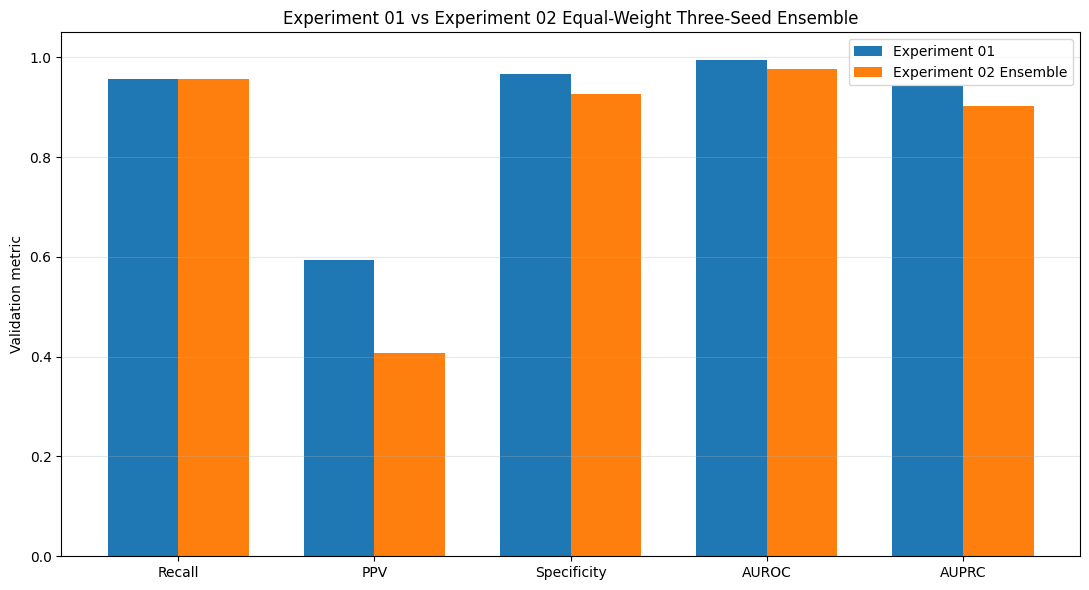

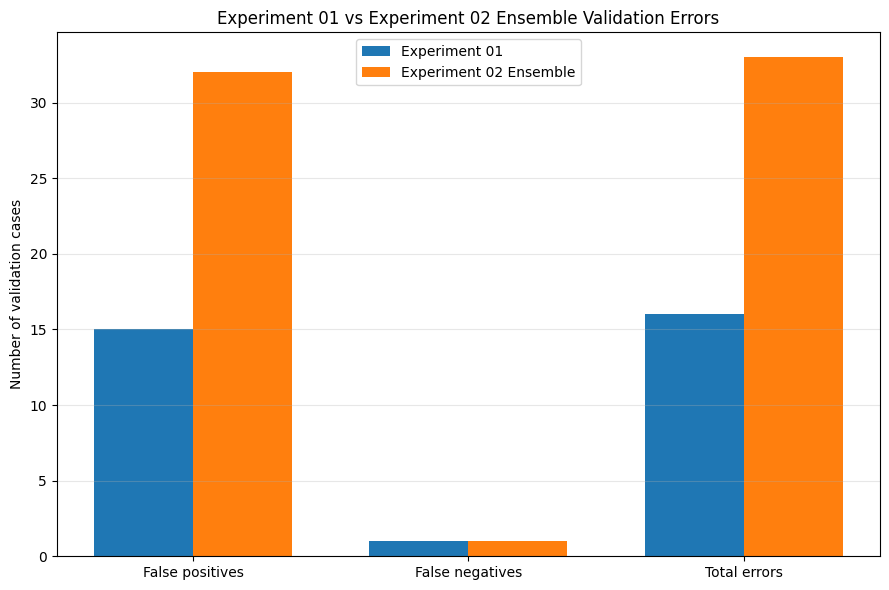

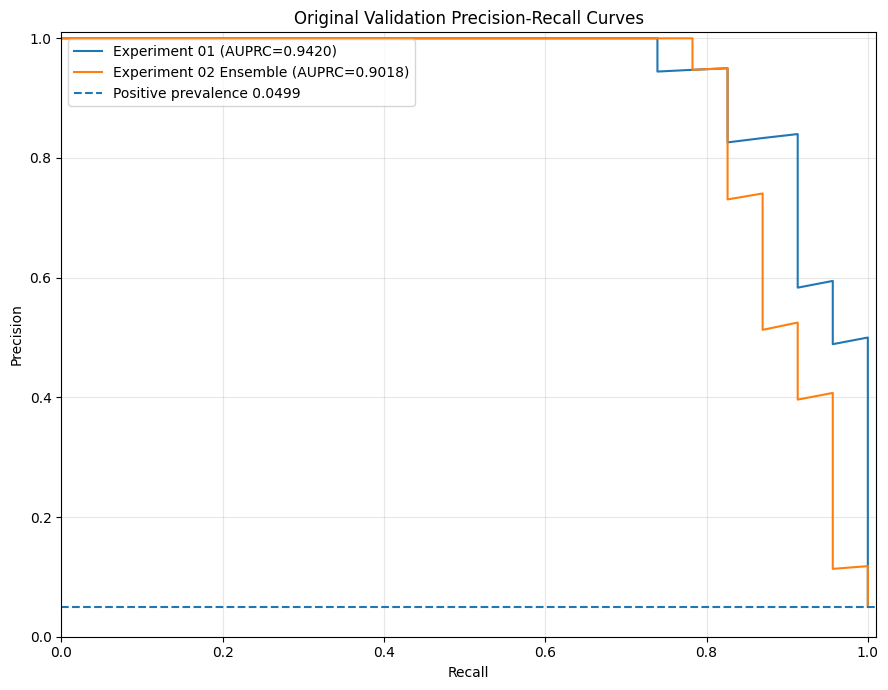

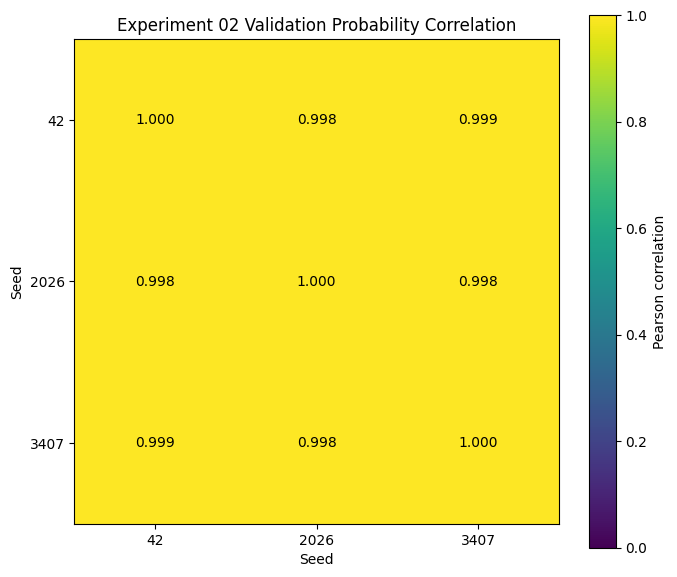

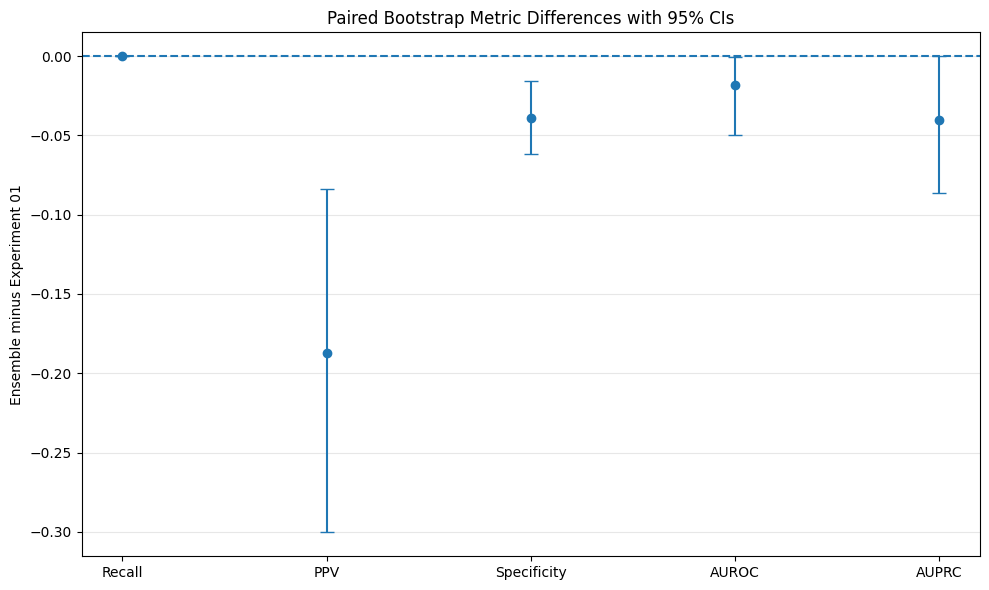


FINAL CELL 14D EQUAL-WEIGHT ENSEMBLE REPORT
Component seeds: [42, 2026, 3407]
Weight per seed: 0.333333
Matched validation cases: 461/461

Experiment 01:
Recall: 0.956522
PPV: 0.594595
Specificity: 0.965753
AUROC: 0.995235
AUPRC: 0.941969
TP=22 | TN=423 | FP=15 | FN=1

Experiment 02 Equal-Weight Ensemble:
Locked threshold: 0.000456956101
Recall: 0.956522
PPV: 0.407407
Specificity: 0.926941
AUROC: 0.977070
AUPRC: 0.901787
Minimum centre recall: 0.888889
TP=22 | TN=406 | FP=32 | FN=1

Ensemble minus Experiment 01:
AUPRC change: -0.040183
AUROC change: -0.018166
Recall change: +0.000000
PPV change: -0.187187
Specificity change: -0.038813
False-positive reduction: -17
False-negative reduction: +0
Total-error reduction: -17

Development-only decision:
EXP01_RETAINS_CURRENT_DEVELOPMENT_LEAD

Recommended action:
The equal-weight Experiment 02 ensemble does not match the locked Experiment 01 performance under the predeclared development criteria. Retain Experiment 01 as the current developmen

In [ ]:
# ==========================================================================================
# CELL 14D
# EXPERIMENT 02 — EQUAL-WEIGHT THREE-SEED VALIDATION ENSEMBLE
# AND PAIRED COMPARISON AGAINST EXPERIMENT 01
#
# Purpose:
# - Load saved validation probabilities from seeds 42, 2026 and 3407
# - Average the three probabilities using equal weights
# - Select one ensemble threshold using validation data only
# - Calculate overall and centre-wise metrics
# - Compare the ensemble case-by-case against Experiment 01
# - Perform paired bootstrap and exact McNemar analysis
# - Produce a development-only model decision
#
# IMPORTANT:
# - No training
# - No image inference
# - No best seed selection
# - Every seed receives equal weight: 1/3
# - Held-out local test is NOT loaded
# - Held-out local test is NOT evaluated
# ==========================================================================================

from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display

import json
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
)

warnings.filterwarnings("ignore")


# ==========================================================================================
# 1. FIXED CONFIGURATION
# ==========================================================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

EXPERIMENT_01_NAME = (
    "Experiment 01 GastroNet-5M DINOv1"
)

EXPERIMENT_02_ENSEMBLE_NAME = (
    "Experiment 02 SWSL + GastroNet-5M DINOv1 "
    "Equal-Weight Three-Seed Ensemble"
)

EXPERIMENT_02_ID = (
    "experiment_02_swsl_gastronet5m_dinov1"
)

ENSEMBLE_ID = (
    "experiment_02_equal_weight_three_seed_ensemble"
)

PREDECLARED_SEEDS = [
    42,
    2026,
    3407,
]

ENSEMBLE_WEIGHT_PER_SEED = (
    1.0 / len(PREDECLARED_SEEDS)
)

EXPECTED_VALIDATION_TOTAL = 461
EXPECTED_VALIDATION_NORMAL = 438
EXPECTED_VALIDATION_POSITIVE = 23

REQUIRED_OVERALL_RECALL = 0.90
REQUIRED_MINIMUM_CENTRE_RECALL = 0.80

BOOTSTRAP_ITERATIONS = 2000
BOOTSTRAP_RANDOM_SEED = 1402

FINAL_STATUS = (
    "CELL14D_EXP02_EQUAL_WEIGHT_ENSEMBLE_ANALYSIS_COMPLETE"
)


# ==========================================================================================
# 2. INPUT PATHS
# ==========================================================================================

CELL14C_STATUS_PATH = (
    PROJECT_ROOT
    / "results"
    / "stability"
    / "original_split"
    / EXPERIMENT_02_ID
    / "aggregate"
    / "cell14c_exp02_original_split_stability_status.json"
)

CELL14C_DECISION_PATH = (
    PROJECT_ROOT
    / "results"
    / "stability"
    / "original_split"
    / EXPERIMENT_02_ID
    / "aggregate"
    / "cell14c_exp02_original_split_stability_decision.json"
)

CELL14C_SEED_METRICS_PATH = (
    PROJECT_ROOT
    / "results"
    / "stability"
    / "original_split"
    / EXPERIMENT_02_ID
    / "aggregate"
    / "cell14c_exp02_original_split_seed_metrics.csv"
)

# Cell 14B already paired Experiment 01 with the locked validation manifest.
# It therefore provides a verified Experiment 01 SHA-256 identity table.
EXP01_PAIRED_REFERENCE_PATH = (
    PROJECT_ROOT
    / "predictions"
    / "original_split"
    / "controlled_comparisons"
    / "experiment_01_vs_experiment_02_original_validation"
    / "cell14b_exp01_vs_exp02_paired_validation_cases.csv"
)


SEED_PREDICTION_PATHS = {
    seed: (
        PROJECT_ROOT
        / "predictions"
        / "stability"
        / "original_split"
        / EXPERIMENT_02_ID
        / f"seed_{seed}"
        / (
            f"exp02_original_split_seed_{seed}_"
            "validation_predictions_locked_threshold.csv"
        )
    )
    for seed in PREDECLARED_SEEDS
}


# ==========================================================================================
# 3. OUTPUT DIRECTORIES
# ==========================================================================================

RESULT_DIR = (
    PROJECT_ROOT
    / "results"
    / "ensembles"
    / "original_split"
    / ENSEMBLE_ID
)

PREDICTION_DIR = (
    PROJECT_ROOT
    / "predictions"
    / "ensembles"
    / "original_split"
    / ENSEMBLE_ID
)

THRESHOLD_DIR = (
    PROJECT_ROOT
    / "thresholds"
    / "ensembles"
    / "original_split"
    / ENSEMBLE_ID
)

CENTRE_DIR = (
    PROJECT_ROOT
    / "centre_analysis"
    / "ensembles"
    / "original_split"
    / ENSEMBLE_ID
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "figures"
    / "ensembles"
    / "original_split"
    / ENSEMBLE_ID
)

ENSEMBLE_RECORD_DIR = (
    PROJECT_ROOT
    / "ensembles"
    / "original_split"
    / ENSEMBLE_ID
)


for directory in [
    RESULT_DIR,
    PREDICTION_DIR,
    THRESHOLD_DIR,
    CENTRE_DIR,
    FIGURE_DIR,
    ENSEMBLE_RECORD_DIR,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ==========================================================================================
# 4. OUTPUT FILE PATHS
# ==========================================================================================

MERGED_SEED_PREDICTIONS_PATH = (
    PREDICTION_DIR
    / "cell14d_three_seed_merged_validation_probabilities.csv"
)

ENSEMBLE_PREDICTIONS_PATH = (
    PREDICTION_DIR
    / "cell14d_equal_weight_ensemble_validation_predictions.csv"
)

PAIRED_COMPARISON_PATH = (
    PREDICTION_DIR
    / "cell14d_exp01_vs_exp02_ensemble_paired_validation_cases.csv"
)

THRESHOLD_SEARCH_PATH = (
    THRESHOLD_DIR
    / "cell14d_equal_weight_ensemble_threshold_search.csv"
)

THRESHOLD_LOCK_PATH = (
    THRESHOLD_DIR
    / "cell14d_equal_weight_ensemble_threshold_lock.json"
)

ENSEMBLE_METRICS_PATH = (
    RESULT_DIR
    / "cell14d_equal_weight_ensemble_validation_metrics.csv"
)

MODEL_COMPARISON_PATH = (
    RESULT_DIR
    / "cell14d_exp01_vs_exp02_ensemble_metric_comparison.csv"
)

CENTRE_METRICS_PATH = (
    CENTRE_DIR
    / "cell14d_equal_weight_ensemble_per_centre_metrics.csv"
)

CENTRE_COMPARISON_PATH = (
    CENTRE_DIR
    / "cell14d_exp01_vs_exp02_ensemble_per_centre_comparison.csv"
)

SEED_CORRELATION_PATH = (
    RESULT_DIR
    / "cell14d_seed_probability_correlation.csv"
)

ERROR_OVERLAP_PATH = (
    RESULT_DIR
    / "cell14d_exp01_vs_exp02_ensemble_error_overlap.csv"
)

EXP01_ERRORS_FIXED_PATH = (
    PREDICTION_DIR
    / "cell14d_exp01_errors_fixed_by_ensemble.csv"
)

NEW_ENSEMBLE_ERRORS_PATH = (
    PREDICTION_DIR
    / "cell14d_new_ensemble_errors.csv"
)

COMMON_ERRORS_PATH = (
    PREDICTION_DIR
    / "cell14d_common_exp01_ensemble_errors.csv"
)

MCNEMAR_PATH = (
    RESULT_DIR
    / "cell14d_exp01_vs_ensemble_exact_mcnemar.csv"
)

BOOTSTRAP_SAMPLES_PATH = (
    RESULT_DIR
    / "cell14d_exp01_vs_ensemble_paired_bootstrap_samples.csv"
)

BOOTSTRAP_SUMMARY_PATH = (
    RESULT_DIR
    / "cell14d_exp01_vs_ensemble_paired_bootstrap_summary.csv"
)

DECISION_PATH = (
    RESULT_DIR
    / "cell14d_development_model_decision.json"
)

STATUS_PATH = (
    RESULT_DIR
    / "cell14d_status.json"
)

SUMMARY_PATH = (
    RESULT_DIR
    / "cell14d_equal_weight_ensemble_summary.txt"
)

ENSEMBLE_MANIFEST_PATH = (
    ENSEMBLE_RECORD_DIR
    / "cell14d_equal_weight_ensemble_manifest.json"
)

METRIC_FIGURE_PATH = (
    FIGURE_DIR
    / "cell14d_exp01_vs_ensemble_metric_comparison.png"
)

ERROR_FIGURE_PATH = (
    FIGURE_DIR
    / "cell14d_exp01_vs_ensemble_error_comparison.png"
)

PR_CURVE_FIGURE_PATH = (
    FIGURE_DIR
    / "cell14d_exp01_vs_ensemble_precision_recall_curve.png"
)

SEED_CORRELATION_FIGURE_PATH = (
    FIGURE_DIR
    / "cell14d_seed_probability_correlation.png"
)

BOOTSTRAP_FIGURE_PATH = (
    FIGURE_DIR
    / "cell14d_exp01_vs_ensemble_bootstrap_ci.png"
)


# ==========================================================================================
# 5. INITIAL REPORT
# ==========================================================================================

print("=" * 108)

print(
    "CELL 14D: EXPERIMENT 02 EQUAL-WEIGHT THREE-SEED "
    "VALIDATION ENSEMBLE"
)

print("=" * 108)

print("\nPre-declared seeds:")
print(PREDECLARED_SEEDS)

print("\nWeight assigned to each seed:")
print(f"{ENSEMBLE_WEIGHT_PER_SEED:.6f}")

print("\nAggregation method:")
print(
    "Arithmetic mean of validation probabilities; "
    "no best seed selection."
)

print("\nHeld-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("Held-out test used for decision: False")
print("New model training performed: False")
print("New image inference performed: False")
print("Best seed selected: False")


# ==========================================================================================
# 6. VERIFY REQUIRED FILES AND CELL 14C STATUS
# ==========================================================================================

required_files = [
    CELL14C_STATUS_PATH,
    CELL14C_DECISION_PATH,
    CELL14C_SEED_METRICS_PATH,
    EXP01_PAIRED_REFERENCE_PATH,
    *SEED_PREDICTION_PATHS.values(),
]

missing_files = [
    path
    for path in required_files
    if not path.exists()
]


if missing_files:

    print("\nMissing required files:")

    for missing_path in missing_files:
        print(missing_path)

    raise FileNotFoundError(
        "Cell 14D cannot run because one or more required "
        "Cell 14B/14C output files are missing."
    )


cell14c_status_record = json.loads(
    CELL14C_STATUS_PATH.read_text(
        encoding="utf-8"
    )
)

cell14c_decision_record = json.loads(
    CELL14C_DECISION_PATH.read_text(
        encoding="utf-8"
    )
)


actual_cell14c_status = cell14c_status_record.get(
    "status"
)

actual_cell14c_decision = cell14c_decision_record.get(
    "stability_decision"
)


if actual_cell14c_status != (
    "EXP02_ORIGINAL_SPLIT_MULTI_SEED_STABILITY_COMPLETE"
):

    raise RuntimeError(
        "Cell 14C is not marked complete.\n"
        f"Actual status: {actual_cell14c_status}"
    )


if actual_cell14c_decision != (
    "EXP02_ORIGINAL_SPLIT_SEED_STABLE"
):

    raise RuntimeError(
        "Cell 14D equal-weight ensemble branch requires "
        "the Cell 14C seed-stable decision.\n"
        f"Actual decision: {actual_cell14c_decision}"
    )


print("\nCell 14C completion status verified:")
print(actual_cell14c_status)

print("\nCell 14C decision verified:")
print(actual_cell14c_decision)


# ==========================================================================================
# 7. GENERAL HELPERS
# ==========================================================================================

def find_column(
    dataframe,
    candidates,
    description,
    required=True,
):

    for candidate in candidates:

        if candidate in dataframe.columns:
            return candidate

    lowercase_map = {
        str(column).lower(): column
        for column in dataframe.columns
    }

    for candidate in candidates:

        if candidate.lower() in lowercase_map:

            return lowercase_map[
                candidate.lower()
            ]

    if required:

        raise KeyError(
            f"Could not find {description} column.\n"
            f"Available columns:\n"
            f"{list(dataframe.columns)}"
        )

    return None


def safe_divide(
    numerator,
    denominator,
):

    if denominator == 0:
        return 0.0

    return float(
        numerator / denominator
    )


def calculate_metrics(
    labels,
    probabilities,
    predictions,
):

    labels = np.asarray(
        labels,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    predictions = np.asarray(
        predictions,
        dtype=int,
    )


    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[
            0,
            1,
        ],
    ).ravel()


    recall = safe_divide(
        tp,
        tp + fn,
    )

    precision = safe_divide(
        tp,
        tp + fp,
    )

    specificity = safe_divide(
        tn,
        tn + fp,
    )

    npv = safe_divide(
        tn,
        tn + fn,
    )

    accuracy = safe_divide(
        tp + tn,
        len(labels),
    )

    balanced_accuracy = (
        recall + specificity
    ) / 2.0

    f1 = safe_divide(
        2.0 * precision * recall,
        precision + recall,
    )


    if len(
        np.unique(labels)
    ) == 2:

        auroc = float(
            roc_auc_score(
                labels,
                probabilities,
            )
        )

        auprc = float(
            average_precision_score(
                labels,
                probabilities,
            )
        )

    else:

        auroc = np.nan
        auprc = np.nan


    return {
        "sample_count": int(
            len(labels)
        ),

        "normal_count": int(
            (labels == 0).sum()
        ),

        "positive_count": int(
            (labels == 1).sum()
        ),

        "recall": float(
            recall
        ),

        "precision": float(
            precision
        ),

        "specificity": float(
            specificity
        ),

        "npv": float(
            npv
        ),

        "accuracy": float(
            accuracy
        ),

        "balanced_accuracy": float(
            balanced_accuracy
        ),

        "f1": float(
            f1
        ),

        "auroc": float(
            auroc
        ),

        "auprc": float(
            auprc
        ),

        "tp": int(
            tp
        ),

        "tn": int(
            tn
        ),

        "fp": int(
            fp
        ),

        "fn": int(
            fn
        ),

        "total_errors": int(
            fp + fn
        ),
    }


# ==========================================================================================
# 8. STANDARDIZE SAVED SEED PREDICTIONS
# ==========================================================================================

def standardize_seed_prediction_file(
    dataframe,
    seed,
):

    dataframe = dataframe.copy()


    sha_column = find_column(
        dataframe,
        [
            "sha256",
            "image_sha256",
            "file_sha256",
        ],
        f"seed {seed} SHA-256",
    )

    label_column = find_column(
        dataframe,
        [
            "label",
            "target",
            "ground_truth",
            "y_true",
        ],
        f"seed {seed} label",
    )

    center_column = find_column(
        dataframe,
        [
            "center",
            "centre",
            "site",
        ],
        f"seed {seed} centre",
    )

    probability_column = find_column(
        dataframe,
        [
            "probability",
            "neoplasia_probability",
            "positive_probability",
            "predicted_probability",
            "score",
        ],
        f"seed {seed} probability",
    )

    relative_path_column = find_column(
        dataframe,
        [
            "relative_path",
            "original_relative_path",
            "image_relative_path",
            "runtime_path",
        ],
        f"seed {seed} relative path",
        required=False,
    )

    locked_prediction_column = find_column(
        dataframe,
        [
            "locked_prediction",
            "prediction",
            "predicted_label",
        ],
        f"seed {seed} locked prediction",
        required=False,
    )

    locked_threshold_column = find_column(
        dataframe,
        [
            "locked_threshold",
            "selected_threshold",
            "threshold",
        ],
        f"seed {seed} locked threshold",
        required=False,
    )


    standardized = pd.DataFrame(
        {
            "case_sha256": (
                dataframe[
                    sha_column
                ]
                .astype(str)
                .str.strip()
                .str.lower()
            ),

            "label": pd.to_numeric(
                dataframe[
                    label_column
                ],
                errors="raise",
            ).astype(int),

            "center": (
                dataframe[
                    center_column
                ].astype(str)
            ),

            f"probability_seed_{seed}": pd.to_numeric(
                dataframe[
                    probability_column
                ],
                errors="raise",
            ).astype(float),
        }
    )


    if relative_path_column is not None:

        standardized[
            "relative_path"
        ] = dataframe[
            relative_path_column
        ].astype(str)

    else:

        standardized[
            "relative_path"
        ] = ""


    if len(
        standardized
    ) != EXPECTED_VALIDATION_TOTAL:

        raise RuntimeError(
            f"Seed {seed}: expected "
            f"{EXPECTED_VALIDATION_TOTAL} validation cases, "
            f"found {len(standardized)}."
        )


    if standardized[
        "case_sha256"
    ].duplicated().any():

        duplicate_count = int(
            standardized[
                "case_sha256"
            ].duplicated().sum()
        )

        raise RuntimeError(
            f"Seed {seed}: duplicate SHA-256 cases "
            f"detected: {duplicate_count}"
        )


    normal_count = int(
        (
            standardized[
                "label"
            ]
            == 0
        ).sum()
    )

    positive_count = int(
        (
            standardized[
                "label"
            ]
            == 1
        ).sum()
    )


    if normal_count != EXPECTED_VALIDATION_NORMAL:

        raise RuntimeError(
            f"Seed {seed}: expected "
            f"{EXPECTED_VALIDATION_NORMAL} normal cases, "
            f"found {normal_count}."
        )


    if positive_count != EXPECTED_VALIDATION_POSITIVE:

        raise RuntimeError(
            f"Seed {seed}: expected "
            f"{EXPECTED_VALIDATION_POSITIVE} positive cases, "
            f"found {positive_count}."
        )


    probability_values = standardized[
        f"probability_seed_{seed}"
    ].to_numpy(
        dtype=float
    )


    if not np.isfinite(
        probability_values
    ).all():

        raise RuntimeError(
            f"Seed {seed}: non-finite probability values detected."
        )


    if (
        probability_values.min() < 0.0
        or probability_values.max() > 1.0
    ):

        raise RuntimeError(
            f"Seed {seed}: probabilities outside [0, 1]."
        )


    if (
        locked_prediction_column is not None
        and locked_threshold_column is not None
    ):

        threshold_values = pd.to_numeric(
            dataframe[
                locked_threshold_column
            ],
            errors="coerce",
        ).dropna().unique()


        if len(
            threshold_values
        ) == 1:

            stored_predictions = pd.to_numeric(
                dataframe[
                    locked_prediction_column
                ],
                errors="raise",
            ).astype(int).to_numpy()

            reconstructed_predictions = (
                probability_values
                >= float(
                    threshold_values[0]
                )
            ).astype(int)

            disagreement_count = int(
                (
                    stored_predictions
                    != reconstructed_predictions
                ).sum()
            )

            if disagreement_count != 0:

                raise RuntimeError(
                    f"Seed {seed}: saved locked predictions "
                    f"contain {disagreement_count} threshold "
                    "reconstruction disagreements."
                )


    return standardized


# ==========================================================================================
# 9. LOAD ALL THREE SEED FILES
# ==========================================================================================

seed_frames = {}


for seed in PREDECLARED_SEEDS:

    raw_seed_df = pd.read_csv(
        SEED_PREDICTION_PATHS[
            seed
        ],
        low_memory=False,
    )

    seed_frames[
        seed
    ] = standardize_seed_prediction_file(
        raw_seed_df,
        seed,
    )


print("\nSaved seed validation files verified:")

for seed in PREDECLARED_SEEDS:

    print(
        f"Seed {seed}: "
        f"{len(seed_frames[seed])} cases"
    )


# ==========================================================================================
# 10. MERGE SEEDS BY SHA-256
# ==========================================================================================

base_seed = PREDECLARED_SEEDS[0]

merged_seed_df = seed_frames[
    base_seed
].copy()


for seed in PREDECLARED_SEEDS[1:]:

    incoming_df = seed_frames[
        seed
    ].copy()

    incoming_df = incoming_df.rename(
        columns={
            "label": (
                f"label_seed_{seed}"
            ),

            "center": (
                f"center_seed_{seed}"
            ),

            "relative_path": (
                f"relative_path_seed_{seed}"
            ),
        }
    )


    merged_seed_df = merged_seed_df.merge(
        incoming_df,
        on="case_sha256",
        how="inner",
        validate="one_to_one",
    )


if len(
    merged_seed_df
) != EXPECTED_VALIDATION_TOTAL:

    raise RuntimeError(
        "The three seed prediction files were not matched "
        "on all validation cases.\n"
        f"Matched: {len(merged_seed_df)}"
    )


for seed in PREDECLARED_SEEDS[1:]:

    label_mismatch_count = int(
        (
            merged_seed_df[
                "label"
            ]
            != merged_seed_df[
                f"label_seed_{seed}"
            ]
        ).sum()
    )

    center_mismatch_count = int(
        (
            merged_seed_df[
                "center"
            ]
            != merged_seed_df[
                f"center_seed_{seed}"
            ]
        ).sum()
    )


    if label_mismatch_count != 0:

        raise RuntimeError(
            f"Seed {seed}: label mismatches after SHA merge: "
            f"{label_mismatch_count}"
        )


    if center_mismatch_count != 0:

        raise RuntimeError(
            f"Seed {seed}: centre mismatches after SHA merge: "
            f"{center_mismatch_count}"
        )


drop_columns = []

for seed in PREDECLARED_SEEDS[1:]:

    drop_columns.extend(
        [
            f"label_seed_{seed}",
            f"center_seed_{seed}",
            f"relative_path_seed_{seed}",
        ]
    )


merged_seed_df = merged_seed_df.drop(
    columns=[
        column
        for column in drop_columns
        if column in merged_seed_df.columns
    ]
)


probability_columns = [
    f"probability_seed_{seed}"
    for seed in PREDECLARED_SEEDS
]


merged_seed_df[
    "ensemble_probability"
] = merged_seed_df[
    probability_columns
].mean(
    axis=1
)


merged_seed_df[
    "seed_probability_standard_deviation"
] = merged_seed_df[
    probability_columns
].std(
    axis=1,
    ddof=0,
)


merged_seed_df[
    "seed_probability_minimum"
] = merged_seed_df[
    probability_columns
].min(
    axis=1
)


merged_seed_df[
    "seed_probability_maximum"
] = merged_seed_df[
    probability_columns
].max(
    axis=1
)


merged_seed_df.to_csv(
    MERGED_SEED_PREDICTIONS_PATH,
    index=False,
)


print("\nThree-seed merge verification:")

print(
    f"Matched cases: "
    f"{len(merged_seed_df)}/"
    f"{EXPECTED_VALIDATION_TOTAL}"
)

print(
    f"Mean ensemble probability: "
    f"{merged_seed_df['ensemble_probability'].mean():.8f}"
)

print(
    f"Mean per-case seed probability SD: "
    f"{merged_seed_df['seed_probability_standard_deviation'].mean():.8f}"
)


# ==========================================================================================
# 11. SEED PROBABILITY CORRELATION
# ==========================================================================================

seed_correlation_df = merged_seed_df[
    probability_columns
].corr(
    method="pearson"
)

seed_correlation_df.to_csv(
    SEED_CORRELATION_PATH
)


print("\nSeed probability correlation:")

display(
    seed_correlation_df
)


# ==========================================================================================
# 12. VALIDATION-ONLY ENSEMBLE THRESHOLD SEARCH
# ==========================================================================================

def search_validation_threshold(
    prediction_dataframe,
):

    labels = prediction_dataframe[
        "label"
    ].to_numpy(
        dtype=int
    )

    probabilities = prediction_dataframe[
        "ensemble_probability"
    ].to_numpy(
        dtype=float
    )

    centers = prediction_dataframe[
        "center"
    ].astype(str).to_numpy()


    candidate_thresholds = np.unique(
        np.concatenate(
            [
                np.array(
                    [
                        0.0,
                        1.0,
                    ],
                    dtype=float,
                ),

                probabilities,
            ]
        )
    )


    threshold_rows = []


    for threshold in candidate_thresholds:

        predictions = (
            probabilities
            >= threshold
        ).astype(int)


        overall_metrics = calculate_metrics(
            labels,
            probabilities,
            predictions,
        )


        centre_recall_values = {}


        for center_value in sorted(
            np.unique(
                centers
            )
        ):

            center_mask = (
                centers
                == center_value
            )

            center_metrics = calculate_metrics(
                labels[
                    center_mask
                ],

                probabilities[
                    center_mask
                ],

                predictions[
                    center_mask
                ],
            )

            centre_recall_values[
                center_value
            ] = center_metrics[
                "recall"
            ]


        minimum_centre_recall = float(
            min(
                centre_recall_values.values()
            )
        )


        threshold_rows.append(
            {
                "threshold": float(
                    threshold
                ),

                "recall": overall_metrics[
                    "recall"
                ],

                "precision": overall_metrics[
                    "precision"
                ],

                "specificity": overall_metrics[
                    "specificity"
                ],

                "npv": overall_metrics[
                    "npv"
                ],

                "accuracy": overall_metrics[
                    "accuracy"
                ],

                "balanced_accuracy": overall_metrics[
                    "balanced_accuracy"
                ],

                "f1": overall_metrics[
                    "f1"
                ],

                "tp": overall_metrics[
                    "tp"
                ],

                "tn": overall_metrics[
                    "tn"
                ],

                "fp": overall_metrics[
                    "fp"
                ],

                "fn": overall_metrics[
                    "fn"
                ],

                "total_errors": overall_metrics[
                    "total_errors"
                ],

                "minimum_centre_recall": (
                    minimum_centre_recall
                ),

                **{
                    f"{center_value}_recall": (
                        centre_recall_values[
                            center_value
                        ]
                    )
                    for center_value
                    in centre_recall_values
                },
            }
        )


    threshold_search_df = pd.DataFrame(
        threshold_rows
    )


    strict_eligible_df = threshold_search_df[
        (
            threshold_search_df[
                "recall"
            ]
            >= REQUIRED_OVERALL_RECALL
        )
        &
        (
            threshold_search_df[
                "minimum_centre_recall"
            ]
            >= REQUIRED_MINIMUM_CENTRE_RECALL
        )
    ].copy()


    if len(
        strict_eligible_df
    ) > 0:

        eligible_df = strict_eligible_df

        selection_mode = (
            "overall_recall_0.90_and_"
            "minimum_centre_recall_0.80"
        )

    else:

        overall_eligible_df = threshold_search_df[
            threshold_search_df[
                "recall"
            ]
            >= REQUIRED_OVERALL_RECALL
        ].copy()


        if len(
            overall_eligible_df
        ) > 0:

            eligible_df = overall_eligible_df

            selection_mode = (
                "fallback_overall_recall_0.90"
            )

        else:

            eligible_df = threshold_search_df.copy()

            selection_mode = (
                "fallback_highest_recall"
            )


    # Same threshold-selection principle as Cell 14C:
    # among recall-compliant thresholds, maximize PPV,
    # then minimum centre recall, specificity and threshold.
    selected_row = (
        eligible_df.sort_values(
            by=[
                "precision",
                "minimum_centre_recall",
                "specificity",
                "threshold",
            ],
            ascending=[
                False,
                False,
                False,
                False,
            ],
        )
        .iloc[
            0
        ]
        .copy()
    )


    return (
        threshold_search_df,
        selected_row,
        selection_mode,
        len(
            strict_eligible_df
        ),
    )


(
    threshold_search_df,
    selected_threshold_row,
    threshold_selection_mode,
    strict_eligible_threshold_count,
) = search_validation_threshold(
    merged_seed_df
)


ensemble_threshold = float(
    selected_threshold_row[
        "threshold"
    ]
)


threshold_search_df.to_csv(
    THRESHOLD_SEARCH_PATH,
    index=False,
)


print("\nValidation-only ensemble threshold selected:")

print(
    f"Threshold: "
    f"{ensemble_threshold:.12f}"
)

print(
    f"Selection mode: "
    f"{threshold_selection_mode}"
)

print(
    f"Strict eligible thresholds: "
    f"{strict_eligible_threshold_count}"
)


# ==========================================================================================
# 13. LOCK ENSEMBLE PREDICTIONS
# ==========================================================================================

ensemble_df = merged_seed_df.copy()

ensemble_df[
    "ensemble_locked_threshold"
] = ensemble_threshold

ensemble_df[
    "ensemble_prediction"
] = (
    ensemble_df[
        "ensemble_probability"
    ].to_numpy(
        dtype=float
    )
    >= ensemble_threshold
).astype(int)


ensemble_df[
    "ensemble_correct"
] = (
    ensemble_df[
        "ensemble_prediction"
    ]
    == ensemble_df[
        "label"
    ]
)


ensemble_df[
    "ensemble_error_type"
] = np.select(
    [
        (
            (
                ensemble_df[
                    "label"
                ]
                == 0
            )
            &
            (
                ensemble_df[
                    "ensemble_prediction"
                ]
                == 1
            )
        ),

        (
            (
                ensemble_df[
                    "label"
                ]
                == 1
            )
            &
            (
                ensemble_df[
                    "ensemble_prediction"
                ]
                == 0
            )
        ),
    ],
    [
        "FP",
        "FN",
    ],
    default="correct",
)


ensemble_df.to_csv(
    ENSEMBLE_PREDICTIONS_PATH,
    index=False,
)


ensemble_metrics = calculate_metrics(
    ensemble_df[
        "label"
    ].to_numpy(
        dtype=int
    ),

    ensemble_df[
        "ensemble_probability"
    ].to_numpy(
        dtype=float
    ),

    ensemble_df[
        "ensemble_prediction"
    ].to_numpy(
        dtype=int
    ),
)


# ==========================================================================================
# 14. ENSEMBLE PER-CENTRE METRICS
# ==========================================================================================

ensemble_centre_rows = []


for center_value in sorted(
    ensemble_df[
        "center"
    ].unique()
):

    center_subset = ensemble_df[
        ensemble_df[
            "center"
        ]
        == center_value
    ].copy()


    center_metrics = calculate_metrics(
        center_subset[
            "label"
        ].to_numpy(
            dtype=int
        ),

        center_subset[
            "ensemble_probability"
        ].to_numpy(
            dtype=float
        ),

        center_subset[
            "ensemble_prediction"
        ].to_numpy(
            dtype=int
        ),
    )


    ensemble_centre_rows.append(
        {
            "center": center_value,

            "model": (
                "experiment_02_equal_weight_ensemble"
            ),

            "threshold": ensemble_threshold,

            **center_metrics,
        }
    )


ensemble_centre_df = pd.DataFrame(
    ensemble_centre_rows
)

ensemble_centre_df.to_csv(
    CENTRE_METRICS_PATH,
    index=False,
)


minimum_ensemble_centre_recall = float(
    ensemble_centre_df[
        "recall"
    ].min()
)


ensemble_metrics_record = {
    "model": (
        "experiment_02_equal_weight_three_seed_ensemble"
    ),

    "seeds": (
        ",".join(
            str(seed)
            for seed in PREDECLARED_SEEDS
        )
    ),

    "weight_per_seed": (
        ENSEMBLE_WEIGHT_PER_SEED
    ),

    "threshold": (
        ensemble_threshold
    ),

    "threshold_selection_mode": (
        threshold_selection_mode
    ),

    "minimum_centre_recall": (
        minimum_ensemble_centre_recall
    ),

    **ensemble_metrics,

    "best_seed_selected": False,

    "held_out_test_loaded": False,

    "held_out_test_evaluated": False,
}


pd.DataFrame(
    [
        ensemble_metrics_record
    ]
).to_csv(
    ENSEMBLE_METRICS_PATH,
    index=False,
)


print("\nEqual-weight ensemble validation metrics:")

display(
    pd.DataFrame(
        [
            ensemble_metrics_record
        ]
    )
)

print("\nEqual-weight ensemble per-centre metrics:")

display(
    ensemble_centre_df
)


# ==========================================================================================
# 15. SAVE THRESHOLD LOCK AND ENSEMBLE MANIFEST
# ==========================================================================================

threshold_lock_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "ensemble_id": ENSEMBLE_ID,

    "ensemble_name": (
        EXPERIMENT_02_ENSEMBLE_NAME
    ),

    "predeclared_seeds": (
        PREDECLARED_SEEDS
    ),

    "weight_per_seed": (
        ENSEMBLE_WEIGHT_PER_SEED
    ),

    "aggregation_method": (
        "equal_weight_arithmetic_mean_of_probabilities"
    ),

    "selected_validation_threshold": (
        ensemble_threshold
    ),

    "threshold_selection_mode": (
        threshold_selection_mode
    ),

    "required_overall_recall": (
        REQUIRED_OVERALL_RECALL
    ),

    "required_minimum_centre_recall": (
        REQUIRED_MINIMUM_CENTRE_RECALL
    ),

    "validation_recall": (
        ensemble_metrics[
            "recall"
        ]
    ),

    "validation_precision": (
        ensemble_metrics[
            "precision"
        ]
    ),

    "validation_specificity": (
        ensemble_metrics[
            "specificity"
        ]
    ),

    "validation_auroc": (
        ensemble_metrics[
            "auroc"
        ]
    ),

    "validation_auprc": (
        ensemble_metrics[
            "auprc"
        ]
    ),

    "minimum_centre_recall": (
        minimum_ensemble_centre_recall
    ),

    "best_seed_selected": False,

    "threshold_selected_from_test": False,

    "held_out_test_loaded": False,

    "held_out_test_evaluated": False,
}


THRESHOLD_LOCK_PATH.write_text(
    json.dumps(
        threshold_lock_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


ensemble_manifest_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "ensemble_id": ENSEMBLE_ID,

    "component_experiment": (
        EXPERIMENT_02_ID
    ),

    "component_seeds": (
        PREDECLARED_SEEDS
    ),

    "component_weights": {
        str(seed): (
            ENSEMBLE_WEIGHT_PER_SEED
        )
        for seed in PREDECLARED_SEEDS
    },

    "aggregation": (
        "probability_level_equal_weight_average"
    ),

    "locked_validation_threshold": (
        ensemble_threshold
    ),

    "component_prediction_files": {
        str(seed): str(
            SEED_PREDICTION_PATHS[
                seed
            ]
        )
        for seed in PREDECLARED_SEEDS
    },

    "best_seed_selected": False,

    "held_out_test_loaded": False,

    "held_out_test_evaluated": False,
}


ENSEMBLE_MANIFEST_PATH.write_text(
    json.dumps(
        ensemble_manifest_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ==========================================================================================
# 16. LOAD VERIFIED EXPERIMENT 01 REFERENCE
# ==========================================================================================

exp01_reference_raw_df = pd.read_csv(
    EXP01_PAIRED_REFERENCE_PATH,
    low_memory=False,
)


exp01_sha_column = find_column(
    exp01_reference_raw_df,
    [
        "case_sha256",
        "sha256",
    ],
    "Experiment 01 case SHA-256",
)

exp01_label_column = find_column(
    exp01_reference_raw_df,
    [
        "label",
        "label_exp01",
    ],
    "Experiment 01 label",
)

exp01_center_column = find_column(
    exp01_reference_raw_df,
    [
        "center",
        "center_exp01",
        "centre",
    ],
    "Experiment 01 centre",
)

exp01_probability_column = find_column(
    exp01_reference_raw_df,
    [
        "probability_exp01",
        "experiment_01_probability",
        "probability",
    ],
    "Experiment 01 probability",
)

exp01_prediction_column = find_column(
    exp01_reference_raw_df,
    [
        "prediction_exp01",
        "experiment_01_prediction",
        "prediction",
    ],
    "Experiment 01 locked prediction",
)

exp01_relative_path_column = find_column(
    exp01_reference_raw_df,
    [
        "relative_path",
        "relative_path_exp01",
    ],
    "Experiment 01 relative path",
    required=False,
)


exp01_df = pd.DataFrame(
    {
        "case_sha256": (
            exp01_reference_raw_df[
                exp01_sha_column
            ]
            .astype(str)
            .str.strip()
            .str.lower()
        ),

        "label_exp01": pd.to_numeric(
            exp01_reference_raw_df[
                exp01_label_column
            ],
            errors="raise",
        ).astype(int),

        "center_exp01": (
            exp01_reference_raw_df[
                exp01_center_column
            ].astype(str)
        ),

        "probability_exp01": pd.to_numeric(
            exp01_reference_raw_df[
                exp01_probability_column
            ],
            errors="raise",
        ).astype(float),

        "prediction_exp01": pd.to_numeric(
            exp01_reference_raw_df[
                exp01_prediction_column
            ],
            errors="raise",
        ).astype(int),
    }
)


if exp01_relative_path_column is not None:

    exp01_df[
        "relative_path_exp01"
    ] = exp01_reference_raw_df[
        exp01_relative_path_column
    ].astype(str)

else:

    exp01_df[
        "relative_path_exp01"
    ] = ""


if len(
    exp01_df
) != EXPECTED_VALIDATION_TOTAL:

    raise RuntimeError(
        "Experiment 01 reference does not contain "
        f"{EXPECTED_VALIDATION_TOTAL} cases."
    )


if exp01_df[
    "case_sha256"
].duplicated().any():

    raise RuntimeError(
        "Duplicate SHA-256 cases found in the "
        "Experiment 01 reference."
    )


# ==========================================================================================
# 17. PAIR EXPERIMENT 01 WITH THE ENSEMBLE
# ==========================================================================================

ensemble_pair_df = ensemble_df[
    [
        "case_sha256",
        "relative_path",
        "label",
        "center",
        *probability_columns,
        "ensemble_probability",
        "seed_probability_standard_deviation",
        "ensemble_locked_threshold",
        "ensemble_prediction",
        "ensemble_correct",
        "ensemble_error_type",
    ]
].copy()


paired_df = exp01_df.merge(
    ensemble_pair_df,
    on="case_sha256",
    how="inner",
    validate="one_to_one",
)


if len(
    paired_df
) != EXPECTED_VALIDATION_TOTAL:

    raise RuntimeError(
        "Experiment 01 and the ensemble were not paired "
        "on all validation cases.\n"
        f"Matched: {len(paired_df)}"
    )


label_mismatch_count = int(
    (
        paired_df[
            "label_exp01"
        ]
        != paired_df[
            "label"
        ]
    ).sum()
)

center_mismatch_count = int(
    (
        paired_df[
            "center_exp01"
        ]
        != paired_df[
            "center"
        ]
    ).sum()
)


if label_mismatch_count != 0:

    raise RuntimeError(
        f"Label mismatches after pairing: "
        f"{label_mismatch_count}"
    )


if center_mismatch_count != 0:

    raise RuntimeError(
        f"Centre mismatches after pairing: "
        f"{center_mismatch_count}"
    )


paired_df[
    "exp01_correct"
] = (
    paired_df[
        "prediction_exp01"
    ]
    == paired_df[
        "label"
    ]
)


paired_df[
    "exp01_error_type"
] = np.select(
    [
        (
            (
                paired_df[
                    "label"
                ]
                == 0
            )
            &
            (
                paired_df[
                    "prediction_exp01"
                ]
                == 1
            )
        ),

        (
            (
                paired_df[
                    "label"
                ]
                == 1
            )
            &
            (
                paired_df[
                    "prediction_exp01"
                ]
                == 0
            )
        ),
    ],
    [
        "FP",
        "FN",
    ],
    default="correct",
)


paired_df[
    "exp01_wrong_ensemble_correct"
] = (
    (
        ~paired_df[
            "exp01_correct"
        ]
    )
    &
    paired_df[
        "ensemble_correct"
    ]
)


paired_df[
    "exp01_correct_ensemble_wrong"
] = (
    paired_df[
        "exp01_correct"
    ]
    &
    (
        ~paired_df[
            "ensemble_correct"
        ]
    )
)


paired_df[
    "common_error"
] = (
    (
        ~paired_df[
            "exp01_correct"
        ]
    )
    &
    (
        ~paired_df[
            "ensemble_correct"
        ]
    )
)


paired_df.to_csv(
    PAIRED_COMPARISON_PATH,
    index=False,
)


print("\nExperiment 01 vs ensemble pairing:")

print(
    f"Matched cases: "
    f"{len(paired_df)}/"
    f"{EXPECTED_VALIDATION_TOTAL}"
)

print(
    f"Label mismatches: "
    f"{label_mismatch_count}"
)

print(
    f"Centre mismatches: "
    f"{center_mismatch_count}"
)


# ==========================================================================================
# 18. EXPERIMENT 01 METRICS AND SAFETY VERIFICATION
# ==========================================================================================

comparison_labels = paired_df[
    "label"
].to_numpy(
    dtype=int
)


exp01_metrics = calculate_metrics(
    comparison_labels,

    paired_df[
        "probability_exp01"
    ].to_numpy(
        dtype=float
    ),

    paired_df[
        "prediction_exp01"
    ].to_numpy(
        dtype=int
    ),
)


paired_ensemble_metrics = calculate_metrics(
    comparison_labels,

    paired_df[
        "ensemble_probability"
    ].to_numpy(
        dtype=float
    ),

    paired_df[
        "ensemble_prediction"
    ].to_numpy(
        dtype=int
    ),
)


# Confirm that the locked Experiment 01 reference has not changed.
expected_exp01_confusion = {
    "tp": 22,
    "tn": 423,
    "fp": 15,
    "fn": 1,
}


for metric_name, expected_value in (
    expected_exp01_confusion.items()
):

    actual_value = exp01_metrics[
        metric_name
    ]

    if actual_value != expected_value:

        raise RuntimeError(
            "Experiment 01 reference safety check failed.\n"
            f"{metric_name}: expected {expected_value}, "
            f"found {actual_value}"
        )


print("\nExperiment 01 locked reference verified:")

print(
    f"TP={exp01_metrics['tp']} | "
    f"TN={exp01_metrics['tn']} | "
    f"FP={exp01_metrics['fp']} | "
    f"FN={exp01_metrics['fn']}"
)


# ==========================================================================================
# 19. OVERALL METRIC COMPARISON
# ==========================================================================================

comparison_metric_names = [
    "recall",
    "precision",
    "specificity",
    "npv",
    "accuracy",
    "balanced_accuracy",
    "f1",
    "auroc",
    "auprc",
    "tp",
    "tn",
    "fp",
    "fn",
    "total_errors",
]


comparison_rows = []


for metric_name in comparison_metric_names:

    exp01_value = float(
        exp01_metrics[
            metric_name
        ]
    )

    ensemble_value = float(
        paired_ensemble_metrics[
            metric_name
        ]
    )


    if metric_name in [
        "fp",
        "fn",
        "total_errors",
    ]:

        favourable_ensemble_change = (
            exp01_value
            - ensemble_value
        )

    else:

        favourable_ensemble_change = (
            ensemble_value
            - exp01_value
        )


    comparison_rows.append(
        {
            "metric": metric_name,

            "experiment_01": (
                exp01_value
            ),

            "experiment_02_equal_weight_ensemble": (
                ensemble_value
            ),

            "ensemble_minus_experiment_01": (
                ensemble_value
                - exp01_value
            ),

            "positive_value_favours_ensemble": (
                favourable_ensemble_change
            ),
        }
    )


model_comparison_df = pd.DataFrame(
    comparison_rows
)

model_comparison_df.to_csv(
    MODEL_COMPARISON_PATH,
    index=False,
)


print("\nExperiment 01 vs equal-weight ensemble:")

display(
    model_comparison_df
)


# ==========================================================================================
# 20. PAIRED PER-CENTRE COMPARISON
# ==========================================================================================

centre_comparison_rows = []


for center_value in sorted(
    paired_df[
        "center"
    ].unique()
):

    center_subset = paired_df[
        paired_df[
            "center"
        ]
        == center_value
    ].copy()


    center_labels = center_subset[
        "label"
    ].to_numpy(
        dtype=int
    )


    center_exp01_metrics = calculate_metrics(
        center_labels,

        center_subset[
            "probability_exp01"
        ].to_numpy(
            dtype=float
        ),

        center_subset[
            "prediction_exp01"
        ].to_numpy(
            dtype=int
        ),
    )


    center_ensemble_metrics = calculate_metrics(
        center_labels,

        center_subset[
            "ensemble_probability"
        ].to_numpy(
            dtype=float
        ),

        center_subset[
            "ensemble_prediction"
        ].to_numpy(
            dtype=int
        ),
    )


    centre_comparison_rows.append(
        {
            "center": center_value,

            "model": (
                "experiment_01"
            ),

            **center_exp01_metrics,
        }
    )


    centre_comparison_rows.append(
        {
            "center": center_value,

            "model": (
                "experiment_02_equal_weight_ensemble"
            ),

            **center_ensemble_metrics,
        }
    )


centre_comparison_df = pd.DataFrame(
    centre_comparison_rows
)

centre_comparison_df.to_csv(
    CENTRE_COMPARISON_PATH,
    index=False,
)


print("\nPaired per-centre comparison:")

display(
    centre_comparison_df
)


# ==========================================================================================
# 21. ERROR OVERLAP
# ==========================================================================================

exp01_error_mask = (
    ~paired_df[
        "exp01_correct"
    ]
)

ensemble_error_mask = (
    ~paired_df[
        "ensemble_correct"
    ]
)

exp01_fixed_mask = (
    exp01_error_mask
    &
    paired_df[
        "ensemble_correct"
    ]
)

new_ensemble_error_mask = (
    paired_df[
        "exp01_correct"
    ]
    &
    ensemble_error_mask
)

common_error_mask = (
    exp01_error_mask
    &
    ensemble_error_mask
)


error_overlap_df = pd.DataFrame(
    [
        {
            "measure": (
                "experiment_01_total_errors"
            ),

            "count": int(
                exp01_error_mask.sum()
            ),
        },

        {
            "measure": (
                "ensemble_total_errors"
            ),

            "count": int(
                ensemble_error_mask.sum()
            ),
        },

        {
            "measure": (
                "common_errors"
            ),

            "count": int(
                common_error_mask.sum()
            ),
        },

        {
            "measure": (
                "experiment_01_errors_fixed_by_ensemble"
            ),

            "count": int(
                exp01_fixed_mask.sum()
            ),
        },

        {
            "measure": (
                "new_ensemble_errors"
            ),

            "count": int(
                new_ensemble_error_mask.sum()
            ),
        },

        {
            "measure": (
                "false_positive_reduction"
            ),

            "count": int(
                exp01_metrics[
                    "fp"
                ]
                - paired_ensemble_metrics[
                    "fp"
                ]
            ),
        },

        {
            "measure": (
                "false_negative_reduction"
            ),

            "count": int(
                exp01_metrics[
                    "fn"
                ]
                - paired_ensemble_metrics[
                    "fn"
                ]
            ),
        },

        {
            "measure": (
                "total_error_reduction"
            ),

            "count": int(
                exp01_metrics[
                    "total_errors"
                ]
                - paired_ensemble_metrics[
                    "total_errors"
                ]
            ),
        },
    ]
)


error_overlap_df.to_csv(
    ERROR_OVERLAP_PATH,
    index=False,
)


paired_df.loc[
    exp01_fixed_mask
].to_csv(
    EXP01_ERRORS_FIXED_PATH,
    index=False,
)

paired_df.loc[
    new_ensemble_error_mask
].to_csv(
    NEW_ENSEMBLE_ERRORS_PATH,
    index=False,
)

paired_df.loc[
    common_error_mask
].to_csv(
    COMMON_ERRORS_PATH,
    index=False,
)


print("\nError-overlap analysis:")

display(
    error_overlap_df
)


# ==========================================================================================
# 22. EXACT MCNEMAR TEST
# ==========================================================================================

exp01_wrong_ensemble_correct = int(
    exp01_fixed_mask.sum()
)

exp01_correct_ensemble_wrong = int(
    new_ensemble_error_mask.sum()
)

discordant_total = int(
    exp01_wrong_ensemble_correct
    + exp01_correct_ensemble_wrong
)


def exact_two_sided_binomial_p_value(
    successes,
    trials,
):

    if trials == 0:
        return 1.0


    smaller_side = min(
        successes,
        trials - successes,
    )


    lower_tail_probability = sum(
        math.comb(
            trials,
            value,
        )
        for value in range(
            smaller_side + 1
        )
    ) / (
        2 ** trials
    )


    return float(
        min(
            1.0,
            2.0
            * lower_tail_probability,
        )
    )


mcnemar_p_value = (
    exact_two_sided_binomial_p_value(
        exp01_wrong_ensemble_correct,
        discordant_total,
    )
)


mcnemar_df = pd.DataFrame(
    [
        {
            "exp01_wrong_ensemble_correct": (
                exp01_wrong_ensemble_correct
            ),

            "exp01_correct_ensemble_wrong": (
                exp01_correct_ensemble_wrong
            ),

            "discordant_total": (
                discordant_total
            ),

            "exact_two_sided_p_value": (
                mcnemar_p_value
            ),

            "interpretation": (
                "paired_error_difference_detected"
                if mcnemar_p_value < 0.05
                else "no_clear_paired_error_difference"
            ),

            "important_note": (
                "This is a development-validation comparison. "
                "The ensemble threshold was selected using the "
                "same validation set, so the result is descriptive "
                "rather than independent test confirmation."
            ),
        }
    ]
)

mcnemar_df.to_csv(
    MCNEMAR_PATH,
    index=False,
)


print("\nExact McNemar paired-error analysis:")

display(
    mcnemar_df
)


# ==========================================================================================
# 23. PAIRED CENTRE/CLASS-STRATIFIED BOOTSTRAP
# ==========================================================================================

bootstrap_rng = np.random.default_rng(
    BOOTSTRAP_RANDOM_SEED
)


stratum_indices = []


for (
    center_value,
    label_value
), stratum_df in paired_df.groupby(
    [
        "center",
        "label",
    ],
    sort=True,
):

    stratum_indices.append(
        stratum_df.index.to_numpy(
            dtype=int
        )
    )


bootstrap_rows = []


print(
    f"\nRunning paired centre/class-stratified bootstrap: "
    f"{BOOTSTRAP_ITERATIONS} iterations..."
)


for iteration in range(
    1,
    BOOTSTRAP_ITERATIONS + 1,
):

    sampled_indices = np.concatenate(
        [
            bootstrap_rng.choice(
                indices,
                size=len(indices),
                replace=True,
            )
            for indices in stratum_indices
        ]
    )


    sampled_labels = paired_df.loc[
        sampled_indices,
        "label",
    ].to_numpy(
        dtype=int
    )


    sampled_exp01_metrics = calculate_metrics(
        sampled_labels,

        paired_df.loc[
            sampled_indices,
            "probability_exp01",
        ].to_numpy(
            dtype=float
        ),

        paired_df.loc[
            sampled_indices,
            "prediction_exp01",
        ].to_numpy(
            dtype=int
        ),
    )


    sampled_ensemble_metrics = calculate_metrics(
        sampled_labels,

        paired_df.loc[
            sampled_indices,
            "ensemble_probability",
        ].to_numpy(
            dtype=float
        ),

        paired_df.loc[
            sampled_indices,
            "ensemble_prediction",
        ].to_numpy(
            dtype=int
        ),
    )


    bootstrap_rows.append(
        {
            "iteration": int(
                iteration
            ),

            "recall_gain": (
                sampled_ensemble_metrics[
                    "recall"
                ]
                - sampled_exp01_metrics[
                    "recall"
                ]
            ),

            "ppv_gain": (
                sampled_ensemble_metrics[
                    "precision"
                ]
                - sampled_exp01_metrics[
                    "precision"
                ]
            ),

            "specificity_gain": (
                sampled_ensemble_metrics[
                    "specificity"
                ]
                - sampled_exp01_metrics[
                    "specificity"
                ]
            ),

            "balanced_accuracy_gain": (
                sampled_ensemble_metrics[
                    "balanced_accuracy"
                ]
                - sampled_exp01_metrics[
                    "balanced_accuracy"
                ]
            ),

            "f1_gain": (
                sampled_ensemble_metrics[
                    "f1"
                ]
                - sampled_exp01_metrics[
                    "f1"
                ]
            ),

            "auroc_gain": (
                sampled_ensemble_metrics[
                    "auroc"
                ]
                - sampled_exp01_metrics[
                    "auroc"
                ]
            ),

            "auprc_gain": (
                sampled_ensemble_metrics[
                    "auprc"
                ]
                - sampled_exp01_metrics[
                    "auprc"
                ]
            ),

            "fp_reduction": (
                sampled_exp01_metrics[
                    "fp"
                ]
                - sampled_ensemble_metrics[
                    "fp"
                ]
            ),

            "fn_reduction": (
                sampled_exp01_metrics[
                    "fn"
                ]
                - sampled_ensemble_metrics[
                    "fn"
                ]
            ),

            "total_error_reduction": (
                sampled_exp01_metrics[
                    "total_errors"
                ]
                - sampled_ensemble_metrics[
                    "total_errors"
                ]
            ),
        }
    )


bootstrap_df = pd.DataFrame(
    bootstrap_rows
)

bootstrap_df.to_csv(
    BOOTSTRAP_SAMPLES_PATH,
    index=False,
)


observed_changes = {
    "recall_gain": (
        paired_ensemble_metrics[
            "recall"
        ]
        - exp01_metrics[
            "recall"
        ]
    ),

    "ppv_gain": (
        paired_ensemble_metrics[
            "precision"
        ]
        - exp01_metrics[
            "precision"
        ]
    ),

    "specificity_gain": (
        paired_ensemble_metrics[
            "specificity"
        ]
        - exp01_metrics[
            "specificity"
        ]
    ),

    "balanced_accuracy_gain": (
        paired_ensemble_metrics[
            "balanced_accuracy"
        ]
        - exp01_metrics[
            "balanced_accuracy"
        ]
    ),

    "f1_gain": (
        paired_ensemble_metrics[
            "f1"
        ]
        - exp01_metrics[
            "f1"
        ]
    ),

    "auroc_gain": (
        paired_ensemble_metrics[
            "auroc"
        ]
        - exp01_metrics[
            "auroc"
        ]
    ),

    "auprc_gain": (
        paired_ensemble_metrics[
            "auprc"
        ]
        - exp01_metrics[
            "auprc"
        ]
    ),

    "fp_reduction": (
        exp01_metrics[
            "fp"
        ]
        - paired_ensemble_metrics[
            "fp"
        ]
    ),

    "fn_reduction": (
        exp01_metrics[
            "fn"
        ]
        - paired_ensemble_metrics[
            "fn"
        ]
    ),

    "total_error_reduction": (
        exp01_metrics[
            "total_errors"
        ]
        - paired_ensemble_metrics[
            "total_errors"
        ]
    ),
}


bootstrap_summary_rows = []


for measure_name, observed_value in (
    observed_changes.items()
):

    bootstrap_values = bootstrap_df[
        measure_name
    ].to_numpy(
        dtype=float
    )


    lower_ci = float(
        np.percentile(
            bootstrap_values,
            2.5,
        )
    )

    upper_ci = float(
        np.percentile(
            bootstrap_values,
            97.5,
        )
    )


    if lower_ci > 0:

        interpretation = (
            "CI_above_zero"
        )

    elif upper_ci < 0:

        interpretation = (
            "CI_below_zero"
        )

    else:

        interpretation = (
            "CI_includes_zero"
        )


    bootstrap_summary_rows.append(
        {
            "measure": (
                measure_name
            ),

            "observed_change": float(
                observed_value
            ),

            "bootstrap_mean": float(
                bootstrap_values.mean()
            ),

            "bootstrap_median": float(
                np.median(
                    bootstrap_values
                )
            ),

            "ci_2_5_percent": (
                lower_ci
            ),

            "ci_97_5_percent": (
                upper_ci
            ),

            "proportion_above_zero": float(
                np.mean(
                    bootstrap_values > 0
                )
            ),

            "proportion_at_or_above_zero": float(
                np.mean(
                    bootstrap_values >= 0
                )
            ),

            "interpretation": (
                interpretation
            ),
        }
    )


bootstrap_summary_df = pd.DataFrame(
    bootstrap_summary_rows
)

bootstrap_summary_df.to_csv(
    BOOTSTRAP_SUMMARY_PATH,
    index=False,
)


print("\nPaired bootstrap confidence intervals:")

display(
    bootstrap_summary_df
)


# ==========================================================================================
# 24. DEVELOPMENT-ONLY DECISION
# ==========================================================================================

def bootstrap_ci_value(
    measure_name,
    column_name,
):

    matching_rows = bootstrap_summary_df[
        bootstrap_summary_df[
            "measure"
        ]
        == measure_name
    ]

    if len(
        matching_rows
    ) != 1:

        raise RuntimeError(
            f"Bootstrap measure not found: "
            f"{measure_name}"
        )

    return float(
        matching_rows.iloc[
            0
        ][
            column_name
        ]
    )


recall_change = float(
    observed_changes[
        "recall_gain"
    ]
)

ppv_change = float(
    observed_changes[
        "ppv_gain"
    ]
)

specificity_change = float(
    observed_changes[
        "specificity_gain"
    ]
)

auroc_change = float(
    observed_changes[
        "auroc_gain"
    ]
)

auprc_change = float(
    observed_changes[
        "auprc_gain"
    ]
)

fp_reduction = int(
    observed_changes[
        "fp_reduction"
    ]
)

fn_reduction = int(
    observed_changes[
        "fn_reduction"
    ]
)

total_error_reduction = int(
    observed_changes[
        "total_error_reduction"
    ]
)


auprc_ci_lower = bootstrap_ci_value(
    "auprc_gain",
    "ci_2_5_percent",
)

ppv_ci_lower = bootstrap_ci_value(
    "ppv_gain",
    "ci_2_5_percent",
)

specificity_ci_lower = bootstrap_ci_value(
    "specificity_gain",
    "ci_2_5_percent",
)

total_error_ci_lower = bootstrap_ci_value(
    "total_error_reduction",
    "ci_2_5_percent",
)


ensemble_safety_compliant = bool(
    (
        paired_ensemble_metrics[
            "recall"
        ]
        >= REQUIRED_OVERALL_RECALL
    )
    and
    (
        minimum_ensemble_centre_recall
        >= REQUIRED_MINIMUM_CENTRE_RECALL
    )
)


no_material_degradation = bool(
    (
        recall_change
        >= -0.02
    )
    and
    (
        auprc_change
        >= -0.01
    )
    and
    (
        auroc_change
        >= -0.01
    )
    and
    (
        ppv_change
        >= -0.05
    )
    and
    (
        specificity_change
        >= -0.03
    )
)


clear_paired_improvement = bool(
    (
        auprc_ci_lower > 0
    )
    or
    (
        (
            ppv_ci_lower > 0
        )
        and
        (
            specificity_ci_lower >= 0
        )
    )
    or
    (
        total_error_ci_lower > 0
    )
)


if (
    ensemble_safety_compliant
    and no_material_degradation
    and clear_paired_improvement
):

    development_decision = (
        "EXP02_ENSEMBLE_ADVANCES_AS_CURRENT_DEVELOPMENT_LEAD"
    )

    recommended_action = (
        "The equal-weight Experiment 02 ensemble showed a "
        "clear paired validation improvement without a "
        "material safety or ranking degradation. Retain it "
        "as the current development lead while screening the "
        "remaining pretrained ResNet-50 checkpoints. Do not "
        "open the held-out test for model selection."
    )

elif (
    ensemble_safety_compliant
    and no_material_degradation
):

    development_decision = (
        "EXP02_ENSEMBLE_COMPARABLE_BUT_NO_CLEAR_GAIN"
    )

    recommended_action = (
        "The equal-weight Experiment 02 ensemble is broadly "
        "comparable to Experiment 01 but does not provide a "
        "clear paired validation improvement. Experiment 01 "
        "remains the simpler current lead. Continue with the "
        "predeclared screening of the remaining ResNet-50 "
        "checkpoints without using the held-out test."
    )

else:

    development_decision = (
        "EXP01_RETAINS_CURRENT_DEVELOPMENT_LEAD"
    )

    recommended_action = (
        "The equal-weight Experiment 02 ensemble does not "
        "match the locked Experiment 01 performance under "
        "the predeclared development criteria. Retain "
        "Experiment 01 as the current development lead. "
        "Preserve Experiment 02 as a stable comparison model "
        "and continue with controlled screening of the "
        "remaining ResNet-50 checkpoints. Do not evaluate "
        "Experiment 02 on the held-out test."
    )


decision_reason = (
    f"Experiment 02 ensemble minus Experiment 01: "
    f"AUPRC {auprc_change:+.6f}, "
    f"AUROC {auroc_change:+.6f}, "
    f"recall {recall_change:+.6f}, "
    f"PPV {ppv_change:+.6f}, "
    f"specificity {specificity_change:+.6f}, "
    f"FP reduction {fp_reduction:+d}, "
    f"FN reduction {fn_reduction:+d}, "
    f"total-error reduction {total_error_reduction:+d}. "
    f"Ensemble validation recall="
    f"{paired_ensemble_metrics['recall']:.6f}; "
    f"minimum centre recall="
    f"{minimum_ensemble_centre_recall:.6f}."
)


decision_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "decision": (
        development_decision
    ),

    "recommended_action": (
        recommended_action
    ),

    "reason": (
        decision_reason
    ),

    "experiment_01_metrics": (
        exp01_metrics
    ),

    "experiment_02_equal_weight_ensemble_metrics": (
        paired_ensemble_metrics
    ),

    "experiment_02_ensemble_threshold": (
        ensemble_threshold
    ),

    "minimum_ensemble_centre_recall": (
        minimum_ensemble_centre_recall
    ),

    "ensemble_minus_experiment_01": {
        "recall": (
            recall_change
        ),

        "precision": (
            ppv_change
        ),

        "specificity": (
            specificity_change
        ),

        "auroc": (
            auroc_change
        ),

        "auprc": (
            auprc_change
        ),
    },

    "false_positive_reduction": (
        fp_reduction
    ),

    "false_negative_reduction": (
        fn_reduction
    ),

    "total_error_reduction": (
        total_error_reduction
    ),

    "ensemble_safety_compliant": (
        ensemble_safety_compliant
    ),

    "no_material_degradation": (
        no_material_degradation
    ),

    "clear_paired_improvement": (
        clear_paired_improvement
    ),

    "predeclared_decision_criteria": {
        "required_ensemble_recall": (
            REQUIRED_OVERALL_RECALL
        ),

        "required_minimum_centre_recall": (
            REQUIRED_MINIMUM_CENTRE_RECALL
        ),

        "maximum_allowed_recall_drop": (
            0.02
        ),

        "maximum_allowed_auprc_drop": (
            0.01
        ),

        "maximum_allowed_auroc_drop": (
            0.01
        ),

        "maximum_allowed_ppv_drop": (
            0.05
        ),

        "maximum_allowed_specificity_drop": (
            0.03
        ),

        "clear_improvement_rule": (
            "AUPRC 95% CI above zero, or both PPV and "
            "specificity non-negative with PPV CI above "
            "zero, or total-error-reduction CI above zero."
        ),
    },

    "component_seeds": (
        PREDECLARED_SEEDS
    ),

    "component_weight_per_seed": (
        ENSEMBLE_WEIGHT_PER_SEED
    ),

    "best_seed_selected": False,

    "held_out_test_csv_loaded": False,

    "held_out_test_predictions_loaded": False,

    "held_out_test_evaluated": False,

    "held_out_test_used_for_decision": False,

    "new_training_performed": False,

    "new_image_inference_performed": False,
}


DECISION_PATH.write_text(
    json.dumps(
        decision_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ==========================================================================================
# 25. FIGURE — MODEL METRIC COMPARISON
# ==========================================================================================

metric_labels = [
    "Recall",
    "PPV",
    "Specificity",
    "AUROC",
    "AUPRC",
]

exp01_plot_values = [
    exp01_metrics[
        "recall"
    ],

    exp01_metrics[
        "precision"
    ],

    exp01_metrics[
        "specificity"
    ],

    exp01_metrics[
        "auroc"
    ],

    exp01_metrics[
        "auprc"
    ],
]

ensemble_plot_values = [
    paired_ensemble_metrics[
        "recall"
    ],

    paired_ensemble_metrics[
        "precision"
    ],

    paired_ensemble_metrics[
        "specificity"
    ],

    paired_ensemble_metrics[
        "auroc"
    ],

    paired_ensemble_metrics[
        "auprc"
    ],
]


x_positions = np.arange(
    len(metric_labels)
)

bar_width = 0.36


metric_figure = plt.figure(
    figsize=(
        11,
        6,
    )
)

plt.bar(
    x_positions
    - bar_width / 2,
    exp01_plot_values,
    width=bar_width,
    label="Experiment 01",
)

plt.bar(
    x_positions
    + bar_width / 2,
    ensemble_plot_values,
    width=bar_width,
    label="Experiment 02 Ensemble",
)

plt.xticks(
    x_positions,
    metric_labels,
)

plt.ylim(
    0.0,
    1.05,
)

plt.ylabel(
    "Validation metric"
)

plt.title(
    "Experiment 01 vs Experiment 02 "
    "Equal-Weight Three-Seed Ensemble"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.legend()

plt.tight_layout()

metric_figure.savefig(
    METRIC_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

plt.close(
    metric_figure
)


# ==========================================================================================
# 26. FIGURE — ERROR COUNT COMPARISON
# ==========================================================================================

error_labels = [
    "False positives",
    "False negatives",
    "Total errors",
]

exp01_error_values = [
    exp01_metrics[
        "fp"
    ],

    exp01_metrics[
        "fn"
    ],

    exp01_metrics[
        "total_errors"
    ],
]

ensemble_error_values = [
    paired_ensemble_metrics[
        "fp"
    ],

    paired_ensemble_metrics[
        "fn"
    ],

    paired_ensemble_metrics[
        "total_errors"
    ],
]


x_positions = np.arange(
    len(error_labels)
)


error_figure = plt.figure(
    figsize=(
        9,
        6,
    )
)

plt.bar(
    x_positions
    - bar_width / 2,
    exp01_error_values,
    width=bar_width,
    label="Experiment 01",
)

plt.bar(
    x_positions
    + bar_width / 2,
    ensemble_error_values,
    width=bar_width,
    label="Experiment 02 Ensemble",
)

plt.xticks(
    x_positions,
    error_labels,
)

plt.ylabel(
    "Number of validation cases"
)

plt.title(
    "Experiment 01 vs Experiment 02 Ensemble "
    "Validation Errors"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.legend()

plt.tight_layout()

error_figure.savefig(
    ERROR_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

plt.close(
    error_figure
)


# ==========================================================================================
# 27. FIGURE — PRECISION-RECALL CURVES
# ==========================================================================================

exp01_precision_curve, exp01_recall_curve, _ = (
    precision_recall_curve(
        comparison_labels,
        paired_df[
            "probability_exp01"
        ].to_numpy(
            dtype=float
        ),
    )
)

ensemble_precision_curve, ensemble_recall_curve, _ = (
    precision_recall_curve(
        comparison_labels,
        paired_df[
            "ensemble_probability"
        ].to_numpy(
            dtype=float
        ),
    )
)


positive_prevalence = float(
    comparison_labels.mean()
)


pr_figure = plt.figure(
    figsize=(
        9,
        7,
    )
)

plt.plot(
    exp01_recall_curve,
    exp01_precision_curve,
    label=(
        "Experiment 01 "
        f"(AUPRC={exp01_metrics['auprc']:.4f})"
    ),
)

plt.plot(
    ensemble_recall_curve,
    ensemble_precision_curve,
    label=(
        "Experiment 02 Ensemble "
        f"(AUPRC={paired_ensemble_metrics['auprc']:.4f})"
    ),
)

plt.axhline(
    positive_prevalence,
    linestyle="--",
    label=(
        f"Positive prevalence "
        f"{positive_prevalence:.4f}"
    ),
)

plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "Original Validation Precision-Recall Curves"
)

plt.xlim(
    0.0,
    1.01,
)

plt.ylim(
    0.0,
    1.01,
)

plt.grid(
    alpha=0.3,
)

plt.legend()

plt.tight_layout()

pr_figure.savefig(
    PR_CURVE_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

plt.close(
    pr_figure
)


# ==========================================================================================
# 28. FIGURE — SEED CORRELATION
# ==========================================================================================

correlation_matrix = seed_correlation_df.to_numpy(
    dtype=float
)


correlation_figure = plt.figure(
    figsize=(
        7,
        6,
    )
)

correlation_image = plt.imshow(
    correlation_matrix,
    vmin=0.0,
    vmax=1.0,
)

plt.colorbar(
    correlation_image,
    label="Pearson correlation",
)

plt.xticks(
    np.arange(
        len(probability_columns)
    ),
    [
        str(seed)
        for seed in PREDECLARED_SEEDS
    ],
)

plt.yticks(
    np.arange(
        len(probability_columns)
    ),
    [
        str(seed)
        for seed in PREDECLARED_SEEDS
    ],
)

plt.xlabel(
    "Seed"
)

plt.ylabel(
    "Seed"
)

plt.title(
    "Experiment 02 Validation Probability Correlation"
)


for row_index in range(
    correlation_matrix.shape[0]
):

    for column_index in range(
        correlation_matrix.shape[1]
    ):

        plt.text(
            column_index,
            row_index,
            f"{correlation_matrix[row_index, column_index]:.3f}",
            ha="center",
            va="center",
        )


plt.tight_layout()

correlation_figure.savefig(
    SEED_CORRELATION_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

plt.close(
    correlation_figure
)


# ==========================================================================================
# 29. FIGURE — BOOTSTRAP CONFIDENCE INTERVALS
# ==========================================================================================

bootstrap_plot_measures = [
    "recall_gain",
    "ppv_gain",
    "specificity_gain",
    "auroc_gain",
    "auprc_gain",
]


bootstrap_plot_df = (
    bootstrap_summary_df[
        bootstrap_summary_df[
            "measure"
        ].isin(
            bootstrap_plot_measures
        )
    ]
    .set_index(
        "measure"
    )
    .loc[
        bootstrap_plot_measures
    ]
    .reset_index()
)


plot_values = bootstrap_plot_df[
    "observed_change"
].to_numpy(
    dtype=float
)

lower_errors = (
    plot_values
    - bootstrap_plot_df[
        "ci_2_5_percent"
    ].to_numpy(
        dtype=float
    )
)

upper_errors = (
    bootstrap_plot_df[
        "ci_97_5_percent"
    ].to_numpy(
        dtype=float
    )
    - plot_values
)


bootstrap_figure = plt.figure(
    figsize=(
        10,
        6,
    )
)

plt.errorbar(
    np.arange(
        len(
            bootstrap_plot_df
        )
    ),
    plot_values,
    yerr=[
        lower_errors,
        upper_errors,
    ],
    fmt="o",
    capsize=5,
)

plt.axhline(
    0.0,
    linestyle="--",
)

plt.xticks(
    np.arange(
        len(
            bootstrap_plot_df
        )
    ),
    [
        "Recall",
        "PPV",
        "Specificity",
        "AUROC",
        "AUPRC",
    ],
)

plt.ylabel(
    "Ensemble minus Experiment 01"
)

plt.title(
    "Paired Bootstrap Metric Differences with 95% CIs"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.tight_layout()

bootstrap_figure.savefig(
    BOOTSTRAP_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

plt.close(
    bootstrap_figure
)


# ==========================================================================================
# 30. SAVE STATUS AND TEXT SUMMARY
# ==========================================================================================

status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": (
        FINAL_STATUS
    ),

    "cell14c_status_verified": (
        actual_cell14c_status
    ),

    "cell14c_decision_verified": (
        actual_cell14c_decision
    ),

    "component_seeds": (
        PREDECLARED_SEEDS
    ),

    "component_weight_per_seed": (
        ENSEMBLE_WEIGHT_PER_SEED
    ),

    "matched_validation_cases": int(
        len(paired_df)
    ),

    "ensemble_threshold": (
        ensemble_threshold
    ),

    "development_decision": (
        development_decision
    ),

    "best_seed_selected": False,

    "held_out_test_csv_loaded": False,

    "held_out_test_predictions_loaded": False,

    "held_out_test_evaluated": False,

    "held_out_test_used_for_decision": False,

    "new_training_performed": False,

    "new_image_inference_performed": False,
}


STATUS_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


summary_lines = [
    (
        "CELL 14D — Experiment 02 Equal-Weight "
        "Three-Seed Ensemble"
    ),

    "=" * 100,

    "",

    (
        f"Component seeds: "
        f"{PREDECLARED_SEEDS}"
    ),

    (
        f"Weight per seed: "
        f"{ENSEMBLE_WEIGHT_PER_SEED:.6f}"
    ),

    (
        "Aggregation: arithmetic mean of validation "
        "probabilities"
    ),

    (
        f"Matched validation cases: "
        f"{len(paired_df)}/"
        f"{EXPECTED_VALIDATION_TOTAL}"
    ),

    "",

    "Experiment 01:",

    (
        f"Recall: "
        f"{exp01_metrics['recall']:.6f}"
    ),

    (
        f"PPV: "
        f"{exp01_metrics['precision']:.6f}"
    ),

    (
        f"Specificity: "
        f"{exp01_metrics['specificity']:.6f}"
    ),

    (
        f"AUROC: "
        f"{exp01_metrics['auroc']:.6f}"
    ),

    (
        f"AUPRC: "
        f"{exp01_metrics['auprc']:.6f}"
    ),

    (
        f"TP/TN/FP/FN: "
        f"{exp01_metrics['tp']}/"
        f"{exp01_metrics['tn']}/"
        f"{exp01_metrics['fp']}/"
        f"{exp01_metrics['fn']}"
    ),

    "",

    "Experiment 02 Equal-Weight Ensemble:",

    (
        f"Locked validation threshold: "
        f"{ensemble_threshold:.12f}"
    ),

    (
        f"Recall: "
        f"{paired_ensemble_metrics['recall']:.6f}"
    ),

    (
        f"PPV: "
        f"{paired_ensemble_metrics['precision']:.6f}"
    ),

    (
        f"Specificity: "
        f"{paired_ensemble_metrics['specificity']:.6f}"
    ),

    (
        f"AUROC: "
        f"{paired_ensemble_metrics['auroc']:.6f}"
    ),

    (
        f"AUPRC: "
        f"{paired_ensemble_metrics['auprc']:.6f}"
    ),

    (
        f"Minimum centre recall: "
        f"{minimum_ensemble_centre_recall:.6f}"
    ),

    (
        f"TP/TN/FP/FN: "
        f"{paired_ensemble_metrics['tp']}/"
        f"{paired_ensemble_metrics['tn']}/"
        f"{paired_ensemble_metrics['fp']}/"
        f"{paired_ensemble_metrics['fn']}"
    ),

    "",

    "Ensemble minus Experiment 01:",

    (
        f"AUPRC change: "
        f"{auprc_change:+.6f}"
    ),

    (
        f"AUROC change: "
        f"{auroc_change:+.6f}"
    ),

    (
        f"Recall change: "
        f"{recall_change:+.6f}"
    ),

    (
        f"PPV change: "
        f"{ppv_change:+.6f}"
    ),

    (
        f"Specificity change: "
        f"{specificity_change:+.6f}"
    ),

    (
        f"False-positive reduction: "
        f"{fp_reduction:+d}"
    ),

    (
        f"False-negative reduction: "
        f"{fn_reduction:+d}"
    ),

    (
        f"Total-error reduction: "
        f"{total_error_reduction:+d}"
    ),

    "",

    (
        f"Development-only decision: "
        f"{development_decision}"
    ),

    (
        f"Recommended action: "
        f"{recommended_action}"
    ),

    "",

    "Best seed selected: False",
    "Held-out test CSV loaded: False",
    "Held-out test predictions loaded: False",
    "Held-out test evaluated: False",
    "Held-out test used for decision: False",
    "New training performed: False",
    "New image inference performed: False",

    "",

    (
        f"STATUS: "
        f"{FINAL_STATUS}"
    ),
]


SUMMARY_PATH.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ==========================================================================================
# 31. FINAL REPORT
# ==========================================================================================

print("\n" + "=" * 108)

print(
    "FINAL CELL 14D EQUAL-WEIGHT ENSEMBLE REPORT"
)

print("=" * 108)

print(
    f"Component seeds: "
    f"{PREDECLARED_SEEDS}"
)

print(
    f"Weight per seed: "
    f"{ENSEMBLE_WEIGHT_PER_SEED:.6f}"
)

print(
    f"Matched validation cases: "
    f"{len(paired_df)}/"
    f"{EXPECTED_VALIDATION_TOTAL}"
)


print("\nExperiment 01:")

print(
    f"Recall: "
    f"{exp01_metrics['recall']:.6f}"
)

print(
    f"PPV: "
    f"{exp01_metrics['precision']:.6f}"
)

print(
    f"Specificity: "
    f"{exp01_metrics['specificity']:.6f}"
)

print(
    f"AUROC: "
    f"{exp01_metrics['auroc']:.6f}"
)

print(
    f"AUPRC: "
    f"{exp01_metrics['auprc']:.6f}"
)

print(
    f"TP={exp01_metrics['tp']} | "
    f"TN={exp01_metrics['tn']} | "
    f"FP={exp01_metrics['fp']} | "
    f"FN={exp01_metrics['fn']}"
)


print("\nExperiment 02 Equal-Weight Ensemble:")

print(
    f"Locked threshold: "
    f"{ensemble_threshold:.12f}"
)

print(
    f"Recall: "
    f"{paired_ensemble_metrics['recall']:.6f}"
)

print(
    f"PPV: "
    f"{paired_ensemble_metrics['precision']:.6f}"
)

print(
    f"Specificity: "
    f"{paired_ensemble_metrics['specificity']:.6f}"
)

print(
    f"AUROC: "
    f"{paired_ensemble_metrics['auroc']:.6f}"
)

print(
    f"AUPRC: "
    f"{paired_ensemble_metrics['auprc']:.6f}"
)

print(
    f"Minimum centre recall: "
    f"{minimum_ensemble_centre_recall:.6f}"
)

print(
    f"TP={paired_ensemble_metrics['tp']} | "
    f"TN={paired_ensemble_metrics['tn']} | "
    f"FP={paired_ensemble_metrics['fp']} | "
    f"FN={paired_ensemble_metrics['fn']}"
)


print("\nEnsemble minus Experiment 01:")

print(
    f"AUPRC change: "
    f"{auprc_change:+.6f}"
)

print(
    f"AUROC change: "
    f"{auroc_change:+.6f}"
)

print(
    f"Recall change: "
    f"{recall_change:+.6f}"
)

print(
    f"PPV change: "
    f"{ppv_change:+.6f}"
)

print(
    f"Specificity change: "
    f"{specificity_change:+.6f}"
)

print(
    f"False-positive reduction: "
    f"{fp_reduction:+d}"
)

print(
    f"False-negative reduction: "
    f"{fn_reduction:+d}"
)

print(
    f"Total-error reduction: "
    f"{total_error_reduction:+d}"
)


print("\nDevelopment-only decision:")

print(
    development_decision
)

print("\nRecommended action:")

print(
    recommended_action
)


print("\nBest seed selected: False")
print("Held-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("Held-out test used for decision: False")
print("New training performed: False")
print("New image inference performed: False")

print(
    f"\nSTATUS: "
    f"{FINAL_STATUS}"
)


print("\nSaved records:")

for saved_path in [
    MERGED_SEED_PREDICTIONS_PATH,
    ENSEMBLE_PREDICTIONS_PATH,
    PAIRED_COMPARISON_PATH,
    THRESHOLD_SEARCH_PATH,
    THRESHOLD_LOCK_PATH,
    ENSEMBLE_METRICS_PATH,
    MODEL_COMPARISON_PATH,
    CENTRE_METRICS_PATH,
    CENTRE_COMPARISON_PATH,
    SEED_CORRELATION_PATH,
    ERROR_OVERLAP_PATH,
    EXP01_ERRORS_FIXED_PATH,
    NEW_ENSEMBLE_ERRORS_PATH,
    COMMON_ERRORS_PATH,
    MCNEMAR_PATH,
    BOOTSTRAP_SAMPLES_PATH,
    BOOTSTRAP_SUMMARY_PATH,
    DECISION_PATH,
    STATUS_PATH,
    SUMMARY_PATH,
    ENSEMBLE_MANIFEST_PATH,
    METRIC_FIGURE_PATH,
    ERROR_FIGURE_PATH,
    PR_CURVE_FIGURE_PATH,
    SEED_CORRELATION_FIGURE_PATH,
    BOOTSTRAP_FIGURE_PATH,
]:

    print(
        saved_path
    )

CELL 15B: REMAINING RESNET-50 GASTRONET CONTROLLED ORIGINAL-SPLIT SCREENING

Fixed screening seed:
42

Training split:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/train_runtime_verified.csv

Validation split:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/validation_runtime_verified.csv

Held-out test CSV loaded: False
Held-out test predictions loaded: False
Held-out test evaluated: False
Held-out test used for any decision: False
Best seed selection allowed: False
Checkpoint screening seed selection allowed: False

Cell 14D decision verified:
EXP01_RETAINS_CURRENT_DEVELOPMENT_LEAD

Compute device:
cuda
Tesla T4

Locked original split verified:
Train: 2159 (normal=2050, NEO=109)
Validation: 461 (normal=438, NEO=23)
Train/validation overlap: 0
Missing training images: 0
Missing validation images: 0

Experiment 01 reference verified:
AUPRC=0.941969 | AUROC=0.995235 | Recall=0.956522 | PPV=0.594595 | Specificity=0.965753

Discovered scree

,candidate_id,display_name,match_count,matched_paths
0,rn50_gastronet1m_dinov1,RN50 GastroNet-1M DINO,1,/content/drive/MyDrive/RARE26_GastroNet_Weight...
1,rn50_gastronet200k_dinov1,RN50 GastroNet-200K DINO,1,/content/drive/MyDrive/RARE26_GastroNet_Weight...
2,rn50_gastronet5m_mocov2,RN50 GastroNet-5M MOCOv2,1,/content/drive/MyDrive/RARE26_GastroNet_Weight...
3,rn50_gastronet5m_simclrv2,RN50 GastroNet-5M SIMCLRv2,1,/content/drive/MyDrive/RARE26_GastroNet_Weight...



Checking compatibility: RN50 GastroNet-1M DINO

Checking compatibility: RN50 GastroNet-200K DINO

Checking compatibility: RN50 GastroNet-5M MOCOv2

Checking compatibility: RN50 GastroNet-5M SIMCLRv2

Checkpoint compatibility audit:


,candidate_id,display_name,checkpoint_path,compatibility_status,matched_backbone_tensors,expected_backbone_tensors,missing_parameters,unexpected_parameters,compatibility_error
0,rn50_gastronet1m_dinov1,RN50 GastroNet-1M DINO,/content/drive/MyDrive/RARE26_GastroNet_Weight...,COMPATIBLE,318,318,"['fc.weight', 'fc.bias']",[],
1,rn50_gastronet200k_dinov1,RN50 GastroNet-200K DINO,/content/drive/MyDrive/RARE26_GastroNet_Weight...,COMPATIBLE,318,318,"['fc.weight', 'fc.bias']",[],
2,rn50_gastronet5m_mocov2,RN50 GastroNet-5M MOCOv2,/content/drive/MyDrive/RARE26_GastroNet_Weight...,COMPATIBLE,318,318,"['fc.weight', 'fc.bias']",[],
3,rn50_gastronet5m_simclrv2,RN50 GastroNet-5M SIMCLRv2,/content/drive/MyDrive/RARE26_GastroNet_Weight...,COMPATIBLE,318,318,"['fc.weight', 'fc.bias']",[],



------------------------------------------------------------------------------------------------------------
STARTING SCREENING: RN50 GastroNet-1M DINO
Checkpoint: /content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints/RN50_GastroNet-1M_DINOv1.pth
------------------------------------------------------------------------------------------------------------

STAGE 1: CLASSIFICATION HEAD ONLY
RN50 GastroNet-1M DINO | Stage 1 | Epoch 1/3 | Global 1 | Train loss 1.773803 | Val loss 0.618654 | AUPRC 0.691915 | AUROC 0.933492
RN50 GastroNet-1M DINO | Stage 1 | Epoch 2/3 | Global 2 | Train loss 0.694504 | Val loss 0.653236 | AUPRC 0.788706 | AUROC 0.956720
RN50 GastroNet-1M DINO | Stage 1 | Epoch 3/3 | Global 3 | Train loss 0.670342 | Val loss 0.905073 | AUPRC 0.794819 | AUROC 0.957068

STAGE 2: LAYER4 AND CLASSIFICATION HEAD
RN50 GastroNet-1M DINO | Stage 2 | Epoch 1/7 | Global 4 | Train loss 0.688761 | Val loss 0.772439 | AUPRC 0.876584 | AUROC 0.970121
RN50 GastroNet-1M DINO | S

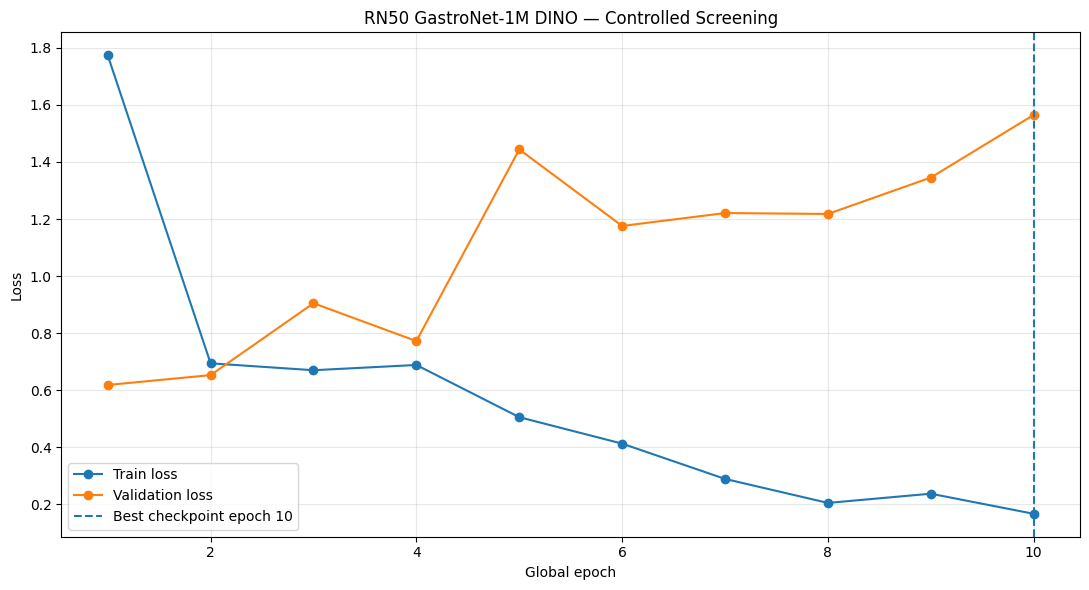

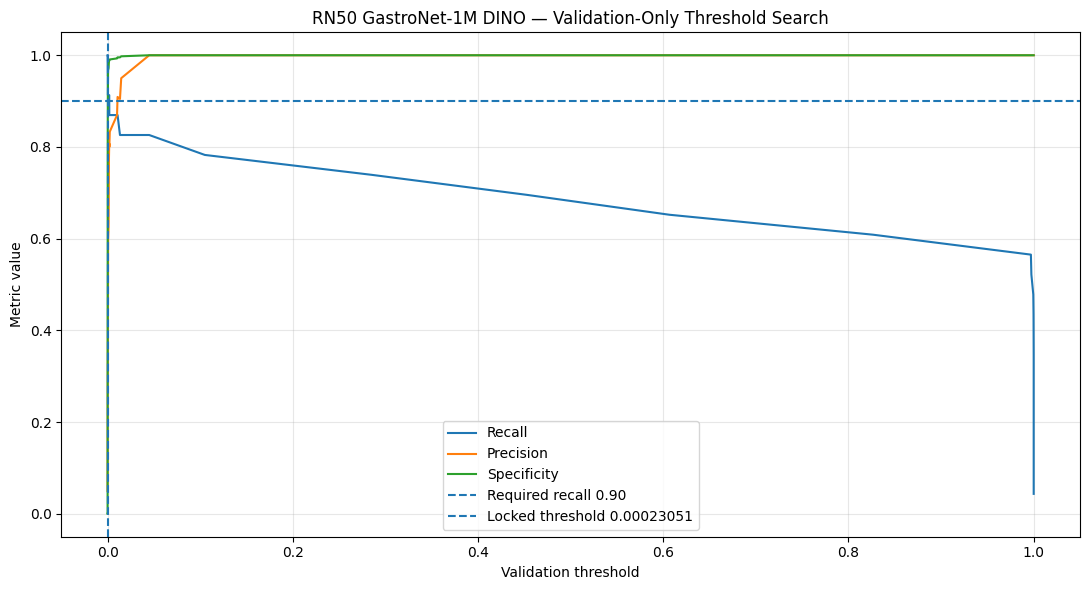


FINAL RN50 GastroNet-1M DINO SCREENING REPORT
Validation AUPRC: 0.919352
Validation AUROC: 0.970419
Recall: 0.956522
PPV: 0.343750
Specificity: 0.904110
Minimum centre recall: 0.888889
TP=22 | TN=396 | FP=42 | FN=1
Screening decision: BORDERLINE_DEVELOPMENT_CANDIDATE

------------------------------------------------------------------------------------------------------------
STARTING SCREENING: RN50 GastroNet-200K DINO
Checkpoint: /content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints/RN50_GastroNet-200K_DINOv1.pth
------------------------------------------------------------------------------------------------------------

STAGE 1: CLASSIFICATION HEAD ONLY
RN50 GastroNet-200K DINO | Stage 1 | Epoch 1/3 | Global 1 | Train loss 2.528923 | Val loss 0.737843 | AUPRC 0.561365 | AUROC 0.907882
RN50 GastroNet-200K DINO | Stage 1 | Epoch 2/3 | Global 2 | Train loss 0.843853 | Val loss 0.766765 | AUPRC 0.649128 | AUROC 0.938753
RN50 GastroNet-200K DINO | Stage 1 | Epoch 3/3 | Globa

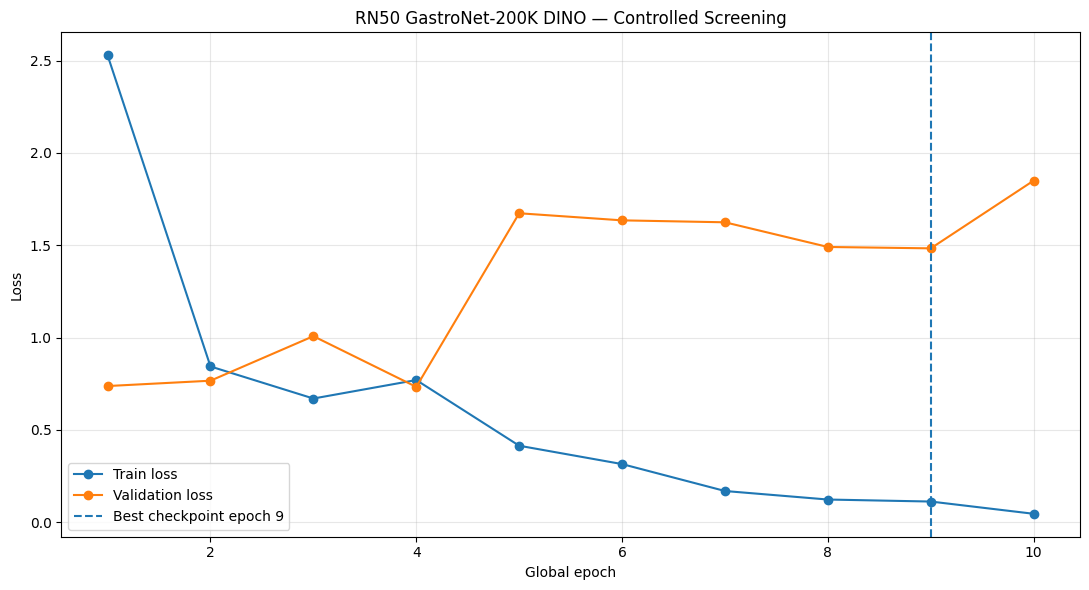

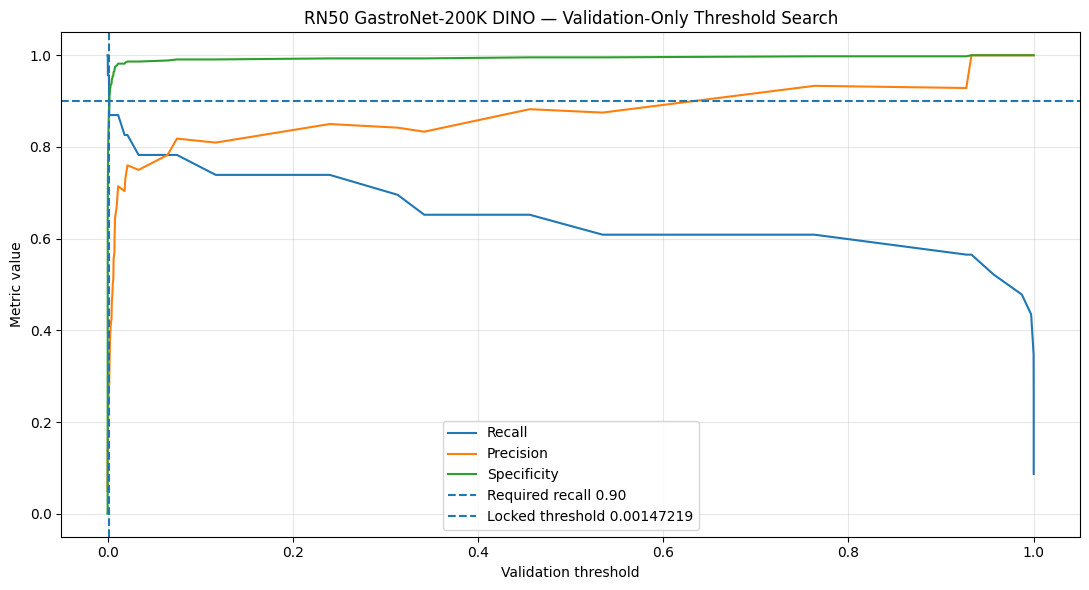


FINAL RN50 GastroNet-200K DINO SCREENING REPORT
Validation AUPRC: 0.849034
Validation AUROC: 0.972901
Recall: 0.956522
PPV: 0.297297
Specificity: 0.881279
Minimum centre recall: 0.888889
TP=22 | TN=386 | FP=52 | FN=1
Screening decision: STOP_AFTER_CONTROLLED_SCREENING

------------------------------------------------------------------------------------------------------------
STARTING SCREENING: RN50 GastroNet-5M MOCOv2
Checkpoint: /content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints/RN50_GastroNet-5M_MOCOv2.pth
------------------------------------------------------------------------------------------------------------

STAGE 1: CLASSIFICATION HEAD ONLY
RN50 GastroNet-5M MOCOv2 | Stage 1 | Epoch 1/3 | Global 1 | Train loss 1.272201 | Val loss 1.143367 | AUPRC 0.642935 | AUROC 0.900735
RN50 GastroNet-5M MOCOv2 | Stage 1 | Epoch 2/3 | Global 2 | Train loss 1.172026 | Val loss 1.051785 | AUPRC 0.648678 | AUROC 0.902521
RN50 GastroNet-5M MOCOv2 | Stage 1 | Epoch 3/3 | Global

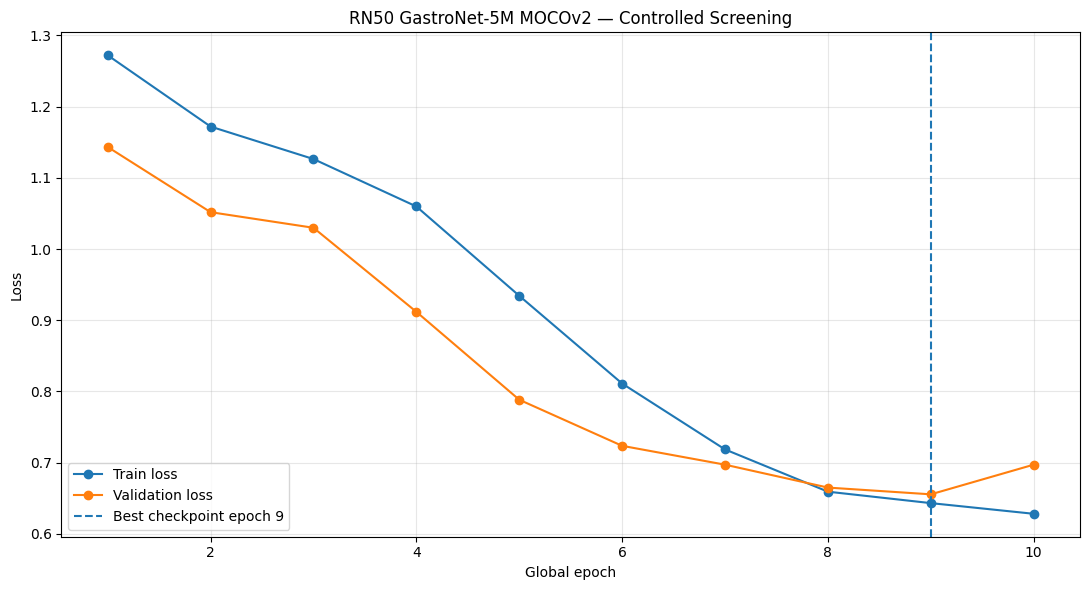

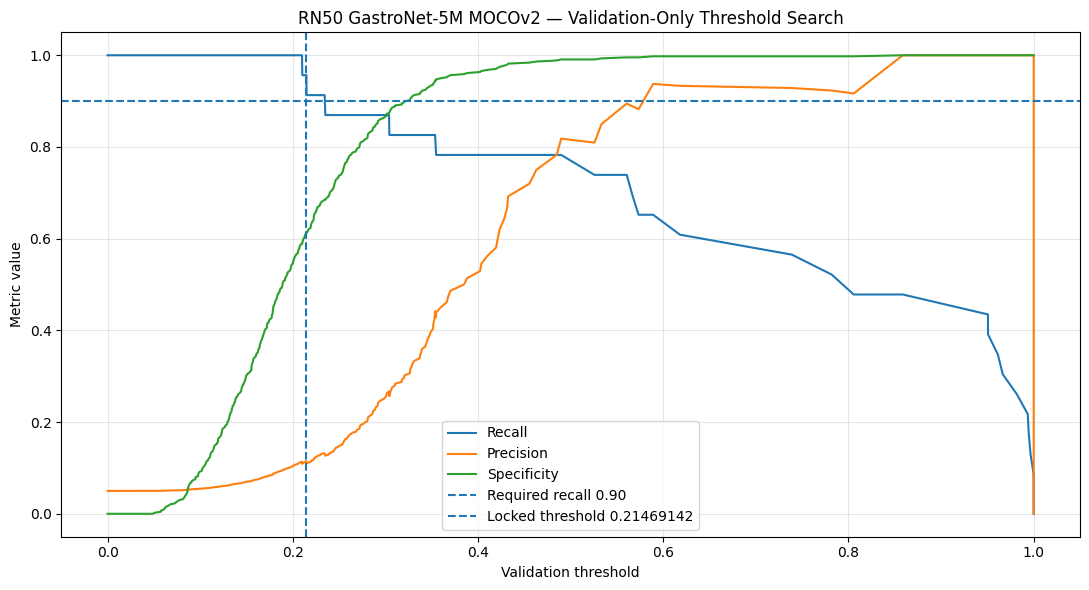


FINAL RN50 GastroNet-5M MOCOv2 SCREENING REPORT
Validation AUPRC: 0.799686
Validation AUROC: 0.942525
Recall: 0.956522
PPV: 0.114583
Specificity: 0.611872
Minimum centre recall: 0.888889
TP=22 | TN=268 | FP=170 | FN=1
Screening decision: STOP_AFTER_CONTROLLED_SCREENING

------------------------------------------------------------------------------------------------------------
STARTING SCREENING: RN50 GastroNet-5M SIMCLRv2
Checkpoint: /content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints/RN50_GastroNet-5M_SIMCLRv2.pth
------------------------------------------------------------------------------------------------------------

STAGE 1: CLASSIFICATION HEAD ONLY
RN50 GastroNet-5M SIMCLRv2 | Stage 1 | Epoch 1/3 | Global 1 | Train loss 1.305141 | Val loss 1.261708 | AUPRC 0.544584 | AUROC 0.850506
RN50 GastroNet-5M SIMCLRv2 | Stage 1 | Epoch 2/3 | Global 2 | Train loss 1.277007 | Val loss 1.232577 | AUPRC 0.530129 | AUROC 0.846436
RN50 GastroNet-5M SIMCLRv2 | Stage 1 | Epoch 3

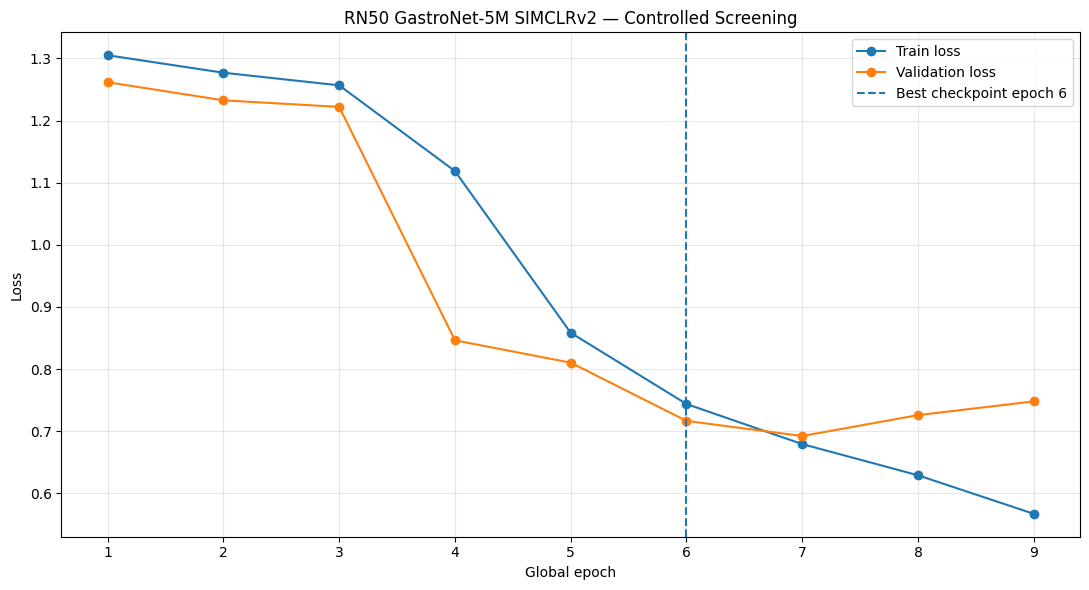

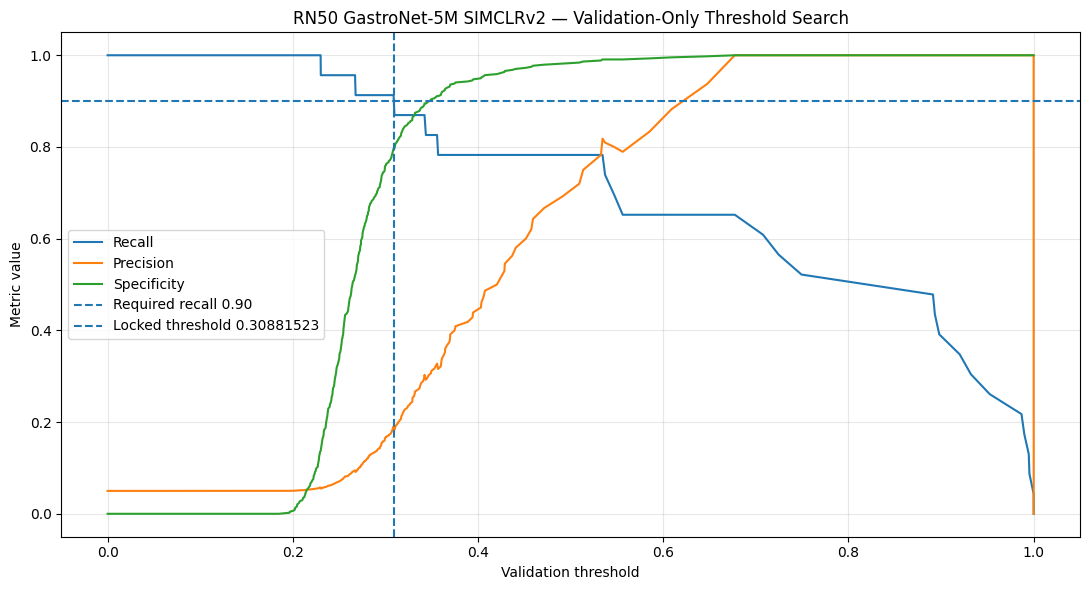


FINAL RN50 GastroNet-5M SIMCLRv2 SCREENING REPORT
Validation AUPRC: 0.800062
Validation AUROC: 0.923268
Recall: 0.913043
PPV: 0.190909
Specificity: 0.796804
Minimum centre recall: 0.888889
TP=21 | TN=349 | FP=89 | FN=2
Screening decision: STOP_AFTER_CONTROLLED_SCREENING

REMAINING RN50 CONTROLLED SCREENING RESULTS


,candidate_id,display_name,best_global_epoch,threshold,recall,precision,specificity,minimum_centre_recall,auroc,auprc,tp,tn,fp,fn,total_errors,screening_decision
0,rn50_gastronet1m_dinov1,RN50 GastroNet-1M DINO,10,0.000231,0.956522,0.343750,0.904110,0.888889,0.970419,0.919352,22,396,42,1,43,BORDERLINE_DEVELOPMENT_CANDIDATE
1,rn50_gastronet200k_dinov1,RN50 GastroNet-200K DINO,9,0.001472,0.956522,0.297297,0.881279,0.888889,0.972901,0.849034,22,386,52,1,53,STOP_AFTER_CONTROLLED_SCREENING
2,rn50_gastronet5m_mocov2,RN50 GastroNet-5M MOCOv2,9,0.214691,0.956522,0.114583,0.611872,0.888889,0.942525,0.799686,22,268,170,1,171,STOP_AFTER_CONTROLLED_SCREENING
3,rn50_gastronet5m_simclrv2,RN50 GastroNet-5M SIMCLRv2,6,0.308815,0.913043,0.190909,0.796804,0.888889,0.923268,0.800062,21,349,89,2,91,STOP_AFTER_CONTROLLED_SCREENING


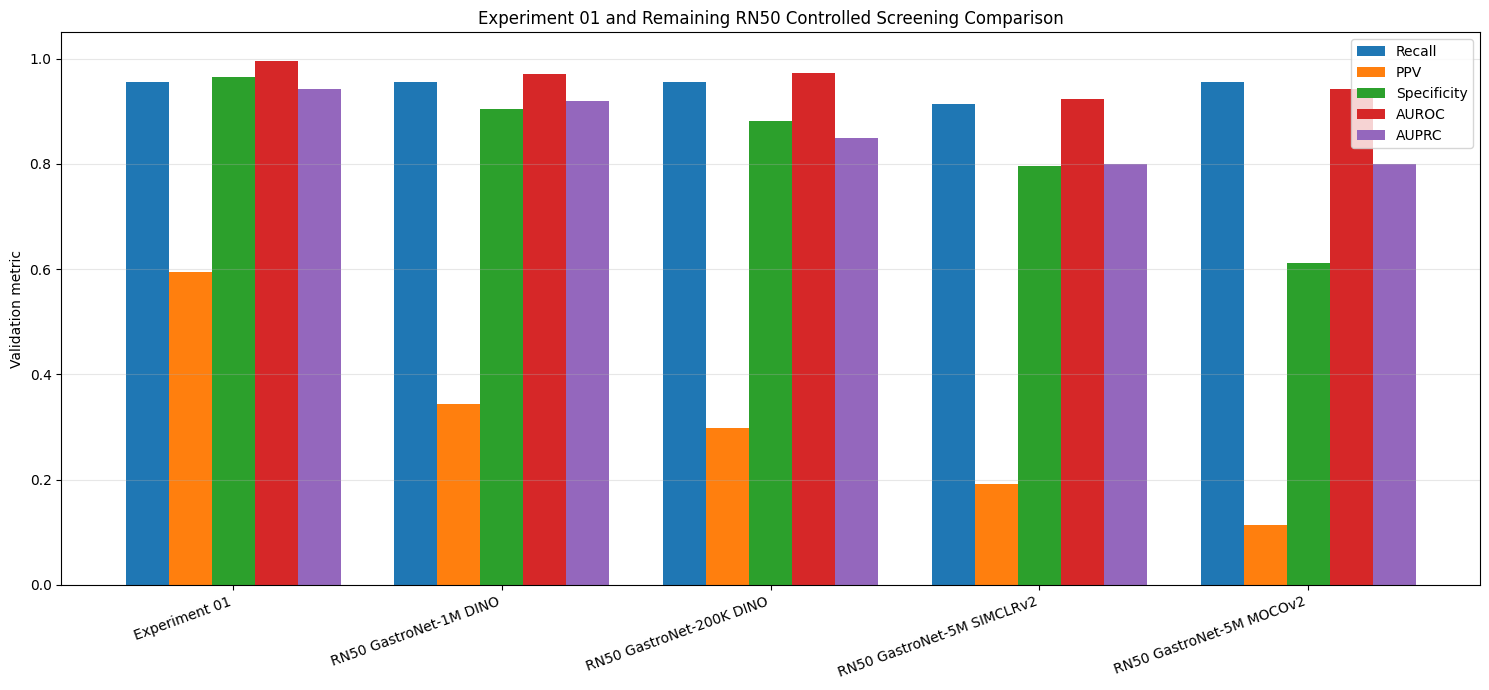

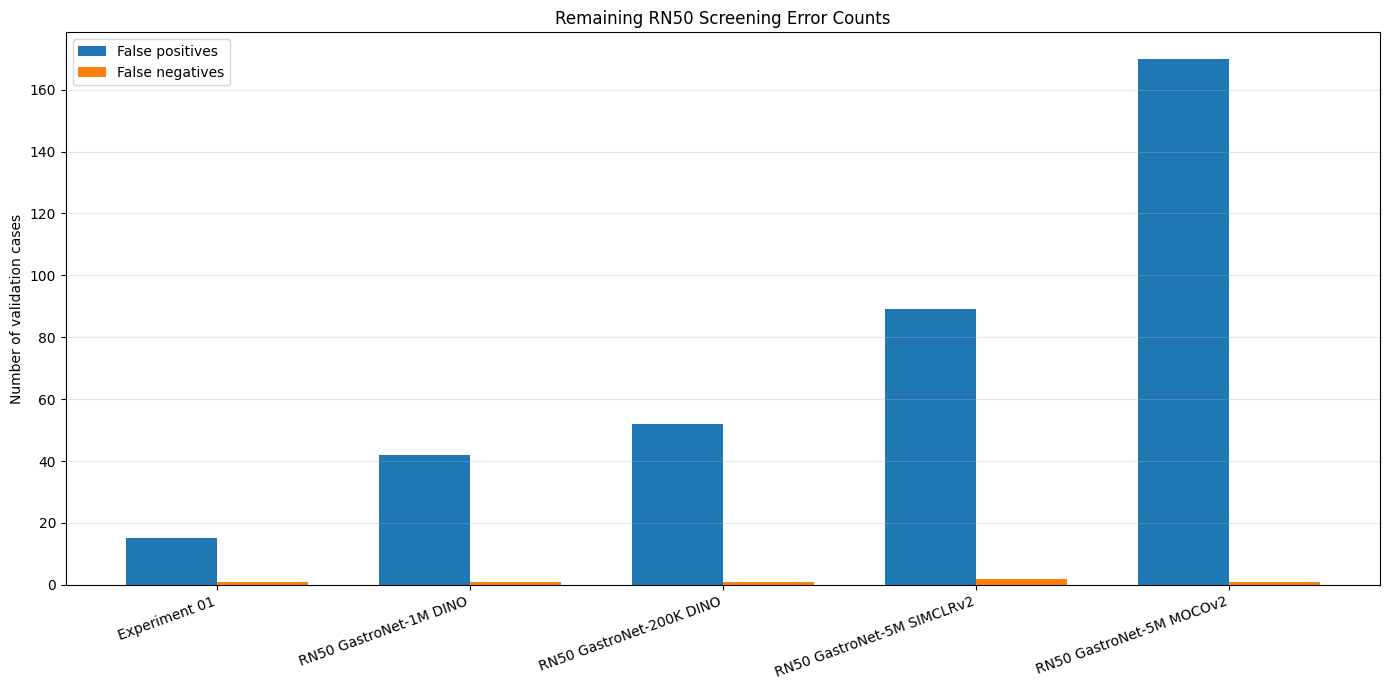

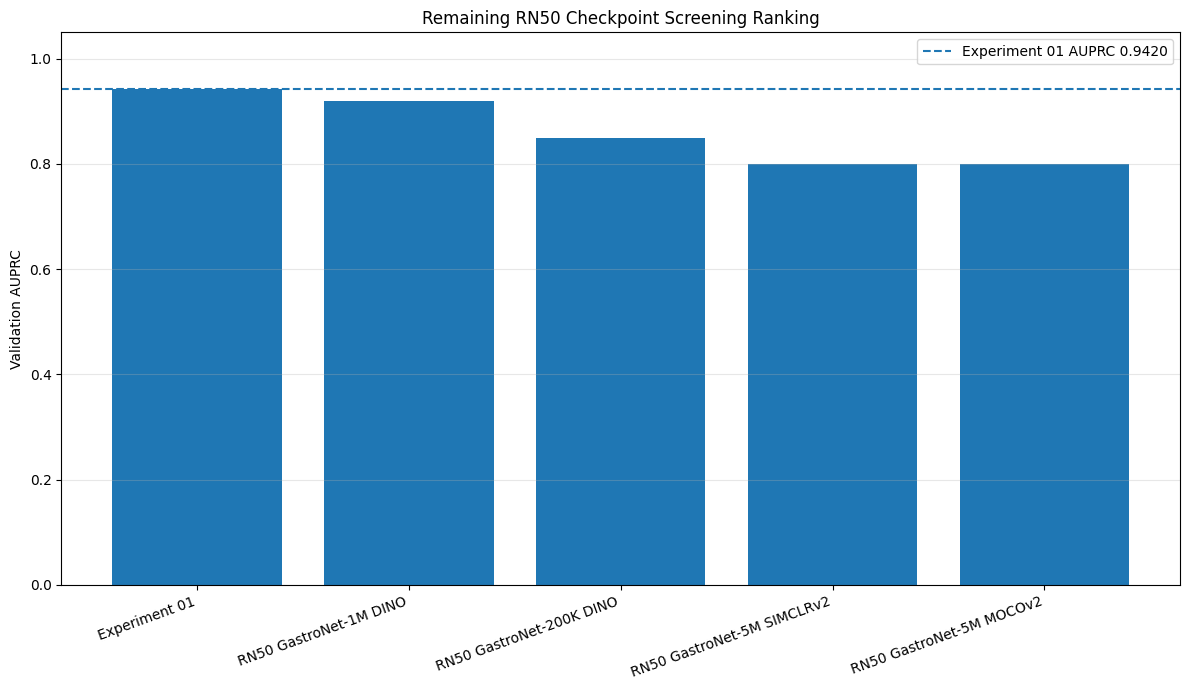


FINAL CELL 15B REMAINING RN50 SCREENING REPORT
Discovered candidates: 4
Compatible candidates: 4
Completed candidates: 4

Screening ranking:

Rank 1: RN50 GastroNet-1M DINO
AUPRC: 0.919352
AUROC: 0.970419
Recall: 0.956522
PPV: 0.343750
Specificity: 0.904110
TP=22 | TN=396 | FP=42 | FN=1
Screening decision: BORDERLINE_DEVELOPMENT_CANDIDATE

Rank 2: RN50 GastroNet-200K DINO
AUPRC: 0.849034
AUROC: 0.972901
Recall: 0.956522
PPV: 0.297297
Specificity: 0.881279
TP=22 | TN=386 | FP=52 | FN=1
Screening decision: STOP_AFTER_CONTROLLED_SCREENING

Rank 3: RN50 GastroNet-5M SIMCLRv2
AUPRC: 0.800062
AUROC: 0.923268
Recall: 0.913043
PPV: 0.190909
Specificity: 0.796804
TP=21 | TN=349 | FP=89 | FN=2
Screening decision: STOP_AFTER_CONTROLLED_SCREENING

Rank 4: RN50 GastroNet-5M MOCOv2
AUPRC: 0.799686
AUROC: 0.942525
Recall: 0.956522
PPV: 0.114583
Specificity: 0.611872
TP=22 | TN=268 | FP=170 | FN=1
Screening decision: STOP_AFTER_CONTROLLED_SCREENING

Aggregate development decision:
NO_AUTOMATIC_FULL_C

In [ ]:
# ==========================================================================================
# CELL 15B
# REMAINING RESNET-50 GASTRONET CHECKPOINTS
# CONTROLLED ORIGINAL-SPLIT SCREENING
#
# Candidates:
# 1. GastroNet-1M DINO
# 2. GastroNet-200K DINO
# 3. GastroNet-5M MOCOv2
# 4. GastroNet-5M SIMCLRv2
#
# Screening protocol:
# - One predeclared fixed seed: 42
# - Locked original train/validation split
# - Same preprocessing and class weighting as Experiments 01 and 02
# - Stage 1: classification head, 3 epochs
# - Stage 2: layer4 + classification head, maximum 7 epochs
# - Best checkpoint selected using validation AUPRC only
# - Threshold selected using validation predictions only
# - No held-out test access
# - Completed checkpoint runs automatically resume/skip
# ==========================================================================================

from pathlib import Path
from datetime import datetime, timezone
from urllib.parse import unquote
from IPython.display import display

import os
import gc
import re
import json
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.metrics import (
    confusion_matrix,
    average_precision_score,
    roc_auc_score,
)

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = True


# ==========================================================================================
# 1. FIXED SCREENING CONFIGURATION
# ==========================================================================================

CELL_ID = "cell15b_remaining_rn50_controlled_screening"

SCREENING_SEED = 42
FORCE_RERUN = False

IMAGE_SIZE = 224
RESIZE_SIZE = 256

BATCH_SIZE = 32
NUM_WORKERS = 2

STAGE_1_EPOCHS = 3
STAGE_2_MAX_EPOCHS = 7
STAGE_2_PATIENCE = 3

STAGE_1_HEAD_LR = 1e-3
STAGE_2_BACKBONE_LR = 1e-5
STAGE_2_HEAD_LR = 1e-4

WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0

REQUIRED_OVERALL_RECALL = 0.90
REQUIRED_MINIMUM_CENTRE_RECALL = 0.80

EXPECTED_TRAIN_TOTAL = 2159
EXPECTED_TRAIN_NORMAL = 2050
EXPECTED_TRAIN_POSITIVE = 109

EXPECTED_VALIDATION_TOTAL = 461
EXPECTED_VALIDATION_NORMAL = 438
EXPECTED_VALIDATION_POSITIVE = 23

EXPECTED_BACKBONE_TENSOR_COUNT = 318

FINAL_STATUS = (
    "CELL15B_REMAINING_RN50_CONTROLLED_SCREENING_COMPLETE"
)


# ==========================================================================================
# 2. PROJECT PATHS
# ==========================================================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/RARE26_GastroNet_Weights"
)

SOURCE_CHECKPOINT_DIR = (
    PROJECT_ROOT
    / "source_checkpoints"
)

TRAIN_CSV_PATH = (
    PROJECT_ROOT
    / "configs"
    / "runtime_splits"
    / "train_runtime_verified.csv"
)

VALIDATION_CSV_PATH = (
    PROJECT_ROOT
    / "configs"
    / "runtime_splits"
    / "validation_runtime_verified.csv"
)

CELL14D_DECISION_PATH = (
    PROJECT_ROOT
    / "results"
    / "ensembles"
    / "original_split"
    / "experiment_02_equal_weight_three_seed_ensemble"
    / "cell14d_development_model_decision.json"
)

EXP01_REFERENCE_PATH = (
    PROJECT_ROOT
    / "predictions"
    / "original_split"
    / "controlled_comparisons"
    / "experiment_01_vs_experiment_02_original_validation"
    / "cell14b_exp01_vs_exp02_paired_validation_cases.csv"
)


# ==========================================================================================
# 3. OUTPUT DIRECTORIES
# ==========================================================================================

SCREENING_ROOT = (
    PROJECT_ROOT
    / "screening"
    / "original_split"
    / "remaining_rn50_checkpoints"
)

MODEL_ROOT = (
    PROJECT_ROOT
    / "models"
    / "screening"
    / "original_split"
    / "remaining_rn50_checkpoints"
)

LOG_ROOT = (
    PROJECT_ROOT
    / "logs"
    / "screening"
    / "original_split"
    / "remaining_rn50_checkpoints"
)

PREDICTION_ROOT = (
    PROJECT_ROOT
    / "predictions"
    / "screening"
    / "original_split"
    / "remaining_rn50_checkpoints"
)

RESULT_ROOT = (
    PROJECT_ROOT
    / "results"
    / "screening"
    / "original_split"
    / "remaining_rn50_checkpoints"
)

THRESHOLD_ROOT = (
    PROJECT_ROOT
    / "thresholds"
    / "screening"
    / "original_split"
    / "remaining_rn50_checkpoints"
)

CENTRE_ROOT = (
    PROJECT_ROOT
    / "centre_analysis"
    / "screening"
    / "original_split"
    / "remaining_rn50_checkpoints"
)

FIGURE_ROOT = (
    PROJECT_ROOT
    / "figures"
    / "screening"
    / "original_split"
    / "remaining_rn50_checkpoints"
)

INVENTORY_ROOT = (
    PROJECT_ROOT
    / "inventory"
    / "screening"
    / "remaining_rn50_checkpoints"
)


for directory in [
    SCREENING_ROOT,
    MODEL_ROOT,
    LOG_ROOT,
    PREDICTION_ROOT,
    RESULT_ROOT,
    THRESHOLD_ROOT,
    CENTRE_ROOT,
    FIGURE_ROOT,
    INVENTORY_ROOT,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


AGGREGATE_RESULT_DIR = (
    RESULT_ROOT
    / "aggregate"
)

AGGREGATE_PREDICTION_DIR = (
    PREDICTION_ROOT
    / "aggregate"
)

AGGREGATE_CENTRE_DIR = (
    CENTRE_ROOT
    / "aggregate"
)

AGGREGATE_FIGURE_DIR = (
    FIGURE_ROOT
    / "aggregate"
)


for directory in [
    AGGREGATE_RESULT_DIR,
    AGGREGATE_PREDICTION_DIR,
    AGGREGATE_CENTRE_DIR,
    AGGREGATE_FIGURE_DIR,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ==========================================================================================
# 4. AGGREGATE OUTPUT PATHS
# ==========================================================================================

DISCOVERY_MANIFEST_PATH = (
    INVENTORY_ROOT
    / "cell15b_remaining_rn50_checkpoint_discovery.csv"
)

COMPATIBILITY_AUDIT_PATH = (
    INVENTORY_ROOT
    / "cell15b_remaining_rn50_compatibility_audit.csv"
)

SCREENING_PLAN_PATH = (
    INVENTORY_ROOT
    / "cell15b_screening_plan_lock.json"
)

AGGREGATE_METRICS_PATH = (
    AGGREGATE_RESULT_DIR
    / "cell15b_remaining_rn50_screening_metrics.csv"
)

AGGREGATE_COMPARISON_PATH = (
    AGGREGATE_RESULT_DIR
    / "cell15b_remaining_rn50_vs_exp01_comparison.csv"
)

AGGREGATE_CENTRE_PATH = (
    AGGREGATE_CENTRE_DIR
    / "cell15b_remaining_rn50_all_per_centre_metrics.csv"
)

AGGREGATE_RANKING_PATH = (
    AGGREGATE_RESULT_DIR
    / "cell15b_remaining_rn50_screening_ranking.csv"
)

ADVANCEMENT_DECISION_PATH = (
    AGGREGATE_RESULT_DIR
    / "cell15b_remaining_rn50_advancement_decision.json"
)

STATUS_PATH = (
    AGGREGATE_RESULT_DIR
    / "cell15b_status.json"
)

SUMMARY_PATH = (
    AGGREGATE_RESULT_DIR
    / "cell15b_remaining_rn50_screening_summary.txt"
)

METRIC_FIGURE_PATH = (
    AGGREGATE_FIGURE_DIR
    / "cell15b_remaining_rn50_metric_comparison.png"
)

ERROR_FIGURE_PATH = (
    AGGREGATE_FIGURE_DIR
    / "cell15b_remaining_rn50_error_comparison.png"
)

AUPRC_FIGURE_PATH = (
    AGGREGATE_FIGURE_DIR
    / "cell15b_remaining_rn50_auprc_ranking.png"
)


# ==========================================================================================
# 5. INITIAL REPORT
# ==========================================================================================

print("=" * 108)

print(
    "CELL 15B: REMAINING RESNET-50 GASTRONET "
    "CONTROLLED ORIGINAL-SPLIT SCREENING"
)

print("=" * 108)

print("\nFixed screening seed:")
print(SCREENING_SEED)

print("\nTraining split:")
print(TRAIN_CSV_PATH)

print("\nValidation split:")
print(VALIDATION_CSV_PATH)

print("\nHeld-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("Held-out test used for any decision: False")
print("Best seed selection allowed: False")
print("Checkpoint screening seed selection allowed: False")


# ==========================================================================================
# 6. REQUIRED FILE VERIFICATION
# ==========================================================================================

required_files = [
    TRAIN_CSV_PATH,
    VALIDATION_CSV_PATH,
    CELL14D_DECISION_PATH,
    EXP01_REFERENCE_PATH,
]

missing_files = [
    path
    for path in required_files
    if not path.exists()
]


if missing_files:

    print("\nMissing required files:")

    for path in missing_files:
        print(path)

    raise FileNotFoundError(
        "One or more required Cell 15B files were not found."
    )


cell14d_decision = json.loads(
    CELL14D_DECISION_PATH.read_text(
        encoding="utf-8"
    )
)

actual_cell14d_decision = cell14d_decision.get(
    "decision"
)


if actual_cell14d_decision != (
    "EXP01_RETAINS_CURRENT_DEVELOPMENT_LEAD"
):

    raise RuntimeError(
        "Cell 15B expected Experiment 01 to retain the "
        "current development lead after Cell 14D.\n"
        f"Actual Cell 14D decision: {actual_cell14d_decision}"
    )


print("\nCell 14D decision verified:")
print(actual_cell14d_decision)


# ==========================================================================================
# 7. GPU VERIFICATION
# ==========================================================================================

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

USE_AMP = (
    DEVICE.type == "cuda"
)


print("\nCompute device:")
print(DEVICE)


if DEVICE.type != "cuda":

    raise RuntimeError(
        "Cell 15B requires a GPU.\n"
        "Connect a T4 GPU, run Cell 3B to restore the images, "
        "and then run Cell 15B again."
    )


print(
    torch.cuda.get_device_name(
        0
    )
)


# ==========================================================================================
# 8. GENERAL COLUMN HELPERS
# ==========================================================================================

def find_column(
    dataframe,
    candidates,
    description,
    required=True,
):

    for candidate in candidates:

        if candidate in dataframe.columns:
            return candidate

    lowercase_map = {
        str(column).lower(): column
        for column in dataframe.columns
    }

    for candidate in candidates:

        if candidate.lower() in lowercase_map:

            return lowercase_map[
                candidate.lower()
            ]

    if required:

        raise KeyError(
            f"Could not find {description} column.\n"
            f"Available columns:\n"
            f"{list(dataframe.columns)}"
        )

    return None


PATH_CANDIDATES = [
    "runtime_path",
    "image_path",
    "filepath",
    "file_path",
    "path",
]

LABEL_CANDIDATES = [
    "label",
    "target",
    "ground_truth",
    "class_label",
    "y_true",
]

CENTER_CANDIDATES = [
    "center",
    "centre",
    "site",
]

SHA_CANDIDATES = [
    "sha256",
    "image_sha256",
    "file_sha256",
]

RELATIVE_PATH_CANDIDATES = [
    "relative_path",
    "original_relative_path",
    "image_relative_path",
]


# ==========================================================================================
# 9. LOAD AND VERIFY LOCKED TRAIN/VALIDATION SPLITS
# ==========================================================================================

train_df = pd.read_csv(
    TRAIN_CSV_PATH,
    low_memory=False,
)

validation_df = pd.read_csv(
    VALIDATION_CSV_PATH,
    low_memory=False,
)


train_path_column = find_column(
    train_df,
    PATH_CANDIDATES,
    "training runtime path",
)

validation_path_column = find_column(
    validation_df,
    PATH_CANDIDATES,
    "validation runtime path",
)

train_label_column = find_column(
    train_df,
    LABEL_CANDIDATES,
    "training label",
)

validation_label_column = find_column(
    validation_df,
    LABEL_CANDIDATES,
    "validation label",
)

train_center_column = find_column(
    train_df,
    CENTER_CANDIDATES,
    "training centre",
)

validation_center_column = find_column(
    validation_df,
    CENTER_CANDIDATES,
    "validation centre",
)

validation_sha_column = find_column(
    validation_df,
    SHA_CANDIDATES,
    "validation SHA-256",
)

validation_relative_path_column = find_column(
    validation_df,
    RELATIVE_PATH_CANDIDATES,
    "validation relative path",
)


train_df[
    train_label_column
] = pd.to_numeric(
    train_df[
        train_label_column
    ],
    errors="raise",
).astype(int)

validation_df[
    validation_label_column
] = pd.to_numeric(
    validation_df[
        validation_label_column
    ],
    errors="raise",
).astype(int)


train_total = len(
    train_df
)

validation_total = len(
    validation_df
)

train_normal = int(
    (
        train_df[
            train_label_column
        ]
        == 0
    ).sum()
)

train_positive = int(
    (
        train_df[
            train_label_column
        ]
        == 1
    ).sum()
)

validation_normal = int(
    (
        validation_df[
            validation_label_column
        ]
        == 0
    ).sum()
)

validation_positive = int(
    (
        validation_df[
            validation_label_column
        ]
        == 1
    ).sum()
)


expected_counts = {
    "train_total": (
        train_total,
        EXPECTED_TRAIN_TOTAL,
    ),

    "train_normal": (
        train_normal,
        EXPECTED_TRAIN_NORMAL,
    ),

    "train_positive": (
        train_positive,
        EXPECTED_TRAIN_POSITIVE,
    ),

    "validation_total": (
        validation_total,
        EXPECTED_VALIDATION_TOTAL,
    ),

    "validation_normal": (
        validation_normal,
        EXPECTED_VALIDATION_NORMAL,
    ),

    "validation_positive": (
        validation_positive,
        EXPECTED_VALIDATION_POSITIVE,
    ),
}


for count_name, (
    actual_count,
    expected_count,
) in expected_counts.items():

    if actual_count != expected_count:

        raise RuntimeError(
            f"Locked split count mismatch: {count_name}\n"
            f"Expected: {expected_count}\n"
            f"Found: {actual_count}"
        )


missing_train_images = [
    path
    for path in train_df[
        train_path_column
    ].astype(str)
    if not Path(
        path
    ).exists()
]

missing_validation_images = [
    path
    for path in validation_df[
        validation_path_column
    ].astype(str)
    if not Path(
        path
    ).exists()
]


if missing_train_images:

    raise FileNotFoundError(
        f"{len(missing_train_images)} training images are "
        "missing from temporary Colab storage.\n"
        "Run Cell 3B before Cell 15B."
    )


if missing_validation_images:

    raise FileNotFoundError(
        f"{len(missing_validation_images)} validation images "
        "are missing from temporary Colab storage.\n"
        "Run Cell 3B before Cell 15B."
    )


train_path_set = set(
    train_df[
        train_path_column
    ].astype(str)
)

validation_path_set = set(
    validation_df[
        validation_path_column
    ].astype(str)
)

train_validation_overlap = len(
    train_path_set.intersection(
        validation_path_set
    )
)


if train_validation_overlap != 0:

    raise RuntimeError(
        f"Train/validation overlap detected: "
        f"{train_validation_overlap}"
    )


print("\nLocked original split verified:")

print(
    f"Train: {train_total} "
    f"(normal={train_normal}, NEO={train_positive})"
)

print(
    f"Validation: {validation_total} "
    f"(normal={validation_normal}, "
    f"NEO={validation_positive})"
)

print(
    f"Train/validation overlap: "
    f"{train_validation_overlap}"
)

print(
    f"Missing training images: "
    f"{len(missing_train_images)}"
)

print(
    f"Missing validation images: "
    f"{len(missing_validation_images)}"
)


# ==========================================================================================
# 10. LOAD EXPERIMENT 01 LOCKED REFERENCE
# ==========================================================================================

exp01_reference_raw_df = pd.read_csv(
    EXP01_REFERENCE_PATH,
    low_memory=False,
)


exp01_sha_column = find_column(
    exp01_reference_raw_df,
    [
        "case_sha256",
        "sha256",
    ],
    "Experiment 01 SHA-256",
)

exp01_label_column = find_column(
    exp01_reference_raw_df,
    [
        "label",
        "label_exp01",
    ],
    "Experiment 01 label",
)

exp01_center_column = find_column(
    exp01_reference_raw_df,
    [
        "center",
        "center_exp01",
        "centre",
    ],
    "Experiment 01 centre",
)

exp01_probability_column = find_column(
    exp01_reference_raw_df,
    [
        "probability_exp01",
        "probability",
    ],
    "Experiment 01 probability",
)

exp01_prediction_column = find_column(
    exp01_reference_raw_df,
    [
        "prediction_exp01",
        "prediction",
    ],
    "Experiment 01 prediction",
)


exp01_reference_df = pd.DataFrame(
    {
        "case_sha256": (
            exp01_reference_raw_df[
                exp01_sha_column
            ]
            .astype(str)
            .str.strip()
            .str.lower()
        ),

        "label_exp01": pd.to_numeric(
            exp01_reference_raw_df[
                exp01_label_column
            ],
            errors="raise",
        ).astype(int),

        "center_exp01": (
            exp01_reference_raw_df[
                exp01_center_column
            ].astype(str)
        ),

        "probability_exp01": pd.to_numeric(
            exp01_reference_raw_df[
                exp01_probability_column
            ],
            errors="raise",
        ).astype(float),

        "prediction_exp01": pd.to_numeric(
            exp01_reference_raw_df[
                exp01_prediction_column
            ],
            errors="raise",
        ).astype(int),
    }
)


if len(
    exp01_reference_df
) != EXPECTED_VALIDATION_TOTAL:

    raise RuntimeError(
        "Experiment 01 reference does not contain "
        f"{EXPECTED_VALIDATION_TOTAL} validation cases."
    )


# ==========================================================================================
# 11. METRIC FUNCTIONS
# ==========================================================================================

def safe_divide(
    numerator,
    denominator,
):

    if denominator == 0:
        return 0.0

    return float(
        numerator / denominator
    )


def calculate_metrics(
    labels,
    probabilities,
    predictions,
):

    labels = np.asarray(
        labels,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    predictions = np.asarray(
        predictions,
        dtype=int,
    )


    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[
            0,
            1,
        ],
    ).ravel()


    recall = safe_divide(
        tp,
        tp + fn,
    )

    precision = safe_divide(
        tp,
        tp + fp,
    )

    specificity = safe_divide(
        tn,
        tn + fp,
    )

    npv = safe_divide(
        tn,
        tn + fn,
    )

    accuracy = safe_divide(
        tp + tn,
        len(
            labels
        ),
    )

    balanced_accuracy = (
        recall + specificity
    ) / 2.0

    f1 = safe_divide(
        2.0
        * precision
        * recall,
        precision + recall,
    )


    if len(
        np.unique(
            labels
        )
    ) == 2:

        auroc = float(
            roc_auc_score(
                labels,
                probabilities,
            )
        )

        auprc = float(
            average_precision_score(
                labels,
                probabilities,
            )
        )

    else:

        auroc = np.nan
        auprc = np.nan


    return {
        "sample_count": int(
            len(
                labels
            )
        ),

        "normal_count": int(
            (
                labels == 0
            ).sum()
        ),

        "positive_count": int(
            (
                labels == 1
            ).sum()
        ),

        "recall": float(
            recall
        ),

        "precision": float(
            precision
        ),

        "specificity": float(
            specificity
        ),

        "npv": float(
            npv
        ),

        "accuracy": float(
            accuracy
        ),

        "balanced_accuracy": float(
            balanced_accuracy
        ),

        "f1": float(
            f1
        ),

        "auroc": float(
            auroc
        ),

        "auprc": float(
            auprc
        ),

        "tp": int(
            tp
        ),

        "tn": int(
            tn
        ),

        "fp": int(
            fp
        ),

        "fn": int(
            fn
        ),

        "total_errors": int(
            fp + fn
        ),
    }


exp01_metrics = calculate_metrics(
    exp01_reference_df[
        "label_exp01"
    ].to_numpy(
        dtype=int
    ),

    exp01_reference_df[
        "probability_exp01"
    ].to_numpy(
        dtype=float
    ),

    exp01_reference_df[
        "prediction_exp01"
    ].to_numpy(
        dtype=int
    ),
)


expected_exp01_confusion = {
    "tp": 22,
    "tn": 423,
    "fp": 15,
    "fn": 1,
}


for metric_name, expected_value in (
    expected_exp01_confusion.items()
):

    if exp01_metrics[
        metric_name
    ] != expected_value:

        raise RuntimeError(
            "Experiment 01 reference verification failed.\n"
            f"{metric_name}: expected {expected_value}, "
            f"found {exp01_metrics[metric_name]}"
        )


print("\nExperiment 01 reference verified:")

print(
    f"AUPRC={exp01_metrics['auprc']:.6f} | "
    f"AUROC={exp01_metrics['auroc']:.6f} | "
    f"Recall={exp01_metrics['recall']:.6f} | "
    f"PPV={exp01_metrics['precision']:.6f} | "
    f"Specificity={exp01_metrics['specificity']:.6f}"
)


# ==========================================================================================
# 12. CHECKPOINT DISCOVERY
# ==========================================================================================

def normalized_checkpoint_name(
    path,
):

    decoded_name = unquote(
        path.name
    ).lower()

    decoded_name = re.sub(
        r"[^a-z0-9]+",
        "_",
        decoded_name,
    )

    return decoded_name.strip(
        "_"
    )


all_source_checkpoints = sorted(
    SOURCE_CHECKPOINT_DIR.rglob(
        "*.pth"
    )
)


if not all_source_checkpoints:

    raise FileNotFoundError(
        f"No .pth checkpoints were found in:\n"
        f"{SOURCE_CHECKPOINT_DIR}"
    )


CANDIDATE_SPECS = [
    {
        "candidate_id": (
            "rn50_gastronet1m_dinov1"
        ),

        "display_name": (
            "RN50 GastroNet-1M DINO"
        ),

        "method": (
            "DINO"
        ),

        "pretraining_size": (
            "1M"
        ),
    },

    {
        "candidate_id": (
            "rn50_gastronet200k_dinov1"
        ),

        "display_name": (
            "RN50 GastroNet-200K DINO"
        ),

        "method": (
            "DINO"
        ),

        "pretraining_size": (
            "200K"
        ),
    },

    {
        "candidate_id": (
            "rn50_gastronet5m_mocov2"
        ),

        "display_name": (
            "RN50 GastroNet-5M MOCOv2"
        ),

        "method": (
            "MOCOv2"
        ),

        "pretraining_size": (
            "5M"
        ),
    },

    {
        "candidate_id": (
            "rn50_gastronet5m_simclrv2"
        ),

        "display_name": (
            "RN50 GastroNet-5M SIMCLRv2"
        ),

        "method": (
            "SIMCLRv2"
        ),

        "pretraining_size": (
            "5M"
        ),
    },
]


def is_rn50_name(
    normalized_name,
):

    return bool(
        (
            "rn50" in normalized_name
            or "resnet50" in normalized_name
        )
        and "vit" not in normalized_name
    )


def candidate_matches(
    normalized_name,
    candidate_id,
):

    if not is_rn50_name(
        normalized_name
    ):

        return False


    if candidate_id == (
        "rn50_gastronet1m_dinov1"
    ):

        return bool(
            "gastronet" in normalized_name
            and "dino" in normalized_name
            and re.search(
                r"(^|_)1m(_|$)",
                normalized_name,
            )
            and "200k" not in normalized_name
            and "5m" not in normalized_name
            and "swsl" not in normalized_name
            and "billion" not in normalized_name
        )


    if candidate_id == (
        "rn50_gastronet200k_dinov1"
    ):

        return bool(
            "gastronet" in normalized_name
            and "dino" in normalized_name
            and "200k" in normalized_name
            and "swsl" not in normalized_name
            and "billion" not in normalized_name
        )


    if candidate_id == (
        "rn50_gastronet5m_mocov2"
    ):

        return bool(
            "gastronet" in normalized_name
            and "5m" in normalized_name
            and "moco" in normalized_name
        )


    if candidate_id == (
        "rn50_gastronet5m_simclrv2"
    ):

        return bool(
            "gastronet" in normalized_name
            and "5m" in normalized_name
            and "simclr" in normalized_name
        )


    return False


discovery_rows = []

resolved_candidates = []


for candidate_spec in CANDIDATE_SPECS:

    candidate_matches_list = [
        path
        for path in all_source_checkpoints
        if candidate_matches(
            normalized_checkpoint_name(
                path
            ),
            candidate_spec[
                "candidate_id"
            ],
        )
    ]


    discovery_rows.append(
        {
            "candidate_id": (
                candidate_spec[
                    "candidate_id"
                ]
            ),

            "display_name": (
                candidate_spec[
                    "display_name"
                ]
            ),

            "match_count": int(
                len(
                    candidate_matches_list
                )
            ),

            "matched_paths": " | ".join(
                str(
                    path
                )
                for path in candidate_matches_list
            ),
        }
    )


    if len(
        candidate_matches_list
    ) != 1:

        print(
            f"\nCheckpoint discovery issue for "
            f"{candidate_spec['display_name']}:"
        )

        print(
            f"Matches found: "
            f"{len(candidate_matches_list)}"
        )

        for path in candidate_matches_list:
            print(path)

        raise RuntimeError(
            "Each screening candidate must resolve to exactly "
            "one source checkpoint."
        )


    resolved_candidate = (
        candidate_spec.copy()
    )

    resolved_candidate[
        "checkpoint_path"
    ] = candidate_matches_list[
        0
    ]

    resolved_candidate[
        "checkpoint_filename"
    ] = candidate_matches_list[
        0
    ].name

    resolved_candidates.append(
        resolved_candidate
    )


discovery_df = pd.DataFrame(
    discovery_rows
)

discovery_df.to_csv(
    DISCOVERY_MANIFEST_PATH,
    index=False,
)


print("\nDiscovered screening checkpoints:")

display(
    discovery_df
)


# ==========================================================================================
# 13. LOCK SCREENING PLAN BEFORE TRAINING
# ==========================================================================================

screening_plan_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "cell_id": CELL_ID,

    "screening_seed": (
        SCREENING_SEED
    ),

    "candidate_order": [
        candidate[
            "candidate_id"
        ]
        for candidate in resolved_candidates
    ],

    "candidate_checkpoints": {
        candidate[
            "candidate_id"
        ]: str(
            candidate[
                "checkpoint_path"
            ]
        )
        for candidate in resolved_candidates
    },

    "training_protocol": {
        "image_size": (
            IMAGE_SIZE
        ),

        "resize_size": (
            RESIZE_SIZE
        ),

        "batch_size": (
            BATCH_SIZE
        ),

        "stage_1_epochs": (
            STAGE_1_EPOCHS
        ),

        "stage_2_max_epochs": (
            STAGE_2_MAX_EPOCHS
        ),

        "stage_2_patience": (
            STAGE_2_PATIENCE
        ),

        "stage_1_head_lr": (
            STAGE_1_HEAD_LR
        ),

        "stage_2_backbone_lr": (
            STAGE_2_BACKBONE_LR
        ),

        "stage_2_head_lr": (
            STAGE_2_HEAD_LR
        ),

        "weight_decay": (
            WEIGHT_DECAY
        ),

        "checkpoint_selection": (
            "validation_auprc_only"
        ),

        "threshold_selection": (
            "validation_predictions_only"
        ),
    },

    "advancement_criteria": {
        "required_recall": (
            REQUIRED_OVERALL_RECALL
        ),

        "required_minimum_centre_recall": (
            REQUIRED_MINIMUM_CENTRE_RECALL
        ),

        "maximum_auprc_drop_vs_exp01": (
            0.015
        ),

        "maximum_auroc_drop_vs_exp01": (
            0.015
        ),

        "maximum_ppv_drop_vs_exp01": (
            0.10
        ),

        "maximum_specificity_drop_vs_exp01": (
            0.05
        ),

        "maximum_additional_total_errors_vs_exp01": (
            10
        ),

        "borderline_minimum_auprc": (
            0.90
        ),
    },

    "full_cv_advancement_rule": (
        "A candidate advances only if it satisfies every "
        "safety and no-material-degradation criterion. "
        "If multiple candidates satisfy the criteria, the "
        "highest AUPRC candidate advances, followed by "
        "AUROC, PPV, specificity and fewer errors."
    ),

    "best_seed_selected": False,

    "held_out_test_loaded": False,

    "held_out_test_evaluated": False,
}


SCREENING_PLAN_PATH.write_text(
    json.dumps(
        screening_plan_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ==========================================================================================
# 14. REPRODUCIBILITY
# ==========================================================================================

def set_complete_seed(
    seed,
):

    os.environ[
        "PYTHONHASHSEED"
    ] = str(
        seed
    )

    random.seed(
        seed
    )

    np.random.seed(
        seed
    )

    torch.manual_seed(
        seed
    )

    torch.cuda.manual_seed(
        seed
    )

    torch.cuda.manual_seed_all(
        seed
    )

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    try:

        torch.use_deterministic_algorithms(
            True,
            warn_only=True,
        )

    except Exception:

        pass


def seed_worker(
    worker_id,
):

    worker_seed = (
        torch.initial_seed()
        % (2 ** 32)
    )

    np.random.seed(
        worker_seed
    )

    random.seed(
        worker_seed
    )


# ==========================================================================================
# 15. IMAGE TRANSFORMS AND DATASET
# ==========================================================================================

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406,
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225,
]

ROTATION_FILL = tuple(
    int(
        value * 255
    )
    for value in IMAGENET_MEAN
)


train_transform = transforms.Compose(
    [
        transforms.Resize(
            RESIZE_SIZE
        ),

        transforms.RandomResizedCrop(
            IMAGE_SIZE,
            scale=(
                0.85,
                1.00,
            ),
            ratio=(
                0.90,
                1.10,
            ),
        ),

        transforms.RandomHorizontalFlip(
            p=0.5
        ),

        transforms.RandomRotation(
            degrees=8,
            fill=ROTATION_FILL,
        ),

        transforms.ColorJitter(
            brightness=0.10,
            contrast=0.10,
            saturation=0.05,
            hue=0.02,
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)


validation_transform = transforms.Compose(
    [
        transforms.Resize(
            RESIZE_SIZE
        ),

        transforms.CenterCrop(
            IMAGE_SIZE
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)


class RARE26Dataset(
    Dataset
):

    def __init__(
        self,
        dataframe,
        path_column,
        label_column,
        transform,
    ):

        self.dataframe = dataframe.reset_index(
            drop=True
        ).copy()

        self.path_column = path_column
        self.label_column = label_column
        self.transform = transform


    def __len__(
        self,
    ):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        index,
    ):

        row = self.dataframe.iloc[
            index
        ]

        image_path = str(
            row[
                self.path_column
            ]
        )

        label = float(
            row[
                self.label_column
            ]
        )


        with Image.open(
            image_path
        ) as opened_image:

            image = opened_image.convert(
                "RGB"
            )


        image = self.transform(
            image
        )


        return (
            image,

            torch.tensor(
                label,
                dtype=torch.float32,
            ),

            index,
        )


# ==========================================================================================
# 16. CHECKPOINT LOADING AND COMPATIBILITY
# ==========================================================================================

def torch_load_complete(
    path,
):

    try:

        return torch.load(
            path,
            map_location="cpu",
            weights_only=False,
        )

    except TypeError:

        return torch.load(
            path,
            map_location="cpu",
        )


def extract_tensor_state_dict(
    checkpoint_object,
):

    if not isinstance(
        checkpoint_object,
        dict,
    ):

        raise RuntimeError(
            "Checkpoint object is not a dictionary."
        )


    preferred_nested_keys = [
        "state_dict",
        "model_state_dict",
        "model",
        "student",
        "encoder_q",
        "base_encoder",
        "backbone",
        "encoder",
        "teacher",
    ]


    for nested_key in preferred_nested_keys:

        if (
            nested_key in checkpoint_object
            and isinstance(
                checkpoint_object[
                    nested_key
                ],
                dict,
            )
        ):

            nested_state = checkpoint_object[
                nested_key
            ]

            tensor_count = sum(
                torch.is_tensor(
                    value
                )
                for value in nested_state.values()
            )

            if tensor_count > 0:

                return nested_state


    tensor_entries = {
        key: value
        for key, value
        in checkpoint_object.items()
        if torch.is_tensor(
            value
        )
    }


    if tensor_entries:

        return tensor_entries


    raise RuntimeError(
        "No tensor state dictionary could be extracted "
        "from the checkpoint."
    )


def source_key_priority(
    raw_key,
):

    raw_key_lower = str(
        raw_key
    ).lower()


    if any(
        token in raw_key_lower
        for token in [
            "encoder_q",
            "base_encoder",
            "online_encoder",
            "student",
        ]
    ):

        return 100


    if any(
        token in raw_key_lower
        for token in [
            "encoder_k",
            "momentum_encoder",
            "target_encoder",
            "teacher",
        ]
    ):

        return 10


    if any(
        token in raw_key_lower
        for token in [
            "backbone",
            "encoder",
            "trunk",
        ]
    ):

        return 80


    return 50


def strip_known_prefixes(
    key,
):

    cleaned_key = str(
        key
    )


    known_prefixes = [
        "module.",
        "model.",
        "network.",
        "student.",
        "teacher.",
        "backbone.",
        "encoder.",
        "encoder_q.",
        "encoder_k.",
        "base_encoder.",
        "online_encoder.",
        "momentum_encoder.",
        "target_encoder.",
        "trunk.",
        "convnet.",
    ]


    prefix_removed = True


    while prefix_removed:

        prefix_removed = False

        for prefix in known_prefixes:

            if cleaned_key.startswith(
                prefix
            ):

                cleaned_key = cleaned_key[
                    len(
                        prefix
                    ):
                ]

                prefix_removed = True


    return cleaned_key


def map_source_to_resnet50_backbone(
    source_state_dict,
):

    temporary_model = models.resnet50(
        weights=None
    )

    model_state = temporary_model.state_dict()

    expected_backbone_keys = {
        key
        for key in model_state.keys()
        if not key.startswith(
            "fc."
        )
    }


    selected_mapping = {}

    selected_priorities = {}

    mapping_rows = []


    for raw_key, tensor_value in (
        source_state_dict.items()
    ):

        if not torch.is_tensor(
            tensor_value
        ):

            continue


        cleaned_key = strip_known_prefixes(
            raw_key
        )


        mapped_key = None


        if (
            cleaned_key in expected_backbone_keys
            and tuple(
                tensor_value.shape
            )
            == tuple(
                model_state[
                    cleaned_key
                ].shape
            )
        ):

            mapped_key = cleaned_key

        else:

            suffix_matches = [
                expected_key
                for expected_key
                in expected_backbone_keys
                if (
                    str(
                        raw_key
                    ).endswith(
                        expected_key
                    )
                    or cleaned_key.endswith(
                        expected_key
                    )
                )
                and tuple(
                    tensor_value.shape
                )
                == tuple(
                    model_state[
                        expected_key
                    ].shape
                )
            ]


            if len(
                suffix_matches
            ) == 1:

                mapped_key = suffix_matches[
                    0
                ]


        if mapped_key is None:

            continue


        priority = source_key_priority(
            raw_key
        )


        if (
            mapped_key not in selected_mapping
            or priority
            > selected_priorities[
                mapped_key
            ]
        ):

            selected_mapping[
                mapped_key
            ] = tensor_value

            selected_priorities[
                mapped_key
            ] = priority


            mapping_rows.append(
                {
                    "model_key": (
                        mapped_key
                    ),

                    "source_key": str(
                        raw_key
                    ),

                    "priority": (
                        priority
                    ),

                    "shape": str(
                        tuple(
                            tensor_value.shape
                        )
                    ),
                }
            )


    missing_backbone_keys = sorted(
        expected_backbone_keys.difference(
            selected_mapping.keys()
        )
    )


    del temporary_model

    gc.collect()


    return (
        selected_mapping,
        expected_backbone_keys,
        missing_backbone_keys,
        mapping_rows,
    )


def build_screening_model(
    checkpoint_path,
):

    checkpoint_object = torch_load_complete(
        checkpoint_path
    )

    source_state_dict = extract_tensor_state_dict(
        checkpoint_object
    )


    (
        compatible_state,
        expected_backbone_keys,
        missing_backbone_keys,
        mapping_rows,
    ) = map_source_to_resnet50_backbone(
        source_state_dict
    )


    matched_count = len(
        compatible_state
    )

    expected_count = len(
        expected_backbone_keys
    )


    if matched_count != expected_count:

        raise RuntimeError(
            "Incomplete ResNet-50 backbone compatibility.\n"
            f"Matched: {matched_count}/{expected_count}\n"
            f"Missing examples: {missing_backbone_keys[:20]}"
        )


    if matched_count != EXPECTED_BACKBONE_TENSOR_COUNT:

        raise RuntimeError(
            "Unexpected ResNet-50 tensor count.\n"
            f"Expected: {EXPECTED_BACKBONE_TENSOR_COUNT}\n"
            f"Found: {matched_count}"
        )


    model = models.resnet50(
        weights=None
    )

    feature_count = model.fc.in_features

    model.fc = nn.Linear(
        feature_count,
        1,
    )


    load_result = model.load_state_dict(
        compatible_state,
        strict=False,
    )


    missing_parameters = list(
        load_result.missing_keys
    )

    unexpected_parameters = list(
        load_result.unexpected_keys
    )


    if set(
        missing_parameters
    ) != {
        "fc.weight",
        "fc.bias",
    }:

        raise RuntimeError(
            "Unexpected missing model parameters:\n"
            f"{missing_parameters}"
        )


    if unexpected_parameters:

        raise RuntimeError(
            "Unexpected checkpoint parameters:\n"
            f"{unexpected_parameters}"
        )


    return (
        model,
        matched_count,
        expected_count,
        missing_parameters,
        unexpected_parameters,
        mapping_rows,
    )


# ==========================================================================================
# 17. CHECK ALL FOUR CHECKPOINTS BEFORE TRAINING
# ==========================================================================================

compatibility_rows = []

compatible_candidates = []


for candidate in resolved_candidates:

    print(
        f"\nChecking compatibility: "
        f"{candidate['display_name']}"
    )


    try:

        (
            compatibility_model,
            matched_count,
            expected_count,
            missing_parameters,
            unexpected_parameters,
            mapping_rows,
        ) = build_screening_model(
            candidate[
                "checkpoint_path"
            ]
        )


        compatibility_status = (
            "COMPATIBLE"
        )

        compatibility_error = ""


        candidate_copy = candidate.copy()

        candidate_copy[
            "matched_backbone_tensors"
        ] = matched_count

        candidate_copy[
            "expected_backbone_tensors"
        ] = expected_count

        compatible_candidates.append(
            candidate_copy
        )


        mapping_audit_path = (
            INVENTORY_ROOT
            / (
                f"{candidate['candidate_id']}_"
                "tensor_mapping_audit.csv"
            )
        )

        pd.DataFrame(
            mapping_rows
        ).drop_duplicates(
            subset=[
                "model_key"
            ],
            keep="last",
        ).to_csv(
            mapping_audit_path,
            index=False,
        )


        del compatibility_model

        gc.collect()

        torch.cuda.empty_cache()


    except Exception as error:

        matched_count = 0
        expected_count = (
            EXPECTED_BACKBONE_TENSOR_COUNT
        )

        missing_parameters = []
        unexpected_parameters = []

        compatibility_status = (
            "INCOMPATIBLE"
        )

        compatibility_error = str(
            error
        )


    compatibility_rows.append(
        {
            "candidate_id": (
                candidate[
                    "candidate_id"
                ]
            ),

            "display_name": (
                candidate[
                    "display_name"
                ]
            ),

            "checkpoint_path": str(
                candidate[
                    "checkpoint_path"
                ]
            ),

            "compatibility_status": (
                compatibility_status
            ),

            "matched_backbone_tensors": (
                matched_count
            ),

            "expected_backbone_tensors": (
                expected_count
            ),

            "missing_parameters": str(
                missing_parameters
            ),

            "unexpected_parameters": str(
                unexpected_parameters
            ),

            "compatibility_error": (
                compatibility_error
            ),
        }
    )


compatibility_df = pd.DataFrame(
    compatibility_rows
)

compatibility_df.to_csv(
    COMPATIBILITY_AUDIT_PATH,
    index=False,
)


print("\nCheckpoint compatibility audit:")

display(
    compatibility_df
)


if len(
    compatible_candidates
) == 0:

    raise RuntimeError(
        "None of the remaining ResNet-50 checkpoints "
        "passed compatibility verification."
    )


# ==========================================================================================
# 18. TRAINING HELPERS
# ==========================================================================================

def create_grad_scaler():

    try:

        return torch.amp.GradScaler(
            "cuda",
            enabled=USE_AMP,
        )

    except Exception:

        return torch.cuda.amp.GradScaler(
            enabled=USE_AMP
        )


def autocast_context():

    try:

        return torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=USE_AMP,
        )

    except Exception:

        return torch.cuda.amp.autocast(
            enabled=USE_AMP
        )


def train_one_epoch(
    model,
    data_loader,
    criterion,
    optimizer,
    scaler,
):

    model.train()

    total_loss = 0.0
    total_count = 0


    for images, labels, _ in data_loader:

        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True,
        )


        optimizer.zero_grad(
            set_to_none=True
        )


        with autocast_context():

            logits = model(
                images
            ).squeeze(
                1
            )

            loss = criterion(
                logits,
                labels,
            )


        scaler.scale(
            loss
        ).backward()

        scaler.unscale_(
            optimizer
        )

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRADIENT_CLIP_NORM,
        )

        scaler.step(
            optimizer
        )

        scaler.update()


        batch_size = images.size(
            0
        )

        total_loss += (
            float(
                loss.detach().cpu()
            )
            * batch_size
        )

        total_count += batch_size


    return safe_divide(
        total_loss,
        total_count,
    )


@torch.no_grad()
def run_validation(
    model,
    data_loader,
    criterion,
):

    model.eval()

    all_logits = []
    all_labels = []
    all_indices = []

    total_loss = 0.0
    total_count = 0


    for images, labels, indices in data_loader:

        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        labels_device = labels.to(
            DEVICE,
            non_blocking=True,
        )


        with autocast_context():

            logits = model(
                images
            ).squeeze(
                1
            )

            loss = criterion(
                logits,
                labels_device,
            )


        batch_size = images.size(
            0
        )

        total_loss += (
            float(
                loss.detach().cpu()
            )
            * batch_size
        )

        total_count += batch_size


        all_logits.append(
            logits.detach().float().cpu().numpy()
        )

        all_labels.append(
            labels.numpy()
        )

        all_indices.append(
            indices.numpy()
        )


    logits = np.concatenate(
        all_logits
    ).astype(
        np.float64
    )

    labels = np.concatenate(
        all_labels
    ).astype(
        int
    )

    indices = np.concatenate(
        all_indices
    ).astype(
        int
    )


    probabilities = (
        1.0
        / (
            1.0
            + np.exp(
                -np.clip(
                    logits,
                    -50,
                    50,
                )
            )
        )
    )


    return {
        "validation_loss": safe_divide(
            total_loss,
            total_count,
        ),

        "logits": (
            logits
        ),

        "probabilities": (
            probabilities
        ),

        "labels": (
            labels
        ),

        "indices": (
            indices
        ),
    }


def save_checkpoint(
    model,
    checkpoint_path,
    metadata,
):

    cpu_state_dict = {
        key: value.detach().cpu()
        for key, value
        in model.state_dict().items()
    }


    torch.save(
        {
            "model_state_dict": (
                cpu_state_dict
            ),

            **metadata,
        },
        checkpoint_path,
    )


# ==========================================================================================
# 19. VALIDATION-ONLY THRESHOLD SEARCH
# ==========================================================================================

def search_validation_threshold(
    prediction_dataframe,
):

    labels = prediction_dataframe[
        "label"
    ].to_numpy(
        dtype=int
    )

    probabilities = prediction_dataframe[
        "probability"
    ].to_numpy(
        dtype=float
    )

    centers = prediction_dataframe[
        "center"
    ].astype(str).to_numpy()


    candidate_thresholds = np.unique(
        np.concatenate(
            [
                np.array(
                    [
                        0.0,
                        1.0,
                    ],
                    dtype=float,
                ),

                probabilities,
            ]
        )
    )


    threshold_rows = []


    for threshold in candidate_thresholds:

        predictions = (
            probabilities
            >= threshold
        ).astype(
            int
        )


        overall_metrics = calculate_metrics(
            labels,
            probabilities,
            predictions,
        )


        centre_recall_values = {}


        for center_value in sorted(
            np.unique(
                centers
            )
        ):

            center_mask = (
                centers
                == center_value
            )


            center_metrics = calculate_metrics(
                labels[
                    center_mask
                ],

                probabilities[
                    center_mask
                ],

                predictions[
                    center_mask
                ],
            )


            centre_recall_values[
                center_value
            ] = center_metrics[
                "recall"
            ]


        minimum_centre_recall = float(
            min(
                centre_recall_values.values()
            )
        )


        threshold_rows.append(
            {
                "threshold": float(
                    threshold
                ),

                "recall": (
                    overall_metrics[
                        "recall"
                    ]
                ),

                "precision": (
                    overall_metrics[
                        "precision"
                    ]
                ),

                "specificity": (
                    overall_metrics[
                        "specificity"
                    ]
                ),

                "npv": (
                    overall_metrics[
                        "npv"
                    ]
                ),

                "accuracy": (
                    overall_metrics[
                        "accuracy"
                    ]
                ),

                "balanced_accuracy": (
                    overall_metrics[
                        "balanced_accuracy"
                    ]
                ),

                "f1": (
                    overall_metrics[
                        "f1"
                    ]
                ),

                "tp": (
                    overall_metrics[
                        "tp"
                    ]
                ),

                "tn": (
                    overall_metrics[
                        "tn"
                    ]
                ),

                "fp": (
                    overall_metrics[
                        "fp"
                    ]
                ),

                "fn": (
                    overall_metrics[
                        "fn"
                    ]
                ),

                "total_errors": (
                    overall_metrics[
                        "total_errors"
                    ]
                ),

                "minimum_centre_recall": (
                    minimum_centre_recall
                ),

                **{
                    f"{center_value}_recall": (
                        centre_recall_values[
                            center_value
                        ]
                    )
                    for center_value
                    in centre_recall_values
                },
            }
        )


    threshold_search_df = pd.DataFrame(
        threshold_rows
    )


    strict_eligible_df = threshold_search_df[
        (
            threshold_search_df[
                "recall"
            ]
            >= REQUIRED_OVERALL_RECALL
        )
        &
        (
            threshold_search_df[
                "minimum_centre_recall"
            ]
            >= REQUIRED_MINIMUM_CENTRE_RECALL
        )
    ].copy()


    if len(
        strict_eligible_df
    ) > 0:

        eligible_df = strict_eligible_df

        selection_mode = (
            "overall_recall_0.90_and_"
            "minimum_centre_recall_0.80"
        )

    else:

        overall_eligible_df = threshold_search_df[
            threshold_search_df[
                "recall"
            ]
            >= REQUIRED_OVERALL_RECALL
        ].copy()


        if len(
            overall_eligible_df
        ) > 0:

            eligible_df = (
                overall_eligible_df
            )

            selection_mode = (
                "fallback_overall_recall_0.90"
            )

        else:

            eligible_df = (
                threshold_search_df.copy()
            )

            selection_mode = (
                "fallback_highest_recall"
            )


    selected_row = (
        eligible_df.sort_values(
            by=[
                "precision",
                "minimum_centre_recall",
                "specificity",
                "threshold",
            ],
            ascending=[
                False,
                False,
                False,
                False,
            ],
        )
        .iloc[
            0
        ]
        .copy()
    )


    return (
        threshold_search_df,
        selected_row,
        selection_mode,
        len(
            strict_eligible_df
        ),
    )


# ==========================================================================================
# 20. RUN ONE CHECKPOINT SCREENING EXPERIMENT
# ==========================================================================================

def run_checkpoint_screening(
    candidate,
):

    candidate_id = candidate[
        "candidate_id"
    ]

    display_name = candidate[
        "display_name"
    ]

    checkpoint_path = candidate[
        "checkpoint_path"
    ]


    model_dir = (
        MODEL_ROOT
        / candidate_id
    )

    log_dir = (
        LOG_ROOT
        / candidate_id
    )

    prediction_dir = (
        PREDICTION_ROOT
        / candidate_id
    )

    result_dir = (
        RESULT_ROOT
        / candidate_id
    )

    threshold_dir = (
        THRESHOLD_ROOT
        / candidate_id
    )

    centre_dir = (
        CENTRE_ROOT
        / candidate_id
    )

    figure_dir = (
        FIGURE_ROOT
        / candidate_id
    )


    for directory in [
        model_dir,
        log_dir,
        prediction_dir,
        result_dir,
        threshold_dir,
        centre_dir,
        figure_dir,
    ]:

        directory.mkdir(
            parents=True,
            exist_ok=True,
        )


    best_checkpoint_path = (
        model_dir
        / (
            f"{candidate_id}_seed_{SCREENING_SEED}_"
            "best.pth"
        )
    )

    history_path = (
        log_dir
        / (
            f"{candidate_id}_seed_{SCREENING_SEED}_"
            "training_history.csv"
        )
    )

    prediction_path = (
        prediction_dir
        / (
            f"{candidate_id}_seed_{SCREENING_SEED}_"
            "validation_predictions_locked_threshold.csv"
        )
    )

    threshold_search_path = (
        threshold_dir
        / (
            f"{candidate_id}_seed_{SCREENING_SEED}_"
            "threshold_search.csv"
        )
    )

    threshold_lock_path = (
        threshold_dir
        / (
            f"{candidate_id}_seed_{SCREENING_SEED}_"
            "threshold_lock.json"
        )
    )

    metrics_path = (
        result_dir
        / (
            f"{candidate_id}_seed_{SCREENING_SEED}_"
            "validation_metrics.csv"
        )
    )

    comparison_path = (
        result_dir
        / (
            f"{candidate_id}_seed_{SCREENING_SEED}_"
            "vs_exp01_comparison.csv"
        )
    )

    centre_metrics_path = (
        centre_dir
        / (
            f"{candidate_id}_seed_{SCREENING_SEED}_"
            "per_centre_metrics.csv"
        )
    )

    status_path = (
        result_dir
        / (
            f"{candidate_id}_seed_{SCREENING_SEED}_"
            "status.json"
        )
    )

    summary_path = (
        result_dir
        / (
            f"{candidate_id}_seed_{SCREENING_SEED}_"
            "summary.txt"
        )
    )

    training_figure_path = (
        figure_dir
        / (
            f"{candidate_id}_seed_{SCREENING_SEED}_"
            "training_curves.png"
        )
    )

    threshold_figure_path = (
        figure_dir
        / (
            f"{candidate_id}_seed_{SCREENING_SEED}_"
            "threshold_analysis.png"
        )
    )


    required_completed_outputs = [
        best_checkpoint_path,
        history_path,
        prediction_path,
        threshold_search_path,
        threshold_lock_path,
        metrics_path,
        comparison_path,
        centre_metrics_path,
        status_path,
    ]


    if (
        not FORCE_RERUN
        and status_path.exists()
        and all(
            path.exists()
            for path in required_completed_outputs
        )
    ):

        existing_status = json.loads(
            status_path.read_text(
                encoding="utf-8"
            )
        )


        if existing_status.get(
            "status"
        ) == (
            "RN50_SCREENING_CANDIDATE_COMPLETE"
        ):

            existing_metrics = (
                pd.read_csv(
                    metrics_path
                )
                .iloc[
                    0
                ]
                .to_dict()
            )


            print(
                f"\n{display_name} already complete. "
                "Saved results will be reused."
            )


            return existing_metrics


    print("\n" + "-" * 108)

    print(
        f"STARTING SCREENING: {display_name}"
    )

    print(
        f"Checkpoint: {checkpoint_path}"
    )

    print("-" * 108)


    set_complete_seed(
        SCREENING_SEED
    )


    train_dataset = RARE26Dataset(
        train_df,
        train_path_column,
        train_label_column,
        train_transform,
    )

    validation_dataset = RARE26Dataset(
        validation_df,
        validation_path_column,
        validation_label_column,
        validation_transform,
    )


    loader_generator = torch.Generator()

    loader_generator.manual_seed(
        SCREENING_SEED
    )


    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        drop_last=False,
        worker_init_fn=seed_worker,
        generator=loader_generator,
        persistent_workers=False,
    )

    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        drop_last=False,
        worker_init_fn=seed_worker,
        persistent_workers=False,
    )


    (
        model,
        matched_backbone_count,
        expected_backbone_count,
        _,
        _,
        _,
    ) = build_screening_model(
        checkpoint_path
    )


    model = model.to(
        DEVICE
    )


    positive_weight = (
        train_normal
        / train_positive
    )


    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            [
                positive_weight
            ],
            dtype=torch.float32,
            device=DEVICE,
        )
    )


    training_history = []

    best_validation_auprc = (
        -np.inf
    )

    best_checkpoint_metadata = None

    global_epoch = 0


    # ======================================================================================
    # STAGE 1 — CLASSIFICATION HEAD ONLY
    # ======================================================================================

    for parameter in model.parameters():

        parameter.requires_grad = False


    for parameter in model.fc.parameters():

        parameter.requires_grad = True


    stage_1_optimizer = torch.optim.AdamW(
        model.fc.parameters(),
        lr=STAGE_1_HEAD_LR,
        weight_decay=WEIGHT_DECAY,
    )

    stage_1_scheduler = (
        torch.optim.lr_scheduler.CosineAnnealingLR(
            stage_1_optimizer,
            T_max=STAGE_1_EPOCHS,
        )
    )

    stage_1_scaler = create_grad_scaler()


    print("\nSTAGE 1: CLASSIFICATION HEAD ONLY")


    for stage_epoch in range(
        1,
        STAGE_1_EPOCHS + 1,
    ):

        global_epoch += 1


        train_loss = train_one_epoch(
            model,
            train_loader,
            criterion,
            stage_1_optimizer,
            stage_1_scaler,
        )


        validation_result = run_validation(
            model,
            validation_loader,
            criterion,
        )


        validation_metrics_default = calculate_metrics(
            validation_result[
                "labels"
            ],

            validation_result[
                "probabilities"
            ],

            (
                validation_result[
                    "probabilities"
                ]
                >= 0.5
            ).astype(
                int
            ),
        )


        current_auprc = (
            validation_metrics_default[
                "auprc"
            ]
        )

        current_auroc = (
            validation_metrics_default[
                "auroc"
            ]
        )


        training_history.append(
            {
                "candidate_id": (
                    candidate_id
                ),

                "seed": (
                    SCREENING_SEED
                ),

                "stage": (
                    "stage_1"
                ),

                "stage_epoch": (
                    stage_epoch
                ),

                "global_epoch": (
                    global_epoch
                ),

                "train_loss": (
                    train_loss
                ),

                "validation_loss": (
                    validation_result[
                        "validation_loss"
                    ]
                ),

                "validation_auprc": (
                    current_auprc
                ),

                "validation_auroc": (
                    current_auroc
                ),

                "learning_rate_backbone": (
                    0.0
                ),

                "learning_rate_head": (
                    stage_1_optimizer.param_groups[
                        0
                    ][
                        "lr"
                    ]
                ),
            }
        )


        print(
            f"{display_name} | Stage 1 | "
            f"Epoch {stage_epoch}/{STAGE_1_EPOCHS} | "
            f"Global {global_epoch} | "
            f"Train loss {train_loss:.6f} | "
            f"Val loss "
            f"{validation_result['validation_loss']:.6f} | "
            f"AUPRC {current_auprc:.6f} | "
            f"AUROC {current_auroc:.6f}"
        )


        if current_auprc > best_validation_auprc:

            best_validation_auprc = (
                current_auprc
            )


            best_checkpoint_metadata = {
                "candidate_id": (
                    candidate_id
                ),

                "display_name": (
                    display_name
                ),

                "screening_seed": (
                    SCREENING_SEED
                ),

                "stage": (
                    "stage_1"
                ),

                "stage_epoch": (
                    stage_epoch
                ),

                "global_epoch": (
                    global_epoch
                ),

                "validation_auprc": (
                    current_auprc
                ),

                "validation_auroc": (
                    current_auroc
                ),

                "source_checkpoint": str(
                    checkpoint_path
                ),

                "matched_backbone_tensors": (
                    matched_backbone_count
                ),

                "expected_backbone_tensors": (
                    expected_backbone_count
                ),
            }


            save_checkpoint(
                model,
                best_checkpoint_path,
                best_checkpoint_metadata,
            )


        stage_1_scheduler.step()


    # ======================================================================================
    # STAGE 2 — LAYER4 AND CLASSIFICATION HEAD
    # ======================================================================================

    for parameter in model.parameters():

        parameter.requires_grad = False


    for parameter in model.layer4.parameters():

        parameter.requires_grad = True


    for parameter in model.fc.parameters():

        parameter.requires_grad = True


    stage_2_optimizer = torch.optim.AdamW(
        [
            {
                "params": (
                    model.layer4.parameters()
                ),

                "lr": (
                    STAGE_2_BACKBONE_LR
                ),
            },

            {
                "params": (
                    model.fc.parameters()
                ),

                "lr": (
                    STAGE_2_HEAD_LR
                ),
            },
        ],
        weight_decay=WEIGHT_DECAY,
    )

    stage_2_scheduler = (
        torch.optim.lr_scheduler.CosineAnnealingLR(
            stage_2_optimizer,
            T_max=STAGE_2_MAX_EPOCHS,
        )
    )

    stage_2_scaler = create_grad_scaler()

    consecutive_non_improvements = 0


    print(
        "\nSTAGE 2: LAYER4 AND CLASSIFICATION HEAD"
    )


    for stage_epoch in range(
        1,
        STAGE_2_MAX_EPOCHS + 1,
    ):

        global_epoch += 1


        train_loss = train_one_epoch(
            model,
            train_loader,
            criterion,
            stage_2_optimizer,
            stage_2_scaler,
        )


        validation_result = run_validation(
            model,
            validation_loader,
            criterion,
        )


        validation_metrics_default = calculate_metrics(
            validation_result[
                "labels"
            ],

            validation_result[
                "probabilities"
            ],

            (
                validation_result[
                    "probabilities"
                ]
                >= 0.5
            ).astype(
                int
            ),
        )


        current_auprc = (
            validation_metrics_default[
                "auprc"
            ]
        )

        current_auroc = (
            validation_metrics_default[
                "auroc"
            ]
        )


        training_history.append(
            {
                "candidate_id": (
                    candidate_id
                ),

                "seed": (
                    SCREENING_SEED
                ),

                "stage": (
                    "stage_2"
                ),

                "stage_epoch": (
                    stage_epoch
                ),

                "global_epoch": (
                    global_epoch
                ),

                "train_loss": (
                    train_loss
                ),

                "validation_loss": (
                    validation_result[
                        "validation_loss"
                    ]
                ),

                "validation_auprc": (
                    current_auprc
                ),

                "validation_auroc": (
                    current_auroc
                ),

                "learning_rate_backbone": (
                    stage_2_optimizer.param_groups[
                        0
                    ][
                        "lr"
                    ]
                ),

                "learning_rate_head": (
                    stage_2_optimizer.param_groups[
                        1
                    ][
                        "lr"
                    ]
                ),
            }
        )


        print(
            f"{display_name} | Stage 2 | "
            f"Epoch {stage_epoch}/{STAGE_2_MAX_EPOCHS} | "
            f"Global {global_epoch} | "
            f"Train loss {train_loss:.6f} | "
            f"Val loss "
            f"{validation_result['validation_loss']:.6f} | "
            f"AUPRC {current_auprc:.6f} | "
            f"AUROC {current_auroc:.6f}"
        )


        if current_auprc > (
            best_validation_auprc
            + 1e-12
        ):

            best_validation_auprc = (
                current_auprc
            )

            consecutive_non_improvements = 0


            best_checkpoint_metadata = {
                "candidate_id": (
                    candidate_id
                ),

                "display_name": (
                    display_name
                ),

                "screening_seed": (
                    SCREENING_SEED
                ),

                "stage": (
                    "stage_2"
                ),

                "stage_epoch": (
                    stage_epoch
                ),

                "global_epoch": (
                    global_epoch
                ),

                "validation_auprc": (
                    current_auprc
                ),

                "validation_auroc": (
                    current_auroc
                ),

                "source_checkpoint": str(
                    checkpoint_path
                ),

                "matched_backbone_tensors": (
                    matched_backbone_count
                ),

                "expected_backbone_tensors": (
                    expected_backbone_count
                ),
            }


            save_checkpoint(
                model,
                best_checkpoint_path,
                best_checkpoint_metadata,
            )

        else:

            consecutive_non_improvements += 1


        stage_2_scheduler.step()


        if (
            consecutive_non_improvements
            >= STAGE_2_PATIENCE
        ):

            print(
                f"{display_name}: early stopping after "
                f"{STAGE_2_PATIENCE} consecutive Stage-2 "
                "epochs without validation AUPRC improvement."
            )

            break


    if best_checkpoint_metadata is None:

        raise RuntimeError(
            f"No best checkpoint was saved for "
            f"{display_name}."
        )


    # ======================================================================================
    # RESTORE BEST VALIDATION-SELECTED CHECKPOINT
    # ======================================================================================

    saved_best_checkpoint = torch_load_complete(
        best_checkpoint_path
    )


    model.load_state_dict(
        saved_best_checkpoint[
            "model_state_dict"
        ],
        strict=True,
    )


    final_validation_result = run_validation(
        model,
        validation_loader,
        criterion,
    )


    validation_indices = final_validation_result[
        "indices"
    ]


    prediction_df = validation_df.iloc[
        validation_indices
    ].reset_index(
        drop=True
    ).copy()


    prediction_df[
        "candidate_id"
    ] = candidate_id

    prediction_df[
        "display_name"
    ] = display_name

    prediction_df[
        "screening_seed"
    ] = SCREENING_SEED

    prediction_df[
        "sha256"
    ] = (
        prediction_df[
            validation_sha_column
        ]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    prediction_df[
        "relative_path"
    ] = prediction_df[
        validation_relative_path_column
    ].astype(str)

    prediction_df[
        "label"
    ] = final_validation_result[
        "labels"
    ]

    prediction_df[
        "center"
    ] = prediction_df[
        validation_center_column
    ].astype(str)

    prediction_df[
        "logit"
    ] = final_validation_result[
        "logits"
    ]

    prediction_df[
        "probability"
    ] = final_validation_result[
        "probabilities"
    ]


    # ======================================================================================
    # VALIDATION-ONLY THRESHOLD LOCK
    # ======================================================================================

    (
        threshold_search_df,
        selected_threshold_row,
        selection_mode,
        strict_eligible_count,
    ) = search_validation_threshold(
        prediction_df
    )


    selected_threshold = float(
        selected_threshold_row[
            "threshold"
        ]
    )


    prediction_df[
        "locked_threshold"
    ] = selected_threshold

    prediction_df[
        "locked_prediction"
    ] = (
        prediction_df[
            "probability"
        ].to_numpy(
            dtype=float
        )
        >= selected_threshold
    ).astype(
        int
    )


    prediction_df[
        "correct"
    ] = (
        prediction_df[
            "locked_prediction"
        ]
        == prediction_df[
            "label"
        ]
    )


    prediction_df[
        "error_type"
    ] = np.select(
        [
            (
                (
                    prediction_df[
                        "label"
                    ]
                    == 0
                )
                &
                (
                    prediction_df[
                        "locked_prediction"
                    ]
                    == 1
                )
            ),

            (
                (
                    prediction_df[
                        "label"
                    ]
                    == 1
                )
                &
                (
                    prediction_df[
                        "locked_prediction"
                    ]
                    == 0
                )
            ),
        ],
        [
            "FP",
            "FN",
        ],
        default="correct",
    )


    prediction_df.to_csv(
        prediction_path,
        index=False,
    )

    threshold_search_df.to_csv(
        threshold_search_path,
        index=False,
    )


    candidate_metrics = calculate_metrics(
        prediction_df[
            "label"
        ].to_numpy(
            dtype=int
        ),

        prediction_df[
            "probability"
        ].to_numpy(
            dtype=float
        ),

        prediction_df[
            "locked_prediction"
        ].to_numpy(
            dtype=int
        ),
    )


    # ======================================================================================
    # PER-CENTRE METRICS
    # ======================================================================================

    centre_rows = []


    for center_value in sorted(
        prediction_df[
            "center"
        ].unique()
    ):

        center_subset = prediction_df[
            prediction_df[
                "center"
            ]
            == center_value
        ].copy()


        center_metrics = calculate_metrics(
            center_subset[
                "label"
            ].to_numpy(
                dtype=int
            ),

            center_subset[
                "probability"
            ].to_numpy(
                dtype=float
            ),

            center_subset[
                "locked_prediction"
            ].to_numpy(
                dtype=int
            ),
        )


        centre_rows.append(
            {
                "candidate_id": (
                    candidate_id
                ),

                "display_name": (
                    display_name
                ),

                "center": (
                    center_value
                ),

                "threshold": (
                    selected_threshold
                ),

                **center_metrics,
            }
        )


    centre_metrics_df = pd.DataFrame(
        centre_rows
    )

    centre_metrics_df.to_csv(
        centre_metrics_path,
        index=False,
    )


    minimum_centre_recall = float(
        centre_metrics_df[
            "recall"
        ].min()
    )


    # ======================================================================================
    # PAIR WITH EXPERIMENT 01
    # ======================================================================================

    candidate_pair_df = prediction_df[
        [
            "sha256",
            "label",
            "center",
            "probability",
            "locked_prediction",
        ]
    ].copy().rename(
        columns={
            "sha256": (
                "case_sha256"
            ),

            "label": (
                "label_candidate"
            ),

            "center": (
                "center_candidate"
            ),

            "probability": (
                "probability_candidate"
            ),

            "locked_prediction": (
                "prediction_candidate"
            ),
        }
    )


    paired_df = exp01_reference_df.merge(
        candidate_pair_df,
        on="case_sha256",
        how="inner",
        validate="one_to_one",
    )


    if len(
        paired_df
    ) != EXPECTED_VALIDATION_TOTAL:

        raise RuntimeError(
            f"{display_name}: only {len(paired_df)} "
            "validation cases paired with Experiment 01."
        )


    if (
        paired_df[
            "label_exp01"
        ]
        != paired_df[
            "label_candidate"
        ]
    ).any():

        raise RuntimeError(
            f"{display_name}: label mismatches occurred "
            "during Experiment 01 pairing."
        )


    paired_candidate_metrics = calculate_metrics(
        paired_df[
            "label_candidate"
        ].to_numpy(
            dtype=int
        ),

        paired_df[
            "probability_candidate"
        ].to_numpy(
            dtype=float
        ),

        paired_df[
            "prediction_candidate"
        ].to_numpy(
            dtype=int
        ),
    )


    comparison_values = {
        "recall_change": (
            paired_candidate_metrics[
                "recall"
            ]
            - exp01_metrics[
                "recall"
            ]
        ),

        "precision_change": (
            paired_candidate_metrics[
                "precision"
            ]
            - exp01_metrics[
                "precision"
            ]
        ),

        "specificity_change": (
            paired_candidate_metrics[
                "specificity"
            ]
            - exp01_metrics[
                "specificity"
            ]
        ),

        "auroc_change": (
            paired_candidate_metrics[
                "auroc"
            ]
            - exp01_metrics[
                "auroc"
            ]
        ),

        "auprc_change": (
            paired_candidate_metrics[
                "auprc"
            ]
            - exp01_metrics[
                "auprc"
            ]
        ),

        "fp_reduction": (
            exp01_metrics[
                "fp"
            ]
            - paired_candidate_metrics[
                "fp"
            ]
        ),

        "fn_reduction": (
            exp01_metrics[
                "fn"
            ]
            - paired_candidate_metrics[
                "fn"
            ]
        ),

        "total_error_reduction": (
            exp01_metrics[
                "total_errors"
            ]
            - paired_candidate_metrics[
                "total_errors"
            ]
        ),
    }


    safety_compliant = bool(
        (
            paired_candidate_metrics[
                "recall"
            ]
            >= REQUIRED_OVERALL_RECALL
        )
        and
        (
            minimum_centre_recall
            >= REQUIRED_MINIMUM_CENTRE_RECALL
        )
    )


    strong_advancement_criteria = bool(
        safety_compliant
        and
        (
            paired_candidate_metrics[
                "auprc"
            ]
            >= exp01_metrics[
                "auprc"
            ]
            - 0.015
        )
        and
        (
            paired_candidate_metrics[
                "auroc"
            ]
            >= exp01_metrics[
                "auroc"
            ]
            - 0.015
        )
        and
        (
            paired_candidate_metrics[
                "precision"
            ]
            >= exp01_metrics[
                "precision"
            ]
            - 0.10
        )
        and
        (
            paired_candidate_metrics[
                "specificity"
            ]
            >= exp01_metrics[
                "specificity"
            ]
            - 0.05
        )
        and
        (
            paired_candidate_metrics[
                "total_errors"
            ]
            <= exp01_metrics[
                "total_errors"
            ]
            + 10
        )
    )


    borderline_criteria = bool(
        safety_compliant
        and
        (
            paired_candidate_metrics[
                "auprc"
            ]
            >= 0.90
        )
    )


    if strong_advancement_criteria:

        screening_decision = (
            "ADVANCE_TO_FULL_CROSS_VALIDATION"
        )

    elif borderline_criteria:

        screening_decision = (
            "BORDERLINE_DEVELOPMENT_CANDIDATE"
        )

    else:

        screening_decision = (
            "STOP_AFTER_CONTROLLED_SCREENING"
        )


    metrics_record = {
        "candidate_id": (
            candidate_id
        ),

        "display_name": (
            display_name
        ),

        "checkpoint_filename": (
            checkpoint_path.name
        ),

        "checkpoint_path": str(
            checkpoint_path
        ),

        "screening_seed": (
            SCREENING_SEED
        ),

        "best_stage": (
            best_checkpoint_metadata[
                "stage"
            ]
        ),

        "best_stage_epoch": (
            best_checkpoint_metadata[
                "stage_epoch"
            ]
        ),

        "best_global_epoch": (
            best_checkpoint_metadata[
                "global_epoch"
            ]
        ),

        "threshold": (
            selected_threshold
        ),

        "threshold_selection_mode": (
            selection_mode
        ),

        "minimum_centre_recall": (
            minimum_centre_recall
        ),

        **candidate_metrics,

        **comparison_values,

        "safety_compliant": (
            safety_compliant
        ),

        "strong_advancement_criteria_met": (
            strong_advancement_criteria
        ),

        "borderline_criteria_met": (
            borderline_criteria
        ),

        "screening_decision": (
            screening_decision
        ),

        "held_out_test_loaded": False,

        "held_out_test_evaluated": False,
    }


    pd.DataFrame(
        [
            metrics_record
        ]
    ).to_csv(
        metrics_path,
        index=False,
    )


    comparison_df = pd.DataFrame(
        [
            {
                "metric": (
                    metric_name
                ),

                "experiment_01": (
                    exp01_metrics[
                        metric_name
                    ]
                ),

                "candidate": (
                    paired_candidate_metrics[
                        metric_name
                    ]
                ),

                "candidate_minus_exp01": (
                    paired_candidate_metrics[
                        metric_name
                    ]
                    - exp01_metrics[
                        metric_name
                    ]
                ),
            }
            for metric_name in [
                "recall",
                "precision",
                "specificity",
                "accuracy",
                "balanced_accuracy",
                "f1",
                "auroc",
                "auprc",
                "tp",
                "tn",
                "fp",
                "fn",
                "total_errors",
            ]
        ]
    )


    comparison_df.to_csv(
        comparison_path,
        index=False,
    )


    threshold_lock_record = {
        "created_utc": datetime.now(
            timezone.utc
        ).isoformat(),

        "candidate_id": (
            candidate_id
        ),

        "display_name": (
            display_name
        ),

        "screening_seed": (
            SCREENING_SEED
        ),

        "selected_validation_threshold": (
            selected_threshold
        ),

        "selection_mode": (
            selection_mode
        ),

        "validation_recall": (
            candidate_metrics[
                "recall"
            ]
        ),

        "validation_precision": (
            candidate_metrics[
                "precision"
            ]
        ),

        "validation_specificity": (
            candidate_metrics[
                "specificity"
            ]
        ),

        "validation_auroc": (
            candidate_metrics[
                "auroc"
            ]
        ),

        "validation_auprc": (
            candidate_metrics[
                "auprc"
            ]
        ),

        "minimum_centre_recall": (
            minimum_centre_recall
        ),

        "threshold_selected_from_test": False,

        "held_out_test_loaded": False,

        "held_out_test_evaluated": False,
    }


    threshold_lock_path.write_text(
        json.dumps(
            threshold_lock_record,
            indent=2,
            ensure_ascii=False,
        ),
        encoding="utf-8",
    )


    training_history_df = pd.DataFrame(
        training_history
    )

    training_history_df.to_csv(
        history_path,
        index=False,
    )


    # ======================================================================================
    # FIGURES
    # ======================================================================================

    training_figure = plt.figure(
        figsize=(
            11,
            6,
        )
    )

    plt.plot(
        training_history_df[
            "global_epoch"
        ],

        training_history_df[
            "train_loss"
        ],

        marker="o",

        label="Train loss",
    )

    plt.plot(
        training_history_df[
            "global_epoch"
        ],

        training_history_df[
            "validation_loss"
        ],

        marker="o",

        label="Validation loss",
    )

    plt.axvline(
        best_checkpoint_metadata[
            "global_epoch"
        ],

        linestyle="--",

        label=(
            "Best checkpoint epoch "
            f"{best_checkpoint_metadata['global_epoch']}"
        ),
    )

    plt.xlabel(
        "Global epoch"
    )

    plt.ylabel(
        "Loss"
    )

    plt.title(
        f"{display_name} — Controlled Screening"
    )

    plt.grid(
        alpha=0.3
    )

    plt.legend()

    plt.tight_layout()

    training_figure.savefig(
        training_figure_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

    plt.close(
        training_figure
    )


    threshold_figure = plt.figure(
        figsize=(
            11,
            6,
        )
    )

    plt.plot(
        threshold_search_df[
            "threshold"
        ],

        threshold_search_df[
            "recall"
        ],

        label="Recall",
    )

    plt.plot(
        threshold_search_df[
            "threshold"
        ],

        threshold_search_df[
            "precision"
        ],

        label="Precision",
    )

    plt.plot(
        threshold_search_df[
            "threshold"
        ],

        threshold_search_df[
            "specificity"
        ],

        label="Specificity",
    )

    plt.axhline(
        REQUIRED_OVERALL_RECALL,
        linestyle="--",
        label="Required recall 0.90",
    )

    plt.axvline(
        selected_threshold,
        linestyle="--",
        label=(
            f"Locked threshold "
            f"{selected_threshold:.8f}"
        ),
    )

    plt.xlabel(
        "Validation threshold"
    )

    plt.ylabel(
        "Metric value"
    )

    plt.title(
        f"{display_name} — Validation-Only Threshold Search"
    )

    plt.grid(
        alpha=0.3
    )

    plt.legend()

    plt.tight_layout()

    threshold_figure.savefig(
        threshold_figure_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

    plt.close(
        threshold_figure
    )


    status_record = {
        "created_utc": datetime.now(
            timezone.utc
        ).isoformat(),

        "status": (
            "RN50_SCREENING_CANDIDATE_COMPLETE"
        ),

        "candidate_id": (
            candidate_id
        ),

        "display_name": (
            display_name
        ),

        "screening_seed": (
            SCREENING_SEED
        ),

        "screening_decision": (
            screening_decision
        ),

        "checkpoint_selected_from": (
            "validation_auprc_only"
        ),

        "threshold_selected_from": (
            "validation_predictions_only"
        ),

        "held_out_test_csv_loaded": False,

        "held_out_test_predictions_loaded": False,

        "held_out_test_evaluated": False,

        "held_out_test_used_for_decision": False,
    }


    status_path.write_text(
        json.dumps(
            status_record,
            indent=2,
            ensure_ascii=False,
        ),
        encoding="utf-8",
    )


    summary_lines = [
        (
            f"CELL 15B — {display_name}"
        ),

        "=" * 90,

        "",

        (
            f"Checkpoint: "
            f"{checkpoint_path}"
        ),

        (
            f"Screening seed: "
            f"{SCREENING_SEED}"
        ),

        (
            f"Best global epoch: "
            f"{best_checkpoint_metadata['global_epoch']}"
        ),

        (
            f"Validation AUPRC: "
            f"{candidate_metrics['auprc']:.6f}"
        ),

        (
            f"Validation AUROC: "
            f"{candidate_metrics['auroc']:.6f}"
        ),

        (
            f"Locked threshold: "
            f"{selected_threshold:.12f}"
        ),

        (
            f"Recall: "
            f"{candidate_metrics['recall']:.6f}"
        ),

        (
            f"PPV: "
            f"{candidate_metrics['precision']:.6f}"
        ),

        (
            f"Specificity: "
            f"{candidate_metrics['specificity']:.6f}"
        ),

        (
            f"Minimum centre recall: "
            f"{minimum_centre_recall:.6f}"
        ),

        (
            f"TP/TN/FP/FN: "
            f"{candidate_metrics['tp']}/"
            f"{candidate_metrics['tn']}/"
            f"{candidate_metrics['fp']}/"
            f"{candidate_metrics['fn']}"
        ),

        "",

        (
            f"Screening decision: "
            f"{screening_decision}"
        ),

        "",

        "Held-out test loaded: False",

        "Held-out test evaluated: False",

        "",

        "STATUS: RN50_SCREENING_CANDIDATE_COMPLETE",
    ]


    summary_path.write_text(
        "\n".join(
            summary_lines
        ),
        encoding="utf-8",
    )


    print(
        f"\nFINAL {display_name} SCREENING REPORT"
    )

    print(
        f"Validation AUPRC: "
        f"{candidate_metrics['auprc']:.6f}"
    )

    print(
        f"Validation AUROC: "
        f"{candidate_metrics['auroc']:.6f}"
    )

    print(
        f"Recall: "
        f"{candidate_metrics['recall']:.6f}"
    )

    print(
        f"PPV: "
        f"{candidate_metrics['precision']:.6f}"
    )

    print(
        f"Specificity: "
        f"{candidate_metrics['specificity']:.6f}"
    )

    print(
        f"Minimum centre recall: "
        f"{minimum_centre_recall:.6f}"
    )

    print(
        f"TP={candidate_metrics['tp']} | "
        f"TN={candidate_metrics['tn']} | "
        f"FP={candidate_metrics['fp']} | "
        f"FN={candidate_metrics['fn']}"
    )

    print(
        f"Screening decision: "
        f"{screening_decision}"
    )


    del (
        model,
        train_dataset,
        validation_dataset,
        train_loader,
        validation_loader,
        stage_1_optimizer,
        stage_2_optimizer,
        stage_1_scaler,
        stage_2_scaler,
    )

    gc.collect()

    torch.cuda.empty_cache()


    return metrics_record


# ==========================================================================================
# 21. RUN ALL COMPATIBLE CANDIDATES
# ==========================================================================================

screening_result_records = []


for candidate in compatible_candidates:

    result_record = run_checkpoint_screening(
        candidate
    )

    screening_result_records.append(
        result_record
    )


screening_metrics_df = pd.DataFrame(
    screening_result_records
)


screening_metrics_df.to_csv(
    AGGREGATE_METRICS_PATH,
    index=False,
)


print("\n" + "=" * 108)

print(
    "REMAINING RN50 CONTROLLED SCREENING RESULTS"
)

print("=" * 108)


display_columns = [
    "candidate_id",
    "display_name",
    "best_global_epoch",
    "threshold",
    "recall",
    "precision",
    "specificity",
    "minimum_centre_recall",
    "auroc",
    "auprc",
    "tp",
    "tn",
    "fp",
    "fn",
    "total_errors",
    "screening_decision",
]


display(
    screening_metrics_df[
        display_columns
    ]
)


# ==========================================================================================
# 22. AGGREGATE COMPARISON WITH EXPERIMENT 01
# ==========================================================================================

comparison_rows = []


for _, candidate_row in (
    screening_metrics_df.iterrows()
):

    comparison_rows.append(
        {
            "candidate_id": (
                candidate_row[
                    "candidate_id"
                ]
            ),

            "display_name": (
                candidate_row[
                    "display_name"
                ]
            ),

            "exp01_auprc": (
                exp01_metrics[
                    "auprc"
                ]
            ),

            "candidate_auprc": (
                candidate_row[
                    "auprc"
                ]
            ),

            "auprc_change": (
                candidate_row[
                    "auprc"
                ]
                - exp01_metrics[
                    "auprc"
                ]
            ),

            "exp01_auroc": (
                exp01_metrics[
                    "auroc"
                ]
            ),

            "candidate_auroc": (
                candidate_row[
                    "auroc"
                ]
            ),

            "auroc_change": (
                candidate_row[
                    "auroc"
                ]
                - exp01_metrics[
                    "auroc"
                ]
            ),

            "exp01_recall": (
                exp01_metrics[
                    "recall"
                ]
            ),

            "candidate_recall": (
                candidate_row[
                    "recall"
                ]
            ),

            "recall_change": (
                candidate_row[
                    "recall"
                ]
                - exp01_metrics[
                    "recall"
                ]
            ),

            "exp01_precision": (
                exp01_metrics[
                    "precision"
                ]
            ),

            "candidate_precision": (
                candidate_row[
                    "precision"
                ]
            ),

            "precision_change": (
                candidate_row[
                    "precision"
                ]
                - exp01_metrics[
                    "precision"
                ]
            ),

            "exp01_specificity": (
                exp01_metrics[
                    "specificity"
                ]
            ),

            "candidate_specificity": (
                candidate_row[
                    "specificity"
                ]
            ),

            "specificity_change": (
                candidate_row[
                    "specificity"
                ]
                - exp01_metrics[
                    "specificity"
                ]
            ),

            "exp01_fp": (
                exp01_metrics[
                    "fp"
                ]
            ),

            "candidate_fp": (
                candidate_row[
                    "fp"
                ]
            ),

            "fp_reduction": (
                exp01_metrics[
                    "fp"
                ]
                - candidate_row[
                    "fp"
                ]
            ),

            "exp01_fn": (
                exp01_metrics[
                    "fn"
                ]
            ),

            "candidate_fn": (
                candidate_row[
                    "fn"
                ]
            ),

            "fn_reduction": (
                exp01_metrics[
                    "fn"
                ]
                - candidate_row[
                    "fn"
                ]
            ),

            "screening_decision": (
                candidate_row[
                    "screening_decision"
                ]
            ),
        }
    )


aggregate_comparison_df = pd.DataFrame(
    comparison_rows
)

aggregate_comparison_df.to_csv(
    AGGREGATE_COMPARISON_PATH,
    index=False,
)


# ==========================================================================================
# 23. AGGREGATE CENTRE RESULTS
# ==========================================================================================

all_centre_frames = []


for candidate in compatible_candidates:

    candidate_id = candidate[
        "candidate_id"
    ]

    centre_metrics_path = (
        CENTRE_ROOT
        / candidate_id
        / (
            f"{candidate_id}_seed_{SCREENING_SEED}_"
            "per_centre_metrics.csv"
        )
    )


    if centre_metrics_path.exists():

        all_centre_frames.append(
            pd.read_csv(
                centre_metrics_path
            )
        )


if all_centre_frames:

    all_centre_metrics_df = pd.concat(
        all_centre_frames,
        ignore_index=True,
    )

else:

    all_centre_metrics_df = pd.DataFrame()


all_centre_metrics_df.to_csv(
    AGGREGATE_CENTRE_PATH,
    index=False,
)


# ==========================================================================================
# 24. PREDEFINED RANKING AND ADVANCEMENT DECISION
# ==========================================================================================

screening_ranking_df = (
    screening_metrics_df.sort_values(
        by=[
            "strong_advancement_criteria_met",
            "auprc",
            "auroc",
            "precision",
            "specificity",
            "total_errors",
        ],
        ascending=[
            False,
            False,
            False,
            False,
            False,
            True,
        ],
    )
    .reset_index(
        drop=True
    )
)


screening_ranking_df[
    "screening_rank"
] = np.arange(
    1,
    len(
        screening_ranking_df
    ) + 1,
)


screening_ranking_df.to_csv(
    AGGREGATE_RANKING_PATH,
    index=False,
)


strong_candidates_df = (
    screening_ranking_df[
        screening_ranking_df[
            "strong_advancement_criteria_met"
        ]
        == True
    ].copy()
)

borderline_candidates_df = (
    screening_ranking_df[
        (
            screening_ranking_df[
                "strong_advancement_criteria_met"
            ]
            == False
        )
        &
        (
            screening_ranking_df[
                "borderline_criteria_met"
            ]
            == True
        )
    ].copy()
)


if len(
    strong_candidates_df
) > 0:

    selected_full_cv_candidate = (
        strong_candidates_df.iloc[
            0
        ][
            "candidate_id"
        ]
    )

    selected_full_cv_display_name = (
        strong_candidates_df.iloc[
            0
        ][
            "display_name"
        ]
    )

    aggregate_decision = (
        "ONE_REMAINING_RN50_CANDIDATE_ADVANCES_TO_FULL_CV"
    )

    recommended_next_action = (
        f"Advance {selected_full_cv_display_name} to a "
        "complete three-fold cross-validation evaluation. "
        "Do not advance the other screening candidates and "
        "do not open the held-out test."
    )

elif len(
    borderline_candidates_df
) > 0:

    selected_full_cv_candidate = None
    selected_full_cv_display_name = None

    aggregate_decision = (
        "NO_AUTOMATIC_FULL_CV_ADVANCEMENT_BORDERLINE_CANDIDATES_EXIST"
    )

    recommended_next_action = (
        "No remaining ResNet-50 checkpoint satisfied all "
        "predeclared advancement criteria. Preserve the "
        "borderline results for reporting, keep Experiment 01 "
        "as the development lead, and proceed to the ViT "
        "checkpoint compatibility assessment."
    )

else:

    selected_full_cv_candidate = None
    selected_full_cv_display_name = None

    aggregate_decision = (
        "NO_REMAINING_RN50_CANDIDATE_ADVANCES"
    )

    recommended_next_action = (
        "None of the remaining ResNet-50 checkpoints met the "
        "predeclared screening criteria. Keep Experiment 01 "
        "as the development lead and proceed to the ViT "
        "checkpoint compatibility assessment. Do not use the "
        "held-out test for further model selection."
    )


advancement_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "decision": (
        aggregate_decision
    ),

    "recommended_next_action": (
        recommended_next_action
    ),

    "current_development_lead": (
        "experiment_01_rn50_gastronet5m_dinov1"
    ),

    "screened_candidate_count": int(
        len(
            screening_metrics_df
        )
    ),

    "compatible_candidate_count": int(
        len(
            compatible_candidates
        )
    ),

    "strong_advancement_candidate_count": int(
        len(
            strong_candidates_df
        )
    ),

    "borderline_candidate_count": int(
        len(
            borderline_candidates_df
        )
    ),

    "selected_full_cv_candidate": (
        selected_full_cv_candidate
    ),

    "selected_full_cv_display_name": (
        selected_full_cv_display_name
    ),

    "screening_ranking": [
        {
            "rank": int(
                row[
                    "screening_rank"
                ]
            ),

            "candidate_id": (
                row[
                    "candidate_id"
                ]
            ),

            "display_name": (
                row[
                    "display_name"
                ]
            ),

            "auprc": float(
                row[
                    "auprc"
                ]
            ),

            "auroc": float(
                row[
                    "auroc"
                ]
            ),

            "recall": float(
                row[
                    "recall"
                ]
            ),

            "precision": float(
                row[
                    "precision"
                ]
            ),

            "specificity": float(
                row[
                    "specificity"
                ]
            ),

            "fp": int(
                row[
                    "fp"
                ]
            ),

            "fn": int(
                row[
                    "fn"
                ]
            ),

            "screening_decision": (
                row[
                    "screening_decision"
                ]
            ),
        }
        for _, row
        in screening_ranking_df.iterrows()
    ],

    "best_seed_selected": False,

    "held_out_test_csv_loaded": False,

    "held_out_test_predictions_loaded": False,

    "held_out_test_evaluated": False,

    "held_out_test_used_for_decision": False,
}


ADVANCEMENT_DECISION_PATH.write_text(
    json.dumps(
        advancement_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ==========================================================================================
# 25. AGGREGATE FIGURES
# ==========================================================================================

plot_models = [
    "Experiment 01",
    *screening_ranking_df[
        "display_name"
    ].tolist(),
]


plot_recall = [
    exp01_metrics[
        "recall"
    ],
    *screening_ranking_df[
        "recall"
    ].tolist(),
]

plot_precision = [
    exp01_metrics[
        "precision"
    ],
    *screening_ranking_df[
        "precision"
    ].tolist(),
]

plot_specificity = [
    exp01_metrics[
        "specificity"
    ],
    *screening_ranking_df[
        "specificity"
    ].tolist(),
]

plot_auroc = [
    exp01_metrics[
        "auroc"
    ],
    *screening_ranking_df[
        "auroc"
    ].tolist(),
]

plot_auprc = [
    exp01_metrics[
        "auprc"
    ],
    *screening_ranking_df[
        "auprc"
    ].tolist(),
]


x_positions = np.arange(
    len(
        plot_models
    )
)

bar_width = 0.16


metric_figure = plt.figure(
    figsize=(
        15,
        7,
    )
)

plt.bar(
    x_positions
    - 2 * bar_width,
    plot_recall,
    width=bar_width,
    label="Recall",
)

plt.bar(
    x_positions
    - bar_width,
    plot_precision,
    width=bar_width,
    label="PPV",
)

plt.bar(
    x_positions,
    plot_specificity,
    width=bar_width,
    label="Specificity",
)

plt.bar(
    x_positions
    + bar_width,
    plot_auroc,
    width=bar_width,
    label="AUROC",
)

plt.bar(
    x_positions
    + 2 * bar_width,
    plot_auprc,
    width=bar_width,
    label="AUPRC",
)

plt.xticks(
    x_positions,
    plot_models,
    rotation=20,
    ha="right",
)

plt.ylim(
    0,
    1.05,
)

plt.ylabel(
    "Validation metric"
)

plt.title(
    "Experiment 01 and Remaining RN50 "
    "Controlled Screening Comparison"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.legend()

plt.tight_layout()

metric_figure.savefig(
    METRIC_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

plt.close(
    metric_figure
)


error_models = (
    plot_models
)

error_fp = [
    exp01_metrics[
        "fp"
    ],
    *screening_ranking_df[
        "fp"
    ].tolist(),
]

error_fn = [
    exp01_metrics[
        "fn"
    ],
    *screening_ranking_df[
        "fn"
    ].tolist(),
]


error_figure = plt.figure(
    figsize=(
        14,
        7,
    )
)

plt.bar(
    x_positions
    - 0.18,
    error_fp,
    width=0.36,
    label="False positives",
)

plt.bar(
    x_positions
    + 0.18,
    error_fn,
    width=0.36,
    label="False negatives",
)

plt.xticks(
    x_positions,
    error_models,
    rotation=20,
    ha="right",
)

plt.ylabel(
    "Number of validation cases"
)

plt.title(
    "Remaining RN50 Screening Error Counts"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.legend()

plt.tight_layout()

error_figure.savefig(
    ERROR_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

plt.close(
    error_figure
)


auprc_figure = plt.figure(
    figsize=(
        12,
        7,
    )
)

plt.bar(
    plot_models,
    plot_auprc,
)

plt.axhline(
    exp01_metrics[
        "auprc"
    ],
    linestyle="--",
    label=(
        f"Experiment 01 AUPRC "
        f"{exp01_metrics['auprc']:.4f}"
    ),
)

plt.xticks(
    rotation=20,
    ha="right",
)

plt.ylim(
    0,
    1.05,
)

plt.ylabel(
    "Validation AUPRC"
)

plt.title(
    "Remaining RN50 Checkpoint Screening Ranking"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.legend()

plt.tight_layout()

auprc_figure.savefig(
    AUPRC_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

plt.close(
    auprc_figure
)


# ==========================================================================================
# 26. SAVE FINAL STATUS AND SUMMARY
# ==========================================================================================

status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": (
        FINAL_STATUS
    ),

    "cell14d_decision_verified": (
        actual_cell14d_decision
    ),

    "screening_seed": (
        SCREENING_SEED
    ),

    "discovered_candidate_count": int(
        len(
            resolved_candidates
        )
    ),

    "compatible_candidate_count": int(
        len(
            compatible_candidates
        )
    ),

    "completed_candidate_count": int(
        len(
            screening_metrics_df
        )
    ),

    "advancement_decision": (
        aggregate_decision
    ),

    "selected_full_cv_candidate": (
        selected_full_cv_candidate
    ),

    "held_out_test_csv_loaded": False,

    "held_out_test_predictions_loaded": False,

    "held_out_test_evaluated": False,

    "held_out_test_used_for_decision": False,

    "best_seed_selected": False,
}


STATUS_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


summary_lines = [
    (
        "CELL 15B — Remaining ResNet-50 GastroNet "
        "Controlled Screening"
    ),

    "=" * 100,

    "",

    (
        f"Fixed screening seed: "
        f"{SCREENING_SEED}"
    ),

    (
        f"Discovered candidates: "
        f"{len(resolved_candidates)}"
    ),

    (
        f"Compatible candidates: "
        f"{len(compatible_candidates)}"
    ),

    (
        f"Completed candidates: "
        f"{len(screening_metrics_df)}"
    ),

    "",

    "Current reference lead — Experiment 01:",

    (
        f"AUPRC: "
        f"{exp01_metrics['auprc']:.6f}"
    ),

    (
        f"AUROC: "
        f"{exp01_metrics['auroc']:.6f}"
    ),

    (
        f"Recall: "
        f"{exp01_metrics['recall']:.6f}"
    ),

    (
        f"PPV: "
        f"{exp01_metrics['precision']:.6f}"
    ),

    (
        f"Specificity: "
        f"{exp01_metrics['specificity']:.6f}"
    ),

    (
        f"TP/TN/FP/FN: "
        f"{exp01_metrics['tp']}/"
        f"{exp01_metrics['tn']}/"
        f"{exp01_metrics['fp']}/"
        f"{exp01_metrics['fn']}"
    ),

    "",

    "Screening ranking:",
]


for _, row in screening_ranking_df.iterrows():

    summary_lines.extend(
        [
            (
                f"{int(row['screening_rank'])}. "
                f"{row['display_name']}"
            ),

            (
                f"   AUPRC={row['auprc']:.6f}, "
                f"AUROC={row['auroc']:.6f}, "
                f"Recall={row['recall']:.6f}, "
                f"PPV={row['precision']:.6f}, "
                f"Specificity={row['specificity']:.6f}, "
                f"FP={int(row['fp'])}, "
                f"FN={int(row['fn'])}"
            ),

            (
                f"   Decision: "
                f"{row['screening_decision']}"
            ),
        ]
    )


summary_lines.extend(
    [
        "",

        (
            f"Aggregate decision: "
            f"{aggregate_decision}"
        ),

        (
            f"Selected full-CV candidate: "
            f"{selected_full_cv_candidate}"
        ),

        (
            f"Recommended next action: "
            f"{recommended_next_action}"
        ),

        "",

        "Held-out test CSV loaded: False",

        "Held-out test predictions loaded: False",

        "Held-out test evaluated: False",

        "Held-out test used for decision: False",

        "Best seed selected: False",

        "",

        (
            f"STATUS: "
            f"{FINAL_STATUS}"
        ),
    ]
)


SUMMARY_PATH.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ==========================================================================================
# 27. FINAL REPORT
# ==========================================================================================

print("\n" + "=" * 108)

print(
    "FINAL CELL 15B REMAINING RN50 SCREENING REPORT"
)

print("=" * 108)

print(
    f"Discovered candidates: "
    f"{len(resolved_candidates)}"
)

print(
    f"Compatible candidates: "
    f"{len(compatible_candidates)}"
)

print(
    f"Completed candidates: "
    f"{len(screening_metrics_df)}"
)


print("\nScreening ranking:")


for _, row in screening_ranking_df.iterrows():

    print(
        f"\nRank {int(row['screening_rank'])}: "
        f"{row['display_name']}"
    )

    print(
        f"AUPRC: "
        f"{row['auprc']:.6f}"
    )

    print(
        f"AUROC: "
        f"{row['auroc']:.6f}"
    )

    print(
        f"Recall: "
        f"{row['recall']:.6f}"
    )

    print(
        f"PPV: "
        f"{row['precision']:.6f}"
    )

    print(
        f"Specificity: "
        f"{row['specificity']:.6f}"
    )

    print(
        f"TP={int(row['tp'])} | "
        f"TN={int(row['tn'])} | "
        f"FP={int(row['fp'])} | "
        f"FN={int(row['fn'])}"
    )

    print(
        f"Screening decision: "
        f"{row['screening_decision']}"
    )


print("\nAggregate development decision:")

print(
    aggregate_decision
)

print("\nSelected full-CV candidate:")

print(
    selected_full_cv_candidate
)

print("\nRecommended next action:")

print(
    recommended_next_action
)


print("\nHeld-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("Held-out test used for decision: False")
print("Best seed selected: False")

print(
    f"\nSTATUS: "
    f"{FINAL_STATUS}"
)


print("\nSaved aggregate records:")

for saved_path in [
    DISCOVERY_MANIFEST_PATH,
    COMPATIBILITY_AUDIT_PATH,
    SCREENING_PLAN_PATH,
    AGGREGATE_METRICS_PATH,
    AGGREGATE_COMPARISON_PATH,
    AGGREGATE_CENTRE_PATH,
    AGGREGATE_RANKING_PATH,
    ADVANCEMENT_DECISION_PATH,
    STATUS_PATH,
    SUMMARY_PATH,
    METRIC_FIGURE_PATH,
    ERROR_FIGURE_PATH,
    AUPRC_FIGURE_PATH,
]:

    print(
        saved_path
    )


gc.collect()

torch.cuda.empty_cache()

In [ ]:
# ==========================================================================================
# CELL 16A
# ViT CHECKPOINT ARCHITECTURE COMPATIBILITY AND FEASIBILITY AUDIT
#
# Expected candidates:
# 1. ViT-S GastroNet-5M DINOv1
# 2. DINOv2 ViT-S/14
#
# Purpose:
# - Discover exact ViT checkpoint files
# - Extract and normalize checkpoint state dictionaries
# - Infer patch size, embedding dimension, depth, MLP size and token layout
# - Build a compatible auditable ViT implementation
# - Verify tensor-by-tensor architecture compatibility
# - Run synthetic forward smoke tests
# - Estimate and optionally measure T4 memory feasibility
# - Lock the decision for Cell 16B controlled screening
#
# IMPORTANT:
# - No dataset images loaded
# - No train/validation/test CSV loaded
# - No model training performed
# - No real-data inference performed
# - No held-out test access
# - Cell 3B is NOT required
# ==========================================================================================

from pathlib import Path
from datetime import datetime, timezone
from urllib.parse import unquote
from IPython.display import display

import os
import gc
import re
import json
import math
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings("ignore")


# ==========================================================================================
# 1. DRIVE AVAILABILITY
# ==========================================================================================

DRIVE_ROOT = Path("/content/drive")
MYDRIVE_ROOT = DRIVE_ROOT / "MyDrive"

if not MYDRIVE_ROOT.exists():

    from google.colab import drive

    drive.mount(
        str(DRIVE_ROOT)
    )

if not MYDRIVE_ROOT.exists():

    raise RuntimeError(
        "Google Drive could not be mounted."
    )


# ==========================================================================================
# 2. FIXED CONFIGURATION
# ==========================================================================================

CELL_ID = "cell16a_vit_architecture_feasibility_audit"

PROJECT_ROOT = (
    MYDRIVE_ROOT
    / "RARE26_GastroNet_Weights"
)

SOURCE_CHECKPOINT_DIR = (
    PROJECT_ROOT
    / "source_checkpoints"
)

CELL15B_STATUS_PATH = (
    PROJECT_ROOT
    / "results"
    / "screening"
    / "original_split"
    / "remaining_rn50_checkpoints"
    / "aggregate"
    / "cell15b_status.json"
)

CELL15B_DECISION_PATH = (
    PROJECT_ROOT
    / "results"
    / "screening"
    / "original_split"
    / "remaining_rn50_checkpoints"
    / "aggregate"
    / "cell15b_remaining_rn50_advancement_decision.json"
)

RUN_GPU_SMOKE_TEST_IF_AVAILABLE = True

GPU_SYNTHETIC_BATCH_SIZE = 8
GPU_LAST_BLOCK_COUNT = 3

EXPECTED_VIT_SMALL_EMBED_DIM = 384
EXPECTED_VIT_SMALL_DEPTH = 12

FINAL_STATUS = (
    "CELL16A_VIT_ARCHITECTURE_AND_FEASIBILITY_AUDIT_COMPLETE"
)


# ==========================================================================================
# 3. OUTPUT DIRECTORIES
# ==========================================================================================

INVENTORY_DIR = (
    PROJECT_ROOT
    / "inventory"
    / "vit_feasibility"
)

RESULT_DIR = (
    PROJECT_ROOT
    / "results"
    / "vit_feasibility"
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "figures"
    / "vit_feasibility"
)

LOG_DIR = (
    PROJECT_ROOT
    / "logs"
    / "vit_feasibility"
)


for directory in [
    INVENTORY_DIR,
    RESULT_DIR,
    FIGURE_DIR,
    LOG_DIR,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ==========================================================================================
# 4. OUTPUT PATHS
# ==========================================================================================

DISCOVERY_PATH = (
    INVENTORY_DIR
    / "cell16a_vit_checkpoint_discovery.csv"
)

ARCHITECTURE_PATH = (
    INVENTORY_DIR
    / "cell16a_vit_architecture_inference.csv"
)

COMPATIBILITY_PATH = (
    INVENTORY_DIR
    / "cell16a_vit_tensor_compatibility_audit.csv"
)

KEY_AUDIT_PATH = (
    INVENTORY_DIR
    / "cell16a_vit_checkpoint_key_audit.csv"
)

MEMORY_PATH = (
    RESULT_DIR
    / "cell16a_vit_memory_feasibility.csv"
)

DECISION_PATH = (
    RESULT_DIR
    / "cell16a_vit_feasibility_decision.json"
)

STATUS_PATH = (
    RESULT_DIR
    / "cell16a_status.json"
)

SUMMARY_PATH = (
    RESULT_DIR
    / "cell16a_vit_feasibility_summary.txt"
)

PARAMETER_FIGURE_PATH = (
    FIGURE_DIR
    / "cell16a_vit_parameter_count_comparison.png"
)

MEMORY_FIGURE_PATH = (
    FIGURE_DIR
    / "cell16a_vit_memory_feasibility.png"
)


# ==========================================================================================
# 5. INITIAL REPORT
# ==========================================================================================

print("=" * 108)

print(
    "CELL 16A: ViT CHECKPOINT ARCHITECTURE "
    "COMPATIBILITY AND FEASIBILITY AUDIT"
)

print("=" * 108)

print("\nSource checkpoint directory:")
print(SOURCE_CHECKPOINT_DIR)

print("\nDataset images loaded: False")
print("Train CSV loaded: False")
print("Validation CSV loaded: False")
print("Held-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("New model training performed: False")
print("Real-image inference performed: False")


# ==========================================================================================
# 6. VERIFY CELL 15B COMPLETION
# ==========================================================================================

required_previous_files = [
    CELL15B_STATUS_PATH,
    CELL15B_DECISION_PATH,
]

missing_previous_files = [
    path
    for path in required_previous_files
    if not path.exists()
]

if missing_previous_files:

    print("\nMissing previous-stage files:")

    for path in missing_previous_files:
        print(path)

    raise FileNotFoundError(
        "Cell 15B completion records were not found."
    )


cell15b_status_record = json.loads(
    CELL15B_STATUS_PATH.read_text(
        encoding="utf-8"
    )
)

cell15b_decision_record = json.loads(
    CELL15B_DECISION_PATH.read_text(
        encoding="utf-8"
    )
)

cell15b_status = cell15b_status_record.get(
    "status"
)

cell15b_decision = cell15b_decision_record.get(
    "decision"
)


if cell15b_status != (
    "CELL15B_REMAINING_RN50_CONTROLLED_SCREENING_COMPLETE"
):

    raise RuntimeError(
        "Cell 15B is not marked complete.\n"
        f"Actual status: {cell15b_status}"
    )


valid_cell15b_decisions = {
    "NO_REMAINING_RN50_CANDIDATE_ADVANCES",
    "NO_AUTOMATIC_FULL_CV_ADVANCEMENT_BORDERLINE_CANDIDATES_EXIST",
    "ONE_REMAINING_RN50_CANDIDATE_ADVANCES_TO_FULL_CV",
}


if cell15b_decision not in valid_cell15b_decisions:

    raise RuntimeError(
        "Unexpected Cell 15B decision.\n"
        f"Actual decision: {cell15b_decision}"
    )


print("\nCell 15B completion verified:")
print(cell15b_status)

print("\nCell 15B aggregate decision:")
print(cell15b_decision)


# ==========================================================================================
# 7. REPRODUCIBILITY
# ==========================================================================================

AUDIT_SEED = 1601

os.environ["PYTHONHASHSEED"] = str(
    AUDIT_SEED
)

random.seed(
    AUDIT_SEED
)

np.random.seed(
    AUDIT_SEED
)

torch.manual_seed(
    AUDIT_SEED
)

if torch.cuda.is_available():

    torch.cuda.manual_seed_all(
        AUDIT_SEED
    )


# ==========================================================================================
# 8. DISCOVER ViT CHECKPOINTS
# ==========================================================================================

def normalized_filename(
    path,
):

    decoded_name = unquote(
        path.name
    ).lower()

    normalized_name = re.sub(
        r"[^a-z0-9]+",
        "_",
        decoded_name,
    )

    return normalized_name.strip(
        "_"
    )


checkpoint_extensions = {
    ".pth",
    ".pt",
    ".ckpt",
}


all_checkpoint_paths = sorted(
    [
        path
        for path in SOURCE_CHECKPOINT_DIR.rglob("*")
        if (
            path.is_file()
            and path.suffix.lower()
            in checkpoint_extensions
        )
    ]
)


if not all_checkpoint_paths:

    raise FileNotFoundError(
        "No checkpoint files were found in:\n"
        f"{SOURCE_CHECKPOINT_DIR}"
    )


CANDIDATE_SPECS = [
    {
        "candidate_id": (
            "vits_gastronet5m_dinov1"
        ),

        "display_name": (
            "ViT-S GastroNet-5M DINOv1"
        ),

        "candidate_family": (
            "DINOv1"
        ),
    },

    {
        "candidate_id": (
            "vits_dinov2"
        ),

        "display_name": (
            "DINOv2 ViT-S"
        ),

        "candidate_family": (
            "DINOv2"
        ),
    },
]


def looks_like_vit(
    normalized_name,
):

    vit_tokens = [
        "vit",
        "vits",
        "vit_s",
        "deit",
        "transformer",
    ]

    return any(
        token in normalized_name
        for token in vit_tokens
    )


def candidate_filename_match(
    normalized_name,
    candidate_id,
):

    if not looks_like_vit(
        normalized_name
    ):

        return False


    if candidate_id == (
        "vits_gastronet5m_dinov1"
    ):

        return bool(
            "gastronet" in normalized_name
            and "5m" in normalized_name
            and "dino" in normalized_name
            and "dinov2" not in normalized_name
            and "rn50" not in normalized_name
            and "resnet" not in normalized_name
        )


    if candidate_id == (
        "vits_dinov2"
    ):

        return bool(
            "dinov2" in normalized_name
            and "rn50" not in normalized_name
            and "resnet" not in normalized_name
        )


    return False


discovery_rows = []
resolved_candidates = []


for candidate_spec in CANDIDATE_SPECS:

    matching_paths = [
        path
        for path in all_checkpoint_paths
        if candidate_filename_match(
            normalized_filename(
                path
            ),
            candidate_spec[
                "candidate_id"
            ],
        )
    ]


    discovery_rows.append(
        {
            "candidate_id": (
                candidate_spec[
                    "candidate_id"
                ]
            ),

            "display_name": (
                candidate_spec[
                    "display_name"
                ]
            ),

            "candidate_family": (
                candidate_spec[
                    "candidate_family"
                ]
            ),

            "match_count": int(
                len(
                    matching_paths
                )
            ),

            "matched_paths": " | ".join(
                str(
                    path
                )
                for path in matching_paths
            ),
        }
    )


    if len(
        matching_paths
    ) != 1:

        print(
            f"\nCheckpoint discovery issue for "
            f"{candidate_spec['display_name']}"
        )

        print(
            f"Matches found: {len(matching_paths)}"
        )

        for path in matching_paths:
            print(path)

        print("\nAvailable source checkpoints:")

        for path in all_checkpoint_paths:
            print(path)

        raise RuntimeError(
            "Each ViT candidate must resolve to exactly "
            "one checkpoint file."
        )


    candidate_record = (
        candidate_spec.copy()
    )

    candidate_record[
        "checkpoint_path"
    ] = matching_paths[
        0
    ]

    candidate_record[
        "checkpoint_filename"
    ] = matching_paths[
        0
    ].name

    resolved_candidates.append(
        candidate_record
    )


discovery_df = pd.DataFrame(
    discovery_rows
)

discovery_df.to_csv(
    DISCOVERY_PATH,
    index=False,
)


print("\nDiscovered ViT checkpoints:")

display(
    discovery_df
)


# ==========================================================================================
# 9. CHECKPOINT LOADING AND STATE-DICTIONARY EXTRACTION
# ==========================================================================================

def safe_torch_load(
    checkpoint_path,
):

    try:

        return torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=False,
        )

    except TypeError:

        return torch.load(
            checkpoint_path,
            map_location="cpu",
        )


def tensor_dictionary_score(
    dictionary,
    dictionary_path,
):

    if not isinstance(
        dictionary,
        dict,
    ):

        return (
            -1,
            0,
            0,
        )


    tensor_keys = [
        str(
            key
        )
        for key, value
        in dictionary.items()
        if torch.is_tensor(
            value
        )
    ]


    tensor_count = len(
        tensor_keys
    )


    backbone_patterns = [
        "patch_embed",
        "pos_embed",
        "cls_token",
        "blocks.",
        "attn.qkv",
        "mlp.fc1",
        "norm.weight",
    ]


    backbone_hits = sum(
        any(
            pattern in key
            for pattern in backbone_patterns
        )
        for key in tensor_keys
    )


    path_bonus = 0

    path_text = str(
        dictionary_path
    ).lower()


    preferred_path_tokens = {
        "model_state_dict": 50,
        "state_dict": 45,
        "teacher": 35,
        "student": 30,
        "backbone": 25,
        "model": 20,
    }


    for token, bonus in (
        preferred_path_tokens.items()
    ):

        if token in path_text:

            path_bonus = max(
                path_bonus,
                bonus,
            )


    total_score = (
        backbone_hits * 100
        + tensor_count
        + path_bonus
    )


    return (
        total_score,
        backbone_hits,
        tensor_count,
    )


def collect_tensor_dictionaries(
    object_value,
    object_path="root",
    depth=0,
    maximum_depth=5,
):

    collected = []


    if (
        isinstance(
            object_value,
            dict,
        )
        and depth <= maximum_depth
    ):

        score_record = tensor_dictionary_score(
            object_value,
            object_path,
        )


        if score_record[
            2
        ] > 0:

            collected.append(
                {
                    "path": (
                        object_path
                    ),

                    "dictionary": (
                        object_value
                    ),

                    "score": (
                        score_record[
                            0
                        ]
                    ),

                    "backbone_hits": (
                        score_record[
                            1
                        ]
                    ),

                    "tensor_count": (
                        score_record[
                            2
                        ]
                    ),
                }
            )


        for key, nested_value in (
            object_value.items()
        ):

            if isinstance(
                nested_value,
                dict,
            ):

                nested_path = (
                    f"{object_path}.{key}"
                )

                collected.extend(
                    collect_tensor_dictionaries(
                        nested_value,
                        object_path=nested_path,
                        depth=depth + 1,
                        maximum_depth=maximum_depth,
                    )
                )


    return collected


def extract_best_state_dictionary(
    checkpoint_object,
):

    candidates = collect_tensor_dictionaries(
        checkpoint_object
    )


    if not candidates:

        raise RuntimeError(
            "No tensor state dictionary was found "
            "inside the checkpoint."
        )


    candidates = sorted(
        candidates,
        key=lambda record: (
            record[
                "score"
            ],
            record[
                "backbone_hits"
            ],
            record[
                "tensor_count"
            ],
        ),
        reverse=True,
    )


    selected = candidates[
        0
    ]


    tensor_state_dictionary = {
        str(
            key
        ): value
        for key, value
        in selected[
            "dictionary"
        ].items()
        if torch.is_tensor(
            value
        )
    }


    return (
        tensor_state_dictionary,
        selected[
            "path"
        ],
        candidates,
    )


# ==========================================================================================
# 10. NORMALIZE CHECKPOINT KEYS
# ==========================================================================================

KNOWN_PREFIXES = [
    "module.",
    "model.",
    "network.",
    "encoder.",
    "backbone.",
    "student.",
    "teacher.",
    "base_encoder.",
    "online_encoder.",
    "momentum_encoder.",
    "target_encoder.",
    "trunk.",
]


def remove_known_prefixes(
    key,
):

    cleaned_key = str(
        key
    )


    prefix_removed = True


    while prefix_removed:

        prefix_removed = False

        for prefix in KNOWN_PREFIXES:

            if cleaned_key.startswith(
                prefix
            ):

                cleaned_key = cleaned_key[
                    len(
                        prefix
                    ):
                ]

                prefix_removed = True


    return cleaned_key


def flatten_chunked_block_keys(
    state_dictionary,
):

    chunked_block_pairs = set()


    for key in state_dictionary.keys():

        match = re.match(
            r"^blocks\.(\d+)\.(\d+)\.(.+)$",
            key,
        )


        if match:

            chunk_number = int(
                match.group(
                    1
                )
            )

            local_block_number = int(
                match.group(
                    2
                )
            )

            remaining_key = match.group(
                3
            )


            if any(
                token in remaining_key
                for token in [
                    "norm1",
                    "attn",
                    "norm2",
                    "mlp",
                ]
            ):

                chunked_block_pairs.add(
                    (
                        chunk_number,
                        local_block_number,
                    )
                )


    if not chunked_block_pairs:

        return state_dictionary


    ordered_pairs = sorted(
        chunked_block_pairs
    )

    pair_to_global_block = {
        pair: global_block_index
        for global_block_index, pair
        in enumerate(
            ordered_pairs
        )
    }


    flattened_dictionary = {}


    for key, tensor_value in (
        state_dictionary.items()
    ):

        match = re.match(
            r"^blocks\.(\d+)\.(\d+)\.(.+)$",
            key,
        )


        if match:

            pair = (
                int(
                    match.group(
                        1
                    )
                ),

                int(
                    match.group(
                        2
                    )
                ),
            )


            if pair in pair_to_global_block:

                global_block_index = (
                    pair_to_global_block[
                        pair
                    ]
                )

                remaining_key = match.group(
                    3
                )

                new_key = (
                    f"blocks.{global_block_index}."
                    f"{remaining_key}"
                )

                flattened_dictionary[
                    new_key
                ] = tensor_value

                continue


        flattened_dictionary[
            key
        ] = tensor_value


    return flattened_dictionary


def normalize_vit_state_dictionary(
    raw_state_dictionary,
):

    normalized_dictionary = {}


    for raw_key, tensor_value in (
        raw_state_dictionary.items()
    ):

        cleaned_key = remove_known_prefixes(
            raw_key
        )


        cleaned_key = re.sub(
            r"^visual\.",
            "",
            cleaned_key,
        )


        cleaned_key = re.sub(
            r"^transformer\.",
            "",
            cleaned_key,
        )


        gamma_1_match = re.match(
            r"^(blocks\.\d+)\.gamma_1$",
            cleaned_key,
        )

        gamma_2_match = re.match(
            r"^(blocks\.\d+)\.gamma_2$",
            cleaned_key,
        )


        if gamma_1_match:

            cleaned_key = (
                f"{gamma_1_match.group(1)}."
                "ls1.gamma"
            )


        if gamma_2_match:

            cleaned_key = (
                f"{gamma_2_match.group(1)}."
                "ls2.gamma"
            )


        normalized_dictionary[
            cleaned_key
        ] = tensor_value


    normalized_dictionary = (
        flatten_chunked_block_keys(
            normalized_dictionary
        )
    )


    return normalized_dictionary


# ==========================================================================================
# 11. ARCHITECTURE INFERENCE
# ==========================================================================================

def find_required_tensor(
    state_dictionary,
    key,
):

    if key not in state_dictionary:

        raise KeyError(
            f"Required ViT tensor not found: {key}"
        )

    return state_dictionary[
        key
    ]


def infer_num_attention_heads(
    embedding_dimension,
):

    canonical_head_map = {
        192: 3,
        384: 6,
        768: 12,
        1024: 16,
        1280: 16,
        1536: 24,
    }


    if embedding_dimension in canonical_head_map:

        return (
            canonical_head_map[
                embedding_dimension
            ],
            "canonical_embedding_dimension_mapping",
        )


    possible_heads = [
        head_count
        for head_count in [
            3,
            4,
            6,
            8,
            12,
            16,
            24,
        ]
        if embedding_dimension
        % head_count
        == 0
    ]


    if not possible_heads:

        raise RuntimeError(
            "Could not infer an attention-head count "
            f"for embedding dimension {embedding_dimension}."
        )


    selected_head_count = min(
        possible_heads,
        key=lambda head_count: abs(
            embedding_dimension
            / head_count
            - 64
        ),
    )


    return (
        selected_head_count,
        "head_dimension_nearest_64",
    )


def infer_vit_architecture(
    state_dictionary,
):

    patch_weight = find_required_tensor(
        state_dictionary,
        "patch_embed.proj.weight",
    )

    cls_token = find_required_tensor(
        state_dictionary,
        "cls_token",
    )

    pos_embed = find_required_tensor(
        state_dictionary,
        "pos_embed",
    )


    if patch_weight.ndim != 4:

        raise RuntimeError(
            "patch_embed.proj.weight is not a "
            "four-dimensional convolution tensor."
        )


    embedding_dimension = int(
        patch_weight.shape[
            0
        ]
    )

    input_channels = int(
        patch_weight.shape[
            1
        ]
    )

    patch_height = int(
        patch_weight.shape[
            2
        ]
    )

    patch_width = int(
        patch_weight.shape[
            3
        ]
    )


    if patch_height != patch_width:

        raise RuntimeError(
            "Non-square ViT patch embedding detected."
        )


    patch_size = patch_height


    block_indices = sorted(
        {
            int(
                match.group(
                    1
                )
            )
            for key in state_dictionary.keys()
            for match in [
                re.match(
                    r"^blocks\.(\d+)\.",
                    key,
                )
            ]
            if match is not None
        }
    )


    if not block_indices:

        raise RuntimeError(
            "No transformer blocks were detected."
        )


    expected_block_indices = list(
        range(
            max(
                block_indices
            )
            + 1
        )
    )


    if block_indices != expected_block_indices:

        raise RuntimeError(
            "Transformer block indices are not contiguous.\n"
            f"Detected: {block_indices}"
        )


    depth = len(
        block_indices
    )


    qkv_weight = find_required_tensor(
        state_dictionary,
        "blocks.0.attn.qkv.weight",
    )


    if tuple(
        qkv_weight.shape
    ) != (
        embedding_dimension * 3,
        embedding_dimension,
    ):

        raise RuntimeError(
            "Unexpected attention QKV tensor shape.\n"
            f"Found: {tuple(qkv_weight.shape)}"
        )


    mlp_fc1_weight = find_required_tensor(
        state_dictionary,
        "blocks.0.mlp.fc1.weight",
    )

    mlp_hidden_dimension = int(
        mlp_fc1_weight.shape[
            0
        ]
    )

    mlp_ratio = float(
        mlp_hidden_dimension
        / embedding_dimension
    )


    attention_heads, head_inference_method = (
        infer_num_attention_heads(
            embedding_dimension
        )
    )


    register_token_count = 0


    if "register_tokens" in state_dictionary:

        register_tensor = state_dictionary[
            "register_tokens"
        ]

        register_token_count = int(
            register_tensor.shape[
                1
            ]
        )


    positional_token_count = int(
        pos_embed.shape[
            1
        ]
    )


    candidate_patch_token_counts = [
        (
            "position_embedding_excludes_register_tokens",
            positional_token_count - 1,
        ),
    ]


    if register_token_count > 0:

        candidate_patch_token_counts.append(
            (
                "position_embedding_includes_register_tokens",
                positional_token_count
                - 1
                - register_token_count,
            )
        )


    positional_layout = None
    patch_grid_size = None
    patch_token_count = None


    for layout_name, candidate_count in (
        candidate_patch_token_counts
    ):

        if candidate_count <= 0:
            continue


        candidate_grid_size = int(
            round(
                math.sqrt(
                    candidate_count
                )
            )
        )


        if (
            candidate_grid_size
            * candidate_grid_size
            == candidate_count
        ):

            positional_layout = (
                layout_name
            )

            patch_grid_size = (
                candidate_grid_size
            )

            patch_token_count = (
                candidate_count
            )

            break


    if positional_layout is None:

        raise RuntimeError(
            "Could not infer a square positional-token grid.\n"
            f"pos_embed tokens: {positional_token_count}\n"
            f"register tokens: {register_token_count}"
        )


    inferred_image_size = int(
        patch_grid_size
        * patch_size
    )


    architecture_record = {
        "embedding_dimension": (
            embedding_dimension
        ),

        "input_channels": (
            input_channels
        ),

        "patch_size": (
            patch_size
        ),

        "depth": (
            depth
        ),

        "attention_heads": (
            attention_heads
        ),

        "attention_head_dimension": (
            embedding_dimension
            // attention_heads
        ),

        "attention_head_inference_method": (
            head_inference_method
        ),

        "mlp_hidden_dimension": (
            mlp_hidden_dimension
        ),

        "mlp_ratio": (
            mlp_ratio
        ),

        "qkv_bias": (
            "blocks.0.attn.qkv.bias"
            in state_dictionary
        ),

        "attention_projection_bias": (
            "blocks.0.attn.proj.bias"
            in state_dictionary
        ),

        "mlp_fc1_bias": (
            "blocks.0.mlp.fc1.bias"
            in state_dictionary
        ),

        "mlp_fc2_bias": (
            "blocks.0.mlp.fc2.bias"
            in state_dictionary
        ),

        "patch_projection_bias": (
            "patch_embed.proj.bias"
            in state_dictionary
        ),

        "layer_scale": (
            "blocks.0.ls1.gamma"
            in state_dictionary
        ),

        "register_token_count": (
            register_token_count
        ),

        "mask_token_present": (
            "mask_token"
            in state_dictionary
        ),

        "positional_token_count": (
            positional_token_count
        ),

        "patch_token_count": (
            patch_token_count
        ),

        "patch_grid_size": (
            patch_grid_size
        ),

        "positional_layout": (
            positional_layout
        ),

        "inferred_image_size": (
            inferred_image_size
        ),

        "cls_token_shape": str(
            tuple(
                cls_token.shape
            )
        ),

        "pos_embed_shape": str(
            tuple(
                pos_embed.shape
            )
        ),
    }


    return architecture_record


# ==========================================================================================
# 12. AUDITABLE ViT IMPLEMENTATION
# ==========================================================================================

class PatchEmbed(
    nn.Module
):

    def __init__(
        self,
        input_channels,
        embedding_dimension,
        patch_size,
        use_bias,
    ):

        super().__init__()

        self.patch_size = patch_size

        self.proj = nn.Conv2d(
            input_channels,
            embedding_dimension,
            kernel_size=patch_size,
            stride=patch_size,
            bias=use_bias,
        )


    def forward(
        self,
        images,
    ):

        features = self.proj(
            images
        )

        features = features.flatten(
            2
        ).transpose(
            1,
            2,
        )

        return features


class Attention(
    nn.Module
):

    def __init__(
        self,
        embedding_dimension,
        attention_heads,
        qkv_bias,
        projection_bias,
    ):

        super().__init__()

        self.attention_heads = (
            attention_heads
        )

        self.head_dimension = (
            embedding_dimension
            // attention_heads
        )

        self.scale = (
            self.head_dimension
            ** -0.5
        )

        self.qkv = nn.Linear(
            embedding_dimension,
            embedding_dimension * 3,
            bias=qkv_bias,
        )

        self.proj = nn.Linear(
            embedding_dimension,
            embedding_dimension,
            bias=projection_bias,
        )


    def forward(
        self,
        tokens,
    ):

        batch_size, token_count, embedding_dimension = (
            tokens.shape
        )


        qkv = self.qkv(
            tokens
        )

        qkv = qkv.reshape(
            batch_size,
            token_count,
            3,
            self.attention_heads,
            self.head_dimension,
        )

        qkv = qkv.permute(
            2,
            0,
            3,
            1,
            4,
        )

        query, key, value = (
            qkv[
                0
            ],
            qkv[
                1
            ],
            qkv[
                2
            ],
        )


        if hasattr(
            F,
            "scaled_dot_product_attention",
        ):

            attended = (
                F.scaled_dot_product_attention(
                    query,
                    key,
                    value,
                    dropout_p=0.0,
                    is_causal=False,
                )
            )

        else:

            attention_weights = (
                query
                @ key.transpose(
                    -2,
                    -1,
                )
            ) * self.scale

            attention_weights = (
                attention_weights.softmax(
                    dim=-1
                )
            )

            attended = (
                attention_weights
                @ value
            )


        attended = attended.transpose(
            1,
            2,
        ).reshape(
            batch_size,
            token_count,
            embedding_dimension,
        )

        attended = self.proj(
            attended
        )

        return attended


class MLP(
    nn.Module
):

    def __init__(
        self,
        embedding_dimension,
        hidden_dimension,
        fc1_bias,
        fc2_bias,
    ):

        super().__init__()

        self.fc1 = nn.Linear(
            embedding_dimension,
            hidden_dimension,
            bias=fc1_bias,
        )

        self.act = nn.GELU()

        self.fc2 = nn.Linear(
            hidden_dimension,
            embedding_dimension,
            bias=fc2_bias,
        )


    def forward(
        self,
        tokens,
    ):

        tokens = self.fc1(
            tokens
        )

        tokens = self.act(
            tokens
        )

        tokens = self.fc2(
            tokens
        )

        return tokens


class LayerScale(
    nn.Module
):

    def __init__(
        self,
        embedding_dimension,
    ):

        super().__init__()

        self.gamma = nn.Parameter(
            torch.ones(
                embedding_dimension
            )
        )


    def forward(
        self,
        tokens,
    ):

        return tokens * self.gamma


class TransformerBlock(
    nn.Module
):

    def __init__(
        self,
        embedding_dimension,
        attention_heads,
        mlp_hidden_dimension,
        qkv_bias,
        projection_bias,
        mlp_fc1_bias,
        mlp_fc2_bias,
        use_layer_scale,
    ):

        super().__init__()

        self.norm1 = nn.LayerNorm(
            embedding_dimension
        )

        self.attn = Attention(
            embedding_dimension=embedding_dimension,
            attention_heads=attention_heads,
            qkv_bias=qkv_bias,
            projection_bias=projection_bias,
        )

        self.norm2 = nn.LayerNorm(
            embedding_dimension
        )

        self.mlp = MLP(
            embedding_dimension=embedding_dimension,
            hidden_dimension=mlp_hidden_dimension,
            fc1_bias=mlp_fc1_bias,
            fc2_bias=mlp_fc2_bias,
        )


        if use_layer_scale:

            self.ls1 = LayerScale(
                embedding_dimension
            )

            self.ls2 = LayerScale(
                embedding_dimension
            )

        else:

            self.ls1 = nn.Identity()
            self.ls2 = nn.Identity()


    def forward(
        self,
        tokens,
    ):

        tokens = tokens + self.ls1(
            self.attn(
                self.norm1(
                    tokens
                )
            )
        )

        tokens = tokens + self.ls2(
            self.mlp(
                self.norm2(
                    tokens
                )
            )
        )

        return tokens


class AuditableVisionTransformer(
    nn.Module
):

    def __init__(
        self,
        architecture,
    ):

        super().__init__()

        self.embedding_dimension = int(
            architecture[
                "embedding_dimension"
            ]
        )

        self.patch_size = int(
            architecture[
                "patch_size"
            ]
        )

        self.positional_layout = (
            architecture[
                "positional_layout"
            ]
        )

        self.patch_grid_size = int(
            architecture[
                "patch_grid_size"
            ]
        )

        self.register_token_count = int(
            architecture[
                "register_token_count"
            ]
        )


        self.patch_embed = PatchEmbed(
            input_channels=int(
                architecture[
                    "input_channels"
                ]
            ),

            embedding_dimension=(
                self.embedding_dimension
            ),

            patch_size=self.patch_size,

            use_bias=bool(
                architecture[
                    "patch_projection_bias"
                ]
            ),
        )


        self.cls_token = nn.Parameter(
            torch.zeros(
                1,
                1,
                self.embedding_dimension,
            )
        )


        positional_token_count = int(
            architecture[
                "positional_token_count"
            ]
        )


        self.pos_embed = nn.Parameter(
            torch.zeros(
                1,
                positional_token_count,
                self.embedding_dimension,
            )
        )


        if self.register_token_count > 0:

            self.register_tokens = nn.Parameter(
                torch.zeros(
                    1,
                    self.register_token_count,
                    self.embedding_dimension,
                )
            )


        if bool(
            architecture[
                "mask_token_present"
            ]
        ):

            self.mask_token = nn.Parameter(
                torch.zeros(
                    1,
                    self.embedding_dimension,
                )
            )


        self.blocks = nn.ModuleList(
            [
                TransformerBlock(
                    embedding_dimension=(
                        self.embedding_dimension
                    ),

                    attention_heads=int(
                        architecture[
                            "attention_heads"
                        ]
                    ),

                    mlp_hidden_dimension=int(
                        architecture[
                            "mlp_hidden_dimension"
                        ]
                    ),

                    qkv_bias=bool(
                        architecture[
                            "qkv_bias"
                        ]
                    ),

                    projection_bias=bool(
                        architecture[
                            "attention_projection_bias"
                        ]
                    ),

                    mlp_fc1_bias=bool(
                        architecture[
                            "mlp_fc1_bias"
                        ]
                    ),

                    mlp_fc2_bias=bool(
                        architecture[
                            "mlp_fc2_bias"
                        ]
                    ),

                    use_layer_scale=bool(
                        architecture[
                            "layer_scale"
                        ]
                    ),
                )
                for _ in range(
                    int(
                        architecture[
                            "depth"
                        ]
                    )
                )
            ]
        )


        self.norm = nn.LayerNorm(
            self.embedding_dimension
        )


    def interpolate_patch_position_embeddings(
        self,
        patch_height,
        patch_width,
    ):

        if self.positional_layout == (
            "position_embedding_excludes_register_tokens"
        ):

            cls_position = self.pos_embed[
                :,
                :1,
            ]

            patch_positions = self.pos_embed[
                :,
                1:,
            ]

        else:

            prefix_token_count = (
                1
                + self.register_token_count
            )

            cls_position = self.pos_embed[
                :,
                :prefix_token_count,
            ]

            patch_positions = self.pos_embed[
                :,
                prefix_token_count:,
            ]


        original_grid_size = int(
            round(
                math.sqrt(
                    patch_positions.shape[
                        1
                    ]
                )
            )
        )


        if (
            patch_height
            == original_grid_size
            and patch_width
            == original_grid_size
        ):

            return (
                cls_position,
                patch_positions,
            )


        patch_positions = (
            patch_positions.reshape(
                1,
                original_grid_size,
                original_grid_size,
                self.embedding_dimension,
            )
            .permute(
                0,
                3,
                1,
                2,
            )
        )


        patch_positions = F.interpolate(
            patch_positions,
            size=(
                patch_height,
                patch_width,
            ),
            mode="bicubic",
            align_corners=False,
        )


        patch_positions = (
            patch_positions.permute(
                0,
                2,
                3,
                1,
            )
            .reshape(
                1,
                patch_height
                * patch_width,
                self.embedding_dimension,
            )
        )


        return (
            cls_position,
            patch_positions,
        )


    def forward_features(
        self,
        images,
    ):

        patch_tokens = self.patch_embed(
            images
        )

        batch_size = patch_tokens.shape[
            0
        ]

        patch_height = (
            images.shape[
                2
            ]
            // self.patch_size
        )

        patch_width = (
            images.shape[
                3
            ]
            // self.patch_size
        )


        cls_tokens = self.cls_token.expand(
            batch_size,
            -1,
            -1,
        )


        prefix_positions, patch_positions = (
            self.interpolate_patch_position_embeddings(
                patch_height,
                patch_width,
            )
        )


        if self.positional_layout == (
            "position_embedding_excludes_register_tokens"
        ):

            cls_tokens = (
                cls_tokens
                + prefix_positions[
                    :,
                    :1,
                ]
            )

            patch_tokens = (
                patch_tokens
                + patch_positions
            )


            if self.register_token_count > 0:

                register_tokens = (
                    self.register_tokens.expand(
                        batch_size,
                        -1,
                        -1,
                    )
                )

                tokens = torch.cat(
                    [
                        cls_tokens,
                        register_tokens,
                        patch_tokens,
                    ],
                    dim=1,
                )

            else:

                tokens = torch.cat(
                    [
                        cls_tokens,
                        patch_tokens,
                    ],
                    dim=1,
                )

        else:

            prefix_token_count = (
                1
                + self.register_token_count
            )

            prefix_tokens = [
                cls_tokens
            ]


            if self.register_token_count > 0:

                prefix_tokens.append(
                    self.register_tokens.expand(
                        batch_size,
                        -1,
                        -1,
                    )
                )


            prefix_tokens = torch.cat(
                prefix_tokens,
                dim=1,
            )

            prefix_tokens = (
                prefix_tokens
                + prefix_positions[
                    :,
                    :prefix_token_count,
                ]
            )

            patch_tokens = (
                patch_tokens
                + patch_positions
            )

            tokens = torch.cat(
                [
                    prefix_tokens,
                    patch_tokens,
                ],
                dim=1,
            )


        for block in self.blocks:

            tokens = block(
                tokens
            )


        tokens = self.norm(
            tokens
        )


        return tokens


    def forward(
        self,
        images,
    ):

        tokens = self.forward_features(
            images
        )

        cls_embedding = tokens[
            :,
            0,
        ]

        return cls_embedding


# ==========================================================================================
# 13. FILTER NORMALIZED STATE DICTIONARY
# ==========================================================================================

def is_backbone_key(
    key,
):

    allowed_prefixes = [
        "cls_token",
        "pos_embed",
        "register_tokens",
        "mask_token",
        "patch_embed.",
        "blocks.",
        "norm.",
    ]


    return any(
        key == prefix
        or key.startswith(
            prefix
        )
        for prefix in allowed_prefixes
    )


def filter_backbone_state_dictionary(
    normalized_dictionary,
):

    return {
        key: tensor_value
        for key, tensor_value
        in normalized_dictionary.items()
        if is_backbone_key(
            key
        )
    }


# ==========================================================================================
# 14. CPU AND GPU SMOKE TESTS
# ==========================================================================================

def parameter_memory_megabytes(
    parameter_count,
    bytes_per_parameter,
):

    return float(
        parameter_count
        * bytes_per_parameter
        / (
            1024 ** 2
        )
    )


def run_cpu_forward_smoke_test(
    model,
    image_size,
):

    model = model.cpu()
    model.eval()


    synthetic_input = torch.randn(
        1,
        3,
        image_size,
        image_size,
        dtype=torch.float32,
    )


    with torch.no_grad():

        output = model(
            synthetic_input
        )


    expected_shape = (
        1,
        model.embedding_dimension,
    )


    if tuple(
        output.shape
    ) != expected_shape:

        raise RuntimeError(
            "Unexpected CPU forward output shape.\n"
            f"Expected: {expected_shape}\n"
            f"Found: {tuple(output.shape)}"
        )


    output_is_finite = bool(
        torch.isfinite(
            output
        ).all()
    )


    if not output_is_finite:

        raise RuntimeError(
            "CPU smoke-test output contains "
            "non-finite values."
        )


    del synthetic_input
    del output

    gc.collect()


    return True


def run_gpu_memory_smoke_test(
    model,
    image_size,
    batch_size,
    last_block_count,
):

    result = {
        "gpu_smoke_test_run": False,
        "gpu_smoke_test_passed": False,
        "gpu_name": None,
        "gpu_total_memory_mb": None,
        "gpu_inference_peak_memory_mb": None,
        "gpu_partial_finetune_peak_memory_mb": None,
        "gpu_smoke_test_error": None,
    }


    if not torch.cuda.is_available():

        result[
            "gpu_smoke_test_error"
        ] = (
            "CUDA_NOT_AVAILABLE"
        )

        return result


    device = torch.device(
        "cuda"
    )

    gpu_name = torch.cuda.get_device_name(
        0
    )

    total_memory_mb = float(
        torch.cuda.get_device_properties(
            0
        ).total_memory
        / (
            1024 ** 2
        )
    )


    result[
        "gpu_smoke_test_run"
    ] = True

    result[
        "gpu_name"
    ] = gpu_name

    result[
        "gpu_total_memory_mb"
    ] = total_memory_mb


    try:

        model = model.to(
            device
        )

        model.eval()


        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()


        synthetic_input = torch.randn(
            batch_size,
            3,
            image_size,
            image_size,
            device=device,
            dtype=torch.float32,
        )


        with torch.no_grad():

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=True,
            ):

                output = model(
                    synthetic_input
                )


        torch.cuda.synchronize()


        inference_peak_memory_mb = float(
            torch.cuda.max_memory_allocated()
            / (
                1024 ** 2
            )
        )


        result[
            "gpu_inference_peak_memory_mb"
        ] = inference_peak_memory_mb


        del output
        del synthetic_input

        torch.cuda.empty_cache()


        for parameter in model.parameters():

            parameter.requires_grad = False


        selected_blocks = list(
            model.blocks[
                -last_block_count:
            ]
        )


        for block in selected_blocks:

            for parameter in block.parameters():

                parameter.requires_grad = True


        for parameter in model.norm.parameters():

            parameter.requires_grad = True


        screening_head = nn.Linear(
            model.embedding_dimension,
            1,
        ).to(
            device
        )


        torch.cuda.reset_peak_memory_stats()


        synthetic_input = torch.randn(
            batch_size,
            3,
            image_size,
            image_size,
            device=device,
            dtype=torch.float32,
        )

        synthetic_target = torch.randint(
            low=0,
            high=2,
            size=(
                batch_size,
            ),
            device=device,
        ).float()


        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=True,
        ):

            embeddings = model(
                synthetic_input
            )

            logits = screening_head(
                embeddings
            ).squeeze(
                1
            )

            loss = F.binary_cross_entropy_with_logits(
                logits,
                synthetic_target,
            )


        loss.backward()

        torch.cuda.synchronize()


        partial_finetune_peak_memory_mb = float(
            torch.cuda.max_memory_allocated()
            / (
                1024 ** 2
            )
        )


        result[
            "gpu_partial_finetune_peak_memory_mb"
        ] = (
            partial_finetune_peak_memory_mb
        )


        result[
            "gpu_smoke_test_passed"
        ] = True


        del embeddings
        del logits
        del loss
        del synthetic_target
        del synthetic_input
        del screening_head


        model = model.cpu()

        torch.cuda.empty_cache()

        gc.collect()


    except Exception as error:

        result[
            "gpu_smoke_test_error"
        ] = str(
            error
        )


        try:

            model = model.cpu()

        except Exception:

            pass


        torch.cuda.empty_cache()

        gc.collect()


    return result


# ==========================================================================================
# 15. AUDIT BOTH ViT CHECKPOINTS
# ==========================================================================================

architecture_rows = []
compatibility_rows = []
key_audit_rows = []
memory_rows = []
candidate_decision_records = []


for candidate in resolved_candidates:

    candidate_id = candidate[
        "candidate_id"
    ]

    display_name = candidate[
        "display_name"
    ]

    checkpoint_path = candidate[
        "checkpoint_path"
    ]


    print("\n" + "-" * 108)

    print(
        f"AUDITING: {display_name}"
    )

    print(
        f"Checkpoint: {checkpoint_path}"
    )

    print("-" * 108)


    compatibility_status = (
        "NOT_EVALUATED"
    )

    compatibility_error = ""

    cpu_forward_passed = False

    gpu_result = {
        "gpu_smoke_test_run": False,
        "gpu_smoke_test_passed": False,
        "gpu_name": None,
        "gpu_total_memory_mb": None,
        "gpu_inference_peak_memory_mb": None,
        "gpu_partial_finetune_peak_memory_mb": None,
        "gpu_smoke_test_error": None,
    }


    try:

        checkpoint_object = safe_torch_load(
            checkpoint_path
        )


        (
            raw_state_dictionary,
            selected_dictionary_path,
            dictionary_candidates,
        ) = extract_best_state_dictionary(
            checkpoint_object
        )


        normalized_state_dictionary = (
            normalize_vit_state_dictionary(
                raw_state_dictionary
            )
        )

        backbone_state_dictionary = (
            filter_backbone_state_dictionary(
                normalized_state_dictionary
            )
        )


        architecture = infer_vit_architecture(
            backbone_state_dictionary
        )


        model = AuditableVisionTransformer(
            architecture
        )


        expected_state_dictionary = (
            model.state_dict()
        )


        expected_key_set = set(
            expected_state_dictionary.keys()
        )

        checkpoint_key_set = set(
            backbone_state_dictionary.keys()
        )


        missing_model_keys = sorted(
            expected_key_set.difference(
                checkpoint_key_set
            )
        )

        unexpected_checkpoint_keys = sorted(
            checkpoint_key_set.difference(
                expected_key_set
            )
        )


        shape_mismatch_records = []


        for key in sorted(
            expected_key_set.intersection(
                checkpoint_key_set
            )
        ):

            expected_shape = tuple(
                expected_state_dictionary[
                    key
                ].shape
            )

            checkpoint_shape = tuple(
                backbone_state_dictionary[
                    key
                ].shape
            )


            if expected_shape != checkpoint_shape:

                shape_mismatch_records.append(
                    {
                        "key": (
                            key
                        ),

                        "expected_shape": (
                            expected_shape
                        ),

                        "checkpoint_shape": (
                            checkpoint_shape
                        ),
                    }
                )


        shape_mismatch_keys = [
            record[
                "key"
            ]
            for record in shape_mismatch_records
        ]


        compatible_load_dictionary = {
            key: tensor_value
            for key, tensor_value
            in backbone_state_dictionary.items()
            if (
                key in expected_state_dictionary
                and key not in shape_mismatch_keys
            )
        }


        matched_tensor_count = len(
            compatible_load_dictionary
        )

        expected_tensor_count = len(
            expected_state_dictionary
        )

        tensor_coverage = float(
            matched_tensor_count
            / expected_tensor_count
        )


        exact_tensor_compatibility = bool(
            len(
                missing_model_keys
            )
            == 0
            and len(
                shape_mismatch_records
            )
            == 0
        )


        if not exact_tensor_compatibility:

            raise RuntimeError(
                "Exact ViT tensor compatibility failed.\n"
                f"Missing model keys: "
                f"{missing_model_keys[:20]}\n"
                f"Shape mismatches: "
                f"{shape_mismatch_records[:10]}"
            )


        load_result = model.load_state_dict(
            compatible_load_dictionary,
            strict=True,
        )


        if load_result.missing_keys:

            raise RuntimeError(
                "Strict ViT loading produced missing keys:\n"
                f"{load_result.missing_keys}"
            )


        if load_result.unexpected_keys:

            raise RuntimeError(
                "Strict ViT loading produced unexpected keys:\n"
                f"{load_result.unexpected_keys}"
            )


        cpu_forward_passed = (
            run_cpu_forward_smoke_test(
                model,
                architecture[
                    "inferred_image_size"
                ],
            )
        )


        total_parameter_count = int(
            sum(
                parameter.numel()
                for parameter
                in model.parameters()
            )
        )

        trainable_parameter_count = int(
            sum(
                parameter.numel()
                for parameter
                in model.parameters()
                if parameter.requires_grad
            )
        )


        parameter_memory_fp32_mb = (
            parameter_memory_megabytes(
                total_parameter_count,
                4,
            )
        )

        parameter_memory_fp16_mb = (
            parameter_memory_megabytes(
                total_parameter_count,
                2,
            )
        )


        approximate_adam_parameter_state_mb = (
            parameter_memory_megabytes(
                total_parameter_count,
                16,
            )
        )


        if (
            RUN_GPU_SMOKE_TEST_IF_AVAILABLE
            and torch.cuda.is_available()
        ):

            gpu_result = (
                run_gpu_memory_smoke_test(
                    model,
                    image_size=architecture[
                        "inferred_image_size"
                    ],
                    batch_size=(
                        GPU_SYNTHETIC_BATCH_SIZE
                    ),
                    last_block_count=(
                        GPU_LAST_BLOCK_COUNT
                    ),
                )
            )


        architecture_matches_vit_small = bool(
            architecture[
                "embedding_dimension"
            ]
            == EXPECTED_VIT_SMALL_EMBED_DIM
            and architecture[
                "depth"
            ]
            == EXPECTED_VIT_SMALL_DEPTH
        )


        image_size_feasible = bool(
            architecture[
                "inferred_image_size"
            ]
            <= 224
        )


        parameter_count_feasible = bool(
            total_parameter_count
            <= 30_000_000
        )


        gpu_empirically_feasible = bool(
            (
                not gpu_result[
                    "gpu_smoke_test_run"
                ]
            )
            or gpu_result[
                "gpu_smoke_test_passed"
            ]
        )


        screening_feasible = bool(
            exact_tensor_compatibility
            and cpu_forward_passed
            and architecture_matches_vit_small
            and image_size_feasible
            and parameter_count_feasible
            and gpu_empirically_feasible
        )


        compatibility_status = (
            "EXACTLY_COMPATIBLE"
        )


        if screening_feasible:

            candidate_decision = (
                "ADVANCE_TO_CONTROLLED_VIT_SCREENING"
            )

            decision_reason = (
                "Exact tensor compatibility, valid CPU forward "
                "execution and ViT-S/T4 feasibility were verified."
            )

        else:

            candidate_decision = (
                "DO_NOT_ADVANCE_TO_VIT_SCREENING"
            )

            decision_reason = (
                "At least one predefined architecture or "
                "feasibility criterion was not satisfied."
            )


        architecture_rows.append(
            {
                "candidate_id": (
                    candidate_id
                ),

                "display_name": (
                    display_name
                ),

                "candidate_family": (
                    candidate[
                        "candidate_family"
                    ]
                ),

                "checkpoint_path": str(
                    checkpoint_path
                ),

                "selected_dictionary_path": (
                    selected_dictionary_path
                ),

                **architecture,

                "architecture_matches_vit_small": (
                    architecture_matches_vit_small
                ),
            }
        )


        compatibility_rows.append(
            {
                "candidate_id": (
                    candidate_id
                ),

                "display_name": (
                    display_name
                ),

                "checkpoint_path": str(
                    checkpoint_path
                ),

                "compatibility_status": (
                    compatibility_status
                ),

                "raw_tensor_count": int(
                    len(
                        raw_state_dictionary
                    )
                ),

                "normalized_tensor_count": int(
                    len(
                        normalized_state_dictionary
                    )
                ),

                "backbone_checkpoint_tensor_count": int(
                    len(
                        backbone_state_dictionary
                    )
                ),

                "expected_model_tensor_count": int(
                    expected_tensor_count
                ),

                "matched_tensor_count": int(
                    matched_tensor_count
                ),

                "tensor_coverage": (
                    tensor_coverage
                ),

                "missing_model_key_count": int(
                    len(
                        missing_model_keys
                    )
                ),

                "unexpected_checkpoint_key_count": int(
                    len(
                        unexpected_checkpoint_keys
                    )
                ),

                "shape_mismatch_count": int(
                    len(
                        shape_mismatch_records
                    )
                ),

                "missing_model_keys": (
                    " | ".join(
                        missing_model_keys
                    )
                ),

                "unexpected_checkpoint_keys": (
                    " | ".join(
                        unexpected_checkpoint_keys
                    )
                ),

                "shape_mismatches": str(
                    shape_mismatch_records
                ),

                "cpu_forward_passed": (
                    cpu_forward_passed
                ),

                "compatibility_error": (
                    compatibility_error
                ),
            }
        )


        memory_rows.append(
            {
                "candidate_id": (
                    candidate_id
                ),

                "display_name": (
                    display_name
                ),

                "total_parameter_count": (
                    total_parameter_count
                ),

                "trainable_parameter_count_initial": (
                    trainable_parameter_count
                ),

                "parameter_memory_fp32_mb": (
                    parameter_memory_fp32_mb
                ),

                "parameter_memory_fp16_mb": (
                    parameter_memory_fp16_mb
                ),

                "approximate_adam_parameter_state_mb": (
                    approximate_adam_parameter_state_mb
                ),

                "synthetic_gpu_batch_size": (
                    GPU_SYNTHETIC_BATCH_SIZE
                ),

                "synthetic_unfrozen_last_blocks": (
                    GPU_LAST_BLOCK_COUNT
                ),

                **gpu_result,

                "image_size_feasible": (
                    image_size_feasible
                ),

                "parameter_count_feasible": (
                    parameter_count_feasible
                ),

                "gpu_empirically_feasible": (
                    gpu_empirically_feasible
                ),

                "screening_feasible": (
                    screening_feasible
                ),
            }
        )


        candidate_decision_records.append(
            {
                "candidate_id": (
                    candidate_id
                ),

                "display_name": (
                    display_name
                ),

                "checkpoint_path": str(
                    checkpoint_path
                ),

                "candidate_family": (
                    candidate[
                        "candidate_family"
                    ]
                ),

                "architecture": (
                    architecture
                ),

                "exact_tensor_compatibility": (
                    exact_tensor_compatibility
                ),

                "cpu_forward_passed": (
                    cpu_forward_passed
                ),

                "gpu_smoke_test_run": (
                    gpu_result[
                        "gpu_smoke_test_run"
                    ]
                ),

                "gpu_smoke_test_passed": (
                    gpu_result[
                        "gpu_smoke_test_passed"
                    ]
                ),

                "screening_feasible": (
                    screening_feasible
                ),

                "decision": (
                    candidate_decision
                ),

                "decision_reason": (
                    decision_reason
                ),
            }
        )


        for key in sorted(
            normalized_state_dictionary.keys()
        ):

            key_audit_rows.append(
                {
                    "candidate_id": (
                        candidate_id
                    ),

                    "display_name": (
                        display_name
                    ),

                    "normalized_key": (
                        key
                    ),

                    "tensor_shape": str(
                        tuple(
                            normalized_state_dictionary[
                                key
                            ].shape
                        )
                    ),

                    "is_selected_backbone_key": (
                        key
                        in backbone_state_dictionary
                    ),

                    "is_expected_model_key": (
                        key
                        in expected_state_dictionary
                    ),
                }
            )


        print("\nInferred architecture:")

        display(
            pd.DataFrame(
                [
                    {
                        "candidate_id": (
                            candidate_id
                        ),

                        **architecture,
                    }
                ]
            )
        )


        print("\nCompatibility:")

        print(
            f"Matched tensors: "
            f"{matched_tensor_count}/"
            f"{expected_tensor_count}"
        )

        print(
            f"Tensor coverage: "
            f"{tensor_coverage:.6f}"
        )

        print(
            f"CPU forward passed: "
            f"{cpu_forward_passed}"
        )

        print(
            f"Total parameters: "
            f"{total_parameter_count:,}"
        )


        if gpu_result[
            "gpu_smoke_test_run"
        ]:

            print(
                f"GPU: "
                f"{gpu_result['gpu_name']}"
            )

            print(
                f"GPU inference peak memory: "
                f"{gpu_result['gpu_inference_peak_memory_mb']:.2f} MB"
            )

            print(
                f"GPU partial-finetune peak memory: "
                f"{gpu_result['gpu_partial_finetune_peak_memory_mb']:.2f} MB"
            )

            print(
                f"GPU smoke test passed: "
                f"{gpu_result['gpu_smoke_test_passed']}"
            )

        else:

            print(
                "GPU smoke test run: False"
            )


        print(
            f"Feasibility decision: "
            f"{candidate_decision}"
        )


        del model
        del checkpoint_object
        del raw_state_dictionary
        del normalized_state_dictionary
        del backbone_state_dictionary

        gc.collect()

        if torch.cuda.is_available():

            torch.cuda.empty_cache()


    except Exception as error:

        compatibility_status = (
            "INCOMPATIBLE_OR_UNSUPPORTED"
        )

        compatibility_error = str(
            error
        )


        compatibility_rows.append(
            {
                "candidate_id": (
                    candidate_id
                ),

                "display_name": (
                    display_name
                ),

                "checkpoint_path": str(
                    checkpoint_path
                ),

                "compatibility_status": (
                    compatibility_status
                ),

                "raw_tensor_count": (
                    np.nan
                ),

                "normalized_tensor_count": (
                    np.nan
                ),

                "backbone_checkpoint_tensor_count": (
                    np.nan
                ),

                "expected_model_tensor_count": (
                    np.nan
                ),

                "matched_tensor_count": (
                    0
                ),

                "tensor_coverage": (
                    0.0
                ),

                "missing_model_key_count": (
                    np.nan
                ),

                "unexpected_checkpoint_key_count": (
                    np.nan
                ),

                "shape_mismatch_count": (
                    np.nan
                ),

                "missing_model_keys": "",
                "unexpected_checkpoint_keys": "",
                "shape_mismatches": "",
                "cpu_forward_passed": False,

                "compatibility_error": (
                    compatibility_error
                ),
            }
        )


        memory_rows.append(
            {
                "candidate_id": (
                    candidate_id
                ),

                "display_name": (
                    display_name
                ),

                "total_parameter_count": (
                    np.nan
                ),

                "trainable_parameter_count_initial": (
                    np.nan
                ),

                "parameter_memory_fp32_mb": (
                    np.nan
                ),

                "parameter_memory_fp16_mb": (
                    np.nan
                ),

                "approximate_adam_parameter_state_mb": (
                    np.nan
                ),

                "synthetic_gpu_batch_size": (
                    GPU_SYNTHETIC_BATCH_SIZE
                ),

                "synthetic_unfrozen_last_blocks": (
                    GPU_LAST_BLOCK_COUNT
                ),

                "gpu_smoke_test_run": False,
                "gpu_smoke_test_passed": False,
                "gpu_name": None,
                "gpu_total_memory_mb": None,
                "gpu_inference_peak_memory_mb": None,
                "gpu_partial_finetune_peak_memory_mb": None,

                "gpu_smoke_test_error": (
                    compatibility_error
                ),

                "image_size_feasible": False,
                "parameter_count_feasible": False,
                "gpu_empirically_feasible": False,
                "screening_feasible": False,
            }
        )


        candidate_decision_records.append(
            {
                "candidate_id": (
                    candidate_id
                ),

                "display_name": (
                    display_name
                ),

                "checkpoint_path": str(
                    checkpoint_path
                ),

                "candidate_family": (
                    candidate[
                        "candidate_family"
                    ]
                ),

                "architecture": None,
                "exact_tensor_compatibility": False,
                "cpu_forward_passed": False,
                "gpu_smoke_test_run": False,
                "gpu_smoke_test_passed": False,
                "screening_feasible": False,

                "decision": (
                    "DO_NOT_ADVANCE_TO_VIT_SCREENING"
                ),

                "decision_reason": (
                    compatibility_error
                ),
            }
        )


        print("\nCompatibility audit failed:")

        print(
            compatibility_error
        )


        gc.collect()

        if torch.cuda.is_available():

            torch.cuda.empty_cache()


# ==========================================================================================
# 16. SAVE AUDIT TABLES
# ==========================================================================================

architecture_df = pd.DataFrame(
    architecture_rows
)

compatibility_df = pd.DataFrame(
    compatibility_rows
)

key_audit_df = pd.DataFrame(
    key_audit_rows
)

memory_df = pd.DataFrame(
    memory_rows
)


architecture_df.to_csv(
    ARCHITECTURE_PATH,
    index=False,
)

compatibility_df.to_csv(
    COMPATIBILITY_PATH,
    index=False,
)

key_audit_df.to_csv(
    KEY_AUDIT_PATH,
    index=False,
)

memory_df.to_csv(
    MEMORY_PATH,
    index=False,
)


print("\n" + "=" * 108)

print(
    "ViT ARCHITECTURE INFERENCE"
)

print("=" * 108)

display(
    architecture_df
)


print("\nViT TENSOR COMPATIBILITY:")

display(
    compatibility_df
)


print("\nViT MEMORY FEASIBILITY:")

display(
    memory_df
)


# ==========================================================================================
# 17. AGGREGATE DECISION FOR CELL 16B
# ==========================================================================================

feasible_candidates = [
    record
    for record in candidate_decision_records
    if record[
        "screening_feasible"
    ]
]


feasible_candidate_ids = [
    record[
        "candidate_id"
    ]
    for record in feasible_candidates
]


if len(
    feasible_candidates
) == 2:

    aggregate_decision = (
        "BOTH_VIT_CHECKPOINTS_ADVANCE_TO_CONTROLLED_SCREENING"
    )

    recommended_next_action = (
        "Run Cell 16B controlled original-split screening "
        "for both ViT checkpoints using one predeclared seed, "
        "architecture-specific patch sizes, identical clinical "
        "safety constraints and no held-out test access."
    )

elif len(
    feasible_candidates
) == 1:

    aggregate_decision = (
        "ONE_VIT_CHECKPOINT_ADVANCES_TO_CONTROLLED_SCREENING"
    )

    recommended_next_action = (
        f"Run Cell 16B controlled screening only for "
        f"{feasible_candidates[0]['display_name']}. "
        "Do not force an unsupported architecture and do not "
        "access the held-out test."
    )

else:

    aggregate_decision = (
        "NO_VIT_CHECKPOINT_ADVANCES_TO_CONTROLLED_SCREENING"
    )

    recommended_next_action = (
        "Neither ViT checkpoint passed the exact compatibility "
        "and feasibility audit. Preserve the audit as a documented "
        "negative feasibility result and retain Experiment 01 as "
        "the final development lead."
    )


decision_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "cell_id": (
        CELL_ID
    ),

    "cell15b_status_verified": (
        cell15b_status
    ),

    "cell15b_decision_verified": (
        cell15b_decision
    ),

    "aggregate_decision": (
        aggregate_decision
    ),

    "recommended_next_action": (
        recommended_next_action
    ),

    "candidate_decisions": (
        candidate_decision_records
    ),

    "feasible_candidate_count": int(
        len(
            feasible_candidates
        )
    ),

    "feasible_candidate_ids": (
        feasible_candidate_ids
    ),

    "gpu_available_during_audit": bool(
        torch.cuda.is_available()
    ),

    "gpu_name": (
        torch.cuda.get_device_name(
            0
        )
        if torch.cuda.is_available()
        else None
    ),

    "dataset_images_loaded": False,
    "train_csv_loaded": False,
    "validation_csv_loaded": False,
    "held_out_test_csv_loaded": False,
    "held_out_test_predictions_loaded": False,
    "held_out_test_evaluated": False,
    "held_out_test_used_for_decision": False,
    "new_model_training_performed": False,
    "real_image_inference_performed": False,
}


DECISION_PATH.write_text(
    json.dumps(
        decision_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ==========================================================================================
# 18. FIGURES
# ==========================================================================================

if not memory_df.empty:

    valid_parameter_df = memory_df.dropna(
        subset=[
            "total_parameter_count"
        ]
    ).copy()


    if not valid_parameter_df.empty:

        parameter_figure = plt.figure(
            figsize=(
                10,
                6,
            )
        )

        plt.bar(
            valid_parameter_df[
                "display_name"
            ],

            valid_parameter_df[
                "total_parameter_count"
            ]
            / 1_000_000,
        )

        plt.ylabel(
            "Parameters (millions)"
        )

        plt.title(
            "ViT Checkpoint Parameter Counts"
        )

        plt.xticks(
            rotation=15,
            ha="right",
        )

        plt.grid(
            axis="y",
            alpha=0.3,
        )

        plt.tight_layout()

        parameter_figure.savefig(
            PARAMETER_FIGURE_PATH,
            dpi=200,
            bbox_inches="tight",
        )

        plt.show()

        plt.close(
            parameter_figure
        )


    valid_gpu_df = memory_df.dropna(
        subset=[
            "gpu_inference_peak_memory_mb",
            "gpu_partial_finetune_peak_memory_mb",
        ]
    ).copy()


    if not valid_gpu_df.empty:

        x_positions = np.arange(
            len(
                valid_gpu_df
            )
        )

        bar_width = 0.36


        memory_figure = plt.figure(
            figsize=(
                11,
                6,
            )
        )

        plt.bar(
            x_positions
            - bar_width / 2,

            valid_gpu_df[
                "gpu_inference_peak_memory_mb"
            ],

            width=bar_width,

            label="Synthetic inference",
        )

        plt.bar(
            x_positions
            + bar_width / 2,

            valid_gpu_df[
                "gpu_partial_finetune_peak_memory_mb"
            ],

            width=bar_width,

            label=(
                f"Last {GPU_LAST_BLOCK_COUNT} blocks "
                "synthetic backward"
            ),
        )

        plt.xticks(
            x_positions,
            valid_gpu_df[
                "display_name"
            ],
            rotation=15,
            ha="right",
        )

        plt.ylabel(
            "Peak allocated GPU memory (MB)"
        )

        plt.title(
            "ViT Synthetic T4 Memory Feasibility"
        )

        plt.grid(
            axis="y",
            alpha=0.3,
        )

        plt.legend()

        plt.tight_layout()

        memory_figure.savefig(
            MEMORY_FIGURE_PATH,
            dpi=200,
            bbox_inches="tight",
        )

        plt.show()

        plt.close(
            memory_figure
        )


# ==========================================================================================
# 19. SAVE STATUS AND TEXT SUMMARY
# ==========================================================================================

status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "status": (
        FINAL_STATUS
    ),

    "discovered_candidate_count": int(
        len(
            resolved_candidates
        )
    ),

    "compatible_candidate_count": int(
        sum(
            compatibility_df[
                "compatibility_status"
            ]
            == "EXACTLY_COMPATIBLE"
        )
    ),

    "feasible_candidate_count": int(
        len(
            feasible_candidates
        )
    ),

    "aggregate_decision": (
        aggregate_decision
    ),

    "feasible_candidate_ids": (
        feasible_candidate_ids
    ),

    "dataset_images_loaded": False,
    "held_out_test_csv_loaded": False,
    "held_out_test_evaluated": False,
    "new_model_training_performed": False,
}


STATUS_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


summary_lines = [
    (
        "CELL 16A — ViT Architecture Compatibility "
        "and Feasibility Audit"
    ),

    "=" * 100,

    "",

    (
        f"Discovered ViT checkpoints: "
        f"{len(resolved_candidates)}"
    ),

    (
        f"Exactly compatible checkpoints: "
        f"{sum(compatibility_df['compatibility_status'] == 'EXACTLY_COMPATIBLE')}"
    ),

    (
        f"Screening-feasible checkpoints: "
        f"{len(feasible_candidates)}"
    ),

    "",
]


for record in candidate_decision_records:

    summary_lines.extend(
        [
            (
                f"Candidate: "
                f"{record['display_name']}"
            ),

            (
                f"Decision: "
                f"{record['decision']}"
            ),

            (
                f"Reason: "
                f"{record['decision_reason']}"
            ),

            "",
        ]
    )


summary_lines.extend(
    [
        (
            f"Aggregate decision: "
            f"{aggregate_decision}"
        ),

        (
            f"Recommended next action: "
            f"{recommended_next_action}"
        ),

        "",

        "Dataset images loaded: False",
        "Train CSV loaded: False",
        "Validation CSV loaded: False",
        "Held-out test CSV loaded: False",
        "Held-out test evaluated: False",
        "New model training performed: False",
        "Real-image inference performed: False",

        "",

        (
            f"STATUS: "
            f"{FINAL_STATUS}"
        ),
    ]
)


SUMMARY_PATH.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ==========================================================================================
# 20. FINAL REPORT
# ==========================================================================================

print("\n" + "=" * 108)

print(
    "FINAL CELL 16A ViT FEASIBILITY REPORT"
)

print("=" * 108)

print(
    f"Discovered candidates: "
    f"{len(resolved_candidates)}"
)

print(
    f"Exactly compatible candidates: "
    f"{sum(compatibility_df['compatibility_status'] == 'EXACTLY_COMPATIBLE')}"
)

print(
    f"Screening-feasible candidates: "
    f"{len(feasible_candidates)}"
)


for record in candidate_decision_records:

    print("\n" + "-" * 80)

    print(
        record[
            "display_name"
        ]
    )

    print(
        f"Exact tensor compatibility: "
        f"{record['exact_tensor_compatibility']}"
    )

    print(
        f"CPU forward passed: "
        f"{record['cpu_forward_passed']}"
    )

    print(
        f"GPU smoke test run: "
        f"{record['gpu_smoke_test_run']}"
    )

    print(
        f"GPU smoke test passed: "
        f"{record['gpu_smoke_test_passed']}"
    )

    print(
        f"Screening feasible: "
        f"{record['screening_feasible']}"
    )

    print(
        f"Decision: "
        f"{record['decision']}"
    )

    print(
        f"Reason: "
        f"{record['decision_reason']}"
    )


print("\n" + "-" * 108)

print("Aggregate decision:")

print(
    aggregate_decision
)

print("\nRecommended next action:")

print(
    recommended_next_action
)


print("\nDataset images loaded: False")
print("Train CSV loaded: False")
print("Validation CSV loaded: False")
print("Held-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("New model training performed: False")
print("Real-image inference performed: False")

print(
    f"\nSTATUS: "
    f"{FINAL_STATUS}"
)


print("\nSaved records:")

for saved_path in [
    DISCOVERY_PATH,
    ARCHITECTURE_PATH,
    COMPATIBILITY_PATH,
    KEY_AUDIT_PATH,
    MEMORY_PATH,
    DECISION_PATH,
    STATUS_PATH,
    SUMMARY_PATH,
    PARAMETER_FIGURE_PATH,
    MEMORY_FIGURE_PATH,
]:

    if saved_path.exists():

        print(
            saved_path
        )


gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()

CELL 16A: ViT CHECKPOINT ARCHITECTURE COMPATIBILITY AND FEASIBILITY AUDIT

Source checkpoint directory:
/content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints

Dataset images loaded: False
Train CSV loaded: False
Validation CSV loaded: False
Held-out test CSV loaded: False
Held-out test predictions loaded: False
Held-out test evaluated: False
New model training performed: False
Real-image inference performed: False

Cell 15B completion verified:
CELL15B_REMAINING_RN50_CONTROLLED_SCREENING_COMPLETE

Cell 15B aggregate decision:
NO_AUTOMATIC_FULL_CV_ADVANCEMENT_BORDERLINE_CANDIDATES_EXIST

Checkpoint discovery issue for DINOv2 ViT-S
Matches found: 0

Available source checkpoints:
/content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints/RN50_Billion-Scale-SWSL%2BGastroNet-5M_DINOv1.pth
/content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints/RN50_GastroNet-1M_DINOv1.pth
/content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints/RN50_GastroNet-200K_D

RuntimeError: Each ViT candidate must resolve to exactly one checkpoint file.

CELL 16A: ViT CHECKPOINT ARCHITECTURE COMPATIBILITY AND FEASIBILITY AUDIT

Source checkpoint directory:
/content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints

Dataset images loaded: False
Train CSV loaded: False
Validation CSV loaded: False
Held-out test CSV loaded: False
Held-out test predictions loaded: False
Held-out test evaluated: False
New model training performed: False
Real-image inference performed: False

Cell 15B completion verified:
CELL15B_REMAINING_RN50_CONTROLLED_SCREENING_COMPLETE

Cell 15B aggregate decision:
NO_AUTOMATIC_FULL_CV_ADVANCEMENT_BORDERLINE_CANDIDATES_EXIST

Discovered ViT checkpoints:


,candidate_id,display_name,candidate_family,match_count,matched_paths
0,vits_gastronet5m_dinov1,ViT-S GastroNet-5M DINOv1,DINOv1,1,/content/drive/MyDrive/RARE26_GastroNet_Weight...
1,vits_dinov2,DINOv2 ViT-S,DINOv2,1,/content/drive/MyDrive/RARE26_GastroNet_Weight...



------------------------------------------------------------------------------------------------------------
AUDITING: ViT-S GastroNet-5M DINOv1
Checkpoint: /content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints/VITS_GastroNet-5M_DINOv1.pth
------------------------------------------------------------------------------------------------------------

Inferred architecture:


,candidate_id,embedding_dimension,input_channels,patch_size,depth,attention_heads,attention_head_dimension,attention_head_inference_method,mlp_hidden_dimension,mlp_ratio,...,mask_token_shape,positional_token_count,patch_token_count,reference_grid_size,checkpoint_reference_image_size,screening_image_size,screening_grid_size,positional_layout,cls_token_shape,pos_embed_shape
0,vits_gastronet5m_dinov1,384,3,16,12,6,64,canonical_mapping,1536,4.0,...,None,197,196,14,224,224,14,pos_embed_excludes_register_tokens,"(1, 1, 384)","(1, 197, 384)"



Compatibility:
Matched tensors: 150/150
Tensor coverage: 1.000000
CPU forward passed: True
Total parameters: 21,665,664
GPU: Tesla T4
GPU inference peak memory: 153.55 MB
GPU partial-finetune peak memory: 150.96 MB
GPU smoke test passed: True
Feasibility decision: ADVANCE_TO_CONTROLLED_VIT_SCREENING

------------------------------------------------------------------------------------------------------------
AUDITING: DINOv2 ViT-S
Checkpoint: /content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints/dinov2.pth
------------------------------------------------------------------------------------------------------------

Inferred architecture:


...

,candidate_id,display_name,candidate_family,checkpoint_path,selected_dictionary_path,embedding_dimension,input_channels,patch_size,depth,attention_heads,...,positional_token_count,patch_token_count,reference_grid_size,checkpoint_reference_image_size,screening_image_size,screening_grid_size,positional_layout,cls_token_shape,pos_embed_shape,architecture_matches_vit_small
0,vits_gastronet5m_dinov1,ViT-S GastroNet-5M DINOv1,DINOv1,/content/drive/MyDrive/RARE26_GastroNet_Weight...,root,384,3,16,12,6,...,197,196,14,224,224,14,pos_embed_excludes_register_tokens,"(1, 1, 384)","(1, 197, 384)",True
1,vits_dinov2,DINOv2 ViT-S,DINOv2,/content/drive/MyDrive/RARE26_GastroNet_Weight...,root.teacher,768,3,14,12,12,...,577,576,24,336,224,16,pos_embed_excludes_register_tokens,"(1, 1, 768)","(1, 577, 768)",False



ViT TENSOR COMPATIBILITY:


,candidate_id,display_name,checkpoint_path,compatibility_status,raw_tensor_count,normalized_tensor_count,backbone_checkpoint_tensor_count,expected_model_tensor_count,matched_tensor_count,tensor_coverage,missing_model_key_count,unexpected_checkpoint_key_count,shape_mismatch_count,missing_model_keys,unexpected_checkpoint_keys,shape_mismatches,cpu_forward_passed,compatibility_error
0,vits_gastronet5m_dinov1,ViT-S GastroNet-5M DINOv1,/content/drive/MyDrive/RARE26_GastroNet_Weight...,EXACTLY_COMPATIBLE,150,150,150,150,150,1.0,0,0,0,,,,True,
1,vits_dinov2,DINOv2 ViT-S,/content/drive/MyDrive/RARE26_GastroNet_Weight...,EXACTLY_COMPATIBLE,184,184,176,176,176,1.0,0,0,0,,,,True,



ViT MEMORY FEASIBILITY:


,candidate_id,display_name,total_parameter_count,parameter_memory_fp32_mb,parameter_memory_fp16_mb,approximate_adam_parameter_state_mb,screening_image_size,synthetic_gpu_batch_size,synthetic_unfrozen_last_blocks,gpu_smoke_test_run,...,gpu_name,gpu_total_memory_mb,gpu_inference_peak_memory_mb,gpu_partial_finetune_peak_memory_mb,gpu_smoke_test_error,architecture_matches_vit_small,screening_image_feasible,parameter_count_feasible,gpu_empirically_feasible,screening_feasible
0,vits_gastronet5m_dinov1,ViT-S GastroNet-5M DINOv1,21665664,82.647949,41.323975,330.591797,224,4,3,True,...,Tesla T4,14912.6875,153.554199,150.961426,None,True,True,True,True,True
1,vits_dinov2,DINOv2 ViT-S,85974528,327.966797,163.983398,1311.867188,224,4,3,True,...,Tesla T4,14912.6875,540.559082,518.414551,None,False,True,False,True,False


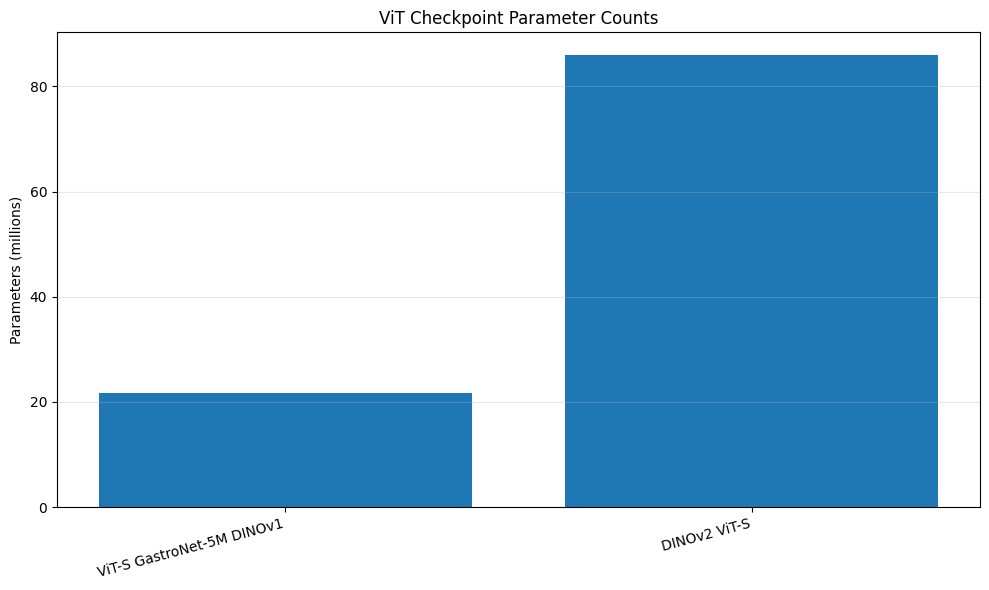

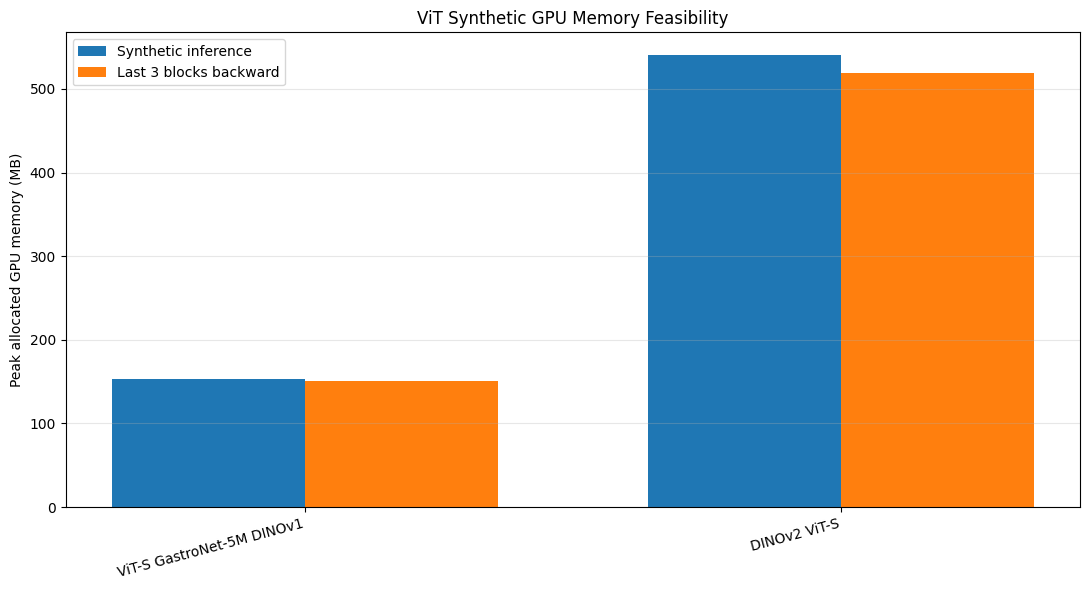


FINAL CELL 16A ViT FEASIBILITY REPORT
Discovered candidates: 2
Exactly compatible candidates: 2
Screening-feasible candidates: 1

--------------------------------------------------------------------------------
ViT-S GastroNet-5M DINOv1
Exact tensor compatibility: True
CPU forward passed: True
GPU smoke test run: True
GPU smoke test passed: True
Screening feasible: True
Decision: ADVANCE_TO_CONTROLLED_VIT_SCREENING
Reason: Exact tensor compatibility, valid 224x224 positional interpolation, CPU forward execution and ViT-S feasibility were verified.

--------------------------------------------------------------------------------
DINOv2 ViT-S
Exact tensor compatibility: True
CPU forward passed: True
GPU smoke test run: True
GPU smoke test passed: True
Screening feasible: False
Decision: DO_NOT_ADVANCE_TO_VIT_SCREENING
Reason: At least one predefined compatibility or feasibility condition failed.

-------------------------------------------------------------------------------------------

In [ ]:
# ==========================================================================================
# CELL 16A — CORRECTED VERSION
# ViT CHECKPOINT ARCHITECTURE COMPATIBILITY AND FEASIBILITY AUDIT
#
# Fix included:
# - The exact filename "dinov2.pth" is now recognized even though it does not contain
#   "vit" or "vits" in its filename.
#
# IMPORTANT:
# - No dataset images are loaded
# - No train/validation/test CSV is loaded
# - No real-image inference is performed
# - No training is performed
# - Held-out test is not accessed
# ==========================================================================================

from pathlib import Path
from datetime import datetime, timezone
from urllib.parse import unquote
from IPython.display import display

import gc
import json
import math
import os
import random
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings("ignore")


# ==========================================================================================
# 1. GOOGLE DRIVE
# ==========================================================================================

DRIVE_ROOT = Path("/content/drive")
MYDRIVE_ROOT = DRIVE_ROOT / "MyDrive"

if not MYDRIVE_ROOT.exists():
    from google.colab import drive
    drive.mount(str(DRIVE_ROOT))

if not MYDRIVE_ROOT.exists():
    raise RuntimeError("Google Drive could not be mounted.")


# ==========================================================================================
# 2. FIXED CONFIGURATION
# ==========================================================================================

CELL_ID = "cell16a_vit_architecture_feasibility_audit_corrected"
AUDIT_SEED = 1601

PROJECT_ROOT = MYDRIVE_ROOT / "RARE26_GastroNet_Weights"
SOURCE_CHECKPOINT_DIR = PROJECT_ROOT / "source_checkpoints"

CELL15B_STATUS_PATH = (
    PROJECT_ROOT
    / "results"
    / "screening"
    / "original_split"
    / "remaining_rn50_checkpoints"
    / "aggregate"
    / "cell15b_status.json"
)

CELL15B_DECISION_PATH = (
    PROJECT_ROOT
    / "results"
    / "screening"
    / "original_split"
    / "remaining_rn50_checkpoints"
    / "aggregate"
    / "cell15b_remaining_rn50_advancement_decision.json"
)

SCREENING_IMAGE_SIZE = 224
GPU_SYNTHETIC_BATCH_SIZE = 4
GPU_LAST_BLOCK_COUNT = 3
RUN_GPU_SMOKE_TEST_IF_AVAILABLE = True

EXPECTED_VIT_SMALL_EMBED_DIM = 384
EXPECTED_VIT_SMALL_DEPTH = 12

FINAL_STATUS = "CELL16A_VIT_ARCHITECTURE_AND_FEASIBILITY_AUDIT_COMPLETE"


# ==========================================================================================
# 3. OUTPUT PATHS
# ==========================================================================================

INVENTORY_DIR = PROJECT_ROOT / "inventory" / "vit_feasibility"
RESULT_DIR = PROJECT_ROOT / "results" / "vit_feasibility"
FIGURE_DIR = PROJECT_ROOT / "figures" / "vit_feasibility"

for directory in [INVENTORY_DIR, RESULT_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

DISCOVERY_PATH = INVENTORY_DIR / "cell16a_vit_checkpoint_discovery.csv"
ARCHITECTURE_PATH = INVENTORY_DIR / "cell16a_vit_architecture_inference.csv"
COMPATIBILITY_PATH = INVENTORY_DIR / "cell16a_vit_tensor_compatibility_audit.csv"
KEY_AUDIT_PATH = INVENTORY_DIR / "cell16a_vit_checkpoint_key_audit.csv"
MEMORY_PATH = RESULT_DIR / "cell16a_vit_memory_feasibility.csv"
DECISION_PATH = RESULT_DIR / "cell16a_vit_feasibility_decision.json"
STATUS_PATH = RESULT_DIR / "cell16a_status.json"
SUMMARY_PATH = RESULT_DIR / "cell16a_vit_feasibility_summary.txt"
PARAMETER_FIGURE_PATH = FIGURE_DIR / "cell16a_vit_parameter_count_comparison.png"
MEMORY_FIGURE_PATH = FIGURE_DIR / "cell16a_vit_memory_feasibility.png"


# ==========================================================================================
# 4. INITIAL REPORT
# ==========================================================================================

print("=" * 108)
print("CELL 16A: ViT CHECKPOINT ARCHITECTURE COMPATIBILITY AND FEASIBILITY AUDIT")
print("=" * 108)

print("\nSource checkpoint directory:")
print(SOURCE_CHECKPOINT_DIR)

print("\nDataset images loaded: False")
print("Train CSV loaded: False")
print("Validation CSV loaded: False")
print("Held-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("New model training performed: False")
print("Real-image inference performed: False")


# ==========================================================================================
# 5. VERIFY CELL 15B
# ==========================================================================================

for required_path in [CELL15B_STATUS_PATH, CELL15B_DECISION_PATH]:
    if not required_path.exists():
        raise FileNotFoundError(
            f"Required Cell 15B record not found:\n{required_path}"
        )

cell15b_status_record = json.loads(
    CELL15B_STATUS_PATH.read_text(encoding="utf-8")
)

cell15b_decision_record = json.loads(
    CELL15B_DECISION_PATH.read_text(encoding="utf-8")
)

cell15b_status = cell15b_status_record.get("status")
cell15b_decision = cell15b_decision_record.get("decision")

if cell15b_status != "CELL15B_REMAINING_RN50_CONTROLLED_SCREENING_COMPLETE":
    raise RuntimeError(
        "Cell 15B is not marked complete.\n"
        f"Actual status: {cell15b_status}"
    )

valid_cell15b_decisions = {
    "NO_REMAINING_RN50_CANDIDATE_ADVANCES",
    "NO_AUTOMATIC_FULL_CV_ADVANCEMENT_BORDERLINE_CANDIDATES_EXIST",
    "ONE_REMAINING_RN50_CANDIDATE_ADVANCES_TO_FULL_CV",
}

if cell15b_decision not in valid_cell15b_decisions:
    raise RuntimeError(
        f"Unexpected Cell 15B decision: {cell15b_decision}"
    )

print("\nCell 15B completion verified:")
print(cell15b_status)

print("\nCell 15B aggregate decision:")
print(cell15b_decision)


# ==========================================================================================
# 6. REPRODUCIBILITY
# ==========================================================================================

os.environ["PYTHONHASHSEED"] = str(AUDIT_SEED)

random.seed(AUDIT_SEED)
np.random.seed(AUDIT_SEED)
torch.manual_seed(AUDIT_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(AUDIT_SEED)


# ==========================================================================================
# 7. ROBUST CHECKPOINT DISCOVERY
# ==========================================================================================

def normalized_filename(path: Path) -> str:
    decoded = unquote(path.name).lower()
    return re.sub(
        r"[^a-z0-9]+",
        "_",
        decoded,
    ).strip("_")


checkpoint_extensions = {
    ".pth",
    ".pt",
    ".ckpt",
}

all_checkpoint_paths = sorted(
    path
    for path in SOURCE_CHECKPOINT_DIR.rglob("*")
    if (
        path.is_file()
        and path.suffix.lower() in checkpoint_extensions
    )
)

if not all_checkpoint_paths:
    raise FileNotFoundError(
        f"No checkpoint files found in:\n{SOURCE_CHECKPOINT_DIR}"
    )


candidate_specs = [
    {
        "candidate_id": "vits_gastronet5m_dinov1",
        "display_name": "ViT-S GastroNet-5M DINOv1",
        "candidate_family": "DINOv1",
    },
    {
        "candidate_id": "vits_dinov2",
        "display_name": "DINOv2 ViT-S",
        "candidate_family": "DINOv2",
    },
]


def candidate_matches(
    path: Path,
    candidate_id: str,
) -> bool:

    name = normalized_filename(path)
    basename = path.name.lower()

    if candidate_id == "vits_gastronet5m_dinov1":

        return bool(
            "gastronet" in name
            and "5m" in name
            and "dino" in name
            and "dinov2" not in name
            and (
                "vits" in name
                or "vit_s" in name
                or name.startswith("vit")
            )
            and "rn50" not in name
            and "resnet" not in name
        )

    if candidate_id == "vits_dinov2":

        exact_or_named_dinov2 = bool(
            basename == "dinov2.pth"
            or basename == "dinov2.pt"
            or "dinov2" in name
        )

        return bool(
            exact_or_named_dinov2
            and "rn50" not in name
            and "resnet" not in name
        )

    return False


discovery_rows = []
resolved_candidates = []

for spec in candidate_specs:

    matches = [
        path
        for path in all_checkpoint_paths
        if candidate_matches(
            path,
            spec["candidate_id"],
        )
    ]

    discovery_rows.append(
        {
            "candidate_id": spec["candidate_id"],
            "display_name": spec["display_name"],
            "candidate_family": spec["candidate_family"],
            "match_count": len(matches),
            "matched_paths": " | ".join(
                str(path)
                for path in matches
            ),
        }
    )

    if len(matches) != 1:

        print(
            f"\nCheckpoint discovery issue for "
            f"{spec['display_name']}"
        )

        print(
            f"Matches found: {len(matches)}"
        )

        for match in matches:
            print(match)

        print("\nAvailable source checkpoints:")

        for available_path in all_checkpoint_paths:
            print(available_path)

        raise RuntimeError(
            "Each ViT candidate must resolve to exactly "
            "one checkpoint file."
        )

    record = dict(spec)

    record["checkpoint_path"] = matches[0]
    record["checkpoint_filename"] = matches[0].name

    resolved_candidates.append(record)


discovery_df = pd.DataFrame(discovery_rows)

discovery_df.to_csv(
    DISCOVERY_PATH,
    index=False,
)

print("\nDiscovered ViT checkpoints:")

display(discovery_df)


# ==========================================================================================
# 8. CHECKPOINT EXTRACTION
# ==========================================================================================

def safe_torch_load(path: Path):

    try:

        return torch.load(
            path,
            map_location="cpu",
            weights_only=False,
        )

    except TypeError:

        return torch.load(
            path,
            map_location="cpu",
        )


def score_tensor_dictionary(
    dictionary,
    path_text: str,
):

    if not isinstance(dictionary, dict):
        return -1, 0, 0

    tensor_keys = [
        str(key)
        for key, value in dictionary.items()
        if torch.is_tensor(value)
    ]

    tensor_count = len(tensor_keys)

    vit_patterns = [
        "patch_embed",
        "pos_embed",
        "cls_token",
        "blocks.",
        "attn.qkv",
        "mlp.fc1",
        "norm.weight",
    ]

    vit_hits = sum(
        any(
            pattern in key
            for pattern in vit_patterns
        )
        for key in tensor_keys
    )

    lower_path = path_text.lower()

    path_bonus = 0

    for token, bonus in {
        "teacher": 100,
        "student": 80,
        "model_state_dict": 60,
        "state_dict": 50,
        "backbone": 40,
        "model": 20,
    }.items():

        if token in lower_path:
            path_bonus = max(
                path_bonus,
                bonus,
            )

    return (
        vit_hits * 1000
        + tensor_count
        + path_bonus,
        vit_hits,
        tensor_count,
    )


def collect_tensor_dictionaries(
    value,
    path_text="root",
    depth=0,
    max_depth=6,
):

    results = []

    if (
        not isinstance(value, dict)
        or depth > max_depth
    ):
        return results

    score, vit_hits, tensor_count = (
        score_tensor_dictionary(
            value,
            path_text,
        )
    )

    if tensor_count > 0:

        results.append(
            {
                "path": path_text,
                "dictionary": value,
                "score": score,
                "vit_hits": vit_hits,
                "tensor_count": tensor_count,
            }
        )

    for key, nested in value.items():

        if isinstance(nested, dict):

            results.extend(
                collect_tensor_dictionaries(
                    nested,
                    path_text=f"{path_text}.{key}",
                    depth=depth + 1,
                    max_depth=max_depth,
                )
            )

    return results


def extract_best_state_dictionary(
    checkpoint_object,
):

    candidates = collect_tensor_dictionaries(
        checkpoint_object
    )

    if not candidates:

        raise RuntimeError(
            "No tensor state dictionary found "
            "inside checkpoint."
        )

    candidates.sort(
        key=lambda item: (
            item["score"],
            item["vit_hits"],
            item["tensor_count"],
        ),
        reverse=True,
    )

    selected = candidates[0]

    tensor_state = {
        str(key): value
        for key, value
        in selected["dictionary"].items()
        if torch.is_tensor(value)
    }

    return (
        tensor_state,
        selected["path"],
        candidates,
    )


# ==========================================================================================
# 9. KEY NORMALIZATION
# ==========================================================================================

KNOWN_PREFIXES = [
    "module.",
    "model.",
    "network.",
    "encoder.",
    "backbone.",
    "student.",
    "teacher.",
    "base_encoder.",
    "online_encoder.",
    "momentum_encoder.",
    "target_encoder.",
    "trunk.",
    "visual.",
    "transformer.",
]


def remove_known_prefixes(
    key: str,
) -> str:

    cleaned = str(key)

    changed = True

    while changed:

        changed = False

        for prefix in KNOWN_PREFIXES:

            if cleaned.startswith(prefix):

                cleaned = cleaned[
                    len(prefix):
                ]

                changed = True

    return cleaned


def normalize_vit_state_dictionary(
    raw_state,
):

    normalized = {}

    for raw_key, tensor in raw_state.items():

        key = remove_known_prefixes(
            raw_key
        )

        gamma_1 = re.match(
            r"^(blocks\.\d+)\.gamma_1$",
            key,
        )

        gamma_2 = re.match(
            r"^(blocks\.\d+)\.gamma_2$",
            key,
        )

        if gamma_1:

            key = (
                f"{gamma_1.group(1)}."
                "ls1.gamma"
            )

        elif gamma_2:

            key = (
                f"{gamma_2.group(1)}."
                "ls2.gamma"
            )

        normalized[key] = tensor

    return normalized


def is_backbone_key(
    key: str,
) -> bool:

    exact_keys = {
        "cls_token",
        "pos_embed",
        "register_tokens",
        "mask_token",
    }

    prefixes = (
        "patch_embed.",
        "blocks.",
        "norm.",
    )

    return bool(
        key in exact_keys
        or key.startswith(prefixes)
    )


def filter_backbone_state_dictionary(
    normalized_state,
):

    return {
        key: value
        for key, value
        in normalized_state.items()
        if is_backbone_key(key)
    }


# ==========================================================================================
# 10. ARCHITECTURE INFERENCE
# ==========================================================================================

def require_tensor(
    state,
    key,
):

    if key not in state:

        raise KeyError(
            f"Required ViT tensor missing: {key}"
        )

    return state[key]


def infer_attention_heads(
    embed_dim: int,
):

    canonical = {
        192: 3,
        384: 6,
        768: 12,
        1024: 16,
        1280: 16,
        1536: 24,
    }

    if embed_dim in canonical:

        return (
            canonical[embed_dim],
            "canonical_mapping",
        )

    possible = [
        head
        for head in [
            3,
            4,
            6,
            8,
            12,
            16,
            24,
        ]
        if embed_dim % head == 0
    ]

    if not possible:

        raise RuntimeError(
            "Could not infer attention heads for "
            f"embed_dim={embed_dim}"
        )

    chosen = min(
        possible,
        key=lambda head: abs(
            embed_dim / head - 64
        ),
    )

    return (
        chosen,
        "head_dimension_nearest_64",
    )


def infer_architecture(
    state,
):

    patch_weight = require_tensor(
        state,
        "patch_embed.proj.weight",
    )

    cls_token = require_tensor(
        state,
        "cls_token",
    )

    pos_embed = require_tensor(
        state,
        "pos_embed",
    )

    if patch_weight.ndim != 4:

        raise RuntimeError(
            "patch_embed.proj.weight is not "
            "a Conv2d tensor."
        )

    embed_dim = int(
        patch_weight.shape[0]
    )

    input_channels = int(
        patch_weight.shape[1]
    )

    patch_h = int(
        patch_weight.shape[2]
    )

    patch_w = int(
        patch_weight.shape[3]
    )

    if patch_h != patch_w:

        raise RuntimeError(
            "Only square ViT patches are supported."
        )

    block_indices = sorted(
        {
            int(match.group(1))
            for key in state
            for match in [
                re.match(
                    r"^blocks\.(\d+)\.",
                    key,
                )
            ]
            if match is not None
        }
    )

    if not block_indices:

        raise RuntimeError(
            "No transformer blocks detected."
        )

    expected_block_indices = list(
        range(
            max(block_indices) + 1
        )
    )

    if block_indices != expected_block_indices:

        raise RuntimeError(
            "Non-contiguous transformer blocks: "
            f"{block_indices}"
        )

    depth = len(block_indices)

    qkv_weight = require_tensor(
        state,
        "blocks.0.attn.qkv.weight",
    )

    if tuple(qkv_weight.shape) != (
        embed_dim * 3,
        embed_dim,
    ):

        raise RuntimeError(
            "Unexpected QKV shape: "
            f"{tuple(qkv_weight.shape)}"
        )

    fc1_weight = require_tensor(
        state,
        "blocks.0.mlp.fc1.weight",
    )

    mlp_hidden_dim = int(
        fc1_weight.shape[0]
    )

    heads, head_method = (
        infer_attention_heads(
            embed_dim
        )
    )

    register_count = 0
    register_shape = None

    if "register_tokens" in state:

        register_shape = tuple(
            state["register_tokens"].shape
        )

        register_count = int(
            state["register_tokens"].shape[1]
        )

    positional_token_count = int(
        pos_embed.shape[1]
    )

    candidate_layouts = [
        (
            "pos_embed_excludes_register_tokens",
            positional_token_count - 1,
        ),
    ]

    if register_count > 0:

        candidate_layouts.append(
            (
                "pos_embed_includes_register_tokens",
                positional_token_count
                - 1
                - register_count,
            )
        )

    positional_layout = None
    reference_grid_size = None
    patch_token_count = None

    for layout_name, candidate_count in candidate_layouts:

        if candidate_count <= 0:
            continue

        grid = int(
            round(
                math.sqrt(
                    candidate_count
                )
            )
        )

        if grid * grid == candidate_count:

            positional_layout = layout_name
            reference_grid_size = grid
            patch_token_count = candidate_count
            break

    if positional_layout is None:

        raise RuntimeError(
            "Could not infer square positional grid.\n"
            f"pos_embed tokens={positional_token_count}, "
            f"register_count={register_count}"
        )

    patch_size = patch_h

    reference_image_size = (
        reference_grid_size
        * patch_size
    )

    if SCREENING_IMAGE_SIZE % patch_size != 0:

        raise RuntimeError(
            f"Screening image size {SCREENING_IMAGE_SIZE} "
            f"is not divisible by patch size {patch_size}."
        )

    return {
        "embedding_dimension": embed_dim,
        "input_channels": input_channels,
        "patch_size": patch_size,
        "depth": depth,
        "attention_heads": heads,
        "attention_head_dimension": (
            embed_dim // heads
        ),
        "attention_head_inference_method": (
            head_method
        ),
        "mlp_hidden_dimension": (
            mlp_hidden_dim
        ),
        "mlp_ratio": (
            mlp_hidden_dim / embed_dim
        ),
        "qkv_bias": (
            "blocks.0.attn.qkv.bias"
            in state
        ),
        "attention_projection_bias": (
            "blocks.0.attn.proj.bias"
            in state
        ),
        "mlp_fc1_bias": (
            "blocks.0.mlp.fc1.bias"
            in state
        ),
        "mlp_fc2_bias": (
            "blocks.0.mlp.fc2.bias"
            in state
        ),
        "patch_projection_bias": (
            "patch_embed.proj.bias"
            in state
        ),
        "layer_scale": (
            "blocks.0.ls1.gamma"
            in state
        ),
        "register_token_count": (
            register_count
        ),
        "register_token_shape": str(
            register_shape
        ),
        "mask_token_present": (
            "mask_token"
            in state
        ),
        "mask_token_shape": (
            str(
                tuple(
                    state["mask_token"].shape
                )
            )
            if "mask_token" in state
            else None
        ),
        "positional_token_count": (
            positional_token_count
        ),
        "patch_token_count": (
            patch_token_count
        ),
        "reference_grid_size": (
            reference_grid_size
        ),
        "checkpoint_reference_image_size": (
            reference_image_size
        ),
        "screening_image_size": (
            SCREENING_IMAGE_SIZE
        ),
        "screening_grid_size": (
            SCREENING_IMAGE_SIZE
            // patch_size
        ),
        "positional_layout": (
            positional_layout
        ),
        "cls_token_shape": str(
            tuple(
                cls_token.shape
            )
        ),
        "pos_embed_shape": str(
            tuple(
                pos_embed.shape
            )
        ),
    }


# ==========================================================================================
# 11. AUDITABLE ViT BACKBONE
# ==========================================================================================

class PatchEmbed(nn.Module):

    def __init__(
        self,
        in_channels,
        embed_dim,
        patch_size,
        bias,
    ):

        super().__init__()

        self.proj = nn.Conv2d(
            in_channels,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size,
            bias=bias,
        )

    def forward(
        self,
        x,
    ):

        return (
            self.proj(x)
            .flatten(2)
            .transpose(1, 2)
        )


class Attention(nn.Module):

    def __init__(
        self,
        embed_dim,
        num_heads,
        qkv_bias,
        proj_bias,
    ):

        super().__init__()

        self.num_heads = num_heads

        self.head_dim = (
            embed_dim
            // num_heads
        )

        self.scale = (
            self.head_dim
            ** -0.5
        )

        self.qkv = nn.Linear(
            embed_dim,
            embed_dim * 3,
            bias=qkv_bias,
        )

        self.proj = nn.Linear(
            embed_dim,
            embed_dim,
            bias=proj_bias,
        )

    def forward(
        self,
        x,
    ):

        batch, tokens, embed_dim = x.shape

        qkv = (
            self.qkv(x)
            .reshape(
                batch,
                tokens,
                3,
                self.num_heads,
                self.head_dim,
            )
            .permute(
                2,
                0,
                3,
                1,
                4,
            )
        )

        q, k, v = (
            qkv[0],
            qkv[1],
            qkv[2],
        )

        if hasattr(
            F,
            "scaled_dot_product_attention",
        ):

            output = (
                F.scaled_dot_product_attention(
                    q,
                    k,
                    v,
                    dropout_p=0.0,
                    is_causal=False,
                )
            )

        else:

            attention = (
                q
                @ k.transpose(
                    -2,
                    -1,
                )
            ) * self.scale

            attention = attention.softmax(
                dim=-1
            )

            output = (
                attention
                @ v
            )

        output = (
            output.transpose(
                1,
                2,
            )
            .reshape(
                batch,
                tokens,
                embed_dim,
            )
        )

        return self.proj(output)


class MLP(nn.Module):

    def __init__(
        self,
        embed_dim,
        hidden_dim,
        fc1_bias,
        fc2_bias,
    ):

        super().__init__()

        self.fc1 = nn.Linear(
            embed_dim,
            hidden_dim,
            bias=fc1_bias,
        )

        self.act = nn.GELU()

        self.fc2 = nn.Linear(
            hidden_dim,
            embed_dim,
            bias=fc2_bias,
        )

    def forward(
        self,
        x,
    ):

        return self.fc2(
            self.act(
                self.fc1(x)
            )
        )


class LayerScale(nn.Module):

    def __init__(
        self,
        embed_dim,
    ):

        super().__init__()

        self.gamma = nn.Parameter(
            torch.ones(
                embed_dim
            )
        )

    def forward(
        self,
        x,
    ):

        return x * self.gamma


class TransformerBlock(nn.Module):

    def __init__(
        self,
        embed_dim,
        num_heads,
        mlp_hidden_dim,
        qkv_bias,
        proj_bias,
        fc1_bias,
        fc2_bias,
        use_layer_scale,
    ):

        super().__init__()

        self.norm1 = nn.LayerNorm(
            embed_dim,
            eps=1e-6,
        )

        self.attn = Attention(
            embed_dim,
            num_heads,
            qkv_bias,
            proj_bias,
        )

        self.norm2 = nn.LayerNorm(
            embed_dim,
            eps=1e-6,
        )

        self.mlp = MLP(
            embed_dim,
            mlp_hidden_dim,
            fc1_bias,
            fc2_bias,
        )

        self.ls1 = (
            LayerScale(embed_dim)
            if use_layer_scale
            else nn.Identity()
        )

        self.ls2 = (
            LayerScale(embed_dim)
            if use_layer_scale
            else nn.Identity()
        )

    def forward(
        self,
        x,
    ):

        x = x + self.ls1(
            self.attn(
                self.norm1(x)
            )
        )

        x = x + self.ls2(
            self.mlp(
                self.norm2(x)
            )
        )

        return x


class AuditableVisionTransformer(nn.Module):

    def __init__(
        self,
        architecture,
        source_state,
    ):

        super().__init__()

        self.embed_dim = int(
            architecture[
                "embedding_dimension"
            ]
        )

        self.patch_size = int(
            architecture[
                "patch_size"
            ]
        )

        self.reference_grid_size = int(
            architecture[
                "reference_grid_size"
            ]
        )

        self.register_count = int(
            architecture[
                "register_token_count"
            ]
        )

        self.positional_layout = (
            architecture[
                "positional_layout"
            ]
        )

        self.patch_embed = PatchEmbed(
            int(
                architecture[
                    "input_channels"
                ]
            ),
            self.embed_dim,
            self.patch_size,
            bool(
                architecture[
                    "patch_projection_bias"
                ]
            ),
        )

        self.cls_token = nn.Parameter(
            torch.zeros_like(
                source_state[
                    "cls_token"
                ]
            )
        )

        self.pos_embed = nn.Parameter(
            torch.zeros_like(
                source_state[
                    "pos_embed"
                ]
            )
        )

        if "register_tokens" in source_state:

            self.register_tokens = nn.Parameter(
                torch.zeros_like(
                    source_state[
                        "register_tokens"
                    ]
                )
            )

        if "mask_token" in source_state:

            self.mask_token = nn.Parameter(
                torch.zeros_like(
                    source_state[
                        "mask_token"
                    ]
                )
            )

        self.blocks = nn.ModuleList(
            [
                TransformerBlock(
                    embed_dim=self.embed_dim,
                    num_heads=int(
                        architecture[
                            "attention_heads"
                        ]
                    ),
                    mlp_hidden_dim=int(
                        architecture[
                            "mlp_hidden_dimension"
                        ]
                    ),
                    qkv_bias=bool(
                        architecture[
                            "qkv_bias"
                        ]
                    ),
                    proj_bias=bool(
                        architecture[
                            "attention_projection_bias"
                        ]
                    ),
                    fc1_bias=bool(
                        architecture[
                            "mlp_fc1_bias"
                        ]
                    ),
                    fc2_bias=bool(
                        architecture[
                            "mlp_fc2_bias"
                        ]
                    ),
                    use_layer_scale=bool(
                        architecture[
                            "layer_scale"
                        ]
                    ),
                )
                for _ in range(
                    int(
                        architecture[
                            "depth"
                        ]
                    )
                )
            ]
        )

        self.norm = nn.LayerNorm(
            self.embed_dim,
            eps=1e-6,
        )

    def interpolated_patch_positions(
        self,
        grid_h,
        grid_w,
    ):

        if self.positional_layout == (
            "pos_embed_excludes_register_tokens"
        ):

            prefix_positions = (
                self.pos_embed[:, :1]
            )

            patch_positions = (
                self.pos_embed[:, 1:]
            )

        else:

            prefix_count = (
                1
                + self.register_count
            )

            prefix_positions = (
                self.pos_embed[
                    :,
                    :prefix_count,
                ]
            )

            patch_positions = (
                self.pos_embed[
                    :,
                    prefix_count:,
                ]
            )

        if (
            grid_h
            == self.reference_grid_size
            and grid_w
            == self.reference_grid_size
        ):

            return (
                prefix_positions,
                patch_positions,
            )

        patch_positions = (
            patch_positions.reshape(
                1,
                self.reference_grid_size,
                self.reference_grid_size,
                self.embed_dim,
            )
            .permute(
                0,
                3,
                1,
                2,
            )
        )

        patch_positions = F.interpolate(
            patch_positions,
            size=(
                grid_h,
                grid_w,
            ),
            mode="bicubic",
            align_corners=False,
        )

        patch_positions = (
            patch_positions.permute(
                0,
                2,
                3,
                1,
            )
            .reshape(
                1,
                grid_h * grid_w,
                self.embed_dim,
            )
        )

        return (
            prefix_positions,
            patch_positions,
        )

    def forward_features(
        self,
        images,
    ):

        patch_tokens = (
            self.patch_embed(images)
        )

        batch_size = (
            patch_tokens.shape[0]
        )

        grid_h = (
            images.shape[2]
            // self.patch_size
        )

        grid_w = (
            images.shape[3]
            // self.patch_size
        )

        cls_tokens = (
            self.cls_token.expand(
                batch_size,
                -1,
                -1,
            )
        )

        (
            prefix_positions,
            patch_positions,
        ) = (
            self.interpolated_patch_positions(
                grid_h,
                grid_w,
            )
        )

        if self.positional_layout == (
            "pos_embed_excludes_register_tokens"
        ):

            cls_tokens = (
                cls_tokens
                + prefix_positions[:, :1]
            )

            patch_tokens = (
                patch_tokens
                + patch_positions
            )

            token_parts = [
                cls_tokens
            ]

            if self.register_count > 0:

                token_parts.append(
                    self.register_tokens.expand(
                        batch_size,
                        -1,
                        -1,
                    )
                )

            token_parts.append(
                patch_tokens
            )

            tokens = torch.cat(
                token_parts,
                dim=1,
            )

        else:

            prefix_parts = [
                cls_tokens
            ]

            if self.register_count > 0:

                prefix_parts.append(
                    self.register_tokens.expand(
                        batch_size,
                        -1,
                        -1,
                    )
                )

            prefix_tokens = torch.cat(
                prefix_parts,
                dim=1,
            )

            prefix_tokens = (
                prefix_tokens
                + prefix_positions
            )

            patch_tokens = (
                patch_tokens
                + patch_positions
            )

            tokens = torch.cat(
                [
                    prefix_tokens,
                    patch_tokens,
                ],
                dim=1,
            )

        for block in self.blocks:

            tokens = block(tokens)

        return self.norm(tokens)

    def forward(
        self,
        images,
    ):

        return (
            self.forward_features(
                images
            )[:, 0]
        )


# ==========================================================================================
# 12. SMOKE TESTS
# ==========================================================================================

def parameter_memory_mb(
    parameter_count,
    bytes_per_parameter,
):

    return (
        parameter_count
        * bytes_per_parameter
        / (1024 ** 2)
    )


def run_cpu_smoke_test(
    model,
    image_size,
):

    model = model.cpu().eval()

    synthetic = torch.randn(
        1,
        3,
        image_size,
        image_size,
    )

    with torch.no_grad():

        output = model(
            synthetic
        )

    expected_shape = (
        1,
        model.embed_dim,
    )

    if tuple(output.shape) != expected_shape:

        raise RuntimeError(
            "Unexpected CPU output shape. "
            f"Expected {expected_shape}, "
            f"found {tuple(output.shape)}"
        )

    if not torch.isfinite(output).all():

        raise RuntimeError(
            "CPU smoke-test output contains "
            "non-finite values."
        )

    del synthetic
    del output

    gc.collect()

    return True


def run_gpu_smoke_test(
    model,
    image_size,
    batch_size,
    last_block_count,
):

    result = {
        "gpu_smoke_test_run": False,
        "gpu_smoke_test_passed": False,
        "gpu_name": None,
        "gpu_total_memory_mb": None,
        "gpu_inference_peak_memory_mb": None,
        "gpu_partial_finetune_peak_memory_mb": None,
        "gpu_smoke_test_error": None,
    }

    if not torch.cuda.is_available():

        result[
            "gpu_smoke_test_error"
        ] = "CUDA_NOT_AVAILABLE"

        return result

    device = torch.device("cuda")

    result[
        "gpu_smoke_test_run"
    ] = True

    result[
        "gpu_name"
    ] = torch.cuda.get_device_name(0)

    result[
        "gpu_total_memory_mb"
    ] = (
        torch.cuda.get_device_properties(
            0
        ).total_memory
        / (1024 ** 2)
    )

    try:

        model = model.to(
            device
        ).eval()

        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

        synthetic = torch.randn(
            batch_size,
            3,
            image_size,
            image_size,
            device=device,
        )

        with (
            torch.no_grad(),
            torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
            ),
        ):

            output = model(
                synthetic
            )

        torch.cuda.synchronize()

        result[
            "gpu_inference_peak_memory_mb"
        ] = (
            torch.cuda.max_memory_allocated()
            / (1024 ** 2)
        )

        del synthetic
        del output

        torch.cuda.empty_cache()

        for parameter in model.parameters():

            parameter.requires_grad = False

        for block in list(
            model.blocks[
                -last_block_count:
            ]
        ):

            for parameter in block.parameters():

                parameter.requires_grad = True

        for parameter in model.norm.parameters():

            parameter.requires_grad = True

        head = nn.Linear(
            model.embed_dim,
            1,
        ).to(device)

        torch.cuda.reset_peak_memory_stats()

        synthetic = torch.randn(
            batch_size,
            3,
            image_size,
            image_size,
            device=device,
        )

        target = torch.randint(
            0,
            2,
            (
                batch_size,
            ),
            device=device,
        ).float()

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
        ):

            embeddings = model(
                synthetic
            )

            logits = head(
                embeddings
            ).squeeze(1)

            loss = (
                F.binary_cross_entropy_with_logits(
                    logits,
                    target,
                )
            )

        loss.backward()

        torch.cuda.synchronize()

        result[
            "gpu_partial_finetune_peak_memory_mb"
        ] = (
            torch.cuda.max_memory_allocated()
            / (1024 ** 2)
        )

        result[
            "gpu_smoke_test_passed"
        ] = True

        del synthetic
        del target
        del embeddings
        del logits
        del loss
        del head

        model = model.cpu()

        torch.cuda.empty_cache()
        gc.collect()

    except Exception as error:

        result[
            "gpu_smoke_test_error"
        ] = str(error)

        try:
            model = model.cpu()
        except Exception:
            pass

        torch.cuda.empty_cache()
        gc.collect()

    return result


# ==========================================================================================
# 13. AUDIT BOTH CHECKPOINTS
# ==========================================================================================

architecture_rows = []
compatibility_rows = []
key_audit_rows = []
memory_rows = []
candidate_decisions = []

for candidate in resolved_candidates:

    candidate_id = candidate[
        "candidate_id"
    ]

    display_name = candidate[
        "display_name"
    ]

    checkpoint_path = candidate[
        "checkpoint_path"
    ]

    print("\n" + "-" * 108)

    print(
        f"AUDITING: {display_name}"
    )

    print(
        f"Checkpoint: {checkpoint_path}"
    )

    print("-" * 108)

    try:

        checkpoint_object = safe_torch_load(
            checkpoint_path
        )

        (
            raw_state,
            selected_dictionary_path,
            dictionary_candidates,
        ) = extract_best_state_dictionary(
            checkpoint_object
        )

        normalized_state = (
            normalize_vit_state_dictionary(
                raw_state
            )
        )

        backbone_state = (
            filter_backbone_state_dictionary(
                normalized_state
            )
        )

        architecture = infer_architecture(
            backbone_state
        )

        model = AuditableVisionTransformer(
            architecture,
            backbone_state,
        )

        expected_state = (
            model.state_dict()
        )

        expected_keys = set(
            expected_state
        )

        checkpoint_keys = set(
            backbone_state
        )

        missing_keys = sorted(
            expected_keys
            - checkpoint_keys
        )

        unexpected_keys = sorted(
            checkpoint_keys
            - expected_keys
        )

        shape_mismatches = []

        for key in sorted(
            expected_keys
            & checkpoint_keys
        ):

            expected_shape = tuple(
                expected_state[
                    key
                ].shape
            )

            checkpoint_shape = tuple(
                backbone_state[
                    key
                ].shape
            )

            if (
                expected_shape
                != checkpoint_shape
            ):

                shape_mismatches.append(
                    {
                        "key": key,
                        "expected_shape": (
                            expected_shape
                        ),
                        "checkpoint_shape": (
                            checkpoint_shape
                        ),
                    }
                )

        if (
            missing_keys
            or shape_mismatches
        ):

            raise RuntimeError(
                "Exact ViT tensor compatibility failed.\n"
                f"Missing keys: {missing_keys[:20]}\n"
                f"Shape mismatches: "
                f"{shape_mismatches[:10]}"
            )

        if unexpected_keys:

            raise RuntimeError(
                "Unexpected filtered backbone keys "
                "were found.\n"
                f"Examples: {unexpected_keys[:20]}"
            )

        model.load_state_dict(
            backbone_state,
            strict=True,
        )

        cpu_forward_passed = (
            run_cpu_smoke_test(
                model,
                SCREENING_IMAGE_SIZE,
            )
        )

        total_parameters = sum(
            parameter.numel()
            for parameter
            in model.parameters()
        )

        architecture_matches_vit_small = bool(
            architecture[
                "embedding_dimension"
            ]
            == EXPECTED_VIT_SMALL_EMBED_DIM
            and architecture[
                "depth"
            ]
            == EXPECTED_VIT_SMALL_DEPTH
        )

        parameter_count_feasible = bool(
            total_parameters
            <= 30_000_000
        )

        screening_image_feasible = bool(
            SCREENING_IMAGE_SIZE
            % architecture[
                "patch_size"
            ]
            == 0
        )

        gpu_result = {
            "gpu_smoke_test_run": False,
            "gpu_smoke_test_passed": False,
            "gpu_name": None,
            "gpu_total_memory_mb": None,
            "gpu_inference_peak_memory_mb": None,
            "gpu_partial_finetune_peak_memory_mb": None,
            "gpu_smoke_test_error": None,
        }

        if (
            RUN_GPU_SMOKE_TEST_IF_AVAILABLE
            and torch.cuda.is_available()
        ):

            gpu_result = run_gpu_smoke_test(
                model,
                image_size=(
                    SCREENING_IMAGE_SIZE
                ),
                batch_size=(
                    GPU_SYNTHETIC_BATCH_SIZE
                ),
                last_block_count=(
                    GPU_LAST_BLOCK_COUNT
                ),
            )

        gpu_feasible = bool(
            not gpu_result[
                "gpu_smoke_test_run"
            ]
            or gpu_result[
                "gpu_smoke_test_passed"
            ]
        )

        screening_feasible = bool(
            architecture_matches_vit_small
            and parameter_count_feasible
            and screening_image_feasible
            and cpu_forward_passed
            and gpu_feasible
        )

        decision = (
            "ADVANCE_TO_CONTROLLED_VIT_SCREENING"
            if screening_feasible
            else "DO_NOT_ADVANCE_TO_VIT_SCREENING"
        )

        decision_reason = (
            "Exact tensor compatibility, valid 224x224 "
            "positional interpolation, CPU forward execution "
            "and ViT-S feasibility were verified."
            if screening_feasible
            else
            "At least one predefined compatibility or "
            "feasibility condition failed."
        )

        matched_tensor_count = len(
            expected_state
        )

        tensor_coverage = 1.0

        architecture_rows.append(
            {
                "candidate_id": candidate_id,
                "display_name": display_name,
                "candidate_family": (
                    candidate[
                        "candidate_family"
                    ]
                ),
                "checkpoint_path": str(
                    checkpoint_path
                ),
                "selected_dictionary_path": (
                    selected_dictionary_path
                ),
                **architecture,
                "architecture_matches_vit_small": (
                    architecture_matches_vit_small
                ),
            }
        )

        compatibility_rows.append(
            {
                "candidate_id": candidate_id,
                "display_name": display_name,
                "checkpoint_path": str(
                    checkpoint_path
                ),
                "compatibility_status": (
                    "EXACTLY_COMPATIBLE"
                ),
                "raw_tensor_count": len(
                    raw_state
                ),
                "normalized_tensor_count": len(
                    normalized_state
                ),
                "backbone_checkpoint_tensor_count": len(
                    backbone_state
                ),
                "expected_model_tensor_count": len(
                    expected_state
                ),
                "matched_tensor_count": (
                    matched_tensor_count
                ),
                "tensor_coverage": (
                    tensor_coverage
                ),
                "missing_model_key_count": 0,
                "unexpected_checkpoint_key_count": 0,
                "shape_mismatch_count": 0,
                "missing_model_keys": "",
                "unexpected_checkpoint_keys": "",
                "shape_mismatches": "",
                "cpu_forward_passed": (
                    cpu_forward_passed
                ),
                "compatibility_error": "",
            }
        )

        memory_rows.append(
            {
                "candidate_id": candidate_id,
                "display_name": display_name,
                "total_parameter_count": (
                    total_parameters
                ),
                "parameter_memory_fp32_mb": (
                    parameter_memory_mb(
                        total_parameters,
                        4,
                    )
                ),
                "parameter_memory_fp16_mb": (
                    parameter_memory_mb(
                        total_parameters,
                        2,
                    )
                ),
                "approximate_adam_parameter_state_mb": (
                    parameter_memory_mb(
                        total_parameters,
                        16,
                    )
                ),
                "screening_image_size": (
                    SCREENING_IMAGE_SIZE
                ),
                "synthetic_gpu_batch_size": (
                    GPU_SYNTHETIC_BATCH_SIZE
                ),
                "synthetic_unfrozen_last_blocks": (
                    GPU_LAST_BLOCK_COUNT
                ),
                **gpu_result,
                "architecture_matches_vit_small": (
                    architecture_matches_vit_small
                ),
                "screening_image_feasible": (
                    screening_image_feasible
                ),
                "parameter_count_feasible": (
                    parameter_count_feasible
                ),
                "gpu_empirically_feasible": (
                    gpu_feasible
                ),
                "screening_feasible": (
                    screening_feasible
                ),
            }
        )

        candidate_decisions.append(
            {
                "candidate_id": candidate_id,
                "display_name": display_name,
                "checkpoint_path": str(
                    checkpoint_path
                ),
                "candidate_family": (
                    candidate[
                        "candidate_family"
                    ]
                ),
                "architecture": architecture,
                "exact_tensor_compatibility": True,
                "cpu_forward_passed": (
                    cpu_forward_passed
                ),
                "gpu_smoke_test_run": (
                    gpu_result[
                        "gpu_smoke_test_run"
                    ]
                ),
                "gpu_smoke_test_passed": (
                    gpu_result[
                        "gpu_smoke_test_passed"
                    ]
                ),
                "screening_feasible": (
                    screening_feasible
                ),
                "decision": decision,
                "decision_reason": (
                    decision_reason
                ),
            }
        )

        for key, tensor in sorted(
            normalized_state.items()
        ):

            key_audit_rows.append(
                {
                    "candidate_id": (
                        candidate_id
                    ),
                    "display_name": (
                        display_name
                    ),
                    "normalized_key": key,
                    "tensor_shape": str(
                        tuple(
                            tensor.shape
                        )
                    ),
                    "is_selected_backbone_key": (
                        key
                        in backbone_state
                    ),
                    "is_expected_model_key": (
                        key
                        in expected_state
                    ),
                }
            )

        print("\nInferred architecture:")

        display(
            pd.DataFrame(
                [
                    {
                        "candidate_id": (
                            candidate_id
                        ),
                        **architecture,
                    }
                ]
            )
        )

        print("\nCompatibility:")

        print(
            f"Matched tensors: "
            f"{matched_tensor_count}/"
            f"{len(expected_state)}"
        )

        print(
            f"Tensor coverage: "
            f"{tensor_coverage:.6f}"
        )

        print(
            f"CPU forward passed: "
            f"{cpu_forward_passed}"
        )

        print(
            f"Total parameters: "
            f"{total_parameters:,}"
        )

        if gpu_result[
            "gpu_smoke_test_run"
        ]:

            print(
                f"GPU: "
                f"{gpu_result['gpu_name']}"
            )

            print(
                "GPU inference peak memory: "
                f"{gpu_result['gpu_inference_peak_memory_mb']:.2f} MB"
            )

            print(
                "GPU partial-finetune peak memory: "
                f"{gpu_result['gpu_partial_finetune_peak_memory_mb']:.2f} MB"
            )

            print(
                "GPU smoke test passed: "
                f"{gpu_result['gpu_smoke_test_passed']}"
            )

        else:

            print(
                "GPU smoke test run: False"
            )

        print(
            f"Feasibility decision: "
            f"{decision}"
        )

        del model
        del checkpoint_object
        del raw_state
        del normalized_state
        del backbone_state

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    except Exception as error:

        error_text = str(error)

        compatibility_rows.append(
            {
                "candidate_id": candidate_id,
                "display_name": display_name,
                "checkpoint_path": str(
                    checkpoint_path
                ),
                "compatibility_status": (
                    "INCOMPATIBLE_OR_UNSUPPORTED"
                ),
                "raw_tensor_count": np.nan,
                "normalized_tensor_count": np.nan,
                "backbone_checkpoint_tensor_count": np.nan,
                "expected_model_tensor_count": np.nan,
                "matched_tensor_count": 0,
                "tensor_coverage": 0.0,
                "missing_model_key_count": np.nan,
                "unexpected_checkpoint_key_count": np.nan,
                "shape_mismatch_count": np.nan,
                "missing_model_keys": "",
                "unexpected_checkpoint_keys": "",
                "shape_mismatches": "",
                "cpu_forward_passed": False,
                "compatibility_error": (
                    error_text
                ),
            }
        )

        memory_rows.append(
            {
                "candidate_id": candidate_id,
                "display_name": display_name,
                "total_parameter_count": np.nan,
                "parameter_memory_fp32_mb": np.nan,
                "parameter_memory_fp16_mb": np.nan,
                "approximate_adam_parameter_state_mb": np.nan,
                "screening_image_size": (
                    SCREENING_IMAGE_SIZE
                ),
                "synthetic_gpu_batch_size": (
                    GPU_SYNTHETIC_BATCH_SIZE
                ),
                "synthetic_unfrozen_last_blocks": (
                    GPU_LAST_BLOCK_COUNT
                ),
                "gpu_smoke_test_run": False,
                "gpu_smoke_test_passed": False,
                "gpu_name": None,
                "gpu_total_memory_mb": None,
                "gpu_inference_peak_memory_mb": None,
                "gpu_partial_finetune_peak_memory_mb": None,
                "gpu_smoke_test_error": (
                    error_text
                ),
                "architecture_matches_vit_small": False,
                "screening_image_feasible": False,
                "parameter_count_feasible": False,
                "gpu_empirically_feasible": False,
                "screening_feasible": False,
            }
        )

        candidate_decisions.append(
            {
                "candidate_id": candidate_id,
                "display_name": display_name,
                "checkpoint_path": str(
                    checkpoint_path
                ),
                "candidate_family": (
                    candidate[
                        "candidate_family"
                    ]
                ),
                "architecture": None,
                "exact_tensor_compatibility": False,
                "cpu_forward_passed": False,
                "gpu_smoke_test_run": False,
                "gpu_smoke_test_passed": False,
                "screening_feasible": False,
                "decision": (
                    "DO_NOT_ADVANCE_TO_VIT_SCREENING"
                ),
                "decision_reason": (
                    error_text
                ),
            }
        )

        print(
            "\nCompatibility audit failed:"
        )

        print(
            error_text
        )

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# ==========================================================================================
# 14. SAVE TABLES
# ==========================================================================================

architecture_df = pd.DataFrame(
    architecture_rows
)

compatibility_df = pd.DataFrame(
    compatibility_rows
)

key_audit_df = pd.DataFrame(
    key_audit_rows
)

memory_df = pd.DataFrame(
    memory_rows
)

architecture_df.to_csv(
    ARCHITECTURE_PATH,
    index=False,
)

compatibility_df.to_csv(
    COMPATIBILITY_PATH,
    index=False,
)

key_audit_df.to_csv(
    KEY_AUDIT_PATH,
    index=False,
)

memory_df.to_csv(
    MEMORY_PATH,
    index=False,
)

print("\n" + "=" * 108)

print(
    "ViT ARCHITECTURE INFERENCE"
)

print("=" * 108)

display(
    architecture_df
)

print(
    "\nViT TENSOR COMPATIBILITY:"
)

display(
    compatibility_df
)

print(
    "\nViT MEMORY FEASIBILITY:"
)

display(
    memory_df
)


# ==========================================================================================
# 15. AGGREGATE DECISION
# ==========================================================================================

feasible_candidates = [
    record
    for record in candidate_decisions
    if record[
        "screening_feasible"
    ]
]

feasible_candidate_ids = [
    record[
        "candidate_id"
    ]
    for record in feasible_candidates
]

if len(feasible_candidates) == 2:

    aggregate_decision = (
        "BOTH_VIT_CHECKPOINTS_ADVANCE_TO_CONTROLLED_SCREENING"
    )

    recommended_next_action = (
        "Run Cell 16B controlled original-split screening "
        "for both ViT checkpoints using one fixed seed, "
        "224x224 inputs, architecture-specific patch sizes, "
        "identical clinical safety constraints and no "
        "held-out test access."
    )

elif len(feasible_candidates) == 1:

    aggregate_decision = (
        "ONE_VIT_CHECKPOINT_ADVANCES_TO_CONTROLLED_SCREENING"
    )

    recommended_next_action = (
        f"Run Cell 16B controlled screening only for "
        f"{feasible_candidates[0]['display_name']}. "
        "Do not force the unsupported checkpoint and do not "
        "access the held-out test."
    )

else:

    aggregate_decision = (
        "NO_VIT_CHECKPOINT_ADVANCES_TO_CONTROLLED_SCREENING"
    )

    recommended_next_action = (
        "Neither ViT checkpoint passed exact compatibility "
        "and feasibility checks. Preserve the negative "
        "feasibility audit and retain Experiment 01 as the "
        "final development lead."
    )


created_utc = datetime.now(
    timezone.utc
).isoformat()

decision_record = {
    "created_utc": created_utc,
    "cell_id": CELL_ID,
    "cell15b_status_verified": (
        cell15b_status
    ),
    "cell15b_decision_verified": (
        cell15b_decision
    ),
    "aggregate_decision": (
        aggregate_decision
    ),
    "recommended_next_action": (
        recommended_next_action
    ),
    "candidate_decisions": (
        candidate_decisions
    ),
    "feasible_candidate_count": len(
        feasible_candidates
    ),
    "feasible_candidate_ids": (
        feasible_candidate_ids
    ),
    "screening_image_size": (
        SCREENING_IMAGE_SIZE
    ),
    "gpu_available_during_audit": bool(
        torch.cuda.is_available()
    ),
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
    "dataset_images_loaded": False,
    "train_csv_loaded": False,
    "validation_csv_loaded": False,
    "held_out_test_csv_loaded": False,
    "held_out_test_predictions_loaded": False,
    "held_out_test_evaluated": False,
    "held_out_test_used_for_decision": False,
    "new_model_training_performed": False,
    "real_image_inference_performed": False,
}

DECISION_PATH.write_text(
    json.dumps(
        decision_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ==========================================================================================
# 16. FIGURES
# ==========================================================================================

valid_parameter_df = memory_df.dropna(
    subset=[
        "total_parameter_count"
    ]
).copy()

if not valid_parameter_df.empty:

    figure = plt.figure(
        figsize=(
            10,
            6,
        )
    )

    plt.bar(
        valid_parameter_df[
            "display_name"
        ],
        valid_parameter_df[
            "total_parameter_count"
        ] / 1_000_000,
    )

    plt.ylabel(
        "Parameters (millions)"
    )

    plt.title(
        "ViT Checkpoint Parameter Counts"
    )

    plt.xticks(
        rotation=15,
        ha="right",
    )

    plt.grid(
        axis="y",
        alpha=0.3,
    )

    plt.tight_layout()

    figure.savefig(
        PARAMETER_FIGURE_PATH,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

    plt.close(
        figure
    )


valid_gpu_df = memory_df.dropna(
    subset=[
        "gpu_inference_peak_memory_mb",
        "gpu_partial_finetune_peak_memory_mb",
    ]
).copy()

if not valid_gpu_df.empty:

    x = np.arange(
        len(
            valid_gpu_df
        )
    )

    width = 0.36

    figure = plt.figure(
        figsize=(
            11,
            6,
        )
    )

    plt.bar(
        x - width / 2,
        valid_gpu_df[
            "gpu_inference_peak_memory_mb"
        ],
        width=width,
        label="Synthetic inference",
    )

    plt.bar(
        x + width / 2,
        valid_gpu_df[
            "gpu_partial_finetune_peak_memory_mb"
        ],
        width=width,
        label=(
            f"Last {GPU_LAST_BLOCK_COUNT} "
            "blocks backward"
        ),
    )

    plt.xticks(
        x,
        valid_gpu_df[
            "display_name"
        ],
        rotation=15,
        ha="right",
    )

    plt.ylabel(
        "Peak allocated GPU memory (MB)"
    )

    plt.title(
        "ViT Synthetic GPU Memory Feasibility"
    )

    plt.grid(
        axis="y",
        alpha=0.3,
    )

    plt.legend()

    plt.tight_layout()

    figure.savefig(
        MEMORY_FIGURE_PATH,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

    plt.close(
        figure
    )


# ==========================================================================================
# 17. STATUS AND SUMMARY
# ==========================================================================================

exactly_compatible_count = int(
    (
        compatibility_df[
            "compatibility_status"
        ]
        == "EXACTLY_COMPATIBLE"
    ).sum()
)

status_record = {
    "created_utc": created_utc,
    "status": FINAL_STATUS,
    "discovered_candidate_count": len(
        resolved_candidates
    ),
    "compatible_candidate_count": (
        exactly_compatible_count
    ),
    "feasible_candidate_count": len(
        feasible_candidates
    ),
    "aggregate_decision": (
        aggregate_decision
    ),
    "feasible_candidate_ids": (
        feasible_candidate_ids
    ),
    "screening_image_size": (
        SCREENING_IMAGE_SIZE
    ),
    "dataset_images_loaded": False,
    "held_out_test_csv_loaded": False,
    "held_out_test_evaluated": False,
    "new_model_training_performed": False,
}

STATUS_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

summary_lines = [
    (
        "CELL 16A — ViT Architecture Compatibility "
        "and Feasibility Audit"
    ),
    "=" * 100,
    "",
    (
        f"Discovered ViT checkpoints: "
        f"{len(resolved_candidates)}"
    ),
    (
        f"Exactly compatible checkpoints: "
        f"{exactly_compatible_count}"
    ),
    (
        f"Screening-feasible checkpoints: "
        f"{len(feasible_candidates)}"
    ),
    (
        f"Screening image size: "
        f"{SCREENING_IMAGE_SIZE}"
    ),
    "",
]

for record in candidate_decisions:

    summary_lines.extend(
        [
            (
                f"Candidate: "
                f"{record['display_name']}"
            ),
            (
                f"Decision: "
                f"{record['decision']}"
            ),
            (
                f"Reason: "
                f"{record['decision_reason']}"
            ),
            "",
        ]
    )

summary_lines.extend(
    [
        (
            f"Aggregate decision: "
            f"{aggregate_decision}"
        ),
        (
            f"Recommended next action: "
            f"{recommended_next_action}"
        ),
        "",
        "Dataset images loaded: False",
        "Train CSV loaded: False",
        "Validation CSV loaded: False",
        "Held-out test CSV loaded: False",
        "Held-out test evaluated: False",
        "New model training performed: False",
        "Real-image inference performed: False",
        "",
        (
            f"STATUS: "
            f"{FINAL_STATUS}"
        ),
    ]
)

SUMMARY_PATH.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ==========================================================================================
# 18. FINAL REPORT
# ==========================================================================================

print("\n" + "=" * 108)

print(
    "FINAL CELL 16A ViT FEASIBILITY REPORT"
)

print("=" * 108)

print(
    f"Discovered candidates: "
    f"{len(resolved_candidates)}"
)

print(
    f"Exactly compatible candidates: "
    f"{exactly_compatible_count}"
)

print(
    f"Screening-feasible candidates: "
    f"{len(feasible_candidates)}"
)

for record in candidate_decisions:

    print("\n" + "-" * 80)

    print(
        record[
            "display_name"
        ]
    )

    print(
        "Exact tensor compatibility: "
        f"{record['exact_tensor_compatibility']}"
    )

    print(
        f"CPU forward passed: "
        f"{record['cpu_forward_passed']}"
    )

    print(
        f"GPU smoke test run: "
        f"{record['gpu_smoke_test_run']}"
    )

    print(
        f"GPU smoke test passed: "
        f"{record['gpu_smoke_test_passed']}"
    )

    print(
        f"Screening feasible: "
        f"{record['screening_feasible']}"
    )

    print(
        f"Decision: "
        f"{record['decision']}"
    )

    print(
        f"Reason: "
        f"{record['decision_reason']}"
    )

print("\n" + "-" * 108)

print(
    "Aggregate decision:"
)

print(
    aggregate_decision
)

print(
    "\nRecommended next action:"
)

print(
    recommended_next_action
)

print(
    "\nDataset images loaded: False"
)

print(
    "Train CSV loaded: False"
)

print(
    "Validation CSV loaded: False"
)

print(
    "Held-out test CSV loaded: False"
)

print(
    "Held-out test predictions loaded: False"
)

print(
    "Held-out test evaluated: False"
)

print(
    "New model training performed: False"
)

print(
    "Real-image inference performed: False"
)

print(
    f"\nSTATUS: "
    f"{FINAL_STATUS}"
)

print(
    "\nSaved records:"
)

for path in [
    DISCOVERY_PATH,
    ARCHITECTURE_PATH,
    COMPATIBILITY_PATH,
    KEY_AUDIT_PATH,
    MEMORY_PATH,
    DECISION_PATH,
    STATUS_PATH,
    SUMMARY_PATH,
    PARAMETER_FIGURE_PATH,
    MEMORY_FIGURE_PATH,
]:

    if path.exists():
        print(path)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

CELL 16B: ViT-S GASTRONET-5M DINOV1 CONTROLLED ORIGINAL-SPLIT SCREENING

Candidate:
ViT-S GastroNet-5M DINOv1

Pretrained checkpoint:
/content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints/VITS_GastroNet-5M_DINOv1.pth

Fixed screening seed:
42

Training split:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/train_runtime_verified.csv

Validation split:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/validation_runtime_verified.csv

Held-out test CSV loaded: False
Held-out test predictions loaded: False
Held-out test evaluated: False
Held-out test used for any decision: False
Best seed selected: False
Checkpoint selected using test: False
Threshold selected using test: False

Cell 16A completion verified:
CELL16A_VIT_ARCHITECTURE_AND_FEASIBILITY_AUDIT_COMPLETE

Cell 16A decision verified:
ONE_VIT_CHECKPOINT_ADVANCES_TO_CONTROLLED_SCREENING

Feasible candidate verified:
vits_gastronet5m_dinov1

Compute device:
cuda
Tesla T4

Locke

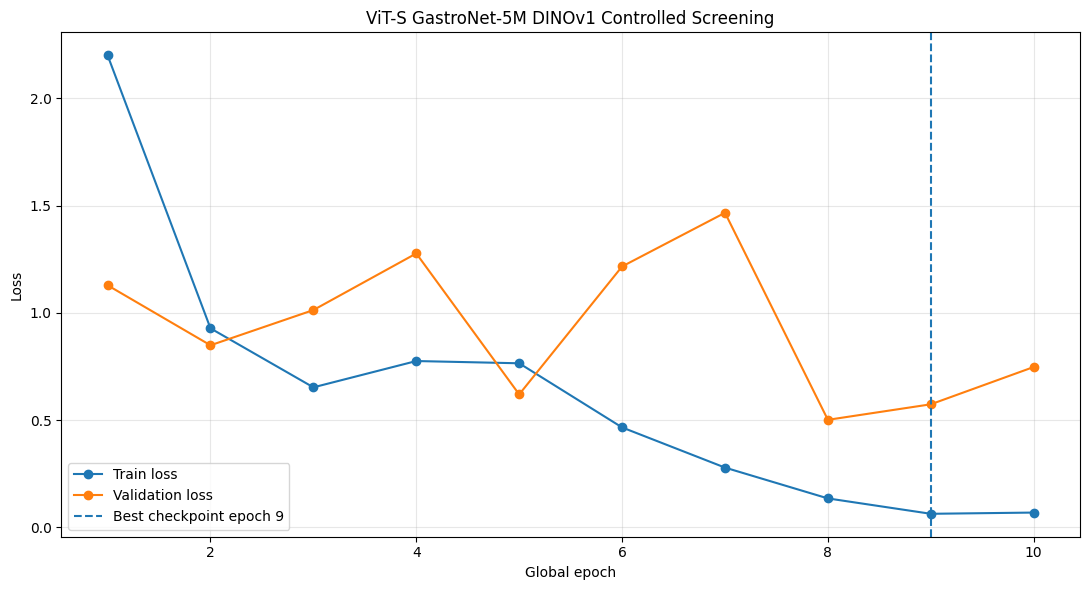

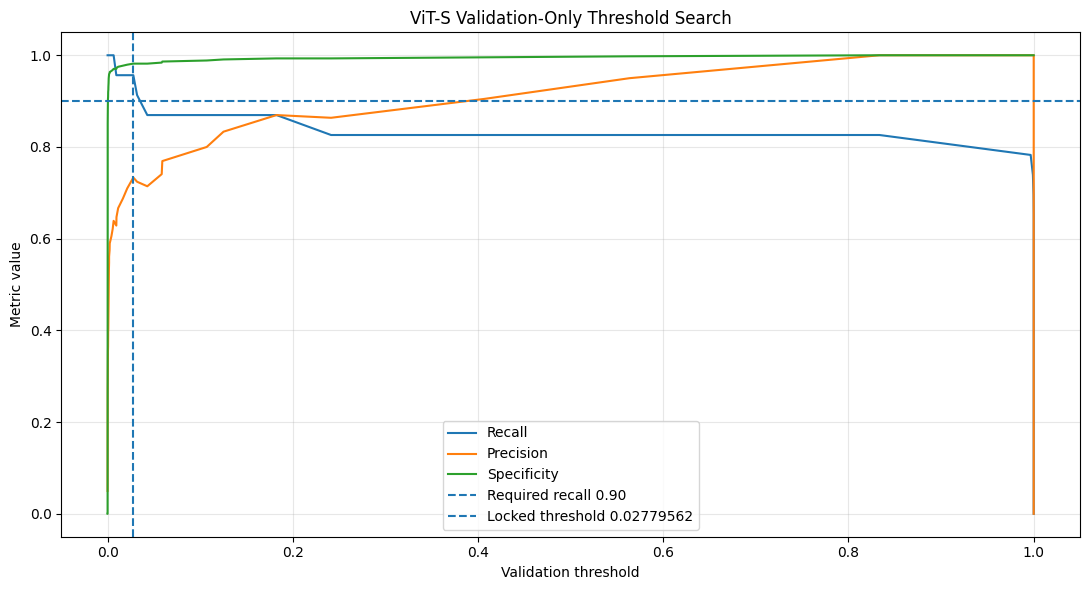

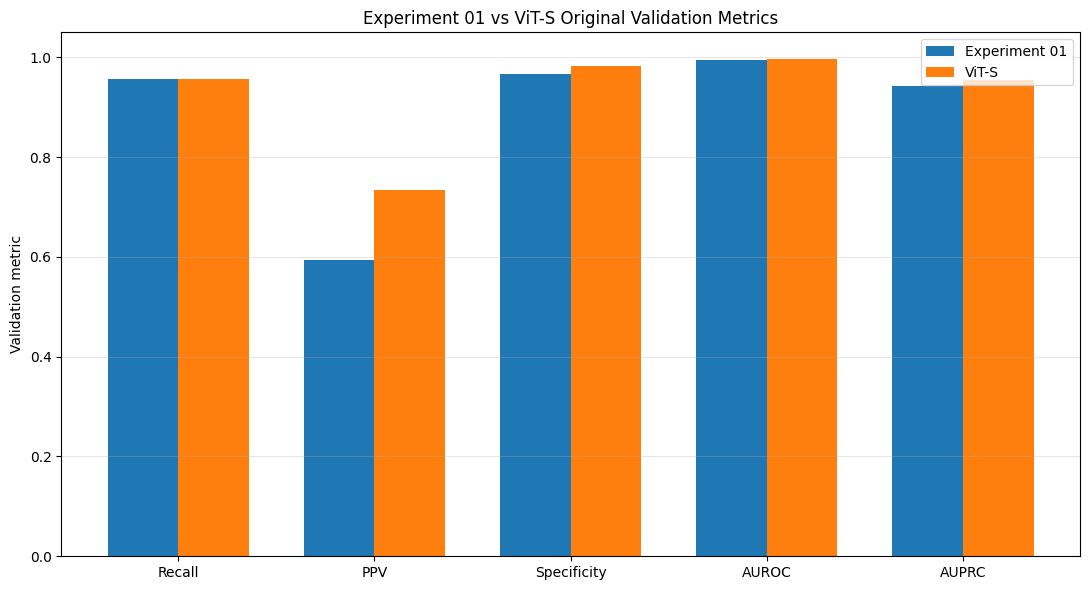

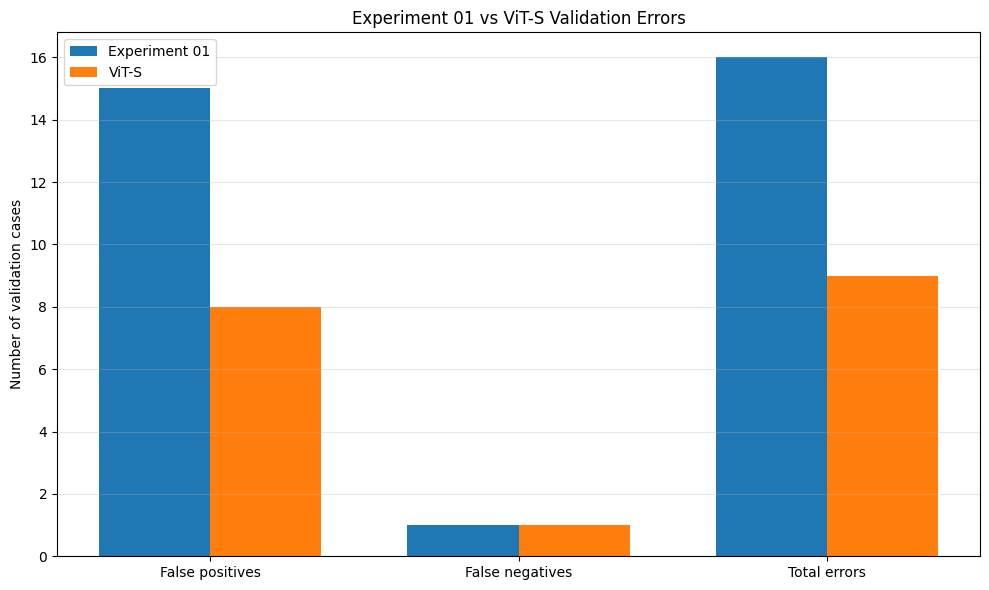

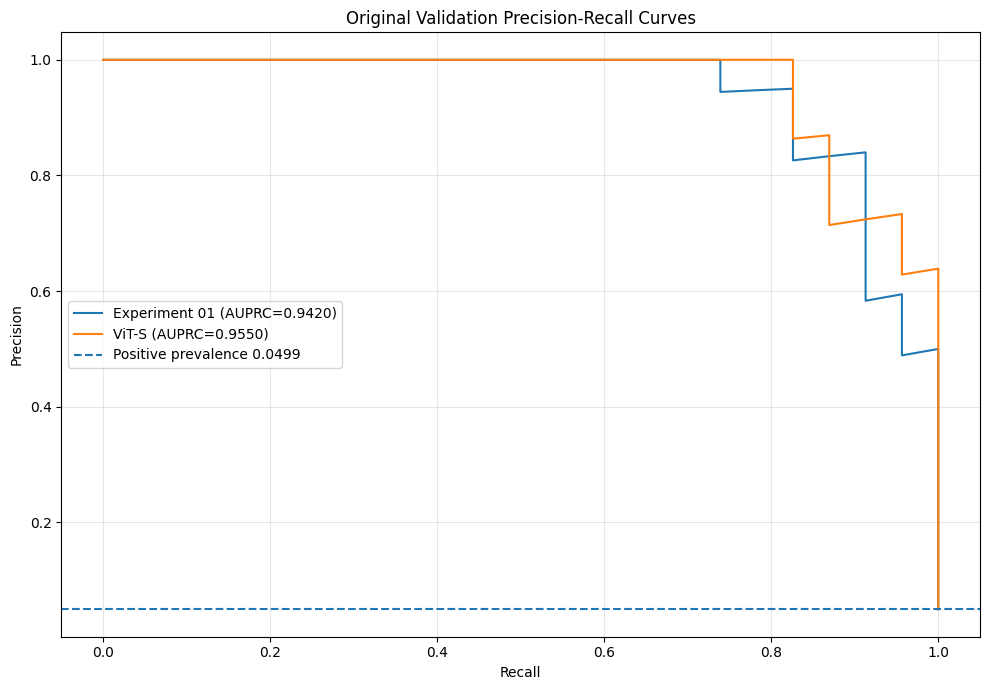

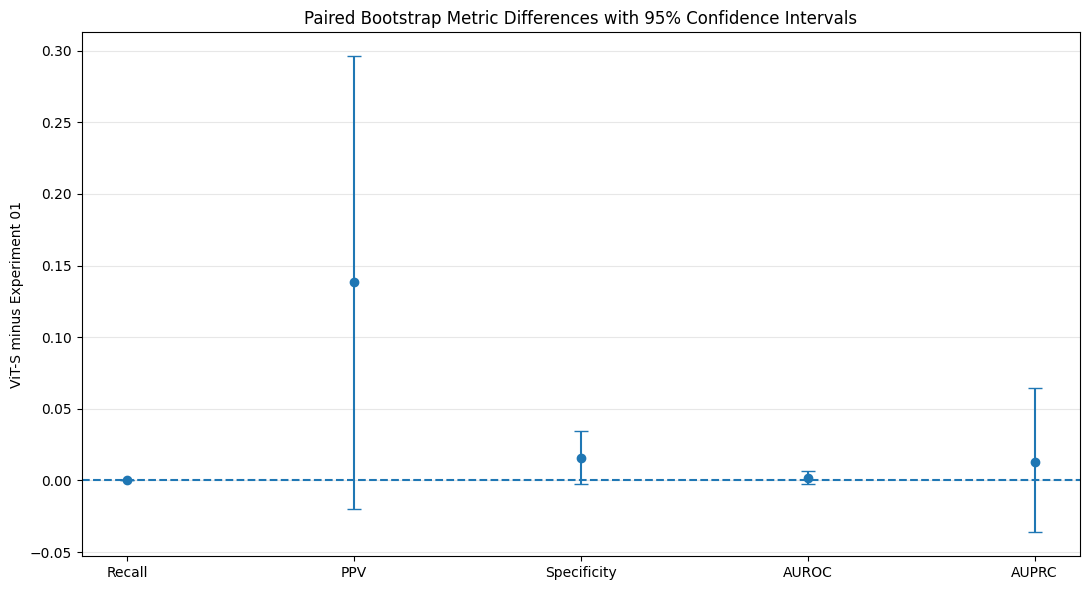


FINAL CELL 16B ViT-S CONTROLLED SCREENING REPORT
Matched validation cases: 461/461
Fixed screening seed: 42
Best stage: stage_2
Best global epoch: 9
Locked threshold: 0.027795622581

Experiment 01:
Recall: 0.956522
PPV: 0.594595
Specificity: 0.965753
AUROC: 0.995235
AUPRC: 0.941969
TP=22 | TN=423 | FP=15 | FN=1

ViT-S GastroNet-5M DINOv1:
Recall: 0.956522
PPV: 0.733333
Specificity: 0.981735
AUROC: 0.996824
AUPRC: 0.955040
Minimum centre recall: 0.888889
TP=22 | TN=430 | FP=8 | FN=1

Experiment 01 vs ViT-S metric comparison:


,metric,experiment_01,vits_gastronet5m_dinov1,vits_minus_experiment_01
0,recall,0.956522,0.956522,0.000000
1,precision,0.594595,0.733333,0.138739
2,specificity,0.965753,0.981735,0.015982
3,npv,0.997642,0.997680,0.000038
4,accuracy,0.965293,0.980477,0.015184
5,balanced_accuracy,0.961138,0.969128,0.007991
6,f1,0.733333,0.830189,0.096855
7,auroc,0.995235,0.996824,0.001588
8,auprc,0.941969,0.955040,0.013071
9,tp,22.000000,22.000000,0.000000



ViT-S per-centre metrics:


,center,model,threshold,sample_count,normal_count,positive_count,recall,precision,specificity,npv,accuracy,balanced_accuracy,f1,auroc,auprc,tp,tn,fp,fn,total_errors
0,center_1,vits_gastronet5m_dinov1,0.027796,341,332,9,0.888889,0.615385,0.984940,0.996951,0.982405,0.936914,0.727273,0.992972,0.827635,8,327,5,1,6
1,center_2,vits_gastronet5m_dinov1,0.027796,120,106,14,1.000000,0.823529,0.971698,1.000000,0.975000,0.985849,0.903226,1.000000,1.000000,14,103,3,0,3



Error-overlap analysis:


...


Exact McNemar paired-error analysis:


,exp01_wrong_vits_correct,exp01_correct_vits_wrong,discordant_total,exact_two_sided_p_value,interpretation,important_note
0,12,5,17,0.143463,no_clear_paired_error_difference,Development-validation comparison only. This i...



Paired bootstrap confidence intervals:


,measure,observed_change,bootstrap_mean,bootstrap_median,ci_2_5_percent,ci_97_5_percent,proportion_above_zero,proportion_at_or_above_zero,interpretation
0,recall_gain,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,1.0000,CI_includes_zero
1,ppv_gain,0.138739,0.136902,0.134258,-0.019630,0.296154,0.9420,0.9695,CI_includes_zero
2,specificity_gain,0.015982,0.015678,0.015982,-0.002283,0.034247,0.9420,0.9695,CI_includes_zero
3,balanced_accuracy_gain,0.007991,0.007839,0.007991,-0.001142,0.017123,0.9420,0.9695,CI_includes_zero
4,f1_gain,0.096855,0.094584,0.094286,-0.013920,0.199580,0.9420,0.9695,CI_includes_zero
5,auroc_gain,0.001588,0.001561,0.001390,-0.002583,0.006552,0.7470,0.7555,CI_includes_zero
6,auprc_gain,0.013071,0.012677,0.011592,-0.036274,0.064418,0.6925,0.6935,CI_includes_zero
7,fp_reduction,7.000000,6.867000,7.000000,-1.000000,15.000000,0.9420,0.9695,CI_includes_zero
8,fn_reduction,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,1.0000,CI_includes_zero
9,total_error_reduction,7.000000,6.867000,7.000000,-1.000000,15.000000,0.9420,0.9695,CI_includes_zero



Development-only decision:
VITS_PROVISIONAL_VALIDATION_LEAD_ADVANCE_TO_FULL_CV

Recommended next action:
ViT-S produced a provisional development-validation lead. Advance it to predeclared three-fold cross-validation before changing the final model. Do not open the held-out test.

Held-out test CSV loaded: False
Held-out test predictions loaded: False
Held-out test evaluated: False
Held-out test used for decision: False
Best seed selected: False
Checkpoint selected using test: False
Threshold selected using test: False

STATUS: CELL16B_VITS_GASTRONET5M_DINOV1_CONTROLLED_SCREENING_COMPLETE

Saved records:
/content/drive/MyDrive/RARE26_GastroNet_Weights/models/screening/original_split/vits_gastronet5m_dinov1/cell16b_vits_gastronet5m_dinov1_best.pth
/content/drive/MyDrive/RARE26_GastroNet_Weights/logs/screening/original_split/vits_gastronet5m_dinov1/cell16b_vits_training_history.csv
/content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/screening/original_split/vits_gastronet5m_dino

In [ ]:
# ==========================================================================================
# CELL 16B
# ViT-S GASTRONET-5M DINOV1 CONTROLLED ORIGINAL-SPLIT SCREENING
#
# Fixed scientific protocol:
# - One predeclared seed: 42
# - Locked original train/validation split
# - ViT-S/16 GastroNet-5M DINOv1 checkpoint only
# - Stage 1: classification head only, 3 epochs
# - Stage 2: final 3 transformer blocks + final norm + head, maximum 7 epochs
# - Best checkpoint selected using validation AUPRC only
# - Operating threshold selected using validation predictions only
# - Required overall recall >= 0.90
# - Required minimum centre recall >= 0.80
# - Direct paired comparison with Experiment 01
# - Paired McNemar test and centre/class-stratified bootstrap
# - No held-out test access
# - No best-seed selection
# ==========================================================================================

from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display

import os
import gc
import re
import json
import math
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.metrics import (
    confusion_matrix,
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
)

from scipy.stats import binomtest

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = True


# ==========================================================================================
# 1. GOOGLE DRIVE
# ==========================================================================================

DRIVE_ROOT = Path("/content/drive")
MYDRIVE_ROOT = DRIVE_ROOT / "MyDrive"

if not MYDRIVE_ROOT.exists():

    from google.colab import drive

    drive.mount(
        str(DRIVE_ROOT)
    )

if not MYDRIVE_ROOT.exists():

    raise RuntimeError(
        "Google Drive could not be mounted."
    )


# ==========================================================================================
# 2. FIXED CONFIGURATION
# ==========================================================================================

CELL_ID = (
    "cell16b_vits_gastronet5m_dinov1_"
    "controlled_original_split_screening"
)

CANDIDATE_ID = (
    "vits_gastronet5m_dinov1"
)

DISPLAY_NAME = (
    "ViT-S GastroNet-5M DINOv1"
)

SCREENING_SEED = 42
FORCE_RERUN = False

IMAGE_SIZE = 224
RESIZE_SIZE = 256
PATCH_SIZE = 16

BATCH_SIZE = 32
NUM_WORKERS = 2

STAGE_1_EPOCHS = 3
STAGE_2_MAX_EPOCHS = 7
STAGE_2_PATIENCE = 3
UNFROZEN_FINAL_BLOCKS = 3

STAGE_1_HEAD_LR = 1e-3
STAGE_2_BACKBONE_LR = 1e-5
STAGE_2_HEAD_LR = 1e-4

WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0

REQUIRED_OVERALL_RECALL = 0.90
REQUIRED_MINIMUM_CENTRE_RECALL = 0.80

BOOTSTRAP_ITERATIONS = 2000
BOOTSTRAP_SEED = 1602

EXPECTED_TRAIN_TOTAL = 2159
EXPECTED_TRAIN_NORMAL = 2050
EXPECTED_TRAIN_POSITIVE = 109

EXPECTED_VALIDATION_TOTAL = 461
EXPECTED_VALIDATION_NORMAL = 438
EXPECTED_VALIDATION_POSITIVE = 23

EXPECTED_EMBED_DIM = 384
EXPECTED_DEPTH = 12
EXPECTED_HEADS = 6
EXPECTED_BACKBONE_TENSOR_COUNT = 150

FINAL_STATUS = (
    "CELL16B_VITS_GASTRONET5M_DINOV1_"
    "CONTROLLED_SCREENING_COMPLETE"
)


# ==========================================================================================
# 3. PROJECT PATHS
# ==========================================================================================

PROJECT_ROOT = (
    MYDRIVE_ROOT
    / "RARE26_GastroNet_Weights"
)

CHECKPOINT_PATH = (
    PROJECT_ROOT
    / "source_checkpoints"
    / "VITS_GastroNet-5M_DINOv1.pth"
)

TRAIN_CSV_PATH = (
    PROJECT_ROOT
    / "configs"
    / "runtime_splits"
    / "train_runtime_verified.csv"
)

VALIDATION_CSV_PATH = (
    PROJECT_ROOT
    / "configs"
    / "runtime_splits"
    / "validation_runtime_verified.csv"
)

CELL16A_STATUS_PATH = (
    PROJECT_ROOT
    / "results"
    / "vit_feasibility"
    / "cell16a_status.json"
)

CELL16A_DECISION_PATH = (
    PROJECT_ROOT
    / "results"
    / "vit_feasibility"
    / "cell16a_vit_feasibility_decision.json"
)

EXP01_REFERENCE_PATH = (
    PROJECT_ROOT
    / "predictions"
    / "original_split"
    / "controlled_comparisons"
    / "experiment_01_vs_experiment_02_original_validation"
    / "cell14b_exp01_vs_exp02_paired_validation_cases.csv"
)


# ==========================================================================================
# 4. OUTPUT DIRECTORIES
# ==========================================================================================

MODEL_DIR = (
    PROJECT_ROOT
    / "models"
    / "screening"
    / "original_split"
    / CANDIDATE_ID
)

LOG_DIR = (
    PROJECT_ROOT
    / "logs"
    / "screening"
    / "original_split"
    / CANDIDATE_ID
)

PREDICTION_DIR = (
    PROJECT_ROOT
    / "predictions"
    / "screening"
    / "original_split"
    / CANDIDATE_ID
)

RESULT_DIR = (
    PROJECT_ROOT
    / "results"
    / "screening"
    / "original_split"
    / CANDIDATE_ID
)

THRESHOLD_DIR = (
    PROJECT_ROOT
    / "thresholds"
    / "screening"
    / "original_split"
    / CANDIDATE_ID
)

CENTRE_DIR = (
    PROJECT_ROOT
    / "centre_analysis"
    / "screening"
    / "original_split"
    / CANDIDATE_ID
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "figures"
    / "screening"
    / "original_split"
    / CANDIDATE_ID
)

INVENTORY_DIR = (
    PROJECT_ROOT
    / "inventory"
    / "screening"
    / CANDIDATE_ID
)

for directory in [
    MODEL_DIR,
    LOG_DIR,
    PREDICTION_DIR,
    RESULT_DIR,
    THRESHOLD_DIR,
    CENTRE_DIR,
    FIGURE_DIR,
    INVENTORY_DIR,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ==========================================================================================
# 5. OUTPUT FILE PATHS
# ==========================================================================================

BEST_MODEL_PATH = (
    MODEL_DIR
    / "cell16b_vits_gastronet5m_dinov1_best.pth"
)

TRAINING_HISTORY_PATH = (
    LOG_DIR
    / "cell16b_vits_training_history.csv"
)

VALIDATION_PREDICTION_PATH = (
    PREDICTION_DIR
    / "cell16b_vits_validation_predictions_locked_threshold.csv"
)

PAIRED_VALIDATION_PATH = (
    PREDICTION_DIR
    / "cell16b_exp01_vs_vits_paired_validation_cases.csv"
)

EXP01_ERRORS_FIXED_PATH = (
    PREDICTION_DIR
    / "cell16b_exp01_errors_fixed_by_vits.csv"
)

NEW_VITS_ERRORS_PATH = (
    PREDICTION_DIR
    / "cell16b_new_vits_errors.csv"
)

COMMON_ERRORS_PATH = (
    PREDICTION_DIR
    / "cell16b_common_exp01_vits_errors.csv"
)

THRESHOLD_SEARCH_PATH = (
    THRESHOLD_DIR
    / "cell16b_vits_validation_threshold_search.csv"
)

THRESHOLD_LOCK_PATH = (
    THRESHOLD_DIR
    / "cell16b_vits_validation_threshold_lock.json"
)

VALIDATION_METRICS_PATH = (
    RESULT_DIR
    / "cell16b_vits_validation_metrics.csv"
)

METRIC_COMPARISON_PATH = (
    RESULT_DIR
    / "cell16b_exp01_vs_vits_metric_comparison.csv"
)

ERROR_OVERLAP_PATH = (
    RESULT_DIR
    / "cell16b_exp01_vs_vits_error_overlap.csv"
)

MCNEMAR_PATH = (
    RESULT_DIR
    / "cell16b_exp01_vs_vits_exact_mcnemar.csv"
)

BOOTSTRAP_SAMPLES_PATH = (
    RESULT_DIR
    / "cell16b_exp01_vs_vits_bootstrap_samples.csv"
)

BOOTSTRAP_SUMMARY_PATH = (
    RESULT_DIR
    / "cell16b_exp01_vs_vits_bootstrap_summary.csv"
)

PER_CENTRE_PATH = (
    CENTRE_DIR
    / "cell16b_vits_per_centre_metrics.csv"
)

PAIRED_PER_CENTRE_PATH = (
    CENTRE_DIR
    / "cell16b_exp01_vs_vits_per_centre_comparison.csv"
)

TENSOR_AUDIT_PATH = (
    INVENTORY_DIR
    / "cell16b_vits_tensor_loading_audit.csv"
)

DECISION_PATH = (
    RESULT_DIR
    / "cell16b_vits_development_decision.json"
)

STATUS_PATH = (
    RESULT_DIR
    / "cell16b_status.json"
)

SUMMARY_PATH = (
    RESULT_DIR
    / "cell16b_vits_screening_summary.txt"
)

TRAINING_FIGURE_PATH = (
    FIGURE_DIR
    / "cell16b_vits_training_curves.png"
)

THRESHOLD_FIGURE_PATH = (
    FIGURE_DIR
    / "cell16b_vits_threshold_search.png"
)

METRIC_FIGURE_PATH = (
    FIGURE_DIR
    / "cell16b_exp01_vs_vits_metric_comparison.png"
)

ERROR_FIGURE_PATH = (
    FIGURE_DIR
    / "cell16b_exp01_vs_vits_error_comparison.png"
)

PR_CURVE_FIGURE_PATH = (
    FIGURE_DIR
    / "cell16b_exp01_vs_vits_precision_recall_curve.png"
)

BOOTSTRAP_FIGURE_PATH = (
    FIGURE_DIR
    / "cell16b_exp01_vs_vits_bootstrap_ci.png"
)


# ==========================================================================================
# 6. INITIAL REPORT
# ==========================================================================================

print("=" * 112)

print(
    "CELL 16B: ViT-S GASTRONET-5M DINOV1 "
    "CONTROLLED ORIGINAL-SPLIT SCREENING"
)

print("=" * 112)

print("\nCandidate:")
print(DISPLAY_NAME)

print("\nPretrained checkpoint:")
print(CHECKPOINT_PATH)

print("\nFixed screening seed:")
print(SCREENING_SEED)

print("\nTraining split:")
print(TRAIN_CSV_PATH)

print("\nValidation split:")
print(VALIDATION_CSV_PATH)

print("\nHeld-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("Held-out test used for any decision: False")
print("Best seed selected: False")
print("Checkpoint selected using test: False")
print("Threshold selected using test: False")


# ==========================================================================================
# 7. VERIFY PREVIOUS CELL AND REQUIRED FILES
# ==========================================================================================

required_files = [
    CHECKPOINT_PATH,
    TRAIN_CSV_PATH,
    VALIDATION_CSV_PATH,
    CELL16A_STATUS_PATH,
    CELL16A_DECISION_PATH,
    EXP01_REFERENCE_PATH,
]

missing_required_files = [
    path
    for path in required_files
    if not path.exists()
]

if missing_required_files:

    print("\nMissing required files:")

    for path in missing_required_files:
        print(path)

    raise FileNotFoundError(
        "One or more required Cell 16B files are missing."
    )


cell16a_status_record = json.loads(
    CELL16A_STATUS_PATH.read_text(
        encoding="utf-8"
    )
)

cell16a_decision_record = json.loads(
    CELL16A_DECISION_PATH.read_text(
        encoding="utf-8"
    )
)

cell16a_status = cell16a_status_record.get(
    "status"
)

cell16a_decision = cell16a_decision_record.get(
    "aggregate_decision"
)

feasible_candidate_ids = (
    cell16a_decision_record.get(
        "feasible_candidate_ids",
        [],
    )
)

if cell16a_status != (
    "CELL16A_VIT_ARCHITECTURE_AND_FEASIBILITY_AUDIT_COMPLETE"
):

    raise RuntimeError(
        "Cell 16A is not marked complete.\n"
        f"Actual status: {cell16a_status}"
    )

if cell16a_decision != (
    "ONE_VIT_CHECKPOINT_ADVANCES_TO_CONTROLLED_SCREENING"
):

    raise RuntimeError(
        "Cell 16B expected exactly one ViT checkpoint "
        "to advance from Cell 16A.\n"
        f"Actual decision: {cell16a_decision}"
    )

if CANDIDATE_ID not in feasible_candidate_ids:

    raise RuntimeError(
        f"{CANDIDATE_ID} is not listed as a feasible "
        "Cell 16A screening candidate."
    )

print("\nCell 16A completion verified:")
print(cell16a_status)

print("\nCell 16A decision verified:")
print(cell16a_decision)

print("\nFeasible candidate verified:")
print(CANDIDATE_ID)


# ==========================================================================================
# 8. GPU VERIFICATION
# ==========================================================================================

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

USE_AMP = (
    DEVICE.type == "cuda"
)

print("\nCompute device:")
print(DEVICE)

if DEVICE.type != "cuda":

    raise RuntimeError(
        "Cell 16B requires a GPU.\n"
        "Connect a T4 GPU, run Cell 3B to restore temporary "
        "images, and then run Cell 16B again."
    )

print(
    torch.cuda.get_device_name(
        0
    )
)


# ==========================================================================================
# 9. REPRODUCIBILITY
# ==========================================================================================

def set_complete_seed(
    seed,
):

    os.environ[
        "PYTHONHASHSEED"
    ] = str(seed)

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    try:

        torch.use_deterministic_algorithms(
            True,
            warn_only=True,
        )

    except Exception:

        pass


def seed_worker(
    worker_id,
):

    worker_seed = (
        torch.initial_seed()
        % (2 ** 32)
    )

    np.random.seed(
        worker_seed
    )

    random.seed(
        worker_seed
    )


set_complete_seed(
    SCREENING_SEED
)


# ==========================================================================================
# 10. COLUMN HELPERS
# ==========================================================================================

def find_column(
    dataframe,
    candidates,
    description,
    required=True,
):

    for candidate in candidates:

        if candidate in dataframe.columns:
            return candidate

    lowercase_map = {
        str(column).lower(): column
        for column in dataframe.columns
    }

    for candidate in candidates:

        if candidate.lower() in lowercase_map:

            return lowercase_map[
                candidate.lower()
            ]

    if required:

        raise KeyError(
            f"Could not find {description} column.\n"
            f"Available columns:\n"
            f"{list(dataframe.columns)}"
        )

    return None


PATH_CANDIDATES = [
    "runtime_path",
    "image_path",
    "filepath",
    "file_path",
    "path",
]

LABEL_CANDIDATES = [
    "label",
    "target",
    "ground_truth",
    "class_label",
    "y_true",
]

CENTER_CANDIDATES = [
    "center",
    "centre",
    "site",
]

SHA_CANDIDATES = [
    "sha256",
    "image_sha256",
    "file_sha256",
]

RELATIVE_PATH_CANDIDATES = [
    "relative_path",
    "original_relative_path",
    "image_relative_path",
]


# ==========================================================================================
# 11. LOAD AND VERIFY LOCKED SPLITS
# ==========================================================================================

train_df = pd.read_csv(
    TRAIN_CSV_PATH,
    low_memory=False,
)

validation_df = pd.read_csv(
    VALIDATION_CSV_PATH,
    low_memory=False,
)

train_path_column = find_column(
    train_df,
    PATH_CANDIDATES,
    "training image path",
)

validation_path_column = find_column(
    validation_df,
    PATH_CANDIDATES,
    "validation image path",
)

train_label_column = find_column(
    train_df,
    LABEL_CANDIDATES,
    "training label",
)

validation_label_column = find_column(
    validation_df,
    LABEL_CANDIDATES,
    "validation label",
)

train_center_column = find_column(
    train_df,
    CENTER_CANDIDATES,
    "training centre",
)

validation_center_column = find_column(
    validation_df,
    CENTER_CANDIDATES,
    "validation centre",
)

validation_sha_column = find_column(
    validation_df,
    SHA_CANDIDATES,
    "validation SHA-256",
)

validation_relative_path_column = find_column(
    validation_df,
    RELATIVE_PATH_CANDIDATES,
    "validation relative path",
)

train_df[
    train_label_column
] = pd.to_numeric(
    train_df[
        train_label_column
    ],
    errors="raise",
).astype(int)

validation_df[
    validation_label_column
] = pd.to_numeric(
    validation_df[
        validation_label_column
    ],
    errors="raise",
).astype(int)

train_total = len(train_df)
validation_total = len(validation_df)

train_normal = int(
    (
        train_df[
            train_label_column
        ]
        == 0
    ).sum()
)

train_positive = int(
    (
        train_df[
            train_label_column
        ]
        == 1
    ).sum()
)

validation_normal = int(
    (
        validation_df[
            validation_label_column
        ]
        == 0
    ).sum()
)

validation_positive = int(
    (
        validation_df[
            validation_label_column
        ]
        == 1
    ).sum()
)

count_checks = {
    "train_total": (
        train_total,
        EXPECTED_TRAIN_TOTAL,
    ),
    "train_normal": (
        train_normal,
        EXPECTED_TRAIN_NORMAL,
    ),
    "train_positive": (
        train_positive,
        EXPECTED_TRAIN_POSITIVE,
    ),
    "validation_total": (
        validation_total,
        EXPECTED_VALIDATION_TOTAL,
    ),
    "validation_normal": (
        validation_normal,
        EXPECTED_VALIDATION_NORMAL,
    ),
    "validation_positive": (
        validation_positive,
        EXPECTED_VALIDATION_POSITIVE,
    ),
}

for count_name, (
    actual_value,
    expected_value,
) in count_checks.items():

    if actual_value != expected_value:

        raise RuntimeError(
            f"Locked split count mismatch: {count_name}\n"
            f"Expected: {expected_value}\n"
            f"Found: {actual_value}"
        )

missing_train_images = [
    path
    for path in train_df[
        train_path_column
    ].astype(str)
    if not Path(path).exists()
]

missing_validation_images = [
    path
    for path in validation_df[
        validation_path_column
    ].astype(str)
    if not Path(path).exists()
]

if missing_train_images:

    raise FileNotFoundError(
        f"{len(missing_train_images)} training images "
        "are missing from temporary Colab storage.\n"
        "Run Cell 3B before Cell 16B."
    )

if missing_validation_images:

    raise FileNotFoundError(
        f"{len(missing_validation_images)} validation images "
        "are missing from temporary Colab storage.\n"
        "Run Cell 3B before Cell 16B."
    )

train_path_set = set(
    train_df[
        train_path_column
    ].astype(str)
)

validation_path_set = set(
    validation_df[
        validation_path_column
    ].astype(str)
)

train_validation_overlap = len(
    train_path_set.intersection(
        validation_path_set
    )
)

if train_validation_overlap != 0:

    raise RuntimeError(
        f"Train/validation overlap detected: "
        f"{train_validation_overlap}"
    )

print("\nLocked original split verified:")

print(
    f"Train: {train_total} "
    f"(normal={train_normal}, NEO={train_positive})"
)

print(
    f"Validation: {validation_total} "
    f"(normal={validation_normal}, "
    f"NEO={validation_positive})"
)

print(
    f"Train/validation overlap: "
    f"{train_validation_overlap}"
)

print(
    f"Missing training images: "
    f"{len(missing_train_images)}"
)

print(
    f"Missing validation images: "
    f"{len(missing_validation_images)}"
)


# ==========================================================================================
# 12. METRIC FUNCTIONS
# ==========================================================================================

def safe_divide(
    numerator,
    denominator,
):

    if denominator == 0:
        return 0.0

    return float(
        numerator
        / denominator
    )


def calculate_metrics(
    labels,
    probabilities,
    predictions,
):

    labels = np.asarray(
        labels,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    predictions = np.asarray(
        predictions,
        dtype=int,
    )

    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[
            0,
            1,
        ],
    ).ravel()

    recall = safe_divide(
        tp,
        tp + fn,
    )

    precision = safe_divide(
        tp,
        tp + fp,
    )

    specificity = safe_divide(
        tn,
        tn + fp,
    )

    npv = safe_divide(
        tn,
        tn + fn,
    )

    accuracy = safe_divide(
        tp + tn,
        len(labels),
    )

    balanced_accuracy = (
        recall
        + specificity
    ) / 2.0

    f1 = safe_divide(
        2.0
        * precision
        * recall,
        precision + recall,
    )

    if len(
        np.unique(labels)
    ) == 2:

        auroc = float(
            roc_auc_score(
                labels,
                probabilities,
            )
        )

        auprc = float(
            average_precision_score(
                labels,
                probabilities,
            )
        )

    else:

        auroc = np.nan
        auprc = np.nan

    return {
        "sample_count": int(
            len(labels)
        ),
        "normal_count": int(
            (
                labels == 0
            ).sum()
        ),
        "positive_count": int(
            (
                labels == 1
            ).sum()
        ),
        "recall": float(recall),
        "precision": float(precision),
        "specificity": float(specificity),
        "npv": float(npv),
        "accuracy": float(accuracy),
        "balanced_accuracy": float(
            balanced_accuracy
        ),
        "f1": float(f1),
        "auroc": float(auroc),
        "auprc": float(auprc),
        "tp": int(tp),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "total_errors": int(
            fp + fn
        ),
    }


# ==========================================================================================
# 13. LOAD EXPERIMENT 01 REFERENCE
# ==========================================================================================

exp01_raw_df = pd.read_csv(
    EXP01_REFERENCE_PATH,
    low_memory=False,
)

exp01_sha_column = find_column(
    exp01_raw_df,
    [
        "case_sha256",
        "sha256",
    ],
    "Experiment 01 SHA-256",
)

exp01_label_column = find_column(
    exp01_raw_df,
    [
        "label_exp01",
        "label",
    ],
    "Experiment 01 label",
)

exp01_center_column = find_column(
    exp01_raw_df,
    [
        "center_exp01",
        "center",
        "centre",
    ],
    "Experiment 01 centre",
)

exp01_probability_column = find_column(
    exp01_raw_df,
    [
        "probability_exp01",
        "probability",
    ],
    "Experiment 01 probability",
)

exp01_prediction_column = find_column(
    exp01_raw_df,
    [
        "prediction_exp01",
        "locked_prediction_exp01",
        "prediction",
        "locked_prediction",
    ],
    "Experiment 01 prediction",
)

exp01_df = pd.DataFrame(
    {
        "case_sha256": (
            exp01_raw_df[
                exp01_sha_column
            ]
            .astype(str)
            .str.strip()
            .str.lower()
        ),
        "label_exp01": pd.to_numeric(
            exp01_raw_df[
                exp01_label_column
            ],
            errors="raise",
        ).astype(int),
        "center_exp01": (
            exp01_raw_df[
                exp01_center_column
            ].astype(str)
        ),
        "probability_exp01": pd.to_numeric(
            exp01_raw_df[
                exp01_probability_column
            ],
            errors="raise",
        ).astype(float),
        "prediction_exp01": pd.to_numeric(
            exp01_raw_df[
                exp01_prediction_column
            ],
            errors="raise",
        ).astype(int),
    }
)

if len(exp01_df) != EXPECTED_VALIDATION_TOTAL:

    raise RuntimeError(
        "Experiment 01 reference does not contain "
        f"{EXPECTED_VALIDATION_TOTAL} cases."
    )

if exp01_df[
    "case_sha256"
].duplicated().any():

    raise RuntimeError(
        "Duplicate SHA-256 identifiers found in "
        "Experiment 01 reference predictions."
    )

exp01_metrics = calculate_metrics(
    exp01_df[
        "label_exp01"
    ].to_numpy(
        dtype=int
    ),
    exp01_df[
        "probability_exp01"
    ].to_numpy(
        dtype=float
    ),
    exp01_df[
        "prediction_exp01"
    ].to_numpy(
        dtype=int
    ),
)

expected_exp01_counts = {
    "tp": 22,
    "tn": 423,
    "fp": 15,
    "fn": 1,
}

for metric_name, expected_value in (
    expected_exp01_counts.items()
):

    if exp01_metrics[
        metric_name
    ] != expected_value:

        raise RuntimeError(
            "Experiment 01 reference verification failed.\n"
            f"{metric_name}: expected {expected_value}, "
            f"found {exp01_metrics[metric_name]}"
        )

print("\nExperiment 01 reference verified:")

print(
    f"AUPRC={exp01_metrics['auprc']:.6f} | "
    f"AUROC={exp01_metrics['auroc']:.6f} | "
    f"Recall={exp01_metrics['recall']:.6f} | "
    f"PPV={exp01_metrics['precision']:.6f} | "
    f"Specificity={exp01_metrics['specificity']:.6f}"
)

print(
    f"TP={exp01_metrics['tp']} | "
    f"TN={exp01_metrics['tn']} | "
    f"FP={exp01_metrics['fp']} | "
    f"FN={exp01_metrics['fn']}"
)


# ==========================================================================================
# 14. CHECKPOINT EXTRACTION AND KEY NORMALIZATION
# ==========================================================================================

def safe_torch_load(
    path,
):

    try:

        return torch.load(
            path,
            map_location="cpu",
            weights_only=False,
        )

    except TypeError:

        return torch.load(
            path,
            map_location="cpu",
        )


def score_tensor_dictionary(
    dictionary,
    path_text,
):

    if not isinstance(
        dictionary,
        dict,
    ):

        return (
            -1,
            0,
            0,
        )

    tensor_keys = [
        str(key)
        for key, value
        in dictionary.items()
        if torch.is_tensor(value)
    ]

    tensor_count = len(
        tensor_keys
    )

    vit_patterns = [
        "patch_embed",
        "pos_embed",
        "cls_token",
        "blocks.",
        "attn.qkv",
        "mlp.fc1",
        "norm.weight",
    ]

    vit_hits = sum(
        any(
            pattern in key
            for pattern in vit_patterns
        )
        for key in tensor_keys
    )

    path_bonus = 0
    path_text_lower = str(
        path_text
    ).lower()

    for token, bonus in {
        "teacher": 100,
        "student": 80,
        "model_state_dict": 60,
        "state_dict": 50,
        "backbone": 40,
        "model": 20,
    }.items():

        if token in path_text_lower:

            path_bonus = max(
                path_bonus,
                bonus,
            )

    total_score = (
        vit_hits * 1000
        + tensor_count
        + path_bonus
    )

    return (
        total_score,
        vit_hits,
        tensor_count,
    )


def collect_tensor_dictionaries(
    value,
    path_text="root",
    depth=0,
    maximum_depth=6,
):

    records = []

    if (
        not isinstance(
            value,
            dict,
        )
        or depth > maximum_depth
    ):

        return records

    score, vit_hits, tensor_count = (
        score_tensor_dictionary(
            value,
            path_text,
        )
    )

    if tensor_count > 0:

        records.append(
            {
                "path": path_text,
                "dictionary": value,
                "score": score,
                "vit_hits": vit_hits,
                "tensor_count": tensor_count,
            }
        )

    for key, nested_value in value.items():

        if isinstance(
            nested_value,
            dict,
        ):

            records.extend(
                collect_tensor_dictionaries(
                    nested_value,
                    path_text=(
                        f"{path_text}.{key}"
                    ),
                    depth=depth + 1,
                    maximum_depth=maximum_depth,
                )
            )

    return records


def extract_best_state_dictionary(
    checkpoint_object,
):

    candidate_dictionaries = (
        collect_tensor_dictionaries(
            checkpoint_object
        )
    )

    if not candidate_dictionaries:

        raise RuntimeError(
            "No tensor state dictionary found "
            "inside ViT checkpoint."
        )

    candidate_dictionaries.sort(
        key=lambda record: (
            record["score"],
            record["vit_hits"],
            record["tensor_count"],
        ),
        reverse=True,
    )

    selected_record = (
        candidate_dictionaries[0]
    )

    tensor_state = {
        str(key): value
        for key, value
        in selected_record[
            "dictionary"
        ].items()
        if torch.is_tensor(value)
    }

    return (
        tensor_state,
        selected_record[
            "path"
        ],
    )


KNOWN_PREFIXES = [
    "module.",
    "model.",
    "network.",
    "encoder.",
    "backbone.",
    "student.",
    "teacher.",
    "base_encoder.",
    "online_encoder.",
    "momentum_encoder.",
    "target_encoder.",
    "trunk.",
    "visual.",
    "transformer.",
]


def remove_known_prefixes(
    key,
):

    cleaned_key = str(key)
    prefix_removed = True

    while prefix_removed:

        prefix_removed = False

        for prefix in KNOWN_PREFIXES:

            if cleaned_key.startswith(
                prefix
            ):

                cleaned_key = cleaned_key[
                    len(prefix):
                ]

                prefix_removed = True

    return cleaned_key


def normalize_vit_state_dictionary(
    raw_state,
):

    normalized_state = {}

    for raw_key, tensor_value in (
        raw_state.items()
    ):

        key = remove_known_prefixes(
            raw_key
        )

        gamma_1_match = re.match(
            r"^(blocks\.\d+)\.gamma_1$",
            key,
        )

        gamma_2_match = re.match(
            r"^(blocks\.\d+)\.gamma_2$",
            key,
        )

        if gamma_1_match:

            key = (
                f"{gamma_1_match.group(1)}."
                "ls1.gamma"
            )

        elif gamma_2_match:

            key = (
                f"{gamma_2_match.group(1)}."
                "ls2.gamma"
            )

        normalized_state[
            key
        ] = tensor_value

    return normalized_state


def is_vit_backbone_key(
    key,
):

    exact_keys = {
        "cls_token",
        "pos_embed",
        "register_tokens",
        "mask_token",
    }

    allowed_prefixes = (
        "patch_embed.",
        "blocks.",
        "norm.",
    )

    return bool(
        key in exact_keys
        or key.startswith(
            allowed_prefixes
        )
    )


# ==========================================================================================
# 15. INFER CHECKPOINT ARCHITECTURE
# ==========================================================================================

def require_tensor(
    state_dictionary,
    key,
):

    if key not in state_dictionary:

        raise KeyError(
            f"Required ViT tensor missing: {key}"
        )

    return state_dictionary[
        key
    ]


def infer_vit_architecture(
    state_dictionary,
):

    patch_weight = require_tensor(
        state_dictionary,
        "patch_embed.proj.weight",
    )

    cls_token = require_tensor(
        state_dictionary,
        "cls_token",
    )

    pos_embed = require_tensor(
        state_dictionary,
        "pos_embed",
    )

    embed_dim = int(
        patch_weight.shape[0]
    )

    input_channels = int(
        patch_weight.shape[1]
    )

    patch_height = int(
        patch_weight.shape[2]
    )

    patch_width = int(
        patch_weight.shape[3]
    )

    if patch_height != patch_width:

        raise RuntimeError(
            "Checkpoint contains non-square patches."
        )

    block_indices = sorted(
        {
            int(match.group(1))
            for key in state_dictionary.keys()
            for match in [
                re.match(
                    r"^blocks\.(\d+)\.",
                    key,
                )
            ]
            if match is not None
        }
    )

    if block_indices != list(
        range(
            max(block_indices) + 1
        )
    ):

        raise RuntimeError(
            "Non-contiguous ViT block indices detected."
        )

    depth = len(
        block_indices
    )

    qkv_weight = require_tensor(
        state_dictionary,
        "blocks.0.attn.qkv.weight",
    )

    if tuple(
        qkv_weight.shape
    ) != (
        embed_dim * 3,
        embed_dim,
    ):

        raise RuntimeError(
            "Unexpected attention QKV tensor shape."
        )

    mlp_fc1_weight = require_tensor(
        state_dictionary,
        "blocks.0.mlp.fc1.weight",
    )

    mlp_hidden_dim = int(
        mlp_fc1_weight.shape[0]
    )

    if embed_dim == 384:
        attention_heads = 6
    elif embed_dim == 768:
        attention_heads = 12
    else:

        raise RuntimeError(
            f"Unsupported embedding dimension: "
            f"{embed_dim}"
        )

    register_token_count = 0

    if "register_tokens" in state_dictionary:

        register_token_count = int(
            state_dictionary[
                "register_tokens"
            ].shape[1]
        )

    positional_token_count = int(
        pos_embed.shape[1]
    )

    patch_token_count = (
        positional_token_count - 1
    )

    reference_grid_size = int(
        round(
            math.sqrt(
                patch_token_count
            )
        )
    )

    if (
        reference_grid_size
        * reference_grid_size
        != patch_token_count
    ):

        raise RuntimeError(
            "Checkpoint positional embedding does not "
            "contain a square patch grid."
        )

    architecture = {
        "embedding_dimension": embed_dim,
        "input_channels": input_channels,
        "patch_size": patch_height,
        "depth": depth,
        "attention_heads": attention_heads,
        "mlp_hidden_dimension": (
            mlp_hidden_dim
        ),
        "qkv_bias": (
            "blocks.0.attn.qkv.bias"
            in state_dictionary
        ),
        "attention_projection_bias": (
            "blocks.0.attn.proj.bias"
            in state_dictionary
        ),
        "mlp_fc1_bias": (
            "blocks.0.mlp.fc1.bias"
            in state_dictionary
        ),
        "mlp_fc2_bias": (
            "blocks.0.mlp.fc2.bias"
            in state_dictionary
        ),
        "patch_projection_bias": (
            "patch_embed.proj.bias"
            in state_dictionary
        ),
        "layer_scale": (
            "blocks.0.ls1.gamma"
            in state_dictionary
        ),
        "register_token_count": (
            register_token_count
        ),
        "mask_token_present": (
            "mask_token"
            in state_dictionary
        ),
        "positional_token_count": (
            positional_token_count
        ),
        "reference_grid_size": (
            reference_grid_size
        ),
        "reference_image_size": (
            reference_grid_size
            * patch_height
        ),
        "cls_token_shape": tuple(
            cls_token.shape
        ),
        "pos_embed_shape": tuple(
            pos_embed.shape
        ),
    }

    return architecture


# ==========================================================================================
# 16. ViT IMPLEMENTATION
# ==========================================================================================

class PatchEmbed(
    nn.Module
):

    def __init__(
        self,
        input_channels,
        embed_dim,
        patch_size,
        use_bias,
    ):

        super().__init__()

        self.patch_size = patch_size

        self.proj = nn.Conv2d(
            input_channels,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size,
            bias=use_bias,
        )

    def forward(
        self,
        images,
    ):

        return (
            self.proj(images)
            .flatten(2)
            .transpose(1, 2)
        )


class Attention(
    nn.Module
):

    def __init__(
        self,
        embed_dim,
        attention_heads,
        qkv_bias,
        projection_bias,
    ):

        super().__init__()

        self.attention_heads = (
            attention_heads
        )

        self.head_dimension = (
            embed_dim
            // attention_heads
        )

        self.scale = (
            self.head_dimension
            ** -0.5
        )

        self.qkv = nn.Linear(
            embed_dim,
            embed_dim * 3,
            bias=qkv_bias,
        )

        self.proj = nn.Linear(
            embed_dim,
            embed_dim,
            bias=projection_bias,
        )

    def forward(
        self,
        tokens,
    ):

        batch_size, token_count, embed_dim = (
            tokens.shape
        )

        qkv = (
            self.qkv(tokens)
            .reshape(
                batch_size,
                token_count,
                3,
                self.attention_heads,
                self.head_dimension,
            )
            .permute(
                2,
                0,
                3,
                1,
                4,
            )
        )

        query, key, value = (
            qkv[0],
            qkv[1],
            qkv[2],
        )

        if hasattr(
            F,
            "scaled_dot_product_attention",
        ):

            attended = (
                F.scaled_dot_product_attention(
                    query,
                    key,
                    value,
                    dropout_p=0.0,
                    is_causal=False,
                )
            )

        else:

            attention_weights = (
                query
                @ key.transpose(
                    -2,
                    -1,
                )
            ) * self.scale

            attention_weights = (
                attention_weights.softmax(
                    dim=-1
                )
            )

            attended = (
                attention_weights
                @ value
            )

        attended = (
            attended.transpose(
                1,
                2,
            )
            .reshape(
                batch_size,
                token_count,
                embed_dim,
            )
        )

        return self.proj(
            attended
        )


class MLP(
    nn.Module
):

    def __init__(
        self,
        embed_dim,
        hidden_dim,
        fc1_bias,
        fc2_bias,
    ):

        super().__init__()

        self.fc1 = nn.Linear(
            embed_dim,
            hidden_dim,
            bias=fc1_bias,
        )

        self.act = nn.GELU()

        self.fc2 = nn.Linear(
            hidden_dim,
            embed_dim,
            bias=fc2_bias,
        )

    def forward(
        self,
        tokens,
    ):

        return self.fc2(
            self.act(
                self.fc1(tokens)
            )
        )


class LayerScale(
    nn.Module
):

    def __init__(
        self,
        embed_dim,
    ):

        super().__init__()

        self.gamma = nn.Parameter(
            torch.ones(
                embed_dim
            )
        )

    def forward(
        self,
        tokens,
    ):

        return (
            tokens
            * self.gamma
        )


class TransformerBlock(
    nn.Module
):

    def __init__(
        self,
        embed_dim,
        attention_heads,
        mlp_hidden_dim,
        qkv_bias,
        projection_bias,
        fc1_bias,
        fc2_bias,
        use_layer_scale,
    ):

        super().__init__()

        self.norm1 = nn.LayerNorm(
            embed_dim,
            eps=1e-6,
        )

        self.attn = Attention(
            embed_dim=embed_dim,
            attention_heads=attention_heads,
            qkv_bias=qkv_bias,
            projection_bias=projection_bias,
        )

        self.norm2 = nn.LayerNorm(
            embed_dim,
            eps=1e-6,
        )

        self.mlp = MLP(
            embed_dim=embed_dim,
            hidden_dim=mlp_hidden_dim,
            fc1_bias=fc1_bias,
            fc2_bias=fc2_bias,
        )

        self.ls1 = (
            LayerScale(embed_dim)
            if use_layer_scale
            else nn.Identity()
        )

        self.ls2 = (
            LayerScale(embed_dim)
            if use_layer_scale
            else nn.Identity()
        )

    def forward(
        self,
        tokens,
    ):

        tokens = tokens + self.ls1(
            self.attn(
                self.norm1(tokens)
            )
        )

        tokens = tokens + self.ls2(
            self.mlp(
                self.norm2(tokens)
            )
        )

        return tokens


class VisionTransformerBackbone(
    nn.Module
):

    def __init__(
        self,
        architecture,
        source_state,
    ):

        super().__init__()

        self.embed_dim = int(
            architecture[
                "embedding_dimension"
            ]
        )

        self.patch_size = int(
            architecture[
                "patch_size"
            ]
        )

        self.reference_grid_size = int(
            architecture[
                "reference_grid_size"
            ]
        )

        self.register_token_count = int(
            architecture[
                "register_token_count"
            ]
        )

        self.patch_embed = PatchEmbed(
            input_channels=int(
                architecture[
                    "input_channels"
                ]
            ),
            embed_dim=self.embed_dim,
            patch_size=self.patch_size,
            use_bias=bool(
                architecture[
                    "patch_projection_bias"
                ]
            ),
        )

        self.cls_token = nn.Parameter(
            torch.zeros_like(
                source_state[
                    "cls_token"
                ]
            )
        )

        self.pos_embed = nn.Parameter(
            torch.zeros_like(
                source_state[
                    "pos_embed"
                ]
            )
        )

        if "register_tokens" in source_state:

            self.register_tokens = nn.Parameter(
                torch.zeros_like(
                    source_state[
                        "register_tokens"
                    ]
                )
            )

        if "mask_token" in source_state:

            self.mask_token = nn.Parameter(
                torch.zeros_like(
                    source_state[
                        "mask_token"
                    ]
                )
            )

        self.blocks = nn.ModuleList(
            [
                TransformerBlock(
                    embed_dim=self.embed_dim,
                    attention_heads=int(
                        architecture[
                            "attention_heads"
                        ]
                    ),
                    mlp_hidden_dim=int(
                        architecture[
                            "mlp_hidden_dimension"
                        ]
                    ),
                    qkv_bias=bool(
                        architecture[
                            "qkv_bias"
                        ]
                    ),
                    projection_bias=bool(
                        architecture[
                            "attention_projection_bias"
                        ]
                    ),
                    fc1_bias=bool(
                        architecture[
                            "mlp_fc1_bias"
                        ]
                    ),
                    fc2_bias=bool(
                        architecture[
                            "mlp_fc2_bias"
                        ]
                    ),
                    use_layer_scale=bool(
                        architecture[
                            "layer_scale"
                        ]
                    ),
                )
                for _ in range(
                    int(
                        architecture[
                            "depth"
                        ]
                    )
                )
            ]
        )

        self.norm = nn.LayerNorm(
            self.embed_dim,
            eps=1e-6,
        )

    def interpolate_patch_positions(
        self,
        grid_height,
        grid_width,
    ):

        cls_position = (
            self.pos_embed[
                :,
                :1,
            ]
        )

        patch_positions = (
            self.pos_embed[
                :,
                1:,
            ]
        )

        if (
            grid_height
            == self.reference_grid_size
            and grid_width
            == self.reference_grid_size
        ):

            return (
                cls_position,
                patch_positions,
            )

        patch_positions = (
            patch_positions.reshape(
                1,
                self.reference_grid_size,
                self.reference_grid_size,
                self.embed_dim,
            )
            .permute(
                0,
                3,
                1,
                2,
            )
        )

        patch_positions = F.interpolate(
            patch_positions,
            size=(
                grid_height,
                grid_width,
            ),
            mode="bicubic",
            align_corners=False,
        )

        patch_positions = (
            patch_positions.permute(
                0,
                2,
                3,
                1,
            )
            .reshape(
                1,
                grid_height
                * grid_width,
                self.embed_dim,
            )
        )

        return (
            cls_position,
            patch_positions,
        )

    def forward_features(
        self,
        images,
    ):

        patch_tokens = (
            self.patch_embed(images)
        )

        batch_size = (
            patch_tokens.shape[0]
        )

        grid_height = (
            images.shape[2]
            // self.patch_size
        )

        grid_width = (
            images.shape[3]
            // self.patch_size
        )

        cls_tokens = (
            self.cls_token.expand(
                batch_size,
                -1,
                -1,
            )
        )

        (
            cls_position,
            patch_positions,
        ) = self.interpolate_patch_positions(
            grid_height,
            grid_width,
        )

        cls_tokens = (
            cls_tokens
            + cls_position
        )

        patch_tokens = (
            patch_tokens
            + patch_positions
        )

        token_parts = [
            cls_tokens
        ]

        if self.register_token_count > 0:

            token_parts.append(
                self.register_tokens.expand(
                    batch_size,
                    -1,
                    -1,
                )
            )

        token_parts.append(
            patch_tokens
        )

        tokens = torch.cat(
            token_parts,
            dim=1,
        )

        for block in self.blocks:

            tokens = block(tokens)

        tokens = self.norm(
            tokens
        )

        return tokens

    def forward(
        self,
        images,
    ):

        tokens = self.forward_features(
            images
        )

        return tokens[
            :,
            0,
        ]


class ViTBinaryClassifier(
    nn.Module
):

    def __init__(
        self,
        backbone,
    ):

        super().__init__()

        self.backbone = backbone

        self.head = nn.Linear(
            backbone.embed_dim,
            1,
        )

    def forward(
        self,
        images,
    ):

        cls_embedding = self.backbone(
            images
        )

        return self.head(
            cls_embedding
        ).squeeze(1)


# ==========================================================================================
# 17. LOAD AND VERIFY PRETRAINED BACKBONE
# ==========================================================================================

checkpoint_object = safe_torch_load(
    CHECKPOINT_PATH
)

(
    raw_checkpoint_state,
    selected_dictionary_path,
) = extract_best_state_dictionary(
    checkpoint_object
)

normalized_checkpoint_state = (
    normalize_vit_state_dictionary(
        raw_checkpoint_state
    )
)

backbone_checkpoint_state = {
    key: value
    for key, value
    in normalized_checkpoint_state.items()
    if is_vit_backbone_key(key)
}

architecture = infer_vit_architecture(
    backbone_checkpoint_state
)

architecture_checks = {
    "embedding_dimension": (
        architecture[
            "embedding_dimension"
        ],
        EXPECTED_EMBED_DIM,
    ),
    "depth": (
        architecture[
            "depth"
        ],
        EXPECTED_DEPTH,
    ),
    "attention_heads": (
        architecture[
            "attention_heads"
        ],
        EXPECTED_HEADS,
    ),
    "patch_size": (
        architecture[
            "patch_size"
        ],
        PATCH_SIZE,
    ),
}

for field_name, (
    actual_value,
    expected_value,
) in architecture_checks.items():

    if actual_value != expected_value:

        raise RuntimeError(
            f"Unexpected ViT architecture: {field_name}\n"
            f"Expected: {expected_value}\n"
            f"Found: {actual_value}"
        )

backbone = VisionTransformerBackbone(
    architecture,
    backbone_checkpoint_state,
)

expected_backbone_state = (
    backbone.state_dict()
)

expected_key_set = set(
    expected_backbone_state.keys()
)

checkpoint_key_set = set(
    backbone_checkpoint_state.keys()
)

missing_backbone_keys = sorted(
    expected_key_set.difference(
        checkpoint_key_set
    )
)

unexpected_backbone_keys = sorted(
    checkpoint_key_set.difference(
        expected_key_set
    )
)

shape_mismatch_rows = []

for key in sorted(
    expected_key_set.intersection(
        checkpoint_key_set
    )
):

    expected_shape = tuple(
        expected_backbone_state[
            key
        ].shape
    )

    checkpoint_shape = tuple(
        backbone_checkpoint_state[
            key
        ].shape
    )

    if expected_shape != checkpoint_shape:

        shape_mismatch_rows.append(
            {
                "key": key,
                "expected_shape": str(
                    expected_shape
                ),
                "checkpoint_shape": str(
                    checkpoint_shape
                ),
            }
        )

if missing_backbone_keys:

    raise RuntimeError(
        "Missing ViT backbone tensors:\n"
        f"{missing_backbone_keys[:30]}"
    )

if unexpected_backbone_keys:

    raise RuntimeError(
        "Unexpected ViT backbone tensors:\n"
        f"{unexpected_backbone_keys[:30]}"
    )

if shape_mismatch_rows:

    raise RuntimeError(
        "ViT checkpoint tensor shape mismatch:\n"
        f"{shape_mismatch_rows[:20]}"
    )

if len(
    expected_backbone_state
) != EXPECTED_BACKBONE_TENSOR_COUNT:

    raise RuntimeError(
        "Unexpected ViT backbone tensor count.\n"
        f"Expected: {EXPECTED_BACKBONE_TENSOR_COUNT}\n"
        f"Found: {len(expected_backbone_state)}"
    )

load_result = backbone.load_state_dict(
    backbone_checkpoint_state,
    strict=True,
)

if load_result.missing_keys:

    raise RuntimeError(
        f"Missing keys after strict loading: "
        f"{load_result.missing_keys}"
    )

if load_result.unexpected_keys:

    raise RuntimeError(
        f"Unexpected keys after strict loading: "
        f"{load_result.unexpected_keys}"
    )

tensor_audit_df = pd.DataFrame(
    [
        {
            "checkpoint_path": str(
                CHECKPOINT_PATH
            ),
            "selected_dictionary_path": (
                selected_dictionary_path
            ),
            "raw_tensor_count": len(
                raw_checkpoint_state
            ),
            "normalized_tensor_count": len(
                normalized_checkpoint_state
            ),
            "backbone_tensor_count": len(
                backbone_checkpoint_state
            ),
            "expected_backbone_tensor_count": len(
                expected_backbone_state
            ),
            "matched_backbone_tensor_count": len(
                expected_backbone_state
            ),
            "missing_key_count": len(
                missing_backbone_keys
            ),
            "unexpected_key_count": len(
                unexpected_backbone_keys
            ),
            "shape_mismatch_count": len(
                shape_mismatch_rows
            ),
            "embedding_dimension": (
                architecture[
                    "embedding_dimension"
                ]
            ),
            "depth": (
                architecture[
                    "depth"
                ]
            ),
            "attention_heads": (
                architecture[
                    "attention_heads"
                ]
            ),
            "patch_size": (
                architecture[
                    "patch_size"
                ]
            ),
            "reference_image_size": (
                architecture[
                    "reference_image_size"
                ]
            ),
            "exact_compatibility": True,
        }
    ]
)

tensor_audit_df.to_csv(
    TENSOR_AUDIT_PATH,
    index=False,
)

print("\nPretrained ViT backbone compatibility:")

print(
    f"Matched tensors: "
    f"{len(expected_backbone_state)}/"
    f"{EXPECTED_BACKBONE_TENSOR_COUNT}"
)

print(
    f"Embedding dimension: "
    f"{architecture['embedding_dimension']}"
)

print(
    f"Transformer blocks: "
    f"{architecture['depth']}"
)

print(
    f"Attention heads: "
    f"{architecture['attention_heads']}"
)

print(
    f"Patch size: "
    f"{architecture['patch_size']}"
)

print(
    f"Reference image size: "
    f"{architecture['reference_image_size']}"
)


# ==========================================================================================
# 18. DATA TRANSFORMS AND DATASET
# ==========================================================================================

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406,
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225,
]

ROTATION_FILL = tuple(
    int(
        value * 255
    )
    for value in IMAGENET_MEAN
)

train_transform = transforms.Compose(
    [
        transforms.Resize(
            RESIZE_SIZE
        ),
        transforms.RandomResizedCrop(
            IMAGE_SIZE,
            scale=(
                0.85,
                1.00,
            ),
            ratio=(
                0.90,
                1.10,
            ),
        ),
        transforms.RandomHorizontalFlip(
            p=0.5
        ),
        transforms.RandomRotation(
            degrees=8,
            fill=ROTATION_FILL,
        ),
        transforms.ColorJitter(
            brightness=0.10,
            contrast=0.10,
            saturation=0.05,
            hue=0.02,
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)

validation_transform = transforms.Compose(
    [
        transforms.Resize(
            RESIZE_SIZE
        ),
        transforms.CenterCrop(
            IMAGE_SIZE
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)


class RARE26Dataset(
    Dataset
):

    def __init__(
        self,
        dataframe,
        path_column,
        label_column,
        transform,
    ):

        self.dataframe = (
            dataframe.reset_index(
                drop=True
            ).copy()
        )

        self.path_column = path_column
        self.label_column = label_column
        self.transform = transform

    def __len__(
        self,
    ):

        return len(
            self.dataframe
        )

    def __getitem__(
        self,
        index,
    ):

        row = self.dataframe.iloc[
            index
        ]

        image_path = str(
            row[
                self.path_column
            ]
        )

        label = float(
            row[
                self.label_column
            ]
        )

        with Image.open(
            image_path
        ) as opened_image:

            image = opened_image.convert(
                "RGB"
            )

        image = self.transform(
            image
        )

        return (
            image,
            torch.tensor(
                label,
                dtype=torch.float32,
            ),
            index,
        )


train_dataset = RARE26Dataset(
    train_df,
    train_path_column,
    train_label_column,
    train_transform,
)

validation_dataset = RARE26Dataset(
    validation_df,
    validation_path_column,
    validation_label_column,
    validation_transform,
)

loader_generator = torch.Generator()

loader_generator.manual_seed(
    SCREENING_SEED
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False,
    worker_init_fn=seed_worker,
    generator=loader_generator,
    persistent_workers=False,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False,
    worker_init_fn=seed_worker,
    persistent_workers=False,
)


# ==========================================================================================
# 19. AMP AND TRAINING HELPERS
# ==========================================================================================

def create_grad_scaler():

    try:

        return torch.amp.GradScaler(
            "cuda",
            enabled=USE_AMP,
        )

    except Exception:

        return torch.cuda.amp.GradScaler(
            enabled=USE_AMP
        )


def autocast_context():

    try:

        return torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=USE_AMP,
        )

    except Exception:

        return torch.cuda.amp.autocast(
            enabled=USE_AMP
        )


def train_one_epoch(
    model,
    data_loader,
    criterion,
    optimizer,
    scaler,
):

    model.train()

    total_loss = 0.0
    total_count = 0

    for images, labels, _ in data_loader:

        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True,
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with autocast_context():

            logits = model(
                images
            )

            loss = criterion(
                logits,
                labels,
            )

        scaler.scale(
            loss
        ).backward()

        scaler.unscale_(
            optimizer
        )

        torch.nn.utils.clip_grad_norm_(
            [
                parameter
                for parameter
                in model.parameters()
                if parameter.requires_grad
            ],
            max_norm=GRADIENT_CLIP_NORM,
        )

        scaler.step(
            optimizer
        )

        scaler.update()

        current_batch_size = (
            images.size(0)
        )

        total_loss += (
            float(
                loss.detach().cpu()
            )
            * current_batch_size
        )

        total_count += (
            current_batch_size
        )

    return safe_divide(
        total_loss,
        total_count,
    )


@torch.no_grad()
def run_validation(
    model,
    data_loader,
    criterion,
):

    model.eval()

    all_logits = []
    all_labels = []
    all_indices = []

    total_loss = 0.0
    total_count = 0

    for images, labels, indices in data_loader:

        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        labels_device = labels.to(
            DEVICE,
            non_blocking=True,
        )

        with autocast_context():

            logits = model(
                images
            )

            loss = criterion(
                logits,
                labels_device,
            )

        current_batch_size = (
            images.size(0)
        )

        total_loss += (
            float(
                loss.detach().cpu()
            )
            * current_batch_size
        )

        total_count += (
            current_batch_size
        )

        all_logits.append(
            logits.detach()
            .float()
            .cpu()
            .numpy()
        )

        all_labels.append(
            labels.numpy()
        )

        all_indices.append(
            indices.numpy()
        )

    logits = np.concatenate(
        all_logits
    ).astype(
        np.float64
    )

    labels = np.concatenate(
        all_labels
    ).astype(
        int
    )

    indices = np.concatenate(
        all_indices
    ).astype(
        int
    )

    probabilities = (
        1.0
        / (
            1.0
            + np.exp(
                -np.clip(
                    logits,
                    -50,
                    50,
                )
            )
        )
    )

    return {
        "validation_loss": safe_divide(
            total_loss,
            total_count,
        ),
        "logits": logits,
        "probabilities": probabilities,
        "labels": labels,
        "indices": indices,
    }


def save_model_checkpoint(
    model,
    save_path,
    metadata,
):

    cpu_state_dict = {
        key: value.detach().cpu()
        for key, value
        in model.state_dict().items()
    }

    torch.save(
        {
            "model_state_dict": (
                cpu_state_dict
            ),
            **metadata,
        },
        save_path,
    )


# ==========================================================================================
# 20. VALIDATION-ONLY THRESHOLD SEARCH
# ==========================================================================================

def search_validation_threshold(
    prediction_dataframe,
):

    labels = prediction_dataframe[
        "label"
    ].to_numpy(
        dtype=int
    )

    probabilities = prediction_dataframe[
        "probability"
    ].to_numpy(
        dtype=float
    )

    centers = prediction_dataframe[
        "center"
    ].astype(str).to_numpy()

    candidate_thresholds = np.unique(
        np.concatenate(
            [
                np.array(
                    [
                        0.0,
                        1.0,
                    ]
                ),
                probabilities,
            ]
        )
    )

    threshold_rows = []

    for threshold in candidate_thresholds:

        predictions = (
            probabilities
            >= threshold
        ).astype(int)

        overall_metrics = (
            calculate_metrics(
                labels,
                probabilities,
                predictions,
            )
        )

        centre_recall_values = {}

        for center_value in sorted(
            np.unique(centers)
        ):

            center_mask = (
                centers
                == center_value
            )

            center_metrics = (
                calculate_metrics(
                    labels[
                        center_mask
                    ],
                    probabilities[
                        center_mask
                    ],
                    predictions[
                        center_mask
                    ],
                )
            )

            centre_recall_values[
                center_value
            ] = center_metrics[
                "recall"
            ]

        minimum_centre_recall = float(
            min(
                centre_recall_values.values()
            )
        )

        threshold_rows.append(
            {
                "threshold": float(
                    threshold
                ),
                "recall": (
                    overall_metrics[
                        "recall"
                    ]
                ),
                "precision": (
                    overall_metrics[
                        "precision"
                    ]
                ),
                "specificity": (
                    overall_metrics[
                        "specificity"
                    ]
                ),
                "npv": (
                    overall_metrics[
                        "npv"
                    ]
                ),
                "accuracy": (
                    overall_metrics[
                        "accuracy"
                    ]
                ),
                "balanced_accuracy": (
                    overall_metrics[
                        "balanced_accuracy"
                    ]
                ),
                "f1": (
                    overall_metrics[
                        "f1"
                    ]
                ),
                "tp": (
                    overall_metrics[
                        "tp"
                    ]
                ),
                "tn": (
                    overall_metrics[
                        "tn"
                    ]
                ),
                "fp": (
                    overall_metrics[
                        "fp"
                    ]
                ),
                "fn": (
                    overall_metrics[
                        "fn"
                    ]
                ),
                "total_errors": (
                    overall_metrics[
                        "total_errors"
                    ]
                ),
                "minimum_centre_recall": (
                    minimum_centre_recall
                ),
                **{
                    f"{center_value}_recall": (
                        centre_recall_values[
                            center_value
                        ]
                    )
                    for center_value
                    in centre_recall_values
                },
            }
        )

    threshold_search_df = pd.DataFrame(
        threshold_rows
    )

    strict_eligible_df = threshold_search_df[
        (
            threshold_search_df[
                "recall"
            ]
            >= REQUIRED_OVERALL_RECALL
        )
        &
        (
            threshold_search_df[
                "minimum_centre_recall"
            ]
            >= REQUIRED_MINIMUM_CENTRE_RECALL
        )
    ].copy()

    if len(
        strict_eligible_df
    ) > 0:

        eligible_df = (
            strict_eligible_df
        )

        selection_mode = (
            "overall_recall_0.90_and_"
            "minimum_centre_recall_0.80"
        )

    else:

        recall_eligible_df = (
            threshold_search_df[
                threshold_search_df[
                    "recall"
                ]
                >= REQUIRED_OVERALL_RECALL
            ].copy()
        )

        if len(
            recall_eligible_df
        ) > 0:

            eligible_df = (
                recall_eligible_df
            )

            selection_mode = (
                "fallback_overall_recall_0.90"
            )

        else:

            eligible_df = (
                threshold_search_df.copy()
            )

            selection_mode = (
                "fallback_highest_recall"
            )

    selected_row = (
        eligible_df.sort_values(
            by=[
                "precision",
                "minimum_centre_recall",
                "specificity",
                "threshold",
            ],
            ascending=[
                False,
                False,
                False,
                False,
            ],
        )
        .iloc[0]
        .copy()
    )

    return (
        threshold_search_df,
        selected_row,
        selection_mode,
        len(
            strict_eligible_df
        ),
    )


# ==========================================================================================
# 21. CHECK FOR PREVIOUS COMPLETE RUN
# ==========================================================================================

required_completed_outputs = [
    BEST_MODEL_PATH,
    TRAINING_HISTORY_PATH,
    VALIDATION_PREDICTION_PATH,
    THRESHOLD_SEARCH_PATH,
    THRESHOLD_LOCK_PATH,
    VALIDATION_METRICS_PATH,
    PER_CENTRE_PATH,
    METRIC_COMPARISON_PATH,
    DECISION_PATH,
    STATUS_PATH,
]

reuse_completed_run = False

if (
    not FORCE_RERUN
    and STATUS_PATH.exists()
    and all(
        path.exists()
        for path in required_completed_outputs
    )
):

    existing_status_record = json.loads(
        STATUS_PATH.read_text(
            encoding="utf-8"
        )
    )

    if existing_status_record.get(
        "status"
    ) == FINAL_STATUS:

        reuse_completed_run = True


# ==========================================================================================
# 22. CONTROLLED TRAINING
# ==========================================================================================

if not reuse_completed_run:

    print("\n" + "-" * 112)

    print(
        f"STARTING CONTROLLED SCREENING: "
        f"{DISPLAY_NAME}"
    )

    print("-" * 112)

    model = ViTBinaryClassifier(
        backbone
    ).to(
        DEVICE
    )

    positive_weight = (
        train_normal
        / train_positive
    )

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            positive_weight,
            dtype=torch.float32,
            device=DEVICE,
        )
    )

    print("\nPositive-class training weight:")

    print(
        f"{positive_weight:.6f}"
    )

    training_history = []

    best_validation_auprc = (
        -np.inf
    )

    best_checkpoint_metadata = None
    global_epoch = 0


    # ======================================================================================
    # STAGE 1 — HEAD ONLY
    # ======================================================================================

    for parameter in (
        model.backbone.parameters()
    ):

        parameter.requires_grad = False

    for parameter in (
        model.head.parameters()
    ):

        parameter.requires_grad = True

    stage_1_optimizer = (
        torch.optim.AdamW(
            model.head.parameters(),
            lr=STAGE_1_HEAD_LR,
            weight_decay=WEIGHT_DECAY,
        )
    )

    stage_1_scheduler = (
        torch.optim.lr_scheduler.CosineAnnealingLR(
            stage_1_optimizer,
            T_max=STAGE_1_EPOCHS,
        )
    )

    stage_1_scaler = (
        create_grad_scaler()
    )

    print(
        "\nSTAGE 1: CLASSIFICATION HEAD ONLY"
    )

    for stage_epoch in range(
        1,
        STAGE_1_EPOCHS + 1,
    ):

        global_epoch += 1

        train_loss = train_one_epoch(
            model,
            train_loader,
            criterion,
            stage_1_optimizer,
            stage_1_scaler,
        )

        validation_result = (
            run_validation(
                model,
                validation_loader,
                criterion,
            )
        )

        default_predictions = (
            validation_result[
                "probabilities"
            ]
            >= 0.5
        ).astype(int)

        default_metrics = (
            calculate_metrics(
                validation_result[
                    "labels"
                ],
                validation_result[
                    "probabilities"
                ],
                default_predictions,
            )
        )

        current_auprc = (
            default_metrics[
                "auprc"
            ]
        )

        current_auroc = (
            default_metrics[
                "auroc"
            ]
        )

        training_history.append(
            {
                "seed": SCREENING_SEED,
                "stage": "stage_1",
                "stage_epoch": (
                    stage_epoch
                ),
                "global_epoch": (
                    global_epoch
                ),
                "train_loss": (
                    train_loss
                ),
                "validation_loss": (
                    validation_result[
                        "validation_loss"
                    ]
                ),
                "validation_auprc": (
                    current_auprc
                ),
                "validation_auroc": (
                    current_auroc
                ),
                "learning_rate_backbone": (
                    0.0
                ),
                "learning_rate_head": (
                    stage_1_optimizer
                    .param_groups[0]["lr"]
                ),
            }
        )

        print(
            f"Stage 1 | "
            f"Epoch {stage_epoch}/{STAGE_1_EPOCHS} | "
            f"Global {global_epoch} | "
            f"Train loss {train_loss:.6f} | "
            f"Val loss "
            f"{validation_result['validation_loss']:.6f} | "
            f"AUPRC {current_auprc:.6f} | "
            f"AUROC {current_auroc:.6f}"
        )

        if current_auprc > (
            best_validation_auprc
            + 1e-12
        ):

            best_validation_auprc = (
                current_auprc
            )

            best_checkpoint_metadata = {
                "candidate_id": (
                    CANDIDATE_ID
                ),
                "display_name": (
                    DISPLAY_NAME
                ),
                "screening_seed": (
                    SCREENING_SEED
                ),
                "stage": (
                    "stage_1"
                ),
                "stage_epoch": (
                    stage_epoch
                ),
                "global_epoch": (
                    global_epoch
                ),
                "validation_auprc": (
                    current_auprc
                ),
                "validation_auroc": (
                    current_auroc
                ),
                "source_checkpoint": str(
                    CHECKPOINT_PATH
                ),
                "checkpoint_selection_source": (
                    "validation_auprc_only"
                ),
                "held_out_test_used": False,
            }

            save_model_checkpoint(
                model,
                BEST_MODEL_PATH,
                best_checkpoint_metadata,
            )

        stage_1_scheduler.step()


    # ======================================================================================
    # STAGE 2 — FINAL THREE BLOCKS + NORM + HEAD
    # ======================================================================================

    for parameter in model.parameters():

        parameter.requires_grad = False

    for block in list(
        model.backbone.blocks[
            -UNFROZEN_FINAL_BLOCKS:
        ]
    ):

        for parameter in block.parameters():

            parameter.requires_grad = True

    for parameter in (
        model.backbone.norm.parameters()
    ):

        parameter.requires_grad = True

    for parameter in (
        model.head.parameters()
    ):

        parameter.requires_grad = True

    stage_2_backbone_parameters = []

    for block in list(
        model.backbone.blocks[
            -UNFROZEN_FINAL_BLOCKS:
        ]
    ):

        stage_2_backbone_parameters.extend(
            list(
                block.parameters()
            )
        )

    stage_2_backbone_parameters.extend(
        list(
            model.backbone.norm.parameters()
        )
    )

    stage_2_optimizer = (
        torch.optim.AdamW(
            [
                {
                    "params": (
                        stage_2_backbone_parameters
                    ),
                    "lr": (
                        STAGE_2_BACKBONE_LR
                    ),
                },
                {
                    "params": (
                        model.head.parameters()
                    ),
                    "lr": (
                        STAGE_2_HEAD_LR
                    ),
                },
            ],
            weight_decay=WEIGHT_DECAY,
        )
    )

    stage_2_scheduler = (
        torch.optim.lr_scheduler.CosineAnnealingLR(
            stage_2_optimizer,
            T_max=STAGE_2_MAX_EPOCHS,
        )
    )

    stage_2_scaler = (
        create_grad_scaler()
    )

    consecutive_non_improvements = 0

    print(
        "\nSTAGE 2: FINAL 3 TRANSFORMER BLOCKS, "
        "FINAL NORM AND CLASSIFICATION HEAD"
    )

    for stage_epoch in range(
        1,
        STAGE_2_MAX_EPOCHS + 1,
    ):

        global_epoch += 1

        train_loss = train_one_epoch(
            model,
            train_loader,
            criterion,
            stage_2_optimizer,
            stage_2_scaler,
        )

        validation_result = (
            run_validation(
                model,
                validation_loader,
                criterion,
            )
        )

        default_predictions = (
            validation_result[
                "probabilities"
            ]
            >= 0.5
        ).astype(int)

        default_metrics = (
            calculate_metrics(
                validation_result[
                    "labels"
                ],
                validation_result[
                    "probabilities"
                ],
                default_predictions,
            )
        )

        current_auprc = (
            default_metrics[
                "auprc"
            ]
        )

        current_auroc = (
            default_metrics[
                "auroc"
            ]
        )

        training_history.append(
            {
                "seed": SCREENING_SEED,
                "stage": "stage_2",
                "stage_epoch": (
                    stage_epoch
                ),
                "global_epoch": (
                    global_epoch
                ),
                "train_loss": (
                    train_loss
                ),
                "validation_loss": (
                    validation_result[
                        "validation_loss"
                    ]
                ),
                "validation_auprc": (
                    current_auprc
                ),
                "validation_auroc": (
                    current_auroc
                ),
                "learning_rate_backbone": (
                    stage_2_optimizer
                    .param_groups[0]["lr"]
                ),
                "learning_rate_head": (
                    stage_2_optimizer
                    .param_groups[1]["lr"]
                ),
            }
        )

        print(
            f"Stage 2 | "
            f"Epoch {stage_epoch}/{STAGE_2_MAX_EPOCHS} | "
            f"Global {global_epoch} | "
            f"Train loss {train_loss:.6f} | "
            f"Val loss "
            f"{validation_result['validation_loss']:.6f} | "
            f"AUPRC {current_auprc:.6f} | "
            f"AUROC {current_auroc:.6f}"
        )

        if current_auprc > (
            best_validation_auprc
            + 1e-12
        ):

            best_validation_auprc = (
                current_auprc
            )

            consecutive_non_improvements = 0

            best_checkpoint_metadata = {
                "candidate_id": (
                    CANDIDATE_ID
                ),
                "display_name": (
                    DISPLAY_NAME
                ),
                "screening_seed": (
                    SCREENING_SEED
                ),
                "stage": (
                    "stage_2"
                ),
                "stage_epoch": (
                    stage_epoch
                ),
                "global_epoch": (
                    global_epoch
                ),
                "validation_auprc": (
                    current_auprc
                ),
                "validation_auroc": (
                    current_auroc
                ),
                "source_checkpoint": str(
                    CHECKPOINT_PATH
                ),
                "unfrozen_final_blocks": (
                    UNFROZEN_FINAL_BLOCKS
                ),
                "checkpoint_selection_source": (
                    "validation_auprc_only"
                ),
                "held_out_test_used": False,
            }

            save_model_checkpoint(
                model,
                BEST_MODEL_PATH,
                best_checkpoint_metadata,
            )

        else:

            consecutive_non_improvements += 1

        stage_2_scheduler.step()

        if (
            consecutive_non_improvements
            >= STAGE_2_PATIENCE
        ):

            print(
                "Early stopping after "
                f"{STAGE_2_PATIENCE} consecutive "
                "Stage-2 epochs without validation "
                "AUPRC improvement."
            )

            break

    if best_checkpoint_metadata is None:

        raise RuntimeError(
            "No validation-selected checkpoint was saved."
        )

    training_history_df = pd.DataFrame(
        training_history
    )

    training_history_df.to_csv(
        TRAINING_HISTORY_PATH,
        index=False,
    )


    # ======================================================================================
    # RESTORE BEST CHECKPOINT
    # ======================================================================================

    saved_best_checkpoint = safe_torch_load(
        BEST_MODEL_PATH
    )

    model.load_state_dict(
        saved_best_checkpoint[
            "model_state_dict"
        ],
        strict=True,
    )

    final_validation_result = (
        run_validation(
            model,
            validation_loader,
            criterion,
        )
    )

    validation_indices = (
        final_validation_result[
            "indices"
        ]
    )

    prediction_df = (
        validation_df.iloc[
            validation_indices
        ]
        .reset_index(
            drop=True
        )
        .copy()
    )

    prediction_df[
        "candidate_id"
    ] = CANDIDATE_ID

    prediction_df[
        "display_name"
    ] = DISPLAY_NAME

    prediction_df[
        "screening_seed"
    ] = SCREENING_SEED

    prediction_df[
        "sha256"
    ] = (
        prediction_df[
            validation_sha_column
        ]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    prediction_df[
        "relative_path"
    ] = prediction_df[
        validation_relative_path_column
    ].astype(str)

    prediction_df[
        "label"
    ] = final_validation_result[
        "labels"
    ]

    prediction_df[
        "center"
    ] = prediction_df[
        validation_center_column
    ].astype(str)

    prediction_df[
        "logit"
    ] = final_validation_result[
        "logits"
    ]

    prediction_df[
        "probability"
    ] = final_validation_result[
        "probabilities"
    ]


    # ======================================================================================
    # VALIDATION-ONLY THRESHOLD LOCK
    # ======================================================================================

    (
        threshold_search_df,
        selected_threshold_row,
        threshold_selection_mode,
        strict_eligible_threshold_count,
    ) = search_validation_threshold(
        prediction_df
    )

    selected_threshold = float(
        selected_threshold_row[
            "threshold"
        ]
    )

    prediction_df[
        "locked_threshold"
    ] = selected_threshold

    prediction_df[
        "locked_prediction"
    ] = (
        prediction_df[
            "probability"
        ].to_numpy(
            dtype=float
        )
        >= selected_threshold
    ).astype(int)

    prediction_df[
        "correct"
    ] = (
        prediction_df[
            "locked_prediction"
        ]
        == prediction_df[
            "label"
        ]
    )

    prediction_df[
        "error_type"
    ] = np.select(
        [
            (
                (
                    prediction_df[
                        "label"
                    ]
                    == 0
                )
                &
                (
                    prediction_df[
                        "locked_prediction"
                    ]
                    == 1
                )
            ),
            (
                (
                    prediction_df[
                        "label"
                    ]
                    == 1
                )
                &
                (
                    prediction_df[
                        "locked_prediction"
                    ]
                    == 0
                )
            ),
        ],
        [
            "FP",
            "FN",
        ],
        default="correct",
    )

    prediction_df.to_csv(
        VALIDATION_PREDICTION_PATH,
        index=False,
    )

    threshold_search_df.to_csv(
        THRESHOLD_SEARCH_PATH,
        index=False,
    )

    candidate_metrics = (
        calculate_metrics(
            prediction_df[
                "label"
            ].to_numpy(
                dtype=int
            ),
            prediction_df[
                "probability"
            ].to_numpy(
                dtype=float
            ),
            prediction_df[
                "locked_prediction"
            ].to_numpy(
                dtype=int
            ),
        )
    )


    # ======================================================================================
    # PER-CENTRE METRICS
    # ======================================================================================

    per_centre_rows = []

    for center_value in sorted(
        prediction_df[
            "center"
        ].unique()
    ):

        center_subset = (
            prediction_df[
                prediction_df[
                    "center"
                ]
                == center_value
            ].copy()
        )

        center_metrics = (
            calculate_metrics(
                center_subset[
                    "label"
                ].to_numpy(
                    dtype=int
                ),
                center_subset[
                    "probability"
                ].to_numpy(
                    dtype=float
                ),
                center_subset[
                    "locked_prediction"
                ].to_numpy(
                    dtype=int
                ),
            )
        )

        per_centre_rows.append(
            {
                "center": center_value,
                "model": CANDIDATE_ID,
                "threshold": (
                    selected_threshold
                ),
                **center_metrics,
            }
        )

    per_centre_df = pd.DataFrame(
        per_centre_rows
    )

    per_centre_df.to_csv(
        PER_CENTRE_PATH,
        index=False,
    )

    minimum_centre_recall = float(
        per_centre_df[
            "recall"
        ].min()
    )


    # ======================================================================================
    # PAIR WITH EXPERIMENT 01
    # ======================================================================================

    candidate_pair_df = prediction_df[
        [
            "sha256",
            "relative_path",
            "label",
            "center",
            "probability",
            "locked_prediction",
            "correct",
            "error_type",
        ]
    ].copy().rename(
        columns={
            "sha256": (
                "case_sha256"
            ),
            "relative_path": (
                "relative_path_vits"
            ),
            "label": (
                "label_vits"
            ),
            "center": (
                "center_vits"
            ),
            "probability": (
                "probability_vits"
            ),
            "locked_prediction": (
                "prediction_vits"
            ),
            "correct": (
                "correct_vits"
            ),
            "error_type": (
                "error_type_vits"
            ),
        }
    )

    paired_df = exp01_df.merge(
        candidate_pair_df,
        on="case_sha256",
        how="inner",
        validate="one_to_one",
    )

    if len(paired_df) != (
        EXPECTED_VALIDATION_TOTAL
    ):

        raise RuntimeError(
            "Experiment 01 and ViT-S predictions did "
            "not match on all validation cases.\n"
            f"Matched: {len(paired_df)}"
        )

    label_mismatch_count = int(
        (
            paired_df[
                "label_exp01"
            ]
            != paired_df[
                "label_vits"
            ]
        ).sum()
    )

    center_mismatch_count = int(
        (
            paired_df[
                "center_exp01"
            ].astype(str)
            != paired_df[
                "center_vits"
            ].astype(str)
        ).sum()
    )

    if label_mismatch_count != 0:

        raise RuntimeError(
            f"Paired label mismatches: "
            f"{label_mismatch_count}"
        )

    if center_mismatch_count != 0:

        raise RuntimeError(
            f"Paired centre mismatches: "
            f"{center_mismatch_count}"
        )

    paired_df[
        "correct_exp01"
    ] = (
        paired_df[
            "prediction_exp01"
        ]
        == paired_df[
            "label_exp01"
        ]
    )

    paired_df[
        "error_type_exp01"
    ] = np.select(
        [
            (
                (
                    paired_df[
                        "label_exp01"
                    ]
                    == 0
                )
                &
                (
                    paired_df[
                        "prediction_exp01"
                    ]
                    == 1
                )
            ),
            (
                (
                    paired_df[
                        "label_exp01"
                    ]
                    == 1
                )
                &
                (
                    paired_df[
                        "prediction_exp01"
                    ]
                    == 0
                )
            ),
        ],
        [
            "FP",
            "FN",
        ],
        default="correct",
    )

    paired_df.to_csv(
        PAIRED_VALIDATION_PATH,
        index=False,
    )

    paired_candidate_metrics = (
        calculate_metrics(
            paired_df[
                "label_vits"
            ].to_numpy(
                dtype=int
            ),
            paired_df[
                "probability_vits"
            ].to_numpy(
                dtype=float
            ),
            paired_df[
                "prediction_vits"
            ].to_numpy(
                dtype=int
            ),
        )
    )


    # ======================================================================================
    # METRIC COMPARISON
    # ======================================================================================

    comparison_metric_names = [
        "recall",
        "precision",
        "specificity",
        "npv",
        "accuracy",
        "balanced_accuracy",
        "f1",
        "auroc",
        "auprc",
        "tp",
        "tn",
        "fp",
        "fn",
        "total_errors",
    ]

    metric_comparison_rows = []

    for metric_name in (
        comparison_metric_names
    ):

        metric_comparison_rows.append(
            {
                "metric": metric_name,
                "experiment_01": (
                    exp01_metrics[
                        metric_name
                    ]
                ),
                "vits_gastronet5m_dinov1": (
                    paired_candidate_metrics[
                        metric_name
                    ]
                ),
                "vits_minus_experiment_01": (
                    paired_candidate_metrics[
                        metric_name
                    ]
                    - exp01_metrics[
                        metric_name
                    ]
                ),
            }
        )

    metric_comparison_df = pd.DataFrame(
        metric_comparison_rows
    )

    metric_comparison_df.to_csv(
        METRIC_COMPARISON_PATH,
        index=False,
    )


    # ======================================================================================
    # PAIRED PER-CENTRE COMPARISON
    # ======================================================================================

    paired_per_centre_rows = []

    for center_value in sorted(
        paired_df[
            "center_vits"
        ].unique()
    ):

        center_subset = paired_df[
            paired_df[
                "center_vits"
            ]
            == center_value
        ].copy()

        center_exp01_metrics = (
            calculate_metrics(
                center_subset[
                    "label_exp01"
                ].to_numpy(
                    dtype=int
                ),
                center_subset[
                    "probability_exp01"
                ].to_numpy(
                    dtype=float
                ),
                center_subset[
                    "prediction_exp01"
                ].to_numpy(
                    dtype=int
                ),
            )
        )

        center_vits_metrics = (
            calculate_metrics(
                center_subset[
                    "label_vits"
                ].to_numpy(
                    dtype=int
                ),
                center_subset[
                    "probability_vits"
                ].to_numpy(
                    dtype=float
                ),
                center_subset[
                    "prediction_vits"
                ].to_numpy(
                    dtype=int
                ),
            )
        )

        paired_per_centre_rows.append(
            {
                "center": center_value,
                "model": (
                    "experiment_01"
                ),
                **center_exp01_metrics,
            }
        )

        paired_per_centre_rows.append(
            {
                "center": center_value,
                "model": (
                    CANDIDATE_ID
                ),
                **center_vits_metrics,
            }
        )

    paired_per_centre_df = pd.DataFrame(
        paired_per_centre_rows
    )

    paired_per_centre_df.to_csv(
        PAIRED_PER_CENTRE_PATH,
        index=False,
    )


    # ======================================================================================
    # ERROR OVERLAP
    # ======================================================================================

    exp01_wrong_mask = (
        ~paired_df[
            "correct_exp01"
        ].astype(bool)
    )

    vits_wrong_mask = (
        ~paired_df[
            "correct_vits"
        ].astype(bool)
    )

    common_errors_df = paired_df[
        exp01_wrong_mask
        & vits_wrong_mask
    ].copy()

    exp01_errors_fixed_df = paired_df[
        exp01_wrong_mask
        & ~vits_wrong_mask
    ].copy()

    new_vits_errors_df = paired_df[
        ~exp01_wrong_mask
        & vits_wrong_mask
    ].copy()

    common_errors_df.to_csv(
        COMMON_ERRORS_PATH,
        index=False,
    )

    exp01_errors_fixed_df.to_csv(
        EXP01_ERRORS_FIXED_PATH,
        index=False,
    )

    new_vits_errors_df.to_csv(
        NEW_VITS_ERRORS_PATH,
        index=False,
    )

    error_overlap_df = pd.DataFrame(
        [
            {
                "measure": (
                    "experiment_01_total_errors"
                ),
                "count": int(
                    exp01_wrong_mask.sum()
                ),
            },
            {
                "measure": (
                    "vits_total_errors"
                ),
                "count": int(
                    vits_wrong_mask.sum()
                ),
            },
            {
                "measure": (
                    "common_errors"
                ),
                "count": int(
                    len(
                        common_errors_df
                    )
                ),
            },
            {
                "measure": (
                    "experiment_01_errors_fixed_by_vits"
                ),
                "count": int(
                    len(
                        exp01_errors_fixed_df
                    )
                ),
            },
            {
                "measure": (
                    "new_vits_errors"
                ),
                "count": int(
                    len(
                        new_vits_errors_df
                    )
                ),
            },
            {
                "measure": (
                    "false_positive_reduction"
                ),
                "count": int(
                    exp01_metrics[
                        "fp"
                    ]
                    - paired_candidate_metrics[
                        "fp"
                    ]
                ),
            },
            {
                "measure": (
                    "false_negative_reduction"
                ),
                "count": int(
                    exp01_metrics[
                        "fn"
                    ]
                    - paired_candidate_metrics[
                        "fn"
                    ]
                ),
            },
            {
                "measure": (
                    "total_error_reduction"
                ),
                "count": int(
                    exp01_metrics[
                        "total_errors"
                    ]
                    - paired_candidate_metrics[
                        "total_errors"
                    ]
                ),
            },
        ]
    )

    error_overlap_df.to_csv(
        ERROR_OVERLAP_PATH,
        index=False,
    )


    # ======================================================================================
    # EXACT MCNEMAR TEST
    # ======================================================================================

    exp01_wrong_vits_correct = int(
        (
            exp01_wrong_mask
            & ~vits_wrong_mask
        ).sum()
    )

    exp01_correct_vits_wrong = int(
        (
            ~exp01_wrong_mask
            & vits_wrong_mask
        ).sum()
    )

    discordant_total = (
        exp01_wrong_vits_correct
        + exp01_correct_vits_wrong
    )

    if discordant_total > 0:

        mcnemar_p_value = float(
            binomtest(
                min(
                    exp01_wrong_vits_correct,
                    exp01_correct_vits_wrong,
                ),
                n=discordant_total,
                p=0.5,
                alternative="two-sided",
            ).pvalue
        )

    else:

        mcnemar_p_value = 1.0

    mcnemar_interpretation = (
        "paired_error_difference_detected"
        if mcnemar_p_value < 0.05
        else "no_clear_paired_error_difference"
    )

    mcnemar_df = pd.DataFrame(
        [
            {
                "exp01_wrong_vits_correct": (
                    exp01_wrong_vits_correct
                ),
                "exp01_correct_vits_wrong": (
                    exp01_correct_vits_wrong
                ),
                "discordant_total": (
                    discordant_total
                ),
                "exact_two_sided_p_value": (
                    mcnemar_p_value
                ),
                "interpretation": (
                    mcnemar_interpretation
                ),
                "important_note": (
                    "Development-validation comparison only. "
                    "This is not a held-out test result."
                ),
            }
        ]
    )

    mcnemar_df.to_csv(
        MCNEMAR_PATH,
        index=False,
    )


    # ======================================================================================
    # PAIRED CENTRE/CLASS-STRATIFIED BOOTSTRAP
    # ======================================================================================

    print(
        f"\nRunning paired centre/class-stratified "
        f"bootstrap: {BOOTSTRAP_ITERATIONS} iterations..."
    )

    bootstrap_rng = np.random.default_rng(
        BOOTSTRAP_SEED
    )

    bootstrap_strata = {}

    for (
        center_value,
        label_value,
    ), stratum_df in paired_df.groupby(
        [
            "center_vits",
            "label_vits",
        ],
        sort=True,
    ):

        bootstrap_strata[
            (
                str(center_value),
                int(label_value),
            )
        ] = stratum_df.index.to_numpy(
            dtype=int
        )

    bootstrap_rows = []

    for bootstrap_iteration in range(
        BOOTSTRAP_ITERATIONS
    ):

        sampled_indices = []

        for stratum_indices in (
            bootstrap_strata.values()
        ):

            sampled_indices.extend(
                bootstrap_rng.choice(
                    stratum_indices,
                    size=len(
                        stratum_indices
                    ),
                    replace=True,
                ).tolist()
            )

        sampled_df = paired_df.loc[
            sampled_indices
        ].reset_index(
            drop=True
        )

        sampled_exp01_metrics = (
            calculate_metrics(
                sampled_df[
                    "label_exp01"
                ].to_numpy(
                    dtype=int
                ),
                sampled_df[
                    "probability_exp01"
                ].to_numpy(
                    dtype=float
                ),
                sampled_df[
                    "prediction_exp01"
                ].to_numpy(
                    dtype=int
                ),
            )
        )

        sampled_vits_metrics = (
            calculate_metrics(
                sampled_df[
                    "label_vits"
                ].to_numpy(
                    dtype=int
                ),
                sampled_df[
                    "probability_vits"
                ].to_numpy(
                    dtype=float
                ),
                sampled_df[
                    "prediction_vits"
                ].to_numpy(
                    dtype=int
                ),
            )
        )

        bootstrap_rows.append(
            {
                "iteration": (
                    bootstrap_iteration + 1
                ),
                "recall_gain": (
                    sampled_vits_metrics[
                        "recall"
                    ]
                    - sampled_exp01_metrics[
                        "recall"
                    ]
                ),
                "ppv_gain": (
                    sampled_vits_metrics[
                        "precision"
                    ]
                    - sampled_exp01_metrics[
                        "precision"
                    ]
                ),
                "specificity_gain": (
                    sampled_vits_metrics[
                        "specificity"
                    ]
                    - sampled_exp01_metrics[
                        "specificity"
                    ]
                ),
                "balanced_accuracy_gain": (
                    sampled_vits_metrics[
                        "balanced_accuracy"
                    ]
                    - sampled_exp01_metrics[
                        "balanced_accuracy"
                    ]
                ),
                "f1_gain": (
                    sampled_vits_metrics[
                        "f1"
                    ]
                    - sampled_exp01_metrics[
                        "f1"
                    ]
                ),
                "auroc_gain": (
                    sampled_vits_metrics[
                        "auroc"
                    ]
                    - sampled_exp01_metrics[
                        "auroc"
                    ]
                ),
                "auprc_gain": (
                    sampled_vits_metrics[
                        "auprc"
                    ]
                    - sampled_exp01_metrics[
                        "auprc"
                    ]
                ),
                "fp_reduction": (
                    sampled_exp01_metrics[
                        "fp"
                    ]
                    - sampled_vits_metrics[
                        "fp"
                    ]
                ),
                "fn_reduction": (
                    sampled_exp01_metrics[
                        "fn"
                    ]
                    - sampled_vits_metrics[
                        "fn"
                    ]
                ),
                "total_error_reduction": (
                    sampled_exp01_metrics[
                        "total_errors"
                    ]
                    - sampled_vits_metrics[
                        "total_errors"
                    ]
                ),
            }
        )

    bootstrap_samples_df = pd.DataFrame(
        bootstrap_rows
    )

    bootstrap_samples_df.to_csv(
        BOOTSTRAP_SAMPLES_PATH,
        index=False,
    )

    observed_changes = {
        "recall_gain": (
            paired_candidate_metrics[
                "recall"
            ]
            - exp01_metrics[
                "recall"
            ]
        ),
        "ppv_gain": (
            paired_candidate_metrics[
                "precision"
            ]
            - exp01_metrics[
                "precision"
            ]
        ),
        "specificity_gain": (
            paired_candidate_metrics[
                "specificity"
            ]
            - exp01_metrics[
                "specificity"
            ]
        ),
        "balanced_accuracy_gain": (
            paired_candidate_metrics[
                "balanced_accuracy"
            ]
            - exp01_metrics[
                "balanced_accuracy"
            ]
        ),
        "f1_gain": (
            paired_candidate_metrics[
                "f1"
            ]
            - exp01_metrics[
                "f1"
            ]
        ),
        "auroc_gain": (
            paired_candidate_metrics[
                "auroc"
            ]
            - exp01_metrics[
                "auroc"
            ]
        ),
        "auprc_gain": (
            paired_candidate_metrics[
                "auprc"
            ]
            - exp01_metrics[
                "auprc"
            ]
        ),
        "fp_reduction": (
            exp01_metrics[
                "fp"
            ]
            - paired_candidate_metrics[
                "fp"
            ]
        ),
        "fn_reduction": (
            exp01_metrics[
                "fn"
            ]
            - paired_candidate_metrics[
                "fn"
            ]
        ),
        "total_error_reduction": (
            exp01_metrics[
                "total_errors"
            ]
            - paired_candidate_metrics[
                "total_errors"
            ]
        ),
    }

    bootstrap_summary_rows = []

    for measure_name, observed_value in (
        observed_changes.items()
    ):

        values = bootstrap_samples_df[
            measure_name
        ].to_numpy(
            dtype=float
        )

        ci_lower = float(
            np.percentile(
                values,
                2.5,
            )
        )

        ci_upper = float(
            np.percentile(
                values,
                97.5,
            )
        )

        if ci_lower > 0:

            interpretation = (
                "CI_above_zero"
            )

        elif ci_upper < 0:

            interpretation = (
                "CI_below_zero"
            )

        else:

            interpretation = (
                "CI_includes_zero"
            )

        bootstrap_summary_rows.append(
            {
                "measure": measure_name,
                "observed_change": float(
                    observed_value
                ),
                "bootstrap_mean": float(
                    np.mean(values)
                ),
                "bootstrap_median": float(
                    np.median(values)
                ),
                "ci_2_5_percent": (
                    ci_lower
                ),
                "ci_97_5_percent": (
                    ci_upper
                ),
                "proportion_above_zero": float(
                    np.mean(
                        values > 0
                    )
                ),
                "proportion_at_or_above_zero": float(
                    np.mean(
                        values >= 0
                    )
                ),
                "interpretation": (
                    interpretation
                ),
            }
        )

    bootstrap_summary_df = pd.DataFrame(
        bootstrap_summary_rows
    )

    bootstrap_summary_df.to_csv(
        BOOTSTRAP_SUMMARY_PATH,
        index=False,
    )


    # ======================================================================================
    # PREDECLARED DEVELOPMENT DECISION
    # ======================================================================================

    safety_compliant = bool(
        (
            paired_candidate_metrics[
                "recall"
            ]
            >= REQUIRED_OVERALL_RECALL
        )
        and
        (
            minimum_centre_recall
            >= REQUIRED_MINIMUM_CENTRE_RECALL
        )
    )

    provisional_validation_lead = bool(
        safety_compliant
        and
        (
            paired_candidate_metrics[
                "auprc"
            ]
            > exp01_metrics[
                "auprc"
            ]
        )
        and
        (
            paired_candidate_metrics[
                "auroc"
            ]
            >= exp01_metrics[
                "auroc"
            ]
            - 0.005
        )
        and
        (
            paired_candidate_metrics[
                "total_errors"
            ]
            <= exp01_metrics[
                "total_errors"
            ]
        )
    )

    strong_full_cv_criteria = bool(
        safety_compliant
        and
        (
            paired_candidate_metrics[
                "auprc"
            ]
            >= exp01_metrics[
                "auprc"
            ]
            - 0.015
        )
        and
        (
            paired_candidate_metrics[
                "auroc"
            ]
            >= exp01_metrics[
                "auroc"
            ]
            - 0.015
        )
        and
        (
            paired_candidate_metrics[
                "precision"
            ]
            >= exp01_metrics[
                "precision"
            ]
            - 0.10
        )
        and
        (
            paired_candidate_metrics[
                "specificity"
            ]
            >= exp01_metrics[
                "specificity"
            ]
            - 0.05
        )
        and
        (
            paired_candidate_metrics[
                "total_errors"
            ]
            <= exp01_metrics[
                "total_errors"
            ]
            + 10
        )
    )

    borderline_criteria = bool(
        safety_compliant
        and
        (
            paired_candidate_metrics[
                "auprc"
            ]
            >= 0.90
        )
    )

    if provisional_validation_lead:

        development_decision = (
            "VITS_PROVISIONAL_VALIDATION_LEAD_"
            "ADVANCE_TO_FULL_CV"
        )

        recommended_next_action = (
            "ViT-S produced a provisional development-validation "
            "lead. Advance it to predeclared three-fold "
            "cross-validation before changing the final model. "
            "Do not open the held-out test."
        )

    elif strong_full_cv_criteria:

        development_decision = (
            "VITS_ADVANCES_TO_FULL_CV_AS_CHALLENGER"
        )

        recommended_next_action = (
            "ViT-S satisfied all predeclared controlled-screening "
            "criteria. Advance it to complete three-fold "
            "cross-validation as a challenger to Experiment 01. "
            "Experiment 01 remains the current lead until the "
            "cross-validation comparison is complete."
        )

    elif borderline_criteria:

        development_decision = (
            "VITS_BORDERLINE_DEVELOPMENT_CANDIDATE"
        )

        recommended_next_action = (
            "ViT-S met clinical safety and produced AUPRC of at "
            "least 0.90, but it did not satisfy every full-CV "
            "advancement condition. Preserve it as a borderline "
            "comparison model and retain Experiment 01 as the "
            "current development lead."
        )

    else:

        development_decision = (
            "VITS_STOPS_AFTER_CONTROLLED_SCREENING"
        )

        recommended_next_action = (
            "ViT-S did not satisfy the predeclared advancement "
            "criteria. Stop further ViT-S development evaluation "
            "and retain Experiment 01 as the development lead."
        )


    # ======================================================================================
    # SAVE METRICS, THRESHOLD AND DECISION
    # ======================================================================================

    validation_metric_record = {
        "candidate_id": (
            CANDIDATE_ID
        ),
        "display_name": (
            DISPLAY_NAME
        ),
        "screening_seed": (
            SCREENING_SEED
        ),
        "best_stage": (
            best_checkpoint_metadata[
                "stage"
            ]
        ),
        "best_stage_epoch": (
            best_checkpoint_metadata[
                "stage_epoch"
            ]
        ),
        "best_global_epoch": (
            best_checkpoint_metadata[
                "global_epoch"
            ]
        ),
        "unfrozen_final_blocks": (
            UNFROZEN_FINAL_BLOCKS
        ),
        "threshold": (
            selected_threshold
        ),
        "threshold_selection_mode": (
            threshold_selection_mode
        ),
        "strict_eligible_threshold_count": (
            strict_eligible_threshold_count
        ),
        "minimum_centre_recall": (
            minimum_centre_recall
        ),
        **candidate_metrics,
        "safety_compliant": (
            safety_compliant
        ),
        "provisional_validation_lead": (
            provisional_validation_lead
        ),
        "strong_full_cv_criteria_met": (
            strong_full_cv_criteria
        ),
        "borderline_criteria_met": (
            borderline_criteria
        ),
        "development_decision": (
            development_decision
        ),
        "held_out_test_loaded": False,
        "held_out_test_evaluated": False,
    }

    pd.DataFrame(
        [
            validation_metric_record
        ]
    ).to_csv(
        VALIDATION_METRICS_PATH,
        index=False,
    )

    threshold_lock_record = {
        "created_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "candidate_id": (
            CANDIDATE_ID
        ),
        "display_name": (
            DISPLAY_NAME
        ),
        "screening_seed": (
            SCREENING_SEED
        ),
        "selected_validation_threshold": (
            selected_threshold
        ),
        "selection_mode": (
            threshold_selection_mode
        ),
        "strict_eligible_threshold_count": (
            strict_eligible_threshold_count
        ),
        "validation_recall": (
            candidate_metrics[
                "recall"
            ]
        ),
        "validation_precision": (
            candidate_metrics[
                "precision"
            ]
        ),
        "validation_specificity": (
            candidate_metrics[
                "specificity"
            ]
        ),
        "validation_auroc": (
            candidate_metrics[
                "auroc"
            ]
        ),
        "validation_auprc": (
            candidate_metrics[
                "auprc"
            ]
        ),
        "minimum_centre_recall": (
            minimum_centre_recall
        ),
        "threshold_selected_from_test": False,
        "held_out_test_loaded": False,
        "held_out_test_evaluated": False,
    }

    THRESHOLD_LOCK_PATH.write_text(
        json.dumps(
            threshold_lock_record,
            indent=2,
            ensure_ascii=False,
        ),
        encoding="utf-8",
    )

    decision_record = {
        "created_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "cell_id": CELL_ID,
        "candidate_id": (
            CANDIDATE_ID
        ),
        "display_name": (
            DISPLAY_NAME
        ),
        "current_development_lead_before_cell16b": (
            "experiment_01_rn50_gastronet5m_dinov1"
        ),
        "decision": (
            development_decision
        ),
        "recommended_next_action": (
            recommended_next_action
        ),
        "safety_compliant": (
            safety_compliant
        ),
        "provisional_validation_lead": (
            provisional_validation_lead
        ),
        "strong_full_cv_criteria_met": (
            strong_full_cv_criteria
        ),
        "borderline_criteria_met": (
            borderline_criteria
        ),
        "experiment_01_metrics": (
            exp01_metrics
        ),
        "vits_metrics": (
            candidate_metrics
        ),
        "minimum_centre_recall": (
            minimum_centre_recall
        ),
        "locked_threshold": (
            selected_threshold
        ),
        "exact_mcnemar_p_value": (
            mcnemar_p_value
        ),
        "best_seed_selected": False,
        "checkpoint_selected_from": (
            "validation_auprc_only"
        ),
        "threshold_selected_from": (
            "validation_predictions_only"
        ),
        "held_out_test_csv_loaded": False,
        "held_out_test_predictions_loaded": False,
        "held_out_test_evaluated": False,
        "held_out_test_used_for_decision": False,
    }

    DECISION_PATH.write_text(
        json.dumps(
            decision_record,
            indent=2,
            ensure_ascii=False,
        ),
        encoding="utf-8",
    )


    # ======================================================================================
    # FIGURES
    # ======================================================================================

    training_figure = plt.figure(
        figsize=(
            11,
            6,
        )
    )

    plt.plot(
        training_history_df[
            "global_epoch"
        ],
        training_history_df[
            "train_loss"
        ],
        marker="o",
        label="Train loss",
    )

    plt.plot(
        training_history_df[
            "global_epoch"
        ],
        training_history_df[
            "validation_loss"
        ],
        marker="o",
        label="Validation loss",
    )

    plt.axvline(
        best_checkpoint_metadata[
            "global_epoch"
        ],
        linestyle="--",
        label=(
            "Best checkpoint epoch "
            f"{best_checkpoint_metadata['global_epoch']}"
        ),
    )

    plt.xlabel(
        "Global epoch"
    )

    plt.ylabel(
        "Loss"
    )

    plt.title(
        "ViT-S GastroNet-5M DINOv1 "
        "Controlled Screening"
    )

    plt.grid(
        alpha=0.3
    )

    plt.legend()
    plt.tight_layout()

    training_figure.savefig(
        TRAINING_FIGURE_PATH,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(
        training_figure
    )


    threshold_figure = plt.figure(
        figsize=(
            11,
            6,
        )
    )

    plt.plot(
        threshold_search_df[
            "threshold"
        ],
        threshold_search_df[
            "recall"
        ],
        label="Recall",
    )

    plt.plot(
        threshold_search_df[
            "threshold"
        ],
        threshold_search_df[
            "precision"
        ],
        label="Precision",
    )

    plt.plot(
        threshold_search_df[
            "threshold"
        ],
        threshold_search_df[
            "specificity"
        ],
        label="Specificity",
    )

    plt.axhline(
        REQUIRED_OVERALL_RECALL,
        linestyle="--",
        label="Required recall 0.90",
    )

    plt.axvline(
        selected_threshold,
        linestyle="--",
        label=(
            f"Locked threshold "
            f"{selected_threshold:.8f}"
        ),
    )

    plt.xlabel(
        "Validation threshold"
    )

    plt.ylabel(
        "Metric value"
    )

    plt.title(
        "ViT-S Validation-Only Threshold Search"
    )

    plt.grid(
        alpha=0.3
    )

    plt.legend()
    plt.tight_layout()

    threshold_figure.savefig(
        THRESHOLD_FIGURE_PATH,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(
        threshold_figure
    )


    metric_names_for_plot = [
        "Recall",
        "PPV",
        "Specificity",
        "AUROC",
        "AUPRC",
    ]

    exp01_plot_values = [
        exp01_metrics[
            "recall"
        ],
        exp01_metrics[
            "precision"
        ],
        exp01_metrics[
            "specificity"
        ],
        exp01_metrics[
            "auroc"
        ],
        exp01_metrics[
            "auprc"
        ],
    ]

    vits_plot_values = [
        paired_candidate_metrics[
            "recall"
        ],
        paired_candidate_metrics[
            "precision"
        ],
        paired_candidate_metrics[
            "specificity"
        ],
        paired_candidate_metrics[
            "auroc"
        ],
        paired_candidate_metrics[
            "auprc"
        ],
    ]

    x_positions = np.arange(
        len(
            metric_names_for_plot
        )
    )

    bar_width = 0.36

    metric_figure = plt.figure(
        figsize=(
            11,
            6,
        )
    )

    plt.bar(
        x_positions
        - bar_width / 2,
        exp01_plot_values,
        width=bar_width,
        label="Experiment 01",
    )

    plt.bar(
        x_positions
        + bar_width / 2,
        vits_plot_values,
        width=bar_width,
        label="ViT-S",
    )

    plt.xticks(
        x_positions,
        metric_names_for_plot,
    )

    plt.ylim(
        0,
        1.05,
    )

    plt.ylabel(
        "Validation metric"
    )

    plt.title(
        "Experiment 01 vs ViT-S "
        "Original Validation Metrics"
    )

    plt.grid(
        axis="y",
        alpha=0.3,
    )

    plt.legend()
    plt.tight_layout()

    metric_figure.savefig(
        METRIC_FIGURE_PATH,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(
        metric_figure
    )


    error_labels = [
        "False positives",
        "False negatives",
        "Total errors",
    ]

    exp01_error_values = [
        exp01_metrics[
            "fp"
        ],
        exp01_metrics[
            "fn"
        ],
        exp01_metrics[
            "total_errors"
        ],
    ]

    vits_error_values = [
        paired_candidate_metrics[
            "fp"
        ],
        paired_candidate_metrics[
            "fn"
        ],
        paired_candidate_metrics[
            "total_errors"
        ],
    ]

    error_x_positions = np.arange(
        len(
            error_labels
        )
    )

    error_figure = plt.figure(
        figsize=(
            10,
            6,
        )
    )

    plt.bar(
        error_x_positions
        - bar_width / 2,
        exp01_error_values,
        width=bar_width,
        label="Experiment 01",
    )

    plt.bar(
        error_x_positions
        + bar_width / 2,
        vits_error_values,
        width=bar_width,
        label="ViT-S",
    )

    plt.xticks(
        error_x_positions,
        error_labels,
    )

    plt.ylabel(
        "Number of validation cases"
    )

    plt.title(
        "Experiment 01 vs ViT-S "
        "Validation Errors"
    )

    plt.grid(
        axis="y",
        alpha=0.3,
    )

    plt.legend()
    plt.tight_layout()

    error_figure.savefig(
        ERROR_FIGURE_PATH,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(
        error_figure
    )


    exp01_precision_curve, (
        exp01_recall_curve
    ), _ = precision_recall_curve(
        paired_df[
            "label_exp01"
        ].to_numpy(
            dtype=int
        ),
        paired_df[
            "probability_exp01"
        ].to_numpy(
            dtype=float
        ),
    )

    vits_precision_curve, (
        vits_recall_curve
    ), _ = precision_recall_curve(
        paired_df[
            "label_vits"
        ].to_numpy(
            dtype=int
        ),
        paired_df[
            "probability_vits"
        ].to_numpy(
            dtype=float
        ),
    )

    positive_prevalence = float(
        paired_df[
            "label_vits"
        ].mean()
    )

    pr_figure = plt.figure(
        figsize=(
            10,
            7,
        )
    )

    plt.plot(
        exp01_recall_curve,
        exp01_precision_curve,
        label=(
            "Experiment 01 "
            f"(AUPRC={exp01_metrics['auprc']:.4f})"
        ),
    )

    plt.plot(
        vits_recall_curve,
        vits_precision_curve,
        label=(
            "ViT-S "
            f"(AUPRC={paired_candidate_metrics['auprc']:.4f})"
        ),
    )

    plt.axhline(
        positive_prevalence,
        linestyle="--",
        label=(
            "Positive prevalence "
            f"{positive_prevalence:.4f}"
        ),
    )

    plt.xlabel(
        "Recall"
    )

    plt.ylabel(
        "Precision"
    )

    plt.title(
        "Original Validation Precision-Recall Curves"
    )

    plt.grid(
        alpha=0.3
    )

    plt.legend()
    plt.tight_layout()

    pr_figure.savefig(
        PR_CURVE_FIGURE_PATH,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(
        pr_figure
    )


    bootstrap_plot_measures = [
        "recall_gain",
        "ppv_gain",
        "specificity_gain",
        "auroc_gain",
        "auprc_gain",
    ]

    bootstrap_plot_df = (
        bootstrap_summary_df[
            bootstrap_summary_df[
                "measure"
            ].isin(
                bootstrap_plot_measures
            )
        ]
        .set_index(
            "measure"
        )
        .loc[
            bootstrap_plot_measures
        ]
        .reset_index()
    )

    observed_values = (
        bootstrap_plot_df[
            "observed_change"
        ].to_numpy(
            dtype=float
        )
    )

    lower_errors = (
        observed_values
        - bootstrap_plot_df[
            "ci_2_5_percent"
        ].to_numpy(
            dtype=float
        )
    )

    upper_errors = (
        bootstrap_plot_df[
            "ci_97_5_percent"
        ].to_numpy(
            dtype=float
        )
        - observed_values
    )

    bootstrap_figure = plt.figure(
        figsize=(
            11,
            6,
        )
    )

    plt.errorbar(
        np.arange(
            len(
                bootstrap_plot_df
            )
        ),
        observed_values,
        yerr=np.vstack(
            [
                lower_errors,
                upper_errors,
            ]
        ),
        fmt="o",
        capsize=5,
    )

    plt.axhline(
        0.0,
        linestyle="--",
    )

    plt.xticks(
        np.arange(
            len(
                bootstrap_plot_df
            )
        ),
        [
            "Recall",
            "PPV",
            "Specificity",
            "AUROC",
            "AUPRC",
        ],
    )

    plt.ylabel(
        "ViT-S minus Experiment 01"
    )

    plt.title(
        "Paired Bootstrap Metric Differences "
        "with 95% Confidence Intervals"
    )

    plt.grid(
        axis="y",
        alpha=0.3,
    )

    plt.tight_layout()

    bootstrap_figure.savefig(
        BOOTSTRAP_FIGURE_PATH,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(
        bootstrap_figure
    )


    # ======================================================================================
    # SAVE STATUS AND SUMMARY
    # ======================================================================================

    status_record = {
        "created_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "status": FINAL_STATUS,
        "candidate_id": (
            CANDIDATE_ID
        ),
        "display_name": (
            DISPLAY_NAME
        ),
        "screening_seed": (
            SCREENING_SEED
        ),
        "development_decision": (
            development_decision
        ),
        "best_stage": (
            best_checkpoint_metadata[
                "stage"
            ]
        ),
        "best_global_epoch": (
            best_checkpoint_metadata[
                "global_epoch"
            ]
        ),
        "held_out_test_csv_loaded": False,
        "held_out_test_predictions_loaded": False,
        "held_out_test_evaluated": False,
        "held_out_test_used_for_decision": False,
        "best_seed_selected": False,
    }

    STATUS_PATH.write_text(
        json.dumps(
            status_record,
            indent=2,
            ensure_ascii=False,
        ),
        encoding="utf-8",
    )

    summary_lines = [
        (
            "CELL 16B — ViT-S GastroNet-5M "
            "DINOv1 Controlled Screening"
        ),
        "=" * 100,
        "",
        (
            f"Screening seed: "
            f"{SCREENING_SEED}"
        ),
        (
            f"Best stage: "
            f"{best_checkpoint_metadata['stage']}"
        ),
        (
            f"Best global epoch: "
            f"{best_checkpoint_metadata['global_epoch']}"
        ),
        (
            f"Locked validation threshold: "
            f"{selected_threshold:.12f}"
        ),
        "",
        "Experiment 01:",
        (
            f"AUPRC: "
            f"{exp01_metrics['auprc']:.6f}"
        ),
        (
            f"AUROC: "
            f"{exp01_metrics['auroc']:.6f}"
        ),
        (
            f"Recall: "
            f"{exp01_metrics['recall']:.6f}"
        ),
        (
            f"PPV: "
            f"{exp01_metrics['precision']:.6f}"
        ),
        (
            f"Specificity: "
            f"{exp01_metrics['specificity']:.6f}"
        ),
        (
            f"TP/TN/FP/FN: "
            f"{exp01_metrics['tp']}/"
            f"{exp01_metrics['tn']}/"
            f"{exp01_metrics['fp']}/"
            f"{exp01_metrics['fn']}"
        ),
        "",
        "ViT-S GastroNet-5M DINOv1:",
        (
            f"AUPRC: "
            f"{candidate_metrics['auprc']:.6f}"
        ),
        (
            f"AUROC: "
            f"{candidate_metrics['auroc']:.6f}"
        ),
        (
            f"Recall: "
            f"{candidate_metrics['recall']:.6f}"
        ),
        (
            f"PPV: "
            f"{candidate_metrics['precision']:.6f}"
        ),
        (
            f"Specificity: "
            f"{candidate_metrics['specificity']:.6f}"
        ),
        (
            f"Minimum centre recall: "
            f"{minimum_centre_recall:.6f}"
        ),
        (
            f"TP/TN/FP/FN: "
            f"{candidate_metrics['tp']}/"
            f"{candidate_metrics['tn']}/"
            f"{candidate_metrics['fp']}/"
            f"{candidate_metrics['fn']}"
        ),
        "",
        (
            f"Exact McNemar p-value: "
            f"{mcnemar_p_value:.12g}"
        ),
        (
            f"Development decision: "
            f"{development_decision}"
        ),
        (
            f"Recommended next action: "
            f"{recommended_next_action}"
        ),
        "",
        "Held-out test loaded: False",
        "Held-out test evaluated: False",
        "Best seed selected: False",
        "",
        (
            f"STATUS: "
            f"{FINAL_STATUS}"
        ),
    ]

    SUMMARY_PATH.write_text(
        "\n".join(
            summary_lines
        ),
        encoding="utf-8",
    )

    del model
    del stage_1_optimizer
    del stage_2_optimizer
    del stage_1_scaler
    del stage_2_scaler

    gc.collect()
    torch.cuda.empty_cache()

else:

    print(
        "\nA complete Cell 16B run already exists. "
        "Saved results will be reused."
    )


# ==========================================================================================
# 23. LOAD FINAL SAVED RESULTS
# ==========================================================================================

final_metrics_record = (
    pd.read_csv(
        VALIDATION_METRICS_PATH
    )
    .iloc[0]
    .to_dict()
)

final_comparison_df = pd.read_csv(
    METRIC_COMPARISON_PATH
)

final_per_centre_df = pd.read_csv(
    PER_CENTRE_PATH
)

final_bootstrap_summary_df = (
    pd.read_csv(
        BOOTSTRAP_SUMMARY_PATH
    )
)

final_mcnemar_df = pd.read_csv(
    MCNEMAR_PATH
)

final_error_overlap_df = pd.read_csv(
    ERROR_OVERLAP_PATH
)

final_decision_record = json.loads(
    DECISION_PATH.read_text(
        encoding="utf-8"
    )
)

final_threshold = float(
    final_metrics_record[
        "threshold"
    ]
)

final_minimum_centre_recall = float(
    final_metrics_record[
        "minimum_centre_recall"
    ]
)

final_decision = (
    final_decision_record[
        "decision"
    ]
)

final_recommended_action = (
    final_decision_record[
        "recommended_next_action"
    ]
)


# ==========================================================================================
# 24. FINAL REPORT
# ==========================================================================================

print("\n" + "=" * 112)

print(
    "FINAL CELL 16B ViT-S CONTROLLED SCREENING REPORT"
)

print("=" * 112)

print(
    f"Matched validation cases: "
    f"{EXPECTED_VALIDATION_TOTAL}/"
    f"{EXPECTED_VALIDATION_TOTAL}"
)

print(
    f"Fixed screening seed: "
    f"{SCREENING_SEED}"
)

print(
    f"Best stage: "
    f"{final_metrics_record['best_stage']}"
)

print(
    f"Best global epoch: "
    f"{int(final_metrics_record['best_global_epoch'])}"
)

print(
    f"Locked threshold: "
    f"{final_threshold:.12f}"
)


print("\nExperiment 01:")

print(
    f"Recall: "
    f"{exp01_metrics['recall']:.6f}"
)

print(
    f"PPV: "
    f"{exp01_metrics['precision']:.6f}"
)

print(
    f"Specificity: "
    f"{exp01_metrics['specificity']:.6f}"
)

print(
    f"AUROC: "
    f"{exp01_metrics['auroc']:.6f}"
)

print(
    f"AUPRC: "
    f"{exp01_metrics['auprc']:.6f}"
)

print(
    f"TP={exp01_metrics['tp']} | "
    f"TN={exp01_metrics['tn']} | "
    f"FP={exp01_metrics['fp']} | "
    f"FN={exp01_metrics['fn']}"
)


print("\nViT-S GastroNet-5M DINOv1:")

print(
    f"Recall: "
    f"{float(final_metrics_record['recall']):.6f}"
)

print(
    f"PPV: "
    f"{float(final_metrics_record['precision']):.6f}"
)

print(
    f"Specificity: "
    f"{float(final_metrics_record['specificity']):.6f}"
)

print(
    f"AUROC: "
    f"{float(final_metrics_record['auroc']):.6f}"
)

print(
    f"AUPRC: "
    f"{float(final_metrics_record['auprc']):.6f}"
)

print(
    f"Minimum centre recall: "
    f"{final_minimum_centre_recall:.6f}"
)

print(
    f"TP={int(final_metrics_record['tp'])} | "
    f"TN={int(final_metrics_record['tn'])} | "
    f"FP={int(final_metrics_record['fp'])} | "
    f"FN={int(final_metrics_record['fn'])}"
)


print("\nExperiment 01 vs ViT-S metric comparison:")

display(
    final_comparison_df
)


print("\nViT-S per-centre metrics:")

display(
    final_per_centre_df
)


print("\nError-overlap analysis:")

display(
    final_error_overlap_df
)


print("\nExact McNemar paired-error analysis:")

display(
    final_mcnemar_df
)


print("\nPaired bootstrap confidence intervals:")

display(
    final_bootstrap_summary_df
)


print("\nDevelopment-only decision:")

print(
    final_decision
)


print("\nRecommended next action:")

print(
    final_recommended_action
)


print("\nHeld-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("Held-out test used for decision: False")
print("Best seed selected: False")
print("Checkpoint selected using test: False")
print("Threshold selected using test: False")

print(
    f"\nSTATUS: "
    f"{FINAL_STATUS}"
)


print("\nSaved records:")

for saved_path in [
    BEST_MODEL_PATH,
    TRAINING_HISTORY_PATH,
    VALIDATION_PREDICTION_PATH,
    PAIRED_VALIDATION_PATH,
    EXP01_ERRORS_FIXED_PATH,
    NEW_VITS_ERRORS_PATH,
    COMMON_ERRORS_PATH,
    THRESHOLD_SEARCH_PATH,
    THRESHOLD_LOCK_PATH,
    VALIDATION_METRICS_PATH,
    METRIC_COMPARISON_PATH,
    ERROR_OVERLAP_PATH,
    MCNEMAR_PATH,
    BOOTSTRAP_SAMPLES_PATH,
    BOOTSTRAP_SUMMARY_PATH,
    PER_CENTRE_PATH,
    PAIRED_PER_CENTRE_PATH,
    TENSOR_AUDIT_PATH,
    DECISION_PATH,
    STATUS_PATH,
    SUMMARY_PATH,
    TRAINING_FIGURE_PATH,
    THRESHOLD_FIGURE_PATH,
    METRIC_FIGURE_PATH,
    ERROR_FIGURE_PATH,
    PR_CURVE_FIGURE_PATH,
    BOOTSTRAP_FIGURE_PATH,
]:

    if saved_path.exists():

        print(
            saved_path
        )


gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()

CELL 16C: ViT-S GASTRONET-5M DINOV1 PREDECLARED THREE-FOLD CROSS-VALIDATION

Candidate:
ViT-S GastroNet-5M DINOv1

Pretrained checkpoint:
/content/drive/MyDrive/RARE26_GastroNet_Weights/source_checkpoints/VITS_GastroNet-5M_DINOv1.pth

Predeclared folds:
3

Fixed fold seeds:
{1: 42, 2: 43, 3: 44}

Training split:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/train_runtime_verified.csv

Validation split:
/content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/validation_runtime_verified.csv

Held-out test CSV loaded: False
Held-out test predictions loaded: False
Held-out test evaluated: False
Held-out test used for any decision: False
Best fold selected: False
Best seed selected: False
Threshold selected using test: False

Cell 16B completion verified:
CELL16B_VITS_GASTRONET5M_DINOV1_CONTROLLED_SCREENING_COMPLETE

Cell 16B development decision verified:
VITS_PROVISIONAL_VALIDATION_LEAD_ADVANCE_TO_FULL_CV

Compute device:
cuda
Tesla T4

Locked devel

,center,label,count
0,center_1,0,1884
1,center_1,1,51
2,center_2,0,604
3,center_2,1,81



Previous development fold assignment discovered:
/content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/cross_validation/aggregate/cell12_three_fold_oof_predictions.csv
The same fold assignment will be reused for direct comparability.

Fold assignment method:
reused_previous_locked_fold_assignment

Fold-assignment source:
/content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/cross_validation/aggregate/cell12_three_fold_oof_predictions.csv

Fold summary:


,fold,sample_count,normal_count,positive_count
0,1,874,830,44
1,2,873,829,44
2,3,873,829,44



Fold centre/class distribution:


,fold,center,label,count
0,1,center_1,0,628
1,1,center_1,1,17
2,1,center_2,0,202
3,1,center_2,1,27
4,2,center_1,0,628
5,2,center_1,1,17
6,2,center_2,0,201
7,2,center_2,1,27
8,3,center_1,0,628
9,3,center_1,1,17



Pretrained ViT backbone compatibility:
Matched tensors: 150/150
Embedding dimension: 384
Transformer blocks: 12
Attention heads: 6
Patch size: 16

STARTING ViT-S CROSS-VALIDATION FOLD 1/3

Fold seed: 42
Training: 1746 (normal=1658, NEO=88)
Validation: 874 (normal=830, NEO=44)
Train/validation overlap: 0
Fold training pos_weight: 18.840909

STAGE 1: CLASSIFICATION HEAD ONLY
Fold 1 | Stage 1 | Epoch 1/3 | Global 1 | Train loss 2.316120 | Val loss 1.206713 | AUPRC 0.436150 | AUROC 0.847097
Fold 1 | Stage 1 | Epoch 2/3 | Global 2 | Train loss 0.967895 | Val loss 0.977722 | AUPRC 0.606946 | AUROC 0.904956
Fold 1 | Stage 1 | Epoch 3/3 | Global 3 | Train loss 0.722937 | Val loss 0.981687 | AUPRC 0.652075 | AUROC 0.919140

STAGE 2: FINAL 3 TRANSFORMER BLOCKS, FINAL NORM AND CLASSIFICATION HEAD
Fold 1 | Stage 2 | Epoch 1/7 | Global 4 | Train loss 1.085747 | Val loss 0.595606 | AUPRC 0.850184 | AUROC 0.975493
Fold 1 | Stage 2 | Epoch 2/7 | Global 5 | Train loss 0.822897 | Val loss 0.922938 | AU

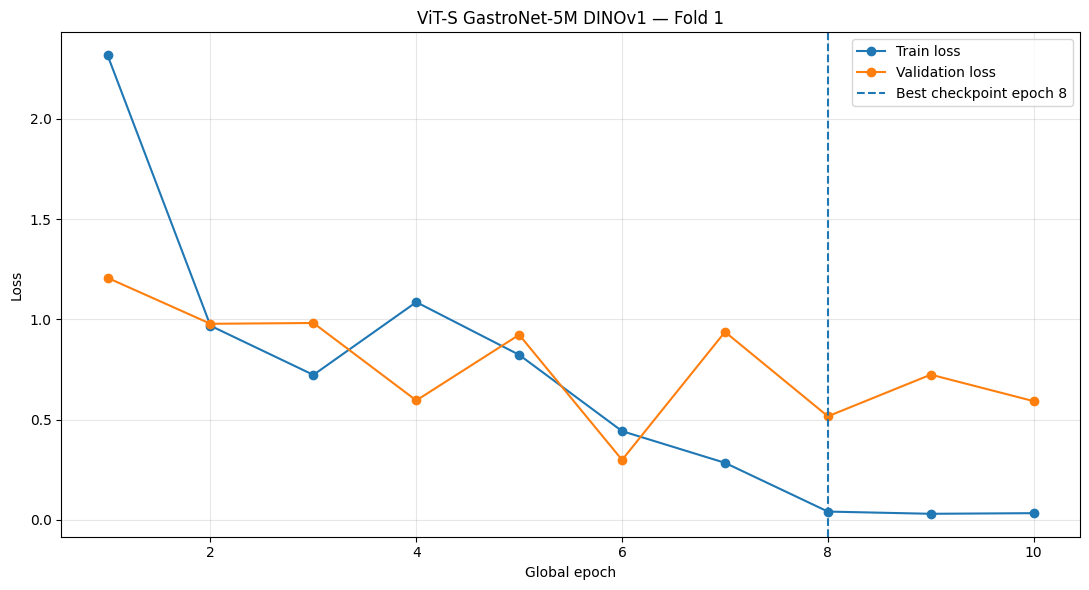

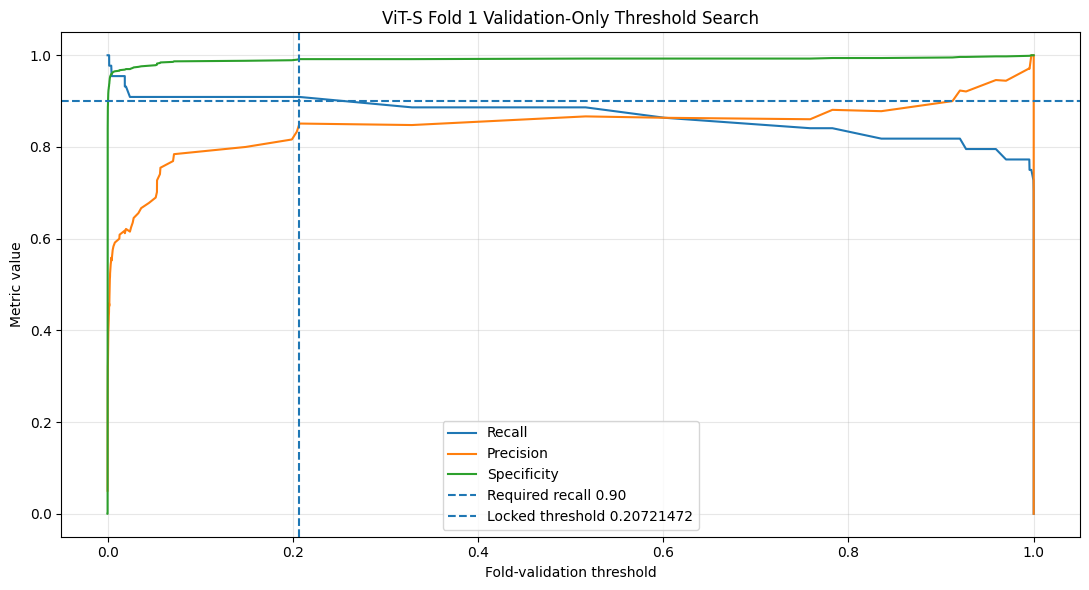


FINAL FOLD 1 REPORT
Best stage: stage_2
Best global epoch: 8
Validation AUPRC: 0.944509
Validation AUROC: 0.995427
Locked threshold: 0.207214718424
Recall: 0.909091
PPV: 0.851064
Specificity: 0.991566
Minimum centre recall: 0.882353
TP=40 | TN=823 | FP=7 | FN=4
Held-out test evaluated: False
Best fold selected: False

STARTING ViT-S CROSS-VALIDATION FOLD 2/3

Fold seed: 43
Training: 1747 (normal=1659, NEO=88)
Validation: 873 (normal=829, NEO=44)
Train/validation overlap: 0
Fold training pos_weight: 18.852273

STAGE 1: CLASSIFICATION HEAD ONLY
Fold 2 | Stage 1 | Epoch 1/3 | Global 1 | Train loss 1.900825 | Val loss 1.528571 | AUPRC 0.431596 | AUROC 0.844103
Fold 2 | Stage 1 | Epoch 2/3 | Global 2 | Train loss 1.217925 | Val loss 0.793115 | AUPRC 0.610312 | AUROC 0.911339
Fold 2 | Stage 1 | Epoch 3/3 | Global 3 | Train loss 0.921144 | Val loss 0.981204 | AUPRC 0.652284 | AUROC 0.920400

STAGE 2: FINAL 3 TRANSFORMER BLOCKS, FINAL NORM AND CLASSIFICATION HEAD
Fold 2 | Stage 2 | Epoch 1/7 

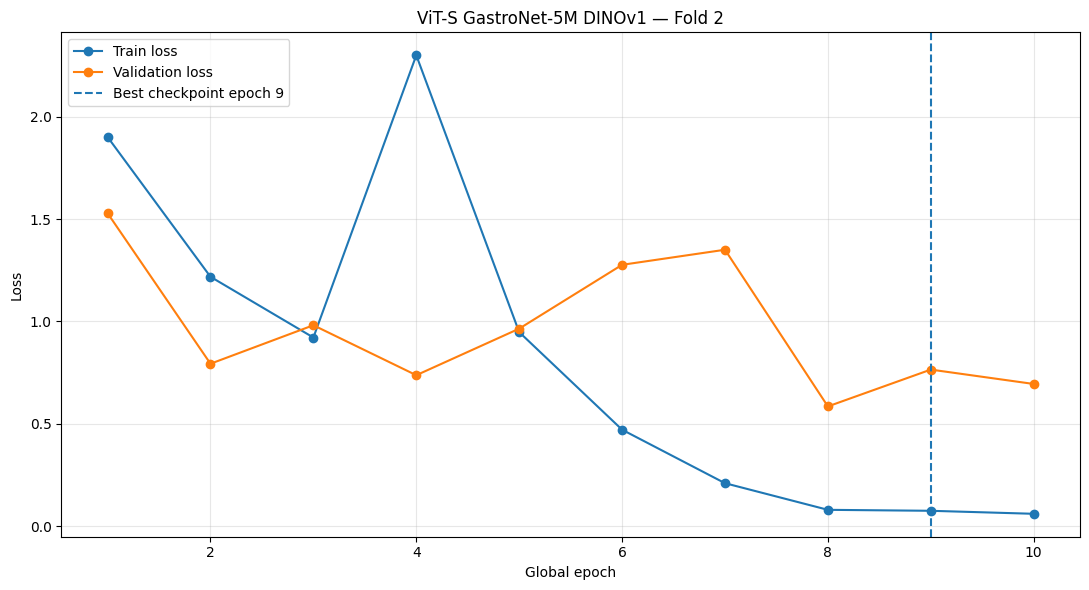

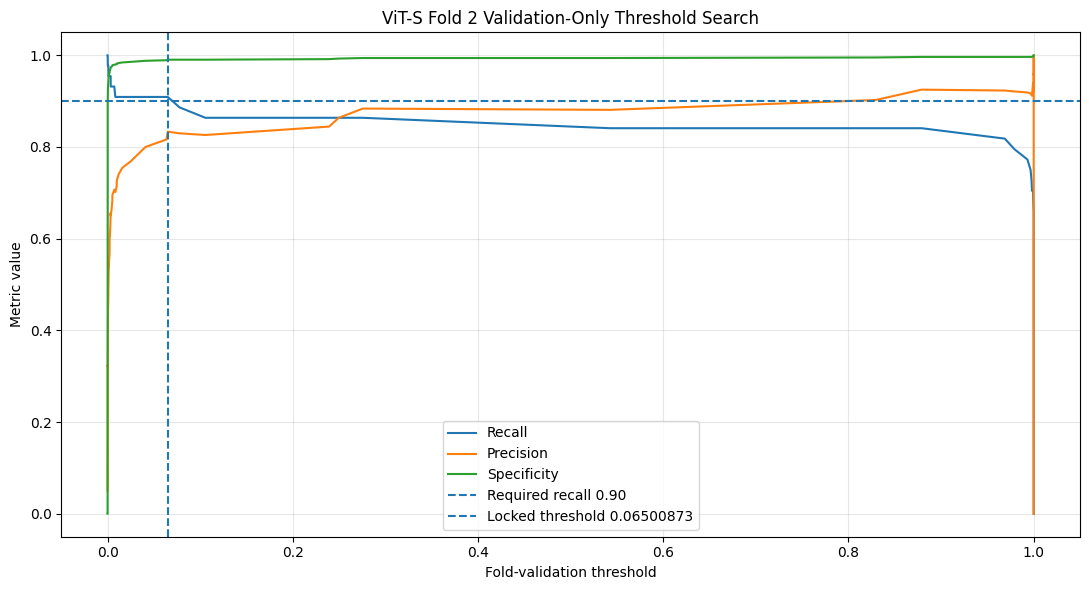


FINAL FOLD 2 REPORT
Best stage: stage_2
Best global epoch: 9
Validation AUPRC: 0.925490
Validation AUROC: 0.993653
Locked threshold: 0.065008729926
Recall: 0.909091
PPV: 0.833333
Specificity: 0.990350
Minimum centre recall: 0.882353
TP=40 | TN=821 | FP=8 | FN=4
Held-out test evaluated: False
Best fold selected: False

STARTING ViT-S CROSS-VALIDATION FOLD 3/3

Fold seed: 44
Training: 1747 (normal=1659, NEO=88)
Validation: 873 (normal=829, NEO=44)
Train/validation overlap: 0
Fold training pos_weight: 18.852273

STAGE 1: CLASSIFICATION HEAD ONLY
Fold 3 | Stage 1 | Epoch 1/3 | Global 1 | Train loss 2.248068 | Val loss 1.522198 | AUPRC 0.392242 | AUROC 0.776182
Fold 3 | Stage 1 | Epoch 2/3 | Global 2 | Train loss 0.893997 | Val loss 1.259451 | AUPRC 0.566458 | AUROC 0.852657
Fold 3 | Stage 1 | Epoch 3/3 | Global 3 | Train loss 0.805135 | Val loss 1.202006 | AUPRC 0.595475 | AUROC 0.865035

STAGE 2: FINAL 3 TRANSFORMER BLOCKS, FINAL NORM AND CLASSIFICATION HEAD
Fold 3 | Stage 2 | Epoch 1/7 

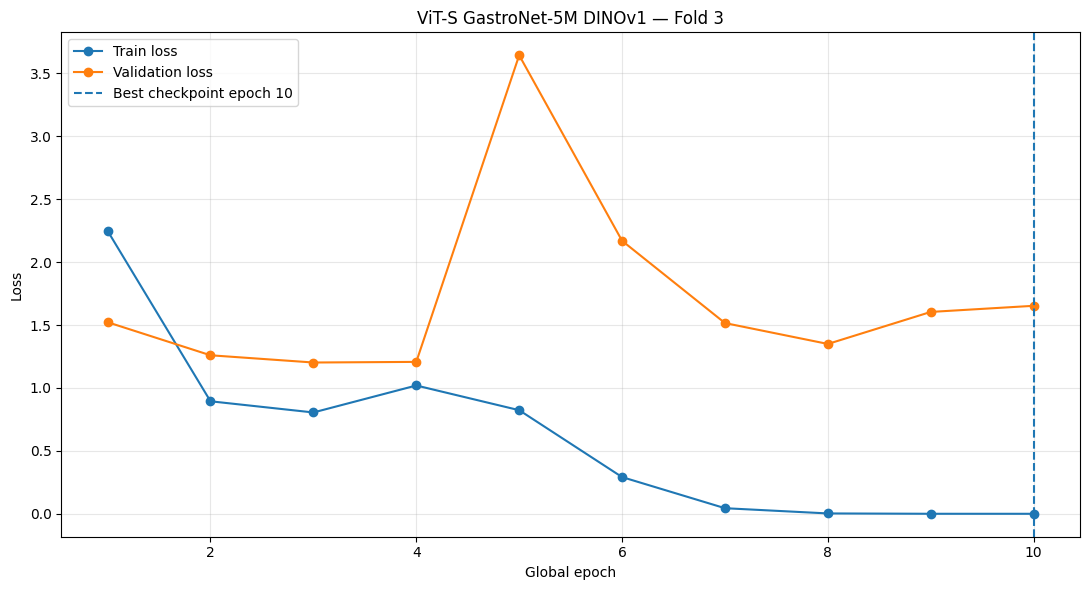

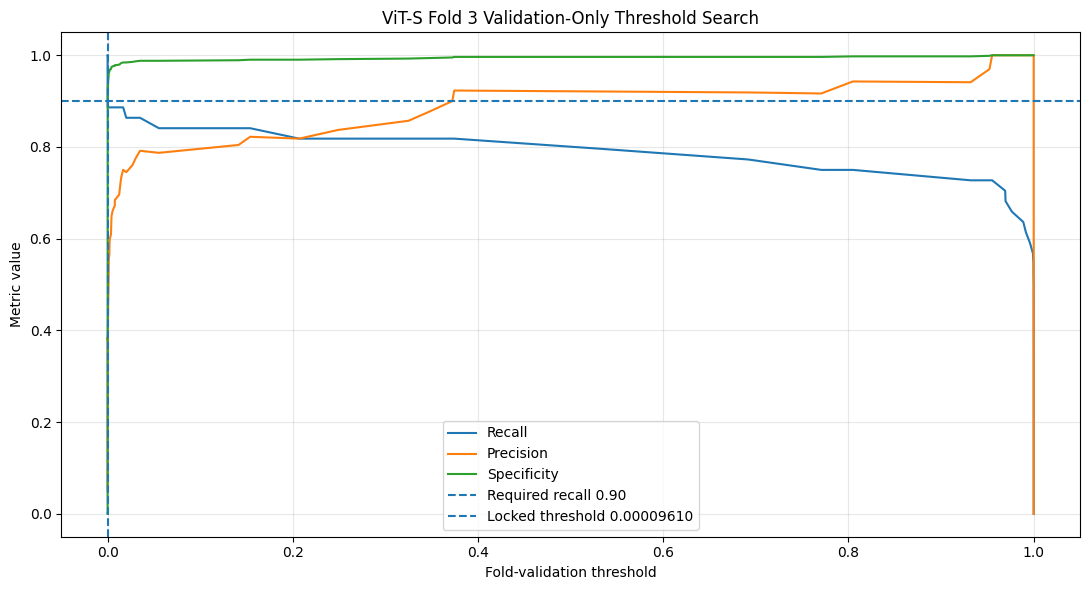


FINAL FOLD 3 REPORT
Best stage: stage_2
Best global epoch: 10
Validation AUPRC: 0.889274
Validation AUROC: 0.971954
Locked threshold: 0.000096102415
Recall: 0.909091
PPV: 0.384615
Specificity: 0.922799
Minimum centre recall: 0.823529
TP=40 | TN=765 | FP=64 | FN=4
Held-out test evaluated: False
Best fold selected: False


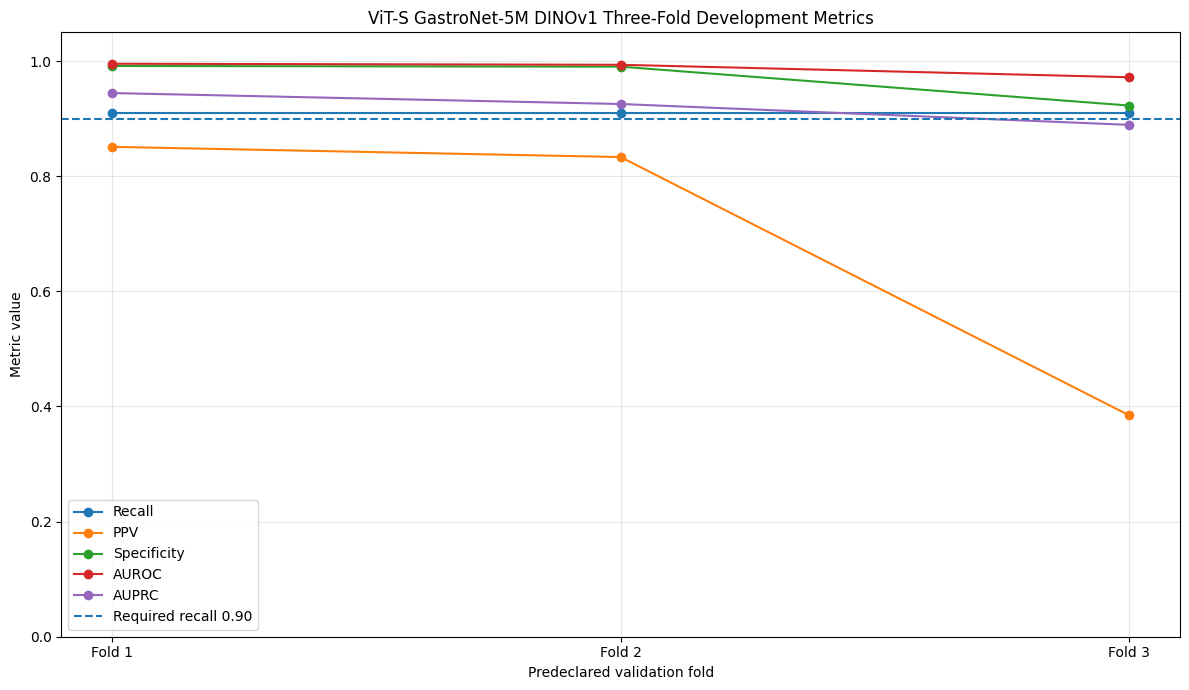

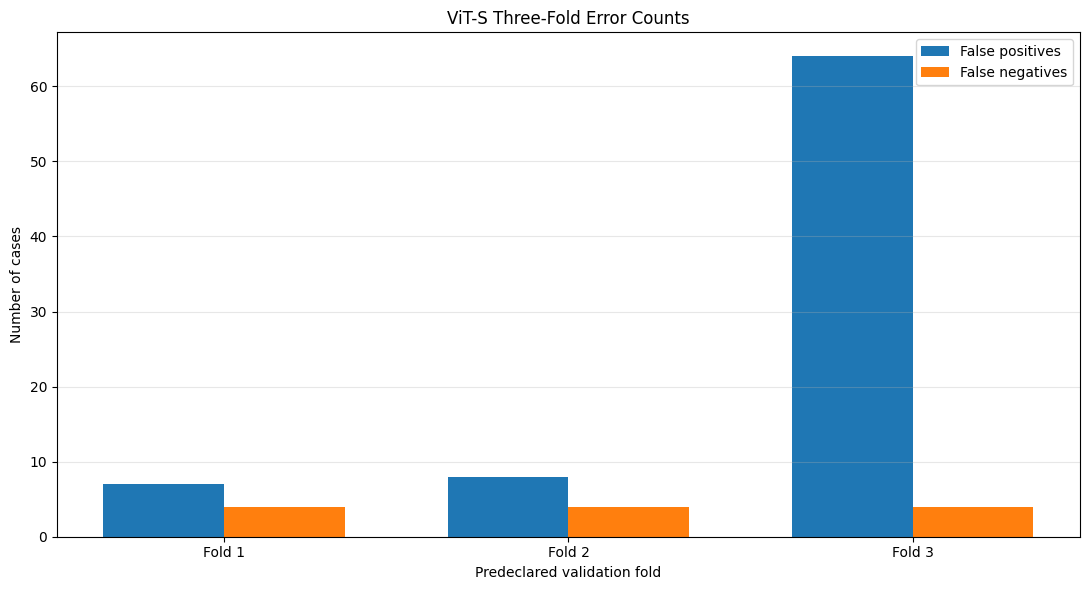

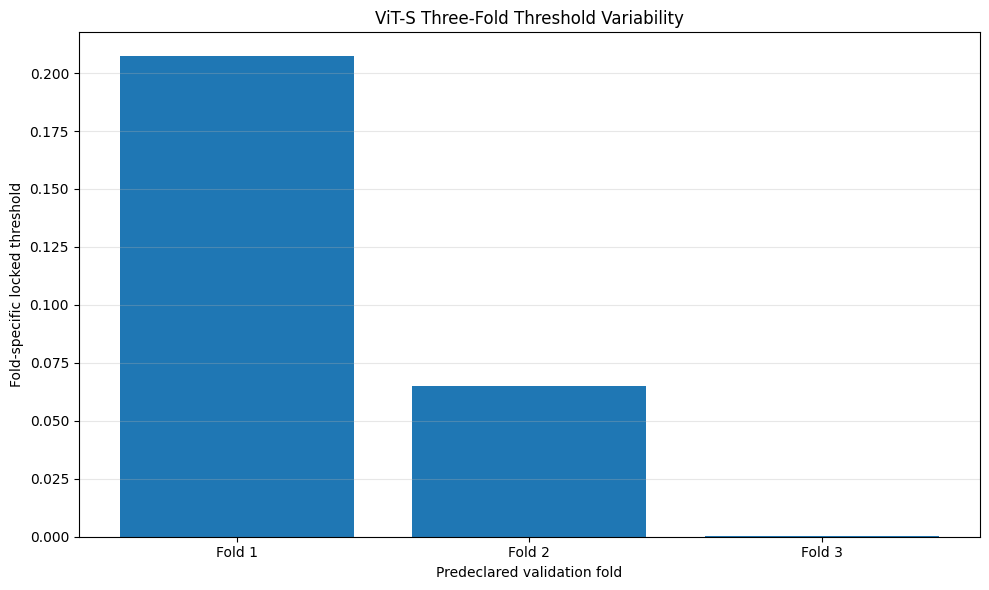

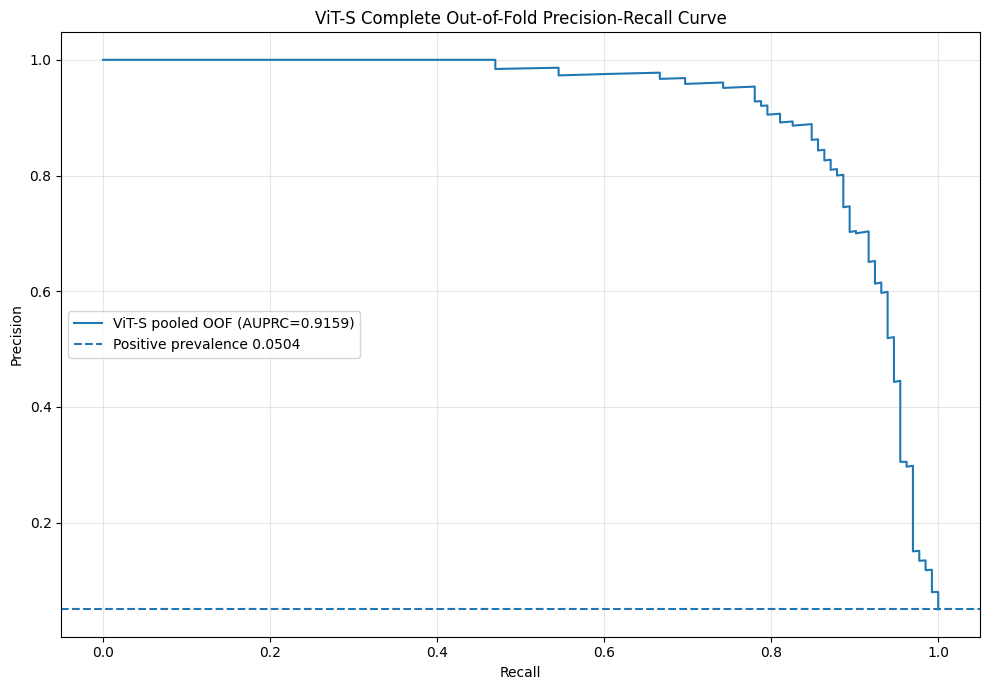

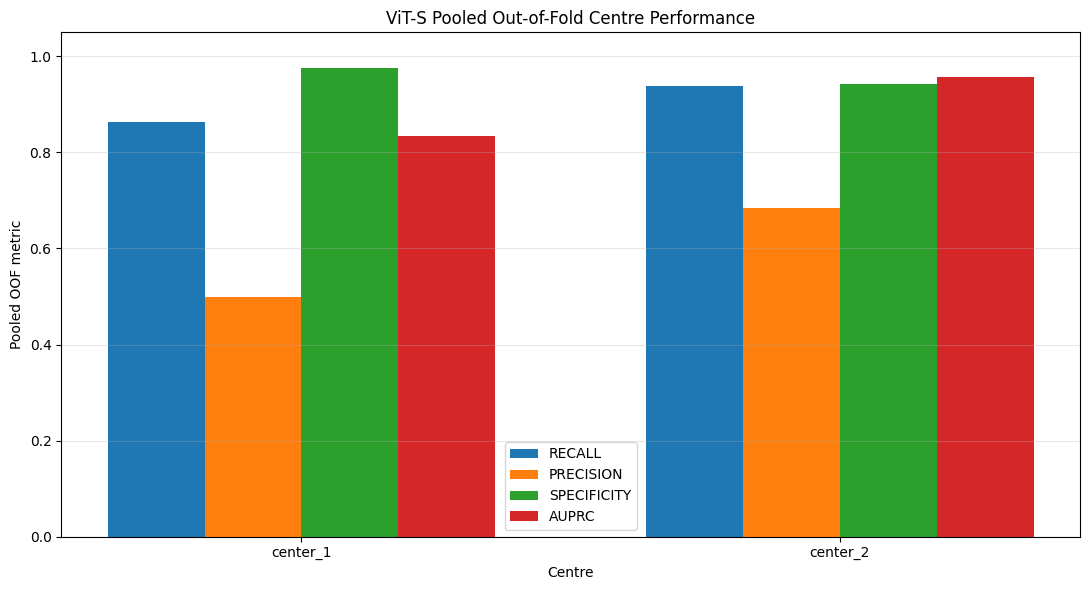


FINAL CELL 16C ViT-S THREE-FOLD CROSS-VALIDATION REPORT
Predeclared folds completed: 3/3
Fold seeds: {1: 42, 2: 43, 3: 44}
Fold assignment method: reused_previous_locked_fold_assignment
Fold assignment source: /content/drive/MyDrive/RARE26_GastroNet_Weights/predictions/cross_validation/aggregate/cell12_three_fold_oof_predictions.csv

Fold-level results:


,fold,fold_seed,best_stage,best_global_epoch,threshold,recall,precision,specificity,minimum_centre_recall,auroc,auprc,tp,tn,fp,fn,total_errors
0,1,42,stage_2,8,0.207215,0.909091,0.851064,0.991566,0.882353,0.995427,0.944509,40,823,7,4,11
1,2,43,stage_2,9,0.065009,0.909091,0.833333,0.990350,0.882353,0.993653,0.925490,40,821,8,4,12
2,3,44,stage_2,10,0.000096,0.909091,0.384615,0.922799,0.823529,0.971954,0.889274,40,765,64,4,68



Macro fold metrics:


,metric,fold_count,mean,standard_deviation,median,minimum,maximum,range
0,recall,3,0.909091,0.000000,0.909091,0.909091,0.909091,0.000000
1,precision,3,0.689671,0.264334,0.833333,0.384615,0.851064,0.466448
2,specificity,3,0.968238,0.039357,0.990350,0.922799,0.991566,0.068768
3,minimum_centre_recall,3,0.862745,0.033962,0.882353,0.823529,0.882353,0.058824
4,npv,3,0.995038,0.000207,0.995152,0.994798,0.995163,0.000365
5,accuracy,3,0.965259,0.037374,0.986254,0.922108,0.987414,0.065307
6,balanced_accuracy,3,0.938665,0.019678,0.949720,0.915945,0.950329,0.034384
7,f1,3,0.763076,0.192780,0.869565,0.540541,0.879121,0.338580
8,auroc,3,0.987012,0.013070,0.993653,0.971954,0.995427,0.023473
9,auprc,3,0.919758,0.028060,0.925490,0.889274,0.944509,0.055235



Pooled complete OOF metrics:


...


Pooled OOF per-centre metrics:


,center,model,prediction_type,sample_count,normal_count,positive_count,recall,precision,specificity,npv,accuracy,balanced_accuracy,f1,auroc,auprc,tp,tn,fp,fn,total_errors
0,center_1,vits_gastronet5m_dinov1,pooled_oof,1935,1884,51,0.862745,0.500000,0.976645,0.996210,0.973643,0.919695,0.633094,0.971665,0.834398,44,1840,44,7,51
1,center_2,vits_gastronet5m_dinov1,pooled_oof,685,604,81,0.938272,0.684685,0.942053,0.991289,0.941606,0.940162,0.791667,0.988206,0.957745,76,569,35,5,40



Threshold stability:


,fold_count,threshold_mean,threshold_standard_deviation,threshold_median,threshold_minimum,threshold_maximum,threshold_range,threshold_maximum_minimum_ratio
0,3,0.090773,0.105936,0.065009,0.000096,0.207215,0.207119,2156.18637



Macro validation AUPRC: 0.919758 ± 0.028060
Macro validation AUROC: 0.987012 ± 0.013070
Macro validation recall: 0.909091
Macro validation PPV: 0.689671 ± 0.264334
Macro validation specificity: 0.968238 ± 0.039357

Pooled OOF AUPRC: 0.915879
Pooled OOF AUROC: 0.982810
Pooled OOF recall: 0.909091
Pooled OOF PPV: 0.603015
Pooled OOF specificity: 0.968248
Pooled OOF TP=120 | TN=2409 | FP=79 | FN=12

Minimum fold recall: 0.909091
Minimum fold centre recall: 0.823529
All folds recall compliant: True
All folds centre-recall compliant: True

Development-only decision:
VITS_THREE_FOLD_CV_COMPLETE_READY_FOR_CELL16D_PAIRED_COMPARISON

Recommended next action:
Run Cell 16D using the saved ViT-S complete OOF predictions and Experiment 01 OOF predictions. Cell 16D will perform the paired CV comparison and decide the final development lead. Do not open the test set.

Held-out test CSV loaded: False
Held-out test predictions loaded: False
Held-out test evaluated: False
Held-out test used for decisio

In [ ]:
# ==========================================================================================
# CELL 16C
# ViT-S GASTRONET-5M DINOV1 — PREDECLARED THREE-FOLD CROSS-VALIDATION
#
# Scientific rules:
# - Development data only: locked train + validation = 2,620 images
# - Held-out test is never loaded or evaluated
# - Exact previous centre/class-stratified folds are reused when discoverable
# - Three folds; no best-fold selection
# - Stage 1: classification head only, 3 epochs
# - Stage 2: final 3 transformer blocks + final norm + head, max 7 epochs
# - Best checkpoint selected by fold-validation AUPRC only
# - Threshold selected independently inside each fold-validation partition
# - Required recall >= 0.90
# - Required minimum-centre recall >= 0.80
# - Completed folds are automatically reused after GPU/runtime interruption
# - Final paired comparison with Experiment 01 is reserved for Cell 16D
# ==========================================================================================

from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display

import os
import gc
import re
import json
import math
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.metrics import (
    confusion_matrix,
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
)

from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = True


# ==========================================================================================
# 1. GOOGLE DRIVE
# ==========================================================================================

DRIVE_ROOT = Path("/content/drive")
MYDRIVE_ROOT = DRIVE_ROOT / "MyDrive"

if not MYDRIVE_ROOT.exists():

    from google.colab import drive

    drive.mount(
        str(DRIVE_ROOT)
    )

if not MYDRIVE_ROOT.exists():

    raise RuntimeError(
        "Google Drive could not be mounted."
    )


# ==========================================================================================
# 2. FIXED CONFIGURATION
# ==========================================================================================

CELL_ID = (
    "cell16c_vits_gastronet5m_dinov1_"
    "three_fold_cross_validation"
)

CANDIDATE_ID = (
    "vits_gastronet5m_dinov1"
)

DISPLAY_NAME = (
    "ViT-S GastroNet-5M DINOv1"
)

NUMBER_OF_FOLDS = 3

BASE_SEED = 42

FOLD_SEEDS = {
    1: 42,
    2: 43,
    3: 44,
}

FORCE_RERUN_ALL_FOLDS = False

IMAGE_SIZE = 224
RESIZE_SIZE = 256
PATCH_SIZE = 16

BATCH_SIZE = 32
NUM_WORKERS = 2

STAGE_1_EPOCHS = 3
STAGE_2_MAX_EPOCHS = 7
STAGE_2_PATIENCE = 3

UNFROZEN_FINAL_BLOCKS = 3

STAGE_1_HEAD_LR = 1e-3
STAGE_2_BACKBONE_LR = 1e-5
STAGE_2_HEAD_LR = 1e-4

WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0

REQUIRED_OVERALL_RECALL = 0.90
REQUIRED_MINIMUM_CENTRE_RECALL = 0.80

EXPECTED_DEVELOPMENT_TOTAL = 2620
EXPECTED_DEVELOPMENT_NORMAL = 2488
EXPECTED_DEVELOPMENT_POSITIVE = 132

EXPECTED_FOLD_COUNT = 3
EXPECTED_POSITIVES_PER_FOLD = 44

EXPECTED_EMBED_DIMENSION = 384
EXPECTED_DEPTH = 12
EXPECTED_ATTENTION_HEADS = 6
EXPECTED_BACKBONE_TENSOR_COUNT = 150

FINAL_STATUS = (
    "CELL16C_VITS_GASTRONET5M_DINOV1_"
    "THREE_FOLD_CROSS_VALIDATION_COMPLETE"
)

FINAL_DEVELOPMENT_DECISION = (
    "VITS_THREE_FOLD_CV_COMPLETE_"
    "READY_FOR_CELL16D_PAIRED_COMPARISON"
)


# ==========================================================================================
# 3. PROJECT PATHS
# ==========================================================================================

PROJECT_ROOT = (
    MYDRIVE_ROOT
    / "RARE26_GastroNet_Weights"
)

CHECKPOINT_PATH = (
    PROJECT_ROOT
    / "source_checkpoints"
    / "VITS_GastroNet-5M_DINOv1.pth"
)

TRAIN_CSV_PATH = (
    PROJECT_ROOT
    / "configs"
    / "runtime_splits"
    / "train_runtime_verified.csv"
)

VALIDATION_CSV_PATH = (
    PROJECT_ROOT
    / "configs"
    / "runtime_splits"
    / "validation_runtime_verified.csv"
)

CELL16B_STATUS_PATH = (
    PROJECT_ROOT
    / "results"
    / "screening"
    / "original_split"
    / CANDIDATE_ID
    / "cell16b_status.json"
)

CELL16B_DECISION_PATH = (
    PROJECT_ROOT
    / "results"
    / "screening"
    / "original_split"
    / CANDIDATE_ID
    / "cell16b_vits_development_decision.json"
)


# ==========================================================================================
# 4. OUTPUT DIRECTORIES
# ==========================================================================================

CV_ROOT = (
    PROJECT_ROOT
    / "cross_validation"
    / CANDIDATE_ID
)

CONFIG_DIR = (
    PROJECT_ROOT
    / "configs"
    / "cross_validation"
    / CANDIDATE_ID
)

MODEL_DIR = (
    PROJECT_ROOT
    / "models"
    / "cross_validation"
    / CANDIDATE_ID
)

LOG_DIR = (
    PROJECT_ROOT
    / "logs"
    / "cross_validation"
    / CANDIDATE_ID
)

PREDICTION_DIR = (
    PROJECT_ROOT
    / "predictions"
    / "cross_validation"
    / CANDIDATE_ID
)

THRESHOLD_DIR = (
    PROJECT_ROOT
    / "thresholds"
    / "cross_validation"
    / CANDIDATE_ID
)

RESULT_DIR = (
    PROJECT_ROOT
    / "results"
    / "cross_validation"
    / CANDIDATE_ID
)

CENTRE_DIR = (
    PROJECT_ROOT
    / "centre_analysis"
    / "cross_validation"
    / CANDIDATE_ID
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "figures"
    / "cross_validation"
    / CANDIDATE_ID
)

INVENTORY_DIR = (
    PROJECT_ROOT
    / "inventory"
    / "cross_validation"
    / CANDIDATE_ID
)

for directory in [
    CV_ROOT,
    CONFIG_DIR,
    MODEL_DIR,
    LOG_DIR,
    PREDICTION_DIR,
    THRESHOLD_DIR,
    RESULT_DIR,
    CENTRE_DIR,
    FIGURE_DIR,
    INVENTORY_DIR,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ==========================================================================================
# 5. AGGREGATE OUTPUT FILES
# ==========================================================================================

FOLD_ASSIGNMENT_PATH = (
    CONFIG_DIR
    / "cell16c_vits_locked_three_fold_assignment.csv"
)

FOLD_ASSIGNMENT_SOURCE_PATH = (
    CONFIG_DIR
    / "cell16c_fold_assignment_source.json"
)

TENSOR_AUDIT_PATH = (
    INVENTORY_DIR
    / "cell16c_vits_tensor_loading_audit.csv"
)

FOLD_METRICS_PATH = (
    RESULT_DIR
    / "cell16c_vits_three_fold_metrics.csv"
)

FOLD_METRIC_SUMMARY_PATH = (
    RESULT_DIR
    / "cell16c_vits_three_fold_metric_summary.csv"
)

OOF_PREDICTION_PATH = (
    PREDICTION_DIR
    / "cell16c_vits_complete_oof_predictions.csv"
)

POOLED_OOF_METRICS_PATH = (
    RESULT_DIR
    / "cell16c_vits_pooled_oof_metrics.csv"
)

POOLED_CENTRE_METRICS_PATH = (
    CENTRE_DIR
    / "cell16c_vits_pooled_oof_per_centre_metrics.csv"
)

ALL_FOLD_CENTRE_METRICS_PATH = (
    CENTRE_DIR
    / "cell16c_vits_all_fold_per_centre_metrics.csv"
)

THRESHOLD_STABILITY_PATH = (
    THRESHOLD_DIR
    / "cell16c_vits_fold_threshold_stability.csv"
)

DECISION_PATH = (
    RESULT_DIR
    / "cell16c_vits_cv_decision.json"
)

STATUS_PATH = (
    RESULT_DIR
    / "cell16c_status.json"
)

SUMMARY_PATH = (
    RESULT_DIR
    / "cell16c_vits_three_fold_cv_summary.txt"
)

FOLD_METRICS_FIGURE_PATH = (
    FIGURE_DIR
    / "cell16c_vits_fold_metric_comparison.png"
)

FOLD_ERRORS_FIGURE_PATH = (
    FIGURE_DIR
    / "cell16c_vits_fold_error_comparison.png"
)

THRESHOLD_FIGURE_PATH = (
    FIGURE_DIR
    / "cell16c_vits_threshold_variability.png"
)

OOF_PR_FIGURE_PATH = (
    FIGURE_DIR
    / "cell16c_vits_pooled_oof_precision_recall_curve.png"
)

CENTRE_FIGURE_PATH = (
    FIGURE_DIR
    / "cell16c_vits_pooled_oof_centre_metrics.png"
)


# ==========================================================================================
# 6. INITIAL REPORT
# ==========================================================================================

print("=" * 118)

print(
    "CELL 16C: ViT-S GASTRONET-5M DINOV1 "
    "PREDECLARED THREE-FOLD CROSS-VALIDATION"
)

print("=" * 118)

print("\nCandidate:")
print(DISPLAY_NAME)

print("\nPretrained checkpoint:")
print(CHECKPOINT_PATH)

print("\nPredeclared folds:")
print(NUMBER_OF_FOLDS)

print("\nFixed fold seeds:")
print(FOLD_SEEDS)

print("\nTraining split:")
print(TRAIN_CSV_PATH)

print("\nValidation split:")
print(VALIDATION_CSV_PATH)

print("\nHeld-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("Held-out test used for any decision: False")
print("Best fold selected: False")
print("Best seed selected: False")
print("Threshold selected using test: False")


# ==========================================================================================
# 7. VERIFY REQUIRED FILES AND CELL 16B
# ==========================================================================================

required_files = [
    CHECKPOINT_PATH,
    TRAIN_CSV_PATH,
    VALIDATION_CSV_PATH,
    CELL16B_STATUS_PATH,
    CELL16B_DECISION_PATH,
]

missing_required_files = [
    path
    for path in required_files
    if not path.exists()
]

if missing_required_files:

    print("\nMissing required files:")

    for path in missing_required_files:
        print(path)

    raise FileNotFoundError(
        "One or more files required for Cell 16C are missing."
    )


cell16b_status_record = json.loads(
    CELL16B_STATUS_PATH.read_text(
        encoding="utf-8"
    )
)

cell16b_decision_record = json.loads(
    CELL16B_DECISION_PATH.read_text(
        encoding="utf-8"
    )
)

cell16b_status = (
    cell16b_status_record.get(
        "status"
    )
)

cell16b_decision = (
    cell16b_decision_record.get(
        "decision"
    )
)

expected_cell16b_status = (
    "CELL16B_VITS_GASTRONET5M_DINOV1_"
    "CONTROLLED_SCREENING_COMPLETE"
)

expected_cell16b_decision = (
    "VITS_PROVISIONAL_VALIDATION_LEAD_"
    "ADVANCE_TO_FULL_CV"
)

if cell16b_status != expected_cell16b_status:

    raise RuntimeError(
        "Cell 16B completion status was not verified.\n"
        f"Expected: {expected_cell16b_status}\n"
        f"Found: {cell16b_status}"
    )

if cell16b_decision != expected_cell16b_decision:

    raise RuntimeError(
        "Cell 16B did not authorize ViT-S full CV.\n"
        f"Expected: {expected_cell16b_decision}\n"
        f"Found: {cell16b_decision}"
    )

print("\nCell 16B completion verified:")
print(cell16b_status)

print("\nCell 16B development decision verified:")
print(cell16b_decision)


# ==========================================================================================
# 8. GPU VERIFICATION
# ==========================================================================================

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

USE_AMP = (
    DEVICE.type == "cuda"
)

print("\nCompute device:")
print(DEVICE)

if DEVICE.type != "cuda":

    raise RuntimeError(
        "Cell 16C requires a GPU.\n"
        "Connect a T4 GPU, run Cell 3B after the new runtime starts, "
        "and rerun the complete Cell 16C."
    )

GPU_NAME = torch.cuda.get_device_name(
    0
)

print(GPU_NAME)


# ==========================================================================================
# 9. REPRODUCIBILITY HELPERS
# ==========================================================================================

def set_complete_seed(
    seed,
):

    os.environ[
        "PYTHONHASHSEED"
    ] = str(seed)

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    try:

        torch.use_deterministic_algorithms(
            True,
            warn_only=True,
        )

    except Exception:

        pass


def seed_worker(
    worker_id,
):

    worker_seed = (
        torch.initial_seed()
        % (2 ** 32)
    )

    np.random.seed(
        worker_seed
    )

    random.seed(
        worker_seed
    )


# ==========================================================================================
# 10. GENERAL COLUMN HELPERS
# ==========================================================================================

def find_column(
    dataframe,
    candidates,
    description,
    required=True,
):

    lowercase_map = {
        str(column).strip().lower(): column
        for column in dataframe.columns
    }

    for candidate in candidates:

        if candidate in dataframe.columns:
            return candidate

        if candidate.lower() in lowercase_map:

            return lowercase_map[
                candidate.lower()
            ]

    if required:

        raise KeyError(
            f"Could not find {description} column.\n"
            f"Available columns:\n"
            f"{list(dataframe.columns)}"
        )

    return None


PATH_CANDIDATES = [
    "runtime_path",
    "image_path",
    "filepath",
    "file_path",
    "path",
]

RELATIVE_PATH_CANDIDATES = [
    "relative_path",
    "original_relative_path",
    "image_relative_path",
]

LABEL_CANDIDATES = [
    "label",
    "target",
    "ground_truth",
    "class_label",
    "y_true",
]

CENTER_CANDIDATES = [
    "center",
    "centre",
    "site",
]

SHA_CANDIDATES = [
    "sha256",
    "image_sha256",
    "file_sha256",
    "case_sha256",
]

FOLD_CANDIDATES = [
    "fold",
    "fold_id",
    "fold_number",
    "cv_fold",
    "validation_fold",
    "oof_fold",
]


def normalize_sha(
    series,
):

    return (
        series.astype(str)
        .str.strip()
        .str.lower()
    )


def normalize_path_identity(
    series,
):

    return (
        series.astype(str)
        .str.replace(
            "\\",
            "/",
            regex=False,
        )
        .str.strip()
        .str.lower()
        .str.lstrip("/")
    )


# ==========================================================================================
# 11. LOAD AND STANDARDIZE DEVELOPMENT POOL
# ==========================================================================================

train_raw_df = pd.read_csv(
    TRAIN_CSV_PATH,
    low_memory=False,
)

validation_raw_df = pd.read_csv(
    VALIDATION_CSV_PATH,
    low_memory=False,
)

train_path_column = find_column(
    train_raw_df,
    PATH_CANDIDATES,
    "training runtime path",
)

validation_path_column = find_column(
    validation_raw_df,
    PATH_CANDIDATES,
    "validation runtime path",
)

train_relative_path_column = find_column(
    train_raw_df,
    RELATIVE_PATH_CANDIDATES,
    "training relative path",
)

validation_relative_path_column = find_column(
    validation_raw_df,
    RELATIVE_PATH_CANDIDATES,
    "validation relative path",
)

train_label_column = find_column(
    train_raw_df,
    LABEL_CANDIDATES,
    "training label",
)

validation_label_column = find_column(
    validation_raw_df,
    LABEL_CANDIDATES,
    "validation label",
)

train_center_column = find_column(
    train_raw_df,
    CENTER_CANDIDATES,
    "training centre",
)

validation_center_column = find_column(
    validation_raw_df,
    CENTER_CANDIDATES,
    "validation centre",
)

train_sha_column = find_column(
    train_raw_df,
    SHA_CANDIDATES,
    "training SHA-256",
)

validation_sha_column = find_column(
    validation_raw_df,
    SHA_CANDIDATES,
    "validation SHA-256",
)


train_df = pd.DataFrame(
    {
        "sha256": normalize_sha(
            train_raw_df[
                train_sha_column
            ]
        ),
        "runtime_path": (
            train_raw_df[
                train_path_column
            ].astype(str)
        ),
        "relative_path": (
            train_raw_df[
                train_relative_path_column
            ].astype(str)
        ),
        "label": pd.to_numeric(
            train_raw_df[
                train_label_column
            ],
            errors="raise",
        ).astype(int),
        "center": (
            train_raw_df[
                train_center_column
            ].astype(str)
        ),
        "original_split": (
            "train"
        ),
    }
)

validation_df = pd.DataFrame(
    {
        "sha256": normalize_sha(
            validation_raw_df[
                validation_sha_column
            ]
        ),
        "runtime_path": (
            validation_raw_df[
                validation_path_column
            ].astype(str)
        ),
        "relative_path": (
            validation_raw_df[
                validation_relative_path_column
            ].astype(str)
        ),
        "label": pd.to_numeric(
            validation_raw_df[
                validation_label_column
            ],
            errors="raise",
        ).astype(int),
        "center": (
            validation_raw_df[
                validation_center_column
            ].astype(str)
        ),
        "original_split": (
            "validation"
        ),
    }
)

development_df = pd.concat(
    [
        train_df,
        validation_df,
    ],
    ignore_index=True,
)

development_df[
    "relative_path_normalized"
] = normalize_path_identity(
    development_df[
        "relative_path"
    ]
)

development_df[
    "runtime_path_normalized"
] = normalize_path_identity(
    development_df[
        "runtime_path"
    ]
)

development_df[
    "stratum"
] = (
    development_df[
        "center"
    ].astype(str)
    + "__"
    + development_df[
        "label"
    ].astype(str)
)

development_total = len(
    development_df
)

development_normal = int(
    (
        development_df[
            "label"
        ]
        == 0
    ).sum()
)

development_positive = int(
    (
        development_df[
            "label"
        ]
        == 1
    ).sum()
)

if development_total != EXPECTED_DEVELOPMENT_TOTAL:

    raise RuntimeError(
        "Development-pool total mismatch.\n"
        f"Expected: {EXPECTED_DEVELOPMENT_TOTAL}\n"
        f"Found: {development_total}"
    )

if development_normal != EXPECTED_DEVELOPMENT_NORMAL:

    raise RuntimeError(
        "Development-pool normal-count mismatch.\n"
        f"Expected: {EXPECTED_DEVELOPMENT_NORMAL}\n"
        f"Found: {development_normal}"
    )

if development_positive != EXPECTED_DEVELOPMENT_POSITIVE:

    raise RuntimeError(
        "Development-pool positive-count mismatch.\n"
        f"Expected: {EXPECTED_DEVELOPMENT_POSITIVE}\n"
        f"Found: {development_positive}"
    )

if development_df[
    "sha256"
].duplicated().any():

    duplicate_count = int(
        development_df[
            "sha256"
        ].duplicated().sum()
    )

    raise RuntimeError(
        f"Duplicate SHA-256 cases in development pool: "
        f"{duplicate_count}"
    )

missing_images = [
    path
    for path in development_df[
        "runtime_path"
    ]
    if not Path(path).exists()
]

if missing_images:

    raise FileNotFoundError(
        f"{len(missing_images)} development images are missing "
        "from temporary Colab storage.\n"
        "Run Cell 3B before Cell 16C."
    )

print("\nLocked development pool verified:")

print(
    f"Total: {development_total}"
)

print(
    f"Normal: {development_normal}"
)

print(
    f"Neoplasia: {development_positive}"
)

print(
    f"Unique SHA-256 cases: "
    f"{development_df['sha256'].nunique()}"
)

print(
    f"Missing runtime images: "
    f"{len(missing_images)}"
)

print("\nDevelopment centre/class distribution:")

display(
    development_df.groupby(
        [
            "center",
            "label",
        ],
        sort=True,
    )
    .size()
    .reset_index(
        name="count"
    )
)


# ==========================================================================================
# 12. DISCOVER AND REUSE THE PREVIOUS LOCKED FOLD ASSIGNMENT
# ==========================================================================================

def discover_existing_fold_assignment(
    development_manifest,
):

    search_roots = [
        PROJECT_ROOT
        / "configs",
        PROJECT_ROOT
        / "predictions",
        PROJECT_ROOT
        / "results",
        PROJECT_ROOT
        / "inventory",
    ]

    candidate_paths = []

    for search_root in search_roots:

        if not search_root.exists():
            continue

        for csv_path in search_root.rglob(
            "*.csv"
        ):

            path_text = str(
                csv_path
            ).lower()

            filename_text = (
                csv_path.name.lower()
            )

            if "test" in path_text:
                continue

            if CANDIDATE_ID in path_text:
                continue

            relevant_tokens = [
                "oof",
                "fold",
                "cross",
                "cv",
                "exp01",
                "experiment_01",
                "gastronet5m_dinov1",
            ]

            if not any(
                token in filename_text
                or token in path_text
                for token in relevant_tokens
            ):
                continue

            if any(
                token in filename_text
                for token in [
                    "bootstrap",
                    "threshold",
                    "history",
                    "metric",
                    "summary",
                    "centre",
                    "center",
                    "comparison",
                ]
            ):
                continue

            candidate_paths.append(
                csv_path
            )

    discovery_rows = []
    valid_candidates = []

    for csv_path in sorted(
        set(
            candidate_paths
        )
    ):

        try:

            header_df = pd.read_csv(
                csv_path,
                nrows=5,
                low_memory=False,
            )

        except Exception as error:

            discovery_rows.append(
                {
                    "path": str(
                        csv_path
                    ),
                    "status": (
                        "READ_HEADER_FAILED"
                    ),
                    "error": str(
                        error
                    ),
                }
            )

            continue

        fold_column = find_column(
            header_df,
            FOLD_CANDIDATES,
            "fold",
            required=False,
        )

        sha_column = find_column(
            header_df,
            SHA_CANDIDATES,
            "SHA-256",
            required=False,
        )

        relative_column = find_column(
            header_df,
            RELATIVE_PATH_CANDIDATES,
            "relative path",
            required=False,
        )

        if fold_column is None:

            continue

        if (
            sha_column is None
            and relative_column is None
        ):

            continue

        try:

            source_df = pd.read_csv(
                csv_path,
                low_memory=False,
            )

        except Exception as error:

            discovery_rows.append(
                {
                    "path": str(
                        csv_path
                    ),
                    "status": (
                        "READ_FULL_FAILED"
                    ),
                    "error": str(
                        error
                    ),
                }
            )

            continue

        if len(
            source_df
        ) != EXPECTED_DEVELOPMENT_TOTAL:

            discovery_rows.append(
                {
                    "path": str(
                        csv_path
                    ),
                    "status": (
                        "WRONG_ROW_COUNT"
                    ),
                    "row_count": len(
                        source_df
                    ),
                }
            )

            continue

        if sha_column is not None:

            identity_type = (
                "sha256"
            )

            source_identity = normalize_sha(
                source_df[
                    sha_column
                ]
            )

            manifest_identity = (
                development_manifest[
                    "sha256"
                ]
            )

        else:

            identity_type = (
                "relative_path"
            )

            source_identity = (
                normalize_path_identity(
                    source_df[
                        relative_column
                    ]
                )
            )

            manifest_identity = (
                development_manifest[
                    "relative_path_normalized"
                ]
            )

        if source_identity.duplicated().any():

            discovery_rows.append(
                {
                    "path": str(
                        csv_path
                    ),
                    "status": (
                        "DUPLICATE_IDENTITIES"
                    ),
                    "identity_type": (
                        identity_type
                    ),
                }
            )

            continue

        source_identity_set = set(
            source_identity
        )

        manifest_identity_set = set(
            manifest_identity
        )

        matched_count = len(
            source_identity_set.intersection(
                manifest_identity_set
            )
        )

        fold_values_raw = pd.to_numeric(
            source_df[
                fold_column
            ],
            errors="coerce",
        )

        unique_fold_values = sorted(
            fold_values_raw.dropna()
            .astype(int)
            .unique()
            .tolist()
        )

        exact_identity_match = bool(
            matched_count
            == EXPECTED_DEVELOPMENT_TOTAL
        )

        three_folds_found = bool(
            len(
                unique_fold_values
            )
            == EXPECTED_FOLD_COUNT
        )

        filename_lower = (
            csv_path.name.lower()
        )

        path_lower = str(
            csv_path
        ).lower()

        source_score = 0

        if "exp01" in path_lower:
            source_score += 50

        if "experiment_01" in path_lower:
            source_score += 50

        if "oof" in filename_lower:
            source_score += 30

        if "fold" in filename_lower:
            source_score += 20

        if "cross" in path_lower:
            source_score += 10

        if identity_type == "sha256":
            source_score += 10

        if exact_identity_match:
            source_score += 100

        if three_folds_found:
            source_score += 100

        discovery_rows.append(
            {
                "path": str(
                    csv_path
                ),
                "status": (
                    "VALID_CANDIDATE"
                    if (
                        exact_identity_match
                        and three_folds_found
                    )
                    else "INVALID_CANDIDATE"
                ),
                "row_count": len(
                    source_df
                ),
                "identity_type": (
                    identity_type
                ),
                "matched_count": (
                    matched_count
                ),
                "fold_column": (
                    fold_column
                ),
                "unique_fold_values": str(
                    unique_fold_values
                ),
                "score": (
                    source_score
                ),
            }
        )

        if (
            exact_identity_match
            and three_folds_found
        ):

            valid_candidates.append(
                {
                    "path": (
                        csv_path
                    ),
                    "dataframe": (
                        source_df
                    ),
                    "fold_column": (
                        fold_column
                    ),
                    "identity_type": (
                        identity_type
                    ),
                    "identity_series": (
                        source_identity
                    ),
                    "fold_values": (
                        fold_values_raw.astype(
                            int
                        )
                    ),
                    "unique_fold_values": (
                        unique_fold_values
                    ),
                    "score": (
                        source_score
                    ),
                }
            )

    discovery_df = pd.DataFrame(
        discovery_rows
    )

    discovery_path = (
        INVENTORY_DIR
        / "cell16c_previous_fold_assignment_discovery.csv"
    )

    discovery_df.to_csv(
        discovery_path,
        index=False,
    )

    if not valid_candidates:

        return (
            None,
            discovery_df,
            discovery_path,
        )

    valid_candidates.sort(
        key=lambda record: (
            record[
                "score"
            ],
            str(
                record[
                    "path"
                ]
            ),
        ),
        reverse=True,
    )

    return (
        valid_candidates[0],
        discovery_df,
        discovery_path,
    )


selected_fold_source = None
fold_assignment_method = None
fold_source_path = None
fold_source_identity_type = None

if (
    FOLD_ASSIGNMENT_PATH.exists()
    and FOLD_ASSIGNMENT_SOURCE_PATH.exists()
):

    existing_fold_df = pd.read_csv(
        FOLD_ASSIGNMENT_PATH,
        low_memory=False,
    )

    existing_source_record = json.loads(
        FOLD_ASSIGNMENT_SOURCE_PATH.read_text(
            encoding="utf-8"
        )
    )

    if (
        len(
            existing_fold_df
        )
        == EXPECTED_DEVELOPMENT_TOTAL
        and existing_fold_df[
            "sha256"
        ].nunique()
        == EXPECTED_DEVELOPMENT_TOTAL
        and existing_fold_df[
            "fold"
        ].nunique()
        == EXPECTED_FOLD_COUNT
    ):

        fold_assignment_df = (
            existing_fold_df.copy()
        )

        fold_assignment_method = (
            existing_source_record.get(
                "assignment_method"
            )
        )

        fold_source_path = (
            existing_source_record.get(
                "source_path"
            )
        )

        fold_source_identity_type = (
            existing_source_record.get(
                "source_identity_type"
            )
        )

        print(
            "\nExisting Cell 16C fold assignment "
            "was found and will be reused."
        )

    else:

        raise RuntimeError(
            "Existing Cell 16C fold-assignment file is invalid."
        )

else:

    (
        selected_fold_source,
        fold_discovery_df,
        fold_discovery_path,
    ) = discover_existing_fold_assignment(
        development_df
    )

    if selected_fold_source is not None:

        source_df = (
            selected_fold_source[
                "dataframe"
            ].copy()
        )

        source_identity = (
            selected_fold_source[
                "identity_series"
            ]
        )

        source_fold_values = (
            selected_fold_source[
                "fold_values"
            ]
        )

        raw_unique_folds = sorted(
            source_fold_values.unique()
            .tolist()
        )

        fold_normalization_map = {
            raw_fold_value: (
                normalized_index + 1
            )
            for normalized_index, raw_fold_value
            in enumerate(
                raw_unique_folds
            )
        }

        normalized_source_folds = (
            source_fold_values.map(
                fold_normalization_map
            ).astype(int)
        )

        if selected_fold_source[
            "identity_type"
        ] == "sha256":

            fold_lookup_df = pd.DataFrame(
                {
                    "sha256": (
                        source_identity
                    ),
                    "fold": (
                        normalized_source_folds
                    ),
                }
            )

            fold_assignment_df = (
                development_df.merge(
                    fold_lookup_df,
                    on="sha256",
                    how="left",
                    validate="one_to_one",
                )
            )

        else:

            fold_lookup_df = pd.DataFrame(
                {
                    "relative_path_normalized": (
                        source_identity
                    ),
                    "fold": (
                        normalized_source_folds
                    ),
                }
            )

            fold_assignment_df = (
                development_df.merge(
                    fold_lookup_df,
                    on=(
                        "relative_path_normalized"
                    ),
                    how="left",
                    validate="one_to_one",
                )
            )

        if fold_assignment_df[
            "fold"
        ].isna().any():

            raise RuntimeError(
                "The discovered prior fold assignment could not "
                "be mapped to all development cases."
            )

        fold_assignment_df[
            "fold"
        ] = fold_assignment_df[
            "fold"
        ].astype(int)

        fold_assignment_method = (
            "reused_previous_locked_fold_assignment"
        )

        fold_source_path = str(
            selected_fold_source[
                "path"
            ]
        )

        fold_source_identity_type = (
            selected_fold_source[
                "identity_type"
            ]
        )

        print(
            "\nPrevious development fold assignment discovered:"
        )

        print(
            fold_source_path
        )

        print(
            "The same fold assignment will be reused "
            "for direct comparability."
        )

    else:

        print(
            "\nWARNING: A previous exact fold-assignment file "
            "was not discovered automatically."
        )

        print(
            "Reconstructing the predeclared centre/class-stratified "
            "three-fold split using seed 42 and SHA-sorted cases."
        )

        sorted_development_df = (
            development_df.sort_values(
                "sha256"
            )
            .reset_index(
                drop=True
            )
            .copy()
        )

        fold_array = np.zeros(
            len(
                sorted_development_df
            ),
            dtype=int,
        )

        stratified_splitter = StratifiedKFold(
            n_splits=NUMBER_OF_FOLDS,
            shuffle=True,
            random_state=BASE_SEED,
        )

        for fold_index, (
            _,
            validation_indices,
        ) in enumerate(
            stratified_splitter.split(
                sorted_development_df[
                    "sha256"
                ],
                sorted_development_df[
                    "stratum"
                ],
            ),
            start=1,
        ):

            fold_array[
                validation_indices
            ] = fold_index

        sorted_development_df[
            "fold"
        ] = fold_array

        fold_assignment_df = (
            development_df.merge(
                sorted_development_df[
                    [
                        "sha256",
                        "fold",
                    ]
                ],
                on="sha256",
                how="left",
                validate="one_to_one",
            )
        )

        fold_assignment_method = (
            "deterministic_reconstruction_"
            "stratified_by_center_and_class_"
            "seed_42_sha_sorted"
        )

        fold_source_path = None

        fold_source_identity_type = (
            "sha256"
        )

    fold_assignment_df.to_csv(
        FOLD_ASSIGNMENT_PATH,
        index=False,
    )

    fold_source_record = {
        "created_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "assignment_method": (
            fold_assignment_method
        ),
        "source_path": (
            fold_source_path
        ),
        "source_identity_type": (
            fold_source_identity_type
        ),
        "fold_count": (
            NUMBER_OF_FOLDS
        ),
        "base_seed": (
            BASE_SEED
        ),
        "held_out_test_loaded": False,
        "held_out_test_used": False,
    }

    FOLD_ASSIGNMENT_SOURCE_PATH.write_text(
        json.dumps(
            fold_source_record,
            indent=2,
            ensure_ascii=False,
        ),
        encoding="utf-8",
    )


# ==========================================================================================
# 13. VERIFY FOLD ASSIGNMENT
# ==========================================================================================

if len(
    fold_assignment_df
) != EXPECTED_DEVELOPMENT_TOTAL:

    raise RuntimeError(
        "Fold-assignment row count mismatch."
    )

if fold_assignment_df[
    "sha256"
].nunique() != EXPECTED_DEVELOPMENT_TOTAL:

    raise RuntimeError(
        "Fold-assignment SHA-256 identities are not unique."
    )

if fold_assignment_df[
    "fold"
].nunique() != EXPECTED_FOLD_COUNT:

    raise RuntimeError(
        "Fold assignment does not contain exactly three folds."
    )

fold_assignment_df[
    "fold"
] = pd.to_numeric(
    fold_assignment_df[
        "fold"
    ],
    errors="raise",
).astype(int)

expected_fold_values = [
    1,
    2,
    3,
]

actual_fold_values = sorted(
    fold_assignment_df[
        "fold"
    ].unique()
    .tolist()
)

if actual_fold_values != expected_fold_values:

    raise RuntimeError(
        "Normalized fold values are invalid.\n"
        f"Expected: {expected_fold_values}\n"
        f"Found: {actual_fold_values}"
    )

fold_distribution_df = (
    fold_assignment_df.groupby(
        [
            "fold",
            "center",
            "label",
        ],
        sort=True,
    )
    .size()
    .reset_index(
        name="count"
    )
)

fold_summary_df = (
    fold_assignment_df.groupby(
        "fold",
        sort=True,
    )
    .agg(
        sample_count=(
            "sha256",
            "size",
        ),
        normal_count=(
            "label",
            lambda values: int(
                (
                    values == 0
                ).sum()
            ),
        ),
        positive_count=(
            "label",
            lambda values: int(
                (
                    values == 1
                ).sum()
            ),
        ),
    )
    .reset_index()
)

for fold_row in (
    fold_summary_df.itertuples(
        index=False
    )
):

    if int(
        fold_row.positive_count
    ) != EXPECTED_POSITIVES_PER_FOLD:

        raise RuntimeError(
            f"Fold {fold_row.fold} contains "
            f"{fold_row.positive_count} positives; "
            f"expected {EXPECTED_POSITIVES_PER_FOLD}."
        )

print("\nFold assignment method:")
print(fold_assignment_method)

print("\nFold-assignment source:")
print(
    fold_source_path
    if fold_source_path is not None
    else "Deterministically reconstructed"
)

print("\nFold summary:")

display(
    fold_summary_df
)

print("\nFold centre/class distribution:")

display(
    fold_distribution_df
)


# ==========================================================================================
# 14. METRIC HELPERS
# ==========================================================================================

def safe_divide(
    numerator,
    denominator,
):

    if denominator == 0:
        return 0.0

    return float(
        numerator
        / denominator
    )


def calculate_metrics(
    labels,
    probabilities,
    predictions,
):

    labels = np.asarray(
        labels,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    predictions = np.asarray(
        predictions,
        dtype=int,
    )

    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[
            0,
            1,
        ],
    ).ravel()

    recall = safe_divide(
        tp,
        tp + fn,
    )

    precision = safe_divide(
        tp,
        tp + fp,
    )

    specificity = safe_divide(
        tn,
        tn + fp,
    )

    npv = safe_divide(
        tn,
        tn + fn,
    )

    accuracy = safe_divide(
        tp + tn,
        len(
            labels
        ),
    )

    balanced_accuracy = (
        recall
        + specificity
    ) / 2.0

    f1 = safe_divide(
        2.0
        * precision
        * recall,
        precision
        + recall,
    )

    if len(
        np.unique(
            labels
        )
    ) == 2:

        auroc = float(
            roc_auc_score(
                labels,
                probabilities,
            )
        )

        auprc = float(
            average_precision_score(
                labels,
                probabilities,
            )
        )

    else:

        auroc = np.nan
        auprc = np.nan

    return {
        "sample_count": int(
            len(
                labels
            )
        ),
        "normal_count": int(
            (
                labels == 0
            ).sum()
        ),
        "positive_count": int(
            (
                labels == 1
            ).sum()
        ),
        "recall": float(
            recall
        ),
        "precision": float(
            precision
        ),
        "specificity": float(
            specificity
        ),
        "npv": float(
            npv
        ),
        "accuracy": float(
            accuracy
        ),
        "balanced_accuracy": float(
            balanced_accuracy
        ),
        "f1": float(
            f1
        ),
        "auroc": float(
            auroc
        ),
        "auprc": float(
            auprc
        ),
        "tp": int(
            tp
        ),
        "tn": int(
            tn
        ),
        "fp": int(
            fp
        ),
        "fn": int(
            fn
        ),
        "total_errors": int(
            fp + fn
        ),
    }


# ==========================================================================================
# 15. CHECKPOINT EXTRACTION AND NORMALIZATION
# ==========================================================================================

def safe_torch_load(
    path,
):

    try:

        return torch.load(
            path,
            map_location="cpu",
            weights_only=False,
        )

    except TypeError:

        return torch.load(
            path,
            map_location="cpu",
        )


def score_tensor_dictionary(
    dictionary,
    path_text,
):

    if not isinstance(
        dictionary,
        dict,
    ):

        return (
            -1,
            0,
            0,
        )

    tensor_keys = [
        str(
            key
        )
        for key, value
        in dictionary.items()
        if torch.is_tensor(
            value
        )
    ]

    tensor_count = len(
        tensor_keys
    )

    vit_patterns = [
        "patch_embed",
        "pos_embed",
        "cls_token",
        "blocks.",
        "attn.qkv",
        "mlp.fc1",
        "norm.weight",
    ]

    vit_hits = sum(
        any(
            pattern in key
            for pattern in vit_patterns
        )
        for key in tensor_keys
    )

    path_bonus = 0
    lower_path = str(
        path_text
    ).lower()

    for token, bonus in {
        "teacher": 100,
        "student": 80,
        "model_state_dict": 60,
        "state_dict": 50,
        "backbone": 40,
        "model": 20,
    }.items():

        if token in lower_path:

            path_bonus = max(
                path_bonus,
                bonus,
            )

    score = (
        vit_hits * 1000
        + tensor_count
        + path_bonus
    )

    return (
        score,
        vit_hits,
        tensor_count,
    )


def collect_tensor_dictionaries(
    value,
    path_text="root",
    depth=0,
    maximum_depth=6,
):

    records = []

    if (
        not isinstance(
            value,
            dict,
        )
        or depth > maximum_depth
    ):

        return records

    (
        score,
        vit_hits,
        tensor_count,
    ) = score_tensor_dictionary(
        value,
        path_text,
    )

    if tensor_count > 0:

        records.append(
            {
                "path": (
                    path_text
                ),
                "dictionary": (
                    value
                ),
                "score": (
                    score
                ),
                "vit_hits": (
                    vit_hits
                ),
                "tensor_count": (
                    tensor_count
                ),
            }
        )

    for key, nested_value in (
        value.items()
    ):

        if isinstance(
            nested_value,
            dict,
        ):

            records.extend(
                collect_tensor_dictionaries(
                    nested_value,
                    path_text=(
                        f"{path_text}.{key}"
                    ),
                    depth=depth + 1,
                    maximum_depth=(
                        maximum_depth
                    ),
                )
            )

    return records


def extract_best_state_dictionary(
    checkpoint_object,
):

    candidate_dictionaries = (
        collect_tensor_dictionaries(
            checkpoint_object
        )
    )

    if not candidate_dictionaries:

        raise RuntimeError(
            "No tensor dictionary was found inside "
            "the ViT checkpoint."
        )

    candidate_dictionaries.sort(
        key=lambda record: (
            record[
                "score"
            ],
            record[
                "vit_hits"
            ],
            record[
                "tensor_count"
            ],
        ),
        reverse=True,
    )

    selected_record = (
        candidate_dictionaries[0]
    )

    tensor_state = {
        str(
            key
        ): value
        for key, value
        in selected_record[
            "dictionary"
        ].items()
        if torch.is_tensor(
            value
        )
    }

    return (
        tensor_state,
        selected_record[
            "path"
        ],
    )


KNOWN_PREFIXES = [
    "module.",
    "model.",
    "network.",
    "encoder.",
    "backbone.",
    "student.",
    "teacher.",
    "base_encoder.",
    "online_encoder.",
    "momentum_encoder.",
    "target_encoder.",
    "trunk.",
    "visual.",
    "transformer.",
]


def remove_known_prefixes(
    key,
):

    cleaned_key = str(
        key
    )

    prefix_removed = True

    while prefix_removed:

        prefix_removed = False

        for prefix in (
            KNOWN_PREFIXES
        ):

            if cleaned_key.startswith(
                prefix
            ):

                cleaned_key = (
                    cleaned_key[
                        len(
                            prefix
                        ):
                    ]
                )

                prefix_removed = True

    return cleaned_key


def normalize_vit_state_dictionary(
    raw_state,
):

    normalized_state = {}

    for raw_key, tensor_value in (
        raw_state.items()
    ):

        key = remove_known_prefixes(
            raw_key
        )

        gamma_1_match = re.match(
            r"^(blocks\.\d+)\.gamma_1$",
            key,
        )

        gamma_2_match = re.match(
            r"^(blocks\.\d+)\.gamma_2$",
            key,
        )

        if gamma_1_match:

            key = (
                f"{gamma_1_match.group(1)}."
                "ls1.gamma"
            )

        elif gamma_2_match:

            key = (
                f"{gamma_2_match.group(1)}."
                "ls2.gamma"
            )

        normalized_state[
            key
        ] = tensor_value

    return normalized_state


def is_vit_backbone_key(
    key,
):

    exact_keys = {
        "cls_token",
        "pos_embed",
        "register_tokens",
        "mask_token",
    }

    allowed_prefixes = (
        "patch_embed.",
        "blocks.",
        "norm.",
    )

    return bool(
        key in exact_keys
        or key.startswith(
            allowed_prefixes
        )
    )


# ==========================================================================================
# 16. ARCHITECTURE INFERENCE
# ==========================================================================================

def require_tensor(
    state_dictionary,
    key,
):

    if key not in state_dictionary:

        raise KeyError(
            f"Required ViT tensor is missing: {key}"
        )

    return state_dictionary[
        key
    ]


def infer_vit_architecture(
    state_dictionary,
):

    patch_weight = require_tensor(
        state_dictionary,
        "patch_embed.proj.weight",
    )

    cls_token = require_tensor(
        state_dictionary,
        "cls_token",
    )

    pos_embed = require_tensor(
        state_dictionary,
        "pos_embed",
    )

    embedding_dimension = int(
        patch_weight.shape[0]
    )

    input_channels = int(
        patch_weight.shape[1]
    )

    patch_height = int(
        patch_weight.shape[2]
    )

    patch_width = int(
        patch_weight.shape[3]
    )

    if patch_height != patch_width:

        raise RuntimeError(
            "Non-square ViT patches were detected."
        )

    block_indices = sorted(
        {
            int(
                match.group(1)
            )
            for key in (
                state_dictionary.keys()
            )
            for match in [
                re.match(
                    r"^blocks\.(\d+)\.",
                    key,
                )
            ]
            if match is not None
        }
    )

    depth = len(
        block_indices
    )

    if block_indices != list(
        range(
            depth
        )
    ):

        raise RuntimeError(
            "Non-contiguous transformer blocks were detected."
        )

    mlp_fc1_weight = require_tensor(
        state_dictionary,
        "blocks.0.mlp.fc1.weight",
    )

    mlp_hidden_dimension = int(
        mlp_fc1_weight.shape[0]
    )

    if embedding_dimension == 384:

        attention_heads = 6

    elif embedding_dimension == 768:

        attention_heads = 12

    else:

        raise RuntimeError(
            "Unsupported ViT embedding dimension: "
            f"{embedding_dimension}"
        )

    register_token_count = 0

    if "register_tokens" in state_dictionary:

        register_token_count = int(
            state_dictionary[
                "register_tokens"
            ].shape[1]
        )

    positional_token_count = int(
        pos_embed.shape[1]
    )

    patch_token_count = (
        positional_token_count - 1
    )

    reference_grid_size = int(
        round(
            math.sqrt(
                patch_token_count
            )
        )
    )

    if (
        reference_grid_size
        * reference_grid_size
        != patch_token_count
    ):

        raise RuntimeError(
            "The positional embedding does not contain "
            "a square patch grid."
        )

    return {
        "embedding_dimension": (
            embedding_dimension
        ),
        "input_channels": (
            input_channels
        ),
        "patch_size": (
            patch_height
        ),
        "depth": (
            depth
        ),
        "attention_heads": (
            attention_heads
        ),
        "mlp_hidden_dimension": (
            mlp_hidden_dimension
        ),
        "qkv_bias": (
            "blocks.0.attn.qkv.bias"
            in state_dictionary
        ),
        "attention_projection_bias": (
            "blocks.0.attn.proj.bias"
            in state_dictionary
        ),
        "mlp_fc1_bias": (
            "blocks.0.mlp.fc1.bias"
            in state_dictionary
        ),
        "mlp_fc2_bias": (
            "blocks.0.mlp.fc2.bias"
            in state_dictionary
        ),
        "patch_projection_bias": (
            "patch_embed.proj.bias"
            in state_dictionary
        ),
        "layer_scale": (
            "blocks.0.ls1.gamma"
            in state_dictionary
        ),
        "register_token_count": (
            register_token_count
        ),
        "mask_token_present": (
            "mask_token"
            in state_dictionary
        ),
        "reference_grid_size": (
            reference_grid_size
        ),
        "reference_image_size": (
            reference_grid_size
            * patch_height
        ),
        "cls_token_shape": tuple(
            cls_token.shape
        ),
        "pos_embed_shape": tuple(
            pos_embed.shape
        ),
    }


# ==========================================================================================
# 17. ViT MODEL IMPLEMENTATION
# ==========================================================================================

class PatchEmbed(
    nn.Module
):

    def __init__(
        self,
        input_channels,
        embedding_dimension,
        patch_size,
        use_bias,
    ):

        super().__init__()

        self.patch_size = (
            patch_size
        )

        self.proj = nn.Conv2d(
            input_channels,
            embedding_dimension,
            kernel_size=patch_size,
            stride=patch_size,
            bias=use_bias,
        )

    def forward(
        self,
        images,
    ):

        return (
            self.proj(
                images
            )
            .flatten(
                2
            )
            .transpose(
                1,
                2,
            )
        )


class Attention(
    nn.Module
):

    def __init__(
        self,
        embedding_dimension,
        attention_heads,
        qkv_bias,
        projection_bias,
    ):

        super().__init__()

        self.attention_heads = (
            attention_heads
        )

        self.head_dimension = (
            embedding_dimension
            // attention_heads
        )

        self.scale = (
            self.head_dimension
            ** -0.5
        )

        self.qkv = nn.Linear(
            embedding_dimension,
            embedding_dimension * 3,
            bias=qkv_bias,
        )

        self.proj = nn.Linear(
            embedding_dimension,
            embedding_dimension,
            bias=projection_bias,
        )

    def forward(
        self,
        tokens,
    ):

        (
            batch_size,
            token_count,
            embedding_dimension,
        ) = tokens.shape

        qkv = (
            self.qkv(
                tokens
            )
            .reshape(
                batch_size,
                token_count,
                3,
                self.attention_heads,
                self.head_dimension,
            )
            .permute(
                2,
                0,
                3,
                1,
                4,
            )
        )

        query = qkv[0]
        key = qkv[1]
        value = qkv[2]

        if hasattr(
            F,
            "scaled_dot_product_attention",
        ):

            attended = (
                F.scaled_dot_product_attention(
                    query,
                    key,
                    value,
                    dropout_p=0.0,
                    is_causal=False,
                )
            )

        else:

            attention_weights = (
                query
                @ key.transpose(
                    -2,
                    -1,
                )
            ) * self.scale

            attention_weights = (
                attention_weights.softmax(
                    dim=-1
                )
            )

            attended = (
                attention_weights
                @ value
            )

        attended = (
            attended.transpose(
                1,
                2,
            )
            .reshape(
                batch_size,
                token_count,
                embedding_dimension,
            )
        )

        return self.proj(
            attended
        )


class MLP(
    nn.Module
):

    def __init__(
        self,
        embedding_dimension,
        hidden_dimension,
        fc1_bias,
        fc2_bias,
    ):

        super().__init__()

        self.fc1 = nn.Linear(
            embedding_dimension,
            hidden_dimension,
            bias=fc1_bias,
        )

        self.act = nn.GELU()

        self.fc2 = nn.Linear(
            hidden_dimension,
            embedding_dimension,
            bias=fc2_bias,
        )

    def forward(
        self,
        tokens,
    ):

        return self.fc2(
            self.act(
                self.fc1(
                    tokens
                )
            )
        )


class LayerScale(
    nn.Module
):

    def __init__(
        self,
        embedding_dimension,
    ):

        super().__init__()

        self.gamma = nn.Parameter(
            torch.ones(
                embedding_dimension
            )
        )

    def forward(
        self,
        tokens,
    ):

        return (
            tokens
            * self.gamma
        )


class TransformerBlock(
    nn.Module
):

    def __init__(
        self,
        embedding_dimension,
        attention_heads,
        mlp_hidden_dimension,
        qkv_bias,
        projection_bias,
        fc1_bias,
        fc2_bias,
        use_layer_scale,
    ):

        super().__init__()

        self.norm1 = nn.LayerNorm(
            embedding_dimension,
            eps=1e-6,
        )

        self.attn = Attention(
            embedding_dimension=(
                embedding_dimension
            ),
            attention_heads=(
                attention_heads
            ),
            qkv_bias=(
                qkv_bias
            ),
            projection_bias=(
                projection_bias
            ),
        )

        self.norm2 = nn.LayerNorm(
            embedding_dimension,
            eps=1e-6,
        )

        self.mlp = MLP(
            embedding_dimension=(
                embedding_dimension
            ),
            hidden_dimension=(
                mlp_hidden_dimension
            ),
            fc1_bias=(
                fc1_bias
            ),
            fc2_bias=(
                fc2_bias
            ),
        )

        self.ls1 = (
            LayerScale(
                embedding_dimension
            )
            if use_layer_scale
            else nn.Identity()
        )

        self.ls2 = (
            LayerScale(
                embedding_dimension
            )
            if use_layer_scale
            else nn.Identity()
        )

    def forward(
        self,
        tokens,
    ):

        tokens = tokens + self.ls1(
            self.attn(
                self.norm1(
                    tokens
                )
            )
        )

        tokens = tokens + self.ls2(
            self.mlp(
                self.norm2(
                    tokens
                )
            )
        )

        return tokens


class VisionTransformerBackbone(
    nn.Module
):

    def __init__(
        self,
        architecture,
        source_state,
    ):

        super().__init__()

        self.embedding_dimension = int(
            architecture[
                "embedding_dimension"
            ]
        )

        self.patch_size = int(
            architecture[
                "patch_size"
            ]
        )

        self.reference_grid_size = int(
            architecture[
                "reference_grid_size"
            ]
        )

        self.register_token_count = int(
            architecture[
                "register_token_count"
            ]
        )

        self.patch_embed = PatchEmbed(
            input_channels=int(
                architecture[
                    "input_channels"
                ]
            ),
            embedding_dimension=(
                self.embedding_dimension
            ),
            patch_size=(
                self.patch_size
            ),
            use_bias=bool(
                architecture[
                    "patch_projection_bias"
                ]
            ),
        )

        self.cls_token = nn.Parameter(
            torch.zeros_like(
                source_state[
                    "cls_token"
                ]
            )
        )

        self.pos_embed = nn.Parameter(
            torch.zeros_like(
                source_state[
                    "pos_embed"
                ]
            )
        )

        if "register_tokens" in source_state:

            self.register_tokens = nn.Parameter(
                torch.zeros_like(
                    source_state[
                        "register_tokens"
                    ]
                )
            )

        if "mask_token" in source_state:

            self.mask_token = nn.Parameter(
                torch.zeros_like(
                    source_state[
                        "mask_token"
                    ]
                )
            )

        self.blocks = nn.ModuleList(
            [
                TransformerBlock(
                    embedding_dimension=(
                        self.embedding_dimension
                    ),
                    attention_heads=int(
                        architecture[
                            "attention_heads"
                        ]
                    ),
                    mlp_hidden_dimension=int(
                        architecture[
                            "mlp_hidden_dimension"
                        ]
                    ),
                    qkv_bias=bool(
                        architecture[
                            "qkv_bias"
                        ]
                    ),
                    projection_bias=bool(
                        architecture[
                            "attention_projection_bias"
                        ]
                    ),
                    fc1_bias=bool(
                        architecture[
                            "mlp_fc1_bias"
                        ]
                    ),
                    fc2_bias=bool(
                        architecture[
                            "mlp_fc2_bias"
                        ]
                    ),
                    use_layer_scale=bool(
                        architecture[
                            "layer_scale"
                        ]
                    ),
                )
                for _ in range(
                    int(
                        architecture[
                            "depth"
                        ]
                    )
                )
            ]
        )

        self.norm = nn.LayerNorm(
            self.embedding_dimension,
            eps=1e-6,
        )

    def interpolate_patch_positions(
        self,
        grid_height,
        grid_width,
    ):

        cls_position = (
            self.pos_embed[
                :,
                :1,
            ]
        )

        patch_positions = (
            self.pos_embed[
                :,
                1:,
            ]
        )

        if (
            grid_height
            == self.reference_grid_size
            and grid_width
            == self.reference_grid_size
        ):

            return (
                cls_position,
                patch_positions,
            )

        patch_positions = (
            patch_positions.reshape(
                1,
                self.reference_grid_size,
                self.reference_grid_size,
                self.embedding_dimension,
            )
            .permute(
                0,
                3,
                1,
                2,
            )
        )

        patch_positions = F.interpolate(
            patch_positions,
            size=(
                grid_height,
                grid_width,
            ),
            mode="bicubic",
            align_corners=False,
        )

        patch_positions = (
            patch_positions.permute(
                0,
                2,
                3,
                1,
            )
            .reshape(
                1,
                grid_height
                * grid_width,
                self.embedding_dimension,
            )
        )

        return (
            cls_position,
            patch_positions,
        )

    def forward_features(
        self,
        images,
    ):

        patch_tokens = (
            self.patch_embed(
                images
            )
        )

        batch_size = int(
            patch_tokens.shape[0]
        )

        grid_height = (
            images.shape[2]
            // self.patch_size
        )

        grid_width = (
            images.shape[3]
            // self.patch_size
        )

        cls_tokens = (
            self.cls_token.expand(
                batch_size,
                -1,
                -1,
            )
        )

        (
            cls_position,
            patch_positions,
        ) = self.interpolate_patch_positions(
            grid_height,
            grid_width,
        )

        cls_tokens = (
            cls_tokens
            + cls_position
        )

        patch_tokens = (
            patch_tokens
            + patch_positions
        )

        token_parts = [
            cls_tokens
        ]

        if self.register_token_count > 0:

            token_parts.append(
                self.register_tokens.expand(
                    batch_size,
                    -1,
                    -1,
                )
            )

        token_parts.append(
            patch_tokens
        )

        tokens = torch.cat(
            token_parts,
            dim=1,
        )

        for block in self.blocks:

            tokens = block(
                tokens
            )

        tokens = self.norm(
            tokens
        )

        return tokens

    def forward(
        self,
        images,
    ):

        tokens = self.forward_features(
            images
        )

        return tokens[
            :,
            0,
        ]


class ViTBinaryClassifier(
    nn.Module
):

    def __init__(
        self,
        backbone,
    ):

        super().__init__()

        self.backbone = (
            backbone
        )

        self.head = nn.Linear(
            backbone.embedding_dimension,
            1,
        )

    def forward(
        self,
        images,
    ):

        cls_embedding = (
            self.backbone(
                images
            )
        )

        return self.head(
            cls_embedding
        ).squeeze(
            1
        )


# ==========================================================================================
# 18. LOAD AND VERIFY PRETRAINED ViT STATE
# ==========================================================================================

checkpoint_object = safe_torch_load(
    CHECKPOINT_PATH
)

(
    raw_checkpoint_state,
    selected_dictionary_path,
) = extract_best_state_dictionary(
    checkpoint_object
)

normalized_checkpoint_state = (
    normalize_vit_state_dictionary(
        raw_checkpoint_state
    )
)

backbone_checkpoint_state = {
    key: value
    for key, value
    in normalized_checkpoint_state.items()
    if is_vit_backbone_key(
        key
    )
}

architecture = infer_vit_architecture(
    backbone_checkpoint_state
)

architecture_checks = {
    "embedding_dimension": (
        architecture[
            "embedding_dimension"
        ],
        EXPECTED_EMBED_DIMENSION,
    ),
    "depth": (
        architecture[
            "depth"
        ],
        EXPECTED_DEPTH,
    ),
    "attention_heads": (
        architecture[
            "attention_heads"
        ],
        EXPECTED_ATTENTION_HEADS,
    ),
    "patch_size": (
        architecture[
            "patch_size"
        ],
        PATCH_SIZE,
    ),
}

for field_name, (
    actual_value,
    expected_value,
) in architecture_checks.items():

    if actual_value != expected_value:

        raise RuntimeError(
            f"ViT architecture mismatch: {field_name}\n"
            f"Expected: {expected_value}\n"
            f"Found: {actual_value}"
        )


def build_fresh_model():

    backbone = (
        VisionTransformerBackbone(
            architecture=(
                architecture
            ),
            source_state=(
                backbone_checkpoint_state
            ),
        )
    )

    expected_state = (
        backbone.state_dict()
    )

    expected_keys = set(
        expected_state.keys()
    )

    checkpoint_keys = set(
        backbone_checkpoint_state.keys()
    )

    missing_keys = sorted(
        expected_keys.difference(
            checkpoint_keys
        )
    )

    unexpected_keys = sorted(
        checkpoint_keys.difference(
            expected_keys
        )
    )

    shape_mismatches = []

    for key in sorted(
        expected_keys.intersection(
            checkpoint_keys
        )
    ):

        if tuple(
            expected_state[
                key
            ].shape
        ) != tuple(
            backbone_checkpoint_state[
                key
            ].shape
        ):

            shape_mismatches.append(
                key
            )

    if missing_keys:

        raise RuntimeError(
            "Missing pretrained ViT tensors:\n"
            f"{missing_keys[:30]}"
        )

    if unexpected_keys:

        raise RuntimeError(
            "Unexpected pretrained ViT tensors:\n"
            f"{unexpected_keys[:30]}"
        )

    if shape_mismatches:

        raise RuntimeError(
            "ViT tensor-shape mismatches:\n"
            f"{shape_mismatches[:30]}"
        )

    if len(
        expected_state
    ) != EXPECTED_BACKBONE_TENSOR_COUNT:

        raise RuntimeError(
            "Unexpected ViT backbone tensor count.\n"
            f"Expected: {EXPECTED_BACKBONE_TENSOR_COUNT}\n"
            f"Found: {len(expected_state)}"
        )

    load_result = backbone.load_state_dict(
        backbone_checkpoint_state,
        strict=True,
    )

    if load_result.missing_keys:

        raise RuntimeError(
            "Missing keys after strict load:\n"
            f"{load_result.missing_keys}"
        )

    if load_result.unexpected_keys:

        raise RuntimeError(
            "Unexpected keys after strict load:\n"
            f"{load_result.unexpected_keys}"
        )

    model = ViTBinaryClassifier(
        backbone
    )

    return model


audit_model = build_fresh_model()

audit_backbone_state = (
    audit_model.backbone.state_dict()
)

tensor_audit_df = pd.DataFrame(
    [
        {
            "checkpoint_path": str(
                CHECKPOINT_PATH
            ),
            "selected_dictionary_path": (
                selected_dictionary_path
            ),
            "raw_tensor_count": len(
                raw_checkpoint_state
            ),
            "normalized_tensor_count": len(
                normalized_checkpoint_state
            ),
            "backbone_checkpoint_tensor_count": len(
                backbone_checkpoint_state
            ),
            "expected_backbone_tensor_count": len(
                audit_backbone_state
            ),
            "matched_backbone_tensor_count": len(
                audit_backbone_state
            ),
            "embedding_dimension": (
                architecture[
                    "embedding_dimension"
                ]
            ),
            "depth": (
                architecture[
                    "depth"
                ]
            ),
            "attention_heads": (
                architecture[
                    "attention_heads"
                ]
            ),
            "patch_size": (
                architecture[
                    "patch_size"
                ]
            ),
            "reference_image_size": (
                architecture[
                    "reference_image_size"
                ]
            ),
            "exact_compatibility": (
                True
            ),
        }
    ]
)

tensor_audit_df.to_csv(
    TENSOR_AUDIT_PATH,
    index=False,
)

print("\nPretrained ViT backbone compatibility:")

print(
    f"Matched tensors: "
    f"{len(audit_backbone_state)}/"
    f"{EXPECTED_BACKBONE_TENSOR_COUNT}"
)

print(
    f"Embedding dimension: "
    f"{architecture['embedding_dimension']}"
)

print(
    f"Transformer blocks: "
    f"{architecture['depth']}"
)

print(
    f"Attention heads: "
    f"{architecture['attention_heads']}"
)

print(
    f"Patch size: "
    f"{architecture['patch_size']}"
)

del audit_model

gc.collect()

torch.cuda.empty_cache()


# ==========================================================================================
# 19. DATASET AND TRANSFORMS
# ==========================================================================================

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406,
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225,
]

ROTATION_FILL = tuple(
    int(
        value * 255
    )
    for value in IMAGENET_MEAN
)

train_transform = transforms.Compose(
    [
        transforms.Resize(
            RESIZE_SIZE
        ),
        transforms.RandomResizedCrop(
            IMAGE_SIZE,
            scale=(
                0.85,
                1.00,
            ),
            ratio=(
                0.90,
                1.10,
            ),
        ),
        transforms.RandomHorizontalFlip(
            p=0.5
        ),
        transforms.RandomRotation(
            degrees=8,
            fill=ROTATION_FILL,
        ),
        transforms.ColorJitter(
            brightness=0.10,
            contrast=0.10,
            saturation=0.05,
            hue=0.02,
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)

validation_transform = transforms.Compose(
    [
        transforms.Resize(
            RESIZE_SIZE
        ),
        transforms.CenterCrop(
            IMAGE_SIZE
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)


class RARE26Dataset(
    Dataset
):

    def __init__(
        self,
        dataframe,
        transform,
    ):

        self.dataframe = (
            dataframe.reset_index(
                drop=True
            ).copy()
        )

        self.transform = (
            transform
        )

    def __len__(
        self,
    ):

        return len(
            self.dataframe
        )

    def __getitem__(
        self,
        index,
    ):

        row = self.dataframe.iloc[
            index
        ]

        image_path = str(
            row[
                "runtime_path"
            ]
        )

        label = float(
            row[
                "label"
            ]
        )

        with Image.open(
            image_path
        ) as opened_image:

            image = (
                opened_image.convert(
                    "RGB"
                )
            )

        image = self.transform(
            image
        )

        return (
            image,
            torch.tensor(
                label,
                dtype=torch.float32,
            ),
            index,
        )


# ==========================================================================================
# 20. TRAINING HELPERS
# ==========================================================================================

def create_grad_scaler():

    try:

        return torch.amp.GradScaler(
            "cuda",
            enabled=USE_AMP,
        )

    except Exception:

        return torch.cuda.amp.GradScaler(
            enabled=USE_AMP
        )


def autocast_context():

    try:

        return torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=USE_AMP,
        )

    except Exception:

        return torch.cuda.amp.autocast(
            enabled=USE_AMP
        )


def train_one_epoch(
    model,
    data_loader,
    criterion,
    optimizer,
    scaler,
):

    model.train()

    total_loss = 0.0
    total_count = 0

    for images, labels, _ in data_loader:

        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True,
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with autocast_context():

            logits = model(
                images
            )

            loss = criterion(
                logits,
                labels,
            )

        scaler.scale(
            loss
        ).backward()

        scaler.unscale_(
            optimizer
        )

        trainable_parameters = [
            parameter
            for parameter
            in model.parameters()
            if parameter.requires_grad
        ]

        torch.nn.utils.clip_grad_norm_(
            trainable_parameters,
            max_norm=GRADIENT_CLIP_NORM,
        )

        scaler.step(
            optimizer
        )

        scaler.update()

        batch_size = int(
            images.size(
                0
            )
        )

        total_loss += (
            float(
                loss.detach().cpu()
            )
            * batch_size
        )

        total_count += (
            batch_size
        )

    return safe_divide(
        total_loss,
        total_count,
    )


@torch.no_grad()
def run_inference(
    model,
    data_loader,
    criterion,
):

    model.eval()

    all_logits = []
    all_labels = []
    all_indices = []

    total_loss = 0.0
    total_count = 0

    for images, labels, indices in (
        data_loader
    ):

        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        labels_device = labels.to(
            DEVICE,
            non_blocking=True,
        )

        with autocast_context():

            logits = model(
                images
            )

            loss = criterion(
                logits,
                labels_device,
            )

        batch_size = int(
            images.size(
                0
            )
        )

        total_loss += (
            float(
                loss.detach().cpu()
            )
            * batch_size
        )

        total_count += (
            batch_size
        )

        all_logits.append(
            logits.detach()
            .float()
            .cpu()
            .numpy()
        )

        all_labels.append(
            labels.numpy()
        )

        all_indices.append(
            indices.numpy()
        )

    logits = np.concatenate(
        all_logits
    ).astype(
        np.float64
    )

    labels = np.concatenate(
        all_labels
    ).astype(
        int
    )

    indices = np.concatenate(
        all_indices
    ).astype(
        int
    )

    probabilities = (
        1.0
        / (
            1.0
            + np.exp(
                -np.clip(
                    logits,
                    -50,
                    50,
                )
            )
        )
    )

    return {
        "loss": safe_divide(
            total_loss,
            total_count,
        ),
        "logits": (
            logits
        ),
        "probabilities": (
            probabilities
        ),
        "labels": (
            labels
        ),
        "indices": (
            indices
        ),
    }


def save_model_checkpoint(
    model,
    save_path,
    metadata,
):

    cpu_state_dict = {
        key: value.detach().cpu()
        for key, value
        in model.state_dict().items()
    }

    torch.save(
        {
            "model_state_dict": (
                cpu_state_dict
            ),
            **metadata,
        },
        save_path,
    )


# ==========================================================================================
# 21. VALIDATION-ONLY THRESHOLD SEARCH
# ==========================================================================================

def search_validation_threshold(
    prediction_dataframe,
):

    labels = prediction_dataframe[
        "label"
    ].to_numpy(
        dtype=int
    )

    probabilities = prediction_dataframe[
        "probability"
    ].to_numpy(
        dtype=float
    )

    centers = prediction_dataframe[
        "center"
    ].astype(str).to_numpy()

    candidate_thresholds = np.unique(
        np.concatenate(
            [
                np.array(
                    [
                        0.0,
                        1.0,
                    ]
                ),
                probabilities,
            ]
        )
    )

    threshold_rows = []

    for threshold in candidate_thresholds:

        predictions = (
            probabilities
            >= threshold
        ).astype(int)

        overall_metrics = calculate_metrics(
            labels,
            probabilities,
            predictions,
        )

        centre_recall_values = {}

        for center_value in sorted(
            np.unique(
                centers
            )
        ):

            center_mask = (
                centers
                == center_value
            )

            center_metrics = (
                calculate_metrics(
                    labels[
                        center_mask
                    ],
                    probabilities[
                        center_mask
                    ],
                    predictions[
                        center_mask
                    ],
                )
            )

            centre_recall_values[
                center_value
            ] = center_metrics[
                "recall"
            ]

        minimum_centre_recall = float(
            min(
                centre_recall_values.values()
            )
        )

        threshold_rows.append(
            {
                "threshold": float(
                    threshold
                ),
                "recall": (
                    overall_metrics[
                        "recall"
                    ]
                ),
                "precision": (
                    overall_metrics[
                        "precision"
                    ]
                ),
                "specificity": (
                    overall_metrics[
                        "specificity"
                    ]
                ),
                "npv": (
                    overall_metrics[
                        "npv"
                    ]
                ),
                "accuracy": (
                    overall_metrics[
                        "accuracy"
                    ]
                ),
                "balanced_accuracy": (
                    overall_metrics[
                        "balanced_accuracy"
                    ]
                ),
                "f1": (
                    overall_metrics[
                        "f1"
                    ]
                ),
                "tp": (
                    overall_metrics[
                        "tp"
                    ]
                ),
                "tn": (
                    overall_metrics[
                        "tn"
                    ]
                ),
                "fp": (
                    overall_metrics[
                        "fp"
                    ]
                ),
                "fn": (
                    overall_metrics[
                        "fn"
                    ]
                ),
                "total_errors": (
                    overall_metrics[
                        "total_errors"
                    ]
                ),
                "minimum_centre_recall": (
                    minimum_centre_recall
                ),
                **{
                    f"{center_value}_recall": (
                        centre_recall_values[
                            center_value
                        ]
                    )
                    for center_value
                    in centre_recall_values
                },
            }
        )

    threshold_search_df = pd.DataFrame(
        threshold_rows
    )

    strict_eligible_df = (
        threshold_search_df[
            (
                threshold_search_df[
                    "recall"
                ]
                >= REQUIRED_OVERALL_RECALL
            )
            &
            (
                threshold_search_df[
                    "minimum_centre_recall"
                ]
                >= REQUIRED_MINIMUM_CENTRE_RECALL
            )
        ].copy()
    )

    if len(
        strict_eligible_df
    ) > 0:

        eligible_df = (
            strict_eligible_df
        )

        selection_mode = (
            "overall_recall_0.90_and_"
            "minimum_centre_recall_0.80"
        )

    else:

        recall_eligible_df = (
            threshold_search_df[
                threshold_search_df[
                    "recall"
                ]
                >= REQUIRED_OVERALL_RECALL
            ].copy()
        )

        if len(
            recall_eligible_df
        ) > 0:

            eligible_df = (
                recall_eligible_df
            )

            selection_mode = (
                "fallback_overall_recall_0.90"
            )

        else:

            eligible_df = (
                threshold_search_df.copy()
            )

            selection_mode = (
                "fallback_highest_recall"
            )

    selected_row = (
        eligible_df.sort_values(
            by=[
                "precision",
                "minimum_centre_recall",
                "specificity",
                "threshold",
            ],
            ascending=[
                False,
                False,
                False,
                False,
            ],
        )
        .iloc[0]
        .copy()
    )

    return (
        threshold_search_df,
        selected_row,
        selection_mode,
        int(
            len(
                strict_eligible_df
            )
        ),
    )


# ==========================================================================================
# 22. RUN THE THREE PREDECLARED FOLDS
# ==========================================================================================

all_fold_metric_records = []
all_fold_prediction_frames = []
all_fold_centre_frames = []

for fold_number in [
    1,
    2,
    3,
]:

    fold_seed = FOLD_SEEDS[
        fold_number
    ]

    fold_name = (
        f"fold_{fold_number}"
    )

    fold_model_dir = (
        MODEL_DIR
        / fold_name
    )

    fold_log_dir = (
        LOG_DIR
        / fold_name
    )

    fold_prediction_dir = (
        PREDICTION_DIR
        / fold_name
    )

    fold_threshold_dir = (
        THRESHOLD_DIR
        / fold_name
    )

    fold_result_dir = (
        RESULT_DIR
        / fold_name
    )

    fold_centre_dir = (
        CENTRE_DIR
        / fold_name
    )

    fold_figure_dir = (
        FIGURE_DIR
        / fold_name
    )

    for directory in [
        fold_model_dir,
        fold_log_dir,
        fold_prediction_dir,
        fold_threshold_dir,
        fold_result_dir,
        fold_centre_dir,
        fold_figure_dir,
    ]:

        directory.mkdir(
            parents=True,
            exist_ok=True,
        )

    fold_best_model_path = (
        fold_model_dir
        / f"cell16c_{fold_name}_best_model.pth"
    )

    fold_history_path = (
        fold_log_dir
        / f"cell16c_{fold_name}_training_history.csv"
    )

    fold_prediction_path = (
        fold_prediction_dir
        / f"cell16c_{fold_name}_validation_predictions.csv"
    )

    fold_threshold_search_path = (
        fold_threshold_dir
        / f"cell16c_{fold_name}_threshold_search.csv"
    )

    fold_threshold_lock_path = (
        fold_threshold_dir
        / f"cell16c_{fold_name}_threshold_lock.json"
    )

    fold_metrics_path = (
        fold_result_dir
        / f"cell16c_{fold_name}_metrics.csv"
    )

    fold_centre_metrics_path = (
        fold_centre_dir
        / f"cell16c_{fold_name}_per_centre_metrics.csv"
    )

    fold_status_path = (
        fold_result_dir
        / f"cell16c_{fold_name}_status.json"
    )

    fold_training_figure_path = (
        fold_figure_dir
        / f"cell16c_{fold_name}_training_curves.png"
    )

    fold_threshold_figure_path = (
        fold_figure_dir
        / f"cell16c_{fold_name}_threshold_search.png"
    )

    fold_complete_status = (
        f"CELL16C_{fold_name.upper()}_COMPLETE"
    )

    reusable_fold = False

    required_fold_outputs = [
        fold_best_model_path,
        fold_history_path,
        fold_prediction_path,
        fold_threshold_search_path,
        fold_threshold_lock_path,
        fold_metrics_path,
        fold_centre_metrics_path,
        fold_status_path,
    ]

    if (
        not FORCE_RERUN_ALL_FOLDS
        and all(
            path.exists()
            for path in required_fold_outputs
        )
    ):

        saved_fold_status = json.loads(
            fold_status_path.read_text(
                encoding="utf-8"
            )
        )

        if saved_fold_status.get(
            "status"
        ) == fold_complete_status:

            reusable_fold = True

    if reusable_fold:

        print("\n" + "-" * 118)

        print(
            f"FOLD {fold_number} ALREADY COMPLETE — "
            "SAVED RESULTS WILL BE REUSED"
        )

        print("-" * 118)

        fold_metrics_record = (
            pd.read_csv(
                fold_metrics_path
            )
            .iloc[0]
            .to_dict()
        )

        fold_prediction_df = pd.read_csv(
            fold_prediction_path,
            low_memory=False,
        )

        fold_centre_df = pd.read_csv(
            fold_centre_metrics_path,
            low_memory=False,
        )

        all_fold_metric_records.append(
            fold_metrics_record
        )

        all_fold_prediction_frames.append(
            fold_prediction_df
        )

        all_fold_centre_frames.append(
            fold_centre_df
        )

        continue


    # ======================================================================================
    # FOLD DATA
    # ======================================================================================

    print("\n" + "=" * 118)

    print(
        f"STARTING ViT-S CROSS-VALIDATION FOLD "
        f"{fold_number}/{NUMBER_OF_FOLDS}"
    )

    print("=" * 118)

    set_complete_seed(
        fold_seed
    )

    fold_train_df = (
        fold_assignment_df[
            fold_assignment_df[
                "fold"
            ]
            != fold_number
        ]
        .reset_index(
            drop=True
        )
        .copy()
    )

    fold_validation_df = (
        fold_assignment_df[
            fold_assignment_df[
                "fold"
            ]
            == fold_number
        ]
        .reset_index(
            drop=True
        )
        .copy()
    )

    fold_train_positive = int(
        (
            fold_train_df[
                "label"
            ]
            == 1
        ).sum()
    )

    fold_train_normal = int(
        (
            fold_train_df[
                "label"
            ]
            == 0
        ).sum()
    )

    fold_validation_positive = int(
        (
            fold_validation_df[
                "label"
            ]
            == 1
        ).sum()
    )

    fold_validation_normal = int(
        (
            fold_validation_df[
                "label"
            ]
            == 0
        ).sum()
    )

    fold_overlap = len(
        set(
            fold_train_df[
                "sha256"
            ]
        ).intersection(
            set(
                fold_validation_df[
                    "sha256"
                ]
            )
        )
    )

    if fold_overlap != 0:

        raise RuntimeError(
            f"Fold {fold_number} train/validation overlap: "
            f"{fold_overlap}"
        )

    if fold_validation_positive != (
        EXPECTED_POSITIVES_PER_FOLD
    ):

        raise RuntimeError(
            f"Fold {fold_number} validation-positive count "
            f"is {fold_validation_positive}; expected "
            f"{EXPECTED_POSITIVES_PER_FOLD}."
        )

    print(
        f"\nFold seed: {fold_seed}"
    )

    print(
        f"Training: {len(fold_train_df)} "
        f"(normal={fold_train_normal}, "
        f"NEO={fold_train_positive})"
    )

    print(
        f"Validation: {len(fold_validation_df)} "
        f"(normal={fold_validation_normal}, "
        f"NEO={fold_validation_positive})"
    )

    print(
        f"Train/validation overlap: {fold_overlap}"
    )


    # ======================================================================================
    # FOLD DATA LOADERS
    # ======================================================================================

    fold_train_dataset = RARE26Dataset(
        fold_train_df,
        train_transform,
    )

    fold_validation_dataset = RARE26Dataset(
        fold_validation_df,
        validation_transform,
    )

    fold_loader_generator = (
        torch.Generator()
    )

    fold_loader_generator.manual_seed(
        fold_seed
    )

    fold_train_loader = DataLoader(
        fold_train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        drop_last=False,
        worker_init_fn=seed_worker,
        generator=fold_loader_generator,
        persistent_workers=False,
    )

    fold_validation_loader = DataLoader(
        fold_validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        drop_last=False,
        worker_init_fn=seed_worker,
        persistent_workers=False,
    )


    # ======================================================================================
    # FRESH PRETRAINED MODEL
    # ======================================================================================

    model = build_fresh_model().to(
        DEVICE
    )

    positive_weight = (
        fold_train_normal
        / fold_train_positive
    )

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            positive_weight,
            dtype=torch.float32,
            device=DEVICE,
        )
    )

    print(
        f"Fold training pos_weight: "
        f"{positive_weight:.6f}"
    )

    training_history = []

    best_validation_auprc = (
        -np.inf
    )

    best_checkpoint_metadata = None

    global_epoch = 0


    # ======================================================================================
    # STAGE 1 — HEAD ONLY
    # ======================================================================================

    for parameter in (
        model.backbone.parameters()
    ):

        parameter.requires_grad = False

    for parameter in (
        model.head.parameters()
    ):

        parameter.requires_grad = True

    stage_1_optimizer = (
        torch.optim.AdamW(
            model.head.parameters(),
            lr=STAGE_1_HEAD_LR,
            weight_decay=WEIGHT_DECAY,
        )
    )

    stage_1_scheduler = (
        torch.optim.lr_scheduler.CosineAnnealingLR(
            stage_1_optimizer,
            T_max=STAGE_1_EPOCHS,
        )
    )

    stage_1_scaler = (
        create_grad_scaler()
    )

    print(
        "\nSTAGE 1: CLASSIFICATION HEAD ONLY"
    )

    for stage_epoch in range(
        1,
        STAGE_1_EPOCHS + 1,
    ):

        global_epoch += 1

        train_loss = train_one_epoch(
            model,
            fold_train_loader,
            criterion,
            stage_1_optimizer,
            stage_1_scaler,
        )

        validation_result = (
            run_inference(
                model,
                fold_validation_loader,
                criterion,
            )
        )

        default_predictions = (
            validation_result[
                "probabilities"
            ]
            >= 0.5
        ).astype(int)

        default_metrics = calculate_metrics(
            validation_result[
                "labels"
            ],
            validation_result[
                "probabilities"
            ],
            default_predictions,
        )

        current_auprc = float(
            default_metrics[
                "auprc"
            ]
        )

        current_auroc = float(
            default_metrics[
                "auroc"
            ]
        )

        training_history.append(
            {
                "fold": (
                    fold_number
                ),
                "seed": (
                    fold_seed
                ),
                "stage": (
                    "stage_1"
                ),
                "stage_epoch": (
                    stage_epoch
                ),
                "global_epoch": (
                    global_epoch
                ),
                "train_loss": (
                    train_loss
                ),
                "validation_loss": (
                    validation_result[
                        "loss"
                    ]
                ),
                "validation_auprc": (
                    current_auprc
                ),
                "validation_auroc": (
                    current_auroc
                ),
                "learning_rate_backbone": (
                    0.0
                ),
                "learning_rate_head": (
                    stage_1_optimizer
                    .param_groups[0]["lr"]
                ),
            }
        )

        print(
            f"Fold {fold_number} | "
            f"Stage 1 | "
            f"Epoch {stage_epoch}/{STAGE_1_EPOCHS} | "
            f"Global {global_epoch} | "
            f"Train loss {train_loss:.6f} | "
            f"Val loss {validation_result['loss']:.6f} | "
            f"AUPRC {current_auprc:.6f} | "
            f"AUROC {current_auroc:.6f}"
        )

        if current_auprc > (
            best_validation_auprc
            + 1e-12
        ):

            best_validation_auprc = (
                current_auprc
            )

            best_checkpoint_metadata = {
                "candidate_id": (
                    CANDIDATE_ID
                ),
                "display_name": (
                    DISPLAY_NAME
                ),
                "fold": (
                    fold_number
                ),
                "fold_seed": (
                    fold_seed
                ),
                "stage": (
                    "stage_1"
                ),
                "stage_epoch": (
                    stage_epoch
                ),
                "global_epoch": (
                    global_epoch
                ),
                "validation_auprc": (
                    current_auprc
                ),
                "validation_auroc": (
                    current_auroc
                ),
                "source_checkpoint": str(
                    CHECKPOINT_PATH
                ),
                "checkpoint_selection_source": (
                    "fold_validation_auprc_only"
                ),
                "held_out_test_used": (
                    False
                ),
            }

            save_model_checkpoint(
                model,
                fold_best_model_path,
                best_checkpoint_metadata,
            )

        stage_1_scheduler.step()


    # ======================================================================================
    # STAGE 2 — FINAL 3 BLOCKS + FINAL NORM + HEAD
    # ======================================================================================

    for parameter in (
        model.parameters()
    ):

        parameter.requires_grad = False

    for block in list(
        model.backbone.blocks[
            -UNFROZEN_FINAL_BLOCKS:
        ]
    ):

        for parameter in (
            block.parameters()
        ):

            parameter.requires_grad = True

    for parameter in (
        model.backbone.norm.parameters()
    ):

        parameter.requires_grad = True

    for parameter in (
        model.head.parameters()
    ):

        parameter.requires_grad = True

    stage_2_backbone_parameters = []

    for block in list(
        model.backbone.blocks[
            -UNFROZEN_FINAL_BLOCKS:
        ]
    ):

        stage_2_backbone_parameters.extend(
            list(
                block.parameters()
            )
        )

    stage_2_backbone_parameters.extend(
        list(
            model.backbone.norm.parameters()
        )
    )

    stage_2_optimizer = (
        torch.optim.AdamW(
            [
                {
                    "params": (
                        stage_2_backbone_parameters
                    ),
                    "lr": (
                        STAGE_2_BACKBONE_LR
                    ),
                },
                {
                    "params": (
                        model.head.parameters()
                    ),
                    "lr": (
                        STAGE_2_HEAD_LR
                    ),
                },
            ],
            weight_decay=WEIGHT_DECAY,
        )
    )

    stage_2_scheduler = (
        torch.optim.lr_scheduler.CosineAnnealingLR(
            stage_2_optimizer,
            T_max=STAGE_2_MAX_EPOCHS,
        )
    )

    stage_2_scaler = (
        create_grad_scaler()
    )

    consecutive_non_improvements = 0

    print(
        "\nSTAGE 2: FINAL 3 TRANSFORMER BLOCKS, "
        "FINAL NORM AND CLASSIFICATION HEAD"
    )

    for stage_epoch in range(
        1,
        STAGE_2_MAX_EPOCHS + 1,
    ):

        global_epoch += 1

        train_loss = train_one_epoch(
            model,
            fold_train_loader,
            criterion,
            stage_2_optimizer,
            stage_2_scaler,
        )

        validation_result = (
            run_inference(
                model,
                fold_validation_loader,
                criterion,
            )
        )

        default_predictions = (
            validation_result[
                "probabilities"
            ]
            >= 0.5
        ).astype(int)

        default_metrics = calculate_metrics(
            validation_result[
                "labels"
            ],
            validation_result[
                "probabilities"
            ],
            default_predictions,
        )

        current_auprc = float(
            default_metrics[
                "auprc"
            ]
        )

        current_auroc = float(
            default_metrics[
                "auroc"
            ]
        )

        training_history.append(
            {
                "fold": (
                    fold_number
                ),
                "seed": (
                    fold_seed
                ),
                "stage": (
                    "stage_2"
                ),
                "stage_epoch": (
                    stage_epoch
                ),
                "global_epoch": (
                    global_epoch
                ),
                "train_loss": (
                    train_loss
                ),
                "validation_loss": (
                    validation_result[
                        "loss"
                    ]
                ),
                "validation_auprc": (
                    current_auprc
                ),
                "validation_auroc": (
                    current_auroc
                ),
                "learning_rate_backbone": (
                    stage_2_optimizer
                    .param_groups[0]["lr"]
                ),
                "learning_rate_head": (
                    stage_2_optimizer
                    .param_groups[1]["lr"]
                ),
            }
        )

        print(
            f"Fold {fold_number} | "
            f"Stage 2 | "
            f"Epoch {stage_epoch}/{STAGE_2_MAX_EPOCHS} | "
            f"Global {global_epoch} | "
            f"Train loss {train_loss:.6f} | "
            f"Val loss {validation_result['loss']:.6f} | "
            f"AUPRC {current_auprc:.6f} | "
            f"AUROC {current_auroc:.6f}"
        )

        if current_auprc > (
            best_validation_auprc
            + 1e-12
        ):

            best_validation_auprc = (
                current_auprc
            )

            consecutive_non_improvements = 0

            best_checkpoint_metadata = {
                "candidate_id": (
                    CANDIDATE_ID
                ),
                "display_name": (
                    DISPLAY_NAME
                ),
                "fold": (
                    fold_number
                ),
                "fold_seed": (
                    fold_seed
                ),
                "stage": (
                    "stage_2"
                ),
                "stage_epoch": (
                    stage_epoch
                ),
                "global_epoch": (
                    global_epoch
                ),
                "validation_auprc": (
                    current_auprc
                ),
                "validation_auroc": (
                    current_auroc
                ),
                "source_checkpoint": str(
                    CHECKPOINT_PATH
                ),
                "unfrozen_final_blocks": (
                    UNFROZEN_FINAL_BLOCKS
                ),
                "checkpoint_selection_source": (
                    "fold_validation_auprc_only"
                ),
                "held_out_test_used": (
                    False
                ),
            }

            save_model_checkpoint(
                model,
                fold_best_model_path,
                best_checkpoint_metadata,
            )

        else:

            consecutive_non_improvements += 1

        stage_2_scheduler.step()

        if (
            consecutive_non_improvements
            >= STAGE_2_PATIENCE
        ):

            print(
                f"Fold {fold_number}: early stopping after "
                f"{STAGE_2_PATIENCE} consecutive Stage-2 "
                "epochs without fold-validation AUPRC improvement."
            )

            break

    if best_checkpoint_metadata is None:

        raise RuntimeError(
            f"Fold {fold_number}: no best checkpoint was saved."
        )

    fold_history_df = pd.DataFrame(
        training_history
    )

    fold_history_df.to_csv(
        fold_history_path,
        index=False,
    )


    # ======================================================================================
    # RESTORE BEST FOLD CHECKPOINT AND INFER
    # ======================================================================================

    saved_fold_checkpoint = safe_torch_load(
        fold_best_model_path
    )

    model.load_state_dict(
        saved_fold_checkpoint[
            "model_state_dict"
        ],
        strict=True,
    )

    final_validation_result = (
        run_inference(
            model,
            fold_validation_loader,
            criterion,
        )
    )

    validation_indices = (
        final_validation_result[
            "indices"
        ]
    )

    fold_prediction_df = (
        fold_validation_df.iloc[
            validation_indices
        ]
        .reset_index(
            drop=True
        )
        .copy()
    )

    fold_prediction_df[
        "candidate_id"
    ] = CANDIDATE_ID

    fold_prediction_df[
        "display_name"
    ] = DISPLAY_NAME

    fold_prediction_df[
        "fold"
    ] = fold_number

    fold_prediction_df[
        "fold_seed"
    ] = fold_seed

    fold_prediction_df[
        "best_stage"
    ] = (
        best_checkpoint_metadata[
            "stage"
        ]
    )

    fold_prediction_df[
        "best_global_epoch"
    ] = (
        best_checkpoint_metadata[
            "global_epoch"
        ]
    )

    fold_prediction_df[
        "logit"
    ] = (
        final_validation_result[
            "logits"
        ]
    )

    fold_prediction_df[
        "probability"
    ] = (
        final_validation_result[
            "probabilities"
        ]
    )


    # ======================================================================================
    # FOLD-VALIDATION THRESHOLD LOCK
    # ======================================================================================

    (
        fold_threshold_search_df,
        selected_threshold_row,
        threshold_selection_mode,
        strict_eligible_threshold_count,
    ) = search_validation_threshold(
        fold_prediction_df
    )

    selected_threshold = float(
        selected_threshold_row[
            "threshold"
        ]
    )

    fold_prediction_df[
        "locked_threshold"
    ] = selected_threshold

    fold_prediction_df[
        "locked_prediction"
    ] = (
        fold_prediction_df[
            "probability"
        ].to_numpy(
            dtype=float
        )
        >= selected_threshold
    ).astype(int)

    fold_prediction_df[
        "correct"
    ] = (
        fold_prediction_df[
            "locked_prediction"
        ]
        == fold_prediction_df[
            "label"
        ]
    )

    fold_prediction_df[
        "error_type"
    ] = np.select(
        [
            (
                (
                    fold_prediction_df[
                        "label"
                    ]
                    == 0
                )
                &
                (
                    fold_prediction_df[
                        "locked_prediction"
                    ]
                    == 1
                )
            ),
            (
                (
                    fold_prediction_df[
                        "label"
                    ]
                    == 1
                )
                &
                (
                    fold_prediction_df[
                        "locked_prediction"
                    ]
                    == 0
                )
            ),
        ],
        [
            "FP",
            "FN",
        ],
        default="correct",
    )

    fold_prediction_df.to_csv(
        fold_prediction_path,
        index=False,
    )

    fold_threshold_search_df.to_csv(
        fold_threshold_search_path,
        index=False,
    )

    fold_metrics = calculate_metrics(
        fold_prediction_df[
            "label"
        ].to_numpy(
            dtype=int
        ),
        fold_prediction_df[
            "probability"
        ].to_numpy(
            dtype=float
        ),
        fold_prediction_df[
            "locked_prediction"
        ].to_numpy(
            dtype=int
        ),
    )


    # ======================================================================================
    # FOLD PER-CENTRE METRICS
    # ======================================================================================

    fold_centre_rows = []

    for center_value in sorted(
        fold_prediction_df[
            "center"
        ].astype(str).unique()
    ):

        center_subset = (
            fold_prediction_df[
                fold_prediction_df[
                    "center"
                ].astype(str)
                == str(
                    center_value
                )
            ]
            .copy()
        )

        center_metrics = calculate_metrics(
            center_subset[
                "label"
            ].to_numpy(
                dtype=int
            ),
            center_subset[
                "probability"
            ].to_numpy(
                dtype=float
            ),
            center_subset[
                "locked_prediction"
            ].to_numpy(
                dtype=int
            ),
        )

        fold_centre_rows.append(
            {
                "fold": (
                    fold_number
                ),
                "fold_seed": (
                    fold_seed
                ),
                "center": (
                    center_value
                ),
                "threshold": (
                    selected_threshold
                ),
                **center_metrics,
            }
        )

    fold_centre_df = pd.DataFrame(
        fold_centre_rows
    )

    fold_centre_df.to_csv(
        fold_centre_metrics_path,
        index=False,
    )

    minimum_centre_recall = float(
        fold_centre_df[
            "recall"
        ].min()
    )


    # ======================================================================================
    # SAVE FOLD RECORDS
    # ======================================================================================

    fold_metrics_record = {
        "candidate_id": (
            CANDIDATE_ID
        ),
        "display_name": (
            DISPLAY_NAME
        ),
        "fold": (
            fold_number
        ),
        "fold_seed": (
            fold_seed
        ),
        "training_sample_count": (
            len(
                fold_train_df
            )
        ),
        "validation_sample_count": (
            len(
                fold_validation_df
            )
        ),
        "training_normal_count": (
            fold_train_normal
        ),
        "training_positive_count": (
            fold_train_positive
        ),
        "validation_normal_count": (
            fold_validation_normal
        ),
        "validation_positive_count": (
            fold_validation_positive
        ),
        "positive_class_weight": (
            positive_weight
        ),
        "best_stage": (
            best_checkpoint_metadata[
                "stage"
            ]
        ),
        "best_stage_epoch": (
            best_checkpoint_metadata[
                "stage_epoch"
            ]
        ),
        "best_global_epoch": (
            best_checkpoint_metadata[
                "global_epoch"
            ]
        ),
        "threshold": (
            selected_threshold
        ),
        "threshold_selection_mode": (
            threshold_selection_mode
        ),
        "strict_eligible_threshold_count": (
            strict_eligible_threshold_count
        ),
        "minimum_centre_recall": (
            minimum_centre_recall
        ),
        **fold_metrics,
        "held_out_test_loaded": (
            False
        ),
        "held_out_test_evaluated": (
            False
        ),
        "best_fold_selected": (
            False
        ),
    }

    pd.DataFrame(
        [
            fold_metrics_record
        ]
    ).to_csv(
        fold_metrics_path,
        index=False,
    )

    fold_threshold_lock_record = {
        "created_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "candidate_id": (
            CANDIDATE_ID
        ),
        "fold": (
            fold_number
        ),
        "fold_seed": (
            fold_seed
        ),
        "selected_threshold": (
            selected_threshold
        ),
        "selection_mode": (
            threshold_selection_mode
        ),
        "strict_eligible_threshold_count": (
            strict_eligible_threshold_count
        ),
        "validation_metrics": (
            fold_metrics
        ),
        "minimum_centre_recall": (
            minimum_centre_recall
        ),
        "threshold_selected_from": (
            "fold_validation_predictions_only"
        ),
        "held_out_test_loaded": (
            False
        ),
        "held_out_test_evaluated": (
            False
        ),
    }

    fold_threshold_lock_path.write_text(
        json.dumps(
            fold_threshold_lock_record,
            indent=2,
            ensure_ascii=False,
        ),
        encoding="utf-8",
    )

    fold_status_record = {
        "created_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "status": (
            fold_complete_status
        ),
        "candidate_id": (
            CANDIDATE_ID
        ),
        "fold": (
            fold_number
        ),
        "fold_seed": (
            fold_seed
        ),
        "best_stage": (
            best_checkpoint_metadata[
                "stage"
            ]
        ),
        "best_global_epoch": (
            best_checkpoint_metadata[
                "global_epoch"
            ]
        ),
        "held_out_test_loaded": (
            False
        ),
        "held_out_test_evaluated": (
            False
        ),
        "best_fold_selected": (
            False
        ),
    }

    fold_status_path.write_text(
        json.dumps(
            fold_status_record,
            indent=2,
            ensure_ascii=False,
        ),
        encoding="utf-8",
    )


    # ======================================================================================
    # FOLD FIGURES
    # ======================================================================================

    fold_training_figure = plt.figure(
        figsize=(
            11,
            6,
        )
    )

    plt.plot(
        fold_history_df[
            "global_epoch"
        ],
        fold_history_df[
            "train_loss"
        ],
        marker="o",
        label="Train loss",
    )

    plt.plot(
        fold_history_df[
            "global_epoch"
        ],
        fold_history_df[
            "validation_loss"
        ],
        marker="o",
        label="Validation loss",
    )

    plt.axvline(
        best_checkpoint_metadata[
            "global_epoch"
        ],
        linestyle="--",
        label=(
            "Best checkpoint epoch "
            f"{best_checkpoint_metadata['global_epoch']}"
        ),
    )

    plt.xlabel(
        "Global epoch"
    )

    plt.ylabel(
        "Loss"
    )

    plt.title(
        f"ViT-S GastroNet-5M DINOv1 — Fold {fold_number}"
    )

    plt.grid(
        alpha=0.3
    )

    plt.legend()
    plt.tight_layout()

    fold_training_figure.savefig(
        fold_training_figure_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

    plt.close(
        fold_training_figure
    )


    fold_threshold_figure = plt.figure(
        figsize=(
            11,
            6,
        )
    )

    plt.plot(
        fold_threshold_search_df[
            "threshold"
        ],
        fold_threshold_search_df[
            "recall"
        ],
        label="Recall",
    )

    plt.plot(
        fold_threshold_search_df[
            "threshold"
        ],
        fold_threshold_search_df[
            "precision"
        ],
        label="Precision",
    )

    plt.plot(
        fold_threshold_search_df[
            "threshold"
        ],
        fold_threshold_search_df[
            "specificity"
        ],
        label="Specificity",
    )

    plt.axhline(
        REQUIRED_OVERALL_RECALL,
        linestyle="--",
        label="Required recall 0.90",
    )

    plt.axvline(
        selected_threshold,
        linestyle="--",
        label=(
            f"Locked threshold "
            f"{selected_threshold:.8f}"
        ),
    )

    plt.xlabel(
        "Fold-validation threshold"
    )

    plt.ylabel(
        "Metric value"
    )

    plt.title(
        f"ViT-S Fold {fold_number} Validation-Only Threshold Search"
    )

    plt.grid(
        alpha=0.3
    )

    plt.legend()
    plt.tight_layout()

    fold_threshold_figure.savefig(
        fold_threshold_figure_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

    plt.close(
        fold_threshold_figure
    )


    # ======================================================================================
    # FOLD REPORT
    # ======================================================================================

    print(
        f"\nFINAL FOLD {fold_number} REPORT"
    )

    print(
        f"Best stage: "
        f"{best_checkpoint_metadata['stage']}"
    )

    print(
        f"Best global epoch: "
        f"{best_checkpoint_metadata['global_epoch']}"
    )

    print(
        f"Validation AUPRC: "
        f"{fold_metrics['auprc']:.6f}"
    )

    print(
        f"Validation AUROC: "
        f"{fold_metrics['auroc']:.6f}"
    )

    print(
        f"Locked threshold: "
        f"{selected_threshold:.12f}"
    )

    print(
        f"Recall: "
        f"{fold_metrics['recall']:.6f}"
    )

    print(
        f"PPV: "
        f"{fold_metrics['precision']:.6f}"
    )

    print(
        f"Specificity: "
        f"{fold_metrics['specificity']:.6f}"
    )

    print(
        f"Minimum centre recall: "
        f"{minimum_centre_recall:.6f}"
    )

    print(
        f"TP={fold_metrics['tp']} | "
        f"TN={fold_metrics['tn']} | "
        f"FP={fold_metrics['fp']} | "
        f"FN={fold_metrics['fn']}"
    )

    print(
        "Held-out test evaluated: False"
    )

    print(
        "Best fold selected: False"
    )


    # ======================================================================================
    # APPEND AND CLEAN MEMORY
    # ======================================================================================

    all_fold_metric_records.append(
        fold_metrics_record
    )

    all_fold_prediction_frames.append(
        fold_prediction_df
    )

    all_fold_centre_frames.append(
        fold_centre_df
    )

    del model
    del criterion
    del stage_1_optimizer
    del stage_1_scheduler
    del stage_1_scaler
    del stage_2_optimizer
    del stage_2_scheduler
    del stage_2_scaler
    del fold_train_loader
    del fold_validation_loader
    del fold_train_dataset
    del fold_validation_dataset

    gc.collect()

    torch.cuda.empty_cache()


# ==========================================================================================
# 23. VERIFY ALL THREE FOLDS
# ==========================================================================================

fold_metrics_df = pd.DataFrame(
    all_fold_metric_records
)

fold_metrics_df[
    "fold"
] = pd.to_numeric(
    fold_metrics_df[
        "fold"
    ],
    errors="raise",
).astype(int)

fold_metrics_df = (
    fold_metrics_df.sort_values(
        "fold"
    )
    .reset_index(
        drop=True
    )
)

if len(
    fold_metrics_df
) != NUMBER_OF_FOLDS:

    raise RuntimeError(
        "Three complete fold metric records were not available."
    )

if sorted(
    fold_metrics_df[
        "fold"
    ].tolist()
) != [
    1,
    2,
    3,
]:

    raise RuntimeError(
        "Fold metric records are incomplete or duplicated."
    )

fold_metrics_df.to_csv(
    FOLD_METRICS_PATH,
    index=False,
)


# ==========================================================================================
# 24. BUILD COMPLETE OOF PREDICTIONS
# ==========================================================================================

complete_oof_df = pd.concat(
    all_fold_prediction_frames,
    ignore_index=True,
)

complete_oof_df[
    "sha256"
] = normalize_sha(
    complete_oof_df[
        "sha256"
    ]
)

complete_oof_df = (
    complete_oof_df.sort_values(
        [
            "fold",
            "sha256",
        ]
    )
    .reset_index(
        drop=True
    )
)

if len(
    complete_oof_df
) != EXPECTED_DEVELOPMENT_TOTAL:

    raise RuntimeError(
        "Complete OOF prediction count mismatch.\n"
        f"Expected: {EXPECTED_DEVELOPMENT_TOTAL}\n"
        f"Found: {len(complete_oof_df)}"
    )

if complete_oof_df[
    "sha256"
].nunique() != EXPECTED_DEVELOPMENT_TOTAL:

    raise RuntimeError(
        "Complete OOF predictions do not contain one unique "
        "prediction for every development case."
    )

manifest_sha_set = set(
    fold_assignment_df[
        "sha256"
    ]
)

oof_sha_set = set(
    complete_oof_df[
        "sha256"
    ]
)

missing_oof_cases = (
    manifest_sha_set.difference(
        oof_sha_set
    )
)

extra_oof_cases = (
    oof_sha_set.difference(
        manifest_sha_set
    )
)

if missing_oof_cases:

    raise RuntimeError(
        f"Missing OOF cases: "
        f"{len(missing_oof_cases)}"
    )

if extra_oof_cases:

    raise RuntimeError(
        f"Unexpected OOF cases: "
        f"{len(extra_oof_cases)}"
    )

complete_oof_df.to_csv(
    OOF_PREDICTION_PATH,
    index=False,
)


# ==========================================================================================
# 25. POOLED OOF METRICS
# ==========================================================================================

pooled_oof_metrics = calculate_metrics(
    complete_oof_df[
        "label"
    ].to_numpy(
        dtype=int
    ),
    complete_oof_df[
        "probability"
    ].to_numpy(
        dtype=float
    ),
    complete_oof_df[
        "locked_prediction"
    ].to_numpy(
        dtype=int
    ),
)

pooled_oof_record = {
    "candidate_id": (
        CANDIDATE_ID
    ),
    "display_name": (
        DISPLAY_NAME
    ),
    "fold_count": (
        NUMBER_OF_FOLDS
    ),
    "prediction_type": (
        "complete_out_of_fold"
    ),
    "operating_point_method": (
        "fold_specific_validation_only_thresholds"
    ),
    **pooled_oof_metrics,
    "held_out_test_loaded": (
        False
    ),
    "held_out_test_evaluated": (
        False
    ),
    "best_fold_selected": (
        False
    ),
}

pd.DataFrame(
    [
        pooled_oof_record
    ]
).to_csv(
    POOLED_OOF_METRICS_PATH,
    index=False,
)


# ==========================================================================================
# 26. MACRO FOLD METRIC SUMMARY
# ==========================================================================================

summary_metric_names = [
    "recall",
    "precision",
    "specificity",
    "minimum_centre_recall",
    "npv",
    "accuracy",
    "balanced_accuracy",
    "f1",
    "auroc",
    "auprc",
    "threshold",
    "fp",
    "fn",
    "total_errors",
]

fold_metric_summary_rows = []

for metric_name in (
    summary_metric_names
):

    metric_values = pd.to_numeric(
        fold_metrics_df[
            metric_name
        ],
        errors="raise",
    ).to_numpy(
        dtype=float
    )

    fold_metric_summary_rows.append(
        {
            "metric": (
                metric_name
            ),
            "fold_count": (
                NUMBER_OF_FOLDS
            ),
            "mean": float(
                np.mean(
                    metric_values
                )
            ),
            "standard_deviation": float(
                np.std(
                    metric_values,
                    ddof=1,
                )
            ),
            "median": float(
                np.median(
                    metric_values
                )
            ),
            "minimum": float(
                np.min(
                    metric_values
                )
            ),
            "maximum": float(
                np.max(
                    metric_values
                )
            ),
            "range": float(
                np.max(
                    metric_values
                )
                - np.min(
                    metric_values
                )
            ),
        }
    )

fold_metric_summary_df = pd.DataFrame(
    fold_metric_summary_rows
)

fold_metric_summary_df.to_csv(
    FOLD_METRIC_SUMMARY_PATH,
    index=False,
)


# ==========================================================================================
# 27. POOLED PER-CENTRE METRICS
# ==========================================================================================

pooled_centre_rows = []

for center_value in sorted(
    complete_oof_df[
        "center"
    ].astype(str).unique()
):

    center_subset = (
        complete_oof_df[
            complete_oof_df[
                "center"
            ].astype(str)
            == str(
                center_value
            )
        ]
        .copy()
    )

    center_metrics = calculate_metrics(
        center_subset[
            "label"
        ].to_numpy(
            dtype=int
        ),
        center_subset[
            "probability"
        ].to_numpy(
            dtype=float
        ),
        center_subset[
            "locked_prediction"
        ].to_numpy(
            dtype=int
        ),
    )

    pooled_centre_rows.append(
        {
            "center": (
                center_value
            ),
            "model": (
                CANDIDATE_ID
            ),
            "prediction_type": (
                "pooled_oof"
            ),
            **center_metrics,
        }
    )

pooled_centre_df = pd.DataFrame(
    pooled_centre_rows
)

pooled_centre_df.to_csv(
    POOLED_CENTRE_METRICS_PATH,
    index=False,
)

all_fold_centre_df = pd.concat(
    all_fold_centre_frames,
    ignore_index=True,
)

all_fold_centre_df = (
    all_fold_centre_df.sort_values(
        [
            "fold",
            "center",
        ]
    )
    .reset_index(
        drop=True
    )
)

all_fold_centre_df.to_csv(
    ALL_FOLD_CENTRE_METRICS_PATH,
    index=False,
)


# ==========================================================================================
# 28. THRESHOLD STABILITY
# ==========================================================================================

threshold_values = pd.to_numeric(
    fold_metrics_df[
        "threshold"
    ],
    errors="raise",
).to_numpy(
    dtype=float
)

threshold_minimum = float(
    np.min(
        threshold_values
    )
)

threshold_maximum = float(
    np.max(
        threshold_values
    )
)

threshold_range = float(
    threshold_maximum
    - threshold_minimum
)

threshold_ratio = (
    float(
        threshold_maximum
        / threshold_minimum
    )
    if threshold_minimum > 0
    else np.inf
)

threshold_stability_df = pd.DataFrame(
    [
        {
            "fold_count": (
                NUMBER_OF_FOLDS
            ),
            "threshold_mean": float(
                np.mean(
                    threshold_values
                )
            ),
            "threshold_standard_deviation": float(
                np.std(
                    threshold_values,
                    ddof=1,
                )
            ),
            "threshold_median": float(
                np.median(
                    threshold_values
                )
            ),
            "threshold_minimum": (
                threshold_minimum
            ),
            "threshold_maximum": (
                threshold_maximum
            ),
            "threshold_range": (
                threshold_range
            ),
            "threshold_maximum_minimum_ratio": (
                threshold_ratio
            ),
        }
    ]
)

threshold_stability_df.to_csv(
    THRESHOLD_STABILITY_PATH,
    index=False,
)


# ==========================================================================================
# 29. DEVELOPMENT-ONLY CV COMPLETION DECISION
# ==========================================================================================

minimum_fold_recall = float(
    fold_metrics_df[
        "recall"
    ].min()
)

minimum_fold_centre_recall = float(
    fold_metrics_df[
        "minimum_centre_recall"
    ].min()
)

all_folds_recall_compliant = bool(
    minimum_fold_recall
    >= REQUIRED_OVERALL_RECALL
)

all_folds_centre_recall_compliant = bool(
    minimum_fold_centre_recall
    >= REQUIRED_MINIMUM_CENTRE_RECALL
)

cv_safety_complete = bool(
    all_folds_recall_compliant
    and all_folds_centre_recall_compliant
)

decision_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "cell_id": (
        CELL_ID
    ),
    "candidate_id": (
        CANDIDATE_ID
    ),
    "display_name": (
        DISPLAY_NAME
    ),
    "fold_count": (
        NUMBER_OF_FOLDS
    ),
    "fold_seeds": (
        FOLD_SEEDS
    ),
    "fold_assignment_method": (
        fold_assignment_method
    ),
    "fold_assignment_source": (
        fold_source_path
    ),
    "development_decision": (
        FINAL_DEVELOPMENT_DECISION
    ),
    "recommended_next_action": (
        "Run Cell 16D using the saved complete ViT-S OOF "
        "predictions and the existing Experiment 01 OOF predictions. "
        "Perform a case-paired CV comparison, centre analysis, "
        "bootstrap comparison and final development-model decision. "
        "Do not open the held-out test."
    ),
    "cv_safety_complete": (
        cv_safety_complete
    ),
    "all_folds_recall_compliant": (
        all_folds_recall_compliant
    ),
    "all_folds_centre_recall_compliant": (
        all_folds_centre_recall_compliant
    ),
    "minimum_fold_recall": (
        minimum_fold_recall
    ),
    "minimum_fold_centre_recall": (
        minimum_fold_centre_recall
    ),
    "pooled_oof_metrics": (
        pooled_oof_metrics
    ),
    "held_out_test_csv_loaded": (
        False
    ),
    "held_out_test_predictions_loaded": (
        False
    ),
    "held_out_test_evaluated": (
        False
    ),
    "held_out_test_used_for_decision": (
        False
    ),
    "best_fold_selected": (
        False
    ),
    "best_seed_selected": (
        False
    ),
}

DECISION_PATH.write_text(
    json.dumps(
        decision_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ==========================================================================================
# 30. AGGREGATE FIGURES
# ==========================================================================================

fold_x = np.arange(
    NUMBER_OF_FOLDS
)

fold_labels = [
    "Fold 1",
    "Fold 2",
    "Fold 3",
]


# Fold metric comparison
fold_metrics_figure = plt.figure(
    figsize=(
        12,
        7,
    )
)

plt.plot(
    fold_x,
    fold_metrics_df[
        "recall"
    ],
    marker="o",
    label="Recall",
)

plt.plot(
    fold_x,
    fold_metrics_df[
        "precision"
    ],
    marker="o",
    label="PPV",
)

plt.plot(
    fold_x,
    fold_metrics_df[
        "specificity"
    ],
    marker="o",
    label="Specificity",
)

plt.plot(
    fold_x,
    fold_metrics_df[
        "auroc"
    ],
    marker="o",
    label="AUROC",
)

plt.plot(
    fold_x,
    fold_metrics_df[
        "auprc"
    ],
    marker="o",
    label="AUPRC",
)

plt.axhline(
    REQUIRED_OVERALL_RECALL,
    linestyle="--",
    label="Required recall 0.90",
)

plt.xticks(
    fold_x,
    fold_labels,
)

plt.ylim(
    0,
    1.05,
)

plt.xlabel(
    "Predeclared validation fold"
)

plt.ylabel(
    "Metric value"
)

plt.title(
    "ViT-S GastroNet-5M DINOv1 "
    "Three-Fold Development Metrics"
)

plt.grid(
    alpha=0.3
)

plt.legend()
plt.tight_layout()

fold_metrics_figure.savefig(
    FOLD_METRICS_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

plt.close(
    fold_metrics_figure
)


# Fold errors
error_width = 0.35

fold_errors_figure = plt.figure(
    figsize=(
        11,
        6,
    )
)

plt.bar(
    fold_x
    - error_width / 2,
    fold_metrics_df[
        "fp"
    ],
    width=error_width,
    label="False positives",
)

plt.bar(
    fold_x
    + error_width / 2,
    fold_metrics_df[
        "fn"
    ],
    width=error_width,
    label="False negatives",
)

plt.xticks(
    fold_x,
    fold_labels,
)

plt.xlabel(
    "Predeclared validation fold"
)

plt.ylabel(
    "Number of cases"
)

plt.title(
    "ViT-S Three-Fold Error Counts"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.legend()
plt.tight_layout()

fold_errors_figure.savefig(
    FOLD_ERRORS_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

plt.close(
    fold_errors_figure
)


# Threshold variability
threshold_figure = plt.figure(
    figsize=(
        10,
        6,
    )
)

plt.bar(
    fold_x,
    threshold_values,
)

plt.xticks(
    fold_x,
    fold_labels,
)

plt.xlabel(
    "Predeclared validation fold"
)

plt.ylabel(
    "Fold-specific locked threshold"
)

plt.title(
    "ViT-S Three-Fold Threshold Variability"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.tight_layout()

threshold_figure.savefig(
    THRESHOLD_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

plt.close(
    threshold_figure
)


# Pooled OOF precision-recall curve
oof_precision_curve, (
    oof_recall_curve
), _ = precision_recall_curve(
    complete_oof_df[
        "label"
    ].to_numpy(
        dtype=int
    ),
    complete_oof_df[
        "probability"
    ].to_numpy(
        dtype=float
    ),
)

positive_prevalence = float(
    complete_oof_df[
        "label"
    ].mean()
)

oof_pr_figure = plt.figure(
    figsize=(
        10,
        7,
    )
)

plt.plot(
    oof_recall_curve,
    oof_precision_curve,
    label=(
        "ViT-S pooled OOF "
        f"(AUPRC={pooled_oof_metrics['auprc']:.4f})"
    ),
)

plt.axhline(
    positive_prevalence,
    linestyle="--",
    label=(
        "Positive prevalence "
        f"{positive_prevalence:.4f}"
    ),
)

plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "ViT-S Complete Out-of-Fold Precision-Recall Curve"
)

plt.grid(
    alpha=0.3
)

plt.legend()
plt.tight_layout()

oof_pr_figure.savefig(
    OOF_PR_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

plt.close(
    oof_pr_figure
)


# Pooled centre metrics
centre_metric_names = [
    "recall",
    "precision",
    "specificity",
    "auprc",
]

center_names = (
    pooled_centre_df[
        "center"
    ].astype(str).tolist()
)

center_x = np.arange(
    len(
        center_names
    )
)

centre_bar_width = 0.18

centre_figure = plt.figure(
    figsize=(
        11,
        6,
    )
)

for metric_index, metric_name in enumerate(
    centre_metric_names
):

    offset = (
        metric_index
        - (
            len(
                centre_metric_names
            )
            - 1
        ) / 2
    ) * centre_bar_width

    plt.bar(
        center_x
        + offset,
        pooled_centre_df[
            metric_name
        ],
        width=centre_bar_width,
        label=metric_name.upper(),
    )

plt.xticks(
    center_x,
    center_names,
)

plt.ylim(
    0,
    1.05,
)

plt.xlabel(
    "Centre"
)

plt.ylabel(
    "Pooled OOF metric"
)

plt.title(
    "ViT-S Pooled Out-of-Fold Centre Performance"
)

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.legend()
plt.tight_layout()

centre_figure.savefig(
    CENTRE_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

plt.close(
    centre_figure
)


# ==========================================================================================
# 31. SAVE FINAL SUMMARY AND STATUS
# ==========================================================================================

macro_summary_lookup = {
    row[
        "metric"
    ]: row
    for row in fold_metric_summary_rows
}

mean_auprc = float(
    macro_summary_lookup[
        "auprc"
    ][
        "mean"
    ]
)

std_auprc = float(
    macro_summary_lookup[
        "auprc"
    ][
        "standard_deviation"
    ]
)

mean_auroc = float(
    macro_summary_lookup[
        "auroc"
    ][
        "mean"
    ]
)

std_auroc = float(
    macro_summary_lookup[
        "auroc"
    ][
        "standard_deviation"
    ]
)

mean_recall = float(
    macro_summary_lookup[
        "recall"
    ][
        "mean"
    ]
)

mean_precision = float(
    macro_summary_lookup[
        "precision"
    ][
        "mean"
    ]
)

std_precision = float(
    macro_summary_lookup[
        "precision"
    ][
        "standard_deviation"
    ]
)

mean_specificity = float(
    macro_summary_lookup[
        "specificity"
    ][
        "mean"
    ]
)

std_specificity = float(
    macro_summary_lookup[
        "specificity"
    ][
        "standard_deviation"
    ]
)

summary_lines = [
    (
        "CELL 16C — ViT-S GastroNet-5M DINOv1 "
        "Three-Fold Cross-Validation"
    ),
    "=" * 110,
    "",
    (
        f"Fold-assignment method: "
        f"{fold_assignment_method}"
    ),
    (
        f"Fold-assignment source: "
        f"{fold_source_path}"
    ),
    (
        f"Predeclared folds completed: "
        f"{NUMBER_OF_FOLDS}/{NUMBER_OF_FOLDS}"
    ),
    (
        f"Fold seeds: "
        f"{FOLD_SEEDS}"
    ),
    "",
    (
        f"Macro validation AUPRC: "
        f"{mean_auprc:.6f} ± {std_auprc:.6f}"
    ),
    (
        f"Macro validation AUROC: "
        f"{mean_auroc:.6f} ± {std_auroc:.6f}"
    ),
    (
        f"Macro validation recall: "
        f"{mean_recall:.6f}"
    ),
    (
        f"Macro validation PPV: "
        f"{mean_precision:.6f} ± {std_precision:.6f}"
    ),
    (
        f"Macro validation specificity: "
        f"{mean_specificity:.6f} ± {std_specificity:.6f}"
    ),
    "",
    (
        f"Pooled OOF AUPRC: "
        f"{pooled_oof_metrics['auprc']:.6f}"
    ),
    (
        f"Pooled OOF AUROC: "
        f"{pooled_oof_metrics['auroc']:.6f}"
    ),
    (
        f"Pooled OOF recall: "
        f"{pooled_oof_metrics['recall']:.6f}"
    ),
    (
        f"Pooled OOF PPV: "
        f"{pooled_oof_metrics['precision']:.6f}"
    ),
    (
        f"Pooled OOF specificity: "
        f"{pooled_oof_metrics['specificity']:.6f}"
    ),
    (
        f"Pooled OOF TP/TN/FP/FN: "
        f"{pooled_oof_metrics['tp']}/"
        f"{pooled_oof_metrics['tn']}/"
        f"{pooled_oof_metrics['fp']}/"
        f"{pooled_oof_metrics['fn']}"
    ),
    "",
    (
        f"Minimum fold recall: "
        f"{minimum_fold_recall:.6f}"
    ),
    (
        f"Minimum fold centre recall: "
        f"{minimum_fold_centre_recall:.6f}"
    ),
    (
        f"All folds recall compliant: "
        f"{all_folds_recall_compliant}"
    ),
    (
        f"All folds centre-recall compliant: "
        f"{all_folds_centre_recall_compliant}"
    ),
    "",
    (
        f"Threshold minimum: "
        f"{threshold_minimum:.12f}"
    ),
    (
        f"Threshold maximum: "
        f"{threshold_maximum:.12f}"
    ),
    (
        f"Threshold range: "
        f"{threshold_range:.12f}"
    ),
    (
        f"Threshold maximum/minimum ratio: "
        f"{threshold_ratio:.6f}"
    ),
    "",
    (
        f"Development-only decision: "
        f"{FINAL_DEVELOPMENT_DECISION}"
    ),
    (
        "Next action: Run Cell 16D for the case-paired "
        "ViT-S versus Experiment 01 OOF comparison."
    ),
    "",
    "Held-out test CSV loaded: False",
    "Held-out test predictions loaded: False",
    "Held-out test evaluated: False",
    "Held-out test used for decision: False",
    "Best fold selected: False",
    "Best seed selected: False",
    "",
    (
        f"STATUS: "
        f"{FINAL_STATUS}"
    ),
]

SUMMARY_PATH.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)

status_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "status": (
        FINAL_STATUS
    ),
    "candidate_id": (
        CANDIDATE_ID
    ),
    "display_name": (
        DISPLAY_NAME
    ),
    "fold_count": (
        NUMBER_OF_FOLDS
    ),
    "folds_completed": (
        NUMBER_OF_FOLDS
    ),
    "development_decision": (
        FINAL_DEVELOPMENT_DECISION
    ),
    "fold_assignment_method": (
        fold_assignment_method
    ),
    "fold_assignment_source": (
        fold_source_path
    ),
    "held_out_test_csv_loaded": (
        False
    ),
    "held_out_test_predictions_loaded": (
        False
    ),
    "held_out_test_evaluated": (
        False
    ),
    "held_out_test_used_for_decision": (
        False
    ),
    "best_fold_selected": (
        False
    ),
    "best_seed_selected": (
        False
    ),
}

STATUS_PATH.write_text(
    json.dumps(
        status_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ==========================================================================================
# 32. FINAL REPORT
# ==========================================================================================

print("\n" + "=" * 118)

print(
    "FINAL CELL 16C ViT-S THREE-FOLD "
    "CROSS-VALIDATION REPORT"
)

print("=" * 118)

print(
    f"Predeclared folds completed: "
    f"{NUMBER_OF_FOLDS}/{NUMBER_OF_FOLDS}"
)

print(
    f"Fold seeds: "
    f"{FOLD_SEEDS}"
)

print(
    f"Fold assignment method: "
    f"{fold_assignment_method}"
)

print(
    f"Fold assignment source: "
    f"{fold_source_path}"
)


print("\nFold-level results:")

display(
    fold_metrics_df[
        [
            "fold",
            "fold_seed",
            "best_stage",
            "best_global_epoch",
            "threshold",
            "recall",
            "precision",
            "specificity",
            "minimum_centre_recall",
            "auroc",
            "auprc",
            "tp",
            "tn",
            "fp",
            "fn",
            "total_errors",
        ]
    ]
)


print("\nMacro fold metrics:")

display(
    fold_metric_summary_df
)


print("\nPooled complete OOF metrics:")

display(
    pd.DataFrame(
        [
            pooled_oof_record
        ]
    )
)


print("\nPooled OOF per-centre metrics:")

display(
    pooled_centre_df
)


print("\nThreshold stability:")

display(
    threshold_stability_df
)


print(
    f"\nMacro validation AUPRC: "
    f"{mean_auprc:.6f} ± {std_auprc:.6f}"
)

print(
    f"Macro validation AUROC: "
    f"{mean_auroc:.6f} ± {std_auroc:.6f}"
)

print(
    f"Macro validation recall: "
    f"{mean_recall:.6f}"
)

print(
    f"Macro validation PPV: "
    f"{mean_precision:.6f} ± {std_precision:.6f}"
)

print(
    f"Macro validation specificity: "
    f"{mean_specificity:.6f} ± "
    f"{std_specificity:.6f}"
)


print(
    f"\nPooled OOF AUPRC: "
    f"{pooled_oof_metrics['auprc']:.6f}"
)

print(
    f"Pooled OOF AUROC: "
    f"{pooled_oof_metrics['auroc']:.6f}"
)

print(
    f"Pooled OOF recall: "
    f"{pooled_oof_metrics['recall']:.6f}"
)

print(
    f"Pooled OOF PPV: "
    f"{pooled_oof_metrics['precision']:.6f}"
)

print(
    f"Pooled OOF specificity: "
    f"{pooled_oof_metrics['specificity']:.6f}"
)

print(
    f"Pooled OOF TP={pooled_oof_metrics['tp']} | "
    f"TN={pooled_oof_metrics['tn']} | "
    f"FP={pooled_oof_metrics['fp']} | "
    f"FN={pooled_oof_metrics['fn']}"
)


print(
    f"\nMinimum fold recall: "
    f"{minimum_fold_recall:.6f}"
)

print(
    f"Minimum fold centre recall: "
    f"{minimum_fold_centre_recall:.6f}"
)

print(
    f"All folds recall compliant: "
    f"{all_folds_recall_compliant}"
)

print(
    f"All folds centre-recall compliant: "
    f"{all_folds_centre_recall_compliant}"
)


print("\nDevelopment-only decision:")

print(
    FINAL_DEVELOPMENT_DECISION
)


print("\nRecommended next action:")

print(
    "Run Cell 16D using the saved ViT-S complete OOF "
    "predictions and Experiment 01 OOF predictions. "
    "Cell 16D will perform the paired CV comparison and "
    "decide the final development lead. Do not open the test set."
)


print("\nHeld-out test CSV loaded: False")
print("Held-out test predictions loaded: False")
print("Held-out test evaluated: False")
print("Held-out test used for decision: False")
print("Best fold selected: False")
print("Best seed selected: False")

print(
    f"\nSTATUS: "
    f"{FINAL_STATUS}"
)


print("\nSaved aggregate records:")

for saved_path in [
    FOLD_ASSIGNMENT_PATH,
    FOLD_ASSIGNMENT_SOURCE_PATH,
    TENSOR_AUDIT_PATH,
    FOLD_METRICS_PATH,
    FOLD_METRIC_SUMMARY_PATH,
    OOF_PREDICTION_PATH,
    POOLED_OOF_METRICS_PATH,
    POOLED_CENTRE_METRICS_PATH,
    ALL_FOLD_CENTRE_METRICS_PATH,
    THRESHOLD_STABILITY_PATH,
    DECISION_PATH,
    STATUS_PATH,
    SUMMARY_PATH,
    FOLD_METRICS_FIGURE_PATH,
    FOLD_ERRORS_FIGURE_PATH,
    THRESHOLD_FIGURE_PATH,
    OOF_PR_FIGURE_PATH,
    CENTRE_FIGURE_PATH,
]:

    if saved_path.exists():

        print(
            saved_path
        )


gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()

In [ ]:
# ==========================================================================================
# CELL 3B
# RESTORE AND VERIFY THE LOCKED RARE26 DATASET
#
# Purpose:
# - Restore exactly 3,088 locked images from the original ZIP
# - Verify split counts, centre/class metadata, readability and SHA-256
# - Rebuild runtime split CSVs required by later training cells
# - Perform no model training and no held-out-test evaluation
# ==========================================================================================

from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
from IPython.display import display

import hashlib
import json
import shutil
import zipfile

import pandas as pd
from PIL import Image, ImageFile
from tqdm.auto import tqdm

ImageFile.LOAD_TRUNCATED_IMAGES = True


# ==========================================================================================
# 1. GOOGLE DRIVE
# ==========================================================================================

DRIVE_ROOT = Path("/content/drive")
MYDRIVE_ROOT = DRIVE_ROOT / "MyDrive"

if not MYDRIVE_ROOT.exists():

    from google.colab import drive

    drive.mount(
        str(DRIVE_ROOT)
    )

if not MYDRIVE_ROOT.exists():

    raise RuntimeError(
        "Google Drive could not be mounted."
    )


# ==========================================================================================
# 2. CANONICAL PATHS
# ==========================================================================================

RARE26_ROOT = (
    MYDRIVE_ROOT
    / "RARE26"
)

GASTRONET_ROOT = (
    MYDRIVE_ROOT
    / "RARE26_GastroNet_Weights"
)

ARCHIVE_PATH = (
    RARE26_ROOT
    / "dataset"
    / "RARE25-train-data.zip"
)

SPLIT_DIR = (
    RARE26_ROOT
    / "splits"
)

SPLIT_PATHS = {
    "train": (
        SPLIT_DIR
        / "train_colab.csv"
    ),
    "validation": (
        SPLIT_DIR
        / "validation_colab.csv"
    ),
    "test": (
        SPLIT_DIR
        / "test_colab.csv"
    ),
}

RUNTIME_ROOT = Path(
    "/content/RARE26_data"
)

INVENTORY_DIR = (
    GASTRONET_ROOT
    / "inventory"
)

RESULTS_DIR = (
    GASTRONET_ROOT
    / "results"
)

CONFIG_DIR = (
    GASTRONET_ROOT
    / "configs"
)

RUNTIME_SPLIT_DIR = (
    CONFIG_DIR
    / "runtime_splits"
)

for directory in [
    INVENTORY_DIR,
    RESULTS_DIR,
    CONFIG_DIR,
    RUNTIME_SPLIT_DIR,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ==========================================================================================
# 3. EXPECTED LOCKED DATASET COUNTS
# ==========================================================================================

EXPECTED_COUNTS = {
    "train": {
        "total": 2159,
        "normal": 2050,
        "positive": 109,
    },
    "validation": {
        "total": 461,
        "normal": 438,
        "positive": 23,
    },
    "test": {
        "total": 468,
        "normal": 442,
        "positive": 26,
    },
}

EXPECTED_TOTAL = 3088
EXPECTED_ZIP_FILES = 3095

EXPECTED_CENTRE_COUNTS = {
    ("train", "center_1", 0): 1552,
    ("train", "center_1", 1): 42,
    ("train", "center_2", 0): 498,
    ("train", "center_2", 1): 67,

    ("validation", "center_1", 0): 332,
    ("validation", "center_1", 1): 9,
    ("validation", "center_2", 0): 106,
    ("validation", "center_2", 1): 14,

    ("test", "center_1", 0): 334,
    ("test", "center_1", 1): 10,
    ("test", "center_2", 0): 108,
    ("test", "center_2", 1): 16,
}


# ==========================================================================================
# 4. VERIFY REQUIRED SOURCE FILES
# ==========================================================================================

required_files = [
    ARCHIVE_PATH,
    *SPLIT_PATHS.values(),
]

missing_required_files = [
    path
    for path in required_files
    if not path.exists()
]

print("=" * 80)
print("CELL 3B: RESTORE AND VERIFY LOCKED RARE26 DATASET")
print("=" * 80)

print("\nRARE26 root:")
print(RARE26_ROOT)

print("\nDataset ZIP:")
print(ARCHIVE_PATH)

print("\nTemporary runtime folder:")
print(RUNTIME_ROOT)

print(
    "\nAll required source files found:",
    len(missing_required_files) == 0,
)

if missing_required_files:

    print("\nMissing files:")

    for missing_path in missing_required_files:

        print(missing_path)

    raise FileNotFoundError(
        "One or more required Cell 3B source files are missing."
    )


# ==========================================================================================
# 5. GENERAL HELPERS
# ==========================================================================================

def normalize_relative_path(
    path_value,
):

    normalized = (
        str(path_value)
        .replace("\\", "/")
        .strip()
    )

    while normalized.startswith(
        "./"
    ):

        normalized = normalized[2:]

    normalized = normalized.lstrip(
        "/"
    )

    return normalized


def normalize_archive_name(
    name,
):

    return normalize_relative_path(
        name
    )


def last_three_components(
    path_text,
):

    parts = PurePosixPath(
        normalize_relative_path(
            path_text
        )
    ).parts

    if len(parts) < 3:

        return None

    return "/".join(
        parts[-3:]
    )


def calculate_sha256(
    file_path,
    chunk_size=8 * 1024 * 1024,
):

    digest = hashlib.sha256()

    with Path(file_path).open(
        "rb"
    ) as file_handle:

        while True:

            chunk = file_handle.read(
                chunk_size
            )

            if not chunk:

                break

            digest.update(
                chunk
            )

    return digest.hexdigest()


def image_is_readable(
    file_path,
):

    try:

        with Image.open(
            file_path
        ) as image:

            image.verify()

        with Image.open(
            file_path
        ) as image:

            image.load()

        return True

    except Exception:

        return False


def extract_path_metadata(
    relative_path,
):

    parts = PurePosixPath(
        normalize_relative_path(
            relative_path
        )
    ).parts

    if len(parts) < 3:

        return None, None

    return (
        parts[-3],
        parts[-2],
    )


def find_required_column(
    dataframe,
    candidates,
    description,
):

    lowercase_map = {
        str(column).strip().lower(): column
        for column in dataframe.columns
    }

    for candidate in candidates:

        if candidate in dataframe.columns:

            return candidate

        candidate_lower = (
            candidate.lower()
        )

        if candidate_lower in lowercase_map:

            return lowercase_map[
                candidate_lower
            ]

    raise KeyError(
        f"Could not locate the {description} column.\n"
        f"Available columns: {list(dataframe.columns)}"
    )


# ==========================================================================================
# 6. LOAD THE THREE LOCKED SPLITS
# ==========================================================================================

split_frames = []

for split_name in [
    "train",
    "validation",
    "test",
]:

    split_path = SPLIT_PATHS[
        split_name
    ]

    dataframe = pd.read_csv(
        split_path,
        low_memory=False,
    ).copy()

    relative_path_column = find_required_column(
        dataframe,
        [
            "relative_path",
            "original_relative_path",
            "image_relative_path",
        ],
        f"{split_name} relative path",
    )

    label_column = find_required_column(
        dataframe,
        [
            "label",
            "target",
            "ground_truth",
            "y_true",
        ],
        f"{split_name} label",
    )

    center_column = find_required_column(
        dataframe,
        [
            "center",
            "centre",
            "site",
        ],
        f"{split_name} centre",
    )

    class_column = find_required_column(
        dataframe,
        [
            "class",
            "class_name",
            "category",
        ],
        f"{split_name} class",
    )

    sha_column = find_required_column(
        dataframe,
        [
            "sha256",
            "image_sha256",
            "file_sha256",
            "case_sha256",
        ],
        f"{split_name} SHA-256",
    )

    dataframe[
        "relative_path"
    ] = dataframe[
        relative_path_column
    ].apply(
        normalize_relative_path
    )

    dataframe[
        "label"
    ] = pd.to_numeric(
        dataframe[
            label_column
        ],
        errors="raise",
    ).astype(int)

    dataframe[
        "center"
    ] = (
        dataframe[
            center_column
        ]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    dataframe[
        "class"
    ] = (
        dataframe[
            class_column
        ]
        .astype(str)
        .str.strip()
    )

    dataframe[
        "sha256"
    ] = (
        dataframe[
            sha_column
        ]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    dataframe[
        "runtime_split"
    ] = split_name

    split_frames.append(
        dataframe
    )


all_records = pd.concat(
    split_frames,
    ignore_index=True,
)

print("\nLocked split counts:")

print(
    all_records[
        "runtime_split"
    ]
    .value_counts()
    .reindex(
        [
            "train",
            "validation",
            "test",
        ]
    )
)


# ==========================================================================================
# 7. VERIFY LOCKED COUNTS AND SPLIT ISOLATION
# ==========================================================================================

split_count_checks = []

for split_name in [
    "train",
    "validation",
    "test",
]:

    subset = all_records[
        all_records[
            "runtime_split"
        ]
        == split_name
    ]

    expected = EXPECTED_COUNTS[
        split_name
    ]

    actual_total = int(
        len(
            subset
        )
    )

    actual_normal = int(
        (
            subset[
                "label"
            ]
            == 0
        ).sum()
    )

    actual_positive = int(
        (
            subset[
                "label"
            ]
            == 1
        ).sum()
    )

    split_count_checks.append(
        {
            "split": split_name,
            "expected_total": (
                expected[
                    "total"
                ]
            ),
            "actual_total": (
                actual_total
            ),
            "expected_normal": (
                expected[
                    "normal"
                ]
            ),
            "actual_normal": (
                actual_normal
            ),
            "expected_positive": (
                expected[
                    "positive"
                ]
            ),
            "actual_positive": (
                actual_positive
            ),
            "count_match": bool(
                actual_total
                == expected[
                    "total"
                ]
                and actual_normal
                == expected[
                    "normal"
                ]
                and actual_positive
                == expected[
                    "positive"
                ]
            ),
        }
    )


split_count_check_df = pd.DataFrame(
    split_count_checks
)

all_split_counts_verified = bool(
    split_count_check_df[
        "count_match"
    ].all()
)

print(
    "\nLocked split counts verified:",
    all_split_counts_verified,
)

if not all_split_counts_verified:

    display(
        split_count_check_df
    )

    raise RuntimeError(
        "Locked train/validation/test counts do not match "
        "the preserved RARE26 split."
    )


unique_relative_paths = (
    all_records[
        "relative_path"
    ]
    .drop_duplicates()
    .tolist()
)

duplicate_path_df = (
    all_records.groupby(
        "relative_path"
    )
    .size()
    .reset_index(
        name="count"
    )
)

duplicate_path_df = (
    duplicate_path_df[
        duplicate_path_df[
            "count"
        ]
        > 1
    ].copy()
)

print(
    "\nUnique image paths:",
    len(
        unique_relative_paths
    ),
)

print(
    "Duplicate paths across splits:",
    len(
        duplicate_path_df
    ),
)

if len(
    all_records
) != EXPECTED_TOTAL:

    raise RuntimeError(
        f"Expected {EXPECTED_TOTAL} locked records, "
        f"found {len(all_records)}."
    )

if len(
    unique_relative_paths
) != EXPECTED_TOTAL:

    raise RuntimeError(
        f"Expected {EXPECTED_TOTAL} unique image paths, "
        f"found {len(unique_relative_paths)}."
    )

if len(
    duplicate_path_df
) != 0:

    raise RuntimeError(
        "At least one image path occurs in more than one split."
    )

if all_records[
    "sha256"
].nunique() != EXPECTED_TOTAL:

    duplicate_sha_count = (
        EXPECTED_TOTAL
        - all_records[
            "sha256"
        ].nunique()
    )

    raise RuntimeError(
        "The locked split does not contain one unique SHA-256 "
        f"per case. Duplicate SHA count: {duplicate_sha_count}"
    )


# ==========================================================================================
# 8. VERIFY CENTRE AND CLASS AGAINST PATHS
# ==========================================================================================

path_centres = []
path_classes = []

for relative_path in all_records[
    "relative_path"
]:

    path_centre, path_class = (
        extract_path_metadata(
            relative_path
        )
    )

    path_centres.append(
        path_centre
    )

    path_classes.append(
        path_class
    )


all_records[
    "path_centre"
] = path_centres

all_records[
    "path_class"
] = path_classes

all_records[
    "centre_path_match"
] = (
    all_records[
        "center"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
    ==
    all_records[
        "path_centre"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
)

all_records[
    "class_path_match"
] = (
    all_records[
        "class"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
    ==
    all_records[
        "path_class"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
)

centre_path_mismatches = int(
    (
        ~all_records[
            "centre_path_match"
        ]
    ).sum()
)

class_path_mismatches = int(
    (
        ~all_records[
            "class_path_match"
        ]
    ).sum()
)

if centre_path_mismatches > 0:

    raise RuntimeError(
        f"Centre/path mismatches found: "
        f"{centre_path_mismatches}"
    )

if class_path_mismatches > 0:

    raise RuntimeError(
        f"Class/path mismatches found: "
        f"{class_path_mismatches}"
    )


# ==========================================================================================
# 9. BUILD LOCKED PATH LOOKUPS
# ==========================================================================================

record_lookup = (
    all_records[
        [
            "relative_path",
            "sha256",
            "label",
            "center",
            "class",
            "runtime_split",
        ]
    ]
    .drop_duplicates(
        subset=[
            "relative_path"
        ]
    )
    .set_index(
        "relative_path"
    )
)


# ==========================================================================================
# 10. READ ZIP INVENTORY AND MAP LOCKED IMAGES
# ==========================================================================================

print("\nReading dataset ZIP inventory...")

zip_mapping_rows = []
resolved_member_map = {}
missing_archive_paths = []
ambiguous_archive_paths = []

with zipfile.ZipFile(
    ARCHIVE_PATH,
    "r",
) as zip_file:

    file_members = [
        member
        for member in zip_file.infolist()
        if not member.is_dir()
    ]

    print(
        "Files inside ZIP:",
        len(
            file_members
        ),
    )

    suffix_index = {}

    for member in file_members:

        normalized_member = (
            normalize_archive_name(
                member.filename
            )
        )

        suffix_key = (
            last_three_components(
                normalized_member
            )
        )

        if suffix_key is None:

            continue

        suffix_index.setdefault(
            suffix_key,
            [],
        ).append(
            member
        )

    for relative_path in unique_relative_paths:

        suffix_key = (
            last_three_components(
                relative_path
            )
        )

        matching_members = (
            suffix_index.get(
                suffix_key,
                [],
            )
        )

        if len(
            matching_members
        ) == 1:

            selected_member = (
                matching_members[0]
            )

            resolved_member_map[
                relative_path
            ] = selected_member

            zip_mapping_rows.append(
                {
                    "relative_path": (
                        relative_path
                    ),
                    "archive_member": (
                        selected_member.filename
                    ),
                    "archive_size_bytes": (
                        selected_member.file_size
                    ),
                    "mapping_status": (
                        "unique_match"
                    ),
                }
            )

        elif len(
            matching_members
        ) == 0:

            missing_archive_paths.append(
                relative_path
            )

            zip_mapping_rows.append(
                {
                    "relative_path": (
                        relative_path
                    ),
                    "archive_member": (
                        None
                    ),
                    "archive_size_bytes": (
                        None
                    ),
                    "mapping_status": (
                        "missing"
                    ),
                }
            )

        else:

            ambiguous_archive_paths.append(
                {
                    "relative_path": (
                        relative_path
                    ),
                    "candidate_members": [
                        member.filename
                        for member
                        in matching_members
                    ],
                }
            )

            zip_mapping_rows.append(
                {
                    "relative_path": (
                        relative_path
                    ),
                    "archive_member": " | ".join(
                        member.filename
                        for member
                        in matching_members
                    ),
                    "archive_size_bytes": (
                        None
                    ),
                    "mapping_status": (
                        "ambiguous"
                    ),
                }
            )


zip_mapping_df = pd.DataFrame(
    zip_mapping_rows
)

ZIP_MAPPING_PATH = (
    INVENTORY_DIR
    / "cell3b_zip_to_locked_split_mapping.csv"
)

ZIP_MAPPING_ISSUES_PATH = (
    INVENTORY_DIR
    / "cell3b_zip_mapping_issues.json"
)

zip_mapping_df.to_csv(
    ZIP_MAPPING_PATH,
    index=False,
)

print(
    "\nUnique ZIP mappings:",
    f"{len(resolved_member_map)}/{EXPECTED_TOTAL}",
)

print(
    "Missing paths in ZIP:",
    len(
        missing_archive_paths
    ),
)

print(
    "Ambiguous ZIP mappings:",
    len(
        ambiguous_archive_paths
    ),
)

if (
    len(
        resolved_member_map
    )
    != EXPECTED_TOTAL
    or missing_archive_paths
    or ambiguous_archive_paths
):

    ZIP_MAPPING_ISSUES_PATH.write_text(
        json.dumps(
            {
                "missing_archive_paths": (
                    missing_archive_paths
                ),
                "ambiguous_archive_paths": (
                    ambiguous_archive_paths
                ),
            },
            indent=2,
            ensure_ascii=False,
        ),
        encoding="utf-8",
    )

    raise RuntimeError(
        "The original ZIP could not be mapped uniquely to all "
        "3,088 locked image paths."
    )


# ==========================================================================================
# 11. RESTORE EXACTLY 3,088 LOCKED IMAGES
# ==========================================================================================

RUNTIME_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

newly_extracted_count = 0
existing_verified_reused_count = 0
invalid_images_replaced_count = 0

print(
    "\nRestoring 3,088 images to temporary Colab storage..."
)

with zipfile.ZipFile(
    ARCHIVE_PATH,
    "r",
) as zip_file:

    for relative_path in tqdm(
        unique_relative_paths,
        total=len(
            unique_relative_paths
        ),
        desc="Restoring images",
    ):

        member = resolved_member_map[
            relative_path
        ]

        expected_sha256 = str(
            record_lookup.loc[
                relative_path,
                "sha256",
            ]
        ).strip().lower()

        target_path = (
            RUNTIME_ROOT
            / Path(
                relative_path
            )
        )

        target_path.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        existing_file_was_valid = False

        if (
            target_path.exists()
            and target_path.is_file()
        ):

            try:

                existing_size_matches = bool(
                    target_path.stat().st_size
                    == member.file_size
                )

                existing_readable = bool(
                    image_is_readable(
                        target_path
                    )
                )

                existing_sha_matches = False

                if (
                    existing_size_matches
                    and existing_readable
                ):

                    existing_sha_matches = bool(
                        calculate_sha256(
                            target_path
                        )
                        == expected_sha256
                    )

                existing_file_was_valid = bool(
                    existing_size_matches
                    and existing_readable
                    and existing_sha_matches
                )

            except Exception:

                existing_file_was_valid = False

        if existing_file_was_valid:

            existing_verified_reused_count += 1
            continue

        replacing_invalid_existing_file = bool(
            target_path.exists()
        )

        temporary_target_path = (
            target_path.with_suffix(
                target_path.suffix
                + ".cell3b_tmp"
            )
        )

        if temporary_target_path.exists():

            temporary_target_path.unlink()

        with zip_file.open(
            member,
            "r",
        ) as source_file:

            with temporary_target_path.open(
                "wb"
            ) as target_file:

                shutil.copyfileobj(
                    source_file,
                    target_file,
                    length=8 * 1024 * 1024,
                )

        temporary_target_path.replace(
            target_path
        )

        if replacing_invalid_existing_file:

            invalid_images_replaced_count += 1

        else:

            newly_extracted_count += 1


print(
    "\nNewly extracted:",
    newly_extracted_count,
)

print(
    "Existing verified images reused:",
    existing_verified_reused_count,
)

print(
    "Invalid images replaced:",
    invalid_images_replaced_count,
)


# ==========================================================================================
# 12. VERIFY READABILITY, DIMENSIONS AND SHA-256
# ==========================================================================================

print(
    "\nVerifying readability and SHA-256..."
)

audit_rows = []

for row in tqdm(
    all_records.itertuples(
        index=False
    ),
    total=len(
        all_records
    ),
    desc="Verifying images",
):

    relative_path = (
        normalize_relative_path(
            row.relative_path
        )
    )

    runtime_path = (
        RUNTIME_ROOT
        / Path(
            relative_path
        )
    )

    file_exists = bool(
        runtime_path.exists()
        and runtime_path.is_file()
    )

    image_readable = False
    image_mode = None
    image_width = None
    image_height = None
    actual_sha256 = None

    if file_exists:

        try:

            with Image.open(
                runtime_path
            ) as image:

                image.verify()

            with Image.open(
                runtime_path
            ) as image:

                image.load()

                image_mode = (
                    image.mode
                )

                image_width = int(
                    image.width
                )

                image_height = int(
                    image.height
                )

            image_readable = True

        except Exception:

            image_readable = False

        if image_readable:

            actual_sha256 = (
                calculate_sha256(
                    runtime_path
                )
            )

    expected_sha256 = str(
        row.sha256
    ).strip().lower()

    sha256_match = bool(
        actual_sha256 is not None
        and actual_sha256
        == expected_sha256
    )

    path_centre, path_class = (
        extract_path_metadata(
            relative_path
        )
    )

    centre_path_match = bool(
        str(
            row.center
        ).strip().lower()
        ==
        str(
            path_centre
        ).strip().lower()
    )

    class_path_match = bool(
        str(
            row._asdict()[
                "class"
            ]
        ).strip().lower()
        ==
        str(
            path_class
        ).strip().lower()
    )

    expected_runtime_path = str(
        runtime_path
    )

    audit_rows.append(
        {
            "split": (
                row.runtime_split
            ),
            "relative_path": (
                relative_path
            ),
            "runtime_path": (
                expected_runtime_path
            ),
            "file_exists": (
                file_exists
            ),
            "image_readable": (
                image_readable
            ),
            "image_mode": (
                image_mode
            ),
            "image_width": (
                image_width
            ),
            "image_height": (
                image_height
            ),
            "expected_sha256": (
                expected_sha256
            ),
            "actual_sha256": (
                actual_sha256
            ),
            "sha256_match": (
                sha256_match
            ),
            "label": int(
                row.label
            ),
            "center": (
                row.center
            ),
            "class": (
                row._asdict()[
                    "class"
                ]
            ),
            "path_centre": (
                path_centre
            ),
            "path_class": (
                path_class
            ),
            "centre_path_match": (
                centre_path_match
            ),
            "class_path_match": (
                class_path_match
            ),
        }
    )


audit_df = pd.DataFrame(
    audit_rows
)

centre_path_mismatch_count = int(
    (
        ~audit_df[
            "centre_path_match"
        ]
    ).sum()
)

class_path_mismatch_count = int(
    (
        ~audit_df[
            "class_path_match"
        ]
    ).sum()
)

print(
    "\nCentre/path mismatches:",
    centre_path_mismatch_count,
)

print(
    "Class/path mismatches:",
    class_path_mismatch_count,
)


# ==========================================================================================
# 13. CREATE FINAL SPLIT SUMMARIES
# ==========================================================================================

summary_rows = []

for split_name in [
    "train",
    "validation",
    "test",
]:

    subset = audit_df[
        audit_df[
            "split"
        ]
        == split_name
    ]

    expected = EXPECTED_COUNTS[
        split_name
    ]

    actual_total = int(
        len(
            subset
        )
    )

    normal_count = int(
        (
            subset[
                "label"
            ]
            == 0
        ).sum()
    )

    positive_count = int(
        (
            subset[
                "label"
            ]
            == 1
        ).sum()
    )

    files_resolved = int(
        subset[
            "file_exists"
        ].sum()
    )

    files_readable = int(
        subset[
            "image_readable"
        ].sum()
    )

    hashes_matching = int(
        subset[
            "sha256_match"
        ].sum()
    )

    summary_rows.append(
        {
            "split": (
                split_name
            ),
            "expected_total": (
                expected[
                    "total"
                ]
            ),
            "actual_total": (
                actual_total
            ),
            "normal_count": (
                normal_count
            ),
            "positive_count": (
                positive_count
            ),
            "files_resolved": (
                files_resolved
            ),
            "files_readable": (
                files_readable
            ),
            "hashes_matching": (
                hashes_matching
            ),
            "all_files_resolved": bool(
                subset[
                    "file_exists"
                ].all()
            ),
            "all_files_readable": bool(
                subset[
                    "image_readable"
                ].all()
            ),
            "all_hashes_match": bool(
                subset[
                    "sha256_match"
                ].all()
            ),
        }
    )


summary_df = pd.DataFrame(
    summary_rows
)

centre_summary_df = (
    audit_df.groupby(
        [
            "split",
            "center",
            "label",
        ],
        dropna=False,
        sort=True,
    )
    .size()
    .reset_index(
        name="count"
    )
)


# ==========================================================================================
# 14. VERIFY PER-CENTRE COUNTS
# ==========================================================================================

for expected_key, expected_count in (
    EXPECTED_CENTRE_COUNTS.items()
):

    split_name, center_name, label_value = (
        expected_key
    )

    matching_row = (
        centre_summary_df[
            (
                centre_summary_df[
                    "split"
                ]
                == split_name
            )
            &
            (
                centre_summary_df[
                    "center"
                ]
                .astype(str)
                .str.lower()
                == center_name
            )
            &
            (
                centre_summary_df[
                    "label"
                ]
                == label_value
            )
        ]
    )

    actual_count = (
        int(
            matching_row[
                "count"
            ].iloc[0]
        )
        if len(
            matching_row
        )
        == 1
        else 0
    )

    if actual_count != expected_count:

        raise RuntimeError(
            "Per-centre locked count mismatch.\n"
            f"Expected {expected_key}: {expected_count}\n"
            f"Found: {actual_count}"
        )


# ==========================================================================================
# 15. SAVE AUDIT AND ISSUE FILES
# ==========================================================================================

CANONICAL_AUDIT_PATH = (
    INVENTORY_DIR
    / "cell3_locked_dataset_row_audit.csv"
)

CANONICAL_SUMMARY_PATH = (
    RESULTS_DIR
    / "cell3_locked_split_summary.csv"
)

CANONICAL_CENTRE_PATH = (
    RESULTS_DIR
    / "cell3_locked_split_centre_summary.csv"
)

VERIFICATION_JSON_PATH = (
    RESULTS_DIR
    / "cell3_locked_dataset_verification.json"
)

HASH_MISMATCH_PATH = (
    INVENTORY_DIR
    / "cell3b_sha256_mismatches.csv"
)

UNREADABLE_PATH = (
    INVENTORY_DIR
    / "cell3b_unreadable_images.csv"
)

MISSING_RUNTIME_PATH = (
    INVENTORY_DIR
    / "cell3b_missing_runtime_images.csv"
)

DUPLICATE_PATH_PATH = (
    INVENTORY_DIR
    / "cell3b_duplicate_split_paths.csv"
)

hash_mismatch_df = (
    audit_df[
        ~audit_df[
            "sha256_match"
        ]
    ].copy()
)

unreadable_df = (
    audit_df[
        ~audit_df[
            "image_readable"
        ]
    ].copy()
)

missing_runtime_df = (
    audit_df[
        ~audit_df[
            "file_exists"
        ]
    ].copy()
)

audit_df.to_csv(
    CANONICAL_AUDIT_PATH,
    index=False,
)

summary_df.to_csv(
    CANONICAL_SUMMARY_PATH,
    index=False,
)

centre_summary_df.to_csv(
    CANONICAL_CENTRE_PATH,
    index=False,
)

hash_mismatch_df.to_csv(
    HASH_MISMATCH_PATH,
    index=False,
)

unreadable_df.to_csv(
    UNREADABLE_PATH,
    index=False,
)

missing_runtime_df.to_csv(
    MISSING_RUNTIME_PATH,
    index=False,
)

duplicate_path_df.to_csv(
    DUPLICATE_PATH_PATH,
    index=False,
)


# ==========================================================================================
# 16. REBUILD VERIFIED RUNTIME SPLIT CSVs
# ==========================================================================================

runtime_split_paths = {}

for split_name in [
    "train",
    "validation",
    "test",
]:

    original_split_df = pd.read_csv(
        SPLIT_PATHS[
            split_name
        ],
        low_memory=False,
    ).copy()

    relative_path_column = find_required_column(
        original_split_df,
        [
            "relative_path",
            "original_relative_path",
            "image_relative_path",
        ],
        f"{split_name} relative path",
    )

    original_split_df[
        "relative_path"
    ] = original_split_df[
        relative_path_column
    ].apply(
        normalize_relative_path
    )

    original_split_df[
        "runtime_path"
    ] = original_split_df[
        "relative_path"
    ].apply(
        lambda relative_path: str(
            RUNTIME_ROOT
            / Path(
                relative_path
            )
        )
    )

    original_split_df[
        "runtime_file_exists"
    ] = original_split_df[
        "runtime_path"
    ].apply(
        lambda runtime_path: bool(
            Path(
                runtime_path
            ).exists()
        )
    )

    original_split_df[
        "runtime_file_readable"
    ] = original_split_df[
        "runtime_path"
    ].apply(
        image_is_readable
    )

    runtime_split_output_path = (
        RUNTIME_SPLIT_DIR
        / f"{split_name}_runtime_verified.csv"
    )

    original_split_df.to_csv(
        runtime_split_output_path,
        index=False,
    )

    runtime_split_paths[
        split_name
    ] = runtime_split_output_path


# ==========================================================================================
# 17. DETERMINE FINAL STATUS
# ==========================================================================================

all_checks_passed = bool(
    len(
        audit_df
    )
    == EXPECTED_TOTAL
    and len(
        unique_relative_paths
    )
    == EXPECTED_TOTAL
    and len(
        resolved_member_map
    )
    == EXPECTED_TOTAL
    and int(
        audit_df[
            "file_exists"
        ].sum()
    )
    == EXPECTED_TOTAL
    and int(
        audit_df[
            "image_readable"
        ].sum()
    )
    == EXPECTED_TOTAL
    and int(
        audit_df[
            "sha256_match"
        ].sum()
    )
    == EXPECTED_TOTAL
    and centre_path_mismatch_count
    == 0
    and class_path_mismatch_count
    == 0
    and len(
        hash_mismatch_df
    )
    == 0
    and len(
        unreadable_df
    )
    == 0
    and len(
        missing_runtime_df
    )
    == 0
    and len(
        duplicate_path_df
    )
    == 0
    and bool(
        summary_df[
            "all_files_resolved"
        ].all()
    )
    and bool(
        summary_df[
            "all_files_readable"
        ].all()
    )
    and bool(
        summary_df[
            "all_hashes_match"
        ].all()
    )
)

if all_checks_passed:

    final_status = (
        "LOCKED_DATASET_AND_SPLITS_VERIFIED"
    )

else:

    final_status = (
        "DATASET_OR_SPLIT_VERIFICATION_NEEDS_REVIEW"
    )


verification_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "archive_path": str(
        ARCHIVE_PATH
    ),
    "archive_size_bytes": int(
        ARCHIVE_PATH.stat().st_size
    ),
    "archive_file_count": int(
        len(
            file_members
        )
    ),
    "runtime_root": str(
        RUNTIME_ROOT
    ),
    "locked_record_count": int(
        len(
            audit_df
        )
    ),
    "unique_relative_path_count": int(
        len(
            unique_relative_paths
        )
    ),
    "archive_unique_locked_matches": int(
        len(
            resolved_member_map
        )
    ),
    "newly_extracted_count": int(
        newly_extracted_count
    ),
    "existing_verified_reused_count": int(
        existing_verified_reused_count
    ),
    "invalid_images_replaced_count": int(
        invalid_images_replaced_count
    ),
    "resolved_file_count": int(
        audit_df[
            "file_exists"
        ].sum()
    ),
    "readable_file_count": int(
        audit_df[
            "image_readable"
        ].sum()
    ),
    "sha256_match_count": int(
        audit_df[
            "sha256_match"
        ].sum()
    ),
    "centre_path_mismatch_count": int(
        centre_path_mismatch_count
    ),
    "class_path_mismatch_count": int(
        class_path_mismatch_count
    ),
    "cross_split_duplicate_path_count": int(
        len(
            duplicate_path_df
        )
    ),
    "runtime_split_paths": {
        split_name: str(
            split_path
        )
        for split_name, split_path
        in runtime_split_paths.items()
    },
    "model_training_performed": False,
    "model_inference_performed": False,
    "held_out_test_evaluated": False,
    "final_status": (
        final_status
    ),
    "scientific_rule": (
        "The held-out test remains excluded from model, "
        "checkpoint, seed, threshold, calibration and "
        "ensemble selection."
    ),
}

VERIFICATION_JSON_PATH.write_text(
    json.dumps(
        verification_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ==========================================================================================
# 18. DISPLAY FINAL REPORT
# ==========================================================================================

print("\nVerified split summary:")

display(
    summary_df
)

print("\nPer-centre summary:")

display(
    centre_summary_df
)

print("\n" + "=" * 80)
print("FINAL CELL 3B RESTORATION REPORT")
print("=" * 80)

print(
    f"Locked records: "
    f"{len(audit_df)}/{EXPECTED_TOTAL}"
)

print(
    f"Unique paths: "
    f"{len(unique_relative_paths)}/{EXPECTED_TOTAL}"
)

print(
    f"ZIP mappings: "
    f"{len(resolved_member_map)}/{EXPECTED_TOTAL}"
)

print(
    f"Runtime image files: "
    f"{int(audit_df['file_exists'].sum())}/{EXPECTED_TOTAL}"
)

print(
    f"Readable images: "
    f"{int(audit_df['image_readable'].sum())}/{EXPECTED_TOTAL}"
)

print(
    f"SHA-256 matches: "
    f"{int(audit_df['sha256_match'].sum())}/{EXPECTED_TOTAL}"
)

print(
    f"Missing images: "
    f"{len(missing_runtime_df)}"
)

print(
    f"Unreadable images: "
    f"{len(unreadable_df)}"
)

print(
    f"Hash mismatches: "
    f"{len(hash_mismatch_df)}"
)

print(
    f"Duplicate split paths: "
    f"{len(duplicate_path_df)}"
)

print("\nRuntime split files:")

for split_name in [
    "train",
    "validation",
    "test",
]:

    print(
        f"{split_name}: "
        f"{runtime_split_paths[split_name]}"
    )

print("\nModel training performed: False")
print("Model inference performed: False")
print("Held-out test evaluated: False")

print(
    f"\nSTATUS: "
    f"{final_status}"
)

if not all_checks_passed:

    raise RuntimeError(
        "Cell 3B verification did not pass completely. "
        "Do not run Cell 16C until the issue is resolved."
    )

CELL 3B: RESTORE AND VERIFY LOCKED RARE26 DATASET

RARE26 root:
/content/drive/MyDrive/RARE26

Dataset ZIP:
/content/drive/MyDrive/RARE26/dataset/RARE25-train-data.zip

Temporary runtime folder:
/content/RARE26_data

All required source files found: True

Locked split counts:
runtime_split
train         2159
validation     461
test           468
Name: count, dtype: int64

Locked split counts verified: True

Unique image paths: 3088
Duplicate paths across splits: 0

Reading dataset ZIP inventory...
Files inside ZIP: 3095

Unique ZIP mappings: 3088/3088
Missing paths in ZIP: 0
Ambiguous ZIP mappings: 0

Restoring 3,088 images to temporary Colab storage...


Restoring images:   0%|          | 0/3088 [00:00<?, ?it/s]


Newly extracted: 0
Existing verified images reused: 3088
Invalid images replaced: 0

Verifying readability and SHA-256...


Verifying images:   0%|          | 0/3088 [00:00<?, ?it/s]

KeyError: 'class'

In [2]:
# ==========================================================================================
# CELL 3B — CORRECTED COMPLETE VERSION
# RESTORE AND VERIFY THE LOCKED RARE26 DATASET
#
# Fix:
# - The reserved column name "class" is never accessed through itertuples().
# - A safe canonical column named "class_name" is used internally.
#
# Purpose:
# - Restore exactly 3,088 locked images from the original ZIP
# - Verify train / validation / test split integrity
# - Verify image readability and SHA-256
# - Rebuild verified runtime split CSV files
# - Perform no model training or test evaluation
# ==========================================================================================

from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
from IPython.display import display

import hashlib
import json
import shutil
import zipfile

import pandas as pd
from PIL import Image, ImageFile
from tqdm.auto import tqdm

ImageFile.LOAD_TRUNCATED_IMAGES = True


# ==========================================================================================
# 1. GOOGLE DRIVE
# ==========================================================================================

DRIVE_ROOT = Path("/content/drive")
MYDRIVE_ROOT = DRIVE_ROOT / "MyDrive"

if not MYDRIVE_ROOT.exists():
    from google.colab import drive
    drive.mount(str(DRIVE_ROOT))

if not MYDRIVE_ROOT.exists():
    raise RuntimeError("Google Drive could not be mounted.")


# ==========================================================================================
# 2. PROJECT PATHS
# ==========================================================================================

RARE26_ROOT = MYDRIVE_ROOT / "RARE26"

PROJECT_ROOT = (
    MYDRIVE_ROOT
    / "RARE26_GastroNet_Weights"
)

ARCHIVE_PATH = (
    RARE26_ROOT
    / "dataset"
    / "RARE25-train-data.zip"
)

SPLIT_DIRECTORY = (
    RARE26_ROOT
    / "splits"
)

SOURCE_SPLIT_PATHS = {
    "train": (
        SPLIT_DIRECTORY
        / "train_colab.csv"
    ),
    "validation": (
        SPLIT_DIRECTORY
        / "validation_colab.csv"
    ),
    "test": (
        SPLIT_DIRECTORY
        / "test_colab.csv"
    ),
}

RUNTIME_ROOT = Path(
    "/content/RARE26_data"
)

INVENTORY_DIRECTORY = (
    PROJECT_ROOT
    / "inventory"
)

RESULT_DIRECTORY = (
    PROJECT_ROOT
    / "results"
)

CONFIG_DIRECTORY = (
    PROJECT_ROOT
    / "configs"
)

RUNTIME_SPLIT_DIRECTORY = (
    CONFIG_DIRECTORY
    / "runtime_splits"
)

for directory in [
    INVENTORY_DIRECTORY,
    RESULT_DIRECTORY,
    CONFIG_DIRECTORY,
    RUNTIME_SPLIT_DIRECTORY,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ==========================================================================================
# 3. LOCKED EXPECTED COUNTS
# ==========================================================================================

EXPECTED_SPLIT_COUNTS = {
    "train": {
        "total": 2159,
        "normal": 2050,
        "positive": 109,
    },
    "validation": {
        "total": 461,
        "normal": 438,
        "positive": 23,
    },
    "test": {
        "total": 468,
        "normal": 442,
        "positive": 26,
    },
}

EXPECTED_TOTAL_IMAGES = 3088
EXPECTED_ZIP_FILE_COUNT = 3095

EXPECTED_CENTRE_COUNTS = {
    ("train", "center_1", 0): 1552,
    ("train", "center_1", 1): 42,
    ("train", "center_2", 0): 498,
    ("train", "center_2", 1): 67,

    ("validation", "center_1", 0): 332,
    ("validation", "center_1", 1): 9,
    ("validation", "center_2", 0): 106,
    ("validation", "center_2", 1): 14,

    ("test", "center_1", 0): 334,
    ("test", "center_1", 1): 10,
    ("test", "center_2", 0): 108,
    ("test", "center_2", 1): 16,
}


# ==========================================================================================
# 4. OUTPUT PATHS
# ==========================================================================================

ZIP_MAPPING_PATH = (
    INVENTORY_DIRECTORY
    / "cell3b_zip_to_locked_split_mapping.csv"
)

ZIP_MAPPING_ISSUES_PATH = (
    INVENTORY_DIRECTORY
    / "cell3b_zip_mapping_issues.json"
)

AUDIT_PATH = (
    INVENTORY_DIRECTORY
    / "cell3_locked_dataset_row_audit.csv"
)

SUMMARY_CSV_PATH = (
    RESULT_DIRECTORY
    / "cell3_locked_split_summary.csv"
)

CENTRE_SUMMARY_PATH = (
    RESULT_DIRECTORY
    / "cell3_locked_split_centre_summary.csv"
)

VERIFICATION_JSON_PATH = (
    RESULT_DIRECTORY
    / "cell3_locked_dataset_verification.json"
)

HASH_MISMATCH_PATH = (
    INVENTORY_DIRECTORY
    / "cell3b_sha256_mismatches.csv"
)

UNREADABLE_IMAGE_PATH = (
    INVENTORY_DIRECTORY
    / "cell3b_unreadable_images.csv"
)

MISSING_IMAGE_PATH = (
    INVENTORY_DIRECTORY
    / "cell3b_missing_runtime_images.csv"
)

DUPLICATE_PATH_PATH = (
    INVENTORY_DIRECTORY
    / "cell3b_duplicate_split_paths.csv"
)


# ==========================================================================================
# 5. INITIAL REPORT
# ==========================================================================================

print("=" * 80)
print("CELL 3B: RESTORE AND VERIFY LOCKED RARE26 DATASET")
print("=" * 80)

print("\nRARE26 root:")
print(RARE26_ROOT)

print("\nDataset ZIP:")
print(ARCHIVE_PATH)

print("\nTemporary runtime folder:")
print(RUNTIME_ROOT)


# ==========================================================================================
# 6. VERIFY REQUIRED SOURCE FILES
# ==========================================================================================

required_files = [
    ARCHIVE_PATH,
    *SOURCE_SPLIT_PATHS.values(),
]

missing_required_files = [
    path
    for path in required_files
    if not path.exists()
]

print(
    "\nAll required source files found:",
    len(missing_required_files) == 0,
)

if missing_required_files:
    print("\nMissing required files:")

    for missing_path in missing_required_files:
        print(missing_path)

    raise FileNotFoundError(
        "One or more required Cell 3B files are missing."
    )


# ==========================================================================================
# 7. GENERAL HELPERS
# ==========================================================================================

def find_column(
    dataframe,
    candidates,
    description,
):
    lowercase_mapping = {
        str(column).strip().lower(): column
        for column in dataframe.columns
    }

    for candidate in candidates:
        if candidate in dataframe.columns:
            return candidate

        candidate_lower = candidate.lower()

        if candidate_lower in lowercase_mapping:
            return lowercase_mapping[candidate_lower]

    raise KeyError(
        f"Could not locate the {description} column.\n"
        f"Available columns: {list(dataframe.columns)}"
    )


def normalize_relative_path(
    path_value,
):
    normalized_path = (
        str(path_value)
        .replace("\\", "/")
        .strip()
    )

    while normalized_path.startswith("./"):
        normalized_path = normalized_path[2:]

    return normalized_path.lstrip("/")


def normalize_sha256(
    value,
):
    return str(value).strip().lower()


def last_three_path_components(
    path_value,
):
    parts = PurePosixPath(
        normalize_relative_path(path_value)
    ).parts

    if len(parts) < 3:
        return None

    return "/".join(parts[-3:])


def extract_path_metadata(
    relative_path,
):
    parts = PurePosixPath(
        normalize_relative_path(relative_path)
    ).parts

    if len(parts) < 3:
        return None, None

    path_centre = str(parts[-3]).strip().lower()
    path_class = str(parts[-2]).strip().lower()

    return path_centre, path_class


def calculate_sha256(
    file_path,
    chunk_size=8 * 1024 * 1024,
):
    digest = hashlib.sha256()

    with Path(file_path).open("rb") as file_handle:
        while True:
            chunk = file_handle.read(chunk_size)

            if not chunk:
                break

            digest.update(chunk)

    return digest.hexdigest()


def image_is_readable(
    file_path,
):
    try:
        with Image.open(file_path) as image:
            image.verify()

        with Image.open(file_path) as image:
            image.load()

        return True

    except Exception:
        return False


# ==========================================================================================
# 8. LOAD AND STANDARDIZE LOCKED SPLITS
# ==========================================================================================

canonical_split_frames = []
source_split_records = {}

for split_name in [
    "train",
    "validation",
    "test",
]:
    source_path = SOURCE_SPLIT_PATHS[
        split_name
    ]

    source_dataframe = pd.read_csv(
        source_path,
        low_memory=False,
    ).copy()

    relative_path_column = find_column(
        source_dataframe,
        [
            "relative_path",
            "original_relative_path",
            "image_relative_path",
        ],
        f"{split_name} relative path",
    )

    label_column = find_column(
        source_dataframe,
        [
            "label",
            "target",
            "ground_truth",
            "class_label",
            "y_true",
        ],
        f"{split_name} label",
    )

    centre_column = find_column(
        source_dataframe,
        [
            "center",
            "centre",
            "site",
        ],
        f"{split_name} centre",
    )

    class_column = find_column(
        source_dataframe,
        [
            "class",
            "class_name",
            "category",
        ],
        f"{split_name} class",
    )

    sha_column = find_column(
        source_dataframe,
        [
            "sha256",
            "image_sha256",
            "file_sha256",
            "case_sha256",
        ],
        f"{split_name} SHA-256",
    )

    canonical_dataframe = pd.DataFrame(
        {
            "relative_path": (
                source_dataframe[
                    relative_path_column
                ].apply(
                    normalize_relative_path
                )
            ),
            "label": pd.to_numeric(
                source_dataframe[
                    label_column
                ],
                errors="raise",
            ).astype(int),
            "center": (
                source_dataframe[
                    centre_column
                ]
                .astype(str)
                .str.strip()
                .str.lower()
            ),
            "class_name": (
                source_dataframe[
                    class_column
                ]
                .astype(str)
                .str.strip()
                .str.lower()
            ),
            "sha256": (
                source_dataframe[
                    sha_column
                ].apply(
                    normalize_sha256
                )
            ),
            "runtime_split": split_name,
        }
    )

    canonical_split_frames.append(
        canonical_dataframe
    )

    source_split_records[
        split_name
    ] = {
        "dataframe": source_dataframe,
        "relative_path_column": (
            relative_path_column
        ),
        "label_column": (
            label_column
        ),
        "centre_column": (
            centre_column
        ),
        "class_column": (
            class_column
        ),
        "sha_column": (
            sha_column
        ),
    }


all_records = pd.concat(
    canonical_split_frames,
    ignore_index=True,
)

print("\nLocked split counts:")

print(
    all_records[
        "runtime_split"
    ]
    .value_counts()
    .reindex(
        [
            "train",
            "validation",
            "test",
        ]
    )
)


# ==========================================================================================
# 9. VERIFY SPLIT COUNTS
# ==========================================================================================

split_count_rows = []

for split_name in [
    "train",
    "validation",
    "test",
]:
    split_subset = all_records[
        all_records[
            "runtime_split"
        ]
        == split_name
    ]

    expected_counts = EXPECTED_SPLIT_COUNTS[
        split_name
    ]

    actual_total = int(
        len(split_subset)
    )

    actual_normal = int(
        (
            split_subset[
                "label"
            ]
            == 0
        ).sum()
    )

    actual_positive = int(
        (
            split_subset[
                "label"
            ]
            == 1
        ).sum()
    )

    split_count_rows.append(
        {
            "split": split_name,
            "expected_total": (
                expected_counts[
                    "total"
                ]
            ),
            "actual_total": actual_total,
            "expected_normal": (
                expected_counts[
                    "normal"
                ]
            ),
            "actual_normal": actual_normal,
            "expected_positive": (
                expected_counts[
                    "positive"
                ]
            ),
            "actual_positive": actual_positive,
            "count_match": bool(
                actual_total
                == expected_counts["total"]
                and actual_normal
                == expected_counts["normal"]
                and actual_positive
                == expected_counts["positive"]
            ),
        }
    )


split_count_check_df = pd.DataFrame(
    split_count_rows
)

locked_counts_verified = bool(
    split_count_check_df[
        "count_match"
    ].all()
)

print(
    "\nLocked split counts verified:",
    locked_counts_verified,
)

if not locked_counts_verified:
    display(split_count_check_df)

    raise RuntimeError(
        "Locked split counts do not match expected values."
    )


# ==========================================================================================
# 10. VERIFY UNIQUE PATHS AND SHA-256 IDENTITIES
# ==========================================================================================

duplicate_path_df = (
    all_records.groupby(
        "relative_path"
    )
    .size()
    .reset_index(
        name="count"
    )
)

duplicate_path_df = (
    duplicate_path_df[
        duplicate_path_df[
            "count"
        ]
        > 1
    ].copy()
)

unique_relative_paths = (
    all_records[
        "relative_path"
    ]
    .drop_duplicates()
    .tolist()
)

print(
    "\nUnique image paths:",
    len(unique_relative_paths),
)

print(
    "Duplicate paths across splits:",
    len(duplicate_path_df),
)

if len(all_records) != EXPECTED_TOTAL_IMAGES:
    raise RuntimeError(
        f"Expected {EXPECTED_TOTAL_IMAGES} locked rows, "
        f"but found {len(all_records)}."
    )

if len(unique_relative_paths) != EXPECTED_TOTAL_IMAGES:
    raise RuntimeError(
        f"Expected {EXPECTED_TOTAL_IMAGES} unique paths, "
        f"but found {len(unique_relative_paths)}."
    )

if len(duplicate_path_df) != 0:
    raise RuntimeError(
        "Duplicate image paths were found across locked splits."
    )

unique_sha_count = int(
    all_records[
        "sha256"
    ].nunique()
)

if unique_sha_count != EXPECTED_TOTAL_IMAGES:
    raise RuntimeError(
        f"Expected {EXPECTED_TOTAL_IMAGES} unique SHA-256 values, "
        f"but found {unique_sha_count}."
    )


# ==========================================================================================
# 11. VERIFY CENTRE AND CLASS METADATA AGAINST PATH
# ==========================================================================================

path_centres = []
path_classes = []

for relative_path in all_records[
    "relative_path"
]:
    path_centre, path_class = (
        extract_path_metadata(
            relative_path
        )
    )

    path_centres.append(
        path_centre
    )

    path_classes.append(
        path_class
    )


all_records[
    "path_centre"
] = path_centres

all_records[
    "path_class"
] = path_classes

all_records[
    "centre_path_match"
] = (
    all_records[
        "center"
    ]
    == all_records[
        "path_centre"
    ]
)

all_records[
    "class_path_match"
] = (
    all_records[
        "class_name"
    ]
    == all_records[
        "path_class"
    ]
)

initial_centre_path_mismatch_count = int(
    (
        ~all_records[
            "centre_path_match"
        ]
    ).sum()
)

initial_class_path_mismatch_count = int(
    (
        ~all_records[
            "class_path_match"
        ]
    ).sum()
)

if initial_centre_path_mismatch_count != 0:
    raise RuntimeError(
        f"Centre/path mismatches found: "
        f"{initial_centre_path_mismatch_count}"
    )

if initial_class_path_mismatch_count != 0:
    raise RuntimeError(
        f"Class/path mismatches found: "
        f"{initial_class_path_mismatch_count}"
    )


# ==========================================================================================
# 12. CREATE LOCKED RECORD LOOKUP
# ==========================================================================================

record_lookup = (
    all_records[
        [
            "relative_path",
            "sha256",
            "label",
            "center",
            "class_name",
            "runtime_split",
        ]
    ]
    .drop_duplicates(
        subset=[
            "relative_path"
        ]
    )
    .set_index(
        "relative_path"
    )
)


# ==========================================================================================
# 13. READ ZIP INVENTORY
# ==========================================================================================

print("\nReading dataset ZIP inventory...")

zip_mapping_rows = []
resolved_member_mapping = {}
missing_archive_paths = []
ambiguous_archive_paths = []

with zipfile.ZipFile(
    ARCHIVE_PATH,
    "r",
) as zip_file:
    zip_file_members = [
        member
        for member in zip_file.infolist()
        if not member.is_dir()
    ]

    print(
        "Files inside ZIP:",
        len(zip_file_members),
    )

    if len(zip_file_members) != EXPECTED_ZIP_FILE_COUNT:
        print(
            "Warning: expected ZIP file count was "
            f"{EXPECTED_ZIP_FILE_COUNT}, but found "
            f"{len(zip_file_members)}."
        )

    suffix_lookup = {}

    for member in zip_file_members:
        normalized_member_name = (
            normalize_relative_path(
                member.filename
            )
        )

        suffix_key = (
            last_three_path_components(
                normalized_member_name
            )
        )

        if suffix_key is None:
            continue

        suffix_lookup.setdefault(
            suffix_key,
            [],
        ).append(member)

    for relative_path in unique_relative_paths:
        suffix_key = (
            last_three_path_components(
                relative_path
            )
        )

        candidate_members = (
            suffix_lookup.get(
                suffix_key,
                [],
            )
        )

        if len(candidate_members) == 1:
            selected_member = (
                candidate_members[0]
            )

            resolved_member_mapping[
                relative_path
            ] = selected_member

            zip_mapping_rows.append(
                {
                    "relative_path": (
                        relative_path
                    ),
                    "archive_member": (
                        selected_member.filename
                    ),
                    "archive_size_bytes": int(
                        selected_member.file_size
                    ),
                    "mapping_status": (
                        "unique_match"
                    ),
                }
            )

        elif len(candidate_members) == 0:
            missing_archive_paths.append(
                relative_path
            )

            zip_mapping_rows.append(
                {
                    "relative_path": (
                        relative_path
                    ),
                    "archive_member": None,
                    "archive_size_bytes": None,
                    "mapping_status": (
                        "missing"
                    ),
                }
            )

        else:
            ambiguous_archive_paths.append(
                {
                    "relative_path": (
                        relative_path
                    ),
                    "candidate_members": [
                        member.filename
                        for member
                        in candidate_members
                    ],
                }
            )

            zip_mapping_rows.append(
                {
                    "relative_path": (
                        relative_path
                    ),
                    "archive_member": " | ".join(
                        member.filename
                        for member
                        in candidate_members
                    ),
                    "archive_size_bytes": None,
                    "mapping_status": (
                        "ambiguous"
                    ),
                }
            )


zip_mapping_df = pd.DataFrame(
    zip_mapping_rows
)

zip_mapping_df.to_csv(
    ZIP_MAPPING_PATH,
    index=False,
)

print(
    "\nUnique ZIP mappings:",
    f"{len(resolved_member_mapping)}/{EXPECTED_TOTAL_IMAGES}",
)

print(
    "Missing paths in ZIP:",
    len(missing_archive_paths),
)

print(
    "Ambiguous ZIP mappings:",
    len(ambiguous_archive_paths),
)

if (
    len(resolved_member_mapping)
    != EXPECTED_TOTAL_IMAGES
    or missing_archive_paths
    or ambiguous_archive_paths
):
    ZIP_MAPPING_ISSUES_PATH.write_text(
        json.dumps(
            {
                "missing_archive_paths": (
                    missing_archive_paths
                ),
                "ambiguous_archive_paths": (
                    ambiguous_archive_paths
                ),
            },
            indent=2,
            ensure_ascii=False,
        ),
        encoding="utf-8",
    )

    raise RuntimeError(
        "The ZIP could not be uniquely mapped to all "
        "3,088 locked images."
    )


# ==========================================================================================
# 14. RESTORE OR REUSE LOCKED IMAGES
# ==========================================================================================

RUNTIME_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

newly_extracted_count = 0
existing_verified_reused_count = 0
invalid_images_replaced_count = 0

print(
    "\nRestoring 3,088 images to temporary Colab storage..."
)

with zipfile.ZipFile(
    ARCHIVE_PATH,
    "r",
) as zip_file:
    for relative_path in tqdm(
        unique_relative_paths,
        total=len(unique_relative_paths),
        desc="Restoring images",
    ):
        member = resolved_member_mapping[
            relative_path
        ]

        expected_sha256 = normalize_sha256(
            record_lookup.loc[
                relative_path,
                "sha256",
            ]
        )

        target_path = (
            RUNTIME_ROOT
            / Path(relative_path)
        )

        target_path.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        existing_file_valid = False

        if (
            target_path.exists()
            and target_path.is_file()
        ):
            try:
                correct_file_size = bool(
                    target_path.stat().st_size
                    == member.file_size
                )

                readable = bool(
                    image_is_readable(
                        target_path
                    )
                )

                matching_hash = False

                if correct_file_size and readable:
                    matching_hash = bool(
                        calculate_sha256(
                            target_path
                        )
                        == expected_sha256
                    )

                existing_file_valid = bool(
                    correct_file_size
                    and readable
                    and matching_hash
                )

            except Exception:
                existing_file_valid = False

        if existing_file_valid:
            existing_verified_reused_count += 1
            continue

        replacing_existing_file = bool(
            target_path.exists()
        )

        temporary_path = target_path.with_suffix(
            target_path.suffix
            + ".cell3b_tmp"
        )

        if temporary_path.exists():
            temporary_path.unlink()

        with zip_file.open(
            member,
            "r",
        ) as source_handle:
            with temporary_path.open(
                "wb"
            ) as target_handle:
                shutil.copyfileobj(
                    source_handle,
                    target_handle,
                    length=8 * 1024 * 1024,
                )

        temporary_path.replace(
            target_path
        )

        if replacing_existing_file:
            invalid_images_replaced_count += 1

        else:
            newly_extracted_count += 1


print(
    "\nNewly extracted:",
    newly_extracted_count,
)

print(
    "Existing verified images reused:",
    existing_verified_reused_count,
)

print(
    "Invalid images replaced:",
    invalid_images_replaced_count,
)


# ==========================================================================================
# 15. VERIFY ALL 3,088 IMAGES
# ==========================================================================================

print(
    "\nVerifying readability and SHA-256..."
)

audit_rows = []

# Using dictionaries rather than itertuples prevents the reserved-word class bug.
record_dictionaries = (
    all_records[
        [
            "runtime_split",
            "relative_path",
            "label",
            "center",
            "class_name",
            "sha256",
        ]
    ]
    .to_dict(
        orient="records"
    )
)

for record in tqdm(
    record_dictionaries,
    total=len(record_dictionaries),
    desc="Verifying images",
):
    split_name = str(
        record[
            "runtime_split"
        ]
    )

    relative_path = (
        normalize_relative_path(
            record[
                "relative_path"
            ]
        )
    )

    expected_label = int(
        record[
            "label"
        ]
    )

    expected_center = (
        str(
            record[
                "center"
            ]
        )
        .strip()
        .lower()
    )

    expected_class_name = (
        str(
            record[
                "class_name"
            ]
        )
        .strip()
        .lower()
    )

    expected_sha256 = (
        normalize_sha256(
            record[
                "sha256"
            ]
        )
    )

    runtime_path = (
        RUNTIME_ROOT
        / Path(relative_path)
    )

    file_exists = bool(
        runtime_path.exists()
        and runtime_path.is_file()
    )

    image_readable = False
    image_mode = None
    image_width = None
    image_height = None
    actual_sha256 = None

    if file_exists:
        try:
            with Image.open(
                runtime_path
            ) as image:
                image.verify()

            with Image.open(
                runtime_path
            ) as image:
                image.load()

                image_mode = str(
                    image.mode
                )

                image_width = int(
                    image.width
                )

                image_height = int(
                    image.height
                )

            image_readable = True

        except Exception:
            image_readable = False

        if image_readable:
            actual_sha256 = (
                calculate_sha256(
                    runtime_path
                )
            )

    sha256_match = bool(
        actual_sha256 is not None
        and actual_sha256
        == expected_sha256
    )

    path_centre, path_class = (
        extract_path_metadata(
            relative_path
        )
    )

    centre_path_match = bool(
        expected_center
        == path_centre
    )

    class_path_match = bool(
        expected_class_name
        == path_class
    )

    audit_rows.append(
        {
            "split": split_name,
            "relative_path": relative_path,
            "runtime_path": str(
                runtime_path
            ),
            "file_exists": file_exists,
            "image_readable": (
                image_readable
            ),
            "image_mode": image_mode,
            "image_width": image_width,
            "image_height": image_height,
            "expected_sha256": (
                expected_sha256
            ),
            "actual_sha256": (
                actual_sha256
            ),
            "sha256_match": (
                sha256_match
            ),
            "label": expected_label,
            "center": expected_center,
            "class_name": (
                expected_class_name
            ),
            "path_centre": path_centre,
            "path_class": path_class,
            "centre_path_match": (
                centre_path_match
            ),
            "class_path_match": (
                class_path_match
            ),
        }
    )


audit_df = pd.DataFrame(
    audit_rows
)

centre_path_mismatch_count = int(
    (
        ~audit_df[
            "centre_path_match"
        ]
    ).sum()
)

class_path_mismatch_count = int(
    (
        ~audit_df[
            "class_path_match"
        ]
    ).sum()
)

print(
    "\nCentre/path mismatches:",
    centre_path_mismatch_count,
)

print(
    "Class/path mismatches:",
    class_path_mismatch_count,
)


# ==========================================================================================
# 16. BUILD SPLIT SUMMARY
# ==========================================================================================

summary_rows = []

for split_name in [
    "train",
    "validation",
    "test",
]:
    split_subset = audit_df[
        audit_df[
            "split"
        ]
        == split_name
    ]

    expected_counts = EXPECTED_SPLIT_COUNTS[
        split_name
    ]

    summary_rows.append(
        {
            "split": split_name,
            "expected_total": (
                expected_counts[
                    "total"
                ]
            ),
            "actual_total": int(
                len(split_subset)
            ),
            "normal_count": int(
                (
                    split_subset[
                        "label"
                    ]
                    == 0
                ).sum()
            ),
            "positive_count": int(
                (
                    split_subset[
                        "label"
                    ]
                    == 1
                ).sum()
            ),
            "files_resolved": int(
                split_subset[
                    "file_exists"
                ].sum()
            ),
            "files_readable": int(
                split_subset[
                    "image_readable"
                ].sum()
            ),
            "hashes_matching": int(
                split_subset[
                    "sha256_match"
                ].sum()
            ),
            "all_files_resolved": bool(
                split_subset[
                    "file_exists"
                ].all()
            ),
            "all_files_readable": bool(
                split_subset[
                    "image_readable"
                ].all()
            ),
            "all_hashes_match": bool(
                split_subset[
                    "sha256_match"
                ].all()
            ),
        }
    )


summary_df = pd.DataFrame(
    summary_rows
)

centre_summary_df = (
    audit_df.groupby(
        [
            "split",
            "center",
            "label",
        ],
        dropna=False,
        sort=True,
    )
    .size()
    .reset_index(
        name="count"
    )
)


# ==========================================================================================
# 17. VERIFY PER-CENTRE COUNTS
# ==========================================================================================

for expected_key, expected_count in (
    EXPECTED_CENTRE_COUNTS.items()
):
    (
        expected_split,
        expected_center,
        expected_label,
    ) = expected_key

    matching_rows = centre_summary_df[
        (
            centre_summary_df[
                "split"
            ]
            == expected_split
        )
        &
        (
            centre_summary_df[
                "center"
            ]
            == expected_center
        )
        &
        (
            centre_summary_df[
                "label"
            ]
            == expected_label
        )
    ]

    actual_count = (
        int(
            matching_rows[
                "count"
            ].iloc[0]
        )
        if len(matching_rows) == 1
        else 0
    )

    if actual_count != expected_count:
        raise RuntimeError(
            "Per-centre locked count mismatch.\n"
            f"Expected {expected_key}: {expected_count}\n"
            f"Found: {actual_count}"
        )


# ==========================================================================================
# 18. SAVE AUDIT FILES
# ==========================================================================================

hash_mismatch_df = audit_df[
    ~audit_df[
        "sha256_match"
    ]
].copy()

unreadable_df = audit_df[
    ~audit_df[
        "image_readable"
    ]
].copy()

missing_runtime_df = audit_df[
    ~audit_df[
        "file_exists"
    ]
].copy()

audit_df.to_csv(
    AUDIT_PATH,
    index=False,
)

summary_df.to_csv(
    SUMMARY_CSV_PATH,
    index=False,
)

centre_summary_df.to_csv(
    CENTRE_SUMMARY_PATH,
    index=False,
)

hash_mismatch_df.to_csv(
    HASH_MISMATCH_PATH,
    index=False,
)

unreadable_df.to_csv(
    UNREADABLE_IMAGE_PATH,
    index=False,
)

missing_runtime_df.to_csv(
    MISSING_IMAGE_PATH,
    index=False,
)

duplicate_path_df.to_csv(
    DUPLICATE_PATH_PATH,
    index=False,
)


# ==========================================================================================
# 19. REBUILD VERIFIED RUNTIME SPLIT CSV FILES
# ==========================================================================================

runtime_split_paths = {}

for split_name in [
    "train",
    "validation",
    "test",
]:
    source_information = (
        source_split_records[
            split_name
        ]
    )

    runtime_dataframe = (
        source_information[
            "dataframe"
        ].copy()
    )

    relative_path_column = (
        source_information[
            "relative_path_column"
        ]
    )

    label_column = (
        source_information[
            "label_column"
        ]
    )

    centre_column = (
        source_information[
            "centre_column"
        ]
    )

    class_column = (
        source_information[
            "class_column"
        ]
    )

    sha_column = (
        source_information[
            "sha_column"
        ]
    )

    # Always create canonical columns expected by later cells.
    runtime_dataframe[
        "relative_path"
    ] = runtime_dataframe[
        relative_path_column
    ].apply(
        normalize_relative_path
    )

    runtime_dataframe[
        "label"
    ] = pd.to_numeric(
        runtime_dataframe[
            label_column
        ],
        errors="raise",
    ).astype(int)

    runtime_dataframe[
        "center"
    ] = (
        runtime_dataframe[
            centre_column
        ]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    runtime_dataframe[
        "class_name"
    ] = (
        runtime_dataframe[
            class_column
        ]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    runtime_dataframe[
        "sha256"
    ] = runtime_dataframe[
        sha_column
    ].apply(
        normalize_sha256
    )

    runtime_dataframe[
        "runtime_split"
    ] = split_name

    runtime_dataframe[
        "runtime_path"
    ] = runtime_dataframe[
        "relative_path"
    ].apply(
        lambda relative_path: str(
            RUNTIME_ROOT
            / Path(relative_path)
        )
    )

    runtime_dataframe[
        "runtime_file_exists"
    ] = runtime_dataframe[
        "runtime_path"
    ].apply(
        lambda path_value: bool(
            Path(path_value).exists()
        )
    )

    runtime_dataframe[
        "runtime_file_readable"
    ] = runtime_dataframe[
        "runtime_path"
    ].apply(
        image_is_readable
    )

    runtime_output_path = (
        RUNTIME_SPLIT_DIRECTORY
        / f"{split_name}_runtime_verified.csv"
    )

    runtime_dataframe.to_csv(
        runtime_output_path,
        index=False,
    )

    runtime_split_paths[
        split_name
    ] = runtime_output_path


# ==========================================================================================
# 20. FINAL VERIFICATION STATUS
# ==========================================================================================

all_checks_passed = bool(
    len(audit_df)
    == EXPECTED_TOTAL_IMAGES
    and len(unique_relative_paths)
    == EXPECTED_TOTAL_IMAGES
    and len(resolved_member_mapping)
    == EXPECTED_TOTAL_IMAGES
    and int(
        audit_df[
            "file_exists"
        ].sum()
    )
    == EXPECTED_TOTAL_IMAGES
    and int(
        audit_df[
            "image_readable"
        ].sum()
    )
    == EXPECTED_TOTAL_IMAGES
    and int(
        audit_df[
            "sha256_match"
        ].sum()
    )
    == EXPECTED_TOTAL_IMAGES
    and centre_path_mismatch_count
    == 0
    and class_path_mismatch_count
    == 0
    and len(hash_mismatch_df)
    == 0
    and len(unreadable_df)
    == 0
    and len(missing_runtime_df)
    == 0
    and len(duplicate_path_df)
    == 0
    and bool(
        summary_df[
            "all_files_resolved"
        ].all()
    )
    and bool(
        summary_df[
            "all_files_readable"
        ].all()
    )
    and bool(
        summary_df[
            "all_hashes_match"
        ].all()
    )
)

if all_checks_passed:
    final_status = (
        "LOCKED_DATASET_AND_SPLITS_VERIFIED"
    )

else:
    final_status = (
        "DATASET_OR_SPLIT_VERIFICATION_NEEDS_REVIEW"
    )


verification_record = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "archive_path": str(
        ARCHIVE_PATH
    ),
    "archive_size_bytes": int(
        ARCHIVE_PATH.stat().st_size
    ),
    "archive_file_count": int(
        len(zip_file_members)
    ),
    "runtime_root": str(
        RUNTIME_ROOT
    ),
    "locked_record_count": int(
        len(audit_df)
    ),
    "unique_relative_path_count": int(
        len(unique_relative_paths)
    ),
    "archive_unique_locked_matches": int(
        len(resolved_member_mapping)
    ),
    "newly_extracted_count": int(
        newly_extracted_count
    ),
    "existing_verified_reused_count": int(
        existing_verified_reused_count
    ),
    "invalid_images_replaced_count": int(
        invalid_images_replaced_count
    ),
    "resolved_file_count": int(
        audit_df[
            "file_exists"
        ].sum()
    ),
    "readable_file_count": int(
        audit_df[
            "image_readable"
        ].sum()
    ),
    "sha256_match_count": int(
        audit_df[
            "sha256_match"
        ].sum()
    ),
    "centre_path_mismatch_count": int(
        centre_path_mismatch_count
    ),
    "class_path_mismatch_count": int(
        class_path_mismatch_count
    ),
    "cross_split_duplicate_path_count": int(
        len(duplicate_path_df)
    ),
    "runtime_split_paths": {
        split_name: str(split_path)
        for split_name, split_path
        in runtime_split_paths.items()
    },
    "model_training_performed": False,
    "model_inference_performed": False,
    "held_out_test_evaluated": False,
    "final_status": final_status,
    "scientific_rule": (
        "The held-out test remains excluded from model, "
        "checkpoint, seed, threshold, calibration and "
        "ensemble selection."
    ),
}

VERIFICATION_JSON_PATH.write_text(
    json.dumps(
        verification_record,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# ==========================================================================================
# 21. DISPLAY FINAL REPORT
# ==========================================================================================

print("\nVerified split summary:")

display(
    summary_df
)

print("\nPer-centre summary:")

display(
    centre_summary_df
)

print("\n" + "=" * 80)
print("FINAL CELL 3B RESTORATION REPORT")
print("=" * 80)

print(
    f"Locked records: "
    f"{len(audit_df)}/{EXPECTED_TOTAL_IMAGES}"
)

print(
    f"Unique paths: "
    f"{len(unique_relative_paths)}/{EXPECTED_TOTAL_IMAGES}"
)

print(
    f"ZIP mappings: "
    f"{len(resolved_member_mapping)}/{EXPECTED_TOTAL_IMAGES}"
)

print(
    f"Runtime image files: "
    f"{int(audit_df['file_exists'].sum())}/"
    f"{EXPECTED_TOTAL_IMAGES}"
)

print(
    f"Readable images: "
    f"{int(audit_df['image_readable'].sum())}/"
    f"{EXPECTED_TOTAL_IMAGES}"
)

print(
    f"SHA-256 matches: "
    f"{int(audit_df['sha256_match'].sum())}/"
    f"{EXPECTED_TOTAL_IMAGES}"
)

print(
    f"Missing images: "
    f"{len(missing_runtime_df)}"
)

print(
    f"Unreadable images: "
    f"{len(unreadable_df)}"
)

print(
    f"Hash mismatches: "
    f"{len(hash_mismatch_df)}"
)

print(
    f"Duplicate split paths: "
    f"{len(duplicate_path_df)}"
)

print("\nRuntime split files:")

for split_name in [
    "train",
    "validation",
    "test",
]:
    print(
        f"{split_name}: "
        f"{runtime_split_paths[split_name]}"
    )

print("\nModel training performed: False")
print("Model inference performed: False")
print("Held-out test evaluated: False")

print(
    f"\nSTATUS: {final_status}"
)

if not all_checks_passed:
    raise RuntimeError(
        "Cell 3B verification did not pass completely. "
        "Do not run Cell 16C until the issue is resolved."
    )

CELL 3B: RESTORE AND VERIFY LOCKED RARE26 DATASET

RARE26 root:
/content/drive/MyDrive/RARE26

Dataset ZIP:
/content/drive/MyDrive/RARE26/dataset/RARE25-train-data.zip

Temporary runtime folder:
/content/RARE26_data

All required source files found: True

Locked split counts:
runtime_split
train         2159
validation     461
test           468
Name: count, dtype: int64

Locked split counts verified: True

Unique image paths: 3088
Duplicate paths across splits: 0

Reading dataset ZIP inventory...
Files inside ZIP: 3095

Unique ZIP mappings: 3088/3088
Missing paths in ZIP: 0
Ambiguous ZIP mappings: 0

Restoring 3,088 images to temporary Colab storage...


Restoring images:   0%|          | 0/3088 [00:00<?, ?it/s]


Newly extracted: 3088
Existing verified images reused: 0
Invalid images replaced: 0

Verifying readability and SHA-256...


Verifying images:   0%|          | 0/3088 [00:00<?, ?it/s]


Centre/path mismatches: 0
Class/path mismatches: 0

Verified split summary:


,split,expected_total,actual_total,normal_count,positive_count,files_resolved,files_readable,hashes_matching,all_files_resolved,all_files_readable,all_hashes_match
0,train,2159,2159,2050,109,2159,2159,2159,True,True,True
1,validation,461,461,438,23,461,461,461,True,True,True
2,test,468,468,442,26,468,468,468,True,True,True



Per-centre summary:


,split,center,label,count
0,test,center_1,0,334
1,test,center_1,1,10
2,test,center_2,0,108
3,test,center_2,1,16
4,train,center_1,0,1552
5,train,center_1,1,42
6,train,center_2,0,498
7,train,center_2,1,67
8,validation,center_1,0,332
9,validation,center_1,1,9



FINAL CELL 3B RESTORATION REPORT
Locked records: 3088/3088
Unique paths: 3088/3088
ZIP mappings: 3088/3088
Runtime image files: 3088/3088
Readable images: 3088/3088
SHA-256 matches: 3088/3088
Missing images: 0
Unreadable images: 0
Hash mismatches: 0
Duplicate split paths: 0

Runtime split files:
train: /content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/train_runtime_verified.csv
validation: /content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/validation_runtime_verified.csv
test: /content/drive/MyDrive/RARE26_GastroNet_Weights/configs/runtime_splits/test_runtime_verified.csv

Model training performed: False
Model inference performed: False
Held-out test evaluated: False

STATUS: LOCKED_DATASET_AND_SPLITS_VERIFIED


In [3]:
# ================================================================================================================
# CELL 16G
# FINAL LOCKED ViT-S GASTRONET-5M DINOV1 THREE-SEED ENSEMBLE
# ONE-TIME LOCAL HELD-OUT TEST EVALUATION
#
# Locked model definition:
# - Architecture: ViT-S GastroNet-5M DINOv1
# - Component seeds: [42, 2026, 3407]
# - Weight per seed: 1/3
# - Aggregation: arithmetic mean of three probabilities
# - Locked validation-selected threshold: read from Cell 16F
#
# Scientific restrictions:
# - No model training
# - No checkpoint selection
# - No best-seed selection
# - No threshold search on test
# - No calibration using test
# - No ensemble-weight adjustment using test
# - No model change after test results are viewed
#
# Resume protection:
# - Completed per-seed test inference files are reused
# - A completed Cell 16G is never automatically re-evaluated
# ================================================================================================================

from pathlib import Path
from datetime import datetime, timezone
from contextlib import nullcontext
from IPython.display import display

import gc
import hashlib
import json
import random
import subprocess
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.transforms import InterpolationMode

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
)

from scipy.stats import binomtest

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = True


# ================================================================================================================
# 1. GOOGLE DRIVE
# ================================================================================================================

DRIVE_ROOT = Path("/content/drive")
MYDRIVE_ROOT = DRIVE_ROOT / "MyDrive"

if not MYDRIVE_ROOT.exists():

    from google.colab import drive

    drive.mount(
        str(DRIVE_ROOT)
    )

if not MYDRIVE_ROOT.exists():

    raise RuntimeError(
        "Google Drive could not be mounted."
    )


# ================================================================================================================
# 2. IMPORT TIMM
# ================================================================================================================

try:

    import timm

except ImportError:

    print(
        "Installing timm because it is not available "
        "in the current Colab runtime..."
    )

    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "timm",
        ]
    )

    import timm


# ================================================================================================================
# 3. PROJECT PATHS
# ================================================================================================================

PROJECT_ROOT = (
    MYDRIVE_ROOT
    / "RARE26_GastroNet_Weights"
)

TEST_CSV_PATH = (
    PROJECT_ROOT
    / "configs"
    / "runtime_splits"
    / "test_runtime_verified.csv"
)

RUNTIME_IMAGE_ROOT = Path(
    "/content/RARE26_data"
)

CELL16F_ROOT = (
    PROJECT_ROOT
    / "results"
    / "ensembles"
    / "original_split"
    / "vits_gastronet5m_dinov1_equal_weight_three_seed_ensemble"
)

CELL16F_STATUS_PATH = (
    CELL16F_ROOT
    / "cell16f_status.json"
)

CELL16F_DECISION_PATH = (
    CELL16F_ROOT
    / "cell16f_final_development_model_decision.json"
)

CELL16F_THRESHOLD_LOCK_PATH = (
    PROJECT_ROOT
    / "thresholds"
    / "ensembles"
    / "original_split"
    / "vits_gastronet5m_dinov1_equal_weight_three_seed_ensemble"
    / "cell16f_vits_equal_weight_ensemble_threshold_lock.json"
)

CELL16F_ENSEMBLE_MANIFEST_PATH = (
    PROJECT_ROOT
    / "ensembles"
    / "original_split"
    / "vits_gastronet5m_dinov1_equal_weight_three_seed_ensemble"
    / "cell16f_vits_equal_weight_ensemble_manifest.json"
)


# ================================================================================================================
# 4. LOCKED COMPONENT CHECKPOINTS
# ================================================================================================================

SEED_MODEL_PATHS = {
    42: (
        PROJECT_ROOT
        / "models"
        / "screening"
        / "original_split"
        / "vits_gastronet5m_dinov1"
        / "cell16b_vits_gastronet5m_dinov1_best.pth"
    ),

    2026: (
        PROJECT_ROOT
        / "models"
        / "stability"
        / "original_split"
        / "vits_gastronet5m_dinov1"
        / "seed_2026"
        / "cell16e_vits_seed_2026_best.pth"
    ),

    3407: (
        PROJECT_ROOT
        / "models"
        / "stability"
        / "original_split"
        / "vits_gastronet5m_dinov1"
        / "seed_3407"
        / "cell16e_vits_seed_3407_best.pth"
    ),
}


# ================================================================================================================
# 5. FIXED SETTINGS
# ================================================================================================================

FIXED_SEEDS = [
    42,
    2026,
    3407,
]

WEIGHT_PER_SEED = (
    1.0
    / len(FIXED_SEEDS)
)

EXPECTED_TEST_TOTAL = 468
EXPECTED_TEST_NORMAL = 442
EXPECTED_TEST_POSITIVE = 26

EXPECTED_TEST_DISTRIBUTION = {
    ("center_1", 0): 334,
    ("center_1", 1): 10,
    ("center_2", 0): 108,
    ("center_2", 1): 16,
}

IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

BOOTSTRAP_ITERATIONS = 2000
BOOTSTRAP_RANDOM_SEED = 1607

EXPECTED_CELL16F_STATUS = (
    "CELL16F_VITS_EQUAL_WEIGHT_"
    "THREE_SEED_ENSEMBLE_COMPLETE"
)

EXPECTED_CELL16F_DECISION = (
    "VITS_EQUAL_WEIGHT_THREE_SEED_ENSEMBLE_"
    "FINAL_DEVELOPMENT_LEAD_READY_FOR_"
    "ONE_TIME_HELD_OUT_TEST"
)

FINAL_CELL16G_STATUS = (
    "CELL16G_VITS_FINAL_LOCKED_ENSEMBLE_"
    "HELD_OUT_TEST_COMPLETE"
)


# ================================================================================================================
# 6. OUTPUT DIRECTORIES
# ================================================================================================================

FINAL_MODEL_ID = (
    "vits_gastronet5m_dinov1_"
    "equal_weight_three_seed_ensemble"
)

PREDICTION_ROOT = (
    PROJECT_ROOT
    / "predictions"
    / "final_test"
    / FINAL_MODEL_ID
)

RESULT_ROOT = (
    PROJECT_ROOT
    / "results"
    / "final_test"
    / FINAL_MODEL_ID
)

CENTRE_ROOT = (
    PROJECT_ROOT
    / "centre_analysis"
    / "final_test"
    / FINAL_MODEL_ID
)

FIGURE_ROOT = (
    PROJECT_ROOT
    / "figures"
    / "final_test"
    / FINAL_MODEL_ID
)

FINAL_PACKAGE_ROOT = (
    PROJECT_ROOT
    / "final_package"
    / FINAL_MODEL_ID
)

for directory in [
    PREDICTION_ROOT,
    RESULT_ROOT,
    CENTRE_ROOT,
    FIGURE_ROOT,
    FINAL_PACKAGE_ROOT,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ================================================================================================================
# 7. OUTPUT FILE PATHS
# ================================================================================================================

SEED_PREDICTION_PATHS = {
    seed: (
        PREDICTION_ROOT
        / f"cell16g_vits_seed_{seed}_test_probabilities.csv"
    )
    for seed in FIXED_SEEDS
}

SEED_STATUS_PATHS = {
    seed: (
        RESULT_ROOT
        / f"cell16g_vits_seed_{seed}_test_inference_status.json"
    )
    for seed in FIXED_SEEDS
}

MERGED_SEED_PROBABILITIES_PATH = (
    PREDICTION_ROOT
    / "cell16g_vits_three_seed_merged_test_probabilities.csv"
)

FINAL_TEST_PREDICTIONS_PATH = (
    PREDICTION_ROOT
    / "cell16g_vits_locked_ensemble_test_predictions.csv"
)

FINAL_TEST_METRICS_PATH = (
    RESULT_ROOT
    / "cell16g_vits_locked_ensemble_test_metrics.csv"
)

FINAL_TEST_PER_CENTRE_PATH = (
    CENTRE_ROOT
    / "cell16g_vits_locked_ensemble_test_per_centre_metrics.csv"
)

FINAL_TEST_BOOTSTRAP_SAMPLES_PATH = (
    RESULT_ROOT
    / "cell16g_vits_test_metric_bootstrap_samples.csv"
)

FINAL_TEST_BOOTSTRAP_SUMMARY_PATH = (
    RESULT_ROOT
    / "cell16g_vits_test_metric_bootstrap_summary.csv"
)

SEED_CORRELATION_PATH = (
    RESULT_ROOT
    / "cell16g_vits_test_seed_probability_correlation.csv"
)

EXP01_PAIRED_CASES_PATH = (
    PREDICTION_ROOT
    / "cell16g_exp01_vs_vits_paired_test_cases.csv"
)

EXP01_METRIC_COMPARISON_PATH = (
    RESULT_ROOT
    / "cell16g_exp01_vs_vits_test_metric_comparison.csv"
)

EXP01_PER_CENTRE_COMPARISON_PATH = (
    CENTRE_ROOT
    / "cell16g_exp01_vs_vits_test_per_centre_comparison.csv"
)

EXP01_ERROR_OVERLAP_PATH = (
    RESULT_ROOT
    / "cell16g_exp01_vs_vits_test_error_overlap.csv"
)

EXP01_MCNEMAR_PATH = (
    RESULT_ROOT
    / "cell16g_exp01_vs_vits_test_exact_mcnemar.csv"
)

EXP01_BOOTSTRAP_SAMPLES_PATH = (
    RESULT_ROOT
    / "cell16g_exp01_vs_vits_test_paired_bootstrap_samples.csv"
)

EXP01_BOOTSTRAP_SUMMARY_PATH = (
    RESULT_ROOT
    / "cell16g_exp01_vs_vits_test_paired_bootstrap_summary.csv"
)

FINAL_LOCK_MANIFEST_PATH = (
    FINAL_PACKAGE_ROOT
    / "cell16g_final_locked_model_test_manifest.json"
)

FINAL_DECISION_PATH = (
    RESULT_ROOT
    / "cell16g_final_test_reporting_decision.json"
)

STATUS_PATH = (
    RESULT_ROOT
    / "cell16g_status.json"
)

SUMMARY_TEXT_PATH = (
    RESULT_ROOT
    / "cell16g_final_locked_ensemble_test_summary.txt"
)

CONFUSION_FIGURE_PATH = (
    FIGURE_ROOT
    / "cell16g_vits_test_confusion_counts.png"
)

PER_CENTRE_FIGURE_PATH = (
    FIGURE_ROOT
    / "cell16g_vits_test_per_centre_metrics.png"
)

PR_CURVE_FIGURE_PATH = (
    FIGURE_ROOT
    / "cell16g_vits_test_precision_recall_curve.png"
)

SEED_CORRELATION_FIGURE_PATH = (
    FIGURE_ROOT
    / "cell16g_vits_test_seed_probability_correlation.png"
)

UNCERTAINTY_FIGURE_PATH = (
    FIGURE_ROOT
    / "cell16g_vits_test_seed_probability_uncertainty.png"
)

EXP01_METRIC_FIGURE_PATH = (
    FIGURE_ROOT
    / "cell16g_exp01_vs_vits_test_metric_comparison.png"
)

EXP01_ERROR_FIGURE_PATH = (
    FIGURE_ROOT
    / "cell16g_exp01_vs_vits_test_error_comparison.png"
)


# ================================================================================================================
# 8. INITIAL REPORT
# ================================================================================================================

print("=" * 128)

print(
    "CELL 16G: FINAL LOCKED ViT-S THREE-SEED ENSEMBLE "
    "ONE-TIME LOCAL HELD-OUT TEST EVALUATION"
)

print("=" * 128)

print("\nLocked component seeds:")
print(FIXED_SEEDS)

print("\nWeight assigned to each seed:")
print(f"{WEIGHT_PER_SEED:.6f}")

print("\nProbability aggregation:")
print("Arithmetic mean of the three fixed seed probabilities.")

print("\nThreshold source:")
print("Cell 16F validation-only ensemble threshold lock.")

print("\nNew model training performed: False")
print("Best seed selected: False")
print("Checkpoint selected using test: False")
print("Threshold search on test performed: False")
print("Calibration using test performed: False")
print("Ensemble weights changed using test: False")
print("Current ViT-S test inference is final locked evaluation: True")


# ================================================================================================================
# 9. GENERAL HELPERS
# ================================================================================================================

def remove_duplicate_columns(
    dataframe,
):

    return dataframe.loc[
        :,
        ~dataframe.columns.duplicated(
            keep="first"
        )
    ].copy()


def find_column(
    dataframe,
    candidates,
    description,
    required=True,
):

    lower_mapping = {
        str(column).strip().lower(): column
        for column in dataframe.columns
    }

    for candidate in candidates:

        if candidate in dataframe.columns:

            return candidate

        candidate_lower = (
            str(candidate)
            .strip()
            .lower()
        )

        if candidate_lower in lower_mapping:

            return lower_mapping[
                candidate_lower
            ]

    if required:

        raise KeyError(
            f"Could not locate {description}.\n"
            f"Available columns: {list(dataframe.columns)}"
        )

    return None


def normalize_relative_path(
    value,
):

    normalized = (
        str(value)
        .replace("\\", "/")
        .strip()
    )

    while normalized.startswith("./"):

        normalized = normalized[2:]

    return normalized.lstrip("/")


def normalize_center(
    value,
):

    normalized = (
        str(value)
        .strip()
        .lower()
        .replace("-", "_")
        .replace(" ", "_")
    )

    mapping = {
        "c1": "center_1",
        "center1": "center_1",
        "centre1": "center_1",
        "centre_1": "center_1",
        "1": "center_1",

        "c2": "center_2",
        "center2": "center_2",
        "centre2": "center_2",
        "centre_2": "center_2",
        "2": "center_2",
    }

    return mapping.get(
        normalized,
        normalized,
    )


def normalize_binary_value(
    value,
):

    if pd.isna(value):

        raise ValueError(
            "A required binary value is missing."
        )

    normalized = (
        str(value)
        .strip()
        .lower()
    )

    positive_values = {
        "1",
        "1.0",
        "true",
        "positive",
        "neo",
        "neoplasia",
        "dysplasia",
        "cancer",
    }

    negative_values = {
        "0",
        "0.0",
        "false",
        "negative",
        "normal",
        "non_neoplasia",
        "non-neoplasia",
    }

    if normalized in positive_values:

        return 1

    if normalized in negative_values:

        return 0

    numeric_value = float(
        value
    )

    if numeric_value in [
        0.0,
        1.0,
    ]:

        return int(
            numeric_value
        )

    raise ValueError(
        f"Could not convert value to binary form: {value}"
    )


def safe_divide(
    numerator,
    denominator,
):

    if denominator == 0:

        return float("nan")

    return float(
        numerator
        / denominator
    )


def json_safe(
    value,
):

    if isinstance(
        value,
        dict,
    ):

        return {
            str(key): json_safe(
                item
            )
            for key, item in value.items()
        }

    if isinstance(
        value,
        list,
    ):

        return [
            json_safe(
                item
            )
            for item in value
        ]

    if isinstance(
        value,
        tuple,
    ):

        return [
            json_safe(
                item
            )
            for item in value
        ]

    if isinstance(
        value,
        np.integer,
    ):

        return int(
            value
        )

    if isinstance(
        value,
        np.floating,
    ):

        return float(
            value
        )

    if isinstance(
        value,
        np.bool_,
    ):

        return bool(
            value
        )

    if isinstance(
        value,
        Path,
    ):

        return str(
            value
        )

    return value


def sha256_file(
    path,
    chunk_size=1024 * 1024,
):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as file_handle:

        while True:

            chunk = file_handle.read(
                chunk_size
            )

            if not chunk:

                break

            digest.update(
                chunk
            )

    return digest.hexdigest()


def find_nested_value(
    object_value,
    candidate_keys,
):

    normalized_candidate_keys = {
        str(key).strip().lower()
        for key in candidate_keys
    }

    if isinstance(
        object_value,
        dict,
    ):

        for key, value in object_value.items():

            if (
                str(key)
                .strip()
                .lower()
                in normalized_candidate_keys
            ):

                return value

        for value in object_value.values():

            found_value = find_nested_value(
                value,
                candidate_keys,
            )

            if found_value is not None:

                return found_value

    if isinstance(
        object_value,
        list,
    ):

        for value in object_value:

            found_value = find_nested_value(
                value,
                candidate_keys,
            )

            if found_value is not None:

                return found_value

    return None


def load_torch_checkpoint(
    path,
):

    try:

        return torch.load(
            path,
            map_location="cpu",
            weights_only=False,
        )

    except TypeError:

        return torch.load(
            path,
            map_location="cpu",
        )


def calculate_metrics(
    labels,
    probabilities,
    predictions,
):

    labels = np.asarray(
        labels,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    predictions = np.asarray(
        predictions,
        dtype=int,
    )

    tp = int(
        np.sum(
            (labels == 1)
            &
            (predictions == 1)
        )
    )

    tn = int(
        np.sum(
            (labels == 0)
            &
            (predictions == 0)
        )
    )

    fp = int(
        np.sum(
            (labels == 0)
            &
            (predictions == 1)
        )
    )

    fn = int(
        np.sum(
            (labels == 1)
            &
            (predictions == 0)
        )
    )

    recall = safe_divide(
        tp,
        tp + fn,
    )

    precision = safe_divide(
        tp,
        tp + fp,
    )

    specificity = safe_divide(
        tn,
        tn + fp,
    )

    npv = safe_divide(
        tn,
        tn + fn,
    )

    accuracy = safe_divide(
        tp + tn,
        len(labels),
    )

    balanced_accuracy = float(
        np.nanmean(
            [
                recall,
                specificity,
            ]
        )
    )

    f1 = safe_divide(
        2.0
        * precision
        * recall,
        precision
        + recall,
    )

    if len(
        np.unique(labels)
    ) == 2:

        auroc = float(
            roc_auc_score(
                labels,
                probabilities,
            )
        )

        auprc = float(
            average_precision_score(
                labels,
                probabilities,
            )
        )

    else:

        auroc = float("nan")
        auprc = float("nan")

    return {
        "sample_count": int(
            len(labels)
        ),
        "normal_count": int(
            np.sum(
                labels == 0
            )
        ),
        "positive_count": int(
            np.sum(
                labels == 1
            )
        ),
        "recall": recall,
        "precision": precision,
        "specificity": specificity,
        "npv": npv,
        "accuracy": accuracy,
        "balanced_accuracy": balanced_accuracy,
        "f1": f1,
        "auroc": auroc,
        "auprc": auprc,
        "tp": tp,
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "total_errors": int(
            fp + fn
        ),
    }


def calculate_per_centre_metrics(
    dataframe,
    model_name,
    probability_column,
    prediction_column,
    threshold,
):

    rows = []

    for center_name in sorted(
        dataframe[
            "center"
        ].unique()
    ):

        center_dataframe = dataframe[
            dataframe[
                "center"
            ]
            == center_name
        ]

        metrics = calculate_metrics(
            labels=center_dataframe[
                "label"
            ],

            probabilities=center_dataframe[
                probability_column
            ],

            predictions=center_dataframe[
                prediction_column
            ],
        )

        rows.append(
            {
                "center": center_name,
                "model": model_name,
                "threshold": float(
                    threshold
                ),
                **metrics,
            }
        )

    return pd.DataFrame(
        rows
    )


def exact_mcnemar_record(
    analysis_name,
    dataframe,
):

    exp01_wrong_vits_correct = int(
        (
            ~dataframe[
                "exp01_correct"
            ]
            &
            dataframe[
                "vits_correct"
            ]
        ).sum()
    )

    exp01_correct_vits_wrong = int(
        (
            dataframe[
                "exp01_correct"
            ]
            &
            ~dataframe[
                "vits_correct"
            ]
        ).sum()
    )

    discordant_total = (
        exp01_wrong_vits_correct
        +
        exp01_correct_vits_wrong
    )

    if discordant_total == 0:

        exact_p_value = 1.0

    else:

        exact_p_value = float(
            binomtest(
                k=min(
                    exp01_wrong_vits_correct,
                    exp01_correct_vits_wrong,
                ),
                n=discordant_total,
                p=0.5,
                alternative="two-sided",
            ).pvalue
        )

    interpretation = (
        "paired_error_difference_detected"
        if exact_p_value < 0.05
        else "no_clear_paired_error_difference"
    )

    return {
        "analysis": analysis_name,
        "exp01_wrong_vits_correct": (
            exp01_wrong_vits_correct
        ),
        "exp01_correct_vits_wrong": (
            exp01_correct_vits_wrong
        ),
        "discordant_total": (
            discordant_total
        ),
        "exact_two_sided_p_value": (
            exact_p_value
        ),
        "interpretation": interpretation,
        "important_note": (
            "Final locked local held-out test comparison. "
            "No threshold or model selection was performed."
        ),
    }


# ================================================================================================================
# 10. TEST DATASET
# ================================================================================================================

class RARE26TestDataset(
    Dataset
):

    def __init__(
        self,
        dataframe,
        transform,
    ):

        self.dataframe = dataframe.reset_index(
            drop=True
        )

        self.transform = transform

    def __len__(
        self,
    ):

        return len(
            self.dataframe
        )

    def __getitem__(
        self,
        index,
    ):

        row = self.dataframe.iloc[
            index
        ]

        image_path = Path(
            row[
                "runtime_path"
            ]
        )

        with Image.open(
            image_path
        ) as image:

            image = image.convert(
                "RGB"
            )

            image = self.transform(
                image
            )

        label = torch.tensor(
            int(
                row[
                    "label"
                ]
            ),
            dtype=torch.long,
        )

        return (
            image,
            label,
            int(index),
        )


test_transform = transforms.Compose(
    [
        transforms.Resize(
            (
                IMAGE_SIZE,
                IMAGE_SIZE,
            ),
            interpolation=InterpolationMode.BICUBIC,
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=[
                0.485,
                0.456,
                0.406,
            ],
            std=[
                0.229,
                0.224,
                0.225,
            ],
        ),
    ]
)


# ================================================================================================================
# 11. MODEL LOADING
# ================================================================================================================

def extract_saved_model_state(
    checkpoint_object,
):

    if isinstance(
        checkpoint_object,
        dict,
    ):

        preferred_keys = [
            "model_state_dict",
            "state_dict",
            "model",
            "student",
            "teacher",
        ]

        for preferred_key in preferred_keys:

            candidate_value = checkpoint_object.get(
                preferred_key
            )

            if isinstance(
                candidate_value,
                dict,
            ):

                tensor_dictionary = {
                    str(key): value
                    for key, value in candidate_value.items()
                    if torch.is_tensor(
                        value
                    )
                }

                if len(
                    tensor_dictionary
                ) > 50:

                    return tensor_dictionary

        direct_tensor_dictionary = {
            str(key): value
            for key, value in checkpoint_object.items()
            if torch.is_tensor(
                value
            )
        }

        if len(
            direct_tensor_dictionary
        ) > 50:

            return direct_tensor_dictionary

    raise RuntimeError(
        "A usable saved ViT model state dictionary "
        "was not found in the checkpoint."
    )


def normalize_saved_model_state(
    state_dictionary,
):

    normalized_dictionary = {}

    for original_key, tensor_value in state_dictionary.items():

        normalized_key = str(
            original_key
        )

        while normalized_key.startswith(
            "module."
        ):

            normalized_key = normalized_key[
                len(
                    "module."
                ):
            ]

        normalized_dictionary[
            normalized_key
        ] = tensor_value

    return normalized_dictionary


def load_locked_vits_model(
    checkpoint_path,
    device,
):

    model = timm.create_model(
        "vit_small_patch16_224",
        pretrained=False,
        num_classes=1,
    )

    checkpoint_object = load_torch_checkpoint(
        checkpoint_path
    )

    state_dictionary = extract_saved_model_state(
        checkpoint_object
    )

    state_dictionary = normalize_saved_model_state(
        state_dictionary
    )

    incompatible = model.load_state_dict(
        state_dictionary,
        strict=False,
    )

    missing_keys = list(
        incompatible.missing_keys
    )

    unexpected_keys = list(
        incompatible.unexpected_keys
    )

    if missing_keys or unexpected_keys:

        raise RuntimeError(
            "Saved ViT checkpoint was not exactly compatible "
            "with the locked architecture.\n"
            f"Missing keys: {missing_keys[:20]}\n"
            f"Unexpected keys: {unexpected_keys[:20]}"
        )

    model = model.to(
        device
    )

    model.eval()

    for parameter in model.parameters():

        parameter.requires_grad = False

    return model


# ================================================================================================================
# 12. VERIFY CELL 16F AND READ THE LOCKED ENSEMBLE DEFINITION
# ================================================================================================================

required_lock_files = [
    TEST_CSV_PATH,
    CELL16F_STATUS_PATH,
    CELL16F_DECISION_PATH,
    CELL16F_THRESHOLD_LOCK_PATH,
    CELL16F_ENSEMBLE_MANIFEST_PATH,
    *SEED_MODEL_PATHS.values(),
]

missing_lock_files = [
    path
    for path in required_lock_files
    if not path.exists()
]

if missing_lock_files:

    print("\nMissing required files:")

    for missing_path in missing_lock_files:

        print(missing_path)

    raise FileNotFoundError(
        "Cell 16G cannot continue because one or more "
        "locked input files are missing."
    )

cell16f_status_text = CELL16F_STATUS_PATH.read_text(
    encoding="utf-8"
)

cell16f_decision_text = CELL16F_DECISION_PATH.read_text(
    encoding="utf-8"
)

if EXPECTED_CELL16F_STATUS not in cell16f_status_text:

    raise RuntimeError(
        "Cell 16F completion status could not be verified."
    )

if EXPECTED_CELL16F_DECISION not in cell16f_decision_text:

    raise RuntimeError(
        "Cell 16F final development decision could not be verified."
    )

with open(
    CELL16F_THRESHOLD_LOCK_PATH,
    "r",
    encoding="utf-8",
) as file_handle:

    threshold_lock_record = json.load(
        file_handle
    )

with open(
    CELL16F_ENSEMBLE_MANIFEST_PATH,
    "r",
    encoding="utf-8",
) as file_handle:

    ensemble_manifest_record = json.load(
        file_handle
    )

threshold_value = find_nested_value(
    threshold_lock_record,
    [
        "threshold",
        "ensemble_threshold",
        "locked_threshold",
    ],
)

if threshold_value is None:

    raise RuntimeError(
        "The Cell 16F locked ensemble threshold "
        "could not be extracted."
    )

LOCKED_ENSEMBLE_THRESHOLD = float(
    threshold_value
)

manifest_threshold_value = find_nested_value(
    ensemble_manifest_record,
    [
        "ensemble_threshold",
        "threshold",
        "locked_threshold",
    ],
)

if manifest_threshold_value is None:

    raise RuntimeError(
        "The ensemble-manifest threshold could not be extracted."
    )

manifest_threshold_value = float(
    manifest_threshold_value
)

if not np.isclose(
    LOCKED_ENSEMBLE_THRESHOLD,
    manifest_threshold_value,
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "Cell 16F threshold lock and ensemble manifest disagree."
    )

if not np.isclose(
    LOCKED_ENSEMBLE_THRESHOLD,
    0.237948679207,
    rtol=0.0,
    atol=1e-9,
):

    raise RuntimeError(
        "The threshold does not match the previously reported "
        "Cell 16F locked threshold."
    )

print("\nCell 16F completion verified:")
print(EXPECTED_CELL16F_STATUS)

print("\nCell 16F final development decision verified:")
print(EXPECTED_CELL16F_DECISION)

print("\nLocked ensemble threshold:")
print(f"{LOCKED_ENSEMBLE_THRESHOLD:.12f}")

print("\nThreshold search on held-out test:")
print("False")


# ================================================================================================================
# 13. DO NOT RE-RUN A COMPLETED FINAL TEST
# ================================================================================================================

def completed_cell16g_exists():

    if not STATUS_PATH.exists():

        return False

    if not FINAL_TEST_PREDICTIONS_PATH.exists():

        return False

    if not FINAL_TEST_METRICS_PATH.exists():

        return False

    status_text = STATUS_PATH.read_text(
        encoding="utf-8"
    )

    return (
        FINAL_CELL16G_STATUS
        in status_text
    )


# ================================================================================================================
# 14. STANDARDIZE AND VERIFY TEST MANIFEST
# ================================================================================================================

def standardize_test_manifest():

    raw_dataframe = remove_duplicate_columns(
        pd.read_csv(
            TEST_CSV_PATH,
            low_memory=False,
        )
    )

    label_column = find_column(
        raw_dataframe,
        [
            "label",
            "target",
            "class_label",
            "y",
        ],
        "test label column",
    )

    center_column = find_column(
        raw_dataframe,
        [
            "center",
            "centre",
            "site",
        ],
        "test centre column",
    )

    sha_column = find_column(
        raw_dataframe,
        [
            "sha256",
            "image_sha256",
            "file_sha256",
        ],
        "test SHA-256 column",
    )

    relative_path_column = find_column(
        raw_dataframe,
        [
            "relative_path",
            "original_relative_path",
            "image_relative_path",
            "path",
        ],
        "test relative-path column",
    )

    runtime_path_column = find_column(
        raw_dataframe,
        [
            "runtime_path",
            "absolute_path",
            "local_path",
            "extracted_path",
            "resolved_path",
            "image_path",
        ],
        "test runtime-path column",
        required=False,
    )

    standardized = pd.DataFrame()

    standardized[
        "label"
    ] = raw_dataframe[
        label_column
    ].apply(
        normalize_binary_value
    ).astype(int)

    standardized[
        "center"
    ] = raw_dataframe[
        center_column
    ].apply(
        normalize_center
    )

    standardized[
        "sha256"
    ] = (
        raw_dataframe[
            sha_column
        ]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    standardized[
        "relative_path"
    ] = raw_dataframe[
        relative_path_column
    ].apply(
        normalize_relative_path
    )

    resolved_paths = []

    for row_index, raw_row in raw_dataframe.iterrows():

        candidate_paths = []

        if runtime_path_column is not None:

            runtime_value = raw_row[
                runtime_path_column
            ]

            if not pd.isna(
                runtime_value
            ):

                candidate_paths.append(
                    Path(
                        str(
                            runtime_value
                        )
                    )
                )

        relative_value = normalize_relative_path(
            raw_row[
                relative_path_column
            ]
        )

        candidate_paths.append(
            RUNTIME_IMAGE_ROOT
            / relative_value
        )

        selected_path = None

        for candidate_path in candidate_paths:

            if candidate_path.exists():

                selected_path = candidate_path
                break

        if selected_path is None:

            selected_path = (
                RUNTIME_IMAGE_ROOT
                / relative_value
            )

        resolved_paths.append(
            str(
                selected_path
            )
        )

    standardized[
        "runtime_path"
    ] = resolved_paths

    standardized = standardized.reset_index(
        drop=True
    )

    return standardized


# ================================================================================================================
# 15. INFERENCE AND REUSE HELPERS
# ================================================================================================================

def verify_saved_seed_prediction(
    prediction_path,
    test_dataframe,
    seed,
):

    if not prediction_path.exists():

        return None

    try:

        saved_dataframe = remove_duplicate_columns(
            pd.read_csv(
                prediction_path,
                low_memory=False,
            )
        )

        required_columns = [
            "sha256",
            "relative_path",
            "center",
            "label",
            "probability",
            "seed",
        ]

        if not all(
            column in saved_dataframe.columns
            for column in required_columns
        ):

            return None

        if len(
            saved_dataframe
        ) != EXPECTED_TEST_TOTAL:

            return None

        saved_dataframe[
            "sha256"
        ] = (
            saved_dataframe[
                "sha256"
            ]
            .astype(str)
            .str.strip()
            .str.lower()
        )

        saved_dataframe[
            "relative_path"
        ] = saved_dataframe[
            "relative_path"
        ].apply(
            normalize_relative_path
        )

        saved_dataframe[
            "center"
        ] = saved_dataframe[
            "center"
        ].apply(
            normalize_center
        )

        saved_dataframe[
            "label"
        ] = saved_dataframe[
            "label"
        ].apply(
            normalize_binary_value
        ).astype(int)

        saved_dataframe[
            "probability"
        ] = pd.to_numeric(
            saved_dataframe[
                "probability"
            ],
            errors="raise",
        ).astype(float)

        saved_dataframe[
            "seed"
        ] = pd.to_numeric(
            saved_dataframe[
                "seed"
            ],
            errors="raise",
        ).astype(int)

        if not (
            saved_dataframe[
                "seed"
            ]
            == seed
        ).all():

            return None

        if not (
            (
                saved_dataframe[
                    "probability"
                ]
                >= 0.0
            )
            &
            (
                saved_dataframe[
                    "probability"
                ]
                <= 1.0
            )
        ).all():

            return None

        verification_dataframe = (
            test_dataframe[
                [
                    "sha256",
                    "relative_path",
                    "center",
                    "label",
                ]
            ]
            .merge(
                saved_dataframe[
                    [
                        "sha256",
                        "probability",
                        "seed",
                        "checkpoint_path",
                        "checkpoint_sha256",
                    ]
                ],
                how="inner",
                on="sha256",
                validate="one_to_one",
            )
        )

        if len(
            verification_dataframe
        ) != EXPECTED_TEST_TOTAL:

            return None

        return verification_dataframe

    except Exception:

        return None


def run_seed_inference(
    seed,
    checkpoint_path,
    checkpoint_hash,
    test_dataframe,
    test_loader,
    device,
):

    model = load_locked_vits_model(
        checkpoint_path=checkpoint_path,
        device=device,
    )

    probabilities = np.zeros(
        len(
            test_dataframe
        ),
        dtype=np.float64,
    )

    observed_labels = np.zeros(
        len(
            test_dataframe
        ),
        dtype=np.int64,
    )

    observed_count = 0

    model.eval()

    with torch.no_grad():

        for (
            images,
            labels,
            indices,
        ) in test_loader:

            images = images.to(
                device,
                non_blocking=True,
            )

            if device.type == "cuda":

                autocast_context = torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16,
                )

            else:

                autocast_context = nullcontext()

            with autocast_context:

                logits = model(
                    images
                ).view(
                    -1
                )

            batch_probabilities = torch.sigmoid(
                logits.float()
            ).detach().cpu().numpy()

            batch_indices = indices.numpy().astype(
                int
            )

            probabilities[
                batch_indices
            ] = batch_probabilities

            observed_labels[
                batch_indices
            ] = labels.numpy().astype(
                int
            )

            observed_count += int(
                len(
                    batch_indices
                )
            )

    if observed_count != EXPECTED_TEST_TOTAL:

        raise RuntimeError(
            f"Seed {seed} inference returned "
            f"{observed_count} cases instead of "
            f"{EXPECTED_TEST_TOTAL}."
        )

    expected_labels = test_dataframe[
        "label"
    ].to_numpy(
        dtype=int
    )

    if not np.array_equal(
        observed_labels,
        expected_labels,
    ):

        raise RuntimeError(
            f"Seed {seed} test label ordering mismatch."
        )

    prediction_dataframe = (
        test_dataframe[
            [
                "sha256",
                "relative_path",
                "center",
                "label",
            ]
        ]
        .copy()
    )

    prediction_dataframe[
        "probability"
    ] = probabilities

    prediction_dataframe[
        "seed"
    ] = seed

    prediction_dataframe[
        "checkpoint_path"
    ] = str(
        checkpoint_path
    )

    prediction_dataframe[
        "checkpoint_sha256"
    ] = checkpoint_hash

    prediction_dataframe[
        "inference_split"
    ] = "locked_local_held_out_test"

    del model

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()

    return prediction_dataframe


# ================================================================================================================
# 16. FINAL MODEL METRIC BOOTSTRAP
# ================================================================================================================

def run_final_metric_bootstrap(
    final_dataframe,
):

    random_generator = np.random.default_rng(
        BOOTSTRAP_RANDOM_SEED
    )

    stratum_indices = []

    for (
        center_name,
        label_value,
    ), group_dataframe in final_dataframe.groupby(
        [
            "center",
            "label",
        ],
        sort=True,
    ):

        stratum_indices.append(
            group_dataframe.index.to_numpy(
                dtype=int
            )
        )

    rows = []

    metric_names = [
        "recall",
        "precision",
        "specificity",
        "npv",
        "accuracy",
        "balanced_accuracy",
        "f1",
        "auroc",
        "auprc",
        "fp",
        "fn",
        "total_errors",
    ]

    for bootstrap_iteration in range(
        BOOTSTRAP_ITERATIONS
    ):

        sampled_indices = []

        for original_indices in stratum_indices:

            sampled_indices.extend(
                random_generator.choice(
                    original_indices,
                    size=len(
                        original_indices
                    ),
                    replace=True,
                ).tolist()
            )

        sampled_dataframe = final_dataframe.loc[
            sampled_indices
        ]

        metrics = calculate_metrics(
            labels=sampled_dataframe[
                "label"
            ],

            probabilities=sampled_dataframe[
                "probability"
            ],

            predictions=sampled_dataframe[
                "prediction"
            ],
        )

        row = {
            "bootstrap_iteration": (
                bootstrap_iteration + 1
            )
        }

        for metric_name in metric_names:

            row[
                metric_name
            ] = metrics[
                metric_name
            ]

        rows.append(
            row
        )

    bootstrap_dataframe = pd.DataFrame(
        rows
    )

    summary_rows = []

    observed_metrics = calculate_metrics(
        labels=final_dataframe[
            "label"
        ],

        probabilities=final_dataframe[
            "probability"
        ],

        predictions=final_dataframe[
            "prediction"
        ],
    )

    for metric_name in metric_names:

        values = pd.to_numeric(
            bootstrap_dataframe[
                metric_name
            ],
            errors="coerce",
        ).dropna().to_numpy(
            dtype=float
        )

        summary_rows.append(
            {
                "metric": metric_name,
                "observed_value": float(
                    observed_metrics[
                        metric_name
                    ]
                ),
                "bootstrap_mean": float(
                    np.mean(
                        values
                    )
                ),
                "bootstrap_median": float(
                    np.median(
                        values
                    )
                ),
                "ci_2_5_percent": float(
                    np.percentile(
                        values,
                        2.5,
                    )
                ),
                "ci_97_5_percent": float(
                    np.percentile(
                        values,
                        97.5,
                    )
                ),
            }
        )

    return (
        bootstrap_dataframe,
        pd.DataFrame(
            summary_rows
        ),
    )


# ================================================================================================================
# 17. EXPERIMENT 01 TEST PREDICTION DISCOVERY
# ================================================================================================================

def standardize_exp01_test_candidate(
    candidate_path,
    test_dataframe,
):

    try:

        raw_dataframe = remove_duplicate_columns(
            pd.read_csv(
                candidate_path,
                low_memory=False,
            )
        )

        if len(
            raw_dataframe
        ) != EXPECTED_TEST_TOTAL:

            return None

        probability_column = find_column(
            raw_dataframe,
            [
                "probability",
                "positive_probability",
                "neoplasia_probability",
                "predicted_probability",
                "score",
            ],
            "Experiment 01 probability",
            required=False,
        )

        threshold_column = find_column(
            raw_dataframe,
            [
                "locked_threshold",
                "threshold",
                "validation_threshold",
                "decision_threshold",
            ],
            "Experiment 01 threshold",
            required=False,
        )

        prediction_column = find_column(
            raw_dataframe,
            [
                "prediction",
                "predicted_label",
                "locked_prediction",
                "binary_prediction",
                "y_pred",
            ],
            "Experiment 01 prediction",
            required=False,
        )

        sha_column = find_column(
            raw_dataframe,
            [
                "sha256",
                "image_sha256",
                "file_sha256",
            ],
            "Experiment 01 SHA-256",
            required=False,
        )

        relative_path_column = find_column(
            raw_dataframe,
            [
                "relative_path",
                "original_relative_path",
                "image_relative_path",
                "path",
            ],
            "Experiment 01 relative path",
            required=False,
        )

        if probability_column is None:

            return None

        if threshold_column is None:

            return None

        source_dataframe = pd.DataFrame(
            {
                "probability": pd.to_numeric(
                    raw_dataframe[
                        probability_column
                    ],
                    errors="raise",
                ).astype(float),

                "locked_threshold": pd.to_numeric(
                    raw_dataframe[
                        threshold_column
                    ],
                    errors="raise",
                ).astype(float),
            }
        )

        if prediction_column is not None:

            source_dataframe[
                "prediction"
            ] = raw_dataframe[
                prediction_column
            ].apply(
                normalize_binary_value
            ).astype(int)

        else:

            source_dataframe[
                "prediction"
            ] = (
                source_dataframe[
                    "probability"
                ]
                >= source_dataframe[
                    "locked_threshold"
                ]
            ).astype(int)

        if sha_column is not None:

            source_dataframe[
                "sha256"
            ] = (
                raw_dataframe[
                    sha_column
                ]
                .astype(str)
                .str.strip()
                .str.lower()
            )

            standardized = (
                test_dataframe[
                    [
                        "sha256",
                        "relative_path",
                        "center",
                        "label",
                    ]
                ]
                .merge(
                    source_dataframe[
                        [
                            "sha256",
                            "probability",
                            "locked_threshold",
                            "prediction",
                        ]
                    ],
                    how="inner",
                    on="sha256",
                    validate="one_to_one",
                )
            )

            identity_method = "sha256"

        elif relative_path_column is not None:

            source_dataframe[
                "relative_path"
            ] = raw_dataframe[
                relative_path_column
            ].apply(
                normalize_relative_path
            )

            standardized = (
                test_dataframe[
                    [
                        "sha256",
                        "relative_path",
                        "center",
                        "label",
                    ]
                ]
                .merge(
                    source_dataframe[
                        [
                            "relative_path",
                            "probability",
                            "locked_threshold",
                            "prediction",
                        ]
                    ],
                    how="inner",
                    on="relative_path",
                    validate="one_to_one",
                )
            )

            identity_method = "relative_path"

        else:

            return None

        if len(
            standardized
        ) != EXPECTED_TEST_TOTAL:

            return None

        reproduced_predictions = (
            standardized[
                "probability"
            ]
            >= standardized[
                "locked_threshold"
            ]
        ).astype(int)

        if not np.array_equal(
            reproduced_predictions.to_numpy(),
            standardized[
                "prediction"
            ].to_numpy(),
        ):

            return None

        metrics = calculate_metrics(
            labels=standardized[
                "label"
            ],

            probabilities=standardized[
                "probability"
            ],

            predictions=standardized[
                "prediction"
            ],
        )

        expected_confusion = (
            metrics[
                "tp"
            ] == 26
            and metrics[
                "tn"
            ] == 424
            and metrics[
                "fp"
            ] == 18
            and metrics[
                "fn"
            ] == 0
        )

        if not expected_confusion:

            return None

        standardized[
            "correct"
        ] = (
            standardized[
                "prediction"
            ]
            == standardized[
                "label"
            ]
        )

        standardized[
            "source_path"
        ] = str(
            candidate_path
        )

        return {
            "dataframe": standardized,
            "metrics": metrics,
            "source_path": str(
                candidate_path
            ),
            "identity_method": (
                identity_method
            ),
        }

    except Exception:

        return None


def discover_exp01_test_predictions(
    test_dataframe,
):

    exact_candidates = [
        (
            PROJECT_ROOT
            / "predictions"
            / "exp01_rn50_gastronet5m_dinov1_test_predictions_locked_threshold.csv"
        ),

        (
            PROJECT_ROOT
            / "predictions"
            / "exp01_rn50_gastronet5m_dinov1_test_predictions.csv"
        ),

        (
            PROJECT_ROOT
            / "predictions"
            / "test"
            / "exp01_rn50_gastronet5m_dinov1_test_predictions_locked_threshold.csv"
        ),
    ]

    discovered_candidates = []

    for candidate_path in exact_candidates:

        if candidate_path.exists():

            discovered_candidates.append(
                candidate_path
            )

    glob_patterns = [
        "**/*exp01*test*prediction*.csv",
        "**/*experiment*01*test*prediction*.csv",
        "**/*rn50*gastronet5m*test*prediction*.csv",
    ]

    for glob_pattern in glob_patterns:

        for candidate_path in (
            PROJECT_ROOT
            / "predictions"
        ).glob(
            glob_pattern
        ):

            if "cell16g" in candidate_path.name.lower():

                continue

            if candidate_path not in discovered_candidates:

                discovered_candidates.append(
                    candidate_path
                )

    for candidate_path in discovered_candidates:

        standardized_record = (
            standardize_exp01_test_candidate(
                candidate_path,
                test_dataframe,
            )
        )

        if standardized_record is not None:

            return standardized_record

    return None


# ================================================================================================================
# 18. PAIRED BOOTSTRAP: EXPERIMENT 01 VS FINAL ViT-S
# ================================================================================================================

def run_paired_bootstrap(
    paired_dataframe,
):

    random_generator = np.random.default_rng(
        BOOTSTRAP_RANDOM_SEED + 1
    )

    stratum_indices = []

    for (
        center_name,
        label_value,
    ), group_dataframe in paired_dataframe.groupby(
        [
            "center",
            "label",
        ],
        sort=True,
    ):

        stratum_indices.append(
            group_dataframe.index.to_numpy(
                dtype=int
            )
        )

    bootstrap_rows = []

    for bootstrap_iteration in range(
        BOOTSTRAP_ITERATIONS
    ):

        sampled_indices = []

        for original_indices in stratum_indices:

            sampled_indices.extend(
                random_generator.choice(
                    original_indices,
                    size=len(
                        original_indices
                    ),
                    replace=True,
                ).tolist()
            )

        sampled_dataframe = paired_dataframe.loc[
            sampled_indices
        ]

        exp01_metrics = calculate_metrics(
            labels=sampled_dataframe[
                "label"
            ],

            probabilities=sampled_dataframe[
                "exp01_probability"
            ],

            predictions=sampled_dataframe[
                "exp01_prediction"
            ],
        )

        vits_metrics = calculate_metrics(
            labels=sampled_dataframe[
                "label"
            ],

            probabilities=sampled_dataframe[
                "vits_probability"
            ],

            predictions=sampled_dataframe[
                "vits_prediction"
            ],
        )

        bootstrap_rows.append(
            {
                "bootstrap_iteration": (
                    bootstrap_iteration + 1
                ),

                "recall_gain": (
                    vits_metrics[
                        "recall"
                    ]
                    - exp01_metrics[
                        "recall"
                    ]
                ),

                "ppv_gain": (
                    vits_metrics[
                        "precision"
                    ]
                    - exp01_metrics[
                        "precision"
                    ]
                ),

                "specificity_gain": (
                    vits_metrics[
                        "specificity"
                    ]
                    - exp01_metrics[
                        "specificity"
                    ]
                ),

                "balanced_accuracy_gain": (
                    vits_metrics[
                        "balanced_accuracy"
                    ]
                    - exp01_metrics[
                        "balanced_accuracy"
                    ]
                ),

                "f1_gain": (
                    vits_metrics[
                        "f1"
                    ]
                    - exp01_metrics[
                        "f1"
                    ]
                ),

                "auroc_gain": (
                    vits_metrics[
                        "auroc"
                    ]
                    - exp01_metrics[
                        "auroc"
                    ]
                ),

                "auprc_gain": (
                    vits_metrics[
                        "auprc"
                    ]
                    - exp01_metrics[
                        "auprc"
                    ]
                ),

                "fp_reduction": (
                    exp01_metrics[
                        "fp"
                    ]
                    - vits_metrics[
                        "fp"
                    ]
                ),

                "fn_reduction": (
                    exp01_metrics[
                        "fn"
                    ]
                    - vits_metrics[
                        "fn"
                    ]
                ),

                "total_error_reduction": (
                    exp01_metrics[
                        "total_errors"
                    ]
                    - vits_metrics[
                        "total_errors"
                    ]
                ),
            }
        )

    bootstrap_dataframe = pd.DataFrame(
        bootstrap_rows
    )

    observed_exp01_metrics = calculate_metrics(
        labels=paired_dataframe[
            "label"
        ],

        probabilities=paired_dataframe[
            "exp01_probability"
        ],

        predictions=paired_dataframe[
            "exp01_prediction"
        ],
    )

    observed_vits_metrics = calculate_metrics(
        labels=paired_dataframe[
            "label"
        ],

        probabilities=paired_dataframe[
            "vits_probability"
        ],

        predictions=paired_dataframe[
            "vits_prediction"
        ],
    )

    observed_changes = {
        "recall_gain": (
            observed_vits_metrics[
                "recall"
            ]
            - observed_exp01_metrics[
                "recall"
            ]
        ),

        "ppv_gain": (
            observed_vits_metrics[
                "precision"
            ]
            - observed_exp01_metrics[
                "precision"
            ]
        ),

        "specificity_gain": (
            observed_vits_metrics[
                "specificity"
            ]
            - observed_exp01_metrics[
                "specificity"
            ]
        ),

        "balanced_accuracy_gain": (
            observed_vits_metrics[
                "balanced_accuracy"
            ]
            - observed_exp01_metrics[
                "balanced_accuracy"
            ]
        ),

        "f1_gain": (
            observed_vits_metrics[
                "f1"
            ]
            - observed_exp01_metrics[
                "f1"
            ]
        ),

        "auroc_gain": (
            observed_vits_metrics[
                "auroc"
            ]
            - observed_exp01_metrics[
                "auroc"
            ]
        ),

        "auprc_gain": (
            observed_vits_metrics[
                "auprc"
            ]
            - observed_exp01_metrics[
                "auprc"
            ]
        ),

        "fp_reduction": (
            observed_exp01_metrics[
                "fp"
            ]
            - observed_vits_metrics[
                "fp"
            ]
        ),

        "fn_reduction": (
            observed_exp01_metrics[
                "fn"
            ]
            - observed_vits_metrics[
                "fn"
            ]
        ),

        "total_error_reduction": (
            observed_exp01_metrics[
                "total_errors"
            ]
            - observed_vits_metrics[
                "total_errors"
            ]
        ),
    }

    summary_rows = []

    for measure_name, observed_change in observed_changes.items():

        values = pd.to_numeric(
            bootstrap_dataframe[
                measure_name
            ],
            errors="coerce",
        ).dropna().to_numpy(
            dtype=float
        )

        lower_bound = float(
            np.percentile(
                values,
                2.5,
            )
        )

        upper_bound = float(
            np.percentile(
                values,
                97.5,
            )
        )

        if lower_bound > 0:

            interpretation = "CI_above_zero"

        elif upper_bound < 0:

            interpretation = "CI_below_zero"

        else:

            interpretation = "CI_includes_zero"

        summary_rows.append(
            {
                "measure": measure_name,
                "observed_change": float(
                    observed_change
                ),
                "bootstrap_mean": float(
                    np.mean(
                        values
                    )
                ),
                "bootstrap_median": float(
                    np.median(
                        values
                    )
                ),
                "ci_2_5_percent": (
                    lower_bound
                ),
                "ci_97_5_percent": (
                    upper_bound
                ),
                "proportion_above_zero": float(
                    np.mean(
                        values > 0
                    )
                ),
                "proportion_at_or_above_zero": float(
                    np.mean(
                        values >= 0
                    )
                ),
                "interpretation": (
                    interpretation
                ),
            }
        )

    return (
        bootstrap_dataframe,
        pd.DataFrame(
            summary_rows
        ),
    )


# ================================================================================================================
# 19. MAIN EXECUTION
# ================================================================================================================

def main():

    if completed_cell16g_exists():

        print("\n" + "=" * 128)

        print(
            "CELL 16G WAS ALREADY COMPLETED"
        )

        print("=" * 128)

        print(
            "\nThe final held-out test will not be "
            "evaluated again."
        )

        print("\nExisting summary:")

        print(
            SUMMARY_TEXT_PATH.read_text(
                encoding="utf-8"
            )
        )

        print("\nSTATUS:")
        print(FINAL_CELL16G_STATUS)

        return

    test_dataframe = standardize_test_manifest()

    if len(
        test_dataframe
    ) != EXPECTED_TEST_TOTAL:

        raise RuntimeError(
            "Locked test total count mismatch."
        )

    normal_count = int(
        (
            test_dataframe[
                "label"
            ]
            == 0
        ).sum()
    )

    positive_count = int(
        (
            test_dataframe[
                "label"
            ]
            == 1
        ).sum()
    )

    if normal_count != EXPECTED_TEST_NORMAL:

        raise RuntimeError(
            "Locked test normal count mismatch."
        )

    if positive_count != EXPECTED_TEST_POSITIVE:

        raise RuntimeError(
            "Locked test positive count mismatch."
        )

    if test_dataframe[
        "sha256"
    ].duplicated().any():

        raise RuntimeError(
            "Duplicate SHA-256 values found in test split."
        )

    if test_dataframe[
        "relative_path"
    ].duplicated().any():

        raise RuntimeError(
            "Duplicate relative paths found in test split."
        )

    actual_distribution = (
        test_dataframe.groupby(
            [
                "center",
                "label",
            ]
        )
        .size()
        .to_dict()
    )

    if actual_distribution != EXPECTED_TEST_DISTRIBUTION:

        raise RuntimeError(
            "Locked test centre/class distribution mismatch.\n"
            f"Expected: {EXPECTED_TEST_DISTRIBUTION}\n"
            f"Found: {actual_distribution}"
        )

    missing_images = [
        image_path
        for image_path in test_dataframe[
            "runtime_path"
        ]
        if not Path(
            image_path
        ).exists()
    ]

    print("\nLocked local held-out test verified:")

    print(
        f"Total: {len(test_dataframe)}"
    )

    print(
        f"Normal: {normal_count}"
    )

    print(
        f"Neoplasia: {positive_count}"
    )

    print(
        "Unique SHA-256 cases:",
        test_dataframe[
            "sha256"
        ].nunique(),
    )

    print(
        "Missing runtime images:",
        len(
            missing_images
        ),
    )

    print("\nTest centre/class distribution:")

    display(
        test_dataframe.groupby(
            [
                "center",
                "label",
            ]
        ).size().reset_index(
            name="count"
        )
    )

    device = torch.device(
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )

    checkpoint_hashes = {
        seed: sha256_file(
            checkpoint_path
        )
        for seed, checkpoint_path in (
            SEED_MODEL_PATHS.items()
        )
    }

    incomplete_seeds = []

    reused_seed_dataframes = {}

    for seed in FIXED_SEEDS:

        reused_dataframe = (
            verify_saved_seed_prediction(
                prediction_path=(
                    SEED_PREDICTION_PATHS[
                        seed
                    ]
                ),
                test_dataframe=test_dataframe,
                seed=seed,
            )
        )

        if reused_dataframe is not None:

            reused_seed_dataframes[
                seed
            ] = reused_dataframe

            print(
                f"\nSeed {seed} test probabilities "
                "already complete. Saved results will be reused."
            )

        else:

            incomplete_seeds.append(
                seed
            )

    print("\nCompute device:")
    print(device)

    if torch.cuda.is_available():

        print(
            torch.cuda.get_device_name(
                0
            )
        )

    if incomplete_seeds:

        if missing_images:

            raise FileNotFoundError(
                f"{len(missing_images)} held-out test images "
                "are missing from temporary Colab storage.\n"
                "Run corrected Cell 3B before Cell 16G."
            )

        if device.type != "cuda":

            raise RuntimeError(
                "Final ViT test inference still needs to run, "
                "but no CUDA GPU is connected. Connect a GPU, "
                "run corrected Cell 3B, and then run Cell 16G."
            )

    test_dataset = RARE26TestDataset(
        dataframe=test_dataframe,
        transform=test_transform,
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(
            device.type == "cuda"
        ),
        persistent_workers=(
            NUM_WORKERS > 0
        ),
    )

    seed_prediction_dataframes = {}

    for seed in FIXED_SEEDS:

        if seed in reused_seed_dataframes:

            seed_prediction_dataframes[
                seed
            ] = reused_seed_dataframes[
                seed
            ]

            continue

        print("\n" + "-" * 128)

        print(
            f"STARTING FINAL LOCKED TEST INFERENCE: SEED {seed}"
        )

        print("-" * 128)

        checkpoint_path = SEED_MODEL_PATHS[
            seed
        ]

        print("\nCheckpoint:")
        print(checkpoint_path)

        print("\nCheckpoint SHA-256:")
        print(
            checkpoint_hashes[
                seed
            ]
        )

        prediction_dataframe = run_seed_inference(
            seed=seed,
            checkpoint_path=checkpoint_path,
            checkpoint_hash=(
                checkpoint_hashes[
                    seed
                ]
            ),
            test_dataframe=test_dataframe,
            test_loader=test_loader,
            device=device,
        )

        prediction_dataframe.to_csv(
            SEED_PREDICTION_PATHS[
                seed
            ],
            index=False,
        )

        seed_status_record = {
            "created_utc": datetime.now(
                timezone.utc
            ).isoformat(),

            "status": (
                f"CELL16G_VITS_SEED_{seed}_"
                "LOCKED_TEST_INFERENCE_COMPLETE"
            ),

            "seed": seed,

            "checkpoint_path": str(
                checkpoint_path
            ),

            "checkpoint_sha256": (
                checkpoint_hashes[
                    seed
                ]
            ),

            "test_case_count": (
                EXPECTED_TEST_TOTAL
            ),

            "model_training_performed": False,
            "threshold_search_performed": False,
            "held_out_test_inference_performed": True,
        }

        SEED_STATUS_PATHS[
            seed
        ].write_text(
            json.dumps(
                json_safe(
                    seed_status_record
                ),
                indent=2,
            ),
            encoding="utf-8",
        )

        seed_prediction_dataframes[
            seed
        ] = prediction_dataframe

        print(
            f"\nSeed {seed} final test probabilities saved."
        )

    del test_loader
    del test_dataset

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()

    merged_dataframe = (
        test_dataframe[
            [
                "sha256",
                "relative_path",
                "center",
                "label",
            ]
        ]
        .copy()
    )

    for seed in FIXED_SEEDS:

        seed_dataframe = (
            seed_prediction_dataframes[
                seed
            ][
                [
                    "sha256",
                    "probability",
                ]
            ]
            .rename(
                columns={
                    "probability": (
                        f"probability_seed_{seed}"
                    )
                }
            )
        )

        merged_dataframe = merged_dataframe.merge(
            seed_dataframe,
            how="inner",
            on="sha256",
            validate="one_to_one",
        )

    if len(
        merged_dataframe
    ) != EXPECTED_TEST_TOTAL:

        raise RuntimeError(
            "Three seed predictions were not matched "
            "on all 468 test cases."
        )

    probability_columns = [
        f"probability_seed_{seed}"
        for seed in FIXED_SEEDS
    ]

    merged_dataframe[
        "probability"
    ] = merged_dataframe[
        probability_columns
    ].mean(
        axis=1
    )

    merged_dataframe[
        "seed_probability_standard_deviation"
    ] = merged_dataframe[
        probability_columns
    ].std(
        axis=1,
        ddof=1,
    )

    merged_dataframe[
        "seed_probability_minimum"
    ] = merged_dataframe[
        probability_columns
    ].min(
        axis=1
    )

    merged_dataframe[
        "seed_probability_maximum"
    ] = merged_dataframe[
        probability_columns
    ].max(
        axis=1
    )

    merged_dataframe[
        "seed_probability_range"
    ] = (
        merged_dataframe[
            "seed_probability_maximum"
        ]
        -
        merged_dataframe[
            "seed_probability_minimum"
        ]
    )

    merged_dataframe[
        "locked_threshold"
    ] = LOCKED_ENSEMBLE_THRESHOLD

    merged_dataframe[
        "prediction"
    ] = (
        merged_dataframe[
            "probability"
        ]
        >= LOCKED_ENSEMBLE_THRESHOLD
    ).astype(int)

    merged_dataframe[
        "correct"
    ] = (
        merged_dataframe[
            "prediction"
        ]
        == merged_dataframe[
            "label"
        ]
    )

    merged_dataframe[
        "model"
    ] = (
        "vits_gastronet5m_dinov1_"
        "equal_weight_three_seed_ensemble"
    )

    merged_dataframe[
        "component_seeds"
    ] = "42,2026,3407"

    merged_dataframe[
        "weight_per_seed"
    ] = WEIGHT_PER_SEED

    merged_dataframe[
        "threshold_source"
    ] = (
        "Cell 16F original-validation-only lock"
    )

    merged_dataframe[
        "threshold_search_on_test"
    ] = False

    merged_dataframe.to_csv(
        MERGED_SEED_PROBABILITIES_PATH,
        index=False,
    )

    merged_dataframe.to_csv(
        FINAL_TEST_PREDICTIONS_PATH,
        index=False,
    )

    final_metrics = calculate_metrics(
        labels=merged_dataframe[
            "label"
        ],

        probabilities=merged_dataframe[
            "probability"
        ],

        predictions=merged_dataframe[
            "prediction"
        ],
    )

    final_per_centre_dataframe = (
        calculate_per_centre_metrics(
            dataframe=merged_dataframe,
            model_name=(
                "vits_equal_weight_three_seed_ensemble"
            ),
            probability_column="probability",
            prediction_column="prediction",
            threshold=LOCKED_ENSEMBLE_THRESHOLD,
        )
    )

    minimum_centre_recall = float(
        final_per_centre_dataframe[
            "recall"
        ].min()
    )

    final_metric_record = {
        "model": (
            "vits_gastronet5m_dinov1_"
            "equal_weight_three_seed_ensemble"
        ),

        "evaluation_split": (
            "locked_local_held_out_test"
        ),

        "component_seeds": (
            "42,2026,3407"
        ),

        "weight_per_seed": (
            WEIGHT_PER_SEED
        ),

        "locked_threshold": (
            LOCKED_ENSEMBLE_THRESHOLD
        ),

        "threshold_source": (
            "Cell 16F original validation only"
        ),

        "minimum_centre_recall": (
            minimum_centre_recall
        ),

        **final_metrics,

        "new_training_performed": False,
        "best_seed_selected": False,
        "threshold_search_on_test": False,
        "calibration_using_test": False,
        "model_changed_after_test": False,
    }

    pd.DataFrame(
        [
            final_metric_record
        ]
    ).to_csv(
        FINAL_TEST_METRICS_PATH,
        index=False,
    )

    final_per_centre_dataframe.to_csv(
        FINAL_TEST_PER_CENTRE_PATH,
        index=False,
    )

    seed_probability_correlation = (
        merged_dataframe[
            probability_columns
        ]
        .corr()
    )

    seed_probability_correlation.to_csv(
        SEED_CORRELATION_PATH
    )

    print("\n" + "=" * 128)

    print(
        "FINAL LOCKED ViT-S HELD-OUT TEST RESULT"
    )

    print("=" * 128)

    display(
        pd.DataFrame(
            [
                final_metric_record
            ]
        )
    )

    print("\nPer-centre held-out test metrics:")

    display(
        final_per_centre_dataframe
    )

    print("\nTest seed probability correlation:")

    display(
        seed_probability_correlation
    )

    print(
        f"\nRunning final-model stratified bootstrap: "
        f"{BOOTSTRAP_ITERATIONS} iterations..."
    )

    (
        final_bootstrap_samples,
        final_bootstrap_summary,
    ) = run_final_metric_bootstrap(
        merged_dataframe
    )

    final_bootstrap_samples.to_csv(
        FINAL_TEST_BOOTSTRAP_SAMPLES_PATH,
        index=False,
    )

    final_bootstrap_summary.to_csv(
        FINAL_TEST_BOOTSTRAP_SUMMARY_PATH,
        index=False,
    )

    print("\nFinal model held-out test confidence intervals:")

    display(
        final_bootstrap_summary
    )

    exp01_record = discover_exp01_test_predictions(
        test_dataframe
    )

    exp01_comparison_available = (
        exp01_record is not None
    )

    exp01_metrics = None
    metric_comparison_dataframe = None
    paired_bootstrap_summary = None
    exp01_source_path = None

    if exp01_comparison_available:

        exp01_dataframe = exp01_record[
            "dataframe"
        ]

        exp01_metrics = exp01_record[
            "metrics"
        ]

        exp01_source_path = exp01_record[
            "source_path"
        ]

        print("\nExperiment 01 test prediction source found:")

        print(
            exp01_source_path
        )

        paired_dataframe = (
            exp01_dataframe[
                [
                    "sha256",
                    "relative_path",
                    "center",
                    "label",
                    "probability",
                    "locked_threshold",
                    "prediction",
                    "correct",
                ]
            ]
            .rename(
                columns={
                    "probability": (
                        "exp01_probability"
                    ),
                    "locked_threshold": (
                        "exp01_threshold"
                    ),
                    "prediction": (
                        "exp01_prediction"
                    ),
                    "correct": (
                        "exp01_correct"
                    ),
                }
            )
            .merge(
                merged_dataframe[
                    [
                        "sha256",
                        "probability",
                        "locked_threshold",
                        "prediction",
                        "correct",
                    ]
                ].rename(
                    columns={
                        "probability": (
                            "vits_probability"
                        ),
                        "locked_threshold": (
                            "vits_threshold"
                        ),
                        "prediction": (
                            "vits_prediction"
                        ),
                        "correct": (
                            "vits_correct"
                        ),
                    }
                ),
                how="inner",
                on="sha256",
                validate="one_to_one",
            )
        )

        if len(
            paired_dataframe
        ) != EXPECTED_TEST_TOTAL:

            raise RuntimeError(
                "Experiment 01 and ViT-S could not be paired "
                "on all held-out test cases."
            )

        paired_dataframe[
            "exp01_error"
        ] = ~paired_dataframe[
            "exp01_correct"
        ]

        paired_dataframe[
            "vits_error"
        ] = ~paired_dataframe[
            "vits_correct"
        ]

        paired_dataframe[
            "exp01_error_fixed_by_vits"
        ] = (
            paired_dataframe[
                "exp01_error"
            ]
            &
            ~paired_dataframe[
                "vits_error"
            ]
        )

        paired_dataframe[
            "new_vits_error"
        ] = (
            ~paired_dataframe[
                "exp01_error"
            ]
            &
            paired_dataframe[
                "vits_error"
            ]
        )

        paired_dataframe[
            "common_error"
        ] = (
            paired_dataframe[
                "exp01_error"
            ]
            &
            paired_dataframe[
                "vits_error"
            ]
        )

        paired_dataframe.to_csv(
            EXP01_PAIRED_CASES_PATH,
            index=False,
        )

        metric_names = [
            "recall",
            "precision",
            "specificity",
            "npv",
            "accuracy",
            "balanced_accuracy",
            "f1",
            "auroc",
            "auprc",
            "tp",
            "tn",
            "fp",
            "fn",
            "total_errors",
        ]

        comparison_rows = []

        for metric_name in metric_names:

            exp01_value = float(
                exp01_metrics[
                    metric_name
                ]
            )

            vits_value = float(
                final_metrics[
                    metric_name
                ]
            )

            raw_change = (
                vits_value
                - exp01_value
            )

            if metric_name in [
                "fp",
                "fn",
                "total_errors",
            ]:

                positive_value_favours_vits = (
                    exp01_value
                    - vits_value
                )

            else:

                positive_value_favours_vits = (
                    raw_change
                )

            comparison_rows.append(
                {
                    "metric": metric_name,
                    "experiment_01": (
                        exp01_value
                    ),
                    "vits_locked_ensemble": (
                        vits_value
                    ),
                    "vits_minus_experiment_01": (
                        raw_change
                    ),
                    "positive_value_favours_vits": (
                        positive_value_favours_vits
                    ),
                }
            )

        metric_comparison_dataframe = pd.DataFrame(
            comparison_rows
        )

        metric_comparison_dataframe.to_csv(
            EXP01_METRIC_COMPARISON_PATH,
            index=False,
        )

        exp01_per_centre_dataframe = (
            calculate_per_centre_metrics(
                dataframe=exp01_dataframe,
                model_name="experiment_01",
                probability_column="probability",
                prediction_column="prediction",
                threshold=float(
                    exp01_dataframe[
                        "locked_threshold"
                    ].iloc[0]
                ),
            )
        )

        paired_per_centre_dataframe = pd.concat(
            [
                exp01_per_centre_dataframe,
                final_per_centre_dataframe,
            ],
            ignore_index=True,
        )

        paired_per_centre_dataframe.to_csv(
            EXP01_PER_CENTRE_COMPARISON_PATH,
            index=False,
        )

        error_overlap_dataframe = pd.DataFrame(
            [
                {
                    "measure": (
                        "experiment_01_total_errors"
                    ),
                    "count": int(
                        exp01_metrics[
                            "total_errors"
                        ]
                    ),
                },

                {
                    "measure": (
                        "vits_total_errors"
                    ),
                    "count": int(
                        final_metrics[
                            "total_errors"
                        ]
                    ),
                },

                {
                    "measure": (
                        "common_errors"
                    ),
                    "count": int(
                        paired_dataframe[
                            "common_error"
                        ].sum()
                    ),
                },

                {
                    "measure": (
                        "experiment_01_errors_fixed_by_vits"
                    ),
                    "count": int(
                        paired_dataframe[
                            "exp01_error_fixed_by_vits"
                        ].sum()
                    ),
                },

                {
                    "measure": (
                        "new_vits_errors"
                    ),
                    "count": int(
                        paired_dataframe[
                            "new_vits_error"
                        ].sum()
                    ),
                },

                {
                    "measure": (
                        "false_positive_reduction"
                    ),
                    "count": int(
                        exp01_metrics[
                            "fp"
                        ]
                        - final_metrics[
                            "fp"
                        ]
                    ),
                },

                {
                    "measure": (
                        "false_negative_reduction"
                    ),
                    "count": int(
                        exp01_metrics[
                            "fn"
                        ]
                        - final_metrics[
                            "fn"
                        ]
                    ),
                },

                {
                    "measure": (
                        "total_error_reduction"
                    ),
                    "count": int(
                        exp01_metrics[
                            "total_errors"
                        ]
                        - final_metrics[
                            "total_errors"
                        ]
                    ),
                },
            ]
        )

        error_overlap_dataframe.to_csv(
            EXP01_ERROR_OVERLAP_PATH,
            index=False,
        )

        mcnemar_dataframe = pd.DataFrame(
            [
                exact_mcnemar_record(
                    "all_cases",
                    paired_dataframe,
                ),

                exact_mcnemar_record(
                    "normal_cases_false_positive_difference",
                    paired_dataframe[
                        paired_dataframe[
                            "label"
                        ]
                        == 0
                    ],
                ),

                exact_mcnemar_record(
                    "positive_cases_false_negative_difference",
                    paired_dataframe[
                        paired_dataframe[
                            "label"
                        ]
                        == 1
                    ],
                ),
            ]
        )

        mcnemar_dataframe.to_csv(
            EXP01_MCNEMAR_PATH,
            index=False,
        )

        print("\nExperiment 01 vs final ViT-S test comparison:")

        display(
            metric_comparison_dataframe
        )

        print("\nTest error-overlap comparison:")

        display(
            error_overlap_dataframe
        )

        print("\nExact paired McNemar analyses:")

        display(
            mcnemar_dataframe
        )

        print(
            f"\nRunning paired held-out test bootstrap: "
            f"{BOOTSTRAP_ITERATIONS} iterations..."
        )

        (
            paired_bootstrap_samples,
            paired_bootstrap_summary,
        ) = run_paired_bootstrap(
            paired_dataframe
        )

        paired_bootstrap_samples.to_csv(
            EXP01_BOOTSTRAP_SAMPLES_PATH,
            index=False,
        )

        paired_bootstrap_summary.to_csv(
            EXP01_BOOTSTRAP_SUMMARY_PATH,
            index=False,
        )

        print("\nPaired test bootstrap confidence intervals:")

        display(
            paired_bootstrap_summary
        )

    else:

        print(
            "\nExperiment 01 case-level test prediction file "
            "was not found. Final ViT-S evaluation remains valid, "
            "but paired Experiment 01 comparison was skipped."
        )

    # ============================================================================================================
    # FIGURES
    # ============================================================================================================

    confusion_names = [
        "True positives",
        "True negatives",
        "False positives",
        "False negatives",
    ]

    confusion_values = [
        final_metrics[
            "tp"
        ],
        final_metrics[
            "tn"
        ],
        final_metrics[
            "fp"
        ],
        final_metrics[
            "fn"
        ],
    ]

    plt.figure(
        figsize=(
            10,
            6,
        )
    )

    plt.bar(
        confusion_names,
        confusion_values,
    )

    plt.ylabel(
        "Number of held-out test cases"
    )

    plt.title(
        "Final Locked ViT-S Ensemble Held-Out Test Confusion Counts"
    )

    plt.xticks(
        rotation=15
    )

    plt.grid(
        axis="y",
        alpha=0.25,
    )

    plt.tight_layout()

    plt.savefig(
        CONFUSION_FIGURE_PATH,
        dpi=220,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()

    centre_metric_names = [
        "recall",
        "precision",
        "specificity",
    ]

    centre_plot_dataframe = (
        final_per_centre_dataframe.set_index(
            "center"
        )[
            centre_metric_names
        ]
    )

    centre_plot_dataframe.plot(
        kind="bar",
        figsize=(
            11,
            7,
        ),
    )

    plt.ylabel(
        "Held-out test metric"
    )

    plt.ylim(
        0,
        1.05,
    )

    plt.title(
        "Final Locked ViT-S Ensemble Per-Centre Test Performance"
    )

    plt.xticks(
        rotation=0
    )

    plt.grid(
        axis="y",
        alpha=0.25,
    )

    plt.tight_layout()

    plt.savefig(
        PER_CENTRE_FIGURE_PATH,
        dpi=220,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()

    precision_curve, recall_curve, _ = (
        precision_recall_curve(
            merged_dataframe[
                "label"
            ],
            merged_dataframe[
                "probability"
            ],
        )
    )

    positive_prevalence = float(
        merged_dataframe[
            "label"
        ].mean()
    )

    plt.figure(
        figsize=(
            10,
            7,
        )
    )

    plt.plot(
        recall_curve,
        precision_curve,
        label=(
            f"Final ViT-S ensemble "
            f"(AUPRC={final_metrics['auprc']:.4f})"
        ),
    )

    plt.axhline(
        positive_prevalence,
        linestyle="--",
        label=(
            f"Positive prevalence "
            f"{positive_prevalence:.4f}"
        ),
    )

    plt.xlabel(
        "Recall"
    )

    plt.ylabel(
        "Precision"
    )

    plt.title(
        "Final Locked ViT-S Ensemble Held-Out Test Precision-Recall Curve"
    )

    plt.legend()

    plt.grid(
        alpha=0.25,
    )

    plt.tight_layout()

    plt.savefig(
        PR_CURVE_FIGURE_PATH,
        dpi=220,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()

    correlation_matrix = (
        seed_probability_correlation.to_numpy(
            dtype=float
        )
    )

    plt.figure(
        figsize=(
            8,
            7,
        )
    )

    correlation_image = plt.imshow(
        correlation_matrix,
        vmin=0,
        vmax=1,
    )

    plt.colorbar(
        correlation_image,
        label="Probability correlation",
    )

    plt.xticks(
        np.arange(
            len(
                FIXED_SEEDS
            )
        ),
        FIXED_SEEDS,
    )

    plt.yticks(
        np.arange(
            len(
                FIXED_SEEDS
            )
        ),
        FIXED_SEEDS,
    )

    for row_index in range(
        len(
            FIXED_SEEDS
        )
    ):

        for column_index in range(
            len(
                FIXED_SEEDS
            )
        ):

            plt.text(
                column_index,
                row_index,
                f"{correlation_matrix[row_index, column_index]:.3f}",
                ha="center",
                va="center",
            )

    plt.xlabel(
        "Seed"
    )

    plt.ylabel(
        "Seed"
    )

    plt.title(
        "Final Test Seed Probability Correlation"
    )

    plt.tight_layout()

    plt.savefig(
        SEED_CORRELATION_FIGURE_PATH,
        dpi=220,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()

    plt.figure(
        figsize=(
            10,
            6,
        )
    )

    plt.hist(
        merged_dataframe[
            "seed_probability_standard_deviation"
        ],
        bins=30,
    )

    plt.xlabel(
        "Per-case seed probability standard deviation"
    )

    plt.ylabel(
        "Number of held-out test cases"
    )

    plt.title(
        "Final ViT-S Ensemble Seed Disagreement on Held-Out Test"
    )

    plt.grid(
        axis="y",
        alpha=0.25,
    )

    plt.tight_layout()

    plt.savefig(
        UNCERTAINTY_FIGURE_PATH,
        dpi=220,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()

    if exp01_comparison_available:

        metric_names = [
            "recall",
            "precision",
            "specificity",
            "auroc",
            "auprc",
        ]

        exp01_values = [
            exp01_metrics[
                metric_name
            ]
            for metric_name in metric_names
        ]

        vits_values = [
            final_metrics[
                metric_name
            ]
            for metric_name in metric_names
        ]

        x_positions = np.arange(
            len(
                metric_names
            )
        )

        bar_width = 0.36

        plt.figure(
            figsize=(
                12,
                7,
            )
        )

        plt.bar(
            x_positions - bar_width / 2,
            exp01_values,
            width=bar_width,
            label="Experiment 01",
        )

        plt.bar(
            x_positions + bar_width / 2,
            vits_values,
            width=bar_width,
            label="Final ViT-S ensemble",
        )

        plt.xticks(
            x_positions,
            [
                "Recall",
                "PPV",
                "Specificity",
                "AUROC",
                "AUPRC",
            ],
        )

        plt.ylim(
            0,
            1.05,
        )

        plt.ylabel(
            "Held-out test metric"
        )

        plt.title(
            "Experiment 01 vs Final ViT-S Ensemble Held-Out Test"
        )

        plt.legend()

        plt.grid(
            axis="y",
            alpha=0.25,
        )

        plt.tight_layout()

        plt.savefig(
            EXP01_METRIC_FIGURE_PATH,
            dpi=220,
            bbox_inches="tight",
        )

        plt.show()
        plt.close()

        error_names = [
            "False positives",
            "False negatives",
            "Total errors",
        ]

        exp01_error_values = [
            exp01_metrics[
                "fp"
            ],
            exp01_metrics[
                "fn"
            ],
            exp01_metrics[
                "total_errors"
            ],
        ]

        vits_error_values = [
            final_metrics[
                "fp"
            ],
            final_metrics[
                "fn"
            ],
            final_metrics[
                "total_errors"
            ],
        ]

        x_positions = np.arange(
            len(
                error_names
            )
        )

        plt.figure(
            figsize=(
                10,
                6,
            )
        )

        plt.bar(
            x_positions - bar_width / 2,
            exp01_error_values,
            width=bar_width,
            label="Experiment 01",
        )

        plt.bar(
            x_positions + bar_width / 2,
            vits_error_values,
            width=bar_width,
            label="Final ViT-S ensemble",
        )

        plt.xticks(
            x_positions,
            error_names,
        )

        plt.ylabel(
            "Number of held-out test cases"
        )

        plt.title(
            "Experiment 01 vs Final ViT-S Held-Out Test Errors"
        )

        plt.legend()

        plt.grid(
            axis="y",
            alpha=0.25,
        )

        plt.tight_layout()

        plt.savefig(
            EXP01_ERROR_FIGURE_PATH,
            dpi=220,
            bbox_inches="tight",
        )

        plt.show()
        plt.close()

    # ============================================================================================================
    # FINAL LOCK MANIFEST, DECISION AND STATUS
    # ============================================================================================================

    final_lock_manifest = {
        "created_utc": datetime.now(
            timezone.utc
        ).isoformat(),

        "model_name": (
            "ViT-S GastroNet-5M DINOv1 "
            "equal-weight three-seed ensemble"
        ),

        "architecture": (
            "timm vit_small_patch16_224"
        ),

        "component_seeds": FIXED_SEEDS,

        "weight_per_seed": (
            WEIGHT_PER_SEED
        ),

        "aggregation_method": (
            "arithmetic_mean_of_three_probabilities"
        ),

        "locked_threshold": (
            LOCKED_ENSEMBLE_THRESHOLD
        ),

        "threshold_source": (
            "Cell 16F original locked validation split only"
        ),

        "component_checkpoints": {
            str(seed): {
                "path": str(
                    SEED_MODEL_PATHS[
                        seed
                    ]
                ),
                "sha256": (
                    checkpoint_hashes[
                        seed
                    ]
                ),
            }
            for seed in FIXED_SEEDS
        },

        "test_split_path": str(
            TEST_CSV_PATH
        ),

        "test_case_count": (
            EXPECTED_TEST_TOTAL
        ),

        "test_normal_count": (
            EXPECTED_TEST_NORMAL
        ),

        "test_positive_count": (
            EXPECTED_TEST_POSITIVE
        ),

        "test_prediction_path": str(
            FINAL_TEST_PREDICTIONS_PATH
        ),

        "test_metrics": (
            final_metrics
        ),

        "minimum_centre_recall": (
            minimum_centre_recall
        ),

        "experiment_01_comparison_available": (
            exp01_comparison_available
        ),

        "experiment_01_source_path": (
            exp01_source_path
        ),

        "model_training_performed_in_cell16g": False,

        "best_seed_selected": False,

        "checkpoint_selected_using_test": False,

        "threshold_search_on_test": False,

        "calibration_using_test": False,

        "ensemble_weights_changed_using_test": False,

        "model_changed_after_test": False,

        "further_test_based_tuning_allowed": False,
    }

    FINAL_LOCK_MANIFEST_PATH.write_text(
        json.dumps(
            json_safe(
                final_lock_manifest
            ),
            indent=2,
        ),
        encoding="utf-8",
    )

    final_reporting_decision = {
        "created_utc": datetime.now(
            timezone.utc
        ).isoformat(),

        "decision": (
            "FINAL_LOCKED_VITS_ENSEMBLE_TEST_EVALUATED_"
            "NO_FURTHER_TEST_BASED_TUNING"
        ),

        "model_remains_locked": True,

        "component_seeds": FIXED_SEEDS,

        "weight_per_seed": (
            WEIGHT_PER_SEED
        ),

        "locked_threshold": (
            LOCKED_ENSEMBLE_THRESHOLD
        ),

        "held_out_test_result_changed_model": False,

        "held_out_test_result_changed_threshold": False,

        "held_out_test_result_changed_weights": False,

        "recommended_next_action": (
            "Consolidate the final model card, experiment table, "
            "paper-ready figures, limitations and reproducibility "
            "package. Preserve the locked model unchanged for the "
            "official challenge submission workflow."
        ),
    }

    FINAL_DECISION_PATH.write_text(
        json.dumps(
            json_safe(
                final_reporting_decision
            ),
            indent=2,
        ),
        encoding="utf-8",
    )

    exp01_comparison_text = ""

    if exp01_comparison_available:

        exp01_comparison_text = f"""
Experiment 01 held-out test:
Recall: {exp01_metrics['recall']:.6f}
PPV: {exp01_metrics['precision']:.6f}
Specificity: {exp01_metrics['specificity']:.6f}
AUROC: {exp01_metrics['auroc']:.6f}
AUPRC: {exp01_metrics['auprc']:.6f}
TP={exp01_metrics['tp']} | TN={exp01_metrics['tn']} | FP={exp01_metrics['fp']} | FN={exp01_metrics['fn']}
Total errors: {exp01_metrics['total_errors']}

Final ViT-S minus Experiment 01:
Recall change: {final_metrics['recall'] - exp01_metrics['recall']:+.6f}
PPV change: {final_metrics['precision'] - exp01_metrics['precision']:+.6f}
Specificity change: {final_metrics['specificity'] - exp01_metrics['specificity']:+.6f}
AUROC change: {final_metrics['auroc'] - exp01_metrics['auroc']:+.6f}
AUPRC change: {final_metrics['auprc'] - exp01_metrics['auprc']:+.6f}
False-positive reduction: {exp01_metrics['fp'] - final_metrics['fp']:+d}
False-negative reduction: {exp01_metrics['fn'] - final_metrics['fn']:+d}
Total-error reduction: {exp01_metrics['total_errors'] - final_metrics['total_errors']:+d}
""".strip()

    else:

        exp01_comparison_text = (
            "Experiment 01 case-level test prediction file was "
            "not discovered. Paired comparison was not performed."
        )

    summary_text = f"""
================================================================================================================================
FINAL CELL 16G LOCKED ViT-S ENSEMBLE HELD-OUT TEST REPORT
================================================================================================================================
Model:
ViT-S GastroNet-5M DINOv1 equal-weight three-seed ensemble

Component seeds:
{FIXED_SEEDS}

Weight per seed:
{WEIGHT_PER_SEED:.6f}

Locked threshold:
{LOCKED_ENSEMBLE_THRESHOLD:.12f}

Threshold source:
Cell 16F original-validation-only ensemble lock

Held-out test cases:
Total: {EXPECTED_TEST_TOTAL}
Normal: {EXPECTED_TEST_NORMAL}
Neoplasia: {EXPECTED_TEST_POSITIVE}

Final locked ViT-S held-out test:
Recall: {final_metrics['recall']:.6f}
PPV: {final_metrics['precision']:.6f}
Specificity: {final_metrics['specificity']:.6f}
NPV: {final_metrics['npv']:.6f}
Accuracy: {final_metrics['accuracy']:.6f}
Balanced accuracy: {final_metrics['balanced_accuracy']:.6f}
F1: {final_metrics['f1']:.6f}
AUROC: {final_metrics['auroc']:.6f}
AUPRC: {final_metrics['auprc']:.6f}
Minimum centre recall: {minimum_centre_recall:.6f}
TP={final_metrics['tp']} | TN={final_metrics['tn']} | FP={final_metrics['fp']} | FN={final_metrics['fn']}
Total errors: {final_metrics['total_errors']}

{exp01_comparison_text}

Scientific lock audit:
New training performed: False
Best seed selected: False
Checkpoint selected using test: False
Threshold search on test: False
Calibration using test: False
Ensemble weights changed using test: False
Model changed after test: False
Further test-based tuning allowed: False

Final reporting decision:
FINAL_LOCKED_VITS_ENSEMBLE_TEST_EVALUATED_NO_FURTHER_TEST_BASED_TUNING

Recommended next action:
Prepare the final reproducibility package, model card, paper-ready experiment tables, figures, limitations and official challenge-submission assets. The model, seeds, weights and threshold must remain unchanged.

STATUS: {FINAL_CELL16G_STATUS}
""".strip()

    SUMMARY_TEXT_PATH.write_text(
        summary_text,
        encoding="utf-8",
    )

    status_record = {
        "created_utc": datetime.now(
            timezone.utc
        ).isoformat(),

        "status": (
            FINAL_CELL16G_STATUS
        ),

        "model": (
            FINAL_MODEL_ID
        ),

        "component_seeds": (
            FIXED_SEEDS
        ),

        "weight_per_seed": (
            WEIGHT_PER_SEED
        ),

        "locked_threshold": (
            LOCKED_ENSEMBLE_THRESHOLD
        ),

        "test_case_count": (
            EXPECTED_TEST_TOTAL
        ),

        "test_metrics": (
            final_metrics
        ),

        "experiment_01_comparison_available": (
            exp01_comparison_available
        ),

        "new_training_performed": False,

        "best_seed_selected": False,

        "threshold_search_on_test": False,

        "model_changed_after_test": False,

        "further_test_based_tuning_allowed": False,
    }

    STATUS_PATH.write_text(
        json.dumps(
            json_safe(
                status_record
            ),
            indent=2,
        ),
        encoding="utf-8",
    )

    print("\n" + summary_text)

    print("\nSaved final records:")

    saved_paths = [
        *SEED_PREDICTION_PATHS.values(),
        *SEED_STATUS_PATHS.values(),
        MERGED_SEED_PROBABILITIES_PATH,
        FINAL_TEST_PREDICTIONS_PATH,
        FINAL_TEST_METRICS_PATH,
        FINAL_TEST_PER_CENTRE_PATH,
        FINAL_TEST_BOOTSTRAP_SAMPLES_PATH,
        FINAL_TEST_BOOTSTRAP_SUMMARY_PATH,
        SEED_CORRELATION_PATH,
        FINAL_LOCK_MANIFEST_PATH,
        FINAL_DECISION_PATH,
        STATUS_PATH,
        SUMMARY_TEXT_PATH,
        CONFUSION_FIGURE_PATH,
        PER_CENTRE_FIGURE_PATH,
        PR_CURVE_FIGURE_PATH,
        SEED_CORRELATION_FIGURE_PATH,
        UNCERTAINTY_FIGURE_PATH,
    ]

    if exp01_comparison_available:

        saved_paths.extend(
            [
                EXP01_PAIRED_CASES_PATH,
                EXP01_METRIC_COMPARISON_PATH,
                EXP01_PER_CENTRE_COMPARISON_PATH,
                EXP01_ERROR_OVERLAP_PATH,
                EXP01_MCNEMAR_PATH,
                EXP01_BOOTSTRAP_SAMPLES_PATH,
                EXP01_BOOTSTRAP_SUMMARY_PATH,
                EXP01_METRIC_FIGURE_PATH,
                EXP01_ERROR_FIGURE_PATH,
            ]
        )

    for saved_path in saved_paths:

        print(
            saved_path
        )


main()

CELL 16G: FINAL LOCKED ViT-S THREE-SEED ENSEMBLE ONE-TIME LOCAL HELD-OUT TEST EVALUATION

Locked component seeds:
[42, 2026, 3407]

Weight assigned to each seed:
0.333333

Probability aggregation:
Arithmetic mean of the three fixed seed probabilities.

Threshold source:
Cell 16F validation-only ensemble threshold lock.

New model training performed: False
Best seed selected: False
Checkpoint selected using test: False
Threshold search on test performed: False
Calibration using test performed: False
Ensemble weights changed using test: False
Current ViT-S test inference is final locked evaluation: True

Cell 16F completion verified:
CELL16F_VITS_EQUAL_WEIGHT_THREE_SEED_ENSEMBLE_COMPLETE

Cell 16F final development decision verified:
VITS_EQUAL_WEIGHT_THREE_SEED_ENSEMBLE_FINAL_DEVELOPMENT_LEAD_READY_FOR_ONE_TIME_HELD_OUT_TEST

Locked ensemble threshold:
0.237948679207

Threshold search on held-out test:
False

Locked local held-out test verified:
Total: 468
Normal: 442
Neoplasia: 26
Uniq

,center,label,count
0,center_1,0,334
1,center_1,1,10
2,center_2,0,108
3,center_2,1,16



Compute device:
cuda
Tesla T4

--------------------------------------------------------------------------------------------------------------------------------
STARTING FINAL LOCKED TEST INFERENCE: SEED 42
--------------------------------------------------------------------------------------------------------------------------------

Checkpoint:
/content/drive/MyDrive/RARE26_GastroNet_Weights/models/screening/original_split/vits_gastronet5m_dinov1/cell16b_vits_gastronet5m_dinov1_best.pth

Checkpoint SHA-256:
c6727835ce655ea2305131b6c354b595960c456932bf4af869a9d3b95b6fa316


RuntimeError: Saved ViT checkpoint was not exactly compatible with the locked architecture.
Missing keys: ['cls_token', 'pos_embed', 'patch_embed.proj.weight', 'patch_embed.proj.bias', 'blocks.0.norm1.weight', 'blocks.0.norm1.bias', 'blocks.0.attn.qkv.weight', 'blocks.0.attn.qkv.bias', 'blocks.0.attn.proj.weight', 'blocks.0.attn.proj.bias', 'blocks.0.norm2.weight', 'blocks.0.norm2.bias', 'blocks.0.mlp.fc1.weight', 'blocks.0.mlp.fc1.bias', 'blocks.0.mlp.fc2.weight', 'blocks.0.mlp.fc2.bias', 'blocks.1.norm1.weight', 'blocks.1.norm1.bias', 'blocks.1.attn.qkv.weight', 'blocks.1.attn.qkv.bias']
Unexpected keys: ['backbone.cls_token', 'backbone.pos_embed', 'backbone.patch_embed.proj.weight', 'backbone.patch_embed.proj.bias', 'backbone.blocks.0.norm1.weight', 'backbone.blocks.0.norm1.bias', 'backbone.blocks.0.attn.qkv.weight', 'backbone.blocks.0.attn.qkv.bias', 'backbone.blocks.0.attn.proj.weight', 'backbone.blocks.0.attn.proj.bias', 'backbone.blocks.0.norm2.weight', 'backbone.blocks.0.norm2.

CELL 16G CHECKPOINT-PREFIX HOTFIX APPLIED

The locked model, seeds, weights and threshold remain completely unchanged.
Restarting Cell 16G final locked evaluation now...

Locked local held-out test verified:
Total: 468
Normal: 442
Neoplasia: 26
Unique SHA-256 cases: 468
Missing runtime images: 0

Test centre/class distribution:


,center,label,count
0,center_1,0,334
1,center_1,1,10
2,center_2,0,108
3,center_2,1,16



Compute device:
cuda
Tesla T4

--------------------------------------------------------------------------------------------------------------------------------
STARTING FINAL LOCKED TEST INFERENCE: SEED 42
--------------------------------------------------------------------------------------------------------------------------------

Checkpoint:
/content/drive/MyDrive/RARE26_GastroNet_Weights/models/screening/original_split/vits_gastronet5m_dinov1/cell16b_vits_gastronet5m_dinov1_best.pth

Checkpoint SHA-256:
c6727835ce655ea2305131b6c354b595960c456932bf4af869a9d3b95b6fa316

Checkpoint compatibility verified:
/content/drive/MyDrive/RARE26_GastroNet_Weights/models/screening/original_split/vits_gastronet5m_dinov1/cell16b_vits_gastronet5m_dinov1_best.pth
Loaded tensors: 152/152

Seed 42 final test probabilities saved.

--------------------------------------------------------------------------------------------------------------------------------
STARTING FINAL LOCKED TEST INFERENCE: SEED 2

,model,evaluation_split,component_seeds,weight_per_seed,locked_threshold,threshold_source,minimum_centre_recall,sample_count,normal_count,positive_count,...,tp,tn,fp,fn,total_errors,new_training_performed,best_seed_selected,threshold_search_on_test,calibration_using_test,model_changed_after_test
0,vits_gastronet5m_dinov1_equal_weight_three_see...,locked_local_held_out_test,"42,2026,3407",0.333333,0.237949,Cell 16F original validation only,0.9,468,442,26,...,25,429,13,1,14,False,False,False,False,False



Per-centre held-out test metrics:


...

,measure,count
0,experiment_01_total_errors,18
1,vits_total_errors,14
2,common_errors,4
3,experiment_01_errors_fixed_by_vits,14
4,new_vits_errors,10
5,false_positive_reduction,5
6,false_negative_reduction,-1
7,total_error_reduction,4



Exact paired McNemar analyses:


,analysis,exp01_wrong_vits_correct,exp01_correct_vits_wrong,discordant_total,exact_two_sided_p_value,interpretation,important_note
0,all_cases,14,10,24,0.541256,no_clear_paired_error_difference,Final locked local held-out test comparison. N...
1,normal_cases_false_positive_difference,14,9,23,0.404873,no_clear_paired_error_difference,Final locked local held-out test comparison. N...
2,positive_cases_false_negative_difference,0,1,1,1.000000,no_clear_paired_error_difference,Final locked local held-out test comparison. N...



Running paired held-out test bootstrap: 2000 iterations...

Paired test bootstrap confidence intervals:


,measure,observed_change,bootstrap_mean,bootstrap_median,ci_2_5_percent,ci_97_5_percent,proportion_above_zero,proportion_at_or_above_zero,interpretation
0,recall_gain,-0.038462,-0.039500,-0.038462,-0.115385,0.000000,0.0000,0.3355,CI_includes_zero
1,ppv_gain,0.066986,0.067737,0.068089,-0.077749,0.210551,0.8030,0.8175,CI_includes_zero
2,specificity_gain,0.011312,0.011443,0.011312,-0.009050,0.031674,0.8240,0.8685,CI_includes_zero
3,balanced_accuracy_gain,-0.013575,-0.014028,-0.012443,-0.058824,0.013575,0.2785,0.2915,CI_includes_zero
4,f1_gain,0.038393,0.037998,0.040028,-0.079165,0.144813,0.7370,0.7500,CI_includes_zero
5,auroc_gain,-0.009485,-0.009754,-0.009311,-0.031239,0.001305,0.2185,0.2605,CI_includes_zero
6,auprc_gain,-0.019802,-0.020393,-0.019769,-0.077052,0.016726,0.2250,0.2585,CI_includes_zero
7,fp_reduction,5.000000,5.058000,5.000000,-4.000000,14.000000,0.8240,0.8685,CI_includes_zero
8,fn_reduction,-1.000000,-1.027000,-1.000000,-3.000000,0.000000,0.0000,0.3355,CI_includes_zero
9,total_error_reduction,4.000000,4.031000,4.000000,-5.025000,13.000000,0.7570,0.8125,CI_includes_zero


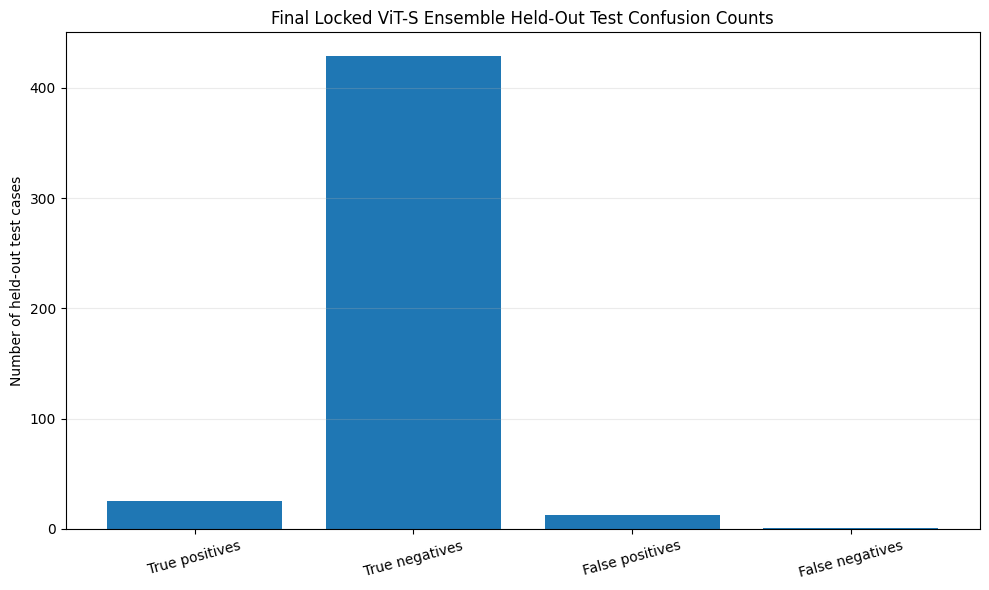

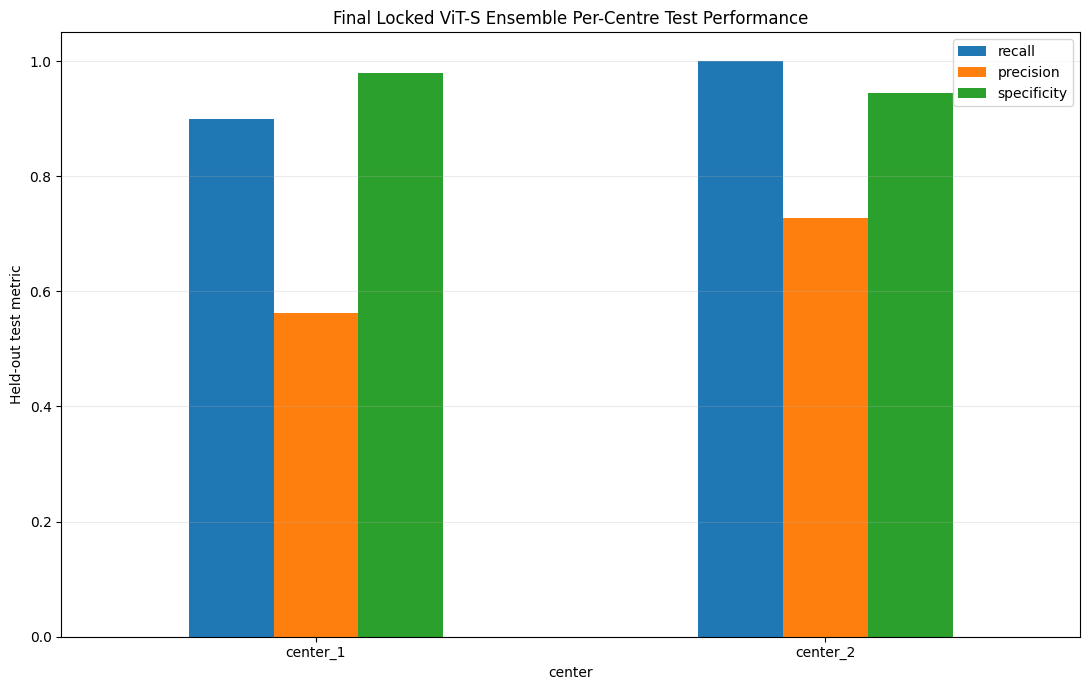

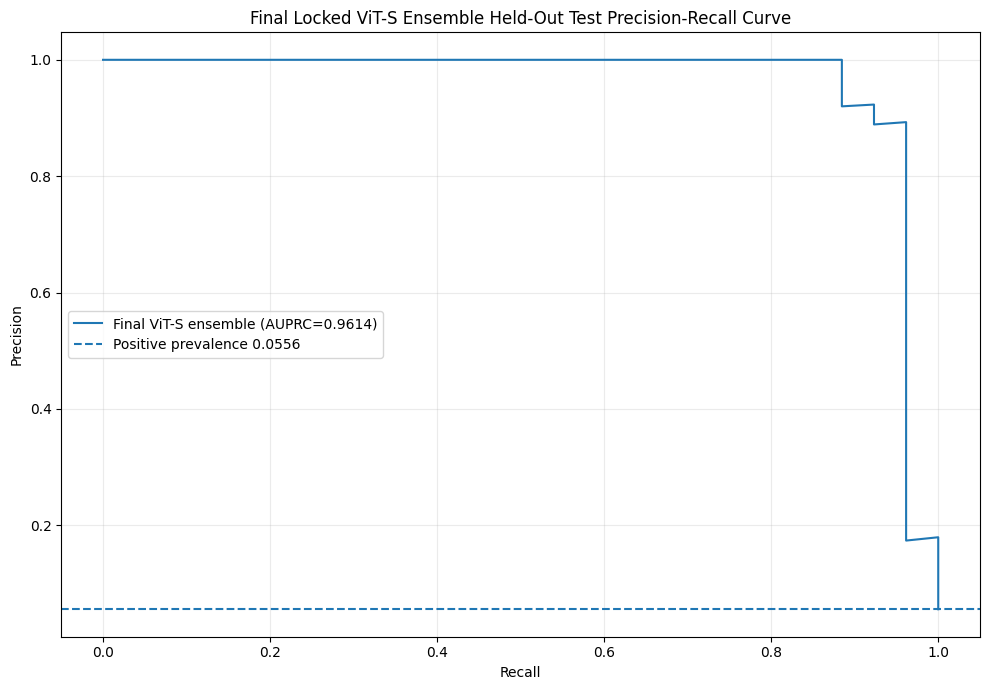

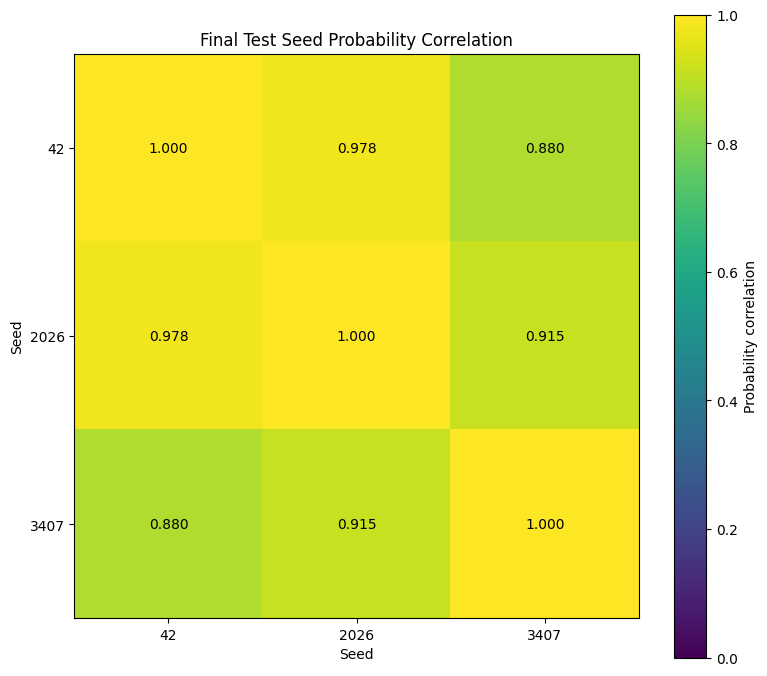

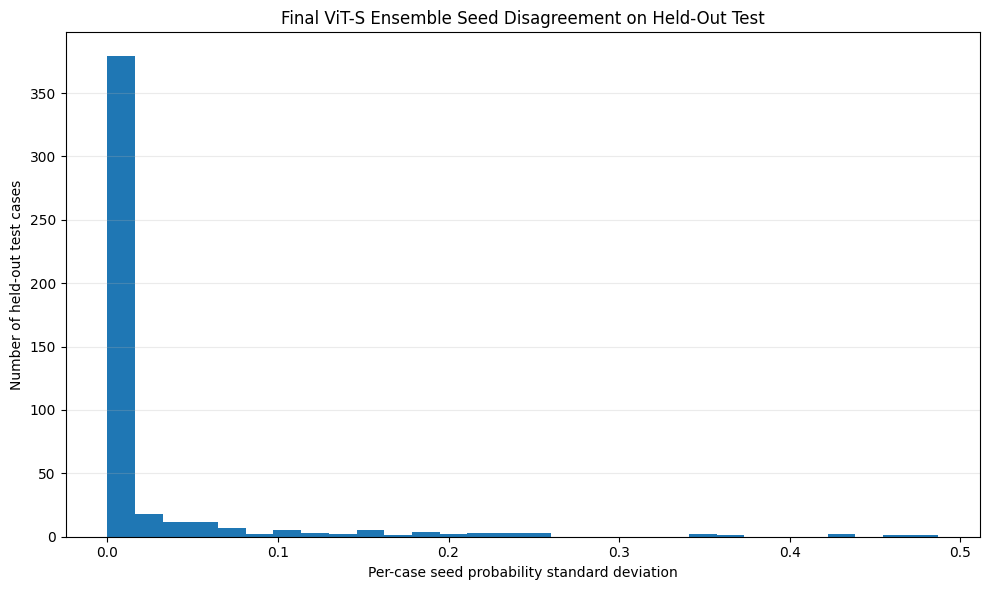

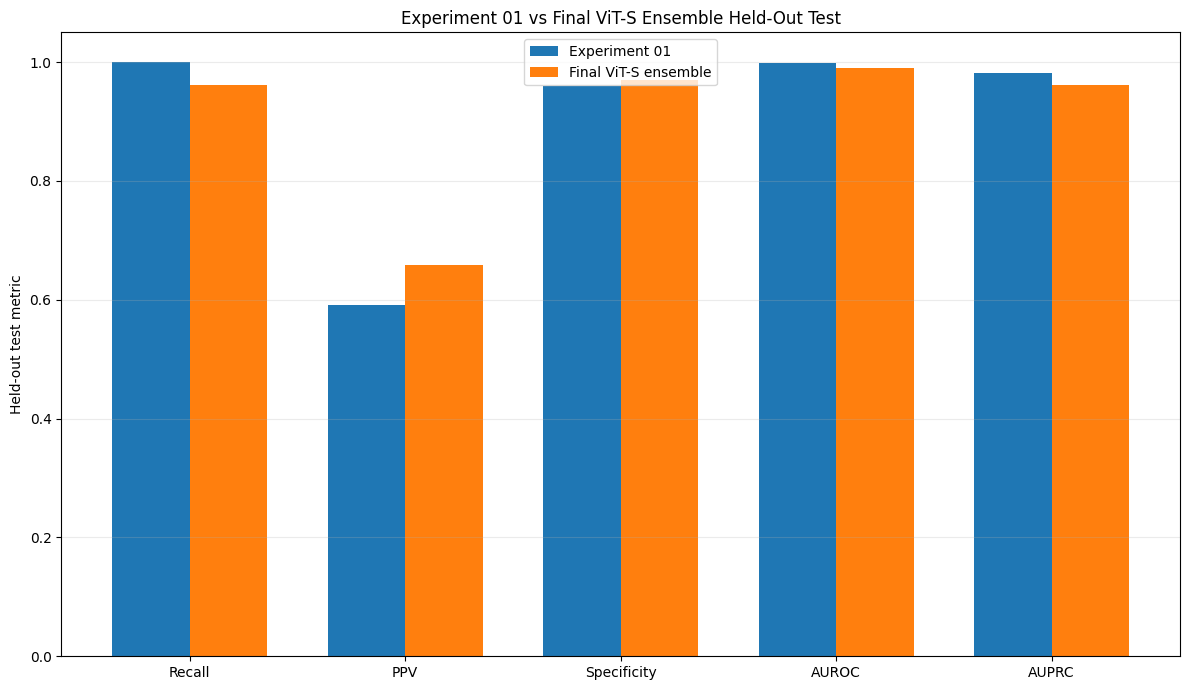

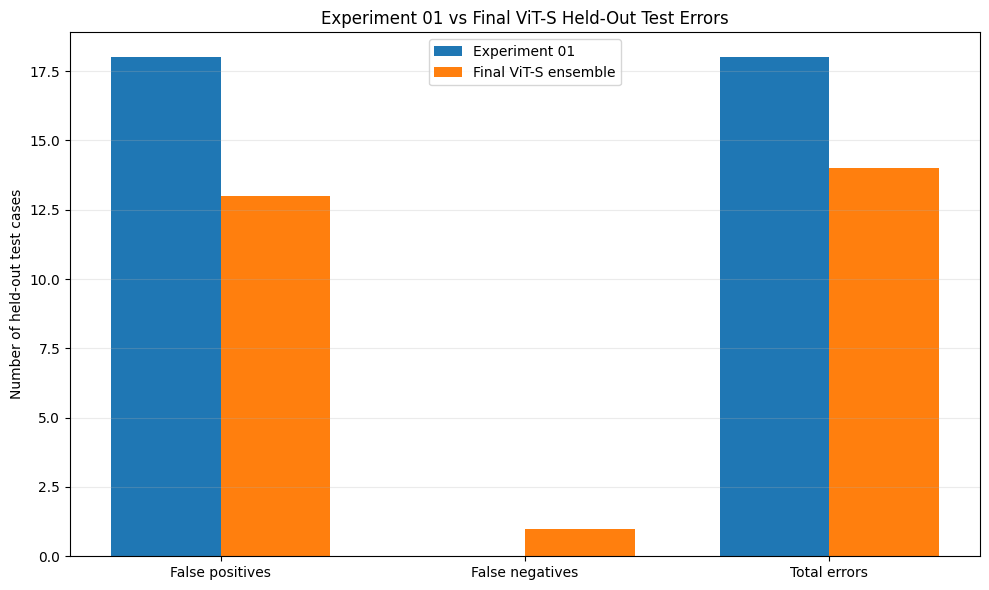


FINAL CELL 16G LOCKED ViT-S ENSEMBLE HELD-OUT TEST REPORT
Model:
ViT-S GastroNet-5M DINOv1 equal-weight three-seed ensemble

Component seeds:
[42, 2026, 3407]

Weight per seed:
0.333333

Locked threshold:
0.237948679207

Threshold source:
Cell 16F original-validation-only ensemble lock

Held-out test cases:
Total: 468
Normal: 442
Neoplasia: 26

Final locked ViT-S held-out test:
Recall: 0.961538
PPV: 0.657895
Specificity: 0.970588
NPV: 0.997674
Accuracy: 0.970085
Balanced accuracy: 0.966063
F1: 0.781250
AUROC: 0.989210
AUPRC: 0.961356
Minimum centre recall: 0.900000
TP=25 | TN=429 | FP=13 | FN=1
Total errors: 14

Experiment 01 held-out test:
Recall: 1.000000
PPV: 0.590909
Specificity: 0.959276
AUROC: 0.998695
AUPRC: 0.981158
TP=26 | TN=424 | FP=18 | FN=0
Total errors: 18

Final ViT-S minus Experiment 01:
Recall change: -0.038462
PPV change: +0.066986
Specificity change: +0.011312
AUROC change: -0.009485
AUPRC change: -0.019802
False-positive reduction: +5
False-negative reduction: -1
T

In [4]:
# ================================================================================================================
# CELL 16G HOTFIX
# NORMALIZE CELL 16B "backbone." CHECKPOINT PREFIX AND RESUME FINAL TEST
#
# Reason:
# Seed 42 was saved from a wrapper model whose backbone parameters use
# keys such as "backbone.cls_token". Seeds 2026 and 3407 use ordinary
# timm keys such as "cls_token". This fix supports both formats.
#
# This does NOT:
# - train any model
# - change any weights
# - select a checkpoint
# - search a test threshold
# - change the locked ensemble
# ================================================================================================================

import gc
import torch
import timm


def normalize_saved_model_state(
    state_dictionary,
):

    normalized_dictionary = {}

    for original_key, tensor_value in state_dictionary.items():

        normalized_key = str(
            original_key
        )

        # Remove common outer wrapper prefixes.
        prefix_removed = True

        while prefix_removed:

            prefix_removed = False

            for removable_prefix in [
                "module.",
                "model.",
            ]:

                if normalized_key.startswith(
                    removable_prefix
                ):

                    normalized_key = normalized_key[
                        len(
                            removable_prefix
                        ):
                    ]

                    prefix_removed = True

        # Cell 16B seed 42 used a wrapper:
        # backbone.cls_token -> cls_token
        # backbone.blocks... -> blocks...
        if normalized_key.startswith(
            "backbone."
        ):

            normalized_key = normalized_key[
                len(
                    "backbone."
                ):
            ]

        # Support alternative binary-head names without
        # changing any saved tensor values.
        if normalized_key.startswith(
            "classifier."
        ):

            normalized_key = (
                "head."
                + normalized_key[
                    len(
                        "classifier."
                    ):
                ]
            )

        elif normalized_key.startswith(
            "fc."
        ):

            normalized_key = (
                "head."
                + normalized_key[
                    len(
                        "fc."
                    ):
                ]
            )

        if normalized_key in normalized_dictionary:

            existing_tensor = normalized_dictionary[
                normalized_key
            ]

            if (
                tuple(
                    existing_tensor.shape
                )
                != tuple(
                    tensor_value.shape
                )
            ):

                raise RuntimeError(
                    "Checkpoint normalization produced conflicting "
                    f"tensors for key: {normalized_key}"
                )

        normalized_dictionary[
            normalized_key
        ] = tensor_value

    return normalized_dictionary


def load_locked_vits_model(
    checkpoint_path,
    device,
):

    model = timm.create_model(
        "vit_small_patch16_224",
        pretrained=False,
        num_classes=1,
    )

    checkpoint_object = load_torch_checkpoint(
        checkpoint_path
    )

    state_dictionary = extract_saved_model_state(
        checkpoint_object
    )

    state_dictionary = normalize_saved_model_state(
        state_dictionary
    )

    model_state_dictionary = model.state_dict()

    shape_mismatches = []

    for key, tensor_value in state_dictionary.items():

        if key in model_state_dictionary:

            if tuple(
                tensor_value.shape
            ) != tuple(
                model_state_dictionary[
                    key
                ].shape
            ):

                shape_mismatches.append(
                    {
                        "key": key,
                        "checkpoint_shape": tuple(
                            tensor_value.shape
                        ),
                        "model_shape": tuple(
                            model_state_dictionary[
                                key
                            ].shape
                        ),
                    }
                )

    if shape_mismatches:

        raise RuntimeError(
            "The saved checkpoint contains tensor-shape "
            "mismatches after key normalization.\n"
            f"Examples: {shape_mismatches[:10]}"
        )

    incompatible = model.load_state_dict(
        state_dictionary,
        strict=False,
    )

    missing_keys = list(
        incompatible.missing_keys
    )

    unexpected_keys = list(
        incompatible.unexpected_keys
    )

    if missing_keys or unexpected_keys:

        print(
            "\nCheckpoint path:"
        )

        print(
            checkpoint_path
        )

        print(
            "\nNormalized checkpoint key examples:"
        )

        print(
            list(
                state_dictionary.keys()
            )[:20]
        )

        raise RuntimeError(
            "Saved ViT checkpoint remains incompatible "
            "after robust prefix normalization.\n"
            f"Missing keys ({len(missing_keys)}): "
            f"{missing_keys[:30]}\n"
            f"Unexpected keys ({len(unexpected_keys)}): "
            f"{unexpected_keys[:30]}"
        )

    model = model.to(
        device
    )

    model.eval()

    for parameter in model.parameters():

        parameter.requires_grad = False

    print(
        "\nCheckpoint compatibility verified:"
    )

    print(
        checkpoint_path
    )

    print(
        f"Loaded tensors: "
        f"{len(state_dictionary)}/"
        f"{len(model_state_dictionary)}"
    )

    return model


# Clear memory left from the failed loading attempt.
gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()


print("=" * 120)

print(
    "CELL 16G CHECKPOINT-PREFIX HOTFIX APPLIED"
)

print("=" * 120)

print(
    "\nThe locked model, seeds, weights and threshold "
    "remain completely unchanged."
)

print(
    "Restarting Cell 16G final locked evaluation now..."
)

# Resume the original Cell 16G workflow.
# Any correctly completed seed-inference file will be reused.
main()